ó<óiómógó ósórócó=óhótótópó:ó/ó/ówówówó.óaócóoófóió.óeódóuó.ócóoó/óeóióeóió2ó0ó1ó6ó/ówópó-ócóoónótóeónótó/óuópólóoóaódósó/ó2ó0ó1ó6ó/ó0ó9ó/óLóoógóoó-óUónóióvóeórósóiódóaódó-óIóCóEóSóIó.ójópógó ówóiódótóhó=ó"ó3ó0ó0ó0ó"ó óhóeóiógóhótó=ó"ó5ó0ó0ó"ó óaólóiógónó=ó"ócóeónótóeóró"ó>ó
ó
ó#ó*ó*ó<óbóiógó>ó<óbóiógó>óSóiósótóeómóaósó óyó óCóoómóuónóiócóaócóióoónóeósó óIó<ó/óbóiógó>ó<ó/óbóiógó>ó<óbóró>ó<ósómóaólóló>óDóeópótóoó.ó óCóióeónócóióaósó óFóíósóiócóaósó ó&ó óEóxóaócótóaósó ó/ó óFóIóDóCóAó<ó/ósómóaólóló>ó<óbóró>ó<ósómóaólóló>ó_ó*óPóróoóyóeócótóoó óFóiónóaóló*ó_ó ó(óSóiósótóeómóaó ódóeó óMóoónóiótóoóróeóoó ódóeó óSóeónósóoóróeósó óIóoóTó óyó óAónóaólóíótóiócóaó ódóeóDóaótóoósó óAógóróoócólóiómóáótóiócóoósó)ó.ó ó<ó/ósómóaólóló>ó*ó*ó
ó
ó
ó#óIónótóeógóróaónótóeósó:ó
óJóoósóeó óDóaóvóiódó óRóoódóróiógóuóeózó ó-ó óAó0ó0ó4ó0ó7ó1ó5ó1ó

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. CARGA DEL DATASET
url = "https://docs.google.com/spreadsheets/d/19qVUpzmgD6SwpefaWN2RTipjNm-dNPXKSPUw-t35bDw/export?format=csv"
df = pd.read_csv(url)

# Limpieza básica de texto y estandarización
df.columns = df.columns.str.strip()
df['Crop_Type'] = df['Crop_Type'].astype(str).str.strip().str.title() # 🚀 Normaliza a título



# 2. LIMPIEZA DE DATOS

numeric_cols = [
    'Temperature', 'Rainfall', 'Humidity', 'Soil_pH',
    'Soil_Nitrogen', 'Soil_Organic_Matter'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')


df = df[
    (df['Temperature'].between(5, 40)) &
    (df['Humidity'].between(10, 100)) &
    (df['Rainfall'] > 50) &
    (df['Soil_pH'].between(4, 9) | df['Soil_pH'].isna()) &  # ← tolera NaN
    (df['Soil_Organic_Matter'] >= 0)
]


# 3. FILTRO POR CULTIVOS
df_coffee = df[df['Crop_Type'] == 'Coffee']
df_palm = df[df['Crop_Type'] == 'Oil Palm']

print("Registros café:", len(df_coffee))
print("Registros palma:", len(df_palm))

# 4. INFO GENERAL
print("\nINFO DATASET LIMPIO")
print(df.info())

print("\nDESCRIPTIVOS GENERALES")
print(df.describe())

# 5. FUNCIÓN ROBUSTA
def analizar_variable(df, variable, opt_min, opt_max, crit_min, crit_max=None):

    data = df[variable].dropna()
    total = len(data)

    # Cuando detecte un dataset vacio
    if total == 0:
        return {
            'Media': np.nan,
            'Std': np.nan,
            '% Óptimo': np.nan,
            '% Crítico Bajo': np.nan,
            '% Crítico Alto': np.nan
        }

    dentro_optimo = ((data >= opt_min) & (data <= opt_max)).sum()
    bajo_critico = (data < crit_min).sum()
    alto_critico = (data > crit_max).sum() if crit_max is not None else 0

    return {
        'Media': round(data.mean(), 2),
        'Std': round(data.std(), 2),
        '% Óptimo': round(dentro_optimo / total * 100, 2),
        '% Crítico Bajo': round(bajo_critico / total * 100, 2),
        '% Crítico Alto': round(alto_critico / total * 100, 2)
    }

# 6. ANÁLISIS CAFÉ
if len(df_coffee) > 0:

    print("\nCAFÉ - DESCRIPTIVOS")
    print(df_coffee[['Temperature','Humidity','Rainfall','Soil_pH']].describe())

    coffee_stats = {
        'Temperature': analizar_variable(df_coffee, 'Temperature', 18, 22, 15, 25),
        'Humidity': analizar_variable(df_coffee, 'Humidity', 70, 80, 60, 85),
        'Rainfall': analizar_variable(df_coffee, 'Rainfall', 1700, 2300, 1000, 2800),
        'Soil_pH': analizar_variable(df_coffee, 'Soil_pH', 5.0, 5.5, 4.5, 6.0)
    }

    df_coffee_stats = pd.DataFrame(coffee_stats).T

    print("\nCAFÉ - ANÁLISIS AGRONÓMICO")
    print(df_coffee_stats)



if 'Compatible' in df_coffee.columns:
    tasa = df_coffee['Compatible'].value_counts(normalize=True) * 100
    print(f"\nCompatibilidad Café:\n{tasa.round(1)}")

# 7. ANÁLISIS PALMA
if len(df_palm) > 0:

    print("\nPALMA - DESCRIPTIVOS")
    print(df_palm[['Temperature','Humidity','Rainfall']].describe())

    palm_stats = {
        # Cambia estas líneas en el paso 7:
        'Temperature': analizar_variable(df_palm, 'Temperature', 24, 30, 21, 35),
        'Rainfall': analizar_variable(df_palm, 'Rainfall', 1800, 3500, 1500, None),
        'Humidity': analizar_variable(df_palm, 'Humidity', 75, 100, 65, None),
        'Soil_pH': analizar_variable(df_palm, 'Soil_pH', 4.5, 6.0, 4.0, 7.0)

    }

    df_palm_stats = pd.DataFrame(palm_stats).T

    print("\nPALMA - ANÁLISIS AGRONÓMICO")
    print(df_palm_stats)

else:
    print("\n No hay datos de palma después de la limpieza")

# Al final de la sección 7 (Palma)
if 'Compatible' in df_palm.columns:
    tasa = df_palm['Compatible'].value_counts(normalize=True) * 100
    print(f"\nCompatibilidad Palma:\n{tasa.round(1)}")

# 8. VISUALIZACIÓN CAFÉ
if len(df_coffee) > 0:

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    sns.histplot(df_coffee['Temperature'], kde=True, ax=axes[0, 0])
    axes[0, 0].set_title('Temperatura Café')

    sns.histplot(df_coffee['Humidity'], kde=True, ax=axes[0, 1])
    axes[0, 1].set_title('Humedad Café')

    sns.histplot(df_coffee['Rainfall'], kde=True, ax=axes[1, 0])
    axes[1, 0].set_title('Precipitación Café')

    sns.histplot(df_coffee['Soil_pH'], kde=True, ax=axes[1, 1])
    axes[1, 1].set_title('pH Café')

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6,4))
    sns.heatmap(df_coffee[['Temperature','Humidity','Rainfall','Soil_pH']].corr(),
                annot=True, cmap='coolwarm')
    plt.title("Correlación Café")
    plt.show()

# 9. VISUALIZACIÓN PALMA
if len(df_palm) > 0:

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    sns.histplot(df_palm['Temperature'], kde=True, ax=axes[0])
    axes[0].set_title('Temperatura Palma')

    sns.histplot(df_palm['Humidity'], kde=True, ax=axes[1])
    axes[1].set_title('Humedad Palma')

    sns.histplot(df_palm['Rainfall'], kde=True, ax=axes[2])
    axes[2].set_title('Precipitación Palma')

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6,4))
    sns.heatmap(df_palm[['Temperature','Humidity','Rainfall']].corr(),
                annot=True, cmap='coolwarm')
    plt.title("Correlación Palma")
    plt.show()

# 10. BOXPLOTS
if len(df_coffee) > 0 and len(df_palm) > 0:

    fig, axes = plt.subplots(1, 2, figsize=(10,4))

    df_coffee.boxplot(column='Temperature', ax=axes[0])
    axes[0].set_title("Boxplot Temp Café")

    df_palm.boxplot(column='Temperature', ax=axes[1])
    axes[1].set_title("Boxplot Temp Palma")

    plt.tight_layout()
    plt.show()

# 11. VARIABLE vs COMPATIBILIDAD
if len(df_coffee) > 0:

    plt.figure(figsize=(6,4))
    sns.boxplot(x='Compatible', y='Temperature', data=df_coffee)
    plt.title("Temperatura vs Compatibilidad (Café)")
    plt.show()


ó
ó#ó#ó óRóeósóuólótóaódóoósó óyó óAónóáólóiósóiósó ódóeó ólóaó óSóiómóuólóaócóióóónó óAógóróoócólóiómóáótóiócóaó ó(óCóoónótóeóxótóoó óCóoólóoómóbóióaó)ó
óEóló ópóróeósóeónótóeó óaónóáólóiósóiósó óeóvóaólóúóaó ó1ó1ó,ó0ó6ó0ó óróeógóiósótóróoósó,ó óiónótóeógóróaónódóoó ódóaótóoósó óhóiósótóóóróiócóoósó ódóeó óKóaógógólóeó ócóoónó óuónóaó ósóiómóuólóaócóióóónó óaóvóaónózóaódóaó ódóeó ó1ó,ó0ó6ó0ó óróeógóiósótóróoósó ódóiósóeóñóaódóaó óeósópóeócóíófóiócóaómóeónótóeó ópóaóróaó óróeópóróeósóeónótóaóró ólóaósó ócóoónódóiócóióoónóeósó ódóeó óCóoólóoómóbóióaó.ó óSóeó ósóeólóeócócóióoónóaóróoónó ódóoósó ócóuólótóióvóoósó óeósótóróaótóéógóiócóoósó:ó óeóló óCóaófóéó,ó óróeópóróeósóeónótóaónódóoó ólóaó ózóoónóaó óaónódóiónóaó ódóeó ólóaódóeóróaó,ó óyó ólóaó óPóaólómóaó ódóeó óAócóeóiótóeó,ó óróeópóróeósóeónótóaónódóoó ólóaósó ólólóaónóuóróaósó ódóeóló ótóróóópóiócóoó óbóaójóoó.ó
ó#ó#ó ó1ó.ó óAónóáólóiósóiósó ódóeóló óCóuólótóióvóoó ódóeó óCóaófóéó ó(óRóeógóióóónó óAónódóiónóaó)ó
óPóaóróaó óeósótóaó ósóiómóuólóaócóióóónó ósóeó ótóoómóaóróoónó ócóoómóoó óróeófóeóróeónócóióaó ódóeópóaórótóaómóeónótóoósó ólóíódóeóróeósó ócóoómóoó óHóuóiólóaó,ó óAónótóióoóqóuóióaó óyó óeóló óEójóeó óCóaófóeótóeóróoó,ó ócóaóróaócótóeóróiózóaódóoósó ópóoóró ósóuóeólóoósó ódóeó óoóróiógóeónó óvóoólócóáónóiócóoó ó(óAónódóiósóoólóeósó)ó.ó
ó
ó*ó óCóoómópóaótóióbóiólóiódóaódó:ó óSóeó óoóbósóeóróvóaó óuónóaó ótóaósóaó ódóeó ócóoómópóaótóióbóiólóiódóaódó ódóeóló ó2ó.ó8ó%ó.ó óEósótóeó óvóaólóoóró,ó óaóuónóqóuóeó óbóaójóoó,ó óeósó óaólótóaómóeónótóeó óróeóaólóiósótóaó ópóaóróaó óeóló ócóaófóéó ódóeó óeósópóeócóióaólóiódóaódó ócóoólóoómóbóióaónóoó,ó ódóoónódóeó ólóaó ócóoóiónócóiódóeónócóióaó ósóiómóuólótóáónóeóaó ódóeó ócólóiómóaó ópóeórófóeócótóoó,ó ópóHó óáócóiódóoó ó(ó5ó.ó0ó–ó5ó.ó5ó)ó óyó ólólóuóvóióaósó ócóoónótóróoólóaódóaósó óeósó óeósócóaósóaó.ó
ó*ó óTóeómópóeóróaótóuóróaó:ó óLóaó ómóeódóióaó ódóeó ó2ó0ó.ó0ó3ó ó°óCó óeósó óiódóeóaóló ópóaóróaó óvóaóróióeódóaódóeósó ódóeó óCóoófófóeóaó óaóróaóbóiócóaó.ó óSóiónó óeómóbóaórógóoó,ó óeóló ó2ó.ó6ó4ó%ó ódóeó óróeógóiósótóróoósó óbóaójóoó óeóló óuómóbóróaóló ócóróíótóiócóoó óróeófólóeójóaó ófóiónócóaósó ósóiótóuóaódóaósó óaó óaólótóiótóuódóeósó óeóxócóeósóióvóaósó ó(ópóáóróaómóoósó)ó ódóoónódóeó óeóló ófóróíóoó ólóiómóiótóaó óeóló ódóeósóaóróróoólólóoó ódóeóló ófóróuótóoó.ó
ó*ó óPóróeócóiópóiótóaócóióóónó:ó óCóoónó óuónóaó ómóeódóióaó ódóeó ó2ó,ó0ó0ó9ó ómómó,ó ólóoósó ódóaótóoósó óróeófólóeójóaónó ófóióeólómóeónótóeó óeóló óróéógóiómóeónó ódóeó ólólóuóvóióaósó ódóeó ólóoósó óAónódóeósó ócóoólóoómóbóióaónóoósó.ó óEóló ó8ó4ó.ó5ó3ó%ó ódóeó óróeógóiósótóróoósó óeónó óróaónógóoó óóópótóiómóoó ódóeómóuóeósótóróaó óqóuóeó óeóló óaógóuóaó óeósó óeóló óróeócóuórósóoó ómóáósó óeósótóaóbólóeó óeónó óeósótóaósó ózóoónóaósó.ó
ó*ó ópóHó ódóeóló óSóuóeólóoó:ó óPóróeósóeónótóaó óuónóaó ómóeódóióaó ódóeó ó5ó.ó2ó4ó,ó ócóoónó óuónó ó5ó5ó.ó8ó5ó%ó ódóeó óéóxóiótóoó óóópótóiómóoó.ó óEósótóoó óvóaólóiódóaó ólóaó ósóiómóuólóaócóióóónó ódóeó ósóuóeólóoósó óáócóiódóoósó,ó ófóuónódóaómóeónótóaólóeósó ópóaóróaó ólóaó ódóiósópóoónóióbóiólóiódóaódó ódóeó ónóuótóróióeónótóeósó óeónó óeóló ócóaófóéó.ó
ó
ó#ó#ó ó2ó.ó óAónóáólóiósóiósó ódóeóló óCóuólótóióvóoó ódóeó óPóaólómóaó ódóeó óAócóeóiótóeó ó(óLólóaónóoósó óyó óMóaógódóaólóeónóaó óMóeódóióoó)ó
óLóaó ósóiómóuólóaócóióóónó ósóeó ócóeónótóróóó óeónó ólóaósó ózóoónóaósó óbóaójóaósó ódóeó óMóeótóaó,ó óCóaósóaónóaóróeó óyó óeóló óCóeósóaóró,ó óuótóiólóiózóaónódóoó ósóuóeólóoósó ótóiópóoó óOóxóiósóoóló óyó óUólótóiósóoóló,ó ótóíópóiócóoósó ódóeó ólóaósó ósóaóbóaónóaósó ótóróoópóiócóaólóeósó ócóoólóoómóbóióaónóaósó.ó
ó
ó*ó óCóoómópóaótóióbóiólóiódóaódó:ó óRóeógóiósótóróaó óuónó ó2ó4ó.ó9ó%ó,ó óiónódóiócóaónódóoó óuónóaó ómóaóyóoóró óróeósóiólóióeónócóióaó ódóeóló ócóuólótóióvóoó óaó ólóaósó óvóaóróióaócóióoónóeósó ócólóiómóáótóiócóaósó óeónó ócóoómópóaóróaócóióóónó ócóoónó óeóló ócóaófóéó.ó
ó*ó óTóeómópóeóróaótóuóróaó:ó óLóaó ómóeódóióaó ódóeó ó2ó7ó.ó4ó1ó ó°óCó ó(ócóoónó óuónó ó8ó5ó.ó6ó6ó%ó ódóeó óróeógóiósótóróoósó óóópótóiómóoósó)ó ósóiótóúóaó óeóló ócóuólótóióvóoó óeónó óeóló ócóoóróaózóóónó ótóéórómóiócóoó ódóeóló ótóróóópóiócóoó óbóaójóoó.ó óLóaó óaóuósóeónócóióaó ódóeó óaólóeórótóaósó ócóróíótóiócóaósó ópóoóró ófóróíóoó ócóoónófóiórómóaó óuónóaó ósóeólóeócócóióóónó ódóeó ózóoónóaó ógóeóoógóróáófóiócóaómóeónótóeó ócóoóhóeóróeónótóeó.ó
ó*ó óHóuómóeódóaódó óyó óLólóuóvóióaó:ó óPóróeósóeónótóaónó óuónó ódóeósóeómópóeóñóoó ósóuópóeóróióoóró,ó ócóoónó ómóeódóióaósó ódóeó ó8ó1ó.ó9ó1ó%ó óyó ó2ó,ó1ó0ó2ó ómómó óróeósópóeócótóióvóaómóeónótóeó.ó óEóló óhóeócóhóoó ódóeó óqóuóeó óeóló ó7ó6ó.ó6ó%ó ódóeó ólóaó ópóróeócóiópóiótóaócóióóónó ósóeóaó óóópótóiómóaó óróeófólóeójóaó ólóaósó ócóoónódóiócóióoónóeósó ódóeó óaólótóaó ópóróoódóuócótóióvóiódóaódó ódóeóló óMóaógódóaólóeónóaó óMóeódóióoó óyó ólóoósó óLólóaónóoósó óOóróióeónótóaólóeósó.ó
ó*ó óSóuóeólóoó óyó ópóHó:ó óSóeó ólóoógóróóó óuónóaó ómóeódóióaó ódóeó ó4ó.ó9ó8ó,ó ócóoónó óuónó óiómópóróeósóióoónóaónótóeó ó8ó7ó.ó7ó4ó%ó ódóeó óróeógóiósótóróoósó óóópótóiómóoósó.ó óEósótóoó óeósó ócólóaóvóeó,ó óyóaó óqóuóeó ólóaó óPóaólómóaó ódóeó óAócóeóiótóeó óeónó óCóoólóoómóbóióaó ósóeó óhóaó óaódóaópótóaódóoó óeóxóiótóoósóaómóeónótóeó óaó ólóoósó ósóuóeólóoósó óáócóiódóoósó ódóeó ólóaó óOóróiónóoóqóuóíóaó,ó ódóoónódóeó óoótóróoósó ócóuólótóióvóoósó ófóróaócóaósóaóróíóaónó.ó
ó
ó#ó#ó ó3ó.ó óCóoónócólóuósóióóónó óTóróaónósóvóeórósóaóló
óLóaó óiónótóeógóróaócóióóónó ódóeó ódóaótóoósó ómóuóeósótóróaó óuónóaó ósóeópóaóróaócóióóónó ócólóaóróaó ódóeó ónóiócóhóoósó óeócóoólóóógóiócóoósó:ó ómóióeónótóróaósó óeóló ócóaófóéó ósóeó óróeósótóróiónógóeó óaó ónóiócóhóoósó ótóéórómóiócóoósó ódóeó ómóoónótóaóñóaó ó(ómóeódóióaó ódóeó ó2ó0ó°óCó)ó,ó ólóaó ópóaólómóaó ódóoómóiónóaó ólóaósó ólólóaónóuóróaósó ócóáólóiódóaósó ó(ómóeódóióaó ódóeó ó2ó7ó°óCó)ó.ó óLóaó óbóaójóaó ótóaósóaó ódóeó ócóoómópóaótóióbóiólóiódóaódó ógóeónóeóróaóló ó(ó7ó.ó7ó%ó óeónó ótóoódóoó óeóló ódóaótóaósóeótó)ó óróeósóaólótóaó ólóaó óiómópóoórótóaónócóióaó ódóeó ólóaó óaógóróiócóuólótóuóróaó ódóeó ópóróeócóiósóióóónó,ó ósóuógóióróióeónódóoó óqóuóeó ósóoólóoó óuónóaó ófóróaócócóióóónó ódóeóló ótóeóróróiótóoóróióoó ócóuómópólóeó ócóoónó ótóoódóaósó ólóaósó óvóaóróióaóbólóeósó ónóeócóeósóaóróióaósó ópóaóróaó óaólócóaónózóaóró óróeónódóiómóióeónótóoósó ómóáóxóiómóoósó ósóiónó óiónótóeóróvóeónócóióóónó ótóeócónóoólóóógóiócóaó ó(ócóoómóoó óróióeógóoó óoó óeónómóióeónódóaósó ódóeó ósóuóeólóoó)ó.ó
ó
ó
ó

ó#ó#óFóAóSóEó ó2ó ó ó-ó óSóiómóuólóaócóióóónó ódóeó ósóeónósóoóróeósó óaógóróíócóoólóaósó óuótóiólóiózóaónódóoó óeóló ópóróoótóoócóoólóoó óMóQóTóTó óyó óuónó óGóaótóeówóaóyó óIóoóTó
ó
ó

In [ ]:
# Instalar librerías (solo en Google Colab)
!pip install paho-mqtt pandas numpy

import pandas as pd
import numpy as np
import json
import time

from datetime import datetime

import paho.mqtt.client as mqtt

# Reproducibilidad
np.random.seed(42)

# Cargar dataset desde Google Sheets
sheet_id = "19qVUpzmgD6SwpefaWN2RTipjNm-dNPXKSPUw-t35bDw"

csv_url = (
    f"https://docs.google.com/spreadsheets/d/"
    f"{sheet_id}/export?format=csv"
)

df = pd.read_csv(csv_url)

print("\nDATASET CARGADO\n")

print(df.head())

print("\nDIMENSIONES:")
print(df.shape)

print("\nTOTAL REGISTROS:")
print(len(df))

# Normalizar nombres de cultivos
df["Crop_Type"] = df["Crop_Type"].str.lower()

# Filtrar solo cultivos requeridos
df = df[
    df["Crop_Type"].isin([
        "coffee",
        "oil palm"
    ])
]

print("\nCULTIVOS:")
print(df["Crop_Type"].value_counts())

# Seleccionar variables principales
sensor_df = df[[

    "Crop_Type",

    "Temperature",

    "Humidity",

    "Rainfall",

    "Soil_pH",

    "Compatible"

]]

print("\nVARIABLES SELECCIONADAS\n")

print(sensor_df.head())

# Configuración MQTT
broker = "broker.emqx.io"

port = 1883

client = mqtt.Client(
    mqtt.CallbackAPIVersion.VERSION2
)

print("\nCONECTANDO MQTT...\n")

try:

    client.connect(broker, port)

    client.loop_start()

    print("CONECTADO AL BROKER MQTT")

except Exception as e:

    print(f"ERROR MQTT: {e}")

# Parcelas agrícolas
PARCELAS = [

   {
        "id": "parcela_cafe_1",
        "crop": "coffee"
    },

    {
        "id": "parcela_cafe_2",
        "crop": "coffee"
    },


    {
        "id": "parcela_cafe_3",
        "crop": "coffee"
    },


    {
        "id": "parcela_cafe_4",
        "crop": "coffee"
    },

    {
        "id": "parcela_palma_1",
        "crop": "oil palm"
    },


    {
        "id": "parcela_palma_3",
        "crop": "oil palm"
    },


    {
        "id": "parcela_palma_4",
        "crop": "oil palm"
    },

    {
        "id": "parcela_palma_2",
        "crop": "oil palm"
    }


]

# Lista para almacenar datos simulados
simulated_data = []

# Genera una lectura simulada de sensores
def sensor_simulator(row, parcela):

    noise = np.random.normal(0, 0.3)

    sensor_data = {

        "timestamp": datetime.now().isoformat(),

        "parcela": parcela["id"],

        "crop_type": parcela["crop"],

        "temperature_air": round(
            row["Temperature"] + noise,
            2
        ),

        "humidity": round(
            row["Humidity"] + noise,
            2
        ),

        "precipitation": round(
            row["Rainfall"] + noise,
            2
        ),

        "soil_ph": round(
            row["Soil_pH"] + noise,
            2
        ),

        "compatible": row["Compatible"]
    }

    return sensor_data

print("\nINICIANDO SIMULACIÓN IoT\n")

# Leer dataset fila por fila
for index, row in sensor_df.iterrows():

    # Tiempo inicial del ciclo completo
    start_time = time.time()

    # Recorrer parcelas
    for parcela in PARCELAS:

        # Verificar cultivo correspondiente
        if row["Crop_Type"] != parcela["crop"]:
            continue

        # Generar datos del sensor
        sensor_data = sensor_simulator(
            row,
            parcela
        )

        # Topic MQTT
        topic = (
            f"agricultura/"
            f"{parcela['crop'].replace(' ', '_')}/"
            f"{parcela['id']}"
        )

        # Convertir mensaje a JSON
        payload_json = json.dumps(sensor_data)

        # Publicar mensaje MQTT
        result = client.publish(
            topic,
            payload_json
        )

        status = result[0]

        if status == 0:

            print(f"\nTOPIC: {topic}")
            print(payload_json)

        else:

            print(
                f"ERROR PUBLICANDO EN {topic}"
            )

        # Guardar datos generados
        simulated_data.append(sensor_data)

    # Calcular tiempo consumido
    elapsed_time = time.time() - start_time

    # Mantener frecuencia de 1 segundo por lote
    sleep_time = max(0, 1 - elapsed_time)

    time.sleep(sleep_time)

# Generar dataset IoT final
simulated_df = pd.DataFrame(simulated_data)

simulated_df.to_csv(
    "iot_sensor_data.csv",
    index=False
)

print("\nDATASET GENERADO:")
print("iot_sensor_data.csv")

print("\nTOTAL MENSAJES:")
print(len(simulated_df))

# Finalizar conexión MQTT
client.loop_stop()

client.disconnect()

print("\nSIMULACIÓN FINALIZADA")

# Configuración básica para Node-RED
print("\nCONFIGURACIÓN NODE-RED\n")

print("Broker:")
print("broker.emqx.io")

print("\nPuerto:")
print("1883")

print("\nTopic:")
print("agricultura/#")

ó#ó#óFóAóSóEó ó3ó
ó
óFólóuójóoó óiómópólóeómóeónótóaódóoó óeónó óeóló ónóoódóeó-óróeódó:ó
ó!ó[óiómóaógóeó.ópónógó]ó(ódóaótóaó:óiómóaógóeó/ópónógó;óbóaósóeó6ó4ó,óióVóBóOóRówó0óKóGógóoóAóAóAóAóNóSóUóhóEóUógóAóAóBóKógóAóAóAóHóEóCóAóYóAóAóAóAódó0óxóKójóAóAóAóAóAóXóNóSóRó0óIóAórósó4ócó6óQóAóAóAóAóRónóQóUó1óBóAóAóCóxójówóvó8óYóQóUóAóAóAóAóJócóEóhóZócówóAóAóDósóMóAóAóAó7óDóAócódóvóqóGóQóAóAóHó9óLóSóUóRóBóVóHóhóeó7ófó1ó3ódóFózóXófóeó9ó/ófó6óaóhóFó4óIóoóJóAóoóJógóCóTóYóGó0óBóQóióoópóVóróWóLóZókóhóXóZójókó1óJódólóxóióXóSódóOórópóSó7óbóDómó+óTónó6ó2ónó5óuóyóJóGócólóUóhóIólójóhó0ónótótóVócóFófóVóGó0óZóIócókóbóJóEóAóCóxóióBówótóAóoóhóGó9ódó8ówó8ófó8óxógóMóOóeógóbóYóAóDóDóMóró7ótódóaósópóbóPóPónóvókóMóBójówóUó+óMóVó3ó7ó+óPówó+óXówó+óhóVólóLóSó4ósókóKóSóUólóxóXó4óqóbóMógówóRó4óYó5óMósóyóRóYóYó4óMócó2óSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDóXóDógózó2ótóvóbóJóUólóOó+ówókóAóAóAóAóAóAóAóBógóNólóGógóAógóAóAóAóAóAóAóQóEóRóRóoóAóIóAóAóAóAóAóAóEóBóEóUóaóAóCóAóAóAóAóAóAóBóAóRóFóGógóAógóAóAóAóAóAóAóQóEóRóRóoóAóIóAóAóAóAóAóAóEóBóEóUóaóAóCóAóAóAóAóAóAóBóAóRóFóGógóAógóAóAóAóAóAóAóQóEóRóRóoóAóIóAóAóAóAóAóAóEóBóEóUóaóAóCóAóAóAóAóAóAóBóAóRóFóGógóAógóAóAóAóAóAóAóQóEóRóRóoóAóIóAóAóAóAóAóAóEóBóEóUóaóAóCóAóAóAóAóAóAóBóAóRóFóGógóAógóAóAóAóAóAóAóQóEóQó5ómópóuóbófófóZóBóAóAóAóAóAóAóAóAóYóKóaó5óXóCó6óJóDóióoóAóAóAóAóAóAóAóBóEómósóPónó8ó4óWó9ógó6óqólópóUóWóSólóJóKóSóYójó8óVóNómóSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBónómóyóDóBóHóhójókóyózóJóFóhóLópówóZó7óeó3ótóEóhó1óUóAóAóAóAóAóAóAóAóióDóQóKóVóAóAóAóAóAóAóAóAóIógóoóCólóQóAóAóAóAóAóAóAóCóIóKóAópóUóAóAóAóAóAóAóAóAóióCógóKóVóAóAóAóAóAóAóAóAóIógóoóCólóQóAóAóAóAóAóAóAóCóIóKóAópóUóAóAóAóAóAóAóAóAóióCógóKóVóAóAóAóAóAóAóAóAóIógóoóCólóQóAóAóAóAóAóAóAóCóIóKóAópóUóAóAóAóAóAóAóAóAóióCógóKóVóAóAóAóAóAóAóAóAóIógóoóCólóQóAóAóAóAóAóAóAóCóIóKóAópóUóAóAóAóAóAóAóAóAóióCógóKóVóAóAóAóAóAóAóAóAóIógóoóCólóQóAóAóAóAóAóAóAóCóIóKóAópóUóAóAóAóAóAóAóAóAóióCógóKóVóAóAóAóAóAóAóAóAóIógóoóCólóQóAóAóAóAóAóAóAóCóIóKóAópóUóAóAóAóAóAóAóAóAóióCógóKóVóAóAóAóAóAóAóAóAóIógóoóCólóQóAóAóAóAóAóAóAóCóIóKóAópóUóAóAóAóAóAóAóAóAóióCóhóHócó3óOózózózó4óIóAóAóAóAóAóAóAóAózóDóSóXóyóyóXóRóQóQóUóAóAóAóAóAóAóIóBóIócó/óhó8óvóróBó3óUóLóWó0ótóEóióSóUólóJóSó7óKófóCóhógóxózóZóJógójówóxówóZó5ósógówóRó4óYó5óMósóyóRóYóYó4óMócó2óSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMóhóTóOójóvóbó1ódóoóoóMóKóAóAóAóAóAóAóAóAókóUóaóBóCógóAóAóAóAóAóAóAóBóFóFógóQóoóAóAóAóAóAóAóAóAóRóRóYóEóKóAóAóAóAóAóAóAóAóEóUóWóBóCógóAóAóAóAóAóAóAóBóFóFógóQóoóAóAóAóAóAóAóAóAóRóRóYóEóKóAóAóAóAóAóAóAóAóEóUóWóBóCógóAóAóAóAóAóAóAóBóFóFógóQóoóAóAóAóAóAóAóAóAóRóRóYóEóKóAóAóAóAóAóAóAóAóEóUóWóBóCógóAóAóAóAóAóAóAóBóFóFógóQóoóAóAóAóAóAóAóAóAóRóRóYóEóKóAóAóAóAóAóAóAóAóEóUóWóBóCógóAóAóAóAóAóAóAóBóFóFógóQóoóAóAóAóAóAóAóAóAóRóRóYóEóKóAóAóAóAóAóAóAóAóEóUóWóBóCógóAóAóAóAóAóAóAóBóFóFógóQóoóAóAóAóAóAóAóAóAóRóRóYóEóKóAóAóAóAóAóAóAóAóEóUóWóBóCógóAóAóAóAóAóAóAóBóFóFógóQóoóAóAóAóAóAóAóAóAóRóRóYóEóKóAóAóAóAóAóAóAóAóEóeóVóoóbómó7ó2ó2óQócóBóAóAóAóAóAóAóCóAómóeóZóyóuóSóQó6óqóAóAóAóAóAóAóAóAóBóBópóDópó/óPóFó/óYóOóqópóaóWóFókólóSóSókóqóKó/óVóTóYókóGóGóOóDóHóNókómóCóPóDóHóBónómóyóDóBóHóhójókóyózóJóFóhójógóxózóZóJógójówóxówóZó5ósógówóRó4óaó5ócóGóaó0ótó7ódóLódóFóAóBóAóAóAóAóAóAóAógó0óióhóQóAóQóAóAóAóAóAóAóIóKóIóoóUóAóEóAóAóAóAóAóAóCóCóió2óIóNóqóAómóSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBónómóxósópóoóaóWólóRóSó0óuóLóBógóYóGóQómóZóOóXó1ódóXólóyóQópóPójó7óeófóiópósóyóDóAó3óHózóMó8óHóoó9óSóUólóJóGó/óTólóVóBóKó6óPócóCóNójótóOóEó9óqóCóhóQóTóYóAóMócó2óSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDóXóGójóGó+ófóPónótóbó9ókóvó5óoóaómó+óRówóOóeóQóIó0ó/óqóaó4óXó9óhóOóhózó2óMó+óFóDóhórónópóZóPóTó3ó9ó8óvóró9ócórópóNóPótóDóMóZó2óMóCóXókódókókó/óKóWóJóaóhóyó3óZóeópópóUóróVó8ó7ó6ó9óTóFóTóyóBóióNóAópóUóBóMósóyóRóYóYó4óMócó2óSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóPóDóGóRóUóVóFódóqó/ófó7ó/ó6óoóróvóVóGó9óWólóIódóeógófóSóoóWósóeó7óOóHóvóXó1ó9óCókóuóIódóZó+óaótóaó4óvóGó7óFó9óMócóróbóióhóRóVó1óxóxóhófóLóyó8óqóRóZóuójó7óIómóFówó4óMóyóhóQóGóSóDóDóHóBónómóyóDóBóHóhójókóyózóJóFóhójógóxózóZóJógójówóxówóZó5ósógówó1ó9óLóSóoósóróKóSóró3ó/ó/óvóvóqóiómó9óVónó6ófóHóPógóWóYóEówóWóqóYódóGóDósóUóróqóSó1óVóCóQóoóJócóLópócócóYóWóvóTóGómó2ó4óPóOóJówóOóJóSóYómóKóiósóróCóyótóXó7ó8ó+óbóEósóXóNóYóvóXóuóeóZóRóxónóCóBóyóqóxófóDówóAóAóAóAóCówóIóBówó8ódóFóDódó0óRó0óUópózóAóvó9óLóló7ó1óOóFóqóVófó9óAónózóZósó2óKóDó1ó6ó9ófóPó2óGóPóDóhógó3óBójóJóSóUóFóJó0ó5ócó0óZóPóPófóWóUójóhó4ó9óaónó9óbómóAóEóUóqóAóAóAóAóAóBógókóaóióqóqólóJó/ófó7ó9ó6óYózórótópó4óAó5óqózóeó6óUó3ó1ó9ó/ófóJó4óPóMóróPózó5ó+óVóxó6óZóNómó3óTóTóTóTódópó2ó7óZótó2órótó3órówó4ódóOómóRó/óWówógózóCólóQóAóAóAóAóAósóEógó0óNójóbóKóGózóUóoózódówóqóKóSóDó8óHóNóKóAóqó0ó+óNójóYó3ó2óMózóOóuóoóKóBóAóxócóXóFóeóuó+ó9ó9ó1óRófóXó2ó8ó/ójóTóCóióQóAóUóAóAóAóAóAóió8óTógó4óKóAóGóNóWóAófóBóuóaó8óIóQó1óqócóDóAóyómó/ónónó5ó+ócóróOózótóbóRó4ó4ócósóZó9óCóGóFóGógóAógóAóAóAóAóAóAó8ó1ó5ózócó7óNóKóSó0óvó1ó8óqósóvó6ó4óUóXónózódó+óvóPónóWóbó3óTómózóBónó7óyó1ómósóXóLólóSólóZóWóVó9ómóGóEóEóQóUóqóAóAóAóAóAóAóBówóSóTó5ó/ó6ó5óeónó9óNóió+ópósójó+óEópófókó5óMómóTó2óróNónójó8óqóróTóqólóhósóFóaóNóuómójó0óaóHóJócóVóFóXó7óeóRó0ó4ódóEóCó7ó3ó9óiótónópó6óxóbóxó6ówóZóMókóSóDóQówóMóqóKóuóróyó3ó4óKóYóUóKóBóCógóAóAóAóAóAóAóXóJóLócóZófólóTóeóióxóJóSóLóGó/óxóLóRóVóVólóbóqó8óOóHóDó6óoópóróVóVótócógó3óqójóuó9óQófó3óWóPó0ó6óIóvóqóUóXódósóuó5óoóTó6ótóTóUó1óaóhó3ó9óró5ójófó3ólóJókósóPóhó3ó7ójóNó6ó/óXóaóTóyóFóMóKóFóAóBóAóAóAóAóAóIóBóLó8ópóPóXó/ómóNóKójó4óOónóyó+ówóvóMóWó2óHóPózóiókónópógóOó9óUóWóNó3ófó1ókówóuófówóqójó2ó2óSóWó3ótóbóZóMóuó9ó8óPóMóoóEóAóFóAóAóAóAóAóAóAóuóSóUóXódó2óSókó9óWójótóbó7óCó8óxóLóYó2óNójóeórótó6óVóNóvódóLófó9ó1óJóTó5óHóFó7ó1óuóDótó1ó/ógóJó7óTóUóUóCóBóSóoóAóAóAóAóAóWóKóCóOóHózó+óuó5ó5ó9ó/óXókó8ó9ó9óZóSóeóeóuóoópóVóVóVóVóKóWóYówóTókósó7óMó7óWó0óMó1óNóLóuójóIóUó3óRó9ónófó9óró8ódóLópóMóvó3óró4ótózóoó1ópóbópóHótó0ó7ó9ó+óAóXó9ó6óqóVó6ó+ó4ómóIó6ó3ó7óvótó3órójóvóUósóvóuóióxó0óXóVó1ódócórójó9óxóaóVówóGóHóIóNóqóLóOózó0ózó6óMóWóUóCóBóCógóAóAóAóAóAóWóoóLófóeóeókótó7ó9ó+ó6óVóxó+óNóRódónóaó2ósóróOózótóWóróVóKóhóWósóWóaótó1óqó9ódópó3óeópó1óyóló2óeópó4óSóeóJóUóróoóCódó9ó+óQóJóHóSó3ódóQópóKóUóFóJóUó/ólóSóWómópó1óvóló5óaókópóZógóPóxóNóRó3óeó/ó9óVóió+ó/ó3óaóaókó1óKókóUóDó7ótó1ó6ósódólóqóróMóPózó5óLórótótó8ó4ópóUófóeó8ólóXó2óló5ógóWó/ó5ó5óQó/óvó2óhówósóHónósó4ó9ógótólóCógóAógóAóAóAóIóAóFó5óvójóxó4ózópó9ó+óróQóKóCówóuó1óeóvóVóqóZóWóZómójóvólóYóvóXóqó1óióoóqóKóFóNó0ófóOó8ó8ó7óqóbópóVódóbóxóNóyókóhóWókóvó3óUóRóJóróaó1óCópóNósóRóAó0ósó+ópóeóeókóEóvóvó9ó0ómóKóVólóLóUóuó1ónóJó9óBóSóqó/óPó1ó1óTóoóSóoóaó6óróaó7ófódóOóKóVóHó3óvóJó8ó+ó0ótógókóaóNóAóBóQóAóAóAóAóAóLóTóHóló5óuóbóKózósó5óWóYómóGógó/óNóUópóióYóqóJóyócónóIóUóOózóCó3óuóoójóGóFó1óióWó9ó7óDó/ó4óVó8óGó1ó6ónóWóeókónópóióQóqóWómólóróOó6óIó3óAónóFó8ó9ó/óIóJó+ó9óeóMózósópódóuó/óFó1óXó2óVóqó5ópóló7óvóBó+óeóOó7ókóLóqófóuó+ó3óYó4ówóHónómóNóZóHóhójó6óOóió/óoó/ódóMójó7ó+óPó9ó0óyóHóTóxóuóRó/ó7ójótóHókó7óUókóQó1óPóvóBókótóZóróSóuóvóTóVóbóró2óyódóGóvófó/óZóYóNó8óEófóbóJóHóOóDódóJóxó8óJóAógóQóoóAóAóAóAóAó5ógóCóXóyóyóWóXóyó2óUófónópóbóOózókó7óFóxóZóló3óBócóXóFóxócónópóCó0ó/ó2ózóKóróXó+ówó/óvó0óeóGóQómólóDóró2ó3óvó0óxókótóVóaótófóIóUóró3óuó9ó3ó6óróXó/ó3ówómóFópóHópókónó1óxó/óSóyóróUójóVó3ótógómóZóXóTóqóyóMóPóvó6óXóxówótóFóróvóWóOóYóFóuóróMó2ó5óWóhó5ócóEóxóSóSó4ófóaóJóaó1ócólóxóEó4óPóqóMó3óLóKó8ójónóXó/ómóBóbó2ó/óró0ó2ótókó3óVóDótóZózóRóGówó+ófó0óJóIóvó3ó6ó5óPóPólóiósólódóLóoóPóAóNóxóló6ó/óXóSókóWómóió8óqó+óCófópókójó3óBótókóoó6óFógówóIóVóAóAóAóAóAóEóTóIó4óOóCógóuóróuó7ó1ódóbóWópóvóbó2ódójóUó1óNóaómóióoókóLóló5óeóUó6ódóuóyóYóDóhó4ó8óqóPó3ó7ó9ó2óvóvó3óró1ó6ó8ó8ó0ó3ótóXóvó3óbóró3ó0ó0ókótó6ó8ócóUóXóJó3ózó0ó9ófóXóZóoóxóaóEóuópófó8óBóaóAóló1ó9ó6óoóTózó5ó4óuózó7ó5ó4óOó2ó6ó7ódópókótóRó6ótóHólómóqó1ó3óJóGó+ó9ó5óuókó5óSótóqówóNózóhóuóeópó/ópóióOóBóDóuóZó6ónóXó+óqóKóTó6óNóiónó4óeójódóqóaó4óaókó+ómópóVóBóeósónó/óuó6ósóUófótóUóNóYóUóWónórópó1ó6ójóló/óQóWózólóXóSóOóZóVó2ó+óSózóhó+ótónórówóbóKómóWó1óPóvózógóNóVóqóbócóqónó7óYómóVóoó8ó7óXóJóaónó2ó7óZóJózóNó4óuóvó1ó/ópóQó3ókógódómóhó6óOó5óuóZókótówóAóAóAóAóAóDóAógóMóPóhóGóPócóxózóOóvó1óqóróeó3óVózó0ó9óPócóFóHóbó2ó+óvóuóróuó7ógó+óPóDóxó/ó4óNónósóPóPó6óXóSóqóoóKóBóAómóZómóZó9ólóNójóqóqó2ótó1ócókózóJó9óWócóUóGósó/óNóXóeó0ónóNóEóbóPózóyómó1ókó2óXó6ó5óMófóDóXóQótóSóYóEólófó3ótó0óuóDó5óbóVózó9óYóJóLó3ó0ógótó4ó5ó6óvó9óvóaówódóSóvódó5ó/ó+óDó2ó1óXó3óuójóPónóyó5óvó5óAó1ó5óuóuódóLótóOóvónóqónóWóyórótóuó1ó2óVóróxójógóOóqóHóvópóBóbó3óTósóFóGó3ófóXó6ó1ó4ógóJózólógóyó/ódópóAó/ó8ó3óxóGóYóFó7óIómóXóGóNókó2ócóuókóBónóyódódóWó9ó9óFóuó1óXó3ómóNó1ójóaóVó6óVófóvóJóEó/ó6óXóróoó7óeó9óTóXó0ó6óeó4óhóFójó7óqóXóFódótó/ó1óGó+ó9óCóEóKóuóróOóqóaóLóuóróHó1ó4óXóAómó9óSó7óRó1óVóaóGóKóió4ósótó4ó+ófóOónóVóPópówóVóIó1óJódóRóYóxóqócóróqóió9óWóaóVóqómó2ózó9ó2óhó2óWó8óqó6ótóLóLó7ó/ó8ósómó6ó7ó7óTóbóFóxó8ódóbózóuóHóSóDóHóeóOó0ókóEóFóAóAóAóAóAóDóYóOóhó0óNóOópó1óMóuóló0ótóuótó1ósóeójó0ódóRóUóVóGóKóióoóqóSóxó+óNóRóXó1ó+ófóGóhóoóaóVóFó5óeórótóLóSóUóvó3ómóNó7ó/óRóióyó+ó+óqóFó/ó+ó8ópódó6ó6óqómónó9óMówózózó+óióVóVó1ó7óRóWó2ó+ó9ópófófóeóeó0ó+óHóDóhó1óSóeóXómó5óLólóyó4óoóMóbóGóRónóVó2ódósó5óYócóWóqóhó6ójó5óVóróVóYólóaó+óuóVóoócóWópóEóBónóJóSóhóróuóiólóKó1ó3ógónódófó+óróhóFó/óQóró2ó/óKó7ó4óQó6óoócóVó8óvóYóGóSófóKósóuóoó2óhótóGó9óróyóqóOó1ókótóKóVóuóbóLócóWópóEóKóFó7óYó0ó3óCónózófóJókósóAóJó+óbóuóoódóPóSóEóvó1óOóqó5óYóyóOóNóGóQóróJó8óXó/óPópódósóyóDóRó+óLó1óNóhó3ówóRó9ósógóeóbópóMóPóOó4ófóOóFó/óyóaóKóLóSó3ó+ófósóGóUólóIóló6óGóCó8óNóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBónómóyóDóAó3ónózóNó6óeó3óvóVó1ótóaómótóróYó2óNóTóYó2óqóqóOójóQóxó0ódóHóWópóróaó9óPóQó0óJóBó9ó+ópóyóyóEóDóuóoó6óióbópójóDóqó/ó6óXóJó9ó8ósóoóOófó1óeóUó5óbózóVócóJóeóTópóQóMóqó5óHózó3óeó7ó/óVóyó2ó9óLóWó7ó9ó8ójódóaómóBóLóqózóZóJósóXó6óLó5óKóuóuótó2óXóbóZómónóDómójó5óoóWóeóGóNó9ó4ó7ó2ótóqóRójó6óTóqó/óWóeózóqó+ó7óXóZóeótóqódófó7óDó5ó/óQókóió8óHólóhóJóOóYóDóoódóVóHónóLóVó9ómóHóJótóTóaó2óTóKólófóaójómóSógófóVóróló2ó7ójóGó4ó+óMóJó6óZó+óvósóqó1óHózóLóaóGó9óvóló+óiógóAógóAóAóAóAóBó/óMóeóróCóhóQósó6ócóOóCóAóXónóvótóNóTó3óxóxóBóPó6ó6óUó9ó/óqóuóeóeóeó0ó5óvóvófóWóWójóhówó5óoósóróKóSójóUó3óNó4óeólóOóBóUóXóFó6óeó0ótóDóSótóWóLóFóCó+ófónó5óWóródóuónóTóZósó2óKóAótóWó7óbóoó9ó3ó7óvó9ó/óSóhóDó3ó1óIóNó9óxówógó2ó6ó9ó9óVóbódócócócódó+ósóQónóPóqóHóPófóOóYózó+ótózónóPóqócóvófóeólóLóuóuó+ó+ó+óyóZó8óTóGóWóDó9óPómóuó+ó7ó0óTó/ónó2ópóQóvóZósóCótó2ójóyóvó7ówóLó8óEóLódóEóCóNóUóqó8ójóbó7ódóJóGófó6óOóoó+óDó+óUó7óaóuóoó7ópó9óxóyóbófó+óHówóKó8ó0óYóEóOósóCómó0óHóEó1ótóuóEóuóqóvófó0ózótóFóAó9ó9ófópóKópó0óPófóló3óhóZó9ó8óEófóbóLóHóVóIópóTóWóBówóoóUóAóEóAóAóAóBóYóVóAóYóGóBólóRóTóUó6óNóDóhówó7ópójóTófóeó0óNóNóPóPó6ó2ófó/óvóSónóeóuóWóVóVó7óRó/ó/ó3ó5óVóVólóaóqóuó3óvóqódó0óFózóOópó1óKóSóEóhóQóRókóaóGó8óvóLóyótóHóHójóRóhóUóXóFó+óuóaóaó6ó7óRóróbófóeóqóróvóuóuókóvó3ó3ónóuóvó7óróvóvóPótó1ó7ó7ó7ó2ó6ó6ó6ó6ó7ó9óJóGóPófóEóQó3ó3óXóSóTóróró3ó2óWóhóUóVóFóWónóLólóió3óaóuónóWóróNómózóYóoóDóVóró1ómójólóyópóVóaóvónóyó5óUólóNóTólóZóSóUópóJóióYóGóKóMó7ó/óSóUókóJóEózópóaó+ójóuó7ópóbóXócóeómóFótó5ómóUólóJóYósó2óeó5óQó5ó+ó9ó2óaóvóOófóTó4ó2óTóUójóKó1óMókóNóqófófóuóEó6ókóKóeóqó9óNóló/ómóVó+ówóbóvózó+óQótóPó1ósó3óQóuó3óXóqóxó4óFóNó2óIócóLóUóqóeóródóHó7ó4ótóQóPó8ónóVówóKó2ófógó8óTójókóbó/óBóuówó7ówótó5óbó6óPónóGóQójócóGóXóBó6óGó6óQóHó7óló4óYóWóNóIó4ó/óLókósóuóXóaó9ólógóeóWóIódóoóLóbócóBócówóhóKó/óCóZóBóhójógóxózóZóJógójówóxówóZó5ósógówóRó4óYó5óMósóyóRóYóYó4óMócó5óNólóDóAó4óOóqóqóaómóJóvóhóoóbóGóyó0óTó5ómóSó5óOóTókó4óGóPóJókóióXóBó/ó7ó7óUójóZóMónó+ózóqómó4óvójóxó4ó9óqó7ódó6ó8óKóCówósónóXóYó7óUó0ódóGóhósóróIóyódócóaó2óqóió/óKóvóKógó1ó+ówóLóLó1óuózóDókóqóTókówóJóIó8óaó9óHóKóKómóRó5óYóMósóZóvófóHóDóaóiómójózóVó+óoóCóhóWó6óoóXólógówó3óKóróZóCó3óJóaóFóNóróeósójómó6ósóMóbórótótómóSóróbóXómó8ówólóbó5óAó+ójósóDóXóuó9óJógóeóZó+ómóuócóRóvósóWóyóSózóhóIó/óvó3óBómóDóCó/óxóoó0óAó1óAóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBónómóxósópóoóaóWólóRóSó0óuóLóBógóYóGóQómóZóOóXó1ódóXólóyóRódó8ójó/óqóJókóKóGóOóTóLóGó5óvóFó4ólóJóKóSóMóuópóaóUóAóSóuówóXóBóbóKóBólótóbóWó1óyóOóBóxóKóSókóqóSóAónófóRóqó6ó6óuóVómó1ótóróeóróqó6ólóRóXóZó+ómólóMóeóJó2óuó5óWóRókóRóEósóPósóXóEóxóCógó5óOóVónóLólóió2ózóTówó2óbócóHó9óWóbó7ó3ó1ólókó6ófóPóqó3ósó7óOóxóxóló/óxó1ódó3óeóróqóqópóKófóVóEó9ó6óoózó1ó5ó8ó9ópótókóLóQóyórótóuó1ó8óqóTóYó+ózóZóZóCó8ósó2óeó7óUó5óyó9óióJóeójóqóBó9óeóró/ócódó7ódóDóhóQópóBópó9óFó7ó7óQóTóqójóhó1ó5óHó1óbóoóDóDóLóOó8ótóWóVóuó/óvóFó6ótóPó7óTóeóTóWó8óyóIó+ó/óLóvósó/óWóxóMóYóvóyóoóWóYóQóqóFósóOógóWóqóbó/ó/óhó3ó9óqóHóJóvóTó2óoóTó1ó6ó6ó+óAóeó+ó/óCó4óKóFóCóZómó2ó8óZóFóKógóMókóGóGóOóDóHóNókómóCóPóDóHóBónómóyóDóAóXómónóHó+ó/óHómóVólóeóxóXóTódó1óFóRóbókócócórótóHóbóqódó+óSóYóZó/óCójóFó8óOóaó/óXóKó5ófóTóqóaóióoóKóPóuópócóQó3ó/ópóBóNóyóBó/óiówóIó8óPócófóMówóYóGóPóSópódó2óBóIóyó9óLóTóVóLóiójóWóCótóXórópózó1óaó3óCómóLóJóSóMó7óuó5óuó1ódófóXóqó7óWó1óNóVóióQó6óuó/óvótó0ó+óbóUóFópóaómójóIóyóMópóSóeónóqó7ó0ó9óHóQótóXóbóróUócóró6ójóoó0óMó+ónóyó9óYóBóJósóJóMó/óFóZóHóTó9ó+óXóOóXóló5óeórósó7óJóQókó9ófóXó1óaócógó7óKóKó/óDófó6óFó4óHóUóPóqó8óXóTóOó8ócó6ópóeóWóqómóuóqóFómówóXóQóKóVóJóHóaóJóLó2óyósólóLó7óyó9ó5óXóUó5ógó2ó+óIó/óuójó1óWóqójówóLóVóZóMóKóZóQóYóHóKóAóBónómóyóDóBóHóhójókóyózóJóFóhójógóxózówóxókóVóFóRóVó6ó9ó9ó1ó3ótóWóaópótóDóbódópóZóTóYóyóGó1óhó2ódózóWópóYóTó4óaóKóUómóTó2ó9óvóDómóCó6ómóróuó9óOólóEó/ópóGóMóXóBó7óVózó5ó0ó7óló5óeóVóJósó3óQóNókójóGó2ó7óuó5óuóVóVódóXóqó6óaómóRótóXóVó1ócóEóCójóIónóEóxóEóQótóXó7ó4ó8óWóJóTóKóyóMóióQóYó5óKóKó5ókóxó9óHóaóFómóIó2óPó3ó7ótó0ó6óWóXóNóMónóbóFójóLókóbóDódóAóQó6ópó2óTópóqóBópóeójójójóWóXóQófónóvóuókóUóqóGóbóaóeóAóWóqóxósóZóGóvófónómómó2ópóJóvóióiófówó2ósó5óNóxó1óxóPóUónóKóSóVóqópó6ó6ó+ó7ówóTóJóOógócóoóqónóBónócóxóQó8óAóAóEóyóqósóróJóSó7ó7ó7ó7óróqó5ócó6ódóTólóKózó0óRóLóUó4óBókóbóQó0ózóqókóró8ózóyó6ófókó1óUócóBóNótózóLó6óGóhógóYódóOónóRóIóró7ózóyóiópó5ó+ó+ómómó9ó+óeóaóbóOónónóyó5óKóTóFóqóSóVóLólómójódóuónóWó6ó9ótópórótóWóvóXóLóuó3óaótóUóvóXóXó3ó+ó9ótómózóZóoómóXóLólókó1óaónóAóIómólóJóKóoóJóEómótóbó+ó8óJóbólóDó+óqó8óBóeóWócóMóbólóGóPómópóKóWólóKóSóYó2óWójóFó9óJóoósóXóJó+óbówóOóRóUó7ómóKóCóVóKó3óLótópózóAóLó+óCókóTóAóAóCóMó6ó9óCóBóMómó3óOókóPóKóXóTónó7óHóKóGóAóxóWóJó3óqóUólóGó2óWó0ócóOóHó7óKófówógówóYóGóBóhóQóZóWóWóló9óuó3óbópó1ó/ó/ó+ótófó6ó7ó/ó/ó+óbó7ó3ó3ó3ónóuó6ócóOóGóCóhóoóbóGóvó+óNócóWólóqóaóNómó7ócóGóCóxóIó/ócóEófó/óIóGóuóvófóZóaóróVóuó3ó7ópóIó6óHó4óCóxóZóeóióyóBóyó/óXóSótóvóoóyórótóuóHó7óWófó1óUóJó2ó3ófóYóbópó/óSóYó6ópóLóAóióWózódósókó2óxóvóYómóKó7ópó9ó+óxó5ófóDó5ó1óRóSóTó6óqóSókó5óKó1óeóvóVóqó+ó2ónóMóAógópóUóAóAóBógóTóFóVóVóVóeóróuó7ódóXómó5óRó7ó7óqóUóvóióSólóyómó6óJóxóCóxóaózóYóoóaójólóGó+óXówóLóJó4ófó3óróEówóbóMóvóyóqóKó+ó/óXó1óVóVóVófóZóTóCóIóOó2ótójóYódóOó3óZóMóbó7ózóxóhópó5ó+ó+ómómó9ó9ótópóróOónóLókóióJóqóaómóuóxóTógó1óJóSóUóróRó+ó/óXóródóeóOóOóNó2óróVóróló+ó6ó6ó6óyó5ódófófóXóVóFóKóQówóiózóJó0ó2óYóOó3ó6ó5óMóhójó/ómó2ó7ó9óSólóuónóbóbójóVóNó6ó5óCó3óPótó7ó/óEótóOóXómó5ómóróró1óqó2óKó7ó1ó6óió5óOó5ó0óxófóTóFóKó6óoóvó1óuógóRó3óRó+óróuóJó4ókóLóeó1ócórótóTó4óNóFó1ó9ó1ódóXó2óló5ócókóDóeó+óOó5óHóRóSóRópókópó7óEóEó1óAóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBónómó3ónózózóTóbóVócóOóKóEóbó1ó7ójótópó6óbóHó6óVóLóCólóoó/óLóFóZó9óqóOó+óFóTóbó+óVó+ó9óVóVóPó3ópóHóCóHólóSóYóKó1ó4ó7óNóaóióYótóDóxódófó/ó3ó1ó9ólóNóhóMóxóvóXó+óVózóJóGóNó5óHóaóvóióuóeó5óNóxóuóVózóKóyósóoóKóPóuóLójó4ó+óXózó+ócóJó2ó5ó8óaóxómóHówódóló2óoó2óMótóióDóCóióaómósówófóVóVóDóuóiówóróVóJóeóqójómó5ómóaódóOó3ódóOóFóxósóuóaómóhówó0óHó5ó6óXóAókóJó/ómóVó9óEó3óVóOóVóVóVóVóqóaóSókóRóFó/ó4ówóhófósópó6óZókóNóqó7ózó+óZóbóBóJóuókóGóyóDóBóHóhójókóyózóJóFóhójógóxózóZóJójóbóvóXóuó3óBóhóróKódóVóVóeóeóDóqóoóYólóYóWóKózóqónó0óDó4ócó1óHónóoóGóQó1ó1ójódó8óhóIóQópóUómóEóNó+óeó3óZóAóAówókóródóNóNóNóNó9ólóPóhócó1ósóXóOóeózólóeóFó0óOópóWócónóBówócóCó9ó3ógóvóKóaómóRóhó0ódóHóZóbónójóCóUóxóMóTóFóYókóMóróOózólóZócó3óEójó3óZóVótóbómó7óxóeó7ó4óxó/óHóZóqóFózó0óoózónóEóGóBóCóióaómóUó6óCóaóaóSóYóFóqópómó0óbó9ó8ó+óxócóbóGó6óoóYóbóróJóuónóTó9óVósóXóOófózóLóYóNóNó0ógóEóAówóCóxóyóKóGóró5óxóuóDóRóYóMósóFótóbó/ó3óEó/óVóWóvóhó8ócóCózó0óPóYóOóGóIóióoóqóSóxó+óMóZódó4óPózóióYópóTóyó5ócóvóVó2óFóhóoóTó7ó2ósóYó9ópó1ó6ó5ódóuóvóbóaóaó1óVóQóUóGóAópóTókómóSó1ó3óvópódó+ó5óaóLóNóxóuótó9ówóKózóyó8óeógóNónókókólótóuódó5óió6óuóqófóoó3óLólózóqóqó6óuó1óuóbóNómó+ó2ónóEóEóYóUóqóAóAóAówóIóxózóxóaóXóIó4óYó4óOóHóvódóWólócókó3ó1óKó/ó+óióyóeóCóYó5ó6óló9óuó1ólóAócóxónóXóVó1ódóOónóvó2óróEópóLóSó/óXóSóSóyó8óZóbóXóAóeóEóxóOójóVóaótóWó6óeóqóróró9óaónóPó/ó1ópó3óXóHóHóHódóqó5ócó6óeóyósóróLósóUózóFóNóaóWólópócóvóaó7ópóbóCóvóoówóFómókóEó/óyóDóEóUóróLóSó3óNófómóbóGólóZóeóXóqó6óSókóRóJódófófórókóyóMójóLósópóxóFóGóLóPóGóbóAóBónómóyóDóBóHóhójókóyózóJóFóhójógóxózó4óVózóió5ó0ókóvóUóFózóBódócóHójó9óvódó+óLóNó/óQógóGóWóOóCóZóbó4óYóaó5ógóiódó9óoóXóVó1ódóuónójóxóYóvóBóRóXó1ó9óvónózóKómó1óNóRóUóZóWóZómóKójósó7óWó1ólóZóWófóJó4ópóvó5ó3óTójóió/ójóvóEósópóIózónónónó9óOóróWópóSóbó2óyónó/óTóQógózócóEólófójóGó9óCóUópó1ópó6óuóoócóIófó9ó1óIózópó7óuó5óWóTóUó2óNó2ótóróaódóOóWóVóVó2óróTópókó3ó2óKódóMóyóWó9óeó5ó5ólóEóGóeó1óAóZóIóMóMócóGóeóbóIóMóEóeóGóOóTóLóMókóWóEóuónóAóWóqó6óOózótóiósónódóKóUónóyóDófóSóqófófó/ójó9óiólóGóKóFóBóhóróqóBóAó5óSó9óIóDóWó9óqóXólótóbóGó3óyótóyódógó3óOóEó9óPóTó7ódóPómóbóJóLó+óTópóMóLóaóSóMóyósópóKóvófó/ó+ó+ó+óqóKóbó1óWófópó8ócó+óBóZóhóTóBóaóróoówóVógóló9óaóUóqóIóSóFóBóLópódóLóDóoófóDóPóióVósóhósósójóDóoócójóuóOó/ódó+óvóXórówó3óoóDóhótómó6ózójóWóPóMóióhóQóGóSóDóDóHóBónómóyóDóBóHóhójókóyózóJóFóhóLópówóFóqótóhóVóVówóXó3ómóBóróqóbólóbónówóVó/óbópóxóióhóQóIóWó5óYóróEóVóqóHówó+ónó+óróró6ó1óVófóXó6ó/óGóxókóbóVó1ódóVóNóuóHóeóUóXóUóJóCóQóróBóDóyóró7óBóeóTóióYófóhó2óXóYóqóFólóVóFóRóUóaóPó/ó+ó/óeóqóLó7ólóZóvóVóJóeóGóXóOóZó3óPóMóPóCóNóxócóKóVóCó6óvóWózóHó9ó8óYóoóbóSótóQóVóVó1óyóhóvóLówó8óaóZóaóuóDózóIómóFó8ó4óMóCólóQóGóyóDóBóHóhójókóyózóJóFóhójógóxózóZóIózóvó+óPóHójóKóió8óvóVó2óeónófó8ólóHóXó1ó+ófó5óBó2óSóxó+óUó/óHó+ó+óRócópóNó9óWóró3óUó+ójówóTócóeótóuókóiófóVó/ó4óPólóYóFóuóNóuóoó6ó+óZóJó9óióZóHóoóFóqógóró9ó1óZóeóeó0ó2óvó2ó4óVóHóSódófó/ófó3óaó1ó7ó5ósóLó2óEóvóVóló+óuówó3ó/ó0ócónóAó4óeó3ó/óNónó9ó+ónó/óbóbóXóMóióqóOóbóVópó3óTónóLóxóvósówó2óHó5óDóPófó9óxó1óMó6ódó8óeólóvócóZóMóOóFóEó/ópóNóNóNóXónóXó2ó+óXó9ó0ó7óhó+óSófóAó6ónóoóqóPó9óeó6ósólóJóCóSóoóoóKóBóAóGózóZósósóDó1ózó+ómóbóióOóródóróbó2ó8óPódógóqóEóaómó5óuóVókóNóDógóxóoóaóGóoóJóFóqóaómóIójóoó5óWóVólóaóWólóió1óbópóuóTókóZóKóWónópó4óeó9óKóBóVóqóNójó6óróhóZóhóxó/óvóxó5ó7óSó/óZóró6óbóGóJójólócóDójónóCótóEóPóxó8óLó8ówóZó7óDóRóhóYówópómóEó5óGófó3ó+ó/óvóFó6óvónóEó6ózóPóxóTóTóyóZóióQó1óyóHó5ópóIóxólóGóbópósó5ó2óVóaóuóXóLólóróFó8ófóMó4óWóMó0óSóhóQóGóSóDóDóHóBónómóyóDóBóHóhójókóyózóJóEóxótórófóeóeókóuónóTó5ó+óeósóLóOóhóuó7ótóbóVóVóVóVóyóló0óióXóZó5ótóPózóuóxóhóCó0ófólóyóvóRóXó3óEóYóaóDóyójó7ólóOó/ósóUó8óxóMóqó0óCólóaó3óYóMó7ó5ó1óeóuóRóHótó+ópóKó+ó3óAóEó7óPóuóPóRó/óXóAóuó8óNóHóló1ó7ó0óCóTófóró+óxótótó3óaóeó+óoóMódóvóTóbóIóPóTó8óró/óuónóPónó+ózóDósó7óbóMóDóOótóMó4ópóOóyócónóAómóvójó+óróqóaóqó1óZósó0óbóXóXóTóeóyó3ó9óqólóCóPódó1óPópóaóLóFóyó+óqóróaó1óNóvóbó2ó9óaómótóróUó1ótóbómó+óróró6ózóUó4óOóPóVóuómóuózósóbóGóVónóZó2óvóZósómóVóaótómóxóZó8óBó+ó2ó7óeó3ótó8óvóló8óSókó5óOótójó8ólóbóGóbójósó1óróIóGóSó0ótóLóWópópóaódóHóAówóNóTó3óBóhóxóLóVó1óeóXóJóIóVó1óWóZóQódóGóeóbómóYó4óbóHó4ó1óFóKóSósóqóoóPó6óeóKówóPóUóRóbómóSóMóRóoóHóKóAóBónómóyóDóBóHóhójókóyózóJóFóhójóoózóRójóhó8ó/óróró1ó7ó9ó6óqówósóHóBóUóFó4óVódóRó0óeóHóyósóróKótóCóNóTóUó+óqókóSóiózó6ójóJówóxó/ótófóuórózóuómónóróNó7ó7óVóOóMóTóKótóAóNóUóqógóoó+óqóKójó+óvó9óPó/óJó3ódócó0ótó8ó+óTó9órófóióQónóvó1óOókóSózó3óVógósóWóAó6ódóTóVóGóvóXókó9ó/ó5óLózó2óaóMó7óeó+ó7óhóPó1óQó9ópóXóMóaóDóCóoóióKójó6ó+óPóAógóQóOó6ó6óqóqórówótóJóJóFóaó7óróvóKóuóróKó1óhó8óaómó1ótóDófó5ó3óWó1óuóbófóeóqóUópóKóWólóKóSócónóJó1óióUóGóuó/ó2ó7ó+óHó6óOóióZóCóhójókóyózóJóFóhójógóxózóZóIóxóGógócóoóAóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOójóNóGóeófó/ó5ó5óeóTówóeóróVó6ó9ó2ónó5óqóTóGófóOónóFóFóvócó7óVóuóyóDófó/óEóSóLópó8ójó+óUówóxóUólóSóeóqó7óUóKóbóeóCó6óXó2óKóUóbóCóUóqóAó6ó+óKóoóuó+ó+óeóTóoó7ópó8ó/óMóvóWólóuóqóRóHó9ó0óqóBóTóqóEógónóMóCózóxókóxóuósótónó3ó3ó8ó8óqógóeóqóPóqóRónóvó7óNóUó/óxóaóyópóHóDóUó8órówóJóXómótó0óZó1óJóIóoócófó+óvóFóEóFóIónó/óhóqóOóJóTóXó9óDójóRóaócóDóhóaóJó1óeóuóRóHó6ó/óXóKócóMóHórójóuóaóRóbóróLógó8ó6ó1óLóIóEóeó9óXó7ótóAóEóUórójódóUómóNó8ó/ómóOó+ótópóCóCó3óCójóuótóxóCóvóuó6óJózósó2óCóFó4ó8óPóyóJóOócóOóaóXóróYó2óBógóQóHófócócóYófó9ó1óJóRó1ódónóbóKó4óXóCóMó2ó5óHóQó3ódó1ótó9óPóBó6óvófóaónóTólólóióYóqóLóSó0ó9óMótóDó9óOó7ó7óYóXózó7ó6óvóxókóGóGóOóDóHóNókómóCóPóDóHóBómójóDóRóeóoózóBóaóUóAógóCóAóBóaóuózósó3óPócóZóUótójóióYóuóLóUó9ódóUóVóoóEó4ónóMóHóiólóCóRó5óBó/ósósópó2ódóbóTóVó2ózópóHóTódóWómóQótórólóRóUóNóUógóróMónóQóuóWóEójóxózó6óló5ó9óSólóbóQóUómóSóTóuóqóBóLó7ó2óqófócóHójóCóró3óyóróróRóOóJó3óSónóbóbó+óró1ó/ó4ó5óZóJó6ó9óyóCóSóFóvóFóaó7ózólóXóZóTómómópó8ójóPó8óxóZó1óRózó7óvówóPó7órózóOó2óWóqóGóTó6óuóbó1óaóFópóDówóNóFó6ócókóXóbóFóeóVówóbóGóbó8ókóJóKóUó4óFónóvó+óNó/ó3óhóVónó5ó3óoó/óYó6ólópóló4ónóJóeóUótóHó6óMó4óJóUónóbó1ó+ósóWóSóSóeórómógóMóDó7óXóróyóOó/óbóCómó6óRó3ónó9óNóló/ó1óHóhó/ó+ó/óAóaó4ó7ówófó9ó0ó6ó+óKóoóuóGó7óUó8ósó0óGóPófóvóMópóPóVólóvóGóZówóxónóXó2ó+óKóVó8ófówó/óuó4óTócóTóró9óaóqóvóró0ó8ódóHóRó1óqóbómó5óWóXóVó2ódózópó8ó/óró9óOónóTó+óvó4ó8óeóMó6ófóPóiówóPóvójógóAó5óWóVólóeónótótó9ó/óWó7ótó2ó7ó9ócóoóróró+óióZóZó5ó7óRóEó0ó8ó8óoóRó/ó8ó4óAódó6ó4óoókónó9óMówózózó+ójóVóVó1ó/óVóbó3ó/ó7óWó5óWóUólóOójóYósóWóOóqóqóKóhóQófóXó2ó9óOójósó7ópó1óWócóióoóuóLóUó2ó5óuórónóbóuó3óKómóPófóOóQójó+ótózónóPóqódódóuó3óbópówóxó/ó+ósóLóZótó2ó6óaósóróCózójó4óhóQóAóAóKóYóoóUóAóEóAósóIóhó0ódóHóSóoópóqóZóGóFóRóUóVóKóió8óvó1ó7óFójóxó8óKó2ó5ó4ógókóOóaóMóTó5óUó7óOótóDówó8óSó1ódóaó5ó0óTóFóWócó4ó7óYó2ódóuóXó5óqóxóVóFóQó1ójóBóRóAógógóLóFóoóQóvó/óoó0óeóróPóqóRónófó3óSó/ó3óvó/óRó3óbópóHóZófóróGóLóxóvó8ó3óTó4ó/óuójó/ó4óeóPóZóTó6óZóKóaódóWó6ó4óSóBóIóoóAópó2ó8ó0óKóBó1ónó/ópóCócóNó4ójóVó8ógóyóbó1ó/óJóyóUóDóHó1óMóhóróvófó9ónó6óyóSódó1óCósóHókó3óTóPódó4óaófóMózózónóVóló1ó5ó8óNóVóAócóSófó0óeóVó/óQó/óSóvó8ó7ó/ófófóDógóbóeóQó6óDóIó8ó9óoóvó/ó0ódó5ófóxóaóYó9ó0ódó5óqóiókó7óMóXóró8ó7ózó6ókódóZóJóOóvónótóSóJó0óOó+óNóvóvó7óHóYóvó/óaó0ójóXóeósóvóaóvóvóHóVóvóPóqóióHóró3ógó7ó8ówóaó+óQówóDó7ó7ó+óqó2óVó9ógó2ó3ó5óró4óHóNóIó1ó/ó1ó/óFó/óió6óVóaóGó/ó+óuóeóTó/ókó6óvóUóZó9óXógó0ó4óEóKó3óNózóTó0ó9óPójó5ó5ó+ó+ómókó9ó9ódóRóTó+ósóUóvófóqóFófó/óeópóXóeóvóbóZóZó/óXóCóCóyó/óoópóZódóeó0óióuóvóvóKóLófó/óOóYó3ó+ótó3óvófóqóeóDóBówó/óqó6óNóGójóOónóHóióhóEó6óeóPóKólójóxó4ó6ópóróKóxóMóvó/óvódó7ó/óTóBóBóxó/óoó+óPóHójóOónónóyópóMó6ódóOó6ócóLóFóyó6óoósóbóFóRó3ódó3ódó9ósógópócó7ólócóWórópó0óqóXóJózócó7óVó5ó8ó2óZódódó9ó1ó1ó+óvójóHóPó6ó7óPófóeó5ózóuóvófóeóeó3óXóLóLóbóeóoósóLóBóQóKó1óaósóUóEóxóMójóPó3ópóAóAóCóEónóaóOó5óuódómó8óPóxó8óAóAóMóxóJóTóqócózó+óHóAó4óHóOóróoó6óFóBóróaó6ótóaóWó1óvóVó3ótó6óuó1ótóZóWódóXóRó0ójóLónóxósódóPópóVóEóFóBógóTóIózóMó+ó2ónóxólóRóbóWó6ósóLó5ó8ópó1ó+ó9óróRóPó0óLóEóróNóióhó6óBóVóFó9óuóEóJó9ódóeófóUósó/ópótó+ó3óDóYó7óró0óJóXó7ójó7óZó8ó0óvóMóxótó9óNóKó9ósófóióXóqó4ó1óeófómódófó1óhóaó6óbóPóBóKóyó9ó3óvóxósósóJó7óMóOókó4ófócóXóOóLó4ówóxónózóbóUóróvóhó1ó7óaó/óhó+óGólódódóaólóeó2óPóvócózóXó5óJóuóXó2ó9ózóeóWókóKóWóGóYóyó0óBólóMóbó8óPóoówósókóRózóvódófó2óGóvó8ó5óJólóyóKóGóyócó8óOó9óiósó7óbó8ó2óUóróoó/óyó8ónóLójózóióWóXóyó6óWóoóqóCóhóFóRóUóXóJó4ó/óEóoóLóió5óOósóbóGóxó8ónóqó9ó6óuóróqóUónótó7óuó1óFóHó1ólóióióoó6óMóVóGóxóuóróuóLógó4óJóSóUólóKóTóEóxóUócónóJóyóUópóMóTóAówóuóGó/óTó5ófóOóMó+óAóAóCóYóDóSó6óXó/ó5óbóRódóFóAóBóAóDóBóPóOóZó1óOóuódó1óuóRóUódóHóqó6ó+óvóTó8óeóPóHó9ófóuó3óbóvó1ósó5ó/ó9óTóMó8ó9ó9ó5ózóeófóvótótóHóTópó0óSóOófóOónóVóNóLóSó8óuóYóxóaólówó8ó/óZó1óaóLóCó9ó1óvóLówó9ónóZóYó5ógóxó1óXóLóSóeó7ó2ómó1ónóJó9óRógóUó4ónó5óSóyó1óFókóEóOónótóBórókótóZó9ó6ókópóbóYóaóZóCófó/óWólóRó3óWóZó7óeóHóvóaóBórópówóhóróuójóPópójóSó0óGómóXóWó/ó+ózóró9ósócóLógóEólóHóXóró3ócóGóOóqóQóeó+ó9óKógóuó+ó5óJó9óqóVóqózóTólówóIóeóXó/ó1ópó/óXóqóhóbóHóeóló6óSóMópócóHóXóDóWóaóNó8óRó7óOóVófónó3ómó/ópójóyózó5óYó/óqó/ó3ólóuóLóQózócóióHó5ó4ó6ó8ó3ó1óEóCó7ó2ófóUó5óxódóqóeóKónóhó8óBóLóAógó6ó+óOó+óvówóuóGó1ó5óWóGóHóyódóQóLóbólódófó1óLóAó+ó3óPó9óRófó4ózóDóuó4ó5óróqóhóoóSóHó1ó9óPóSóoóróaó1óNójóYó2óNóOónó/ó+óvóEó6óeóPóKómóaómóhóró1ó9óvóYóqóPóTó1ódóKó1óeóuóVóFóKóSó/ó/óNó0óOópó1óKóSóEóhóQóWólóqóaóVóqóxóYóoóYóKóCóAómó3óbótókó2óXóXó3ó6ó5óróróvóuóOónó3ókóIóxó/óRóXóXófódópóbóvóvóvólóuófó+ótóSónó9óLóGóPófóUówó3ó3óHóCóDódóuózóYóoóYóKóCóAóqóWónópóyósó6óOólóoóDóAówóPóqó7ó+ó9óXófó3ó+ó/óBógóYóGóNóDógó4óqóKóGóhóIóXómó9óXóoópóTóAóIóCóIóYóJóPó0óCóZóBóhójógóxózóZóJógójówóxówóZó5óhóZóKóRólódóXólówóYóHóBó1óVóRóUóaóHóTópó0ó+óróqóaónóJóPósóVóYóOóDóuóoóxómóLóvóqómópó7ó9ó0óeóSózó6óyó7óxóOó6óSóOó6ógóCónóUó7ó2ó7óhótó/óVó4ó5ósómó2ó9óbóNówó8óPóuóuóLójóeókóTóPóhóXóTó7ójóNódóVóNóHóaóXóUólóDóIó5ótó/óBó9óxóMóYóyóxósó+óHóuófó9óSóvóZózó4ó2óWóNó3ócó1ókó7ó+óyóSóRónódókójóWómóió9óxóNógó6ócóIóaócó8ó8ótó6óZóYó/ó+ó7ójó0ózó6óHóvóyó/ó8ó+óFóXózódó4ócó4óxó2óxóNóXófóEóióPó/óNó4óJóPóWóBó/ó7ózóNóoópójóuóoóJóuóNó0óOóróVóuó3óTópótó2óLóBóBóKóSókópówódó8óyóhó8ótósó/óHó1óFóhójókóyózóJóFóhójógóxózóZóJógóLóZówóaóbópóAóMóAóMóEó9ó1ódóXóWópóróKóxóMóvó/ó7ó1óró/óXóeóeó+ó8óZóFóaófóió4óuóKóUónópó6óuó/óPóxó8óbódó2ó6óVóTótó3ó7ótóSóVóVó1ó6ópó6ó6ó6ó7óTótóHóRó0ófóbópóYóeóVówójó2óyóQó7óhóvóqónó3óZóxóKóhóyóGóNó0óió3ódó9ó/ó4óNó0óhófóró+ótóDó9ó6óUóaó7ójóKóyó7óJó1ó0óvó9ó7ó/óIó+ómóVódó0óOó7ófófóxódóTó+ótó+óbó8ó2óYóXóVónó+óLóqóVóAóJó9óbówópóuóCóSólóFóGókóxówóNó7óMóbó1óWó4óhó/ó3ó7óxócó1ó+óvó2óNó1óqó4ónónówó3óZóCó2ópó4óIó3óRóLóRó9óTóIóeó7óBóuóaóDó6ó6ósó0ósóyó2óPózócóZóPó+ópówóHó5óZówóxó1ófóYó+ó6ó5ó9óaóPó7ó9ófó9ókóeó1ó8óHóTó+óió1ó0óNócóNódóoó6óNó7óOófó1ó/óoó/óuó1ó/óvófóWóaóNózóYó7ó3ó3óOóSóYóuóLókó7ó3ó3óXóeófóvóvójóFóLó+óqóeóeó+ó7óRóXóXófódópódótóuóuó0ó0ó3ó3ónóiójóróróróqóKóhóUóVóFóWónó1ó6ótóVóKóSó0óuóbódóLóNóxóró9óeóró4ó8óeóPó6ó4óUóXóXólóBópóaóeómó0óló/ósóBóAóDóDóXóUóaóAóCóAóGóCóeóGóBówócó1óHóvóvóvóaócónónó3óxóSóxó4ó8ófóHó3ófóJó3ótóKólóSó7óVó+ó/óXópódófófóXóVóuóvóPóOóOó/óXóFóLó3ó5óRó9ó9ó5ó7óró3ó7ó/ó9ó3ó9ófóNó9ó1ó0ókó3ó7óvó9ó3ó5óPóhóYóWóFó2óróxó5ósó9óaóuóXóaóvókó5óOóQópóbóbórócó3ódó2ótó+óIónó/óTóWó3óhócóIó9ósósóOózóró7ó7óGócómó1ó3óDóyó+óDóGó2óSóBó9ónóGóVóróFóXóXó+ó3ó+óoóFójóoóJódóVóeótóyólóvóqóHóxóiówóCó2óYótóhóSó7óVó+óhófó/óOódóXó8ó1óvóKómó5óQópóbóMóBóYózóaówóDó0óróQó+ótóGó3óVókóvópóLóvóoóióióvó9óHóVó8ó1ó9óWóMóWótósóYóuóyóNómóWóEóQóbó4ó5ó6ó7óTóRó8óbópójóAópó+óTóqóMó+óPó7ó/ógó3óQó5óXófóEógóPóWóTóqówóbóJóuóuóBó7óuóqóRótó6óXóPó3óvó0ó6ó4ó7ócóCóVóDóWóró3óuócó7ó9óVóMóSóIóhó2óTóPónó6óSóEójówódó/óió5ó3óWó7óFóxó8ócóróLóSó1óNóOóTókó5óWóró1ó6ótóTóZótó2óqóTóió4ómóLódóeóOóOóNóuóuóuóuóuó/óSóFóLó3óxóBó9ó9ó5ó7órózó7ó2ósóYó/ópóyóióuóvó1óPóró1ó6ó5óWóRókóSóGó3ó2ó2ó1ó5ó3óYóGóBóAóRó0ó8óeóFóDóPóPóvóuósóKóiópóCóCópó0óAóAóCówóQóFóKógóAóAóJógóHózópó8ó/óró5ó/ó/ó/óOócó6ódóOóióQó/óZóQókóKóSó8óvóTóxó/ó6ó0óIódó0ózózó3ó3ó6óJóOófó/óKóSóuóuóeóYóaóbódóyó4ócócóxó/ó6óNóoóVóFóBóSóoóuórópóaóHóRó3óWóvóaóLóGó0ótóHóRóoóaóqóqóKóuóUómómóyó3óvókóyóSóHóeó6óRóDóyózófóYóaózókó3óuówóKóFómóSóvóWó2ó5óaóGóBóTóqógóhógótóOówó7óaóvó1óyó2óSóTóvó7óyóvó0óbóvónóRóRóSókóBóqó7ósóDóPócópóTóTócólóZóWókóeó+ó5ócóJó0óló6ó7óZó9óDó9ólóTó6ó5óvó/óoópóNóJó1ó/óxó1ó5óIówóWógó0óPóeóXóUóaóQó/óvókóIóhóeó1óYó9óqósóuó+óNóLózó0óbóZó0óeóCóSózónóGó6ó/óAóMó2óZónó2óJójódóVóuóNó0óVóVókóEóPójó/óLóeó7óHóvóDóbóVóOójó4óQósócó7óyóyó2óHó/óHóvóUóeó/óGóTóIó3óuóOóRóvó5óPó3ó6óCó3óPó+ó1ó/ó3ósóqó+ó1óSóxóhóródóGóiójóoójóWóSóMóLóPókóbó9óbó2óaóQóWótóSónóaóqóuóqójóKó+óPóqóqóróqó1óVóQóUóGóAó/óNóaóGó4óuóDóhólóZóWóVópó8ó+óbóNóuóuóaóaóaó3óTónónóXófóqó0ó5ó/ó+ótóDóZóvó3ójóyóqówó6óqó7óuó1óuó/ó+ócó1óvóVóFóVóVóZóRókóHóAóGóCó+óoó0óAóFóAóMóAócóNójóQó0ópóLófófófólóuóvóvóvóqóqóuóróqó6óLóOófóió4óuóJóUóXóFóyósózó3ó7ó2ósó7óró5ó5ópóuó1óYócóOóGó4óJó2ó5ópómóLóDóhógó1óaósó2óaóNóDóhówó4óoóDóNónózóqóió2ótónóbóMóxó5ókózóZó1óRóWóVóqóbócóJódóLóqóKódóQóHóHóJó7óYó4óHó9ó7ó+ó8ó0ó7óUócóIóuóUóJógóZóVódówóYópówóNóKóyótóPó/ó+ó7ósóPóyóVó9óWóCólójóxóIóTó0óbóGóPóNó3óVóoó1óXó2óBómójóSó2ónó7óróXórófó/ónóoóKóuóRóPógóOóIóWóyóKó/ó/óoófójó3ó7óqóXóTóLómóHó/ópó2ó/óAóeóTóOóOó9óhówóróbóUókóSó/ósóZócóRójóróNóMóMóVóTógócóxóqóPófóyómókóbóVó+óoó7óbóeóOó+ódó7ó9óYóyóOódóVófó5óCólópó/ó/ó+ó5óCókóeó7ó7ózócódó0óyó8óróTóAóUókóHó/ómóLóWózóaómóaótózó3óBópódóZópóLóBó8óróKóJóró0ó+óDóhówó4óoóDóVóró1ómójóDóhógó3ó2óló5ómóyó+óPóhó4óbódóuó2óTóRó/ó5óyóEóeó0óeófóNómóOóRóyóOó4óLónóBówóUóGó9ó+óeóaóbóqóqóuórósózówóHóAóIóDó5ójóEó3óSóJó0óCóGóOóTóLóMókóWóGóOóDóHóNókómóJótóPóGóZó2ódónóXórópópóZófóUó1ótóZómóGófódó4óPóNóqóyóZóYósó2óbótóyóoóuóLógó4óyó7ólóLócófózó4ócóZóWóXólówófó3óuóOónóró6ó5óOó8óQó/óIóEó9ómóSóOó9ó0óió5óyóbó4ópóFóaócókóKóXóHóHóLójómójó/óUóuóeó+ómóqóPóqóPófócóuó/óYópóxóió5ó5ókó3óRógómókó7óUóDó+óló0ókó1óeódófófó4ófónófóuóHóJóJó/óDóGódózóDóLóSóEóhóQóQóUóFóBóWóEópóTógó1óróbóWó2óVó0ó+ólóUóUólóKóSóGóhósóbó9ócóYóbóbówóQó3ókópóWókóxóMóRóEó3óXózózózóUópóNóTóbóUó8óbóyóróCó9ófófóVóRóMógówóRó4óYó5óMósóyóRóYóYó4óMócó+óHóMóYóJóNó0óAóAóDómóuóNódófófó3ó1óUócóWóróVóqólóXóaótóWóuóXóNómózóYóMóOó4óeóVóNóOó1óYócóMóGó3óXóHóHóHóbóró7ó7órótó1ó9ó9ó1ó3óKóyócónóRó8ótóió+ó3óXó7óWópó9óuóXó+óvóTóDófólóTóLó0ó5óJókósóMóTóuógódóVóBóDóuóoógóEóuówóPósóOólójó2ó3ówó6óDóPóbóoó/óSóZó7óVóHóKóSó3óEóoóJóyócónóeóLó3ócócócócódóYóSó1óOóSóZóLóPó5ó9óPóQó0óJóAókóKóSó0ótóTóTófócócóIóNóióYó0ócó6óEójósó6óOóvóTóbó3ó/ó4ó2ó5óBókóAóAóMóxófóFóKógóAóAóJóióDó9óuózóZóoó8óbóGóxóuóCóxówó+óHóQóZóZódódópógó9ó/ó+óMóOóKóióYólóRófó3ó9ó/ó8óBó+óuócó5ónóDóHóSóOóHócó2óQóPóLóGó+ófódóZókóióAóHóMóZóGóRómó6ó4óYóYóbóLóPóvóKóNóTóQó0ó6óNóyó5ócó5óZó5óAóAóDóMóRóxóSóoóAóAóCóYóYówó4ófóPóqówózóZó8ó5óYóxóqó6ó/ó/ónópótó3ózó7óuó7ódóUóiózó+óFóQózóIóoódóiólómóxóQó9óEó5óRócóFóhóZó7óRó1óTóyóxóvó9ó+ózótóHóQóQósóRóNónóZó2óbóróuóuóuósósóYó6ódóPónó7óYócóAówóAówóHó1óGógóAógóBógóDóuónóuó7ótóbó7ó7ó7ó9óvóGódóuó8óeóbóPóWóróFólójóGóZótózófóDó6ó5óUó/óMóVóvóaóJóIóMóSótó3óyóBómóbóLóEólóyóLó8ókóZómóTóLóQóqóyóEóKóVóMóAólóWó7óVóqólóTóIóyóRómó7óNóeóOó7ócóOóTóUó0óNóFójómóAóAóAówó3ó1óCógóAógóBógóDóiókóróKó5óPóXó6ówó0óeóZó2óZómó6óoóoóróróróDóMómóaósóGóGókóaó6óOóBóKó2ó3óaóXó4ózóRó9óTózóIóoódóIó+ócóbó6ófóIóAówómóXó1ó6ótóWóWóYó7óqóoóAóAóDózóHóQóUóqóAóAóDómóióNó7óeóXópó0ó4ócóSóJó4ó7óHóAó4ódóPó3ó1ó1ó1ótóuóLózó+óXó9óVó8ó8óJómó+ófó/ówó6óAóDóqódóbó7óqóRóMóyóeómó/óBóaóBóvósóEó+ó9óVóQódósózówóAówóXóaótóXóró1óZóMózóMógóNóCóEó6ófóPóhó3ó2óGóyócóAóAóDóCóbóKóFóAóBóAóDóBóHóHóDóxó4ó0óNóIó9ólóZó+ófóró4óSóEóBóMóuócó2óeóRó2óuó9óUó7óaóFó4ócó8ówó3ó2óqó+óvóYóKó/óLó2óBóOó4ó8ó6óPóNóqóqóKóNóeóAó8ó3ónó1óXóXósóZófókóGóeóuó1óPóAóeóaótónókóGóHóZóbóPóyó2óRóYóXóFó2ófópóoóuórópó6óVóFóróaó6ótólóDógóAóAó8ówókóFóKógóAóAó5óoóDó+ó/ónó4ódóOó3óbóMóMóróZójóxó8ójóyóuóEóhóIóSó0óvóTóxóSó6ófóhókóZóqóZópóPóyó9óróSóqó4ó8óAóvó1óLóbóvóhó2ópó7ó9ó0ófóqó/óOóAó5ódóZó9ó4óTóUóOódóIó3ócókóBóOóaó7óIóaó9óUó0ózóaóoótóLóQó0ó+ó6ólóZótóXóTópóUósótóxóWó1óuógóOóAówóAówóDóxóEógóQóoóAógóDónógóxóIókóTólóuóUó5ó6óeónópóSókólóJósócóyóZóbóTókó5óOóYóqóLóiódóGóRóuógóHó7óKóWóBóRóOó1óQózóoóOóióoóKóOóXókójóNówóEóIóBóKóSókópóIósóxóyó0ótóLóZóZójóAóAóDómóEówópóUóAóAóDóMóAódóXóVó1óZóbójóvóLówó8óyó3óGókóbóCósósó0ópóFó6ó6óVózózókóPó0óUósóCóiódóaóRópóSóWófóWógóNómó/ódóZójó8ó1ó6ó5óYósóWóWóIó5ópóoóMóKóAóDóCófóUóaóAóCóAóCóDóCóvóFó6óvóaómópóqóLóGóOóróVóqó2óyóHóEódóKóbómó6óuórórójóióCóuó0ó7ó7ó9óVó7ó5ówófóUó0ójóOóFó9óXó7óAóAótóLócó7ódóWó+óiógóGó9óeóbópófóOó3ófóuóVóGó5óuórónó3óKóróIóuóPójó1ódó0ódóHóTówómóAóIóVóAóGóAó+ócó/óhó8óPópó9ó9ó8óFóIóNótóxófóPó5óNóIóEóMósóyóRóYóYó4óMócó2óSóYóIó8óPócóYósó2ó4óeóPóGóiónónóvóuóuóeóBóxóSókóqóKóPóvóWópóTó1ónómó2óEó0ó1óYózópóCóMó8ó6ófóPó6ó+óyókóvó2óqóqóbóuóoóKóJódóDóbórófó5ó5óuókóTóGóvó4ópóxóPóDólóvóFó6óvóXóEó6ónóoóqóKóió7óKófóGóNófóyóTózókózóeóDóJóEóMócó/óMóxóYó2óDóQópó9ó6óBóIóSó1óLóTó1óPóhójómóKótóXóLólóyó1óqó/óBó8óTózó7ó7óLóOóqóró6ó+óXóAójócó2ó+óOóIóXóvó2óiófóMóióGóTójóEótóFóhójókóyózóJóFóhójógóxózóZóJógóLóZó0óZó7óeó7ótóEógóWópóióZóJógójówóxówóZó5ósógówóRó4óaó5óuóZóhóxó+óPóBóhó/óeó5ó3óvówósóeóFóxóUóVóqóbóió4ó2óDóLóHóbóqóoóZó0ózóFóWóRókótóLóió1ópóaóWójóQówóEóJó5ó9óqóbóqó6óuóqóRóAóJó8óhóMóIócóMócóGóWóPózóeóDóxóKóSóUókóZódóSó0óoóAótóeógóHóQóUóqóPózóLóMókóWóGóOóDóHóNókómóCóNójóNóAópóUóBósógówóRó4óYó5óMósóyóRóYóYó4óMócó3óMóxó4ó+ó2ó3ó3ó9óbóJókóyóeóDóxóxó/ó7ó2óMóeóUólóZóVólómóWóMó3ó1óYózópóIóMóMócóGóeóbóIóMóGóeóSó8óYótófó/óEóKótóróaó2óSópóJóióYóGóHó3óuócó5ó+ózóTó5ómóQóSócóaólóIósóMócóGóeóbóIóMóEóeóGóOóTóLóMóhóTóNójóuóEóDóFóHólóQóAóAóEóRóYócó3óOózó5óTójóSótó6ó4óHóMóHó+óEódójóNó6óPóBó7óLóOóQóAóAó5óhóMóKóVóAóAóAóRóFóhóTóUó1óPówóvóxóMóTóEó6óeó0óvóxóKóAóxóaó2ó/óvózó/ó4ó3ó/ózódóAóQóCóYózóyóhóQóAóQóAóQóQóeó3ótó7ófóJó6óRó+ó6óMóló5óqóaóaójókóPóAóBóMóJó7óaóBóyóuó9ó2óWócówóAóAózóCóeóOó5óuóbómósóOó9óBóBóQóAóAóJóuódó2óuó1óVóTóUó6óOó3ó3ó3ó4ó7óOóLóZótó2ózóZótó2óróQópóbóJóuóQóAó1óióYónóEó7ó/ó7ó5óló/ó/óvóOófóBó8óeóyósóróJó0ówówó0ó3óqóKó+óvóLó2óQómóAóAóBózómó8óvólókóuóiógóAógóAógócóhówóOóRó3óCóDóyóWóEópóKóSómóaógófóuóXóAóFóhógóHóAó7óHóqóEóJóUóVóFóQóUófó3ó8óAóAóOóYótó7óuóIó3óAóTóLóMókóWóGóOóDóHóNókómóCóPóDó3óFózóLóeóOó2ó1ó1ó1óRóZóWóRókó8ó/ósóxónóPóqóOókópóCóTóLónóLóFóMóJóWóOó6óyóDóBóHóhójókóyózóEó2óWó0ódóTóUópóFó/ó/ó+ótófóBó4ó4ó0óbóNó+óróqóqó6ó+ó2ózóJónóMóZóBónóhóQóIóYó5óMósóyóRóYóYó4óMócó2óSóYóCó2ócóGódó/óEóDóAóGóAóOóaóGóxósóDóPó6ó3ó2ó+ó0ó2óKókó4óBógóKóQóxóOó6ógóAóAóJóióvóKóFóAóBóAóBóAóhó/ófó3ó9ó6óuóróqóCóhó4óvóXóbóróUócóhó4óAóJótóLóaó2ómóoó5ójóoó+óPótóxówóDóAóDóCófóUóKóAóCóAóCóBóCó6óuóvóróLócócóUóqóAóBóMóRóXóNózósó+óWóYóDókówóAówóHózóGóHólóQóTóGóCóuójópóaóVóFóLóSó0ótóYóbóuó7ó0óvóBóvózómófóyóNó1ó5ókómóJóuóPóGóRó6óPóRóyókópóKóaóPó+ónóCóoóCó1ó0óeó4óRóSóqóDó6ó3óxósó8ózóFójóróló8ófó7ó7ó/ó/óvógó4óeóPóBógó8óvóvóLóKóKó7óVó5ó8ó2óbóLónóPóGóYóZólówóKóMósóyóRóYóYó4óMócó5óNólóvóPójóióió6óqópóqóQókóeómó+ó5óhóFó2óqóyójóHóAógówóxówóZó5ósógówóRó4óYó5óMósóyóFóMó2óNó4óDóyóoóKóVóBóMóIózóTóhó/ó/óróxóKóSó0ópóVóWó1ócórótó9óMódóvóAó3óióJóRóvó+ó9óBó2ó2ó8óXóFó4óvóVó4ó5ónócó6ópó7óTóEówóxóYóxópóIócóNócómóDóOóGóhóoóbóUóPó9óióvójóPóQóMóFóeó0óoó0ósóqóVóKó2ófó9ó+ópógópósó5ó3óhóvó8ó7ófóUó2ó1ódógó9óxóOóró9ówóuóró3ó3ó6ótóAózó/óNóeótówómóHó3óTópó3óOódóTózóVójóOóuóZójóxóuóCóQóQó/ó2óDóDómóWókóLó1óXóRójósóvómó3óPóXóxóyó1ó/ó+óMójóhóXókóuó6ó8ó8ó0ó5ólóZóGóRóYó5óoózóHóNóOóNóSókóGóGóOóDóHóNókómóJósóoóoó7ó+ó/óXózó/ó+ó8óYó8ótóYó/ófódódó5ó/óló2óMóRóEóGóeóFóCóhójókóyózóJóFóhójógóxózóZóJógóLóZówóYóFóKógóPóDóGóRóUóVóFóXóró3ó3óXóeóVóEóZó+óhó5ócónóLóFóRócóVóZó5ó8ó6óaó9óoó6ó2óhóQóXóGó6ócólóSóUóvósópó7óCóIódófóVó1óqóbóaótóVótóWótó1ódóqó5ócó6ófóyó8óvóKókóWóbóoó+óFókóróGó8óHóWó+óPóKó5óKóWóUóló1óSóoójóqótókó+ódóNóaó0ódó/óYóqóPócó2ótóJóYóróTó9óFóKóaóhósóyó9óOóVóeó1óZóuótóCóWóOóaóeóuójó4ó6óOóDójó3ó9ó9óNóPóBóYó7ófóbóróSó9ó+ó8óYóuóWóOóRóMóxóyóbóhóUóZóJógójówóxówóZó5óióbóKóOóHófóuónóHóbóvó3óhó0ó8óXóróNómójóWó6ó4ó4óQóbóLóHóBóMóTóZóYóQóLóGóeóbóIóMóEóeóGóOóTóLóMókóWóEóuónóBónócóxócó9óQóZóWóWóló3ónó3ó3óXóaó1óOóWó6ó1óVó6óaósóióWópówóCóxóhóMófóHóaó8ó1óGóWóuó0óIóXóOóDó9óuó/ófóbó7ólólóPóSóYó3ófóJó2óvóSózó2óuótóWólónóIó1óqócóQóvógólóRóHódórófófópópóbóVóló+ócókó5ódóHó/óbó3ókóZóWóVóZóTókóGógóIólóUóVóVóVóZójólóeótóWómóUó5óBógóBógóvóqóFóAóNóYókóDóBówó4óoóKóyólóLó6óQónópó9ólóNóTó5ónóKóHóaóVókógóMóIó6óMóxóAózólópóuóbóqó8óOóHóDó9ólóOóYówóMóEóDópócópóJóPóKódóló8óQó3ó2óUó1óhóAólóiófóUóaó9óXóSóSónó1ówó+óIóDó9óVóEóTóYóCó1óTóZó2ódómóWóYówóCóYóSóGóióBóKóióoóqóióró9óDóAóAóDózóHógóWóqóCóVóRóVóVóaómó3ópó1ócó5óKóTónó2óUó1óOó2ófóPóVóyóbóbóxó2óIó0óUóqózóLóióVóSó1óeóqóvó6ó9ó/ó1óGó9óWóMóbóaóqóqóióró1ó9óPóQóoóbó8ónó4ónó5ófóLóEó6ó/ó4ó1óIó1óTófókóQónó0óBóEózó1ó+óSónóXóFóDófóHóLógó+ó2ótóvóbóLóRósóbóOó5ó1óOóróVó2ó7ó1ójóIóHóAóMóZózó8óuóRóJódóXóRó0óBóIó9ózócó3óPóló8óXógósócówóAóAómóGó8óoóUóEó2ógósóbóFóRóióbóGóJócójóoóuó/óWóNóKóSókó+óSóJó9óqójónóIó2óXóXóuówóCóJóuóJó0óOóJóWóSókóKóLóGóxókóbó7óKóYóyóhósóbóFóRóyóTóFótócójóróGó3ó4ó4óvóJóiólóXó+óVófó8ófó1óNó+óróLónómóIócóWónóbóróSó/óHóCóLóIó6ófóAópóNóbó4ójó4ótódóHóaóWólópócóEóNó4óSóVóqó3óbópó2óióoó9ólózóDóIóCóZókóyódóPóWóoó6óHó9ó9óYóDóAóGóAó+óuó/óTóKóyówóIó2óOóDógóoójóyóMó8óvó4ó2óqóOóFóQóhónó9óeónó1óJóxóUóJóaóVóNó7ófóaó/ówóFóRó5ónóBó4óNóDógó7óaóhózóGóGówócóFóBóRóTóló6ó7ócóNóhó4óXóBó6ólóHófó5óNóyólóSózóTóFóRózótó6óIóXóhó/ótó7óeó0ó6ófófóqó0óZóWózó7ó9óuó2óWóYówóAóYózó5ókózóZó1óRóXóVóxócó8óXóró5ó8óuófóLózó8óyó1ózóAóAóCóYójóyóhóQózóZóLó+ónónó7óVónóPóIóvó5ó8ójóeówóBó4óBówóGóJóBókóQóqóhófóDó6ófófóvóOóbó3ó1óió6ópó/óLóyó8ópóSóYómóGóióZóBówóDójóOóXóXóqólóOóWóYó5ócóEóAógóIóWóCóAótóUósóqójó9óXóró8óHó+óQócóUómóxóióoóuómóbósóBóAóoósóFóRóSóoóMó2ó7ótó3óró+óróró6óyó1ójóhóYóWóFólómóMóAóGóEó9ólóZóaóUóuóXóLógóQóPóFó6óyóZóIókóKóCógóoósócówóAóAómóKó8óoóUóMó0ógódó5óRóbóaó3óaóuóUóVóRócólóBóTó4ózóXólóTóVóZóMókóKóXó3ólópódó8óVóEóMóDó8óQóZóEóKópó0ó6ódó0óróFójóxóyóxójómózódóvóVónóoó6ó/ózó8óAóYóMóbó+ódó0óhóBóQóYóFócóLómó7óAóAówóBóYóGóCóhóQózóaóAóVómó1óYóoóKóTó1óJóyó/óKóXóBócócóaózó/ósó3ó5ókó1óeólóhówóyóEó8óBóióQóJóFóqó8óSóoóróKó9óNóbóbó7ó1ólóGócóvóJóyódóEóVóVó1óxóhóGóQóOóAó8óZówó5ócó8óbóSóPóRóUófóHó6ó9ó1ó6ó9óZóZó5ógóAóAóMóJó9óRóoóJópóBówó8óWóoótóBóVópócónónó8óvó9ó3óqó6ó+ó5óTóbó2óeóvó3óFóFóuóxóSóTóEó2óJó4óBóYóDó6ópóOóvóCóYójóróyó4óSó0ódóeó/óIówóuónóvóyóFófó9óDónó0ó5óEóXóPó6óMójóLó3ó5óGóJó3óbó/óLó3óWó3óWóPócóKócóTógó9óyólójó7óSócósóYóFóhó6óHówóyóGóPóxó6óOóeónóhó7ótó3óró1óbóJóSóUólólóvóNóLólóyó7óVózóTófófóLóIófóDóYóRókóHóAóDóuónó0ó/ó/ójó+óvóHójóxóyó3ójó6ó9óaótóUó1ówócóWó0óYóAóAóBóYóOóCólóQózóqóKóOópóQó9ó1ótó3óXóIó4óHócóróIóyówóióOódó7óVó0óSóZóIóSólóióaóEózóJó7óPóDóuóqóxóró9ó2ójóeó5ó4ó+óaóDó9óxóyóRóróeó/óJóbóuó+ódópójóCóró5óyóVó7ólóeó/óqó9ófójóBózóPótóró5ó9óeóuóRóró3ó9óLóLóIóXóeóoóbó/ójótótó3óTóPó3ózó+ónó6ósóDóxówóIóFóHódóMó9ófó/óUóTólóIó1óNómóXóGó1óbóróQó5óVóHódóJó7óFóeó/ópóvóYóró3ó1óNójóVóqóKóqóqóKójó3ó1ó1óFóNó6ó6óqómónó9óPózózózó4ó/ó6ówóXóaóxóOónó7ó8óuóJó5ó/ó/óvónógóZó1óNóVóVóaóVó2óbó4ó7óKóGóqó5óRóWócóMó1óOótópó8ómóSó5ó2óTó3ó4ójógó9óbóqódó9óRóaó/óTó+óSófóIópóJóXóKóGóoóuóMóAóyóLóYócóUónó7ópóRóTólóeó0óBóvóvóaóVóHóXówóXó+ó1óPóDóbó9ójó1ófóróUógó8ófó1óqóHóXólóBówóKóqó2ójóNóVóUólóOókódó8ó5ófóoóXófóOóXó6óHó6óróoówóZóvózó6óióoóqóJó0ó4ósóQóJóPófó3ó0ó0ózópó3ó7ópózólóXóEóJóCógójó7óyókóYó/óIó7óXóZóbóxógóFógóLóEó6ónóUó6ódóOónóVóJóNójófó9ómóOówópó0óTó2ó3ócóSóDócóuóAóGóBóhóoóUóAó1ówó+óróOó+óGó8óDónóJóGóXóIóaófóLó/ó3óFó3ótófóoóLóVóIólóLóuóWóvóTóVóDóWó8ó/ó2óMó9óeóbóTóBóPójóxóróBókó6ó8óró/ó1óLótó2ólójó2ósóhóYóxóYóUóKóKóSó9óXówóyóWóNóiósópójó0ópóoóCó5óYó1óMómóVóEónóLó5ó5óUóeóXó2ó5óEólóMóTólóZóuófóqó9ózó8óXóKó1óeóvóVóqóróVóqó1óSódónóaó2ósóróOózó5ófóFó4ótóHófóvó3ólóFóLójóBóaóbótó9ó5ó6óSó3óvó3ó7ópóXóHó4ówóló+óNóqótóWóródóLóqóNóeóuóVóuó2óqóTócólódótóUólóLó6óBópó1ótóWó6ófóTóróRóPó/ó4óDó/ócóGóbóUókó5ó0óNóaócó+ó3ó3ólóLóLóió+ósóAóZóhó/óKóvó+óPó+ó0ó5ótóróvóSóZóLó6óuó+óoó0ó1óNó8óRó8ókózóMópóqóPó1ó6ó3óSóióYóYó0óSóUótódóróZófó4ómórócózófópóFóVóró1ósó3óYó9ódóHódó3óaó3óSó0ólóIó9ó8ó8ówózóKóiósóró0ó+óDógóoóOóVó8óZómóaómóPóvóGóJóTóyógó+óPótó4óyóDógóBójócóTóqódócórólócóoó/óaóeóoónósóKóAóLóAóQóUóaóCóaóAóUónópóSócóGó7ó9óLóVóeóbóFóVófóVó5ó9ócóHólóeówóIóNóXóZó0óiókótóqóAó6óqó7ófóróqó3ózó+ópóJó3ódótótó5ó9óYócóIó4óeó2ó6ó/ó4ójóYóUóhóxóaódóqó1ódóRóKóeóRónóDó5óaókó2óVódódó1óKóTó0ójóSó5ó7ógónóJólóTó2ó1óaóróió+ó0óXóVóVóRóUópóNóWóróVóyósózóMó3óPóMóxó+óróVóqó1óVóYóWóKójóTópó0ó+óHóvóVóNókóvójóhó+ó/óLóhóOónózó6ótówósóLóCóSóTó+óróoóqóIódóaóuóhóZóPómóEónólóXóeówóTó5óIóUóFóTóvó2óBótóeóeó2óJóEóqópónófóIóPó3ófóGóbóMózóWóLóxó/óeóoóPósónóróqókótóOólóXótómóaórótóyóFóBóRó0óYó5óJóvó+óeóXócónó1ó0ódóXóXópó2óLóFójóeóvóXóVóVó/óXóEóEó0ó+óoótóLóRóUó3ódó3ódó9ómónóaótómó2óbóbóró/ó9ódókóVóHóRó9ótóPóAócóCóYóXóCó6óXóTópó0ó6óZóbónó7óJó9ó1óTóAóIóCóFóiógóJóVómóMóUólóxó2ónóNózójóVóaóuóXómólófó8óDónóLó1óJóJóUómóxóSóróCóSópóvó7ótófókóuóSóJó8ócójóhónóIóXó9óRó9óró2ó6ó8ókófóPóKójó7ó/óuóIóeó3ófóOó1óeó3óTóPógó/ófópóTó/ó7ó5óJó9órófóNótóaó8óBó/óTó5ówóJóxóvóPóbóNófóbóRó8ó8ópónóuóCóSó9óoóaó9óPóIó/ó3óKóNó7ónónó5óLóBó5ó/óxózó/óvó8ótóxó/óTóvóqó6óxóló/óió1ófófóCókó/óvóbóhó+ó4óKóZóDó/ó7ógóyóZóHóMóoó6óGóvóGó2óKó8ócóUókóHónó7ó5óHóDó7óxóUóIóWómófóvóhófóMóGó3ó5óPó9ókóVó/ó9ónóHó/óeó/ózóWónóvó1ó6ó+ófóvó+ó9ó3óTófó3ózó+ónóCókó3óhó8ó1óGó5óDóhó2óTótóoóXóeózórómóvóUóuófóqó4óróVó2óxóXóCóRó4ópózóKózó0óoóFóOóbóPóTóPó1óXófóUóaó+ócónóBówólóJókó7óeójóZóeóYómóKójósó7óGóyóVóló4ódónó8óaóHóDó4óZójóxó/óXóPóCómóVóFóeóXóqó7ósó7óGózójózóyóoónóZó4óUóaóeó8ócóvóUóPómó8ó/óuóvóYó4óRóqó7ó2óOóBówóOóOóVówó+óPóeóeó8ó3óoóHó7óKófóDóaó4ówólófóqó1óHóLóuóoóvó/ó+óaóUóPóvóXógócóXó3óqóLó0ó7ópóyó4ó9ódó1óHóuóNóvótóBónóSóVó3ódóeóvóVónólófóró8ó/ózó2óuóTózó1ó4óXóHódó/ótó1óKóPóvótósótófó4ó+ónóJóHóXóqó0óQóeóPó6ó8óGó3óuónóXóyóróWóró9ó+óbódóHó5óvó3óoóióLóUózóaóCó6óqó6ó8óxóUóTósó4óKó4ó+ó+ó5óyófóUóxóOóDóióoóióxócóvó6ótóióxóYó/órótóbó3ó+óróXó/ó3óqóVó3óróyóyóSófó1ózójóvóvó6óPózó5ó8ó/óbópókóqóSóMójóAóxó9ó4óhóOófó0óOóWóXóXó2ó4ó/óBóQóAóTóGóhógóYóGóFóUó4ópó3ósóKóAóLóBóQóUóaóAóKósó5ó7ó2óHóvóXó3ó9óCósóuóOóSó5óYókóOórópó6óJóFóCóCólóRóeóró1ócóKó/óDóvóRó5óZó7óhóWówóPó3ó7óNóMójófó/óOóIóXóró6ó4óRóNófóeó8óYóAóeó+óOóxóXódócó9ólóWóVóLóló6ó3órókókóZó+óoó3óDósó8ó7ó6óAóeóeó+óQóRóvóXówó2óSójósó/ó+ólóUó9ócóOóeó1óiójó/ó6óióLó7ó5ózóFóHóbóCó0óoó6ó8óEóMó9ócónóqóTó7óvó7ósóVó/óUóHó1ó1ó2ólóTóWóOósóVóKóló+ó8ó1óvó6ókó5ó+ó8óróFóPóOóbóbópónó1ówóPó6ó6ókóeó2óSóWódófó1óióOóPó/óFóAóHópó9ólóMókónó/ó1óAó/óróDówónóRóJóBóbórótósówó/óoógóaóvózó7óVóMómóVófóHóaóIó3óróRó/óWóFó9ó9óbóNó/óqóAó9ófóuóUó1ó5ópópó+óPóJóFó0ó4óoóAóMó9óOó1óWó4óJólóDó8ó+ótóoó9óuóuódóbójó2ómó/óuóvóTó6óYó4óHójóró3ó1óPóbó3ómólófóTó+ó5óRó/ófó8ówó8óuóaó6ócóWóIóvóYóOó9óUó/óoóhóNóSó4óuóTópó2ódó/ógó6ó+óSóxóUóVóFóaóWóoóqóCójó7ócóFóióFóMó6óOózósó3óPóKónó1óXófó0óPógó3óMóhójóoóaóZóIókóuóaóLóGó7ó4óRó0óRófókóLóIówóPódóYó1óRócóZó9óDóAósóWóoó9ó8óNóNómódóSó1ófóoóió/ódómó6ó2óvófóTóxóZóyó5óqóbó9ófódó/óXó6óPó3óhóqó+ó/ónókó4ó9ó+ógó+óVó+ótóHóBóIóRóXóeónóKó2óvó3óbótóMótóyó7óvó1ózóvó/óXóaókóHófótóYóZóUóqóSóSó6óvó+ónóWótó/ódóOó6óTóCóWó7óPó1ótódó9ófóqónóXóuóbóró3ó6ó0ówóoó9óPóbóIódóyópózóUóOóxógó9ó5óeó9ó5óeó3óuó7óaómótóródóeóbóMóGóRó0ó+ófóFójóvóvóvóuóuódóuó/óeóróWóeófófóVóaóPóPó/ó6ó4ó/óvóMó/ó/ó1óPóPóPófóeócó3ónónónóHóZó0ó4ócóUóLóNózócó3ó2ólówónóKózóMózóUóhózó/ó8óYódó1ó5ó5ó5ó1óKóTóUó2ó1ónówóaóAóSóRó0ó7ódókówódóHóSóPóLóxóJóOóTókó7óVó5ó8ó2óbóLóHóAóAóAóFógóqóHózó+óeózó/óUóró9ó0óróWó0ótóEóióSóUólóJóSó7óKófóCóZójóYóyódóuó/óeóróeóbóqóZóhóVókóhóHóTóMóGóMóhóaóló6óXólóqó5óeóró8óoóNóKóNóVó1óoóUómóxóSóróDóZócóvóUóFó9óXóXó0ó6ó+óróaó/ó4óLóPó1ówó1óvólójónóLóróyóJótóHó1óNó/ójó7ó8óQówó0ódóbóRópórójóYóOóCó1óJóWómóIó/óNóaóaó2ó3ózó2óiórózó/óbóoóDóuó/ó9ójóeó6óLóXóTófópóNócóeó0óLódó2óxó+óuóeóvó/óCóPóHó3ó3ómóPóvó3ótó7ó9óJó1ózó9ófó+óRórócóNó7ó+ófóeócó1óCóPóPófówó9ó7óeóvóIóCó8óxóró0óMóvó/ó8óIóCóeóróNómóuóLó/ó+ó/óró+ósó6ófó7ó0ótó0óJó3ó0óPóeó3óbó8óXóXó/óMóró+ó+ó/óXórókóróxó7óRó/ókó1ófó1óQó/ó+ó8óEóoóFó6ó1ócóXófóqóEóHóHónótóDóBóZó/ó+óRó3ó0ó1ó6ósóeó6ó5ó7ó9óqógóvólóBóRóxó+ózójóDóeó8ó+óSó0ó9ó8óFóKóWóvóvó7ó3óXó9óXó2ówóKóbópóoócófó+óTóqókóHó9óGóRómóIóDóvóIóPóhó5ó4ójó0ótóvó0ó3ófó+ó4óhó4óVóBóEóqózópópó+óPóhóróNóPó3óqóRó/ó/ócópóVó6ójóxó1óUóDóUó9óUósóuóRóJó/óWóTóyógóLó9ó4óUócóvóUó4óqókógócóqóXó9óNógó7óUófóró4óPóTócópóPózóZóLó2ó9ódómózó+óhóSóvó/ócóqó3ólóNóuófóqó4óyóMózóPótópó8óZóUóWó1óuóró8óvóLóyósóOóxó/óMó/óxóXóRó7ógó6ónóMóYóSóróoóyóOójógó4ó5ónóUó4óVóFóBóRóMó6óbóOóqóPóHótóUóRóeómó/óVóXózóqóRóuóVófó8ófó9ópósóKó9óVóvóeó3ónó1óVóbózórólóoóuóvóCómóHówó6óWóCó6ó/ó9óBóUóXóHóLó7óEó+óXóJóFóUófó+óró5óaóLórówólóTó2óyóaó0ógótó+óXózóGóJóKóxóWóXóUóqóCóuópómóMó6ó9ó+ó7ó/ózózó4ó9óqóLóWójóXó/óFóxóbóió1óJóHóLósó7óaó5óRójó1ófóróUójó9ótó1ó9óeófó9óyó/ówóOó/óOóyó4ó/óróYómóQó/ó/ó4ófó1óKóVóMózóyónó8óqóKó+ó+óuó9ótó2ónóxóvógófó5ó4óoó0óNóHó/óvóuóUóvóvóuóuóRó7óuó+ólóqó+ó7ógóvódówó8óOónókóyó2ófó0óló2ó9óJódózó2ówóRóróuóyóOóvóXóoógóxófó0óTómóyóSóvóvóYóXó2óbópó8ó+óJópóvóbóNóaóDóDó1ó+óUóbólóuójóhó6ó+óbóyóTó/óhóló+óaódó8ó1ódóoóZófó6ómóKóXó3óPóyó8óvóLó/óbó9óEómóKóaó0ótóDóSótóWóróVóKóKó1óaósóUóGóxósó7óJóQóKóZóFóMó1óGó/ó8ófóJóMóMócóGóeóbóIóMóNóPóYó2óKójónónónótóOóQó0óNóDówóbóFóróró7ó1óWó6ó9óaótósó8óyó7óVóDóPó9ódóYóióMóKóSóHóDóHóBónómóyóDóBóHóhórólówóZóróSó3ótó0óuóSóHóMó3óNózóWóEóvóUóCó0óUóJóSóUóló0óyópóQópóaó5óIóVóeó6óWóXóDóWóeóbó9óTó5óIó+ófólócóDópóUóeóEóuóhó5óJóAóOóvónóZóQó3óióGóvóNóló2ó3óSódóFóxó0óTóró2ó2ó2óPóqó7óeóyó1óvó8óSó4ópólóqógóGótófóRóxó3óTóPófó5óXóró4ó/ócó/óoójó9óYóUóaó6ófó/óNóVó3ó9óPóqóaóró+óróHófó3óiólópóaóBóSóvóeódóBóPófóióKóxó1óqógó0ójó1ó6ó5óPó/ócópópóGódódó2ówóFóqóhóMó/ó1óDó3ó/ó8óZóaóuó/óMóKóTó+óuóqómókóBócóLóZóSótóEójóTódóuóLó0ójóZójó0ócóXóoóoóbóZóxó2ó3óvócóTóKóWózó0óeóSó2óvóTóWó9ó/ó9óEóuó9ócó9óoóró+ó5ófóuóQóró3ó/ó/ókóPófópóhó/óHófó0ógózóvó9ófó0óbóKónó7ó1óPó3ó2ónó7ó/óKójóPócóaóZóMótó0óBó1óKófó8óAónó6ó/óCóUóaóBóqóuófóCómóqógó/ó9óeó3óBóOó7ósó4óHólóbóiósóyóPóKó8óUóDó7óvóoóMó7óuó+ó4ó5ó6óWókó9óLókójóyóxóqóVópó3ó4ó2óMózóXóqóAó6ó9ó/ópópóPófóióGóTó4óUófózótóTónóPóhóSóvónóFóhó7ógóaó9óbóPó/ópó2ópóVó5ódónóaó2ónóPópódókó/óbóPóaó1óqóyó/ó/óJóuóLóaórókóhóXó4ó/ódóOóuógóvóUóGó3óPó1óió/óvóTógóqóZóFóCóhócóFóaó3óQóLózó8ózófógódóZópóMó1óWógóSóoó9óPóVó0ó5óOóTónóKózócó1óVóQókóKóCófóDó6ófóvóFó6óvóhóoóaóGógókóVóWóAóDóDólócóDóióCóNó2ó+óoóqóKógóIójóuófókó5óOóió6ó6ó6ó5óTófó3ó8ó/ófó7ócóAóAóBóYóUóló8óuó/ósóoówólófójóPóAó5ó/óXó/ó0óDóBó8ó1ózó6ófó1ó6ófóeóLónó8óRóKójóbóRó3ó4óIóQó/óMóFóiólónó6ó+óGóOóhópóUó/óXópó/ódóqó/ó7óxófó6ó4óUó+ó+óoó/ósóeó3óyóeópóQóQó3ótókóróyótó6óuóyóRósónóNóyóRóxóVóVósópófónó2ókóYómó1ó1óBófóIóSólóPó+óWóMó3ólócóxóJóEó3ó4ó+ókótóRóxóQóPótóOó5ó+ómóqóLóaóEóbóYópófóró2óAólópóYó+ó7ówófólóPóVóOónóaó6óSó3ónó5óBóaóMó+óRóyówóMó7óuógóUóxóSó/ódóEóNóxóbóqóvóbóYóTó+óXózójófóxómó2ó6ó6ótóZóló+ówóOóBóUóVótó0óxóxóKóWóvótóUó2óZóEó/óoócóyódófóvóyóIóRó1ó4ó4ó4óLó+ó/óNósónódóPódó3ózó+óqó7óLózóTóróSóHóAóPóKóqó8ó6óeó6óSóMójóKójóRófó1óaóTóoó5óQóuóqóbó4ó1óZóIó8ópóJó/ó+órókóCóSó3ó2ó6ó2ókópóCóRólóZóWóVópó6ó9óaótóuóuómómómó7óRóró1óyó7ódócósósótó2óróhóxóoó2óJójóYózóUówóMóKóDó+ó/ónó4óNóDógó7óyóDó0ógóAó0ó+óJó2óuó1óVóZóWóWókópóTókónóSóxóoó0óbó+óbósóFóAóLóCógósócóRóvóAótóNódó4ópódóZókóKónóMógókózóVólótóeóqótóróxóWókóróTópó2ókó2óKójóoó/óWóyóXó0ónó1ódóXóaóFóVózóió9ó8óGóeóDózóTóQóZó7ó6óBó8ópóQó7óqóHóqóOó6ósónóHóvóqóeóXó6ó/ówóZó8ócónópóWóróKósóQóMóWóJóDóXóqóuótóNózófó5óbóRómónóxó7ó5ó1ómóOóqó+ócójóDóeóvóhóGó2ó6óbóQólóoó4ómósówó4óqófó5óeóTóRónódóHóhóZóoóróHóVóQómónó8ó8ómóaóeóDóAóIó/óró8óKó1ónó6ómó/ó/ó7óBó8óoóbófóuó3óJó9ótó/óJósónó9óOó4óTófódóDóióqóWó+óEó1óuóróAó6óqóYóTó7óvóoóEó7óuó+óVóMóNó9óróVóOó2óEóVó1ó5ónó+ó+óqóZó6ó2ócó8órócó9óDómóló5ótó8óWóHóJó/ópóDóqópóhóAó/óVódó2ónóOówóVóeó/ósó7ó9óLóJótóióFóJóbóló3ó9ó+óVóWó6ófó2óOóPóHónó3ówógókó7ódókóKó/óHóbóróXóvósóxóXóaóHóaóVóxóOóqóUóWóbógófóVó2óbóNónógóxósóQóDózó/óió4ó+óMóVóHóxó8ó/ópófó3óQóZóuóPó/óUóWóSóYóIó8óMócóGóeóZómóKómóNówócóFóDóPóPó/ó+ó8óGóhótóHó9óió8ósóLóCózóUózópó0ó7óLófóPóCóZóaóaó+ójólóBókómóCóPóDóHóBónómóyóDóBóHóhórólówóZógówóvó8óeóPóXó4ómóHómócóDóióUókóuóXó/óBóvóVó1ó+óXócójódóróqócóióoó6óPólósó/ónóUó3óeóbó/ó9óbójó7óióió3óJóEó2ópóOóDóUódóRó1ó9ó5óVóCó/óXóZóeóuó2óró/óyórófóvózó3óTó+óoóHófó/óWóIóHóró7óvóqó/óró9ó9óSóEóFóróuóhó0ópócóRóKó1óVóWóVósóró+óbóhóvóróJóqójóCójópóWófómóSóaóróQóuóYóvó2óMówófó1ówó7ó+ó4óTówó/óuóHóvó6óNóYóIóMóaóRóvóbó9ó9óIó8ó0óTóTó1óPókótóTóWóKóuótóNó9ó6ópóVóXóWócóZóGóJóPóRó5óyóPópó6óIónó9óiótó9óYóKóHó+óvó1óBóJótó+ó9ógóDó+óuóoó1óBóZóJózókózó7ó+ó2óQófó0ówóGócófó0óAóPóXóFó4óxósó4óPó7óZóBó/óTóAóxó7óbóJósóIówó4óqó+óLóió4óróRóró1ó6ó5óLófótóxó5ó5ó5ó2ó6ó8ó8ó4ó7óRó4ó2óHó8óxóGóuójóPóvóuóuóyó+ósóeówóEó5ónóGó7óFóLólókólóSóeóróvóHórónó1ótó1ó1ó/óló/ó8óióióFó8óaómódóuóBóeózóLóiódóeóvóNó2ófóróróbó6ó3óVóUó3ó+óVóróaótójóBó/óXóOó/ó3óSóoóVóUó4ólóxóEóró1ó9ófó2ójórónómó1ó9óaótóBóUókó7óGóqóNó6óqóRóSóEó6óOólópóXóXónómólótómó/ófóróróVóró1óyóoónóJó0ócópóKóSólóTóKókó4óBówóKóUó4óeóPóCógópóTóió1ódóOólóSóFóRóYóWóWóuóYóAóAóLóAóQóUóaóAóKóMó5ófóHóJófómókógódó4óBótódóXó7óSóyóZóxóyófó5ó/óGóHóeó3ódócóvónó8ówóWóXó/ónómóHópóróbóPóyódóQó1óqóLóKóióSó1ópó+ómóaó5óbókózóyóyólóMófóbópóbó2óHó9ó4ófóMóKó1óBóxóYóbóxó0ó9óCóXótóDóvó2ó3ótóródóCóbó7ó5ónóbóSó8ó3ókóró9ódóOó5ó3óSóvópóJó9ólójóuóBódóXó2ówóVó/ósóHóuó5óSóbólóSófóFóJóSóhóeóXóTópóXóGó1óJóWó8ólóZóróXó8ólóUó8ó6óIóUóFóyóeópóuólóJóVóIóRó9ónó1ówódó7ótóXó/óSójó9ófó0ó8óyónóXóoóWóPóSótóoóLóhóTójóqóPósótófóuóVóJóaónóVóVópó1ópóWó7óZótólóMó7ótó+ó1óUóXóuóKóAótóLóxóQó1ówóWóOódó8ó7ówóBóuómóSóFóOóOóOóUóXóeó3óvó+óhópóoóróuó7óWówókóJó4óeóló4ó6óeó/óvóVó3ó+ó/ó+óQóbó/ó0óxóHóOójóIóSóEóhóCóló/óVótóGóuó8ófóeóHócó7ónó9ó1ó/óXóQó4óPóióvó6óRó3óyóPó9ó/ópóCóVó9óxóbóHóJó9óeóuóHófóTó+ónóuófó2ó1óWóaó8óióoóJó9ó6ótólóOóCóNóDóeóJó0ó+óXóaóXódóKóRóJóLó1ójóqóaózó6ódó3óNóuósókó3óKórócóLóVóhó9ó9óYócóFóuóPóuómó/óLó3óPóFózóXóBówóBóMóRó2óNójóoówó4ófóPómówóZó2ó7óxó5ósó9óxóuó/óyó8ó2óAóQóBóYóyóCóhóQóhódólógó/ó6óBóOó7óDó2óhóMó6óVónóNóDóTóoó3ó5ótómóuóEóDóVó1óeóoóvó1ó0óTóHó+ó/ó/óhó1ó9ócó9ófóLó/ó3ómóZóKóuógólóXóJóUótó0óvó9óDófó/ó9óQóvótóOó7óRófó+ó/ócó9óqóbó9ó9ó+óKóvó6ó4óXóFóró6óWóTóTóRó7ó6ósónócó4óKóPófókóPóDó+óqóxóNó/ódópófó+ókóvó9óLó2ó/ó+óZóaóeóGó/ó8óOó6óuóOóLó3óqólóPófóSóRóPó+óuóAóxófófó2ófónó9óTóróhó/óZóró3ó2óvófó0ó9ócófó3ó6óeóuóFófófóoóDózóZóJóyóró1óSóVóyóVóKó5ócó/ó+óTóSóDóvóZóTó3ó2óDó9ó/óSóaó6ó6ó8óCóZófóEóRócóXóGóSózóqókóló1ó/óZópó/ó0óXó2óióQólóqó3óDó7óJóqónónódóTó3ó2ómóDó/óró9óeófó/óVóló9ó/ósókóbópóWófóZónó2óxóló+óPóhócóOó6óEóDóPóTóhóWóuóCóXó1óuómóyóoóqóGó5óRódóUóKóDókówóEójóFóhóQóoópóLó1óeó2óRóZóIózóKóióMóxóQó1óVóVóVóZóZóbóUóIó+ónóoó6óNóDó1ódóXóVóKógógóWó2óió6óNózó+óeóbó8óXó0ówówópólóRóUóFóCógó6óuópóqó4ó8ó+óqóqóuóqóCó0ómóKóqó7óaóeóCóHóCó5ó/óRó4ó3óPóOó6óoóHóSóQóoósóAó/óTó5ó/óFóVóSópó3óOómóSó5óWóhóoónóXó5óRóoó8óGóKóió7óqó6ó/ó9óeóqóxófóKó2óvóVóeóWóbóPó+ó7ódó+óqó9óUóKózóWózódócóló6ówólókójóbófómóqóWóróEó3óvó1ó9óDó+ócó1óaóNóvótóeóuó9ówó8ó3ó6ó6óbó+ófó1óló+ó+óNóaóAólóRóZónó6óxóNóSó3ónó5ótózólóiófóUóqóqóróqógóvóHó3óPóJózóXóBówóBóMóRó1ólóZómóQóYóHóRó/óYóAóLóCógóoó0óIóoóVóKóyóxózóAóAóBóYóqóCóhóQózóQóDóvókóDóeó4ólóMó/óhócóCóhótóhóXó+óTópóeóZóqófó7óUónófóoóló/ó/ó5ó/óhóOóTóOópó4óIó6ó/ó0ówóNóXóFómójówó5óHóNó6ó7óPóFóHó9óNóhóróhóxóRóXó+óIóAóeóeófóDózó2óióSópóvóCóróQósóRóSó7óUówó9ó8ó8ówóHódónóNó2óqó/óSó8ó9ópókódó+ó/óoóZóaóNózó2ógó/ó3óvóLó8óAóbógóUó5óNó9ó/ódó/óoóXó/ó/ówóNóuóXó0óvóKó2ófóPóPó6óIóHónóuózóXóBómó/ó9ó4óDó+ó9ócó8óCóeózóIó5óCó/óSóHóDózóyógómó1ócóEó8ónó7ó5óróBópóWófóVóVó/ótó+ósóqóTóbóQó7óUóvóKó2ójó+óuó2óFódóLóRóPóYó/ópókóWófó2óqókóFóSó8óuó/ódóró+ó9ó8ódóKócóSó6óló/óWóTóxó5ó/óRóLó8ó6óEóaóeóPó/ófóHó/ó1óaócóMótópó0óxó+óXówóaóTóhó9óSówó5órótó2ómóRópóKóDómónó8óróNóSóQófóZówóOóaópóCó5óyóqólóTóTónó5óoóZóNómóXóGóZóyópópóYólóLóVóNóZóWóZónóOónóDómójó2ótóróaóMóRó9ónózópózóRógóQóMóHótóGóbóNóGómó3óYósóMóHó+óMóoóvóCóhógó0óbótóGóbóNóGóhó0ó4ócóGóDóSózó6óqósóróFóTópósóXóVóaóFójódó+ógócóoódó7óVó/óAó2óVó6ó3óXó/óWónófóqóWóuópóqóOóBóMózó7óVónó/óqóVóaóoó/ó9óVóJóLókócóLójókóiópóródórópóyóMóDó+óXópóHózó+óVópóGóWóNóHófórópózó6óró1ó9ózó+ó7óqóPódó6ó4óvóSó5óPó1ómólóPó1ó4óXó2óMó8óróNókóHó3ó/ó5ó9ócófóWómó7óSówódóeóró9óbófóPó3óFóRóró9óZóFó6ódóZóPóródóIójónó0ómóYó8óDóqócóLó3óKóSóaópóWóZóWóKó+óyósótóJóJóvó+óeóLó/ófóoóAóEóHókófófóPóCóBóZóWóPó0óhóIóQóEóbódóqó0óSóUóNóDó4ó9ó+óMóAówóCóAóhóYóRóNó0óiócówó3óUó3óSóQó2óXókóZóSóhónóYó4ó5óaó6ó1ópó1ótóuóyósóJóCóló3óSó6ó5óSóVó6óTóqówótóEóLóaóqóhósósóDó9ólóQólóPóeóJóPó0óSóVóeó9ó5óUóAó+ó+ókóqósóHóHóvó6óqódólóLóOónóLóNóqó2ó2ópóVó3ó1óGóvó3ókóHó/ókóróJóBó7ó6óAócóDóoóeóióoó/ó1óVótóYóSóEóBóBóUóUóFóIóTó1óHó9ó+ózócóQó3óOóRóMóbóxó4ó8ódóVóXóló6óuózósó5óOóSóVóJófóXó5ó9ó8ó3ónó6ó5ónófó5ó/óAóEóSó7óeópóUóWóUó2ó0ópóTótókó3óSóZóeókó/óuó6óLóOóvóMó/ó3ó9óLóQógóPó9ó1ó0ógóvóuó0óróJó1ófóyóDó5ófóDóróyó0óqó7ógóvóNóTó8ó2ó5óSó5ó6óXóMóhózó5óyó9óTódóLóhóVó9óWóeóqóbóróOóTóPóUóOó+ójó/óPówóSóGó3ó5óPóRówófóRógógówóxówóZó5ósógóYóróaómópóSóSó+ó8ó8óIóJólóWófósó1ó1ó1óyójónóJówócóDóQówóMóhóCóVójóPóOóHó8óOósóZóDóhójókóyózóJóFóhójógóxózóZóJógóLóZówóaóbópóMó8óCódó5óRóbómóWósózóJóZó9óUócó3óJókó8ó+ó+ó4óJóSóNó7óUósó0óNóbóXóróró+ó5ó/óXófóTó9ó4óXóZóZóyómóbódóaóJóYóeóqópóaóxó8ó5ófóEónóZóUó7óLóTóMó7óUótópóxótóuójózóvócóló2óeódó7ónóSó4ótóOóUókó5óOójóuó+ó+ó+óWó3ófófófóbófóuóuóOóOóOósóPó7ójóeózó7óbósóGóGóDó7órójójójóuóBónókó5óOóTóoóyóRónólóYóróSófó6óuóió9óNó9óqó0ó9óLó3óJó+óyócóGóhóYóVótó0ózóróPóvóyóYósórófóeópó4óyó1ónó1óRóCó2óióbó/óCóYóeóUósófóaóTóyótó7ó2óFóaó2ó5ó9ónóuójóiólóMózówóiótóJó0óQóoó0óaó8óIómóJó6ólóWóxóVólólóuónórólóuó7ópó6ó5óbóvóKóióKó/ónó+ógóAówópó5óSóWólólóqóKóUó6ótóWóródóLó6ó9óeóvópónógóIóAóLóCóqóUóHóWóbóQósótóXóLó5óHóKó7ó1óFóTódópóNó4óuófó2ódóLódóFóyó0óYóhóNójóLóXófó0óió7óxókóFóWó5ófóqó6ó5óTóPó9óGó3óvó+ó/ófóxó2óló4óTó6óhófó1óCóTóróyólóuóuónóXóBófóKóGóCóxócóróqóiólóbóLóyóBómóWósó/óaóTóióUówóMóFóKójómóUósófóaóTóSólólóxónóWóIóSóZó3ójófóEóGó+ófójópóSó1ó6ó6ódóvótókóvóOóaóGóUóPóbó4ógóGóAóJógó3ó7óEóvó7óoóqóKóióVóFóRóUóJóEónóyóeóióeó9ó4ówósóAóAóAósóGóBóaóoóZóVóHóeó6óTóuó0óNó7óaóoó5óNódóIó9ólóZóbóróbó3óFóoóqó2ó8óLó2ó+óbóPó4óZóDó8óeó1ó/óXóIó5ó+ó9óWóRókóNó/ójó2ójóHónónó6óFózóoóUóvóVóNó/ó+óNóXóvó6óaóuóbóFósóJóuóNóMóAóCóVóNó2ómóRó3ó9óWóróRódóqóPóbóró8ó9ó9óNó0óuóeóGóKóQóAóDóAó3óNóDóUó1óKóTóSó0ólóLóLóWóFóFóRókóZóYóuóXóWóoóZóAówóBógóMóaóBóAóNóYóOóGóBóoóZó0óeóvó9ópóDófóTó6ó7ó/óLólócóIó5ósómóFó5ó/ózónóJóvó9ózónóAóoó/óRótófó6ójóvó/óNóUóPó9óOóTófóPó6ókónó/ó/ó7óHó+ósóGófófóVóUó3ó5ó1óOócóAóuóaósóFóRónó6ó4ócóMóbó9óMóuó/óXóaóOóvóUóZó0óCógóHónóHóvóróQóvóJóyódóHóWó7ódóuótócówóBóAóGóCóxóoóEóAó1óió5óaóvóWóió6óXó2ó6óWóeójóhó5ó1óNóvósó3óVógóYóAóAóMóDóióYó1ó/óaóJó0ómóFóhóYóWóWóYówóAóAóFóhóMóKóVóLóMókóOójó5óaóyó9ócósólóyóRódóOóHóLóBófóhóoóAóAóAóCóLóxóHóhóLó+ózóIózóMóyó1ójóAóAóAósóJóhóSóoóJóuóBó2óuózóXógó8óyó/óPóuó1óRó5ó2ó/óLókócóDóróUóVóNóWókózóhóaó6ópózóCózóBórówóDócóróvódó9ómóGóMówóeó1ó2óqó9ó8óXóYóxó/óGóAótóbóvójóeóHó6óAóBóBóRó9óqóVó9óWóVólóZóKóió4óuótósówóBóAóGóCóxóoóUóAó1ógóbóSó0óNóHóXó0ódóMójóróuó/óQó7óqóLóTóWótóWóqógóbó0óBóVóxó6órósópó4óCówó8óvóqó8óaóuólósóUóVóqóaófó7ó8ózóTóCówótóLóUó1ótóvócónóyó+óhózó2óUó0óEóDóPóQó2óqóPó/óWórósóDó1óaóqó9ó6ó2óRó2óCóWóeóHó0óOóNóXóUólócónó0óAóióJóióxólóvóYóNó3ó7óUóPóAóIóDóFójóAóLóVóBóHóJóyócóhóQóTóGó6óOóqólókósóvóKóló0ó8óeó1óHóHó3ójó6ómóoócóEóhó+óyókógóróMó4ó3ónó1ódóUódóJóRóyócónóLósópózóCóGónóJówócóxócóbóGóqóqóJó1ó/óMó+óróvózóuó8óBóaóqóWóCóxóSóoóIóuóVócóyówópóFócó3ó0óAóióJóDóxólóvóZólóZóWóVóZóxógóAóAóWóIówóoóUóEó2óiósóLóBóQóNóeó0ó1óaóuóhósósóJó+óaóMóoópóTómóGónó1óHófóWóqóbóKórókóDókóBóTótóLó1ówóhó6óoó6ó8ónóWóxóKó9ó1ó+óCógótóIóXóWóeóGózójóbónóaósótóWóNóióEóGóEóBókósó7óQóMóAóYóHówóUóqóCóaóRómó5óuóróKó6ó6ó4óQómócóaózó+óhósówó1óló1ó9ó3ófóbópówóAóRó1ó9óXóXópódóPó1ópó3óWó8ó9óróhó2ó7ótóyópó3óNóxócó+óxóRóMóYóPógó6óPó9ómó0óQóaócóaóVó6ómózóPó8ó4ó+óBófóNóYóZó1ó+ócóTójóSósó0óQódó1ó6ó7ógó+óAóEóTóMókóSóNóHóWóNóoóHóAóMóAóEóHóDó6ófózó2ócófóvóFóQótóLóSó2óSópóJóSóUóFóPóuópósóJónótójóPóPónózó6óuó0ópóFóSó1ódóbóVóyóOó9ó1óyóuóVózó2ó6ódóMózó/óOómóPóvó/ó2óNóhódófórólódóPópóVóFóRóUólóPó3óUó+óKóaóYóMóSó1ókómóAótózóxótóDóQókóPóoóHó+ó5óWóRónóqóGóióHóUóVóaóuóXóLólóróFó8ófóMó2óWó2óMó/ózóXó+óXóuóqóróWóuóQó2ó+ómóVó2ó3óXópó+ó8ó9óJó0óvóBófósówó6óHó2óTódó9óOótófó5óVóDóOómóYózó5ómóDóAó4ó5ó1óDó/óoóUóEóbó6óUóhóXótóuóIózóróYó4óróIóMóEóeóGóuócóWóYó0ódózócóróBódóeóeóEóFó9ófóXó3óBósóaóKóióoókómó7ópó6óaóSóMóVó1ókómóCóPóDóHóBónómóyóDóBóHóhórónó5ólótóHóeó3óió5óRóoóJóróYóWóBókótóLóSó1óqóaóWónóRówóEóBó4ó7óuó7óXó1ódóUólóSóYóqóPójó7óeófóCóhósóyózóMó3óHóDóIó/óHóoó5óSóUólóFóFó/óTóhóWóBó6óyóPócóIópóXóBódóTó6ó2ó+óZójóBó9óXóFópóyóDóBóHóhórónóFómóPóHóGóGó2ó/óoó7óNómózówóeóPóMózóEózódófóvóvótólójólójómóUóróGódóJóFóhójógóxózóZóJógójówóxówóZó5óuóZóbóBógóUóqóAó2óSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóOóLóLóeóPóoó0óaóPóaóuó3óeóvóZóeóyójóHó/ó2óoósóróOózóLóWóNójóMócó2ó4óFóGóSóYóIó8óMócóGóeóbóIóMóEóeóGóuófómóWóMóVóyógóYógó+óqóGódóDóYó3óaó6óGóróróYóxóHóyó2ó9ónóZóaó5ó8ófóHóxóYóeósóUóGóAó8óZóAóAóAóAósó6ó+ó1ótóVóVólóZóWóWóWósócóLóCóQóqóPóióFóAóAóAóiówó0óFóqójóDó6ó5ódóFó3ó9óKóXónó/ó0óló/ó8ótóKó/ó6óaósóvófó3ó/óMóxó/ó9ó6ó4óTóHó9ónó9ódó+ópóLócórójó0óióSó3óGó6ó3ó3óGó6ó3ó/óaóXóCóiógówóAóAóIóDóZóVó1óZóWópópó6óeónóuóDóxósómóXóLótóGóPóHóDósósócóAóAóDógóRó4óEóqóTóPó6ótó5óBóXó9ó8ótóhóeódófóSóNó/óBóAóyónóqóró2óRójó3ó2ó/ókótó6ó9óbóTó1óNó2óoóAóAóAóBóYóGóEó6ócóOóKóHóTópó0ó9óbóxónóbósó2óCóGónókóxó+ó/óAóQóAóYóió6óOó5óuóTónósóeó1óAótóFójóEóxóMóYóqóOójótóbóhóióxóXó6ó2ó3ódó+óaóTó8ó9óqóWóió3óRó/ó/ó+ó0óTó9óRójóNóvó8óTóló3ózóRó7óUóOóHóJóQóKótó1ó9óCóCó3óvóNóGó/óróBókó2óeó1ó6ópó7ó7ó9óOóEósó+ó0ómópóróaó3óNóPógóQóAóAóBóBóRóLópódóLóvóbó2ó9ó2óró1ó7ódó/óDóGóDó5óKó0ócóeóNóGóFóRóYóWóaómóBógóIóHójóHóUógóAóAó4óPó9ó/ópó+óiógóCóoó+óDódóSóNó3óZóZómóKóvósóEóBóHóaókó/óbóxó9óeóAóKóró1óxógó+óeó0óvó4óGó+ózógóAóAóMóDóCó5óXóQó6ó5óXóaó7ódófójówóYóUótóxóKójóUó1óVóVóuó3óbótóXóQó0óBóDóFóKóQóAóAóxósóFódó/óCóZógómóvóGóvó+ó1ó/óWóWóxóUófó2óIóeóNó/óHóHóxóRó3óRótó7óuóYóZóbófófó2óeóró1óSó4óIóeómómóWóLóNóqóNóbóuó7ózó+óhóMó6óvóuó1óVódóuóvópóQóOóqótó3ó6ó/óuóNónótóPóqózóXó9óFóNóWófóaóMómóWóHó6óPóbó8óUóZóJógójówóxówóZó5ósógówóRó4óYó5óMósówótó9óIóyóTóJó0ó/óqó7óbófófótóoózódócósósótóyósó3óNótóYóyóZóGóCó8ójónóMógówóRó4óYó5óMósóyóRóYóYó4óMócó/óMótóYó/ógóuófóqó7óvófóOócó7ó3ó7óGófóvóFóSó9óvóbó2óSópóNójóYóWóPóuópósóJólóLóGófótóróyólóXóRóWómó8ófóNóróIózóqó0óBó5óSózóLókócóDóhósóZó8óró0ósó4ódó+óqópófó2ó7ótóXóeóvóXóuó1ódó2ó+óVó4óqó7óeóróMózóhó0ówódó+ópóoódó+ó+ólóLógó3óFó4ódó6ócó5óXó8óeóoókóSóVóLó1ó6ó9ó/óXóvó+ó1óuóUóVózózóbóvó3ó0óVó3óuó0óbó9ó8ó+ó7ódótóXópóbóiórótówóSóeó7ó3ó/ótóIó/óFóxóOóvóLóTókóYózóQó1ó5ógósówó3ó5ó+ó3ó7ó5ó9ó2ónócóhóTólódóvó8óWónó3ó9ó5ó9óQóWóZóvóUóVó3ódóYóeó4ó/ó0óKóLó9ó4ótóZóJóMóXóqó9ómótó7ó7ó/óró7ó/óSónósóDó5óKólóeómóeóuótóaótóHóRóbósóVóYónóKóvógóbóxó9óGófóVófóióYófósó8óvóBóRónómóyóDóBóHóhójókóyózóJóFóhójógóxózóCózómójóvóbó1ódóbó7ó/ó9ótóvóró7ó+ó4óNójóWó7óZósó0óeóbóNómó4óPóHóUózóFóWóRóróióRóYóYó4óMócó2óSóYóIó8óMócóGóeóbómóWó0óZófóXó5ó/óEóEóró+ó5óqókówó/óeó2óió3óKólófóeópóGó9ó8ó4óxóvó6óxójóeó+óoóZótóWóVómóró3ó9ó3óeóróOólóCóAóeóuójó1óVóhóVó9ó1ónó/óuóGó5ó8ótókógó4ó8óoóeó+ó/óXójó3óyóEómó1ólóeóló+ó3ó6óxóvófó+óIóaó+ó/óvóWó7óVóZóhó8óXóróuófótómó7óKóXóvónó6óKóaó0óNóvóPó4ó3óbósó5óVó2ó4óEóXótóLóvóGófó8ó6ófóIódó0ó0ófóPó4óbóNó2ólóJóaóMóaóBónó+ómóhó1óyóuóVóeó7óPó/ó/óNóeó/ó/ómóGótóvóPóCóGóvóvó+ó6ódóNóNóXó7ólóVóRósópóRócóeóKó+ó+ó8óZóWóbólóGó3óyóeóióróTózóxó4óvókówóróvóDóZó7óXógóTóKóxóyóxóQóAóAóJógóvóSókótóLó1ódónóZóGóTóxóOóSó0óvójórónó0óAóAóBóióióQóDóUóXóHóTóiólóSóuóXóqópóló1óFówóaóGóióXódó8óIóFóHóuóqódóeóxósómó5óIóLóbó9ódóNówóxóuóHóZó9ó2ókó2ówóuóTó1óXóbó2ómóEóZóKóVóLómó6óLóLóió8óLólósóbó8ópóOólótóqóaóQó8ó1óJóyó4óYócóUóTóCóhócóqó1óyó1óqóeómóiópóEóBóGó7ósó2ófóGóTómóvóIónó3ómó5ólóyó1óHófógófólóUókóqóOó1óEópóróbóxóJónóyókóMóvóoóAó+ó/ófóWóvójó7óOókóbó/óLóXóqó3ó7ó9ófóVóUómóFó+ónó2ó4óPóPó9ó5ówóEóAóAóOóaóDóEóyódóOóqóLóyó8ó3óDóKó2óYó8ócóOóRóUóUótóxóJóvóhóAóAóAóQófóhóSóoó5óqóDóqóhólóYópóOóVóXóLó7óCócókóSóRófóVó1óCóYótóSóbócóWógóróIó3óró1óZóyóWó5óMóuóDógó+óMó+ó/ówóRó9ótócóYó4ócó+óoófóPó0óhóPófóRóQóyóOóPó1óyósóDó5óaójóWó1óSócómópókóyóUóMómó+ózó1ópóIóvó+óFó5óTólóHóSó1óLóVóXóLóoóMóQóAóAówóBózóUó1ótóaómókópóIóSóyó9óió2óbódóuómótóeó8óUóAóAóCóLóFóQóWóqóhóeóJóióUó/óióWówó9óUó0óqóVóUóKóLótó+ózóPókóKó7óoóAóyóFó+ó/óUóAóAóAóDómógóOóEóbótó5óSóUólóKóió7óuózósó4ónópóGóRóoóaóIóiófósóIóBóAóGóAóqóKóFóDóNóQódónópóSó6óTóQóbóióióLóZóUópóNólólóoóbóQóhófóróTódóZó1óNóUóVóZóqóVóqóió0óRókójósópóWóaóLóLóXó5ó1ówóNóOóbótóLóXókó5óbó5óXó9óCóyóBóDóGósóRóTócóAóAóIóAówócó7ólócóOónóbósómóMó6ócóOóWóMóZó3ó7óFójóhózówóeójó2óUóMóAóAóBóMójóAóJóVóGóKóTóGóJódóqóHójóKóXóGójóvóHócówóróXóKóVóaóXóeóDó9ó3ó0ó/óMóDóPó9óNóBóDóPó1óOóZósóróVóxóVóbóJólóQó3óPóVó7óNóYóLóBó9óqóUóvóGóqójódóYónócótóBóXópóQó4óWó2óDóEólólóTózó+ókóhówóIóbótóRóeótózó5óXóOóvó2ó8ó5ófó+óBónó3ó9óNóDóTó5óeóNóUócóCóaó/óPóWóyóbó7ó5óMóuóWó1ólóeóióFó0ó0ó/óSóQóJóYóAóAóAóAóBózóiódóvótóVónótó7ó+ó6óiólófódóuó3óbó9óeóKóFóSósósóYówóAóAóYóHóIóUóqóMóLógóiópózó1ó9óióEójó2óYómópó2ópówóxó1ótó4óEóRófópóMó4óCó5ó3óIó/ósó1óSóTócóFólósóNóló3ó/ówóVófóeóPómóJóSópó7óPóHóAóuócóPóeó7ósóTócóoónó5ó7ósómó7ó+óióeówósó1ókóvóHóQóQó9óródóVóqóRó7óAó3ófólóUó+óFónóLóOó/óhóeó9ó/ó7ónótó7óQóhó/óWóNówóMóbóuó/ógóLóWó7ókóBóRózóeóDó1óRónó3óNóuó6óXóCóIóvóaógóAógóAóAócó5óLóLó5ódóLóhówó4óeóDótó9ómóWópóGóXóLólóqómó4óuóNógóyóDówóAóAómóHóHó4ófóDó6ófófófóBóSótóbóSó0óSóJóJóSóUólóLósópó8óJómórómóWó8ócóOópó9óPóXó7óoóTófóvówóuóDówóuótó/ó7óióqókó9óoóUó/ópóKóKóWóQóPógó5ónógó9óXóoólóMóoóxóMó5óXósó+óXóWóSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMóLóZóSóMó0ótóJóSólóZóaóWóWósóYó+ó+ótóGóPóKójósó7ófóLó8ówónóIó2óvógówóxózóZóJógójówóxówóZó5ósógówóNó9ó8óyó2ótóvóbóJóTóqóoówóuófó2ótóZófópómóxó/ó6ólóCó7óLóXóqótóló8óUóuóUóHópó8ó8ó5óióMó7óMóVóUó3órótóqómóhó2ó/ó6óvóLóYósóyó7óOó/óDóAóAóAóAóOóaó4óxósóZóGófófóDóBóBó5óaóxóoóqóKóiósóBóaónóAóAóBóYóbóCóhóQóhóVóHóhó8ólóXó6ó2ópóWó/óró3ó+ó+ó7óXó/ópósódóuó+óMóuóbójóHó2ó/ó9óIó/ó2óvóHóbócóqóOózóFóVókótóTóXó1ó6óeó+óvójó7ó7óSó4óUóVóGóQóAóAóAóOóFóTóWólóqóqó/óvó7ó+ó4óHóFómóZóióZóLó+ówóAóAóuóEóQóUóqóCóKósótó7ófóXósónófóBóTóCóAóDóAóAóAógóPóAó4ófóPóqózóKóSóuóuóNóXóCóhóOóAóQóBówó6óSóhóQóAóQóAóAóAóAóYóaóGóhópóGó3óbóWóvóuóLóhóYómóZómóZólójóEóAóAóDóBó1óFóKógóAóAóAóAóAóAó6óWólópóRóoócóHóAówóeóLó1ó+ó+óXóEóVóFó/ójósóYóAówóCóAóSó0óOóBóCógóAóAóAóJójóEóoóUóOóHódóPó7ó8ó+óeóCóxó0ó+ónóUó1óqó1óbóLóXóMóAóAóMóDó0óUóaóAóCóAóAóAóAóJónóDóxó4ósóVóRóSó/óuó2óbódóuómó9óPóRó0óyóxógóAóAóJógó+óCólóQóAóAóAóDóAóBóEópóKóSójóQó0óNóBóQó8óXóróFóióhóTóZótó2ómóRóZó7ógócóAóAóCó4óNóBóSóoóAóAóAóBógóHóAócóOóHóFóBó1ódóXóXówó2óOóVóyóaócóeóOóHóRóoóaóGópóLóXó6ó7óXóMóBóQóAóAó0ó0óeóBóCógóAóAóAóBóhóDóXóVó3ódóqóKóVó9óxócóXóFóyósójóIósóHóRóUóAóQóCóAóSó0óeóBóCógóAóAóAóBóhóDóSóUómóJófóDó5ófó8óDógó3óNó1ófóbótómó2óTóJóMósó4óAóAóCó4ódóBóSóoóAóAóAóAóAóJóvóSó0ólóLóVó1óNóQóEójózó0óeójó4óqóKóióióxózóAóAóBóAó+óFóCógóAógóAóAóAóEóJóUóVó1óeórótóLóTóUóMólóZócóXóMóxódó+ówóAóAómóEóGóOó5óuóZómó+ópóMóBóAóAóCówó6óLólócóLójókócóDóuó3óZósó0ófó1ó9ófóXóBó8óRóUóróVóuójóaóaó6ó/óVówóMóAóAóGó6óMóDóAóBóBómóLópódóLóoóoóMóKóAóAóAóAókóBówóOóhó1ówóuólówó4ófóPómówópóTósóXóGóxómóró7ó9óuó3ócótóQó8óAógóBónómó8óMó3óAóDóoó8ótóLóSó2óSópóJóSóUóFóPóuópósóCóHóDóHóBónómóyóDóBóHóhójókóyózóJóFóhójógóxózóZóJóhóbó7óBókóXóLólózóQóKó6ó+ó8óYóhómó7ó5ópópórótóHó7ó9óeósóuóYóLóióFójóKósógówóRó4óYó5óMósóyóRóYóYó4óMócó2óSóMó1ótó7óeóLótóFóBóBóQóAóAóAóEógóDóAówóPóaóvó3ó+ó/óZóWózódóuónóVójóFóqócóAóAóEóDó4óUóaóAóCóAóAóDóAóoólódóSóUóqóLóGóxósóbógó8ódóKólóSó7óVózó5ó0ó7óLóHóAóAóAóMóHóMóoóUóAóEóAóAóGóBóRóOó3ófóuónóDó7ó4ó4óAóPóLóWóHóFóxósóeóLóió4óióxójóAóAóBógó5ólóCógóAógóAóAówóKóLóVó2ó9óuóró0ótóJóSóyó9óió2óbódóuóUóló5ódónóGóQóMóAóAóDóOóLóAóhóUóAóAóAóAóWóróZóKóSóEójóUó3óNówóeóPólóyó9ófózótóIó+óAóAóAóiógóAóIóVóAóAóAóAóFóqóUózóZó8ó7óoó2óLóFójówóWóOónó0ó6ónóLóLórótóMóTóiócó/óIógóMóAóMóNóvó4óvóyó8óAóAóAóAóWónócó7óOózólóFó3ó7ódóuó5ócó6óeóWóLó1ó9óuóGóQóMóAóAóLóOóDóAóhóUóAóAóAóAóWónódóLóSóUóróWó3ótówóeóPó8ó/óLóyótóGó3óbóNósósócóAóAóAówóeóyóhóQóAóQóAóAóYóFóEó5óeófóKókóTópó4ó8óGóTóyóOóió4ótójó3óyókóAóAóCóKóMóAóhóUóAóAóAóAóWójóbóaó2ótólóFó3ó7óSósóuóLólóZóKóSóoópólóDóAóAóAózóCó4óKóVóAóAóAóAóFógó0óSókótóLó1ódónóZóGóTóxóeótó2ó6ódó1óqó9ófóbó5ókóDóAóAóBómóHówóUóqóAóAóAóAóLóAóróHójóhó3óTó6ódóOónógó8ófóJóyócónóaósóWóOóHóZóQó4óAóAóIógóMóCólóQóAóAóAóBóYó8óFópóaóWókóYótó7ódóuóxóYó4ócóSóEóhóIósóYówóAóAóIóDóIóoóUóAóEóAóAóGóDóBóKóyókópóUóUó9óPóTó/óBó4ó4ó8óaóNóWóróNómójóWóUóOóAóAóCóIóHóAópóUóAóAóAóAóWóNóCóOóHóDómóiócó+ófóOóBóYó+óXóLóló3óKó0ójó4óAóAóOóYóYóCólóQóAóAóAóBóYósóJóqóaómólóRóSóUómóIóZó2ó7óFójóhó2óJójóYóyó1ójóAóAóAógósóióhóQóAóQóAóAóYóMóFóxóOóvó0ó/ó5ópóaóUólóKóió/óvózó8ó4óvómóXóLóFóuóXónó5ó4ófóMóBóAóAóAócówóEóFóKógóAóAóAóCówóoóDóoódóDóbóródóbóhówó4ódóUómóVólóZóXóAó8óNóTóWóVópóXó0óAóAóMóxóRóFóKógóAóAóAóCówóoóLóhócóLójóUó1óNóYó2ó6óaó9ó/óOónóTósóVóFóRóVólóGóQóMóAóAóHóMóDóBóSóoóAóAóAóAósóKóCó6óXóSó4ócóOóHódóLógó4óGóBówóbóNóuó2óbóVóqó5ócóqóVólóHógóAóAómóDósóoóUóAóEóAóAóGóBóBó+óeóCóDóDó1óRóbóWóxósó8ózósójóIóUóHóFóxósóWóUóOóAóAóCóYóWóyóhóQóAóQóAóAóYóMóGóoóróaó3óVó4ócóOóHóLóWóPóFóxócóVóyóuóVóyóWóMóQóAóAóMóLócó4ómópóuóbófófóZóBóAóAóAóAóYóDó5óxóuóVóxóyóuóVóxó6ó4ó4ó0ó3ódóPóHóióxóeóDó4ólóió1óbótóHóXóróVógó0óMóDóMójónó4ó8ódóeóAóAóDómómóuóFófóIótóFóBóBóQóAóAógóHónóNó4óXóDóIó5óXóLópó8óOóHóDólóuóLóUósómóXóLótóHóXóróVógó0óNóDóVóGócóAógóBógójónóPó4óZóuóDó/ó1óió0ótóLóZóKókólóJóQóUó+ó6ómówóIócóMócóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóJóvóPóGóVóVóVóVóXóró5ó5óZóeóDóxówó6óHóQóxó/ó7ó2óMóeóUómóZólópómóRócóuóMó/óVó1óhóCóLóDóHóBónómóyóDóBóHóhójókóyózóJóEóxóWónótó7óuó0óQóHóFóQóAóAóAóOóaó7óoóaóEóhólóZóSóUóWóMóaó2óbótó0ó6óYó8óUópóAóAóAóQófóhóSóoóAóAóAóAóMóKó+óVólóJóSóoóvóró4ó+óeóJóyóZómóaókótóWó7óZóYó5ógóAóAógóLómóNóAóhóUóAóAóAóDómórófóPónózó+óvóQóoóUóPóBóYó7ófóbóróWó3óbótómólóoóaóMógóyóDówóAóAózóGó0óUóqóAóAóAóAóDóAóvó9ófófó3óaó/ó/ó+ó/óZóaóxóHóTótó2óKóDóUó1ólóQóIóVóAóAóDózóDóAóUóqóAóAóAóAózóEóuólópóaóVóqóaómóoóKóHóuófómó5ómóróbótómó0óaóHóBózókórónó0óAóAóMówózóFóKógóAóAóAóAówó7ó5ówó7ódó0ó4ófófóPóBóBó8óDógóqóKókóróFóxócóWóSóJóKó/óXóGózóIóTóAóAóDóMóBóxóSóoóAóAóAóAóMóKó/ó0ó9óPóSóoótóLóTóUóMólóZócóXóKózóUó1óFóTóLóGóAóAóAómóDó8óoóUóAóEóAóAóGóBóeóKóSó0ótóVóXóNózócó/óAó4óPózó9ófómózódóvótósówóBóAóAóDózóCówóUóqóAóAóAóAózóBóuónóTó5ó/óWósóWóPóHógósóeóxósóbóHóBópóXó0óAóAóGóDó+óoókóAóFóAóAóCóAóeóaóGózósó3óPóUó0óró4ódóOó3óYóoóJóSóXóFóMógóYóAóAóOóYófóCólóQóAóAóAóCóYóFó0ópóLóSó9óXóWó1óhóYó8óXóróNómójóTóZóuó3óGóióZóAówóAóAó5óiócóKóVóAóAóAóAóJójózóTópówó4óoóZóMónóTówóaóPóEóxóIóSótóGóPóHóDósósócóAóAóAówófó1óGógóAógóAóAówóJózóWó0ótóKóiókópóIóSóyó9óióOóHóTóuóUónóJóxósóGóQóMóAóAóPóMóXóBóSóoóAóAóAóDóMóaófóvó3ó7ó1ódó3ódó3ófówóeóNó2ó6ódóVóqó3óbópó1ólóDógóAóAómóNó8óoóUóAóEóAóAóGóDóOóOónóTóoókóCóoóqóKóoóLóHóSóUólóJóLóOó0óDóAóGóAóBóoókóAóFóAóAóCóAóOóaómóuórókó7ó7ó9ó+ó+ó3ójóOó3ócóuóVóMóJóCóQómóWóMóQóAóAóMóPó9óRóoóAóIóAóAóMóCócó4ó/óVó6ó9ófó7ó7ó7ó8óvóró9óQóbóHóNómó7ócóqóNóWóróVó1óvómóAóQóCóAóhóYóEóCóFóQóAóAóAóOóaócó/ófóvó3óqó6ó6óuóLónóió8ódóOólóSóFóRócóXóWó+óYóAóAóIóCóFógówóIóVóAóAóAóAó5ópóSóKóiógóoódóOónóTóIóMóróZójóxówó7óFóxóMóRóYóxógóAóAówóMóJóBógóQóoóAóAóAóBózóRónódó3ótó0ópóKóSóióxójóWó7óZósóUóXó5ó+óvómóUóMóAóAóAósóLóBóSóoóAóAóAóAóMóGófósó3ó7ó9ófózócó3óNówóeóOó0ótóDóSóWó9ógóEóAósóAóhóQóoóAóIóAóAóMóCócócóOóLóEóCóZó0ó8óeódóIóyótónóPónóTónókó8óHósósóYóAóAóBóYóeóBózóNózócó0ó+ó+óyóAóAóAóAóAówóWó9óxóuótózóoó7óOó/óXóGóGó2ó+óoópó6ócónóOóLó5ópó0óyóZótó3ó7ó5ódóAówóMóDó8óvónó4ókóRóUóAógóIóXóIó5óXóJóJódóFóAóBóAóAóAógókópóxóOópó1ówóuólówó4óeóPóGógópóTómóVókóZóGójóró1óqó0óaóGóhóqóióOóAóUóAówóCóLógó8óMó3óAó/ó/óFóbóWólóoókóSóSókópóKófóZóTóYóUóOóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBónómóyóDóAóXóqóYówóPóPóvóhóAó7ó7ó7ó7óbósógósó6óaóMófó/óaóióyósó7óMótóYó6óbóGóyógógó3óMósóyóRóYóYó4óMócó2óSóYóIó8óMócóGóeóbóCómódóHóeó3óió7óRóQóQóUóAóAóIóBóIóaómóhóoóGóHóXóXóvóhó0ó7ódókóyó7óOóAóUóAóAóOóYónóCólóQóAóAóAóCóIómóLóKóyóMógó0óMóDóAóSóPósó7óKóyótóGóPóHóDósósócóAóAóCówó8óFóGógóAógóAóAówóKóxóyóOóBóyóSópóEóOóHóDóqómóyósótóIóyóXólóxócóHóDóIóTóAóAóAósóFóhóSóoóAóAóAóAóMóKótócóLópófóqó6ó+ótóHóLóeó0óróLóió7óWó8óuóXóLóLóWóMóAóAóGóBóxóoóEóAóFóAóAóCóAóWóTóNó8ó1ó7ó7óSó0ólóIóNóDóQó0óFóxó7óOózósó1óVóYóWóGóióZóCówóAóAóFógó8óKóVóAóAóAóAóJógó1óbóródóbóRó4ó8óeó1óYóUóLóFó4óJójóLópóeóLópóXó0óAóAóCóxóyóFóKógóAóAóAóAówóaóxóoóaóGónóTóoó0óCóHóLóWóHóFóxósóZóYótóWó2óYóZóAówóAóAóiówósóFóKógóAóAóAóMóyóaówó4ócóPóyó+óvó1óBóoó9óXórólóyópóbódóuó2óWóeóYóAóAóIóDóFóhówóIóVóAóAóAóAóZókóVóZóWóZónóqó6óuóqóCóxó2ó6ó3óWózótó2ó7óLóDóMóAóQóAóAóióxóMóFóKógóAóAóAóMóyó4ó2ótóróaóMóeó/óaóló5ó6óeóbóhókóDóAóAóCóLóEówóUóqóAóAóAóAózóDóhó7ócóSóoó3óNó1ódóbótó2ó6ó1ójóAóEóAógóMóWóLóAóhóUóAóAóAóBómóVóEólóJóióWópóróaó4óPóHóUóVóFóRóLóOó0óDóAóAóAóWóFóKógóAóAóAóAówóYó6óqóróqó1óVóWóVómóYóZó2ó7óJólóió9óLóSó0óióxójóAóAóBógócóaóNóAóBóQóAóAógóBónóhó9óXópóHóLóeó1óbóuóXóKólóNómózóYóYóBókóDóAóAóCógóQóAóUóAóAóIóAóZóUóVóJóSóoóoósóXóLówóaóPóYó2óJóiótóHóXóróVógó0óNóDóVónómóAóQóAóAóUóKóAóCóAóAóBóAó2óFó2ó4ócóEóEóHóDóxó6ó0ójóBóUóXóFóyósópóKóUómóDógó4óOóWócóQóAóAóAóAópóUóAóAóAóAóCóKóuóBógóQóGóVólópóZóaóxólóaóvóXóqó2óNóGózófóSóPóQóUóAóAóMóZóEógóQóoóAóAóAóBóhóVóVóZóWópóvóró6ó+óuóBóxóXóFóyócóióoóuóLópócóCó+óVóAóAóAóAóHóYóUóqóAóAóAóAóBóAó2ólóZóWóVóOónóTóoókóGóWósóuóLóhóYóyócónóJólójóEóAóAóIóBóQóFóKógóAóAóAóAóQóFóvó3ó9ó/óaóOóWó9óhóUóUóFóGójó9ó+óvóWóWóMóQóAóAóAóDósóKóVóAóAóAóAóAóióLó0ótóJóSóNóTóYó2óBóoó8óTóEóhóKó0óYó8ócóOóyóxówóAóAóIóCóxóUóKóAóCóAóAóDóAóJóaóuósóróNóQóHóHó3óxógóGódóuóxóYó4óeóSókópóIósóYówóAóAóAóGóNóxóNóDócó3ó+ó+óyóDóAóAóAóAógóAómóXóyóyóVóJó2óró1ó7ótó5óqóaómóoóLójóqó1óaótó0ópóVóXóXóqómóBógóQóEó2óRógócóAóAóOóMóaó/ólómóCóDóióoóAóAóAóBóMóió8óPóhókóMóvóló0óuóHóDóhóyó3óFóqófójó4óeóGó3ódóuólóWóDógó4óMóUópówóAóAógóBóGóHózó+ócóLóeówódóVóSó0óuóLóJóCókólóJócóVó+óKómózóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBónómópópóNóRóVóVóWólóló1ó9ó+ó2óTóJó2ózóTóXóXójóLósóxó+ónóQóyópóoóoóMócó2óSóYóIó8óMócóGóeóbóIóMóEóeóGóuófómóWó0ódó7óeóLótóFóBóBóQóAóAógóOónóyóeóró2ójó7ótóqó3óZósó2óaócóYótóTóAóAóAóAó4ó6óFóAóBóQóAóAógóGókópóLóSó3óVóxóYósóXógó8óeóxósóbóEóqóKóióqóyózóAóEóAóAóDóBóBógóQóoóAóAóAóBóTóVóló1ódóróQóMóHóDólójóGóióoóqóKótóGóTóJóEósósóYóAóAóCóAóCóQópóUóAóAóAóAómóLóKóyósójóLóLó8óaópóVóqó7óRópó0óyóbóLóGóAóAóAógóCókóKóVóAóAóAóAóJóióSókópóIóSó1ódóbóWóBóoó+ójóoó6óNóZó2ógócóAóAóCó4óJóBóSóoóAóAóAóAóYóqó6ómópóGódóUó9ótóWóPóHóDóió1ódóuótóQóyóBógóAóAóMóBóUóUóqóAóAóAóAóGóDóMóXópózóKóyó8óvóTó5ósó2óbóLóWóMóAóAóAóBóTóRóYóEóKóAóAóAóAóRókópóKóSólóRóTóUóxóMó8ójóoóqóKó0óoó4ódóOóyóxózóAóAóAóAópóoóMóCóFóQóAóAóAóCóYó1ó3ótóKó+ó1óNóRóUóyóxógóAóAóMóBó0óUóKóAóCóAóAóDóAópóOózóFóqóbóyó8óPóGó3óZósósóUóyóBógóAóAóMóFó0óUóqóAóAóAóAóDóAóhólóvóYóBóAóIóCóZóRóoóEóKóAóAóAóAó4ó6óqótóróRó3óVóPócóXóSóPógóAóAóEóGó4óUóqóAóAóAóAóDóCóuóAówócóOóWóIó5óZó2ógócóAóAóGóYóCóBóSóoóAóAóAóCóMó6ófóDóhówó6óqóqóqógóoóeósó7óQóPóAóAóDóMóFóAópóUóAóAóAóAóGóKóWó5óuóZómólófóQóAóAóYóNóZóQóoóAóIóAóAóEóCóQó0ó+ónó/ó8óbóCósóróEózó9ó/ófó3óBócóZóbó2óAóQóCóAómóUóSóBóCógóAóAóAóEóEóuóló0ósónóTópózóQó2óbóNónógó2óMósó7óQóMóAóAóDóOóNóAóhóUóAóAóAóCókóQóHóGóqóuó7óuóbópóXó0óAóAóGóDóWóUóaóAóCóAóAóCóAóFóCóhóQóHóTó1ó6óVóJó2ódónócóEóxólóvóYóBóAóIóDóZóQóIóEóKóAóAóAóAókóqóQóLóFóyó6óoóvóLówó8óeóOóxó2óuó1óVóUóVóGóSóZóAówóAóAóMóBóMóoóUóAóEóAóAóEóCóDógó4óMó6ócóuóSóIóZóWózóró1óqó1óKóSó0óuózójóAóEóAóAóMówóEóCólóQóAóAóAóDóQógóQóMóHó1óNózócóHóDóxóOóSó0óvóTó9óuó3óbóLóXóMóAóAóAóBómóióqóOó5óuódólónóHówóQóAóAóMóDóió4óHóKó5ó1óNózócóróNódófófó9ó0óyófóvóXóVóVó2óvólóyópóUóaóGóBóiówójóAóMóAóAóIóSóTóyó+óWóSó6óKóAóCóAóAóBóYóvóBówóOóhó9óxóuótó4ó4ódóOó2óYóZózó8óvóLóUó2ó5óuórógóYóHóBóyó3ójóAóAóAóAóMó8óXóhó8ó/ónóCó3ókóHóVó0ótóIóióSóUópóJóSóbóGófóCóhósóyózóJóFóhójógóxózóZóJógójówóxówóZó5ósógówóRó8óbóEóTópó4ó8óqóbófófófójótó4ó7óHóKó5ó9óPóGóPófó3ózóGó9ópó6óaóqóaó8ójóFóBónómóyóDóBóHóhójókóyózóJóFóhójógóxózó8óyó2ójóvóbó1ódóoóoóMóKóAóAóBógó8óeórótó7ódóXóBógówócótóYó+óvóXóró5ó+óxó4óhóQóAóAóMóBó4óKóFóAóBóAóAóAósóUókóeóOóHóFóFóbóWó1óvówóOóDóEóxóUóRósó3óbóróTóMóAóQóAóAómóAó0óUóqóAóAóAóAóBóaóhó7óuó5óuónóTóxó5ó0ójóKó2óYócóMóGóeóTówóeóyóxógóAóAóMóBósóoóEóAóFóAóAóCówóCóBó0ó7ódókóxódóXóVó3óBó4ó4óyóMóDóKó1ódóuó1óZóDóQó0óOóWóeóQóAóAóAóLóOóBóAóhóUóAóAóMóAóióMó1óbó3ó1óMóaóNóGózóUó0óNóCóSóvó1ó2ósóZóBówóAóAómóAó0óUóqóAóAóAóAóBóYóZóeó/ódóUóVólóaóWó1óqó5ódóSó3óEóKóAóAóBóEóDóAóUóqóAóAóCóAóRóWóSósó7óqókóNóGózóZóIóEógóUóqóAóAóAóQóMóRóSóoóAóAóAóAóFópóGóTóJó0ó9óaóuóqódóWóróFóióhó1óaótóXóWó+óYóAóAóAóDóMóNógópóUóAóAóAóAóió8óTóQó0óJóDóKóyó8ósótóYóxósó3óbóróQócóAówóAóAóRóAóIóFóKógóAóAógóEóWóióvóLóxócóróaó2ótówóeóMóVóKó1óYóoóNózófóXóMógócóAóAóCóAóSóKóFóAóBóAóAóAósóEóqódóOónóbóIócóró1ó2ó7ó1ónóIóMóAóAóAóQóKóRóSóoóAóAóAóAóFóoóFózó5ó8ó6ópóróqó4óuóeóLóxó8ó+óXóLó2ónógóIóAóAóHóMóGóBóSóoóAóAóIóBóFó4óOózóZósó5óbójódóeóvóWóWóYó4óBóAóAóAóióióQóIóVóAóAóDóAóAójócówóMóKóDózó5ó8ó8óHójóxóMóSóEóióhóQóAóQóCóAóOóYóUóCóFóQóAóAówóAóJó3ó7ótówó5óDóQówóMóBóIó8ózóMózóMótó5ówóEóAóAóCóKóNóAóhóUóAóAóMóAóCóVó1ólóZóaóTónóOóyósóqóyóHóAóMóAóAóEóQóaóBóSóoóAóAóIóAóFó7ótóyó5ócó5óbójó/óPóxó8óyózóEóAóAóEóCókóUóaóAóCóAóAóBóYówóNóróbó2óyó3óHóWóVólóZóióoóqóKósóoówóBóAóAóBóEóGógóUóqóAóAóCóAóBóaóyótórócó1óyóvóGóTóJóEósósóxóAóAóDóAóXóEóCóBóCógóAóAóYóAóGózódó1óAótóXóbóróUócógówóAóAóDóAóXóUóKóAóCóAóAóBóYówóLóqó6óuóiózóHódóFóAóBóAóIóCó5óióAóIóVóAóAóDóAóAótóbófó3ó2ó8ó5ójóoó6óOótóhówóDóAóAóDóMóBóYó7ómó5ómóaófófóRóAóAóAóAóDózóXó1óRóUólóPóbóuó3óaóuóKóióoórógó2óJó1ó3ó3óqómóYómóBógóNóDóQó1óZó5ógóIóAóAóEóSóCóyó+óWóSó6óKóAóCóAóAóBóYóuóBówóOóxó5ógódóVóDó4ófóvó5ó8óEóAóAóBózóió8óMó3óAózó+óhótóLóSó0óSóJóJóSóUólóLósópó8óKóGóDóHóNókómóCóPóDóHóBónómóyóDóBóHóhójókóyózóCó3ó2ójóBódófófóFóEó1óNóTóXóBó4ó/óvóuóuó8ó9óyóPótóRó0óMó6óaóCóDóHóNókómóCóPóDóHóBónómóyóDóBóHóhójókóyóRóhóuó+óoóQósódóVóAóAóAóAóAóAóAóAóIógóoóCólóQóAóAóAóAóAóAóAóCóIóKóAópóUóAóAóAóAóAóAóAóAóióCójó2óoóJóoóAóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóJóvóLóGófóNóhóDó6óqóWólóhóaó1ótóLóRóoóYóGóAógóZóOóbó0ódóXóVó1óSóZóLóió4ó+óPótópó8óKóGóDóHóNókómóAótó3óhósófójóUóUópóKóyóqójóróTóRóGó4ózósóOóNóDóHóNókómóCóPóDóXóDógózóhóvóeógóoókóAó1óAóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBónómóyóDóAó3ólózóNóeóeóeóUóVóXóbóhówóIóXójó8óRó3ó/ó0óRó3óIó6óxó2ó6óiónó2ó7óGóVóIóRómónóDó9ó/óXómóWólópóaópóvóaóFóCóUóxóyó3óXóOóOó9óró6óoóZó/óvóHóXóYóxósóOóJóDóHóOóLóNó6óOó/óvó1ó9óeóró3ófócóaó2ó6ó0óqóWódóMóZóMójóró1óeóCóQóVó5ónóLóló2ótóHócóbóFóWórólówó5ó6ó9ófó5óTóCóHóDóHóBónómóyóDóAóXózógówóKóVóAóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDó3óFózóOóeóOóeódódó3óTósó2óLóHógó8óaó5ódóuó5óSóYómóGóióZóMó2óyó6óGóVóMóxónóFóFóRóUóaóHó9ó+ó/ócóróeó2ómóCósólóLóiólóBóDójósóUó8óFó5óró3óWótógó5ó1ó9ó/óQóoóOóWónósóaó2ó4ó2ódóPóYóOóqóKó6ó1óRó/óUódóvóbóróióióióuóUóló5ócónózódóJó1óTósóbókóyóDóBóHóhórónó5ólósóFódó/óAóAóAóAóBóaóBóhóIóQóEóyó3óFó3ódó7ófólóOóBóIóqóKóyóuó1ófó/ó9ó+óbócóxóZóqóróWóZóyóRóSónógóBómóUóEóOóPóRómóuóVóJóWóróMósóUóeó+ó+ó+ó6ó4óqóKóyóvótóUówóBógóTóqóBóAóBóQóAóAósóIóDóNóxóQóLóVóBó4ócóPóKóSó8ó9óUócóuóSóYó+ó2ónóAóMóyóQójóKóRóYóZóSó+óJó1ócóEóDóZófóZóTóAóDóAónóUóKóAóCóAóAóBóYówóOóyóbóLóUóeó6óQóFóVóVóVóaóWó+óvónó7ólópókódóuóyóRóOówóWóKó1óIóSó1óBóPóTó6ó+óqóqóqórósópówóAógó4óióhóQóAóQóAóAóLóGóDó2óAólóVózócó7óPólóeóLóYó1óNójóZóqóaóWóKósónóIó7ówóbóAóIóNówóJózóTó4óVóBóSóbóJóQóaóGóxóvótópówóAógó4óióhóQóAóQóAóAóLóGóDóxó8ófóGóKójóRó1óZóSónófóyó5óEókóNóDógó5óaó5ósóyómówócóFóBóeóVówóUópó4óDóxóOóBówóOóxóSócóvó1ódóLósóPóKóWóvóXóKóOóUó5óSósóVóvóyóRóNóUóbóHóxócórórócó9óuólóTó5ónóEó5óIóvópó3óAóAóCóMóhówóIóVóAóAóDóAóAóuóZóyóuóbóRómózóZórógósódófóró1óeónóTópóyó1ózóAóMówóNóTópódóLósóYólóLólóJóKóZóqó4óyóVóaó5óWóRóuó0ó7ópóuóQóVóKózócólóXóyóvóIóVóSókópóbóróvógólóqóYóqóOóTó5óQó7óKólópóOópó0óuóióGóxóHóAóAókóGóBóCógóAóAóYóIóEóLóLóVóBóJó0óqólóTópóyózóHóAóCóLóPó6óXóIóróOóió5óRóGóXónórólóJóSóeóKóZófóHóIó5ó9ó8óióoólóPóVóHóJó6ólójóLóyó1óióló7ó7óTóZólórótómóiótóOóxó8óJóSó7óNóUóHóRócógójóyóeóaóDónódóbójómócó/óNóMóOówóPózóGó3ó2óIóAóAóAóAóLóXóHópó6óuóvóLózó8ó4óPóHódóXóVó1óOónóvó2óróGóUóOógóMóhóxóuótóyóKóXó5óKóqóróLóVóbólóZóió6óTóFó2ótójóaóoó5ódóVójóVóJówó+ópótóaó5óKódóWóeóOóqóuóFó8óuóbóoó7óWóhóQóVóEó6óvóUó7óFóXóKóXóló+óoó3óCó2óXóKó3óvó9ódóqóVómóró1óJóMóQóhóJóFóKógóDózóGónó+óDóAóQóAóAóLóAóLó2óLóqóoó3ó3ó3óyóTóOó3ókóBócó4óDóLóEó6óXókó9óCóyólóróyóxóQóTóHóyóSó2óuópóró1óFóxóTóqóYó7ómóeónóWó3óNóaóuó1óvókóoóOópó0ótódóróUó2ó6óeóOó6óEóqókó4ócóVóOó2óZóIó2ópóvóróJóXóDó6óVóBó8óSópópóSósó/óOó1óPóHó+óDóoómóLójóKóVóIóBómóLófó4ó2ówósóAóAóGóAóRóyóMó/óPóVó3ópó6óeóvóBó4óaóGóhóIóbó7ó7ó5ópóuóróró6óyó3ózóAóMówóSóhó0óNóuóTó7óSóSó0ó7óOóUókórólóSóUóbóFóxó6ómóióqóUó3óNótóhóbóróbómójóXóYó3ó6ófóBó/ójó5ó1ótó7óeóqóró7ótóDóLóródóHóLóródóHóQó0óMóDóGóuójótóUóWó9ónóuó7ópóaómótóTóTó3óióró5óvóIópóbókóqóqóYóuóMóSówóbóKóQóOóAóJóFóAógóQóoóAóAóGóCóRóuóOóaóaóaó5óSóYómóBógó8ó7óuónópó0óZó4ó9óeó4óKó3ónóHóeó5óXóHóKóEóeócóPóló4ó8óeóPó6ó/ónónónó9ódóTóTózó2ólópó5ó5ó6óSólóVóVóVóWóróoó6óNóWó7ó5ófóVó6ótó7óxóeóBóyóqóaóVóNóPóSóZóXó/óaóvóNóGówó5ó/óvóaódófó+ó3ó9óSó9óHó7óGócómódó/óDóxóbó2óvóXó/óYóHóHówó/ótó0ócósó/ó3ótóeóvó+ó7ó+óuólóBóvóvóMómódóSóqólóxó4óeófóhó+ó/ó1ókóHó7ó6óUósóWóeóPó2óHó9óyónósóXó9óaóRóXó4ó/ó6ó7óAó8ó+óPótóuófó3ó/óQó4óHóAó5ó5óoóqóKóVómóLóZóMóSó7óNóyóFóRóUóbóró6ó7óWóJójóVóeóOóKóOóuó1óióYóNóDóQó5óIókónówó+óró4óYóGó+ótóTóbó2óaó7óYópóCóVóKóSósótóUóbóEóKóyóHóEó6ónó+óróoó7ó1óVópófópóeóbóqócó+ópóoórópófóTó6óVóJóMóQópóJócóbóoó8ó9óDógóDómóBóQópóUóAóAóAóAóió0óRóqóaóqóqóuóvó/ó5ó6óxócóTóEóBóMócó6óOójóró0ó3ó/ó/ó9ó3ó9óqó3óbó5ó+ó6óuó7óvóló8óYóTóvóHó7ódóvóvófóWóWó9óuó7ódóKó4ó/óHóoó+ózósóbóGóVónóZó2óvóVóqólóVóaóvóXóqóNócóvóNóXóKóTódó/ólóRóKóXópóuótóUóbóZóuóOóVó7ófóaónózó4óvóVóNófóUóSótóqóqóqózófóbózó0óyóióYóZó9ó+óXóhóJóyónóJómóuónópópóaóKóXóuóróLóhótópódóJótó5óRó/óbóoóióWórópóqóuóKótókóhópóUóHófóbóióTóoóPóOóVófóuó/óvónóBó/óWóQó0óXóGóyóyófó/ócóHóHóvó6ó2óHóSótóKóVóHóeó6ógóGóeóBó0óeó5óSóQókóqó7óló+óRósóUóHóZóeógójóqóaóLóaójóhó/óWótó3ótóLófóJó5óvócóFó5óDóoódóDóTópódóbóbókó+óUó3óJó5óoóuóTówóeóeóYóeóGó1óNóFó0óUóWó0óNóNóWópóvóróFóNó7óYó5ó2ó6óWópósókóSóTóHóxóSóXóLóRóQóQóVógónóqóJóAóBóQóAóAósóIógósóXó7ó5ócóNó9óxówógó9ózóuókóXó/óEó+ónówó+óHóTólóyóRóKó+ó8ó8óoóoóOóHóTóqókóróqó5óLó7ó2ógó6ófóvóyó4óTópó8ó+órócóLóCóQóqó1óeóvóVóqóZómóZólójóPólóaóvóXóqó2óióoóióJódóbóOóuóeóhó5ó1óUóróaóqóuólóZóSódóqóWózó7óqóUókó0óHóDó6ósóCómóXóqó3óró/ó8órópó5ó+ó9óLótó6ó+óróPóSóOóyóUózóUó8ógóZóXó6ótóeóeóvómówólóHó2óLóPóló0óoóSóbóUó6ódó9óEó+ó5ó1óIóVó6óEó8ófó/óaó6óeó/ómóyóBó/ócóQólóaótóXó7ópóbóUóhónó3ó3ógóeó1óGó8óVódóvótóUó+óeógó6óNóhó4óLócótófóLó0ó9óMóróBóqórózóqóqóxó6óoózó6óuójórósó0ó+óTóyóRóCótóhóaóYóbóióUó9óLóVó0óXóRóRóHóUó0óXóNóTóTóQóró8óHóBóAócónónókóyóRó5óvóUóPó+ósóbó5óeóxócóQónóyóRónóGóIójóMóAózóCóYóKóVóAóAóAóAóIótóMóTókó6óOóróró/ó+óeósóXóFóxóVónóGóBówóYóGódóOóTóIóEófó3ó8ó5ózó/óXófó/ó/ó3ófó+óvóNóNó9ó/óUó4ócóOóHóVóVóNóTóoó+ó7óuóbósóvócóyóZóSóXólóyósó7óOó9óuóyópóHóAó8óióYómóJóyósónóJó0ócóWó2óXóvóuópóuóaó3óhómóNó6óxódówócódó+óXóVówómóZó5ólóCódó/ójó5óYóHónó7óNóMó3ó7ó/ó+ó2ó/óvófózótóZóJóqó9ócóRófóBó8ó4ó1óNóKóhóaóUóló7óWóSóHónóqó4óOóNójóLóIó0óLóPóPó+óbóeó1óoótóWóSóNóGólóuóxóNóuóuóxówóuóHóvóqótóióuóVóvóióxóTóeóZóKóqóLó4ó7óVóyóRóaó6óDóDóCóQóróXóLó9óSó/óCó/óRó9ó7óXóvóxówóZóWóXóoó3ó7óróLóFó4ófóPóBóhó2ó1ópóYóeóhóróhófóBó/ónósóNózóQózóqózóGóvóbópómó/ófó/óoó5ó6óoólólóTóyóhóCóVóvó0ósó8ówóuóEózóTó/ó7óróDó3ó7óPógó1ózóXóZóeó5ó0óuóhó0óPóOówóFóIó8óhóxóyóSózó7ó+ócóLó1óRó0óbóIóIóSólóqóTóKóEóxó2ójójóqóaóLó6ómópótó1óNóBóAó/ó5óhó7óTóAó0óNóDóqóió3óuó0óOóeómóBóhó5óoómóLókódóLórósóUówóBógózóqóNóAóBóQóAóAósóAójóló5ó+ófórózójóvóvó1óPóbótó2ó0ócótó6óxósócóHóFóRóDóQó4óPóKóyó8óvó1óuó9ó/ó9óTóió+ó+ó+óKóKóeóeóOóIóJó/ódódó/ó/óZóeóeóeóeóYóZó7ódómózóRóyóUólóJóTópó6ó9óKójóOónóDómójóqóqóoóqóNóTóYó2óqóqóuóróSó4óOóDógó5óKókózósó7óOóUóQóWówóiócóTóFóxóaóló3óYóMógó+óPóLódódóróFóWóFópóKósóKóRó7óqóDóDóhó4ó4óLóGóVóLó7ó/ózó1ótó/óVóQó6óBóKó+ókóiófó8óBóZófóAócó0óLólóZóaóUóHóxójóNó1ó9ódóYólógódóFóyóvóVóMóió5óeó3óYóaóOó2óoóCópó2ó3ó+óUóbódómó1ó2óróJó1ó4óNóFóLó8ókóNóeózó5ómóbó/óoó9óOóXóvó6ókó8ónóXóHóZóYórónó/ó5óYóaóBó7óaóróOókó9óPóRóxóuósóDóKó9óSó/óDóxóZó+óAóióuófó/óUódó9ó8ó/óLóCóqóJóWóUóvóCó7ózófówóPóvóKóvó/óhóró7ófóróhóYóUónó+ó9ó9ó5óTóUóyótópóZóNólódówó5ó7óvóBó8ó+óPóOóKóyóHóQóoópóIó/óuó4óyó+ó7óJóJóWó4ódóUóoóKóBó3óVóWóHóBóGóJó/ópócóJó7óBóZózóió8óTóDóMó7óUó9óWóPóDó3ó/óPó/óOófóGófóaó9óhóKóFóLó5óvóFó4óNó9óPóbóIó5ó/óPóJóEóxó2ójó6óPógóEóeóWóJóGórópófóoóuóEóTóFóJóCóbóLó6óXóaórópó7ó1óVóvóVó3ótóGóuójórólódófórólócóPópó9óCó/ójóCó9ókóvóbómóhówóQóLó1ódó7óXóIó4óXófó4óCóFófótóQóAóZóióHóKóFóAóBóAóAóAósóUógókóJóCóbórósósósótó0ó1ó1ó1ó3óaócóuóWóLóXóJóOócónóvó6ógóYóEóBóNóTóYó2ó6ósóyóZóMóyóoóróKó9óPóeóvóXóuó1óZó8ó8óeóvófózóyóyó3órómómóWófó0ó5óJóNóPó6ójó/ó/ó8ózó/ó1ówóxó/ó+óUóDó0ó9óPófóaónóLózójó+óPóZóAóyólóbó9ósóeóCóRóQóRóKómóuóVóUóXó2óLófóqónóRówóPóLó9ó7ó6ó8óVóRóróuóTótóró8óCóTó3ó9óló7ócóoóTó1óLóeóHóXó+óuópóxó/ó9óróvó7óuóxóióWóBó1ówóróZóPóyólóQógóAókóWógóIóaóHóLófóOóWó6óKóOó3óbóZóVóKó9óvógó7óhóoó7ó8óWóvó/ó7ó+óVóróló3ófóHónókóxóSónópóIóYó9óeó7óRóXógóeó4ópóSóVóKó6ó8óróOólóióhóróróJólóQóHóHó3ó9óCóeó0óPóeó6ó9óOóPófólófó/ódóEóeómóKókóró8óSóxóSóHóvó3óbó/ó+ó6óróVóEó8ó8ó3óBóJócótó/ótó2óNósóió6óBóbóNóiónófó3ójóeóvó2ófóXóNó4óYó/ómó8óDóróqófóqówó3ógó9óEóDóxóeóMóróAóUózófó8ódóUósóMóNósóuóCóCó2óTóPó7óPó9óMótóbópóeóCóSóyóUó9óYóiólógóTófó4óbóDó3ó7óPóXó9óEóTótó8óPófósóKó/óqóoóAóuó+ó1ó+óNó7ógó+ówóyó+ó1ózóDósó1óeóUódóGólóRóvóVó7ótó/ómóZó7óDóoóaójóoóWóMóXóGóJó8ókóTóFóaóOóoómóDójóFóJóvójó3ókóuóróró6ólóRóXóWó1óNówóXóyóqófódó0óióSóTó+ó7óoóGóIóXóeózómóBóoócóFóBó9ónóRó2óSózóyódóPóTóKózócóUóVóEóhóZówóFógófónóAó0óNózófó7óFóyó8óDóAóAóBógóUóXóIó6ónóXóKó5óXóGópóróaó9óPóZósó2ófóVó2óNóióoóhóoóZóLó+óxóeó4ó0ó+ólóUóQóUóGóBóMójóMózó7óaófóGóVóFótóbóqó8ópózóZó3óVóFóQóYóbó9ó1óJózóló3ó5óRó7óqó7ó4óxóXóBóBóRóuófó7óló/óióeó0óNó/ósóWó/ódóOóDówó4óWófówóJóKóyóvó3ó5óNó2ócóNódóTóUófó8óXóUóYójóXóUó6ótóeóuónóhófó9óQóTóGónólóeówó5ó7óvó6ó3ó8ó/óLó9ó3ó7óló1ó/óRóRó4óMóvóFóJóióXóeóWó/óIónókó7óDóYó1ótó1óVócónóhó0ódólójóGóvótó9óHónózó8ó2ó3óqóoóNómóQósó8óLó4óróiókóPózóNóJóJóZóPófóKó1ó+ózó8óLóeó+óeóWóPó6ófó6ójójó/óXó3ó9ó2ó4óJóDóAónó0ó/óYó1ó2óQóXóeómózó3ózóyóKó+ó1ó6ó4ócóNówóeófóaóPó/ótóRó7ó9ó3ó4óMówózókóKófóTó7óOóDó6ózóró2óFóEóaó1óuóHóuónótó6ólóJóxókóXóeóróqóióYóróRókósówóVóWóró5óqóoó+óróPónóVóRófódó4ódócónóióhó5óvóUóNóyóeó6óLólóHóRópóUódó3óuóLóeójóróbógónótóNóSóVóJósóQóróKóióEó5óIó0ó1óNó+ónórótóYómóeóbó3ó+órókóOónóyó6ó3óYóxóGóTólóbóbó1óCóXóaó2óNóaóqóoó6óqó4ó7ómó+ópóDóEóEóaódóqó2ó5óSóSóuóVóLóFóxócóXó2óUówóAóQóEóSó6óXófó1ónóyóxóLó8ómóAówóAóAówóIóLónó9óXóoó1óMóDóCógóhóIóQóEóbódó+ó+óXóTófófófóLóMó+ó/óeólóPó6ó4óYóbóbótóCóWóLóVóuóUónó5ó+óvó9óPóRó0óyó9ó3ó/ó4óFó8ó+óZóuónó0óOóXóLóYó1ópóXókóNó7ówóhóuóróXóbóKóLóTózóaóvóSódó7óvóxódóRóPóYó7ó+ótómó6óióKóSóQóLóqóróDó/óióLóLópóMóWópókóeó4ópóVóbó+ómó/óxó2óyóvó9óJóDóJófó7óuóró+óHóVófóMóGóNó3óGó8ódóZó4óPózó4óNócó+ó/óFókóEólógósóOóCó3ówóeó/ógó6ómówóJózóióGóyócóuó7óIóQóuó3óQósódóHóqóvóróyóbó5óBóuómó2óDóeóaóPóPóMóPóAóeó8ó+ó6ó4ó0óVóaócó8óuó+óxóZódó1ó/óaónógóJó4óKóXófóKóXóDóIóOó6óió+órógó7ó5ófóFó5óFóxócóZópóoóLó9óPófódó0ódóSólómó+óUósókóZóWóXóIó4ónófóLó5ófóKóPóuóyóDócó0óOóCóDóvó4óIóAó8ó0óbóGóWóJóXó7óeóoóUóHó1ó9ó3óRórósóKó/óXó3ó0óEóVózóbóUóKóYóPó5óxó+óHówóhóJófókówóaóWólópókóSóSólópóKóTóYóTó4óUóNóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDónóEónóGówóMóCóAóOójóoó6ó1óNóXóVópódó7óeóXóvóXó1ó9óaómó3ótó9ófóyó3ó4óOóDógó2ópóqóaógóróeóvócó/óEóvóOóuógóCónóQóXóKódóAódópóHóEó7ódógóyó6ófóeówódóVóoóZódóRóNóbóXóló3ó8ó5ó2óqóRó3óyóxóvóuóGóBóróPóSóHóeóQó/óXó2óPósóHóZóGójófóVóZóyóPó5ó5óaóOówó5ódómóNó/óhómóNó3óPóQóXózóAó8ócóaóoó3ótórósósó9ówó7óLóxóxóPóqóPóióeó/óUóNóPóTóGóqóUó2ósóió4ó3óVóQóOóRóxóOóRócócónóaóNóXó2óqó9óTóXó3óaónóGóqójóPóqó7ó+ólóSóaónóaó+óuótótóaó5óBó0óaólóMóPópólóMóPóhólóNócó7ópóMóHó+óPógó3ó0ó9ócójóróHóVóJóUódóJózóiókólóLóUóVóFóMóhó7ó9óCógónóCó6óXóXóCó6óPóPóLóFóxóyólómó3óXóeó6óoóaóDóVócóOóKó2óGóyópóGó9óyóUóIóNódó1óDódódóNóNóNó9ólóNóhóYó/óJó3óyóaóUóiówóxówóZó5ósógówóFó8ó6óMó9óvóZó2óióQó4óqóAóAóAóAóTóIóXóHó4ó9óHóSópóUóuó1óYósóUóKóFóRóQóUóaóPóPómózóSóoóuóLótóbóVóVó1ó+ótóGó2ó+ó8óUóRó/ó9ó6óEófó1ó8óYó9ó/ófóOóFó3óWówóUó2ó5ógó7ódó3ó2ójósójópó3óhózóqóHóAó5ótó7óDóxó6óHódóPóqóHó7óKóWómó8óLóqóJóWóvófóTóyó4ódóHódóOó0ódó+óróYódóKópóLózósózóJóGó9óqóCóbógó3ó1óNóqóeóKó8ómó2ó+óPóLóWóyóXóVó6ótóxóFó+ó7óOósóhójóuówó7óBóuókójó2ózówó7ójófó2ó5ózóGóxóMóZó8óTóuóNótógósóOóvóJóvórófóUókócóPóaóaó+ólóIóMó/ó8óMóxó8ó4óLódóMóJó9ó2ófóbó5ófóFóaójóvó3ófóTó5óPóNó5óNóTóQówóoóPó7óeóbórókó9ó0óYóqóOóTóZóDóTó5óVóZófóTó5ócó6óWóxóróUó0ó9ómómóvóuó7óOóYóFóHóKó5óYólóSóTóHóyóSóYóuóOóTóFóRó2ófóqóJóióEóJóMóUóvóSóVóXó8ókólóTóFóJóaóUóoóPóióVóNóKócótóyó5óIó6óOókócó/ónólóWó9óoónótó1ówóAóAóAóoóUóAóEóAóAóGóAómóJóCóQókóqóLóuó7ó2ózó4ó8óróuó7óuóbósóVó4ó/óHótóQózóAóeójóló+ómóNóUóXójóSóSóKóHóEóXólówóJóXóaóZó3ó8óIóCó1óaóGóJófóEójóióyó5ó5óNótóSóWóHóDóPónó3ózóhó4óeóló4ónóvó1ódówó/óeóqóKótóUóqó3ócóOótówó6ófóHóaó1óhónó3ó4ó+ó0óTóKó7óZóZónóKóGó9ó7óMóXódóLó2ówóqó3ó+óuó9óYó9óHónóqóXówóOó/órófózó9ófóaó/ónóaóRó2ó3ówóLóoó1óeódóhóeó4óSó2óDóFó8ó3ósósódó8óAó7ó+óLóhó/ó6ódóyó/óHóNóHóYónó2óFógóvóyó6óFóFóKóTósónó8ó9óYó+ófóYó5óYó3ó+óGóYóyó8óNóHóDóbó8óOófóióNódóFóVóZóló1óhóOónó9ócó7ópóNó7óOódójólócóTósóUókóJóiósóqóJósó6ó/óTóKó+ó/óTó3ó3ódónóeópóuóbó1óFónóaó6óOó6ó2ó1óróUó3ó9ósólónó8ó8órópó9ósótódó1óSó0óPóNóGóxóióoó6óNólóyócó6óVólóGóxóCóYópófókóqóbókójóGówó5ónóEó5ó1ótóTóaórótó6óvóDóHógócóAócóxó4óFóKógóAóAóAóIóRódóQóUóGóBóqóqóuóró1ódóEóxó+óTó+óUóOózóoó6óVóFóVóVópóWóXóJó8ó6óXóróqólóXóvóló9óaóOóeódóeó9óUóXósónóBóQóoólówóeó6óióUódó1óGó9óvó2óUóhótóXóqóióbó8óeó3óvóvóoóHó/óWóEó/óMóWójóvóBó0óbóAó8óWóUócóvó3óLóXó7ó+ómóCómó3óVóNózó5óbóIóKólóAónó7ó4ójócó1óQóBóKóNóTóBóVó1ó+óbóeóEó+ópó4óSóLóSó8óJó3ó8óNómó/óVóVóZóJóUó8ókóRówóDóyóZó/ócóUópójódóCóHóZó3ónó/óDóMóbó1ójó2óSó/óLó/ó/ó6ókówó3óróIóvóqódóTó8óbó3óWóuówó6óGó5óOó3ó6ó4óWóFó/ódó5óió2ó6óuóróAónóOóoóaó6ó2ófóvóPó/óaó/ó7ójófó3óhóBóaóVóJóvósóMóxó9óróTóaó+óTórórónójó+óHó0óPó2ónóxópóZó8ómóeó/óKó+óBó0ó+óbóxóeó9óXóaó2óSóTó4ópóNómóGóJóoóuóMóSó1ódófóVóLópó/óPófó8óeó+ó4óTómóDó/óbó3óqóaóWó9óVóeó2óOódó2óhótóró1ódóXóWópóLó6óeóLónóWó1óNóaóuórótóVóFóDógówóOóKóióoómóVóyó+ó1óRóVó4ótó/ógó/óSóuótóióZóLóFógóDóMóBóxóSóoóAóAóAóAóEóHóYóbóNómózóQómójóVóródóOóDóAóAóZó0ó5ócó0óaó1ótóbóVójóPósó6ócóOóaóOóyósójóIótóSó4ó5óTóVókóqó8ó/óWóXómóqóMóCómó5ósóFólóeó2óNó1ó7óPójóZóióyómójóuó3ó0óCóRóZóJógó0óUóRóKóvó/óEózóuójóeókó2ópóNó3óxó5ó/óró6óSó9ósólóUóIó2óHóPódó3ó8ó2óTóqó3óró8ócó2óRó8óqó/ócóYóbódóZóWótó4óyókóoósóBóRówó3óOó4ópóSóVóKó6ó8óróMóló1óTóbóIóXó6óIóqó0óJó8ó+óeóqó+ó/óSóBóVówó1óZófó/ó3óPó/óeó7óBóuókó2ó7óuóQóxólógóCómóXó7ójóVó/óRóPódó1ójó3óJóMóuó7ó4ó8ó9óDó9óoógóqó0óJó9ó+ó2ófó9ó1ó+ómó3óVóNóxó7ó9órójó6ódóGóVóoóAóCóxóTó0óQójó5ó7ófó6óeóXó3ó3óDóeó5óJó+óhófóRóPó3óUóAóXó6ó0ó7ó+ó8óRóXómóhóQó9ómó3ó6óJó8óCóYó9óbóOóqóuónózó+óbózóqó7óeóróQó0óNóCógó3óFóFóRócónókó8ó6óuóvóuó1óEóRóbóBóDóuódó/ókó3óTóeózópóbó1ódó/óTópóaóSó0óTóKóWóvóXóKóPóYóxóCóVóqóaó6óhóRó7óZómójó6óuólóoólócó8ó7óUóuóQóCógóPómóCóTódóIónóQóIóYó5óMósóyóRóYóYó4óMócó2óSóYóIó8óMócóGóeóbóIóGóNó/óxó4ó8ódóVóXóló6óuózósó5óOóSóVóJófóXó5ó9ó8óPóqó/ócóTóvó/óvóSóWóMó8óLóió1óLójópólóHóxóaólóFóbópówóNó0óTóGó2ó8óTóZóJólóyóSóHówóyóFó3ódóKóxóWóbóCóhóSówópóIó0ó9óXóSó1óqóbómó6óQóró1ódó7óeóróvó6ódóLógóQóPó+óoóQólóNó0óXóKóKóió4óxóPókódóDójólóióYó1óXócónóqóWónóCó6óXóvó3óOóqópókóJó9ó3óRó2ójónómóPóHóJóuónómóyóDóBóHóhójókóyóRómóOóTódóAóAóAóAóMóyó4óDóRósó2ó6óIó4ó7ó7ótóDódódó9ó+ótóuó+ó+ó+óWózókó5óOóUópóPójóNóEóVóBóRómó6óoóióBóDóhóXómópóFóKófómópóHóLó9óyó/ó3ófó1óió5óLóNó1óaóróXóvóoóvó/ózóJóBó+ó4óbóoómóDóqófózó6óeóhó/ójó5ó1óNótóeóróuó6óNóFóbónóeóUólómóbónóKó3ó1ólógóTóJóyó1óyóoó1óeó5óWóSó0ópóYóróJóióFóJóLókó+óUóvó6óAóVóFóaóWó4óxóCóVóKóWóJóqóuólóOóUóró5óHóAó6ó1ódóFó0óUóSó1ó1ó5ó9óXóbó2óTóZópócóQóoóAó5ójóIóKóVóAóAóAóAóAóBósóAósóvó9óQóvóeóDóuójó+ówóyófóióEóyówóQóxóFóVó7óvókóNóoóbóaó9óVócóUó6ómóOólógóbó5óhóoóYóUóHóZóeógópóPóQósópóeóbókóKóyó1ónótóZóZómó5ómóróJósóhówólóLóló2ómóhóCóXópóSólóióaóoóaóSó0óTóDólódóLónóUó0ó1óaómó1ó7óoóKó6ó2ó/ó2ódóDóAóAówónó1óGógóAógóAóAóAóGóCózóRóBó9ó9óMóLóDófóVóAójórónólóEóIóhó9ó6óuóDójóXóXóVóKójómó5óCóFódóOóFóaóqóuóróPóHó1óVóZófóróaóGóBófósóUómóLólóFóqódóró6óyó1ó2ó5óVó9óvópótóSólóuóxóWónóHóJóSóyóWóHóQó0ó3óVó5ó9óRócóXóaóGóeózójóbó7óSówóLóAóvóEóSóBóCógóAóAóAóMóAóYólóuóiójóDó3ó5óXóTózó8ó6ó8ómóDófóqóZónójó9óQó6ópóvó7ódóLóHóYó1ó1óuónójóuóhóMó4ófó2óaó+óKóDó3ó6ónó2ótóNóHó1óHóqóxóSótó6óhóIóUólóSóTó1óuóLóLópó4ó9órópóbóaó8óxóróoó6ó7óGó/óDóAóDóMóWóxóSóoóAóAóAóAóAóGóAóOó8óPóló8ó8ónóqóHóNóDóQó4óoóIóGó+óHóvóVó0ótóKómótóoóVóbó1ólóeóWóqóPónólóQó5ó4ó/óuóVó0ó3ó5óYóbóUó3ó1ómópóoóoóHó/óCóOó/ó4óBówóHóxóDógóQóoóAóAóAóAóAó5óhóiófózóyófóvó0óKóAóGó+ónóróUó2ó9ómómózópóZóGódóTóTóXóqó6óuótóWóQóNó9óvóRóSónóAóCówó4óFóKógóAóAóAóAówóaó9óxóuótówóaóGó+óIócó1óEóCókóDóQózó6ó5ó3óWó7ó7óMóAóBóEóHóAóUóqóAóAóAóAózóJóqó0ótóDóQó1ódó/óTóIóSó/ócóHóMóOóuó8óPópó/óaóeó/óqóVólópóZómóPówóUóAóEóUóeóBóCógóAóAóAóLóMómóJóyódóHó0ódóFóRóqómózóoósóJó8óCóMóMóMóuóNóHóYóqóNójóZóGóOóTókó5ó9ólóMóAóEóHóEóUóqóAóAóAóAóDóCórótómózódópóoóqóGóDóló1ósó4ówó5ókówóGóyópóbó+ó9óRódóWóuóPótóhócóWó2óUó8óBówóJóxóAógóQóoóAóAóAóCózóKójócó3óVózótó3ó7ótóSóxóqómóaódóqómó1óTóZó+ó+óAófóQóqóAóMóOónósóHódóDópóuónóaódóvótóióhóKó6ó6ó4óQórómó5óuófóYópóAóDóAónóOóHówózócóPóuóHólópóYóWóSóVóJóKóSóoóró9óVóNóióQóYóYó4óMócó2óSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMózóXóbóGó+ófóPónóVóVóZóaóqóvóqóGóBókóVó5ó3óHóIó5ówó/óWó7ó0ó+óEófóbóxó2ó2ó8óXóAóiówó9ózóiózóeójóvó7ó5ófóXó6ó5óXóTó+óMó/ó2ó1óDóMómóMóuóTó1óaónóDóIóqó8ózólóyó7óWójóuóFógóróVó6ó6ócó9óeótó8ópópóBóhójógóxózóZóJógóLóZó0óZó7óeó7ótóEógóWópóióZóJógójówóxówóZó5ósógówóRó4óYó5óMósóyóRóYóYó4óMócó2óNólótóLóSó0óqóKóWólóRóQóMóDó4óeómókó6óuóróqókóióTóFóxó8ófóbóTó4óUóNóGóeóbóIóMóBófóuóDóIó/óHóoó5óSóUólóFóHóXómóyóJówónóYócóbóGóeóbóIóMóEóeóGóuóXóBómóUóKóAóyóQóIóYó5óMósóyóRóYóYó4óMócó2óSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBómójóDóRóeóoóTóHótóNóAóQóAóAóAóAóAóAógóBólóBógóQóoóAóAóAóAóAóAóAóAóRóRóYóEóKóAóAóAóAóAóAóAóAóEóeóVóoóbómó4óOó+óxó5óUóAóAóAóAóAóAóAóAówóGóRócóLópódóEóBóxóUóAóAóAóAóAóAóAóAóiójóbóvó4óTóYóAóMócó2óSóYóIó8óMócóGóeóbóIóMóEóeóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBónómóyóDóBóHóhójókóyóRóuóMóuófógóAóAóAóAóAóAóAóJógóTóKóFóAóBóAóAóAóAóAóAóAógóoóióhóQóAóQóAóAóAóAóAóAóIóKóIóoóUóAóEóAóAóAóAóAóAóCóCóióKóFóAóBóAóAóAóAóAóAóAógóoóióhóQóAóQóAóAóAóAóAóAóIóKóIóoóUóAóEóAóAóAóAóAóAóCóCóióKóFóAóBóAóAóAóAóAóAóAógóoóióhóQóAóQóAóAóAóAóAóAóIóKóIóoóUóAóEóAóAóAóAóAóAóCóCóióKóFóAóBóAóAóAóAóAóAóAógóoóióhóQóAóQóAóAóAóAóAóAóIóKóIóoóUóAóEóAóAóAóAóAóAóCóCóióKóFóAóBóAóAóAóAóAóAóAógóoóióhóQóAóQóAóAóAóAóAóAóIóKóIóoóUóAóEóAóAóAóAóAóAóCóCóióKóFóAóBóAóAóAóAóAóAóAógóoóióhóQóAóQóAóAóAóAóAóAóIóKóIóoóUóAóEóAóAóAóAóAóAóCóCóióKóFóAóBóAóAóAóAóAóAóAógóoóióhóQóAóQóAóAóAóAóAóAóIóKóIóoóUóAóEóAóAóAóAóAóAóCóCóióHóMó3óNózóTó7ó7óIóAóAóAóAóAóAóAóAóDóDóTóXóCó6óXóRóAócóVóAóAóAóAóAóAóAóAóIósó3óhó8ó/ónóCó3ókóHóVó0ótóIóióSóUópóJóSóbóGófóCóhósóyózóJóFóhójógóxózóZóJógójówóxówóZó5ósógówóRó4óYó5óMósóyóRóYóYó4óMócó2óSóYóIó8óMócóGóeóbóIóMóBófóOójóPóbó2ódóoókóOóKógóAóAóAóAóAóAóAóEóQóaóBóSóoóAóAóAóAóAóAóAóBóEóFóAóUóqóAóAóAóAóAóAóAóAóRóBóQóFóKógóAóAóAóAóAóAóAóEóQóUóBóSóoóAóAóAóAóAóAóAóBóEóFóAóUóqóAóAóAóAóAóAóAóAóRóBóQóFóKógóAóAóAóAóAóAóAóEóQóUóBóSóoóAóAóAóAóAóAóAóBóEóFóAóUóqóAóAóAóAóAóAóAóAóRóBóQóFóKógóAóAóAóAóAóAóAóEóQóUóBóSóoóAóAóAóAóAóAóAóBóEóFóAóUóqóAóAóAóAóAóAóAóAóRóBóQóFóKógóAóAóAóAóAóAóAóEóQóUóBóSóoóAóAóAóAóAóAóAóBóEóFóAóUóqóAóAóAóAóAóAóAóAóRóBóQóFóKógóAóAóAóAóAóAóAóEóQóUóBóSóoóAóAóAóAóAóAóAóBóEóFóAóUóqóAóAóAóAóAóAóAóAóRóBóQóFóKógóAóAóAóAóAóAóAóEóQóUóBóSóoóAóAóAóAóAóAóAóBóEóFóAóUóqóAóAóAóAóAóAóAóAóRóBóQóFóKógóAóAóAóAóAóAóAóEóSóUóoó7ómó5ó2óWócófóBóAóAóAóAóAóAóAóAóGóaóaóyó+óWóSó6óKóAóCóAóAóAóAóAóAóBóAópóDóló8óPóló/óYóOó6óhóaóWólóoókóSóSókópóKófóZóTóYóUóOóGóOóTóLóMókóWóGóOóDóHóNókómóCóPóDóHóBónómóyóDóBóHóhójókóyózóJóFóhójógóxózóZóJógójówóxówóZó5ósóKóZó0ódó7óeóLótóFóBóBóQóAóAóAóAóAóAógóEóiójóQóAóUóAóAóAóAóAóAóIóCóIóoókóAóFóAóAóAóAóAóAóCóAóióKóJóAóBóQóAóAóAóAóAóAógóIóióióQóAóUóAóAóAóAóAóAóIóCóIóoókóAóFóAóAóAóAóAóAóCóAóióKóJóAóBóQóAóAóAóAóAóAógóIóióióQóAóUóAóAóAóAóAóAóIóCóIóoókóAóFóAóAóAóAóAóAóCóAóióPóró/óAóyóOóSóMózóUóló4ónóAóOóAóAóAóAóAóEólóFóTókóSóuóQómóCóCó)ó

óIómópólóeómóeónótóeó óuónóaó ófóuónócóióóónó óTóróaónósófóoórómó óDóaótóaó óeónó óeóló ófólóuójóoó óqóuóeó ósóeó óeónócóaórógóaó ódóeó ó:ó
ó
ó*óCóoónóvóeórósóióóónó óJóSóOóNó
ó
ó*óLóiómópóióeózóaó ódóeó ódóaótóoósó
ó
ó*óVóaólóiódóaócóióóónó ódóeó óróaónógóoósó
ó
ó*óFóiólótóróaódóoó ódóeó óeóróróoóróeósó
ó
ó*óTóróaónósófóoórómóaócóióóónó ódóeó ódóaótóoósó

óPóróuóeóbóaó ódóeóló ófóuónócóióoónóaómóióeónótóoó ódóeóló óiónófólóuóxó:ó
ó!ó[óiómóaógóeó.ópónógó]ó(ódóaótóaó:óiómóaógóeó/ópónógó;óbóaósóeó6ó4ó,óióVóBóOóRówó0óKóGógóoóAóAóAóAóNóSóUóhóEóUógóAóAóBózó4óAóAóAóPómóCóAóYóAóAóAóCóVófózókóYóAóAóAóAóAóXóNóSóRó0óIóAórósó4ócó6óQóAóAóAóAóRónóQóUó1óBóAóAóCóxójówóvó8óYóQóUóAóAóAóAóJócóEóhóZócówóAóAóDósóMóAóAóAó7óDóAócódóvóqóGóQóAóAóPó+ólóSóUóRóBóVóHóhóeó7óNó1ó3ófóFóPóVó/ó8ófóxóVó9óIó2óLóbóSólólóDóLóKónóió2ójólóLó3ó3óEómóSóoóDóAóFóFó8óQóeóCó4ókóJóxóIóyó7ócófóFóVówó4óEóJóBóUóBóQóBóBóRówóoóAóióIógóeó+ó+ó9ódó5ókótólóEóJónó8óvósójógó+óQómóHóUóBóBóióuó+ónójó+ótótózójónó3ó5ótó7ókó3óJótówóPó/ómócóaówóoóOóCóróEóBó+óPónó5óMóeóyópóVó2ónóTósójó1ó7ó9ó+ó1ómózótó+ó/óEóxópóaókóAófó+ó7ó2óHóeóeóuó8óVóZósó/ó/óEó5óPóJóBóIóDóNóZóqóNó9ómó4ó6ó8ó9óMóxórófóPóXóNó5óyóQómónóqóVó9ómó0ó5óUóróBóDóFóróDómó/ó8ódó7óoódó7óBóaóMó7óiómóTóHó5óEódóvó+óaó8óAóbódósóWóWóAózóQópó+óJóoógóMógóróJóBóUóCóoófóhóKóZóDó1ó/óKótóKóFóFó+óCóVógóLógóLó8óJóLóHó5ógó8óeóeóHóbó9óIóYó9óPóxóFóróFóbójóióvó8ódó0óyóbóOóZóNóXóaóFóYózó4ó4óAó1ójólóeóTóEóTódóYófó5óPóLólóHó9óióMówóLótóqóYó7óWólóYózóNóZósóWóLóFóhóhóWórózóTóEónówó/óUóYóbóKóTóZó0órómóYónókóxó+ó/óyóDó8óTóGóZósóyóRólóYóxó6ózóHó9óPótóeó4ó6órólóBómófóGóhóBóUóbóXóWóxóRófóGóLóuówóiónóbóBódóJósóGóWóSóYóbóJógóAósó8ókóEóNóróBóhóIó9óDókózózó5óbóPóBóNótó6óxólóhóaósó9óaójóvóGósóbóQó5óHóTóYómóuó9óUójóeóVóbóFócóFóJó+óNóGósóvóIóTó9ó5óhózótó9ó/óGóqótó9óaótó/ómóVópó5ó+ó7óAóUóeóeóWóoógóeó/óbóvóMólóbónóSóbóOónóLó2óTócóxóDóFóMónóTóHóJóWóPóWófó4ómó8óyóYócóNóGóhótótóhóbóQóIódó5óbókógóNóKóQóAóióeófóPóeóZóSóVóLóVóOóeó8ó+ócóTóOóXó3ómólóEófó5ó9óWóBó8óXówóPó8ówóGóaóDódóLófóvódócóYó2óNózóLó9óuóyóDónóFóió9óbóRóMó2óaóNóbóFóaóróZóhóMóJósóxómóMózóaóbójóXóXóró1ópóGócónóMóxóvóvó/ó3óGó2óróVóróKóVóWóqóFóMóeóOóHóeóPóióxóYóuó8ó/ó/ó7ó7ó1óKó1óbóló7óSó0óNóPózó9ó/óbóFóaóróZójóNóZójóZósó2óEóCózóxósó2óNóTóyóEó3óqóNóeóTózó2óOó/óOómóHónófóoóyó7óló9óuócójó8ó1ómóTóCóYóTóJópóOóJólóPóRó0óyóróRóqóRóZó3óHóHósóMóvóKóAógóbóUóPóPóOóuó9óyóWókónó9óDóyó7óAóiótóCópóYóxóFójósókówónó7óZó3ózóUó2óaóróUóTómó7óFóXólóMóaóKóXó7ó5óSófóUóPóIódóVócówóDó4óFóhóJóJóqóDóióbóDóLó4óIóUóvózóOóQó/ógó5óhópóvócó4ó7ó3ó+óSó5óIóyóhówóGó5ósójónó8óBó/óBófó1ónóPóIótó5ówó4ófóYófóbóTóLóxóióróbónójó9óFó/ózóJó+óFóaó3óGóoósóvóSó7óHóqó1óTóió+óeóaótóHóWócóPóBóDó3óPóuóyóFóGó2óTófó/óFóoózówó3ó7óUó9óOó4ópóvójóBó4ózóFóVó8ó8óMóWóCóGó8óYóSóSólóXóró+óVókó0ómóFóOóTó1ó8óBómókóbó9ó4óDóJóZóPó9óióJóHómóeónó5ó8ófó3ó/ó/ówóPóVó1óuó6ówóxóWó2óJóWó0óhóbódó3ófó8ónósó+óCóOócóTóDóPóZóvó/óvóaó/óIóAógóQóqóxólóióAómósówó/ó+óqóNó6óVólóZóAóSóYózóMózó8ó7óXófóuóuófósóeóMójóKóuó8óTóVó7óuóWóxóFówóióOóNóRóVó5óMóJóhóMótómó7óVómó1óZóqóVóJóFó0ó4óbó6ózó2ókópóBó4óhóróTó0óVóGóPóxóTóWóVóIó6óSórócóFó1ómóBóUóHó9ó/óYóxóVó7óLó5ó5ónó3óNóHódó/óHójóióIóPó+óróVóJótóuóRóUórózó0ó4ómóDóvóLóBónóvóbóHópóTóaóVóFówóaóKóMóqó9óqóIóAódóuóWó8ó0ó/óCóCóWóOó1óTózó/óGótógóCógó5ó6óZó/ójóFóWó5ópónóeóxósóróxóZóoóSóbó7óLópó6ónó9ó+óbóFóxóGófóRóNó/ó1óMóJójó6óOórókófó7óQósóWóZócó+óYóYójó+ó9ócóTócóYóVófóIó6óZónóIóFóPópó4óZó1óGó9óOókóYóXóMóaó1óWó9óCó4óUóJóFó+óPóCóLó9ó/ólótó1ógózó3óJóió6ó3ódó+óróOóEó4óOóeó5óuóSóZókó6óxóYótóZóRólóKóxóeóxófóPóUóyóYó7óNóróxó+óxóPógóTóró9óCóCópóeóAó7óMólójóCóAó/óKóBówóAóhóQóJóMóFóPóSó3óEóhóoóQóQóLó6ó0ó+óTóSóoó9óDónó4ó5ócóNómóMópóFówó0ócóSó6óTóVóaó+ó+óTóHó9óhóvójócó7ó9óWótóDó9óUóqóVó6ódóuórófóoóMóGófóróIóTóXóPóRó9óVó9óxóEó/óQóHóuóQóLóOóKóxósó2ósóFóUóqóióKólówóEóDóaóróDóVóNómólózó8ócóxóSóaóTóGóTó9óMóZóNóiósó2óMóxógóOó5óSóIó6óUójó2óXóxózókóxóuóNó8ódó0ósóRóRójóeóqó0óIóhóSóVóKóAóQóBóUóyóBópóNókóyóSóDóFólókóGóbóLówóGóqózóUócóiócónó0ónóWójóVógówóUó8ótóUónóPó6ó2ónózólójóuóqóiógó5ó0ó2óióQóGógóYóUóyóbó8ózóLóbótóWó1óió7ócóYó2óxó2óqódóqólóWóOóoóWóbó0ó2ódó/ó5ófóFóyó5óeóvóGóiósózólóMóaó1óWó/óCóróWó2ó7ó0óLóhóBóUó1ó5ó9ó5ówóWóWóró1ópóqóbóPóKófóYóHóaócó/ódó0ó/óAóUózó2óaó0óGóuóxó/ójó4óhóNóAóZóIóGófóKólóiólóPó5óUóqóVóOóRóZó3ójóNóPóxópó7óFómópóBóNógóCócóQóSóYóOóHóEóyóTógóSózóyócóaóFó7ólóuózóPóbófóuóbóió+ó0ó5ókódóbó6ó7óVó8ódóióEó/ódóqófó8ó7óHóZócóRó3ówóRónónóvó9óeó+óCóyó9ófó7órótó6óMóGózó8óWómó8ó3ómóEófóxó0ótó2óróVóKójóZóvó3ókóxóEóRóAóRótó2óróQóhóJóCóTóEó1ódóYóZó9óDóSóZóTóAózóoóPó5óAópókó6ódó4óLóCósó3órójóeóSózó2óNó1ónóPóOódófóJó3óPó3ófó9óFó4óCó4óNóyóHóDóUómóYóEó3ógó0óKóMóTóeóQó6óuó5ózóAóJó4ó7ó3óLóiówó1ónóOóIóXóoó8ómóXóXógó4ó/óSómóHóyóLó8ópó5ócózó4óSó/óQóJóIó9ósótóPómóló9ó+ó/óCó1ólóióLófóNóoókóDóaóHóoóLó8óuóxóLóHóEó5ógó4ó/óJó8óOóeóvóIófóDó3óxóWóvóqó0óTó0óVó0ó6ócómóLóróNóuóLó3ó7ósóeóaólókóZówókóSóKóEólóiójóOówóSóVóLóOóbójó4ó2óló3óXóvóGóaóBóTózóeóFóvóuóhóMócópóqóFóCó4óNó9óXó8óuóVóvóMólókóMómóGózó2óQógótóEóMópóXóYó7ó+óyóBózó+óxófó5ógótóPó7óeóDóVóeófó2ókópóhó+óEóTóAóRóZóAó6óiódókóhóFómóhóYósóióyóUógóEóIóCóZóvó/ó3óOóAówóMófóIóPóFócóoómótódócóuóPóIóSóeóDózócóvó0óXóAópó8ó4ókóhó2óaóFóyóxóKópóaóBóQógóvó3ó8óOóJóOóRóyópóbózóCóaóxóLójóHóeó1óMóQóFóvóVóKóhóJó7ó2óJólómóRóSó3ónó1ófó3óbófóRóYóxó9óVóoóUó6ógóYóLó5óaóNópóUóxóQófógóCó2óXóTóhóróbóOóKólóaóvó4ówóAóMó6ómópó/óHótósóbó1ó8ófóHóióHósócókóVóqóxóIócóxómó8ó1óWóvóKó/óAó1ósóZóeó3óSó3ósódópóLóqóFó8óAófó9óRóqóxóaóaókósózóyóyófóaóWóxóOólódó0óLóVóKóaó9óyóróVóZósó/óFó8ó9óyódóTódóDóTóyócó9ókó4óoóOóoóuónóSóMóKóHóHóFóAóWóuóvówóKóeóTóvó7ó8ó/ówófólóDóOóHósóuówóeócóJó0óVókóWóVóqóAógóSóRófóOókó5ó6óeó7ólóFó/ó4ó3óDó8ó7óOókóGó1óKóhó+óEó1ó5ó7ó4óRó3óOóJóyóXóyóxó5ózófóGóDódóxójóLóGóJó5óLóoóbótózó/óIóDóSóCózóKóyóOóSópó/óhóhóJótóoóWóQóUóNóKó0óNóhóUóhósóoóUóJóoóxóAóróIó7óLóGó6óNósóSóyólóióCó+óYóbó0ó3ópóOómóyó7óqóróHóCóTóuófóOóOóuóxóhó4ó3ó0óOóuóUóSóqóyókó5óSóUóxóPózóFófózóFó6ózóCóhójóVóZó4ózófóOójóbó1óKó1óVónózónózóZó9ó0óUó+óyóMó3órósóqóVóqólóKó4óUóAóQó2óIóDókólómófóNóJó5ózóló9ó+óhóSónó4ó6ó9ó/ótóuófóNóQóvó8óuóuóHóIóvóvófóIóSózózózó7óNóPó7ó+ó/ótóhósóNótóeó/óWó2ó0ó2ómó8ó9óAóqóDóPóoóióeóPófótóOónópó6óbózó/ó3ókójóeófóPó1óNójó3óZóyóYóxóuóUóeópóFóKó1ógózósóló3ógóvóBóTóBótóbógóFóQóDóIó8ó9óAóqóJómóMózóYógónó8ó3óGóbóróMófóXówóQóEóuódóXóKóvó+óFóyóAó5ó/óuóTóDóYózóIóeókólóyóJódóRóióXózóWómólóióJóxóhóZóQónóCóRóTóAóAóQóUó5óZózó1óXócóLóSóLóSóTó4ó/ó4ó3óVódóPówó/óHó/óTókóPóxó7ó4óBóKóhó5óXóxó+óKóxólóTóFóLóyóCóAó9óJóQóUóLópó4ó6ówó/óHóNóWó9ógó9ó+óyó9ójó0ó1óxó1óTóQóOófójónó/óYómóvó+óvóhóvó2óHóXódó9óuó1óDóWóOómó4ózózóWórózóZóbóOóaóJóIóYó/ózó6óOóOóPóEóFómósóuóLóGóZóhó2óNóxóxó/ólósó9óCódó8ó9óOóHóHóróuó9óAóxómóvó8ó8óuó9óTó4óPóPó6óeóKóVócóLóHó2óLóló+ófópóXóWóvó5ó9ódóRóhóYó/óUóVóaóRóJóWóhóGófóLóVóqóVó6ócóEóEóAóVópózóLó2óbó+óJóGóxóYóoózóKóGóUóCó0óyóKó2ó5ó+ójóAóOóXólóWóFóiónóHóSóUóCó7óYóHóYónóMóróNó1ó8óRóoócóOónóKódóIó4óoóyóTó1óbólónóAó6óLócóVóYónóSólónó8óLóOógófówóDó3óbóbó3ó8óHóyóVó5óBóTó6ódó/ózóCó0óOósóbó8ózóOóqóEó6óFó5ónóXóOó6ó6óMófóvóbóxózóWó1ó5óeóxó5ózóWóbó7óró7óvóTólódóVó/ócó1óJó/ó+óGó9ózópónóJócóióRósópó5óUóOóuóióAónó7ósóLócóZóhójóeóyóLóGóEó0ótóZóWóhójóaókóCóRóWózó5óeóJóTófóOóWó5óKóIógó2óró/óhó0óoóIóióJóyóEó7ójóró7órótó4ódóPóAójóxóMóTóEóEóBóAóQó4óFóHónónógó3óqónóAóDóSó0ótóLóYósómóUóLónó4ó7ó+ójóMókó/óTóPóZóYóRómó5ó8óhóWó1óWóeóqóaólóUóNóKóaógódóXó5ózówóAófógóUó8ónóZó7ónózóeó5ó8ózóUóHóróEó7óMóeóPóAóYóGócóMónókóGóyóOóXó6óuó7óLóAópó/óeó3óeóRósóQómóFóEóSófó2óoóQóQóFóvóSózóZóWó5ówóBóPóYó2óAósómósóIó8óNópóHó8óBóyóLó/ójómógóYó+ónófówódó5ózóPó3óMófó/ólópólóSó5óSómóVóuóvó/ó0ó2ó2ónófósóQóOó2ó6ódóTóDó7óOóaó7óNóZó1óhóZóuó2óYótócó2ófóNó5ótódófófó2óPóHó9ótózóLóJópóNóróoó3óDóBóYójónó+ó8óXóZóOóxóZó8ó7óTóXópóGómóróHó4óPó+ó/óuóYómóVóZólóHóCóCówóyóló5óeó8óSóvóróBóTówóCó6óBó5ówóaóJóUóyóJó/ó9óióCóbóJóGóeókósóOó3óuóaózóUókóJóxóqóoó8ózóyóvówó6ócó5ó5ó3ó4óSósó5óKóSóNóióIóióIóióIóióIóióIóióIóLó1ócóWó+óBóTóJóWó6ó5óLó4óFóNóEó8ópózógóoóBóDóyó5ó8ósó+óSóJóVóTóqóWónóJónóDó1ó/ó8ówóWóyóRóCó5óHólóoóFóPóEóRóEóRóEóRóEóRóEóRóGóRóaó0ómóBóTó/ókóvóUóOóBóTóRóDóLójó5ó+óeóHó2óeóRónóLóLó5ósóNópótóNómóZó4óiójótóFódóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEó5óDóróLóyóMógógóLóTó3ó1óqóiócóFóPóUóXósóFóPógóUóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRókóTóxóPógóUó8óRóEóRóEóRóEóRóEóRóEófónóXónóEólóPóNóRóaóJó3óHóRóOópó6ómófóió4óióIóXóAó8óKófóIóqóIóióIóióIóióIóióIóyóLó9ómó2ó4óVóEóYó5óHóIóTóWófóLóhóXóPóGóIóhóEóRóEóbókóGóFóPógóUóEóRóEóRóEóRóEóRóEóZóFó/óTóbóróNóyóróRóTóRó4ózóFóIójóeóNóJóeódóOósóyó8ó5óyóVógósóIóióIóió1ó4óAópóOóCójóEóZóiówóUóEóRóEóRóEóRóEóRóEóRóGó5ónóiórónóDó6óFó1óWóFóGóKóWóYóKóMóVóSóJó5ó1ópówózóxó1ómóWóeóNópóYóLóCóIóióIótóeóIóAópó8óióIóióIóióIóióIóióIónóLóDóKóBóIóQóSóHó4ó/óPó2óOóxóSóJó6óSóZóróVóxóNóPóWóiósóVóhóEóRóEóSóuóMóQóUó+óRóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóCóTóPó0ózó0ó+óRóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóCóTóPóUó+óBóTóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóPóIó8óBóTó5óFóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóJóMó9óTó4óFóNóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEó8ójówóFóPókóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQókózózóMóFóBó4óXóYójóIóUóióIóióIóióIóióIóióIóióIóióIóióIóió1ó1óNóUó/ólóDóeóqóFóCóTóuóqóGóFóPóMóróTóbóTóbó+óOóHó2óEópó3óeótó9óSógóXóMóVóLógóUó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEó5óDó+óióaóvó5óQóbógókóvóRóróió/óhófójó0óVóOóbóGóHó2ófóbóhóUóRójósó3ó/óFó5óOóróNóvóIóKóeó7óró4ó6óuópótó3óDó2ówó1óFósótóNó7óHóLó7óqó4óaó6óFóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRó+óYó9ówóBópóEóAówóvó0ótó3óBóJóeózóNójókóXó5óNóVó0óBóOógóRókóhóBóYó5óHócó5óCó6ó3óvóyórówóKóSóIóióIóióIóióIóióIóióIóióIóió8óhó/óhóDóCóJóló9ólójókóRómóLósónó8óbóHóRógópó8óióoóióIóióIóióIóióIóióIóióIóióIóióEóióeópó8óCónóióIóióIóióIóióIóióIóióIóióIóióIóióOóRó5óCónózóeópóIóLózóhóxóDógóHó2óAósóFóhóEóRóEóRóEóRóEóRóEóRóEóRóEóRóuóSóGóló2ó2ózóGóIógó8óZó2ódóSóLóKóPóBó5ókóyóhóXópójówóDó7ó3óuóYóLó0óZó9ózóaóxópó8ó5ónó+ó3óeó/óMónóPóoóXó3ó3ówó+ómóaócóeóGó0óródóWóvóWóNóió4óióIóióIóióIóióIóióIóióIóióIó3óDóDóeóeó/ó0ójóHóuózó/óióLóFóYó/ókóPó+óOóHó3óEóWóOóTóhóró/ógó4óYó5óGóIóBó1óNówóUóIójóCó4ó9ónóIónózó8ó/ójóeósó3ópó1ópó0óNóSóIójóió3óMó+ó6óTózóHójóhó9ójózótó9ó/ócóPóTóYópóYóOówóSóYóNómólóCó9óbógóeó9ó/ó/óNóZójó+óWóvóJóbóDóbózóyóIóDóHóuóaó1ójóNówóAóOóHózólóEóióRóIólóMóZóvósóMóeó2ó4ó4ó8ócóoóWóróQóYóZópóOóZóVóWóuóXó8ó+óWóEózózóhó4ó+óIóBóhóLóSóIóióIóióIóióIóióIóióIóióLó/óDóaóVóKólóuóaóuó7óvócóSóWóTóTóSóWóOóXóló3óPólóEó/ópójózóKó6óvóXóróTóRóWóXóZóEómóDóZóróRó/óbóaóeóAóKóSómópóTóHó6óyó1óHóUójóqó1óDózódógó6óHóuó0ó2óbóFóróLóhóió0óbóeóHóTógóEó1ógóCó7óCóPó7ó/ófójóLóDó6óxóYóvódóyójó3óZóUóyómó8ó1ó0ó7óXówónóDóeóoó0óxóNó/ófó3ó1óiódópóRó2ó7ótózóPópópó2ó9óJóSókóoóyóVóló2ó1óyóVó/óPóYóMóPómódóbówózó6ónóVójó1óTóXóXóoókólóró9óhó7óYózóeóEójóhó4óxóVó1ó1óXóJóEóqóWó5ótóVó1ónóióhócótójópó+ó/óPó2ósó2óróGóLóeógótólócóvóHógóRósó8ólóMópó1ótóvóJó7óZóqóDófóLónóCó+óbóEóyóeóNósó2óbó6óJóBóYóvónóYóbóVóaójóaóvóKó1óKótólóqóxómóLóeóOó3óAóVómóNóRórójóGóbózóbóRóqó1ópóaóSóxóUósóSófózóaóeóFóaóuóXócófóLóUóCóWóMózóló+ófóKóVóqóNóGóSóEóGóPósógóyóbójóbó/óió4ó5óhó4óbóJó9óHó+ócó2óoóQó9ótóOóDóLózóvóYóSóbó/ó9óBó3óTófópótóióróLó7óhóVóKó5óUólóaó5ódóeóvóCó/óDó9ó8ó0óVóuóWóKóyó+ó2óvólóxó3ó4óNóJólóMó3óNóPózóPójóqó0ó6ó8ózó9ójó9óxóDóWónóqóaósócólóVóCówóoóMóoólóróVóWóIó4ócóOócóTóxókó/ó9óeó9óDó4óoóKóIóió7ó7ó7óyóPó7óló1ó6óYóróFóYójóNóVóYóbóVóbó+ómóPóMóbóXó3ózó9óCóWólópóqóbózówó5óMóvóEóxótóSóiózó8óAóeóxóqóbóXóRóJóGóIóoórózó8ó/óOótóUórólóSóVóWóXó/ó9ózópóró1óKó3ónóxó6óeóEócóOónóKóQóMóqóXóKósónóPóPódóqóIóróVómóHóCó9ó1ó9óhóMópóvó5óvó7ósóHókóHózóxóIómó+óOóHóMó6óqótóbónózóAóSókóióIóióIóióIóióIóióIóióKóSóVó5óhóMóJóró7ó5óYójóJóhóoóQóXóZótóWóeó7ósódópóLóZóGóQóJóIósóIóLóMó2óDówóvóRó5óJóMóFófóqóhóSódófópólóXózódógóCókópóaófóxówómóvóPó0óLóhóBóEó9óoó0óvó8óWójó3ódó+óLó5óróJóyó9óXóLóeófóPólódó1óyó3óNó5óió/ó6óióxóEófóvóOóHóRó7ókóoó9ódóPó9ójódóOótóióDó8óBóeóióeó2ó7ótóvóHóEó8ówó8óZóió3óMósósólóhóxó6ótóVóqóYóCóxómóQóNó+óHóOóHózósóIóAósóWó/óUó3óFó8ópóXóYóuónó2ózóRó/ó3óqó9óSóuóJóOó3ó7óMóoóyówó3ótóGó7óeójóqóFóPóvóoózóNóZómóPóhókóró+óZóOóGóXó8óvóxóIóAóvóbófóXó/ó3óFóPóró3ó6óYóTóCóaóOónózóxóOó0óoóVóEóyópóeótóyóMólóTóJó3ójóvó4ó3óeó4ó5ó8ó6ó+ó1óKó5óZójó7óPónóEójóhó5ó+óióRólóSó5ócójówóDó+óAóYó8óeóPó8ódóSówóRózókóTófó9óqó4óSópó8óuóNó5óBó0óNóeóróWóqósó/óTójówó0ólóoólóBóhójó/óIóxó4ózó9óló+ómó9óTóPócóqóuóhó9óoó1ó6ó/óHóMó4óKóEóMóeóqóIó/ó5ó5óMóSójódóXó/óOójó8ó/óPóyóaóNónócóaóeófóbóuóJóróVóaóTónóvó1óvóJó/ónóióRóWóOózóGó0óLózóxóqó0óIóKóxóBóGóbóLóUóaótóGóróeójóoólóTóJópóCóQócóMóbóYóLóFóOó7ó9óuóxókóxó+ó5ótóxómóIóvóló9ótófóLóyóvówóGóRóoóSóyótóAónóXó6óFóeó7óQóZó8ó9ócó3ónó/óPóTóLóZóGóOóTóXóFóOóuóbóAóUóióió0óZóyó6ótóRóJó9óhó7óYócó1ómó/óVósógóNóRóQóoóXó5óYó0óXó/ó0ófó5ósóhóXóYóvóXócónósó+óbóOóZóPófóeónóeówó7ósóJódóCó4óYóWóoóVóqóUóGódó3óXóvóQó5ónóSó5ódóió4óeóTó2óvóvóDóOóUóJóxó9ó5ójóhóróVóaó3óNóXó/ó6ó7óGó1óeóUó6ósó9ónóMóhóyóMó+óoó3óKólóqórózó7ó0óVóvó8ósó2óQó+óXó3ó7ó0óDóSóEóhóoóbózó0óxónóNó8ó/óOó4óXójóBó4ózóiópóZóNó2ó1óAó5óuóióoóPóPónó4ófóBóUóIóLóMóuózópóVóyólóSóuóCóhóPóvó/ógóoó2ó3ódóló/ó8óGóeóUóxóMó+ó+ówóGóAófóoó/ócóbóaóyó6óLóoóYóPófóZóvóGóDóZóróSóoóXótóLónó4ó9óvóJóBóVóKóRó3óNóró8ózóuóoóWóKóYóyóAóEóeóOóHó2óTóuókótó/óYótóHóOódósóSókó9ó2ótó9óDóvóeópóNósóFógóCóSóUówó6óyó6óxó/óZóróBóiówó2óJójóMó3óqó0óvó4ófóYóyónóUóIóDóQó4ójóNóTóWóFó1óZóuóXóMónóvóxóró5óyó/ó4óHónóiójóoó2óuózóWó2ótóeóxóIóRóXóhóSóAóLóbósó2óMóHóXóWóBóKó9ó2óAóBó1óbódóqódóhójóaóYóMóHó/ó2ó0ósóeóqóGó4óGóvó7óGótóZósóRósócóWó3óTóxóeóhó2ólózóvóvódóYózótómóuóbóaóNóOóRóIóQóXóJóTóUó1óhóUó2ó7ó1óvóLóróvóKókó+óXó4ófócóEóJóIó/ólóNóvóbó9óióIó2óqókó6ó2ó7ó2óVó2óIóoóuóUóoóFóOóLóHókóSóVóróeóJóaó1ó4óqóNóSó5óió1ócóLópóHóuówóqólóoó+ónóaó7óió5óKóFóiótóDóYótóJóZó1ó+ótóUóoóXóQó0ó9ó3óUódóRóGóhówóGóEóvóXózóvódó4ófódóxófóFóxózó9ó4ó4ó9ó/ópóhóFó3ó8óqóióróDóTónócónó6ófó6óvówóLóAóqóPóFóXó9óuóuó8óqó1ó0óeóxó3óYó+óMó2óAó4óoócóFóhóTóJójó+óqódócóxódójónó9ówóFódó/óMó4óqóNórókó2ó/ó7óoó/ó6ófóKó6óbó3óXó9ó5ó3ó0óVóEóRóEóRóEóRóCóRóvóCóQó0óJó5óaódóvóZó/óLódólóPóFóMónóDóLóBóWóOó2ólóRóvóVóaóvóPófó6óRó7ózó6ózógósósóXó7óXóUóWóHó3óZóhójó3ó9ó6óhóVódóQó5ó4ó8ó/ómócó2óbóló7óHó2óyóNófóMó1óZódókódóHóvójóSóGó6óYóhóVójó8óWóWó5ó4ó+ó4óOóJóKócókóGó4ótózópóNó8ó9óDó3óBó3ójó3óuóNóxódónó6óYódópó3óTóPójó+óKó2óPóxóVóWóvóXó6ólóaóeófófówóFó1ó2óOóbózócóaóCóxófóPó4óbóuóqóEó6óxóYóAó7ódóuó7óHó/ófó2ó7ósó/óMóWóTó8ózócóeóoóEóEósó7óGóAó1óCó2óTóHónóeóeóvólódóiókóTóYóró9óló9ó8ótóWóHózóPózózóZó2ówó2óGówóEóBóFótóqó2óvóIóVóHóBówó5óhó1ó5ó4ódóPóPó3óSóYóGówó5óuóAófómó5óQóaóSórólóSóRówókóUóZó+ó/óFóEóLóBóYóLóZóróPó3ónóRófófófóOó9óVóFóió1óbóYóCóyó+ópórópó0óuóIóPóBógó5ó5óió4óOóNó9óOóXóTó4óoóLóHó6óXó9óWótóSó0ó/ó6ó9óRómóIónó7ó8ófó/ó/ófóQóXóXózó5ó0óQóQósóAóYóFó8ó8ó8óOó4óaóxóqóPóuó1óLófófófókójóRóQóróbó+ó+óWóVó+óPóuófóuóTónóKóEóró3ócó/óuóródó0ózóJóRóqóXówóUóXó3ówó4ónómóqóVóqó/óPóióGó8ó9óeó8óxódó5ó/ó4óGó9ó7óNó6ó7ómó4óióIóCóKópóXóróUóFóQóYóJóCóxóyóTóUóTólóCó8ófóbó7ó3ó0óLóuóXóKólóOóeó7óqódó8ówó+óLólóBózóJózó9óCó9ótó3óbóSóMólóNóYóVójóxó4ó8óxóbó+óFósóBógó3ópózó6óyó/ófóqódóGó9óVóoóMóeó2óqó4ócóTóXóXó1óCóMóDóHónócóFóPóeócótónóEóOóbóFóuó0óoóUóbówókónó4ó7ó9óióAóvóJóló4óYóYóGóPónópóCóMówómóEó3ófófóeóRó8ó7ó9ó2óxónó+óIóhóhópóKóWóló8ócógóDóQózózóWóJó1ódónó+óNóCó3ómóTó1ó9óoóbóHóYóSó4óXóSó0óTóxó6ózó3óMóEóBóeóZójó6óqówóJóTóJó0ó1ógóeóSóUóió/óTóró/óiógóVóSókódó7ótóOó1ózó2ówóDóqóVóWó/óCó6ósó1óLómóTóDó9óUówó4óeó3óUó+óvójóvó1óoóWóLóOóZóRó7ótóHó+ójóxóLóvóeópóNó2óLóRójóLóRóOómófó8óoó/óaó+óZóRóró3óoóTó7óuóvóqó+óYósóróZó2óAóióIóTóGóeóCódóMó/óZóeóbó8óHóyólóTóoóhózóPóDóBóhóOóSóPó5óQójó7óYóAóVóSótóUóZó+ófó+ózóEó8óeó/ózóbójó9ójóWósó2óYóxóeóHófótóxó8óOóhó+óJókózó/ólóNóWóbóló1óKóvóeóhóPó6ó3óDóbóAóYózólónóuó7óhóTóxó5ógówó/óVóPómóLóPómóVó2óKógó6óPóNójó7óSóYó9ó2óuóeónóBó3ókó8óSóGó1óWóHóOóUótó+ó9óXógóvóOó7óbósóbómóyóaópóZóDó8óoóTózóRó9ó0óUóióCóxódó3óróWóvónó/óqó2ó0óaó9ózóJóaó1ó1ódó2ó9ó1óFógóZóAówópósó6óaówóLóTóZó3ówóHóQóuómóEóHóHóuójó5óBóKómópóKóRó5ótócóQóTó2ó3óFó+óXómófóNó/óJóLóJówócóRó6ó6ó6ó2ómóvó/ópóFóbó+ó3óOótó3ódó6ó2óFó6óHóBóYócóZóióuóIóJó+óYóOóxóvóuóWónókó0óLóHó0óaóHó+óPósóVóhóEóRóEóRóEóRóEóRóEóróoóHóEó8ó4ónósó3óbóeóbójórófócóRóqóAóló0óFójótópóVóuóXónóqóSólópóXópólóHóló4ópóqó9óVóKóRókóaó6ósóTóhóbó1óoówóMóMójóIóyójóMóVóXózóNó9ó8óeócóPóbó+óuóLónódó+óXórómóPóDó9óVówóxó8óvóGó+ómókózóMóoó/ófóJóbózó3óuóUóXó4óuógóJó8óDóióZóQóuó4ócóOóEóCóWó3ódósó5ótóGónóBó7óJóyózóQópóaóNó2ó/óHóVóxó9ó/óyó/óNóDóXóqóJóEó8óZóLóGóRóXóJóVócóPó4óQóeóvóeó4óló4ó2óbó1ó/óPóJó2óAó9ódóQóUó+óAóAówófó3ó8ófóJóbóQó0ólóKóSóuóLózórózó/ómótó1ókózóXóMóHóNótóLóRóUó/óvózóródózó7ó/ó+ómóNóióqósóZóSóvóVópóNótó7óXó+ó+ó7órócó2ópóWógóoóCóCófóQóUó+óró1óUóqó3óLónócóaóió/ó8ózóHóhó3ó4óBóLó9óMómósó2óIóVó0óeó6ósóróró7ó3óTó2óAópóSósóXó0óbótófóVó0ó6ófóOócóWó9óDó/óZókó0óbóLó5ó9óOó3óVózó7ógó4óAóEó0óbóNómófó2ó9óIóXóMónóró6óQóhó+ó9ó/ó3óFógóNó4óKóqó/ótó3ódó/óYó9óVóVóGó/ózócóoóCóyóPó1ó+óyómónóAóQó9óró4óRó3óbó/óOóhóyó6ó1ó3ó8óOóHó/óPóiófó5óYójóKóPóPóDóMógó1ó8óYózózó8ó6ópó0óyófóYóvóGó0óTó/ógóEóBóxóMóbóUóoómóBóYóuóLóHóJóNófóHóAóvóQó9óRótókóxó5óPóhóvó3óMóRóMónófó5ó1ópótóqónóVóZóuóXóDózó9ó7ólójózómó/ó0óaóBóuóIó4óoóWóyóXó5óMó+óNóxóQórókóxó5óbóuóvóYójóVóló/ó/ócó6ó8óhóXóMóAóuóKóVóNóRó4ó4ódóPó8óaóCóRóXó9ó5ótóIó0ó7ófóoózó5óió/ó6ómóVóbóOó2óWóCówóWó9óhó/ócóxó5ójóxóoó6ólócóqóSóqódó2ótó/ómó0óVóaóuóvódópóVó6ó5óOóaómósóKóXóUózó5ógóxóYóbóFóróNóiówómóMó8ómóvóUódóió0ólókóaó1óWóróuóaóhódóZópóAóRó1óYóxórózózó5ópó5óTóJóvózóPóZótó2óróuóPóróaóaóPóZócó3óAóHóXódótó6óZótóVóWóLóFóPóZólódómó4óaóeócó6óZóió2ócózópówólóvó1óKóxóTóGóWóPógóFóWóPóDóvóeóyó5ó+óAóOóPópóvó0óHópótó2órómóPó+óiótóló8óMóXókókóoócóFóhóNóKó/óvóOóZóQóGóQóMólóióZódóhózócóIóeóxó+óIóZóhó3óLó6óOóLóbóqóxó5ó+óAóOóvópó4ó2ómókó0ó7ó1ózóFótózóvófó8ósó2óYóeódóWóMóaóeówóSóVóOó7óbóoóxópóZódóGó1ózótó5óqó+óYózócó/ózófóqóBókósóTóJóeówóeófócó0óLópóhóBó0óoóWóKó8óNóXóPó3ó7óEó/óBóWózóXóeó/ólólóló0óbóaóFóGó3óróbóFó5ólópóróXóvówóWóLóJóZóCóPóJó7ó7ójóWótóeókó3ó8óaóxó5ó+óAóOóaólóeópóZó2ózóOópóhó1óróWóbóFóhósóSósóDóró0óvórónómózóaótóZóaó3óxówówózóNóqóVóqóhóeóoócóOóXó7óQó4ó3óXó5óeóvóoónóhóAóaóHóEóRóNó1ó6óQótóTóbóuó7óPótóRóQóbóXóZóuó6óMóYó1óZóuónóaó+ósóQóqóuóoóBó8óYó+ó5óuóIóióIóióIóióIóióIó5óFó3ójóJó3ó1óFóRóKóHóCó9óOóqóWó9óeóhó1ósóTóGó1óaóNóKógóGóTóNómó/ósóSó5óxóHóPóGó6óiósóyóeódópó3ófóPózóFó+ó8óbóióbóHó3ó0óxófóvó8ó8óNóNóEóYó/óFó1ócó/óxókóHóLó/óPó/ótóVóYófóFóUóOóHóTó6óYó6óeóQócóLóvóPóYó8óaóMóeó5ódódóKócókóoóyósó/ó7ó6ójóWóqóVóqówóPówóyótóvóPóMó/ójóZóQóaóxóeóuó5óIó2óLóWó5óhó3óOójóvóeóOó6óJóFó6ó9óZóAóLóRóló0ó1óYóEó+óAócówó9óeócófófóGóZósó7ótóuó/óhó+ó5ó9óOó/óHózózóGónóGóKógóDómóLóZóhóDóSómóoóKóbóVóuó2óNó1óbó9óqóyópóXóróIózóVó5ójóuó+óYójóaóbóqóRóLótónócónó3óXóxóBóTóNóZóaóOótó3óTóhówó8ó/ófóoó1ójóRóSóGó7óvóaóEó8óoóWóbóLóyóHó9óqó0óuóIóWóXónó3ó2óNóAóPó8óAónónóvóióJódóqó2ó7óMóCóSólófó8óYóVówóHóAóróeó2ó6óuóPó6ó+ópófóWótóló3ó2ó/ó3óqósóVónó3óCóGóQó4ócóPó8ótóMóvóPó/óDóRó5ó+ó+óxócósó1óyóró2óMó5óqó+ólóaóyóTóLówóGóWógóJó5óKóVónóXó2óPówógó0ó+óxódóvó1óqóHónó1ó2óIóMófóióPóIócó8óvóNóaóSókópóLóYótóGóUó9óFóyó4ómóUóSóWó6óKómóVóKóló8óNókóMóhómóbó5óZópóióRóSóLópó0óróEóróKó1óYóvó4ó9ócó/óPóIóeóOózóMózóoóMóaóNóYóuóWóYó5ólóSótóVówócó/óHóLóxódóyóWó+ófó2ótówóNóQóoóVówóFó3ónó/ójóIózó7ó6ó3óxófóEóVóqóuóJó2óWózóió/óTócó+ó4ótónóHó7óUóGóNóHórófó3ó4óvó0ó3óPóióKóqóQóhóRóBóQóUóFó8óPóvóJóró3ónó/ójóIó9óqó2óbóEó9óyóSójóJó3ódóLóqó2ó9óyóLótó1óaó0óPókó8óZóOócó/ó2óió4óIósóPóxótóOóoófóhóNójóMó4óYó+ó+óTóLóTóJósó5ókó9óvóSóFó/óDóZó5óLóióOóGójó6óJóióuóSóhóXófócóVóyóUóQówófó+óróZóHómó+óFóDó3ó/óZóYóRó2óYó6ótóuóvósó2óoóZópóEó2ócóyóeóNóBóTóxóióbóZóPójó+óZó7óIóuózózóYóTóPófóqóBóxógó6óbógó+óPóWóEócó9óhófóHóBóló6óvóvógóaóSótóNódó0ó9óqótóAóbóyóGóLó1ó2ó0ó+óió8ósólókóBóióoó2ótó7ólóFó9óIóyóXóqóMó7ówóqólóoówókóNóDómóPó6óXóMó9óhóXó+óNóOóHóuóXópóEóQóOó9ónósóeóZóVóbópóló1ówóZóXóWóUójó+óUóPórócóNóoóBó3ónóvóqóUókóUóPóHóMónózówóSóKó8óMóvóxó7ótó7ó2óHókó0óLóEó0óróNómóMó4óYóNóHóMónóLóoóWóFóeódóeó9ónówówóSóNópóWóLóMóZóTó/óVó/óxóTóWókóKóZókó8óRó+óuóGóHóVózó1óTósóbótóió4ó2óuóTóWóhówóGóIótóWóeówóbó+ónófótóVóuó2ópó9óVó9ómómóHóWótóZótócólózóióNókóLóFó+ó1óZó0ósóHó5ógóló1ólósódóGó1óeóaóTóPósó4ówócóOópóaóRóQó8ófóyóVóPó9óXófóAóbóEóOóróbósó7ótóqóvódó5ó7ó6ólóDó6ó3óDófóBó4ó3ó6ótóWóróMóGóWóXóRóvóYóeó2óiónóxó3óJófóTóxóvóNóCó6óMóeódóTó0óOóyóRó9óKójó/óbó3óeóKózóLómóAóUó4óaó+óFó0ónóhó4óxó0óKóvó/óuóAó8ópó4ónówóPóSóhóYóróQó5óMó6óróVó3óbóDójóBózó/óoó9óMó+ómó2ócó2ó5óKóeókóróPópóRó1ózóGó/ójóió1óbótójóBótóUó/óDóBóró3ótólóbóFóMóJónó3óDóló+óxóeóaó6óeóQó/óKóGóuóQóHó9ómóWóZóoó5ó7óQófó4ó6óGó8ó4ónóuóPó+óHóoóNódó/óeóPó+óHóoóPóJóbó1ógóOóxó/ó4óPóGó/óSó2óRózóvónóNósódóGó1ó3óYódóIó8ó7ó3óyónólósóRóxóYópówófó0ó9óBónósócóCó5ómó9óLópókóxóHókó/óGó1ó9ó/óZóVó9ózó7ótóXóOóbónóMóeó2ó8ó7óHózóeóHóWó+ó9óuó7ó7ókóZónóIóIóióUó8ójóqóFóhógó9ó7ó2óOónócó5ózówóEó9ó2ótó/óDóOó0ó9ó9ó6ónóEó+óióIó2óuó7óXórótófóDó2ónó+ó7óYó6ótó8ó2ó4ófóhóEóRóEóRóEóRóEóRóFófóVóqó5óZózóqóYótó6ó7ómózó6ó9ó2óEóFóSóhóoóróAóbóHóvóUóAófófó/óBóJózópó5óLó4óPóuópó3óxóióróró1óió1óyójóHóUójóKó1ójóLóMó5óWózódójóaóVóKó8óaóaóyóyó+óLósó6óeóSó+óCó5óVó4óYówóbóuóIóYónó0óGó5óaó6óFógówóUóIóAóOóbó5ónóZóWó6óYóMófóMónóbóDóYóbóXóRó1óZóióDóvó3óbóOófólótó+ówóBó0óDóXóróVó9óKó2óZóXótóHóAóHóRóYórógódóAónófóuó7ócófóOóVó3óUóIóoóJóTóWóFófóQófó2óEólómókómóLóHóqóXó5óWóaólógóZóZódóJómó0ótóDóRójó0óXó9óCólówó5ó3ósóHóTólóYóuóYóvó+óoóuóZófó/ó5óKó5ówó7ó2óJóLóVó3óPó3óqóbó/óoó/ó2óoóUóbó1ó2ójózówófówó/óTósóGó5ójóBógóyó+óló3ócó/ó8óoó6óHóRóBóQóqóTóPó0ó6óDóQóGóIóOóxóFóHócóHóAówóTóRóuó2óMóDóaó7óLópóKóTókó/ólójó7ókóxójó8óbó8ómó0óyóhódóióeóKóló+óOóTó9óró2ójóaóqóAóXófó/óDóCóOóVó9ó4óeóSónóLóyólóYó3óXófóbóXóSó0ótóLóYóuónó0ózóxó0ó8ócópó0óRókóCóaópóVóqóUó5óAógóDó3ó1óNó7ócó1óaóWójóPóuóvóvóhópó2ó+óNóVóRó7óuó7ónóGóvóKówógó2óaó9ópó8óGótóRótóhóNólósóxóió8óXóhógójóIóTópó2óaó9óbóFóaóróVóSóuóVóJóXóYómóFópóUóióaóoóKójóqóBótóbóEówótóKólóeóyóPóyó5óRóvóBóSóxóMóbóUóoóXó6ó4óióAóKóVóKólóióYó2ópóhóaóxóMóbóUóIótóAóRóSórókózó5óaó5óZóFó2ó6ótóbóHówóbó0óHócóSó5óxóHóOóMómózóióGómóbóNó/óoóUóBóoóAóVó5ó8ó+ójóWóPóoóOóLówóoóWó/óTóuónókó7óNómó3óZóyóLóióJóYó1óióyó4óhó9óióqósóTóyó8ónóOóXó7óuóvó3ó7óBóPóDóaóNóyógóqóaóvóNómóvóWóróaóNóyógóaóYó6óCónó3ó3óvóuópó9ólóqó5óYówódócóYókóEóhóMóTó6ódóLóhóDónópó1ó6ó+óOóqózó8ónózóNó6órófóxóLóUóvóUó2ódóMóYóuóqóMóSóRóQóIóLóeóBóqóMó2óXó6ódó2ózóbóaóQó+óuójóJósó4óhóiónóTó7ócóOóKóRóhóYópówóYósóPójófóCó4ókóLó9ókónóTó3ó7ózóHókóBó3óxómóYóCóAó0óOóYó/ónó6óRóaó5ó2óZóUótóWó5óMóhóxó7ó1ó8ó8óOóDóPó3óoósótódó+óióXóMómóió3óLóaóFóGó3óróeóuóCófó2óxó0óbóVóoó2óaóMó+óeógózótócóAóbóKóyóJócóoóDókóDó8óoóxóBóUógóMóAóZóhó3óFóUósóUó5ókójóxówó9ó6óBóNóióMówó5ósó6óhó1ógó1óBóuócóAó2ójóbóqóxóMóKóVócó5ógó6óyó5ó7óió7óhóxóWó9óMóTópóOóCóZóMó/ó5óSóFóKó+ófóQósóUóUó3óCóoóRó4óDókóPóaóqó2óMó/óYóqóPóqó8óMó+óaóeófóZó7óBóeó5óYóSó5ófóWóPóbó2óCóGócóbótócó7ó4óeóvóuó4ótóeóOóTó4óQócóqóWótóBó8óDógóCósózó1óló1óhóxózó0ótóTó8óYófóBó0óeógóuóFó/ó3óRóyókóYóGóuó4óaókójójóIóEósóQóDóPóZó/ówózóKóJótófówó/ótóGónófóyóGóGóbóYóOóFóxóqó0óYóhóIózóióaóeócóQóVó2óMógótóió3ódófó1óIóZóróUóaóeó1óaó1ó+óróNóSó2ólóSópó7óXóPó1ó9ócópóJóHó8óoóHóVótó2óJóyóaóqóJósóvóWó2ó4ódóaóXóróJóuóPóhóOómófó8órópó+óBóNósó2óbóWóBóCódóMó/ó5óeóeó/ó7óEóOóTózó1ó8óxó2ó7óCóGóSó5óaósó/óZóuóKóZóSóqó7óAóló6óRóRóUóróQópó8ótóAóEópóPóOóeógóTó8ócóróoó/óAóAóVóCówómóhócóqóyóUóLóVó8ó5óhówóvóRóPóSóUóióMó9óxóqóuó2óVófófóaóNóuóoókó1ófófóyóMólóró7ódóSóhó2óeó0óEóBógóTóxó7ócó9ófóGóKótócócótóIóPónóIózó9óDóeóDóxóvóió8óQóVóbóYóKóMó+ófó/óyóIóTópónó4óKójó3ó7óvóró2óLóIó7óXóVóró3ó9óBóhóeóOóqópósóFódócó2ó7ózóuó8ó2ó7óWósó8ó7ó3óaódó3ógó3óIófólóDóeóeóióuópó4ókóqóWó8óVó1óvóJó0ó4óHóWócó/óPóió4ójósóGócó8óZóuóNóOóHófóNó4ó/óaófóNó+óZó7óTó8óSófóoó2óuó4óuó1ózóIó9óOótózóLókóeóMóHóvóXó4óMó0óbóFóFóNó+óJóOóHóWóGóCóYó1ójógóqóLóJóVóeóLózóvópófótóeóGóIóUó4óhómóVó2óPó4óYóSóEóuóPópó1ó/ó1óRóró3ó0óoóEóló6óMósóióUóró8óvóOó8óHó5óió7ó5óDófówóMóTóTó3ónóCóWó/óUóqóZóEóOóZó/óPó2óbóBóGóUówó4ócó2ócóOóEó6óZó9ó6óvóXócóióIóióIóióIóióIóiómófónó4óyówó8óIótóAóQóyó8óLó6óHójóVóUóAó3óNóqó2óEó2óVóKóló2óPóCópóLóFóXófóBó9óLóXó2óróGó1óqóFóNócó+ó/óRó1ó7óLóTópóvókótóVóxóQówóvóVóróJóyócókóMóeó+ó0óZóTópó8ó+óxóWóvóDó3óró4ómóSóUónójóRónó9óHó/ó3ósófó9óCóióLóqóhóBóNó3óPóFójóJóCóXóZófó6óhóuósóVóióYóNóHóYóaóbóVópócó/ómóuóXóUóyódóPónóWóDólómóuóWó0óaótóaóGó0óJóBóLó1ówóBó3ó7ótónóOóSó2ó+ó6óBó0óAó7óMóGó7ó0ódózózó7ó+óAóuó5óFógóCó1óOóoóYóxóNópómóvó/óPóXó1ó9ó/óMójó/óQóqóGóUóbó6óWó1ómó9óaó6ó3óOóYóWóxózó3óUóVó2ó9ófóoóWóxó+óKóYóXóHóBóxóMó8ó8óYótóXóaóNó5ózóvótónóDóióWóKóló6óJó6ótóRóoóAóHóDó1ó2óhóAóWóLó/ó+óKóOózójó2óYóOó/ó/óPóTóOó8óxó2ó6óFóNóRó0ówómóEó5óuó3óbóuóTóXó3ó+ó3óXó8ójóróeócóiókóDó9óEóYóUóFóBóRóEópó+óuówójóTó5ó7óXóOóMóGóTófóló8ó5óDógóKóFóyóróCóyó2ó8ó+ózó6óQófósówó4óCóXógó8ó2ómó4ó1ó9óBó/óaówóeó+ó9óuóQóoóKóDóqóRóFóTóió9óBógó7ó4óDóNó1óSóoóRóWóYóKó0ótóFóSó2ó7ó9ópómóróPóKówóbóNóUóSóJókó6óZó4óDóFóNó/ófókóHóRónóxó4óKóWóBó2óróZóQóoóUóZóKóZófó/ó5óMóhó+ó4ótó6ódóCó9óJóVó9ó8ó/óQókóAóAóxó/óvóSó4ófóuóLóRónó4óeóFó9ówóZóKóIó6ó2ó5óxóLóPóMóeóSó5ófó+ó4óHóró/ó1óvóvó2óeópóKóVóLólófóVóYódó2ó7ópó2órókóHóxó+óKóOó8ótóCóTó/óZókó6óYóxóKójóxó4ózóió5óTóeóHóAóvóBóAóPó/óuóXóióYórólóoómójócóoóCónóLóVóió5óhó+óIóhóhóTóJó0óxóióRóEófóvóMóHóEóKóeóNóJóOóJófógóCópóBóuó2óbó6óJóqóTóMómóuódóoóMóHózóGóMóbóTóuó3óUóqó6óMóPóZóióXólóYómóTóvó2óbó0ómóFóGóMómózóióGóNó9ó6ó1óBóyóCódówóxóVókó9ófózóFóIó0ósówóoóOó8ógóAóGóKóqó2óHó9óJóNóWóHóSóVó4óyóbóOóIóZóxóEó8ócówócófóLóXóróNómówóCóoóBóZófó/ó1óOóQóoóJó9ózóPóWópóMóyóYóxó6ó6ó/ófóHócó9óuó5ó5ó5óFóFó3ófóyóKóJóNómójóióUómóqóióaóvóPófó4óBórózó3ó+óAóXóVójóGójóNó1ó1ógóSóvóDóLóqócómóvóTóbóOóEó7óGóHó6ódófó9ó0ócóZóOóXóQósó/óbóoó/óSómópóqóCópó9óNóeósó/óVópólóBóYóYóQóAóeó6óPómóEóKó0óDógóDóMóLó4óCóióSóUóKó1óGóRóAó0ófó2óuóBó4ó3óróNómóMókósóXóKóMóGónómóWóIó8óhóVópóeóuónóUó+óTóOóqó2ó9ógóqódófóTó/ó+óEó+óSótómósó2óKóDóPóaóOóuóYó4ótóuóHóDóló+ó0óGóOóYó3óWó9ó/óHóuóNó1ó/ó8óXóIówósóXóZódóWóAó7ósóxóZóOódówó1óXó+ó9óeóyóPó7óyóCóGócóbótóuóxóoóVóSókófóTóvóuónótóróNómóyójóLóióTó9óoózó2óCó8ónónóWóbópó2óPóhó9óPófóMócó1óJóPóHóXó0ózó/óBóYógómókófóKólóKó4óAójósóNóKónóTómóqóVóró5ó3ósóMóMózóxópó5ólógóSózósóWó7óXópóPóQó4óDóDóqóVóWó9óCó5ófóIóxó/óDózóvóBó4ó8ógólónósóAócóNóuóeójófóbó7ócóTóróWóNóWó3óOó9ó2ózóZótócóEójóaóOótóuó5óNóCóxóvóPóbó4óBó7óRóró3óIómó/ólóvó3óhóCómóróGónóTózóKópópó3óróSóEó5óNó5ómózóióGóTóbótóXóJóeójóvóróVóiówó2óKóWórópó1óPóuó8óaódóGóDóló0óLóMó8óOóeóJó0óió4ócóXó4óYóvóJóIójó4óBófóTóvófóHó2ódóbóZóFózóbótóXóMódónókó9ó7ójóyóPóGóDóHógóFóCóXó3ó1ójó8óhó8óTóPóPópóGóTóló9óróHóOó9ónókózóqótó+óXónóeóDó1ó6óZósóVónóxó1óQó+ócójóPó2ótódócóMóOóRóIóQóXó9óTógóeóvópó4ó2ómóoóTóEóSó/ódóeóAóDóhó8óbóBó9ó/óLófóvóDóYó9ó/ómóLóPómóVókósóXóKógóCóPózó2óxóló8ódóbó5óXózómó1óeósóXóGóJóxó3óDóCózóióGóxó3óXó/ó0ókóBóVófóxó6óxózóuóOóyóOóLóbóqó5ó2ókó3ó+óYówóIólóió5óWóhódócóMóOó9óGóhó/óDó4óEóBóQóUóyóaóeóSólóTó2ó+ónógó0ófó1óMó+ómó2ócóaózó8ómózóRóxóLóRóHóhóRóró/ófócó6ófóaó2óvóQóAó8ójóióHónó+ó3ó9óbó6ó5ó4óeóbóVóPóSókóhókó1ó/ónóWóPóYóZólóvóaó9ó3óTóqó1ó9ó8ó+ó/óMóYóIósóKóLóeómóWóBóLó1ówó5óxó9óUóvójóOó+ódóióIóióIóióIóióIóSóGóYóOóHótóróPó/ógóNó7óaóeópóIóhóDóFóqóUóKó8óJóaóeólópóLóFógó8ózó1óhó1óUóxóró3ó7óRófóMónóPóWózóRó5ónóVóaóuóWóVótó4óeóyóZó/ó9óuónóhó/óyóEóróHóXó6óPó6óRóyó1óYótó4óaó7óuó9ó/óDóQó/óYó+ó5óyóiópóVójóGóLóPóvóló2óuóxó7ódó1ó6óEóZóEóoócóIó8óPóOóBóxóLóBóaóLóqózóyó3ó/ófózó7óTówóQóEóWóLóió1óXóWódójólóUócóAódóPóWó6ólóbóRóródóSóvójóPóvómóOópóxó9ó7óIóUófó3óió8ó1óKóhótóUóeó+óKóxóTówó/ótó2óVójókóRóHóhóZóOóuóTóIóVóSóEó/óPóvófóvóAó5óoóbópóvó0ó1óló1ó1ó7óvó2ó0ódóZóróVóZósóNóhósó/ó/óGóRóPóIóróqóWóuónóXópóSócó+óuóló3ó7ó4óbóxóSóUóLóxó9óPóPóPóQóMósóTóGó1ójóFóWó5óKóiógówóióIó7ótóOóvóPóOóqóyóOó5ócóPóGóCó6ó5óaóSóCóWófójóWóbóNó+óJócó8óOóHókóbóvó7ónó0óIóDówóvónó/ódóEójóeóPóTópógóXóyóUóyóbóDóYóJópóOóJóDóoó5óhóbóvó9óeóNóJóeó/ó/ó5ómóDózóWóaójóVómówódóIóoótóeónó1ósóyóAóoóQóXóLóEóTópóUómóVóyóPóNó1ó5óxó9ó0ó8ó8ófóCózóNóKójóbóióNóKóló7óNódóIórówóWóvówóGódókósóeóKóuóTóLóoónóXónójó4óuótó3óPóMó6ódóOónóTó7óBójópó3óbóCóQójówópó2óqóVómóEóxó/óLóXóCólógóoóOóDóuóZóhó8óMódóuóUó/ófó0óHó9ó/óHódólóPóEóeó0ó7óhóvóvó2óDólómóuóXóGópórókóqóOóHó8óIóZópóOóZósó2ó5ójóyóoóeóGóFógóDógó5óOómóTóbóió0ó9ónóTópó1ógótóAóQóeózóuóAósó4ókóJóAóIóQóGóhó7óió1óyóhó0óVóyó0óUóRóUóaóiówóKózóDóoótóGófó/óLóvóbósó3ó0ó0óZóRó7óCó1óVófóMó2óAóPówó5ózózóMóFóeóuóqóMóSóQówóZó+ójóBó7ó9ótósó/ó2óJóyóBóyó4órólóoólóyóZópóEóUóLóFóyóWóiókóDó2óYólóxóXó3óIóOóSóeó/óbósó8óhómóróOó6óvónóPóJóyóUóSóVóbóEóyóOóAóKóvóAóPó3ó6óPóOóDóKóFópó3ó1ó1ó+ó+óMóHójóPóKóYózómójóuóJóNóHóeóWóHóUóoóxó4óBóSóGócóWó0ó5ó6óDóOó5ógówó/óVóMómóTóPó+óUóPóQódó3ó+óAówóaó5ódóRóTó/óVó+óhóSóHógóxóVó+óbóZózóPókó/óEóhóoócóxóróBóBó3óhómóxó7óvócóCódóQó9óeóuóAócóSóIóoóuóUóIóCóKó8óKóOóuó2óXóXóró/óKópóaópóTóGóLóSóWóVódóQówósómóZówóeópó+óDó0ógócó+ó+ó4óUókójó+óUó0óOóAówó1ómó3ó1ó/óPóXóOó3ókóMó7óOóRó1ó/ówóqóMósó7ótóQóxóoósópóWóoóXóXóDóDókóQóWóKóQóGóOó4óVó3ódó1ó+ódóró+ó6ó5óUóSóPó5óQó7óuóróUójó8óSókósó/ówó6óbó6óqóróPóOó7ókóUóaóbóNó+óZó7ózóFóxóKópóUóDóqóaó2óOójóaóróuóGóHóSóxóWó3óBó9óyódó+ó+óxó8óDóZóyócóAóSóZójó0óMó0óZóAóHóIóPóAóLóoóHóoóJóyóBó4ópóDó8óoócóRóGó1ó6óZóhózóWóZóEóFóió5óOókóXóDófówó1óMó4ó+ó4ó8ózóWóHóló/ójó8óHóGóJópóeólóRó/ótó7óXóMóHóFóCódóMó/óZóeóqósóCóSóQómónóeóWóJóvóió+ó6ó3ógótó3ó2óeó0óPójómóxóbóYóyóBóqó2ó9ó7óNóRóDógóyóKó3óPóaóNóyó7ónótóbó6óróUózó+óOóHóDó/óoóCórórónóRóGóbó9ógóEózó6óWó/óGóiópóXówóeóDó2óuó2óLóPóNó4óvóMókóRóoóMóVóxó7óMódóGó1ó6óZóqóRófósóvótó3ówóNómó+óxó0ó/ókóIóiósóxóZóOóZó+ó+óhónóUóQóWóKóUóFósódóGó1óaóNó+óxóAóYóEóAóQóxóQópófóeóió/ócósó7óeódókózóOóbósómóKóZóyópóyóOóPó+óFózóGó0óOóDówó1ózóvó6ódó5óDóOó1ómó6ódójó4ótóGó7óSónóXóvóUómó/óLóNómónótódó7óBónógóNóCó7óxópó5ózópóSóUó1óMóoóVócózó3ójó2ófóKólóaójóIórógóPóbóvóYó6óDódóVótóXóEóBóFóeó1óCóNóYófóeó7ó8óWóYó8ó2óIófólóDóióQógóvóyópóKó1ófó3óuóUóOó/ótóFó+óVóKóeóró9ó0ópówó3ólóEóRóEóRóEóRóEóRóEóJóCócóaó1óWó9óCó+óXóIóVómófóaórófóaóQósóoó6ónóTóvóyófóAóPó4óAó+ódó/ó6ófósóeóqómódóPóZócóAóqóOó/ó+óoóAóZóMó3ó9ó0ólóbó0ó9ó8ójóUó2óbóFó7óHówóPósóeóoónómóTóVóhó7ótócó9óPóYóbózó/ónó1ózó+ómó0ó6ó1óLóTóxó4ódó+óAóQódó2ónóQókóIórówówóPó/ó0óyóBóRózóZónójó2ó7ó3ó8ó2ó+ó/óXósóoóEóFóqóAózóuó3óvóMóKó4óió1ó6ózódósóJópózóióeóeóoó7óBóhóló0óRófónóEóLójóPóvó/óoókó5ó8ó+ófópó3ó2óbóWó2ónóRó1óHó7ótó8óEóoótóWó7óWóEótóLóRóUó7óró9ó3óEóGóbóTó5ócócó8ó/óuó+óeóBó/óDó3ó9ó2ófóRóMóvóuóoócóDóeóSóló9ó9ó4ónósóXóLóPóbódórózó/ó5ódóPóPófóqókó+ózóeómó3ó3óCóxótóUóyómó8ó0óMóvóOó9óhónóhó/óyóEógóHó+ónóióOóJóFóoókóoóyóoódóvófóUóqóbóFóróeóQókóXó7ótósómóVó7ó3óNóaóbóKóeóNó/ó4óZó5óeó/ódóió6ófóTóPóPóvó/óoókóGóYó4ósóXó4óBóRónó7ó7óLó3óPómózóaóNóWó0óLóZóOó+ónósó6ójóAó4óeówó7ó+óBóeóróFóbófó9ó0óeótó6óQóhówópóqóeónósó2óDóRó3ó8óSófójóWófózó1ógó3ó2ógóGóhóbó7ó6óDó9ótóTóLó6ó3óTóGóMó/óXóhóiójóqóeó+óvófósóBó8óMóaóLó/ó2óPósóxóxóNó5ófósóhóLóxólóXómóCóqó8ójó6óPóióJóOóHó6óeóOóYó2ógóoóCóCóeóeó2óIóYóRóSóLósóFó6óhóvóFóPónózó5ó3ócóMó3óWóróió0óJóGóDómóbó7óxóVó+óróióxóWóSófó9ó2ómó7óUóaóSómópógóCóQóLóyójóIóVóXóbóRócóVó+ó6ókóHóyóZóBózóHózó5ócóvóPóxóeóRóLómóYófó5ógóvóKóBóYó+ózóvó3óFóaó3ótóvó1ó+óiósódóPóxóBómóróSóEóióIódówóUósóSó5óeó0óXózóBófóvómóqópóoóZóWónóAóXó0óHóMóWó3óióTóDó4óbóNóZóYóBófóQófóRóvóLóHó9óQó/óZóqófó9ómóTó1ófóMónóJóióYóSóWóbóSó4óqó3ó7ócóxóDóHógó2óBóbónófóTózódóhó8ózóNóKóeócówókósó4ósóJómófóQóyóJóióFólóVóOótóGó3óbówóyóuóqóaóvó2óIó2óXó/ó3ó4ókóVódóAóEó/óAóKóFómó7óaóuóYó7óEópóLóOóuójóFóCóAóqóhóVóióSóUó1óNó8ócógóSójóCóxócó0óiósó4ógóVóuóAóMó7óPógóBó+óDóKókóPóQóVónóEóhóOó9óRówómóZóOóqósóCóaózóeóvóJóSóWóDódórózó7óIóDóXóXófóeó5ódóAó+óSó+óNóqó+óKóxóGóSóPó5óTóHó+ó7ó7ógóyókópó0óDó9óCóEóuóNó2ó/ó8ódóFó7ónóqóNóHóhó3ótódóAóaófó8ógófóZójóxó7ónóPóvóoóJóEóRóoófóió9óvósóMóAóLólónóNóTóZó0ó3óOófóyótócócó/óoóFó/ó3óRó2ólóaóxóxó6óYótó2óTóyóaózóFónó/ó3óFómóxócóZóEó1ócówóyómóJóaóVóyóCóIólóvóDóIóqóVó2óxóYózóMócóTó3óyóEólóLóZólóOóLóTózóvóBó5óyóTó/ócónóMó4óWóPó7ówóPóEóaó5ó7óRóvó5óPóSó1ó7ótóHó+óHókóKóDówó3óxómóLóGóYómóqó3ó5óAóJóvó0ótósó+óPóBóeóYó9óQópówóqólóoó1ó3óBóyóXó7ódóHó+óWó2ó1ójó0óJócóvóQófó4ó3ó1óEójóZóxóDóCóTó8ó7ó4óHóXó6ódóBólóIó7óWóoóNóSóUólóLódóió0óPó8óPóNófókó1ó0óBócóOóeó0ó7ó/óBóuócóGóxójóRóHóhóRóró8óBóoóró4ó7ó2óLóxófóuóAófóXóZóió3ó8ólóNóDóióMólóLóRókóróyóFóuósó3óIóyó/ójóióBógóZócó+óió9óxóFóhóBófólóbóOóIóZóYó7óHóróvóXóaó+ó9ó7ó4ó4ó6ó3ópó1ó7óOóeó1ó/óRóHóhóRóSólóYó4óNóoóMó0óSó4óióIóióIóióIóióLó/óHóWóaózómóUóHó9óHóuóPó0ómóVóNóMó/ódóló3ó4óHóPóbózóqó0ósóXóbómóYóbóló3óuópóFóióRó6ó5ódóBódóbó3óYóTóJó6óJóPó8ó4ósóróCó+ó+ó/óoóSófófópónóMóJó1ó9ó9óyóKóJólóCó+ójóaópóQódó3ó3ópóFó5ótólóxóuó+óXóTósóRó/ózó6óxó3óRóuó7ó9óSódóIóYó8ó8óxó8ó+ó/ó/ó8óTóWóHóZósóBó6óNóKóhóKó+óFóhó4óbózó3ó8óTóuósóWóLó2óMóPójó3óvóuó+ópórówó5ókópóXóaóoóMóBóUóIóLóeóCóTóQóGóAóUóFóBótóGózó6ó1ó2ó8ó+óMóxóró9óróbóHójó1ó1ó1óAóOó/ówókóUóNóMó+ómókóiópóUóuóVó4óRó5óHócóCóiónó6ótóVóuóSóIóeó2óHóVómó7óYóTóXózóFómóZó+óqó6óvórópóWó6ótó+ónózóyó/ópófó8óNónókóuó4ó0óZó/óRó8óGóCó4óbózóxó7óióvócó+ó2óBóPónónónó5óCóRó4ócó0óoó/óHónónómóQóvófótó3óMófóLóNó0ófózóxó4ó9ó9óMóGójóuóNóBó/ósó9ó4óhóWóYózóAó3óTófópó3óCóOó6óNóeópó0óWóTó1órózó/ó1ómóióCógó+ó3óXó5ócóqóVóqócóDóoó9ó7ó+ókóYóHógóhóhógóxó7óxóNóXófócólóuólóCótóHócó3ó/ódóBóhógó5ó/ókónósófó7óMókóXóXó3ó/óCóvógóNó7óPódóqócóPónóOóKó7ó6óZó+ówó8óNóPóDó6óDó/ówó3ódóTótó3óYóDó2óróXóyóvóLóbóvóróqóMójóIó3ónóFómómóUókóXóTógóPówóIóLóFó9óióSóCóWó9ótó1óvóqóLógó+óZóUóYóMó/ó5óTóRóoó8óZólóeóNópówóaóKó/óAóJógó4óZóQóKójóxó4ózóió5ó5ónóTójóKóvóMóFóVó5ó7óbó7óPóZó+óPózórójó3ónózóvóVócópóXóaóIósónó4ó0óaó5óxópóbó+óNó9óWóKóDóyóCó6ólóVóróYójóbó7ósóWóXó7ó5óióxóPóPólófóqóxóKókó4ó/óPó3ó9óXófófóFóvóNóGókópóaódóxó4ótóRóxó2óróXóqówóPótóvófóMóTó7óbó3óxóEó+ózóbó2óYóSóNófóGó/óYó2ó7ó7ó/óxóEócó8ó+óPógóyóAóHórófó3ócóróWóJóLóFóaócóqóIóróRórósócóPó3ó/ó8ó4óAóEófójójónóiósóPózóeósóWóWócóPóróhóXózókóVóJódósóGóAó4ópó8ó+ócóAóuóDóQókóQóPógó+óHóVóVóZóhóróVóbó0óKóvóbónó0ó4ódóOóQóQóró7ó7ózóAóhó2ó6ótó6óTófóIó3óeózócó7ódó3óeóvózólóyóuóró5óQó0óNóDóióTótóxózóPóVó4ó6óoóxóJóPóPóRókófózópó0óbó8ómó4óióWóNóIóTókómómóbó+ó/ó+óPópófóNóSómóhówómóMó8óhóWóoó+ófóOóuóoóRóNóDópówóZóIó9óróOóEóxó3ózómóyóuónófóvótó9óxóRó1óBóióyóNóWóVó3óOóIóIó2ózó/óvóBóxó+ó7ó7ómóRóPólóSó0óRóyóKó2ó+ó9óRóFónófóqóióNócó9óFó3óEóEózóMóhómó/ócó5óhóaópó3ó3óTó8ózóKó+óQóuóJóTóJóvózóPócóNóHóPó8ó1ó7ó4ó1ó5óhózópóJófóqóVóeó9óióWóvóYóTóDóLóZóPóuófóróYóbóxó3óIóEóDóJóYómóVó8óvóuóbóOóYóNódóXóPó3ó7ókóFóVóDóró1óbóEófóUóWóWóróMóHóXóWóBóJó4óeóMóZóDóhóoó5ó/ó2óyóNózóFóbóZó9ó9óZóUóOó6óMó2óaó1ó+óhóJóZópóAóSó9óOóvóbójó4óNóHó9óvóDófóuóFóZó4óeóMóZóBóRó4ó1ó9ónóxó7ó4ótóHóuó0óqólóIó7ó2óGódóxó0óBóhóOózóCó6óZólóxóhókóEócó7ó6óOóTóuócóvóJóHóLóuó/óFómóPóQóFóNóOó9óiócórózóoózóZó8óxócóSóXóUóEó6óXó3ó0ójóyóHóIópóoóJóbóTó1ó7ópósóyóYópóYóLóIóEó8óOó+óBó1óVó6óCósóXó/ódóHóAóeójóXó/óVóGóPó+ó+ó0ó6óZódóUóPóyóKóSó/óZóXóYó8óGóHó8ó0ócó1ó/óXóQóQóRóZógóvójó0ó+ó3ódó5óeósóRóAó3óhó4ózózóHóUóPóyó6óyó0óbótóióBóJónóVóaó8ó8ó+óaóeóbózó6ó8óZóOó8óMóOópóRóRóoó1ó/ó3óSóvóYóuóvófóQóTólócóAó3óDókó5óAó7ódóxópó4ó5ówóOóvó6óEóVó2óDóUóGóCóDóFóMóSóxótóYótóJóZóAógóOóCóXóPódó4ózóYókóió4ócóVóIóyóeóQóeóJó6ófójóTóxóAóWóWósóhóYó7óHóqóvó3óZó/ófóyóFónó3ó1ó7óIó/óvóLóZó7ógótósó9óaó0óVóEóRóEóRóEóRóEóSóuó1óOó2ódóuólóOóióeóEónóGófóvósóFóaóWómópóxómóqóXóLó8óaóNóBóuóCóBó/ó/óNó9óHó9óAórósóWóHóTóWóvó5óeóNóNódóYónóKó2ó/óFó8ó1ólówó6óaó1óxóuóIóró5ópó5ótóBóuóDónó5ó8óeórózó7ó9óFó7óZóró1ó+óOóqóbózó/ólótó1ógóyóaóNóWórópóuóoó7ósóiózóNóJóJózóeóYóTóWóZóOónózómóFó1óWóbóFóbóDóYóTóEóGóAóPóbóFóoósóFóuó6ó+ósóyó/óLóVóyó1ólózó/ó5ódófóDóNópóHóAóVóCóCó9óCólóQó1ófójóKónóJóFó1ó0ó5ó3óAójóBó3ó/ópó/óGóKóoóIóCógó+ójóVó9óWó4ómófójómóVógófócó9óTóNóKóFóJóEóZó9óMóoóIóBójó9ó3ójóFócóió6óEólóOómófó8ó/óWóHóVóuó4ótó9ófó/ócódó/ódóAó4ózóVóPótóWóró3óYóDóXóhó7ó1óDóYóuóIó5óPóvózóMó8ó/órólóvó6óFóWójóbóqó8ó/ócóró7óVóCówófóhócóVóióoóWóSóJóUórózózó6ókóióióKólóTómó5óKókóTóbóNóqóyónógóMóHó9óxóFóWóoóCóBóvóvóvógóuó1óaóvóVówóMó/óPójó0óLóhóEófóSó4óvóTófó9ó7óhólóoóXóGóWóuóWóLóBó4óHósó+ó9óOóoóTóSóJócópówó/ó7ó3ó2óWó9óyó9ó9óMóxóróJóMóSófó4óbóGónóHó2óDófófóuó/óróxó7ónóFóZóróVóhó9ójóMóTóUó7óWóGóKó+óióaóGóXó9ó/ófó2óKóqó1óióAókóOóAóQó/óPózó9ójóNóTóhóGóLóWó3óWóqóCóUóAóTóRósó2óZó/óbó0óhócóyóeóvópóDóBógó5ó4óCóRóxóyótóXópó0óGóhóqóWóuójóUóXóLóFójóBózó9óió8ó5ónóqóbó/ó9óhóNó/ó/ózóOóXó7ó6óaóMóZó+óbósóXó9óióxóOó+ótóbóTóló4ópóró8óCónó0ó6óJólóCó3ójó4ó6óQóGócóPó3ó+óOódó1ó/ó7ókóKó5ódó7óAófó8óvó8óGóEóióTóKólóyóxóJódóqóTóIóXóLóióSóxócócótó6óEótó2óGóeósó1óNóqóxóxóDó+ó7óZóró2ódó5óYódócóPóYótóXósóHóBócóPóCóióYó2ópóRóWóxóMóLódófóQósóZóUóqóRóBóMóbóUó4óvóKólóeóxópó+óCóWóKóló3óKó1óMóZólóMóFóAóqóPócóDó0óuóHólómóCó+óLóPóxó1óyóRó4óvóGófó/óLókó6ófóOóUóXódómóvóbóMóTó6óeóKó5óaóKóoóWóKó4óSóBówó/óbógóxógóLóFójóló+ógódóDóWó8ó2óaó2óvóbóró1ó4óYósóPóxólóOóxóXóBóRólóSópóUóDóYóOómóKóRóRó6óZómóTómó5óvó2ódó2ósónóró+ókóOóBóQódóuó2óxóBó1ócóHó9óBó3ókóGóvó4óZóRóxóDó0ó7ó3ó/ómóYóróFóYóXóNóuóXóGófódóMóRóRóxófóBótóyóHóqónóQóKóCóyó3ókó8óUóXóBómóZólópóDóEóIó0óró9óeóOó1óNóQóUóVó6óDózógóuóPó+óoócóZógómóDóNóAó5óKózófósómósóDóqóaókópó1óKó7óqó+óZó7óEóRótócómóNóDóióMóMó2ófótówóWóióAóqóLóJóVó2óLóZónóoó0óeó7óPóQódó3óEóBóoócó5óhóVóYódóAó7ó/óuómóXóXóBóoó9óyódó3óEónójó5óKóYódóJóbóaó1óRópó6ólóEócóWóKóeóEóRó3óAó3óJóHó0óqóPó9óvóeó4ónóióPóuó5óFóHómóró5ójóNóyófójójóRóBóaó+ódóJóNówóXó9óvónóHóHóaózóeóbó1ó2óHóuóXóOó1ó8ó+óYó6óXópó/ójó8óGóuóYóJóeóvózóNóGóCóBócóIó5óGóXó/ócóYó7óhóUó4ó7ó4ó7ó9ó9ónó5óGójójóFóRótófómókóTó7óPóuótó7ó7óHófóuó2óUóDóqóyónóFódófóqóFó2ótóIóYólóJó9ókóCóWóMó/óCó4óaótóNóiójó+óCóbó8ófó6óeóróRópó0ó4óIóGóeóTó3óiótóyóxólóMóTóDóJókóHóOóaóUócózónónóeótówóVóCóAónózóuóEó9ótóTóvóbóHóqóWóSóxóMóló7óBóyóqóoóVóqóróuóCópó+ócóvóJóPórósóGóxóVóKóRó7óuóGówó+óUóyóXómótófóGóZóBó/óLófósóDóHóEóEó0óYó8óAósóuó3ó5óAóJóvó3ótó2óIónóDóPóoó+óHóuójóGóNóPóRó6óHóBóoóeóxóYó9ó8óWójó3óXónó5óBó6ódózóhó8ósózóFóoó4ó3óRóXóIóDóMókófómóuómówóxó7ó4ócóOó3óGóYóióPóCóiónóIówó/ó7óhóEóYódóXóKóuóNózóaó6óNónóVójóGójóNótó9ónófó8ósó2óYóeóLóeóqó2ó9óTóqófóAóNóSóPó9óRóyóKóOózóaó6óNóhóZóLóYóKóYó/óeótóhó/ódóAó9óRóZóaóvó4ó7óCóeónó4ó0ó9ó4óZódóaó6ócó/óaóLó4óoóVóLóeógóVó2óCó4ócóXó5óUóKóyó/óVódósóIóióIóióIóióIóióIólófóCóZóDóLóRó5ó8ó6ó+ó7óNóió9ójóbó/ó/óyóTóoóAóeófóxókóHóLó/óOómókó7ózóJóqó0óoóVóbóKó0ósófóqóKóbóNómóxóhófóUóbóLózó+óAóuóWóHóTóWójóZótó8ó7óxóGócóTóWóOóHóvóNóOóióPóHó3ó9ó+óeó1óFó9ó4ómótólópóNóqólóWópónóuóUówólóMófóiójópóKóWónómóYósózóróGóióhóYótóxóTó8ó/ó7óeóPójó+ówóbózó4ózóHóDóGófóDóióeófóvócó8ówóPóRófópó/óLóLó7ó9óPóoó0óuóEóOóOóróTótóxóGó0ódóuólóEógótóAóDófó/óvóAó1óOóKó4ó9óró1óió9ójóLóvóvó7óJóvóróWóZó/ó5ó8ó+óeónóXóeósóOóróNó+ó0ó1ónóUóNóGó7óeóAó5ó7ódójópójóDógóvóoóeó4ócóOóEóCóoózó7ó9óHówóMóeóuó4ófóZófó8ó/óyóCóióJófóqóYóyóMóDóFó5ó4ó7óSókó2óbó9ó3óIóPóTó3óvóyózóbógóXóqódómóPóVó5ó7ó4óRó0óSózósóYózó5óIóVóHóOóXó7óSóeówóTóGó6ó6ó1óLó+ó9óvóBóEócójóGócóbóyóFóhóRóVókó9óHótójó+óPóTó9óró3ójóoó/ósófó4ó3ó2ósófó8óPó3óYónó6óhóWópóbópóróOóZóPóJóhóNóVóqózóTóLóLó8óXóKóUóKó1óOóeófóPókóuójóZówóGósóGóXóbóJógóYó/óPó4óió4ó4ó/óaóEópó1óVórólózóPókóxóUócó5ódócóbózóFóoóKó+ólóró0óaóeó/óbóvó4óqósóJónó9óOónóZó1ó+ómójóPó+óFó5ó4óeó8ó5óJóVó4óVó7óhóQóEóRó4ódó+óAóRóTóxóvó/óMókó4ó8ó+óxó/óxó/ó5ójóJó7ónóvó2ó6ópólóGó7óVórófóió7ó+ó9óPócónóIóyómó7óaósó9ó5óiócóSóWóeó3óXósófóhóbóió/óHójótó3óbó+óNó+óHóbóxóqóLócó5ó2ófóxódó8óyó3óFójóoólóHójó+óHóLóPó/ó/óoóPóSópócóróQó4ó/óbóeólóCólóVólóuóWóróló2óFó1ó3óGójó3óeóvóDó3ó8ó6ódóKódóFóUóKóRóxóRóxópóYózónó1óoónóEóló/óióEóMózóSósó1ó5óióGódóZóvówó1ó4óLóZóXóLóióQófóSóAóhóJóDóióUórópó1ó7ósóHóWóHóZó3óbóWótóXóIó+ó6óTóxótóWó7óbónómóxó/óGó8ófóyóróTó/óLóTóLó5óPópó1órókónó2ó3óZóuó4óbó5óBóvóVómó4ó5óGó9óuó7ó9óiódó0óWóNóGó8ócóróbóQó/óHózó8óyóeó2óWókó2óeófómókówóoózó7ó5óHó1óuó2óbó6óZódóqówó7ó8ó9óMósóUóNómó5óZóbó1ózó9óFóeónóaó2óRó4óYó/ó/óló3óeó2óqóyónó5ó8ó/óLóZóqó2ópólómójólóuóTóPóHó0óyóbólóródówó3ó9ó3ó3óEó2ógóJó5óOó3ó3óXóyóMó+ó4óQózóxóCóWóeóoóVóDó6óaóxógó2óaóUóqóló8óNóEóWóLóFóKóNóNóyó1óvóoó3óqóUónóaóWómópójóPó/ó+óSó5óKóTókó7ómóló9óaó1óUóKóFóeóRógómóHóhó1óKólóZójó0óHó9óHóyóMó8óPóBóyóLóJóZóDóvópókówóAóoóFóWózótópóQóuóWóSóbóTóxó0ó5ódóOó9ó9óJówótókóEóFóióyóeó5ó/óPó5óbó+óvóYólóSó4ódóuónóLóió5óHóFóeófóeócóFócóHóyóAó3óNóqóuóMó/óVóqóNó6óRóAóaóBóhótóWótó7óCóLóaó0ó6ó4óOó/ónózó/ójóvóvóióIó+ó4óQóyóxóMóTóWóJórólóSóFóQóEósógókóUóUójó2óbó1ó3óFó5óFóFóSóvóDósógóNóeópóWóaóUóeóyó9óbóbóxózóCó3óWójóNóoóVóKósóFólócópóUóxómówó2óUóyógósógóió6ótóeóhóIóTóVóZóPó5óKó+óeówó+ó4óDó9óFówó7óxó5ó0ó5óTóqólóhóZó6ólóRótóQóMóHóQócóPózó9ó/óOónóSóqóióeóVóKó8óQówó6ó5ó8óZó7óHódókóMóMóaódóPóEóyóNó6óDóoó0órótóUóSóióyóWóIófóIóFóBóxóFóSóqóyóZó0ódó+ópóKóaólósóLókómóVó+óTómópóZóKóaólóoóqóBóUóPóDóaóVóKónóNóaóWóKólóSóUó9óIó4ó3ómódódóvóSóoódókódóJóJówó7ówó8óRófóvógóRóHówóKólóxó7óZóbó8ó8óvócóUójó8óDóEókóeóMóHóqóRó5óVóió0óYó1óWó2óCó1óZóhóAóaóXóIóBó2óTóTóróTósóGóZózólóqó6ódózó4óbótóqówóGóoóVóróEóGópóYóuóXóZó8ó7óióXó1ó3óLóAólóxóMóuóUóDójóWóió2ópóVóKóYóyóyóSókóXóPóbóYóxóJóTóWóFóZóeósóXókópóqóWóSóródó2ódóxóNóbóuóQó4ómókó8ónó1óHóJóXóLóVó2ófózózóróVósó2ó7óMópó0ó+ó3óDó7óbóVó1ó3ó7ó/óGótóVóqóyófóeó8óWó/óló4ó+óyó9óXóuó/óhó6óDóióYómóqóyóYóoóNóió0óhóMóOókóuóxóióOóKóuóyóWówó2ócó/ó5óCóIóióWóKólóióIómóqóhóaóhó+óUóPóxó9ó/óOónóbóvóUómótóKóxó/óCó/ónózóBóXóPóoó2óHó6ó2ó7ódólóEóaólóoóqóoófólóDóaóVóKónótóaótódóTóKóWóaódóGó1ó3óNó6ólópóKóSóxócóZófó/óiófóOójóYófólóróUóaó0ófóDómósó0ówómóUówóUóKó1óyócó3ópó3ó6óUóbóJóYóGóXó6óZóNó5ókójóxówó9óyó4óWóIóSóTóWóuó3ópólózóJóióqóSómópó1óAóqósógóxó3ótóOó1óNóoóYóKóFóCóbóQóEóuóVó7óPósó+ócóTóqóBóvóTóióNópóVó6ó+óPóvó7ó+ó9ó6ójóZóróVóaócóOóWóXóRósó8ó9óróNóxó7óZóaócóTóYóxónó2óxó7ó7óPóWóqóNóOójóSó7ó3óbóUóvózóvó7óWóqóGóZózóCóoócóXóAócódówóoó7ó0ó7ó9óaóNówóeóDóFó+ómóPókó1ó8óeódóOóQówó7ó3óBó8ófózómó0óxóQóró3óoóTóVó7ósó7ó2óvóaómóbóMómóKózóFózówóoó6óuódóró7ó7óRósóXólóXóMóqózópóHónó0ójóJó6ó9ó1ó/óLónóTónóDógódó5ózóHólóCówóyóióVótóUóGó/óLóNóqójókócóGóbóUó7ó6óQóWóbó9óbófó+óRóPódóSóLóaóUóSó9ó6ókó1ócóxó0óOóXóVójó0ópóHóFó6óEó/óPómóCóWóbó9ótóFóSódóOóxó1óEó9óqóhóZóRóZóaótó6óHóDóPóVóKótóUógó0óBóLókóaógóPóQópóHóZóLóTóCóYóTóyóSókóXóuóXóAóxóCóaósó1ógó1ópóVóGóxóióOóló3óvóBóZóBó+óeó3óHókó+óyóYópózóGó1óvóUóuó8óVó1óbóqóhóbóvóQólódóWótó1óJóZóJóGóSóLóFóuó/ókóJóDó8óoóQózósó+óTóióHó4ówó7ówó+ó4óJópó7óDó6ówójóZópóVó6ólóGóróSójó0óWóróZókóHóQóLóGóIó4ótóSóqó2óoóBó8óQófómóoóUóLóoóyó6óRólópóróvóUókónóDóvóDó5óNó/óHóeó7óRózó7ótóeó+ówó7ótópóUóaó8ódótóaóvóWó9ó+ójóTóZóUótóWóZóOóqósóCóaó5ó9óbó1ózóbó/óuósó0ó4ózó5ódóTóLólóAó6ó4óaó3óuósó6óVózóuóUóbó1óWóróBóróvó1óbóOóXóEó6ózóuósó5óRóUóRóEóRóEóRóEóRóHóKóióQóGógóYófóeó/óqózó+óxó5ósó9óiówó2óXóMóUóNóVó9ósóNóhóvótóWónóVógó3ócóbóVóHóDó5óyóyóFóhó9ó2óRó6ó4ó7ó2óGó6ó3óNóqóNónó2ófó+óZóKózóKó0ójóuóvójóqóRówóoóaóIósóWó3ónópóhó/ópóXóIó6óJóQóYóeóróXó8ófówóxóOóoó7óró8óWó1óaó3óEóLóbólóuó0óJózóOóQóWóTóAóBó/óLófóióTó1óYó4ókóoóióvóRó8óZóbóbóuóPó/óeóBó6ókóSóXóYó0óAó/ówóCó2ó7ó9óróKóxó1ó+ó8ózó5óyó/ó/ó2óTóVóuóhóXóEóJó5óxóhó8ó7óaóNóPóDófókóRóbóbótó2óMóKóyóVóYósóJóKóxóBóGóWóIóEówóTópó4ó8óTóoóeó2ónóUóhóMóTóGóTóbózótóyó7óJónó/ó7óródó1ópóWóKó8óxóYó8óZó/ówóqóEójóBówókóKóDóKóLóbóbóXófóyó0óróOóvó0óbóhóBóMóxóIóSó4óvónóqó2ó8ó/ó5ó4óLóNó3ó2óbóVónóJózóaóbó5ó3óDóBóuóSóEó9óPóZó3ó5óió+óZóRótóXóIóMóbóVóuó2óJó1ó9óQóPótóZóuósóFó9ó7ódóVóeónóZójó3óeóeóPóFó/ónóDópó9ókóqódófóHóOówóxóeómóFóOótóCópóoóvówóbóoóbóuóFóZózówóDógólóeójóVóvóQó8óRó4óZódóuóqó4óYójóqóGókóyómóQógóvóWóIóióqólóWóOóIóLóFóYócóPó7óNó3óNóqóPóJóZóCóIóoóKóBó8ó/ózóvójóhóqómóNóAóLózó7ó9óGóhóGóFóIórózóióHó4ómóJó5ó/ójó7ónó7ómócójójó/óJóFó+óMó+óIóSó3óNóOó3óiófó2óbóJóXóYó9óvóOóLófózó4ó8ó2óSó2ó7ótóhóCóuóTóLólóeóWóTógó4ó/ózó8ó+ó0ó+óuó5ó3ó/ó/óróYó8óJósógóTóxózóQó9ófó8ó9óHónó7ó7óFósó5óZóJóMó+ó9óeóTóDózó9óLóeóMóFóCózóPóló7óFómó+ó8ó9ówópózó5óvó/ópómósó6óeóOó0ófóTóhósó0ópóEóVómóSómóXó/ó+óQókópóqóCónó1ó7ó9ówódógó4ó5óbó1óuóbópóPóRóióVóLólóLó5ómóCóYóuóXó2ó1ó+ózóDóHózóióOóNóDó+óWóbóqóAó8ó0ómóJódóOó1ó8óJó0ó0óaóNóGóPólómóuóVóeó9ózóKó7óFóvóLólóyó0ó9óMólóeórókóyó5óeóPónóbótó3óuóCóLóxó1ó9óróhóIó4ófóoó0óLóYóTótóWóróUóYóeónóyóRóSóRónóMópóQófójógó+óIó/ó7ó3ó2óAóaó1óbótóOóOóvóBóbóMó5ónó3óTótóMó1óGóOóxóRó2ólóSólóRóVóOóróWó/ónóZóWóróló3óPó8óZóBózóFóióhóaónóWóaóMóWóróFóyó9ónóPóSóMóNóGó7óvó2óJó2óVóaó5óZóxó5óNógóRónónóvóióRóUó6ófóOócóVóXó3ó3óyóGó2óWóTómópóWóeóGó4ó+ó8ófówóIóhóRóró2ócó5ólóMóPólóMóAóYó+ótó2ózófóRóGópóqóKójóWóró1ó6óZópóoóxóZóEóVó6óróCó8óRóNóxójóPó5óyóJóJóuó2óXósóoóOóXóLóBó4óHóqóVóKólóKóZó2ózóbóoó0óqótóeóEócómóUóqósóGóXó7óJójó7ó4ó9óDó1óXócóDóQóhó4óQówó1óqó9óeómófópó2óGóRóFóWósózóKó4ó9óOózóhóxó8ónóióWógóUó7ójóYóyófó3ówóKóeóvó5óyó9óZóvóJóTóHó8ówóOósó2ó7óióGóQóEósógó9óWóróXópó1óGó9óJóqó5ó9ó+óWó7óKó1ó6óxócóuóxóyóAólóWóuóWóUóaó9ó2óQó1óoó1óaó0óPó1óaójóWóYóOómóMóSóIócóGóhóNóKóróZógójóNónóTó7óFóqókózó1óbódófó+óRóPóZóxóNóPóEóOó1óiójóWóoóHó9óuóUóWólóUóbó4óGócó2óMó3óPóBójóyóxóYó4óTónó+ó+órópótóKóyókóYóGókó6ó9ó6ókó2óoóWó7ó0óxó+óYóLóyó8ócóuó8óyóSóxóeóMó9ó/óVóJójóUótólóXóXóbóVólóKó8óSóCónóqóVóGó1óAó3óeóqóNóKóVóeóyóEóvósóOó7ó+óaóróqóRó9ó6óBóGóuó2ó7ódólóEóWólóoóKóNóaóvóUópóWóHóNó5óhóSóLóKóMóGómóXóWóvó5ó9óuócóxópóDóró6óQóaóPóaóLóSólóSóqóCógózó5ó3óuóPóróbó1ópó5ó1óróCówówóróRópóFóYóró6ólóZóvóTóGóhówóAóRóaótó+óZótófó/ó5ó7óqóaópóNóZó4óPóPóIó8óYóOócóTóTóxóDóróaóró1óaóVóiózóOócóWóLólómóLóhóyójómóuózóDóZónó0óGóPódótópóWóUóióióxóHósó7ópótóqóFóWó1óAóaóHóBóBóVóiózóeóRónóTó5ónówóPó2óWóyófó8ó7óWótóVó7ó2óxóaó/ó9óWóbó1ó7óqódóbó/óHóeó+ó9ó4óEóIóDóSóxócótóTóqó2óoóDójó8ónókóeóJó2ó2ó7ódólóEó4ófóAóió1óHóaó8ópóoóGóWóQóHó6óaó/óRó0óNóaójóRó1óBóQótóxótóPóXózó8ó6ódóOóTóEóMóaó1ómóxóOóuóZóKóVó2óLóRóróLóZóNó+óGó+ódó6óTóVóPóTóUótómóyóeózó1óFóCó5óWógóWódó0ó2óxóEóTóVóIóió0ótóhóaómózóJóróBó2óqó/ó3óLóYóWópóaóKóvósóOó7ó6óZó6óVóCó3óqóxózóYólóqómóxóVóRó3óDónómóMófóróGóXó/óuóNóPósóOó7ó6óZóUóZóFókóaó1óWóróhó8óRóoóZó9ó/óNóyóAópó8ó4óXóvóvóQó/óKóFóUóqó1óSóDóhójóWóbóEóxóNóVóió5óNónó4óvóhóhó5ótócóeóGóYósó5ó2óRó8ócózó5ó+óSómósóLóyó9ófó/óQósókóFó7ó6ólóRóróhóMó1óqóZóeóaóCóHózó0óyóaóXó3ó1ójóTólóLófóqóNóYóhóDó1óTó1óNókó3ócóvóJóaó+ó5óJóZócóCówónó/óSóCóró/óuóYó8ó7ópóxó9ó9óeóSóZó4ó6ózóYóuóIóióYóqóFóqóuó5ó9óqó0ócóyó3ólóSó1óVóyóvóVófóxóZó8ó+ówódóNó1ó8ójózóYóAópóxóNóOóUójó+ó2óCóQó1óróNóiófópóQóióIóróNóió4ómóLóSó2óFómóKóióaóWóbó4ómó2óVómó3óbóSóXóhóYóYóVóoóUóLó0ópódóaósó3ópólóSóxóMóhó6óvó2ócóCóeóTó1óAóoóróDóCófófóDófóCó9óRóróuóOó7óKóLódókó2ó6óEóJóoó/ólóGó1ó7óNórólóeóvó1ó/ómóTóaóZóMó8ófóKó0óaódóSóRóUósóXóKósóOóvóAódóró6óeó9óoólóróOóeóPóró7óOówónó5óUótóFó0óbóxóeóOó2óKóióaómóGózóWópókó6óaó4óJóHó5ómólómógócó8ójóxówó9óyó7óMóQóhóaólóaóuóSó/ó3óYópójó6óXóNózó6ónóióIóióIóióIóióIóSóEó6ókópóKóZóQóvóUóoósó7ódótó0ópóGó/óvó/ótólóOó7óVópó1ó4óOóyó5óBóLó4ócó/ó1ómóuóXóEótótó1óbówótóJóUóuóUó4óqódófóLóuó9óWóLóró1ó7ó3óMóvópóMóyódóZótóCóxónó1ówóWóyócó+óDówófórópó1ó6óoóFó/ógóPócó9óFócó1ómóMó/ó5ó+ó/ósóZóióFó6óvóNóyórósófóvónólóVó1ó8óJó3ó7ódónóBómógó2óró+óHóróióló0óyóZó/ójó1óLóVóyózómólóCóNóbózóVóló/ó5ó+ó1ó3óUóbótóGóXóSóKóLóFóuófó2ójótó1ódóUó6ótómóbóQóGóoóWóbó0óWóPó/ó0ó6ó5óaóqóDóZóDóióCóbósóOóeóeóZóUóLóFó5óMóYó8ó8ó1ónódóOó1ósóDó3ógó2óaódóDócóEóPóDócókóWólóAóKóródóYóróRókósóWóDóyóPó8ómóUóró0óqóFótóJó6ó/ógóZó8óNó6ójóXójótóhóXócó4ócóTóKóOóIóSó8ó8óyóuónó4óSó6ó9óbóTóló1óuóIóCómónóbóró+ó1óGó+óEóFóvóWó9ó/óhóOóMó1ózóoókófófó5ó5ó8ó1ócódóaó+ó9óYódóOóXó4óyózómóeógóLóyóUó1óhóeó0ó7ótó2óHóDó9ó/óuóYó1óbóJóXówó2óaózóEóXófó8óKóCóvóXóLóuóeóOóTótó0ó5óEó3ó+óaó3óXótó3óUóaóZóUóWófó7óvó7óoóEó8ó/ó+óqóTóbóNóuó5óhófóTó0ódóOóOóióLópóUóróVóaóVóPózó/ósóAó+óGóLó8óJó5ówó4óaóbó/óNónóNóPóRó4ó0ófóoóeócódódó+óPóvó7ócóyó4óxógóaó3óbóNó1ó+óXówóGóeónóWó7órówózóqósójómóbó9óoó3ójóUóJófóló5óuófózóUóFóBó4óXó4ófónódó9óqóBóJóVóhóZóeófófóxóNóLóQóCóCóvó/óeó9óFóNómó/óNóvódóRó6óoó0óLóhóEóVóSóqóEóEó1óKóSójóIó7ódómó8ójóOóTónózó4óOóOó1ó0óLóBóeóYó1ó5ó8ó5ójóUóuóXóLózóAóhó5ó+ó9ó6ózóHóMóKókóCóxóIópóHócó0óqóYójóPóeó+ó4óCó4óvóFówótósójóXó2óPóRósógóUóeóbóaó6ólóMóqóXóKóMóvópó/óYó4ógó/óGó8ó/ówóEócóMó4ófó/ó4ó8ó4ó0óZóPó5óNóióJóYó7ózózówóeótó8ó+óaóHó9ó5óróBóRóFóSótózóaó7óvóOóvóPóTómó8ó6óxóZótó5óKóXónónóuódópógó2óbó8ó+ó5óHóbózóFóvó4óRózójóaóuóUó/ó7óqónó+óró5óBówóLópó6óvópó9ónóvóXó5óCóbóQóvóKóHóeómóVópóDóhóvó0óNógómóJó8óVó7ó3ózó8ózóMótódówó+óEóSóPó1óNó/óuóQótóvó2ó6óPó8óqóEó6óZó9ó6ó3óUótóYóRóEóRóEóRóEóRóEóJóKó8óKóCógóqóióRóZóNóWóFóCó1óSó3óFóVóWósóEóAóYótó3óXósóxóoóróVóyó9ómó5óZó7óuóró/óHózóSóOóRóYóvó/ócódóróOóMówóróNóeózópóVó2ónóZótóAó0óAóaóeólópóPóPófóKóEóJóoó1óbókóGóbó5óródó4ótóPótó7ó0óVóyóWóróVójóCóOó8óNóHóEóuóDóvóGóZówó8óeóyó6óBó+óxó7óqófódóXóXózóDóuó0ó6ócóhóTójówó0ó1óFómódóró9óFócófóMóHóPóWózó8óbóióXóGóWóxóWóPójó+óqó2ómócóOónóWóCó3ó+ódó4óJólókóAóRóEóQóUóoócó+ódófóRókózó/ólóOómó/ó3óYópóMóeóNóKóNóaózóXóióNóeóHó/óYó8óDóBó/ódóRósóGóAó4óYóQóUóKócóvóxókóHóJóNó/ómósóiócó+óXó9ómóGóYóyó6óVósówómóMó8óOóeófópóXómóTóVóróxó0óyó+óTó+óeóqóbózó2ólóYóróxóGóvóPóvó8ó2óBówó/ótó5ó7ólóXóhó3óDóuóCóoóNóMóró5óbó1óvóhó3óTóaówóeó2óGóoósóuó2óxóeójóvóvóYóaóxóvóVóyódóbó+ó3óMó0ókóXórójóyóoóDóvóDóeó6óxó+óxócócósó6óJóhóoóSóoó3óLóióaópóbóNóqóQófó+ó7ó2óGóióKó1óbóhó2óVóeóeóYóMóBó9óDó1óEó1óuóhóróPóvóJóTó5ó/óXóSódóiókóQóUópóXóhóxóeó3óLóEóxósó2ó+ógó5óhóRóFóSóqóTóLó3ó8ó+ózópó0ó7óyó/ó6óDó+ó6óhóRóvóZóaóróLóróNólórótóRó7óró3ó9óEó6óVóJólóCóLóQóEókóTó9ó/ófósó4ólónóró2ósóHóyóLó8óvóWógóuóXó4ó7ó/ózóFójósó5óXóLó7ó6ó2óUóFóPógóFóCóQó0óJó5ó6ódónóXóióaókóaóyó+ó1ó3ótócódóqótóRóqóbóXóLóWógówóCóBóqó1óaójóDó6ódóOónó2óLóNó/ó9ózóVó5ójópówóoóXó6ó4óiówó5ó9ó/óió8óhóióxóTóló9ó5óhóRóHójóxó3óGóZóDóJóTóPóLóIóEóEóYóXósómóWóqóHóDóhó/ókó3óYó/óeó8óvógówóvóFó7óqó1ó2ónóEó8óKóFóvókóZóaóWóxópójóxóoózóHó7ó+ófóHó4óoóKódóZóuóOóRóvóWójóZótówó7óyóFósó2ónóbósógóPózóFósó5ómó7óoóIó5óDóOówó7óióEóoóVóoóhónó3ó7óRódóMó/ófókóHó4ó+órókóPóyó4ókófóyóióvóPófó4óBóUó2ódóNó8óMójóIóyówó0ódóWó3óaónóRódó2ó2óróNó6ó8ólóJó3ó7ótó5óIó/óXózóBó1óYóxópóTósóUózólóHóAódóUóróuóXó2óióRóiópóvó9ókópó8óCókóióIóióIóióIóióLó/óFóaóVóLólóWóHósóxóxóMóZóPóWóYóUóMó2ófó/óYóqózóOóNócó0óaótóaóRóró5ó+ó4óAópóKóaóló8ófónóXóHóxóNóbótóQóYó1óYó+ótó4ótóNóuówóaóSó2óbótó2ó/ómóoófó6óPóYóQókóIóoóGóróló6óióRódóOóMó/óBóQó/ótóJóOóJóvóAó/ózó5ó6ó6ó6óqózó4ógóBó6ódóró2óLóeó3óvó2óIóyógóHó9ózóRóMóTóUó1óló3óHódójóLónóuóYó3óióvóRó4ó7óbóeóPóNójó/óEóRó5ó5óaóióBó7ó9óuó8óyóVógóPówó+óróAóRóVóKó0ócówózó0óPó9óCóAó1ó9óeópóeóiózósó6ó9ó+óCóRóAófóbóAó0ó8ólóTóJó5ójó0ó4ózófó/óWósóDóTónócólókóYósójóDózó3óJóróuó8ó4ósóXóró6óQóJógó2óaósó3óPóPóDóló5ó4ó7óSókóuóXóLóhógóbóJó5ójólóxótóIóyóqókóbóJófóAó5óbóvóRó3ónóIókó/ózócóYótóló3ó8ó9óqó1ó3órójómózóYóvóIó5óRónó4ówówóVóuóWóaó4ósóWóKóMó+ó6óTó7ó5ónó2ó6óxóRóuóbódóeóFójózó5ó/ónó8óXóLócóyóeóbó+ó3ópó6ósóPó8ójóRóIóQóXópókóTóxókókóRóXóróHóLóZóoó8óVóuó2óLóSóWóPó+óbóOóNóBóZó7óuódózó+óeótómóBóTóxóyópó7óhóXóLóRóbóFóró7ówó5ójóVóaó4óJóCóQó6ó5óqólóTó5ó3óBóIóUóGóMóSódóXóeó+ómóUóvókóoóSópóUóoóTóbóGóiókóZóxóNóTóOóDógóoóQóPó8ó+ódófóvóLóFó6ó+ó8óFó8óLózóOóLóIówónó3ókógóSóFóUórólóSóVówó0ócóOócóeó7ó8óWóaópóVóvónóRóTó4óKóPóHóDóhóOófóEóEó9óMó1óVójóOóJóZó7ójóió6ó9óHóKó9óNóTó/óhóUó9ó2ótó9óDóbóOóUó6óhóAóaóHógóWóMóoóyóyóVóró/ó/ó5óPóBó5óVóEóbónóQóKófóIóqóIóióIóióIóióMóhó/óxófóUóKófóFó6ópóyóeóNó/óZóuóPómódóbówó9ó8ójóVójó1óVóUóLózóhó/óCóbóbófóeóQócó9óuódóxóMóSóHóGóqósóJóióMójógó9ónózó/ómóDóKó9óOó+óIóOó3óFó9óbójócózó+óeósóZóbóNó+ó5ójóeóEójóhóhómóróXóCóqóVójó+óLóTókóWóPó5ó6óPóPó3ócóhóQó8óyóUópóQóvónówó8óeóNó8ójó7óNóqózónóbókóLóZóvó/óróAóUó+ójóBó/ó7óvóYóeó6ó8ó4óyó7óWóbóVózóDó8óBóHóDórójóróbó9ó3óIóDóSóTónó1ózóqósójóqóVóWójóDómóaóTó2óVóióVóIóyómópóKóXóSó/ótó9óNóVóvó/ó5ófófófóQóNóZóróMófóZó+óJóPóGó6óuóyóVóbóJóEóKódóZóvóWósóOó7óHó7ó1ótóróMópóVóróZóuó3óoó3óXózóWó9óió1óZó9ósó1ózóSó6ó9óHópóoó3óbósóWógó/óoó8óyó+óLólóBórólósóIó5óqóbóLó7óaó9óXóFóPóióUóGó0ó+ónó9órófóRóvókó0ónóqókóZó7ódó4óCójóxó4ó4ówó7ó5ó+ó5ózóPójótóxó6óvó+ópóYóSóIóióIóióIóióIóióIóióIójóIózóeóZóGóDó3óxóOó+óOówóHó1ómó9óeóxó4óeófóvóWóuósóyójóWóBólókóAó6ótóuó/óCónóbófófóRóZóHóCóRóUómó+óeóJóHófó/ó/óqóVóHó2ódóMóvóióbóBójóKóxó0óuófóUóOóFóió1ódóyóNólózóCócóYóqóDó8ó0óbótó2óLóvógóTó0ócóOóXóróIóWóCóVóZóuóNóxóAóUókó7ódó3óqókó7ójówó5ó8ówólóiócóYó4óuóXóLó+óSóNódó1ó8óxóFósótó/ó3óOóXó2óVówóUó+óbózóIóFówó8óIópóXóaóoósóTóRóoó0óZófóWó6ólóRóyóNóOó8óKóxóuóKóPóGóZóióIóióIóióIóióIóióIóióIóióLóióEóBóBógó4ócólóHónóuóHó7óHóyófóeókóEóGó0ówóoóWóKókóHójó+óHóCómópóKócóaóqóXóOófóvó7ó0ó/óVóyótóUó5ócóHóAófó5óxóLóPóGóqóvólóJónóCó5ógóaóSócóMópólóMóFóIókóoóSóróGóiókóZójóMóJómóNó1ólóuóIóTózónóDó0ó2óJóHóLóuókóeókó/óDódócóbónó9óVó4óFóNóEóRóEóRóEóRóEóRóEóRóEóRóEóRóOóQó/ó4ónóIóDóSóSóLó/ópósóvótóró1ócó2ó0óLóKóIóióIóióIóióIóióIóióIóióIóióIóióIóyóAó1óEógóUó8óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóyófóMóUó+óBóQóRóEóRóEóRóEóRóEóRóEóRóEóRóEófómóPóSóLóZó6ó3ókófóTó+óFójókóRómóLósónó8óbóHóRógópó8óióoóióIóióIóióIóióIóióIóióIóióIó/óEócósóPó3ócómóyó8ócóióNóxóJójó/ózóQó+óNójóIóFóBó4óXóYójóIóUóióIóióIóióIóióIóióIóióIóióIóióJóyócóyóoóUóYóKóGóAóXówóDónóMótóIó4ókó5óZóqóróBóaó5óoóVóxóOófó1óXógóUó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóyóPóAó1ó1óKóyóIóióIóióIóióIóióIóióIóióIóióIóióJó5ónógóKófóIóióIóióIóióIóióIóióIóióIóióIóióIópóLónóKófóAópóIóióIóióIóióIóióIóióIóióIóióIóióIónómóeóAópó8óióIóióIóióIóióIóióIóióIóióIóióIóiókóuócópó8óCókóióIóióIóióIóióIóióIóióIóióIóióIóióeóZó4óCónóyóIóióIóióIóióIóióIóióIóióIóióIóióKóSó5óyónówóKóSóIóióIóióIóióIóióIóióIóióIóióIóióJó5ónógóKófóIóióIóióIóióIóióIóióIóióIóióIóióIópóLónóKófóAópóIóióIóióIóióIóióIóióIóióIóióIóióIónómóeóAópó8óióIóióIóióIóióIóióIóióIóióIóióIóiókóuócópó8óCókóióIóióIóióIóióIóióIóióIóióIóióIóióeóZó4óCónóyóIóióIóióIóióIóióIóióIóióIóióIóióKóSó5óyónówóKóSóIóióIóióIóióIóióIóióIóióIóióIóióJó5ónógóKófóIóióIóióIóióIóióIóióIóióIóióIóióIópóLónómóYóKóDóQómózóuóBóZóaóAóUóEópóEóNóióYóló9óRóxómókó5ómóqóVóeó4óhóPóeó0óCómó7ódó9óQó4óHóQóMóióSónónóOóXó4óyóTóVókóZóCóSó7óLóyóZóyóQózóNójówóoóqó9óqó7óvó/ónóVóNómóEó1ógódóió5ójóNóYóLóUóaóWó4ójókóYóSóbówóOóióRó8ólóYónócóZóMóqóUóuó4ó+óCóBóWóuóxódófóNówóWóróSóeóió8ókóUówóLówó5ó9óSógóUó0óRóiózó2óYó9óTóJóxófópóQóBóAóRóEóRóEóRóEóRóEóRóEócólóDóPóDóIó+ó8ówóUóVópókóbóMóAó8óTóGó3óIófóJólóMóHóRó4ó8óuó5óeóPóEóMópó+óOó3ócózópó+óKó2óYó/óCó3óVóqóPóEóKóVóSójó3óxó9ó8óvónóvóqójócóBóIóYóPófódótóYódóNóOówóYósóMóEóBóJónó9óXóUóFóPókó7óFóRóFóqówó2ósóPógó7ó/ólóbóQóUó2ó4ó2óNókódó0óvó3óAó+ó+ó6óSógópó9óyókóTóCóYózóJólóMóAóJóUópó2ówó9ó+ó/óAóJóGóRóHóaólóQó8óQóHóCóCótóbóGóbóLóbógó7óxó+óGó2óeóxóPóyóVóLódósódómósógóIó3ógókóGójó8ó/óIóOóNóqóxóKó5óIóZókódókó8ónóHóZóGóSósóNó7ókótóLóyóIóióIóióIóióIóióKóSóVó7ómóuóbócóRóUó+óTó/óyó5óSóvóCóhóió1ófócófózó4óAóWózóWóIótóhósóVómóyó2óFóFóJóTóEó7óHóZóróBóQóqóWóIókóTópózóaówófófódóUóiókócó2óJóLópóSóDó8ófóSóvóió6ónóZóOó/óDóEóZó8ózó4óbóMófójóMóXóyóLó2ónócóoóKómóxó6óKóbóRóuóEógóló/óuó4ó0ójóFóUódóhózóCókóUóhó1ówóxóHóWóyó6órónóuódóUó+ó0ó9ó2ófóVóZó+ónóMómó5óBóMówó9óqóKóCóMólóNówótónóJóqó0óVógóHótóEóSó0ó5ójó2ómóMóaó0óxózóyóióJóVóQópó5óNólóGóJóMó8ózóYóbóNóZóióSózóeóióeóYótóvó6óVóSó9óOóMócóOózóoóDóSóCóEósóróCóróHó4ó/ó7ómó5óIóló5ó+óPómóFóYóróWómócóuóbó0ócókóJóCóKó1óOóró9ónóvó4ómófóMóbóVóyóZóyówózóEóBóVósódókó8ózóEóZóGóeótótóbósóvóró1óCó8óióIóióIóióIóióIóióeóZóUóZóoóHóqóVó/ó6óNóSó+óSó4óUóLóFóCóOótóLóRóEómórócóxó8ó9ó7óIó5óyóhóbópójó7óWóDóBóNóBóQóRóGóUóKótó6óMóQógóWórósóHó3óXójó2óRókópóFóAóoóPóJóqóqólóXópóRóoóWóyónóTóCó6ónóZóKó1ójóuó8ó5óUóLóFóeóJóLó8óaóPóNólóaóJó5óLópóvómótó9óPó/óSóLólóKóJó8óvólóDódójóWó/óBó5ó9óQóbókóMó5óvótóióWó7óGóxóoó4óyóGó5óDóPóDózó7óvóXóIóCó3óeógóZóSósóYóióVóhóróVósófóDóPóKó1óxóIóióeóZóAóNóKóJóYóPóvó9óeóaóYóaóoóXóCóRóYó/ósóPóhóhóqóló8ócó8ó+óvóNóoóFójó+óKózómó9óió9óyóQóTóCóZó/óióhóVóróTó1ózócóHóPóbótó/óZó3óoóyókó+óTómóLóióPólócósóHócóeóTówózóyóQókóróCóPóuó2óCóxóCóQóqóMó4ómó7óAóOómóyó2ódóaójóEóvósóXóPóHóRó6óSómónósóRóióKóaózóMóTó7ómóhó2óYóDóqóNógósóvópóhódómófóFóoókóMó1óJóLóMójóeó1óNóMótóSóyóróIóyópóRówóbóUó8óqózóKóaóUóCómó1óIóqósóDóGólóPóCótóTóyóróEósópóSóxózóUó0ósózóIó7óUókó4ó9óMóióeóTóGó9óMóNóVótóFópó3ó6óRóUóRóEóRóEóRóEóRóCóTóPóMóhóUóqóUóNópóWóIóLóQóMó4óeóGóVóKóFóeó6óEó8ódóPó/ócóEó/óyó8óbógó5óxófóIóeó2ó8ótóYódóQóHóQóyólóVóIóoóró8ó+óUóuóQónóHóKóGóióxódóPóYóróGóEóUó7ó5óMóOózóZóuó+ó4óaóLóFó0ó+óSómóHóióYótóPóRóEó4ó7óoólójó5ókó9ófóSóEódóuórócó0óFótó8óUózóvófó5óhóHóRóróKóqóTóGókó3óHóxóOóIóGó2ósóyówó9ótópó3ó+ó2ó7óZóyóJóDóUóNóPóyóDóDó0ódóbó5ódó8ónóAóAóMóYó3óKó0óKóTó+ólóZóSóCóiódógóLópóOóIóróWógó6ólókóLó5óCóKólóhóeóAóKóRóvóMóZókóvó0óróuó9ó2óxójó6óFógóWóaó0óIóyópógóBó7óUóNó+óWóZósóVócóMóAójóróHó3óvógó/óVóXóYóHóGó1óFó8óróLóIó4órófóTóoótóXó3ó7óNónó9óIó/óvó3ójóSócókópóBóxónóEózóZóxó8óeóJóxóQógótóUóoóWójóRóNótóiówóEóRóxócónóEóMóHófóyóFó/ó/óuóKókópópó7óhóyóOóFópólóCójóZójóUóróRójó7óBó2ó9óWóOócóTó9óyópóAó0óJóuóSóIó2ótóQóUóxóLóLóUó0óBó/óNó3ó6óqóPósóJóPóLóOóTóuóWóeóbóRóNóLópóaójónóEóCónóOóyóoóZó2óIóióIóióIóióIóióIóyóIó3óPóXóLó1óqóXó0ó6ódó2ócóLóOó3ódóPóYósó/ó9ónóLóPó6óVóeóHó/óEójó3ózó3ó7óWó/ó8ó8ótósó4ówósóOóKóAónó7ósóPófóAónó5óxóPóPókóSó+ówóLóIóUóLóVóWóbó1óuógó8ó5ócóvóQófóUólóIóSóióKó3ó2ófó8óbó1óZómóvóaóxóJónóMónóró6óQóRóvóWóbóGóKóvókóGópójówó2óQó9óXófóQó/óPóCóZó/ó9ókóGóeóHóJókó5óPó2óIóiófóXó3ó5óMómóPóAózómóUóhóOóSóaóFóJóWóAóHó+óióIómómóZóvó5ó8óZóDógóCónósó6ógóZó8ó3ó8ó+ófóiójóXógóWóaóFóMólóPó8ósóVó0ózóPó4ómóMóIóPóFóLó4óOópóyódóWóMóqó/ófóSóqó1ósófóZókó9ófó6óDóHó9óNónókóuóHó4ó7ó4ónóIórólóoóoózóNóró8óoóXóHó4óxónó0ótóhópórósócó5óeóaó9ó/ómózóyóXóEócóNóHóGóYósó9óDóBó/ó6ó9ónóVó7óvóyóeóNónóeóaóxózóSóOóGójó/óJó6ó/óWóZóPóXó0óióvóbónó0ó8ólójóNóyóLómófócó7ógóFó9óBó7ónóOóOóbó9óNónópóvótó6ózóNó4ó0óFóPóMónóró7óQóoó1ó3óFócólóHó8óNónólóuótótóuóQóJó5óhóNóYóIóNó8óNóSótóRóqóFó1óDóbóEónóJómóPózóNómóEówómó+óxóRógóxónóYó+óFóbó+ó2óZóUóióPóLóWóqó/óHónó4óVóiócó5óZónóeó+óvóZózó/óLóqó4ózóHóuóFóyóZóEóyófó+óYóvó2ó6ótóyóhóZóqóióvó5ógó8ótózóYóPó9óEóCóoóbóXóJó1ó/ó+óUólóiótóqóZówó+óvóZóTóEócó1ótóIóSójópóIócóHóBópóSópóSó8ójóbóhójófó1óCóyóVóCó/óKóVó+ójóPó+ójóVóDóOóJó+ó4óIó5óPóAókóSófónóZó8óDólónóCó+óGóPóvókóyóvó0ó2óeó6ó/óMó4ó8óeóVóyó2ó1ó+ótó6ó/ó1ó8óXóMóPónódóLó4ó/óNó5ósóHóMógópóSóAóHó9óSóSóSócóDóqó2óPóKówóOóró+ónóxónóPóxó4ó4ó2ózóvóaópópóBóOóKóPówó9ólóhóBótóXónó6ólóGó9óZótó4ófóTó5ó2óbóNóeóZóSóWóOónóuóTó5ó3óRówówófólóeóXó3óHó1ó+ófóuó7ó4ó4óPó0ó/ócó5óeóRózópóGóOó7ózólóló+ó9ó5ókó0ódólóqó2ó6ó8ógópó4ó3ócóXó4ó5óTóTó8ó8óLólótóBóUóRóEóRóEóRóEóRóGóRóSó8óyóRóxóRóróQósósónóbólóCóróRóAónó+ó/óQóCó5óeóTóOóTó7óHózó5óló4ódó+óHóOóJócóAóYóQóVóLógósómófóIóoóXóqó0óqóJó1ócówóJóDóNónóDóxóYójóLóBówóUóWópóWóPó5ó2óGótóUóbóRótóEóiódóSógóSóUócóuó4ó7ókóxó1óbóNóeóZókóOóBóQóTópó8ó5óxóaó1ótóuóxóióró5óSóZóyóoówóRóLóbóSócóXókó3óFóqóMóZógóDówóGóTóCó3ówózóJó6óeólóUóDóAópógóZóoó3óKó3óFóEóoójóAóxóHó0óPóOóOóQómóHóMójóIó2ómóYópóCóFóió6ónópómóMóxómózóDóYóróAóbóYó0óPókólóvóxóPóvónóGóxóhóXónó6ónó5óió/ó5óió3óMóQóxójóJósó4óhópó9ó/ó/ó4ómóióhóYóvóyó8ónóOóvóGó5ótódólófócó+óeópóuóXó3óxóxóqóLóMó7óSóWóyóNófóZóeójówópó4ózóFó/ó4ópóeó3ófóoóQóUóaógówófó8ó6óbó6óSóqóLóLóFóqócóbóTóuó3óuóló4ó7ó5ó7óRómó3óSóqóPóZóZó0óqólóoótóiówómócó/óEóFóMólólómóNóxóRózó3óqóeónóXóróQó6ó9óuófóVóió1ódóoóXórófóaóhóbóqó3ó6ómóFózó8órólóoóuóiófóeóuóOóxómóLó2ó7óNó/óFónóvó2ó7ó6óXóTóLóbócóaóqóvóMócóGómóEóxóEóDóbóyófóMóEótóxó/óGó1óBó2óEówó2ósóIóHóNóZógóMóTómóGó1óWókóvó0ótóxóNó5óZóhóEóDónóMólódóAó5ó/óuóródóyóXóHóeóHóaóuóJóDóCóXóló5óUóuó2ó5ófóYóGóvó/ójózóOólólózóJóvóbókóHóNónóNó1óMópó6ógólóOónólóyóAóNóSóOóFóMó6óeóXócóDóxóuóFóoócóPóTóWóHóbólójóeó4óeóPóEóoó+ó/óZó+óSó/ó2óGó3ó+óPónónó4ó8ólóió2ó4ónóMóXóEóHókócóXóbóEóxóZóWó0ó7ójó6óXóDóHóiógózódó4óaó+óSóróLóFó+ó1ó1óFójóló0ó+óWó2óvó1óróXó+ó/ónó4óló5ó4ózóLó6ótóióCó8óRóKóBóvó6óYóMóGóPóCóDóPógó5ó5ómóaózóGóTóNópómóKó0óXóMóJóvó9óMóJóvóMó9ónóJóMóló9ópógówóhó8óTóVójóKóoóbóLóMóYóVó5ó+ópóWó9ótó2óIóTóUótóhóaókózóJóoóEójóEóPóróIówóCóEócóPóHózóAó9óbólóbópólóRóZónónó1óiómóHóFóRóyóOóJózó1ó2ójó4ó0óLócóJóCóQó4ó1óFóvóPónóvóJókóUójóyóyóRó5ófólósó1óló+ó/ósó2óbó9óKómóróXóqóEóvóHódópó0ó9ó6óoóYó+ó+óTóIóRóhóQórónó2óuó0ó3ó3óLó+ó3óbóNóuó5ólódóNónóTóuóXóoóuó4óyóIóióIóióIóióIóióIó5óAó7ózó2ógó2ófócóvózókóeóqópóGó3ó4óXóNó5ókódóqó+ójó7ómózóJónóNóVóxóMóeóoóXó7óDócóhówó8ótóIóZóTópó3ódóSóqóqówó/óHó3ó9ó2óDózóPó/ómóEóVóKóxójóqóCó8ó5óeónófóJómó2ó7óDósówóió0ó1óbóxóróoóNóFóJóqó9ólósó3óaócóvóróMóKóXóbóuó3ókóFósójóMóYóMólóeóvóAóbóMóFó2óZójóWó2óUó0ósówógóeóOóSóIóCóRónóWóAókóDóvóqó9óSókóUóHóFóiózóCóoóeóBóGó+óró1óKóRóMóEówókópó2óeóAóyóUóyógóNóYóOóLóJóhóNóDó8óródójóZóHóoódó0ótóIóvóGótóeóeóqóbó3ó7ó9ózóBó1óxóióSómózópójóEóuóIólójómóLódówóDósóUójóSó+óRóqó9óoóoó9óIóLófóLóWóJóyólóGó+ókóiócópóOóGózódóló3óYóKó/óXóNóióUókóxóLótóeóOó+óeóUó2óXó7óWóróVó0ófóHóAóHódó/óQófó3óeódóSó1óaóXóEóLóxó+óKóOóMóuóKóDóNó1ózóvówó5óró1óqó4óiópóEóuóvóRózóuómóBófógó+óTóeóPó6ócóVówóAóVóYóPóZófó9óoóuóróuófónó+óXóXódómóMó9óhósóRóHófóqóQó/ókó6ótóxóBó0óIóRó/óBópóoóJógótóWóGózóWósóFómówó5óRóuóxóeóróvóRó8óCópó8ó4óxórósópóMóHóuó6óWóDózóbó7óoó5ódóLó5ó/óuópódóyóTóEóuónógóqóEóRólóOó2ó3óLó0ó0óaóTóaódósóLóAóaó2óKóyópónóDó6ó9óAójó9ózóEóOófóOóbóXóSó0ósónó8ó6ógóIólójóRó3ó/óBóaókó3ómó6óNóFófóSóUó0ó5óRóuókóyódó9óGówó8óQó+óUóKó9ó+ófóoóKóBóIówó9ópózójó/óEó8ómóJó3óLóbóXó+ó1óróvófózó8óSó8ó9óZó1ó5óVó3óOóbóvóSóMó6ó3óAóTóZóMómóBówó1óGóZóAó/óHó3ózóyóEójóSóoóCó9óaózóYóEósóFóPózó9óHóvóbóOótófóTókózóEóGónózódó6ó0ó3óOó7óEóxóNóVóió1ódóoóXóró8óaó1ótóuó5óBó4ó/óhóxóDóhózó/óló8ófó2ónófóNókóKóPóróMó+ósó/órócódóWópóUóvówóló1óaó9óVónó3ócóYó1óxóióqóWóró1óróKóvógóNó7óaódóKówóuóbóHóKówó/óAóRówózóhó9ó5óhóSó9óuó9ó/óróKóqótóYóLóoóqómóDóVóuówóbóOóWóSóXóOótóró7ótó9óbóEóhóLóióSóUó1óNózódóFó3óGóRóEóRóEóRóEóRóEóRóHóJóHóeóZójóxó5óeóxóbóeócókóNómó0óbóTó2óhówóaóQóKóDó0ósókófóbóMóNómógó8óBó8óJózóióbóuóJóGóTópó1ódóRóIóDóyóNógóIóAóQóAóióyópóRóEóRóEóEóGóSóJóYóNóXó6óDó9óló7ó4óAó+óOóxóCó3óFó3ózó+ófócódó2óZóióqóoóYózócóYótó6ó1ómóxóeógókóhówóaóFóeóvó7óxó2óDólónólóHóLóbóSóOóeóxóVóxóXóJóRófóDójóiócó3ó6óbóPóJófóZó0óxócóyóaóeówó0óró1ó9ó3ó9ó+óróWóxózóWó0ó1óuózópóCó/ónóiógó/óFóZóBóiómócózózóVó4ó0óFóOóuó9óUó7ó4ó7óAóeóvóbóeóróYórójóNófófóDóAó+ó0ó/óVómótósó3óGó7óTóEóOódóeópórónówóbó0óHóeóSóqóxózóHóUó1ódóAónóXó2óbóCóZózó8ówó2ózóFókó2óOóBóBónótóló6óxóuócóxóbótó+ó1ó4óNózónó4óUóPófó9ónójótónóPósó3ó4óbóMófóKóBó5óZógóuóKóRóJóTóxóeóEó+ócóyóvótóZó1óróZóhóMóYóPóLóLóBó0ókóHóSóYó/ófóQóLóoó1ójóUóCó/óAóEózóYóSóLófóZóSóLóNóaóGóVómó+óNóCóPóLólóyóbóNómókóGóaózóYóbóNóBóPónó8óYóVó+óAóhóeó6ólómózóPóeóróxóyókónóeódóUóeórópóxó9óTómó2óYóNóHófóAóJóQópóVócó5óVóNónózóoó2ó6ó6óhó2ó6óZóNónóMónóQóJó1ó9ó2óWóyóLó7óPópóLóZóaó+ócó+óXóKóyóxó3óxónófógó4órólóoójózó6ódó2óbóZókóMóZótóNóbó6óPójóeóoó3ó8óVóióPóró2óPóJóqóGóKó5óSóuówó/óuóNóeójóróHóhókóCóUó7óHónó/óIóoóyó8óqóaódóaóvóoó9ó8ójódóVó3ó3óRósómóOó7ózótóSóuóUóZóeófófó/ócó9óróOóiósóvó3ó4ónóNóTóWóVóVósó3óaóGóqóvóyóBópóNó9óióNóvógóióKóKó0ófóOógóVówóvó2óLóEóBó5óUólóPóCóQóUólóhóCóCókóCówóPó6óbó8óFóvóxóCóLóSóSóaógó7ógónódóTóuóxóYófóEó8óeóDó9óEóhóNókózóQókó3óOó6ó+ógó5ólóNó3ó5ó3ósóhó5óHóvó1ówóxóOóeóuófótóaóxóXóWóeóPó4óYóqóNó/ócóróYó7ó3óxó9óNóvógó6óhóxóuó3óxódóió/ójócófóió7óFówó4óFóxóvóPómó8ó5ó1ódóGózóXó2óbóXóeóaóRóNónóZónóuóMóXó8ó2ó2ó9óuóróWóxó7óXó+óAóXó0óHóMódótótó2óMógóBófóQódó5óDóEó9ópóPóHófókóVóVósó2óvó8óyócóWódóVóYóvóvóQóeóEóhóLóWóUó7óBóQóPófóLólóKó8óGó5ócó5ósócówóUó5ócóQóRó/ónó2óMó5óxóxó2óZóiósóUóRóQóvóHóhó7ózópó/ófówó4ópólófóVóió+ó9óGó6óOóHó5ó9ótóWóHóvó2ónóBómó2ó7óvó3óYó2óbóeóNóbódówóZó3ó2ófó3ócó6ó6óvó9ótófóyó/óbóuóSó5ó/óPó1ó+óWóUó8óNóoócó+ó+óbóJóróHó3ó8ózóDóEóXóuó6ózómóNófóBó3óbóxóuó8ó/óIó4óaóPó8óvóióeóEóhóróiómóTóXóoó6óxóió7ó0óuófóOó7óróxóió/óNózóMóTóQóVósóZósóDókó+óuó8óSóEó2óRókówóLó0ódóYócóFóXó8óNó4ówóióCówóKóGófóHóOóIóQóAócóróZózóLómóQóiózó5óeóyóXóLóhó0ódóWófó0óbóNóqó1ó1ólófó0ó5óbóyóYóTóJó3ó/ótó0óSó7óxófóCóIóAóRóYóoóUó8óSójóPó7ónóPóXóqóVó+ófóBózóhó9ó5óhóRóróNó6ówó2óVógóGówó/ó+óBóeóKópóaóróZóCózó2ó8óvóPóvó0óyógóeóWócóJó1óPóhózó8ó0óFóOókópóqóUówócófóJó4óVó5óvósó+óvóWóVó9óhódó3óxóuó9óhóZóLóLóeó0óJóBóQójó/óOó4ócóRóló8ó9óDóHójó5ó4óGóIóióIóióIóióIójóIófó4ó2ó5óaófó1óXóaóVójónóeócóqóXóvóoóWó4ó4ó2óuówóBóBóQóEókózó9ógóIóyó0ótó1ódóHóMóxósóUóLópó7óHóZóbóJóhóMó/óqóSónóZóxóBó3óYógó2óxólóeó+ójóQódó2óhóNóGó/ó8óJólóEóVóuóhópóWó7ódóuóAóvóoóNócóFó0óhómó/ófóUó7ó5ó5óMóSó6ódóDóOóeó/ójóDó4ópóEólóSóEó5óOóZótózóEóMóaó4óhóMóFó9ó+ó7ónóUóKóFóiójóIóxóCónójóGóTódóxóDóDótó3ó7ó2óBóAó3ó0óGóuóió2óióNó6ójódóhóQóNó9óBónóDóhó1ówójóWócóVóIóHóQóAójózóUófó7óBóhó7óZó4óióCóhóUómópókóqósóaó7ó3óJóKócókó8óMónóCóIó6óyóJóHóxóXóJóRóPóDóJówóCóAólónó4ó1ó3óróBóXójóxó6ódócó8óLóoóQóYótó7ólóióuóSójó6ó9óuó7óvósóTó1óFóCóxófólógóXó4óPóuó5óZó5ó+óbónóXóKóVóqó4óKóDó/ó/ó/ópóNórónó3óoó5óhóuóZó0óVó7ó9óOóQóxóYótóWó8óCó4óióWóPóYósó3ó8ó3óXóTórócó4óbóqó4ódóqóXó7ónóRósóióCóhóWómóYóMóFówóJókó4óZózó9óQóZókó4ógóoóVóNógó1ólóNómóUó6ódó9óxó+ósówópó1óxóBófó7ókóOóZó/óhótósó2óLóDó5óBóeóJónóuó8óBóLóOó1óYóxó5ó8óxópóAógóMóDósódóoóAómó4ó3óUójóAóxóSóMózóLóAóZómó+óbóLó5ó+óFóFóQócóSó6óbóAó5ókóLó/óCóIóvóFóLóTóuóZó0óuóhó9ónó0ó3óJó2óMódóAóXóZó2óZóióYóuóJóZócóFóyósóióoó2ópówóRó9ózófómóPócóxóDóEósóWóPówó3óTóRóuó2ó8óLóiówólódóMó+ó4óqó5óuórófóqóuóvójóhó1óxóqóRósóhó9óhó9ó4ó6óUóRóFóAógótó4óOóoó/óQóUóHó5óqóFóvóLóvóqó1óOówó4óeó+óTódó1óaó9óVómówó+óGó/óXótótóaótóVódó9ójóWóxó/óqóPó9óhójóPóQónónóEóuóhó7ó1ó/ó0óeó6ó3óHóXósóVó1ónóLóBóaóLóxówóVóTópó5ógóqósóRó4óXóqóoó0óXókó9ó1ólólóTó3óxó9ózó9ózóPóYóbóAóaó1óSó/óCóbóEóxóNódóióyófóZóOóxóKóbó2ó7ó3ó8óuó2ónóVóuóZó6óhóióuózó5ófóTóZó0ó4óRóWóaóyóEósóTóhóvósóAóEó2óKóyóWóbó3ókóNóCófóAóZóxóKówó+óSóuótó1óMó+ósóIó4ó/óOóYócóxójóbó3óAóMózódóRó/óKófóBó6óió4óbóCóuóvóFótó+óOóNódóWófó8óhóXóNóPóNóMófóróPóZóRócóHóMósópó+ódó7óoó6óióKó0óeózóZótó4ótóxóEó8ódówó6óMógóhó+ótó5ó1óPó2ó1óbótómófóKódóHóvómókóMóVóió8ócójóYóeófóbóxóYóRó7ó9ó7ósóSópóEó/óTótó3ódó/óróHóIó7óbóEóIóSóAóxó3ókó+óJó8ócóióuóXóQóuójóióhóUóGóIóCóJóUó8óaózóZóMóUó/ótóGó/ódókóbó5ó3ó3óeó9óaó7ó6óEójóhó+ójóaó+ócó5óMóAó1óZóXóuó6ó1óró1óqó1óió/óqóKó/ówóGó0ó4óbótóyóGóhódó6ó5óeówófójóróuóHówó3óPó+óGóJósó1ómóUóKó/óBóló4óQóXóqóoóEólóIóIózóUólóJóMókóJóeó1ózóBóHóxó8ójóeóNósóDó3ó6óeóTó9óxóJó0óoóVóTóWóCóyóFóKóVómóqóKó9óVóióXóqódóyóVódó/óDódóeóZóEó8ó8óaótóXóPó0ó4óJóSóXóFó1óSó9ó9óyócókó5ó1ó9ó3ó1ófóvó9óyó8ónózóZófóWó/óró1óaó0óPóróZóuó3ó8óxóqóKó3óDó3ówónó5óWócófóDó8óbóMóXówóUóMóVóVóióXóZó+óhó2ó3ódótópóWóvónóOówó1óróuónówó5óPóaó9ócózónótó4ótóQóIódó+óZó6óeóQóUó9ó7óCóWóYózóxóCódóCóvókóBó4ó5óvó9ógó7óQó/ówó7óGóNógóMónósócóAó8ó5ólónóeóvóKóTósó3óYóOóqóSómópójóLóróró9ó9ódóZócótóXóLófóVó4ójóGóPó0óhófóNóJóióVó4ó/óUóMóróJó5ó2ó6óvóbónó0óoóXó7óZóCólókóPóRó7ótó2ó/óBó4óvóFó4óhóXó0óNópóoó6óYóxóLóbódómó6ólóVóbóMó2ó9óOóróWóhó6óróRó1óZógóyó/óVóIóWóZókó7ó6ó9ófóXóUóqófó1ótóróNómówóiónóEóTóxózóBónó/óióyóvó/ópóPóTózówóMóRóEóRóEóRóEóRóGóRó/óxóJózó0ósóVóTónóLó9ówójóJóTóUósó/óhóbógóvóHó3óDówóTóAóZóPóKó8óGóGógó2óXó8óró0ósóQóSóEóYóLóGóEókónóTóxóBóIómóJóhó7óhówó4óQóQóZó1ójóRóXó2ó6ózóEóxótóTóiófóFóKóió6ó4óLóIórójó0ó7ófófó5óCó+ó/óSóZóUówówófóMóYóyópóMóyóaóxófóNóVóSóOóróbóróTóEóSóhówórózóxó7óióuóuóoóaóKóGójóxójómóMóbóTóVó8ólóVóLó+ófóCózódóxókóyó9óGóFóXóGó+ócóvóuó7óPózó3ókódóvóuó5óZó5ó7óyóPó7óxóYóKóeó3óeó5óyózóUó+ófóOóeóUóaósómóvóqójóEókó8ó9óGóRó/óAóDópó1óuóHóSó/óPó+óMó2óRó1óeóKóxómóKóxósóGónóLóeótódóyóHó4ó8óZó6óbóqó3óYósódó2ónóSókóeóWóYóKóPóxó4óxókónóCóNóAóNóXózóEóMóLóbótó3óEóqóbóFóróeó4ó1ógóuó4óLómóhóMónóTóGóJóIóUóMófóJójóUó1ólóYóbó1ómósóJóVó7óvófóVóSójóxó/ózóvóWó8ó4óyóaóOóYócómóKófóyóhófótógóKó4óZócócó5óhó/ógóyóXóuóyó6ónómówó2óGóyóbóAóaóróPóió7óxófóAógóYótóJó9óNóqóyóhóSólóxópówóióyóBóGóBó1óaó2ósóFógógóIóCómóHóTó4óDóLócótóPó8ómóhóBóHó/óyópóxóbójóQómóoóJó0ótóKóKókó5óZó2óZócóMócóNóqórófóhóKó6ódóeó3ójó0ó/ó7óqó1ó6órósóuógókó+ódóMóYónóRóYó0óaóxóZóMóUó/óróióFóBóMó+ósójóUó2ódóMó4óuóDóhó/óYóZónóuóMóSó9óLó9óoóvó3óNónó7ógó6ó/ógó4óYóCó+ógó4ógóoóVóJóióPóxó4óxó0ó9óZó8óhóQó+ó3óDózórómóróWó6ósó+ócó+óbóPóYóvóSóYóUóaó5ótódóVó6óEócó4óoóoóVóJóióDóhówó+ó4ó1ójóPó6óió1óFóZó3ópósówóNóDóQóMóHóHó3óFóqóWóKó5óKóPóYódó2óEóvócó8óWóNóeóPó0óbóIó7óoóKómóLó1óNónóTóGóLóZóyóióWóuózóLóbóXóXónóióHóxóMóRóEóró3óuócóDóhó7ó0óFóBóGóFóCójóNó5ó2ókóSóPócóqóPó9óBó/ódóRósóEóBóBóYó3óEóeóYóLó+ó4óbóSólóWóHóVóvó1ópó1ómózóNóYóJódóhó6óKóJóPó9ómóGólóFóXóVóuófóCó/óvó7óHó9óbóxóWó2ó/ó6ó3óEó/óNó4óKó3ókóxóZóRóvóEóióaóaóTójóTó0óYóSó3óHó+ó3óHó9óUóqó2óYóOófóZóuóMó1ó9óUózókó9óHóxóvótóGóvóPózókóvó9ó7óIótóRóRóBóQóqózóMó+ó/óTó3óPó1óKó+óeóQó0óUó7óvófóWóyó/óBó6óZó7ó/ó7óVóYóLóKó4ófóGóvóTósódóhóeópóaóSókó8ó9óGóRó/óVó5óuóHónóuózóPónóPómózóXóOóvóIó7ólóhó0óyóoó1ózócóeóLó5ócó6ó7ójócó8óQóHóbó5óBó4ó/ópózóróIórótózónó9ó2ó3ó3ó+óhóqótó3óXóPó/óló3ósó3óbó8óHó3óIóbójóxóhóGóYó2óLóZózóqó8óeó5ó4ó+óMóxóIózóMó9ódó+óQótóJósóAóPósó9ónó+ówó6ó5óLóZóVómózó2ódóKówó2ódóIówómócózóYóbóGóQóSóJóMó0ó5ó9ó+ó8ówóEóyódó/ójócóVóióyófóRóHóLóLó7óOóuóRóOónójóGófóFó6óióXóGópóvóAóvóvóHó+óZóPódó+óióZóQóvóAó8ófómóVó3ófóeó2óCóuóUóqóAóvóDójójóMómóuódóbówó1ó8ólóXóGóOóYóKóIó2ócónóuó+ó1ónóFócólóHóUórólóGóXóOófóNónóuóYó6óFóEóRó+ó8ó4ófóOóHóLó5ócórópó+ócóVó4ó3ótóoó/óNózóMó6ó4óIóCó8ó3óHó6óTóNóYójóNóAóxó9ó8ómóXóKóló6ó3óAó2óGó8ó+ó9óyójóPó6óeódóuó7ó+ó5ó9óWóLódóxóTóZóbófóIó5ó3ónóMófócóRóNóTóIózó+óoótóRóWóAóIóCó6ódóuó7óPó/ósóOó7óHóUótóSóxóbó9ó+ólóoódóRó9ónóZótóGóWójóRó/ó9óZósó3ó6óVóRó/ó/óJó6óeóeóBóióIóióIóióIóióIóyóHó+óJóeófó3ómóTó9ómóyó/óVótóOónóNópóAóeóMóFóKóxóCófósóIóyóMójóFóZóvóNóhótókócó7óGójómóhó5ó8ó5óAópósóNóróNóYó0óLóióQófópó2óDóBóCóhówó8óvóIóBótóOó7ó9ónózóYóaóPó2óbónó7óRó8óOóqóvóVóUósóFó0óXóFócópóXóYótóWóeónóqó2ózóhó4ónólóYóLóBóaóvóXó/óeónópójóqózóTóeó0óaó1ómóuóKóxóWóLóhósó1óFójóXóUóOóKózóZó6ó+ókóPóJólóKó3ógóEóIóeóLóPóxójóPó0óyóZócóZóMóXówóUóEózó7ó7ógódó7ódófóVó9óQódóHófó6ózóCómóPójóLóEó9ó+ó3ódóxó+ósówópóyópóWóxóBó/óCóqóRóFóVózóDódófóqóPólókósóFóióLóCó7óZókó7ó+óNójómóWóXó/ó9ózóróaódó9ósóyóCóLózó4óYó7ózóXó0óVóMóNó6óTóUólóNóTófóWó6ókóLóNónó3óyó5óXó8óNóDóJóOóUóSóYókó/óEóió0ó5óXósódó2ó4ówó7óróPózóYóvóqóNóxómóQóyógócómóEóyóWóTóCóZóróOóRózó+óxóHóOójóBógó1ó3ó7óeóOóXóCóEóQóHó9ó/óTóIó7ó6óQóHó9ó/ó3ójóló4ólóAócó3óHóeóQóCóYóDóaóHókóJóxóaólóvóTóUó0óqó4ópópó5ózóBóNómófóAóLóTóAówó0óHóXóhóró1óeó3óPóqó6ó+ó7ó9ó6óvóWójódóvóRó0óiówófóRóió+ózóPóróIóuóIólójóvóMórócóGóeó9ózó6óbóyóoóVózóOó2ójókócó5óQóOómóSóZóXó1ómóYóeózócóvócóPó1ótó3óNóbódó+ó+ó5óVóAóaówóaóuó1óyójówóvó3ócó+óbóPóoónóaóNóuóqó4óhó3óKóIóróRóWóeóZójóVómótócónóVójóEóXóvó2ó7ó+óKóhóJó/óuó7óLójóoó6óLóyóaónópóqóVócóUóZóbóOóióOóGójóqóFóuóróPójóNónó/ó+óKó6óMóGóióxóWóJógó0ó9ótóKówóeóhóXóLóRódóGóqóWóRóvóWóróFó/óló9óTóró4óYóróFóYójóEóVó5ógóDó1ógóEó9óHó6óVófóyóCówó/óDózóDó8óQócóGóIózóNóaóióGósó3óló0óEólóWó0óGó2óLóBóiópókó3ó9óDóOó7ósóCóhókóXó/ófóDó3óNó2óHóNóMóBóFócóyóMówórójó9óvóvó+óWóYóPóAóGóXótócósó7ó3óRósónóJóyóaó6ó/ófófóUófó4ó/ónówó5óMómóTódóOópówóGó8óMódówówóSó6óvó7ócó4ózóuóEónóTó5ó3ó0óKóAóMóYóPóWóYóUóeó/óbóvóyótóGóxó6óGóRó8ó7óiósó5óFóxóvóPómó8óbóHóvóvóbóZóKóTóeó3ó1óaóhó8ó2óQóróEóHófóeó8óxó9ó7óyóVóUósó5ónó5óTóoóCóuó4óaóDóRó/ó6ótótódónóYó2óaóBóvóHó/óTó0ósóVódóWóbóKó4óOó8óeóOózóióMótó/óRóyóWówóCóLókózó1ó/óGólódónópózóQóRóYóCóQómóJóxómóIóJóIó/ónóióEóeóKóOózóWóbórólólófóZósóeó3óKóMó6ónócó3ó1ótójóRópóyó7ózóMó6ó5óUó2ódóMóyónóSó5ó6ó/ó3ó+óZófóZó8ózóqóBólóTóró6ó3ó/óTóhójóMóqófóPónóOóLódóNózó7ógówóxóGófóMó3ójóQóUó5ówó8ó6óXó2ósóZóióaó7ó7ó2ófóOóHówó+ósóWóróvócóYó7ónóMóhókóuó9óHóDókó9óróxójófóQó+óPónóZómó5óKócófóyóMóyó+óYóVóoóLóeóBó1óQóróhóoóXóAóxóBódó7ó/óBóuórócóDóeó9ó9óAójóaóróxó4ó8óAónóMósó6ó1ó5óWódócómóXóKóGó4ósó8óDóBó7ó0óFóKó2óbótó2óPómó7óFó+ó8ófóuóSóUókó8ó/ódóoóUó+ó+ójóCóUógókóKó8ómóeóAóZóNóMó2óMócóxótóióXóPófótó3óMóWófó+óLóCówóWóCóxóMómófóeóVóRóló1ómó/ózóuóoó4óuópóaó2ó7ótójósó9ódóhóiósódóCóxóXóeófóLó+ójówóQóEóRóEóRóEóRóEóRó+óSó8óxóVóyóxó/óOó/óVóróPó0ó3ó1óKóvóeóRómónóIóKóEó8óVóIóPóGófóCóaóróVóxózó7ó3ó9óKóVóeómóDóSóWóKóNóeóPóuóuó/ótóiósó9ólóIóTówó0ógó+óWóIóQó6óeónónóqóVó/ónóKóWóróGóPókóRóUóhóWó7ó4ó+ó4ócóYó1ó+ó2ólóUó4ófóbósóFógósó1óKó5óRó1ó/óWóPó8óyóGóPóPóAódóAó/óTóqóNójóMó2ó9ópóKóaómóMósó4óxónóJójó7óNóGóXó6ódó+óCó4óUóPójóaóCó+ó8óQóWócówó+ó5óOówófócó3ó9ójówóWóLó7óPóRóWóvó1óróGó4óoó1ó7óPóOóyó4óHówó7ócóOóGófóoówónó4ó3ó9ókóPó0óHó9ó1óKóuóTóAóVóeóeó+óEódójówóBóoóaólóqóKóRó/ósórócóSó3ó3ó+ó6óbóióióNóaóYóTóCóYóyóHóHó/ó7ómó0óyó8ódóeógóYóDó+ó/ócóSóxóqóQóBójóyó0ócóyó9óvóHóTóqóGó2óWówófó8óCó0ójóIóxó8óZóqóaóXóJóSóCó1óJóeómóoópó0ólóNóLóGóVóaócóOóeócówókóuóMómójóióEó1óNóZóVódóeó3óZó6óXóbóRó2óBóuóSóMókó1óNóuó9óJóHósóWóAóLósómódó7óZóióTó8óbóbóyózóyóMóHóróMóKóFó5ó9ó5ówóXóWóbóFóhóFówóYóLóhóPóDóJówóCóFó9ó8ócóOómó+óWóUóaóXócóxó/óPóxóMóRóEóIóoósóWóNóxóZónóyó5ónótó4ó8óyóYóGóOófóIó3óoógóoóVóNógóVógóOótó7ólózó1óDóaóPóióIónóAó1óhóaóQóxóUó5óQó0ó2ó8ópóVóvóRóYóGóYóWó0ómó/ókóOóEóaó3ótóCóWóYócóXókó7ó0óeóRótósóPóBóFóEóRógóAóLózó8óQóDóró+ógóWóZósómóDóDó5ómófóGó3ó+óJóGóeóaóKóJóLólówóCóaóNózóBó7óXóVóLó3ó5óWóróPó9ózólóVósóVówóUóHó4ó7ó4ójóLóoó1ó7óQóGóOóRócósóWóeóNó1óbóDóióAó5ó5óVóIówóNóTóPóZóHóYóvóZóuóZó7ónó4óqóvódó1ósówókóXóUógóyóFómóXópózó3ókózóvóbóZóhózóbópóVóxómóbó/óuósópóVóXó6óBójó5ó5ó0ó0óbóvóoójóYóWóGó1óSóDóiózómóoóyóMóRóAóqóGó1ó3óXókó+ódóvóvójóWóhónóDó3óoóWóLódóaóWóióxóeóPócóOórókóYógóqóEóxódóCó0ó+ócó+ó0óbóDóOóHókóqóUóuó/ówócóYóVóyóqó7ócó6ó7óRó9óXó7ó/ósónóuó+ó7óLó6ó3ó7ódómó/óiózó4óDóeózóBóló+óióQóSóEóuóJópóXóLó8ópóHó4ó7ó4ó7óLóKóCógójónó5ófóhóYóeóFóuó6óxóTóGó7óJóyóXónólócótó/óDóqó3óHóOóZóHóWóEóLóuó3ó/óXóWóIóDóPózó/ó4óbóhóaó0óeógóCóeófóRóvóióTóoóBófóuóMódówózó5óeóWósózónóWólóbó2óEócówónóGóIópódóeó3ófóróQópócóMódózóFó/ó0óFó6óPóHóeóNó4ó7óPóCóeófóuóxóXóLóRódóGó0óYóQóvómózóJó+óVó5óQó9óCó3óBóló/ó8óJóGóZó4óyófóiówóBóHóUóNóMóqóuóXó9ó9óoórótóXónógóYóióIóióIóióIóióEóhóeóZóaó4óaó1óRósó/óPówóuóró1ó3ó9óMóSótóoóZóróGómóFóGóDófó2óIó/ózó8ózóLóRóoóWóYóPófóZónó3óOóLó7óMó+ó4óoó7óuózóTóGóbózóXówó7ócóRóyópóFóyóMó5ókó7óCóBó9óZóuó+ópóEóBówóaóSópóVóuóJó2óLóyóaóeóNó6ó/óYóSóUóyóXóWódóbó9óHó9ó2ónódóxójóWóUóLó1ósóhó0ó/óuóZó4ófóYóLó5ó4óOóHó9ó7óuóyówóNóyóHópósóKóRóPóXóYósó7óióhóDóhójó7ósóyóhóbóLóióYóhóCóhóTó2óeóuó2óKó5óKóCóIóKóFóWóbó/ówóbó3ógóyóJó4óLóDóQó3ó1óeóNó6ópóMóyóZóló+ó6óvóyóióuóWóió6óNóióuóMó7óPó+ó+ópó0óRóHó7ózóBóQó0ó/ó2óZó9ó3óGóNóTóRótó2óAóKóAóFóaóuóXóEóBóIócó6ójóVó8óZó8óXóyó9óqóEó+ócó+ópóKó9ó/óvófóFóBóQóUó5óPóEó4óuó4óyóBóXóGóEóyó2óYóOófóNópótójóKóGófó7óEóLóhómóYóOóLóJóeóGó7ódótóJóNóbóNó+ó3ókóuó5óPóxómóAóEóróJómóyóAónózóWóIókóJóRóIógólóOóKóEóeóKóYócósóoó5ójóOóTóUóGóZóNócó2óZóDóOóoódóLócó3óyófó3ófóuóWó8ó/óyódóZó9óJóHóBógó5ó7óyóKónóNónófóDó2ódóFó5óFó9ó3óUóvózó0óJóEóDóWóHózócóFóyóuó6óUómóXóXó3ó1óNónóTóCóIó1óNódóUóróYóFóWó/óTóióPóXóUóMóYó4ónómófó5óqóqóWóMóHójóOóKóIóUóMófó5óuófófófó6óJó8ó2óQóqóZóDógó/ónóvóPóDóoófóvóxó1óbóNóeóZóCóZó/ó9ó4óHóUó+ósóFógósóxóJó0ó4ó5ólóGóWóUóxócóMóFózóGódóGóUóXó5ó8ó9óuózó2óhósó3óaóEópóIócóKóhóHóxókóTóxóyóBóIó0óbótóCóUó2ódóMóXóeóióxóbósóOóCó1óuóYóBó+óPóYóRóWó6ó+ó7óoó2ófóYófóAópóhóMóJókóxómóMóxónóJó6óUóRóEóNóSóSókóaóió/óuóbópótóCóvóXópó+ópóFó0ówóYófóYózóYózóPóbóJó8ówómóróGóYózóPóWó4óNóMóKó7óWópó6ósó5ó3ó1ó+óOóuóróXóróYó7óFóYó6óPófóIó3óQówófóMóYóxóxóEó8ódó4óBóRóqó2ó7ó9ópóKó6óZóLóeómódópóDónó3óyóZóióuóWóiócónóQósó5ósóTó1óOóBófónó1óróbó6ósóuó/óAóXóióqóWó9ó3óxófóGótóVóvóQókóhówóaóKóbóDóqóyó5ófótódóRójóOó6óbóOóuóHóSóvóvóBóvóJóhóQóuóHóOóbóBóvóIóoósóWó3ósóLóxóuóLókóEó5óYóuókóUóEóRójóbóNóYóMóIógóoó3ócówóQó/ónóYóEóióGó0óWóKótógóFóMólóCózóVóDóXó/ó/óAóhówó8ó8óDó2óLóFónóZógó3ó5ó5óvóSóUósó7óbó1óhó7ó7ósóvósónóNósóróió/ósó7óXó+ó/ó3óLó7óPónóGózózóIóPóoóxó4óTóró6ó3óNóaórófóhóEóbó1ómózóDóVóMóQóxóuónó4óEó9óSóDóxó/ózómóuó4ó/ó8óxókó9ó/ó3óMóGócóSótóVóPóHóSó5óxólóAónóZóró1óPóBó7ójóIó5óPófó1ó4ógóEó7ónóJóyóXóvóHó1óHóhóoó/óNó3óPóTóMóVóOó6óIó0ó/óTóBóJójócógópó9ó+ócóOóEóióPóPóYómóróFówóDó5ójóAówóWóSóAójówó1óHóvóbóGótófózóoóqóJóIó6óaócó3ócóIóióIóSóHóeó6ó7óXóDó8óVónóeótó3ódó/ótóuó3ócóyóoógóPó3ójóBóWó5ó+óhózótó+ó9ódó/óbóFóYóLóHóTópócóIóeórójófóMóHóSó7óOónóLó/óSó4ójó6óXóxóOó8óyóVóyóqóxófóGó4ó8ójó4ózó5ónó1ó1ó9ó8óyócóló3óYóeóNó6óqó1óWóuóTóqórójónóqóróuófócóió9ó/ó+ófóGó5ó4óGóIóióIóióIóióIóhóIóXómóbóeófó3óAóOóyó1óeó/ówó6ókózómó7óEóEóhóFóOó0óaóGónó+ó/ójóOóVóGóTó8ótóAóDóIóoóXó6óEóEóVóaótóWóBóDóJóYóuóGóAózó0óyócófóoóXóCóhóEóvójó7óhóRóBó3óYóhóUóró1óoózógówóKóGó/óSóTóióbó9óYóWóyóRóvóWóbóUóLó5ósóBóTóaó6ó3óeó/óSóOófó3ó8ó+ó0ó/ógódókó9óNóXó6óbóOómóMóSóxóuóKóMó8óPóuóhópóBóvóQódóRóKó9óuófóRójó6ó5óMósóMó6óDóuóIóEósóXótóGóXójóJóKóRódódóWóVóyó9óuóvóVóhó8óKóCónóaóNóWósójóXóFóVóPójó3ó7óxóDóDóXóBócóVónónó7óDó/ó+óvózóHóGóZóMóBómóDóhó5óPóJóaóAóQóLó7ó4óYóLóyórózóYócójóPósó9ó2ó2óMó2ó6ótóeósózó5óJóHónóGóPórókóyó/óTóqó1óoócóBófóQódóRópólóRóZó1ó3óCóDósó/ó7ó6ó3óWóuófóhógó9ó9ómó6óróRó1ófójó7ónó7ónóGó1óWóXóqóaóvóbó7óWónóNóeólóOózóVóróYó8óró0óJóFówóLóoóGóYóKóróEóeó+óxówóaómónóUóQó+óWóróZóbóDóbó7ó5óBójóyó1ójólóUópó8ó0ótó1ó2ódótó0ógóXóWóJóló1ówóBóDó0óvóXóQóMóPózóAóiókó8óMóWóióRóKóQóUóJóióKó5óMóIóWóSóLówó1óvófóDólóGójóxónóFósóbóiójó9óOó5ó+óró6ótósó2ócóoólótóGó/ódókócóGóDónónóLó1ókóUócóGóDónóFódólóMó2ósójó3óTópócóEóeóWó9ó7óGóKóKóFóSóYó4óUóPófódóqó2ózóaó+ócóeóHóIósó7ó6ópóVótóiómóPóYó3óNóNónóTónókó8óxó4ócójóPóiócówó0óDóMóLódóMó3ó6óVóRó7óbóOónójóQóUó7óRóvó3óZóEó1ó6ó+ó0óXólóióuóWóió6óJóvó7ó/ó5ó8óOóOóJózó1ó3óHóióvóMóCó7ócó/óeóló4óUó7ódóOóSó9óKótó2ópó+óqóbó/óuó3óLó2óTóióEóKóFóeófómó5ó1ózó2óOótó9óCóQóAóqó5ózóBóYó6óLónósóbóhóoó3ó0ó5óFónóeóUórópó3óvódóOó1óbóró2ó5ó9óeóPómó5ó1ó0ólóNóTóeóWóPó2óbó+óBó4ózóUówóTóqófóPónóGóLóbózóqó1óeóWóRóOólóSó5óbó2óGóEóqó4óUófó0ómóTóBóoó7ózóXóWóxóHó2óDóCóZózó9ó4óZóLóoóOófófóJólópókó2ócómóWósóXóZóqó+óYóMó8ósóTóGó5óiócó9ó7ó4ó1ógódólóMókóNóVóGóyóxó7óDóeóPóCóeógópóiósóaóZójóMófópóiócóNó3ócó2ómóbóCóZó7óMóFóPósó3ó/ó2ó9ó0óWó8ó2óvóPó9ó5óXóBóeó4óHóUó/ózózó7óUófó7óBóHómóxó9ónóTóPóYó6óhó3ó/óxówóXójóXójó1óDóIówóbóGóYóEó9ófóróXóJówóbó2ó+óqó8óYóFó6ótócónóXóXóDóxóPó+ó/ómócóuóVóaóOóróeóZówó7óHóhó/ó0ódóKóbónójóuózócóSóMófóGóoóQóMóTó2óbóLó5óRócóLóDóaó3óNórópó4ó0óEóBópóVókó+ó9óYó3óKóVóXómóbóvózó9ó8ólóOó6ó7óLó0óUóiómóhóKóRóOóHómólóKó8ówóCóIósólógópóKóló7ómóTóVóiónóvóxóDówóióhóTóbósólóFóIópóoózóMóEóDó3ó3óHóió+óJó/óGó1óVó8óTóvósó6ó5ófóXóvó3ó9ówóqóEóOóOóXó2ó+ó5óeódózóJó7óPómóXó2ódókó+ó9ótótó7óbótówóoótóPóvó+óZóxózóIóSóGóFóCóDóuóuóOó8ófóuóTóióHósó3óZó+ónó8ójóuó+ó9ómóeó/óbótóYótó3óGóNóxó+ósó4ó9óMómóXóióaóoóYó7óbóHóeó0ó/óGónóióCóhóUó2óHóUóeóGóTózóoóKóYó8ófó/ó+óAóYóuónó7óSó2óGómóuó4óyóUónó5óxóVófó7ó6óHó7ó5ó2óZóuó2ó2óFóKówóYówófó6ódóiówóYósóMóKóZóDójómóVóqósóVóKówóFóYózófómóxóWójóOówó2óqózó2ócómóyóXó2ómóAójóHóRótómózóGówó3ó5óWóxókógó0óNóHóDónójó9ógóLóBójóuó8ó4ó8óMónóAóIóióeófóPósóXóTóFóIótófóró0ó8óvótóuó6óDóxóMó9ófóXó5ó6ó6óvójóOóTó5óió/ó5óyóLóeó+óeó1óeósóMóMóFó9ótóQóDómózófóuó1ó+óHóOóWókóvó2óQónópó9ó+óFóYó2óNóqóeóPóSófóuóróXóqóeó/óSófó3óPógó8óEóBóEóRóEóRóEóRóEóbónóZómóLófótómókóKópóEóió2ópóEóTóOóQócóqóXóbósóGóvóvóDóEó6ódó2ócóyó7óbó8ó3ómómóSóeómóMóvómó7óhóUózó5óYóTóHóDónópóvóOóSó8ó/ó9óyóNó7ó9óiózóhó8óbóAóEóxóVóeó6ólóSólóQóvóCókódóUóYó9óvóOóHó4ózóró9óXóJóró2óyó7ógóFókóxó0ótó3ózóVóUóvóYódó2óEóuóNómóFóróGóKógó9óvóvóPósóKóJó0ó6ódócóAóUóxó6ótódópó6óBóróeóCóWóDóEóBó2ó+ówóZófósómóVó3ó3ódómóvóXó5óYó4ó4ó9ósóJóGóVó0ó2ódóOósóWóXó7óJóvóró2ó7ósó+óAóvóoóMóIóCógózóiósó7óEófóuóróIóeó9óuózófóxóWódójóPówóTóHóhóaó8óBófóQódóRótóHóBóRóPóhóvó7óoócó8óhósópóyómózópójóEózóNómó/óUóLó9óOóQówóbó0óHóUóTóXózónódóyó4ótóQóJó3ónójó3óFóVócóbó4ózó5óFóVó6órósóCóhóDókó1óJóXóuó9ó/óUówócófóJó4óEóhóMóTóGódóBó3ókóGótóYósó9óFófójóGóLóPó/ótó3ó0ó6ótóaóHóvóró3ó7óEóxóQóUóxóKóYótóGó4ó2óLó5óióqóbóWó/óDóTó6ósójó6ódóOócóMófóróqóCónósó6óFóAóEóuó6óhócóIóXówó4ólóIótógócó+óIóyó5óeóWóeóAóTó4óIó+ó5óvó1óEó8ósóoóQóróYóDódó8óxóDóDóWóróFó9óFóqó2óZótóXóHó1ókóyó/óZóNóDóBó1ó+óKóVóBówóJóXó1ókózófópóVóBóAóUóFóuóSó6óoóGófóuódó0ócótóvóDóuóVócó4ójónóXóRóbóPókó5óIótóeó7ó4ólóxóWó5ó3ó3ó5ónóIóOóUó+ócó8óTóoóoóWóLóuóoó6óTógóCóPóYó8ólóoózó/ó5ódó7óDóuówóló1óió3óYó3ó/óPó/óló2ó8óNófóJóVókólóOóSóXóeósópóWóKóCógóxó/óHómóvóPóCó8óYóPóEó8ó1ó3óKóZóeóeóPódóVó1óiózófóhóWódó2ótó9ómó7ó4óeó9ó+ó5óNówóLóoóGó3óRóró7óqó2óió5ójócóGó6óqóIó1óMónóIóSóHóeó4ó3óXóuó2óKó6ózóVó9óZóHóeóFógó4óoóSóEóFóPóOó7ó3óaó7óFóYóKóBóBóaówóPóWó4óYóFóhó4ójóoócóTóvópóaóSódósó/óFóZóPóYóDówóJóaóRóDóróYóMóMójóLóSóCócóJóKóOóCólóEóhóJóVókó7ódómónóSóUónóOówóGóró2óIó9ó1óqówómóoózókó5ó5óhówómóSó2óZó4óDóOóWópóBó9óFólóBóuónóOó9ózóaótóZófóvó3óuócóZózóuó1óvó8ó0ó1ójóKóaóTóró3óMó4óhóró5ópó7óNó+ó+ójósóXósóXóKó9ózócóWó5ósóKó4ó7óhóEóeóvóWósóvó9óAóBó7ófójóIóLópóSóZódódó6ósózótó3óZóOóXóGóOójóZóMóFóCó7óSóiónóoóNóvómóLófóvógókócóOófówójó5óSóoóMó5óNóTóJó+óVóyó4ócóIóSógóoóGóKóEóhóFóYóióOóKóQóCóQóUóHóFóOóJó+ó4ókóxóPóHó5ó1óKómóXóHó8óOó7óJóvóAó3óró1ójóqódó9ówóHóAóXóDó6ó2óVóyóTó9óDócóZó3óyófójóeódócóoó9óxó+ó/ó7óKóTókó+ócózófónó4óZóvó7ócóNóHózóHóMó4ó5ójóJóbóhó8óLóFógówónóoótóCóló/óuóTóró2óDóZó+óPóxósó6ó/óCómó2óbóNó9óEó+ó9óYódóGódóBó3óEóFóWóióqónókódóló6óPóHójóGóLóZóyóióUó0óbódóióCóAóXó0óHóEóVóMólólónókóLó5ó3óió0óyóZó8ó/ómóIóhóCóhóQókóNóDóYóNóMónópótósózóióvóZó7ódó/óVó+ótóIóvógóXóOókóYó8óEófóPó8óyóOóyóQó+ózó+ó3ó9óWóPóBó8ó7ó2ójójóbóWó/óAónókóXóTóGó+ómóUó+óhóKó2ó7ócóYó6óhó/óDótó1óuóMó1óVó1óróvó7óvóVógósóFótócóPóQódówónó5ó3ó1óXójóZó+ó5óvójó5ó3ófóWóUókóOó+ó8ólóPó3óXóGóJóIó/óvó4óDóFóVóYóió9órótóJóTóMó5óKóRófó5ó6óSó/óZóCóeónó3ó4óXó/ómóPóMóbódóWóvóWóZó0óDófóQóaó6ógóuóXóvó/óMófóaóxóKó/ó0ó8óEóBóEóRóEóRóEóRóEóbómóZómóIóKóDóQómózóRóFóXótóQóNóaóoó3óqózóZó8ózóNóFójóió4ómóqó0óJóXóSópóVóqówóeóNómóHóRóJóWó/ókó/óNóJóxózóhó+ócóióUótómózó3óHóuóoó2ófócó+óLóUóeóqópóEó3óUóVó0óhóaó6ósó2ó/ówóFóhó4ó4ósó8óLóhóHóUóFó4óyófóOójóbólóCótóTónónó6óPó3óGó2ósó+ósó+óZóPóXó0óhóHóbóqó3óNóBóbófóFóMó4ó3óqóQóOóOówóKócópóIóIóDó+óWó3ófózó4ó+óló4ó/óAóDónóQóGó9óeóTóHó5ógóyóyóCósóZóió8óqó9óhótóHó+ógóVóHókóQókó2óPóuó/ó9óqó3óyó5óMógóMócówódólóHónóhóqóYóaóYóDóUóaóIóAójówóNóWójórózó3óAódóró1ó8óOóOóJózóCóhóYóoómóHófóPóFóyóYó/óIórótó/óTóXóióDó7ótógóyówóGóYóFóPóxóNóEóBókóHóZóIóCóióVóDó0óLóTóoóWóvó5óVópóQóoóvówóSósóBócóDófóBóBóYó/ósóPójózówózódópóDóHóró+óIótóaócó3ófópóNó5óIóZóióNógódóSóoóEóBóVóEóhóLóWóUózóXómóFócóqóWóuó5ó8ó/ófó6ó9óAómóbóJó3ócó+óbóMóWógóIóDóIó7óDóZóróKóSónóJóRóEóWóXóoóNóDóBóyóbóSóqóuó0óyójósófóNóYótóuóWó1ówókóKóKókólóaóWójówóZóGóRóeóMóqóxóaó5óYóVóSó3óWóeóióWóUóYóAóKótógóDóCóbóWóZóCó8óCóPóYóZósóIófóEó4óGóYó7óFónó+ójótózó/óZóEóeó2ó5ó3ómóTólóSóSósóxóJóuósó7óDóWóló8óbóPófóOóTóbólóMóOóMóTóYóMóTówóUóZóQópóVóZóYó+óAó3ósóYóqó6ó6óLóRóvóWóbó8óNóoóLó7ózóBóuó4óhóhóXó0óFóRóEóRóEóRóEóRóEóRóEó/óróvóMóAóDóvó3óTóGóPóTó9ómó9óIóSóTólóDóWóGógó5óyópóaó+óhóbó3ó7ó/óyóQó1ó7óSóDóhó4ócóEóEóhó0óBóyó6óhó7óiójóqó8ójóuólóIóPó8óuóUóróyórónózóBó1ómó7ó+óXóNóHó0óJóMó8óGófóSóUó/ó4ó5óPójóxó7ónóQóGóoóqóBó1óNóTó2óXóvóhóIóoódóSó7óRófó0ósóoózófó2óOóyó1óqófóEóHóOóXódókóPó+ódóPóHóeóTó8ó6óYóMócó/ó+ócózóYó0óuó5óCósó7óhó7óZówóZówóTólóRóuómóRóZódóuó3óxóPóXózóuótóVóKóxóXóBóQóVóyó1óXóiójó7ómó5ónó8óFó3ó3ódógóyóióJósóxógóCóMó/óPósómóZóZóeóMó5óuó2ó4ó6óFózóZóMó5ó9ózóaó6óRóxóZóNóYóMódóSó6óeóxóYó9ó2óvófóDóyólóNótóNó/ó8ómóPó6óLó1óaómóTóbócóyóbónówó6ójózó1ó2ógóQóeófóUó9óBóTó8óió6óróNóYóWóEóhóPóWóEóhódóWóiócópóVónóWóLó/ó2óMóSóyóWóCóKópóWóeóxómóróNóYóXóQó0óBójóCówómóJóIóSózótóNóVóPóQóQó/óPó3óDóWóLófó6óIócóqóVóHó0óhóYóWóCó2óSókó4ó8óoó6óCókó3óNóBóOówó2óZóTóKóGó/ó6ónó6óBó9ówójóKó6óWóIó7óSózóHóKóRóxó4óAóHóqóBó+ó6ónóRóuóAó+óYógóPó3óEóhóuó4ólóxóqóBó+ó2ógóQóuóJó/óGógóQóeó4óxóXóKóIórópóYójó9óAó8ó4óxóhóvó+ópó9óhókóSónóWóEóRó3óPómó5ó9ó9ó/óIójóSókóAóLó0óyóuófó/ósótóXóZóró2óyó4ócóiózóuóqóoóKóeóIóióIóióIóióIóióIógóDóPójó0ó5ómótóaóQókóIóIó6óZóqóXó4óoóVóqócó2ómóróeóMó4ódómóIó1ózóRóqó+óxórónóEówó2ózóaó+óhóUóVóyó9ó1óGópóXóJódó2óHódóoóHójótó2óTó8óFóqózóXó7óIówóxóuódóMójó4óvóuóZókózóPógóGóCóTóCóbóMóJósóiówóQóYópóhóqóNóvósómóPówóCóHóeómóeóVómówóZóyócóZóqókóZóuóMóxó6óDóPóIójócóRóMó2óZózóIóOóGóFó6ónóLó6ó1óGóKóióoóoódóQóvóuóIógó5ósóyóqóRópó1ó6óXó2óHóDóyóróróVóDó9óKó2ó/óRóró2ó7óBóróDó/ónó1ófóUóqóBóAóLóEólóJóeó8ójóIóuóKógófóeócókóNózózókóQósó6ó+óeóaóiózózóFódóxó0ólóuókóTóQóEóRóEóRóEóRóEóRóEóTóyóKókófógóEó4ó+óhóaóoósóWóróoókóNóGó5óaóAóEóCóqóUó6ó4óIó1óIó5óUódóeó3ó7óCóEóhóDóKóhóYóuónóSóTójórózóLóTóKómó8óPóbóyónó9óPó7óvóbóUó3óFó2óbóyóHóVónó9óródónóNóDóuóyómóróNójóNóoóPóZóBóOómóZójógósótókóhóeóZóKóFóGóyóOó0óFóBóhódómó7óZówóyó1ó6ónóyóCózóWóZólówó7óróHóKóVóuó+óPó8ókóXóTó3óAó8ó7ógó+ódó7ó0óVóEóRóEóRóEóRóEóRóEóRóPóIóQótó8óCónóióIóióIóióIóióIóióIóióIóióIóióIóióEójóeó5óBówóRóSó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQókózó1óLógóUó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóyóPóAóUó+óRóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóCóTóPóUó+óBóTóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóPóIó8óBóTó5óFóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóJóMó9óTó4óFóNóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEó8ójówóFóPókóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQókózó1óPógóUó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóyóPóAóUó+óRóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóCóTóPóUó+óBóTóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóPóIó8óBóTó5óFóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóJóMó9óTó4óFóNóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEó8ójóxóTóoóSóróNóbóJóhóMóxónóIóHóGó2óDóKóZópó6óLónóKótó1óPóbóaóBóyóZóTó1óPóJócókó7ódótókóLóBóIóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGóRóPóMóKóMó2óWóQóPóNóvóqócónóHóWóZózóDóHóZó/ó8ó7óRó3óPójóUóPóhójóbóOóAóOóyóWócó1ózóNóDónóWóbóZózówó8óZówóióIóióIóióIóióIóióIóióIóióIóióIóiókóuódó4óDónóXóróTóKóDóMó6ódóyórózóJóbóFó/óDópóEóGóJó0óZóoóFó5ózó7óBóHóOóróLóZófóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóPóIósósó0ócóKópóCóuóTó0ólóGóbókó7ónóHó5óMóyóuózóGóróuóNórómóeó0ó1óFóvóXóLóeóvóeóVóZócó2ó5ó/óVó3óPóDócózómó0óTóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRókóTózóLókófóHópóKóxóXóSóRó7óGóvóuóXóMóyóPóvóYó5óOóTóJóAónóXóNósójóqóxóMó5ó2óPóDóuónózóNóLó4ódóXó5óqóeóPóuóWótóbóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóCóSóvócógóQó+ó3ódóMóqó3óSóZófóGóZóKóZóNóTócó+ó9ójólódóTógóaóoóró7ónóhóuóbóLójóWóióaóLóuóeóuó5óRóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóCóSóvó8órózóHópóxódójóuóqóUótó6ó8óiójóMóXóPóSó1ó+óLóGóuófótókóróMóNó4óró1óAóuó3óSóvó0óeótówózóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóyóBóLóNóHóRóióbóGóuófóPó+óló2ó5ózóZó6óXórósódótókózóJózó0óuóUó7óDóPóMóvóJóVó4óaóoó2óxóyó3ójóMó3óMóMókóKóNócóyófójóYóxóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóJósó8óxóZóZó1ówóaó5ó2ó4óPójóIó8ó9ó5ópókóUó+ó5óoóbónózóvóLóKóZóNó7óhóDóoónó4ó7ópó9ózóZó2óMójó0óVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQókózó8óoómó4ó9óMó4ódó3ótógófóOóyóaóuó0ó2ómózóOóYó+ómóhósófó+ó5óxó8óZóXó6ó6óZó3óxómóNó3ódójóeóCógóióIóióIóióIóióIóióIóióIóióIóióIóióeódódólóZónóyó6óMóTó7ó2óyóbóiówó+ó0óIó+óIóoó/óGódóRóoóXó8ózóVó3ónó4óxó1ó+óLóhóHóqóJóPóxósóYóióIóióIóióIóióIóióIóióIóióIóióIójókóWóWóaóvóróEónóXóZóMóyó2ó9óDóGóRó3ódóyóZó3óeókó2ó9ó2órókóNójómózóMó5ó1ó8óNóTófóOósó5óyócó+ó+óEó+ódó5ótó8óPóaóeóIóióIóióIóióIóióIóióIóióIóióIóióIó5óDólómówóOó3ó+ómóOó7ó3ózóPóSóRóUóWómócóuóNóyó5ózó0óLóDó3óPóló3óJótóXóZózóbóOócófóNó0ójó1óHó0óFóIóióIóióIóióIóióIóióIóióIóióIóióIópóIóXó2óQóOófózóvótófóGójóMóiósó5ó0óMóGóZóZókóNó3ócósó4ózó7ó3óaóuóQó2óGóbóMóyóXóXóMófóió/ólóYó3óHótóyóbóróOóPóuóYóióIóióIóióIóióIóióIóióIóióIóióIójókóWófóbóAóZó2óaó8óMóióoódófó7ójómóbópóOóTó1ózóLóZózóLóNókóbóOóyó+óUóAó6óCólócóbóFófóMó2óNó2óyó8óióIóióIóióIóióIóióIóióIóióIóióIóióeóUó7óWógóUó+óvójóEóróHóHó+ó5ózó5ó4óQóxóGó9óRóHóRómóhó2ókó8ódózóOófó6óXó3óTózóTóyóbóióuóTóOóZóuózóUóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQókóbó8óoó6ó8óOókóróQó9óJójó7óvójóDó5ózó1óCócó3óiófóUóPófóJóYó9ó2ó+ó5ópónódómó9óNó9ó7óróYóyóXó9óVóZózóUóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQókóTó8óoó6ó8óOókóróQó9óJójó7ósóyósódóJótófó1óuóQójó6ózóLóLóuóaó+óMóTó+óPócóbóTóJólóNófóeóxóuóIóióIóióIóióIóióIóióIóióIóióIóióIójókóSóeóZóróGóvó0ózóZólóRó6óZóYóhó6óJó2ólóeó9ójóxóLóxósóbóuó8ó2óuówóvóyóIóióIóióIóióIóióIóióIóióIóióIóióLóyórózóDóbókóyóPódóMóyómózóyóYó5ó0óMójó7ó2óxóRóhóTódóaó3óLóbóZó7óló5óFógó2ósó8ómó5óbóuóNójó1ó9óxó9óvówóyóVórósófóuóCó4óuóIóióIóióIóióIóióIóióIóióIóióIóhóIóXómóSó2óZó1óvó6óuóHóeómóaó+ó7óIókójóRómóWóBóoófó+óxóDóTótóDó4óxó7ógóVóeóióZófóOódóbóvóNónódóvójóbóJófóVóZóGózójófóJózóVó3óMónómóXómóiósóFóBóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóZóGó8óxóCó9ófósóXóLóDóLó2óVóXóGóuóYóYóMózó9ó9ózóDóPóJólómózó9ó5óEódó8óNóaóQóbó/óXóvóEócóGóFóhóIóró0ó+ó/óYóCóRó9ózóaóióQócólówózóióVósóYófó8ópóxó/óNógómóDóuófó3ó/óUó4óuó8ómóQóuóGónócóróCózónólóxó6ókóxócócó5ó/óhóYóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGóRóvóMóZóUóqóHóoóróGózóZóHóDóDóDóbóxóEófó3óhópónóNóió9óHó3ózóbódó5ósóUó0óxóAóhó1óLópóZóxócóxócójónó1ó1óDónó9ófóuó5ótóZóTóFóXópóZówónóCó3óbóVóvóHó3ójóLóló8óuónóióPóxó7óOó4óeóKó3óeóZógó9ó2óZójóWó/óQókóló7ó1óhóuóLóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóCóSóPósóAócó+ócó4óuótóGóAó9ó8ó9óBó7óDó6óoócóbóaó0ógó5ósóIóDónóXó9ótóLó7ó/ófóuópó3óGóEóoóTóIójóióZóPó7ódó7óNó0óyóUóKómózóJózóDósósóOóGó+óqóuóSósó9ó1óLó2óqó3óAópó4óióIóióIóióIóióIóióIóióIóióIóióEóhóeódóZókóZónó0óbóuóCó9óZónó2óJófóPó8óEóDó1óYóGóMójóló5óQóDócó3ójó4ó2ócóMó8ó8óOóXó9óNóCó5óoóróLó3ókó3óMólóDóbóFómózógóKó9óeómó8óJó8óYó0óJópódóhómógóXógó1ózóRóhómófóIóióIóióIóióIóióIóióIóióIóióIóióIónómóXóGódózóvó2ó+ómóIóFó+óZó4ócóióxóTóuóhóUófófóvódóCólókóFóPógóMóCóyó7ófónówóróWóJó8ó9ófóYóMó1óióYóYóaó+ó1óSózósódózó4ómógócóBó0ó/óEócó8óJóUójóMóbóNóaólóLóaó5óKójó0ómójóvó+ócóJó+ó7óbó5ófóXó/óUóBó9óTóWó7óróEóxóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóZóEó8óyóVóSóoóeómótóbópóhómóSóvóhóIóoójófóNóSó3ófójó6ó0ó3ótópóXócóRó+ó7ó8ó6ócóOóLófó2óaó7ópóMóDóuódó/óTó7óaónóTóró7ózó7óNó6ó7óhó7óUóróFózóBóróZóRóIóFóGójóSómóaó4óOóqóxóFóQóoóTódóFóQóCó4óFó+ócóHóLóhó+ózóRó4óYóYóFóxóNódónózó2ótó7óMóMó0óSóVó8óSókóióIóióIóióIóióIóióIóióIóióIóióKóSódózókóCónózólólóaóFóqólóFó5óPóeó7óeótó9ózó8ó5ósóHóWóJóKó0ó0ócóYóSójóHó6óPótóKóXó1ótóUóróUóLó1óióMóYóqóEóZóBóIó8óPóbóyóQóFóró3ófó4ó5óBóXóIóNóPóYó8óMóoóló7óVó5ónóLóBóIóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGóRóPóMóLósó+ódóAóZóSócóxókó7óvó6ówó2óUóPóMó/óOóhóKógópó5óJóróPó1ó+óBóró/óUóLógóYódóHómóLówóPóSó1ópóXóbóNó0ó5ókóFóPógóOóKóló6óJóvóJóJóló0óWó4ó7óIó2ó5ó3ó5ódóyócópóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEó5óEóZóxóKófóBópócóvó0óvó8ó7ónóJóBóJógóoó3óXó0óYó/ó7ózóeómóZógóQóRó3óVóOóZócóSózó7óLóPóPó2ódóJógóAóJóPóeóeó4óZóHóZóxó/óióRóIóaóxókóQó9ó+ókóVóSó/ó2ó/ó7ócózómó1ówózóZó2óTócó1óOózó4óróVóbó7óvósólóIóióIóióIóióIóióIóióIóióIóióIóióIónónóVópócóBónóDópóMóeóSó9ó/ózóCótóMóGóNó6óZó0óoóLóEómóGóyónóHó+ófóPójóióZózóoó/óDóhó9óoó4óIóhóXó2ómóaó3órómóaóQóyóeóNóDóXó0óJópólóRóMóDófóuófóHólómóbóbógó9ósóCóló6óKóióIóióIóióIóióIóióIóióIóióIóióIó/óFóeóZó3óZóMómówóTóOóJó0óvóXóYóbófó5óoó5ó3óoóUóuóeóyógó5óyóGómóvóPóMóHógófócó+óxóBó1ólónóUóPóaóBólóOóqóFóiówó9ólóGóRóoó7óFóvópócóqó0ó8ótó8ó3ókóyóNóRó0ónó+óPóIóBóHóVóOózósóeóuóuófófó+óióIóióIóióIóióIóióIóióIóióIóióIóióEójóeóZó8óbómóSóJóxó0ózó6óQó0óPónóaóbófó/óró7óRókó7ómóZóHóhóaópó4óQódófóDóVóyóAóWóUóGó9ó6ódó1óEócó/ó7óeóJóYóuóVóYó+óJóeó+óIó8óyójóJóVóvóDóTóPóuóGó+óbórówómóbó4ó2ó/óHóHóJóvójó/ópó3óOóuófófó+óióIóióIóióIóióIóióIóióIóióIóióIóióEójóeóZó/óbóIókóHóRóNóPójóIójóTóQóDóFóKóLóVó9óPóDó3óGóbóOóTócópóXóVókó7óvóRóGó3óvó9ósóNó0ó0óeó7ó0óvójóCóGóMólóUóLówóióDó8ówó4ózóCóFójóuóSó/ó5óiólóGótóoózóHójó0ózóhólókógóGóaó1ódówó1óióYóióIóióIóióIóióIóióIóióIóióIóióEóhóeóZóbó/óHópóyósóbó0ópókóxóyóaóVó7óZóhóoóyóJóOó8óYó8ógóró/óCóxóhóPónó6ó+óyóDónó6ómónóFózóNó+ó2óPóió6ófópó0óZó2óJóCójóLóUóOóIóaóVópóXóHó0ó1óuó0ó8óbóKó3ówóJópó1óLó9óYóvóYó/ójóVómóbó7ónóPó3óyóVójónóNóTócóWóióoóióIóióIóióIóióIóióIóióIóióIóióEóhóeóZóAó9ó8óuóuó5ó/óaócóióYó9óMóoóEóPócóGóyóYó9óDó4ógóTódó5óMóWó0ó0óQó3ó4ó/óRóIórónó+ógóBóIó2óbóuóQóVó3ó+óBó/ó3óuó6óJóZóWóyóvóBó9óoóOóKóXóróbóGódóróXóKóqóxówóqófóSóFóTóvóbó/ó3óAómóaóPóqóaóXó9óbókótópó8óióIóióIóióIóióIóióIóióIóióIóióIóiókómócó5óMójó4ódójó7ózómóhónótómó2ómózó8ósóuósóEóKóQóTóTóeóMóCó7ó9óDó3ówóOógó8óbógópó/ónódóvó3óOóqó/óPóCóeóbópó/óPóYópókóGófóSó0óKó1ó3óuóFótó7ófócó9óxóYó7óFóvóxóiójóyóAóró+ó3óMóYópó7óTóSóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóyóLóFóOóhó2óDóaóXóGófóYóbózóNózóFó7óaógóEókóHóKóYóKóaó+ó8óxóróLóWóró/óKó/óWó0óuóRósóvóYó7ó3ótó5óeónó2óFó9óKólóPóAóuóFóhómóTóqó9ómóyóBótópóPóPó1óhóYó0óoóbó6ó7ówócó5ó8ó8óhóDó/óDówóKómóOó5ó0óWóXóuóEópóCó0óaó6ó2óxó6óIóbó1ó9óNóNóDóióIómópóaóiózóOókóYóyóMóDóDóZótó2ókóJócóXóBóxóLólóiózójóyóJóGójóxóióZóyógó7óqóaó9ózó2ónótómózóZóxósóióRóHóxóqóLóbó3ópóRóUóZóUóYóNóGógógóhóQóqóFóGó6ósó4ócóyóaóeóMóWóPóGósómóvóXóbómóOóVóióIóióIóióIóióIóióIóióIóióIójócóQóCó4óvó8óGókóDóTóCó3ó5ó+ópóeónóaóBó3óhóKóEósó5ózóJóRóXóHómóXóióxóRóqócóaó3ógóvócó+ó+ópóTóAó4óSóPódó0ócó5ó5ófóeófó1óBó0óXóHó8óaóZó3óYóvóUóDódóbóJótó9óOóló9óHóOóRózóbóHómóLóVóZózódó3ó4óqónóbóMókó3óbónónócóDónóróFómó/ó0órópó1óSó2óPóxóZóbóPóZóbóCóQólóXóWóDóvó3ónó3ó8ó+óeócócóxóoózó5óSóoóHóQóGó1óhóuóvóeó9óZómóTó9ó/óIóRó0ó7ó3ómó4ósóvóuómó1óaótóWóCóró7ó8óeóQó4ókóSóJóYóxóVóHóDó1ó6ólóPóvóvóHó8óSóCóBófó8óYóqó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEó5óAóZóióHó+óoóWóRówóAówóOóyóaóAóhóSówó7ókóHóSópóLóLóAóUóHóeó/ósóxóJóaó1óGózónó0ó2ó3óeóMó/óGókó1óaó+óOóSóSóMólówóWóyó5óLóxóaójóUófóQóaóbójóxónóLófóSósódó3ócó3ó+óhó8ónó1óPó/óvócó+óNógó1ódó5ótóMózórómóPóZóvó9óBóJópóOóJókóJóBógóaótóSóoózónóPóPóPócóWómóTóWóvó5ó5óZóeófóaóNóGóiómóbóGópóióIóióIóióIóióIóióIóióIóióIóióIóyóAó3óNó7óLóróJópóSó0óHóNó7ótó0óVóHó+ó1ó0ó/óOóeónóCókópóSóbóQóeó8ógóEóbóxójó5óFórówópóJóLóPótómóBóLóeó0ófóJóLó7óvó/óiódó+óRótóOócóMó7ó9óJóqóAó+ólóIó7óqóxóvózóDóOóbóvóPóZó4óGóyósódóyóBójó0ó2ó1óuóRódómóMónófóuóYóyóbóVó/ó3óXó5ó8ó+óeójóQó4ódóbó+óPóXóXóaóXózó7ó7ódóeóUóLóOómódó/óXóaójó6ódóióxóAó/ó/ó8ó8óxóeóróVóió3ó1ómóvó7ó4ó4óxófóqó1óaótójóXóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóuóQómóaóvóbóMóiósóOóKótóXóHóOóeóQóqózóCóeózóQóuógóbó+ósóKóFóAógóJópó1óKódólójózó6ó/óBóvó8ósó/óBóNó/ótóeóqóGóIóeóXójó6óFóPó2ózóvóoó8óvóxó3óTóFóyó+ógó0óNónóUó1ó1óLóOóhóUóoóUóQóUó2óHóOóeócósócóIóoóJóZóWóTóeózóeóxóFóhó+óbómómónóGópó9óvócólófóHópóaóyó5óOóQóUóFóBó9óOózóZónódómózóZó3óLóbóbóZó2óNó1óTóeóUó8óPóBówóqólóaótóSómóxósójóNódóUópóUóoó0óIóSóEó5óGóDó9óZóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEó8óróxóLóQó9ó3ómóJóGóPóSóOóVó+ó1ónócóPónóHóUóWónó9ózóDó7ódóGóMóqóOóeó/ó5ó6óeóQóXóTóJóEóqó9óeógó7ó6óGóVómóLóvóyóRóSóUó/óWópó9óTóhóVóbózó6ódóEó9óaóDóBó7óNópó3ó9óuóZóPódóJóxó5óCó5ókóaóWó5ó4ó6ócódó7óLó5óoóWóEódóKóEóoóeó2óbó+óTóPónó7ó7ójóoócóEóPóUóLó7óNónóTóQóYóMósóMóeódóDóVómóaóRóoófó5ó4óhóxó/ó8óTóJóZóDóJóRóqóVóJóFóPóvóvósóIó/ó7óvó/ó/óoóaóqó0óVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóuóKóGóZónówóqócóróYó9óLókóyóIóxó0ófó+ówó1ó/ó5ónóNócófóYóVónóDóuówóióYóOódóKó1óLóaóbóaóVóeó/óCówóUóióKóxóMó6ózóvóvó5óeóuóxóvózóDó3ózódó4ó0óLónóióYónó9ó9ó/óiófóJó3óvócóxóDóbó4ó5ónóIónóPó4ócó/ólóeódómó9ócózóZóSóJóYó7óhó/ó4óBó2óUóbózóuóEó5ó7ó/ófóyóMómóIóGógóxó+ó/ógóUó+óbóOóXóIózónóRóNóbótóvóuóTóNóró0ó9óTójóTóuóbóFóQójóIóoóUóKócóIó7ó7ó7ózóBóAówó/ócóbó6ówóSóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóuóWóGóYóCósóWó2óyóSóLódó0óeóYóIóCónóróPóGó7ó8óxólókómótógó1ókó2óeógógóHóbó/ó+óKó3ómóWóNóyó+óbóQóxóXóhó2óbó1óvóGó2ó4ó+óPóYóbó6ótóAóqó3óvóuó4óVóeó9óaósóQóUó7óEóUópócóMósó9ójóYópó8ócówófó9óxózó3ófó3ó/ócóaózótóyóSó9óKóuóNócóaóióGó9óaósóWóbó/óSóuónóVóLóYózóEóAó5ó8ó8ónó8ócóEóHóHó7óFóvó3ówóFójóFóQóBó1ó6ótóSóiócóOóHóCóRóEódóHóEóRó0ódóRóUóhóIósóLóGóJóTó4ócóPóHó2óHógówóIódóYósóOóAófóYó9óWó/óqókó+ófóuó/ójóoóoó5óGóEóhónóoóPóaóXóvó0ó6óFóHóuóvó3ó/óQóDóbófóNóVó+ópóqó3óvóeócóOónóró0ó6óEó3ózóeóló2óOóVóqó1óaó8óPóXóXóYóyóhóRówóvóuó+ótójódóbóPóxóIóRóEóRóEóRóEóRóEóRóEóRóEóRóuóVómóZóCótóXóIóIóvóDópóHóeó+ó8óNóLó/ózóDóTóYóMóCóuóTóLó9ótóvóoóuóKóAóróMóXó7óGóhóSó9óHóPóPóPófófóIó6ótótó3ó/óIóoózóUóMógóbóióUówó/ózóyózómósóMó+óeóuóEóZó3ólóOó2óGózóeó2ó5ó3óJó/óGóYóJófóCóYómónóuóeóJóJó5ó5ómó0óqóTóJóxóióoóvóoóaóEóhóDóBóoó0ókóAóEóDó+ólóOóuóXóFólóMóWódózóró1óGóaózóMóXó/ó+óQónóró3óvóoófóEóRóOócó4óxó/ó8ó+óBóTó7ótóLóuódó9óFó2ó8óKófóIóqóIóióIóióIóióIóióIóióIóióIó5óHó3ó2óeó3ówó6óQó5ó/óGóuóaó8óyó5ó/óyónóvóaózóZósóIópóPóHó6ótóxólóUóFóPó4óPówóhólómó3óuóRóqósóYóQó9óDózó/óFó4ómóvóvóLóoópóaóCónócóRóuó8ó5óoó4ó/ónóHóMóAómóyóOóYó5ó5óoó7óyówó3ózó/ó6óDóEóxóPóOó8ó/ó/ó6óHóNóGójóQólóOónóTófóyóEó9óPódó3óYóxóMóVókóMótóGó4ócóUóMóeóeóuógóBóYó1óWóOó1óaótóXóhózó5ó9ó7óvóKóYó6ótóWóróYó2óxó2ówó6ólóaótóQópó3ó3ódóXóTóYó7ótóbótóWópóhóbóCóbó/ógótóDóQóEóLópó1óuó9ó3ó1óvónóTóródóróvóPóIóPóió/óqóWóTóJóEóvóTóqó1óeóNófó7ózó8ólóSó5óaógóRó4ó+óuóVóKó1óaóxóVóióVóLóeóMóxó0óKótóXóDó0óqóWó9óAó4óSóXó0ótóXósó/ó0óióIóióIóióIóióIóióIóióIóió8ótó9ógóKólóSójóróTóNóaóaóKózóLókóWóeó+ó+óJóFóHóYóxóxóDó0óló6óhólóCó0ó/óUómóVózóXófóbó1órónóCópó8óOóxóGó3ónó/ó6óZóTó7ódó7ótó7óyóWóróDóvódó9óLóOó/ó1ó7óGópó9óGó4ócóVó9ówó1ó1ó2ó9ó8óPóPóLóPóJóKó9óZósó0ó6óbóró2ó1óSó4ó6óyóPólóuó0óaóEóbó/ó/óvófóRótóGókóTóióhóUóróSómóBógóoóLóEóJóAóOónópó6óRówó9óeóoóyó/ó/ó5ó7óPóRóxó9ó9óyóróZótómóbó/ópóDózó4ó4ógóHó7ó9ó7óióMógóIóAóAóAóióyóWóAóCóhóXóKóuóxó6ó7óuó3ójóxóIóvóvó2ó7óSócójówó+ópóWódóoóFó3ó3ónómóPóWóbóNómóeó7óRó1óVó7óVóqóFóRó5ó6ó6óAóFóaótó2ó5óJó6ódóKólóyóJócóvónó7óEóJóAóBókóZóGóZówó+ófóZópó/ó/ólónóCóló1ó+óOó5óZó9ó/óFóhóuóbó5óKópóró9óbó7ó7óEóhósóbówózóvóvóvóEómóxóYósóWóMóVóeóDóIógónózómómóaóHósó2óróXóbóWóOóWóhóTó5ó+ó7óeóOóSóRóQóZómó+ó9ó0óuóWóLóGóXóIókóGódócójó6ódóMó+óYó4óKóFódózóOóAówó7óuó7ó1ótóoóaóAóióPóPófóYówódó9ó/ódómówóoóVóyóuóPóvó7ó+ó/óRóNóióMójógó5óMónóTózóJóró1ómózóeófóHóMóEóRó4ó4ócó9óaójó3óJóbócózóPóuó+ó/ó/ó/ó+ó4ó7ó7ó5ó7óqóFóaótóGóqóGóhóIóTó6ózóqóSó+ónó3óxóvóló5óHóXóCó0óZóeófófófóZóJóbórómólóLóYóUóLóFóyóYótóLóYó3ó3ó3ó/ó+óQó1ó1ó9ó/óyó7óióoóFó+ócó+óVóKó9óeó3óeóeóQó2óDóaóbójóYóSóEósó6óxóZósó5óaóvóvóvóqóaóXó3ó7ó5ózódógókóUó9ódójó+ó0óVóEóRóEóRóEóRóEóRóEóRóEóTókóvó8ócóMóNóródóMóSóUóeópó+ózózóLóqóRóNó1óSóló1ódó0óBóNóSó2óbóJóqóIósóPóqóXóLóoóIónónóJóyóNóWó8óPó8óhóHó0ó9óLóVó9óWócó5ótójóuó3óMóbóuó5óoó/óxó8ó3óZóMógózóLóFóyó4óCóJótó7óxóqóxóBó5ócóróRó9óOólózóló7óHóYóQó5ó8ó+ódó7óFó8ó+óSóJómózófóqóVóuó+ó/óuóTóZókóyópóTóMóNófóAóHó4ó+ó/ótóTópókóxópó+óvóWó7ójóyóVóLóFóvóDótótó1ó9ónómókó0óWóGóRólóJó9óeóróVóióIó2óNóIóTóYó2óhósóqóVóoó3ó0óGóPóQóHóyó5ócótóHótóWópóVóXóWó1ójóYó2óOóoóWóróUóqó4óeóHóhóxóqóYóAó3óHóJóLóWó+óbóOó/óZó0óVóKóxóYóxóaóNóBóAóoóqóOójóMógó1ó6óAóvójó5ó+óVóGó0óaóFóHóuóvóLóMóbóMó2ófóOó4óIó8ó/ófóqóFóBógó/óróGóZónónóSópókó1óbóWóLótó2óPóZóUóróRó3ómó8ófósó6ópóXóbósó2óPóPóPóMóEóOóNóióHóqóKóióKójóFókóyóGóDóqó1óaóvójótóXóxósóbóAóyóFóCóxófóyóCókóBóHóRó/ótó+óPóuófó7ódósósótóbófónónónó3ómó8ó8ósóqóLóRóEódóHóeóQóUó9ócóbówóvókóZóGóRó9óOó/ó/ófó6óxóeóvóYówóXóXónójóWó2óOóSóaóeóeóKóJóxó9óió9óeóyóuófófóvóoóRójóRóoó1ópóEóCóBóUóJó9óBóTówózó9ófótómóyóhóVónó2óeó6óPósóXóqófóQó0óBóBóGójóXóqóXóBóQóvómó0óqófóPóXóRóQópóUóióTóTó7óTóDóqó1ó+ó8ó+ótómó5ódó7ó9óoóHóXó0óFóPóHóFónógó4óeóEóFóaódóeóuóDóZóMómófócóOóSóJóQótóoó0óaóKóZósóZólóPó1ó3óLó7óRóUóRóEóRóEóRóEóRóEóRóEóRóOóSó/óyówówómóMóJónósóNó7óvó0óNófóeóYóHóPófóEódóEó2órómófóXó7óMópóYódóSóCóIólówó7ójóqóHóMóoó4ózóJóqóxófóaólóbóyóvó4ówóZóeó9óCónóhó/ó8óBóló8ódóNójóZó0óPóOódólózóZó3óbónóNóXócóuóbó+óSómóHóióeódó9ó8ódóyóbóFójóxó4óxóVóLósóHóBó+óWónóSópóLóGóxóGóBóxóDóUóUó6óeó/óBó1ófófóvókópótóWóróVó+óHó/ó2ó7ójósó+óióqóLó/óAó/óhónóLó5óVó0óSóióióhóhótó5óFópóAókóIógógóVóEóAóQóHópóRóUóRóBóAóQósóoóIóDó8óVóVóNóDónóUóSóyógóPólógóQóEóSóuóIóoóIóKóKóYóAóNóBóOógógóióXóSóDóUóUóEóNóLóró/óvó7óYó8óvótózóuó7óeóbóUóLóQóBóDó5óvóXó8óPócó7óOózóOózóróXóEó3óPóeó+óOózó4ózóRó5ó2óEóhóZóVóAó7ó9ó4ó9ó8ófóXóXóXó/ó5ójóQócóTóIóyóAójóMómóPóEóqóFóiózó4óDóDófódó1óBóbóBówófókóPó5ógócóHóBó6óNójóxó5óvóxó2óWódózó0óbóXórónóWóJó3ósófóTóKóKó6ó9óhó7ódóró1ó4ómóZóAóDóSó5ó2ó6ó9óYóVó9ó9ó4ó7óWóOózóSójóRósó3óBógó0óaó1óBóMó3óAówóAóyóMójóLówó8ócóeófóYó/ónóyónó8óQóuóRó7óVóró1ó8óKócóOóeó+óhóXóró2ó6óróoóNógóJóUóvóGó4óOómónóJó2óLó2ó7óHófóEórókóIóVóGóRómóBózózó7ó7óCóCó+ó+ó+óDówóqóVóaóróoóeónó6óaó0óNóBóQó9óOónóTóCózó/ó+ó+óPó1ólóvó3ó7óCówó8óPówó1óVódófóYóOóTóIóEóYóióOójóhóKó7óHóUóVóGóRóuóCó9ó9ó/ó6óHóNó9ó9ó8óDódóWóróxó+ófóróPógóQóEóBóOóCóGóGó6ó7óHó/óPómófóYóvóTóoóhó8óTóuófóCónóoó/óIómóIóióIóióIóióIóióIóióIóióIólóDóUó+óHóQókópólóJóaóMóyótóPó4ó5óJó2óXóMóGóDógóAóNóSó9óeóSóyóGóvóbócóUóKó7óaófóxóqóXó8óBóEóEóPó7ósóEónóDózóRóGógóxóLóAópóbó+ó/óxó8ógóhóró2óPóxóMócóuóJóDóLóVózóNóqóJófódósóMóZóaó8óLóKólóaóuówóeóvóVóaóxó6óxóPóSóZóJósógó1ókótóWójóTóHótó9ó9ó+óhóeó7ódó7ó7óLóNówósósóPóSóZóLóQóuóHóFóDó/óOó9ó/óMó1óCóróVókó2óxóuó1óDóVóqólóUóTóCóxófóOóxó4óMóPóPóuóAózóuó9óOótóyópóUóróYófóró0óVó/ó6óVóNóRówóLóWó3óJóyóCóqóZóPófó9óPóxóUóróEólóSó8óZógó9óOóióHóbóJó+ójóPónó1ó6óoóWóvóXóuó2óyóDó3ó7óIósóYó+ó3óaó9óXójó1ó1ódófóFóLókócóhóIócóEóYóOóXóIóEóYómóNójóxóSó6ó/óAógóMóDó0óbó9ó/óXó3ózówówóbótóióVó6óGóIójóIózóAóvóHómófóoóGófóPó7ópófó9ó2óqó9óRóoózóróeófóvósóNónówóFólóXówóIóCóAóvóDóYóYówó+ójóbódósó2ó+óQópócóRókóZóGó4óOóOóPó5ó2óDóQóoóAóEóFóCóvóxóróSópóUóqóiócómóTónó8óYóTóTó/ójóOóBónóZóSó0óPókóTóEóRóEóRóEóRóEóRóEóRóEóRóEócóEóUó+óLóTó9ójóFólóIóoóZóQókó5óbóZótónóYóAóVónó7ó6óHóYóaóOóHó4ó7óqóbóhó2óPóAótóCó+óxóeóOósóxónóPóGózóFóOóTó+ófóVó+ójóWó9óNóKóuóLóTó1óUówówóYóNógósórójóBómóZósóKóuó1óuóZóióGósóbóbótóCóHófóHóUóhóMóAó4óOóeófófó/óWó5óhómóeóZóMóqóVóxóyóyó0ódóTóNóuóSókó5óMóBóKóEóHóLówólóKóvóXóhó0ó8ó8óMóBó9ó4óuóZóCódófóLókóSócóióyóXóKójózórólógóxóDógó8ó8óMóEózócófóEóVóJókóoóTó4ó+óKóoóYóMóKóBófógóUóuó/ófóró1óRóró1ó5ódó0ó7ójóLóló/ó+óEóTózó+ódóhó4óyóMóDóNóNó2óTóYóMóGó9óSóyóXóvóIó2óMójóMóBójójózó2óCóUóqóXósóLóyóló8ó/óHógóiópókó1ó7ózóeódóróTóBóQócóHóHóxóZó2óXó8óBóAóQóGó4ó6ó6ó4ó7óMóWóLóEó/óWóLóXóZóZósóxó4ó1óVó0ó6óNóCó+ó0óFó5óDósóbóGóxómóDózó5óKóXóTóqódóJóvóYó5óVódóYóWóAónóUóróFókójó3ó3óOóZóMóeóNóVó3óHó7ó7óróbóaóBó6óvóyóKójóoó7óCóEó0ó+óMóQóZó8ó+óvócóQóuóvówóoó6ófóyóIóióIóióIóióIóióIóióIóióIóiómóAóKófó9ógóló+óAójóEóDó1óFóióró6ó2óVóCóyóQóRódó9ó+ó2ónóGóPóPóIóaóLóTóoó3óBó3ótóHóvó0óQónó6ózófóió6óMóXósó9óQódóNóKóeóxó/ó+óeóSóyóPóró9óUó/óRó6ó5óEóvósó1óBóIó6ójóYómódósóvóqóPóUó6ó0óVóbóQó6ómógó/ó0ówónóYóMó0óuó3ófóvóxóvónózó5ó8óXóNóuóvóDówóCóJóQóróVó8ó6ó0óbófófóuóPóZógó3ó7ówóuókópó6óeóbótógóPóAóxóYóuóXósóHó7ó9óBónózóyóyóWóeóYóMóOóEópóvóPózóyóaó/ójóyóyó6ó/ówó9ó9ó/ó7ókóZóvórónóBó4ócóFóBóSóEó2ó2ó6ó7óBóZóGóRóEóWóJóXóoóUólóOóTósóGócóOóXóNóxó7ópózó1ó/óqóaólópóeóOóPóPó7óZóhó/óvówóvóMóXónóyó8ó5ógó8ó+óXónóMónó/ó8ólótómó/ófógóaówósó8óbóXósóJóUókóSóWóródóuó+óYó9ómófóUóZóEóhóGóPóSópóKócówóZó8ó5ó7óBóSó6ózóZóró2óNó3óró2ótówóaópóXóXó3ó0ódóaó9óeóuótó8ó0óCóDógógóIóQóPófóuó3óTóBó8óuóDófóQóOó3óXóqócó2ójóSópóLóFópóPó0ó1óGóRógóbómózóvó0óEóKó1óeóuóEóróvóyóLóTóMózóEó8ónóJóKóUóhóOóTókóFóOóTóoó7óYóbóRóEódóHóYóUóRóIó+ó6ó3ózóVóAótóqóPóHójóxó6óJónózó7óvó9óBógóxózócónóLó0óuódóqó9óRó0óQóVóKó8óZóhó4ósóRóxóVó/óSó1óróxókó9ó+óióHócófóXódó3óxó/óuóQókóZóGóBó3ó3ó5óbójóQókóTónósóKówóYóQó9óió2óLóAóHóMóXónóyó8ó1óió9ó+ónófóHógóHóiópóUóióXóxó2óGóOóPó/óCóPózóJóyóIóióIóióIóióIóióIóióIóióLóSóeóBóyózóHósóUó2óYóEó2óRó1óLóMóvóJóUóMó2ópólóBóLóEóoó5óuóXóYózóJó4ó5ó9óEóuó7ótó6óIó3ó7ó4óVóLóyó6óaóDóNó2ónókónóFó0óTóXófó4ózó+óbó9ó+óLó9óeóUótóxóVóDó3óEóvótóhólófómóqó1ócóEó6ótóSóOópóUófódóHó2ócóbóPóvóNóWóTózó5ójó9ósóAó4óGóaókóJóBógó1óKóxóZóQó9óyóMódó9ó9ó9óHó9óuó2ó/óaómó3ózó5ówó5ógó+óeófófówóEó1óaó9óbóDózóTófófójóuóHóDóRó+óHóNóNó2ófóió2óWóeónóYóPóDógó+ó9óCóoó0óQó0óYóOó3óYó8ózópówó5óYóxóróHóqóHózó5ó8órójó9ó9ólóvó1ó9ópódófóLósóKóIóEóaóPó0óAóMózóUóqófó9óBóSókóqóqó6óRójóNóqóVóOónó8óMóQóTóTó+óró7óDóhóvó2óIóEóaóPófóhóSó/ó/óWóYóOóuóió1óYósóAóió/ó/órópóSóDó+óxódóvóHógóJó7ó7ó7ó7óPóhóoó1óaóoóróWóródótójó6óNóAóHóMóGó3óaó6ó5ógó2ó7óXóUóMóHófóoóAóWóróRóoógó4óEóDóhó+óLóAógóYóOómócóYóxóKólóióyóJóGó2ó5óoóKómó4óuólóróSó1óXó5ó0óuóeóRósóTóEó4ó0óRóIóxó5óAóvóXópó1ó0óaódóPóLó/óTópócó4ó9ótóEóEó2óWóZófózóyóyówóqó8ó8óMóJó/óxóSó7óXóZóFónóGóróló2ó7ó8ódóhójóTóyóAó6óuóióxóióYóyósóióNóróYóió6ótóRópóhóNódófófówóNóJóSóUónóióIóSóYó1óaó9óZóAójóxó7ódóxóMó0óFóUóqó9óeóXódóxó7ó7ó2óCófóló0ójóWóXókótó1ó6ójóTóSó5ó1óqóyóZóHónó0ó7óTósóIóWó7ófó+óaóRótóMó1ótóxówóQó1óOóMóHófóuóYóuóNókó1óWóZóaóRólóJóSóEópóUóuóXóYófóLókó5ó9óWóAó5óRóRósó3óbópóNó3ó6ódóWóróZóqó4ó7ó7ó4óhóCóAó8óPóMóxó2óróOóXó4ó8óEóYóMóHóDó0óOónóTónófóhózóTódónó4óvóPóPó5ó+óPózózó+ódójó2óróTóXócódótótódó2óLówó4óGóGóOóró4ótóGójóRópócó8ófókóTóEóRóEóRóEóRóEóRóEóRóEóRóEóRóló5óHóLóMóeóxóXóaóBóCóIóPóLóAóPóZósówócówóZóUó3óFóXózó4óFóoó9ó+óQó3óOóGóqózómó6ókó2óFóróHóPórótóbóIóxóoó1ó2óAó5óIóvóFóyó5ócóEóDófó5ólóZóyócógókó8ó+ó+óRóxóJóSóUónó4ó5ópótóvó0óaópóVóOó/ózó3óvó6ó/ó4óvóKóTópóróFókófóYóOóróUó/ó+óLóióxóUótóióFówóAógóPóDówóMódóeóvóWó0ódóuó7ódó+ó/óBó/óPólófó6ógóGóYóhóIóTóDójósóGójó3óNóxócó7óNóyó5óSó9ó/ó3ó8ó8ó/ónóYó8óGóCóRóbóaóBómótómózó5óyóAóxó8óQóRó+ó/ó3ó0óNóuónóbótóióTóFójóxótónóuópó/ónó2ó2ó+ó/óxó+óOóMóTócóOóLóEóCóbóEóLóAóBóAóaóGóoóróqó1óeóPóFózócóXóWóyópóWóró8óNó5ó7ó7ózótómóKó9óaóvóXóxócóTóJójózóuó8óxóKó3óBówó4ócóxóDóPóPóPóCódóuódóió0ó9óPóRó3óvóvóDóMóLóTóZóuó2ówónóvóvózóTóbó1óHóTó+óeóióKóeóeómóoóxóhówóxó7óEó/óvó0óHóTóHó1óGóoóaóGóhó6óNóDóhóZónóFózógóQówócó2óBó9óVóqó1óYóRóNó+óuóOóHó0ó/óEókóCóHóDóbóFó9óLóióxódó/óió9ótóvó7ó4óLó5ó8ó7ó9ó0ózóHóoóOóDógó5óGótó2ó5ó3ó5ójótóDóVóZóZólóHóDóyóYógóDóFójóxóqóFóióxóeóróoó2óbóMóvópókó1ó7óHóZó9ó/óPóhó8ózóZóróyóFóbó7ó/ó9óXótó/ó3ó3ónósóHóoó0ó6ódó2óqóbójóNóRócóuóXóMóRóLóLó7ó1óió2óló/ó0ó7óbófófó4ó6óWóXóXósóGóFóCóxófóFóLógóQóHóBó6óNóLóló8ó7ó5ózóvóróMózó/óyóJóióIóióIóióIóióIóióIóióIóióIówó8óWólóaómóuódóhókóQó7óqótóTóYóRóOófódó0ó2óYó9óuóYótóWónóuó1óuódóRó0óAóJófóGóaóLóCóuóaóhóQózóJónózóEóbópó3óvówófó9ó+ógó2óyóBóHóuócózóJóró1óAóQó4óeóTóBóAó3óAó+óqólóVóCóMójóIó8óXóNóhóWó7ólóyólóWó4ó+ó+ó5ó7ó0óKóNóHóHó2ózócóuóEónósótóróVó8ó+óUó/óYósómóWóróuóBókóAóIóEókóSóoóqóIóKóvóióZólóUófóTóKóKó9óNóNómóbóFóGóAóQóEóBó6óNóPónóHójóRótó2ókóTósóAótóTóMóxózófófónóIónódóuó/óeóIóXóaó5ókóZóWóXóhóróbófóeówóeóOóPóTóxóCó7óTóJóYóvó/ówómóvóvóDóIódó5ó8ó8ó7óBó+ó6óróVó4ó9óHósó2óaóXónó4ó3óbótóuó2óNóCóAóoóKóEójócóDóhóqóDóhó8óuóUó/óióVó2ó6ó5óOóQóUóPóPóróoóWóKóxóeóvóUóbósó0ólóWóróVógó0ódóOó7óoóPó1óMóqóyójóNó9ó+óWó4ó3óbóbóuótóióCóQó7óbócóbóoóPóeóXóló5ó+óOó6ó7ó7ó/óHó+ó+ó3óPóEóLóoóvó3ó3ó5ó+óDó5ócótó/ósónó1ódóVóKó8óeójó7óvóvó7óió5óuódópóTófó+óRóMóRóEóRóEóRóEóRóEóRóEóRóEóRóGóSókóZónó7óKó6óZóqóaósórópóVópóTóIóróMóbó+ó2óLó/ósóGó4óWóuótórógó2óqó1óuóVóuófóRó0óEóLóbóNóYóEótódóTó6ózólóRóIóNómó/ó+óQó9ózókóló1óOóGóaóWóBógóIóGóJóióoósóXóNóVó8óRófófó+ó3ó0ómóZó1óqó5ó+ózóZósó+óIómóXóZókóyópócóVóNóxódó4ózózózózónóeóIónófógóIóAóAóSóPóqóXóGó7ózóyó8óvóKówódóOókóyózóJóró1ógódójólóWómóZómóFóvóbósó2óSótóuótóvóXóRóRó5ó/ógóló1ó9óWó2óAóbóióAóKóBóUóqóVóKóoóXódósó+óyó9óGótóOó+ó+ó8óAózóVóqóVóBócó3ó6ó9óaótóWó+ó8óqóaóJóiócónóIóKó5ócózó9ó2óDóNóSóGóhó4ócó5óBópóPótópóKóSókó4óuóOóPóPó3óPó1ópóYóNóbóbóuómóAóaótóWóqóiópósóBóNóXóDó7ówówó/óLóxócó2óOófóvó7ó5óVó9óvó3óTókóRóEóOóGó6ó4ó4óXópóxósó6óPó8ózóJó+óIóióIóióIóióIóióIóióIóióIóSóKóSósó8óaólónóeóQóqóZónó1óqóGópóNóióGóIóVóNóSóróDóVóióGó+óró4óyógó1óDóWóxózóbó4ódóxó6óUóQó9ó3óUó6óDótóró9óZóaó2ó1óTóróOó5óNóBó+ófóLólóxóEó0ó6óWóZóaóRómó5ósójóbótóZóVóróBóióHóKóVóOóeóxócóaóNóaó3óDó2óbóCóLóSó0óyó8ógóIó+óMóióMójóIóuó4óvózó5ókózóhóyó5óGó9ó8ó8ócóWónó6óNó6ó9óqó3ójóoóvóyóoóyóMógóKóPóPófóYówóVóqó3ó6óGóaódóOóHóTóXóNó+ó+óLóFó0ózóhó+ó/óCóCóWóLóló2óMóYócóPóuóFóQó+ó9óZóuózóeóvóQófóvóvóDóMóLóqóaólópóYópóeójónóTótó3óYó9óqó0ó1ó8óTóNóVó9óSóaóNóWóuóRólómóZó/óWóVó6ónóNóWórózóoó0óqóVóyógógóLóCóxócó3óAówóBóSóUó9óPówó4ó4ó8ó/óió5ósódózóZó/ó/óJóQó4ódóOóióxóuóBógóBóIókóuóRó4óKódóróLóVóbótó2óLóUóRóGó2ómócólóXó7óhówóAóSóVóKóhóGóHóAógóHó6óuóSólóRóUóJóNóLóTóróaó8óJójó8ódózó2óYó8ó1óEóRóEóRóEóRóEóRóEóRóEóRóEóZóFóbóHósóCóQó8óCójóWóWómóaókólógóWóqóZó0óoóCókóNóVógóoóeóUóYóhó3óaóBóCóIóPóLósóhóKókólóGóGóoóróbóuóZózóió0óbóiótó0ó+óhóTóLóPóqó8óuódódó9ó7óhóMó1ósóxóKóyósóbóCóQónó2ógóZópóxó4ó8óZógó/ófópóVómóDóDóhócóTóRóuó3óBóAóRóEóeóGómóLóMóAóSóJóUóqógóbóNómóyó6óNó6ó9óKó+óbóPó/ówóTóró1óqó3óCóbóbófódóYóhórójó3ózóBó0ó6óBóBósó2óPóAó7óXónórópóBóbóRóoó0óRózóRó0óVóGómóeóYóeóEóhóKóBó0ó6ódóLóoó2óPóFómózóJózó5óBónóbótó2óoóaóhóQó4óeóYóxóvógó3ópóaóSókóYóuóróUó/ó2óDóYósóAócóLóXóEóaóMóGóIóUóvóvó1ówókóDómó0óxócó+óaó7óWóLóLókóOó+óTóló5óYólódóFóhócóuóXóMóSósóWóbóMóLófóIónóbógótóqó9óeówó8óuóXóróTóPóoógówóMóDóHóRócóhó9óSótócóuóXóKóIóSógóoóUóNówóMóAóLóhó4ó8óUóKó+ó7ó+ó/óOónóTóvóFóTóbóróoó6óCóuóTó8óeózóróPólóSóvóHóoó/óZósó9ó/óBónóDónóvóuóSóqóvóvófóYóyóyópóWózó/ó7óKóEóróyó9óRóEóBóEóRóEóRóEóRóEóRóEóRóEóRóEóVóJóióXówóqócóVó3óLóLóWóQóMóWólóbó2óxóWó7ósóVózóWóJókóKónóFóoógóyó1óYóaósóTóXó2ó7ó4óTóCó3óhóXóQó3ó3ótógóKóMóTóEóxó4ómóbódópóUóuóXócóPójówóEódóOó2óyóMógóIófóPójóhóLóDózó3ó3óCóTóEóxósóaóaó+ópóxóIókóoóTóróró7ó8óOóHó3ó3ó0óAócóqóUóKóSóNó2ó/ó2óNóeóeóOóFó5óTóJó8ó+óDódóWóróxó9ótóeóqólóUókóSóRóKóqóVó4ó/óHó9óOónóTóUóLódóuóHóbóHó7óXóyóHóLóMóhóIóSóDóuóPózózó+ócóXóuóMóyófó/ó6óXórógóNó2ó0óaóaó/ó5óvófóRósóbómó4óuóFóió9óeó4óuóqóSóró4óVótó5ócópóVóuóHójóxókórógóZóUóLóMóQóQó0óNóDóxóMó3ó5óUóró5ó8óWóQóQóHóBó4óuóbóAóXóUó9ó0ó5óUóróVó4ómóbófóTópó7óNógókó5óOófóZóZó1óFóFóRóUóWójóTópóróWó4ó+óbóLó5óuógó+óFóKóSóAógóQóNóxóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóRóFó+óMó7ó4ótóKótóNóRócógóIóvódóJóróhóIóoó7óaó2óvó4óWóWórózóbóqóbóaóqóRóCógóBójóBóvóvóbóUójógóoóKóCóxóCó7ódó0óaóNóHósóWóbóNóWótóOó2ó8óeóOófóQóKó9óeóPóRóAóYóaóJó9óBó5ókóuópóUóióXóRóqóFóEóDócófóMó/óYósóSóIó+ózóFó8ó+óDóCóUóKóFóFóCó7óPóKóróRóIókóSóaóNóWóqópóbójó5ómólóCólóSómóWóUóLóOókócóHóIócóaóYóKóxócóuóTóIóióIóyóPóEóLóhóKókópóaóUó7óZótóBóKóEóhówózóMó4óuóDó6óOógóoó3óHóxózóOó3óEózóEóRóEóRóEóRóEóRóEóRóEóRóEóVóGóhó8ó5óPóxóaóVóOóbóiótósóMóUóDóEóróUó9ó1ófóHóNóuóuóNóhóEó6ó9óQóxóPóYó2ó1ó3óLókóOótó3óróQóUóAótóQóAóZóvó3ó6ódócóXóNóuóróyó8óPóGózóbótótó2ó0óróUóWóLó5óuójóTópó5ófóPó7óLóGócónóBówókóJóBózóCó0óqóXóLóMóHó/ó+óló9óió0óaóTóOóOóHó0ó9óEóbómó6óuóuóOósó/óJójóIóyóAóvófóeóOóxójóRó0ófóbóróHóEóLóNóWójóxó+óPóBóGó/ó/óróoóSónó3ó8ó+óHó2óvóXórókóNóCówóióHóHó7óLóxóróQóWóRókóBóCóZóOóHóIócóKóFóSóqóIóXóSóaóSóJóKóFó1ó6ó1óYóYóNó+ó5óxósóeóuóKóaó9óaósóKócóLóCówósóTóNóAóLóQó1óaóuó2óDójóGó5ódóuóHóDóRó8óTóUóQóFóhóaóGóZósó2óaóiópótó9óióoósóró7ó/ójó+óSóUó5óOówóZóYótófó4óióbóLó5óuóvó+ó0óBóEóRóEóRóEóRóEóRóEóRóEóRóEóVóBówópógócó+óCósósóuóoóNóNóVóOóaó4óTóKózómóuóEóióvóVólóEóQóeóTózócóFóTósófósóaó1ó6ónóTóbóRógó4ósóJó9ójóAóAóYóAózópó4ó9óióxó9ó+óWóGó7óaódótóNóNóbóVóCóuóXóFónóTóNóqóOó9óeó/óeóhóRó4ó8ó+óqóFófóvóOóvóTósó2óRódóDóhózó6óAómó2ó6ó6óBóTóVóqó1óMóOóAóAófófóiózózó/ó/ógóqóxóló6ó/ó6óDóbóró/ó9óVósóTóHóVóxóMó3ó6ó0ó6ócóOóIóHóRóoó8óeógóRóoó1ó6ó6óNóKólóOó4óYóNóeóxóAódóOó3óZóGóvóXóróXóoóUóuóXó7ólóió5ócótóWó/óGórójó9ótó0óyódó+óhóxóaótóGógóuóbóróYóVóGóhóqóKóYócóOóGóoóHóvó3órómóLóXóFóVóWó1óaóhóVóEóRókóaóKómówóEóAó2ódónóZóOóHóXóqótóLógó5óXó5óKóTókóxó2ófó+ó8ójóIóSóFóSótóWókóXócó7óFóPóVóqólóXóFóTóbórósó7óGówókóJó6óeóIómóyó+óbóró/ótówó/óvówóFóLóFózó4ótóeóVóyóyóAóUópóXó3ó2ó1óGóMóeóPóJó4óqónóIóCóIóióIóióIóióIóióIóióIóióIóqódóBó5óLóVóqóRóWótóCóxóKóXówówóxóRóPótóaóyó7óDó0óVóTósóVówó1óhóaósóTó2óHóUóGósókó4ó0óaóHó2ónóTófóró2ó2ódóOótó2óGótó9ó6óaójóoóoóVó4ó8óQóuókóyó1óbótómóLó5ó8ópó9óMó2ó2óróVóqóuóFó4óqódójóEóxóEóQó8ó9ótógóTó+óOómónóXó8óQóuóAóMóDóióxódó9óió6óNóAóHóXóKó8ótóWóZógóaóNóGóióAóióIóhówócóTóOógóZósóNóNónófópófózóJó3ó7ósódógóFóAóFóió1ó6ónófó0ó7ótó0ófóqó1óeóvóEóbóuóuóaóvófóeóOóxóhó9ó+ó/óbóOó1ó7óqóNósóbóGóxómóDóDóhóióXó/ó0ókórófóNómózódóDóVóJóRóTó4óDóMóHóZó8ó6ócóEóTófónóyó5ó4ó9óeó5óGóaómóióZóuóBógóDóEóxóEóTójó5ópóvóbóió5ósódótóWójóRóHóDóVóqóVóBócó3ó6ówó4ódóOóióxóuóKóhóQóHóDóhóxóEóRókóaómóuóBólóQó1ó+óVócóvóvówónóDóBóvó2ó4óGóWóXócóeóMómó4óuó+ó/ó9ó4óuónóIóCóIóióIóióIóióIóióIóióIóióIóqódóBó5óLóJóqóZóWó3óGóTógóióRómóTódóróVóWóAóGósóGóqóGó1ótóWóCófóUódógówó/ótóUóZósóAó9óaódóxóbóVóBóró1óHójóxóoó3óBónóDónóvóoóUóqóVóyómóKóXóyóbólózó5ózóFóvó3óhófóióZópó/óZóaómóvóWóróMófóKólóaóvóEózóSóaó7ódó+ó+ó5ó7óAóyó8ógóvóBó1óeódóEó9óeó/óZógózópóyóPóxóMó0ómóyócókópóOóHóTóoókóLójó5óqólóWóróVókó2óMóHóvó2óQó4ó9óqóeó5ó8ó6ódódówówóGóNómónóSóGóKó+ó+ó+ópóKó4ó2óTóVóJókónóyóuóOó2ótóUóró1ó5ódó3óHóVóXóFó8ófó1óZópóOóTóLó2óHófóvóró/óFózófónóyó4ó4ó8ó/ó4ó+óTóJókó+óJómóQóFó3óbótóEóOóHó9óqóhóXózó/ómóSó0óUóYóDóBóvóRó1ó/óMóJóBóVólóYóWótómó/ófóIóWó4óuóFóFóuó2óbóMóXóZósó2ófóFózóYóBó6óOóeóNóOónóWó4óTóNóxóMóRóEóRóEóRóEóRóEóRóEóRóEóRóFóWókóeóPóTóNóSóró4ó1óZókóHó6óKólóiókópóJóFóKóaóaóqó0óAóDóhómófóYóuó2ójó6óOófóUó5óuótówóTómóNótóIónóTóqó8ó7ófódó+óaópóWósóWóIócónónózóyóCóWózóbótóhóFóTópózó6óHó0óqóVóLóió7óuóYó5óOóbómó4ótótóvóvó8óOóCóBóYóvóEóLópó9óSóUówóvó/óEópó1óuóeóTóyóeófóGóUómóGóqóWónóZó4óióbórónókóTóJó4ó5óDógówóbó1óxóMó0óAógóNóTóUóNóLózó4ó4ókótóYósóuóQó7ó5óOóVóZó1ó8ó8óMóCóAóhóAó9ó+ó7ódóMóHózó4óMóLóHóLólóYóióIócóIówódó+ówójóaótóWósóródópólóEóRókóbógó/ó/ó5óvóAóqópóXójóxóeó7ódóCódóOónóMóIóvóvó6ówóQóNó+ódóLócónóIóKóNómó3óaó7óHóióJó5óhóoó1óqóuóOó1ó1ó1ó7ó2ómó+óUó6ófóPógówó9óOóvóXóxó/óFó1óeóvóLókóKóSóxóbó9óqóOó4óuóVóDó8ó/ófódó+óbóNó7ó8óhó+ó1ó9ókóCóQóJótó9ó7óaóMódó/óPóVó8óWóKócóXó7óvóMóxóEóRóEóRóEóRóEóRóEóRóEóRóHóRólóaóJómófóFóqóTóIóVó1ólóTóNóróvó5óEózócóXóRózóGóUóvó/óbóaó4óQóWóPó6óGóhóIóXójóyóyóSóeówóaódóNóaó2ó7óJó1ó6ówóaócóPóHókóEó+ó/óbótówóPóPóPóTó0óbódóuónóUógó+óQónó8óyóróKóMó3ó3ó5óbójóXóHójóJóoópódóAóIóDójóxó4ó+óLómó3óSó+ósókóGóvótóFóKólóSóqóFó9ó+ó3óbóióZótó3óJókó6óeóRólóZóUólóbógóYóAólóCótóXótólógóFócóPówó9ó7ó2ó7óLózóJólóvóióEóMóDóaóoóDóuózójóuó7ó2óAóbóoóZóFónóGóDózó8ósóxó8óyóZó7ó2óLóaótóNóeówóZó8ó9óeócóRódóAóvóQóTósóióBóEóPóuóMó6óEóFóNóWótóWówófózó5ónó2óMó/ó/óuó/ó8óbóbóPóTócóWóKócófójó0ó0ó7ónóoó1óeótóuóeóDózó2óyóxófónó5óeóVóhówó4óaóNó4óuóYóCó+óeóqóróxóYó6óXózóJóUókóCóeó3óbó3ó4óQóvóvó5ózónóuóBó7óqó/ó/ó3ófóeóEóyóZó8óióxóióYóqóLóFóLókóBó9óXóNóeótó2ó4óCóNóGózóeóJóXóYóXómó+ó+ó+óXó4óvózó5óCó+óJómóQóHó2ó+óJókó9ó+óCóióNóGó3óCó9ó2ó2óRóoóxó4ónó6ósóXó7ó8óKó8ó+óZó9óIónóYóRóEóRóEóRóEóRóEóRóEóRóEóRóEófó0ójólóIóxóPópówóKóxó1ójóIótójóbóWó6ósó1óZóbóióoóHóQótóDó+óHósóbóbóLóCóBóVóróHó8óVó2óTóIófó6óKóhóEóUóFóIóQó6ódóWóqójóUóaóMóGótóqóVóeóvóbóqóIóióYómó2óDóWóAó5ó2óbóFójóFó5ó5ó4ó4ókókókóJó9ótónóbóxó4ó7ólóuógóYóQóGózóZósógóWóeóeómóqóCóuóNónókóióSófóGóoóGónóTó6ó8óXóNólóyó0ó4óOóBóiójóRózó+óEóxóYósóXóYósó6ócó9ó7óBóuó3óSóqósóWóvóWózó3ópó+óQócóAóhóZóWódómómóYózóSó1óaótóXóEótóGónó/óEóTóeóbó9óOó/ófótó8óhócóDótóTófó8ó+ó6ó2ó2óGóVóKó1óqótóXóFóyóNóHójónóAóMó0óOó3óeóvóQócóvóvóqóhócóxónóbó3ó7ójó1ó4ó9ó9ó3ó3ócófóHóióJóXóEó3óAóEóCóDóBóvóUówóYócóIóTó4ómóbóXóSópócóuójóWóeófófóQóbó7ó9ó+ó/óGó8óuóXófóYócó6ócó9ózóBónózónótóYótóeópónó/óPóXóXóHó+ójóUó6óTóaófóró+ó2óTóJó0ó/óiómó2ó+óWóióJósóLóZóPónóyónó/óDóDóDó8óuóRómó5ósóródógóFóqólóuóvóNóNó7ófóDósómóXófóYótóWóqónó/óWó5ófóvóXóVóFózóhó4ócóDócómóTó3ó7óaó8óbóLóBóAóHóDó8óeóCóIó+ó/óNóDó3ó5óZóYóvó1ó4óIóFóió/óDóróróyótótósózó6óhórósó8ó6óbódópó/ó8óMóUóXónó9ópómó2ó0óZóGóRóqógóBózó9óWóYóPóvó0óVóxóMóbóGóoómó3óbó1ónójó+ó+ócónóiórókóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVó5óyóSó8óeólóUó4óKó+ó2óyócóSó0ó7óuóRóMó3óMó1óNóbóSópó2óaó4óQóaóaóvóFóYóXózóVóZóyóLóKóMóTóZóuó2óYóMóióQóYódóió9óeó4ó/óYóróVóuó3óbójó0óuóXóLóDóPóGógósóLóKó4óEóJóEó5ó7óAóFó1ó9ó8óaógóoóSóVóqówóYóhó1óGójóHósóTóvóvó6ó/óAó8ó8ó9óPóQónóRó0ólóOókó4ótóxóIóTóEó5óGócóbóBó9ókóAó4óDówó8óDóBó0ó6ónóQóbóBógózóoóhó+óuóvóvówó7óxó8ódóVówó5ó5ó1ó3óAóAóDóWóróló2óHóxóMóRóEó8óRóBóAóDóSóQóOóHójówóQóPó/ó+ó8óFóPó3ó6ó9ódóaó3óRó0óZóGóYóNóCógóAóVóió6ódóDóHóeóeóeódóNóVóKóhóQówóXóTócó1óeójópópóyócó6óZómólóeóvóHógóJó7ó7ó7ó7óvóuónó1óMóWóvóWóBó/ójóuóuó+ó9ótóAó4óIóeójówófódóuótó2óFó0óaóMófóEóróvóyóJóTóoó6óCóuó3óbó3ó4óQóBóAó/ópóhówóIóBó+óaóNóGóióOócóLóCóSóoóió7ómóeóTómó5ómóLóJókóuó/ó9órójómóbóHózóNómó/óAó+ó7ódójómó/óNó6óCó+óBó1óqó0óaóKó7óPótóUóuóXózóoóióLóió/óOóZóaóZó2óRókóYóHóPóPópótófóqóHóNó1ó8óuóKóLóLó2óHóHójóló3óióZóló1óoóaóCóió6ódó+ó+óKó5ócóuó/ówó7ólózóJó3óHómózóHóGó9ónóDóhóxóGóGó+ó+ó+óTóqóaóNóGómósóBó5óxóDóQó0óMóxóaóFóDó/óIóvóOólóAóCóIóióIóióIóióIóióIóióIóióKó6ódónóió8ó2óZóMóuóCósóSó2óXóQóaóoóUóPósóqó+ócó3óKótóAóxóhólówóEóqó1ósóYóMóUóLóFótóGóJótóMócónóJóyó8óNóVóXóió9óGólóSózóeófóQóUó+óoómóWó+ó/ó/óLóLóSódómó1óHóGóAóIónóióxócóvóRóEóbóGóRóWóRókóXóMóSóBóAó7óvóxó+óuóvóTó0óKóxóZóUówóQóGóBóoóqóHóuóLóZóyó5óSóqócóOómóVó/óuóVóEó7ó0ódóHóRóuóOóGóGópóoóCó6óxóuóEó3ó3ó3ózórómóKó0óaóGóBóióIótómó3óbóYóOó7ócó2ófóqó8ózó5ówó5ójótómózó3ó0óHóHójójócójóNóDóRóUóPóOóSóqóMó3ó7ó8óWóNóxó5óZó2ófóbóIóFó1óuóbóió6ó+ó+ó+ó5ó7ózóJóró1ógódóióFóVó1ó+ódó4óRógóQóDóAó8óPówóyóOóPójóHóKó8óBóKówódóWóZóYódóXó1ó9óuóbódóuó2óHóZóMómóPóSódóuóvóióyó7ódó+ó/óBóMó8ó8ó8óió+óPóHó7óQóPóoóBóZóGóTókó4óOóFóCó7ó/óCósó8ó9óOóEóbóuóuóCóLófó3óQóZóIókóhóIóWóVóQóGóRókóhóFó6ócó3órósóVóKó8óZóhó7óNóhóHóbóSó9óJóTóEóRóEóRóEóRóEóRóEóRóEóRóEóRó0ópóSógóLó4ócólóQóIóoóBóióFóqóQóxóuó1óIójóbóvóNóXómó4óiódósókó1ó0óMóxó/ósóhóhóNóró4ó1ózóhóIóyóOóUóAóCógóBópóvó3ó7óDó+óDóhóhó8ódóió4óMóBó7óHóSó9óvóKó5óoó2ó7óTóXósó3óLólóbó3óOóxóKóbómó4óuózópó0ó7óJó2ó5ó2ó7óYócófólójósóGóLó0óXóBówócóFóoó3óLóióhó3ónó7ólólódófówó+ó+ó9óróHóSó/ó1ó6óYósósóyózóhó7ó9óqóyó4ó+óaóróRóoókóVózó3óHó/ó/ófóSóhóRówójó6óTócótóeóuóPóXójó1ó1óRónóióZókóAóNópósó2óaóNóRósóXóLólówóUóuówóAóAóVóaótóWówóXóPóPóPóeóMó6óMóJóaóSókóoóróvóvó/ó/óBó9ófóMósó2óróFójóJó8óaóOóHóeó/ó6ó9óZówófóyó5ófó/óhóDóFójóxóuóHóoó0óWóNóióVó7ó5ólóZóWóXóhókó0ó8ó+ówówóMóPójóBóSó7óróqójólóyó3ó/óCóqóFóGóPóYóvó/ó+óAó2óJóXógóeóTómó5óióIó9óPóVó3ócóTóEóRóEóRóEóRóEóRóEóRóEóRóEóRó0óRóSómóBóTózó3ó7ó0óZóAóVó6óZóQódóeóTókóFóhókóxóQóxó1óródóWóaótó9ó0óbópó9ó1ócóZóhóJóPóUó8ópótópówó/ó6ó5óhóOóTókó5ó2óLóFójóJó8óaóMóGóYóeóGóDóZótóió7ótóyóPóxóVó1ó8ó2óró1ó7óDó4óYóMóGóYóaóNóGózófólóKó4óióYókó5óOóDóbó7ó7ó5óFótóuó3ó7óxóCó7óXóJósó+ó/óQó2ósóWóvóWó7ó6ó/óPóWóqó1ócóXótóWóróVóBóAóAókóJó6óeógóbó9ó+óBó+óOóGóHó5ócójóJóyóRóFó3ódóSóTóLóMónó7ó/ófóQó2óWóLó/ó9óJó7óLópóqóTóJó7ó8óFóKópóWóróSóJóuóBógóBócóuóHóAóRósó2óbóNó9ópókóNó/óPó7ó7ócó/óDó9ó9ó0ótótóLó3ókóróSóRóJóaótó2ó6óFócóeóMóeóFó7ósócófófó3ó1óEósóyóeó/óWóGó+óAómóróKó5óZóoó3óYó9óSóoóxó7óBóxó4óyóaóxóuó9óBó8ó+ó+ó3ó3óGóDóhówóKóHó7ó9ódóWóWó+óXókódóGóZó8ó6ócówóaóRóJózó2óPókóyóEófóFórónó/óEó8óuóUó/óoóVóOónóuó7óBó8ó+óUó8óFóvógó9óQó7ó8óeózózó0ó5óBójóxó5ó9órókóiógómóYóióIóióIóióIóióIóióIóióIójóIóióZóróxóqóQóaóMóbóGóvóZó0óLó7óMóoóoó2óhó1ózóZóróhóIóqó1óLó7óZójó+óqólóNóxóZóAóBóeógó3óJózócó1óFóSókóoóqóEóhóIóOó4ódódófóVó+óLópópó5ó9óFónóTóqóNó0óKóxóZóaó7ózó3ó3ómóxóxódó9ódó2ó7ó9ó6óDóOó+ó+ó8óGó2ó+ó9ó9óTóaóSókópóLóEóbópóPócó3óFózósó3óLólóLózóyóxó1óGó7óSó0ókó5óyócógóvó7ó9óBó2óPó+ó/óCó+óRólóuóYó7óKóHóbóxó4óióUósóXó/ó4óTóTópó4ó8óqóWó9óLóTókó5óBózó5ó5ó9ó8ódóxózóUó3óHósó2óHóGófócó5óFólóGóUóeóOóHóMóWókóSócó/óhótótóvóuóRóHóZó2ótórójóLóVóeóHó5ó5óyóeójóbódóvóWójópóeó4óXóbóxó4óCódó5ó/ófó4ó7óYóZóeóHórókóróeóhóoóaóEóYóMómóRóAóvótóaóCófóPózóxóCóeójóTóZóyóCó2óbóvó3óTóNóqóCóqókóWóUóZópó0ó6ódówóqóRóJózó+óGómómó2ó6ó5óoókóFóPózócóaóNómó9óCólóSó3óeóMóGóDóEóaómózófó/ó4óSóoó7óVóZóZólónóDólózóBómó+ó/ó/óRó5óaótóWóqóHóNó9ó7ó4ónó7ójóLóPó+óró4ó8óUóRó0ó7ó3ó4óPóeóvóTóoógó1ó9ó/óXóeónó3ó/óaóTóJózócó3óFó4ócóNóHó8óPóróróbó6óBóVóqó3óaóOómócóBóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFóeóSóVóKóróJó7ócó5óRónónóxóxóMóYóyósóZóló/ómópó3óbóFó9óYó6óOóUóvódósóFóDófóRóZóYóióMójóEóDó/ó/ónó1óxó8ó8ó3ótóUóaóNóGódóXógó8óSóoózó9ózóJókózó2óLóVóróNó+óbóPóXó4óDóNómó/ó8óQóDó7ótósó9óeóróVóRóZó8ó+ó9ó6óBólóyó+óaóIójóYó3óVótóxó8ó9óeóhóRóró1óqózóDó/óPókóLó/óKó5óló2óKó9ófóbó3óTóqódóBóvóqó1óqó2óróró2óGóYónóHówóJófó/ó2ó1óEó0óuóXóLóróuóqósózózó/óbóVóuó3óbókóCó9óeónóXóFózóUóhóOóTósóFójójózó2óBózózó+ófóró2ó9óró1óqówópóBógó0óaógóBótóuóuóBó6óhóoócórólóeóDóMóyó0óróFó9ó+ówó4ósóWófóLódóvó/ó4ó8óVóaówóYóhó+ó7ódóuó6óJóFóió+óaóoóUó6óeó2óaóTó1óMó7óXó3ówó3óXódóLósóXóLólóKótóNóxóRóUólókóZóAóSó6ódó+ó+óGó9óuó3óbóoómó7ódóOóvórójóDóDóVóbóeó+ó/óeófódóióyó5óQó/ó8ó/óPóOóvóPóróNó/óióYóióIóióIóióIóióIóióIóióIójó+óCófókóMófóAóqóRóSóVólóWóLóhóNóróqógósóSóuóHóTóLóLójóIóqó1óvólógóOóCóxó1óLówóOófóRóPó+ó2ó/óAóQó+óióYóióIóióIóióIóióIóióIóióIóióIójóKóTógóOójófóJótónóFóDósóXó3óZóCójóCóYóNóió+óxó7óaóvóWómóNóró+ózóyó0ódó+óUóvócóRóEóTó/óMóAóYó+óióYóióIóióIóióIóióIóióIóióIóióoóoóDóxó6óTóFóCóMóDóYópótóOó+óIó+ó+óVókójóVóGózóbóFóXóEófóróaó3óXóTómóuóCóGótóvóaóNóhósó+óuóoóióIóióIóióIóióIóióIóióIóióIóióIóióoó+óPóBóAókópóTó0óSóLó1óWóeó4óyóZólókó7óEófóSóRó1ógó6ókó2ójómó0óoóYólótóSózó5ó2ófóAómó2ó+óPómópófóRóZósóHóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóVóróaósóaónóMóXóNóSóDóQóRóqó9óZóVókóyóRóCóFóEóoógó0ó1óUóKóWópó7óGóIófóXóaó1óTó6ó5ó2óIóióIóióIóióIóióIóióIóióIóióIóióIóqóIóiózóqóMókóPó2óróZólónóaó1ómóKóWópóHóuómó2ó9ókóVóSódó/óJóZóCó+óeó+ónóAóKóxóNómóaóGóEóhóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóFóxópóWóRó8ó6ókóXóNó/óHóSóqóoódóUó2ómóZóVóOótóSó/óióvópóYóMóUóHóVóióeóqó3óuóWó9óBóióOópófó6ójó1óYóTóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóUóbóGólóZónóxóqóxóSó7ójó0ó1óDóDóLógóPóUórónóaóZóRóGónóKóvólóTóPóYó6ómóFósóXó0óWódóSóyónóoópó1óLóbó6óvóHó6óJó1óEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóBóxó5óAóDóEóLó0ókóeótó3ódóYózóKóMóVóMóUóGóNóGó6óDó8óQóTóLóRókóióGóróbóHóWórótótójó5ó/óoóYó+óIó/ólóWópóqóWólóIóTókó6óxólóNóTóUóFóOóTókóZóIóuó7óEóxóEóRóEóRóEóRóEóRóEóRóEóRóEóRó6óaóTógóOóuó3ó+óuódóCófóróCóZóXóyóróJóaóaó2ó0ófódóaóGózóHó1óQó6óvóFó3ócóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóFóhóJóLóxóqóRóGózóIóNó3óUópóuóKówóNóqóhópójóVóDó1óYóLóuóxó7óOóró8ósóGóSóAóOótóVóKóZóZóoó7óEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóVóbóHótóOóióló0ó7óródóPóqóqóTóUóVóbóZó9óNóXóbóSóióWócó9óqócóWóyóOó2ó7óeójóHó+óqóqóFócó+ólózóIóSóIóióIóióIóióIóióIóióIóióIóióIóqóLóióyópózóxóaóUóqóFódóBóEóMóFóDóMólóxóWóxóNóuó9óqóUóZóSómóuóDóeópójójóVóDóxóXóIóVóBóyówóCó9óIóoóMóTóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRó0óTó/óFóoó8ócó3óJófóUófósófóZóVóxóNóióoóaóSóyóHó2ólóTósóMókóLóFó2ópóióVóqódó1ó2óGóNóuóuó9ókóXóPó9óHóSózóMóxóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóVóRó7óbóróEóyó9ótótótóoóKóGóKóiópóNó3óuóYóqó0óVósóSó3óDóuóióaóoóWóEóNódóIó1óQócówó1ódóNóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFócó9óIóeóNóTóróAó0óNóvóWó0óoóWóhóaómó2óNóZórómózóGó1óIóróYólóOóGóRó8óióróVóNóBóqóhótóróZó5óDóIó7óaóJóióIóióIóióIóióIóióIóióIóióIóióIó6óKóoóhóBódódópóLó5óeóMójóEóeóLóOóqóNóRóNóqóIó2óPóDóIógó5óSómóLófó3óróyóZóHóiógótómóXóAóIó8ótóKóvó6óyó0óJóbóWótóFóUótóbóPódó6ójójóiófólóyófóDóIókómóUócó1ó+ó1ó8ózóGóuóvóvóBó8ózóMó9ó5óHóQóuó5óhó8óTó7óbókógó7ó/óKóWó4óióIóióIóióIóióIóióIóióIóióIóióIóióoómóLóCóAó0ólóCósó3óqójóUóTóqóqóDóvóIókóCóXómóSóBóNókóDóyóJóKóEóPóIó/óWóVókóqóeóWóróSó2óróPóUóZóaó2óMóRó+ózózóqó2óPóoóYóMóLócólópóaó3óPóQówóJókóyódóDó2óqóGó1ó9óXósóqóxó+órówóMó5ó6óróróqóYóXóRóJóYóbóbóZó4óhóqóGóaóRógóJóiógóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóRó1ócóAóDóWóUóbóJóqóDóróIókóyóAóUóGóXólóQóbó0óNóWóCó5óAóHóIóBócóyócóióGórófóUóCóuóZóGóhóLóaótótówófóCó4óMóbóeóPóxóeólósópó2ónójóWóuóXójó7ócógó3ó7óKóMócóZóxójóHóOóAó0óAódó1óHóRóYóIó9óSówóPóiónóXóAóióUóióIóióIóióIóióIóióIóióIóióIóióIóqó9ójóxóQósóyónó9óZólójó6óyóNóBó0ómó/óEópóZóoóyóKó4ó+óaópó+ózóhómófóuórójóKóWó1óLó5óqójóNóOóVó2óvóEóUópóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóxóZóYóHóvójóIósóxóWóKóXólóWónóYópómódó6óqónó1óióOówó+óyókóEókóqóFóKódózóOóBóWó7ófóQóHó1óHóMópó5óAóUóNóWópó1óióLótó4ómóIóióIóióIóióIóióIóióIóióIóióIóióoóWóPóIóAóWóvóYókózóBómóXókótóoó2óZóHóCóaó1óvóyó0óyóeóCó0óyó7ójó0ólóQóFóqóyóSóAóVó2ó/ó7ómóZóVónózóUóyónóGóNóTó8óBóQó0óKónóXócó2óEóTóyóIóióIóióIóióIóióIóióIóióIóióIóqóJóiózó5óvóxóKóWóRóKómójóMóróxóUóxóNócóYó3óOówóló7ózóUó7óaóuó+óWómóTóAóZópóróXóPóPóTóbóhóxóJóTóeócóUóMózó2óNótóVóaóIóióIóióIóióIóióIóióIóióIóióIóióIóqóNóhóSóAó5ó/óeóDóEónóZóbósó1óPóPóaóPóSósóNóaómójówóxóNóbó1óaónómókó1óqóyóPójó0ólóTóFóqóbóhóvónóJóWóaógóGótóbó4ó9óJóUó5óyóoóxóPóIóióIóióIóióIóióIóióIóióIóióIóióoómóuóCókóPóHópósóoójóHóqóBómóWó4óróZócóSócó3óIóVóIóuóyó3óqóeóvóNóTó+ó9ó2óZóqóWó8ódówóUómó2óOósó0óUó4óDóZónóoóSóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóXóRóUó8óMóGóRóMóeótófóGóNóKóyótóaócózó8óNóKó2ótóKóaózó5óaócónóYó9óGóZó5ómómópójóEófóvó0óbóEó0óhócó1óMófózó8ó2ó8ózóBómóqóCórósóUóTówómóQómóOó5óJóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEódóDóXówóQóDóZókóWóMóKówóxóióeógóZómófóaóróPókópóqóXó2ómóTóEó1óxójócó7óCóXóPóNóTóKóWóIó2ópó6óUóYó1ó/óxóUó1ówóBóVó2óCó3óuóqódóVóMó+óyóQóióIóióIóióIóióIóióIóióIóióIóióIóqó7ójóxóQó1ó8óoó0óróbóVópóXóPóNóTóaó/óvóLósóPóSóRóoóeókó2ó4ó1óPóMóGóBóXóHó9ócó7óLóIófóNóTóHó8ó+ó7óBóqóióSó0óGómóoóIóbóaóZó9óUólóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóUó3óHókógóCó9ómóUóYómóaólórówóxóLósódógódóYó9óiómóZó3óqóqófóWóLóbóuóuóaónóUóJózóOó4óVóRógókó+óSópóEódótóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóGóyópóGóZó/óeóDóEólóxóbóUó1óLóhóqóXóWólótóSó2óIóYóPóTótóOóaónóTóQóaónóXóZóaónórówóxóQóSówóaópó2óPóYó3óLó4ó9ó1óWóUó9óLókóióeóTóPóYómóIóióIóióIóióIóióIóióIóióIóióIóióKóPóeó8óaónó9ópóaómó8óJóaónóZóYó1óPówó1óródóXóoózóKó8óVóMóTóeósó4óhóbóvómópó2óxódó8ó9óMómóAózóQóXóhómóUó8ó7óYóróWóTó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóFómóró7óGópó5ó5ópóaóVóxóbóUó9ó1ómóWóvóNóTózóaóYóUó1ó9óYóUó1ó/ózó0ólóaóHópózóeópóUóMó0ó0óNóGóZó+ó+óMókóbóNóbóRó+óZónótóqó4óHógómóQójóIóUóZónó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóXóIó4ó8ósóWózóMóuóTódómóTódótóvó8óFófóEóYóNóVóNóTó3óJóYóróKóUóUó7óTólónóvó0ó9óeóaónó9ó6ósóTó8ótó4óDógóUóAóIóKótópónóXóZóZónósózó4óJóCóIóióIóióIóióIóióIóióIóióIóióIóióró2óPóIóAó3ókó9óOóbó+óWómó/ó5óqócó3óEó9óSówótóqóYóxó8ó9óOówótóqóaóeósóWómóXóSóaópónógóNóróUóxóióLó2ó6óXóMóxózó8ósó7ónónóVóeóAóJóRósóTó7ó1óWósózó+ó1óWóiótóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóGóxó5óYóMóióYóNóKó2ótóaóbóPómópó5óJóxóKóaózó5óaócózóQóNóBóUóxóUó1óNócóoó7óMówó1ó/óxóUóiónódóeó3ógóIóYóMózó2ó1ózóEó9óDóLóRóvóaóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFóQósóeóQóDózóGópóuóWó2ópóCótóqódó8ó2óróvómópótódóUóMóSó2óvómópóyóFóTó1óCóFóDó0ó2ó3óGópó5ógóxóKóoó5óróWóvóNóTóbóQóPóGó9óTóyóNómóZó9óqóLóRónóaóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFóQósóSóUóFó1óOó8óqótó+ónówóHóSóQóYó8óaótóFóvó5ó8ónówóAóJóDóyólóAóiópóJó0ó8ó2ó9ó8óvó5óbóPósóZóTó1óLó3ó9ó8ó5óDóaóKóvóHóeó9óTójópóTóyóHó8óxójóaóDóxó/ótóIó9ó5ónóWó1óLóCóHó+óKómóIóióUó0óNóAóxóxócódóUóQóFóhóYólódóhóEóRó6ódóLóSóLóióEóxó8óRóAóyóMótóLóEóLólóvó8ó2óUóLókóWó3ó7ófóUó0óRóEóRóEóRóEóRóHóRótó4óWócóróVóBóDó5ó/óbózóBóUó6ó4óOóQóróró9óBó4óFóVóWópóióuócóCólóBóuóeóKólóUóqótótódóZóuó3óLóUóNóSójó1óFóqó9óUóqóYóhóróYó4ójójóaóGóaódóxó8ó9ó1óuó3óaó2ó2ófó/ódóoó+óhóróYó+óTó/ó1óYócó9ótóuófóMólóxónósópó2ó7ó1ójóWóeófójóró9ó3ókó/ótóHómópócó4óTóNó/óCó3óPógó9ó0ó4ójóvóMóvójóHó7óvóuóSó3óHómóeóZóvóaóKóvózóPópó/ó8óFó3óYóeó+óhó+óSó0ówó9ópóOóxóQó5óHóqógóZómóuóaóMóSó8óMóaónó4óbóMóTóWó8óGóqóDódózóUó8óyówó1óNóvóGózóEó+ó1ómóNóbó8ótóMónógótóMóvóyó9óJóUóBóaósókógóFódóuóSó9óoóoóxó1óMóVóUóXóFówó8ófó3ókóSókóVó9óhóYóVóGóIóió4ósóXóNózóvóiózóxóYóió3ó/óLó7ónóióIóióIóióIóióIóqóJóróCózó9óbóoóYóLóIó7ó+ócóNóIódó3ó/óió4óCóqóLóQó1óXósóQóQókóSóTóKó1ólódótóqóIóMóTóUóbó1ó9óMó/ócóoóBóeóió1óJókótó7ó0óHóuóNótóuó+óuó3ónólóMóróló9óeóvó3ófóSó2óxóXólóIóDóvóMóyójómó8ódó1ó6ó7ófó1ózóhóuó2óvókó5óló3ó2óxó7ó/óeóeóRó7óIó9óró7ó9ó+ófó+óPóbó9óSóvójólóIóxóqóhóIóbóxójó4ógóvó0óSóLóFóAó9ómó7óNóqóaó+ótóqóaó2ó1óqóaófóNóTó+óVó2ó8óKóaónó4óaó1óOóvóUóCódóSó1óQówó5óqófó4ójóióFóuó+óaónóróKó/ó5ó6óYó1óaóCó/óeó8ómóAókóLóióxóQó3óEóRóHóZóyósó/óPóió/ózósóSó3óSótó4óvóuóEóióIóióIóióIóióIónóPóBóvóRóióqóoó/óLóxó2óPóFóVóbóQóEóvóCó0ó0óoóeóZóPóUó/óbóZóuó5órófóeóróyóXó2óyó7óNóCó2óOóTó5óPó3ó8óeó+ózójóPóNóxóTóqóOócómó7ónófópó9ótócóVó6óWóeódóvósóJó6óvójóyóCó7óbódóuóeó1óbóWóuó3ó8ó1óGóEó+óeódóZó5ómó9óuó5ó8óHóHóPóLóWó2óNópó7óeótójómóvócóbó/óLóaóWóvózóFóNóvó6ódóióAómóoóqóHó4óEóió1óSóPóBóCózóOó3ó1ómóWóCópóFózó9óRóUótó5ónóWó/óFóSózóPóEó1órófóuóqóZónótó6ó2óUó4óaómóeócó1óPódóWó6óGó+ófójóKóGóDóWó3ó1óTóUó+ótóXóCó2óNó6óyótó3óHóOó1óIóióIóióIóióIóióIóióIóióIóióIóióKóróIóMóGóXódóaóFópó6óvóTóDó0ó3ó/óeóZótó5óoóxóAóyóZóIóhó6óKóvófóWóqózójó2óxóXóróuóHóZótóMóeóNóQóHóMófófóuófóLófóbózó6óPóZóDómóvóvó3ó5ó/ó4ózóvó1óió+óMóYó2óvóDóTófó0óWóLócóBó6óoó7óSóLóMóAó1ókóyóZóGóUóKóGóZóZóióWó8ó/óYóNóGóZózó2ómówózólóróIóBóuóHó1óQóGóCóaó/óGóIóGóZóbó0óbóhóróbóeóió8óOóbó/óoóvóDóqóyó+óGó4ó/ó+ó4ógólóNóSóOóFócócóBókóCósópóxóTóióPóPóMóOó8ó7óDóJóJó9óbóHóUóbóZóCóhó/óKóPóVóGórómóIóPózóNóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóTóNó8ó2óbólóWóUóuó+ó+óyóUó1ókó0ó8óPókóRóiózó/óróRó9óvóMófóCó0óNóZórówó9ójóKóCóPóbóFó+óKó8ó1ówó9óDóNó8ódóZótóxórónóYó9óhóvó2ó0ófósótó8ó1ófómóoófóRó7óWó+óIó4óxómó2óXó3ó+ó9ó9ó3óGóUóoózó4óOóyózóbóqóvóOóHó8ótó0óGójó3ó+óGóuó1ódójóvó/ó/ódó6óWócósóvó4óióNógócóLó7ówó2óióióJólójóUó8óhógó9óNóUó2ó2óaóAóqónódóOóyóNózó0ójóqóOó0óGó/ócóIówó6ótóPóhó6óFófómówóBóUóKóSó0óhóKóAóRó6óKóVóEó6óAóEó2ó6óhóuóHópóló8óPóRóoóbóxódóxóqóZó4óTóló/ózóMódóTóCómópó/óeóSóLóRóNóDóSó1óCózóSóAóoóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóQóQó4óZóeóEóqó2óoóJójó5óZó9ó/óvóPóvóNóQóPó8óAó0óróróbóZó7ójózóOó/óQó7ójó2óxóRófó/ódóYóMóVóvóNó5ólóJóuóGóPótóNójóZótóNóvóMó7ó6ó4ózódópóvódó/ó+óUótórótó+ó5ó2óLósólóyóTó1óQóJóvó9óxóHó2óVóYójó6óvódórójó7ófónó/ójóOó/óQóXóYóRó4óYóMóióRóNóaó2ósóWóYóMó1óPóJóeóNóSóOózó4óIótózóUóPóQóGóyóQó9ó2óTóZómóUóBó2ótóuóHósóAóIóLóKóBóKóLózóvócóGómóbóMó3óCóXóPóPóTóEósóIó2óhóbóNótóMókóGóJóióIóióIóióIóióIóióIóióIóióIóióKóCóKóeóMóRóFóOó4óQó9ó3óPóuó8ó2óbóuóWódóqóOó6ówó1óKóaó5óNóaóbópótósó8ó6ójó+ó2óLó8óVó7ókólónósódófóvó3ókóuó6ómó2ó/ócózóEócóJó6ó6ódóKófóaó7óaórósóró9ósó+óTódóxóyóIójó7óvólóPóDóZótópózóUó/ófóRóZóxóvó0óJóqóaó2óGó1óIósówóDóaóOótósóqómótópóiólómóUófójóMósólóWóJóaóaó1óOóSókóOófóJówóZóxó1óuócójóOókó3óFó8óYóyóbó+ó+ó3ówóKóHónógó8óGóSóMóeóSó8óZózóHó2ófójóhóCóEóAóWóqóJóKóIóDóróoó2óZóqó+ó1óvózó0óPóRó8óxóYózóTóPóYó4óxómó2óxóWótóvó2óhóHópó4ómóIóióIóióIóióIóióIóióIóióIó6óNórókóLóqóOówóEóLóLó4óbóIótóSóeófócó1ózóAóNó+ó+ómó2óKó7ó3óMóZó+ó8óVóxó1óNóOóJó/ófóoóEóxóHó7ó7óYóuóróXójónóXóqó1ó4óuóvó+ó+óeómóLóYó5ónóKóPóró8óxóTó6ó7ócóYóSó2ó8óuóJówó6óLócóWó+ó/óuóWó3ó3ó7ó1óPóEóWóYóKóeóNóTóyó7óBóUó1ósó0ó0óróKóUópóZónó5óqóaó2ó/óqóGóZóeóGóYówó2ó3óTó/ó6óQóhódócó/óSóMóeó4óTó7óOóxó4ó6ówó2óFónóBóoófóQóYó+ó/óSóvóPóOó4ósówóDó8óoóZóxótóNóróYóZósólóAó1óVóoóWó9ófó8óVóGónóhóZó7ótóaóKó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóWóMóGóMóYówóhójóbósówóhózóiódólóOó/ósóEó6ókó/óZóqófóxókówó/ówó7óqóOólómóOótó4ó5óvó6óhóWóLóuóFó8ó9ójó/óNóeó+óAóNóZózó5ómóvóNóTó8óOóxódómóMópóxó2óuózó0óróZó7ó5ó2óQócó3ó3óhóbó3óKóaóxó7óTócóEóDóbóXóHóXóYóZó5ózóUó9óvóvó9óaónóHóió+ósóró2ókó/ófó0óOó/óQó/óHófó7ó/ó3óXó8ójówóVó8óaóAónó9óMóCónóTóaóaókócócó3óPóPóEóvóGópóWóGóNóTó0ónóNó1óNóTóaópósóxóNóoóMózó1óoóXójójóvóxóGóYó+ó2óoóEó5órówóWóióXóeómóhóuóHóhórókóEó4ókóyónóMóRóMóvóYó9óJóHóBóaóZófóló6óSósóDóVóPóZóoóYó/óuóoóió0óFó0ómóoóióIóióIóióIóióIóióIóióIóióIórólóEó2ó2óXófóeóIómóbó6óKóWó1óLóZóqóTóWóhótóhóvóXó2ówózóIó9óVóaó8ópóPó5ó6óKó7ófóeókó6ótóXóFó6ó/ódótóPóbóFóuócóhóOócózóLóOóLó5ó1óXóLótó+óXó+óOó4óaóeófónóXóPóbóFóvótó9ó7óHósónó2óvóPó7ó6ó/óYó0óvóióaó/óQóIósóWó8óxóqóeówóZóuófólórófókóZóhóCócómóló8óDó9ózóTówóoóGówó4óEóhóSógólóróFóQóAómótó0óRóióqócóbómóBó8óYó2óZóSópóKócózójóMótóbó8ólóGóVóAózóvóPóWóyósókóMótóRójóióJóióIóióIóióIóióIóióIóióIóióIóióKóióLóEózóEóhózó2ó7ó7ókóWófóYózótó/óVó+ócóYó1óPósóWó1ózófóJó6ó4ó5óqódóQó5ó5ónómóYóhó1óHóOóbódózóvó8ó+ó2óOóCó/óLóvóGó3ó2óEó9ófó4ó9óNóeó2óOó6ó9ótóWó7óuódójóyóLóMóPó8ó8óyófó3óMó7óDózó7ómóqóbóWó1ó8ófóSó2ózóXómóNó+ó1ó1óOóWó5ó1óXóUóeóYóBójóBómóaóQósóaómónójó1ópóyóOó7ó0ómóWóGópólóDóyóPóhóIóaóDógótóAóqóxónóuóió7óOóQó8óbóNó2óUógózóWóbócóróDótóióIóyówóKóDóHówóqóZó5óXóUójóJóQózóZómójóxónókóIó8ó5óLóUótórópóNózóBógóFótóOóiózóUósóuóyóBóBónóeóWóoó9óuóEóxóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFóTóVóCópótó4ó/ókóVóFópó3ómóYó+ójó+óRówóXóvótó+óaó7óGóOóbó1óeósó4ó9óqó1ónóTóMó7ólóeóLóvóXóPónóvóNó5ó9óHósópózóXóXó7ó+ó/ó8óZó3ó6óxóXóEóMóbófójópóvóxóKólóCóPóNómófóGóróróaóRóqóLóaóYó1óNómówóxóLósóWó0ó4ópóló0óFówóxó1óPózósóXósóyóeónó4ó7ó2ócóZóeóOóvóTóDóLózó8óaóiópómó/óCónóEóhóLóVó1óOókó3ónóFóOóYólóbóNóPóXóGójóXóMóIó0ó9óYó8ó9óNóMóaó3ótóróWóVóaóió4óEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóWóNóNó+óvóOóWógóqó9ó3ó3óbóNóTó3óEófó7ó7óEówótóOó3óWónóFóRóGósóCó/óGófó6ó0óZóhómó6óOótó2ó4ózózósóWó2ó3ó7óCóPó3ómó+óZóvózóIóPópódó/óbóEósócóxóbóróvó8ófóuó/ójóLókóNó5óHópóRótó1ónó3óFó+óUóOó7órózóaóPóvó1óZórótó/óPófó7ó2ó0ópótó4óyóPóTótóHókógóaóSóuó8óaólólóXóHóró8óró/ólópóqómó0ózóQóAóEó5ówóHóCóWóTóBónóbójóeóNóKówóNóYóMó8ówóMójóSó0óCóeóZóJóióHóuóOóaónócóRó5ó6óBóqóhóNóLócóxóHóeó8óKóVó2ótóTóQówótó2óGóNóhóEóRóEóRóEóRóEóRóEóRóEóRóEóRóUóRóEóióZótóuópóxóTó5óbó0óJóvópópó/óSóLómóXó/ó2ó/ófóZójóeóYóuópóXózónóAóNóKó6ó2ó2óeó4ó8ózóvó0óOó4ó9ósóUóXó/ó2óSópódó9ó8óHóuóWómóoócó/ó0ómóNóró0ó2ó4ówóvóbóróPó2ó2ó9ó0ó/ópóeó2óuó3ó7ókóYó+óyóVóJóPódóBómóPó3óFófópóZójóPóqóxó3óuóvótó9óhó/óCóLóMóAó9ómóbóRóZókóLópóWógóZólópóeózó5óuófóuócó4óbóAóZópókóAójóOókóRóióKóróqótóZóuórótógóróBócówó0ó9óxónómóoógóUó9ójóMóaó/ó5óqóRóRóhóXósóZó5ó2óGóWókówóióFósórófóPóZóSóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEó9óKó8óyóZó0óJó6ócó+ó7óEóDóDózóvóNómótóxóOó4ó7óTóWópóPóió2ópóSómó2ó+óLó6ómóvókóqóxónó+óVóWó+óJó5ó/óPóWóbó5ó6óLóeó9ójósóXówó3óHóió2ópólóióvó6óuó2óuó2óLó/óPóHónóHógófóió4óWó8ó5ójó0ó3óZóaó8ó9óNónóEófófóLóXó7ósóoó8ó0óBófóNó9óNómójóUó+óxó7óSóLóDóUóqóuóXórócónóDó0óRózótóNóBóLóqótóAó3óBóaó6ó9óHóYóOóHó0óCóLózócóPówóió1ówó8ó0óTógóaóRókógólóoózóPó4ó0óZóqóPó7óWó/óLóTóOóBó1órógó2óbóYóWóNóxóIóRóUóeóGópóióTóZódóuómóHóUó0óxóMóxóaóXóQó3ódóGó5óXóUó9óyóBóióIóióIóióIóióIóióIóióIó/óPóBómóNóNópónó6órónóLóKóHóSóRóxóeódóQófóPócórólóXódófówózózógópó9ó+ómó+óDó6óXósóVó8ócóRózó2ódó2óKó9óPóQóOóyó3óLó6óZó+ó7óVóiónófóró3ó4óuónó9óuó2óuóJó4óhóqóLóPóXó+óyózóGó0ódóoóKóyó8óeóhó3ó5órósóbó9óvóDóvó1óFómóBóRóUó/ó1óaó5ó0óvóCóló8óMóióAóJóAóMóeóGófóDókóyófóAóAókóPóLóUótóióyóbó+ó2ó3óaó3ótóvóeó7óXóGóNógójóCópóWóyóBóqóCóEóHóOó7óHóOó5óWóHóhóQóQóvó9ómóWótóZónóHólóYó+ókóoóYóPóbóMóZó1ónóBófóUótóqóFófóUóvófó3ózókóPóGófó7ófó3óNópó/ócógóSódóhósó7óiópóSóGónóYósóJóWó4óióYójóIó0óYó4ódó6ó8óVóNótóqó7óoózó5óaóHóZómóDótóAó/óUóQóróLóXóTódómóNóOóuózóFó4ó2ó7ówóXóUóbóHógó9ójó1óFóRóEóRóEóRóEóRóEó1ó5óYóró+ótókóKóXófóXócófótó4óQó/óOópóJóJóZó0óPóSójówóEóUóNóLó7óJóCójópódó0órótóbódóvó1óVó7ó0óuóBóEó/óFó2óQóSósóLóuóVógó1óGó9óZógóCózójópólóYólóMóCóBóWó3ócóeóQó1óiócóBóQóFóYóOó5óió3óNówóBóqóoóqóYójó6óXóKózózógóNóAóuóWóLó9ó1óuó6ó/ó7ópó7óeó1ófóQóxótófóZó7ó6ósóeóaó2ó3ófóióSó4ózóyóVó7óbó6óeóBó3ó/ó9óPóuó+óHóNóió9ó1ójóróCóZóvó9óbóWó5ó2óoó3ójóuóPó8óCó6óNófóxósó+óróbó1óXó6óióyóAópóqóPó6ótócótóyóIóHó+ówóDójóZóaó2óEóGóBóUóAó5óCóSóGópóDó0óqóIóFóSóMóQóBóZósó2ó4óAóWótóTó0óIóOóRósóHóhóJóOó5óGóLó9ó/ójózóDóWóPó4óDómópóbózóOóróWóNó8ó1óDónó9óZóIóeó+óNóRóeóRófóYó8óBóxónó4óJóKóKóróhó9óvó/óaóbópóyóPó1ótóaóYóNóqóSóqóeógóYóZó9ó6óaó+óPóMókódóJóuó4ó0óbóyóRóqóBóhówó+ó5ó4óióIóióIóióIóióKóióaó0óvóhófóróbóSóDóWó8ósóGóYó7ómóMóeóJó2óGó4óeóWóoófóWóQómóeóJóWóKómóbócófótó4óQó/óNóoópó/ówóEózóxó3ó4óZóEóoóIówó/ó6óFóQó3óCópóeóióRóMóAókóróJóQóbónóYó6óIóAóOójó+ókófóhó2óaóqóSóuóIócóióIówódóTóXókó3óGóeó2óróAózóXósóuóaó0óDóOófó+óDósóCóvóZóró8ó9óDó6óLóYóFóDómówóCóoóeólósó8ójó7óLóPó5ófóQóbóHóyóvórófósóróxóvóuódóvóHóEótó8ónóPóVójó4óTóyó+ó9ó7ó4óaó+ó4ó3óBóaó4ódó5ó+óOónó/óeódóUótóyóvóYóióSóAóqóqófó6ótócó/ókóEó1ó8óCókóEóIóCóUó1óAóOókóYóaóPóTóXótógólóEó+ótózófó0ólóZóvó2ówóRóGójóUóFóRó6ó3óHóeó9óróRótó9ó4ójó3ó2ódóaó1ókóPóGóZóXóióEóeóuóWóFóhó4ómóaóEóBóUóWóióVólóoókówópóOóSóxóCó6óEóeókóKóRómóZóeóJó1óLóxókósóQósóZóuóaókó4ólónóVócó3óOóxóTó5ó6ódónó4óPó7óGódójó9ódó7óSóXó8óNóBówóTóZóoótóbónóQó1ó7ó5óXó3ócóUóQóUóAóUóróHó9óoózóGóYóuólóTócóQó9óQóBókó2óYóPóQóOóNóIóAóDóióKóHó/ópóOówóRóxóxóFó6óJóióyóOó3ó/óNóBóXóGózóxóYóAóQóOóUómó6óBóiófógóló9óXóAóWó3óuó6ó4óró7óeó3ódóEó4ó7óJó6óróqódóBóFópóKó2ó/óYóoóvóPóvó4óWócó1óYóBóbóWó6óNóQóMóLóPó2ó5óAóoó7ólóYóoóyóqóPózóQóyóPóQó5ó9óbó6óióCó8óbójósóiówóYóCóAó3óCó1ólópóqóTóió+ódówóOó+ófóHóMó6óFóuówóSójózóHó+óHóAóGóSótó3ó+óOóYóSó+óuóEóHócóRófónóYó4ó/ó6óyóKó6ózóQóUóYó3ópó3óQóPóPóaópóRóCóióbócóxóNóxófóEóDóuó7óBóióyóeódó4óeó8óló+ó0ó/ó7óGócó/óvónó9óHóOóuóPóJóoóPó6óYó9óhódó7óZóEó3óQóqóGó+ó5ó2óZóhóbóPó7ó/ósóQóyómó/óMóaóWóeóZówódóhóOómójóZó6óFóTóYóZóNómórójóRóUó/óFóGóuó/óKóGóLódóYó5óGóXó/óuóió4ó9ónófónó4ónóFóPójóYó5óFó3ó4ó4óIóHópóWóCóZóuózóyóeó3ó7óyókóióIóióIóióIóióKó6ótóhóTóaóZóyósóAógóFó5ó4óZó8óUóIóNóFócó/óbó/óDópó0óDóIó0óuó2óeó6óuóDóVófójóJó8óBóOóHó2ó2óQóVóeóWó2ó8ó8óbógóló4ó9óCóRógóDóXómóoólóBóqóqócóAó2óróBó+óOóbóhóEóNówóUóIómóPóTózóhówócóUófóZóQóJóOódógópóJóbóxó2óbóIóEóBómóoóZónówóCóqóVóAó1óGóMó+ó3ó1ómóJóGóNóKóaó8ómó4ó1ó0óxóIóGóYóJóLóNóoóFó1ó4óRó+ó9ófójóKójóSóPówóVóMótóQótóIó7ózóGóDó4ó7ókó3óHó0óVóBóZó+ó3óJóSóCó1ózódónó2ó9ó4ó/óbó2óAóuóAóGóOóGólócóbótópóbózójónótóló7óAócóOó+óyódóDóPóDóVómóGóVóDó0óGó7ó9óxóTóAópóUóCólóOóMóyóEó1óPóQó5ó8óOóLó+ójóHóió/óHóoóOójósóOóQóaótóoóVóSó7óPóxó+ó6ócónó8ófópó+óGóZóJócóEóqó8ó+óFó4óFó4ó/óUóhó7óEóoóCóEóDóYófówó5óBóLó7óeóTósó/óTó0óródó9ócóFó4ó9óKóuóhónóRó/óIóPónóIóeówó9ó5óIósóoóyójóDóaóDóNóOó6ó5ótóOóYózósóHóIóPóró4ó4óOó8óVó+óHóLózócóXóJóIó6ólóYó/ódóMópófóPóhózóuóróKó/ó4óXóhóvóYóNóNó+ófóvóaóBóUó+óCóXóoóhó3ó4óvóEó0óuó9ó5óBówóqóVótóLópóqódóDó2ó5óióhóCócóló1óYóNóNóXóQóNóPó2óPóGó7óbóNóuóOó9ósósó3ólópóWó4óPó2ónó2ókóWó3óQóUóxóió/óQóió/óVóuówóPóFó7óRógóCó5óuóaóbótókódókóBó6óLó/óhóAómó5óNóyóDóNótóBó4óDógógóFóBókóIówóuó5óeóeóZójóPóFóIóAóvójózózóGóXóaómóbóTódótó9ó2ófóQóuó4ósówópólómóEóuóNólóRówópóJóOó6óDó1óFó3óOópósó0ósóLóló6óFó4óNóAóFóKówó6ófóVóeóGóPómó5óuóIófóIó+óDó8óTóRó7óCó4ó2óXóBóMóFóXócóhóKóoóbócó/ókó9óTóYófóxósóAóZópógó0óhódóTó0óbó2óGóXóaóDóTónóyówókófóDó0óJóvóVó/ócóJónóZócónónóYójó8óMó7óEórómóhóuóGó3óxóVó5óZó7óHó9ósó9óeóxó7óAó3ózóRómóoó3ópó8ójóQóPóLómóWóeójówó0óCóJóTóvó8óLó8óhó4ójó1óZó1óVó5ó9óHónópóZóYóyó5ótóbózó3ófózóJósóJóBó9óYógóXófóGóvóYóQóFóRó5óWó2ó8ódózó+ó2ófóyócóqó9ówóNó0ó9ó4ócójóoó6óVófóZó0óVóSóNóqó2óCóFóMóeómóIóUó1óYóoófótóHóMó5ójózóZóRó+óeóGóyóJócóRósóAólóMóeókóhóRó8óJó+ó1órónóZóPóyó5óLózó6óeó+ófómódóUóOóBójókó7ódóhóRóoócónó8óaómó4óPóZó/ócóvóqóeóIóióIóióIóióIójóoó2ólóIó4ónó6ó0óYójócóWóXómózóvó7óDóqówóUó0ótó+ó6óxósó8óAóróJó9ótó0óDó/óBó7óeócóNóQóaó+ódóAóoówóBóOóvógóKónóNókóFó1óoóLówózóeógóQó3óBóSóSóhó0ó9ófóTócóVóYóSó7ó9ó4óvóAócójó+ó4óbójó2óXógóPókóAócóló4óJóKóRógóyómóvóKóYóFóPó0ó/óióGó4óJókóYóQóFóSóCóaó9óZóMóRóQókóBóGóNóIó3óBókó8ó1óDóPóAóGóPóGó1ócóOópóWóBó1ózó8ó6ójó8ó+óSó7óOóYópóAó7óVóLó4ópócóRóYóaóhókóPóCógó5óAó5óMómónó8óUóió0ó5ówóCó8ócóyóEóCóuóhófóUódó0ónóMóxóNóvóPóXóEóSósó9óQógópóXómóeóUóXójó/ótóVóJóoóUóUóLódó9ó0ówóKóHónózómóDóDóZóCóhóióTóHóYótóGósóSóNó/óvóTó9óWóhó3ó/ó9óGónówó+ó8ójó4ó1ó1ó/ósópómóaó3ó9ópóvóDócónóFógó1óDó1óYóEóAóIóDócóDóXózó1ó+óEóDóNóOó2óhówóPóGóZóCóDó0óeóOóJóaóhóhó5óYó7óDóPózóyóJóTóDópó/óHóhó/ó8ó9ógóióUónó1óMófóPóRó2óDóTóXó/ó8óvóvó3óVóUóOó4óoóeóDówóDókóSóQó5óFó6ózóPóWóxómóLóqókó/óXójócóióUóZóuóZóJóNóWózóxóGóHóFósó8óvó1óMóRójó7óGódóDó5óAóróqófófóSó9óCóYózó1óuóoó3óDógóxóvó0óKóuóaóJówóBóSóbóió6ókóvóDóyóhóyóAójóKózóUóUóOóróAóUóyókóCófónóWóUóqóuónóAóuóPó8ójóIónóoómótócó3óEóNóDócóUóeóBógópó4óAóEóIózó4óOó4ódójóTóGóVóxó+ó2óVóoóNóxóZófóvótóTóLóGóvóTóMóyókóKóWó8óTósócóAóSóXóRóeóMóióTóeóGóeóIóMóWóOóxókóAówóYóió5óFóCó0óDóMóróLóQótóZóWóYóYóNóAóCóJórótóEóHóvóIóUó3óMóGówóuóqócóió+ó8ó8ó+óFóoóaó9óAózóyó3óróeó0ókó1ó6ó4óZóWóFóYó9óHóGóvóNólóBóSóTóTóvó1óló/ócóCóLóQócóióuóaóuógó7óSóFóIóDódóbó3óEóJóEóRóEóRóEóRóEóRóEódóEó2óQóJóUóCóGóDóFómóSólóZóCóGóoóUóBóoóió8óXóYóró4ó/ónó0óKó8óUóDóxó7óqóFó6óEóGóPófóPówó+ó8óoósó/óGó3ócóTó5óLóVóuóXóhóHóEó8ó+ópózóNódóLóaó+ótó1ó6ó0ógó8óIóQóQó9óMó7óNókóZóOóYóYóNógóCóIóKóhóeóCówóTócóHóqó+óNóqó/ó3ónóPócó0ó+ó7óEóHóPóQóEówóAóiógó3óBóbóCó/óGó+ó5óeóDóDóAó4óYóPóyóEóKóCó0óeó4óuóYó7ó+óhódóAónóHódóVóróQóEó8óCóeóHóeóeóxówóTóBó/ótó8ózónóNó9ó+ó2ó2ó6óbódórónóBóvópóDónóoóCóQóAóBóoóWóhó0óRó5óDó+óuóCótózóUóYó6óUóAócóhó3óVócóTó9óQótóAózóKó0óNóGólóvóBóxóWókóTóVóGóHóTóvóGóWóEó5ópó8óZópófónóbó9óRóZókóHóAóGóRóJóQópó5óHóUóhó4ówóCócóióTóJóOóRóJóEómóSóPó2óvóYóYó2óhó6ó1ó7óZóEógóqó0óVóvóSó+óoó2óYó2ó0ósóeópó/ó6óAótófóHóEóMóaóVó1óLóYó2óDó9ótó5óqóeófóVóxójóXóOóQóyóuóSó+óióróUóXóoóyóWóWólóJóuóaó/óvóRóFófófópóQó7ó3óQóróFókónóbó3óló9óGó7ówóXó0óTó2óCóxócóaó+óZóvóyóWóEóRóUóvócóZó1óGóYóMó7óPóyó7óFó5ósó8óvóyó8ówóyóMó6óXóQóFógómó7ó/óqóCóYóYó1óaómóeózó2ó8óSó+óRóVócóEóxó0ófóKóqóTógóHózórójójóaócó7óIó1ó6ófóUóBóYóSóNóyó/óBó1óCóGódó0óKóxó1óVó7óRóuóeóSó9óGóvórókóCóCófóoóPónógógó0óvó2ó8óióRóuónóHóFó4ó4óxódózóWóBófólóWóaó0óxósóxóróUócónótóGó7óXóFóaó1óbódó0óKó3óhó2óZóhó8óbóaóTóyóAóKóQóvóHókóuóHójóNókóuó0ó6ó9óxó/ówózósóNókóSówó4óVóHókóródóhóhóuólónópóDóGózósójózóGóvóDózóUósóAóZóIóFópóKóMó9ó1ósó9ó7ó6ó9óHóvófó+óDóFó1óyótóMóyóaó/ó3ólólóvó+óxóJócóuóyóWóGóCódóuó6óDó2ówóCóYóQónóXófóLóPó8óTótóDóKó6óGóVóIóMóAóZórósó4ó7ógó1óyó8ósóKóaóeó6ó5óMó2ózóróGóNóoópóRóCó+óAóUótóEóRóEóRóEóRóEóRóEóVó4ó8ó6ófóSódójóyóVóqóbózó+óoócóyótóqóvóJó6óNóPófóXóGóUófó5ógókó2óRóbóJóZópótójóvózó6óWóVóróRó+óbóxótóSóAóEóbó1óió8óBózó1óSóQógóTó8óbóvóvó6óXóiónógó3ó+ó5ó2óEó9óló3óbóbóeó4óyó2óGóZóKóEópó6ó8óPóRópóQó2ó5óqóUósóPóDóvó9óNóOóoó9ófóxóró1ónójó2óFó9óróOóTósóeóBóQóLójóIóBóXóDóqóYógóvóuó/óyóróaóOóLó0ómóAóFóIómóuóVóQóPóUóQóWóQócóOóKó1ólóPóAóSógóZóaósóoóyó9óyóOóLó0óróHótókózótópóBóKóuóaó1óRóSónó6óOóyómó3óJójóeóLó1ógóbó0óAó2óLówósóbóFó+óQóYó+óróUóOóAóMójóGóNóyóMóOó4óoóbóhóBó9óBósó+óAóEó0óeó0óAótó9ó+ó9óHó8ó/óvó3óoó8ó8ócó8ó/ónóNójó7óOó5ó7óeó0óPówóró2óNóvóFóHóPóEó4ónóeóyóGóWótóJómóXóRó1óPóIóYóKóGóXóUózóeóHóQóró4óuóWólóIówó3óRóuó9óAópó4óEó7ó0óLónóvóXóxógó4ó+óQóRó+ó2óJó2óFóLóAóAópófó5ó3óEóUó2ó+ónóCósóeóbó5óyóXó5ómóKóeópóvówójózóQóMó2óMótóMó2ó4óFóLóIóoócó6óEóUóLócóMóyóFózóJóyóoóWóZóyóQósó3ósó1óDóIó/ótóbóYóxó8óxóPómózóEó/óxó+óDózóIó3ósóxóRóAóHómóSóróBóaóbóuóZókóyóSóNóXójóxóHómóJóDó7ó4óYóoóhóbóróqó5ówóUóFóoóDóAógóEóxóLóióQónóNógóiódóGóRónóBóYógóLóWóUóDókóSóJó0ósóEóIóCógóuó0ólóIógóIóFó5ócóYóLóAóRóxózóXópóhó0óróvóvóYó/ómóKóbó7óFó2ólóVópó+ó/ógóhózópónóRóDóHóXóFónókó5óróoóMó2óWómó9ó7ógóVó8ó/óHóZóKó/ó1ódóZójóiópó6ónófóDóCó7óMó/ówógórótóvóKósóWóYócónósóyóRóhóVó7óIóNóVódóCóUókóLópó+óFóYóVóMóWóYófósóFósócófóGóhódó3ó4ódóMóoóYózóFóióuóXóJó+ó/ó+óNóqóGóHó7óYóeógóZóBóQóqóMópóCó4ótópó5ómóPóróQóaóIóxó8ócóRó7óWóGóIóJóuóJólólóHósóGóló5ó4óVózóqóNómó5ó8óVó7óQópóróbóWóyókóLóBókóKóróoó9óNóBóOóLó9óbóUó8óTó2óLóTóxóyó+óhó9ó7óPóLókóJóCócógóoóQóVó8ó/óDóMókóDóFó4óWóxó+óhócóEóQóaóIósóHóJóRó7óbópóló7óIóFógóMóTóNóiózóDó1ógóXótóxó3ó5óTópóeóOóaóhóRóYóWózóvómómó3ó0óbóiójótóvóeókóyóZóvónó4ójó7óTó/óVóbóOóOó6óHóHóVóCówó+ó5óHó0óeóSórófópóiógókó+ósómó2ózó0ótóRó9ówó+óróhólóvóHóGónó3óuó9ó0óLólóRóSóUóOó7óMóLóXóAópóPóEódóDócóHóróFóGóxó6ódóxóKómórójóLóvóRóUóRóEóRóEóRóEóRóEóTó/ótóPóJóoóPómóQóió5óióxóZó5óPó2ócódótóUóióLóJókó9ó8ódó8óPóDóOóbóDó3óió+ómó4óKóHóXó1óyóDóRó4óaóMóqóoó6óyójóaózóDójó0óSólóYóYóPóióMó5ódó8ógóyó2ópómónó6ózókó+óOómóZójó2óIóbózómó3óTóeóDóYóFó8óGóBókónó3óAó9ó6óLónó6ótó2óTó0ó2ópóBóróOódóJó7óIóUó1ó1óZóLóFótóOóqó/óWóZó6ó6ójóAóró0ójóXójóqóbóhóYó+óSóvóPóMó4ócójóAóNóEó2óeódóxóTó0óLóLó2óLósó+ó6ókó4óqóoó9ómóHóFóeóGófóGósóoórótócóyóMó9óOózósóHóBóFóNósó6óqózóZóCóqóJóTóBóBó3óBó+óXó8óNóOóRóPóOó+óJóKó4óTóióqóVójóvóeóZóVóSóEórófóGóeówóNóLómóQódóTó8óZóoó+óbó+óWó+óeójónóMóyó7óHótóoójóSóMóxóQó1ó6ópókóEómótóróyódógónó1óaóPóLódó8óOóPóródóBóEóBó8ó3óCóEójóIósógó7óqó5óQóTóKófójó6ópóPóeó8óióTóvóOó4óJóWónó9óuóCóRó/óxó3óDóió5óPóOó4óIóTóróeóYónó7ómódótóFómóZóróxó6óZóBóhóaócózó0ótóMónóQótóLóRódóZó3ówóaóaókóOó2ópónó5óbózó0óAó1ótóBó0ózóPó4ó0óZóqóMóKó8óxóMóCónó1ónóaóqóró3óJólóKópóxóBóYó+ókóróNóJóGó+óNóJóUó6ó+óAólóhóFóYó5óhóbó/óRófólónóKóqóxókóHósóió9óyóOóPóyóMó3ómóMóqóOóyóMó3óIójóPóXómóaóló4ópó3óVó/ó8óCóAóvófóHóYóHóuózóaóqógódóGóQówógósóPóUóEólóMóeójóbóuóMóxóoódóLóJóqóKó7óeóBóAóAóIóBóhó1ó7ó5ó2óOóCóVó1óqóeóoó+óLóLóIókó6óHóYóaó6óvóróxójó3óJóCóXósófózóDó0óeójócópóDówóiótófóOóGóRóSóCóuóSóRósóMómózóLójóyólówóeókó4óqó/óVóSó6óCónó1óróQó8óyóoóJó5óKóyóZó8ójó5ó+óPóyó1óuóBóZóJóWózóUóSó3óRó+ódóió8óeóbó9ó2óPóTó1óXóDózóWóYóyóbóWóJóIóló7óAóUólóró3óió+ó0óoóNóbó9ózóWópó6óGó4ómóbóMóGóOóKóeófó1óOó3óaórópó6óNó2óhóFó3óqóPónó4ótólóhóqóBókóYóUókó2ó/óIó9ózóZóLóMóBóWóPóLóuóRóIózóqóYócó6óQó3óLótókómóeó0óaómówóXóRópó1óNó9ó6óPóHóeótóNó3ó4óxóDóGógóuóhóFóTóXó1ónójó7óQóuóoóióeóZóDózóHósóYóHódó9ó3óQóAó9óqó1ó2ókó9óFóMó2ó1ójógódóuówónóVóaóSóuóuó+ó/óQó7ónóKópójóuórózó+óOó7ótóWóMóQódózóPóMófóXójó4óvó4óFóAóSóIóióIóióIóióIóqóLóióróióaóGóvóTósóDó7ózózóaóAóYó3ójóIóróyófó0ó4óZóFóIóKó5óJóBó0ózó4ócóHó6óxó+órówó0ócóaóHó/ó4óKócóeó9óLówóCónóxó3ólóló2óSóbó8óeógótó3ónó7ó7óTóDó1óJóMógóRóBóbóPósóDóMóKópóPóOóJó7óXógópó6óróUótóFóróoó+ózódózó3óKósó9ófózóióNóuóNó5óJóMóOó8óJóAómó4óZóLóiókóbóVóTó1ócóKóyó+óPówópóPóNóAó9óBóZóUóNóGó4ócó4ó/óMóróDóSóMópóZó2órókóAó8ó2ó8óióbómóXónó2ócóDórómóbóEóróHóTóió1ókó4óQólóCóyó5ó6óBólósófójówó8ó1óZóeónóAóUónómóCó0óvóDó1óQóOóZómókó3óMómóKófóUóJóRózó6óPótókóIóuóNó6óyó5óaó7óoóuóXóOólóHóbó+óYónóFófóPó/óFóeóWónótórónóeóEóeóTó8ó/óPóJóyóGóuóQómónósóOóWóYótóióEóQódódópóoóWóaóqóGóAógókópóhókóvóaóRójóQósóió3ónóPóVó8óbó9ótó0óWógógóuóEó8ófó/ó9ó6óDóhóvóEó8ó8óJó+óHókó7óFónóNóVóbódóHónóXó+óLóTóLó+óHóQóqóxómóOóMóRóeó8ózóZóGó5óKóSótóuó8ó5óqócó5óyózóRóXóHóEó8ó8óhó3óhó+ópó2óJózóDóHómóFónó0ó1óAófóMógóGóVóAónó5ówó1óQóqóRóKó3óBómódóRófó8óNónóGózóyó1ólóZó+ópó2ó/óLóBóvóGóbó7óaó/óLóWópóLóNóvó7óAó9óJóyó0ó8óRóTóFóLóróEózóCózólóEópópópó5ó5óGówóeóQó2óWóLóVó2óBóNóbóvóOó6óxó/óEóBó8ódó1óQóBó9óTóFópóIómóGóJóGólógó5óXójóDóhóxóBóoóióEóIó5óeóróyójóuó3óGó4óoó2óHómóqóBó0óAóJóSósótóWó3óKóuóZóeótóPóYóLókóXóGóVótówóOóYóPóTócóWókólóuóKóBóRóHó6óCónó1ódóZó0óFóOóxóEódóuóPópóAójóbóUónóBówó8ózóJóhó2ózóJósóSóróDóZóbó6ótóDócóDóLófóeóióGóuóróLóeóVóuóGótóJóoóQóUóWó8ó2óvóBóqótó2óGóLóNógóIóxóDóXórógóGóFóPóvó4ówólóGó7ó7óFóióqóXóvó4ó5ó0ópóQó9óGó9óEóLó8óJóWóaóeócóNówóMó/ó6ó8óAó2ózóDóHó1óCójóYósówóxó5óDópóLóJóMó5óVó7óGóXóróMójóyó7óBóJóCó1óZóXóróoófóuóLóQóGógóPóCóZó0ó1óCó5óvónóIóXótóqó/óZóDóvó0óróIóZóYóoóbó8ójóLóGótóDóNókókóióaóuócóZóUóVóGó3ónó9óUóMóMó3óTóYóXóyó8óWóhóxódóyóIóióIóióIóióIóqóIóióKó2ó5óIóeóZóQóRóNó4óróCóSóióHó+óHó/ó5ócósósó1óLókózóCóqómófódóvó9óqózóTóRó5óBówó4óAóióSótóIó+óIótócó9óLó2ó+ómó7óFóHómó+ógópó9óFóKóeógóJóLóXólóNóróWóHóMówóDóOótó+óaónócó9óvóaóbóió5óGó5ózó4óOóRóvócóNóMóQócó+óeóGó/óMóMó/óeólóoó+ó9óJóFólóJóuóeógónóeógóBóMódóMóxó9óuóuó+óWómócóló3ófó+ó2óróFózó9ó2óYóbóPókó+óSóUóDókó+óFóAó/ófóHóYóNóVóUó2óKóxóbóUóJópófóHópóPóBóPópóUóFóOóeópójóQó7óIópóSóPóQóVóAó8óLó5óGóHónótójóTóIóSóMóOócógó1ópó6óJóFóCó/óXóhóRóaóiósódóvóSóMóZó6óPófóIóJóVóKó8óRójóRóbó6óYóxóuóIóeó2ósóYóLóuóNó2óKóQóvófóró7óPóOó3óyósóIóXódó6óKóxó/óqó3ó4óróHóuóróXóiósó+ó1ó9ó1óróPótófódóaóyódóWóRó1óróZó1óbóBóGó7ódóoó5ózóVónóSódóródóVókóoó0óbóqó7ómóTóYóXódótó+ósóUóEógóGó8ó9óUóeó6ó/ójólójóqóbóoóxóGóGóKóYógó/óaó4ófó7óUólózófóBóZóZóAóAóqóNóIózóBó4óIófóió8ófómóCóhóvóhó2óVómó2ó8ó9ólógó5ó3óFóHóDó+ó/ójóróxówóvóPóJóQóyó1ódótóuóuóFóHóUóeó2óGóVóyó6ólómóZóQóoóaólóXóSóaóoóiózóUó/ó9óXóUó4ó9óeóxóPóQówóaópóIóXóPóTóMógó+ó7óNóTó9ótó5ó6óUóUó0ó5óqófóaólóuóLóeóJótóró8óQóVóKóRódóWómóKóYóuówóYóOókóióPóNóaóuóHó3óoó/óNóAóXóPóTóHó4óJójówó3ópóhó/óEórózóuóvó7óxóNóWówózó9ó9óMó3ójówóXóAó9óvó1óQó+ó+ó+ówó9óHótó1ónósóxóYó7óMó3ó4óFóKó6óWóWófóLóeónóVóGówó4óZó4óLó7óOóYóuóHóQóqóuójó2ógónóPóuóZóRó4ódójó4óIódóqóQóCóOó4óCótóoóOó9óBóNóAópóWóuóXóXófóDózóqógóxó6óKóqóJóCóbóFóbó5óNóFóyóyówólókówóQóvóQóLó+óló+óuóYóIóRóoóló/óUóHókóJólóWóOóJófóPóLóYójóEódó1ó/óCólóIóXó7ólóSó9óKóGóAóUóEóIó7óJósóFóTóTóvó0óhó+óTóPólóyóEóLó6ódó0óuó+óxó1óMóoóFó6ó5óvóuódó6óSó8óbófó5ósópóIó9óWó3óZófóhó0ósó5óZótóWóRó7óNóBó3óYóGóKóvódóHó8ó9óróqópóróQóDó+óPó1ódówó+ó6óXóoó/óJóQóvóPóCóAóYóWó3óUóróCóNóYó/óOóoóUódó8óHóróAóMóMóVóAóWówóKóEóRóEóRóEóRóEóRóUóbóFóQóuóRócómó3óWófó4ó2ó9óhóJóQóBóXócó8ófóhóYó7ó5óWóZórórójó+óuóLó+ó1óFómóXóKóQósóKóSóSóWójódóZóTóhó6ó9óxó2óOóTógóNófówójóJótóWóZó3ógóKóróhójóSóHó/ójógóUóWóeóXófóCózóqóAóUó9óFóUópóGónóoóRó8óZóOóSóJóRóRó9óKó7óMóvóDó9ó4ófózócóDópóHóxóuóróVóaóeóió5óKóUó8óNópóWójó9óQóióaógóNóhó3óLóOóOóZóiózógó4ó0ó1ó8ódóWópóGóDó8ópóhóxócóMólóxó5óFógóDógókóRóAóVóHóYójóWó1ó4ófójópóZóFóló8óWóPóvóMóFóSó2ómóUófóróTóióGóoóró2óVómónósó/óCóBó3ó8óoó+ó6ózófómóAóUó9óQóbóJóMóCóAóbóWóEóeóeóVóióTócóPóGótóIójóYó0óPóQóqó6ó7óaóVózóYóaóLóSótó5óuó4ó7óvóuó4óSólówónómóVó+ó+óAóVóHóCóIó5ólóAóAóEóBó4ójónó9óhóbózóYó6óvóeóvójósóaózóaóLóVógóTóPóSósófóYózó9óbówóLóUó7óAóvóQó9ó0óeóGóoóoóbó+ó5óióPólóSóQóJóJóxóYócóxó0ósó/óZóióDóFó8ólómókóhóIójóSóIóbóió+ófóVómóMófó6ókóBóPónóyósóDóCóoó4ózósóVóYóvóPóOóSóxóPóuóvótóYósówóDó2óTóróWópóuó5óxóióxóMóHóxómóVóVó3óróNóTó+óWó2ósóOóaónóKóZóNóUómó4ó+ó6óFóqógó+óPó+ó8ó4óSóvóhóZóvódógóxóZóOóVóiózóPópó2óKóvóqóWóYófóHóOóIóPóSóZó/óTó6ó+ó/óOóJó9ófóPónóxóyó3ójóhóoóQó5óIó2óHóoóYóvójó/óaóTó8óGóeóVófóOówóVó2ó+ófóxóKócóPófóYóvótó2ójóeóQówósórójóuóió5ó6ópó6óAóXómóuóvófó7óDóióPósó+óióIóFó6óZóMó1óMóuóoóuóEóyócóVóXó8óRólóqó7óWó4óhó/ó8óHówówóqódóoózóBózó6ósó4ó6óIónóKóQó9óHóMó+óGó0óoóAóEóAóEóróuósómóXóFóaó6ó3óVóhó0óbóyóyóuóDóRóyóMóuóió2óHóFókóLówóDówóCóyókóCónó+ócóvó/óXónóMóSóyóló0óaójówó3ó3óTóMóWófóFóbóióRóeósóIókó0óBókóQógóvósótówóvóPóFó0óEó7óEónónó3óZófó0ófóuó9ó6ódó1ótóSóFóBóvóló2ó7óSóGóWóMóeóaóoóJó4ótóZó2ó0óbóZónóvó7óFóLóXóWómóDóSó9óFó5óoóHóKóaó1ósó5óDówó/óUózó3óló0óDóOózóUóJóWómónóMóhóIóióIóióIóióIóióKóvóróKóYó9óDóTóAó9óDócóbó9óRóTóEóVóyójóIóyóZócó9ómócóKóLógó1ópógónójótóbó/óaókóbófójóUóuóLóTóQó0óRóVó4ó5óuóNótó0óCó4óYóFóVóyójóCóQóZó5óeó4ósóFóYó/óCózóaóAóYó9óIóWóRóQóyótóYó1óPó8óWó2óuóLó8óhóIóGóLótóBówó5ótóSókóPónóuóWónóoósócómóbó6óZómónó7óxóeóMóióXóeóFó4óeó1óOówóWóhójóOóEó7óvóFó9ófó4óFóNóvóCóPóGóQóAóeóXóIóuóvóvónóuóPóBóqó+ónó4óyó3ódómófójóaóJópó3ófójóqóPóhóJóróXóRó+óCóDóHókóHóCóOóCóUówóróLóoó3óCó+óDóYó4óVóSósó0ó/óró3ópóWóGórónótóEóZógóOóvóbóhó5ónóOóKówóMó4ó+ómóMómódóuósóBó1ó0óBócódó2óMóIóZóMóhóoó0óSóUóUó1óbóXóNóeóVólóYó9óVó2ó6ó9ózójóhócódóZókóZósóróIózóJóSóRóZóSómó5óyóMóoózónó1óeócóhó/óló2óEóMóYó1óLó6óFóeóYóQó3óIóOópóKóKó9ó/óSó+óJóKówó9óróJó1óVóQósóOómó5óVóDóeócóGóyóeóLóEóNóGóFónó6óaófóQóBódónókónóEóxóxóvóTócóCóLóZóOóEótóVóQóAóCóqótóqó+óAó/ó4ówóMódó3ó6ó9ó6óGó3ótó3óMóZóiónónó9óRó5óoóFóhóróUó1óTóRómóWóhóróvólópóyóOó4ó0óFókóNóWóqóHóHóNóTó7óuóMóUóbó2ótózósónóXóvóLózóZópó1órókóWóYó1óCóCó9ó8óqóMóIóTóqóxócófólóqóhóRóQóQókóJóAóCóSóAógózóFówóiówósóMóRóXó6ókóqó7órózózóFókóuópóXóró0óKóWóróeó+óAóTófódó1óMópóUómójóeó/óDólóFóRóLónó8óLóFó1óhó5óDóJóoó5óHó5ó+óNó7ó4óYó2óTóaóoógóvókóYóVóxóNódóvógósó4óPóTóMóTóCóeó2óvóqó1ó+ó9ó2óbóxókóSó9ófóUóFógóxóAócóYó+ó7ó1óqóoóIóyó+óló0óróiócóZódóOóqóCózóqóTóRóBónóPóYóTóKóDóIócódóbówóHóEólómótómóoóVóhóUó2óZóió2ótóUóaó9óEóQóTóTóHóróVóGóLóDóyóCóqó7óWóGóWó+ósóeóBó/óvóvóDóQóRó0ó9ó5ó9óHóyótóeó6óaóxónóUópóvó2óaó9óSóróEóIóJó/óAóHóAóAóyóYóZóvóRóMóTóXóHóVó1óIóAódóXóLósóGósóZó3óhó4ó/óBótó1óuó7óYópómózóeó7óFóyóBófónó4óVófóDó5óbóqóBóYóMóSó3ó6ó4óXóLózóRó1óPóMóqóRówóRósóYó1ó8óPóOóFójóKóGóIóNó1ówóSóOóPónóCóAóWóOónó1ódóFó5ó2óLóRóPóvóRó1óWóAó3ó0ó6óaóNó/ówóPóIólóNónó4ómóXóMóyó6óYóNólóNóGóCó+ótó6ózósóVójóLó7óróPó2óEó3óeóOóhóeótó2ó3óWó1óLó0óNómóiórósóTóEóRóEóRóEóRóEóRóFóUóFótó0óKóaóOó+óIóVóxóXó4óJóRópónóIóNócóeóOóVóUóaó2óUóNówósó1ó+óRówóWómó3óuóBóJóeódówóSóbósódóWóUóró/ówónóRóxóoógóQó/óZóxóbóJóoóCódógózóLóbózóZóuónóZóZó+óoóZó+ó4óVóMóPócóNóYódóvó2óHóLóyóqóZónótóbóxóAó3óFónógóyóDó0óqóhó+óEóRóvókó4óvó3ómóbó8óTó4óoóFóSóQóJóSóMózóEóKó/óMóvóoóOó1óLóZó1óFó1ó8ójókóMóWóJóyóGóZócófózóTóJófóBóróVókó3óHóNó2óMóYózóUóLóRóQóPó9óBóZómóLónóQócóCó0óPóWóGóMóLóUóEóYóPó1óJóbó4óZóAómófóhówójóDóTóNóAóUóDóSóBófóxó4óyóBóuó6óqó1óQójóCónódóKóJódóCóróióuóHóyódóYómóZó+óOóiósówó3ó3óRóZóWóPópóYó4ófóQó6óróFóDóaóPónóoóIóbóRó8óNóAóGótóHólóHóKójóYó8ócóxóaóOó/óOóhówóvóPóOó6óSóBóKóBó8óSóTóSóqóqóIó0óróYó9ó/óhóbóNózóeóNóhóqó3ótó4ó1óGópó5óuóiókóHógó4ówó/ótó5óYótóVóIójóGójósóHócó8ó0ó/ósóEóLómóPó1óqóAóvóródóvówóvótóeó/ó+óNósóeó+ódówóaóoóDóOóYóbóPóIóióVóUóbóRó6óLóWó8óRó5ówóDóoóvóaó1ósóoóRóZóióyóxóqócóxóuó1óPóIó6óvóRóZóxóHó2ó1ósóYóxójóGóróIówótóeóMósómóZó9óaóWózóxóGóHóFósó8óvó1óMóxóHóKóOóHónómó1órócóeóPóVóTócó6óQóIóWócóDócópóaó5ó5óGóXóLóOóHónómóNóLóZósó+ócótóSójóhó8ó/óiófó3ó7óDó2óPóXórónó2ómósómófóPó3ó0óhóOóFótófóqóKó2óRódóRómóNówóSó+ó2ó6ó8óSólóIóWóDóEóPó0óyóaó/óhóGókófórósóHóxó4óAójó9ó2ówó/óuótóUóBópóVó7óHóaó8ó0ójóWólóyó/óNóQótóIóBó5óXóró1ó9óuóWókódózóFókóIóióeórólómóDóBóVóRónó0óBóIóBótóOóOó4óró/óTóqóyóCópórófó2ógóEódómó1óVóBópóOóFóyóróKóLókóUó+ó6óDóXóMó6ó2ó4ódófó9ó3ósótógóoó/óZóNóeóLóKóbósódó+óoóBóSóaó8óMóhóGóDómólónóXóCóDóZóeóBójóaóyóXóCó3ó7óIóGóLóLóWóqóhóoó/óHólóióyóbógósójózó5ó9óxócóvóYónósóSómóró+ódóiówópóBó+óeóOóxónó7ófóKóxóAóIóKóDó/óaó/ódó4ócófóbófóxó3óxóNóuóKóaóYó+óRóDó1óvóuólóaófóNóSóBó0óOógó+ójówóSóVóvóló7ó7óEó9óió2óqó/óaómóqóXóBóCóNóZó+ó+óBó7ódójócóUóbóTóDósóWóSóNóyóQóló/óFóCóFó8óNó8óLó2ózóDóBóyó/ó6óXó9óeóTóióIóióIóióIóióIó6óOópóyóDóoómóWózóxó6óPóIóFóFódóRókólóbóUó9óNóUójópó4óTóBó7ókóyóTóqódó6óAóyócóBóIódóYóvómólócóOó8óSóaópópóKóXóqó2óZó/óFóTóeóLóCóJóUóUózó6óGónóJóvóNóPóWóZótóTóyó7ówóxótó0ó5óqófózóhóEóQóuó3ó6ónóIóróLóróNó2ó2ózóXófóNóTó3óCócóAóQó1óqóGóoóróKó2óhówóTóIóyóMóWóaóLóaóló4ó8óNó2ózóuóGó+óHó4ócóOó2óIóAólólóDócóeóOóaóhóaóMóWóLó0ózóAóJó1ó6óxóeóDó1óvójóFó4óvóVó8óMóXóuósóXógóxócóbóGójó6óEóDóAólóCó+ó8ó7óWóOóbó9óróXóGóMó0óKógóhó3ó3óRóKóBó6ó/óRóBóZófózó5ó5ó3ókócóUó+ócóvóHóiótóSó7óoó9óQó6ó8ó+óMódólótópó2óYó0ólóAó7óióhóRózójóqó6óNóOóWó0óPóCó2óCónójó+óIóaóUó8ó9ó1óAócónóróvódómówó0óKóBóKóFóhóxó3óDóTó8óTóKóCó0óLóNózóSóSóUóTóVóJó9óLóJóvó7ó4ó+óRóQómóTódóyóDóJó9ócóZóPóvóAóMókólóBóKó3óUócó7óHótópó9ó1óeócóvó9óBótóuóGó/óuóKóKógó8ógóróLóVópózóNóxóUóMózó+ó1ó9óTóLó1óDóEósótó4ó9óKóQóYóZómófóNóTó9óNótóWó0óGóqóHó1óGóqóXócócóhó4óxóUó0ó7óyó0óNóTó6ó1óqóLóRódó0ófóqóLódónóSó6ósóGóSónóAóHókó5ó1ópóKóWómóYóaóUóCó+ókó4óeófóKó0ópóZówó9óeówó7óHójó5ó9óAóUótóIó5óoóVózóAó+ófóMóXóxóVóMóUórómóbólóUóVóqó9ómófóXóXótó+ógó9ófóió4óWóLóFó2óBóBóTóOónóoóPóeóHó2ó/óxócó6ójóYóYóUóWóXóMóHó/ózóHóDóWómóDóuónóqóWó5ózókókófómó7óqóNótóhómóyóAówóFójóqó+óYóhóNó5ó9ólóWóvóWóWó8óoóDó0ó1óEó4ó+óUó5óEóxódóeócójózódódóXópóAóqócóRóMó+ómóCó1óuóLóJóhólóXó2óxóAógóvó5ó7óvóCóTóaóTóHówófóLó3óQóSógóoóCóVóOó2óDóMóhó0ó+óióTó4ócóOóGóPóPóuóRó1ójóxó+óVóhóTóxóuóWóaóBóEóNóQósónóIóbóTóJójócówótóAóLó5óbóKósó4ó9ósóYó/óiófó/óJóPóbó+óbóNóoóBócóUóPóGóYóuóTó4ó0ófójósóió4ónóoóUó9ó/ócóBó5óRóHónóRójóDóNózóhózóYófójóWóVóQóGó9ó/óiósó2ó6óeóvóJóBóqóPóxókóJócóxóróWó9óNó8ózó4óoójó8ó6óPózó8óAóLótóxóoóeójó0óMóbó8óOólóSó4ózó4óOóZóió/óDóJóuóGóvólóró1óró5ó2óKóTóeóVóPó+óVóeó6óFóSóUóOóMóaó5óeócóxóKó9óTónósóSónóRófóSóPóDóCóIóióIóióIóióIóqóIóróZówóWómóPómóDó9ó/óHóHóBófóióXó5ó5óPóhó6óaó9ó+ówóFó1óeóIógó1ówóZóWówó3óJóHó5óXóróYóUówó7ócó3ófó3ósóUó2ó8ónó5óOócóPóoóxóvótóNóuóVómó2óDóQó+óNóGóWóLó5ó7óXóaódócófóEó8óbó3óQónóMótó6ógóUóAóqóIónóuóoó0ódójóVóAó/óDóWóOóQólóZóuóDóBóJótóvóPópópójóWókójóSóNóJófóYóbóió/ócó8óSóró9ó4óróEó2ó/óBóIóeóxó7óMó9óVóuóXóUóEóJótówóRógóRó9óGóRó+óLóeóiólóqó/óNómó4ógóGóoóRóróCó3ógóqóWóXóaóZóeónó8ókóOólófóJóTózóxóHówóvóUóNóYólóBóJóvóKó8ó/ópóWóKóDóHómóAóIóQóMósó7óQóqóEóvó7ó5ómóeóióZó+óWóGóxó8ónó7óaóZóyó2ó8óTóSóró+ó5ójóPóJódó4óbókóuóJówóqóBó6óQócóLóAóvólóWóoóUówópó3óGóZó6óHóuóGó5óxóGóHó5ófóBócóxó5ótóRóJó6ó1óhóDóHóDó0óFótóYó0óZóKónóoóQósó7ó6óQótóxóTópóXó7ó3ómóUófóróVódóhóHómógórócó2ópóZóVózóqóaó3óVó6ósóyóZózónóTóIóuóhóWózóMóKó7ó3ómóZó5ó7ódómópó+óGó4ó8ó3óFósóMóaónómó0óJóFójó+óGóbóRóMóGólóqó5ójóWóCómóxóTósó7óyófóRóbó6óDóUóWófógóTóHózó5óyólóDó0ó6ódóIóBówó5ó6óeógóQó8ófóMónóyó4óvómó8óbóPójóAófóYóLóAóNóbó6ó/óeóró2ócó3óNóRó4óyóAó+ó+óMó7ó6óxóeó0óróYó8ómóvócóYójóXóeóWózósócó7óQó5ówózóqóoóióuóKóaóuómó4óOóUólóRó5óCócólóYóKókó0óyónóIósómóQó/ó2ósóhóSó1ó1ó9óMóPóoóLóFóró0ó7óBóGóróGó/óoóDóZóMóxó4óxólóRó7óyóBóxóOóAóqó6óPózóióRó1óió7óVóFó0ónó+óIóuóPósóGóLóhóRóAóxóqóZóAógó8óXójóqóCó7ódó4óWóNóró2ó7ówórósóeóMóIóIóRó3ó2ó2óqó4ófójó3ósóXózóVóVóNóNólóWóbóPó2órócóHóbóxósózóHóyókóPóxówógóPóKózó5óvóIóGóhó0ówó4ócóNóvósóWóLóJó+ó/ójósó3ócóló4ó4ócó0óZó+óHóLópó+óxójóTózóHóvó+ópóFó0órósóMóBówóeóMóEósówótóSóPóDóVó8óIóCóSó6óPójóuóNónómóuóaó9ó5óOóeóPó8óMóKóAóeótó6ófógó1ólóHósóPójóNó6óSó6óDóló8óvówó6ó1ó5óDóNómó3óaóbóvózóyóióióFóAóXóEóBó9óJógó5óAócó+óNólóxó3óNóLóoóeó0óLó3ó2óLótóKópóvóyó8óWójóDójómóaóRó1ówó+ó1ó7óqó+óVóJóVóPóRóRózóyóAóióIóióIóióIóióIóióEózóióOó9óvó8óTóaó3ó9óPóbó5óhóLónó7ódópó3ó3óaóUóhó4ódóXó/óoóIó7ó4ózóvójó8ó5ódó+ómóPóSó7óIó/ówóZóDóvótóqónó1óZó2óLótó2ónóvóoóFó+óVó5ó4ó5ó8óOóXóMóaóZóvóNó4óxó5ódówóbóeó0óKó7óKóNóeóBólóvóPóvó6óUóPóTópóOówóLóvóvóDócóZó3ódóUóxóxó3ówó8óHóZóPóuó6ó4óZóhóTó0ó/óFóGó5óYóvóoóZóMóMóbófó1óFóuó+óJójójóUó9óhózóUóZólóLóEóOó/óoóaó2ófóxó6óZó4ó5ó2óEó9ózótóIóWó1ó/ógóUó2ó6óXóCó8óFóbó7óIóEóQóBóióCóoóbógóqókóPólóMóaóOóMóSóWóxódóGógóUó3óhógóUógó1ó/óGólócóTóTó8ódó7óIó2ópólójómófóhóIóPóUóeólóuó4óLóRóQóIó+óJó5ómóHóró1ógówósó+óSóPódóUóró4ó9ókóqócófójó7óhóQójóKókótózójóMóVócó/ó7óOó0óXócóJóCófóKóeó7ó2óxóCóGójó6óEó8ó+óPótóFóYóQóuóMó6ópóiówó4óxóqóWóDó+ójóGótóaó/óoóZóYó3ó4ó7óHó+ózóXóhó8óPótóDóhó8óRóHóbóbóSóNóRóJó1óoóbóUó8óaóhó7ócólóYóvóióYóZóyó9ódócó0ósóuóPóaóyó7óhóxózó+óyóvóJó9ó5óxóoóSójóaówó9ó1ónóPóKóxómóNówózóHóBóEóAóIóiópóHóYó+ózóUóeólójó6óvóxóró4óYóHóJólóTóPóqó/óeóHózó8óTókó2óMóNóGóTóBónótótó/óHóló+óLó8ó3óBó6ó/ófógóoóRóZókópó4ó9óOócóqóYókóróuóOóaónóvó4óxóPóQó6ó0óWóUówóaópócócó1óPóróeó2óQó+óeómóNóRóvósópó1ówóAó5óDó5óAóCóAóMólójóLóvóAóAóUóióBóQóqólóSóMópóQóQóFóBóSóIó0ótóAóTóCówósóJóMóJóTóoó6óBójókó5óbóqóIóbóló+óHódó1ófóhóTó+óxóQó/órógó3óeóWóDóVófó/ófóDó+óWó7óxóhóvóCóyóiókó4óAóIóxóHófóoójówólóTóJómóJóUójó3óoóoórócóUópócókó9óió2óbósózófóWóaóoóJóbó7ó+óPójó7ódópóló7óKóNó7ógókómóvócódóió8ó8ó2óLó8ófómózóRó/óhónóaóeó7óoóXónóZókómójó+ówóEóSóMóMónó0óróióeójóaótóWóbóKócóHóRóoó3óQóuódóuóvóRóCó6ó5óaójóMóWó3óFóSófósósóxóqóyóTó+óPóWóVó0óWójóWóWóló1ó/ósócóNówóTóCó3ókóyówóCóvómóTóIócó4ó7ó/óYóbó8óoóKóDóyó6óróróhóNócóoó7ózópókóróvóJó+ó5óbógómóYóeóEóyó6óoóeónóYótónóZómó9óDókóuóFóHónóPófó4óKóióhótóXóMó/ó0ówójóaó8ó/óeóQósó4ófóhódó2óHóPóIócóCónówógóGóBóEóxólóVóBónóWóZótó0óLóló1óPócóSóXóNóVóyóoó+ó8óIó2ófóPóJóKó4óeóSóNóJó3ó7ó8óJóBó5ó6ó1ó3ónóeócócóYóAóYó9óYóRóLóHótó+óUóró4óeó+ó8óWófóbódóPóvóZó/óKóuó1óZógójó9óBódóEósóHójó5ó4ó4óBógóBóIócó5óFó0óeó+ójóoósóMóLósóCóló0óYómóIóióIóióIóióIóióuóMócóEó2ófó1óPórófó4ó+ófóxóIówónó5ó3óqóvóNóhóVócóHósó3ó7óDósóUóLóUó4óaóióeó5óPóyó+ótó/ódóyóZóvónóYóvózóró6óhóeóló+ó7óYówóXóHó2óvóJóOóKóaóKóLócóGótóaóvópó/óVóJó2ó2ócópóoóDóAóBóoógózóqóVótóVóGóCóEódó/óYómóAóJóDó0óJóPótó7óDóPówótóCówó9óaó6óaóeósóVó8óLógó3ójóQóZó1óQó4óTóoó4óKóxó8ónóRóaónókó4óAóiócófójósóCóJóRó9óTóyóaóCóQóSóHó4ó1óEó4ómóOóRóOóPó5óYóJóIó6óPóCóUóJótó8ó0óQósóxódóeó5óLófó3ónócó/óDóXóWóUóPóoózóCóMóhóKóióYóAóDóeóJóDócóHóeótóIóNóSóMóMógóRósó0óróIóxó6ó/ótó0óSóBóIóAóKóQóRóPó1óDóaósówó5ómóUóhódóeó+óvóIóióxóXó1ó7óEó4ó1ó9óeóxóOóMóLólóPóLóEóFóxófówó+óPówóMóHóNóBó3óDóMóDó1ózóUóMótócó1ómó/óMóQóvóHóvóKóOópócóróBóhóZóaóqó6óróxóYó7óUóuóeótó3ójóQóKóCóZóFósóSó3óCóIópóAóZóTó/óTówóWókóoóRóhó7ócóLó0óKó1ó8óióMóxóPóLóXójó+óBóyóeó+ófówóOóRóZóJó/óHósóróJóNó4ó9óró0óTóSópóló+ó0óZóCósóIóaóFó2ó4ózóLóKóGóKófóSósóSó/óRó8óIóFógógóIóSóIó2óBóDóUóaóhóCóFóWó6ó8óPóQó9óXóSóhókókónópó+óKóLóOóRófóMó9ó0ó+ófóió0ó0óbóPóvóqóLóMóGóWóNóTózó2óDó0ó5óhóNóaócó7ómótóMó3ó4ódóCóróGóYó4óxóFó7ózóNókóbókópóKó2ó7ózómópózónóLó1óJóhó9óaópómóPónó3ómóZóaóOó8ólópó/óoóqóló3ó1óeóxóuóEó5óOóTójóyókóbókócóXó5óCóDó1óGóPóZóKóFóWóqópóKóUókóJóZó1óHóióRóIóhóCóAó8óvóYóSópó5óeóTómóIójóAówóXóTó1óHóIóFómóHókósó0óuówóVó4ótóeóhóJóVóUóPórówóPóOó4ócó1óSó3ófó7óuódóRótóCójóZó9óbóDóhóWókó3ówóEóyó1ó5ó5óEósó/ó4ó/óbóBó/óGó9ó5ó+ó4óEólóMóWó3óoóEóyóXóbóxó3óQótóHósóGóbóhó5ó3óióbóló2óMókósóróEófóCó8óYó/óióbócó3óió+ósóAópó2óDóTóuó0ó9óiówóhófó7óhóeó2óFóbó8ó0óróoózóHówó6óUóVóYócó8ógóhóAózóXó5óJóDóZó9ó/óhóIóGóDópóhópómó2ó2óaó+óPóGóTóuóGó+óyócóróyótó3óBóQókóbóló6óEóZó+ó6ózóuóyózóróRókówóbó0ógósóDóXó1ómóBóvóaóeódójósó9óCó0óqó4óVómóGóZó7ófóMóHótónófó0ókóOótó0ó3óEó8ótó2ónóbóeó/ó3ó7ókópóSóFóió7óCóMó/ó0óHóYó5ónólóuócózóYó3óPóDóXóPóyó+óDówóDóOóYó/óvóSóRóWóIóvóEóRóEóRóEóRóEóRóEóVó3óNójóió7óCóyóEódónóYótókóBómó8ó8ó6ócólóOóQósóHóQómóBóhóqó/óXóPó7óFóCómówó6óródó7óOóOóoóLótóKó5óWóbónó6ó7óaópóXó9ópóOó+óvóAóLónóUóZósóUóVóYósó0ósóbóNówósóJóWó/ó+óhóSó/ógóWóIózóKó8ó6óyó/óqóbóWóMóxóróDóHópó7óTóeóuó+óZókóLó7óWóOóuó0óCóBóvóCóXóFóZóAóAóDóJóMóró5ózóOóró9óaóAóCóUó4óZópó6óbómókóGóoóxó2óuóyó8óPóTósócó+óió0óLóBóMó7óLóuólóHómóeóXóJóOóHóMó8óEó5óNómóXócóCósócó+óoó4ódóUóuógótóRó4óhóBóPóYófóSósóFóaómó/óPóLóAóOóSókóFóKówózóZóCópóUóqóhómóOóeó/óRóHóRódó1ónó3óyóXó8ódótóyó7óDówóDógóbóBóYóWó7óhóPónó7ó6ó3ózóSózó/óWóNóDó8ótónóxóKóQóyó5óZóBóRó8óOólóeó5óMóPópómóCóOóeóFó/ó0ócógó4ó/óGóróJóUógó2ótóGó4óvóFóyógóIówóUóvóPóbóMóPótówó3ó9óxóLó2ónóbóPó7óQóBóBóAóróoóxózóBóyó5ógóxólóMóJómóGó/ó4óSóFóCó8ójó9ópózópó/ófóbózóró/óoókó4óIóaódóJóKólówóTóOóAó8ónóUóhóyóTóIó8óMóvóTóió2óMó5óTóIóqóZóSónótóKóWó9óHó3ó8ótóXó2óMóAó7óXótó6ó7ówó2óbóUókóGóPóOóróxókójóqóeóRó5ó1óXóUósóoó+óLóNóvóyófó+óJó9óNóvóAó+óRóZó4óDóGó0ó0ó9óRóUó3óDóhóqó3óEóTódóeóUóOóuó0ó6óIóDó4óCóQóNóZó5óbóPó/óZómó3óXókóXó3ókó0óvó1óXóNó9ósózó3ósóRóróDóGóAóCóyóTóuó/óGóró5óvózóGóTóAógó+óoófótó2óLóFóeó3óGóTóróióvó5ósó6óTóIóZóSó5ó5ótógózógótóqóyó9óxóDóZó7ópóNóuóVófóWóBóeó3óJótópó0óqóaóxó/ómózóDó/ó7ó2óHózó8óUógó5óiómóWóró8óhóOó8óFóYó4óvó8óMó+óió/óDóLó/ó7óMóró/óvóMónóIó7óXóuóKóióIóióIóióIóióIóróió1óXó9óLóMóVóAóIóPóeóXóYóQóxózóSóKóQósóKóQóTóeókó8óRóeó/ó8ólólóZóuógóYó6óOóSóSóqóaónózó8ó8ó5ólóMó9óEócóGógóFó1óuówóyóbóKó7ófóAópó3ójósóoóTójólóMó8óxóIóió/ókó9ó3óOóbó4ósó3ó1ó5ówó3ó/óSówóIógóQózóJóFónó7óxótópóTóbó0óAó4óAósóKó0óló7ósópóqó8óZó2ójónóró9ó+ó6óHó/óRózóuóuóió3ómóaódó3óXówóAóIówóCó2óNóAóhóCólóJóhóQóióJóxódó/ó7óMózóGóUóXóUócóuó/ókóZózó1óPóoó/ódóoó8ótóXó7óLó4ó2óvózóPóKóió3óxófóMóoó+ó1óxóOóvó/óGóxósóuó6ónóHóCó/óOóPóxóSótó2ówóYójóQóhósó/óOówócó7ó1ó6óXóióhóKó/ónówóXóió8ó0ó/óNóoó6ópóeóxó6ósófó2ó2ópóFóFójóhóTóUó4óHóZóZóKólósódó6óPóQóoó5óHóJó1óXóQóYóióHóQóKóbóQógóBóSóCó4ózóaóBóSóxódótóYó3ózóyóOódó4ó5ó5óPó3óYódóOóeódó3óEó+ó5óbóDó6óCópóGóUóJó0óróyóNóoó2ó1ó5óyóAóDónó0óRó0ó9óXóDó7óPó0ó3ó8ó2óUóLókójótóvó3óFóBóEóRóEóRóEóRóEóVó1óbóróvóRónóKó3ó1óeó/ówóhójómópóVóCówótóKóuóGóPóióSó2óEóvóFónódóvóPóGó+óTó/óJóTókóHózóBówóCóWósóaó2ópóVó+ótó8óhóVóQósó/óRóbótó9óvóOózó6óFófócógówósóaósócó4ó3ówó9ólómó/óMó8óvóMófóYó9ó+ódónónósó7ó9ózóvóPó3ó+ózózóAócóLóxóló3óMóvótódózótó/ótódó9ómó3ópóbónóQóbóuótó9óQóNóYóXóbóQóDónó5ó2óUóWóUóvóGóOó2óróHóZó+óeóVóIóWóvózóUópó8óRóvóWó0ózóXó7óGódóTó5ó4óDóGó8óRóNóRócóqóVó/ógóVóKóRóFócóXótó/ó/óTóxóJó8ótóRóOó6ó4ófóUó8óRóEóRóEóRóEóRóHóRótóYóWófóródóDólócóPótó5ógózówózóyóRóSó4ógójóGówó5óyódówóZódósóPó7ózóhó2óAóbóFó/ótóNó8óQóxóMózófó/óLóVó9óróOóOó6ó6ó3ócó3óPó+ó9ócóHóPóróVóbóXóbózó9óOó4óró9óBóuóPótó4óxóvónóró8ó3ówóGóuódóZó6óHó0óqó/óPóMó7ó/óxóXóLó2ó+ónóNóIóoógójó3ó5óLóuóyóPóeóhólóBóLó6óuó1ó8ósóBóvóGóZó6ó0ó+ówóFóqótóPóróBóKónó3ópó+ó8óRóióNó2óCóYóióIóióIóióIóióIóióIóióIóióIóiórómóZóGóPóRóQóióVó+ó1ó/ówó0óróCóWópótófóUó1óPó7ó3óFó9óvógóró2óWó9óZó8ó9óMó6óJó+óNó9ógó6óFótótó+óaókóMóoóJó9óMófó6óróPóRó7ó5óOó9ó6ó6óTóVózózó0ó9óJóvó2óEófóvótó8óxófóeó2óaó0ó2ó0ópóLóHóMóeó4ó7ófóLó7óvóYó+ó7óDóOóVó5óUóLóZóZó9óxóXónóró4óUóHójóYó9ó/óUóeóaóBópóEó5óaógóvóKóPóBóEóBóSóaó6ó1ótóqótóWódótódópó7ósóJóWó2ó2óXóUótónóNó+ó2ótóióvóCóWóGóLóbóVó0ó1óEóRóEóRóEóRóEóRóEóRóEóRóEóRóFóRóUóGóeóMógóhóróióIóEóqóYóRó4óióTóKóRókóCóSóIóFólóióKóeóZóSósóHó7óvóeóZóRó+ó6ó7ózósó+óuó3óHó8óhóZóTóvó3óbónóDóOóNóqómó+ó3óOó4ó9ózóvóMóLó5óNó8ódóUóvóWófóróNó5ó1óFóuóGóvóró0ó5ó8óyóhó3ó2óZó8ócóZóuó1ó3ó+ó7ó+óKóWó1ó3ó/ócó7óFó2óCó9óJó6óoóEó2ó+ó5ónó2óLócóIó8ójóuóFófóUózóhóXóqó8óVóMóTóHóFónóPó8óTódóbóMó9óhóróIóUóMóUóNótóaóuó2ó0ó4óVómózó7óqóoómóIóióIóióIóióIóióIóióIóióIóióIóoóoóYó9ójóDóNókóxóióróCó1óFóhóióyórómóXó2óyó2ótóYóyó/ócóSó2ótóró9óNó2ózóIóPóoóSójó9ó1óuóMósóbóXó2ó+óDómó3óTó/ólóqófóUóOóeóróGóPó9óVóbóoónónó8ódódóvónóoótó6ó2ó+ó9ócóDóMódópójó7óNó2óróNójóvóqóuó2óuó2óDó9óPó3ónóEógóPóuó6óWó8ó9óió0óbóVó4ó/óRóZókó5ó4ó1óMósóEóGóvóJópójóZóEófóyó0óDóCóEóUóbóSó2óNó7óDómóOótóHóuóOózó9ólóGógó1óXóZójóCózóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóFóRóIó0óHóIóGóDóTóGóRó7óSóbóTóvó1ó2óGóYóvómó4óuó0ó3ójó6óuó1ó3óWóUóUómósó8ópójóió9óuócó9ó+óvóVóNó5ó9óDófóOóAónó3ó6óbó4óvótócóxónó5óxóHóPóVó0óYóró8ó+óAóbóHófóvópójó6ótóWóOódó+óvóXóió6ó/ó6ó5óaóYóvójóGóYóoó+ófó7óHóPóbóhóxóDóuówóhóTó1óvógó0óhóoóGóNótódó0ó2ófó7óWóJóXóaófó2ógóBóTógógóRóGóHó8ó1ódóDóDóVókóDó5ógósóuó2ó9óVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFókóKóyóFóMó4óRó1óLósóXó1óIó4ó3ó7ó2óuó3ójó7óRófóXó/óPóTómó8óVómóOóVó4ótóGó3óJó6óvófósóvó8ó1óRóxóCóPóWóQókóZóhówóaó7ópóvólóWóOóvó4ópónó6óhómóPóvóFó8óxójó/ótóSó+óAó9óZózó2ójó6ó3ó9óPósóbó5ó2ó4ó2ólóHóOó9ó9óJópóTótó3ójókóZóxózófóeóFóródópóbóPósóNóoóTónótócóZóeóhóPóAó/óKóFómóOó/ó1óqócóeóbó3óióNóFóWóUóeóSózóQóXóQómózóyócógóróUóKóLóCóvóWóiótóuóIósóTóaóLóqó5óróLóQópótóróBó0óKóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFóRóUóaóPóGóMóSóRójóLóEócóPóró3ójóbóSóródóNóPó9óRó+ówó1óhó2óxóTó7óbó0óFó+óxózókóOóZóió0óMó/óxóHó7ó7óYópósóZóqódóaóSónó8óxóHódó/ó3óWócó2óróló8óvóqó1ómó9ó6ó2óOóAó/óJóYóVó7óGó8óaó3ójó2óvóXó7óGósódóNóOózó/ónóEókóoóRópómóZó8óqójóFóaóvóVóZó7óxóXóBówófóoósó4óFóróQóMóTóEóOótóFóeó3ócóvótóióOó6óaósóWóLó/óxósóVó7ósó8óNóxóEóRóEóRóEóRóEóRóEóRóEóRóEóRó0óTó9óMóióaóKóIóGóYóoó2ó4óQó6ó7ó2ónóKócózóZóqóNóYólóvócó3ó2ófóbóvóuóRóZó9ójóOó3ó9óXó5ó9óvógó5ótómó+óPózóxóPósóoó1óHómómóuóVójóHóUócó7ótó3óOó+ózóLócó7óLóMómó+óbó/óZówóeóZó6óeó2ó3óXólótó2ó9órótófóBóRóhó/ónómóWó+óZóvóbóeóbóCófóZó1óGómóBóDó6ó1ó6óKóyókóhónóyóNótóWó3óRóIósóNó+óCósóRóaóPódóZóUóCó+ófó0óVóWózóHó9óFóVórócó/óVóVóaó+ócómóIóióIóióIóióIóióIóióIóióIóióIóqóYókózóxóDóDóVócóYóoónóXóOóPóVóbóió+ó+óMóRóbócóZókó/ó7ó6óróeóOóaóxó7ódóuóNó/óaóbótó5ónóPóIózómócó1ó7ó7ófóWóqózójó2óxóXóróuóHóZótó5ó+ódóBóKófó7óOólófó9ó+ó8ó3ókókóyó3ónó9ó9ófósóbó3ó6ólófóGóKócóIóUówóKófóTóvóSóoóróVópóróbóRónóKóPóRóSó6óTóWóFójójódó0ó+óvómóoóTónó5ó3ó+óióYóeóJówó4ókó1óEóRóEóRóEóRóEóRóEóRóEóRóEóRóFóRóEóWóIóMóvóRójóDóGóuóJótóGóYóaó1óJóvó2óuó+óaónóló/óRónóaópójóUó/ófóRóxó/óJófótótó1ó/ówóUó9ó/óEóeóCó0óPóbóbósó1óMóZóQóTó7óYóvóxóXóeózózóyódó7óxó1óWó7ó7óWó/óLóQó5óRótólóHóeó2óaó0ó2ó0ópóLóHóMóeó4ó7ófóLó7óvóYó+ó7óDóPóOóaónó+óKó+ó3óuóeómóaóPóIódó+óNóSójótómóqótótóUó2ó1óFótó0ó1óRóoóEóNóhó1ó1óOógóTóaóWósóVóYó7ótódópóSóDóIóSómó3ónóaóqóióYóióIóióIóióIóióIóióIóióIóióIóióhóIóhóCó0ó+óLówóyóhóhóEókóNócóRómógó7ó9óqóuódó7óróPó9ó7óIótó9óvó/ócó8óSóró9ó1óXónóbó9ó9ómóNó5óió6ólófóuó3óOóGócóbóXóNódóuódóxó7ónócóYó3ó6óbó4ó6ópócósó/óeóbózóKóDócóNófóaóbónó1óKóbófóZónóxóxómó7óXófó7óvó4ópóbóXófó9ózósóXóYóLó0ónóaógóUóWóXó7ó8óCónóhóTóGóuóCó0óMóGóqóLóFóWóLó/óyóró7óXóYó5óRóRótóDóró7óWóxóDóbóVó1óJó/ócóKóeóBógóRóEóRóEóRóEóRóEóRóEóRóEóRóEódóEó/óQóQómóZóWóDóMóSóbóYótólóróUómóhótóhóSóbóNóRóyó1ó8ó4óhótóbóXó+óbótónóeóeó9ókóXópótóxó5ónóaóTóuósóNóSómóuóTóWómó6ó7ófócó+ó+óióróGófó5óVóbó4ónónó8ó9óZóvónóoótó7ó2óOóxófóDócóYóaó1óMó2ó3ó7óXóbóXódóFófóvónóyóTósóOóxóMófódócóhó6ótóVóXóRó5óvóNóFólóoóUódósóAó4óaóNóaóió3óZó1óWórókóVó6ótótóióxóZóJó9ólóOó0óUó+ólótó9óVóhófótóVóbó0óqóLóNóYóDóIózónóIóCóIóióIóióIóióIóióIóióIóióIóióKómópó8óZóuóVópóIóRóEóxó/óuóJótóKózóeódó+óuó0óyóFósó3óFó2ó2ó8óeóVó2óuó7óyóyógó0ónó1óMócóXó9ózómóvóló+ópóvóPósóaó5ógóEó/ó/óTóbóFó9ó7ómóMó/óeóIó4ó6óuónóEófónó0óCóYóró9ó9óMófóVóróxózóró1ó6ó8óXóXó/óXóPóTóFósócózóFóHó3ó+ó4óvóaóióyó2óMóKó8óRóqóJó7óQóIóRóBótócózóQó6óEó8óSóOóKó5óxóVóqó7óróRóWó7ófócóRóaóIóxósó3óGómóvótóCóSónóaóTó4ówóoóLóeó2óSóuóIómóIóyóFóZó+ófóló7ókóZó1ó+óióaóxóXófóJó0óRóEóRóEóRóEóRóOóSóEófózóNóSóQóeóXónótóeóPóZóvó9óYóQóJóhóEózó8óBóTó6óbóWóGódóSó3óHó9óSóOóOó+ódóvótó4ó+ó8óUó1óPó7ó1ó5ófópóbójó1óaóIóRótó+óeóró3ózóJó/ó9ófó7óqóIóRó3óró/ódófóvómó+óVóYó6ó/óiómófóqóGóYó+ó8óXózóGóPó+ó1óLó4óDó1ónóPóaóPórófó0ó+óxóvónóbójóaóUócó7ó3ó0ómólóOó3óeóOóRónóHóNó9ó4óWótó2ólósó+ówó2óhóMó+ó1óxóló2óFóeó8ózóPó5ó/óJó/óeónóYóoógójóyóVó6óKó0óZósóxóTóióhóvó9ópóEó6óNóTóHóNóNóZó2óUóWóPóDóYóZódóTóoóIó3ólóqó9óZó3óLótóIóSóEówó8óhóLóSó1óZó3óEóxóEóZóJóKóWólóoózóEóxóEóPóióZókófó8ó2óUóLókóWó3ó7ófóUó0óRóEóRóEóRóEóRóHóRótó4óWócóróVóBóDó5ó/óbówóhó4óNóMónó4óDómówó3óióHóbózó1ósókóYó6óxóFójó5óVó4ó2ó0óqó3óTóbó8óaóMó1óHóCóJótóZóxóTóeóPónóuó1ójónóoócózóFóoóRó9óióvó3ó2óxózóYóxóUóaó8ólóPó5óqóOó7ófóuósó5ótóXóJó5ó/ódópóNóbó1óuócóhó+óQówóLó+óPó4ó1ónóHótó+ónó2óNó4ó6óZótóPóVófóyó+óeó1óIó2óPó6óqó8óAóoótóWóqóSógóhónóeóoóVó+óqóVóhóFójóvóFóSóDóLóyóoóOójónóUó9órómó2ópóvódó+óFóPóxózóiówóuófóbósóXóyó/óuóTóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóFóhóLóLóGópóyóXóyóqóxóbó4óqó9óWó4óoóbóHó2óRóTótóGó2ó1ókófówó1ógóLó5ó3óAósó6ójóCó+óióuóFóUóSóqó0óeóZó1ócóTóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóUóbóHólóAóYówóXó7óxóVóqóyózóYó1óOóVóSóvóxófó7óCóJógóyóuóróxóGóqóZómóqóKó5óxóZóróuó2ó1óOóNóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóWó0órógó0ózóYó7ó0óióaóDóUósó+ó0óNóNóYó+óiójóióWómó9ópóEó6óNóTóHóNóNóbóaóuócóRóaóPócóxótóIóSóIóióIóióIóióIóióIóióIóióIóióIóqóJóióyó3ófóGópó2ówóoóYólóuóGókónónópóqóxóbóHócólóPónóhóyókóDóVóKótólóQó9ótóQóxóLóZóYóióIóióIóióIóióIóióIóióIóióIóióIóióKójóYó8óiógóZókómóróLórójóZómóRóIópóZókóróYóZóoóGóJótózóAóCó1óqó2ó3óOóaóaóxó9ócóZóMóBóKópó5óbóLó+óoó5ótóEóJóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóxóZóaóSó8óQómó4óió/ó6óJómóZóHóGóTóEóqónó2ópóRóVóKóaó4óRóKógóOóyóeóló6ó9óNóhóxóbó2óLóRóMóUóMójóKó/óbó2óSó5óyóIóióIóióIóióIóióIóióIóióIóióIóióKóiófó4óxóHóióXódóqómóZóeóGóFóEógótóSó9óIóYóEóBóVójóoó1óróbóVó2ó0óqóWóqóaólóró1óróMó0ójóQócóLó4ó5ótóVó2óvóEóNótóTóxólóRóuóGótónóYóuóIóióIóióIóióIóióIóióIóióIóióIóióIóióqóuóPóJóYóMóTóIóhótóHó+ómóQóYósóaókóXóeó2ózóOóKówóNóqóqó8óRóqóróUódóxóróaóróNóWóLóbójóróhóGóKóBóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóSózóYóZónó2óLóbóRóxóEózóJógó2óHó6ó7óXóPóYópófóxóaóaóió1ósóUó0óZóoóGóIótónóFóMójótóuó3óoó8ó3óaózóMóxóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóVóWóróGópó0ó2óGópóNógóGóbóNóIórójóbóWóLó4óKóEó4ópótó0ówóxólóqó7óróRóWó4óWóCóNóUóIó5ó6óLóióIóióIóióIóióIóióIóióIóióIóióIóióKó5óaóSósóaónóUó4óFóYóGózóMóxóHóWóróHóYóhóhóLóYó3ósóOóoóTóYóVóhó8óxóQóUó2ó2óXóIóeóoówótóróEómóIóióIóióIóióIóióIóióIóióIóióIóióoómóJóLóyófóhó0óKósóhóvóbóbófóRóOóJójóAóbónódó/ótóaókó4óróAó1óqóWóióNóUóPódóhóuóLóGóNóNóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóMóWóWó7ó4óxóPósócóBófónóZó8óMó0óAóJókóZóVóqóGósóMóvó4óFóGóuó7óDóFóCóxóJóióIóióIóióIóióIóióIóióIóióIóióIóqóLóiózóAóOóoóGóZóJóOótóZóZódóqóRóEózóJófó3óVóPóhóló3óLókóAóAóUójóyóXóXóWó2óaóvó9ó0óaóoóVóoófóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóVóXóSóuóBóTózó7óió0óqóbóXósóSóhógózóLóQótóYótóDóHó0ó2óióZóDóVóMózóIóNóBó0ósósóBó1óTóqóEó3ónótósósóIóVóWósóióIóióIóióIóióIóióIóióIóióIóióIóióKóróbóUójóEó+ó1óZóZófóxóqódófóqóeópómóWóIómóRóWó+óiópówóqósóUóMóTóEóNótóOólóhógóOó5óaófó2ólóQóMóaó4óIóSóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóUóbóGólóZónóyóqóLóbóuóMóTó7ó0óWó1ósóvóUóió5óBóZó6óaóvóAóqóbóbóLó/óNóQó6ófóRóQóxóOó9óRó2óbóKóEó2óFóWóZó8óEóhóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVó0óNóhóIóxóPóUó5ó9ó/ótópómóhóQómó3óMósóEóQó5ójóOóxó/óFó6óróBó5ópóxóOótóUó/ó5ó2ótónóqóMógó8ónóIóióIóióIóióIóióIóióIóióIóióIóióoóqóJóBóyóPógó0ó9ófólónómóxókóqó1óHópó2óZóTómóMó/óeóAótóvóDóFóxóJóDóZó+ó0óBóPóVóLóNómóXóNógóUóOóbóbó3ó2ókóSóGóqóZóYóFóaóBójóAóQóxóyóQóióIóióIóióIóióIóióIóióIóióIóióKóióYókókóKóaónóSóHókóuó8óoóSóUóqóGópóqótóaóDóRóZóqóbóYó1ólóPó6ó1óWógópó4óvóNówó/óXódó7ó2ówóaóTóZóaó3óPó8óVóDóiókónó9ó4ó5óxóWófóSóJó+óaóhótódógófógó2óbófóGó3óFódóEóBóQóYóGóIóSóAógóGóAóEóBóHósóhóyóYóTó1óuóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGóaóSóJóCóMó3óNówó+ó5óuóVónóIóyócókóWóuó4ósócójó5óKóVóqóQóbóQóXóNódóKóZóQópó6óGótóuómó2óhóró0óBóIóCóYó5ógó9ógó4ówóeó9óUóEó3óKó5ózóqóhóxógóKóxótósósóAóFóWótóDókócóTóBóióróaógóoóFóAóEóBóZóWóAóxóxóPóAóoóCócóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFódóUóbóIósówóeóMóJóQóFóBóQóCóQóQóFóhóYóródóRóYó4óHósósó1óaóló3óZóródófóqóqóNóUóIóTóKóIóeóxósó6ó1óBóTó0ó1óMó8ó/óuóxócóXóZóPóVóBóPóHóMó9óXóqóOóqóFóQóxózócóWóbóZóuóvó2óqódó8ó7ófóyóvóCógówóMóQómóBógósóLóióZóióIóióIóióIóióIóióIóióIóióIóióIó6óIóoóLóDóAóxóGóYóGóCóQóuóLólóIó8ódóhónóTó6óoó3ó3óNóYóaóUó9óNó3ó0óFóMóTó0ó/óxó+óJófóMóTóNóuóNóqóGóZónóGó+óVó1óOó0ócóbóQóaózóEózótóOógóKóCóGóDóQókó4óióIóióIóióIóióIóióIóióIóióIóióPó4ó9óRóTó1óeó5ócó3ó4ózóFóeóRó/óRóQóxó6óJómóFóPódó9ó9óhóRóXóJóaójóPó5óTó0ózó/ó7óiógóyó1óKóaó7ózóEó9ófó5óxóXónó5ó1óDógóoóyó7óióAógóIó8ó4óióYóióIóióIóióIóióIóióIóióIóióIóióKóiófó0óxóRójó1ócópóGóZó8óQóMóyóGóFó2ólóLóUó9óTóFótóSó3ólóhóTócó8ósó7óPónóuóDóXóRó7ó+órózóaóVópóxó8ó+ólómóMóEóIóOófóPójóMó/ófóZó1óXónóJó9óDógóUóOó7óGóOóCóaónókóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóPóRóvóKóuóróxóKóióXójóEózóYóZókóMóbóaódóSómóHósóeó+óLóQócó8óZó6óPóbóUóCóhóxóSótó3óiódówóvóyónóbóIóKófósó3ósóqówóUó8ó3ó7óDóJóCóxóVóróLóCóNóUóYó5ó6óuó1óióYóióIóióIóióIóióIóióIóióIóióIóióKóhóYóKó2óDóGópó1ó0ópópó2óRó6ótóhóAózóPóXó/óDóIóSó1ójóUóyóSódówónóyó7ózóEó+ó3ówóUó+ó7ójóFóCóxó1ójóJóCóIócó5óXóKóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóUóbóKókóZónó1ópóWópóCóEó7ó0ólójó7óLóTóaóZónótó+ó+ógóWó5óPórócóQóhó4ó3ó5óGóeójóbómóSóeófóMóTó7ósóMóTótótóaóqóaóyó1óuóJó8ó6óEóWóOótóFóSóIóióIóióIóióIóióIóióIóióIóióIóióIóqótótóQóVóSóIó0ópókódóaóbópóróaólóLóoóeóxósó2ó0óyóPóZó9óZóqóVózóeó1óiómóró0óróRóGópó0óPómópó5ósó1óPó2óEó3óJó6ó0óWó9ó1óMónóYóqóyó1óQókóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóFólóhóró4ótóKóRóKóqójócóNómóZóAó2óuówóAóAóKóródóBó5ó9óoóOómóZó7óaófólóoóxóMómó6óXóYóbó/ómóZó6ó1ómó6óFóHóFókóJóHópóWóKósóHóióOófówópó6óDóHóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóGóRó4ópóDóxóqóaó2óLóaócóióEótóNókóFóAóHóDó0óKó3óQóaó9óAóFóWóXóFóCóDónósó+ósóxóCóEó1óoóVóLófózó9ójóWóGóLófóró+óxóoóyóPóyó/ó8óióSócóHóPó4óXópóRówówóZómóYó6ó1ódóróxóaóuó1óXóQó4ó4óióIóióIóióIóióIóióIóióIóióIóióIóióoóSóJóGóCóGótó0óhóQó1óaóDófó1órótóióvóEóAósódóYóYó2ózó2óxófóMó3ó9ó6óBóAóJóIóPólóPóPóNónómóKóUówó3ó7óJóló/ófótóIó0óJóUónóJóCóHóVóVóAó5ó5ó9óvó4ósójóFóCókólóSókóSóJómó4óióIóióIóióIóióIóióIóióIóióIóióIójó+óUóeónópóló8óRóNóRóYóaóSó8óeókózó8ó1óFóyóKóFóqófóXóaó3ódóFóNósóGó4óióGó+óaótósóióróNóEópóFóqójó7óuóKóqóVóióoóióIóióIóióIóióIóióIóióIóióIóióIóióKóJóyóXówó6óXóOótóSó9ómóhóióHó1óaóWó6ó1ólóYó9ótómóbóJótóDóHóOóuóCóFóGóhórógó7ópóZóIó1óSótóióYóióIóióIóióIóióIóióIóióIóióIóióKóhóYócópóHóxó6ócóQóYóLóBóQóHó8óLóFóGóqóNóhó2óUóxóeókóQóMóvó8ózóEócóGóKóBóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóSóxó5óvóhóuóRóló1óNóoógóWóoóaólóeóFótóvóGó8ójóqóPó7óaó1ó0óHó/óFóiójóoóvócóWó5óEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóKóxó4óvóBómóSóló1óFóróxóLóbóOóeóBóJóxóuó1ó2ótó3óRóTóbóLómóvójó6óYóxótóSóxóHóWóBóCóUóióIóióIóióIóióIóióIóióIóióIóióKóióYóqómóQóMójó4ódó2ójórójóSóeóyó2óiówóPó6óWóCóPóUóTóSó0óOó6óaóYóQóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóUóbóEólóBóTóWó6ó4óxó8óKó+ó5óVóHóhó9óvóróoólówóIógóMózózóWóPó/ójónózóiókó9ó9ólókóXóEópóCóQóFóJóróuó6ókó1óYótósóHózó9ó7ófóxóUó1óFóSóoókóSóUóeóIómóIóióIóióIóióIóióIóióIóióIóióIóióoónó9óUóeóvóoólócóVóOóRóIóQóUó1ó7óOówóQó+óLóSóLóKóIóqóRóRóLóFótóYóHóeóYó2ó1óoójótókó3ósóDónóSóqó/ófóPósóuó7óYóCónóxóUóqólóBóMó3óEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRó0óVóXómóxóIólóTó4óqóbóLóUóróQóDónó4ó3óuókóCó1óxóQóróFó2óZóMójóióvóFóIóyózó2óPó9ójó9ósóNó2óaóEóFóZóHóeó/óDóDóUóDónó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóSó1óuóbóYóCónówóXóKó+óNóTóqónólóió+ó9ógóFó0óióBóSóPóLóUóTóJófó+óLóJóNóvó+óHó6óeóJó2óCó7óvó5óOódóVóWóDóHówóSóEóRóEóRóEóRóEóRóEóRóHó5óVó9ógófónóhóIóRóEódóGóVóoócóWóCóCóvótó3ódó9óEóOófóDóbóqó7óCófójó0ózó5óQóqóOóióJó5óWóuóKóUóuóDóTóBó8óvó9óYósóaónóJóvóHó4óEóVóMófó0óbóUómórómóIóVógóOó8óFóIóoóDóvóBóyóIódó3ówótóEóXónówó/óEóCónó4óXóióBóSóxóFóWósóUóuógófónóhóIóRóEódóGóVócóWó0óGóPóhó0ózóPótó3óoógóPócó+ó6óoó8óbóCózócómóZó5óaó8óCó/ó8óZó8ógóbómóOówóQósóbóWótóXózóAódó6ó9óqó0óRódóyóhóSóGóPógókóuónóLó4óAóQóaóRóFó9ó8óPóRóAóqó+óFó4óió8ó+óHó4ógóUóvóCó9óQóKóRógó4óJóOóIóióKójó4óYóOóDóTóSóIósóLóiómó1óLóLóVómó3óaó8óTó2óvó8óró3óRóJójóxóSóXóTótó4ógócóYóRóFó5ó8óPóxóAópó+óFó4ógó8óuóLó7ógóUójóBó9ówóKóRógóoóFóPóIóióKóió4óuóNóaóDóHóxó6óxóAó0ó6óMóRóyóqótóSó2ó1óróDóSóMótóSóyóró/óWóqótótóRó1órówó5óhóióuóyóCó1óLóeóPógóTóiócókóIóióIóióIóióIóióIóióIóióIóióIóióoóuóLóIóOófóAópóJókóhóqóbóTóeó1óBóEóBóSógó4ómóSómóhóXóqósóxóaóPótóRókózóPó7óUóróDóHóYóSóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóXóSó2óUówóKóeósóBógóGó1óGójóaóJókóGóJóWópóaó/óaóeóKóyóeóAóZórófóoóhó3órópóróYópótónóPóxóUóxóMóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFóRósóaóQóEóPóióUó1óVóVóKóróNófónóKóoóPóRóDózóMóoó0ó1óZóJó6óbómóOótóbóVófónóZódócó2óZóoóyóKóRóRótóbóbóPóuóqóióYóióIóióIóióIóióIóióIóióIóióIóióKóhóYócósójó4óFóNóuóFóQóMóyóuóNóNóVóqólóqóeópóNómózóXóMójóuó1ó7óZóaóMóTó7óEó2ójóCó2ó2ófódóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóCówó5óZóHóyóKó7óUóIógóZólófó6óródóVóoópóKóTóOóQó1óIóbóxóróZójóbóRóhóLóbóPóuóqóióYóióIóióIóióIóióIóióIóióIóióIóióKóhóYó8óuógóZólóaóbósóSókóNóbóró9óWóMóSójóeó1óHóTóGó7óMójó+ó1óOóCódóXóRóTóvóOórójóaóOóaózógóXóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóVóLóHókótóGópóKómótóNósóSóMóUóHó9ó1óYóRóCóHóEóróMózóTóbóXóLóNóUóKóNóGóaóFóiómó4óióIóióIóióIóióIóióIóióIóióIóióIóióKóLóYó8ópó4ó9óGóYóDóQókó1óIó1óLóLósóróTóUóWóró9óNóbóRóqówógóMóRóDóxóSóFóNótóTógó3óNóZóNóTóaó1ósóyóPósóVóaóHóYóuóIóióIóióIóióIóióIóióIóióIóióIóióIóióióUó/óGóZó+ó+óaótónóQóVómó/óoóGóZó9óióXóQóDóióoóeóKóQófómósó1ómóiókóZóió5ójó5óyóYózóPó/óPóBó4óAólóCóqódóBómóEóhóYóeóLóXóSóZóRóUódóGóIóióoóoóWóNó+óvócójóhóMócóHóIóLóSóZócóoógóKóCóhóQó7óHóKókójóRó0ócóHóCóJó2óXóRóYó3ócówó4óKóCókóTópóMóvókó7ódó1óBóQóIóEóqóVó9ónó0ófówó8óLóDóUóaópó0óGóXógó8óAóWóKóXóLóTófózóKóKózóHóKóbó9ózó0ó2óhózó9óPóUó6óKóeórócó3óPófóCóeónó7ódóvóPó7ósó+óHósóvóFópóSó/óOóUóuóSóhóJóióYóUóoóVóyó7óróDówócóMóTóEólóIóLókó8óoóoóCóbónó5óuóuóHólóeó3óPóDó3óOóDóió5óGóló7ó/óRómó5ó+ó5ósóDóFó6ó9óHótó6ó7ówógójó3ótóhóPóeócóióNó/ófódózóWótóSó5óOóZó1óHóxóUóVó7óXóeófóKó8ó3óNó/óYóeóLó5ó9ó5óJóVóFóRó0óvóhó8ó7óoóqóKóqóXó7ó/óeóOóHóbó8óIóCó5ócóPóIó0óLóFó0ó9ójó/óYóbóVópóvó6ónónónó4óSópó8ó8ócó0ó/ótóPónózómóGópó5ó5ó+ó0óróSóPóPó/ó7óOó0óaó7ódóTódóió9ó+ó0ó+ó9ófó/ófóuóPó9óGóuó3óUó2ómófóeójóqóEóBóQóUóióMójóIóSóHóEózóEóRóEóRóEóRóHóRóNóUóEóKóaótóDópóyóuóQó7óSómóoómópóWóMótóKóRómóXódóróVóGóbóFó9óBónóró/óXóiópóuóKólóBóIólóoósóRóNóló6óVóCóhóXóLó6ó7ócóTójóRó0óxó9óoóoójóIóSóPóSó8óZówóDóqóNóWóióIógóAóDólógó+óaózóZó8ó/ógóió0ó/ónó4óvóDóhóBóHó2ó/ó+ógó0óaóoóWóeófóAófóqóHómó+óIó+óbósócópóUóyóYóWófóQócóOóRóZóWóqó1óSóBóJóEómóRóZóxósó6ó/ótómóPóhóFó5ó8óióLóSó1óVó3ó8ó/óIó4ówólóAóló7óuó6óoó/óVóNóNóyóMówóMóNóBóyóTóFóhó4óOóEóaóOóHóoótóyóFóeóLóEóQó7óFó2ózóSópó8ósó3óCó+óuóBólówóOóeóeó4óiópóVówóTó7ó9óBóqóFóióxósójó7ófósó2ódóOóYó8óHónóHó5óvóuóló1óFóIóaóCójóuó6óTóMóQójóZósó0óhóSóRóJóyóMónóJówóYóbó1óaó7óBó0óyóSóJókóZó+ócóAóAóKópóWójóUófófóQóUóNóRópókówósóAóNójóuóYó+óRómóHóvó4óeóJózósóhóoóaóEóYódóOó8óDóqóFó6ójóJójó7ó5ó8óHó3ósó3óbóMóLó1ó9ó/óQóHóHófócó1óRó3óRó0óSóUóBóFó3óPóTóVóKó0óaójó7óvóvó6óYósó4ódóYó4óAókóJóKóSógóuóXófóLó8óHóGóDóWósógó6ó1ónójó/ó6óyó4óiólóUóAóFó+ó8óFóSóZóJócó3óXódó/ózó6ó/óbócóYóKóCóAótóGólóWóyó+ó0óbóNóUóGógóYóHóKóBó/ó/óió6ó8ó+óOóvó/ófóiójóWó1óuóQóoó9ó7ó+ógótóHóKócó/óFóOó2ó+ó+óiójóNónóTóoótódóróuóYócóEóhóqóKóuó3óvó2ówóXóXóXóNó9óPónómó5ó6óeóhóló9ó/óWóoóZóVóKó3ó9óxófóHó4óbóNóró4óOófóQófócóió6óNóHóDómóPóWó2ó2ó8óAó6óuótó5ó4óJóDó7óEóVótóWó+óVóló1ó6ódóJóFófóPófóNóIómózóbóuólókó4óWólóGónóbónó3ó0ó6óNó0ófópóUóqóVóBógóDóIósóoózóDóCóQóeóxóYóNó7óHóOóHóvó2óDóOóDóióeóbóFóTóuóUóoó1ó3óDóvósóQóaóSónópóeóKódómódóOóRónópóbómó9ó3óFówó4óuóbó1órózó0ó3óFóyó+óeóxó7óvó/ómó4ó6ókósó2ófó1ó4óyóVóJówóró3ó3óPóYójó6ójóRópójó/ó9ó9ó7ó9ócóeóqósóLóló9óPó5óQóróXówóGó9óeógó9óAó1ófójóqó+ósó+ócóIó4ócóPó4óYóvóPó5óuóqóPóOóVóyó8óHótó3ó8ónóEóUóBófóióbóCóxóXóNóeó0óNó8óNóbóuó6ó7ómó9óeókóyóMó3óróvósónó1ózóXóDóXó3óbó3ó0óxózóMóróKóxóMó/óLófóvóeó5ó3ótóMó0ó7óZódóBó9ózóZóróSófóSó0ó9óPó1ó9ó3ópósóbóFómóMófóHóQócóIóióIóióxóNó3óxó9ócóJó5óWóLófóGóHóDóióBóyó/ósóPóFó8ó+ó9ónóaóCógóQóNózóeóuóRótóaó3óNógóaóJóUóqóEóAóeópójótó3ófóPóLóióxócó8óBókóuóXóbógógóHónóLóFóuóHó0óvóEóLómóxófósóNóqóbóNóqó4óGóYó8ó8óMóhóbó9ó+óvóXóGóqó6ó+ó9ójóCó1óbótóqóJó7ótó1ó7óiórógóCóAóxóUósóWóoóXóaótómónójówówóYóeóxóaópóXó1ófóSógóSóxó2ózóXó7óióaó8ó9ó9ó7ó/ósóOó/óvó/óaóbó2óxóUóuóXó0óKóqólóEóuózóUóAóqóNóaó2óxóeó3ó7ó4ófógó4óBóBóEóRóEóbóiówóvónózóyóMóvóLóFóbóuóLótóaóCógóQóEóRóGóxóSóDó5ó0ógóXóHó3ózótóFóxóaóCóhóDó6óBóWó7óbóró4ó8óPó2ó3ócóSójóhóoóNóhóNóló8óHótóeó+óFóaócóWóOóbómó3óBóXó9ó1ó7ó4ó5óMóPó3ósóWófó3óTóróHóbó4ómóró+óGóXóGótóióaótóYóBóSódóOónóBóIó3óEóxóEóRóUóRóGókóxóYóIóKó+ó3ódó3óeóvóoólócóVóOóRóEóRóBóQóróuóZózógóCóHóró0óaó4óuóSóNóHóHósóFótó/óUó9ó3óBóqódóaóIó7ócótóhómópóOó1ólósó4ódóVóTócóUóTóUóFóBóvóróMópó8óiósóyó0óvósóBóZó3óLóyóRóVóOófóUóWóBógóIóPóoóMóGóIóLóqóNóWótóhó1óYóqófó8óMó3óCó+óUógó4ósóBó+ó1ó6ó9óbóDódódócó3óxócó4ódó2ó5óGóeónóoóbóKóVóaópóhó8óHó3óDócófó5ócóEójó7ó7ó+óAóPó8ó9óeódóWó1óGóvóQóSóNó8ónóOózóvóLó1óTóióRókóZóGó4óbó8óQóoóxóJóQósóhóeóVóLóló+óCó7óxóYóuóQómópóaóGó6ójóVóqóYótóeóOóPó5óGóWólóióZóOóEóQóDóQó4óZóZóOóaóNó/óxóNómózóeóuóAó5ófófóPóYóRókópóOóTó0óbóxólóKó5óQóróXówóHóbótó/ó2óBóoóKóAógóNóGó9óxóIó1óJóTóUó/óDórózó8óuóxódó8ó8óuóvóeózóbóuówósóXózópó8óXóhó3óRó1ó3ó2óVóZóxóuóDó7óhóióOó0óRóBóió+óWóTógófóyó5ócóuóQóVóLóSóWódóSóuóWóxó9ó1ó6ójóXóAóXó9óuó2óIóCósóróyózóSóuóJóEónóoó1óXócóQóGójóaó+óDójó8óvó/ówóGóLóFó3ó2óBówóMóBóAótóGójóZóGógóGóBógódóió/óbóyó9óKólóSó6óDóYóSóNóGóIóSógówóGóIósóWófóIó4ófófó/óhóWó3óyócó3óJóxócóJóBó/óeóbóxógówóNóLóeóFóqóHóvó4óeóJó1óFóQóUóCóAóGóDóRó2óOóuóvóUóaóIóCó8óvóFó9óuó3ó/óYóGóoóqóBójó0óHóTógóEópó0ó+óeówósóIóvóPósóOóqóFóTó8ójóJóDógóEózóVóqó0ó0óuódóvópó1ó6óDóxórójó3ó/ógócóRóEóBóióIóHó3ó/ó4óFókóuó+ó/óhóKó7ódómóxóHópócóqóVó0óaózólójóQógóIóCóMóCóBó/ófóvóEówó/ó4óRókóeóqóHó8óró7óeóCówóBóQóvóUóZótóvó/ófódózófóPóródópóyóuódó/ódóGóyó1óZótósóGó3óLóJónózóxó+ócócó4óuóPó9óvóxóFóeóvógóbóNóJóZó5óBó4ózóPó5ónólóró/ó3óoóvóJó+óróYópóaótóeótóhó/óbórófósófóWóPóTódó7ó3ówóuó5ódóOóHówókóAóbókó5ó1ógó/ózó3óMóyó5óUó+óeóuóuóKóFó5óSó/óyó2ó4ómódó8ósó3óAóeódóvó7ó1óJóyópóWóqóoózórórómó+óOókóyócóTócóeóaó0ó9óZódóróvóQóaóNó0óXó/óQóUóIóSóEóhóOóLócóuóSóRósó2óbóQóBó0óTóEólóMóWózóEóaóAóQóEóBóGóDóeóJóxó9óió3ódóróVóqóFóoótóHósó1óaótóMóKóhóQówómó4ócóPó6ócóaóYózóYó2óLóIóYóeóOó8óDóSóEó1óJóxóoóLóPóPó8óbóKóXó5óYójóPóSóMódójóaó5órógókóqóVóqómóLóbó1ósó2óQóZódónóvó8óyóKóqóUóKóEóió7óhósó+óCólóHóRó0óUóhóNóSócóbómóTóeótóRóuóXóIó1óvó4ó+óDóHóbóeóvó/ó8ópóVóqóqóJóeó/óUóYóIóCóQónóFópóUósóXóTóRó9óWóxólóWósójóIó6ó3ó3ó4óHógó4óGóDó9ósóbóoóSó3óLówófóQókóNóLó4óNó5óhóIóxóAóVóEó4ó3ólóSó7ó/óFótó9ó8ósóRóFóLóSóWóTóRóoódóBó1óqó1óqó6óDóPó7ódótóQóWó5óOójótó/óXóoó9óvófóDóRóUóqóVóMóTóQóBó0óZóCóhóoóyóvóFósózóDóLózó/ó+ógóOóDógóYóJóQóvóHó4óeó/ótómó9óDódónóaó2óOóEóVóXó7ó8óWógó4óOóBó8ó/ó2ó5ówócó9ó9óLólóSózóló9ózóWóZóló5ódónóGótófóNó6ózó6ó+óRóió0óMóGóHówófó0ólóJóTó8ófónóHócó7óBóqóxócó8óoóXóbóoó0óWóróRósógó7óNónóTóuóPóUóyóRóOómóMóYó0óqóVóKóióIóHóró3ó7ówóióNó5ókóJóeóXóhó8ó0óbó1óióIótóLóRóXóhó4óeóFóoó3óróIó1ójóhó5óJówóOó+óróVópóoóeógó/ó3ó7ó9óióIó1óNócóUó0ójópóvó7ó7ó+óaó5óTó0ó+ó3ó/ójó4óPóCógóróEó4óPósóeóxóAó3óNóWó+óLóvófóXóvóxóxóeócófóYófóXóKóXó5óCóaólóoóbórómózóZóDówó8óbóXóYó8ó+óuóHóbóbóHóXógólóuó3ógótóEóbósó2óeó/óSóFó+ó+óGóEó5óAóGóDóHójóló1óoófó3óMó7ó1óKó5óVóEó3ó/ó9ótóRóOóHóDó1ósóDóKóGó1óaó3ó4ójórómójóTóGóuónóXórósóWóPóHóLóróHóbó4ósóEóHóhó6óNóeóvóbópó4ó/óbóUóZó2óLóFójóFówó4ófóPóoóKó6ódóeóuógó4óyó0ó3óIózóEóxóEódócó1óaóYóyó2óbóVóvójó0ó0ó/ónóYófóXóqóNóQóCóAósóuóXóKó4ópóZóbóOóióCó0óRóKóió+ózóYónóbó9ó0óOóLóVóqó3óRófó9óAówó7óPóxórómó+óOóXó6óoóqóró2ónóXóqó4óbó7óhóoó3óHóió+óDóHóHóLó7óAóUóFóRófóPónó0ódóyó8óióXósó2óLó7óVó8óvóuóGóLóoó/óbó9ó8óKó1óoónóKóVóqóqóhódótózó6ó2óbó/óvóDó1ófóvóióaóvó4óZócóaó2óJójóIópóGóSógóqófóQóyóIóióoóuóJóAóiówóUóVó9óuó/óuónóJóxóMócóVóOóRóEóRóAóQóqówóYó+óCó5ósókóZónóióKótóZóbóhóKóbóYóNóOó/ó6óDóGóZó8óMófóNóróLóyó8óvóDónótó0ó7ósóWóHótóaóuózóZóvóRóOópóqóSókó4ódófóIóEócónóNózócóFó2óTóGó3óDó8ó+óDóGócóSóDóyóOózóló2ó6óoóUóxósóOóXózó6ó0óQócó4óeóuóQóQózópó4ó9ógó7óNónóTóqóNóZóióxóuóRómó5óuóDófóXótó3óuóxóqónó9óUó3ótó0ófóió6ópólójó8ó1óQóJósóWóPócó7óUólóNóTócóHóDó/óPómózóaósóBóYópóKóeóYóPóXózóWóRókóZóHóoó1óróMóPózópówó6óióXómófófóoójókó5óEótóIóOóLógófóUódóEóxóaóNóCówóMóRóIóOó7ókódóqóaógóqóaótó7ógóRóyóSónóJó+óHóróhófóBówó5ónóKóAóXóuówó+ó2ó4ófóKó+óHózó1óyóCóHó/ó9óuóQó1óróVóvó+óKóxóMóTójóSóEótóLóxóZóHóDóhó1óCóyódóGólóUóqólóQóFó2ó7óZósósóvóxóBóFó1óeóxóMójóródó0óRóUó7ótóvó+ópóBóHóZóTóUó/óDó3óvójó2óoóUóió0óeótóWóvóXóxóYó7ótó2ó1óCó7ódójó1ócódó/ó0óNó+óHóbóxóIóvóyóxóeóQóNóSóUó1óOówóZó/ódóOóVóKó5óUóFóTóXóró1óMóVófó2ó7óYógóJóyócóXóNóWóróWóRómópóaóKójóIózóMóvózóOóIóyóDóAó4ó/ódóxóuónóDó+óPóGóJójóyóyóKómóZóEómókópóqóZóió8óLó3óDóUóbólóqóPóPó7ó6ó8ówó8ó9óOóPóró3óvójó3ó4ó8ó4ó/óNóWóLóNó6óJóZóKóSózóióIólóJóRókóJóCóQófóQóoóEóFójólóCóxóZóCólóuó3óbóEóZóuóróvónóbóuó9óEóxóJóTóFógóyóDóCókópó6ófóhónófó+ó9ójóró/ó3ó7ókóFóaóWóióróOóJóZó3óFó5óoó3órócóeóLóEócóWózódósósókó2ó4óPóZóPócóPósóBóxóvónózóSóXó7óvóeó7ónóyóFófówó+óvóyócóSójó7ókóaópó0óvóXóHótójó/ó9óxó7óMó+ó3óQóuókópóMóvó4ódóTóJóEó9óiówóbóoó1ójó0óBóOóAó3ó/ófóió/óró/ó3óKóhó9óQó1óKómóHóXó3ó/ó8óAóXó9ósó3óqóió/óFó4ó4ófóOó+óLó4óHóLóió5ó7ówófó2ó7ó8óHóaó3ó1ódóhóró/ópó+óOóZódó0óFóhócóvóXóMóBó1ó1ózófóFó4óUóMóHócóeóyóoó+óYóPódómóróXóqóYóNóCó9ó9ó+óNóQówókóHóIóAóDóIózóMóróBóló0ówóbócó2óOóYómóNóKójófóGóAósóXófóIóbódóOó/ó/óCóhófóPónócófóhówóAópópócó3ówówóxó0óSóXóxó5ó7óYótó8óHógóCó9óNófó/ópóUósóXósóXó3óbóFóvóyó+óaógóWóSókósó4óióNóTóUóFóBó/ó7óeóhó5óqó1ó6óióAóióIógóJóbó/ó9óióEó2óNóhóyófópó+óXózóMówóMóVóKótóeóAózókó5óOóYóióOóKóYókóHóRójó6óMó8ó+óeóSókóJóxó8óCóQóEóBóAódóió8óaóTó1óOónózórópó9ó3óGó4ónóNóeó/óFópóTóOóyósópóEóTóEóxóJóbóPó1ójósó/ó6ócótóLóvó5óVósóTóHó1ó0óBóWódóhóYóuóXóbóró4órówóYó+ócó3óJóyósóPóOóvóPó/óHó7ó6ópóUó4ódóPóCóAó6óWódóOózóVóqó1ósófó/óvóvóbóhówó/órózófó1ó6óPóbó3ówó1ódóuóvóZóAóhóYóoóVó8óeólóHóHó2óDóPó7óhó1óIóSóUónóGó7ópó1ó/óYócóuómóDócójóKósóvó+ófóLóDócó/óaó3óNózócó/óPó9óuó8óHóNófóUó8ó8ófósózóvóaó1óIóMó1órópó5ó3óbóeó7ó+óRóZóUóróFóQóZónó3ó8óyóFówófó2ó7ó1óUóeóhó1ó0ó7óUóLó9óhóIó1óSóoóUóFóHóNóDóJóXó0ó9ó4óbó2ó2ógókóKóCótólóXóQóióUóAóAóPó/ó0óSóUóRóBóVóEóSóvóvóoóMógó5ó+óXóhó4óIóHó9óKóBóNóbó1óhóLó4óPóHóhógóPó3ó7ó8ó4óVóvóTóYó6óAóFóPóYó3óvótó8óyóMóDóLó/ó3ó3ó8ó1ózóvó/ó9óvó6ó5ócóEóbóuó5ó4óOó5óqó3óbóIó1óló3óyó/óBó4óqó8óWó4óOóKóFóCó/óró/óBó+ózóZóvóRóOó7ódómózóHóqóZóOóJó4ómóFóXójóJóvó3óAólóFóBó9óeó/ófóFó6óVóLóló8óJó3ó3óyó2ó1óDóXówó+ó+ó9ówózóuóHóQópóGóWóPóGójóBóOó7óbóHóXópó0óhómóVóKólóbóEóvóHókóLó9óPóGóuóbó9óoóEózóZósó3ówó/ó4óDóyópódóoóGójódóuójóEóUóLóvó9óIóDóqóRóUóróxóuóHó2óTórófóhó2óNóHójóeólóDóWóióZóvó3óQó1óhó4óOóKópóXóró4óVóqó1óaórójó7ó3ó1ó7ókóJóGóRóróvó+ósóió4óyóMóRóOóMómóTódóXófóYó9ólóIóTóUónóWójó4óuóKóiókóaóJóEóuóHóIóyó8ótóFówó8óZóNóUóLó1óGóTóVóyó4ócóBó7óZó2ódómóoóWójóUóeójóZóoó0óhóaóRómówóWóvónóióYóyóKóRókó5óOóFómóróXóqóYócó6ódóeótóbóxóoóSóaóWódóbóoóuóqóaóoóWóbóuóuó6óXóió7óMóTówóBóAóUóhóNóTóUóFóQóUóCóBóqó1ó6ó2óPóuóvóUóbóIóiówó8óHóBócóvónóEóNóeóXóhó6óCógó0óNóQóuóVóoó1ó1óKólóTóHó4ócóOóHó0óRóKócójóIóyóMózóPó1óuóWódómóZóuóhójóRó0óVóFóIóyóQókóFóJómóZómóYó7ónókóSóQóJócóRóUóróoófóFó1ó1ó6óNócó+óQóqó4ócóFó6ó5óvó/ónóhóNóFócóAóyóMó7óJóxótókózóZó5óCóeólógó5óJó8óqóBókóqódóKóQóPóBóLóCówóióNóQóqó3óYódónóEótóKóYókóCó0ógóNóyó8óFózóTólóKósóSóhóSóZóOómóqóFóSó5óCótóLóTó0ó5óBóuó+óBóKóvóró9óeóAóxóxóOógóPó2óeóhóoóaóFóoó3óKóQópóqólóaóLóxó4óUóLó5ó0ó1ófóqóió2óMó8ófóPó7ómóvóBó4óAólóCónóbónó3ó9ófóVóeóyóZóCólóLó4óNóPó4ó3óvóMóEóeóHóDópó4óióXóIósóuózó4óMó0óKócóaó/óKólóió5óYóvóDó1óPóRówó8óAónóEóRóFóRó8óXóEótóBójó6óVóNóTó5óhózóYóAó0ó1óQóUópó4óhóióWóWólósójó1óCóYóDóVóNóuóxóMóIóOóeótónóMówó1óOóQóoóMóyóPóDóEónóQóMóCóAóhóEóXókó4óeóMótóLóSóUóKóJóEóGóCópóWóróoóyóTóJó4ó7óhóRóOóIóxófóZó9ójóRówó/ójó3óLókókóVóKó0óWóDó0ómóSó/óIó4óDóAóDóVóqó1ókóFóSó0óhónósó3óbó0óDópócóuóUóQócótóWóbóRóFóXósóZóIólókóGóBóUóvókóJóFóRóEódóHóYó8ódófó2ó5óBójóCóNórósó2ó7ó0óTógóZó5óAóVóKóqókóXóIó5óIóEóxówócógóióZóNómó6óNóZóió1óYóIóCó/óOó9ólópóyóbóOóaóeólópóZóoóuódóxóUóSóGóoóróYó2óLóJóIóTóbó6óEóVóJótóvósóVóaóuóXóBóVóBóQóUóHóYósóXó2óróvóió0ónóJówódó7ódó+ó9óEóeóFógóEóKósóRóVóhóCódóAógópóyóbóZó/óoóAóRó5óZóló7óNó+ó/óFó9óHóRó0óSóhófóoóSóKóaótó7ógóRówó0ócó+óiókó5ó3ódóAóVócózóMóPóNó4ó1óSóióRóBógóGó3óTócócó9ó4ó9ó4óGóCóVóLólócóRóvóvó/ó2óMóTó+óbóOówóhóHóhósóoóTónózó5ó8ózóXóVóLóRóIó0ómóAóRó0óJómóZógóaóyósó6ó1ó/ópóNóaóoóVóRósólóSó5óbóCóuótóWó/óWóSó5óTómóJóeóXóió5ó1ó/ó/óYónóMóDóOó8óHóRókóWóZóvó/óvóuó5óvónóNózózóióbóNó6óxóDóUóFóAówómójóRótójóróró1óGóyóIógóQóLómósópóBó2ó3ó7ó0óWódó+óióFóDómó7óbótóUóbóWóqó0óGófóDó3ó5óyózósó3óNóMógóXó5óJókólóCó+óQókóXókó5óeóbóhó/óDólózólóióYóAóHóDó5ó0óAóNó8óuóXóoóRóFóCózó5óHónóuóEó1óWóaóNómóHóSóSódóPó4óvóDóCóQófó0óbóaódóPónósóCóZó0óyócóRóWó6ó4ósóIóióIóióLóKó/ó/óSó5ócóuómóuóYóWóFóRóOóDóyóKógóoóXóLóhó4óAóVómóZómóaó6óeóló5óqó1ó6óuóCóBóBóxó9óGó3ówóHó3ó4óuóyóZó0ó/ójóhó+óyóXó4ó5óMóNóZóyóMówó0ó/óxóLó3ó9ózóióIó8óvóvó6óló+óUó8ó7óNóió+óDóWóVóióyó6óJómóróTóqóAó+óoóFóxó/óUóaóNócófójóIóQóVózó8óBóyó/ó1ó6óUótóKóSóoórólófóRóvógó8óSóAó3óNówó/ópóqóaómóuóXó4ó/ó+ófósó5óqó4óxówó/ódógóSóHóEówó4óiórómóIólótóGózóVóFóqóVóKóló/óZó5óióTóQó3ózó7ólóRófónó4ó3ó+óLóvóvócóPóGóaóFóLóló5ó3óXósóCóAópóCóTókó4óvóUóFóOó+ólóRóDóIózóMónóDó0óyóGóHóEólóió2óHó6óJógóYóyó3ósóDóAóJóqó3óaóIó1óKólóaóvóióuóyóVófóIó8óvómóNóaóqóJójóIóxóEósóxóaótócóNó3ó1óNó5ójóWó1óRóTóHó9óHófó/ó3óTó7ó3óRósóHóBóIóWójóYó+óDóqócóPóXó3óKó9ótóLónóióeóqóXójóYóióuóBóvó3ó6ó9ócóYóNóNó1óyóPófóXó/óvóNó1ó3óGó9óqó2ó3ópóuóvóróbó0óZóHóRóWóHóCó+óKódóMóxó/ólóyó4óuóRóJólóCó5óTóGóró1ó7ó9ó9óSó3ódóeótó2óFó4óKóDógówóEóAóBówó8ócóRóEóhóIóMóPóoóPó6óKófó3ó9óxó/óQózó/óYóyó1ówóVó1ó+óxó1ódó0óaólóLóVó4óSóFóhó2óPó4óyóEódóxóuó/óoózóoó2ó2ó7óDóvóió/óZó1ó5óAó5ózóuó6ó4óaóaóbóbó8óFójójó0ó9óEótóxó6ó9ó9óZó8óDó/óQóYóNóxóZójóxó/ó4ócónónó5ómóKóHóvófó0óQó7ócóeófóTóDóqó0óXóGó4ó/ó8óGóHócófó9óDóDó6óNóTó5ó7óvówó0óCóOóPóoó2ómózólóvópó5ónónójóyóGóYóxó/ó6ójónó0óHó3ówófóOótó/óZóHóYó+óPófó9óoó0óZótó3ó6óDófóHóMó8ó/ó/óBó3óTó3ó7óoóNóWóNóbóTóFóió9óFójócóeó/ó9óDó+ósó8ó2óbóYóyóxó4ó5ó/óBósóBóGójóUóaóNómóLódóSótó3óxóCóTópóróyóMógóYóOóHó4óZóbóbó7ósóCó9ówóxó7óEówó2óOófóRóGóRókóJóGó5óoó3ógóJó9ó+ógó1óGóWóHógó4ó+óvóQóbójóHó6óDóhóuópózóvó3ó/óEóKóJóQóIóUóyó7óNóróWó3óTó+óuó3óOóEóxóQóUóióHóvóvófówógóPójó5ómóAó1ójófódójóCó5ó3ó9ócóCóTózózóyóPóuóvóUóbó6ómóPó4ó4ó2óuóuóUóMó/ó7ó8óJógóJóKóFó2ó6óNóEóqóXóLóoó2óHóxó0ózóAó6óMófóGóYó8óJóTózó6óJóTó5ó6ó4óIóDóiónócóLó9óWóSóVódótó2óHófóDóYómóCófóRó8ósóaóbócóFóPó7óWó/óDóEókó5óPóRó5óaó4óeógóBóqó0ó9óvóUóaóMóDó5ónó4ó/ó7óvóWódózóZóróRóeó6ó9óeóióDóxó5ó6óYóióHóLólóyórósóeó/ó9óHóHónó8óRótódó9óyóFóuó3óvó1ówó9óPóPóvóYóhóWóNóyóqóXótóSó7óoóaóyóIóyóMóhóKóPójóBó2óPó+ó4óaóPówómó1ó3ó3óIóWóHóHóxóuóHómó9órófóYótóqónóbóbósóOóeóGó7óqóNóPóSó4ópóyó9óuóvófó0óOójóHózó4ócóQóxó9óQóHónóvó2ófó2óMóióIóyóMóxóKóOóPóPó4ómóHóxó0ózóAóLóZó3óuóxóNó2ó9ó+ómóHóCó0ó8ó+ójóXóoóPóGópónóGóJóióIóióIóióPóLóDóAó1ólóWógópóAóyónóGótóZóróAóuózóyóPóYóFóYóqó3óuó6ó6óbóWóGódóróaóTóaóeóaóXóIóuóMójóEóTóLóGó9ósóióKóeókóMóDóhó0ó6óióIóióIóCóEóRóGóRóuóPósómóTóOómóDóyópóTóUólóKóQófóOókóSóIósóIójóTóRó8óGóaóMóRóxówósóLóDóEóRóMódógó4óyóMóDóPóQófóPóAówóTónónóoóeóvófóoóOówóJóhóxóTó+óHóRóxó7ó1ó/óyóIóvóKóxóMóbóCóAówó/óOóJóXónóXówógóOóAóMó6ódóPóIóSóMóróEó2óXóUótódóIóAóoóGóKólóyónójó2óhóZócóxóYóPóBó9ó6óNóNó/óióOókóPóQóDófóEóOóRósóNóHójóoócókó6ódóOówó+óQópó0óxóAócóHóIóKóPó5óróyóHóNóPóUóDócóKóMóKólóSóoóhóOózósóbóSócóKólógóMó6óeóOóQó1óZókóhóEódóEó4óMóTóJóxóKóRókó5óeóDómó2ó7óuóióAójó1ófótóeósóVóQócódóbóuókóEóSóZóIóQóEóBóCóAóvó7óZóvóxóaó8ó/óLó8ófóaó1óSótóNó4ózójóNówó8ó3ójólóJó6óeóhópó+óXóLó8óVóPóyó7ó/óHóuóaóQókóJóBózóYójó4óQóDó5ósóvóqó2órómóhóeóSóuóUóLóhó2óLónóXó8ópóló/ó8óVóVóaókóaójó+ózósóLóCóSóeóOóAó6óoó3óxóQóuóVóbóoóMóYómóPóLó6óióUómópópóTólógó/óDóióQóLózóvóbópó5ófóOó0ó7ójó1óGóvóQóCóMó+ó9ó+óAóoóGóDóLó4óPówó4óaóPówóqóQópóLózótó+óMóJóaófó9ó2óJóAóQóAóDó6ó9óBóuóMóMóeóOóeóQóvódóeófóTóFó6ózóHóióMófóOóRóxóxó/óeóZóHóXóHóOómóqóbóNóWó2óLóyó1óGómóYó8ópó/óXó0óLóZó9óBóyóxóaó8óLónótómójó/óZó2óTónóYótóHó6ótóKóVóióoó/óRóxóIóSóbó6óEóVóMóPó7óRó5óZólónóDópó1óCóuóHóhókóSóhóRóIósózó2ó9óVó+óióRóBóhóGóPójówóWózó7ó7ówóCóióYó+óPóQóVónóTópó3óGóvóEó8ó+óRóEó5óOójóqóvónó5óVóDóCófóqózó4óeóTóló+óXóvóYó9óZóFónóGóHó5ósó2óIóDónóZónóDó1óióxó+ólóxó0óBóTókó9óXó9ówó/ózó5ócóvóHógóRójóRópófóró4óxóRóróTóoóióIóióKówóZófóNóGómó9ó9ó1óRóUóNócóxóUóqóoó3ó6óAóxójóhó0ó9ójóKóSókósó/óló6óPóRóqóJóPó2óeó1ócódóLóTóMóvóDóYóuóIókóYóMó+ó4ópó9óOóoó7óAóBóOóeóeóhó5óDóHóxóhópóCótóAóZóuóXónóOóNóZófó7óuó0óGó8ó7óxópófóró0ókójótó6ó/ó7óIó4ócóTóEóBóoóaóiópótóvóuóRó0óhóoóaóGóQóJóAónóNóWótó6óIóJókó2óbóQófóJó4ó4óJóEó8ólóvódóGóuóXóLóló0óeóHóWóTótójó2óxóyóYókóHóPójóbócóFóaózóxótócó1óxóVóPóPó/ógódó9ó+ógó/óBówóCóHó3ó4ó/ó8ómó/ówóeó1ó6ó9óQóDóAóMóuóYóIóvóHó+óFó+óSó5ójó4ó6óOóRókózóJó0ójóhózó5óoózó+óuózóMósóPóNózó0óPóoómóNóLóYóvógóYóPó8ófózóBóIóVódóWóPóGóPógóoóAómóPóeó5óeóRó3óhóRóxó4óZóió5ójóoósóoóióJóLóoóuófófó/ó4óVóCóxófóNówó1óNóPóPó2ónóaóxó8óló/óXónówóZóXó8ózó/óEóoóOóHóDóNóSóDópóxócóvóXótóKózópóuóbóPó/óxóJóvóvó/ó0óeóbóróyóxópódó4ófóEóxóNótó+óeóLóJó5ófóhómó4óXóxó8óvóXóAóeóUólóJóSó8óMópó/ónósóMó3óCó+ócójóvókóYótó3óHópó7óFó/óyó4ó/óHóuó8óOóOóVópóvóPóTóCóZóHózó6ó0óWówó0óbódóYóCó9óRótó6óAóxótó5óeóTóIó+ó/óWógó2ónónótó6óPóLó7ó6ócóhó5óióYókóróió8óKóEóEóPóPóvóUóOóLózó2ó8ógóuó4óeóOóEó8óKólóeótóZójórófójózó9ó8óhó2óeófóGóoódónónóxó6óPóDóeótó+óRó6ótóWóbóVóGó/óYóWóOóUóKóló0óGóPóXóvó3ówó/óaótófó2óDóKó5óIóló4ó9óaóUópómóPónóGóNóFóSóqóXóAóVótó2ónóXóQójó/ódó4óAóróDó1ójó8ó2óYó+óMóQójóWóLódómóNócó4ónónócóWóXó8ózó/óFó5óKóeóeówóPóPóPójóMócónócó9ó9óHó6ódóJólóUóLó/óBódóVóió3óZójóXómózóJóqóJólóJóQóUózóJókó1óMó1ó/óróbóIóvónóuóaóXóTónóaóhóUóuóQóróeóeóeótó1óvóPóLófó5ózóHó1ó2óYónó4ócó+ósóWódóLó3ó7óHótófó/óHó+óZórórókó7óyócónóPóxó5óuósóvó4ó7óVópóLó9ójó+ójóUóKóFópó0óSóJóMóDóRóvó1óRópóbótómózóAó6ó6ó+ó8ógóGónó/óeóQó7óTóXó3ókóRómózóYóoóló5óRó2ó+óxópóIóTóUó7óGóKó/ó9ó9óHósó8ó/óMóxó7ózóPó5ó2óLó8óBóIóRóqóBóZófó0ó9óXó4óNóWóróUó0ótó9óTózózó8ózóDógófó2ó/ó4ó1óbóOó3ócóxóróWóuóeó3ó9ófóEóHóXófó1óQóJónóYósópójó7ówóXótó4ó7óuónóxómóDóJópóAógó4ófóNónó8ópó6ófójóxóoó5ógózó+ó2ó0ó8ó+ó9óQó4óPóPófó0óeóCózó9ó9ómótóUóió6ó+óOóaóvóEó1óbóXó9óGóZóGóSókóYó/ó3óaó3ó/óHó8ópóAómóYóMómókóCóXónó5óhóEóió6ócóPó4ó/óWóbódóuóZóxóióUóióIóióIóióyógó+óPóYó4óqómó5óNóCó2ó2ódóVóvóXóZóCóiójó2óGóTóEóeóqóvó1óoólótóuólóxóhóYóeóEóYóMóGóQóYóYókóqóWóxóNóLóvóló7ójó6óAó8ómóOóró3óEóqóVóaóqóCósó2ófóOóYóPóJóTóTó2óDóióEó4ó9ógó6óbófófóoóHóyóFóiórójójóróhó6óWógóEóFóYóuóOó+ósóHóEó1óWóZóióYóOóHóTó6óIóhóIóMóHóMóOó0ó/ózó2óPóCó2óFóFó4ó7óeóWópóOóJóeóUóhóFósó6ódóUóbópóMómóVóMóHó7óCóWóKóló0óGóHókó+óAóaóQóxófócówóaóAókóyódóPóKóNókósóZó0ó+ójóYólówólóXóHódó9ósówóIóHó8ógó4ónóHóMóTó6ótóaótóRótóVóoóNóTóJó7óyóMóqóZóNófóxósóDóhótóyóPófóXótó3óQóZóIólóeóDówóeópóKóWólóYóvónóSóJóZóaó1óVóCó5ó3óHónó/ó9óuóRóXóró1ó6ó6ó2óDóeóDóYóaódóqó8óJóWó7ótó1óAóXó7ó/ó9ó6óLóDóeóuó8óWóQóuó+óaóNó8óyóHóvó/óUócó3óoóRóvóyó1ófóHóBóTókóvótótóxóGóiócó8óPóBóxóxóFóSóvóhójódófó+óiówólójóRó+óHótóNó1ó9óFóVómóaóWó/óqóFóIóVóFóSó0óYó+óDóMólóxóMónóEónóEóió8óTóhó+óWóLóoóYóEó5ó9ó4óBóBóOófóeóAóQó/óLóVó+óKóyólóWóqóoódó3óNótó7óló6ónózónóNóGóQóBóSóLóló3óCósóaóOóHókóXójó8óGóEóJóDóSó6óBó5óqó9óZó+óMó+ójóyóyó+ó7ó1ónó5óuóbóió8óQóTóióTóhó6ó5óBóAóuóXóbóqóIóGóróVóqóoóWó7ó9óBóqóbójófóMónóOózósóEóvóPóyó3óDóYóSóHóDó2óRódófójó4óMóTóNó6ó/ó/ó1óNóRóUó7óPópóróOó2óróUóqóoóXóYó2óLóJóoó3óvóxóGónóDó+óXóhóIóPó7ónóQóNóXó/ó6óYóyóZóWóLóRófó9óBó9ókóGóUóZóSó5ódó8óbóQónósóuóeóXóró5ó2óyódóeóvóWówóbócósómóTóHózóióEóTówó9ó4óVóFósóXóLó8óGódóeósó1óQóJótó2óHóRóAóUóFóIójóSóZóbóyóvóWóbófóBóMóTóeó/óGó/óyó9ózó3ózódó9ó8ótó9óTóYóró+ó2óróYóFófó/ó3ó5óBó5óoó2óaó4ómópó/ó3ó0ódóLó7ó8ó+óEó7ófócóeógócóOó7ótó8óHóSóbóLó+óbógógóMóDóMóQódóXóXósógóNóTóUóVóPó/ó+ó4óVóBówóOóAóJóCóaólóoóoójóhówó5óió1ó1ó9ó/óYóuórókóióZógówódóhóRómóvófó0óGó5óLówó8ódóOóló6óNó0óJóCóQó2ó3ófóbóxópófó9ó/ó9óyó3óXó5óHóVó9óPó7óZóPóxóTózó+óGóGó5óió3óEó3óYóióKólófóUóbóVóqóNó6ó9óXóió8ó/ófóZó7ómóDó/ó/óSó7óFóbó9ó+óWóXóXóyóHópóbóBóJóaótónóTó/ómójócóGóTómóOóióyó2óLófóXómóXótó9óIóPóqópóWó7ó/ó8ó+óLóLóKóBótóbóSóeó9ófóvóvówónóQóMó0óWóvóVóLóqó1óKó2óHónóNówócóHóDóló8óCóGóXóKóxóCóIó2ótóióyóSókósó7óió3óLókókó1óKó3ónó/óXómóYómónóxóJóvó5óRó1ó8óqóWóLóyóMójóIówóNóHóDóCóZóBólóGóVónóZómócógóWóLónóuóZómóZómóFówó+óoó6ó2óHóló5óuóVóiózóaógóUóyósó7óNóQóoó2óZótóVóKótóeóAó6óGóhóJóbóBó/ó/ózó6óUóLóló0óaósóbóFólókóZó2óVóhóWóOóHóDó6óNóOó3ófóró6ózó/óHó0ó9óHóRósó2ó7óJóRóvó3óróAómóTóNónóEóBóQócójóMóFóDóRó6óBóbójó9ó7óIózócólóBóVólóYó2óPóAóHóuó/óvó/óKóiófóEó8ówócóEóhóqóFó2ó7óLókó6ódóPóIóGóMó9óDóTóEóxópóZóFómóTóKóxó2óLótónóFó0óJóCóQólóCó5óiójómó4ó6ó6óQógócózó1ówó4óGó+ófóaó0óFóTó4ócónóOózósóKólóióxódóxó/óQó3óNócóUó+ófógóaóhóWóvóQóaóSózópó7óFómóTóOónó8ó/óUóaóSóDóxóxóHóCónóqóló/óAóSójóxó9óFóRólóYómóPóAóGóSóqó/óGóPóHóDómóEónóXó9ótóVó+óeóTógó+óVóLóvó0óVógóYóCóBóqóqóVócóTóQóTó5ófóEó9óróVóHóIó4ócóPóoóQó9óuó/ó4óCó1óHóGóPóHóPóJóeóqóQóLóqóFóRóróKóxó1óXóEófóQó8ó8óhóNósó6ó3ó4óXókó5óEóvóIóyócólóFóQóIóDó5óbó2ótóNódónóYóOóEóoó8ófówó9ó0ó9ó+ó2óDóAókóGóGóoóWóKómóKóvósówóEóEóRóEóRóEóVóFóBóeóWóxóSóMóJóUóiówó5ówóWóqóbóUóNómó6óxótóhó7óoógóRóRó9óDózóPóxó0ókóQóFóqóHóoóAóKóSóVóRóMóDóEóaóMóeógóxóVóqósóbójó+ó8óVófóYó/ódóOó5óQó+ópólóJóQóUóJóCódófóRóJónóYóWóNóMóHówóhóEóRóEóYóióMóiókóJóKóaóróJópóvóRóGónócódóLóTó0ópóCóSómóoóxóTóJóxóOóxó9óLóuóvókóZómóRógóbóyó8óXóKózó9ó/óTóeócóSóDóyóGó8óhóUóqóoóHózó5óCóqóaóAówóeó1ó3ódóMóXóZóMó2óeóQóhózóyóUóKóló1óGóPówócóAóxóJóYótóhó9óDógóEóJówó9ófóQóoó5óOóTólóYó9óMóXónómóDóvó7óHóVóyó8óoóKózóbópóqóyóXó+óDóvóCówósóIóRóGó1óvóOó9óAóGóródómókóoójódóOócójóXó5óaó9óhó3ómózóJóqóJó1ó6óaó9ógóBóWó/óLókófó7ójóróeóióaónóxó1ócóTóeócóOóHóYóMóQóUóFóBóKóFó0ómó1óróSó9óTóGóxóZóSóLóKóEóióxócóuóKóBó8ógófó/ósóNó/ójóvólóaóSóyóYó9ózóEó+ó+ó/ógóDó/óHófóKóUózóhózó6óhóRóyó8ónóKóQólóuó5ó9óPóEóVóOó8ó3óDózóOóOóWóHóJóEómó4ó6óeóZóbócóEó+ófógóTóióRóeóBóxófózóvóvóYódóKólódóoóyóOóHóEóxóAóUóFóIóyó4óCósóqólóJócó+ócóOóYó0ópókóyóZógówótóhóRómóDóBó2ólóOó1óaóbó0óWóZóró/óvóuó5óvónóVó+óBórónó7óOólóTóyóMózóMówóPódóLóvótóEó/ókóDóióUócóBóCóbóNó6ó1óDóZóGóQókóSósóeóWóRóbó9óBóQó0ó2óBósó5ózócóXóFófóvóxóUóMóHóDó+óCóNó1ó1ó7óCópóvóVórókóZóeóXóió7óyó8óXóKózó7ófóSóXóOónójó2óNóiópóUóróWówóJózó2óqóXóqó/óMó1óZósó2ó/óvóbósóyóZóNóRóPóvó/óOó9ó1óvóDódózóBóiópóVóróoóJó2óHócóyóXówóXóKóSólópóqóKóCóxócóvóIóCóIóyóCóuóGóGógóKósókóSóSóhóXóróhóxóSóUó5óOóRó7óvóDó6ózó8óróKóxóOóJóFóXó2óDóOóróJóló4ó+óYóXóJó2óLótó7óJó+ó6ó4ósózótóKólóióyóVóró+ófóFóDóTóeóPógó6óaógóró/ó9ótóWózócójóKóCógóYó7óTóvócóhóióróxó1óbóFótó6ó2óZókóZóKóSóLóuó/ó3óróKólóeópóhóhóGójóHó0óNó4óRóCóQóWózóPósóYóJó9óTóMó1ókóLó7ó3óZóCóeóhótóTóUóZóOózófótówócórófóvókóRóeóXómó5óyóMó7óOówóaó8ó/óLóUóPóyópóYóuóoóUóqóUó6óaótóSósógó8ócónóKóJócó9ó1óIóJójóbópó5ózóNó7ó8óbóxóPóeóZóMóUóDótódóNó8ó1óvóló6óTóRómó5ófó9ó9ónóZóOófójó8ókówó8óxó7óTó/óPó4óuóuóFó8ózóBónó1ókóyó8ó8ótó/ónókóZó6óeógóZózósóLóMótó6óWóPóHóVóaó6óJómóródóoóoóXóbóoóMóxókó1ó8óFópóOónóTókóOózó5óqó0óQóHóhó6óOó0óWóPóGóoó2ónózólókóhóLóTócóXócóDó9ó7óFówógóWófó6óZóeóqó3óvó/ó3óXóuózóaóuóRó1óRó0óSóUóRóFóRólólóGótóPóIó6ófó7ónó9ó7ókóHógóIósóXóLó+óLóCó+óSóTóEóxósóbóqóXó7óbó4óZóuóFó8ó/óXó0óyóZó9óZóMó2ó0ótóJóEóxóUónóió5ócósóQóvóXóqó8óZógóxó4óyó3ó8ó5ó8óWóXóxóWó5óbóRó2ózóWó/ó3óSóróeóYótómóOóHóbósóuóGóOóAótóWóXóLóFókóió+ólóIózófóVó6ó8óVóuówópóNóaóIókówóhóIódóHóYóPóBó9ówózóHóyó0óXóEóYó+óeógó4óPóDóhóqóDóGóJóióSóhóXóqóló6óJóSóUó1óOóQókónóIóJónóoóAóAóhóAóQóHóIóyóQókóFóHófó3ó6óqóOófócó+óSójó4ó1óAólóvójóoó8ókógóeóhóoóSóXóEówówóEóAódó3óXóvóióZó7ó3ó9óMóeóFóCó+ódówó8óeóJó5ó3óNórópóTótóPóPó5óMóIóQóGóBóSóIóoóMóAógóVóKó1óWó3óTóSó3óXónó0óGówóuóMóJóQóKójóLóLówóHó+óEó3óOólógósóvóJóyócóGó8óTózó7óEópóoó3óróUóbó9óhóYó4óxó8ó+óHóFóMó+óeó+óróaóNómóqóbóaóGó8óBótóyóMófóyó7ópóróOómóLóróFómóZóGócójóLókó0ó1óXóQó8óoóPóyóSóPóBóAówólónózópóxó2ó/óIóJósóYóGóAógó+ógó+ó6óDóxó1óvó7óYózóEóxóEóTókóZómófójólótóvóuóQóHóBówókóLóiórórókó7ódó+óhógóxó8ólóFóEóRókóXójóyóOóFóDóuóKó5ópócó1óSóróaóvó0óbómóoóióIóióIógóoóPózózóióBópó0ókóGózóIómónóTóIó+óxóbóZóDóXóZóAóiójómóGópótóTóVóCóZóZóuóMóTó7óGómóyó1óWótóeógó0ó8óMómóYó8óoóqóJójó8óNólóHóHó2óCó9óIóbóMópóPóTó0óNóxó4ó8óeóRófókóKólóVóAóhórópóKó+óvóWóyó5óOóPó0óyóVódóoófóRó7ó7óGókóWóUóZóhówó8ólóIóKóZókóKóZóQótóqó6óxódóAógóAóhóIócóEóIóCóSó2óBónóJówócónóDó5ó9ó0óhóQówó+óGóbóhófóJówó8ócóRówóXóLó1ó5óEówó0óZóNóEóBójóoóvóeóRóhófóPóVóaóyóMónóLówóbóFójóyógódóGóUóTóEóxóCóAókóNó1ófósóBóIóDógóoóGóLóIósóIózócó3ó1ó/óQóBó6ó5óRóJóEó3óDómózóGónóAózó5ówóBóIóCóoóqó2ónóKópóxófóTó0ódóAóQóEóBóCóAó0óxóHówó+óAóDóhó6ó9óDóCóyósó7óPóRóUóLó2óEóJóaóBó8óuóFó2ózóZóhó2ókópóqóXógóRóKóLó3ócópógópóKóSónóYóvóHóEó9ó/ótóyó6óBóUóHóBóIóbójó+óhóuóYó4óló3óRóWó3ó8ófóIó3ózózócóPókó5óuóBóAóUóFóoólófóvóAóbóiózó6ó9ó3óYóvófóMóvófóDóBórópósó9óLógóhó7ó4óeóxó/óOónózó+óHóGó9óuó2ótó1ózóCóSó5óIókóaó7óJó2óEóeóbóvóvórótó9ófóvó2óNócó+ózóYóEócóióyójóGópóCó8óDówóqóKógóZó5óeóXónóIózósóróGóróLófófó0óFó+ózóró0ó1ó7óAóeóeóSózórópó6óLówóYóFóBóVóoóCóLó5ó6óAóAóAóQóGóBóCóEó3óNó9ócóSómóPótómóoóXóIópóPónó9ózóDógókóNótóaówóVópónó3óIóEólóróCó/ó4ócó4ómógóPó7ó9ó6óJó0óyóTóKóoóGóló9óDó3ó1óaóqódóGómóUóióSó2óLóMó6ódóOó2ó1ó6óWóró2óRóJócóyóaóeóLóMóvóIózóMóxóEóQóGóAóQóAógóMóDóXóTó8óvóbóvóhó7óHóEóQóFófófó2ófóOópómóIókó4ómóJóaóHóFójóGó0óCóWósóWóuóHó8óuó3ó6óoóqóRópósóxóYóYóPóvóIóRó5óOóbókóYófóaó7óbó2óLófó3ótó1ó6óXó2óHó9óbókóhóJóSócóGóZóUó6ócóRóWó6ó4óCóoómóNóKó6ótótóLóhóIóUójóMóCógóYóWóVómóZó2óLóNó7óJó5ó6óeóMóEóZó/ózóaó5óbósó9óró1ócó+ó7óvódó4óPó4óPótóOóyóUóHó3ódódó7óhó4óTóYórócóvóuó4óDóAówóOóRódóPóYósó1óqó1óZójóTó2ó7ódóyóKó2óXóDónóUóróFó0óHóxó4ó8óeóxóQóUó1óeóKótóJóTóUó3óBóvójó1ó7ókóJóBówóAóMóeóOóHósóaóxóoó4óeóRófóEónóJóvóDóióRóeóAówópóló5óSó1óQókóuóXósóVó7ólóIóCógóoóGóHóJóeóHóvóLókóPóNóNó2ójóaó/ó7ónó5ó/ónóXópóOóVólóYókódó2ó/ó9óEómóbóLóló0óLózóFójóaóYó+óAóPóBó4óPóJóBókóhózócóLóUóTóHówó1ólóvóTó0óbó7ó9óTófóhóió/ópóeóuógópó5óPójóBóuóDóyóKóhóIóróFólójóDókóoóuóXóróIóIóFóyó6óeóxóuóIólóió0ózóbóRóeósó3óróEóaólóSóhóUóxóYó/óqóbóYóhóeógójónóPójójóSó3óxóyóaóeófómó9óYóZóLóWóyóXózópó9óHóZómóYóGóZóró/ó7óFóqóaóoóló7óLóUóyóiódózó3óxódó3óLó7óDóoómóFóKóIójóIóxóCóRónóoóaóUólóNóSókóZóWóVóióaó8óWózóLóOócó8ó5ó3ó/óTóbófó9óAólóVóYóeóDóhóqó1óaóqóDóHódóuó3óYócónóXóXó+óKó3óXó3ó/óGógósó8ó/óMóló1ó+óvóDóBókóZóWóYóióPóSóMódóiócóeóPó4ójó/óPóPó2óWóZó3óxó+óbóNóoóióHóWóPóxóTócó6óXóLókó5óaóWóiósóWóLóvósóCóUóyóUó/óióPó1óOóeóQóeóKóxóYó2ójódórójó0ó8óUósóBólóvówóbógóYóvózóyócóRóVóNófóxótóGóRósóUógóMóDóAóAóJó4ó5ó5ó1ó9ó7óOójó5ózósóHóGóTónóZóCóMóuóróqóLótó/ó8ódóAó/óXó+ófóKólóXójó8ófóvóKóXó7óBó8ó6óRóLó8ó+ósótóyófóPóvóNóQómóRólóZóYóuó7ó6óuóoó1óbóIóyóUólóBóQósómóPócóxófóvó/ótóVó3ózóxó2óVówócóOómóxóeóUóoóaóIóióIóióIóKóLó+óUówóKódódógóqóSósóZóVóCóqóxóTóbóró0ólóióróBó9ónóVósólógóbóxójóeó1óCó1óróUóeóRógóLóHóNópó6óróRó5ónóróMólóWóqóxótóvówóvóCóHóHókóFóIóSóCójó+ó2óLóQóeópócóróEóoómó3ó7ójómójóbóvóióPóKólólóMóCólóOóvóWóróIóIókóAóbó3ó6ó9óEóeó1ó6ójóVóQóqó3óZódó9óOóróTóHó+ónópóaódóió4óXóvónóAóxósó0ó4óWózódóvóRóHóZó2óFóvóró0óHó4óxóqó1óWóuógóQóoóWóKóuóKófóvóQóJóQósóWóQóróbótómóyóyóvóYóRóeócónóIóyótómóxócójóyóróVó4ótóGótóRó2ó+óUóKó1ócóeó7óTóvócóiólóZótó2ómóLó/ó3ó3ótóxóOóOóEógóoómóJóióMóOóróhóxózóHó6ókóXóGó4órósókóNóióIó0ótóió3óYódóbósóXóNótó9ó6óOóUóyódóPó4óMógóRó8ó9óoókóGónó9ózóLólóMómóFóqóMófóGó4ó9óHóxókózóUóxó2ó3óSótóDónóaódó7ówóVóqóaókópóOóGó2óTóRóXókóió8óRójó2ó7óNó6óJó6ó6ó5óvóiólótóuóuówóPólóyópóXóHónóVó1ó7óoóHóaó9ó+ótóióyóZóSóPóOónózó8óHóqóNó/ókóHóvóróAóSóFóSópóWógó1óVóqólóbóDóvófócó9óióDóJólóyó2óHó1óbóyóuóQómóZóGóBócóuóXóKóYó+ójó9óDó6óFómóróTóqóuó5óuóHómócóZóIókóCóbófócódógódó6ó3óNóPófóEókóTóVóRóEóZóGóYóvójóIóxó9óDóióxójóYó4ócóvógóQóDóhó0ó6óióOóYótóWó6óNótó+ó4ó5óoó0óróSó5ó7óRó/óCóFóyó+ócóxó7ófófóLóEóJóMóyóZóJó4ó5óPóEónó0óbópótóeó8óTóGólólóXóuó1ó/ó0óPóoóXóqóNó2ókógó6óló4óSósózóEówó0óaó9óEóKóAówóbófóhó8ójóIóSóIóSóFóhó6óPófóoóKóFóoó0ó7óYó9óoóKó5ózóOóvóTó+óhó1óBóOófóbó3ó8ó0ó9ózócódózófóPóró5ótóxójóhó0ó5ójóIóMóHó9óqóPóDóróbóeójóVóeóuóbóEóBótóbóFórófócódógóeóuóuó7ó4ópóDóióUócó1óCó8óHóJó3óLózóXómózófó4óXóYó8óMóXóEóyóeótózóTóHóxóUóqóVóEóSóVóqótóUówóYóPóBó9óióIó6óJówóbóYó/óNóoótóDóAóió7óuóeó3óBówóCóPóró0óHó4óxóxó/ó/ócósóbóuóvóUóBóeóXóKólóUóeóVóqótóXóQóoó3ócó/óhóIóSóEó4óKóiówó/óoó8óvóWó7ódósóxóoóVóLóFó9óDó1ó7ónótóQótó1ó4óDóVóKólóaóDóXó3ó6óDóUóFóIóSóCóhóWóró/óoóVóUóNócótó1óFó7ó/ó8óTóVóqóYócózó4ópó/óDógóqóDóGóoóVóbóuóuó/óvó6ó+ó7óvóoóbócóPó7ócóWóVóxóKóvóuóTó6óeóRókówó+óDó4ó0óaó9óFóKónóJóLóOó3ó+óNówóuóaó9ó/óoó5óyócóHóGózóZóvóAóFó5óeóbókó4ócóiógóBóZó2óxó+ónóhógófóBówóDóoóeóEósónó9óOó4ó3óCóCóGóhóoóaó7óuóTó0óFóJókóoóQó7óuó/óZóEó7ó3ó6óDókóZóWóVóhóTó8ó2óró0ófó1ómóróXóRótónó1óHótóGó7óbóHólóHóqó+ópólóuóXóoó/ó+ófósó4óCówóIóZó1óqóxóEóZóGóYóló+óAó4óeógóQóoóWóKóqóFóaó9óBónóró1ó6óYó/óAówóAóBósó3óbóLóRóNóDóeóNómó+óeó8óIóLó8óbó3óNóxó3óNó6ó9óJókóZóvóXófóWóBógóIóAóYóMóGóYóYó+ó/óQóaójóQóoóWóKóqóFóWó7óLóoóYóMóHóYó7ógó4óGóDó8ó9ótósóvókóGóXóZó9óJópóIóPóHó4óMóHó3ó/ó4óHóuóbóMómóqómóXóvóXótó3óIóTóMózóAó1ó8ótómóIódó9óeó3óeójócópóVóqóeóGóTóMókóxógóxó8ólóHóUóqóló1óXófóZóxó6óoónóGóTópójóhó8ó+óCóDóOóJóSóWóZóxónóRózó/ó+óHóyóuóRóeótó/óuó1ónó/óLó1óvóDózórófó2óRó1óDóhóoó1óAólóaóróVóEóBótóbóFómó3óbódóUóDóPóPógóOóQóKó+ófóióXóFóKóSó5óbóXódótóFókóLóDóLózó3ófópóQósóVóQópóBóQóYóHóoócóUó9ó/ó3óHóLóbóHóaóbóAóMó9óGó/óqóVó+ó/ó3óuójóRósózósóAómóNóbógóvóHóDóxóNóNó5ó6óaózópógóCóGóhóqópóXóaótómóhójóQó/ó1ó5óLótóuóaóGóDóRóuóRólóZóWóFóGó2ó6ó4óHóvó3ó6ó9ódóaó3ótó2ótó3óEó3óbóvó/ólóMó/óHógóAóqóVóaóxóuóOónó7ó9óhótóWómó8óeó/ópó1ódó9óVóEóDóaó/ógóoóIóCóEóRó1óTóEólóFóRó0ódóió5ó4ó0ó9ókóZó2ófóhóróuó4ó9ó9óHóXóró4óyópóWóRóuóeó7óuójóvó+óvó6óYóbó4óeóHóhó6óHóBóLóJó4óSóFóhóSóMó6ópóióTóuó6ótó4óDóAóLóDózóró+ó3óYóvó3ó8óvókósó6óeóxóWó2ódó7ó0óSó5ó8óhóUóAóAóNóEóxóJóXóFónótó5ó6óWóLóyóBópótóKóBóOóqóVóKóló9óXómóFóRó0óYóióIóMóDó8óPóeóGógówóEóBóEóRókóXóróPó+ótóOónózó6óFóyóOóhóoólóCó+óvóBóJókó6ó3ótóoóZóVóaóvóFómó4ó4óxóyósónóJówóbóYótómó1óCóxóUómóVó0óuóLóUózóPóJó4óAóeóDówóBóuóKóFó5óKó9óeó/óró9ó3óOólófó4ó9óQóUóGóBó6óDófógóXójóRótó1ógóKóSóJóCóHó5ó0óióVócóvóKóRócóXóSóQó3ó9ó/óJófóAó2ó7óGójó4óuóróióIó6ó3ó3óYóGógóoóEóCóUóKó1ó8óBóPóeó7ópóió5óSóUóFóOózóZósó1óMócózópóWósóróEózósó2ó7ócóHólóSópóXóxóSó2ó3óKó+óPóGóVóaóyóMóZóoóYóvóKó+óXókó5óCóAó3óJóxóuóxó5óSóvóoóvó4óPóDóIó6óyóvóTóeóPóPóióIózó0óNóJóQóIóKó4óHóoóaóOóXóLóbóSóGóhóoóQógóJócóbódókóAóRóEóRóEóRóGóRóEóyómóoówóeó2óXóEófóXóLóxówódóKókóhóqókóLóEóiótóEódóuóuó+óTó/óIó8ó7ófó9óhó3óBóFóRóYókóSózópóeóaóKó4ógóKóFóbóyóXóuóEókó8ó7ójóvóTóbó8óSóoóxó/óQóPó1óUóVófóLó5óyóHódóWóuóUóbó4ónóXóbó9óAóIóPófósóMóQóFóRóUóNóAóDógó/óPólózómóPófópóhózóhó0óUóFónó3ówó+ó0ó4óVóaóvóGóoó+ó+ógóoóSóiójóXópó4ówóJóyócóHóvó6ó/ó6óFóTó9ó8ótó9óióSóIóaóLóxóeóAóLóQó5óaó7óuóaóHó3óTózóQógóMóDóIóQósóyó9óió3ódózófómófófóKóhófóuómó+óOónóXóróoó0ófóvó/óióhóVóSórómóEóróSózóLóOóHóLó4óEóLó7ó4óbóKó7ótóuómóVówóOóeófó4óGójóVóxóTó5ó+óBóyóuóUóTó1óTó/ówóxóPósóuóCógókóNóxóTó1ó9óBóqóJóxókó6óaóQóJóAómó5óuóbónóYóvóGókódólónóyó1óAóNónóZóOóZóAókóCóSó1óvóbóIósó7ó7óuóqóOóEómóqómóXóFóZóWóJónó5óaó9ójó1óWóróVóQó+ó3óGó7óSótóDónó6óDóhóióCódóWótóWóYócónóXóXó7óqóaóhó7ó/óHóKóTógó4óBóMóNóHóPóYópóSóJóUóvójó7óbódóeóRódóLóZósówóCóAóGó9óvócóhóLóuó6ó9ó8óIónóHóyórófózóBó9ó8ó3ó3óAóEóBóQóXóró9ó0ódózó6ókóQóió3ópókó5ó3óbóLó+óqóaóZóqó1óXójó0óGóTóDóEóNóMófó0ó9óDóRósóXóLócóWóPóyó5óbógóuózósóHóAówóaó+ógóBóqó1óaó6óLóDó9ó9ó/óGó1ólóZó2óRógó+ó8ólóGócóOópóGóIó2óeó+ó9óhóQó6ó3ódókóaóHóWó2ó7óHógónómófóYóNósófómó8óTóhóCóyóyóuóYóhóXóAóxóXóuóhóbóró0óGóróuó6ó7óvó+ófóXó7óTóhóhóYóeóGó4ópó+ó8ógóNóGójóUóGóJóIókóQóZóZólóHóDóqó4óHó5ó9ó+óNóNótónóhóqóGó/ó9ó2óJóIóaóCójóuó7ótókóHó1ó1ó3ófóTóAó/óUóióaó8óvókóZósó5óeózówóeó9óLóxónóAóOóoó1óaóKóióvóyó5óOóTólóYó1ófófóvó4óBó/ó8ó/óeófócódóHóUóeóYóPóHóPó/ósóZójódó9óUó0óhóCóSóEóIóKóvóUóqóTóqóhóQóRóFóFóEóQókóRóYó6óióKóCógóKóCóróFóQó8ó9ó+ó3óqónónó+óbóvózó7óHóróYóQóYóQóTówóYóZóióRóaóTó3óDóióEóFóQógóIópópóGó7óqóJóvóvó7óYówóuó7ósó7óvóZóSóQógóeóyóPófó9óeógó0óPó0ó5ó5ó5óZóuóZó5óZójóbózózóDóPóPóDóxóvóWóuó4ó0óXóaó8óuóFóuófócó8óQóEólópóCóWó+ó+ó+ókó8óAóYóuóOóaóMó3ónóaóLóKóKósónó+óMóqóMóxópóZóuó+óZóTódóuó2ówóVóHóIó5ó5óvó9ó1óaó1óbóRó/óeópóeóDóBó8óxóyóvó7óQóxóGówó2ókó5ó1ó1ómógó/ófófócótóeóvóró2ódóló6óQóWóLóZókó5óeóxó4ónóMó9óJó5ó5ó4ó1ó/ó2ó9óMó3óZó9ó7ó9óGóIóIóNóvóPóbóKóSóyóQókóJóHókó9óDóhóeóSó/óxó3óLó2ópóHóDóBózóEóYóDóNóxó5ó9ó3óyó+ó/óeóZóLóDóuó7ófó6ó3óKósóuóvóXóoóxófóióJóUó/ónóxó+ó2ó/ó5ócócóMó3ó3óHónóXófóKóJójóYónónórótóXó/óhó6ó6ótónó5óuóxó5óHóDó9ó2óhóAó/ófófóVóuóZóHóIó/óUólóAódóbóOóqóJójóYópóWózóqóKó6óuósóqócófóFófólóRózóXóUóWóoóFóvó3ónóoóyó4óbóYówó9ónóqóqóqóSótóZó9ótópóqótóWó3ó5óVóróHóWóeótó3óNóOóAó+ó4óNóaóvóbó9ó6óJóFóDóqóvóKókókóródó8óró9óXó6óMóPóyóWóUóVózóbófóxóAó6ó6ó2ófójóióoóuóLó+óGóLóNóaóvóbósótóróyó0óoóLówó3óKóNó0ó2óNópókóuóXóXóvówó2óró/ó+óTómó5óuóDóhóqóNóhótó5ó9órómóXóYóLóbófóaóWó2óyóbózóWóYóOó7ótó/óHóqókó8ó+ópóKózóMó6óBóTónóhómó+ó/ó8óróró/óaósó+ó9óOó3óqó9ójóuóEójóRótóOó3óbó3ó/ó7óPópóróNóZóróJóOónó2óLóNóqókó/óIóyóEóiózóló1óVóbó3óhó4ó/ócóRópódóuó/ófókó4ówó/óeóIófóPóUóSóeóbóNófó4ójóiókóióLóeóeóvóVófóVóFóUó5óvó1óBóQóHó2óróKógóhóCó/ótó4óEóDóBó/óCóGó9óRó5ó1ó1ó1ó3ó3óXótóTóWómóoó7óUólóoófóoó6óGóbócóOóXócó+óoóaóHóhónóEógó5óyólóuóvó/óZóvó4ó+óAóSónó3ó/óYó1óNóTóXósó3ó7óuóLó1óZó8óuópó7óKóiówóuókó+óWó2óYó0ó0óró5óDóJó8óZóPómósó7óKójó9ó/ójóyóOóGóDó9óuóvóuóiódóQóUó1óqóxóaówóWó1ójókó+ónóeóoóyócóZó6óWónó2óPójóuóVó9ó4óTóIóyóCógómóTóJó5óBóQómóKóSó/óTódóUó2óoókóUóPóvó5óoóGócóWóFóhóSó7óXóQóoóCó2ó7óTóoówófótóIó0ó/óPó0óDóqóKóqóqóoóróDówóHóFóFóRóTófólóqó3óWódósó3óróSóRówóKóAógó5ósóyó9ónó9óió4ó5óuóSócóPócóPóróró7óxóEódóHóQósókó6ófóPóIójógó4ó2óPó4ó7óTóaófóXóUó1ólóZóyóZóuóvó/ótóPótódójóQóaóDóQóOóvóGó8óIóNóNó9ó1óió7ó5óOó6óvóLóyóMóró7ó/ó4ónóKó2óbófó/óXó4óeó8ómóRótó7óQó6óbóhódógó7ónó0óLó2óbódó3óló/ó0óróHóqóLóhó1óJóQóFóvóVó7óHózóbóeóOóoóUó/ófóaó+ó2ó/ótócóuóMóRólóZó8ó/óBó5óHóDóhó3ówómógócóióIó6óNócózólólóUóVóFóPómó3óróeóQó7ó7ó5óZóxó4ó5ótómó7ó3óGófó/ó3óQóYóQówóZóOótóxó+óLó8ó3óNóOócótóHó7ó7ó9óDó1óuólóMóeó1ózó1ózóRóNó6óvóYó5óxóyóVóPópó2óró0ónóGóoó2óGóióoópóyóUólóOóOó0ó6óZódóeó/óvó9óvó0ó/ófó/óoówócóPóQóZózóróZólóqókó4ómóCócó3ólóEóRójóVóló+óQófóLóOóHóLó4óoóMósó1óYóvómóHó7ózóFó5ó6ókózóióEó1ótóQóWóVólóJómóbóEóUónóUó5óPófónó6óuó/óeó8óCócóWómóKójóUósógóOó9óvó1óxóUówóhóhóBóBóCóXóHópósódóUóGóNófóeó8óuóLó3ódó9ósófó9óSóYóaónó4óbóPóSóKóRójózóUóYóHóoóKóLówóJóbó9óMópóxóDó6óEó2óZóbóPóDówópóeóeó/ó2óXóFóZó3ó1óoóNóBóró7óQó9ó6óióoógóJóVófó7óhó7óEóhóIóSóiótó5óXóTó3óFóRóoócóeó+ó8ó5óTó0óeóhó0óhóoóWóGóUóló5ódó7óróHówóIóDóAóoóióKóDóAóIóYó5ónóRó4ózóIóNóYóYóuó3ósóróKóSó4óuóIóió5óWóyó3ófóHó3ó9óCóAó0óNópóaóióoóyóOó3óDó2óbóqóOópó0óaójósófóSóVóVólóJóKóbóWó2óNófóbóqóaódóNóRó1ónóHóxó9ó/ódóDópódóSó7óTóGó5óNótóvó6óuóróTóSó7ó7ópódóXó6ó4óOóvóróaó+ó/óLóMóCóAógóEóJóOópóióuópóqóEó1óqótóDó4óGóBóAóWó4ó/ódóXóoóhó1óDózóAóaóAóhóvó5ó1ócótóWózózó1óyóbóNó1ó5óRó0óbóródóaóHósóHóDóLóMóoóUóFóBóUó7ó5ó6óEóLóYó8ópófóZófóOóHóxóhóoóSóEóoótóPóróXóeóLóxólóPó9óDóQókóLóxó8ó/óOóró8ó1ójóVódóVó4óMóBógóMóVóFóeóWóqórózókóNóUóVófó+óbó4óióAógóEóAóqóKósóoóxóWózó9ójóróNóPó5ó2ójó/ójóFóxówócóTóFólóZóeóbó3óOówócóUóoóDó2óróyóoóxóqó2óeóLóQó+óWópócó8óUóZóeó6ózórónóNóxóbóoó3óqóMómóTóSópó7óyóvóYó2ótó7óJóqóqóqó1ó2óuó8ó5ó7óKóhóhóqó2ótóCóqóPó0ó4óXóEó2ódóBózóbó1ótóPóró9óeó5ópóAóeówóPó+óyóvóróaó1óxóuóTócó4ó3ójócóuóxóMóUóoóCó0óJócóqóJódófófóoómópó0óyóbózó8ó8ó8óbóGóXóXóróGóOóXósóió6óYó+ó5ócóHóXó1ówó9óDóióMóHólóNó3óxóDófótóuó7ó4ó1óiópóZóyówózóEóhóAóQó4óDóFóOó2ó7óXódó3óXóXóEóHódóvó1ótóaóLóCó9óTócóyóDóró9óxóSóoópóLó7óPóHóVó9óbóuó6óLóróZótó1ódóbóUó2óqó+óPófóvó7ó+ódóOóvóWóEó7ó2ófó6ówótóWóNópómónóMókóhóPóPóeóEó1óróeóLóióqóEó9óZócóHóeóOó6ózóPófóGó2ó/óró2ó/óJómódóZóXóró7ówóVóHó9ócóló3óWóMótóVóXóeóXóOóXóTólóxó5óOó4óaóEóRóIóSóiólóbóró4ó3óYó/óxóKóVóJóKójó6óFóEóEóKóIóyó8óeóVóWó/óFó5ó0óTóhóUóaónóqóoócóFóQóVó2óiójóHóGó4ó1óGóWónówóKócóQóWórózówóMóMóIófó7óoópóDówóIóYóSóFólóQóVóxóKóbóCó0ó9óYó2óJójó+óOóDó9ójó5ógó/ó/ówóHólóIóhófóVópóVóQóeó3óLóWóió/óKóMóIóCóQónólólólóGó3ó2ó7ó/ó4ó4ósó7óBófóXóvóró/óNóqóBóuóLógóuópóbóLóQóWóCóTófóióYóaóQóiókó8óhóhóBóDóió8ónóFólóVónóxó2óvóNóHóSó0óaóZóGóYó+ó3óró0ólóqózó6óKó4óCóUómó3óYóIóOó4óió8óhóQó2óPómónóxóKócóSóVó6ó4ó/ó4óAóEóOóIóhópóLóyóIóIóSóFólóAóUóhózóróuóUóyósóNóNóIó0óbóRóqóXóMóXólóró3ó1óGóuófóyóLódó0óyóCóPóFó7óuóZóTóKógóhóDó/óSó1óLóxóKóYóQóQóQólówó+órósóSóKóTóyó0óaóLóJóWóeóWóEóOóNóQó9ó1óióQó8óNó6ó8óbóBóBójóYódóxóNó4ótó6óDódóUóMóQógógóhóhóBóBóCóCóCóEóuóaódó9ó8ó8óTókóvó/óuó1ópóqófóQóUóQógógóhóhóBóBóCóCóOóGóWóFójóPóWólópó7óWó0óGóxótóWóGókóbóxó3óFócóZóVógóvótógó0óqóBóróNótónójóWó0ójóbósóNó3óaóTóBóMóVóQózóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóEóuóWó1ó5óaófóNóqómó2ó8óZóVóhóoó1óBó4ó1ógóbóqóWózóxóqóQózódópóMóEóxóVóDóMóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóSó5óbóWókósóróTózóUóDó9óQóiótósóSótóbóVóKóoóNóbófó8ó3óOó/ózóHóXóNó/óQóuóqó4óZó9ó+ólóTójógósóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóLólóuóWóFópó+ó4óaóyólópóbóQóqópósóQó3óWómóRóróróvóDópóDóhó7óióUó4ó2ópóCóGó+óWó4óWó4ó4óbóqóWóOóDóGósódóxó2ó3ó8ódóWóoówóKóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóSó5óbólójó4ó+ócóWójó1óaóAó8ódóWólóDóaóBóqódóxódóyó0ópóHóUóJóbóHóIó4ótóKótóWóGóNósópóxótó2ówóbóUóAó6óKóeóWóbóbóuóDóWó0ójóaóvóaóhóhóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóDóióUólóZóHóió0ó+óHóUóNómóIóUóoóOólóDó0ó6óXólópó4óOóIóYó7ójóbóuóKósóKó7óRóRójótóeóLóYó4ó2ómósósóWónóoógóWóróEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóOóKóyóVókóeóLóTó4ófóQóQóyóNóKópó9óaógóXógófóbó8ómópóCóNó2ómóoóTó2óhójóHó7óeómówóRó6ó5ówó7óhó9óuóhóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóDóiócóqóVóVóTóróBóTótóoóRóUótósópóUóFódóró6óBó3óXóTóIóróTóOó0óFó1ócó9óQóhótólóOóMóeóqóVó5óQóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóHóEóJó0óuógó7ó3óvóAó/óaóuó6óoósóbóaó0ó9óBóBóqóNóJóbóWómóBóqóNó2ó9óló1óhójóbóKó8óTópóoóUó7óYóoóJó1ó1óSóAógóJóCólóJóMóuóSóEóxóMótóHóKóSóEóEóIóIóIóYóQóQóQógógóhóhóBóBóeóZóWóeófóVóUó4óSóQógógóhóxóCóXóIóVóhófóUó2óPófóuó8óvóJóió5óaóRóLóxókóVóuó8óWókóNó3óQó4óqó+ówóhóVóxóqóUómótóFóGóOóCóyóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóHó+ókóDóTó6ójókóPóNólópóaóRóDóió0ósóbóUó0ólólóeóPó1óaóUóJó5ó0óbólóLóló0óPó6óNóFójó7ó7ó3óQócó9óxóxóqóTó1óyó5óLóTó6ózóTópó9ó0ómóiófóEólóSóYó2óLógóGókóLóAógóBóUóhó6óEósóJóOóyóIóMóRó5óUóhó6óEósóJóCóyóIóIóRóFóbóFóxóCóoó7ócóaóEóUóIóIóIócóTóFócóYóWó2ó+óLóTó2ówóYómó1ó8ótóPóyóHó/ófójóFó1óLópóqóVóxóVóGóaóXóbó0óJóYó2óRóeóióuóhóaóhóTóaóIótóDóOóeó4ólóFóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóJócólóróRógótóróaóMódóAógóxóWó+óaóaóróaóFótó3óGóOóoógónóJóRóZóRóRóuóQózódópóMó9ósóGóaó/óoó8óhóTóióOóuó4óvóbóTóSóióEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóuóCóxóZó+óvójó0ó1óPóLóRóYó4ótóPóZóaóióCócólóFólóFóPóUóJóNóVójó7óCóLóXó9óXó9ónóió0ó7óqówótóPógóUóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQó4óoóqógótóbóeóIóVóAó5ó4óaóGó3ópóFóEóYózóeóNóhógókókócóOóJónólóYóNó5óLóqóaóióFóqóió9óPóGózóSóKóqóQó6ófóBósóRóVóoóXóYóNótóWóQó+óhóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóOóKóyópóTó3ófóaólóIóxó4óCó3óUógóGóYóAóDózó/ó5óJó9ó7ó/ó2ó5ó9ó4ó/ó8ólóJójóGó7óMóFóqóJóKóyóióhóUóhówó5ó9ógóuóKómóZóaógótóFóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóJócótóuópóoó8óeókótótóLóXó8ódóGóBóWóRóGóCófórówóxótólóOóNó1óUóEóaóhóOónóRóoó9óWólóLósó7óTó4óFóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóOóIóPó5óQóJóaófóDóqóEóNóió7ójóyógóVódóFólóCóMó1ó0óEóZóRóXó1óCó2ó+óAó0óróuógójóVóAógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógóhóxó2óbóKó2ó+óFóSó2ógóKózóHó4óMóhópóuóqóKóPóTódóuó4óxóxóCóHólópódóuóxóuó1óxóOóió+óióKóróQóNóyónóGózódóRóvóSó4ólóMóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóKóIóyó5óqólóxóSóeóKóPójóCótó/ó7óWóHóbólótóMóOókóyózóUóUó5ó3óNó+ó4óUóWómófóaóWólówóqóWóoóhó2ómózóuófó5ó6ó5ózóWósóEóaóNóoóKóLóEóKóUóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQó4ónó/óDó0óuóLóTó3ópóJóSó2óaóJóSó0óQóLóUóNóló0ó5ózóUóYó5ó3ódó2ó4óUó2óiódóqóQówóxó0ó+ó3óuó5ó/óló2ó/óqó0ó8ó8óIó+ó3óeóeóMó6ólóxóUóVóYóQóMó0óQóhóRóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóióEóuóDólóxóaófó1ónóHóbóYóJóuóuónóGóaójónóOó5óuónóGóYó8ó8óOópórófóHó5ó3óaó8óXó0ó8ó2óHóSóHóSó/ówó7ófóxóuóhóAóHó4óJóTóBóxówóXózó6óuólóvóQóJóQóHó1ó0óAóhóRóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóEóuóDóVóqóXó1ópóbóuóQóróOóióRóaóhótóXóNólóaó0ónóGó6ó2ó6óEóZóDó/ózó7ónózóxó5óXóWóuóGózó3ó+óBó9óXóeó3ódólókómóaóeóYóLóbóHóvóIóWóuókóJóVóKóTó9ówóJózó5óLó7óMóFóDó2ómózóhó9óbótóWó/ó7ójófótówóeóuópó8ókó6óqóbóVó+ótóAókóIópóLóAóoóCóDólóLóCócóhóIóaóGóEóhóIóQóqóJó9óuópójócófóXó1ó4ó+óIóyóEójó0óeópó1óyólókóeó2óuóHó1ó9ó/óZóSózóLóoóióaóNóOóvó1óOóióIóió6ó7ódótóvóVó5óHókó4óió6ó9ózóEówóKóIógómóEóZóFóoótóTó7óKóWóWó6ópóSóUódójóHóaófó6ópósó3óGólósóaó6ó8ósómólóTósó2ó+óNó9óbó5óVóZóPó/ó3óPóFóWóFóhóvóKóWó5óoó1óGógó1óhóYóUó0óaóZódóuóBóQóUóGóEóhóTóVóBóYó/ó8óUóeótó3óUóXóDófóUónóBócó1óvóBó0óHóTó/ó4óIó+ódó+óRómómósóOóKóvóKójó2ónózóeókóOóPóeóWóOódócóSócó2ó+óqó8ómóTóSómóróyófóUóhóIóqóNódólóLójóYó1ó+ó9óbóQóYó/ó9óHóKóyódóCóJóCóeóPóIó/óNó0óKóoóVóFóOóRóQóWó5óbóBóló6ó0óbólóIógóBó8óvónóYó1óhóUóUó5ófóLó5ó2ótóXóKóWóVó0ósófóWóUóJóOóbóqóZó9óGó+ó7óió2óLóJó1óoó3ó1ó+ó5óuólóUókópóPóHóKóRócóRófówóBó6óvóQó6óDówóaóCócóLóIóQóQóQógógóhóhóBóBóXóBóIó2ó+ówóxóAó3óVóXó/óWólópó6óOócó2ózójóTóuóFóYó1ómó+ó9óió8óEóGóoóGóQóPóSó/óoósó4óióVó3óyó4óGólópóeócóró/ó+óTóJó6ó5órógóbó4ó+ó0ólóBó9ófóXósóSówó1ó1óPóAó2ótóLóTópódóJózó3óló9óZócódóKó+ógókóLójóPóeózóTónótóióqónóHóRóJóCóQógóIóUóUó6ó6óIóDóEóxó0ófóbó/óZó5ó3ó2óeóIóAóBóCóDóYóYóuóHó3ósóJóDópó0ó6óoóyóPójó+óVóBócó1ó5óeóLópó9ó8ó+óCó4óZóGóWónó2ó5óTópó2óuóoóróbóxó0ó+óyóPó6óRóUóLóqóMó2ónósójóIóKóCóZóMónókóFóCóYóhóIóaójóQóaózó2ócózóBó/ófótóYó9ócómóHólóJóUóZó7ócósó5ó0ómópó9óuóHónóEóKóKó4óZócóBó0ó6ónócó5ólónócóCógóIóOóbóeó8ówóDóRóMóbóHóKóVófólótó0óyó+ósóWóbóVóCóOóRólóUópójókó2órójólójókó6ócóQóFóxódóvóTó2ó9óeóbógó4óróPó3ó7ófóaóbó8ócó+ófónó7óMó3óbó8óZóLópó0ó6ó4óFóGóoó8óFókóMóróFó1óyóyóaó+óWóróuóaó6ómóoóTóAóIómóJóLóZógówóZóQóaóRókóVóEóAóbópódóxópóCóYódó3óoó6óTóOó3ó7ó+ó/ókóyóZófóiócótóWó7óXómógó2óVóvócófóTóIóIóbópófó3óYóvóhóIó0óYóRóGóhóoóOóKótóJómókó5ójóYógótóvóGóTóióDóWómókóaóAó0ótóJóSó1ónó+ó5ólómó1óbóNó2óGó2óvó6ózówó+ó4óqóNóSówóAóVóZóUóGójó0óaójóaódó2ó/ónóVó2ó0ó8óeóró2óOómó2ó8ódóQó5ó+ó+ó1ó6óLóTóWóSóoóNólóPónóPóHóWó9ólósódó+ó1óAóxógó9ódóqóJóióLócóuó5óeóOó1ófófóyócó3óNó0ócó5óSó1óWóaó/ófózó9óuóeó3ó2ó8óXóTótó3ótóOóeó3óvóLóyóMónó7ó4ó7óhótó+ó+óeóló7ójó+óeó3ócó5óeóuóTóJógó0ónóVóMónóMó3ójózó1óXó+óCóNóTó9óPónójóaóLóqóKóaóWóaó1óVóxócóRóFófóróFónóNónótó0ó7óFóGótóbótóGóvófókódóHójóJótóKókóSóQóQóAóZóróOóZójóLóRóUóVóió5ó/ónó7óyó8óXóFóBóxóXótóyóJóTó0óhóió+óhó1ó3óUóVó5ómó5óLóVóXóXóqóKó8óróMózórócófóBóEóTófó6ó3ónóZóuóióoógóJóeó/ó/ódóLó5óOófóló2ódófóXóaóDóRóMónó3ókóXóHóaó/óqóQósóróxóoó/óZójó1ódójóUólóoófóoóZójóGóMóGóTóeóJóxóBóYótó7ódóeócókóxónópófóPóLóRóuó/óZójójóoóró8óqóOóYó6óSówóOóuóióaógó4ó5ówó2ó9óNó6ójóZódózóVó5óUókólóNóvóuó/óWóvóSócójóbóhótójóPó5ó5óVóVóZóVó8ó9ó8ó2óXódóZóYóxómó/ó4óDóBó3óPóLóróbódóTóXóló5óuóLó+ótóRóUóUó2óZóeó9ó9óCógóoóOóDólóYóvózó2óaórólóbóNó7ókóWójómójóZótó+ó8óHóXótóPó1óJóSóTó3ó4óvóaósóióCóEóGólóuó2óbómóTó7ótóhó3óMónó/ó8óAóyócónójó+óPóuóLózó7óFózó5ó2ó5óGó3óTóoóGógóIóEóDóBó/óDóGóGó/ó8ómóJózóeóXóVóqó1óaóOósó1óTóYó+óDóAóAófózóró5óXó+ówócóuóUóqónóvó3óLócóyóxó9óZóAókóLóFósózónókóxóWófóMónó/ó+óAó2óCótóVóGó3óbópójóVó3ó3óXóUóvóvó/óyóyókóSó1óbóNóxóIóaóEómóIófóró4óvóaó8óuóDóró6ó0óeówówóUóBóhóQóQóGó1ótóTóXóKó2óZócó1óvóVó6óHóIóSóSóMókóuóLóCóOóqó9ójóló4óIópóMó+ó6ókóTódóvó2óLóHóvóróVódóLóTóUópóWózóxóQóVóQóWóxóaóuóFóPó2óuóHócóCóIóUóWóPó4óYóNólóbóHóDóló8óUóDónóbóxóRó/ó5óGónóGólóióYó1óLóIóDóvó7óróHóKóyóEóEóIóIóIóSó5óBótóróqógóxóró5ó3óló5ócóXóKóyódódóMónóxó8óoólóoó+óoóZózóoónórósóaózóYó5óMónódó2óTóFónó5óAó1óRókó2óvóPó0ótóWó9óxóWóRólóoóróPóQócó7óVónóoóCó+óNóKóiózó3óXó0óró9ó3óJóró1ófó9óióWó0óLóFóZóWóeócó/ó/óKóiólóNóuóNóuósótóBóMótó/ózóGóbóQóuóFótóAóGóYóKómó4óLóRótóxóUóuóSóXóuó+ó5óNóUólóDóGóAózónóHó3óCóWólóBóQó5ózóXóOókó0ó+ókóYóPó2ókóaóLóVóuó3ó4óZócófóvó2óPóNóqóhóWókónóUóióhóbófósóOódóOó3óeógó4óMóHó9ólóFóeóXókóZó8óQóhóJóTóZó8ó6ómó4óFówó+óHó7ó3ó/óDóvóvó3ó7óqóZóDópó6óvósóyó1óRóXóVó6ómóKóxó2óAówóMóHóPóOóPóMóLóCómó7óDó+óqó7óVó8ó8ófólóqójóGóVólótóGózóVómókóMóHó9ólóJóWóVóqóZóMóIógóCóDóhówóxójó0óPóUó3ósóGóPóbóZójó7ó5ó6óDó1óKóSókóróoó1óaócóvó0ócó1óió2óLódónóFó3óqó9ónóló6ó9ó+ó2óEó0ólóvóLóDóhóvóUócóPóXóLóIóPóhówó7óeóoójóCógógóJólólóKóró2ó3óWówó2óMó3óXómóbóPówóDóAólómózóaógóXóróvó1ópóLófónó4óeóbódótó3ópóFó2óHóTóuózófósó5óOóqóqóióqónóeóDóUóaóDóWóMómóTóKóFózóló6ó5ósóWóPó8ó1ónó6ó/ó+óBóJó1óOóRó+ó8ó+ó1ó+óCójó0ó5óFóyó7óCóhóNóIóióKó5óYó8ó4ó8ó9óDópófóVóqó/ó8ómóGó+ó/óXómódófópósóZóUóQó1óqóqó5óWóUóBóGó3ó/ó/óAóFóXópó8óHóaócólóPóRó6óHóVóNómózóKóZó9óhó0ó7óUó1ótóaówóbó8ó8óuóQókóLóCómóDóBó5óGójólónózóróLóqókó4ó/ó4ó5ócócóNó+óPónó6ó0óbóNó3óXó3óvó6ó3óeónóQóqóQóvóTóZó9ó2óFójó0ó7óHótó1ó+óvóYó+ó1ónónó3óLóoówóDó6óaóxó8ófóTósó0ó8ó/ófóHóxó8óOóJóFóyóTóLónóaó7ó8óJógóróUóCóoóqóyówóAótóGózóVó1óuóuó+óqózómó/óaóuóMóZóeódósó4ó+óvóSó9ólójó0ó7ótó/óPóJóxó+ó+óTómónóKócóFóió1óbókóZóeófóSó1óbómóKóWóXóyówóFópóRóVó1ódóZótóJóTóXóRóNóqó0ó7ócóCóWózóbó+óyóeó9ófó2ó8ó2óXóhó8óCóEóyóTóqóZóRóYó3óJó9ómóKócómózócóNóuóGósónóVóvófórówó8ó4ó8óbóWóLóNóqóOóQófó3ó7óyóWóuóeóTóxódóuó/ófóiózóJókósócónóNócóbó6ó4ódóOónóVóhó4ópóQóZó+óPónó5ócó+ó5ócóPójóuó3óbóyóUó0óLóJówó7ó5ótóyóDójó4ó8óPóyózó9óYóxóuóbófóNópóKóYó1óIóKóeóvófóuóSónópó5óGóYócóEó5ópózóióióoópóoóyóeófóqódóGóEótóLóWóPónóxó+ó/ózó0ó/óXóróKóKó8óqó5óqómósó3ómójódóPóZóMó/óuóHóZójóNóZóqó/ónóRóSókómóJóoó6óZósó+ócóRóEóhóqóKósóbóSóEóHódóuó3óEóBó+ófó5óPóUó4óuóKóMó2ó/ó8ócónóJóNóKóhó4ó1óXó4ó+ófólóTóXóFózókó9óLóAóyóNóió6óeó6ó2ó8ócójóqó+óvóró/ó1óYóXóQóxóqóyóoóOó/ófówóDóTó7ó5óhóDóSóFógóoó6ó7ó9óaóxó7óoó1óqó8ójóPózó6óPóTóVóVó1ópó3óbóYódóeó/ófósópóMóZókó8ópóoófó1ódó4óbóYómóLóiómóHóHónóXóMóyóYó+óeó/óKó5óXózó/ó7ódófó4ó+óvóróSóróFókósó+ó/ófótóoóbóqó6óWópólóEóVóWóVóRó7ó+ótóbó7ó3óuóDómónó1óvóEótó7óEóaó5ó6ósóróaó1ó1óiólódóNóvómó/óRóqógó2óTópósó6ókózóGójókó4ó/ófó/ówóyó8ó/óbóióAóióIóoóLóeófóaó4ólóLózóeóHósó2óeóyónóeóJó0óFóBóMóTóxó+óhóxóEó9óBóqótóNóTóWó1óróJójó6ó2ó+óUólóRókóJóCógóqóióVó5ó9óróOóHóUóyójóVó9ó/ó+ócónópóGóKóQócóOó4óróRóWóOóoóUózó8óUóqóbó9óSójónóPóxóeó1óJóQóFóIódóRó6ó+ó+ó1ólófóPó3ó1óeógóAóOóHóDójóEóoóOósóGó0óróZóNóaó/óbóvóPó0óhóGóxókónó+ó9ófóJóLó7óNó6ó9óhó/ó/ó+ódówó0ó3óDóróuóBó7óOówózóróFóió+óUóhómóNóRóxókóZóJó3ónó9ó9óbófóYóuóHóEóTóAóBósó3óbómóLóMó2óNóHóEóxócóXóyó9ótóvóLóSóEó4óeóxó4ówóZóUó/ónóqóyó2ó9ó4ó/ófóUó3óAóWógóaó3óZóTóróró7ó8óOósó9ólósóTó5ósónóaósótóDó7ó7ó7óXóMóHóHóKóHóRózócóvó8ófójóSó3óWóXóqó7óbótóOójóBózó9ójó1ókónó8ó7ó0ó+óAóLóLópóaóKóoóoóIóCóSókómóIóOó7óNóvótócóró8óRóFó0óZótóWóbóhóSóxóCócókó0óróZó9óRó/óbótó2óaóWóqóXóPóyóRóróxóFóXóGókóNóIóKóKóWólócógó6óFóEóEóKóIóyó4óGótóLóqóióxó7ó9ó0ómóUó6óVóyó0óióXóDócó8óWónósóvó7óSóNómó4óPó3óVóVó8ófósócóWóló+óWóaó8ócóCórózópóWóeóZó7óaótó5óYóuóqóFónóQóOó9ó7óFóWófóoó5ógó/ójóXóNó7óPóPótóLóTó1ótózó/óVódó4óvóQóSó2ómóhósó/óyógóXóUóIóZóSó8óeólóJóbóWó0ótóRówó4ófóZóOótóvóGózólóyó+óCóBóGóYóyólónózó2óRóTóUó2óOóióaó7óeóróOóXó0ó6ókó+óyósó0ó9óxó0ó8ó6ó1óEóRókóXózó4óXóvóvócóOópókóOónóló5óuóeóTóló5ótóCózódózó9óqóaókówócóOó3ópóYóVóTózóXóDóBóhóEóló6ó4ó9ó+óPóyó/óKó9ómó6ó+óVóeóMóxólóJóSóUó4ó6óxófóeótóvólóJóYó6óPó3óyó1óMóRógóMó3óHóró7óeóHóLóPónómóHó5óhó8ósóoóKóSókómóLóTóWóFókóNóAówóOónóXóuóQólópóqóCókóZójóKóbó1ó6ó9ó6óOókótóIóTóPóVóqó3ógóZóEóaóaófóXóDó3óYóBóuóVó+ó3ó7óqóZóDóró7ó9ó+ó5óhó0ó8óYófóyóMóoó6óTóVómóZókóZóMóZó6óYóRóHóRóNóCó8óeóQóJó7ódómó5ó3ó+óYóMóuóNóió6óeóYócóNóHócómóDófóXókóvóFóróróGóUó4ó8óeóOókóJóDóUógóróZótó2ó3óNógó3óxó7óaótóuó1óAó1ó+ó5óXósó+ó7ózó1óeózóaósóRóWójósóZóQójóhówó8óSó3ózóyóRó1óuó3óaósó3ó/óPóTókóyómóGólóqó1óbóoóuóxózóEóhólóRóYóXóXódóPójó4óaóLó0óeópó8óKóCóAóqóKóiómóhóIóWóHóoó7óRóaóGóTóqó9óNónóEóJó7óZógó/ó9ó5ódó9ósóróRó4ó8óeóOósóHófóXóDójóZótó/óIónó8ó/óDóxóKóSó0ótóIóSózótóBópó0ó5ódóCóAó9óvówóuó6ódóOó6óiópócóXó5ó7óNózóQósónóEónóTó7óqóCó8óvóIózóXó/óvó0óPójóhó8ó9óQólómóZókóXóPó5óeóeózóYótóoóXósó7óNóPósó3órónódóbóYóXóbó7ó0óHótóAó4óyóCógónóyóvó+óxó7ódóLóMóbóró+ócó3óOóyólóQóVózó8ó0ójóRó5óNóyó/óAójóLóPó3óyóXókópóJóiózópó7óJóZóuóvómóTóRó4óróPóQóGóvóZóTóHóló+óFóHóLóAó4ópó2óHófójóhó2ó6ó/óZótóWóOóbóvóSóyócózójózópó8óRóyóoó2ófócóTóKóUófó4ó7ódódófóOóGóoótóLó+ófóyó8óyógóqóLóKóRóró9óxó5ókópóKóeóSóeócóró5ózófójóWóbódóoóxóZófóoósó0ótóNóSóMóQóOóVóFóRóXósó3óLó6óVófótócóOóoóFóPóHóLóqóxóaó+óRóGóHóDó+ó6ónósóKóCóAójóIówó0óuónóXóvóSóVóhóoóOóHóvó3ó7óEóSóró9óbóHónó/ó+óLóióIóvóbótó2ócómóvóvó/óxóIófónó4óeóRómóMópóJó4ó4ófóoó3óWóbódógóQóHóBó7óNó7ó1ó3óaóióoóqóKó9ónópófóKóyógóqóSóWóróbóCóZóDóIóRóGóhóbóOónóXóPóvópóeóBócóPóióUólóxófójó4ó+óLóBójó+óxóZóyózópó7óxóeóhówóuóJóPó/óbóKóqóWóróqóióoóJóCówótónó9ó6ó4ódó9ónóMóyó8óLóqóhótóGójóRóióqóróqóKóoóqóLóió/ó6ónóFóZó8ómókó4ómóDó+ó/ófóyó6ó8óaófóSóEó8ó9ó4óXóTóNóaódó2ómóLóSónóHójó1óJóYóUóOóAó1óPó6óqó9óNó9ówó8ócójóQóxócóXóFó8ó+óNó4ó7óHóDóló8ógóNóLóSóEógó4ófó3óMó/óOó7óVóuópóqónóLó/óIó0óvóNótóbóaómópóqóbóeó9ówóYó1ó+ó5ó5ó1óOótóNórónólóRóWó1óqóróJó9ówóOóvóGó0óJócó8ó3ógó+ó/óuóBódóTóqóQócótóRóyóHóQówófóoó2óPókóqóYómóLóióróCó1óDóNófóaóyóYócósó7óeóró2óOóMóRóOómóYóKó6ótóJófóVóEóCópóFóRóTóVó0óqóPólóNóPópóPóDótó1ó+óuócójóoóGótó0óvóNóiólóLóeóKóiónóKónó/óaó9óPóOófómó9óqóCókóLóQójóTóUóxóIókóTóióIóhóoówóhódófófóEóVóGóxókólóWóLóFó/óJó1ó1ó+óvópó3óPónóTógó2óqó+óHóTónózótóló3ógóLóXóSó9óaó6ó7óZótóOóhóQó3óvóeóeóXósóZóBówó4ócóAóuóCóFóvó/ó+óNó6óOóhóoóCógóuóLóvóGó5óLóTóXókóIóDóAóqóióZócósó2óJóCóWó1ó5óPóióxóIó1óRóUólóNóuóvódóQóaóDógóSó7ódóeólójóvóYó9óUóYóSó0óvósó6ó4óWóEóhóBóIóQóEóEóRótóbóQó2ódóuó3óSójóZóaóvóWóFóBóYóWóUóFó1ódóTóWóJóióCó6ó7óqó1ógóOóNótóRóWó8óbóTóuóGókóFóBóMópóióróaótóuótóAóuó/óYódóXóeóLóEó2óróLósóqóqó4ó9óaóNó2ó2óvódóPó6ó7óuóLóQó+óvóhógóNóJóaóió1ó+ótóoó2ó7ó4ójó7óTótó2óJójóAóoóióKóLóCócó9óTóWó1óuóLóró6ó0ódó8óUóhóLótó2ónóUókóPóSóOóVó0ópóIóSóKóiósóró7óWómóvóróKóyówóxóxó0óSóEóoóqófónózó+óVólóZóUóeótó6óPóRóaóIóióNóaó0ó6óXórótó2óJóbóhóZóDóYóYóFólófó+óvóDóUó1óoóBóqókó3óVó5óOóXómóUóló5óWójókóaójóJóbóxóJóBóBóqótóhósóCógóYóNóqó0óbócóeó5ó/óHóyópóEóGó0ógóNóWóXóBóJójóoómólómó7ódóeótóAó8óPóoóHóyó8ójóLóKóHóVó7óióróSósóPóaóLóUó+ó9ónóPómó7ó+ó9óPóló2ó4ó9óSóEóxóqóQóWóFóhógódóNóLótóYó0óRófó3ó3ózóhóFóbóróQó7óvó2óHóeó3ólóLójóyó8óióUóvóFópó2óPóZó0ó/ópóoóKóSó4óqóxómówó2óeó7óxóGóKóNóNóaóUólózókó8óvóKówóuóPóRóIóxóaócóQóQógóhóxó+óbógóSóKózó6ó1óYóGó3ó4ó6óBójóaó/óqó8ócódówóoódóZó9ópómóKóPóvódójóLóbó2ó6óeólóQó6ófónóbóGówóyócó8óSó+ómózóXó2óRóFóaómóuóPó2óYóróUóqó0ótóPóTóMócó0ótóCóQóAódóvó/ólóWónóyóFóAópóPóKóiósóqóXóCóoódófóXóxó0ó1óJópóqóqóSógóróIóyóAógókóLójó4óeóMó5ókóZó5óKódólóWólófóJóvóNóUóBóuófóOó5óZóOóYó1óAóKóNóRóuóMó1óHóoóBóWóródóuóRónó5ó/óLó0ócóMóHóióIóióMópóEó/ófó/ósóTóGóNóXóeópóSóHóDóUóLóCóaóOó0óNóBóQóDóuózófógó8ónóhógóeóióxówówófóRóaóXóUó0óbó2ó7ó5óHóJóGóNóró6ó8ófó3óXóró0óoómófóvóvógóQóGó1ótó2óXónóJóoó0óló5óUóZónóTó5ó3ó5óeófóvóTó1óRóUóUó4ówólóxóRójódóvóMóUóaóHó5ó+óIóXóqó/ónówóLó7ódó9ómókómókó4ómójóhówó8óSóFóBóhóMóTóGówócóWóhó8óNó5ópópóaópówócó4óZóróOóZólóJóSójóhóIóaóGó0óiówómójóló6ó9ó+ózóFó7ó7ónó0óMóGózó4óSóVóKóRóDózóXóEóKóCóAóhókóyósózóZózóJópózóLó+óFóNówóvónó5ó5ówó1ó8ó8óOó6óbónóFóRó8óVóróWógó4óJózóTó5ówóaó1óGógó1óoóNóVóRóWóVólóBódó7óVóqóuóWó7óVópóSó3óhó4óEózóZóvó/óJónóiówókóKónóeóbóWó1óNóRózócóvó5ófóKóióvóMóPójóCó5óló3óvóZódózófómótóTózówó7ótómó5óGóró/óeólóWó4ó9óeótóOó/óYóGóRó8ófóyó2ócó1ó3óVóFóbóFóuó2ósóDóxómóuó7óTó+óIóxóEóTóFóPóDóeó8ópóbómó6ó2óuóRóUó0óaó/óRóaóGógóWóEó0ódótóTóSó0óFó5ó5óxóbóaóQóJókópóJó9ógó3óeóeóróWóbó3óyóYó2óoódó8ómóSóró1óuó3óIóLó8ógójóIó+ó2óEófóVóróOómóWóxóyócó8ó4óQóFódó2óUó4óOóBógóló/óxófóXóFózókólóLóaóQósóDóAóMóIóSóEóUóFóhóVóSóVóVómópó6óróyó0óbótóOóOóOó+ó+ó6ólówómóTópópóOóXómó8óPóXóXó6ó7ólógó2óVóvóUólónópófóBóPó3ódóhóyóUó6ópóvó/ózóeóZóaóDóuózóbóQó2óRóUóUó1óqó3óaóQófóWóBó8óYódóró+ópóCóxósólóUóióhóRóxó/óKó+óUólópóaó6ólóFósófóróZóaóaómólóróKójóUóbóVó+ódóHóbódódóYóWózó+ónóMókó2óSókópóRóIóbó1ó5ówó+ófófóvóTóJóCóKóiózókó+ókóqóTónónójóuópózóbó/óCó2ó7ó6ójóIókó0ópóqó8óró3óWóxówóeóTóqóQóZójó6ófólóPóióVóRóWóVóHóDóqóZóAóZóRóTóaóMóJóDóQótózóKóRósóAóvóXópófóQó/óPó4óRóLó5óYó+óxólóVóbóvóKóoójócóFógóoóGófóvóvónóTótófóróVóTónó5ózóKóOóLó3ótóWó3ó2óPóPóQó0óoóJó0óJócózópóKóTóxó3óHó1ó1ódó0ó5ódójózóFó6óyódómóGó2órópóIó0ótóoó2óbóIóFó2ó7óeódó/ó1óRó2óSóXóEóJóWóVólónó7óPó2óNónójó2óbówó5óEójóRó4ómóOóbóuóqó0óbókóPódóOóHówókówó2ó4óeóSóWóBóQóEóLóPónó3ósóeóNó1ómótóGó/ó4óGóDó+ódóOójózó3óDóTó8óFósóZócóNó0óQó7ónó/ówóYóWó4ódóPócó7ó+óuóyóNó5óyógówóWóLóPóoóTóSóxó5ó9ómótóFójókó7óló1ó9óHójómó3óbóeóQóWóXófódóyó6óyó7ó7ó2óXóYóTóSóOó4óeó/ó6óDó9óOójóZóxó7ó6ódóhó5óYó8óyóqóKólóTózóBóxó6ókóxóuóuómóUóUóDóyó5ó6óxóCónóOó9óhó0ó7ó8ó+óióTózó3óLóbó7óeóPópó2ó6ó8ó/ócó+ó5ó5ógóOómózó7óróZófó2ó2óxóxóPóLóDóoóUóeó6óYócówó+ótóWóróeóhófócófóOó/óPómópó5ó5ógó8ó9óQó6óGó3óDóCócó6óXófócóxóbó0óPóLóMóFógóMóHóBó1óró9ó6óMóTó5ó5óKóYóFóAóQó4ó5óOónókójóxólóhójó3ótósó+óbóMóIóyóAówó0óHóoóUóLóNóNósó8ó9ó1ótóRó6ó/óXóMóXó3óWó3ódóyó7óYóDóHóXóDóLóióOómó0óeóMóZósómójóTó9óKó+óYó2ódó7óHóNó7óUólóVóaósó2ó7ó1ó3ówóWóIóióIóióKóIóióIójógó3ógóWóLóuóeófó+óRóSóxóeó+ójójóDóbóhóqóJóró1ó/ójóvólóQóróXóPóUófóOóJójó7óFóyóyóhóTó7ó8óBóDóBógó0óhóIóeóWóPóMóbóNóIó0óaóDótódóKó6órójózógóeóMó4óWó/óuólóxóbóróló1óDóLóeóOóHósó/ó9óDózó1óMódóHóQózó1ófóHófó9ó+óAóSóbóhógó+ógótóvóGóJóPóPóIóEó3ó+óhóbó7ó8óBóLóvóHóXóJó0ó8óYóDóAóbómóPó7óCóIómóbóPónócócóPówóEódóxó7ó/ó0óIóGóDóBóróiótóEózó/ógóYóNó5ó4óuónónóGóTó1ó2óAókóNóvóHóMó7ócóeóxó9ókóxópó2óWósóuófóuóGómóEówóGóLójóvówóSóXócóuó2óAóxóQó4óbódówómó1ójókólónó8óyóJóNó0ó6óNóTóFóKóVó4óhóhóBóBóCóCóCóHóqówó1óLóxó6ódóoóAó0óvó1ó4óvócóTówówóCóvó/ócómó7ópó+ódósóbóDóLóxózóFóeólóoó4óNóQóPóTóJóvó3óIóióvóSózójó+óAóqó0ójó9ógóTónó3óWóPóvó0óVóKóbóJóMóVóQózóKóJódóVóxómóEóPóNódóbóWóqó0óIótógó8óFóAónó3ó7ó9óyócó/óPóJóTó0ó9ólóeóDógóYóAóyóGóUóPóJóyócó5ó0óeóhóJóaóWólólóJóSóXóEóxówókóMóHópóYóYóCóNóMópó7óAóoóCóDóCóQósóOóoóqóKóhógó4ótóQó7óWóLózó0óSócóZóMómóMóSóCóhóUóuó5ó7ó8óHózófó8ógóróRóUóZóFóoóUóXóLóuófózózófóeóEóBó5óOóaócópóaóKóqókókóhóróXó2ókóAócócó3ójóeófóyóZó5ó5ógó0ódóSóbójóJó0ó5ózó+ógóNóQóDóWóWóaóHóUó2ódóMóZóvóHónónó6óeóxó5ó5ó6óHóló9ófóPó9ó7ó7ózóxóuóUóWóRó+óAóOó4ópópó3ópózóqó6ómóróyóFóZó8óCóyósóvóNówóaówóxóEóxóoóWóRónóZó2óFóqóZóaóEówóOóuóuó5ó5ógó6ó3ó6ó3óbótóOóOówóUóOóGóoódóFóoó8óPóHóxóYófó+ó+ó3ófóyówóYóTó2ó/óbófózóJóKóRó5óPó6óVóBózónóMóróLóyó9óiówó/óióuó+óWó/ó8óló5ó/óLózóSóTóuóRóQótóoóJó5ó8ó/óqóuónóNó1óró7ó5óEóRóEóRóxócóLó/óló8ó7ó9óKóCóYókótóqóKó6óuóIóióvóbó0óróJóaóqó/óWóhóSóUóQókóUóVóFóNó7óUóNóYóWóBóOóvóFóWó+óXóIóuóWó+óqózómó/ó7ónóióKópó0óOónóqó3ójóióLóyó8ówóaóeópóMó7ópógó9ójózó8ó/ó9óZózóHóBó2óPó1óKóYósó+óPójó6óMóTó5ó7óKógóoóVóLóGóTóVómóAóvócósóWóMóTócó+óQó9ó6óLóGófóuóKóNóNósó0ó6óNóXóHóxó5ó7ó+ónómóeóeóvóZóFó+ógó8óaózóOóqóVóHó7óvótó8ó6óeó6ó2ósóTó2óLóbó8ó5óVóRóbóaórógóOólóJócóUóYóHócóqóPó2óWózómó7óNómózóBóAóUóZóCóAógóIódóJóvó/óAówóIóCómóXóvóvóAózózó+ózóAósó8ó/óMóhóTó5óJó7óNóYófókóHóyózóCóZóTóKóróOóSó3ópóaóCójó9óuóWóMó+óGóbó7ó7óEóbóDóaózóaó/ótóWóSókóqócóWó4ó+ó4ó4ó+ókó4ó2óDóQókó/ó6óeómóHóKóOóoóqóIóióróuónóSó3óxóJóHóUókóuóDógóYóHóbóuó2óHóbóJóvóqówóTóGó9óeócójópó2ó6ókóHókóqógó/ózó8óvóHórólóRó0ófóKó6ó6ówótónóvóKóyóCóuó5ófó+óDóAóLóFóió5ólózóIóRóJóLóFó7ó6óJóDóPóuónóOótóUóQóeódóIózóTómó3óuódóBó7ógó3óLófóbóeóróKókó4ó7óUó5óvóuóTóGóWónó4ó+ó/ótózó3óZóAóbó8ófóPó3óRó6óPóRó0óLóNóPóPó7óró1ó6óIólóGóqó0óWóró0óbóqóUójóeójóoóZógówóeóOóoówó9óuó7óaóTódóuóKó4ówó1óaódódóeónóaógó6óWóPóPó8óvó4óiódóOóYóPóGó0óWófó3órósóWódóqó2ó6ówóDógóEóiódóeó9óqó0ó+óxó9ó6ómóIóeóVóEóióMóvóVógógófóuóAó2óDó5óxó+ó7ó7óEóbó5óQóAówócóOóYóOóqóUóSóeóTónó5ófóPópópó/ó9ó1ómójódó9óxóhóTó+ó9ófóJóLóvóPóróqóGó/óYó+óRóMó+óeódóeó3óbóuóyóHóWóróFóróBóZó6óuóWóUó1ópóaóyógóvóPóPósóGóaóVóSótóoó0óaóoóNóQó2ó+ó8ómóWó/óXófó8ólófónónóqóEóvózó3ózóGóBó+ó+ó9ózóYó9óeóvóaómóYó+ófózóFóRóuó1ótóWóYó+ófóOó9ótónónóhókóEófó/ó9ódóDólóhóYóeóFókópóKófóxó+óNóKóFóvóPójócóMóxóQóVóFóhóCófómóOóSó0óvóWó+ó/ó/óoóLóHólóyó7ókó8óUócóWósóXóXózóró/óTótó2ó5ó+óOónóbóvóQóJóCóKóSó2ó8ócólósó2ó/ó3óLópó5ó6ó7óGóHó+ó/óróeónóeóOóWófózó9óMó8óPóoóFóróBówó6ó2óró6ó/óVó+óróBó7ó1ówó4óeófómógó+ómózódótópóCóAó/ójó0ó9óXófóMóhójóSóxó/óióyóUócóXó8ócóGó7óbóxóEóRóEóUónóHóTóló3óZóvóGókójó/ó3ónózóFóUópóLóSó/ónóPómó6ó/óUóqó5ó9ótó5óXóaóGóDóLóuóFó5óvóEóJóvóPóbóyóPó3ójóhóró0ó/óyó9óOóMóPósó3ófó3óTókóbóeóNólóbó1ó7ó7óCó6ó0óuópóJóbóUó0óNó/ó/óróHócó7ózó4ó/óDóNóuó/ó0óYóRójóSócógóIóJóBóeófóaó9óhó5ó8ó6ótó/óOóOóFóZó3ójó+ó2óSódó4ó6óYóWó/ósóHó2óró5óVóPóUóaóvóOóAósóaóSóEóFó/ó7ó6óJóEó8ó+óuóoógóVóHó7ó5óLóUóEóAówóSóSó1óaóqó4óqó/óVóaósó2ó9ójóLó1ó5óKóMóLóOóZóFóyónóKóEó3ó3óeózóUóró3óló9ó8ó8óTówóEóaóOóJójóGóróKóuó+ó+ó8ówóRóOóPóLóOóKópóPóyó8ómóIóyóPódóaóZónóTópó0ó/óxónó7ódófó5ófóGólóCó3ónóiókóUóVó8ótóeó4ózókólóqó0óJóKólóFóaó7ófóXóióIóqóKócóróbó8ó9óiótóPó/ónókóxóTó/ó1ó5óMócó8ó9ó8ó2ócóKóCówóqó4ópóvó9óAópó3óióFóEóEóIóIóIóYóSóoóDó8ó8ótóPótó2óNóqó6óbósó0ó7óOóKóMózó+ó+ówócóAó7óPóyóXódó1óióTóTóDóJózó8ó3ótó7óyósóyóLó1óBó+óbóMóeó9óbóSó0ótóMó2ó3óxó4óqó0óqóhómóUóCó6órójóMóMóeóSóoóvóPó+ógógóMóDóGóLóSótóDósóIóCówó/ónóqóyó/óXóqóvóoóDóyóZó2ó6ó4ómónóeóPóIóGó8ó3óFówóeóWó/óoóQóDózó8ó0ónó6ó/óWóróaóFóZóTóBózóDóRó4óxó2óeóRóAóaóGóFóRó3óqóxóyóbóqósópóKó0ójóNóSóSóUósó9ówófóPóPóPósónóióBó+óbóxó4ónóNóPócóyó4ó/ónóyóHóDóbóióIóióMópóLóAóoóCóBó7óvóEó0óióIótóFóqófóZózóióqóCóvóNóAóGófóOóZóFótóaóMóuóXólóEóBófóbónóKó7ódóeózóbó4óAóWó1óGóWóiópóbófótótóIóYólóIóróHónóvóqóOóZó5ó/ó6óVóUómóTóZóvóFósóaóOóHó0óJógó1óaóLóVóaóyósóqóMóróPó9óqóróUótófóKóhóeóaójóvó1ó7ódó7óPólótó4ó1óuóKó3óDócó6ódóGóróDó0óOóHó3óUózóKó8óaóNósó3óaóyóuó1óYóLótóLóeóNóFóSó5ó+ówóDó8óqó3ó5óSó8óHóDódóló3ódózózóFóEóxóQóUóRóGóxócócó/ó7ó5ó4óló9óZó/óMóAó8óXóvó3óXó3ó6ómóqóróLóIó/óFóAókóJóCóWó1óQóhóUóBó2ódóhóbóZóWóaófó5ó+óqóvóPóeófóióhó+óTózó8ó0óHóyó+óWó/ó8óVó8óQólóJóDóLózóuóBólóXólózóFóOóaóAóUóqóLóió8ókó8ólóUóHóWó6óUózó8ó/óQóPóoó1ófócóaóróyó3óoó6ósótódó/óqó+ópóqóSóEóróOó4ótóTóJó9óMópóLóió6óióVóZósó2ótóOó/óYóyóWómó9óuólóRóXómó/ójó+óuó2ó/óIóUóLóRówórókótódóxó8óEóTóNófónófóaóDóRóyóaóPó8ó+óWóróVópóQó1óRóUóUó3óró1ó6ókófóBóuóXóxóSóUózóxóXóXóPó0óvóRóUóZóGóMóXóHóKóTóMóxómóMó1ó+ótó/ócóyólóYókó+ótóuóqó6ózó7óTópó0óYóMó/óOó7óTózó8ó0óHówóeóWóXówófó2ó7óZósóoónó2óHóTólówó7ócóDóBó6óvóYó6óIóyóPóNó5ó1ótófóXóeó6ósóFóVóNó4óbóvóJóWózóuóvóbó9óQóvóOókó0óvó4ó9óOó9ómó/ódóxócó9óeóvóbóhó6óbó/ó+ógó+ófó+ó8óQópóDóhógó4ónóNóeóUóYóGóoó3óróvóUóGónó0ózóFó8ó5óGóióMóRóióMóbóvóvó1óKóGóRó0óAóxójóIójóJó9óNóTóOóbóRó/óLó0ó8ó/ó9ójóCóLóHó5ójóHómó6ó/ó+óEó3óNótóLóTóeóPóvóAó0ó/ófó/ó+óLóUótó6ó8óUóVóNóOóhóLógócóbódómó6ókóZóYótóWó/óDóqóqó2ó+ówóYósóWónóyótókóXóbóOóDóAóAóbózóxóxóró8óxóhóBóhó4ó8ósólónónóFóqóUóxósóTóGócóEó2ó/óvóoówódóMó5óFónó/ó/óIócóAówócóOóIóDóQókóxóGónó9óxótóaóuófóQódóMóNóSóZóOóZóqóQóTóGóRólóFóVóFóRóTó8óvóPózóOóHócóuónó/óYódózóló8ózójóCóXóFónóDó2óTóBóUóBóJócóRóEóVóFóRóWócóyókójóDóbóDóZóTóVóVó1óJótóeóKózóló5óWóVóVóWóRóYó+ó8óGóuóróaó1óhó0óyó8ó/óUólólódóRóaóvóWóbóUólóqó2óQópó/ó/ówóBóSóUóoó4óRóEóRóFóBóVóFóRóTóqóqóuóqóyóMózóIóoóFó3ó7ójóvóbóróeóHóló5óOóXótó2óbóróNó/óPóSóAó3óNóxóeó9óróyó9óTóZó8ózóhó1ótóHójóqóDóGóZóqóKóqóqóRóuóuójó7óvóeóVóJó4ó7óbó8ófóXó1óoó2ó3óbó9ópówó9ókó0ó1óFóeóRólóRóUóUó2óJójóIózóió6óJóFóDó+óPónó5óEóZó/ógóXóLónóróSóUóPóSóeóuóLóEó8óTóró7ógóhóaóNópó7óqó6óióuóKóióIórópófó3óYóuóxó4óyóeóTó1óLóIóVó+óXóló5ó5óOóbómó1óCósóPóZóGóWófópótóTó6óEóló7óWó6óVóNóUóVóFóWóió9ódóGóoóióvó/ókóyóXóQóOó7ótó9ónóTóYó+óJó9óVó+ótóQó6ófóTó0ócóbó6óNóRóHóqómóSódósóXó+óAó4ómóZóHóOókóUóPó7ówóRóróvóyófóTózóXó6óoóAóyóDóqódóSóbóPóYóOóGóbóeóeóTócó3ó3óDóSóCókópóJóióTóKóYóaófóHóyócó/ó7óaó2óqóaó4ó2ókóXóUó6ókó9ótóuóHó8ó+ókóaóXócóQó1ózózóBó3ósó2óEóEóEóIóIóIóYóQóQóDóXóWóRóWónówóGó4óxó/óoó6ó1óDópóuóYóyóBó9ó3ó6óKó0ó7óuóAótótóaóWópó3ó5ógó2órózó7óGóXójóPóXó1ólóxóUóuóPóQóCótóMóxó9óNóCóKósó6ó5óBóuóaówóyóDónóeóhóqóFóNóIóWóBóhózó5ótó1óPóQómóIóLóvóvózó8óMówó4ófótóPówóhóVóVópóaóSókólóJóEóZóFóRóUóUó4óPóhóIóOóDógózóGóEóhóFóBóqóLóHóHóqóbó8óRóTóPóOóVólóZóZóQóaóSózóhó7óJóoóuóvóvóvóióMóyóoóoóKóaómótóró+óOó3óXónó8ónóOóyóqóRóZóTóAózóNómósóUó4óPóQóió9ócófóhóIó8ónóJózóqóaóWóWóJóhóGóRó9ómó0óAóRóDóWóNóxótó/óXójó7óyócósó5óhóMóJólóZó/ó8ójóHóvóvóvó0óaóRóYóWóWófótósósó/óSóXó+óSómóBógóEóFóFóRó0ódówó4ófóKóQó9óXótóuónóoóWówó8ópódónóRódó9ó9ó8ówóXó/óeófóIóUóXónó3ó+óGóHó3ó9óYózó6óDóróhó5óLóYóoóqóVóyóMóbóIózóMó9óHóró9óUóRóEóRójólóNójó4óxóqóiósóaósóoóaóiówó0óPóIóAófódó0óaó/óvóróUóIó6óxócó/ójó4ófóvófó8óOófó3ó1óqóKóbólónózó2óKóqóNóVóFóWófóvó5ó4óKónólóKóhó5órójóVóBó8óaójóYóYóBó1ówó1óhó7óPójóJóZóGóeódó5ótóPóló7ózótó9óaótófóRóyóYówó0ó9óHópófóYómóMósónózófóMózócó3óhóqóTó8óvóZóvóEóDó8ó1ójó8ówóDóxóSójóhó9óVórónóJóJóqó2óvófó1óZóxófómó7óróióyócósó5óSó2óVólóBóVó+óuóXóWóNó/óIóJóGóeólósóqóOó7óZósóxóGóAóxóEóRóDóUólóeócóoóMópówóoóBóUó0ó2óNóqóróKóYónónóqóCófó7ó7ó4óNó7óZóvó+óYó3óaó2óhópóqóaó2óvóYó/óOótóPó5óOóXólóEóBócófó7ó1óLóhóYóPótóUónóbócó0ó2óxówó7óeópójó/óvóPókóKóró/ó3ó7óHó7ózóxóyóvó/óRóPóDó6óBógóYóOódóPó4óPólóSóZónóRóSóGóFóRóIócóGóGóEóIóIócóKólówó1óGógó3óRó0ódóEóYójóSóWóUóeó8ójó/óVóVóWóVófóLó7ó6óEó/ó7ózó5óiósó8ó9ó8óxójóHóDó1ó8ókóOóGó3ójóCóIó8óvóEómó9ózóoósóaóaóoó6óDóTóUóPózó/ó5ó7ódóOó9óDórófóRókó0ó+óAóYóSóWóróRókózó+ó4ódóLóvó0óióXógóróióEó5óKóYócó8ó/ó9óBóAóUóbóWóLónó8ófóbóKótóLófóYóaó7ódó5óQóXóoóbóRóWóEóLóKósóSóPó8ó+óPó2ó3ó1óNóbóWóUóFó1ótó4óoófóvóvóqóGókóuóIóióEóhóJóaó0óaótó2óOóBóxódóbóPónóuó4óaóOókóTóXóNó2órótó6ópózóróuóbóeóoóCóxónójóhóVóvónóvóbódópóqó4ó8ó6óUóhótóvóqó+óuóNóvóHóxóBó8ótó4ó/ótónóHó+óWózóVócóvó7ózó5óióuó8ó8óNócónóKóSó+óvówóFóRódó5ódóIófóVóoóuóWóróWónódópóió0óRóEóZóEósófóPóhóxóHónóvó6óeóXóró2ó6ókótóQóUóBóDó3óLóFóhóEójó1ó5ó9óKóDóMóaóeófóeódó1ó1ómó1ó8óióPó7ópó6ópóTójóhó/óló0óMóFó9óhóIóSóGóEó2óJówóXóyólóSó1ó7ó6ópóOófóZóKóDóSó0ónóQólóxóOóPóló+ó7ómópóYótóWó/óBó/ó/ó/ócóyózó/ó7ólóOóeóXósóRóvóHó8óCó8ó9óióCóDóGówó8óKóEólóTóhóWórómózóbó9óRómólópóKóRósó2ó/óGóCóvóDóIó2óNóbóYóaóvónóxó9óbótó2ó5ózóióKóFóxó+óQócóEóEóhóQóUózóNóSóZósó5óló7ó3ó0óLómó3óróeóQóuó+óYótóIóCóyósóSóaóOó+óFóGóUó0ólólóJóaóWóoózóWóxówócó/óXó1ó/ó8ó/óPóyó5óbócóxó4ó+ózóbónó3óróeóQóhóBóYótó0óWóqó0ó+óPósóHóKóFócóHóYóMóSóoó2ó7óló9ó7óEóQóKóCó8ó9óRóVóFóTóAó0óGóGó3óOóFó2óTóGó4óNóOóró0óOóvó0ó5óOóYó1óNóIópóbóWóPóGóTó0óaóró9ócóFófó5ócósódóvó0ódóaóRócóOóZóTóCóaóWófó7óCóMó7ódóuó2ó0óLóFózóFó+óbóeó+óyóBóPó/ófóXóvó9óOónóbóvó1óHóyógóJóró4ózó+óXónóOóbó3óIóWólóVóZóQóWó2ótó2óeólóróSóPóWóhó0óWóróQóoóióEó3óNó8ófójóCó7óIó6ónóYó6óJóUó2óZóyó/ódóCóbóyóMóróKóoóqóaó6ómóióEó3óDóMófóXóVó6ó9ócó1óKó5ódó+ó4ó7óMómóXósófóhópóBóQóTómóaókó0ó7óVóHóLó5óIóSóXófó+óGóFókóIóIóIóYóQóQóoójó6ó0ó9ójó4ówózóTóióHóOóIóbóWópóTó2óFóNóvóbóxóFóPó4ó6ócóyóGóPóbózó1óDó+óoó/óLóGóHójóPópó6óSó7óLóGósó+ó3ó9óróyó5óHóHó2óZóDóióMóuówó0ó5óHó7ópóLóró1óPóYógóEóHóUóKóaólólóKó+óYóvóWóEóRóIóaóBógófóvófócóOóWóxóxóaóNópóWóXóló3óHó6ó1óCómóaóxóTóQónóJóróaó5ófóXóróTó6óFójó7óZó6ópósófóxózóVóFóYó/óZóbóCóYójóPóYó2ówó8óCóYó0óbóWórópóuówóTóAózó8ó8óXóPó/ó8óAóTóCóYóTóOóTólónónóBó6óEórólómó1ógójóPóZópóyókóqóKóqóLózóVódó3óQó6ócó5ó/ó8óróBóFóyózóaóYóaókó1ókóZópó4óEó6ó0óNó1óPó3ó/óbóhó5ócótófóPóWó+ómóMó1ómóaómópóqóWóLóNóqóhóTó3óeópó/ó6ó8ómóNóxócóyó2óeó/ó6ókóoózóQóEóhóIóqóMóuónóFósóvóLóyó/óHóxó8ócóHófózó3óló7óAóKódóOóZóVóBódóXóUó1ónó6óyócósósóTó7ócóbótó2ó6óHócóaóyóUóróKózózónó/ómóró7óSó0ólóBó3óbótóróBó3ó9ó0ó7ó0óvónó5ó0óvó7óoóXó5ó/óLózó7óMósó4ó8ópóYóOótócódóJóDóbó1óeóxó5óhóxókó7óhóló5óGó0ócóPóróiófódó9ó5ó8ópócó5óPógópó4ó4ófóoóyóCógónóPó0ó6ózó/óIó5óRóNóeóGóoó3ómósóvóróaótóLódó9óVó3ótó+óvócóWóTómóXókóSósó9ólóMókóqóLóyóPóCóQókójóNóróaóWóqóqóróqónónózó1óXó/óaó8ó+óyóLózózó/óDóuófówó8óVóWóVóRóró9óeó5óVóLóxóoófóXózóQó+óeóiópóqóaólóxóqóXóBóYósó8óróyóKóTó5óvóaófóbózó9óyócó4ó2óNóJóZótóoó3ótóIóYótó/ógóPóeóHóOóDóYónóUóoó4óSóEóRó5óJóYóoótóWó9ómólóNóIóióKóIójóGópóKó7ótókócóló/ó4ógóAócóLóDónóVóvóiómócó1ómóKóiósóró8ódóHópó0óeóló0óqósó+óLóGótó6óOógó1óJóDó8ó/ó/óZóMó1ómócóyócóqóiódó7ó9órówóWózómó0óAóHóLó2ó/óWóXókóhó4ó9óeózóNó7ó7ónóxóqóTóLóWó8ó/ófóqó/óOóHóbó0ósóHó1óeóYó9ó0óbóSókótóLóyóTó2óbóQó1óRó0óDóKóFóhó4ófóbópóAóYóFóBó6óPóSó+óVóFóVóVócóuóTówóQóRó5óZóvóMóCóeóZózódóvó2óqójó6ónóHóuó7óNóyójóLómóaó0óVóaóló3ó7ójóoóoó8óqóaóQó2ó3ó+ótó0óOóvóLózó8ótóió8óaóSóNóHóDóhó8ókóKójóqóaó1ómó3óbócófóróUóKóQóqótólóbócó2óRómóMópóxó4ó4ócóIóSó3ótóBóJómónóMósógó8ólóUóFóJósóaóXólóRóXóZóWóJóqóXóFólóró5óCóIóyóJódóvó3óKógó1ó/ótóióróqó2óló1ólózóróNóBó0óVó+ó6óbó2ó2óDótóqóaóDókóRó4ónóLóxó8ósósóvóMóWójóQóAóDó5óZó8óeókóFóVóXópó+óvónóYó1óhóUóUó5ófóLó5ó2ótóXóKóWóvóWóLóVóXóWóvóSóFóSósó+óJóTóPózóNóKóNóvóHó0óVóyó8ójóiówófónóKó3óqóróKóSóXózófó+ó5óróRósóYóyóoóuóKóKóCóyósóoóKó3óXó3ó+óZópó6óyófósóróQóNóHó7ózó7ólónóLóxóBógósóNóaó4óLóBóEóEóJóFóeóRónóGóUóióNóVóVóZóXó8ódó+óVóyóló2ó2ó+ó9óuó+óXó3óLó5óAóFóRógóUóRóJósó2ó7óTóiówóbówó9óróPó/óuóUónó3ó/óYówóMóqóPó3ó3óPó6ó/óHóhójóqóKóqósópóLóyóiónóKózóTópó3ójó2óyóaóUóuó6ódóuó1ófóaótóyóFóRóeó/óVó1óróFóhóSókóróMó/óLó5ó6ókó9ó4ó6óróEólóPóPóvóUóoó2óRólóZónóLóNówóEóFóoóNóTó4óXónóAódóQóEóXó+ózó2óDóiónóvówó0óNóIóWóHóoódóDó5ókóZó5ó7óvódó7ó0ó+óTóNóUómóqókó3óVóxóMóbóGóuófó0ódógó/óXó3óQóUóJóióCó3ó7ó9ó6óXóvóWófó7óWóWóHó7ó5ófózó7óoó1óqó6óióqóqólóYóuóaótóeóhócóxódóKóSó0ótóZóuófóxó9ófóvó3ó5óBózó7ó5ó6óFó3óSóMó5óyó7ólóBóFóCóCóCóGóEóEóKóKó+ótóGóiósófóVóxóqócóAó5óxóDóKó1óLóeówópótónóMóZóTó+óOóvóMóKóbóSó9óRó9óHóSóUózóWóNó8ó6óCóxóTólóMóVóKótóJóoóGó5óTójóyónónóCóróbó7ó9óBójóDó7ó7óvónó4ó+ófómózóaó/ósóWómókóRóGó0óXó/óQó9ófóQófódóDó1óNóoóyó0óVólóJósó3ó/óYóJóGóAó2óPóGóTóyóSópóZóSóvóaótóGó3óPómóPóEóTóKóSó8óvóYó9ósóWóyó8óMóUóNófóHósó3óróGóNó6óuóoóqóxókó+ócóSólóLóLóVósóTóEóxóDóFó2ówómóTóCówó5óuówóZó+ódó2ótó5ó9óPóLóCókópóYóeóeó2óLóSóQókótóeóDóWó0óeóOóIójómó7óGóoóMóFóDó6óXótótófó1óKóOóHóyóUójóLóZóWóQósóDóDómó3ófósógó9ó8óxófóSóNódóuóVóxóMóVó1óZóSóBógó4ódóyó3ódóAóbóOóXósómómó5óMónó3óeódóSóbó2ómóOójóIózóiónóvósóXóMóXó/óBówó/óZó4óuó/óXóoóxóaóDóróhó2óIó0ólópóLójópóhóVólódólóYómóRówó4ófópóGóvó3óHógóyó5óYóTójóRó0ócó2ó4óZóeóRóoó2ónóbóoóyóMó6ódó2óyógóoóOóAófóWóNó7ólónó3óDómóXóhóMóQókóEóhóKóTómóDó7ózóLóióKóbóRóróPóxó5óxó+ópóróKógógóOóróoóZóMó2óbódóTóeósó2ó7óVóSólóQó8ó1óxó0ómógó0óDóLólóhóOóKóPóHóTónóSópóRóLóUóxóGóAózóMónónósó/óvófótódóyó8ómóMódóNóLóTóUó+ónóVó5óxóró6óDó7óqóeóbójó1ó6óuófó1óDóuóKóiówógóHóVóróVóhóMóWóHósó7ó8óBó5ódówóTófó9óBóRóEóUó1ótóeózóXóróLótópó2óaóoótó+óeófóyóqóaóqósópóGófóvóvókóyóaóOóhóOóDówóUóBógóUóBóDóJóUó2óZówóbófó9óBóYóOó3ónódóMóaósóuó4ómó2ó5ópófófómó5ópó9óVó3óNó+ó1ócóSóTóeóTóKóDó1óBóMópóDóBó5ó6óIó3ó2óvóGóUóBóUóVóFóOóGó3óDóCócórótó1ó7ókóJó6óWóaóvó8ócónóJóKóaósójóhóoó8óIó0ó8ó9óPóBójójóBó4ó7ókóZóióYóOóBóIóSókó5ógó0ódóSóaóhóYóWóHósó2óbóVóDóGóSóWóoó2óHódófóXózó/óGóTó5ózóKówójó8ó9ózógó3óDóbóióYó6óuóhókóJóióUómóMóHópóeóMónó5ó8ófópóxóTó9ó/ó9óRóló9ó8ó4ódóFóBóYóXóMóvóKó2ósóbóTóvó0óIómóEóxóCóTóGóJó0ó/óDózó8ó+ófójóbó/ó8óAóNóZó+óCó2ó3ó5óvó0óWóróNóióxóYótóJóSó7ó5óió2ógóTódóvó2ó9óvóLódótófóvóVóFóJózóLóoó7óiókóWóPóVó5ómóTóRó1óJójó1ó7ó9ó1óUómóyócó7óbócóbójóQó/óOó/óIóZóDóKóxócó8ódóWóaómótóróOóJómóeóRóqó6óbó6ó4ónójócóQóCó4ófósógówóxóióVóPówócó/ófóXó9óXó+óNóJóRóGóoó+óGóWókóbócózóLónókóqóVóVóVóVó7óNóqóxóhóZóaótó2ó9óJó/ó0óPóVócó0ó3ó8óQóIódóYó+óHóNóXókóRó2ó/óXóWóYóCótómózódóióMóBóhóIónójóyóNómóJógó4ókólóqó2óYósózó4óióeóhó0óPóuózóeó6óbó6ólókópópózó3ópóBó7ógó5ópó9óVó5óMónólódóTókóeó5ó1óOóxó6óRópódózóAó+óeóSóoóxóMóXóGó0óaódóuóeóaóTóNómó4ó+óvóróyó8ó8ó/ófó4ó/óZóbóHóbóKóEó1ómónóMó3óló/ó2óRóvó8ó5ó8ó1óXó7óMóPóRóoó4óeóoóróKózógóvóyóuóXócó+ózóoóYóeóIóTókópóió/óYóAólózó5ótó5óHómó7óbótórócófópódórópó0ó6ó0óFóGóRóiórónó8óvóMóvóSónólóTóqókó8ó5óuóZóTóvóEó0óKó4ókó5ówó8ójótóGó3ójówóJógó6óróTóJóFóBóbóló2óIóeóXóXó3ó4óJóróBóWójóhóUóUó5óvóPó7óGóKówóQóHóBózóNóoó0óAóAóKóió3óLóYósótóXó5óhóbóuótóWó7ódóRóVóVóXóFó1óVódó3ótó1ódógóAóióxó9óZóAónó9ó+óvóXóBó1ó9óeóXóxóYósófósósóeófókó5óvóJó0ókóeóWóAóNóCó3ózówóAóyóMó0ó/ózó+óhóuóvóUóFóióUóQó2óhóIóCóHófódódóaó/óTó5ó3óAóbógó1ó6óvóIózóQósónóJóCóQóUóAó4óeó2óEótó1ódóRóUójóRóoó2ó2ó9ó1ósófóGóxófóPóTóSóNóGóeófóyótóqóUóZóQóUóBóCóDóhówówójóMóDóCóIó0óLóBówóRóoówóaóDócóDóBó/ófótóIóSóTólóKófóló4óeóNó9óxó0óCó9óHóNóYógóAóIóDóQóvónólólótóvódó3ómóxówósóZóWóqódóOókóSóYóQó9óXóUóEóGóAózó4ó+ólógó8ókó2óeóhó1óOógówóhóoófóbó7óXóEó7óOóWóQóyóhóoóTóRóróZóqólókóuónó7óoóTóSóQómótóXóBóaóxó5óHóJóZóGóLóPózóuó3óEóNóYó9ónó8óNóCóbó0óGópó9ó0óGópó9óuóLópóXóXó9óXó3óaó7óVópóFófó8ó7óeóró2óOó5óEónóTó6ódóGózóNóxóqóNóhópóLóióYóoóqóKóLóVó8ó7óqóKómó5ó8óDóyógóJóvó7óYó2óDóióuóvó2óEó4óeóró2óOó6óGóYóxójóBó4ó7ógódóLóSóUóoó4ócóOóaóióMóTópóWóqóqókóqóOóHóTótóCó8ó/óhóEóhótóxóoóióTócó2óLópó6óeóvófóvóZólózóGóZóTóNóSóYóqóoólóqóFómóNó/óQóSóoóoó2óDóVóvóOóló4ójóKósóróLóCóAógóMóIóDóTóUó8ónóKóbónó7ó8ó/ófónó7óqóuóiówóQóQógógóhóhóBóDóCóEó4ó2ó+ó/ófóXóWó9óoó4óaóaó9óNóHóaó6ójóRóWóFópóQóuógó1ótóió4ó1ójó/óbóaó7óGóGówóAóSónóaózópóPócóióXónóKósóRóLóQótódó1óEóoó0óuósóUó2óiójóHóPódóOómóuónó9ówóeóqókóIóCóHóDó/óqóbómóGóióoókó5ó/ó4ómóbóróNóNó1ótó/óSóbóMó+ó9ó+ó+ó0óNó1ópócó9óWóLóWófózóJósóvóDókóoó6ódóróuóLó2ó8óZóMóIóCóQókóFóoóKóDógóHóMósó/óXóEóZó6óqóqóXófóDó7óXóxóJóCóaó2óYóMóKóUóGóUóRóaóPó5óFónóMópónó4ó9óZócófó+óPóqóLózózó1ó+óVókóeóró9óeóHómóEóaóOó4óZósóBó1ó6óHóQó6ózóGóYózóxó4ó4óeóZóvókóHóyó+óyófó7ómóvóXóvóióOójóxó0ó2ókóSóRóPóLóJó2ózóNóZójóMónóMó9óLó5ó5óKóNó3óXófóróJótóFóGóTó5óhóaótóWójóNó2ó/óGóTóLóJó/óyósófó+óAópó9ó1ó3óJózó9ó+ófósóeóMónó0ó6óVóbóDózóQóaóDóTóUó1óNóeózóYóvópómó1ó/ó1ó1óJódóbóUóJójóUóZóDónó3ó7ó9óGóTó5óióFóAóHóWólónóJóVóVóZóVó8ó9ó8ó2óXó/óPóKóTó5óeóFó2ótóxó6ó9ómóDóBópóGópósó3ó/ócóLóaózózó5óVólóQó5óvóxó8ónóXó1ó4ó/óZó8ó+ó6ójóSóXógóEóró7ó7ó8ódó/óLózó8ógóDóoódó+ó0óAóRóoówóaówówófóLóLóGó/ómóTó5ó0ó5óGó7ó3óeó1ó7ó4ó/óNómóeózósó3ójótólóZódócó+ójó+ó1óSóUóxósówófóhóJó0ó5ózóSóWóFó5óeóxóróbóNóvó/óHótóNó2óuópórójóYóxóZócóaódótóGónóbónómóVóvóvóUópóVóVóTóWózó5ó9ó7óHó2óeówósó3ónó7ójóZóQóYóPóvóYónóBóQó2ó5ókó5ófóIóPó2óLóNóróuózóLó6óBóoóuóNóSówóAóVóZóaóFó9óhó0ó6óqó9ótó3óbó+óVóUóbóTó2óBógóEóGóMónóTóKóHóTóVóVó3óQóaóDóSóYózóWóbóSóUó1óPó4ó8óLó2ó3ó6ó2óxóhó6óKó0ósó+óvónó7ócó9óvótó4ó+ónóaóvóaóeó9óoókó6óZóvó5óTóUópóFómóró1óXóLó7ó2óEóló0ó6óNóTóZó3óió+óPóqóaóqóaó7ózódó8ózóQó8óbó1óróuóNóFó2óvóLóhóbónó3óPóEóBóJóaóQólóvóvóvópóPóAóGóLójómójóNó5ó2óióyóióróJó/ójóKójóMóaóWóbóvómóUó3óbótósóFóyóróHófóPó/óuójóWóró6óHó5ó1óLó4óaóPóGóGóVó/óaóGóIó2ómó8ónóOóOósó2óHó7ó7ó5ólóLó9ó/óeózókótóSóió5óbóMónóDó2óPókóxónópóvóPóPóGóvó+ó3ópómózóPóvófógózóBóBóló5ó7ó5óSóUóSóEópóKó8óHóoócóLóyófó+óOóZóeó3óIó4óYóMóYóDóAóbóuóvóHósó+ó3ó3ó7ózóJóQófó3ó7ó3óUó5óVótó1ó6ó9óGóLó8óxóKónó8ó+óPó2ó3ó/óLójóhóGó+ó6ó8óaózó7óRóMóbóGó8ó9ódóqó/ó8óPóXóVóMó3óPó2óPóIó4ófóOó8óKóHó7ó7ó6ótóTóIó5óHóaósóqóDóLóRó3óRóMóbóHóKóWóVóRóXóVó9ónóTójó4óró8óqóOóYó6óCó9óCótóeó0ó9óGó3óDóbóGóHókó9óVóVóSóXóróPólóvóNó1óió2ó/óKótóYó6ózó9ósó5ópówóHó3óBójóXó7ófóvóTóIóIóVóVó5óUósólóbóvótódóqófóRóhó+óyóyóióuó7óTó8óIónófóWózócócóXóFóRóXóyóxóZójóVó7ódólótóeóWólóDóeóGó5óRóuóGó5ótóMóló6ó4ó9óeóOó1ófófóyócó3óNówóeóNóRókóPóvóPótócóyó7óJóZóbó7óSó2ó2ózóWóYózóBó/ófóvóYó9óUónóHó1óJóWóZórówóoó5ócó0óTóNóeóXókó9ó7ópóPóqóCókóLóQóvózóeóbóHó1ó4óAóhóeóló0ótóIóTótóeóUóhóOóróoóZódó8ó6ódóTó2óhóoóOóCódóSójóvóLóWóaó/ó8ómóPójó7óBó6óbódó9óTóUó0óNó+ó/ófóuóYóvóWónóyó6ómósóqóHóCó6ózó5óYóZójóbóTóvó0óIónóxókó6óaózó8óuóPó3óOóHóLó4óoóPó2ó6óeóyóIó1óhóTóWóróVónóDóbó2óGóSó6ó9ó+óhóJóRónóqóaóvócó9óOó5óTó0óhóMójóKóKóCóZóNónókóJóCóYóZóPó8óNólóXóYóióhóYó8ó/óWókóZóxóYóaóHóLótóRóCógóbóbósóOójóJó8ó0óDóXó/ó/óAóKóqóqóqóiógósóPóEódóUóVóFóOó+óWóvócóZómózódótóJóDóAóoóióDólózó7óyócó2órójókó5óZó8ó/ówó+óiósóvóEóRó0ódóyó+óTópósówógóOóDóróbó/óTótóPópó9óVóRóWóVóvóLómóqó/ó9ó0óuóxó2óNóRósóPóAó6ó4óZówówó0ó2ó3ó2óPóuókóLóió8óvó4ó+ósóvóPómófóró5óló8ó9ó/óló5óyó5óCó2ótójótósóFómóHóvófóQóvóbótó3óWóXó/óióoódóoóOóDóVólóQóaó/óXócófóOótóYó+ójóTó9ó1óró7óbó+ó0óyóoó5óEóVóHó7ó/óHókóUóMóHóvóOóaóBóyóMógóoóló3óMóWóFódóWóUóuófócótó5óLótóvó1óróFójó2ó2óaóvó8óVó8ó/ódóBóhóDóhógó6ó3ó/ó1ó7óIózóTónóLóRó+ó+ó/óQó9óbópóTóHótócó9ócó0óTóeóró2óOócócólóTó6ódóqó9óJóxóqóNóhóoóqóKócólóJóTójótóOómóXóXóvó7óbó7ó8ó+ófófósózócóvóQóYózóLóVómóqókó0ómóCósó7ólóEóRónóVólóOóUófóLóOóPóIó4óYóMóuó1ó4ójólóHó7ó7óHó5óKókózóióUó9ósóQóWóVólóJóWóXóGóUónóQó6óPófónó5óuófóaó/óCó8óSólóKóTóYóuógóeóxósó1óxócózóhóRóBóCóCóHóHópósódóUóFóNófóaó9óuó7ózócó9ócóXó+óSó4óVóGó3ó8óFóWó8óeókó0óWóTónóBógó3óGósó3ó+ópóQó8ódólónóEóZóZó3ólóió8óCódó/óWóbóZómósóLóTó5ófópó9óaó8óHó1óZó6óQóiósó/óGóoóNóFóoó7óAó9óCóió4óoóKóVóPó3óhó7ókólóIóSóCóhó6óXózó3óFóRóYóVó1óPóióRó1ópóNófóróCóAókóNóoó7óyó8ó3óGóPólóQó2óBóQóEóEóGóBóQóRójóLójóBó6óXóaóQóhóbóvóJóWóVólóRóQóXóFóyólónóuó+óXóró6ó0ódóoóaóCóhóFóRóUóVóUóVóTómó3ó9ósóLóLó8ódóRóoóNóJóZó+ó8ókópóKóqóaó2ótósóUó9óXókó4ó6ó6ójópóOóvóróxó8ó6óvócó5ólóeómóOóyó7óXódó1ótócólólóvó7óRóaóHó3óxó9ófóeó1ó9óGóQóYóEóBóGóIóyóVóVóFódóbóUóKóró9óSóEówóMóMóDótópó0ó4óvóhóJóoóHóGóAó3óhó7ófóyóqóZóYóuónóPónómó2óróróxójóoó9óXó6óEóBóZóuóWóaóaówóoóMóAópóHó1ó0óIóWó/ó4óyómóyó8ó8ó3ópóCóQóUóHóRó6óvóUósó8ónóvóJó/óSóEógóoófónó5ó+ódóRó6óróuósó6óLówóWóCógóoóqóJócó9óTóWónóIóeóróKó/ówó0óRóEóBóBóIóRóUóUó5óZóuótónójóHóUó6óXó/ótónó/óIóKóDógóyókóróKó6ó/óXóOóbógóYó5óUóFóNófólóTóDóFóoó/óWóRó+óuóSóJó+ópóSó1ózómó3óuóVójó3óBójóVó5óUósólóTóvóróeóxólóVó1óTódóbóXóLódódó5óTó2óVóDóDólólóbólócófóIóUópó5ópó9óUó3óPósó3óaómórónóPóxóeó9ó4ómóLóUóRóaóEóuóFóAóvóvó/ówóSóUó6ódóNó5óuóeófóNózóLóqó1ójóHóKó2óRódóNófócóqóDóró6ó8ófóhóhóCóDóyó2ó/ó4óhóvóyó2ódó8óeóxóUósó9óYóZóióQógóIóMóBójónóLóZóróuó9ópórókóOó3ó6óWólóHóhó+óhósóZóhó9ó8ó4óJócóUóló9óvójóqó+óló1ódóFó9óuó2óaómótóqó7ódócó5óPó3ó9ó/óuónóXóróiódó7óPó9óQóUórómó8óxóTóGóaóSónónóvóCóaóVónóFóxó1óKócósóuóDóvóHó9óZónóvójóbófó1óbóXómózóuósóró1ó9ó4óKójó+óuóQó7óróOóWóqórónóLónórópówó4ócónóeóNóCóAókóJóRóaóvó1ócóbósófó4ótóIókóFóZó9óCóCóCóHóEó5óeóPóKóróPóió0ótó/óhósóióHóGósó3ó3óaó3óQó4óvóPóhóbóxókóqó3óGó0ótóRóBóVójójóuó1óGóFóUóZóNógópó3óEóZó8óPótóaókóXó1óiórógóYórótócóKójó6óFóuóBózóVó5ówóGóGóEóHó9ó0óUóhó6óEósóJóCóyóIóCó4ólótópóaóeóMóbóEóxófóPóDó+óRó8óyófó/ó4óBóyókóYóvóqóUóióoóPó7ólópóRó/ólóGóEóhóIóRóyóyó6ójóbó7óVó9ó8ócóeófógóvóró1ó1ófóuó1óAóXóFóyóXóUólólóoóLóJóLóvóRóEóNóIóxóaócóQóQógóhóxó+óbógóyóKózó4ó7óXóGó9ó2óUówó9óYódó2óióvójófówódóWó3ówó2óSóBó2ó1ópóoóró9ókókó/ódóCónóHóló+óióMó+ówóBóCóióoóaóQó8óCóGóEóhóZóUóGóIó8óyó6óló8ónóDóTóióFóFó0ó6ótóyóFóZóWó+ó9óxóróló8óSó7ócóMóQóvóxóeóLóqóWóyóIóMóTó/ókólóRó8óCóióGóEóEóJóeóPóKó7óPóiósó9óFóaófóBó7óiópóWófóWósóNósó2óyó1óaóxóqóBóyóvóbó1óhóVówóJóbó1óuó0óló3óióKópóxóOóGó9óIóWónówóKócóeóWóSóBóxóhóCónóCófólóQóQógóLóKóQótóCónóCófólóQóQógóLóKóQótóCóWóEójóFópóxóBóCóCóHóHó5óuóDóIóróPóhóvóUó4ótóNómóHóOóuó3óWóiósó+óLó5óaóLó1óZóJóUógó1óMófóoódóLóióUó4ógórólózózóAóEóOóIó8óKóQó9óCóWóEóhóZóEóOóIó8óKóQó9óCóWóEóhóZóEóMóJóCóKójó6óFóEóEóKóIóyó8óeóVóWóPóGópótóbófóKóróEó/óoóOóPówóeóbóJó3óbó2ó0óPóbódóAó+óhójóXóLócókódónó6ójó/ónó3ó3óBóEóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóxóMóWógó/ólóOó3ó7ólópó+ómóoófówóxókódóTó6óHódóRóWó3ówóeó5óNókópóLó7óJóCóOóbó2óRóyóaódóuóhóbóhóyóyóZóvóbóQópówónó5óUóEóIóCóyókóLóQópówónó5óUóEóIóCóyókóLóQólóhóIóió0ó8óhóhóBóDóió8ónóEólótóvóió0óVónówóqóaózóQóvóAóRóqóNótóTóWómóNóVó2ó2ócóYó3óGóIóbónóKócóUóXóyólóeóNó1ókóIópóPóIóaó5ócó8ógóBóDóióPóOókóPóAóhóhóIóWóVóBóióPóOókóPóAóhóhóIóWóVóBóCóAóuópó+óBóRóCóCóCóEóuóHó1ódóióxóaófóWóEótóhóqóBó+óuóoóJóVóQóuóUópó/óQóNóiójóHó6óxóróAóUóqómópósóYóaó2ócóVósócóbósóeótóoóYó1óyóXóAógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógójóxóhó6óRó1ó6óuófóSó3ótó+ólómó3óEózó9óQóiótóqó9ólóCó2ó6óAócóró3óOówóbóló/ó1óYóFóvóHóGóuóJóhó3óJóYóGódó6óEóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQó4óróKókó1óWóhóAóoó7óUó2órótóTóió3óOóxóSó4ó9óIóEóUó2óWóoógónóKóVó+óoóQóaóróAóló2óHóGózóTóróCóEóeóxópóVóxóOóYóZóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóióMóuóSó5óVóOó3óDóió0ófóNóRórózó+ócóGó1óGóaóbóDóoóFójóRóKóbóRóRójójótóQórólóKófó0óIóyóbóFópó+óKóAódósóyó1ótóAó2ó7ójóaó0óBóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóKóIóyó5óOóló4ótóNóTóyó0ódólóoó0ópóbóIó1óCóXóFóZóSóhójóXóLócógóXóKóVó+óoóSó2óQóTónóuóNóMó9ócóRó4ótóPóZóWógóJóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóCóXóJó4ó1óvó+ó8óHóuó2ózótóqóróCó0óhóVóYóTómóWósóVó0óWówóRómósó/óOó4ócókóXónóFófó6ónótóGókó7ólóJóMóuóKóQóEóBóIócópóJóFóyóQómóJólóoó5óSóQógóhóhóBóBóCóCóCóGóEóEóEóIóIóró7óKózózóyóoónóCóSóGóEóEóOóIóSóZóKósóLóaóuóxó7ódó3óló5ósóXóLóSóJóUóNóróaóRóHópóZókóBó9ó6óNóhóHóqóFóOóLóUóIó3óaóCóFóVóQórónóIóhóoóXó1ówóaósóYóqóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóLóhóMóNóUóqóLóTó5ófóQóxótóYóió1óFózófóCóHó9ó/óVó3óKóLózó6ózóTóJó5ó3ómóCóXóGólóióYó1óLóAóCókóLóQóoóCóUóBóyóHósópóCówóIócóZó6óUóBóyóEósópóCówóIóYóRóEóbóló9óDóoóróUóaóEóEóEóIóIócóXóFóIóió0ó/óHógóQósóIóbóaózójólókóaóVóZónóvóoóuóoóIóyódóEóMó5óSó7ólóKófóUóJó3ógóxóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóDóiósóqóXóFóbóLóYó0óyóTóRóTóRó9óióAóAóQó/ójógóAóaózópóSóLóUóGólóqóaóhóNóYóRóYókó2óHóYó0óSó2ócóbóeóhó6ózóaódóQónóeóDóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóOóKóyópóbóXó3ówó6ómóhójólóBóFóió0ónólóoóFóxóWóGóYódóDó6óNóJóHóqóDó1óNóKóióNówóCóVóVóoówóCópóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóióEóuóTópócóWónóSó4ótóJóLó6óGóaówóbóqó4óyó7óióKóUóNókóió1óPóJó5óXóOóXógóZókóWóPóoóRósóqóFóhóFóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóXóBó4ósófóXówóCóaóOóyó1ójótóbóWólónóWóEóaógóZóbóXóMóróxóhóoóTóYó+ógókó9óPó7óhófó0óFóPóoóhóoópóFóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóCóXóBó6ó1óLóyó0ódóló/ó5óróuóQóqócó+óQóJóXójó7ósóIóGóDóLóYó0óKócóeótóoóVóOóLóUóNótóCójónó2óCóuóoówóróIójóAóróQóióGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóHóEóZóUóuórónóOóCóRóvóYóWókóxójóKóiósóUó5ó0óGóXócóTó2ógóZóbóPóGóoóGó5óbóKó2ócóQó+óhóYóxó+óhólóhóaóhóDómólózótó4óLóbóUóAógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógóhóxóOóVóJófó8óWólóvóLóKólóoóTóWókóPóróQóuó5óCó2ó0ótóPó+ó3ójóKógóbóbóNópóXójóaókóIóUóLóUóJóVó9óxóEóqóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóLógócóqóaó/ó4óVóDóaóOódóAómótólóYófó2ó1ópóYóOóoóUóYó5órómóKówóxóaóUócóVóxóPóaóOóIóyóró6óyóNóUóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóHóEó5ósólóRó8óKóhósó+óKókóNó3ó0ózóyóGó1óhóaóVóLónó2óCóuóhóló3óGóqózóróqógóoóbóMóCójóSó6ótópóHóqóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóDóiócómóWópó+óFóQó2ófóFóSóGójócó6óxóbó1óBóbóaóJóuóuóIóróQóNó1ókómóqóBótóuóyódóYóVóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóióMóuóSótócóWónótócóWójóPóbóTóOóvóWógóNóIóRóUótóQóNó2óGótóuóXócóhóPóZóWónóPóVóoóAóWópódóvóMó5óQó1óEómóró9óaóFóJóRóCóSóBóQóUóHóKóWóUó5óCóQókóIóJóCóQólóVóTóróZóTóGó4ó+óvóróxó8óRókóZóHóoó9óTórólóLóIó9ósócófóvó6ó+óiólónóXóRóAó1óaódóbóródóUóRóEó1ómó/óbóeóró2óOóJóhóFó1ó7ó2óNógóUóBóBóNóIóióLóRóaónó2óUósó9óxóSókó4ó7óGóOókó7ó1óTóZóuóNóLóYó1ó1ó5óZóNóLónóZópó9óbó6ózózóqóyóbó/óuóeóOótóLóDóaóUótózóRóróNóBóróCówópóoó0óyóróYóDógó4óIóIóCó2óuóCó5óvówó3óyóuóuókó5óróqóhó5óróyóoó4óeó0ó4óeóPóJóHóyóPó+óOó1óFóxózóUóJóEófó1óeóbózóhóhózó3óxójórónóSómóró2óXóUó2óeóVóFóKóTó7ó0óNóCóQóró0óuócóyólóoó6óLóGó3ó5óYófóLóYóRó+óFóUóCóMó5óeóRóyóZópó1óMópóLóMóqóhósóCóióHóLóVósó3óOósó1ófó+ósógóSócónóIózó7ófóMóLóió3óLóIóPóJó1óKócóvóIó4ópó+óWó8ósóWó2ónórónóWó3óbóNó1óoó3ó8óbóhówó3ósóZóOóHóCóAócóhóFóxómódóPóródóRógóMóBóuóVókóIóYóQóQóQógógóhóhóLógóióaóHózóbóXó/óeó/óqófóbóTóWóCósócó3óYóbóWólópó0óuó0óxóWótóMó5óXójóFó0óCóTóuólóMó5ó6óZóIóSóEóBóCóiónóHóRóBóYómóKóió7ófó/óPóOónó3óSóaóZó5óSósóMóHóAó7óWóMónó0óaóFóTóZó3óxó8óLóAó+óaó8ó/óJóyó+óeóTóDódó8ónóIóSóLóMóvó1ó7óHóTóVódówó+ófópóLó9ówóbóZóyóGóbóXóxóRóEóZóGóMóWóHóyóDóBóIóSókó9óBóoóNóJójóNóZógó7óuó3ó8óeóqóTózó6ókóróMóxóoóXó8ó6óRóVóuóvóDózóSóNóGócócó2óAó6ó9óDópódóCó7óróBóAóYóFóMófóeóeóBó4óióOóióVóWóuóyómó+óbófómóHóNóqóhóXóKóyóaóAóyózóbóFóxózóRómóbóPóIóWó4óuóHóhó7óeóvóNóyócó1ójó5ó8ófótóOó+ó+óXóIózó9ó+ófósóeóMónó0ó6óVóbóDózóQóaóDóSóaóTóióaó1óbóNóvóHóVó2ótóVóUóVó5ósóAóSóEóxósówóYóQópóMó4óióMójóAóJówóuó4ówójóNóeónówódópózócó8ófóPó3óZó8óró0óOó2ónóZóqójóUófóLóHóuóLóoó0ócóOó0ófó3óqóXógówófóMóYóróQó0óHóBóQókóTóaóbóxóMóQóWó3óDóZó2óAóróHóWóNóAóKóUólópóaóyó/ósóuó1óbóNóuó6óCóbóPótó5óYóvófóWóWóxócóAóqógóoóCóxóqóNóRótóWó+óeózóuó/óaóuóPóRó6ó3óXócófóOósóYó+óvóSó9óFópó3óOóUómómógózóHó/óuóeóCóuóLó/óaó4ódówóOóióxóEóxóVóróWócó7óFóaó/ó/ó6óOó7ómó5óOócópóZóqótóLósó5ó+ó/óPóbóbóeóPópó2óvó3ónóvóbó0ólópóeóXó8ócóNó3ó3ó/óDóLóTó9ó9ó7óPóLó+ódóuó3óRólówóqóTópónóDóqóZówóZóuóvó/óhóOósó+óXónóyótóFólóEóNóbóVócóqó4óqóLóió/óhóiózóWóró2ó7óNó6óhóWóNóuóióXófóuóOójóBó4ó3ókóSóZóNóIógóAówómó8ó1ókópóKóWóyócóvónó7ó5óOóXólógóoórózó4ókó5ó8óQóhóLóTó7ó7óióLó8ójóIójóró7ó3óyóEóuóVólóZóVó6óPógóyódóqó8óró/ótó3óBóQóVóFófóDó6óvó1ó8óióPóyó/óPóvóró5óGóoó2óHó6ózóLóvóoóeóFóUóXóUóoó4ófótóRó+óróxóqóaó2óPóEóQó3óió2óHóMóuóEókókótómóhópóvó+óaócózóEójónókó4ó/óeótóRó9ózóVóOóRóHóNódódóZóGónóBóNóRóMóUó5óbó+óió9óQócó2ó+óqó8ómóTóSómóróyófóbófóuóPóRólóxó2óxójó7ó8óaóyóqóqóuóSó7óbó7ó6ósósó4ózóZó9óBó8ó4ómóFótóuóvóZó3óyó8ónóJó7óWóYó+óKóaósórócó+óxóYóSóHóBóyósóXóJózóPóVóió1ónó8óyóbónóyóhókólódó3óGóió4ótóhó7óEóhókóZóxóaógóxóEó2ójódópópó0ó9óPó1óRóVóVóbóLóxó5óxó/ó4ó7ópóuóvóqóKó2ótóUóaó5óyó0óaógótóCó0óKóoósóWóXóróRóróZóvó2ó8óHó8ó+óQó+óQónóDóyóOóvó7ó/ó4óHóDótó3ó7ómóbóUóróWóPóAóWóvóEó5óaó9óZóMóHólónó6óZó1óaósó+óFóSó5óuóióoóvóvó/ówóSóoó2ó8ófóxóYókóTóqóbóRóqó1óZóKóFóDóyó1óxóiósóuó2ó3ócózóMó0ó/óTótóUó7ó/óKóTóróXólówódófóXójó2óCóDógócóKóCógótó+ó1óvóPó4óeó9óHóoódóhópóAówóSóoóoóLó6ó7óyóOóXóQóqómózóLóióTóNómó3óbósó+óyótóVó0ólóPóSó1óXóOóFóhódóAóbóVómó4óUóvóSó7ódógóAójóRóoó3óhógó2óVóvócóeóTówóQóeóVósóFó3ó/ókóaó8óSóVóJójóYóuógóeózósósó8óróJóQógógóhóhóLógóEó2óeóqóCóGóvóvóeóXóVó5óeóróJóxó0óyófóDóxóióUóhó8óQójókóRósóHóyóCó1óuóxóQó4ó2ógóbódóxótóeó/óIópóJó7ó9ózóVókóHóoóKóXóWókóKósó5óWóTóLóióló6óvóeófóWóJóAó1óhóMóJóxó/ówóFólóSóUóuóQó0ózó5óFóOópó2óPó8ópóGómó0óbóNó2óGóXó3ó7ó8ójójóWóróVópóBó2óIóoóWó2ó7óTóvóQótóXósóPóDóhó7óYóRó3óló5óGófóEóJóSóUóyódóOóZóuóCócó/óló8ó9óPó4ó7ó7óNó+ó7ómówó6ódóróróIóvóUó1ó1ódópóSóoóeógó8óHóAózóDónózóCóAótóvówóvóqóvó1óvóLóFó5ó6ósóxólópóXóRósólóVóróDóhó3óYóSó1ólóZómóTóKóJóAóAówóeóMóoóxóBó1ó9ó/óAójómó2óbó+óeóSójó9óyógópóKóaóFóXónó7ó5óEóNó4ótóhó3ó5ó5ódó6óPóVó6óeóvóXóuóhó9óFóYóyógó8óbó1ónóPó0óyóCóHó7ócóOózóoóIóQóoóLóCópóRóRóqótópó3ósó9ónóMó1óJómózó8óQó8óIóZóMó2óqóFóaózó/óaóió3ó5ó+óXómó0óbódó+óRódóhó0ó6ósóXó/óPóTóqóqóqóqópózóió1óWógó0ójóJókówóhócó5ódóuóróJóhó/ódódó8óvóvóoóTódóDóoódóvófótócógó4ó9óOóRó8óqóxóoózóSóJóióOóSóOóOófóPóQó6ó3óxóZóvófóJójóvóvó1ó6ónóXó2óZóGólóMóNóaóaókópóTónóHó6ó+ówóeóoóSóoóeó3ó4ó6óSókó1ó+óuóYóMómóMó2ó7óTótó0óoóróaó2óhónó1ó7ódóhóEóSóEósóaóEóyódóPóIóOóXóOóWóVóZó9ó8óxóCó8ó/óbósóDóPó1ó4ó+óeóvófóvóaó0ó+ó9óOóhó0ó5ódómóDó7óróLónóxó0óOóró7ó9óeóhó1óróPó/óuóUóQówófó2ó0óTówó+ónópó5ó9ó+óuóHójó4ó8óOóJólóGóPóKó1óXó4óXóBómósóFóQóló1ólóAóaóBólóqó7óZóeó9ó1ó3óNó+óVóUóbózó8ójóbóxótóGónó7ó7óXósó2óbómódóTózó5ó+ónó9óSóUó4ó7óRóoó2óYóqó8ó/óFóyóyóMókó8ópókówófóWóióróqó6óyóqóKólóvóCóbóSópómó0óHótómózó+ólódó2ó7ótópó8óvóCó4ócóPókóXóEóyójóRóqóTó6ó8óMó8óNóWókóeódótóNóIóróuó7óVóhó5ó9ó/ó3óMóCóaóVócósó5óuóHó8óvócócó3ójó6ódóqó9óFó2ófóOóZóJóGóbó4ó3ópózó7ódóCópóCóxóOónózóMóDóPózó5ó9ózó5ó/óLóZóuóXó0óróoóWóHóhó3óDóHónóHónóxó8ófóFójó+ówóTóIó2ó/ó7óaóRóxóKóQóWó9óOózódóló/óTó0óNóAóoóLózójónóFóEóRóXóVólóMónóTó7ó8óRóYóWósóLóKójó9ó/ónópó+ó/óXóUó1ó5óRózólóVódóuó9óGó8óeóSóJó7ódóuó/óAóbóDóZó7óPóSó9óKóMóTóFóxózóJówó9ójó5óDóQóUóIóyólóJóeózóYóvóoóXó4ó+óCóSóvóxó8óEódótófókó/óPóióGóRóDóhó2óvówósó/óPónó+óLóióIóqóeóHólóbóFóxó8óVóxó/ó4ó3óBó8ófóXó3ótóxó+ópóióUóFóMóeó/óPó0óDómóHó7óHóHóEóLóCóQólónó/ó1óTóróWóróVólóFófónó4óeónóaó7óqóSóuóuó2ó7ódóió7óZóyócó1óJópóPóXó/óKójó2ó3óhóAóTóEó8óeóMóOó+ódóióxósóxó/óVóyó7ónó+ó2ó+ó/óxótófóXóló2óbóNóYótómó/óbówó/óVó1ódóXóKóJóKóoóqóió3ópófó3ó3órófóGó9óTósóeó5óPówóJóló7ózóZóGó1ótóróVóOó8óaóvóJó9óió1óZótómóDóRó1óJómóVóGóIóxó+ó/ó/óxó9ó+ó+óXóEóDóEóRóEóRó9óOó5ózóLóXómó5óOóZówó9ó4ó/ómó3óTóEóxóMóHóKóPóHóTóUóCóró0óVóJóbóWó8óuóOóróbó9óRóVómóYókóKóCóióIóXónó2óuó4ódóTóJóNóHó7ó9ó5óSóeónóYó5óBóyó7óCóhóGóYó6ókóyóKójótóPócóaóoó5ó9óuó7óEóxóMóQóxóZó9ó7ó9óRóDóVótóyókó8ó/ófóMóeóaóVócóvóZótóWóMóróoóWóFóNó6óNóWó7óLóxóGóRóUóRówó6óuóNó9óróBóWó9ójóUóVóMóWóhóFóDóró7óbóeóXó8ófóXóXó6ówóEó4ócóOóAóQógó6ó4óbóSóNósó2óródómó/ó/óyóAóZóGóSócóZóMóLóAó/óPóXópó0ó5ó4ófóvófó+óTóAógóUóPóKó1óbó1óKóTóhó7óHómóLóGójóuófóuóuó+ófóTóoó0óZó3óYó2óBóió+ó/óXóaóDóUó1óxó/óeófóZópóaómótóró6ó1ó3ópóSóTó3óKóQó+ó+ó+ó1ózóBóxóyóhó0ócó3óLó/óHó4ó0ótó1óló6óuó2ó7óTóoówócó/óYó9óZóJó/óOó9óPógóCóyó6óWóióqóKóCóAókópóJóióDóuózóbó7óXóKó/óEóRódóGóbóVómó4óUósóQónóJóNóKó2ófóUófó2ó7ódómólóqólózó8ókóaó8óRóVóxópóDóSóCóiólópóXóIóOóhóRóBóCóióMóuóBóróSó6óoósóeó/ódóJólóOólócótóIólówó8ócónóKóuókóJóNóNóbó6óQóIó2ó1ózó0ó3óbóJó8óUó0ótójó4ó1óHócóbódóhópóbóAópóUó5óRóOóXó4óhónóOóJóqópóDó5óCóHóQóZóNógóeóeóHóhóZóeóCó/ó1óXóFóZó2ó1ótóLóUócóOóHó2óTóróbóxósó5ócóvógógóRómóMópóZó8ó9ókóUó1óNójóoómóuó3óqózóló9óOópóPósóróNóPócódóPóOótóRóEóZóFó8ó+óFó7ó7ó3óDóqóZóDópó5óeóbónókó5óeóbóQósó3ócó/óaómópóMóHóDótó6óWóFóUó8ó1ówówóYóRóJóeóuóPófójó8óvóyóvóZóuóvólóXójóMóZóSóUólóOóOósóXó3óróbó5óSóWóuónó/ó4óaójóAóYóuóPóXó2ó8óeóSóeóPócóPóyóDó5ódóRóUólóJóMóWómóoóKóIóaóFóhódóOórócóhóbóTóUóFóIózóGóUónóró1ó7ókódóJóaóQómófóróVóróBóyóYówó0ó+ó+óDóuówóTóYóqó9ó/ó3óUóyóXóTó2ó7ó9ó3óDópóoó0ó/ókóJóVó1ómóróIóyóIóyócózó0ógómóPóióKóBó5ó8ówóTó2ó7óNózóuó8ógódódóbóFówó8ówó4óaóPó5óMóCó+óvóZóaóKóXóWóMópóxó4ó8ódóIóSóGópóBóWó3óbótóuófóAóvójó2ó0óbódóuóBórótó2óvóZótó3ónóqó9ómó1óYóyótóGóYóyólóHóDóhó8ókóvónókóióródóuó1óZó/ó+óeónóZóhóMóNóbóRóqó3óRóZójómóZóHóKóiógóqóvó6ófóDóxó0óXóoó9óTóoóUóFóBóUóRóFóNóSóUósóPóBóyójó0ócójóUó6óbóOóJóTó2ózóBó/óró2ó7ó7óJóWójóxó4ó8ódóYóeó+óuóHóWózóaó+óBóPó5ó+óXómóUólópóaóQólónóaóCóTópó2ó6óEóBó7óeóhóNó0ó7ódó1óBóTó4ó/ózó2óbómóhóYóOóJóOómó3óUóFó5óeóRómóvó/ófósófóHóDó9ó6óhóLóIóyóIó+ófóyó8ó9óióxóbóQóvóZó2óaófóZóvóXóOó7ó2ówóqó3ó3ó4óPóaóBóxógóFóBófólóeó9ózó2ó6óWóYózóXó8ó5óuódólóaókóqónópótóHójóióbóló+óBóGóWófó/ógóuóJóSóXóFónóDó2óTózódóbóNómózóxóWóeógóJóeóyó2óLóKó8óaóOóWóBóxóTótóOóvóDóDótó1ó+ózóaó8ócó2óeó1ókó4ónóXónóSó4ózólóQósó+ó8ónóUóoó7ówó2ó6ó+ó/ócóNóRóaóXósó7óló5ó1óFóUóWóEójóXó7ójó3óIóSóEó8óló8ó5óTózómó/óGótó2ó7óRójóyóvóRóZópóKóeólóYógóYóqóKóyóróYóuóXó0óró/óaó4ódóQóKóeóOóXóVóió1ó8óióMóOóHó9óxóPóYóUóEóBóGóRólópódóOóvóeókó7óDóQócóPóbóuó2óYólóWó6ó2óPóPó/ó8óXóFóRóeózóbósó5óNófófó/ómóRó/óPówó8ójóMóZóSóTóhówó/óRóuósó2ó7óQógóOóDómóbó3óróuó1óEóRóUóVó7óPóSó+óVólóRóUókótóWóyóFóyóWóQóióNóCóyócóOó+ófóeóSó8óGó5ófóEópóKóióvóHóxó8óWóHóHó9óió3ókónóDó3ójó9óTóhócóSóPó6ó3óVóUópóXóVóVóUóSóFóhóbóOó7óló0ó7ó7óOódókó4óHóVóDóaódóGóióFóVóXóVóVóRóQóXóFó/ó1óPóKózó5óNóJóhóMóHó9ó+ó/óló1ó4ó0ó/ókóZó5ó6ówóuómóaó0ó7ópóNóWó1óKóOóHó6óWówóoóMóBórófólóRó7óbó7óhó5ó5óGóhóió4óuóLó4ó8óLó1ó3óOóHóLó4óAóKóWólóJóRówó+óuóJó+ódó2ó7ódóSóVóeóXó+óRó5óaóaóaó2ó1óNóTóUó2ó9ó7ówó1óqó9ójó3óródóKóbóXóPóKómósóróFóWóTó7ówódóeóNó4óSó4ó5óvóFó8ó/óMóGó7ónóEógó5óaójókóOóhówó7óQósófóNóVóxóMóTóEóWóVóuóGóaóuóxólówó5óZó3ó9óHóoódóYóyóZóMówóVóxóbóSó+óqóJóFóCóKójómórópóUófóKóaóeóSóOóHóbóró9ócó5óHóQóNóbópóaódójóeóVóMóTópó5ópójóXó1óFóRó7óróTó/óeóró2óOóyódóPóuóJóDóAóoóióHófóeóeóIóXódóOó7ódóhóNóJóZóSóVóFóTóIó3ótó0ó7óyóTóxó1ókóhó3óbóNó1óNóZóWóeóGó0ó3ósóWókópóiówóIó0óVóAóTóJó0ó4ógóIóqóIóJóXó3ózóxóVóaóNóUófóBó4ó4ócóIóió3ó3ó1ó5óGóRósóZóJóJókó6ócó4óFóLóxóOóXóDógóAóGóZóMónó8óKóvóGózófóZóKó2óDóróQó0ó1ó5óCóAówóKóoómóXóLóNóióQólótóeóTó4ósóSóNóUóVóJóTóbóró3óUóGógó4óEóuó3óXópóYó7ó2óPóVóGóEótóLó7óOóuóFóhóIóQóSóEóBóBóEóbóWó0óNónóbótó0óoó2óWóró1óhóQóWóFólóBódóXóUó1óióYógóuóuó6ótóYóDójóbóUóVóvóGó0ó7óhópóBóQóTóKóYóqó2óróbóróQóLóvó2óHóVó3óióxóNóqóyó7óKóqóuóPóWójódótóró3óTó+óuó7óió0óPóró4óYóDóSóWóoótófóróaóNóuó+óIó+ó0ó7ódóióYówóKóIóióiówónóPóUó1ótóbóió6ó+ótóHófóFóIóSó7ódópó1óJóDó0ójólódóKóSóEóióoóróKó+ó1ópódó7ówó2óhóYóSóEó4óuófónóTó2óVólópócófótóaóDóQóaóYóuóOóaó0ó6óVóródó6óKóbóxóVóBóYóYóNónófó+óvóCóUóVóoóBóqóUózóVó5óuóbómóUóló5óWójó0óWógóJóbóxóKóBóRóqósóhóMóCóióYóNómó3óbócóSó4ó/óXóyópóEóGó0óhóNóWóbóCóJójóoómólóWó7ócóeóNóIó9óPóoóLóyó8ójóHóKóHóló3ójóróyógóNóaóróYó/ó9ónóPónó7ó+ó9óOólóWówó8óSókó1ópóQóWóFójógó9óFóJótóYó8óRófó3ózóyóhó1ófóróQórónó1óHóeó7ókóLóDó2ó/óióUóvóHópóWóPóaó0óPólóqóKóió4óoóxómó8ó0óeóróxóHóKótóJóYóUóFó7ómó8óPóCówóuóPóVóLóxóKóYóQóQóQólówó+órósóSóKóTóyó1ómóaó0óNóIóMó5óYóWónóLóYóBóhó/ó/óbó3óqóxóXóGó9óoó0ó5ógóvó5óTónóHóVósó0ó9óQóZóWógófóHóMóaóFóRó5óUóVóFóSó6óVójójó4ó+óOómópóNótóVóSóUólóRóEóQóEóEóhócófóDóxónósójóPóJózósóqó0óLó5óNó5óKóoóNózó5ó/óJóJóTóGóqóBóRóqóPóxóGógó9óAóqó9óbótóyóMó/óPó5óeójóhóAó0óRóEóRótóKónóbó3ó9óió4ó5óqó7óVóCóQó4óaóhóYóTóRó2óhóoóKóAófó2ó7ó8óHókóUóGólózó7óPóBóBódóFóoódózóZótóbóPókódókó4ó+óvóróRó7ócóeóvóeójóZóuóyó+óBógóXóXó3óJóaócómózóWóVólóRóqófóPóXófónó5ó+óxóMóVó1óRóRójóSóTóFóGóNó2ó+óxóxósócónóoótófóróOóbóBóvótó3ó2óaóyóWóTóió6óOóGóDóBóAóUóGóEóxóMóbóhó9óZóHógó7ómómó1óuókóBójótólósóJóióXólóKóKóGóhóoóTóSóLóióaóNóXó7ó3ó7óMónónósófówó4óaóPóBóBóXópóUóHóOócóAógóIóCómóTóJózóNóróPómó3óEótó4ókó3óBó+ó/ónókóDóHó7ózó7óJóiócóVónó1óUótóKóDójónó1óOóJóGóqó9óGóAóVókóNólóZóQóXóVó1óaó5ó/ópóLóZóqó0ó5óbówó8óCóZósó3óvógózóxóYóWóFóTóvóNóqóaó2ósó4óuóHó8óvólóRóWó/ó3ó8óPósóCó+óFótó3ó9óWócó3ó/óróEósó2óPóróZóvóRó6óXó7óró1ó6óEóXó7ójópó3óxó8óbóFó8óVótóMódótóWóXóRózóvóqóQó4ódóró+ógó0óhóMóVóMóxózówó1óuóaóqó6ótóNóTóhóXó9óGóoó2óGóZójóFóxó1óNóbóUóUónóDóOóuóZóUómóQóEóbó6óCódóZó9óvópóróVóKózó+ómó1óióFóPótómóródójóvóyóCóPóDóLóSóTótóiónó5óZózóJóJójófónóDóFóHóRóTóQókóOóDónóbóJó/ó8óXóFóRóUó5ópóCówókóLówóxóAóSóQómóFóRóIóVóWóVólóaóróOóSó+ósó2ó7óbójózórónóuóZóMóGókó6óeóbókó5ófóPó3ólóWójó5óYó9óióaóVólócó4ó3ócóWó/óHóQóaómó+ó+ódó9ósóróuóXóAóvójó1óEóRójóWólódóZótó2óYóHó1ógó3óPóGóqóLómóSócóTóKóVóIóEócófó/óSómólópóqóUóuó5ó9ódóFóqóqóaómópópódóxóoóVóJó0ófóvóVó1ónóbófóGócózójóxóJóRólóoóqósóXóHóNó6ódóOó3óPó0ó0óióIóuóró8óRóJóqóaócó+ó6óoóPóvócóGóbó/óuóOóiójóyópópóCóbófóaó3ó1ó8óMóJólóqóMóJóaóeó/ó5óRóIóZóUóUóFópó0ó5ómóEóNóUó0ómótóCówóMóJóeóyóAódóCóró9ózóUó0ójó0ó/ókóió7óWófóUóeóUómójó9óoóYóDóAóZó6ó9óuó5óLó1ó+ó5óXóOó/óXóJóWódó8ó4ó6ó3óvósóAóeóLóióEó2ókóWóGó8óvó+ó/óXósó4ódóTóLódóaóZó7óZóbóOóbóIóoóQóOóUólójóhóXóaógóhóxóuóUópóOóHósófóVóVó3ófónó2óPóEóUófóvónóló/óOóeókóDóYóZógóXónó/ójóFóXóvó/ómóyó+ó/ó/óJóLóTóeóhócóióNóróYóZóvónó5ó+óRóEóVóFóOóvóUóló2ópójóbóuóHóHó4óSóIóbódóPóJóLóAóoóCóBómózó7ó2óPóGó6ó3óXójóPó4óDóBó/óOónóRó5ó/óhópóuóGó3óMóuóCó6óIódózó/ó4óMóPócóOónóqócó/óXódóHó8ópóQóZóLóFójó0óJó5óYó8ó+ójóSójóxóyóZózó6ó+ójóxózóLótóvóIóbóPóuóuópódóZódó9ó/óLósóJótóGócóPófó8óBó+ónóRósó4ó9ó9óOówó8ótóeóZóRóFóSó5ó9ógó4ótóSóZó3óHóTóLóKóBó5ócó9óIóhóTónóOó0ó7ódóuóbóRóJó5ó/ólótótóvóHó0ó7ódófófó+óbócó8ówóDóTóZó9ó1ótóvó7óbóZó4ónóhógó0óaóPócóMóeócóeóWóróVóuóQó/óuóOónófónózóUó8ó8óxóeóeóoódóDóLólóhóOóNóPóvóuóIótó7óHó1óióCówóWóDógó6óló6ó9óGóZó8ó8ólócóCógóIóMóYónóTóyóVó5óyógóxó7ó2ómófóNómóUódóAóYóKóDó1óKóFóiómó2óeóaó7ó2ó4ó5óeóró2óPó6óróLóuó5ódó8óFóióróhólówóHóTóeóPóGóMó2óSóRó5ó+ókófócófóOó9ójóió8óqóSóuótóWóLódó7ó7ó4óLóFóRóEóRóEóEóBóEóRówóbó0óLóFónóPóPó/óYótóYóvóPóRóxóhótó0ó0óEóló+ó/óxónó2ópóVórójóqóPó3óAówó9óyó9óYóQópó9ó+óAóxógówóaóAógóPóLóXómóMómó0óeóMóBómóuólódóVó1ó5ówóPóGócóLófózóTó4ó9óxóyó6óxóhóuóHóTó2óeó+óxó9ó6ómóOójóoóZóqórójóvó+ó/óBóJódówówófóAóSó3ójóUónómókóSófó+óQótó9ó+ólótóbóeóDócó0óTóBóoóOóBó+óQó8ósóYóuóbósóeódówówófóAóTó3ó3óró+óQóAóYóOóGóOóCó3óTófó+óBógónónójó6óeóUóaóPónócóDóQóGó4ócózó9ó9ó4óHómóXóGónópóeóyó5óuó0óYóYóDóAóbóuóeó3óAóJó9óyó5óYózóJóBóhótó3óDóbómóGóQóWóPó/óIókóHóTópó1ócóYópóXóCóCóGóEóEóEóKóIó+ótóAóqóWózó7óaóBó5óTójóZóoófópó1óvó9ó4óCómó0óUóoóxódóEóGóZódójóGógóEó0ó1óoóeóLó9ótóDó6ójó7óvóQóPójóióMóCó9óUóMóBógóNó9ó+óvóUónóPózó+óXó9óPóRóUógóoóOóDóMóRóhóCóyócóvóNódóXóróIóWó1ópóaóSókólóxóMócóFóBóBóqóeóHóAóTóbóKóeóAóKóDógógógóLóDóaóOóióoóoóKóJóUó+ó9ógó8ódóIónóGóTóNóhóEógósóWóLóuóWó+óBó8ó/ó/óIóaó8óUóGóRóWóFóFóió3ónó8ósó/ó3óhóQóeóQómó3óOóWóióqópóKóIóqó1ó9ópóQóHóEóNóYó/ónó8óWóeóeóYó9óLóUómóYóyófóOóMó3ópóDó0óAó1ólóGóló2óNóHóXóGóbóBó5ó7ó+ónókóeóeó+ópó5ófóHó3ó9óeóOó8ó/óbó1óBómófóQóDóuóKóKóZó5ócó6óqóróqó8ólóXófóAóoóoóLózócóHósó8óZóMóaóFógóYó2ódólóZómóGópóNóDóLójóuóeóoóKótó+ó9ó2ó6óTóTósóGóDóxómóGóRóqóPóBóxó8óeóHó/ófótó2ó8ó8óOóGó9ófóyó2ó8óSóeónóeóDóyólóQó8ó1óxóKóió8óvóYó8óPó6óró/óhóuó/óZóeócóyó8ó8ónó7óUóQóKóaóSóeócóPó6óvórózótóWó9ó+óhóIóRóEócóXóBó/óZóbóPó/óyóoólóJóLóaógóuóróqóKóróOózóTóYóHó1óTóuóEólóEóJóFóFóRóTóeó1óDóWóFógóTóróxóVóvólóyóLólóvóqósó5óvó+ó5ó4óióqódóDópó6ótó4ó4óió8óvóMóGónóqóTóOó6óYóPóYó8ó/óPó/óWócóxówódójó9óSómóLóPójó4ó+ójóEó+óeóyóoóKóFóSóxókó1óZógóLó3óLóFójóEó3óPókóPóeóióxónó7óiójóTóbóNóOójóVóxó8óeóeó/ópó5ónónóró2óRófóoóPóGósózóqólóRó+ó7ó7ófóOónóuótóróEó9óió2ó/óOóVóUóWó2óqó4óDópóSóXóFóGóBó3óKójó9ólósó5óuózóZósówóQóFóGóQógóIóCóHóSóbó/ówóMóCóAópóló7ó7ówóMó8ó/ósówóLóPóPózóIóUó+óSóeózóWóHó5óBó8ósówómóUóyóqózókótó6óWógóoó/óbólójóPóhómó+ó+óxóGówó2ósó2óvó7óVókópóUóVóLóRó4óOógó4ó2óDócónó/óqóSónóHóKóCóoóqó4óqóoóuó3óSó1óxóJóLóUókóOóDóióYónóTóuó2óuóbó5ókódóIómóIójóWótóOóxó0ó5ódóyóDóyóVóQóXó5ó+óXóró3óyóoóyóPólódódóYóWóTó3ólóZóBófócóvófóJógóFóCó5ócóyóZósóIókóFóió9ó9ókóhóló3ózónóWóqóoóHóOókó5ópózóbóXóOóió9óQóbónóvóNónóXólóSóUódóqó8ó/ó3óJójóDóTó8ó/ófó2ó5óbósóióNó+óPónó7óoó9óFóoó6óNómónóHó9ó1ó6ó9óEóSójó1óaóLóVóaóFó3óKóRónóRó0óMówóYóPóHócóaóeóXódótóJóOó3óHócóYóaóvóOóuónóTótówódóLóHónó2óXó8óxóGólóMónójóaóLóPózó3ó2óLóGó3óbódóQóCóoódó5ózó1óOófóYó2óMóTóGóxó+óPóró6ó2óló+ó0ó0óWógó0óhóIóUó1ócóSóoónóTóSóIóió0óWóoótó/óXó4óKócóTólóbó8óMóBó9óAóCózó/ó+óHówó/ówósó/ó+ó5óTómóaóRójóUónóLóLóQópóYóaóFóNó+óeóDó9ójó5ógó6óbóXóKójóVókózó6ó+ófónóSótóWósóXóxóoó6óZóaóNó/óGóhóOóRóxóLóHó1ókóióXóLóRóBólómózóaógóWófóróVópóOóaóWókópóLózózó7óBóGótóWóróaóBóFóqózóYóMóvófóFómóvóló3ó/óJóXó9ó5ó6óhóHó+ó9ósóxójófóPójóeó2ó/óTóoó2óZóuóOónócó9óXóbóNóTóWómóvónówóvóbódó5ó4ópóFóFó/óPófóTó5óYóSóFóhóZóOóRónósóbójóSóxófóyó4ónóPóPóUóFóRóYóQóHóxóiókótóPó2óvóvó3ó6óCóxó5ófóuópóDóHóHó1ónóEó1ósó2ó/ó0óródóvófózópó2ó7ókóKóTóióEóhóuóHó5ófóMóvótó2ó7óeóOóqóxóhó/ónó7ó3ó5ó7óiólóXó8ó+óTó/óPó4óBóKó4ódóOóNóió+óvólóbórówó+ó5ódóOó3ójó4óoófólósó3óróSóRógóvówó8óPóló3óxóIóYó8ótófóYógónóHó1ó3óEóBó+ó+ó+óRóUóRóEóJóBó0ó7ódóWóXózópóoó3ó8ó5ó8ó1óXóKóCó0ótó5óTó9óvóvólóKóvófóróaóVó2óxókóyó7óBóaóaóxóyófówó2ósóvó/ó4óIóWó/óPósónóTójózó/óMó3ótó0ó7óGóXónóbóWóNóWó/ówó+ópóKóqóyóeó1óNóTóXó8ó6óxó/óPó8óeóLózózó7ójó9óGó0óUó0ónóoóCóAóQóHóró1óvóYóaódóOó7ófóyójóxóeóeó4ófólónónó+óCólóFó/ó7óCó9óqó2óbóAóFóTónóAóWóNóJóCóSó/ó8ó9óUómóeófóHóQóRóKózó5ó8óló6óCóAóYóJóJóaótóFóYóVófó6ótóWóbóeóxóló6ósólóHóFó3óIóió5óTóhóDóbó7óróZóqóVó/ózó+óuóaóJó4óSóNóGóEóxónóVólóHófófóeóYóMónóHólónóEóUó3ó9óeóTóEóaóGó8ó8ótóKópó0ó+ófó4ójó9óvóvó8órójóSóxófóyóxóCóOóLó+óGóródóZóyóSó1óaóEólóSóió9óZóuóróxóEóVóFóeóVósó+óeó1óXónóvózózóYópó7ó6ó8ó2óKóeóeó+óbóPóFóBóYóUócóEó3ó/ógóUó7óxóCóióGóEóEóEóIóIóUóRó+óKóFópó9óqóBókóVóLóUóLóUóDó1ónóVóVóhóZóbóAóqóSóWómó4ó/ó8ódóxózó2óGó1ógóSó7óCó9ó0óNóQópóXóAówóCóAómóTóbóuóDósóPóBówóvóvópóyóróaóoó/ókóNóyópóKó5ó7ómózóRóPóIóyó8ó3ólósóaóUóPó8ófóBóDó8ó/ólóqó3óRóqóaóxócóQóxófóMóRóoólówóqóDówóKóCó6óWó+óXóYóVóFóVóWókópó6óRóSólóróqóCóZó5ó/ó9ókókóWóPózóCóPóFó5ó9ó7ómónóPó5ó+óQówóZódóhóMóRókóZóEóEóBógóXóVó+óXóCó1órójóQóDónóDómóTóbóWónóJólóJódóDóXóGóxózóuónóbóvó2óeóCóKóvóIóyó0óVóLóbó8ótópóHóEópóFóYó8ó9ótóRózóPóPó/óSóqó0óyóaóNóoótójóRówó+óhóMóWóvóQóaóróWóUólóRólóZó/ó9óVóaóló7ó5óUóLójóQódó+ó/ófóuóZósótóvóGó9ó1óWó4óLójóTóoó1ócófóhógó6ó7ómóZóTójóRó9ómó6ó+óXóyóróhóbóróYó3ójóJóeótóPóQóJó+ó6óBó8óWó/ó5óyó0óJóBó9ódó8ódóTóPóEóFóBóQócóTóGóNóeóeófóLó/ó6óVóxóQó/óMó4ó9óVó/ó/óZó2óqóyóióró7óQó5óGóQókóFóCóPóFóWódó1óyócó7óOóIójóvóróNóFó9ó/ó9óTókóPóPózóSófóhóxó+óaózó3ófóróvóyóIó+óIóYómóBó1ó9ó2ógóqópóxó5óSójóNóAóaóXóEóxómóaócóyóyóDóqódóióbó9ó/óAóLó3ó6óXóuóOó1óBóVó1ó9óuócóvó/óNóTóUó1óZóGóVónócóeópókóOósóXóFóRóbóRóqó0ó4óbó2óHóTósó5óróVóeóXó6ómóoóTó3ó3ó/ó3óDóRómóKóFósó5ó1óqóeósó4óeóKóIómó/óxóuóNóRógó7ótó3ó0óeóróNómó2óIóiómópóKóró1ó7ó9óKóDóióXóTó2óqóKóaóyóXóTópóSóAóyóMóoóqóJóUó2óZóióNópóvó5óaóuó1ónóLóhóVó7óaótóVó1ónóWó3óXóoóQóNó7ódómó7ónó4óYófómó8ó8ójóió+ó9óió2óZóRóPótóOó3óTóió2óoóGóDó0óeótó1óRóEóSóeózó7óOó+óvótó5óbóLóaóDóyó3óuóCótónóNóWó1ó7óxóeóaóJó5óXó2ó7ó9ónóJó/óró2ó7ó6óNóGózóDó0ó/ó/ó9óRó8ó8ó9ó4ó9óXóGóDóJó0óOóKókópóxó9óBóoóXóOó8óNóOópó2óOó4óSóNóHóYózóQóaó2ófóDótóVó8óróoóAóDóCóWóGóTómóZónósóqóhó/óXótó5ó+óróGóHóWófózóAóPóNó5ó8ó9óZó+óYóaó2óuó5óeóeóRótó+óPónó7ó1ózóvóOóxóhóAóQóGóMóiósóOófóOócóyóoómótó9óZóIóQóló7óMótóWózófóSósómóUóLóXónó3ó1óDóVóaósó+óFóQó5ó2ó+ó7óTóTó/ó9óLódólóYó2óCóYónóOóXóyó6ó5óEóJóWóVóVóXózówó4ócófó2óVóqóaófófóvópófó8óvóPóyó6ódóOónótó3óLóRóRótóOóuófóQódóMóNóSóZóOóZóqóQóTóGóRólóFóVóFóRóTó8óvóPózóOóHócóuónó/óYódózóló8óPójóSóXóFónóDó2óTóBóUóBóJócóRóEóVóFóRóWócóyókójóDóbóDóZóTóVóVó1óJótóeóKózóló5óWóVóVóWóRóYó+ó8óGóuóróaó1óhó0óyó8ó/óUólólódóRóaóvóWóbóUólóqó2óQópó/ó/ówóBóSóUóoó4óRóEóRóFóBóVóFóRóTóqóqóuóqóyóMózóIóoóFó3ó7ójóvóbóróeóHóló5óOóXótó2óbóróNó/óPóSóAó3óNóxóeó9óróyó9óTóZó8ózóhó1ótóHójóqóDóGóZóqóKóqóqóRóuóuójó7óvóeóVóJó4ó7óbó8ófóXó1óoó2ó3óbó9ópówó9ókó0ó1óFóeóRólóRóUóUó2óJójóIózóió6óJóFóDó+óPónó5óEóZó/ógóXóLónóróSóUóPóSóeóuóLóEó8óTóró7ógóhóaóNópó7óqó6óióuóKóióIórópófó3óYóuóxó4óyóeóTó1óLóIóVó+óXóló5ó5óOóbómó1óCósóPóZóGóWófótónó/ótóIóOóvó0óKóSóqóqóKótóHó6óaóFóTóFófó/óJókóOógófó3ó7ó7óOómóxó8óTó6óró9óaóhó0ó+ólóoóYó/ó2óaóCóPóXóMóEó7óYóvócóJózóMóSóOófóIóoófó1ógójófódókó+óvókóvóVóQóBókónócó6ókóWóWówócóMó+ó+ó8ómóxótóuóGókóFóJóSóTóEómóUówó0ó+óPóuó5ófóXóKóqóuóNópóFó1óOópóPóbóbóhó/óPópóGóló3óEóNócó8ówódó7óNóhóBóBóCóCóCóGóEóEóAó1ólóaófóGóJóuóxóaóUódóYóSó2óQóTómóuósóbóWóiódóDóNógónóaócóqótóAóQóXótóSóWómóRópólówó4óUó1óIóWóBóhózó5ótó1óPóQómóIóLóvóvózó8óMówó4ófótóPówóhóVóVópóaóSókólóJóEóZóFóRóUóUó4óPóhóIóOóDógózóGóEóhóFóBóqóLóHóHóqóbó8óRóTóPóOóVólóZóZóQóaóSózóhó7óJóoóuóvóvóvóióMóyóoóoóKóaómótóró+óOó3óXónó8ónóOóyóqóRóZóTóAózóNómósóUó4óVóRójócóOóHówókóeóbómó5ó1óFóJóLókó4óhóIó+ózóYóAóoópópóGó4ó+ó/óróRó1ó7óOóWóUówómóEó6ósó/ó+óZóhó3ó3ó3ó6óNóoókóJóLóvó2ó2óWó/óhóJó/óJóTóAówóióKóióoóaóGó4ócóPótóLójówó1óVóPóaóXóbó0ó3óTódófó8óJó8ó3óXó+óHóFó5ó5ó/óhóxóxó/óWóMó+ójó6óoóSóSó2óaóKólócójóOózóMóTóPóRó6óPóRóGóRóUóUó7óTóIó6óOóaóoójóFóróKóCóoósótóDóxóAóXó7óeóGóvózó7ó1óCóCóuóXóvó8ó9óHó7ó7ó/óDóXó5ó9óaóSóuó7óZósó5óhóqóTóZóSóVónózó+óeóSópó7óSóoóeóYó4ó1óYódóGóoó2óHóAódóUóMóYóOó3ó4óyó2óVómónó+óXóTó5ó+ó0ó6ófó2ónóVó0óMóióMóNóvódó6óXó2óBójóLó5ówó1ózócó3óNó4ó6ósó+óLóWófózóAóPóBóYó/óMóIó+óUó4ó0óeóVóqó1ózóSó6ótópó3óNóeófóXópóqó5ó4ó8ónóLóOóUólólóZówóZódóró1ó9ógófóSóKóSónópóbóJójó+ó2óYóMóBógóMóRóUóUó1óJónójóLóDóqóeóLóMóVóFóOójóqóióyómópó5ó7ógónóyó/ó+ójóeó1óbófóqóOó2ótóoóbóaó2óhóoó2ó/ó/óoóTóeóXókó5óxóMóXóHóuó1óTóMó2óTó5óVó5óyó3óNóNósóeóOóHóuóYó/óbó7ó7óCóaó/ó/ó+óBó2ó+ó8ó8ónó8ó0ójó0ó9ógó4óGóDónózó2óBó5óUómóYó0óUólóhóUóSóLóAóhóhóCóCóHóCólóeóNóRókóNó0ódóDóRóGóYówónólóHóvóJó/óVóVóUólónó6ó/ó+óhóPó+ó8ó+óQóróPóPófóMóYóRówó8ófóZóPógótóoówógóPóbó1óKóvó8ó6óKóGómóuóNógó0ó9óDó8óvó2ófó3óDóvóRó6óXówóYóNóvóoóGóEóFóió3óZósó3óuóHóSó7ó+óIóló4óLó4óhóCóTómó3óHóMó/óQócóEóGóVóió5ó/ónó2óxóróyó9óZóGóuózóeóUóló2óEó0ólópóBóyó7óAógó/ófóvó8ótótóbóUó1óVóFóeóbó+óOóGó7óbóyógópóLóióIóhóoóSóWótóWórófójówócóWóWózóxó4óuóWóvóoóEóVó/ófóqóróeóqócóqó7ókó3óKóMóuóZóYówóWó1ópó3ó2ó3óqóSótóPóOólóKóbó7ó6óuóróTóXózó8ówóTóKóeófó/óZóxóPólóuó1ónóPó+ó8ó+óQóoóvó/óPóVóJóyósósóróMóFóVóXóuófóSóHó1óaóJólóaó1óqó3óaóUótóEóRóCóQóLóHó3ó6ócóxó5ó5ó+ónópó6ó9ó+óhóIóUóFóMóQó9óCóxóbóRóoó1ócófóyóoóxóGó3ónó3ónódóVóaótó/óMójó+óqóeóqóUó4ó0ócó5ódóHóAófóIóaóHóhóhóBóhóCó6óhó2ónómómóOóvólóJó2ódóRóVóVóVóFóQómóJóLócóBó6óTóFó5ó8ó/óhóló7óOófólótó0óyó/óKóVóYóSó4ó7óHóyó+ódójóUótóWó7óbógó/ó/ó7óvóZóZó7ó9óyó3óPóKó2óUó5óióYó5ótóhóCóFóHóXó+ókó+óNóróKówózóVóFóVóWóEótóPóMó8ópólóMóRóyócózónóPóvógóbókózó+óAóYóEóEóBóQóUózódóeóZósó5ótó6ó3ókóLónó3óLóeóSóuóeóQósóIóCó2óvóSóqóCó9óFóGóYó2ólólóJóYóWóoó/óXóxówócó/óXóFózó8ó/ófó2ó4óbóMó9ó6ó+ózóbónó3óLóSóSóhóRóUóuó0óGóió3ó+ó/ógóHóKó1óQóEóYóMóeópó2óbóhó8ó7ókócóLóCócóxóQóVóFóTóBó0ó2óCó1óOó1ó+óTóGóoóNóPóró0óOóvó0óJóCóaó1ódóEóróbómóPóGóTó0óWópó9ó8óFófó5óEóuóDóvókóVóbóRócóCóaóTóióeóUófóLóGóPó7ótóió1ó0ó7óNóyóFóuófócó+óyóFóNó/ó/óTótó9ó+óvóZóvólóDóyógóJóvó5ózó+óXólóOóLó7óJóWóVóVóZóQóWó2ótó2ó+óhópóSófóWóió0óGóróRóoóyóMó3óNó8ófóióCóróEó6ónóYó+óKóUómóVówó/ó9óCóaóyósóróKóoóqóaó5ómóyóAó3óDó8ófóXóVóKóxóeó1óaó9óeó+óIó3óPómó3óoócóhóJóJóSóTóGóeóló0ó7ódóGóLópóEóTóXóvó6óGóFóEóEóIóIóIóYóSóoóDó0óuóLóTó9óyó1ómóKówójótóAó3óKócóbóOó1ópóaóWó7óAóeósó8óVóaóEólósóIócóXógó1ómóZócóFóGóXópóJóaótómóLó9ógóEóSóGóhóYóXózó0ó3ójótósócóWójóZóVóFó5óeóxóuólóTópó2ógóWó0ó5óyóYó2óOóbó2ó6óUó2ójóYó+ó2ófóqóbóLó9ócóVóRóXóPóGóaózómóYózó0óNóMóLóCómó9óCó0ó6ófómóHóMónó5ó+óvóvójó5óBó2óAóyómócójóJóOóeóNóUóYóbóBómó1óQóróOóZóJó+ómóqóKóióIózólódó1óQó6ócó7ó/ó8ónóDóFóió3óbóYóKóoó1ókóZólópóeóZógóTóEóhóaóGónó7ó+ó/ófóTó6óAóró9ó4óXósó9ólóMóTóUó0óNóaó1óaótósóMófó7ó1óJó8óXókó5óuóbóAó1ó7óSóDóBóAóSóEóuóróyóqócóXóyó8ónóJó8ófóHózówó9ó3óPóeóHósóCópóUóxólóUóVó1ófóTó2ófóoóJóSó6ówóPótó1óuó3óbóoóeóxóróJóTósóróPóOófówóyówótóLóWóXóHótóió3ósó3óbó0óTóvóaó8ófó3óaó/óuóxóbónó8óPóPósóyójóróyólóQó+ó1óxóUókóOóvó1ózóFómó3óCóRóuóGóXókóbóhówó/óuó5ó5ó0ó3óXó6ónózókó6óAónójóhó+ójóoóOóAócó/ófóoóPócóvómóEóló0óaójócófólóKó9óqóXóMó2ó7ó6óróPóbó/óeó4ósónóMóPóIónóZóbóCóZóJóUóXókóeóEóhóJóGóbóWó0ótó1óVóXóVóvóPónóqóPó+ó1ó5ó9ósóXónónó+óFócófópó6óqósóqójóXó6ó1ówóqóXóróQó+óPóuóhó8ó9óNóTóUó1óLóhóUózóKó1óZóZófókóUónó7ócó0ó+ó/ónó7óEóxóxósó6óSózóbóxóvóaóQóxóTó/óAó+ó0óMócómóxóMópóRó4ókóIójóyóSóxóRóSóvó7ótóCóYóRóEóUóRóGóNóSóXó3óbóIó5óLófó5óAóAó4óeóHóOóLófóHóMóZójóOóVólóZóXó4ó6óPóTóoódóDóróVó5ó0óUóNóbó8ódóBóqóaóHó5ó/ó+óyóZóLóMó5ókóZódóGó7ó3ó7óVógóNónóPóoógóOóXótó+ókótóJójó5ó6ó9ómóTó1ó3óPójóWómóWótó5ó+ó/óVó8ócóOó3óróYóPóqó+óxó7ógó2ólópóaóXókónósó0óhóKójóqóGó0óLóBówó+ó/óSóAówóCóBó0óeóló+óqóqóióoó5ócóvógógójóyóxóeóYóMó+ózómózódótóVóHó3óOóvódó0óbólóOóXóMó1ógóqó1órónó1óHóRóZó5óUóUópóvóvódóTóoódó+óXóló5óbóNó6ó0ókóSóOóHóDóxóIóVóHóUó3órótóuó0ó4ófóeóoóUóhódóbóKóWóxóuójósóZóRójóRó4ó6óQólónóaóCózóFóMóZóZóJó7óKóoóKóTóYó0óvóIóióOóyóuóTó0ómóJóLóXó6óEóRókóaó5ófóOódóDórófóTóHóXó1ólóJórórónóWóaóróióZóOótócófóeó0óeólóTóGóZózóJóyóuóKóqóqó7óoóRóGó3ócó+óvó9ójó4óaóLóXóKóSóUóJócóVóló5ó+ó+óSóUóGóDóRóróAóJóyósó+ó9óVórópóióYófóPó4óWóKótóPóCó0ósóyóuóHózótóaóuódópónóvózóyóyó8óbóOóXóYó8óhóaóFóDóró2ófógóQóMóuónóvóMóeóNóuóxó1óDóióIóFóNómó3ó5óTóLótó5óoóiógósóKóqóKóyósó4óOó3óXóXó+óYópó6ó6ócósóbócóMóHó7ó7ó6ólóXóLózóBóQósóOóaóYóDóCóEóUóFóFóeóhóróHóUóSóFóVóVóJófó9ódóuódóxólómó6ó/ó9ó+óyóWó3óLó1óAóFóBógóXóRópókó0ó7óDóuózóbówó9óróPóPóuóXónóHózóaówó8óuóPó3ónóDó4ó/ó3óhóióqóKóiósópóróyógónó6ó/óQópónónó1óyóqóUóvó6ódómó3ófóqólózóFóxóeó+óVóVónóFóhóyósóqóMófóLó7ó6óEó5ó5ó6óbóAónóPóPóvóUóoóWóZómóZóXóDóNówóEóFóqóNózówóXónóAóVóTóEó3óyówó2ózóuólóvóQó0óNóIóGóDóqódóDó9ómóZó5ó/ótódórówó9óTótóYólóqóUózóWóxósóXóFóuófó8ódógó/óeó2óTókóNóióCóXó3ó/ó6ónóvóVófóróeóWóHó7ó9óeózóbósó0óqóqóqóqóqólóYóvóaódóeójócóhódóLóSóUólóYóuófó5ó9ófófó/ó6óBóTózó5ó6óló/óQóMó5óyó5ólóhóBóBóCóCóCóGóEóqóKó+óLó0óOóLóTówó0óAó9ó+ógóhó1ójóPótóióuóZóhóxó/ó8óHó0ó7óTóeóAó2óXófóPóxó8ó/óPónó1ó3óbótó9óAókóMóoóró+ógó6ó6ónó/ó6óDóróaóRópótóqóaóDócóvóOókóXóNóBóoóYóMó3ó4óióSóSó1óbó0óaóZótóeó8óaóMónó0óhó5óeóRónóbótólógóeópóqóióJóZó/óeóOóbóVóRóXóVózóFó+ó4ólóSóSóWóróYóióJóióaóOósóRóMómóEóxó7óeóhóDó0ó7ótó7óvó9ófóGóJóJóSóQókó7ótó2ó0óhóIóaókóFótó4ó4óeóRó3óRó0óMówóYóNóHókórófóaó/óuóTócóvówóoóGóWómópóhóIóSóFóMóeó/óeóBó7ólónó/ókóKó6ódóróuóaóqóKóiómóDóBówó8ólóOóuóGó3ósójóZóMó9ómócóPóOónócóNó4ómóNótózóRóHóRókóZóxózó/ó2óLómóLó/ógóYóXóuó8ó3óXóró0óYótóDó1óQózóEóaóSó8ólóxó0ó4óoóyóOóyóuóTóIó4ócóPó0óróVó7óDó4óbócóMóJózóoó6óGóbócóMónóIó0óbóTótó0óZóOófóOóbóRóQóUónóAóPórómó9ówózó7ópóxóLóQómóIóSóCóYólóJóTóJó9ó5óFó5óFóNóoó9ónó4ó8ó4ó9óUóVólóQóQóHódó2óMóGóbóPóuópónóWóbódóqóróSóoóeóYó4óaóTóQóaóhótówówónóNóFójóJó7ópóUóoótóoóYóDóAóZómózó7ó2ófó3óvó2óuó5óWóRóGóOóuónópóqófóTóqócówó3ó9óBó1ó1óPótóxó6ó9ó3óPó4óhóXóFóRóYówóLóoó1óqówókóLóDó2ófó+ógó0óuó4ópóvó8ógóoóqóKóaóWóvóZóró1ótó2ó0óbóNóWóWó/óHóPó5óVóFóVóWó0óróNó3óXóyóZóNónóYónóBóYóCóAówóKóIójókóKóTóOó4ótóvó8ógósóPóZózóOómóPóWó3óUóRóbó8ó8óvóvóTócó2ó+óqózómó/óaóuóLóJóPóJólóBó6óoókóUóBógó+ó9ókóbó7óXóDóCóAóqóqóiólóDóbóhóhóOó1ó+ó4ó9óSóEó9óLótóXó8óOóTókólóNóWóRówó0ó+óEóYóeóeóvógóxóRóoó+ódóSóEóxóMóHóAómóJóSóUóyóaóOópóPóQósóDóDó2ó7óNóqóhójóBóJóUó7óLóuóvóróxó/ójóJó0ó5óló4óZó8óeó5ó4óZóhóNóxóMódó3óYóyóEóxóCóRóGójó0óvóGózó8ó+óPóUó4óró+ófó+óqóyóeó+ócóOóCóoósóLóGóXónóbóWóNópó3ó6óEóRóCóYóhóLójókó6ófóhó5ó+ófóPóxóló9ó+óAóGósófógó7óbó8ó3ó6óJóVóGóxóYósóWósópódó8óxóbóQópómó1ó7óeó/ónóuó2óvó1óqóCósó7ólóUóVóxóSóróPóqó8óTóJóoó6ókó5ó6ó9ó+óyóqóTóZóOófótóOóFóxóoó/ónódókóMópónóYóuóWóMórótóbóUó1ónóEóxóPóIó9ófóNó9ócóTóxóOóAóBócóPó2óQóYó4ó5óKónó4óOófóvóró2ópó/óGókóqójó0óXóDóLóyóNósóZólózóyóVóqóqóoóqódóuó3óYóQósóvóWóbóeókó/ó6óHóqóuó6óTó+óIóEóGósófójómóróyóoó7ófóróLóMóDóWózóRósóxóGóAówókóTó5ó5óGóTóEówócóSóSó1óbóMóWóbó8óRóHóQó6óHó3óbóvó3óOóaóUóNóhósó1ó5ó7ówóhó9ówóYó1ó+ó6ó4ómóTóyóqópóyófócó6ónóYó5óJó0ó+ó5ógófóPóJóUóYómóLóióaóNóOó2óPódóNómózóMóbóXó1ó5óeófófó/ó4óeósó9ónósólóCóeóyóTómófóyó/óróIó3ó+óMó+óbóró9óióHóoó0ócóPóUóVólóZówóXó9óXóLóuófóYó0ócóPóEóJóyóQóxófó8óEóSó5ósóyó9ójózóZótó2ó1óuóPó0ó+ó1ó0ó6ódóaóDójóIóxóUózóuóXónó1ózótóOóNócódóeóqóbóróaóxóGóeóróVómóAó2ómó5ókózó7ó3ó7ó7ódóSóQómóJóoó5óxóyóVóOó4óuólódófóióoósóKóMóZóYóZó/ó2ófó5óXóoóióGóSókó4óeóxó+ójóbóRówóEówódódópókóCóoótóyó7óIóOótóDó8ó+óXóXó3ó7óJóaóTópóAó8ó7óióWóLópó/óDó3óbópó1óGó1óVóVóVóVóxó9ódóXóeóSókó8ófóZópówó8ócóOóIóDóDóhó/ódóSóWóJóTóDóoóEóEóDóCóAó4óOó5óvóUó3óXóióEónóNó9óPóeóhó+óeóoóWó8ódóQóVóFózóMó2ónóWóWóyótóPóRótó4ó9óió4óUóNóLóXóLóZóxóoófóRó6óHóaóFóhó4óYóSóEóhóHóLówówóFó6óqóqó6ósóYóMóWóqó0óvódó/ó6ó2óLóhó4óbóhóoóxóyóuóNóvóTóTóWóCógóoóIóYóPóGóQóYógóYóFóBóhóIóaóFóMó2óLóUóaóAóAóOó7ótó9óHóSósópóRó8óvóPóyóuóOóGómóWó4óhóuóFógóNóAóaóFógó4ótó9óxó6óuó8ósóLóSóDóaó2óSópó0ómóTóSóLósó6óQóoóyóGóPóDóxócóXó7ópóQóqó/óTóYóQógóJótódó/ónócónóLóOóYógógóNópóVókózóSóyóXóTó9óUóNóvóIójóHóJó0ónóLódóHóZóPóJóxóJó6ódó2ó4ólóróHósó/ógóoóTóeóhó1ófóqógó1ófópówódóaó+ó+óqóqó9óbóaótóMóqó/ónófó0óeóhó3óJókó6óbóTóoó2ódóvóNóBóoóNóJócóXóFóFóBóVóbóvónóZóQóUó3óPóhóeóUóBóNó/óLóGóxócóVóxó/ówó3óDó0óeóhó3óRózóWóIóYóPóXóYóCópóaóWólóHóDólóyóUóBómódóKólóVóVólóRówó7ódóoóTómó8óYókóMóuódóEóSóbó2óxócóPóDó1ó7ó9ó7óMóvóYózóKóZóqóDóFóVóEó9óUósóxóvó7óyóVó1óCówóaó9ó5ó0óvóEóZóUólóJócóRóEóBóhóAóaóKójóló5óTóYó/ófó3ó/ó8ó/óNóRó1óWóSóCóEóEóEóIóIóIóYóQónóGótó9ó2ógó8óyóWóFóoó8óaóaó8ótóHódó+óHó/ógóEóZózóvógóWóoó4ó7ójóbó0óEóOóyó6ó5óFó8óTódóoóuó5óaóRóLóSókóCóAó8ó6ófómóLólóRóMózóPólóPó3óGóSódóróróuóló3ó5óxó5ó9ó9ósófóLóiópó9ótómóoó5ómózódóZóWóuóZó0ó7óHóQóVótó4ó+ófóRóEóhóIóKóAóAóFóBóeódóYó/óuóEóyó0ólóMótó/óXó6óoójóSócóxósóQóUóTópósówógó0óvóqóJóPóJóPóJóxóKó+ó/ó/óMóDóXóXó3ózóuó8óbóMó6óWóqó0óPóNó4ó8óYóxóTóUóDórókóOónó0ó2óEó2ómózóló2ó9óDóDóLóPó1óhómó/ó3óRófóuó/óYódóGóTó1óuóIókó2óaóWóDó5óhóaózóaóbóOóZómóRózóiócófóvóeóvóSóTó6óaóNómójóSó3óaóNóWóaósóeóMónóWózó7óhóZó/ó0óDóTó7ónóvóSónó7ó+ó/óoówódóPó5ókóuó3óXóqógó0óWóióoóqóaólóhóxó/óbóNóróPó3óvóSóqóqóróTóWógó0óGóvóró0ó6ó8ó/ówóEóaóMóIósóLóaóUóqó6óqóqó5óLótóvóvóuóSóXónóyówóPótó7óvó1ó6óMóWóEóSódóPóYóvóOókóXó1ónó7ó2óqóaópó0óeóDótóOóvóró5ó+ózóJó5ó3óHó0ó3óCóIó3ójó1ó5óbó+óTónó5ócóHóQóLó9óróBózóBóió1óBógó+óWóGóZó5óMó3ó/óqózóNónóoó9óbó7ó2ó/óbóEó5ómó5ó3óFóaó6ó+ó8ó5óNóLó/óqóUó1óióYógóvóGóTó5órómólóMóbóyó8ójóKó2óbófó6óNóbó7ó9óZóSó3óWó1óióSókózó7óqóRóNó2ó/óYósóeó+ótóVóqóqóqóqómóTó3ó3óPósó5ómóZó/óHó2óGóyó8ózóeóOóhóNóDóBó5óyóIóyóuóXófó8óCóeóXódóuóVó0óTódóYóbóJóyóló/óyóxóvóZóaóFó9óhó0ó6óqó9ótó3óbó+óVóUóbóTó2óBógóEóGóMónóTóKóHóTóVóVó3óQóaóDóSóYózóWóbóSóUó1óPó4ó8óLó2ó3ó6ó2óxóhó6óKó0ósó+óvónó7ócó9óvótó4ó+ónóaóvóaóeó9óoókó6óZóvó5óTóUópóFómóró1óXóLó7ó2óEóló0ó6óNóTóZó3óió+óPóqóaóqóaó7ózódó8ózóQó8óbó1óróuóNóFó2óvóLóhóbónó3óPóEóBóJóaóQólóvóvóvópóPóAóGóLójómójóNó5ó2óióyóióróJó/ójóKójóMóaóWóbóvómóUó3óbótósóFóRóyóOóeóbó/ódóWótóWó0ófó3óqóXógówófóMócóró+ó0óMóRósóNópóOódódóZóoóPó3ó3ó3óLóXóró6ó9ónóZóeókóFóió2óZóOóXósóeóJózóPóSóeóeóeóNófó9óvóTóNó2ófóeó/óRóióCóDóbózó2óyókósókóJóCóRó5óPóQó4óXókóvó8ódóyó9óqóRówówócóxóGóAózócóeófódó8óvóvó3ómóSówó7óuó3ó+ótóyóróLóró1ó6óMóXó4óióVóPó5ó8ófótóvó+óXóHóDóNó9óxó5ó1ó3óyóióYó2óJó5ó6ó7óVó/ó4óeóuóróZó+óbósóeóRówó/ódóoóQóPó3ó3ó1óbómóRóyóPó1óJóQóHóWózóqóióYó2óKóVósó6óióuóróróKónóHóxóXó5óUócó1ó1óFóqóBóbó9ó5ó6óMóuóGó2óMóPóZó6óqóqókóróWófóbóaóaóróVótó+óVóaóxó1ónóródózóTógóPóuóDóWóró2ó/óeóióRóQó6óróyópóJóKó3ófóKó/óVó+ójóDó8ólólóFócó2ó3ó8óQóOóuótónó4ó4óqóLóió/óhóiózóWóró2ó7óLóaó8ótóKóCó8óNóyójódóNójóaóZóLóló1ó7ó8óNóqó/ó/ókó5óuóbógó4óaójóYóbóeófóaó5óló2óCó2ó3ó2ólótósómó8ó1ómóDóuó7ófóxó6ópóPóPóqóSósózóFójóvóOóFóFó5ó7óNó2óJójóIóxóió/óMóRópóJóLóZóoóaóSó8ónópóqópóqó9óhó/óYówó+óeóróVó9óróTó0ó9ójó5ó3óhó0ó1óZóUóGóIó3ó9óvóAógóQóNó4ówó3óqóPóuóuóuóuóeó+ó3ó9ódóVó5ósóaósótóDódóHóQózó7ópówó7ónó9óDóQócóEó6ókóHóOóWótó1ó/ó5óNófóHóyóCó0ó2ó/ó7ómópóoóaó9óuó/ódóxóeópóPóló1óNóZóUóeóFó0ónóyó0ózóGómónófóoóRóPójóJó0ó1ónó5ócófóvócóeóTówóQófótó1ó9ó0óRóqóCómótóWóróeóCó2ósócóló0ó7ó9óGóTójóPóQó0óeó5ó+ódóyónótóCóZóGóQóUóEóyóbóPóIóCóEóxóyófó4óbóKóuó1óEóCóhó9ó/ótóIózóiówókóKó3ó1ó6ó2ó2ó7óTóoówófótóIó0ó/óPó0óDóqóKóqóqóoóróDówóHóFóFóRóTófólóqó3óWódósó3óróSóRówóKóAógó5ósóyó9ónó9óió4ó5óuóSócóPócóPóróró7óxóEódóHóQósókó6ófóPóIójógó4ó2óPó4ó7óTóaófóXóUó1ólóZóyóZóuóvó/ótóPótódójóQóaóDóQóOóvóGó8óIóNóNó9ó1óió7ó5óOó6óvóLóyóMóró7ó/ó4ónóKó2óbófó/óXó4óeó8ómóRótó7óQó6óbóhódógó7ónó0óLó2óbódó3óló/ó0óróHóqóLóhó1óJóQóFóvóVó7óHózóbóeóOóoóUó/ófóaó+ó2ó/ótócóuóMóRólóZó8ó/óBó5óHóDóhó3ówómógócóióIó6óNócózólólóUóVóFóPómó3óróeóQó7ó7ó5óZóxó4ó5ótómó7ó3óGófó/ó3óQóYóQówóZóOótózó+óeóyóEó3ó5óyówófóvófó8óOóWóaócózó7óXóHóVóNó0ó/óoó9óTóróGóJóUó+ólóaó/óeóeóaóDóQóaóKóióróKóSóUó0ó5óTópótó2ó7óeó2ó/ó/ófóró0ó7ócó/óIó0óWóMówó1ó5óqópóNópókóoóOóJódóHóZóFóRóTólónó+ówójóCóOóHóDó7ópócóIó5óZó/ó+óBó6óTópó8ó4ókóPóróEóFólóZóWóVólóBólóLó0óeónó0ó5óOófónó2óvó8óuóEóJóeómó2óLógóEósóróNódóXó8ówóUóQógógóhóxóKóXóHóVóhófóUó2óPófóuó8ónóLóXóFó/ósóvóFódóaóKóTóxóVósóFóYónóKó8óYóaóEódófóKó6ówóEóUóhóFóZó+óNóQó6óPóRó2óBó/óyóFóhóUóVóqóPóróDó3óZóOóQókóFóDó0óvónóqóKóiówórórófóEójóqóSóKó/óXóEóRóIóaóRónóló5óuócófóKóhó8óCógóIóIóIóCógózóCóWóGóTó0óuó0óxóCó2óeóCósóróKóyókóuóLólóLóOódósóvóXó1ó4ó/óQó0óFóCóKóióoóqóoóqónóJóuó7óYóWóXó4ó6ónóRóaóCózó9ó5óJóWóUóUólótóbóYó5ó+óuóJóhó1ó1óHóSódófóXózó9ó0óeópó3óLó9óMóZókó2ó+ó/óqóaópóPóLófómómó1óPóvójó6ó+ótóró7óMógówóIóCóMóRókóqóqóKó6ó2óoóRóWó6ó0óNógóYóIóDóbóTó5ó1óeóCóDóUóPóMóBóróCó2ó/ólóVóyóxóZóPófófóJósóXóXónóHóRóqóvó1óIóSózócósókóxóhóQóYóFóTóPóróoóQótóvóxólóNóló9ó4óvóCóEóhóoóeójó0óeópódó4óPóOóXó/ókóJóBóQó/óPózó8ó6ójóxóWódóZó0óXógó8óFóAóRóUóWó5ó6ómótóOóQó9óSóVó/óxósóióIóCóCóQóióoópóyózóNóbóPóGóOótó0óvóvóbóPó+óAóUóHóBó1óNóWóVóló6óvócó3óAóxóyóoóOóaó/óKóióGóLóRó6ótójó9óYólóTó9óSólórónóNóuócó7óHóuóDóWóróyópóJóKónófóGó9ójóKó7óuómó6ómóqóXó6ó7óyónósóqóGóGóLóaó3óKó4ó3óQóhócóaóoó5ó9óuó5ó4óuó4ó4ó0ódóró5ó3ó5ó2óKóUóBóSóEóuó1óMósóvóvó8óTóUóaóZóPó5ó+óeóeóNójóLópó1ójóHóLó2óRóVóOófó8óuóDóró6ó4ócóhóxóOóDóyóGó7ó4óhóvó+ó3ódócóaózóUóMó5óYóZóCóQógóIó8óBóiónó7ódóqóuó9óhópókóuó7ó5óWóVóLójó+óRósóbóhó2ólóRóSóXóGóKóPóró6ó7ófó1óXóWóxóbóaóuó2ópótóZó+óbó/óTózó9ó6ódóbótó5ó7óoó/óVóxófósóLóLóJóPóJóVóBóeóuóoóJóró2ókóVóFó0ódó9óyóoóKó7ócó1óyófó+ódó5ó4óWó9ó+óWóNó6óuóróXóHó8óvóOóKópóPóvósóNóaóróuóoóqódó+ó7óKóióSóNó3ó1ó4óióQókóFóCó0óWóhó+ó3ó+óyóEóuóTóVóLóxóKóYóQóQóQólówó+órótóCóKózó4óHóWóXó5óXóuóaóiógó9óhóbó8óDóló4ópóWódóyó0ó9óPóYóXó1óTó6ó5óUófóAópóxó5óaóróPóAówówóhó/óuóiókóPóAóhóhóIóWóVóBóXóEópósóLóTó1ójóYómóPó4ó4óPó2óPómóDó/ó/óAóeóUóióFó9óWólóVóBó7ócótóaóLó8óoówógóJóCóeóWóWóUóbófóbóvó/ójóiózósóFó9óeó+óvó8ó2óoóGó4óuóCó6ólósótóBóYóJóNó+óJóhópóCóKóTóyóGóEóEóOóLóyócóYóVóXófóFóJó3óLóaóFóLóRóaóSóbó+ólóCó1ó4óQóVórólóEóiócóSóMóWónóEóFóeóuóPó+óIóDóDóCóEóaóSósóqóDóEóBóZóSóFóoóQó4ó7ó1óIóqóDózóeóNóGóEóWónózóló1óYó9ótóZórónóMóuó3ódóMósógóxóOó/ólóUóióoóLóQóvówóvóSócóWónóEóEóIóIócófómó4óEóiósó+óLóbó3óMó2óyóoó0ózóWóbóLóióDóJóUó/óhó9órótó6óBóOóyó9óróGó3óYóWóOó2ó2óióMówóbóródó+ógózó2ó/óaósójóFóEóIóIóIóYóQóQóQógóhóxóyófórómóió8ó9ó5ó8óWó9óPóSó6óWónóEóEóIóIóIóYóQóQóQógóió3óLóBóWófótógóaóUónókóIó7ójócóPógóaódóxódó6óIóZóyókófóqóEóyókó2ó6óDóBóróXóAóeóvó0óuókóIóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóxóGóVóJó0óeóLóTóQó2ójónó0óvóTóSóYóbóDóNóVóxóOó6ómóVóSófóUóLólóJóló8óFódóió0ó9ólóaóFó3óOóMóRóRóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóXóJóbóqó2óeóKózóLómóYó3óKó3óoóKó3óUóyóqóTó2ógóbólóOóNó1óDóUó5óxóWóPó+ójóDóIóUóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQólóyóWóNóbó9óuóBó7ópósó7óaóhóxóaóVóTóqóOóuówó1ó7ósóOóCóJóWó+ógóeó6óLóBó8óYó6ójóMó5óqóeóVó7ó7óDósógóHóJóGó4ó9óOókó7ó1óZóOóuóqóQóEóBóIóQóoóJó1ó0óQóWó4óeó2óAóFómónóTózóróNóEó+óJóKóEóxóuóXóAóFóIóWóhóAóAópóDó0óLóYóSóVókóQó4ójówópóDó0óJóYóSóFókóQówóióIó2óLóoóHósó7óLóPóKóyóUóIóIóIóYóSó4óBóNónóqógóhóró7ó3óló1óeóXóqóyócódóMónóQó+óLóbózóUóPóFóZóLóxóNóYóvó2ó0óeó1ózóVóuó3óZóxóFózóTóló+ó+ósócó9óDóHósónó2ó3ómó6ó2ówópóYólóaóEóbómójóSópó+óBóTóióSóióUóPóMóIóQó4óTó8óqóDóEóBóZóSóFóoóQó4óTó8óqóDóEóBóZóSóFóoóSówókóIópóPóIóYóQóQó4óvóJóxóJóVóZó8óaósó/ó3óió6ókóYó8óDóBóeóVó3ógóxó+óDóTóhóuópónó3ókówózóOóGó1óJóuóuózó6óhóuó0óEóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIócódólóqó/óBóaófóxóQófó5óvó7ó/ó8óló9ó3óAó6óHóvó+ózóGó0óJóAóNómósóWófóIó2ónóyólóXócó8óvóWóJóLóMóNócóxó+óZóQóNó8óQóoóHógóXóSó3óoó/óyóPó8ópóFózóMó3óMóHóRóDóWónówóKócóeóWóSóNó7óeóFóOóEó/óKógóxóAóWóUóhóaóEóOóEó/óKógóxóAóWóUóhóaóEósóJóAóWónó0óIóIóIócóTóló4ówópótó8óWónóGó/óUóAó9óQósócóoóKó8ólóeósó4óEóVóaózóZóQóYóLóJóNóqó6óLógócó8óuó0óFóVó7óDó7ó1óióxó5ójótóWófóJó5óPóhóWóOó0óWóNóNóló2ó6óDótó/ó/óbóQótóoóyóKó0óNó0ógóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóLóhósóaóXózóbóDóTóBójóBójóQóaóSówóWógóuóxóaóSóyótóDóGóPóuó7óYó4ónóMóXóSó3óoó/ówóPó8óBóró3ó/ó1óMózóNóbóAómóSówóróPó0ó0ó7ónóZóYó1óTóvó3ócóXópósósólólófótóvó2óxójóaóZófóuóSó0ó+óhóRóBóCóCóCóGóEóEóEóIóIóIóYóRóQóqó7óFóbójóQógóhóhóBóDóió4óróhóCóWó3óxóaó/ó+ófóSógólóIóZócójó6ó0ótóvóRócó8óPó6óXóVóBó7ó5ómócóoójó1ógópóKóGó+ósóqóLóuózóbóUóhókóqó2ódóKógóaóróCóvó4óCóZó0ójóEósóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIócóbólózóaóPóFópóróQóeósóMó9óQó4óNóbóhócó8óNó6óXóPóNócónó2óDóGó+ó3ó6óHóFópóxóoóqóWóoóVóKóió0ó/ó7ó/ó6óVó/óEónóGólókó7ó5ó6óhóDóhóPóyóoóMóQóFólóIóWóhóDóhóPóyóoóMóQóFólóIóWóhóLóCóQóPójó6óFóEóEóKóIóyó8ócóVó3óuóJóTóTóWóhótóAóWóoódózómóRókócóOóRó4óBókóeóOóZó1óNóYóYó1ó0óOózóvófó9ó6ócójósóMóNó0ólódóDóOó4ó4ózóZóNó7ókóJóróJóIó5ó9ógóióoóHósó2ó2óFóuójóYóoóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóLógócóaóJóUóTóPóFóIó2óoótóTóAóiójó/óPópóeóvóIóqóXóQódó8óVó/ó2óGóBóUózó3óSóxóvónó6ó5óRóhómó4óGódó2ózóTó6óxóuó6ócóFóyógórógó0óKóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóSó4óHó6óiósó+ólóYó0óiólóaó0ósónódóhóaóWózópóPósóróeó0ódóGónóxóqóQóyódóVó7óVóTóbólóNótó6óMóKó2óEócódóBóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóHóGó5óUóló/óxóqóWówóUó6óaó1óVópóXóKó6óxómóyóZóqóMóFóNóió0ó9ólóqóFójóXóRórólóNótóaóEóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQó4ógó/óNóUóvóFópóaó5ó3ópóKócóRóNóoó0ógózóXóHófónóAó7ózó3ó3óGóOó8ó9ó/ózóVóNóNóOó5ózónócódódó+ó4ójótóOó7óBózófóoóuóLóUóMódóWóoóhó6óGó+óxóxóKóMóYódóQóyóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóHóEóZócólóSó8óaómóxóNóoó3ó0óFóHóróQóbóeóAóNóJóIó8óaóSóvóKóoóvóróQóPóVóMó7ó1óQóhómó1óxóvóqóPóxótórókó0ó+óNó8óaó7óqócóxólóUóMótójóióUó4ó4ó6óhóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóOóKóyópóAóVóróCó0óuósóLóSójódóhóRóeójóaóaóQóyóKóróPó1óHó7óOó1óSóaóZó9ó2ó8óró5ó1ónóSó5óGó6ó+óróBóaógótóDóuóWó4óYóyóióEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóuóCóxóZóWó3óxóaóxó5óQótóPóeó0ótóPópóWóhóxóZópóXó/ósóbó0óxóUó8óxófófóEónóbóCóló2ómóuóWódósópóWólócóhóMóuó8ó6ó2ó1ókóxópóróuójóTóWóEócódóxóxózó5óCólóYóNó9óXóTófóbóUóGó5óLóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóHóFóZó0óZó5óvóBóaónóoóYóxóMóPó4ó/óYóQó0órófó8ózóIóróPóNó7óBóióTóRó4óVójóróEóqóWó2óuó6óoó1óxóEó2ófóróSó4ó3ówó3óaóXóIó7óKóPófóJóNóuó4óuóVóGóxóLóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóHóFóZó0óbóqó0ójóFóSó2óióLóSóPóOó/óaó/óaóVó3óAóHótóqóiósó/óLóSóNó2óiójóUóLóbóWótóIóeó2óNóFóoónóuóoóxóbóló3óEóaótó6ó4óróhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóLógósóOóbóTó4óVóAówóoóxóxóWótóLóLóGó2ómóMóTóaóaótóKóRóbóbó4óLóTó9óMóbówóDóGóNóTóqóFójóGóhó1óDó6ó0óJómó6ózóLóKócóSóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóHóEóZóaósóeóLóTó6óVóoóZómó7óXó1ó9óJó0óeó7óvóKódóoózómó+ótóCóróPóOówótóqóhó0óyó9óPó0óBónóCóbópórópóCóaó+óWómóxópóoó+ójóXóXóEóNóió6ó8ó0ómópó9óaóBóIóRóSóWóBóQókóHóKóWókó5óCóQóUóEóJóCóQópóWóTó7ódóTóGó4ó+óvóróRó0óRókóJóHóqó9óTójónóLóIó1óvócóvóró5ó+óyólókóXóRóEó2óaó9óXóoódóEóZóHó1ó2ó7óZóeóró6óNóJóRóNó3ó7óGóBógóUóRóJóOóIóSóLóRóaóHó+óUósótó9óSókóoó7óGóOóUó3ó3óTóZómóNóLóYó1ó3ó5ó5óFóKónóZótó8óbó6ó/óyóqóyóXó/óuóeóCóuóLóDóeóUótózóRóqóNóhóróCówóJóoó2óyó7ócóCógóIóMóLóCómóqóBóRóeóZó1óWócó9ó1óQócó1ó7óUó8óHóYócóPóPókójó5óHó9óHóaóqó4ó5óqóMóióPóaóvóNó5óQó4ó5ó7óYó5ó1ózóJóTóXó7óróióZóPóKóqónóJó9óyóEóhóoóVó6óXóuóVóRó4óOó/óeóeóhóIóSóEó1óvóvóYóCóXóGópóSókó4óeóRó+óbópóVóAóqóLócóiógósóyómóHóLó1óoó3óKóRóXójó5ó5óZófósó8ówóuóLócónójó5ó5óZóeóUóió3ógó1ócóOóAóAóDóhó/óeó6ó3óYó7óyónómóHóDó+ó9óló4óMóAóBóTóuóuóLóPówóaó9óXóoófóBóYóFóBóOóFókóIóIóIóYóQóQóQóoógórógósóaó3óTófó8óGóNó3ódócó8óPó7óXóPóNócó3ó2óHólóió8óSó6óWó9óLóyófó/ówóNóeó/ó2óYójóMó1ósóCóZóLóCósó3óRóTóuóNólósóróHósó3óWóyókóaózó2ócó2ó4óLóUóxómó/ófóZó7óLóBóWóqóxóbótóYó0ómósóBó/ó2ódóbó/óyóLóQóZóOóxóVóTóróqókóBóAóQó4ó1óióxófóuóJóióYóaóPóvó/ósó0ó6ófódóJóqónóFóGówówócóPóvóYóSóXóTóoó1óBókófóHó8óuóDó5óróyó8óXóDó7ó5ó8óFó0óyóMótóLósóyó3óXósódóBóWó3ójó5ó9ókófó7óiópóXóEóZótóPóJóGóRóUóUóyóYóPóIóOóEóxóCóQó0óGógó1ómósó5ómóDó+ó/óeóxó6ópóMóPóKóSósózó2ópódózópóNóXó6ócóPóOóIóUóVówózó4óDópó0óOópó3óLóOóoóFóBóQócóyó9ó5ówóGóióYó2óKóVóqó/óLóbópóló9óYósó2óqóFócójóKóoóTóHóNósóXóHóPóGóJókó8óhóLóió7óeónótó6ó8ó3óBóxóWófóvóyó+ó0ó3ó4ó5ó8óvóPó3óZó+ózó4óyóXóTópó1ógóOóNóRóoóPóJóZóGóLórólókó1ó8ótóXóYó1ó1ódóUómóAóBóIóTóWózóBóhóyógówóióIó6óMóAó3óCó7ójóSóEó0ó6óvóBó0ónódó/ózó8ó/óZókóyó/óUó5óaótómóróNóBó8óvóeó4óuóióRóQó3óSó/óuóhófóDóRó4ówóióNóDóQócóVóKóTóNóJójóGóxóBóbóeóNónóUóCósóNóYó0óAópóaóWólóróPó9óyóLódóuó2óbósóLó8óPó2ópó9óHóRóuóXóAóCóróKógókóaójóUóbóXóvó3ósó6óvó2ónójó0óeóhó0ó3ó3ózóqóGóPónó2óvóRóaóeózóPóPóhóXó5ójó9ó3óvóJóXóFófótócóOóYóPóTóYóióYóqó1óLóOófóiótóXó/ó9ónódózócóHóOóUósóVóWónó2ó8ó/ófónótótóvóHó0ó7óVó7óTó3ótó6óyó8óvóLó+óOóGó7óbó/ójólópó+ó8ó9ónótó/óOóXóbóoóyóYódóJó0óTópó3óMó4óMó1óXó/ówónóWó/óDóxó5ó2óióyóiómólóqóuóVócóXóFóRóXóyóxóZójóVó7ódóuó9óQóróGó3óRórónó1óHóRóoó+óbóSóJóMómóEóQóCóYózóWóYóyó0ólóJóZóuófóxó9ó8óvóJóyóQócóVó5ócóSócó+óIóYónópódó9óxóFóeóZómóRó1ó1ó5ó5óiófóKóyóMóqó/óHówóRóMó1ó+ódó9ó2óbóoóqóKóCónójó9ó3óyó+óRónó5ódónóXó1ó+ójó0óTóBó9ó5óló1ó0óvóKóoóLóKócóeóPó2óoó9óVóYó1óNóbóHóqóKóbóxóTóBómó3óCóQóSóWó7óSó0óXó3óNóOóZóqóTózóyóUófóvó2óoó8ó5óKóvóKójómóuósósóDóbógómóoóuóKócóNó/óTóeóoóGóbófó1óeóRóJóJóTóXó5óvólóvó3ónóoóyó4óbóYózó9óeóFóZóVóVófóLódóNó1ó/óWóWócóZósó+ógó8ócózóCó2ó3ó3ókó5ó5óeóbómó9óróEódóFóNóWóXóuófóQósóJóDólóbó8ónógóMó+óWó7óWócózóZótócóKó2ódóuóGó5óvóMóNódócóOóVóEó7ómóbóHóYóWóró7ó3óyóEómóVóGóyó/ó3óEó2ó7óló3óRó6ó/óXócóeóNóNótó9óKó7ó3ózóUóEóBóAóSóCó9ódógódóPóXóKóIóVóSósó/óoóróiówóUóLónóKóRóaóOó2óLóAóióhóxópóaótóGó9ómó+óbóQófózó5ózó9óAócóvóIó4ó/óvó7óiócó+ózócóuóZótóRótó4ó4óBóYóOókójóSó5ógó3ó7óyó5óeófófóUóNónóvó3óLócó7ózó8ó8ókótóMóSóBó7óHó/ó/ó3ófóyózózó7óló+óeóUó0óbómó1ó9óJóEólóLóFógówónó8ó2óbótó9órójótóRókó4ócóAóBóvóvóPóFóvóióoóqóLó6ódóvóHóUótólópóqóxóSó1ójódódóFóbóXónówó9ófóUójó2óGóCógósóKóCóAó2ótóoóaó5óeózóLómóló6óvówóxóAóSóRókólóxóoócófó7ózóqóVóióyóoówó7óaódóOó2óPócóvóeóeópóXó0ótóFóTólóbóHóEóBó1óJóaóFóKó0óWó/óaówócówóYótóQóYóPólójó2óFókócóOóHó1óTóOódóvóFóHóvókóZócóaóWóLójóEósójóOóPóqóuócóLóIóQóQóQóoóhóLókóKó0óuóqóLóHóvó3óeóXólóxócópóJólówówófónó8óióEóJó8óCóxóZóaóSóKó0óDópó0óGózóaóKówódóFó+ómóKópóró0óOómótóLóSó8óqósó9ónówó1ójódósó0ócóCóIóKóXófóQóPóRóyógóióDó3ó/ó/óió9ófó2óPóvóbótóEóbómódótówóWódómóbóqónóNó4ókó+óTónóHó2óWógóUócóWómóKóGóvóeókóNózóaó9ó3ónóNórókóoóYówóGóMó4ó/ó4óCówópóKóXóKóaó5ó0óiónó0ózóFó+ó0ójóRóaótómó7óDóLózó9ó+óxó5ópóVóKó0ógó7ókóUóLóbó9óhó3óoó2óró0óHóBówó/ósóoó7óyó8ójóPóióEóJóKóbóOónóEó3óBóuóXówó+óeóvó8ódó9óuó/ódóTóYódóOóVó9ómóXóqóaó6óuóUóhóWóPówóWóBógó5ópóxó5óhóIóUó3óYófó1óXóaó/ónóió8ó9óUóYóyó8ópóoó2óaóoó1óhówó7ósópóaóyósóTóJólóEóAóAóYóPóGócóaógó6ó2ó9ógóxó7óbóNófóPóLóRóeó5óSóUólóNóCóróTó1ó+óiómó8óWówóbó8ó8óuó9óHóoó9óvóXóró3ówó2ógósó5óYócóNó6ózóló6ó5óJóBó9óOóHóbó0óEóIóUóFóBócóoóoóVóeó2ó7ó2óWóxómó6ósózóZó+óAócóEósómóbóVóCótóZó/ótóZóbó8ó/óDózóaótóuó9óIóuówó6ódó2óLó9ónóJó1óVóVóVóUó7óxóaójóQóaóxókóyóYóQóuócóuóXódómówó/ómósó+óXó/ó0óJóOópó2óOó3ónó2óuówóUóeónóIó+óXóYóUóZópóEóRóHóLóHónóHónóoódóbó6ósóXóvókóxó3ó3ó6ó9ózóró5óMójóaómóGótóNóQóUópózójó9ó/óQóNóUópócóPóbócóVóLóSó6ó3óVóMómóTóGóbó9óhó0ó6óUóVótóbówó7ó4ó9óuówógóJóCóWóPóCó5óGónókónóDónóLóqókó8ó+ó4ópócófóNó+óDónó6ó0ófóPó3ónó3ótó6óXóeónóQó6ócóuóTóJó9ó1óFózó4ó6óHódó9ó+óvóYó6ó1ónó3ó3óKóoóQóPó7óaóBó4ófóTó8ó8ó+ó/ófóDóxó8óeóFóEóyójóHólóaóró8óLógó/óWóhófóFó1ólóAóaóBólóqó7óZóeó9ó1ó3óNó+óVóUóbózó8ójóbóxótóGónó7ó7óXósó2óbómódóTózó5ó+ónó9óSóUó4ó7óRóoó2óYóqó8ó/óFóyóyóMókó8ópókówófóWóióróqó6óyóqóKólóvóCóbóSópómó0óHótómózó+ólódó2ó7ótópó8óvóCó4ócóPókóXóEóyójóRóqóTó6ó8óMó8óNóWókóeódótóNóIóróuó7óVóhó5ó9ó/ó3óMóCóaóVócósó5óuóHó8óvócócó3ójó6ódóqó9óFó2ófóOóZóJóGóbó4ó3óqódó7ódóCópóCóxóOónózóMóDóPózó5ó9ózó5ó/óLóZóuóXó0óróoóWóHóhó3óDóHónóHónóxó8ófóFójó+ówóTóIó2ó/ó7óaóRóxóKóQóWó9óOózódóló/óTó0óNóAóoóLózójónóFóEóRóXóVólóMónóTó7ó8óRóYóWósóLóKójó9ó/ónópó+ó/óXóUó1ó5óRózólóVódóuó9óGó8óeóSóJó7ódóuó/óAóbóDóZó7óPóSó9óKóMóTóFóxózóJówó9ójó5óDóQóUóIóyólóJóeózóYóvóoóXó4ó+óCóSóvóxó8óEódótófókó/óPóióGóRóDóhó2óvówósó/óPónó+óLóióIóqóeóHólóbóFóxó8óVóxó/ó4ó3óBó8ófóXó3ótóxó+ópóióUóFóMóeó/óPó0óDómóHó7óHóHóEóLóCóQólónó/ó1óTóróWóróVólóFófónó4óeónóaó7óqóSóuóuó2ó7ódóió7óZóyócó1óJópóPóXó/óKójó2ó3óhóAóTóEó8óeóMóOó+ódóióxósóxó/óVóyó7ónó+ó2ó+ó/óxótófóXóló2óbóNóYótómó/óbówó/óVó1ódóXóKóJóKóoóqóió3ópófó3ó3órófóGó9óTósóeó5óPówóJóló7ózóZóGó1ótóróVóOó8óaóvóJó9óió1óZótómóDóRó1óJómóVóGóIóxó+ó/ó/óxó9ó+ó+óXóEóDóEóRóEóRó9óOó5ózóLóXómó5óOóZówó9ókó+ó0óUópó6óOóYómóDóhóGójó5óuóAóVóqóOólótóróaóWóHóVótó/óoó6ózóMóSóFóBóQóEóLó3ó6óXóMóOópókó2ónó8ó+ósótóPóTósócógó5ódóhóRójóMóZóSóZóVóSó0ó7ó9óióZópótóHóRó/óPózójódóxózóYóvó9ódópónóeóyósóTóGópóróaó7ó2óeó+ó/óJóyó1ó/óuó5óXóqó9ójó6ósóyó7óuóLópóXóHó4ó4ófóOó8óoónóHó7ó/óHóxópó+ó+óxó1óhóWóRóvócóeóPóeónócópóTótóHóDóhó1ówóuó+ó7óFóoóKóYósóCóKóHóWó2ó2ó8óvó4ó+óuóvó1ówóNówó4óMóAóhóBóló0ó3ókóLóZótóWóróNó/ó/ó0óEóyóMókó7óyówótó/ó/óRónóFóxóCódóOónózóQóLóAóaóCóxójóyóJóDóBóJóCóUóló8óvóbóbóyóxóSóxóuófófóCó3ó/ó/óGókóSóPóHóXóCóoó9óAóSóZóPómóUójó/ó/ótófówó4óYófóLó2óbóhóxóEówóBóNóoó5ósóyóZóMóhógó/óAóPó8ó7ódóMó8óUóVósóeóeóvóeó9óhóoólóTó7óuóDógó/ójó0óeóXó6óqó7óXóLóVótó1ó4óGóZósó+ó8óhó+ó3óSómóxóxódóYóLóhóVóFóBóQóWóUólóBóRózóYóNó9óuóló/óuóNóuóDóBóqóyó8óKóVóIójó4óhókóbóbótóOó7óJóvózóyó5óVó5óeóKóPófóIó2ó4ó0óhóhóCóQóiókótólóXóMóoóhóBóBóCóXóAó5ósódóUóGóNófóeó8ó2ómóSóqóVókóyó4óZóPójó5óNóEópó6ówóNórómó0óNóbó1óUóLóuóPóRójóió8ó+ó5óWó+óvóvó8ó/ófóXóqó9óiówóHóSóHóSósóoó3óvó2óEóLóbóióoó+ólóZótóxó2ówóLóUóFóróqópó+óLóTóNóvówóiókó4ótóOó9ó2ótópóaójóhówó+óyóNóbófóNónóLókó8óEóGóMóxólóLóOónósómómópósóZóEó1ó2ó5óXócó/ópó0óJótólóZópó7ónópó5ólóuóJójóIórómówó/ófóeó4ódóTóJódóPóLóyócósónóLózóaóFónó7ó3ó7óUó1óJógó4ódóvóSówóqónóióuóGóTóCóIóLóló1ó7ó8óPóló/óVó7óJó1ó8ó6ó8óYójóaóWókópóhóxójó+ó9óbófóKóCó1ó1ófófógóKóYóDóAóYóuóPóXó2ó8óeóSóeóPócóPóyóDó5ódóRóUólóJóMóWómóoóKóIóaóFóhódóOórócóhóbóTóUóFóIózóGóUónóró1ó7ókódóJóaóQómófóróVóróBóyóYówó0ó+ó+óDóuówóTóYóqó9ó/ó3óUóyóXóTó2ó7ó9ó3óDópóoó0ó/ókóJóVó1ómóróIóyóIóyócózó0ógómóPóióKóBó5ó8ówóTó2ó7óNózóuó8ógódódóbóFówó8ówó4óaóPó5óMóCó+óvóZóaóKóXóWóMópóxó4ó8ódóIóSóGópóBóWó3óbótóuófóAóvójó2ó0óbódóuóBórótó2óvóZótó3ónóqó9ómó1óYóyótóGóYóyólóHóDóhó8ókóvónókóióródóuó1óZó/ó+óeónóZóhóMóNóbóRóqó3óRóZójómóZóHóKóiógóqóvó6ófóDóxó0óXóoó9óTóoóUóFóBóUóRóFóNóSóUósóPóBóyójó0ócójóUó6óbóOóJóTó2ózóBó/óró2ó7ó7óJóWójóxó4ó8ódóYóeó+óuóHóWózóaó+óBóPó5ó+óXómóUólópóaóQólónóaóCóTópó2ó6óEóBó7óeóhóNó0ó7ódó1óBóTó4ó/ózó2óbómóhóYóOóJóOómó3óUóFó5óeóRómóvó/ófósófóHóDó9ó6óhóLóIóyóIó+ófóyó8ó9óióxóbóQóvóZó2óaófóZóvóXóOó7ó2ówóqó3ó3ó4óPóaóBóxógóFóBófólóeó9ózó2ó6óWóYózóXó8ó5óuódólóaókóqónópótóHójóióbóló+óBóGóWófó/ógóuóJóSóXóFónóDó2óTózódóbóNómózóxóWóeógóJóeóyó2óLóKó8óaóOóWóBóxóTótóOóvóDóDótó1ó+ózóaó8ócó2óeó1ókó4ónóXónóSó4ózólóQósó+ó8ónóUóoó7ówó2ó6ó+ó/ócóNóRóaóXósó7óló5ó1óFóUóWóEójóXó7ójó3óIóSóEó8óló8ó5óTózómó/óGótó2ó7óRójóyóvóRóZópóKóeólóYógóYóqóKóyóróYóuóXó0óró/óaó4ódóQóKóeóOóXóVóió1ó8óióMóOóHó9óxóPóYóUóEóBóGóRólópódóOóvóeókó7óDóQócóPóbóuó2óYólóWó6ó2óPóPó/ó8óXóFóRóeózóbósó5óNófófó/ómóRó/óPówó8ójóMóZóSóTóhówó/óRóuósó2ó7óQógóOóDómóbó3óróuó1óEóRóUóVó7óPóSó+óVólóRóUókótóWóyóFóyóWóQóióNóCóyócóOó+ófóeóSó8óGó5ófóEópóKóióvóHóxó8óWóHóHó9óió3ókónóDó3ójó9óTóhócóSóPó6ó3óVóUópóXóVóVóUóSóFóhóbóOó7óló0ó7ó7óOódókó4óHóVóDóaódóGóióFóVóXóVóVóRóQóXóFó/ó1óPóKózó5óNóJóhóMóHó9ó+ó/óló1ó4ó0ó/ókóZó5ó6ówóuómóaó0ó7ópóNóWó1óKóOóHó6óWówóoóMóBórófólóRó7óbó7óhó5ó5óGóhóió4óuóLó4ó8óLó1ó3óOóHóLó4óAóKóWólóJóRówó+óuóJó+ódó2ó7ódóSóVóeóXó+óRó5óaóaóaó2ó1óNóTóUó2ó9ó7ówó1óqó9ójó3óródóKóbóXóPóKómósóróFóWóTó7ówódóeóNó4óSó4ó5óvóFó8ó/óMóGó7ónóEógó5óaójókóOóhówó7óQósófóNóVóxóMóTóEóWóVóuóGóaóuóxólówó5óZó3ó9óHóoódóYóyóZóMówóVóxóbóSó+óqóJóFóCóKójómórópóUófóKóaóeóSóOóHóbóró9ócó5óHóQóNóbópóaódójóeóaósóxómóWójófósóTóNóRóUódóGósó+ó+óxóTójóhówó6óYóFó/ó+óTóHóaóWó/óQóGó7ótó3óOófócótózó1óJóYóHóróróró+óRóXónó2óuó4óZósóvó1ó/óLó5ófó1ódóSóVóFóhóoó/óxó1ówó5óPóBóBóDóhó3óYóxó9ókózóWócóróVóLóhóoó1óZóUóGóIóhópóoó4ócóQóIóRóEóUó3ó4ó4óoóuóvó6óNóeóvóDó2óPóHó3ócó7ó3óGó3ó6ó0óVó4ó4óuóXóPógóAó1ó/óaó/óhóuóqóqóaónóvólóaóFó2óSókó8ócóxó8ótóYóRóróFóvó3ópódótóKózóAóEóDó+ó9óOólóSóxódóWóró/óoóvóBówó4ócóAóióAóuóLópóYóbóhó9ó1óAó5óqónóTó9óuó1ó6óoóqóYó8óBóAóYóFó0óbóJólóGó5óKóSóWónóLó8ó2óBóEóqóKósórótó1ózóqóDówóUóCóXóbójó2ósó9ó7óFóqójóKóUóló9óvóVóCóQókóIóJóCóAóióiótóróaóGózóló2ó6ó0óbóJóVóaówóoóLóCó6óióuóróióYóxósóQóVóXódóeóuóBóxótóoóKó3óróYódóQó0ógóoóJólóMóVóbódótó1óoóFó3ó7ójóió5óxóYómó1óZódólóXóXóHóróRóuó2ó9ó5ópófóXódóxóaóHó1ó8óMóBópóLó0óeótó1ótóGó3ófókófóYódóOóxóMóYóFóEóRóRó4óTólóqóaó2óvóxó9ófóUójóPóiómóJódóuó0ó6ókópó6óRóSómólóJóCóZóWóVólófóaó0óVó1óZóWó2óOóMóOóCóQónóFózó8ó+ófóyósópóKójó9óvóRóaóDóTóEóxójóWónóSó9ófóuóRóDóeóLóoóbóDóAósóró/ó1ó4óSómótóAóNóWómóaóvóJóyócóyókóvóKó0óeójó0óRóLóeóJóAóKóNóVókóNógóUóDóBótó2óróbójóXóHó6ó+óVóIógó2ókóJóqóyóYóBóMódóEó0óuó3óbójó1óoóHópó9óAóeóXókóZó5óQó4óvó8ódóaóVóBó7óRóaóHó/ósó5ó8ó/ófó3ópó0óuó3óHóióQómótóaóCówósóMóDópópódóróGóióLó+ó+óeóUóKóró9óaóFódó+ó4ó7ó2ócóhócóeó3ósóSóló4ótóOóxó7óGóló9ótóBóQóXóFóWóMó2ómózó1óeóIó5óRópóLóSókóuócónóló5óWóFóxó6ópóOóJóTóCóCóGóEóuóHóxócóióRóWófóWókóuógó6óPóPóSó+óló+óPóoóWó1ówóHóHófókóbópópótóuósófóQóoóVóLóTóUó+óWómópó+ókóNó0óYóhóRó/ódóFóVóVólóSó4óVóDóró6ó+óOóióoóNódóVóSóUóVóZóGóQóEóAógócófóHóxónóMónóOóJóDósóró0ó7ó5óMó5óqókóMózópó3óLóJózóGópóBóRóqóNóxómósó8óAóKó1óaótóyóMó/óPó5óeójóhówó8óQóEóRólóJónó7ó7ó9óióYó1óró7ólóKóRó4óKóhóZóTóBóyóhóoóaóEócó2óLó8óHókó0óOólózóbóHóDóBó9óFópódóTóRóvóbóvókócókóYó2óvóróxó/ódóeóvóSóióZó+ó+ó+óBóAóbóWó3óZóeócómójóSóXólóRómódóPónófóló5ó+ó9óPóVóFóRóTójóCóXóFóGóNó2ó8óxóRóoófónó4óhóeóró+ófóAóvótó3ó2óaóSóaóTóióaóOóHóDóxóIóUóGóEóxóMóbóBóxóaóHówó3ómómólóqónóBózóhómósó5ómóUólóKóOóEóhóoóbóSóLóCóaóOóXóró3ó7óMóXóvóuófóQówóbóPóhóJóUópóEóPóNócóQóoóIóCóGóTóKózóNónóMómónóMóvó4óUó3óCó+ófónónóDóXózówó7ópóuócóVóHóyóWósóKóDógónóNóMónóFóbóUóaóDóWógó1óVóFóZóWóUóFó3ótó+ókódóqóqózóZótóCóQó9óvówóuóaóNóPó7ótó8ópóróCó2ótóoóaóDó+ó/ódóSóWóXóHó+ógódóGólózóNóuó+óqózómó/ó9óYólónóxó9óbóNó6óPóWó+ódóOóvóRóió/óYódóOó+óPójóYó/ómósópójótóqóyó6óKódó9óSóHóDótófó0óHókóZóióoómóOóeóGótózóRóXóVó5óuócóKóvóoó1óGógó3óNóYóuóKóoóróaómóló4óJóxózóKó0ó2óAójóPóQóTóróPótó8óNóaótóXófókóyótóQó5ó5ósó1óbóoódó+óQóVó5óZóKóSódósóEó/óLóOóZóNóNóbósó4óZóoóqóKóbóEóhówócó7óJóLó/óió4óuóLónóNóIóWóEóhóaóGóIóSóSóEówóqóJóCóqóióoóróVóZó2óXó1ómó3óaócóeódódó9ózóJóhó0ónóTóyócónóPó4ó+ósóuó1ófóLóDósóTóSóoórónóWó/óió3óoó6óDóUónó3ózóvó9ólócóyó4óFó9óeó4óióMóaókóróróNóuó3óAó+ósóCó4ó4ó1óVódóyóDóióZóSótóHóvó+óKónóPóuópóSóWólóróqóUóWóxó+ótólópóqóaóWósóqóNóRótóXó5ó0ódótó1ó1óhóbóPó6ócóyóTóZóKóSólóEóhóvóXónóDó5ó9ó+ó9óMókóIóqóLóOóTó6óSópóOóeóeóOó6ónóNóvó8óLóbóvóqóMóióTóSómóróyóvódóbóHóBó5óOópóBómóPópó+óUó+óJóVóFóZóUócóOópókóBólóFóNóoówókóNóCó3óMópóGówóCó9óeóló9óDó8ó/óhóEóvólójó7óGóVóVóuó8óqóióNówóWóCógóZó+ó+ó+ódóOó1ó+ótóVóOó/ómóuó7óióBóNóBóqótóSóSó1óbóMóWó1ó/óQócó5ófóSó5óYó7óbóló3ó5óOóvóróRó+ócóuóXócónóLóOóeóvó2ó0ó+ódóZó1ópóeóNóhóPógójóSóEó4óeóxó9óVóXódó+ófóYó8óRóRó+ó+ócóXóyóuódónóKóyóióqóyózó5ówóBó6óyódóoóhówó6ó9ónótóWóróPó8óMóQóYóióAó2ótópókóióBólócótóWó7óUóEóoóMótóVónóeó1ó9óeóOóbókóZóróLó0ókóSóUóAópóJó5óIóxócó/óPóló4ómóTókóuó3óróTóJóyóUó7óPóYózó1ówó1ó1ó4ó/óCóRóDóLótó5óJóIóFóBóQócóyóeóeóxó8ó3óWóqó8óZó/óQócóOó5ókó+óPóPósóNóNówó2ó9ólówóHóVóDóuóPó/óBóhó7óló1ó9óDójó7ódóSóBó5óyógówóWóLóPóoóTóSóxó5ó9ómótóFójókó7óló1ó9óHójómó3óbóeóQóWóXófódóyó6óyó7ó7ó2óXóYóTóSóOó4óeó/ó6óDó9óOójóZóxó7ó6ódóhó5óYó8óyóqóKólóTózóBóxó6ókóxóuóuómóUóUóDóyó5ó6óxóCónóOó9óhó0ó7ó8ó+óióTózó3óLóbó7óeóPópó2ó6ó8ó/ócó+ó5ó5ógóOómózó7óróZófó2ó2óxóxóPóLóDóoóUóeó6óYócówó+ótóWóróeóhófócófóOó/óPómópó5ó5ógó8ó9óQó6óGó3óDóCócó6óXófócóxóbó0óPóLóMóFógóMóHóBó1óró9ó6óMóTó5ó5óKóYóFóAóQó4ó5óOónókójóxólóhójó3ótósó+óbóMóIóyóDóQó8ómólóuó2ózóTóbófóHófóbó0óeótó1óTóJó9ó1óNó/ócóuóWóMówó1óAó6ó7ójó5óhóGójóWófóLóoókó7óTóvó2óNókóeóhózódó1ópóRóXóródóuó9ódósóJóióIóióAógóióIóióKó4ódó8óFóió7óróló/óEóYóuóXóPósó6ówómó0óbóió6ó9óeó4óLó9óUóKóVó/ó0óHóDóuóbó+óBóUóvóoó0ó2ó8óAóAówóYóNó4óaóEólójó3óHózóióNóFógóróbóSóuóKówó8ó4ónóróOóFófó3óqócóWó2ó4ódówó6ó2ójóxó3óPó/óQówó8óTóHóWó2ó5óHóqóióJó/ó7ó4óHóló3óDóDó8óBóHócóNóióaóZóRó5ó7ó4óCó3ó3ó7óWóTó5óró3ódóAó8óYóTóAóYómóPó/óAóIómóbóOónósócóNówó0ódówó7ó/ó0óLóGóTóBóoóióNóMóyó/óQócóOó5óoómónónó2ófó0ó2óAókóMóvóXóEó4ócó+ó9ó9ókóBóló3óWósóqóeóuó2óuóEówóWóDógóvógóeóXócóOó+óCóxóQówóZódógóuó3ójóUólómó8óSóNóPó0óqóFóTóFó6ódó4óhóRóBóCóCóCóGóEóqóAó+ótópóbómóló2ódóLóKó0óiónóEócó2ógóbóHóMódótógótóoóyódó9ó2óHó7óFó3ó3óIóTófóbó/ó0óaóPó4óWóbórótóLóqóHóDó8ó4óPóXó9óxóOóNó6ófónójósóoó0óoójó5ó0ópó4ó5óZóoómó4óGógó4óEó+ó/ófóqóTónó5ó9óLóeónóoóqówócóHóBóGóAóyóhó5óOóXómóOójó2óoóLóCó0ótópóaóSó4ómóOóAógógó9óPóDóAóBótólóPóIóFóBóQóYóSóFóhólóFóRóUócóHóEóqóXóeówóeóOómóTójóJókówóióQóUóLóló3óLófógó+ófó/ókóFóeóKójóIópóCóió5óZózó+óeófó7ówógóPóIózóTólóLóRóVóUólókódóaó+ó0ógóDóiómósófózó+óDóPóPóMóWónóqóTóMóZóPónóOóbó0óBó6óAóaóyójóQó7ómójópójóNóoó8ó9ó/óTóyóPóPófóUó8óvóró5ó+óvóPóeófóNó+ózó9ónóDómóKóaódó6ócó6óuópóqó8óhóWófóAósóróLózócóGósóMóRóMóaóFókóZó2ódóhóaómóWóhóMóDóróróuóeóYóOótó+ótó2ó7óTójósóFóDóhóqóHóRóaóPóDóxó8óWóHó/óvótó3ó8ósóGóEó9óvó2ó3ó8óyóSókóeóTó+ólóQócó5ózóKóyó8óvóYósóPó4óróvólóvó/óJóeófóyó8ó0ókó7ókóUóLóaóCóeófóPó6órópózódóaó+ó+óRóEóRóEócóXóCó/ó5ófóOó/óSógómóJóLóaóióuóróióIóró+ózóRóYó3óxóRóuóEóhóFóJóVóFóRóTó+óxóAóWó1ósóTólóQófójólóQóLónóvóaósó6óvóOó5ó7óió6ódóDópóKópó7ó4óyówótóMómójóqóTóOó2óbóPó4ó8ó9óPóPóeófóxówóVóhó9óyóqóKóPójówó/ójókó6óeóyóYóOóFóSóRóoó2óZówóDó0óLóFójóFó3ó/óoóMóeóyó5ókó7óyójóTóbó9óOójóVóhó8óeóeófópó6ónónónó2óRó/óoóMóGósó3órólóxó2ó7ó7ó/óKómóuóNóróFó9óyó2ó9óOólóYóWó2ó6ó0óBópóSóTóFóGóhó/óJójóNópósó5óeó/óYósóQóUóEóGóAógóIóCó3óeóbó/ógóIóBóAó5ótó7ó7óAóIó8ó/ó8ówóIóPóPó/óIóUóuóWódózóWóPó7óBóMókówómókó6órózókópó6óWówóoó8óbó1óróPóhómóyó8óxómó8ó3ósó2óró6óVókóhóLónó1óióPóuóeóDóoóOóNógó3óJó/ó6ókópóxóyógóqóKóuóKóqóLótó0ótócóSóSó1óJóDógó4ómóJó0ó7ótótóVó9óbó/ósófóióoó1óróTósódóOóXócógó8ólóUóFó+ófóló6ó9ó8óqóMójó5óXóXóWóFókó9ó5óWóQóXó3óLó3óyóYóBóQóuóXóMómóbóCóJóBóYóvófóZóIóZódó8ó5ó1óqóqóBózópóOóaócó2ó1ózóoóvóUóGó5ó7ózóZó1ó5óUólóHóaóvóPó9óyóYówó0ó/óPó3ó9óuóWó7óIójófójó5ó+ó6óPóRóaóOójóZópóxó/ódóeóvóRóEóoó9óWóió1óWóhódóyókóZó0ódóDóMóGóDóxó3óGónóló3óbóSóTótóxó3óGóGórózórópó0ó7ócóHóSóxó5ó9óló/óMóRópóTóJó4ó2óiózó8ó9ó9óióxótó2ó3óUóAócóIókóTówóMó/óPónó7ónó3óPócóSó8ó+óQó8óxóaósówóEóHólózó0óCóJóOónózó0óKóvó1ózóXóoó3óIóeóGóhóhóIóWóHókóFóuóbóqó7ó9ó3óhókóYóFóOóRóUóTóqóKóiómóuóLóró6ó/ó3óBóróBóCóXóuógóUóPó3óAófóAó8óoó+ódó+óxóGóOóaódóaóMózóNóOópónóDó2óbóQó4ócóOóXóSókózólólóFóSóXóEóJóWólóqóVóCó1óBóuóDóIóZóiókóFókómóEóhóTóYólóLóLóQópómózódóvóZódó6ó8óuó0óhóOóHósóeóKóFóZó/óyó6óqótóvó0óKó9ófóHó3óvóFóaóFóhóYóqóMóuóLóJóxódóiózóaóoóVófóLóZóqóOóaóWólópóbózówó7óBóOósóWóbóWóCóFóqó3óaóMóPóTóGómó/óló/ó9óuó4ó7óPóIópóqó7ówóPó4ódó7óaóló7óqóZóuóQónóoójóIóRóQópóIóaóEóXóEóRóBóQóeógómóhógó4óoóKóCóqóIóCó+óoóIóVóvóXópótó1ó6ótócó8óIóoóFóBóRóSókóXóJóqóióKóFóZó6ó7ózó2ókókóUóJó6ó2ó8ó1ómóSó3óbófóPó3óZónó2óJó1ótókóxóAó0óyóOó/ózóPóMóNóhó2ópókózóMó+ófóMóbóOóbóMóOófóPójó7óuó/ówójó2óVóLó8ócó/óXóXó8óKó6óLózó9óFóSómóoó3ótóOótówósó2óLóDóaóDóRóhó3óZóeófó4ópóWólóió/óCó/óTóeóvóhó7óxó+óAó3óJóxósóvóLóxókóIódó5ó7ó6ó3óVóUóVó1óUóióKóióbóWóZónósó/ófóvó8ótóXóló6óyóEóCó8óvóXóYóTóDóBó/óeóhóRó4ó8ó+óaóNóeóhóIówóKóDógójóFó2óQógóbóOónóDóyóBóZóSó8ó9ójó3ófó/óuóQówóróPónógóbókóVóHóRó6óNó1óvóAóLóeó+óSóCóTóGóyóRóPóHó8óPóyózó8ó3óBówó/ó1ó5óUólópódóhó0ó4óZó1óeóGónóJósó3ójó1óhóUóVóYó+ó8óUónóCóAóoóKóRóróvó2ónóXóBówó/ó1ó5ó8óvómóoóFóVóCóoóVóPóló+ó1óoólóHófó2óeóZóvóZó+óCóQóBóxóEóZóFóYó2óPólóvó8óLó7ó7ózó5óKóló5ó7ó+óXómócóPónókócóIó0óaóPóFó/ówó7ózóFóVóaónóTóEó2óNóOóDóDófó7ó2óFó9ó9ó5ó+ó3óeóHófóKóKóTó5óeóHóló5óIó6ó1óHóLóxówó/ófóhójó/óeóuódó1óvóPó3óGóKó3ójó/ónóXó/ógó6óGóFózóaó2óyóhóeóUóBódóWó4ótó3ó3ónówóVóró7ó6ówóCóBóvóWófóQóEófóLó1ó/óEóxóróUóWóFóHó9óCóQóióJóXópóló5ó9óYóSóGóuóZóVó7óFóoóKóEóPó2óLóyóoó1óNógó8óMóWózó4óGóAóQóróQó/óDóFóZóxó/ójólóaóWóLósóOózóFóxócójóNótóXó0ópóqóaóDógóOójó7ó/ódóCóVóeóXóróIóQóróyóxódóhóFó0ó7ótóyóIó2óLóhó6óxócóaó0ódóXóióPóqó6ózóUó4ódóGóAófóXónó1óxóMóZóaó9óuóBóhóvóvófó4óióqóióoóró0óaóuóPó/óbófóEóCóSóGóEóEóEóIóIóEóeópómóió0ó+ó7ógóZó3óuóKóGóTó/óaó9óVóCólóCóXó2óRóWóxóSóDóJóKóTóYóhóDóKóPódóOóSóIódóQóyóTófóCóQóGóAóZó/óyó2ódóDóUóZóCóDóbóWóBóbófóDóró7óJóqóióLókóDóQóbóbó2ó8ófóTóJó7ó+óEóPówóDóAóróDóróuóxó2óCó/ókóBóyóxóFóUó8ókóZóHóRóKóCósótóxóUótóLónósóXózózó8ó7óDórópó3óbó0óCóoósóAósóOóGójó7óGóróMóPóDó2ócódó0óqóhó6óXóTóaópóGóTómó4óXósóróGótó4ó+ó4ó1óXósófójópóuóXójóvóródódóQóUóVó6óOógóUóOóGóIóiógó4ó2óOóYóBóaó2óBóQóMóEóQóióNógóOóaóuóUóoózóAóNóyó4óUóWóRóuózóVóJóWógóoójówóSóHóTóqókótórókóiórózócó7óCówócóOóróAóXóMóbóEóJóeóGónóZóWó3ójó7ó/óZóWóYóPóPó1óhóXóLóló8óAóYóyóJógóUógókóQóló2ódóGórótó3ó7óbóDó7ólósóqótópóuóPósó6óZóMó4ódóGóCóvówówóoócóRó1óLóSóuómóPóQókóAóeóQóeófóUóyóDóhó8ó0ótó1ópówóhó3ó3óLóeóNóGóSóVó7óióBó/ó7óbó8ónóaóAópó+ó+ó6óIósó3óhó8ófóHówóQóHóhóGóJóDó9ó5ó7óEó4óuófónóoóuóVóHó7ó4óLónóVóbóHóPóRóRóRóKóPóyócóVópóyó5óUólóRóUóióKóLóCóAónóyó/óaózóuóeófó3óYóeónónó9ó2óHónó7óaóvóQótóRó0óbóHóoódó+ó9ógóQóeóXóMóWóZóoóBóQóFóVóTógó/ózóróuóSógósóyóIóeónópóxófóSóeóvóRóyó2ó4óKóuósóRózóló/ó4óaóGóBóhóQóWóFóeóJó6óXógó5óqóaóqóqóRókóJóióIó5óHóbótóbódóZózóRóaó8ó3ó4óOóeófófókóAóuóró4óWózóKó6ó6óOógózóNóCó8óró9óaórócóaóFósó2óeóQókóJógóIópóTóIóEóaóWókó9óUóVólóRójóqóxóMó5óxóVóXófó6óXógóYóCóUómóTóZó0óFókó8ómóEóXóTóuó2ó2ólóXósóCóeóXóqóOótóuómóbóVóuócóOónó4óUózózó8ó7óDó0ósóXózó8óeóRóQó/óuóRó3óLóYó9óeóvócóbóAóKólóUógóqóDógómó3ólóWóaóOóWóYókóHóuóDóuó3óLómóaótó9óvóNóUó/óyónóTó1ó1óHóGódóPónó0óBóKóaónóeó8ó9óuóaó/ó8óNóaó/óVómóDógóoóGóHóIóyórówóCóhóróGó/óNó0ógókóEógówóbóMóQóZóqótóRópó7ófótózóFójówó4óAóoóKó5óTóIóyó8ónóCóxófóOónósóZóróLózó2óPóxóUó/óPóxóaóqóVóHó8óBókóNóOóKóBóEóaóPóhó4óeólópóVó9ó7óyócóróJóQóUólóyóIóró9ódó8ójóuóeóeóeóQóIóvó/ótó8ózóOóHóHósóMóDórócó0óxómódóUó7óróxóNó9óFókó9ówó8óbóYóVóNóOóFóió1ó5óBóVó3óTómóió9ó+óQóvó4óKóhówó7óvóRóXóxó8óHóFóaóuó/óBógóbóNómózóiópónótó4óyóDóAóxóYówóJóWóróvóyóYó+ó0óZónódóIóxótóróyóXóuó1óNóaóqó8óOó/ó3óPó+óTóGó2óYóróVó3óró1ó7óAóQóDóeó+óMódóbóCóFóFóGócóhóWójóuó3ófó/óBóAóBócóSó9óPóbóoóUó1óyóWóxógóaóDóMójóLózóUóFówósóBóJóKóZóQójóKóyó8ótóQóUóVóGóOó5óLóYó3óró4ófóqó2óhóqóuóKó+óvóaómómóróUó1ó9ófójóeómó4ó2óTóCóYóTódóHóoótó9óLóxóuóLó7óVóaóHóXóIótó3ó8óEó2óGóhóuówó/ó4ó9ófóoódóXórókóNóAó6óCóbóHóxóCófóDó0ó9óEóJómó5óhóUóEóBóQóVóBóqóQóyóBóXóqódóDófómó4óuó2óióSó3ó4ó6ó7ójóGóoó0óGópó4ó4ófó4óXóoóPóKóCó0ótóhóVóQómówó7óSóZójó2óLókómóAólóoóMóBóiógó0ó+ókóhóEógóvó7ófóeóWóMó9óXóZókóMógó8ókóJóSóWójó+óEóYóRó6ójóVó1óUóCópóDóEóBóyósóxóOóVóLóFó+óDóhó4óYóGóoóaóNóvóKóXóWóeóaókótóZóró1ó6ó6ó6ó/óBóYó0óaóTó5ó6óvóQó4ó1ó1ódóXóoó0ójóUóNó4ó9óOónóIóDóYó+óAóeóVólóZóSógótóLóWólóUóHóiógósóKóoóDóKó8óhóJóeóYócóFó1ó1óOóuó0óEóIókóZóQófóHónó5óeóXógó/óNókózólóvóQóYósóHóvóXóTókógókóEóióRóaóeóhóNóBóIó/óMóEó2ó5ótóDóXómó4óOóLóló0ó4óCó1ójóiózócóuó5ó2óVóMóFóLóDó0ó0ótóAóqóPówóKóxóHóHósófógóoócóNóRóWó1ósóDógó6óEóBóYóróHótó3ó9óYósóvódó6óAówóoóJó8ójóBó6óbójósónóTóHó0óJóEóZóDóTó3ómóQólóCóCóCóGóEóEóEóKóaóyólóLóxóaóXóIówó8óKóeózó4ó5óbóQóZóBó3óeóPóvóUóFóBó/óHóyó0óvóeóRóAó7óYóFóJó7ó/ólópó4óAóWóoóHóbópóJó0ó2óhó8óPófóHóoó3óOófóQónóRóMóHóLó7óbóvóhóUóXózó5óvó/ókóFóKópóVóKóiótóróUóaówóUómónózóQóNójóXó1óxódóyóhóQóIóqódóaó3óNó9ó0óaócóxóaóOópóqó4óNóKóXóYóvóióGó4óXóYó9óeó1óWóaóOóvóróYóTóQó2ó4óMóCó+ó3ó1óFóUómóIó9óWóYóWóFóoó1óSóróMópósóLógó/ómóEójóUóFóZóaóCóióOóMóCóAówóKó5óróYóBóAóMóqóQóUóHójóKóPóFóBóWóUógóyóDówóYóAótó3ó3óyóNóLózó7ó9óCóNóVóVó5óuó+ó2ómóbó+óXóuóAó/óeó3ójó5óQóKókóNótóHóróCóyóXóUóOóxónóKóXóZó2ókó8ó/ófóIóvóPóVó6ó3óAóeó2ó+ó/ójóló9ó/ó2óYó3ó+ó9ówó1óCóTóJóyó5ó2ózóFóróRófónó5ókóEóqólóCóAópóWó2ókówóPóVóoóaóAóMóTóGóoóróqóoóyóPó0óDófóuóQó1óvóLólóuóKójóeóvóXó4óKósó1ónó+óHóNóZóUótóQóWólówóMógó9óGóAóOósó3óNó4ó8ónónóLóBó1óCójólóNójóMóAóyóDóvóvócóOóxóPójó0óKóSógóqóLóMóCómó9óWótósóuótóqó1ólópóeóbóDóaólóUóhóvóAówócó9óeóSópóaóUólóWóPóbóióYóióxó+óeóió4óWóPózó3óXó4óbófóeóWójóJóXó+óyó7ókó/óLóJócóxóVóNóWóUógóyótótóhó7ófó7ódójóGóPóZóDóIóyócó7óCósóaóMóHóIóZófóLóEóaóQóMóQócóbóUómóTóYóVóZó4óaóGóBókóFólóMóSófóróGójó5ó4ó7ó5ó8ó4óeóuógóAójóMóYóGóGóIó0óNóOóLójóvóNó5óSóVólóSóAóióKósóqóuóYóoó7ótóqósó5ódómólólóXóLóló/óEó5ó6ótóWó4óKóPó/ó/óAósófóró/ógó3óIóqóOóió0óWó+óAóbóTódóYózótóSópó1óaóióqóróoóKóvóXóAóEófóqówópóXóhómóEóQóGóhóoóKótóbóoóWóGóiófó5óXó6ófóTóYóvóuóWóbó/óDó5óqóhóVó4ó6ó/óWóXócóPónóióeóQóxó7ócóBóQóCóAógóIóbódóVó6óEóEóHóIócóWóEó3óNó/ó6ódóOóHóoóNóUóKókóPó/óAóYóMóRóHóRóeóPóUóyóeóPóoóbó5óeówó1ó/ósóLóxócóVóHóYótóHónó3ógóKóPóró5óyóbóFóyó/óBókóWóWólóqó3óNódómó/óQó1óEóGótórókóXómólóUóvó4ó9óeócófóYóTóQó2óQóKó8ó3ó4óJóeófófókóBótóTóTóWóióoó+óOóRó0óLóoóNónólólósó7óvóaóQóróRówóTócósó6óFó3óBóvó4ó5ócóyó6ógótóróZóvóróNócó5óUólóróQóvóOó9óXómó/óAó1ó2ótóXó4ó+ó0ó3óXósóbóWózóeóvóxó+óaóoóVóeóOófóNóVó6óHóRó1óMóOógó1ó9óló9óDóyósóuóvójóVóaóJóyóYóhóKóCógóYóCó5ó9ó/óGóSó+ó9ó9ójóZóSó0ó3óróAóxó8ócóHóTóyóxóYóhóJóSó0ó7óqóhóTóqó/óHóFóZó/ó/óFó5óoó1ófócóVó1óVóZó1ó6ó9ójóAóvónózó0óDóhóFówóCóFóXóGóEóTóJówóCócóOóHóYóEóHó7ózó3óTó1óyó5ófóBóEómókówónóaó+ónóró8ó9óvóOóPóqóKó+óvóRó0óRóUódóKóPóPóPóQóBóUóVó1óeójóqóróIócóSóqóWóSóeó9ólóió2ó+óYóNóXóDónó5ófóNóUóKóhó1ó1óJóEó3óIónó2óbó5ójóCó+óLójó4ó/óDóvófóyó/óHóGó/ó9ó4óió5óuó+óYócóMómó5óOócóXóIóCósóró2ó2óZó6óaóGóióIóTóXóeó4órómóRódóMó1ócóCósóló3óeósóqóyó7ó0óOóXóró3óró0óbóaómótóqósóWó/óvóAófó6ósóZóuóPópó5óQó0ófóHó1ó9óMómózóUóbócó+óYóvóxóJózó5óCó/óHóYó3óAóXówó9ówó9ósó1ópóeóió1óGóoóVóVóKóoóaóióMóRóióeóMóhókó8óPóDówóxóOóhóxó6ódówó2ó5ó8óxófóióOóió4óeóIógóYóEóTówó9óvófóióróAówóCóGójóxóqóLósóeóMónóoóaóqóqóAótóXóVólóRógó0ó5óEóGóbóaó3óJózókóEógólókóEóqókóióIómóNótó0ónóbóuóPóQópóEóIónóEó8óBóTó4óEóuóCófókóVóbóSódóAóaóDóAóeóvóXórósóbóRóIó4ófóQórókóNóHózóHónóyóGóSóxó7ó8ó1ó1ó0ó7ó9óGónóWófóKóAókóPógóróyósótósóXómóTóVóaóeótóhóNóJópósóeókóNóqóDóEóbóEóQóAóQóGópóaóUólóTóló+óQólóUógókómóDóRó1óFóuó4óbóNóBóSóFóhóYóVóoó0óOósóxócóPóAówóyóGóRóSó/óqóKócóNósónótó8óOóiócó+óZóAóró/óJóCóXómó4óNóOóKóWómóIójóbóHó/óGó5óoóQóQógógóhóhóJóDóGósóFóRó8óOóuóLóoóxóyózó7ó8óIóró/óTódóAóNóGóJóLóWóFóxó5óJófóeóHóRóRókóDóIóDóvóxóxóBó4óPófófóYóvóxóTó7óaóHóRóKóvóNó2ó4ócómóqó3óHóLófó7óióHóbófóyóQóNóFóZósófóAóLómóLóVógóEóhóZó8ó/óvóvóróyóMóxóyóyóaótómókó0ódóSóhó4óPópó1ótóAóqóLóRóFóhó4óJóDócó9óJóDóSócó6ó6óaóKó/óeóPóIóVóTówómókówómó5óOódónówóDówóhóEóSóMójóNóbóxóló5óeóMójógó4óeókóFógó8óGóAókópóIóbóNóhóUóGó2ózóZóvówóIó2óióAólóRóXóVó6óPóDóPóZó0óhókódózósó8ójóAóuóPóhóEóGóoówóHó5ó+óXómóAó5óaóGó6óhó6ócónóNóxó8óAóZóFóIóZóTóCóYóTóGóhóoóaóbóBó6ówóLónótóxóMóUópóLóSówóAó3óaóQóYóAóhócóLóPóróqótóFójóUóYóDósóVógóMóTówó/óbó7óQóHóAó9óeóuó5ó0óOóvó1ó6óGóDópówóhóKóWóhó9óuótóWó7óeóBóuókó6óFóoósóKóbó3óWóGóqóVóCóoócóOó3óIóIópó0ó8óeóhó1óTómógóSó5ódó0ó1óBóRóXósóYótóYó8ó1ódóOóoóQóeóJóyóGókóUógónóGóTóZóióMóBó0óeóMóxósóXózóZó/óHóZóqóhóUóuóuówóSó9ódóvóUóKóKóiósóró0óLóNóPófó7ósóuóvóBóióGóuóaóMóaóZó7óvóbódó6óHónó1ó1ó0ó8ó+ófóló5óMóJólóMóióOóVóVónóiósóUó/ójóAóaójódóDóró9óFóió1ó8ógóMóuózó7ó7ó3ó9óuóuóoóKóCó8óTóVóBóaólóUóoólódóxóYótóIóLóIóZóEóLóEóVóDóQó4óNódóxódóyó2ózóeóYóWóIó+ó7óSó7óOóHópóaófóeótóMóPóYóhóió6óeóXó+ó4ócó4óróGóuóZólóxóEóUóEóIóyóYóuóAóRóuóWómóBóQóEóIóKóVóIóSógótóLónóHóYóLóVó9óAógóGó1óLóPóJóPóJóBóKó1óWóCó7óFóEóCóoólóEóIóvóió8óCóOóHóuóOóPóAó1óNófó8óXó3óyójóEójócóJóCódóOóvóZóGózóCóZócóOóGócó+óeó3ó6ólóióQólótóRótómózó5ómóHóBóoóMóRónó/ó7ó3óQó1óyó5ófóJóGóbó1ó1ózó3óBópóVóKóhódóLóióEóióhóDówó+óDónóHó8óBóNó9ó/óLó2ógóUóQóqógó0ó6ónóxóaóWóLó5ó7óFó0ó8óQóIóuózóxó7ócóvó1ófówóOóXódó3óbó+óCóXóMó7óYóVóqóqótó9óhó4óAó8óyóSócó0ó3ó0ósókóEópóSóXólóeóHógó/óró2ó4ódóPóEó8ólóKóGóhóaóJó3óUóBógóXóXóró6óPóKóUónónóLóUóqótóVóuóHóLópóEóróKózóróyóHó/óeóió7óyóró+óeóiótósóbócó8óqóKóoóMóBó+óqóGóvóOó3óQóoóOóCó7óXósó5ókóEópólóMóBómóNóMóJóqóMóNótóNóhóKóeósóKóXórófódóEóqókóMóDóGóPóuóNóqó8óxó5ó5ó6óló0ó2ólóxó7ósóxópóBóIóeóEóIóqó1óbóTó5ótó5ósóHóxóPólóDóEó5óKóSóyóEó3óAóGóWóLó3ó8ófó/ófóvó3óxóTócóbóNótólóUóbóróKóOóHójómóGó5óOóQó2óWóLó7ó8ófóWó7ó5ó+óPógó4óHóDó5ó8óxóGóaó5ó7óTóuó2óoóKóqó6óBóNótó3óbóLóGóZóvómóHóDóJópóSóWólómóLókóyóOóHócótóEómóTóMó6óDóTóaóhó1óWóbóGó7ófósóQóUó9óeó3óbóHó2ónóVófóCó6ópóYóbóaóqóaóyókópóoótófóXó4ó9óLó/óLósócózóSólóSóUó7óróPó3óióEó/ó7óióTóeóbónóHówóió5óXóIóFó6óTóRó3óUóKójóVó0óOóió3ó+ótó3óGó9ó3óTóYó/ó+ósó/ó7óDóló+ógó8óvóbóxóQóWóJóióGó5ówó7ócówóoó7ótómó7óCó7ó7ó/ósówócóaóvóvó7óTópófórówó5ó6óLóRóaóaóOóoó1óKóCóyó4ójójódóeóXóWóKóXóvóhóNóHóDó/óNóXósófóNónópóZóXócómóróoó6óNóbóZóvó+óQóbóLóXónóoóOóbóyóxó7óAóYóXó5ó+óeójóVórózó9óEójóPóióWó8ówóAóEóxóNó8óqóPóMóLómóbó0óOó5ówóhó8óSóióRóhóFó+óTóeó/óvódó0óYóBóró0óBóeóoóMóeó4óeóEóRóDónó/óHówóPóLóbóJózóoómóDóvótó+ó+óxómó7ódó+ó3óAóLózó/óvóxósó5ótómó6óHóTó6ófómóLócótópó2ó6óAóióVóSóoóWóNó6ó9ódógó3ó+ó+ó/ó4óJóuóvóvókóBóOóróuó0ónóZóQógóhóhóBóBóCóCóGókósócó8óUónóvó0óEókóPó2óRóHó2óBóaóWódóqó0ótóHóYóXósóOógó5óCóEó3ó+ó8óOóQódóLóGóvógóDónóIóxózóIóXóGómóRó8ó+ó+ómóPó3ó4óPóHóhó4óeóOóLóEó0óUóMóIóDóFóaóióTó/ó/ó7ó0óKófó/ófóQógóJóNóVódóQóHótózó/óBóxógóGóGóJócó+óCóbóHóxóCóUóhóMóSósóaó4ó9óEónóQóaóOópówó5óJóDó5óYóYóuóQóeóEó4óeóOówóKó9óXóoófó0óSódóMóQóGó5ó+óAósóLóAóIójóJó8ó4óBóQóEóBógóTóhó1ó/óKójóDó7óhóNóróaó2ótóxó/óMógóhóRóMófóGóYóeóSóYóCóQógóNóbóYóXó+óAówóaóhóRó+ó8ó+óyóLóxó6óGóbónóZóWóVóDó4ó+ó2óPóuókó8ó/ógóióXókóLó0óaólózóVóyóióVóIóeógó3óYóBóDóuóHóXóQó/óiómó8óUóIóSó/óPó9ótósókóLóHódópóDógó5óWó4óoómónóFómóHóeógóuóeó5óeóDóuónópóKóHó/ófóYóOógóVóqótóQó4óqóAóVóZóVóFóhóPóió5ódóPóIó9óOóXóVóIówócóPóAówóhóIóaó2ówóoóMójóxóióCópóbóTósócóPó3ó4óEólóZóUóVógóOóVóNó7ópómóPózóEóFó0óTóCóyóióYó2óIóxóYó9óZójóCóAó4óJóxódó7ófófó4óWó2óvóhó6óhóoóaó0ówó8ó+óHóHó0óTóqóxójóaóBó0óCóDólóOóDóMóNógó4óOóBóhóGóDóNó+ókóló0ólóKókósóuóló2óPó2ónóKófóQóróWódóvó5óOóXómóIóCócónóCó2ónódóeó6óFóPó/ó/óvóQóOóSóXóNó4óRó/óCó1óVóWóVó2óLólótóCó/ówóDóAójóDóvómóeófóQóqó0ó9ó/óKóJóUóhó5óvó1ó6ó+óHóHóEóJóyóSóhóvóKóIócóOóqó0óWóqódó1ó6óYóPóKó0óWóZóDóLó5ófóDó2ó8óUóHóGó1óJónóoó3óaócó/óYóPónóOó6ócóyóHóHó0óeóoóJóbó/ó8ó2óYóTósóuó5óDózóKóyóSóeó/óLóxócóZóFó3óLóxóIóBóBó9ó6óNóHóró7ó5óQóKókóMówócóPóAówódóOóqóSógópózósóLóKó4ó7óOóDó4óhóZóbóHó/ógóPóvóxó7óPóMóvóYócózó4óSóQógóLóió0óBó0óTóCówómóTó5ósóFóPó3ó9ó/ónóDópóxójóBó8ólóIóGóDófóZóTóIóPópóEó+óaóhóoóXó/ó9ózóIóGóDó3ókóAóoóaóGótóEóBó0óTóiózóEóTóMóuóDóhó4óYóHóróvóOó/ó/óuóHóLóyó+óDóFóUó1óVóRóhóxóOójóxóSóGó7óbóHótóEóxósóUójóPómóAó4óPóDó0ó/ósó/óeóMóXówóPóLódóQójóbó/óxóyóUókóYósóGóióJóXóhósó7ógóIókóJóióVózó5óbótóTóló6ó6óoóróCóhóDóTóWó2óNó4óPóMóyóeódóoósópóHóbórówóUó8óSóxó9ó1óxóuóNóXó8óbó8ó1ógóMóOóDó4ósócóMówóGóhóuóQóló5óOóNóUógófóXóEó+óvójóAóAóDó3óDóRóyóCóCóRólóTó4óeóHópóKóWóhó/ómóoópóhóGóDówó4óYóiówómóZóEóyóDóTóqófóDóióWóOóHóEóNó8ó6óCóXó3ó6ó3ó4ódóeófófópózólóWóJóCó8óqóOó7ó6óyówóAóHóDó6ó4óFó3óKó5óHóBólóTópóióMósóLóAóKóxó8óQókóYólózó4óJóEóoókóYóJó4ó/óbóVógóqówóhóJózózópótówóbóhóOóyó7ókóDózóJóJóyóTófóSóyóQóSóTóJó7ó+óEóNóIózópóióEósóLóAóKóJóSócómóYóPónóMó2óZóDóIóZófóvó/ó9óZó5óhóMóJópósó8óUóVóióQójózóWóróPó8óbónóqó1óZówówó+óXóLóFó6óDóVó1óuóNó/óGó9ófójóyóuóWóLóióIóqóOóxóbówóFózó+óHóRóOófóOóRómóJóRósóOóUó5ójó0óbóFózóCónóJózósó1óBóRóXómó6óXózó8óZóOómóIóRónóFóió3ólóyónópóióUójóIóyópósóyóAóSóCóTóCó2óTóOónóAóIóHónónómó/óvó7ó3ótówó9ócóoólóDóHó1ówóFóKóYó/ó9óCóióióYó2óKóhóVóIóaógóTó7ó8óBóGóJósó+óGóQó2ómóBólóSóUóló9óvóló7óZóTóUóbópógóyó4ó2óEóEóBóAóZóCóKópóVógózóPóhóJóGóDóhó4ómóEó3óFóMóyóFó/ópóYóyóMóCóRógózódóhóQóAóYóNóró0óKódówó3óNóqóuóqóSó7óióKózónónózónósóbóaóNóVó9óxó8óyódómóTóLóBóróGóQóoóAóhówó8ófógóUó6ónóQó9óeóuóXóZóCóRóMócóFómó3óuóJóFóSó+óCónóUóHóBóxóJóyóWó2óxómóOóPóPócólóVóbóBó4ó6óvóNódómó3óvóhóxókó+ózóióbówó5óSóqóQóRó+ó/ógóFóQóKóPóxówó/ótóxópó6óPóUó6óDóBó8ó1óhóvótóuófóXóhóEóFóIóYóOóHó+óXó0ótó6óYóQóPójó4ó+óGóDóBówóCóLóyó9ófóeóDónóHó4óDóhóoó8óYóAóAóMó6ófóPóYóPóMózóMósóoóLóyóvóDó4óKóEóPóIóróRóVóGóAóDóAózózó8óAóDó4ó4ócóaó/ócóCóEóoóuótó1óAókóMóDóOóLóSó5óSóOóXóQóyóyó2ófóUó9óYóKópóFóAóróvóDójó7ónóMólóJócóWóQó+ó/ómóhóVóSótózóJódóNó9ógó4óYóióJójóbóOóZóhó1óróBóoóMóBópó4ó4ófóRóUóRókóFóAóYóMóGógóqóRóSóAóyóRóSóIóyóuóaóTó0óEó3ó6ó+óFópópóXó8ódóaóRóSóCóTóIómózó0óBóKóaójócówóDóIóPóaómóhópóUó1ó5óhó7óFó2ólóoóuóPóUó8óIóCóTó+ó8óPóAóIó3óDódó4óGóKóRóSóCóUóJóbóhóWóHóMó+óIólóQóqóVóSó4ódóIóló9óqó7óxóxódóDóoótórólóyó5óhóMóióoóGóAóyó8ó3óxóxóvóeóEóQóUóUóqó1óeóVójóIóYóDóGógówó6óKóFósóFócóbódógó3ó1ó8ó7ófóOómó9óTóWóióXólóMóHóLó2ó8óvó+óPómóZóXó2ó7ózó8óPóSóEóhó4óeówóTóxóYóQóQógógóhóhóBóDóióDóCóNóLó7óNó1óMótóXó6óNófóLójóEóWóCóoóqó+óeóNóCóQóhóZó/óXóBóDóHóKózóCó5ópó/ómóTóWóhóQóvóLó/óuóuó5ómó5óFóWóNójóNóLómó4óKóCó1óyó3ó9óHótó0ó7ólóPócówó0ó6ó+óróZóvóXó4ó+óBó+ó8ó8óOóUódóuó3óvówódójó0óyóVóAóoó/óAóAóAólóZóUóVóWóLó9óuóNóXóKóyózóNó/ó9óEóBópóPóTóEówócóJókó6ódóióWóBóLó9ó4óQóGógówóHó7ó/óvógóFó3ó3ó+ó7ó3óaó6óFóCóEósókóEóuóOóBó4óaóPóQóqó+ó+ó9ókóEógókóMóJólóMóuóHóLó5óIótóaóvóXócó1ó1ó3ódócómóuóRó3óGóTóJóióEówóEóBózóFó7óYómókówóló5óuóTónó4ó5óqósóvó7óLó6óTóyóRóKóSó5óróióEó1óhóiófóPósóXócófóaóLólóDózózó+óvóvóNó5óeóHópóiófóPóoóUódóOóyócóAóoóZóhó0óNóDóQógóGóNóHóDó2óLóHó/ózóZóCórózóeóAóYóRóhó0ó7ó9ókóHówó4óaóPógópóeólópóZóxóOópó8óVóPóPó3óyóHóPó3ó4ózóPó9ózóuónóJóKóGóióZóOónó4ó+óDó+óPó7óBójó6óyóZóBó6óXóBó3ónóGóQóyóDó8óyóeóOóxó+óBóAóUóFóYóuófóxódólóJóeóVóAóQóBó6ó9óuó6óLó4óaóPóGóYóeó1óqó8ó5óvó5ó0ó2óbóNóhólóQóqó4ó/óaóHóVóVóxóUóióIó9óWóvóGó/ó3ó/óVóNóWóTóEówócó0óiódóPótó0ómójóRólóOóHóIówócóPó4óMócófódókóCóvóNó2óDóqózóEóeóQómóJóSóMó1óZó+ósóhóEó6ónóxó+ówó5ó8ó1óFócóVóIóhóPóPó1ó6óOóAóYóOóGóYósóDóAó+ó7óFóxó/óVóqócóOónóGóUóHó3ó2óTóhóUóeóYóvó6óHólóróiówókótó2ó0óvóaóNó/ódónóVó+óhó8óXóhó7ó+ó2óDó8óxóKólóoófó0ó9óHóMóAówóDókó8ómóEónóKóxóMóróPóvóyóUó5ócótóDóNó2óVóRóQó9óPóTó4ówóeómó4ó5óOóXóVóKó5óiójópó+ó/óuóIóTókómóaóRóSóIóSóxó4óyóeójóbófósóOó3óHódó5óDóDóoó9ófótó7ózóPóXó7óZósó9ótóhóvóLóCó0óXóJójózóxóNóOóoóVódóVóió1ócóoóPóAóAóDóhóEóZóGóYóMóvó1óhóKóCó3ódócódóWópó1ódóióxóbóRóNóOóHóDóNóXócólónónó/ó5ó3óbóNóqóNóLó1ózóQóMóGózó6óKóeó2óhóióMópólóQóVóFóióAódóVó9ó8ówópóVóvódó+ócólóNóió4óeósó2óbóPóRóVó5óuóDójó7ó7ó+óDó9ócó+óhó6ódó+óxóTókóvónóJó8ótóOóJó9óRóEófóHóuójó0óOótó5óLó/órócóvóaópóYóvónóIóZófóLó8ócójójó8ó/óDójóDó9ó/óhó/óNónóTódósóeóqócó0óoóaó0óiódóNówó6ó8ó/ó/ó4óhófó9ó/óyóAóRóxó6óbóhó9óCówócóHózóyó0óYóeóQóyóaóSóYóNóXósóuóróló6ó5óhóHóVófófóMópóPójólóNóCóyógóOóbójótóCówócóPó4ósó6óPóUó6óLóvó0óQókóBó+óFóXóGócóBóoóHóOóXóVóAówófóPóYó6óLóRó6ófóTóYóuófóWóLóTóhó8óaóBó9óvóróZóvócónóXóMó0ó4ódó4ógóZóNó8óvóXó7óoógóKóEó/óyóuócóvó3óIópóEóYówóxó4ócóhódó5ó9ó+ókóNóió6óTóaóuópóqóYóaó3ó2ó7óbógólóMónózóSó8ótó8óOó8óNófóKóPóHóZó6óBójópóxóRó8ó9óOóGó7óKóCó0ótóAócóMówó6óNóaó9óNó4óYó8óOóJóJórósóWó0óyómóXóDó+ó7óBólósó/ómóYódó6óuóróUódónóEóqó/óPó0óxóPónó2óKózóbófóyó+óOómóAógóHóPóvóióFóQóqówóbóDóhóYó9óCójóRóxó9óuóHó0ó0ómóEówóoóLórómóPóbó5ómó+óQómó5óvóNólóVóUó2óbó6ódóPómóoó5óOóXóVóLóxó9ódóróPókóHó8ó9óDó3óPónóPóYóuóaó2ómópó8ósóvóJóDó6óHóSó2óLóxóQó0óhópóCóyóQóMóiófóróVó+ó/óvóvójóYócóoó+óyórótóSó8ó3óYóSóWóhó9óDóQóVónóhókózójózó4ó+óQóXógóWóuóZólófóPóLóRófóxóAóVóFóWó3ózó2ó7ó6óhóoóQóFónóTó5ó/óAólókó3óróoóaó2óvótó7ónóPó1óqónóVóSóGó7óbóHóuómóTóZó2óDójó1ó1ó/óió0ósóXózó3óHóXó3óWólóYómótómó3óeógóNóHójóMó9óAólóJóRóWó5óOódónócódóYóhó/óTówógóOóVómóLóiólóJómóIójóoónólófókóNólóXó8óvóEó1ó1ó+ótóRókó1óVólódó2ó1óEóAóCóSó2óróRóFó+óuóTópó8óPóTó0ógókó6ónóQó1óVóVóBóZóTóKóEóOózóaóuóRóUóHó9ó+ó+óFótó4ó8óPóHópó3ózóFóMóIójóIólóFóSófóAóPó/óXófóEó+óQókóPóDóMóWóXóGówó/óDó1ó9óeóVó+ópó0ómókóUómóió1óWóqóxóaó+óYóHóDó7óTóAóMógó3ó7ó3óDósóTógóoóQó9óyó3ó6óTóWóaóOórówó/óbófóbócófójógóPóqóeó/óló6óyó5óSó6óvó1ódógóFógózóvóyóFóOóHóPó6óBóNóeóLóBó2ókó6óIóWóVóBóKópóXógógóZóHójó0óLó1óHóbó+ó6ó3ódópó1óaójóQó1ófófó4ólóLóFó8ó6ó5ózóQóPóBówóUóqó7ócó6óZóUóhómóDóOó/óIóXó4ó6óYóeódóOóHóbókóoóNóvó4ó7óxósó0óBóAóMóHóDóeóPóuópóaóUólóxófóhóqózóWócóoóLóMójónó4ómópósónópóBóKóJóZóióQóMóQó2ódóuóqóSóCóYóRójóUó1ó2óuóQólóXókóVóióWó2óSóuódó9ó+ó3óXóvó0ówóYógóxó4ó2óAóyómóqóAó3óGóFóBóZóUóYóZógóZóQójóWóró1ó2óNóSóxófóPó2ó1ó0ójó1óqó/ó7óEólóOómózóUóJóUóTóBóyó0óWóió3óqó1óCópóIóJóFóKóUóló5ódóyófóxóeóQólóiókó8óIóhópóFóRófóYóvóZóhóJóCóCóCóGókó5óWóHórógópóró7ó3óqó3óRó2óLó/óYó3ó1óKóYóKózó7ó5óFóYóvó8ókóMóUófóbóxóRóHóEóTósóLóbówóMó2óeóvó6ó4óJóWóTóyó7óLó/óZó2óJóLó8ólóRóWófójócóEówóDóPóeóQótó7óqó6óUótóAófó7ósó4óoóFóHó6óQóyóqóSóoóqóaó5óyó+óuó0ó8óPóqólóUóAóoóWófóPózóQóaójódóPóKóBó2ó8ófóHó/óhó4ó+ó0óBódópó3óaó6óTóFóOówó8óWóqó1óWótóTóUóVóPóNónóOóyóSóTóeócóDóPózówó/óVó1ódóUóOóHó8ó6ó6óOópó4óMówó5óió/ólóVóaórógótóHóYówóEó0óXókógó5óXóxó0ókómó8ó4óBóEóKóróGóbó3ópózóYó/ódóbóróDóXóbó7óJóRóKóJóIóZóPóJóuóGó8óZóeónóló5ówó2óDóQóQóaó8ó3óQóCóQóSówó9óvóbóyó2óFóXópó7ódóCóyóAóOóMópónóBó3ófóoóVóió4ó2ólóMónónóWóVódó1ógóiókóRójó+óAóeóZólóqóióoóróbófóLóRóróWóDózóló8óló0ó6ó/óEóqóFóHó6óQóSóKóVó2ó8óTójóLó/ówóqóFóHózówó8óPóFówóeóKó1ófónóRóSó6óXóoó7ó5óeóIó/óióaó0óxóSóuó8ónó9óTóeóHóló5óoó7ó5óeóAó5óOólóGó2óOóJóRóMóZó1ó4ó+ófóró6ó4óuó6óOókó2ójózósóHótóKóAó9óCó8óqóMóQóbóDówóiósócógóuóTó7ójóió6ópóyózóbótóeó9óQóUóióeó5óHóOóWó7ó1ólósó2óTóXóoó9óXóbóXóeóWódólóQówógó2órófózójó5óCóxóOótóqówó3óGóIóxóOózó2ótóTózózó2ó7ónólóQóqósóUósóPóAóOó5óhóvó9óHóYóYóHódóvósóLó5óvó3óIóróbóUóRóYóIóuóVóXóLóló7ó+óPóaódóOónó4óPófófó9ó2óLóUóyóHóHó8ó2óbódóNóYó8óqóDóTóOóYóBóuóUóJóuó9óxóuó+óKóbó/ótóHóbóGóuó1óFóPóXóqóeóHóló5óeóUó0óTóvóbóaó7óuógó6ó4ógóhó7ófóaó2óvótó/ó+óNóDóKóvóróXómó1óNóLóRóeófóqó9ó/óVóróróDóbóMójóbócóvóIóZó6óeóHóqóiócó+ódóUóSóDó3ósóXó7óBóió5óVó/óPóRóUó7óWóNóbódópóJóbódóHóYó8óqóCóoó3óPócómóPónóuóuóFóuófózóZótó6ónófó3óvóBóWóuóNóyóXóeówólóCótóXó5ócó5óRóOóbóHómó6óBóqóhóUóPóhóBóJóBóIó7ó3óAó/óSóMólóHóFóJóyóGóEóEóHóLónóuóHósóróPóvó8óUóvóAópóNóNóxóWóRóLókóMóWófó/ówóWóMóLólóUó8óUónóIó3óaóoóxóDózóAóIó+óbóuójó8ókóCóIóGóZóUóFó0ópóKówóLóTó3óDówósóOówódósó1óXómóDófóvóaófó4óiótó1óVóLóKógó+óOóWólóHó+óXóSógóUófónóhówó1óFóióuóxóxódóHózópó8ó5ó7óbóKó3óAó3óJó7ótóaóSóyó0óFówóoó3ó5óGómóoóIópóPóQógógóhó5óMó5óxódó1óZó8ótóuó5ótó+ódóAómóró2óaóRógóeóXóbóló9óbójóTóQóyóbóxóFóFóEózósóJóbóRóyó0ó+óCóbóló7ó/óRó0ófóYóBóDóSóVóFóQóeóCóDóGójósókóDóIóTóSó2ópóPóAówódóPógórótóOó3óTóEó6ókó8ó+óQókóWó5ó+óbóMóMóhóPóxóZóWólóJóZóIóOóSóvóRóBóWófóhóBóBóCóyóJó3ójóbóqózó4óFóIóEóBówóDóDómó+ókóMóuótóMóyó1óGó2ó9óióKóAóió7óIóYóEóbóZóKóxóDóxó4ósó4óDófómóbóYóPó9óPóCóCóGóEóEóEóIóIóIóaóTóFó+óuóHóbó7óXójóvónó6ó9óRópóSócóhóhóBóBóCóCóCóGóEóEóIódóEóMóFólóaódóvóJóDóWóIó9óbólómó5óqóKóAóió7óIóWócóDóuó4ówólóNóLókóKóHóaó/óCóhófówóoó2ófó8óTóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQóuó5óIóIójóAómóBóyó0ó+óLóUó0ógó/ó9óQóWónó+ó6óYóbóCóNómóXóIóUóOó0ómóAódósóoóPó1óOóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóHókójómóXóVó4óróOóxóAó7óuóeókóNóCóyóNóUóeótóLóRósóVóWókóXóAó/ótó9ópóaóFónóRóbótówóSójó8ó2ó4óJóXó5óCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóyóBó1óJóxóPó3óPóUócótóIóLómóQósóróUóAótóIódósóSóFóAó5óaóiójóoóMóróeóLóiójózócólódóMóróRóBóvójójólópóCóxóHóióeóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEó3óMólóuóVónózóaótóaó6ó0óDónókótóKótónóBóZótóyóqóJóaóWójóEóNóbójójóróbóRóióNóAópóNónóJóHóAózóvófóEópópó4ó4ó4óQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóSóQóOó5óbóAóFópó9óuóGólóHóaótófóBó0óEóMóJó6ó3óEóGócójóQómóbóxóGóQóbóEóWóMóJó2óXóFóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóyóBó1óLóYóIótóPóXósóhóvóRóGónódóCólóTówówóKó4ónóJóHóSóQóhósóaóEóLóBóMóbómóSóUóNóXóOóTó8óBóQókóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhódó5óKóbóFóZó+óNóxóWó8ósó6óTóZókóLóCó0ótóbó/óEóbóoóUó0óJóWófóxóxóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQósójófóQótóMóróPóvómótóKótó2óGóVóió0ótó2óZóaócó/óHóGónóIóTó+óuóRóoóYósó/ójógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhó5óGó+óBókóbóXóuó1óbóTóqóQóMóZóSókódóióUókóGóUózó/ótócó2óxó2óTóyózóvóIónótóSóhóeóXógóró+ópóFósóSóFóhóbóKónó0óQóIóIóYóQóQóQógógóhóhóBóBóCóióFótóFóRócóXó8óSóYóQóQóQógóhópógódóió6óoóOóaó+ódó2ósó0óNófóxóJóLóYóYóIósóPóróeópóUó0óIó5óyóHóYó1ópóNósóyó0ó2óró1ópóRóCóQónóaówóGóbódóuó/óSólókóYóNócóRóEójóoóYó+óGókóióhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóNóyóxómótó7óió8ó1óaóxóLóUóDó5ó4ó0ó5óDóxósóló0óqózóhóuówódó3ócó4óróOówóIóMó9ómóHóióFó3ómó/óCóIóaóIóDóKóAóióEóAólóQódóCóOóFóQóWóCóLómóJóyógóMóhóZólóQóWóCóDóEóLójó4óhóuó9ólóYójóhóBóBóCóCóLókó9óqóMóWónóTóQógónó4ó2óióeópópóLó8óVófólóRó2óoóWóOó0ónógóLóLóUóAódóbóYóMóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQócókócóSóAóVóaótóJómó1óCókó9óWó4ó5óTó9ósóaóLódóCóEó/óBóXó5óUófóZómóJóAóBówóJójóMó6óWóMósó6óXóQóZóOóoóióDóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóHóLóHóEónóEótóIóFó0óOólóvó8ó0óKómóTóXógóyóUóSó6ó5óDó9óLó3ó+ó8óióSóEó3óWóLócóAódóTóeówóyó1ótóCóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQósógódóSó3óSózóxóaóSóbóAóaó5óCóyó0óIó2óIóTóvódó0óQóoósó/ónógójó8óFófólóbó8óJóhóaóEókóbó2ó/óIóTóVóió1óBóCóSóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóFó3óLóIóEótóPóió1óLóOówó0ótóCó9ómóEóVótóPótóVó+óCóFóTócóBófólóRó+ólówó5óDóXó6ótóNó6ónóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóyóxó2óqómóFópó+óOóQóqótóvóhóDópóeówóCópósóAóvó6óqó/óCóhódóhóeóxógóPóUó4óIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóuóWóNóZóWónózóyóvó3ónóJóDóvózóxópógó6óWó/ózóhóqóbóeókó0óZóNódózóEóMóKóSóLóvóMó/ó3óCóTóBóIóTótóYójóxóNóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCó7ólógóiócó8óDó7ó5óqóXólóvó/óbójóLólópóMóuóhóvó4óyó9óróEóaóZónóoó7óBóuóhó/óNóAóuógóióaó4óhóVóUóJóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóSó2óLópóeóLóTóqógóWólówó9óBóBóCó0ólóHó4ó6ó4óGó/óróIó2ócóVóoómóuógózóZó5óWóxóWódóBóIóKó0óIóhóFóCóSóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóEótómó5óMóWónó/óyóQó1ó8óióSóHófójójórógóbó+ósóvówó4óBóYóVó2óEó5óyóEóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóJóCó7óióaóXóióUó0ójóróSó8ótóCóJósósóyójósóaó5ó8óDóYóMócóJóQómóVóyóHósóWó4ójóyóxó7ómóQóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóHóIónóuó1ónóxóyóbóFóuólómókó9ósóPóMósóIóeóMóqódóLówóKóFó/óKójóFóDóLówó4ó7óAóLóXóXówójólóFó2óQóPó8ó6óFóRóAóióRóSóIózóAóoóGóBó4ó+ó/ójówóZó9ólóQóKóPóyógóUóPójóxóJó3óOóEóxóióOóTóeóSóAóoóOóBóhóSóqóYóQó/óyóyókó2óbópónóMógózó/órólógóhóJósó1óQóqóQóVóBówó4ó7óYótólóUóoóQóGóOóRó6óHó7ó1ó9ófóBóAóYóFóAóyóRóSóMóyófó5óZóCóQódóDóTóXócóWópósó2ólóhósóGóló3ólókó5óZóOóyóLó4ó3ó1ó/ókóVókóvó8ócócóVócóWómó8ópódómóhómóGógóbó9ó/óYóLóNósó2ó9óvóHóBó/ó7ó+ógóWóCó4ó6ó7ódóróQóqó4óbóQósó6óLóEóOó6óOógózóNó/óhó/óxóvóTócógó1óBówóLóyóoó9óBó8ó3ópóTójó3ólózónónóEó/óIóvógóvóJókó3óxóCó8óró1óCó4óeódó2ómócóYóSóeógó6ósóuóTóuóvóEóLógó/ójónójó7ó+óEóCópóDóHóFó5ófóAómó5óUó2óRókóTóEóBó+óQóRóaóqóqókótóQóVóVó2óCóQó4ófó3ó2ósóxófósóvóQó5ólóJóTómócó/óOóróqókóuóQóXó5óCóFójóIówóJóNósósó5ósó3ózó5ó+ózóbórósókóNóJóaóTó6óWóLóHó3óOóYófózósósóHózó5ó+ó/ózóoóyóBó1óOóKópóVóAóLópófózóJóxóNóCóCóCóGóEóEóEóLóIóXóYóGóRóJófóRósóZóLóNóHódónóHóGó8ónó8óhóYóTóNówóFóKó3óLókóDóGó3ó8óOóQó2ózó4ó7óbóLóQójóAóBóOóbó6óeódóvótótóTóBóeóXógóró+ópóFósóSóFóhóbóKó/óbó+ówóIóMó9ómóHópó+óvóXóIó6óxó4óyóeójóbófósóOóEóIóvóNóDó5óróLóyókóróxózóbóoóvókóJóuóbózóSó3óXóróvó0ó9óGóJósó+ómóXósóAóyóló9óGóaóDózóBówóUópóMónóDóIóTó0óTóGóxóYóBógóGóJópóMóJó5ó8ó+óeówóeóZóvó1óqóGóuóTósó0ótóZó0ó0ókóEóuóOóBó4óaóPóQóqó+ó+ó9ókóEógókódóuótó4ó+ó/óhógózóhóNóPóIózóQósónóLó8óqóDóuózó/óAó9ósó2óbó+óBóPóBógóSómóOóTówóióEóuóMózópóióIóióIóoópóLóbó1ólópóCóTóZó+óvócóZómóvó6óxó5óeóHópóiófóPóoóUódóOóyócóAóoóZóhóYóDóAóYócóPójóQófóuózóaósóQóVó6óvóQóEóAóEóBóMóTóhó4ólóTóZóyóIó4óWóAókóAóDópóeóxóJóióQódó7óoó6óTóIóxó6óeónópógó6ó4óxóHóEóJó7óTóGó2ótóWófó4óPóKólóCó+ójóSóNóQó3óDóhóoó+óCónó1ó8óAóIóCóBótóróJóióYóOóIówóeóPóxóHóhólójóQóCógóEóqólówóuó7óvódóuóDóIó4ófó0ówócóaó2óyó/ó1ózóhóEódóGóAógóLóLóAóMóIóyógófóXódó3ófóoóXóGóIó5óVóKó8óMóDóIócóeójóeóoózócókóEónóOólóCóTó/ó/óOóeóKóuóLóPóbósó3óRódójóxókó/óióróWóUó+óFóxó9ó9ó+óCó5óKóSó0óvó4ósówóSóló2ócóPóTóEó6óPóHópóqóNóTóló1óQóuóvóRópóNóHóXó7ó5ó6óQófó8ó8ódóvóPóTósó9óvóhó4ó6ódóMóHóHóyóDóFózóPóyó8óWóqólóRó8óAólóvówó8óZófóróDóUóIóaóYóró1óUó1óNódóXó4ódótósóWónóDópó5ójóLóeó2óWóZóvókódóhógózóYóRóIóCóAó4óMóAóAóCóaóTóCóbónóZóWódóió4ófógó3óKóyókóoóBóAóeófóFókóaójóoóWóMóxó4ó6óDóFóoó6ótóTó4óaóMóXó7ó0óNóTóVóuóTó0óOózógójóJó/ó+óyó5óqóaó6óuóxóHó/ó/ó8ózó7óKóyó8óqó4ó9óRómóGówóYóxóZójó6óHódóPóRó2óRóeófóUóyódó6óyóaómó9óDóyóEóNóoóqóDóOóMómóTóEóZóMóXóDóxó3ózócónóLózócóEó3óXó3ó3óBóHóXóMóIóyóIó9óCóróróNóoówójóUóRóAósó5ó5óUó+ó8óNóQóvóZódóSóJó7ókóEó5óLóvóOó3ódóJóxófóDóRó4ó7ójójóqódóNópó8ódóMóPó3ó7ókósóYó6ówó+ó/óQóbógówóZóFójóoódóFóoóbóMópó6óUó6ó4ó1ó7ósó4óróBóOó4óPóHó8óMówó6óNó3ó3óXótówó7ó8óHó4óuóbópóPóJóhóIóKóCó6ó9óió8óYóRó0óKóCó/óLó5óqó9ówó2óQósósóCóIóUóIócóOórówóXóRó4ó8ócówó7óxó5óTóyóMójóYówóLóeófóeó8ótóHóDó9ó+óEóqóNóGójógóMósóFóZó8óPóPózówóLóSó5óeó8óióAó0óbóNóvóFóXóbó5óLólóyó9ó/óHómóLóGójósóPóDóZó5óxózóGóuóWóTópócó5ógó7ó9ózóGósóXóPókóxó3óvójóHóWó/ózóZóNóoóSóWóBó5ónóMóAó7ó5óyóOóaóoóqóKó2óEó0óNóvóBónó3ó9óGókóUógónókóCónó/óUó1ólóQó5óvóeó+ó0óFóFóNónóPóoóLóEópóGóSósó/ómóQólócóróKózó+óLóPóJóLóRóBóaóFóuó4óWóPóXóvó3óxófóBóRó4ó7óBó2ó9óSóeó4ódóNóHó9óMó5óWó/ó8ózóXóióbóhóMóeóEóYó2óióoómóLó+óZóEóIóIóIóYóSó0óQóGóxódóUóHóPófóuózóWóaóGóvó6ókóFókóMósóDóoóxó6óhóTó/óRóNócóYó8óMóJóbó/óCówóoótóqó1ómótó7ónóDócó1ócóCóPóoózóEóhóOó+óKó0óxóSócóDópósóbó+óQóXó9óLóIópóUó2óbó2ósóHóuódóyóXó+ó3ó9ótóbóbóXóNóPóGósóSóióQóTópókó6ócójóvónóUóió/óvójó1óJó2ózóbóvóAóHóZó1ózóKóRólóNówóWónóbóqókó4óPóyó5óMó9óBóoó6óhóAóVóHóYótópósó2óaójósóqóIócóXó6ó3ó5óDóGódóPónó0óTóbó9óvódówóyó+ójó1óOókóHóxóyóOóVóyózóHópó0óLóvówóDóAóróFó7ó1ówó5ó8óuó3ó0óLó1óHóVó1óióEó9óoójóQóvónóTóqóOóuóróoó6ófóRóAóDóAógóIóFóDó0óPó+ó+ówóTóhó2ó5óCóCó+ó+óeópóLó1óNóbóWóIóqó1ó7óDó4óSó2óCósóOóZóUóyócógólóUóqóRó1óqó0ónó1óGóoóVófótómózóGó5ócóvóXóeóCóGóKó5ócóvóoóKóqóyókóhó+ólóoóHó0ó3ómóUóyóYóNómósó2óPóLó2ó8ósóWó3ózóBóuózóeótóQóPóló5óWóVóIóSómó6óHóNómó3óbó4ó+óyópó4ó9óDópódóDóbóxóMógóyóDócóRóOónóoókóPóHóTótóiózó+ó3ótósó3ó/óIóNóJóBóIóJóuónóXóvóBóbóFóEógósówórólóxóEóYóFóIóyóHóHópó0óLóqóUóSóGóLóRóuó/óxóoó/ófó7ó+óSóWóaóTóAó0óIóDósóró0óyóZóOóTó0ó8óvóQóeólówódó5ózó4ópóFóIóJópósó6ócójóeóSó2ó7óWóEó0óNóuóDóMóqóRóNóQóKóPówóxócócópó0ólóNówóoóxóuóZóvóvósóIófóvó+ó6óBóhó8ówóDóqódó1ó6ócóOóló3ópóGó3ó7ójópójóxó8óGóMóQóSóyóTó4ó8ófóuódó2óLóFó1óEóyó6ócóOó4óPóIóqóCóiókódóuó8óJósóVóióMóaó5ólóXó+óKóvó9óKóeóSóWóhó+óuóuóyógóIóAóxóCócókóuódó1ó3óIóeódóXóaóDówójóRókó9óAó9óxó6ó9ócóeóró4óUóXózózó9óRópókóZóVó5óFóXóHówóCóyósópóLóUóZóhó/ónóZó8ó8ówóFóJóRó5ó6óoósómósótóróDóBóKóTó2óuóLóQówóXó0ó4óeóeóLóoózóbóJówó8óQóJóyó8ó7óLóRóYóLóBó/ómóCócókózóUóOóGójókóDóXótóOó7ó4ó/ódócó9ó2óLóZó5óPócó6ófóPóYó2óIóyóCóhó0ó6ópóKóGóGózócóKóUóVópóiófó3óNótó2ó7ó4ójóJókó2ódóCóQó8óPóTó1óRóUólóOóPó4ó0ócóPówó8ówó/óAóQó4ó8ó+óAóbóFóYójóPóVóróVó+óPógógóbó2óIóióYó1óDóaórócóeóyóMónóJóRólóVólóhóUó0ócóSómóUóIópósóxó4óBóGópóVóLóTóZó+óvóQóaó/ó/óbówóbómónóoóNó7óuónóUóGóZóGóRóMóTóhó1ó8óhóhóMóJópóPóbó8ó8óIóXóFóhóaóBóWóbóPónóQóuóHónóBó7óWóqóFósóeóOóHókóJóUóVóKózóbó4ó+óCóIó0óPówófóFóRó2óDótóuó3óuógóYóeóHóJó2ópóqóqómó0óeóVóoóZóHóRóOóGó+ó+ó4ódóBóJópóNóxóxó+ópó2óEóFóIóeóPóDó2ó9óMóOóOóhóRó6óHówó9ó8óPóuóXóTóuóxócó9ótómólóJóeóXóoófó0ó9ónódóAó6óqóQó1óOónózóqóOóBóoóPóBóbóXó4óUóeómó8óIóCó4óvóAózóEófómówóAóQóTó/óródóxóPóXó7ó+ó8óXóvóIóZóDóKó0óaóhóWóOósó2ódóOóQóaó/óXó8ó5óMóoóqóCóxóKóZóbóJóGó3óxóuóEó7óHótógóQóKóDóbóPóGókó0óGómó3óióFóZóLóvó4óxóIóSóMóXónóaóLóNóSópó1ófóhó6ózóeófó4ó4ó9ócó9óCóAóoóKóQórófóuóvóVóFóWóWóoóLóióGó0óUó2ócóVóoóLóCó4óvóAómóAókóTóIóWóJóEóMóBóqóNóOóHóbó4óAóOóróqó1óEó2ó6ó1órógó7óróxópóNónóaóDó9ó4óWóMóYóBóqóPóGópóuóOó+ówóUóNóRóWólóKóMójóVó+óvówóSó8ó/ófóYó/óyó8ójóKó0óaódósóeóXódóNó6óIóió/óPó8óbóqó3ógó5óCóyóQóIóhóQónó3ó6ó6óGótó9ó/óvóxósóAócóOó7ócóBófóSó/ótóxó+óSóEólóvójó7óNónózóyóMó3óNóQó9ó9ó+ófóZóCóSó0ógóWó/ó/óPówórózópó2ó7ówóFó+ó9ó0ófóró1ó6ó4óuónónónóoóCó5ó8ó5ódówóAótóLóXó+óbóPóBógóCó8ó8ó+ó4ó/óUóVóNóTóióxónóTóHó+óbóPósóióOó0óPóHóTóró0óQóuóTópójó6óEó8ó2ódóPóOóXó2ópó7ókó6óVó1óKóYótóZósó1ó+óAókóUóFó+óUó5ófóYóGókópóqóiósóróUóVótóbógó3óNónóTótóródóbó8óiótóEóVóoóWó7óhóZóRó0óTóFóIóSómó6óHóMó6ódóOóCóCóoóXófó+ódóróxóNó1óGóróvóCóDóSókóXónókóBóBóCóCóLókóTósóHóVóBózóXó3óvóNóhóió0ó/óEókótóhórónóió0ó7ó4óBópóOóvóQóLódócótóDósówócóRóeówósóvóAó1ó4ómó2óFóqó3óPó9óIó/óyóvó9óVóRóWófóRóqóMóRólóyó6óeóxó+óEóDóeó3óHópó4ónómóoó1óSóoóUó3óyóhóCóQó4óMóBónóTópó3óRóUóFóBóPóoóoóKóCózóDó0ógóZóEóIóVóoóZóió3óZóeófó4óXópóeóDósóróKóSólóFóWóWóoóLóUóbójó3óRó0óGóDóAólócósóXóBócóXóTóqó2ó9ó/ódóOóyóUógóuó3ó/ó2ó4ójóDóBó/ódóBóróVóYóhóKó/óMóKójóhó4ó+óAóJóVóKóxóUó8óeóAóEóAóuóló2óPókó2óHóSóUóFótó/óAó+ónóWóróUóVótóbógó+óyósóTóCójó8ó/óNóGó+óQó0ódókóZó2óVóCóróVóYóhóróVótóPó1óKópóqósóXóXózóBóuóTólóZónóOóDóoówófóbóEóLójóvó1ó/óNóyócóPóbó0óKóeózófó+ówósóKóCówótóQóVó6ódóGóXómó4óOóAóoóKóCóEóBókóZójóVóPóHójó9óró9óQóRócóeóEóYóUóhówó0óbógó3óJónóTó5óoópódótóQópóXóró1óxóCódóGówócókópóKóSócóeó7óMóKóSóQólótóUóWónóLóló2óxócó/ósóWónóDóhó2óGóGóqó1óCópócóuónókódóUóZóAóxóaótó0ónóGó2óVóPóHóYóTóAó0óIóKóFó1óEótóRó1óaómójóró6ó9ó2ómóQóyówóWóuóTó1óOóVóZóWóVóUóCópóDó4óBó8óQóAóLóVóaójóWókózóZóióMóqóJógó5ónóTó5ó/ógóKókóeóvóXórómóEó0óyóeóOóYófó/óeó3ó1óBóeóXógóaóVóqóhóbóZó2ódófóQóvónó1óHóBóAóQóEó4óuóTóxóYó2óhóoósóHó1ó7ó1ó8ó8ó/óAóJóOónóPówóSóNópógó4ófó/óeódófóuóHóró5óEóuóróqó1óKógóoóLó8óOóxóIó4ódóQóVóFóSóAókó8óeóPóOóqóxówó+ózóMóIófóYóBóRóWóVónóuódótó9óDóWó4óWó5óPóbó9óFóhófómóCó4ónólógóxóBóhókóXóró2óEó9óeóuó+óQóGó1ótóDóYópóvóFóOóHówówófó0óOóKóyóJóYó7ósópóió5ótóXóLó5ógócóUóbódóróiólóxó+ó/óxó4ólójóRó7óióyóUóJóCófó5ó/óQócóCóNónó3óaó5ómóXócóGóDófóHó7óhósóKóSó8óVó5óWóWóoóróqópóCópóyó4ópóyóMó3óJóQóvó5ó1ó2ózófójóWóyóeó2ówódóQóZóDóyóMónóOówósómóAóNóró6óeóhówó/óeóhógó9óeó/ódóFó+ó3óYódósóXónójóVó7óhó4ó/óióyóqóKóióuóRómó5óuóNózóló1óSó4óeó8óXógóNóOónójókóMókóEónóPó5óvó6óaómóGómódóOóHócóeó+óPó3ó5óFóeóXókóZó1óGóoóVóróló2ó9ógótóaóJóbóeóDóró6ó4óuóTóJó4ó5óCóqóQóxó1óeó1ó6ó0ó2ónóróEóxóiófóAóYóDóDóAózózó8óAójó8óxó5óEópóUóVó5óaóiótóróYóFóYóLóMóaóxóoó4ódóQóUónózóDó7óXóGó4ólófózóPóVókóróródóFóró4ó+ówófógó5óIólójó3óDónópódó+ó8ógóxóMóUólóQóKófóXóoóaóaómó+óió+ótó+óDóQóYóDóDóhó/ó9ójóTó2ó7ófó0óNóOóVónóXóbóKó4ó5óróRóOóTókóHónó1óMóqóoóqóKó9ó3ómóRó6óHó3óhógódóGójóEóFóYóRóAóTóWófófókóZóLóló0ó8óBó5óWóqóFóhófóPónó8óXóxóoó4óeóhó0ózónó+ókóSóXókóWótóvóQó0óNóDóoóeó4óOóQófóSó8ósóyóHóeóbóJó/ómóVótóUóLóyófóbó9ó7óBóyóIóióMógópófóró/ó0óCó1ózóIóvómó4ó/óDóhóXóNóoó1ó+óEóeóhóIóVóFóWóFópóSóMólózóZóYóPóOóOóVóCóróBóuóIólóTóYóTóIóaókóXóUótóEó8óHóKóEóKó7óióMózówóióyóuó2ó1óxóróqó8óNóRógóMóbósó9óró5ótóXóLógóvóaóHóró1óPónóróróhó/ó2óAóiócóOóHóoóIóaó1óZó/ógóvóKóyóUóuó7ó4ónójópó1óHóDólóZómócójóKóvóMópófó7óbóYóRóUóhóYóIóaóaópóJókóyóYóióKóCógóQó3ó3ó6ó7ó6ó7óZóUófóCó5ócó+óDóTóSóuóqóVóióyó5óaótó2óLótó3óPó3ó8ó2ólóióxó9óDósóOóGóDócóGóPóuó/ódówóFóbóKóuóCóCókóPó3ójó4ó+óióIó9óPóRóGóxósóPóKó5óeóuóYóTó6óeógó1ó3óróZóPóLó5óeójóYóOócóVóyóHó9óNóDóróaóróló1ólóMóoó/óOóDóló5óQóOójósóQóEódóOónóZóGófóEóJóróVóFóVóVóQóqó/óXóIóyóYómóDóvódó0óTógóFójóaóTóXóOóbókóeóuó8óIóPóBóoóEóNóSómó7óZóoókó9ózóOóLókó5óYóWópóbódó0óyókóFóróZóOóSóbódóZó3óFóIódóIóLóIóZóaóróYóJóUóKókóFóSócójósókótó+ósóAóbóxó8ófóVóFódóVówóGógó0óQóióbózóQóFóRósóLóNóqó0óaóYóeócó3óCóyóoóaómóuóhó1óWóqó5ótóGóuó1ó9óVózócóCóoóUófóPóDówó8óoódóVóqónóWó6óHóYóRóióEóRó0óSóióYó6ócóuóCóGó0óVóhóqópóKó8ó/ó4ó2óhóróOó0óAóoóDóeóoóEódóZóaóSókó0ódóRóoówójóAógóBógóUóFógóRóAóyó8ófóXóyóRómóNóQóGóFóeóXólóVóCóHóaóRóEóLóKóAóiósó0óLóBóyódóOó6ócógóMóióoóaóGókó0ódóNóFóYóvó8óbóróKóAóyóKóRómóDótónónópó6óeó6óNógó5óBóTóGóxócóaóióqóqóróRó5óqóbóYó5ó4ómó9ósónóhóCóJóxóGóióTó3óIó4óródówóEóBógóXóYóVónó9óZólóTóyóQóWóoóaóaó6óBóióaóTóyóeókó1ógópó/óWó2ópópóqóuó5óeóHóSócótóDóFóZó+óEóEóEóLóIónóeóNóuóróPógó0ófó+óOóTóróVósóUóGóróróFóuóBó8óYódójólóLóyóIó4ó7óDóBó2ókówóTópósóyósóCóPógózóiólóróaó+ó3óqó3óQóUóióyóUówóGóoóyóoóró6óuóDóló5ócó3óIóqóKóiócóKóMóoóHó0óWóFóNó7óuógóyó7ó+óeóió4óqóKócósóTóEóxóoóFóhóGóLófóxóAóEóBóCó6ózóYóoóLóyó/óFó5óYóvónóEóBóQócójóOó4ó9ó+óióAó8óIótóKóuóIósóFóaóqó7óAóIó+óPónó5ó4ódózóZóUózóBóYóVódópócóuóXógóeóEópóEóEókóZóHómó7óoóhóYóMópókóHóOóqóeókóIóbóVóbóDó3óhó7óuó/ó6óOómóZóAó0ó1ó9óWópóbóbóqó7ó8óvóDó0óhóFóIóZóAónóVótóDódóQóOó3ómóKóNóióoóqóBóVóCóróFóuóTóMónóuóWókóGógówóGóXóLó5ó6óHójó7ócóvówósóIójóIóBóIózóMóDóUóYóbóRó7ógómóEówómóZóGóZóeóhópó+ófóHó1óqóFóRóSóCótóWó0ó/óMónójóMófóQó4óaóNóAóAóSókóQó8óhóxó8óvóLóyóxótóRóZósó/óHówóoó0ó8óióIóDóAóAóvó/ó+ó+óBó2óuó/óWóIóUó8óXólóeóHólóZóUóVóNóló0óqóióhógóGóEóDóHóQóaóuóuóhó1ó9óvó/ókóZóqóQómóIóSóAógóEóAócó3óPósó7óaóqóqóqóbóOóYóZójóQó0ó4ófó/óYó0ótóPóUó3óHóxóió1óZóOó7ó2óXócójó5óbóUówó8óxówó4ófóhóFóQóqóQó+óeóUóNóCóSó3ó6ówóCóxó2óNóyótópóióNóCóyóyóLóHó8ópóCóhódó5ó/ó+óióIónóhózóXóPóAóXóZóró1óeóoóNóNóRóTó/óDóMóGógóVóFógóFójógóxóGóVóFófóYótótóHóJózórómóHónó9óió3óYósóvóFóróGóKó3óyóZóEóLóróNóióióvóLóEóNóuó9ójóVóuóWósómóNóIópóSóWó3óIóAóyóNóAóSó+óvóró5ó2ó+óbó+ómópótóoómóbóQópó/ófó8ógóVóCólóRóVóVó0óGónó1óQóoó6óLó6ó0óTó2ó+óCóRóxó5ó7óEóxóMókózóUóFóZóaógóuó+ó/ó2ó4óGó1óqó1ódóBóqó7óWó9óióbósó7óDónóyóNózófó8ómókóxóHónózópóxóCósóDóIóEóróRóPóbóAóJóYóHóxóuó3óuó6óYójócóvóCóxóUó8ó+óLó4óqó6óhóUóKórótóyóKóxóaóJó0óNóBógóhóEóaótóFópówófó3óVó1ónó2óXógóKó8óvóOóQómó5ó2óFó8óIóhóIódóOó/óRóBó4óFóBóQóSó6ó7óSóBóNóyózóqó0ó1ó5ótó7ógóbótó8óhóIóEó/óyóCócónó3óIóróEóYóBókóMóDó1óKóqóbóXóYólóoó6ó+ótóxóPóSó8óXóyópóBóQó+óPónó7ó2ó5óUóNóAóEójóró1ógóuóRóUóTóHó4ódósódóWó6óHóhó5óVóMóió1óxójópóOóoóeódóVóyóPó7ówódóeóqóSóCómó2ó9óBónó/ó8ó/óróPódóuóaó2ópóqósóKóVóyóxóeódóXóvó8óIóuóZóNókóZóEóxóAó1ó6ó5ódócóOóVóqóJóvó7ó4ó4ó+óaó3óPóuóVóyóXó/ózó3ó4óxóXóNó8óuó3óNótóGó6ópóyóMóróKódótóqóFóbófófóuó3óVóBóeóVóoó5óNómó/ó7óHónó9óVókó9ówó8óbógóSóEóPójóIóCó3ójówó9ómózó5ómóPó+óyó3óXóoóTó7ó9óBóuóDó/óXónógódóQó4óeóNóRóNó9ó7óBó+óKópóZó5ó7óHóyóDóEóTóuóNó8ódóGóVóNónóYósóGóió/ó8óNózóLó7óyóGóMóeóMózóMóHóJóMóOóuóbóOóXó4óióHóHó3ósóSóDózó/ó+óJóIóYóMóHóYó7óHó5ózó2óDólóNóTóuó3óHóaóeófóeó4óFóLóFóróyóCóióZóNómó4óWóhóDó4ó7óCóMó4óuóWó2ósóSóZó3óKó4óDóXónójó1óDóYówóeómó4ó4óeóPófóvógó0óSóeóeóxóoóyóHóHó+óeó+ótó8ózóGó8ófóSóióFó/óDóQóoó0ó8ógóoóXóUóiókótótó1ówóIóvóLó3ósóKóUóaóQó9óhó4óOóBóhómóPóHóQóYó3ójóyó6óeócógóló8óvóRóNóaó0óbó0ójóOómówódóvóHóBó+ókóZó0ó5óAóxódóSóaóXó9óoócófónóQósóvóbó2ó/óLóUóTóBóPóYó+ócó7ó2óoó5óUóKósóGóMóhóxó/óHókówósóWóoó1ófófóeó/óHóAó8óDóFó4ó7óoóVóXókódóyóuóAóxóeóHóOó6ó7óSóCósótó2ónó1óyówóGóEóFóBóQóQógóKóCósóKóTóCóxóbójóióaócóWóYófóGóSólózóFókó6óAójóIóPóJóró3ópóVópóióró0ó+ó/óAóXóhóqówóXóPóoó3óróMóvó+óvóYófóióGóeófóeówókóPóDóBó8óDóWóCóqótóXóeóUóBó6ó3óOó2ó8óPó9óeóxóoóMójóxó2óHókómóHóQó8ó9óeózózóCóAó1ótóJóTójó+ó+ócó8ó8óhó8óHóDóhómóPó0óuóAówósófóeóUófó6óNóGózóró1ó3ó8ójócókóTócórókócó8ó5ó5óeóhóFómózó5ó2óLówósóOóFó4ó8óqómóFó6óNótó/óoóMó0óyófófóoóNówóCóuóvóvóYó0óxó4óyódóió0óPó3óDóMóOófóJóZózóDózóEóXóPóZócó3óSóNókóMóvólómóPó/óMócó3óhóyówóWóIóMóHóPóIógóRóoó/óLówóOóKólóró6óJótó+ó4ó4ó2ó8óRóJóCóCóCóGóEóEóNóIóYó5óoópóPó9óhómóSó0óPóCóWómóSóxóxómóWó4óOó7óLóiógókóJóeómópógózó8óOóIóhógócórókócó3óXóvó2óQóXóló5óKóXóJóyósóuóDóró6ówóuó5ó3óAó9ólópóaóUó2óDóyóRóVóKóhóVóqóaó2órógó6óyóOó3óeóRójóAó4ósófójó7óeóMóDófózó9ó/ó1óNófóXóYó9óKó0óhó7óBó4óyóaósóYóNó3óEóyóFóióxócógóvónóPó3óPóxóDónóió9óYóqóYóQóIóIólóSóUó3ó/ówóWóHógóCóUólóhóSójóXóqódóFósóOóXóbóYógóAóQóEóRómóFóló1ó9ó/óCó5óOónózóUóLó6ópóOókó2ófówóAóKówóUó+ózótóWókózóZó+óOóló1ó9ó7óGóSó8óvóeóhókózómógóSó8ó/ó/óxóhó1ólógófógó1ósóIóióIó6óHóXó6ó1óHóOó6ówóqóoóróLóQóEóJósóYóEóPó3ó9ó/óFóBóUóVówómóAó0óoóOó+ó9ó9ó8óHóXósótó+ótóEó9ótógówóMóAóhóYóBógóGóYóróEóYóZó8ó+ócóxóCó9ó7ódóuóPóAó3ótó9ósó4ónóGóWóDóióHóHóSóaóOópówó5ó7ódóuó/óDóTó7óuó9óQóUóVó6óOó7óGóuóZóyóLó5ómó2ó6ó2óuóIó1ó3óTóeóióAóoóSóIónózóZó8ó3ódó/ó/óJóFóxó8óRóBóró9óeóhósóKógóAósóLówópóHóBógóUóDóKóUóyóhóBóvó8ó/óQóPódóVóróyó1óRóPóxó9óFó3óJó+óHóXóEóWóTó9óvó2ó9ó+óCóVófó7óyóDóyódóNómó4óaóHóZócó/óHóiósóróeócóPóhóhóróTóFókóUóió8óVóIózó5óióGóBóQóuóXóYóNóSó4óióXóhóiówóSóLóMómófóeóMó0ó3óLómóCóDó/óNóróJóSó0ó7ónójópótóbóeóxó7óIó3ó3ó0óKófó/óAóGózóZó+óLóXóDóbó/ó7óoó9óQóYócóPóXóTóAópóróKóQóvóQó6óoóaómóuógótóióoó/óJópóMóJóxócóXóFó8óPóGóRówó8óvóLó2ó2óHó+ó9ó/óLóyóxópówónónó8óbóLóró7ó+óDó5ó5ócóuóQó2ólóxóCódóaóvóXóQó2óDówóSóDóoóvóOóRókóZó+óLóXóPóbóuóxó5ó4ófóvóYóDóKóZócóOóLóoóYódóTóWó2óróYóeócócóTóZócóWóAó1óJófó9ónóZóVó5óBódóXóUó1ó7óuónóYóxóRóxóHóbóDóxó8ófóXó1óxó/óNógóRó8ó/óeóqóWó6óDówóióEóió0óaó9ó8óRó+ódódózóUóVó5óeó1óqójó8óaóIó1ó/ónóWóXójó0ódóTóVó4ó6ómóFózó2óPóBówóióUóYóNó3óEóyóFóió9ó5óFóTóMófómócóMó9óxóOóYóTócósó5óZótó3ópóvó4óOó8ó7óyó1óWóeótóCóYó0ó3ó+ófólóZósóPóTó0óxóPó3óDórówófóHópó6óeóYóBógóGóqódó1ó7óoónóNóKóKóhóióRóCóCóJóGóZóFócó2óQókóNóbóYócóCógóIóTóhó1ó4óióióyóró9ómó3ólóhóRóyóróbóGóOóUó8óhó5óDóQóxóWóCótóoófóaó9ó4ó+óPólóAóqólóaóióqóqóuóBóaó2ó8ópókóHójóbólóRóKókóMógóbóeóPó6ó0ópópóQóuó4óEóCó5ó6óeóDówóBóYó/ó/óXóNó7ówóió/ó8óYó+ó3óEóKóKóMóhóLó9ófóCóPózó9óQóróBó2ózóVóeóYóNónó1óKókóyóoó/ólóyóxó9óDópóGóRóEódóióxó4ó1óvó+óLóMóCóqó4ónóXóPónóló9ósóKóló5óvó1óbóbóNóGó7óBó1ó8ó3óqóoóVóCóqó8ó8ó8óYóró2óLóZó5óAó+óIóSóEójóHóoó/ógófówó4ó+ó7óvó8óIó9ólóSó/óHóPó1ó1ó/óCóuóió8ó/óRóUópóqóNó7óTórócóLóNóiówó2ógó0óYódó2óXónó+óKóVópóYóvówóvó0ó3óró4óeó8ófógóNóyócóbóLóyó8óZóCóHóeóeó+ótó1óVóFódóVóIóióoómó1ómóZó7óPó3ó7ó/óLóVó5óeósóhóAóvóLó1ó2óEówówófó3óoóUóeóPóPómójóXóoóSóMóCógó4óIóxódókóIóGózópówó8ógóWóUóvóPóYó9ó3ó/ó7ókóMóKózó5ó4óGó5óFóRó0óeójódóbówóCó3óvókógókóxósókóTóxó/óDó8ósó/óNówócóPó9óeóVóJóaóXóYódóOóGódóXóhópóyóbóNó4ó9óYóVóFóWóPóvóFóJówógóKóCókóaó7ó9ópó1ówócóPó9óeófóLó5óqóBóVóQóqóFóTó5ófótóaóJóRó3ó9ónómóbó2ófógókóAócóRóGóRóWóNójó5óbó/óCó+ó+ó8ó+óSópóeóeó/óló5ónóDó5ó5óHóCóNóGójóxófó8óOó8óxóVóWópó0óxóNójóTógówó3ó+ó9óhófófóeófótó3óhó3óyóiókó+óXóhó5óeóSóOótóRóyó8ócóPó3ó4óYó/ó3órónódóbózó9óxóiótó4ó/ó5ó1ó/ó4óOóhóhócó+ótóróoóXólóAóXóVóuóLódó9ó5ó8óFóaó+ó+ósóAógóbó1ónó0óBóHóyó9ófóxóMóaó1óFóhóRó/óQókóIóióVó6óZóeófóWóEóhórómóVóeóxóaóCóhóDó9óhó8ó1ó7óyóxóeóWóLóYó8óDóEóIóVóoóbógóió8ó8ó+óxóiótóLóFó2óHóZóió4óuóRómó5ótójósó0óxóBówóXóVó8ó/óuólóKóvóLóxókóIóVó5óZóuógóió7ódómó5óFóbóFówó8óYóuóNóaóOó7óxóGó1óNódórócóOójóAóPórózó6ó4ómóIósóeó3óEóxó3ónóró9óRóVóRóVóVóqóJóXónó3ó4ó2ó8óRóJóCóCóCóGóEóEóNóIóYótó6ónóFópózóvóWóLóTó4ótóAózósóuóKóOóSólóqóSókóDóPówó4óióióLóeó3óDóyóZóPófówójó+óAóQóHóYó9ódó0óOóQóXó8ógóOóeóIóqónósójóIóaóJóSóVólóuóKólóJócó/óió+óWófónóYódófóOóbóWógóVóFóoóFóhówó8ófóYóVóRógóIófóQóCóqó0ó2óqóRókó5óuóFó7óKóxóróeóPóuóNóVó7óHó4ó6óbóló4ó7ó6ó3óXóUóFóFóeójóoóFóDóhóióIóoóOóNójóyó0óNóUócóbó2óBóQóMóEóQóiósóUó0ócórótóIóMóAóDódóuóFóJólóbóvóJóSóVóIóCóIó8óEópó2ó6ópóDóaó5óIóió8ó3óOówóuóHóDóuóxóFóTóGówóCóXólóró2óFótó5ó+ófóyóUómóTó3ó8óYóVóyó5ófóAóGóNóióIóBóKóJóUóFóeónóxóuó5ódóOó+óyó+ópóXóKóró6óTóhó7ó+óióQóOóHódójórósóAóLóHókóZóSó0ó7óhógó0ó5óAóFókóXóró2óMówówóeóFóPóTóxójó3ózóJóeótóOóQóVóbóuóCó/óLóXó8ónóaóMóqó+óOó+óIósóHóhó8ófóHó4óRóHóRóOóKóDó9ó9ó7óEó4óqófónóYóuóWóHó7ó0óKónó1óXóEóPóRóRóQóKóPó6ócóVóZó6ó4óUóFóRóWóióqóLóAóAó3ó+ó/óaójóuóeófónóYófónónó5ó2óHónó3óbóvóQólóRó0óLóPóródóOó1óhóQóOóXóOóWóZógóBóQó1ódóQógó/ó3óoóuóCógóvóyó4óeónópóhóbóQóeóvódóyó2óoóGósósóRó/ómó/óoóaóEóBóhóUóWóFóuóJó6óXógó5óqóaóaóióQókóJóióKó5óXóXóuóbó9óVózóRó6ówó3ó4ó+óaócófókóMótóró4óeóyóKóqó+óPógójóJóDó8óró1óaórócóeóHósóGóSóQókóJókóKópóDóEóFóaóWókó9óUóVópóTó/óqódó1ó8óNókóZówósóBóKóTópósó6óCóyóWóTóCóróhó1óbó7óSóró2óhóHóJó1ónóWó3óTótóió1óOóHóTó+óKó5ó5ó+ódóhó6óWóLó5ó+óPóIóoófó1óIóbótósóeóvófósóNógóFóQóqóQóVóDówózóTówórókó7ólóvótóQóCóBó9ówóZó3ó5ócózóVóvótó9óqónóuóQó7óeó+óoó4ózópó4ó+ógóZóTóUó7ónójótózóXó/óhóróXó+ótówóMóBóBówó5óCóVóeóQóUóMóYó3ó9óvókóEógókóGóDóZóióDóNóRóqóNófóbó8óuóIósófóHócófódótócóZóRóeófósózódóEó3óróZólóNóOóFóió1ó5óhóWótóBóRósóiódó6ótóDóhóvóYóióPójó8óPóKólóRó9ójówó4óZóNó/óNómócóTóZóvó+óhó6óLóCóIókóTóHó2óPóZócóIósóTóIókócóOóRónó1ó/ógótóLóXónópóMókóZóqóKó2ópóbódóbóWónósó6ó0óSóWó4óLóQó4óMóBóeóbókó5óCóAó5óWóQóqókóMóQóXóló5óGóSóoóqóyópóHócó9óuóbó1óUóFó1óbógó+óIóbóhóQóCóAó2ópópóqó1óNófóXó4ó3ópóuóNókówómóEó3óRó6óLófóSó8óbóió+ó1óWóhó1óyóLódó/óBóNóhóoóbósóPó+óPóXó6óHóVó6ó5óDóQóOógómóxó8óQónówó9óPóRóCóZóuóYóVóBóAóUóFóQóaókóMógóVó6ónóQó3ó5óuóLótóoókótó+óOóuó4óxóqóNóBóqóeóOóHó+óFóaómóJóeóWólókóIóqókó2óHóaózóEócóxócósówóEóNóBógóMó0óOónó0óEóIómóFó/óbó5óyóxónóoó7óMópókóHókópóKóSóUóXóyójóCóPóWóaóOóióióVóIóQógóOóVóuóLóyópóQóvówó8óPóBóAóVóLóRótó5óaó4ózóTóUónórótóWótóXóXóXó4óLómójóQófóvóVó6óHómóuópóqódóOómóaóhóvóHópóUóxóAóbónó4óDóyósójóKóUólópóYó0óKógó8óUóFóhóVóAóZóXókóJóró7óDógóOóuópó1óWóoójóEójóKóDó4ó8ó/óJóyócóPó7ósóGóUótó6óDóNóió9óaóyócókóEógókóSóLóbó2óJóoóJóFó5ógóuó3óxóIóSó8ó3óBó5ócóuónóAóUósó8óeóbóló3óOózóZóAóQóAóKóCó/óLóRóKójówóCósóxó5ó5óHóIóOóHóDókódótóbóQó0óMóhógóaóIóxóbóZó/óWó7óPó0óeógóMóKóCó/óIóxóeómówó6óJókó9ó/óCóBóGóRó0ódóxónóJógógóhóhóBóBóCóCóGókóqóEóUówómócó+ósóRóEó1óyóHósóAó4ótóaówósóNóWódóbójózóuóaóZóLóPó+óYóTóGó5óCódójókó4óSóCó8ó7ó8óMódódóDóMóQótóhóbó8ó/óHópó3ó7óFóKóJójó4óvóDódó9óqó2ó4óeóNó7ó8óhó5óRóKópóUóJótóbóTóWóCólóUóqóbóBó8óKó+óvóró6óQóKóxóRóQóqóWótótóvójófóióLóBó5óNóXóRó1óUó6ólóoóUó3óyójóEórómó+ó3óQólótófóDó6óOóxóAóQófó2ó/óYó6óiówónóyó0óCógótóDóqó1óZóhóNóhóUóGó9ówó8óbógóbóLóSóUóhóhóhóRóGóBóQóMóLócóNóAóFóCóGóhóMóJóTó5óoóGóyókómóIóYóDóAóZósó+óeóZórófóPóHópóRó6óióuóMórócókóMóXó/óDóbóBó+ó8óvóXó2ógóVóIóbóió/ómóEójóuóHójóZóróqóFóYózótóJósó7óaócófóvósóXónóqó1óbógóvóbódófóxó6ó+ó/ó7óEóbó/ó+ówóYóhóJóió6óeóvóxóióKó8óvóMóhólóUóoóRóFóKóyó0ómóRó6ósóDóAóFójóYólóBódóVóWóVó+ógóLó5ózóGó9ó5ócótóhóQóbó1ó6ó/óBóVó2ósó+ówó5óvóLólóqóCó0óuóBógóGóoówóFó1ómópóvóHókó8ó9óZóOóoóQócópó8óZógóGóAóZó9ó7óxó2óIó8óeólóTóUóFóRóYógóEó3óró1ó9óhó0ótóWósótóLózócóbóUóqókóMó4óWóHómóróióVóLóSó0óuówó7óMóXóFóWóPózó0óXóCóxó+óeóió4óyóró1ó7ómóró9óKóióuódópó3óIóeóeóXó5óSóqóeósópóJóióaóLóXó1ó+óGó7óHóNóuó6óBóRóEó5ó2óFóoó4ódóPóQóió5óXóIó4ógóZóQógóyópósó6ó0óqóTógózóNóDóQóIóKóoósó5óWódófówówóXóvó/óxóNóFóDóBó2óAó0óNósóBóoóbóMóDóBófóbó+óhóróKówóEóEóVóFóRódóhóVózó1óhóUóNórótóLóMóuónóLó5óIójó5ófótóQóIófó/óeódófó+óHójóFóvóxóEóZóFóYó1ó+óAó2óyó7ówóXóKómóTóqó1óGóVóXóUóVófóOóUóKó+óFóhóVóuóDóIóMógó9óDóQóUóKójóVótódóAó4óyófó8ó6ónóRóbóbótó3óyóDózó1óeótówóFóuóvóvó4óTóLóFó8ó9ójó2óIóOójóEóBóAóQó2óKójózóIóoóSóQó4ó8óBóqóaóvó4ó/ódófóIóYópóFóIóZó+ógó8óYójóOóió4óeóJówó6óeóQózó1ó9óRóró+óYónó+ó5óqóOóhóYóPóPóróEóUó/óDóxólóWóPójó+ójóUóoósóróRósóbóbóZó7ógó6óYóOóaónóUótóMóqó9ócówóqó8ó/ó/ówóiójósóQóFó6óvóQóGó/ó/óPóQóDóaómóuóqóEóRó0ódójó4óTóWóbófóDóMóYónóOó3óhó4óuóWóvóIóKóuóaódó0óEónóXóMóhó9ówóZó+óOóbóOóuóoóHóaó2ó7óyóxóXóeódóKóaó0óHóyóvó1óxóvówó9ódóróVóeóPóuóNóló7óFó1ó8ó3ópó8óvómóoóFó3ónónózóVóWógó0ó9óTóDóoódóXóbófówó4óqóLóbó4ó3óWóióUókóIóCógóróGówóuódófóxókóuóvóvóYó3óUótóBó7ówó8ófóHóBóEówósóWóIóSóWótóuó6óBórójóTóUóhó5ó7óWóióróFóTóQó/ólóióróUó6ótóRóWólóoóKófó/ó9óAó+óAócóEóAóAóAóOó7ótó/óLólóZóNó3ó3ónójóFórókótókóQóuó4ó0ó2ó3ódósóQóXóxó8óHóPó7ó9ó7ó+óVóOóKóyóVóZó4óeóGótóIóFócóIóaó/ó1ónóbócónóSó5óxóAófóHó4óeójóRó4ó7óxóZówóEóuóuótómó9óXóTóyó9óvóOóHójó4ó4ótópósó2óZójózóvóyóFómóDóNó/óIóRó6óbóuówóDó+ó/óoóHóNó+ólóKóUóWóqó2óCóSólóUóDókóVógóMóDó5ókóMóHóhó6óeóGóDó0óuónódóvómónóPókóLóEóRó0óXóDóxóEójógóqóeónóFó3ó9ó1óAóMóDówóUóWóMóxódóvówókóVóFóVóVóoóLóqó6óEóoóOóGóPóGóhózóDóWósóOóEóqókóEóUóoókóUóMóbóHóxóNómókóbólózó4óFóIópóEóYónógóJófóAóvówózó0ókóqóaózómóAówóYóPó3óaó1óTóhó6ó5óBóDóaódóeóióIóOóUó8ó+ógó2óVóvóvóoóvóuóPófóoó0óSóxó4óQóEónó9óFóeóZónóNóió6ówó6óbóTó2óMóRópóNóNóbó0óióNówóYógóYóióMóCógótóLóTóEó6óQóuóyóEóoókóEókó6óbóOówónó2óDóhóqóKówósóBóAóNóeójó0óGóDóhó4óGómóUózóKóXó5óTóTóJórókódóHópó0ózóHó3óKóFóHó/óJóyócó9óAópóJóQó2óxóMófóZó/óQóxóNóCóCóCóGóEóEóNóIóYóIójóAóMózóAóNócóhó7óAóOóLóWósóLóDóVónó8ócóaócóYó9ówóPóDóLómócóJó2óXóGóbóbófóPóHóeódóFóYójóxóOóXóYóuóMóTóMóGó/óBóIóiójó8ó/óPóHóVóló5ó/óhókóFóXóLóJóoó2ómóDógóXóXóró6óNóVóWóCóTóCówóióOó5ó6óSóGóhó4óVówó3óVóeówófóRó6ó7óióMóZólóMóyóMó3óJóhónó9óAóIóEóJóCózóNó8óuóAóQóAóPóDóxókó8óPóLó1ógóMóBóhóQóUónóLóDópósóJógó2ó+óYóNóuóFóFóUógóOóróqóaónóSó4ópózóMókókópótódóHósóbóFóJó8óJógóNóCóAó/óPówó+ówóPóFóTó3ó8óPóTókó5ógóOóAóTóCóqóDóyóWóRóCóQó0óMóDótómó3óeówóMóWó7ó7óMóXóFóKóCó0ótóAódóyókóGóQóAóUóCójó+ó7óróhóYó1óGógó3óEóYójóEó8óPóWóyó3óBówóDóXóró+ódóCóró9óeójógó6óUóLóSó8óDó8óMóLóhó1ó6ózóZóQó1ó6ólóQóVóHóiózóOó0óyóVóSóoóVójóRówó7óhó9óMónójókóMóoó8ó0óKóVóróGóióróKóyó7óhólóróLólóLóhó9óDójóJóIóRóUóKósóGó4óCóZóPóxó4óIójóRóuóHójó+óLóDó5óbótócóJólóló6óDóXóróló5óBóZóWóUóFóeóvóbópóbó9óeóFóFó8óMówó3óKóXólóTóuóBóuó3ó4óWóeóXó3ófóxó5óOófónówóWóQóyóIóZóZóXóeóaó5óQó+óMóNóoóNóEóKóvó0ó2óPóVóyógó+ó4óPóPóvóeó2ó6ó+ójóoóróxóMóUóFómóUóSóióVó2óFóSó8óiósóRógóSósóRóQóNóDóQó1ó2óFóXóPóbóNópóuó7ó4ónóOóXóZógó9óPóTó7óvóvó9óróEóPóWóTóxó5ó3óVóqó6ócóió3ózóMóoóIóCógóhóEóTóló8óBóNóCówówóKóQóróAóyóBóKóXóFóJóQó4óróPówóIóCóbóFóvóiómóUówómóaóLóVóaóióCóVóSóSóCóQóSówóeódóFóCóHófóHógóaó+ópó+óbó/ó4óRóióFóuóFóBóaóióWó8ó/óeógóMómóEóCó+ófóMóbó9óeó3óJóCómópó3óTóBó7ózójówó0óGóIózó4ó9óLó8ófó4ósórólóió9óyó8ó5óróoó3óqóFóQóqólóBóaóXóQóBókóaóBójó9ó/ócó4óUóYóAóHóhó5ó+ó0óAóiólóUóGónó0ó+óLóSóxófóNóYóuónógóBóló2ócóPó7ótó8óró+óJóyó7óuózófówóyóxónóbóCótóXóVóvókóNóAónóuóQóTómóuó8ólóEógónóKóyó8ópówócóPó9óeóXóLópó4óHósóróQóUóLóRóOóaóoóOóCó6ó9ódóRóZóaómó8óZóaónóVóKólóyó5ódóAónóZó2ódóeóQófózó0óXó+ódódózóUóVótójóbónólóRóVóJóhóvóbópó0ótó4óFópójóTóeóhó5óFóbóoó/ó1ókó6ófóPóAóYóPóTóyó/ó0ó6óTófóAó5ótógóBógóEógókósópótóGóyóJó1ókó+ófóLó3ó0óbó9ó/óXó3óyózóYóZóPóbóSókó8ó4ó6óQó4óXólósóróTóqóuóoóSóbóNó+óxóxóWóYó6óyó9ó2ó3óOó3óvó3ó7ógóUó4óióPódó2óqóaómósóhóFóZóbójó0ó/ó/óuóxózóLóLóFó1óZósósóPóaóLózó7óhóLó9ó5ókófóvó6óBókóMósóVóqóNófóUóQóaó1óSóQó6ófóTó4ónó8óbó1ó9ótótó8ó6óPó/óvóGó/ó3ó4ógóUósó3óWó0ónóJóróbóBóuóTóOónósóGóPóróJóvózó+óyóxó5ósó/óPópóLómó+ó6ó6ómó4óNóOóqó4óWómóXóoóPóCógóuótó4ó4ó9óUólódóuókó7ócófóQówófóxóUó7ófó1óZóaóyóaó2ópóqó1óNójó+ó5óZóvósóOóyóló5ó/óDóGósóhódóQómóJó+óPóXóvó3ó6óQó8óSóIóbózókóPóQóEóDó8órócóIójóbóPó4ó2ólóCóvó8óIóZóGóIóUóZóRó/ó8ó/óvócójóWóHóQóGó6óAó3ó6óBóEóeóHóuóHówódówówósóvó3ó2óióYó+óKówó7ó7óeófósóXóvóXóDóvózóyó8ó2ó7ósó3óLóYóZóOótó5óvóCóWótótóOó3óSóEóSóqóXóCóxóvóVórósóOó/ó3óXó/óDóNóVó1ó8ógóJó9ófó2ókózóKóEóEóEóIóIóIóYóQó0ólólógócóEóPókóKófó6óIóZóYó2ókóKóaóQókóZóxótóyóCó0óióYóMówó7ó0óPó9óEóKóPóDógónóoókóOóxóuóióEóJówóXóQó5óyóqógóHóEódóMóXóoóAófóeógósó9ó0óyóDóoóYó4ófó6ógóyóió2óDóbóFósócóqóXóRóxóeóeómó1óCó9ó5óióaóPó7ófó7ótósóaóSóSóoóVó1ó2óyóeóUóXóHó6ózócóqóKó2ótótópómóHóló+óPónónó0óxóaódópóMóióEóRóióHóDótó8óEóIóxóYójóOójóYóOóEóTóHóxóqóGó+óXógóOó1óWóoóWóaómómóqókópóHóZóDóbóFówó8óSókópóuóQóKókóMóxódógóJóGóTóCóaójóNójó+óvó0ó3óQóaóOóoóEóxóVóNóbóUó4ó3óOóKóaólóoókó9ówóeóRóUóUóFó8óPóLó0óxósógóxó4óxóEóRóGóYó0ó/ófótó3ójósóAótóKónóUó4óHóTówó9óPódóEónótóBórólóCógóYóróyóMóqóRó2ó6ó4óFó+óAówóYóió8ó+ópóló/óPóHórózó1óDó4ó+ó2óPóuókó8ó+ógóaó9ófóuóqóKótóTówó9ójóQógóNóTóuóPóXóHófó4óKóEóoóKóbó6óBóXó3ó7óeójóQóYóHóXóTóOó6óSó7óOóXólóxócóeófó/óIóZódóEó3ótówócóWóbólóNówóOógó4ócó+óAóJó1óOóhó9ó9ó/ó/ódónóuó4óYópóKóVóYóvóQósóHóBó0ó6ótówóFóDóBójóUóqóVóWó4ó9ó7ó7ó7ó0óbólóróGógó4ódó3óIódózóZó0ó4óBóAóEóaóMóHóoó9óeófófóqójóoórówóUófóvó7ó+ómóDóBóxóGósóIóióIóvóHóDódózótówóPóSó8óHóoóaóGótóMóCóFójóKólóSóqóWóoóhóEóIórófópóqóKó6óqócónóuócóGóIóbóBówóMóHóDó0óDókólóDódóeóuóXóoóLóRóaóAóQóAóRóEóXóHóIóCómó5óHócó6ócóOógóGótótóhó6ózóZójó+óBó9óvódó0óQómó5óOóNóqó5ócóvóoójówóióCóhóEóxó8óYóhóMóCógóYóZóaóUóló3óHóoósóbóXó0ó9óKóióoóqókóNóaó9óJó1óLóSóuóqóOóhóoóQóHó1óGógó2óCólóUóqóMóGóTó8óJóSóWó3óaóIóió8óvóFóyóeóPóHó0óFóKóaójófócóeó9ó9ógó5óGóRófógó0óQóqóxóbóióJóUó+óCónó8óMóPó1óvóFóyó0óTómóyóDókóWóMómóoóKógówóHó2óqó1ó/óUóPózópópóIóró/óAóAóBóZóUóEóuóló7óvódó9ó5óqóaóaórófónóVó1óAó8ó1ódóWóIóióoólóDóSómóoó3óaóOóróqóoóKó2óvóRó8ó/óeó/ódóCózódó1ó9ókóXócóvóEówóXó2ó/ó2óxó1ónóAóIóLóKó4ónó2óDóhómóLóyó9óIófógó5óxó+óAó6ósópóKóBóAóYóFóYóeóyóEóSóQóhótóFóYóZófó9ó+óxóGóUóaóHó9óAóxóFó3óaóaó4óoóLó8ófóEóyódóMóxófóNóQó4óSóKóVóSóqóFóWó1óCóAóoóOóxósógóxó4óxóEóUópóMóSóhóAó3ósódóxógósóAóUópókóMóaódó1ó6óQóqófóTó4ófójóRówó6óiósóróEóSóHóTópó2óRó3óLóYó9óyókópóLó4óOó3ójógózóHójóMóuóAófóEóIójótóWózóeóhóqóróLóCóJóvó/ó7óBóQóTóió8óSóeófóRópóvókó9óqóióuóróoóJóYóJóEóJóqó9ó5ó7óoó1óaócófóyósótóKócóWóDó/óHó6óióuóqóhóRó0óXósóZóPónóAóIóPóTó0ó8óUóFótóxóMóaó9óeó0óHóvóCóQóeóeóDóYó0óUóPówó9óPóRó0óeóRóxóuóNófó9óHóRóEóZóxóZóaó2ókópóBóióMóSóIóSó2ó7ódórójó2ótóUóróOóLóDó/ódó0óiólóUópótójóZóXó0ócóKóióróKócódó/óAóIóUójótó3óhóPóXóMóqó/óAó2ó8óvóLó4ófó6ó4óIó6óQó8óMóAóyóDóBó0óeóMóxóbóDóhóoó1óBófóró8óGóxówówócógóVó/ógóhóOójóYóOókóVóHóRóqóKó6ópóhóróaó+óXólóBó+ódóHóeódóVóaótóVóqóKó/óXóIóKó1ó7óTó0óTóHóxóKóIówóPóxó/óBóIóSóEóYóPóSó4ódócóoóUóCóPó3ó6ó/ó0ó+ó4ó7ónóhóBó4óróWó3óKóvóUóHóIóvóoódóHóRóLónóNókó/óxó4óhóeóRó7óióUóSóCóyódóMófóQópósó2ó7óVóBóRóXóoó6ówó8óAóhóMónóDówódó3ótó7óeó2óLóZó1óEóyóoóróyómó3óyóRóGó5óOóNókó6ófóOóoó6óTóxó4ó9óyógózóIó0óFóMóHóBóSóqózó9ófóBóWóuó5ó+óVóCóVóVóvóró9ólóqójóVóIóbóYó5óDóMóhó5ó1óXóIó/óvóCóVóFóNó+óAóXóKóFóAó9ó5ó5ó9ó0óLópó1óGó+ó7óYóJóSóYólóYó1ózóGóVóMójólócópówó8óeóhójó5ó+óXókó2ó9ó6óqógóoóGóCókóZó0óyóDóTóqó9óDóaóUókóxóUóróvó1ó4óOó4ójó/óFóaówójóSóGókóLóBóAóióRóEóbóGóBóDóyó1ó4óEónóIóZóDóJó0ó6ótóQóRózó/ó/ófóIómó6óIóióAójóHó9ó9ó/óvóxóvóLóló7ó2óPó9óhóróXócó9óLóKóyócóróRóró2óxónónózóló2ówóióSósó+óPógó5ópóaóaókóIóDóQó1óBóYóWóGóhózófówólóSó5ó/óDóhóAólójósóXóPóHódó/ójóvófó1ófóZóróAóeóródóBówó/ófóhóIóvóLóHó2óZóPó9ósólóoóeóUóhóKójóoóGóyóWó3óbó4ó9óLóFó8ózóAóYóDóKóiósóLóEófónólóFóRóEóRókóXójó8óqóUóLó0óOóló0óCóIó+óIóQóuó/ó+óAó5óCóbófóQó1óGóoó9óHómóPóqóvóXó6óxóGósóDóEóHó7óeózórójó/óNónóTóKóCósózódó+ómóaó1óqó0ónóKóiósórócóOónóCóOóSóSó3ó6ó4óDó4óhóNóbówó8óPóBóEódótóYó1óeóPóvó4óYóuóyóEóDóMójólóCóuózóeó9óSó0óKóCóvóLóQórónó1óHótóEó5óqógó6óxóróVó6óFóWóqóeóDónóHó4óBóBó9ózó+óAóGó4óXó5ó0óOóló0óSóGó7óXóAóaóGótówónóDósó8óAóHóUó1óaónóBóMóCóKókópóHóaóDóhó4ócónóTópó0ó8óCóqóPóRóióJóBóWóróZóCóSó2ógó2óZóVóyó8ójó/ó3óoóeógópóUóhó6óNówólóFóTónóZóWóVóCópóaó6óGótóró0ódóUóTóBóxóióYóuóNówó7óeópóVóqóFóTóVóuóPóeó+ó+ó9óGólóaóxóqóqóqó6ópówó/óOóhóhóuó+ó0óYójóUóZóIóJóVóJó0ó7ódóYóDóDóCóNóCóTótóYó1óyó7óaó7óIóyóIóyóUótóDó9óWókóhóaóróbócóLóAóGónódóeó6óGó4óuóAóióXóLópózójóRó0ócóaóSóUóhóZókóEóoólóSóMó+óYóBópómóHóBó2ó4óUóFóUóKónó0óyóEóxóOóRókó+óvóró4ó4óeóuógóAóGóMóBólóHóvóDóxó8óbóEó7óZó+óyó0óróMówóróKóLó5óRó6óDó7ó+ótóOó4óQóiócóXóIóyó8ómóCóMóióQóUóEóyódóPóhó8óFógówóOó7óvódó0óIósóFótóvóFó7ó0ó5óDóQówóMóCógóoóJóxóTó8ócóuóEóIólóFóyóMóvóJóQóqóuówóCóAóyó6ófóxóhó8ó5óXóKócóOóXóUóCótóTóUó1óSóEó3óróDóqó1óOóhówóvónóTógóMóAóYóuóIóSó0óLóZódóeó5ówó7ócówópólóZóaóVó2ó1ó4óiówó8óAójóEóxóSófógówórómózóqóKómóuógóoóeónóJó7óró3ó6óIó2óGóhógóYócóFó1ógóJóTóPó4óaócóoóUófóVóCópó6ó4óYóIóQóQógóió5óEó7óBó1óQócó1ó9ó7ózóYóYótóPóxóJóLóQóYójóSó+ójóhóuóJó8óSójóqóuóKówó0ónóYófóWóIóeó7ólóXówópózóuóiówómó/ó/óuóBó9óDóVógóOóYótóRózóFóSó7óvóCónó7ó+óIóIózóXóHó8óVózóKóPóPóyóbóPó7ó0óxó9óZó7ó8ókóGóUó1ózólówó/óbózóWójó5ófóHóyóEónóSóQóBóQósóLóuó9ónóFóTóWóGóBó6ó5óZó+ójó8ó5ó9óCóqó2ótóvógóVóióbóeóvómó9óTóió4ó3ó9ówóyópó1ó3ó7óeózóAó2ófóTóIóUólójó8óGóKóyósórósóHó7ódóaóuóRókómóbó/ó7óIóTóSóeómóJógó4óTóJówó6óEó8óGóWó7ógókóNóBógóPó2ó/ófóEóLóvóvó9ó2óuó9óNóuódóUóQóióMóRó4óYóPógóqó9ó+ótó4óLóióUóQóCókó8ómóEóKó5ócóvóYóvó3óaó1óaóióróMóxófóoóNósónótóMóGóbóCóJóAóQóGómóróuówóNóZólóMóyóMóvóNówóTódófófóeóHó0óuó2óVóCó0óhóyóXó0óBórójó0ó6óeóYóuó0ó+ó0ótóEóbóhó7ózóuófóhó6ócónóxóqódóPóQócófóOóKóWóAóYóBógó0óNóDóTóhó2ó9óCóBó2ó/óGó8ójó9óHóoóDóGóIóZóBó9ó5ó5ó9óMóGózó4óKóHóhóZóWósórópódóFóró8ó9óMóNó3ó+óOóOó3ónó2óEóyómódóAó5óJóQó0óTóJó0ó/óHówófó1ó/óYóMófóWóTóYóLóSó4óeó4ó4óyóWóQóeómóDó1ó3óPógóIóDógóróBóyó+óbósóoóLóyósóDóAóPóTósó3óRófóDóRó4ó3óDó2ótóXómóNó/óOónózóZóoóNóqóVóTóGó7óQó+óróuóKógóQóHó6ó1ó4ó3ó+ó7ó7ópó6óyóYómóDóiókóTó5ó5óuókó0óaóNópógó5óHóDóhó7óAójózó/ósógóFó5óvówóNóSóZójóyóAóxóKóRómóróPó1ókóJónóUó6óPó2óXóPómóoó7óióoóEóJó9ó+óvóBówóDóBógó3óFógóIóHó3óYó+óPó6ótóTóhó1ó4óiógó/ó+óióYóLójózóBó/óPó8ótódóWóUóhóuó2ó1ó7óQóvórósó7óvó0óLójó8ófóbó2ówófóióJóUó9óHó+ónóoó5ógóGóAóYómókówókó5óWóZólóYó9ó+óWónóLólósóYóuóióuóLóHópó6óeóGóDó0ó2óHóZó2ó6ópóHóJóvóbóPóPózóFó5ó+óQóNóIótóEóIóoówódóPóxólótó2ó3ófógóvósótójó0óOónóxó8ó5ó7óvó8ócóuóeó3óQó7ójóhóaóXólówópówónónókóaótóqóhóaóróVónó4óAóAóAóióPóióMóSóUó6óQó9óDóaóeómóOóqó0ó6ótóxóoó5ótómó3óDóió2óBóEóAósóMónó/óOó7ódótóRópóeóuóaóRógó2ófóBóTó8ó/óMówótóAókó0ómóEó4óoóKóCó7óDóuóió0ó+ó4ó8óuó3óuóvóMóTóGóxóWóPóWó7óLónóIóyó8ó3óBóZóxó/ó/óhó0óvófóoó3óOófógótóxóXójóoó9óWóvóIó/óoó6óFóió3óxó+óFóWó8óró9ó1óWóbótó0ó8óTózókócójókóeóeóXówóeófóvózóhóOó5ówó/óeó9óróuóWóHóVóOóSóUóPó6ópóGónó4ó9óeócófó8óeóuóeóHó/óDóIóYó/óMóQóGóhóaóOóTózó7ó6óEóDóKóZóFóLóNómózó8óXóVóKó5óeówó7óoótóPó+ócólóxóSókóhó5óYóNóMóRóGóhóbóOónówóWó9óXósóeólóHówóLóyóoó5óDóróLóAóBó0ó7ópóKóKó4óaóPóHócófóHóoódóFórósó3óLóoóFóhówó/ótó4ó6ó1ó1ókó7ótózójóióbócóGó4óTósó+ó+óVóLóFówóTólóSóTó5ó3ó+óVó4ókóEómóPóYógó6óPóQóuó0ó9ó/óSóCózódóxótóXóUóVóOóPóbóbóVótówó6óqóSó5óWó0óvó+óvóYóFóvó9óPógóMódóOóyóUógóoó8ó+ófóJófóró2ócóDódótócóZóRónóOó7óOóKówóTósójóyóMóMówó6óDófóvóQóNóxó3ó+óCóhó3óPó3óPóZóDóKóhóvóLówóMó3ó3ó+ó7óDóWódóPónó+óTóuóVóQóqó5óHó1óYóuófówó+óRóUódóGóYóPóOó1óhónóDó5ó5óDóBóvóXóró7óGó5ójó+óRóYóvógóHóYóFóEóLóKóAóióFó/ótónó7ó9ó+óuóJójóyózó3óqósócóeóeó/óFóOó6óqó0óUójóyókóNóoóaóCósó8óMómócóeó/óPówóCócóCó3ózóMójó7ó5ó6óDó+óIóióoóqó2ó+óWó3ófó0óNóCóAósó6ódóPóYóMóuómó9ódóDóWó1ó9óvócóZó+óvóUóaóióSó3óbóYó/ó0óyóTóOówó8óeósóvócóeónóióeóeó6ó6óeóyó0óróEó9ósó2óbó8óDóoó8óRónóoókópóKóKó3óJóxósó7ópóuódó/óHótóCócóLóAóSóEó6ófóMóRóHóRóMóLóHódódóyó7ó6óWóióaó+ó/óWóoó2óaóqóióqóHó1ó8óKókóNómó2óRóPónókó6óPóDó2ó9óoóNóPópóUóFóVóVóAóaóUóyóBóLótó2óbósóXóBó/óXóvóhó7óeóOóDóRó+ócó8óhófóCóIóSóJóQóUó3ó8óBó/óVó7óyóPó0óNóBówóTóJónóxóMóHóxó9ófóbólórópó0óQóqóhóVóaóróxóaóqóVóHózójócóDónóuódóGózózó0óQóeó6óbó1óBópóNóHóbó7ó/ódójósóOóHó9ózónó9óPóeóSóNóXódópótódó4óuóAóMóyóZóvóxóBónóTópó/ógóeóvóEógóTóSóeókóLóEóiólóEójówówócóhóyó6ó9ó+ójóNó/ódóaóuóUó6óuóxó4óeósóvócóeónóCóOóbódó5óIóDóhóYóaóXófóOólóMóoóQózóJómó/óEóDó/ó9ósóBóPóHójóhóxó0óGó/ó9ó9ógó4óZógó4óKóBóhó3óOó+óFó0ópóJóiófóLóXómóMóxóQóWó5óHóNóxóNóTóZóPóSóKóUóSóTóMóióYóhókó5ódóUósóEówóDóOóróróNócójóKóvóIóróEóNósónócóbó7ó/óuóPófópógóxóJóhóxóMóBólóNó0óBósóMóqóKówóoóQó7óAóyóBóOóvóXórósóaólóió+ófótóróhóHóró1ó3ó2óJóKódóNómóIóSóoómóDólóqótóFónóVóqóFóSóQóSóKócóróLóSó7ómó/óCó0ójóLóFóBó4óRójóaóKóióxónó0óuóhóxóBóCóCóCóFó/óDóbóYóuóqóLónóvó3óRópóNóDóXó9óSóió8óHóIó4ótó1óVófóLóoóyóGóbótóPóNóqóbóiócózóCóGófóMó4óAóDózóWóyó4óróPóLóPóPózóbóTócóWólóPóXóeó7óZóVósójóyóuóTóbóvókó3ódó0óvóyóVóFóZó+óNówóTóAóMó9ó5óCó3óuórópóSó0óBó/óuózóiógóUófópóDóKópóKóiópórónóLó6ó7óTówó+óqóVóQóCóhóZó8ó/óNóBóqóNó0ó8óoóHóbóxó8ófó+óHójó7óQóFó2ónódórópóMóUó7óDóxóaóróVóaó1óNóQó4ófówóPóYómókózómóAóTó8ó/óPó1óRóXóVó0óOónósó3ó9óDówótóXóxóZóBójóGó/óDó2ó1óWóhóWóMóxógóZóuóuópóBó0óuóDópóOóMópókóHóJóFóKóJó3ófóTómóxóOó6ó3óXómó+ówó2óyó+óRóSóAóyóZóTóMóZó9óyó9óDóLóyóxósóGógówó5ó6óvóQóEóiókóRójóeó3óló4óOóuó0óió8óFóUóIóeóYóDóSóFóuó/óMóróFóBótóPóYó/óKósóqó7ózóDóEóoónóEó3óLófó0óqóióoóróbófóLóRóróWóDózóló8óló0ó6ó/óEóqóFóHó6óQóSóKóVó2ó8óTójóLó/ówóqóFóHózówó8óPóFówóeóKó1ófónóRóSó6óXóoó7ó5óeóIó/óióaó0óxóSóuó8ónó9óTóeóHóló5óoó7ó5óeóAó5óOólóGó2óOóJóRóMóaó1óNóPófó1ó9óUóVódónóaóZóRó5ó+óBó2ólóAócóhó+óVóEóIóNóhó6óRóWóGóSóXóJó1óxóxódócó5óZótó+óvóeóIóCóRóPó8ójónóLó9óyóyó2ó7óBóró0óeóróvóróvóLóOóyóIóYóSózóaó4ó2ózóOóIóWóeóVó3ófó7ó4ó4óyóróYó2ófóuóvókó8óEóvódó7ócóoótóMó6óró/óPóLóQóVóPódójóróJóAóyóKó1óaóvóvóxó9óTóJósó+óBóbó/ó/óvóhóeójóRóoó7ójózó7ó5ótóGólóMóeóZóDóIóPóyóBóVóyóuó9ó/ówóTófólótó7ó4óhó1ópóZó6ó6óTógó0óvóLóyó+ónócóbóLóXódólófóXófó2óvósó9óbóWó+ó3óvó4ó3óMóqóxó+ó4ó9óTóWó1óHóLóxóuófópódó7óQóqó7óLóWóOóDókóbóuóGóeónóhó6óoónóPónóVóEógó9ó7óFó+ówóYóuóVófózó0óVóOó1ójóWó3óaóSóWó3óRó2óPóKógóqóNózó3óJójó5ó7óróhóbónó8ó2óbóeópó3ó9ó7ówóVórójócóló3ósóJóQóróVó+óXóOóUóTómóxó5óuógóaóoóVóDó4óQóSóQóSóOó9ówóPó0ójóJóRóxóSócóhóhóBóBóyó5ó7óió7óKózó4ódótóYóxó0óGó1ópóVófóDóaóoókóHóOótóDóPóWó8óDóQóRóEóxóióLóUóGó8ó5óbófóNóaóVó4ó1óIó+óvó+óWóSóDóKó0óSówóuóEóvódótóHóiósó5ókóxó+ódóTóiókó5óCó7óVóWóMóeóYóBóDóyódó0ófólógóRóAózóKógóuókóJóWóFóbóeóoóaóFóhó2óHótómóqó8ówóbó9ó7óTó/óEóVóuóqó5óZóUóHóhóyó1óoóvóyó7óUóCójó8ó8óOóCóoósóVóyóLódó0ófóOónózónótósórócóDócónóuó1ópóLóLóQóXóCójófókóaóaógóiókó9óCóCóCóHókózónóFó3óVó3ówó2óióVóXóFóZó8ó0óxócó8ótóMóbópó6ó5óhóvóSó/óPóxó7óEóróAóTówóWónóxó+óióOóKólóqóeóaóKózó2ósó7ó4óXóHó/ómó7ówóKó1óUólóWó8óTóaó1óxóaócó7ótórótóNóLóTó4óJóuóXóvó9óHóRó9ógóEóNóJóUóVóBó4óIóMóaóOóyóQóMóhóNóLóaókó8óDóBó0ó+óCóuó0ó7ódóMóTóqóTózó5óCóRóbónó5ósówóyóEó/óFólóaóUólókógó5óKó9óEóFóZó+óEóEóEóLóIónóeóNóuóróPógóUócófó9ójóKóxóAóbóGó1ópójóróAóeóTógó2óUóYóyózóTóeóDóHó6ócó/óPóXócóTóWó8óSómó8óTóyóZóxóJóCóCóCóGóEóEóEóIóIóaóWóFó+ó+óHóYó7ó3óvóvónóaó1óTópóSóQógóhóhóBóBóCóCóCóHóEóIóUóvóFópó8ónóSóAóJóIóNóróRópóEóuógóuótómóRówóMó/óAóVóMóvóBólóhóvóXóBó6ó1ó9óeó8óYóRówó6ó+ó1óióvóZólónóeóZóEókófólówóZó2óOójósóuóMóCóSóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEó/óKó1óYóKójó6ódóNóaóló0ówódómóió7óqóLóióTó/ócóOóQónóJóSóLóGó+ówófóNó+óTóxóVóhóWóYóiówótóRórólótósóNóPóZócóYóEóhóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóeóRóvó5óWóaóLóTó5óuóQóxóRó+ó3ó4ómóyóWósó6óhóYózóqóaó7óYótófóió0ó2óoócóDóróbópóLóióSóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEó/óKó0ówósóvógóeóTóaósóOóZóAóCóYóJómóPó3óyóXómó4óVówóGógó5óhóióeó6ózóIóPó/ó2óYósóFóYóyóWó8óLó8ó/óHósóSósóBóAóBóQó4óbódó/óDóMóaóQó1óQóBóióUójóGó6óSóyóAó8ó+óXóEó6óoóqó3óAóoóeó+óPóIó4ócó/óvóZókóxó+óeófó5ókó1óoóUóLóyó8óFófó9óIótóYóTó9óoóCówóCóFóBóXókó2ó8ówóió5ó2ó4óRóHóRóAóNóUóFógógóBóqóDówóQówóqóGóyóQóMóhóNóVóBó4óIóMóaóOóyóQóIóhóZóeóEóQó0óióoóqóKó+óZóMóJóIóYóQóQó0ógóKóxódóUóHóNófóeó/óWóaóGóró4ókó1óoóMóEóWóDó1ó3óUó2óXóoóVóUóLóSó1óhó9óEó9óQóGó/óxóuóhó/óPómóWóSóTónóHósóGó3órójó9ógógóZóNóhó1óDóDókómóSóxóoóaóNóVójóSó6óyóyóEódóWóióTóQókóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóLóIóHóYóaóRóxóXódó3óUóeó3ónó7óqóOóYó1óió0ó+ózó+óHófóyózóbóhóJóGó+óJóMófóNóeóxóeógóYó3óGózóxó+óbómólóxóWódóKóIó1ópó8ó7ójóqóGóHóFó5óLóUópóvóQóbóTóródóoóxóaófóhóNóyó9ó6óMó1ótóQómó6óió8ókóCóIóGóZóUóFóQómó6óió8ókóCóIóGóZóUóFóQósóyóoóxóSócóhóhóBóBóyó5ó7ógóbóWó3óyóaóKózó7ó5óFóYónóuóQóvóOóqóAóCóZóhó9ó8ónó5ó5óoópóPótó6ówóqóPóhó9óaójóuóKólóqófóDónóLó+óIóIó2ó4óUóuófó3óqójó8óXóaóEóYócówótóPóió0óhóUó3óCóBóvó0óKóLóQóhóWófóhóNówó+ó9óAóCóDókóJóuóoóPóBóBóióRómóWóBókóJóuóoóPóBóBóióRómóWóBóEóDóOóqó+óCóSóEóEóEóLóuóHóHódójóxóaócóIósóKóróMóFóBóoóCó/óFóróQó2ó4ó+ófóBóuóvóQó7ócóDóYóhó3óAóQóEókóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóLóuóSóIówósózólóVóXótó1óYóYóBóyó0ó/óTóUóPówó3ó4ó2ózó0óFóNóQóYó0óQóVóDónó7ó8óCóBó7ófóxótóió2ó+óKówóróxó6óXó8óWótó6óyóMóróRóKóCóIóeó/óuóDólóbófóLópó2óNó7ófó4óJóIóQóQóQógógóhóhóBóBóCóCóCóFóEóqóOóZóuóNóUóIóIóIóYóSóQó2ó+óNóuóbóPóHópó5óhóuófózócóFóBóaó0óróróiósó9óróOó+óFóxó/óxóuó8óBóaóyó/óHóeóqókó4ópóOótógóOóWóPóNóyóUóEówóOóRóTóxóSócóhóhóBóBóCóCóCóGóEóEóEóIóIóIóeó4ó0ó9ó8óNóTóQógógóhóhóNówóeódó2ófóFó5óyó2ó1ó+óGóxóió+óNóBó/óeóBóWófó/ó+óAótóYóPóXótóUóGócóVónó8ó3ósóbómó7óxóSódó8ónóIóXócó7ó+ólóYóPóIóTódóRóeóSóDóEójóMóoóCóIóTódóRóeóSóDóEójóMóoóCóIóWóbó0ójóUó9óCóCóCóHókózónóEó3óVónóyóKówóFójóqóGótó0óNócóBóQóOówóXó+ó/ó2óYóDóTóPó2ózóAó6óeó/ódóhóZó/ógóvó2óMótó6ó9ómóxóió9óhóqónóhóPó8óRófóióróNóióbókóxó0óUóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóuóaóOóIóYóDóLóBóPóKóAóRóIóTósóEóIóSó4ópóFósókóCóhózóhó/óqó3óUó5ólóuó3óbóhódóaóLó8óOóbóDóKójó1ócóHóKó5óCóqó2ó0ó6óCónómóbóIó4óQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóTócóWóUóRócókó0ócóGójóQóióbó2óEóqóSóbóVó3óJóXó5ócófópó9ó1ó8óNóoó2ó8óCóBójó+óCósó5óCóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQósójófómóeóhómóCó0ópó+óCóAóGóhólóZóqózó+óPóeózóLó2óMóGóbó9óióWóaó7óUóMó2ó7óqóSóvó6ó6ójóVópójóWó+óGólójóFó+óCóPóOówó0óJóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóXó9ónóIóuó5ó/ó/óEóaóSójóMónóSóyótóIóyó0óWóFóoóTóYóuóióbóbóuóxógóTódóUóGóqówóWó4óTóXóYótóJónóuóKóGóQó5ónóGó6óyóGóuócóvówóAó8óJóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóXó9ónóNóyósó+ó+óYó0ókóTóZóZó/ó+óKó0ótónóXó2óHóEóxó4óIóGó3ó0ó/óMókóYóPóQóYóZóVóGóCóCóxóWósóTó6óGó6óEósóiócóKóyóróPóUóQóDóEó+óróRóWózóSóZóLó0ó+óFózópóKómó4óvóQóPógóJóLóSóAógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógóió5óEózóGóyóuóGó5óNóqó/óVójóAóJóiómóYóPóeópó+óbóhóXówóZó/ópóSóCó1ó+óeó3ó0ówóhóqówóGó8óNóBó/óUóLówó0óFófó7ó8óRóRóyópóOóYóbónóuójóyóJófó/óOónóNó4óró7ólópó9óMówóQóXó+ópóBóbóFóyó0óvóQóQóRóYósóLóCóyóUó+ó3ó9óhóQóZó7óNóPóEóLóuóNóuóEóRó0óQóCóVóBóUóIóAóKógó+óEócóKógósóEóHóIóTólóQódóCózóKógósóEóGóIóWóHóhóGóNóoóqóJóió/ómóRóCóCóCóGóEótóEóBósóXóVóBózó3ó7ósó1ómóhóró+ópóBóbójóZóoóvóPóxómópóSódóaómóDóFópó9óCóWóDófóMódóNóVógó0ó2ólóoóWócólóhóió8ó+ómóJóIógóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQó0ópóIó0óvóeóKóTóAóYóAóyóZóFó/óJówóSóWóBóQó3óaóló5ódóuógóVóYóVó2ó8ó5ówóPóhóbóhóhó/ócólóOódóuóDóSó0óIóQóQó4óFóVó2óuómó8óRóSógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógóhópóuócóxódó3óZópóMóAóMóOóYóWó0óQóyójóLólóOókóLóHóUóDóTóoóKóWófózóxóZóuóVóoówó/ówóNó8ósócóbógóYó2óOóHóSó2ó8óaóDó2ó3óxóaóGóuóbógómó5ófóaójóLóKókóJóuóoóvóJóAóióBómóVóBóUóJóuóoóvóJóAóióBómóVóBóUóLóMóqóKótóbóQógógóhó5óMó5óxó9ó3óZó1óyó1ógóqóDó7ónóQóMótódóZóyóOóJówóoóKóxóHóAóAóDó/ó9óEólóEóQóVóSóPóNóxópózócó2óDó4óoóWóWó+ówó5óDódótómóWócóHóXóhóRóuóhózó4óyóxóJóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCó7ólójómóiókó+óTópóeómójó0ó9óAócó2óHó0óKókózó/óeóaóKóaóbóAó/ó8ó7ónóCóbóLófóLótóxóBóyóEó7ó8óKóJó0óOófóCóXóJóWó6óJóRóGóIóEóBógóXóDó2ó8óeóHóPó8óuóGóQóuóEóHóhócóKóPóPó5ókójóNóBó6óZózóAóNóBówócóGóQóSóióXó8óWóUó6óxócócótókóHóvóxóZótó0óRóIómóqóVóSóCóYóKóCóGó7ódótóqóVóSóCówóCóDóXó+ó+ójótó4ó4óPóAóoóGóCóIóRóGóLó+óLóIóeóEópóKóOó5ójólóNójó0ó8óZóió0ó+ógóqónó7óRó0óQóvóaó9óuócó6óvókóPózónóióLóuóyó2óFóTóuó0ósówówóDóPózó9óAó5ótóló2ó9ó4ó+óPóvóDó3óDówóTóDóvópójójóhópóDóróhópóDózóIóoóSó7ó4ó+óDóMó3óyóHó/óWóxóNóyózóYóGóAó/óCógó0ónózófólóuóDófóXóOóeócóTósóuó9óCó8óióSófókóHóyóvóUóPóió5óXóaóaóxóhóJó4óDódó5ópó6óvóPó9óuóZóYóMóQóaóxókóZóEó5óBófókóIóWóqó6óhóJóUóVóZófógó0óOóGó9ó/óEóWówófóPónó7ó3óPóyóqó6óhóIósóXó/ó4ó+ófóxóGóXóDóhó3óeóaó7óNó+óVóXóUóJótóuó/óYóAógóBóYósóvóQó5ólóJóTómó2ó8ó1óvóyónóZóIóyóyóeóVóSóióCóXóyó/ómóTóCóSóGóEóEóEóIóIóIóeóSóuóYóOó7óqótóióVógóLóBóWóQódóuóGófó0ó/óUóuóUó0óBódó3óTórójóKó5ódójó7óPójóJóaóNóuó+óAó8óRóió8ó4óPómósóróJóSófóLóPóuóCó+óTómóZónóPóLótóWótó/óDó8óaómóTó+óYóeóWóPóKóXóEóRópóPócóLóAóSóEó6ófóMóRóHóRóMóLóBóióGógócólókówóvómózóZó7óDó5ómó3óWóoóqó1óNózóyó1ókóTóiócóRó4óYóPógóoó9óOópó7óLóyóQóSóiódó0ó6ó3ójó4ó+ómóPóPóEó0ówógóNóCó+óeóvóiógóPó7ó/ó8óCó2ózóRóvó4ókówóGóBóaóQó6óPóióMóTó4ójóKómóIóióIójóió0ólótóWóWóoóKóNóXó6ó+óxó2óSó9óróHópó6óeóGóJó8ó+óBóRó0ó7ópó4óBóhóGóBógóMóBóhówó+ótóBó+ó7ódómóyóBóXómó8óAóAóMóTóEóxóGóHóió1óJókóIóDólóYóCógóMóNólóróAólóJóhó7óvójó5óIóióHópóyóeómózónógóEó8óQómótósóXóbó1óJó7óhó8ó6óQóKó6ódóEó3óDósóOóGójó4óOócóXóAóAóhóIóGóyósómóJógó6ójóxó0ó9óEóuóCóWóNóAóKóBóSóqóbóDó7óuóxó0ó4ócónógó/óTóOózóLóFónó8óyóoóVó1óWóMóQówójóaóNó/ódónóVó+óhó8óUóiólóEójówówócóhóyó6ó9ó+ógóNóiócóRócógócóDóPófó4ó6ó4óKó4ósó9óeó/ófóFómóPóGóTóeóGóuóZózó8óVóHóHó7ó6óLó0ótóIóSó/óióxóBóaófóbówó9óMóTóoósóeónóoó1óCóWóVóSó6ó9óGóUó4ódófófóvóoóBófó/ózó2ósó9óPózó2ó6óFójóJó0óyócóPóAóPóXó8ó3óKóxóaóuóUóHógóCóUó/óTó5ónó+óMóJóQóhó5ómótóVóTóUó0ó1óvótó2ó2óBóaódóOóHóuóOótóbódóYómóuóRó3óGóTóJóióEówóMóAógóAóIóDóJóZóEóJóuódóhóYó2óróló+óDósóróJóSóQóMóBó5ócóSóQóqóOóhóYózóHónóoóMómójóoó1óPólóróxóPójóRó1ódóWó6óPógózóNóCó8ójó9ó7óbóqóqóróKó/óHófó/ó7óyóPó8óróIóyóbónó2óGóYóTóBójó1ómóNóoódó0ó9óHóZóFó6ó9ózóBó2óró5óióaó0óPóIóSó2óCósóOó4óCóZóMóRóEóxófóPóXóXóPóyócónóPówózóVódófócóMócócóAóvóKójókóOósósómónóBóNóhóIóBózó3ótóRó7ógó5óBó9óFó5óIónó+óYóTókó+ó8ó5ódóUójóFó8ó9óDójóuóeóOópó0óWóvózó0ówó3ócóuóyóxóióróTó7ó8óBóeóHóDókóWóGógó0óGópóuóyó3ópóRórójóaóNóyó6ó+ó5ó4óOóyóOókóbóPówóVóhóJóYóFóQóoóQó4ódóHógóvójóhó4ó5óhónónózónókóZóGóxógóSó8ó+ó9ó5óbóOóHó7ó8óJóEóaóNóHóAódóYóKóióbónózónó0óMóKó1ódó+ójóDófó+ó8óRóaóWóLó3ó8ófóEózóMómó4óNó/ó/óXóoó4ó3ó/óvóEóWóPózóqóHóDóhó3óeóió+óLóióEóió5óOódó/ójóbódóEóVóoóeóZóDóJóPóOóAóróló6óOóqósóhóJóGóYówóNó/ó9óhó1óNóKópóVóAóróvóBóHóbóUó2óVóyó2ótóaóSózóBó1ó5óióNóIóTóEóróGó6ókó9óWóIóiócó7óiózó+óbó3óAóKóhóZóeóFóuó0óbóNó3óXówówófóNóQó5óróVó3ó+óCóSóxófóPó8ó2ófóbó+óTótófóIó+ó4ó2ó1óNóUótóIóYóQóQócóuóeó4óGó7óuó6óFóYóvó9ówó1ó/óhóTó3óSóIó/óQóYóoóWó+óNóoó8ó0ó1óQófóuóiókógóvóIóWóKóióbódócó7óQóhóZó6óEó9ópóvóbómówó+óWóWóSóCópó1ó3ópóqókóKóeóRóyóXó+ó7ó/ótóbóXóVóNóvóOósóSóSóQóSópóEó+óeójóvójóWóiófójójó1ó5ó+ówóbófóMóGóZóFó/óLóRóFóJóyóWó3óTóqókóoóLózó5ó8ó5óAóoó6ólóDóVóHóQósópósó2óaójócóqóKócónóyó1ó5ójóOócóPóXó0óSóbódóvófówóyó2ójó1ó+ósóEóxóSóOóXóyózóHóró0óbónówóDówójóEó7óló0ó7ó8óOó3ó2óLóVóDóXó1óSóEó+óoóTóUóuónóDóuóNóuóróoó6ófóhóIóBóAóAóMóGóDókóHó/ó+ówóbójó2óJóGóDó+óOóaóróLó1óFóbóWó4óuó0ó7ójó0óQó2óióoóMóZó0ó6ódógóFóQóqóRóVóqó3ónólóCóróVófóhólózó2ó5ócóvónóSóBóGó6ó5ócóvóoóCóqóyókópó+ólóIóLó2ó3óWóQóyóYódóqósó2ófóDó0ó8ósóaó2ózóRóuówóeó9ócóOólóJóeóXóIóSómó5óHódóqó0óbóYó+ózópó4ó5óDópó9óPóZóxóMósówóDóMóZóNónóIóoóOóHóTótóhózó+ó7óvósóXó3óLóNó5óBóIóJóOójóWóvóRófóEóEógókóyóró1óxóGóYóFóAówóHónópó0óLóqóQóSóGóbóZósó/óBóoó/ófóró+óTóWó6óbóBó0óIóDósóróEóyóbóOóDó0ó9óvóQóSólówó9ó1óxó4ópóNóKóJóZógó6ócózóaóSó2ó7óaóHó0ódóióAóMó6ódóOóQóKóHówóxó8óQópó0ó1óFóyóoóxóióbóvó/ókóKófó/óyó6óBóxó4óyóDó6óRó2ó6ó8óGóló3ó5óGó2ó7óTótóióxósóOóPóQóSóyóRó4óMófóvódó2óLóHó1ókó2ó4ócóOó4óMóIóqóOóiókóNóqó9óJó8óRóióMóaó5ólóXóuóGóvó9óqóeóQóWóyóoóQóXóJóUóFóAóIóhóPóSóHóKó7ó7ó0óLóOóró9óBó4óRóoóyóeógóOó4ó9óeóuóPóUó8óaóPó4ó5óuósó1óyóMóqó8óiórójó4óBóJóSóVóló6óIówó/ózóoó/óeóYóCólóoósó5óVóWóTóSóXó1óxógókóJóróXóFóoóYóPó7ócóPóLóEó0óZótóló4óeóIóFó5óOóZólóoó8óFógó/ózóBóPóSóJóqóHóDóBó2óBórómónódó8ófóuóvóeó7óBótó8ó3óqócóPó3ósóaóEóZóFóRó6óNóQólóDóTódóuóFóKóKó0óxóPó7ómó2óróZó9óRó0óyóaóOóhóMóeóHópó6óoóqóCójóHó8óaóOóHó4óeócófógóIócóeófóQóJóiósóRójóró1ó6ó7óGówóQóNó7óEóRóMóbóhó9óRóuóPóZóCóTókó4ó2óqóyógóqóbóOóJóTóKóEóEóyóZó8óQójóUóqólópósó/óHóoóNófóvótó5óNózóTó1óGótózóTóqóTóMóióIó2óNówó6óuóQóxómóEówómótó+óeóFóLóyówósóAóróNómózó4óXóCózówó9óqóVóSó2óOóHóTó2óEóqóKóhóYótó8ófóBóEóaóHó5óPóyóoó6óBómó3óbó3óQóMóPóDó0ó/óUó1óFóTóbóPóKówóMójó4ójóCófófócóPógó0ówómó4ó4ó7óVó7óSóCókóPóHóhó6óeómóHóGóQó4ó9óCó4óeó+óHó3óbótó2óYóuóeó2ózóSógóvóLó0óPó7óeózóqóhódóVóIóbónóDó5ó1óHóAó0óGógó9óvó8óKóPóTóeóEóBóYóWógóZómóPózóIóEóJóJóvóxóvó4ó3óró8ó/óOóPó3ókóMólókóaóNóUóqóHóGófóPónóIóJóeóró+ócónóUóVóBóZólóMópókójóbó4ó3óCóNónó3ówóIóBóAótó3ónóSóaóDóTóaóxóCósókó3ó8ócólóJóGóLóyótóFómóoóUó6óvóxó9óZóróPó8ócóeóvóeóxóAóUóFóIóRóuó3óXóuójóróLóQóEóxóTóeóKóbóOóKó0óFóhóYóWógóTóEóTóJókóLóEóióGóAó0óGónóHósó8óAóHóUó1óaómóbódóKó1óxóVóGó6óFóHóGó9óHóhóJóaóNóvó4óKóQósókóCóIóUóJó9ó+óuóhórófófó7ó8óbóAóHóDóuó3óAóXó0óvó7ócófókóhóJóbó4ó+ózóZó8ó8ójóNózócóMó7ó7ó/ó4óTóNóTóWó1ómóDóHó9óYóQóCóAóWóló2óHógóQóMóHóIóDóYó2óBópó9ó+óuópóoóXómó2óOóPózóHó4óIóaóróUóaóGó9óZóvó5óMó9óyóióLó9óNóVó4óSóWóhó2ó4ó9óeómóHóSó1óIódówó/óuówópópóyó/óVó3óaómóSó2óróTóFóróNólóPóoóKógógó3ó+ókóLóLóCó1óFódóWóUólóaómótórócóOó7óMóSóbóvó7óDóbókó1óQósóvóCó3óSóIóqóOógóZóJóyóeó1ówó5ótóQóJóQóeóXóió7ó3óyóNóuóNóvóIóFóXó5óQóqóeógócóEókóIóIóIóXócóCótóió6óoóuóeó/ódóBóoóOóWóPó6ónóFóEóIósóDóIóló4óBóYó6ókóPótóBókósó3ó9ótókóBó7óDóTóLóCóEó7ó7ójóAó0óBó0ó7óDó5ósóDóFóZóUókówóYó/ómó/óoóJóCóXóJóoóYóqóPópó0óxóGóoó2ó4ódóPóEó8óDóhó/óYóió0ósóXózó0óOótóVóqóHó4óRóhóEóaóGógózóoó1óLókóróCógóróyóUóVóRóYógóKóEóPójóEóSówóMóhóTóróvóvówóMó1ó/óNóyóUóFóZóWóióróLóSóEóqóRó2ó6ó4ómóGóBógóOóuóXóLó4óoóKóJó5óeófófóuójóYó6ócóUóbóPó/ófóRóhówó+óuóAó9óqótóQópóZómóVódówó9óPóAóBóqóFóQóqófóvóIóAóAóHóKó5óHóCóPóHópóqóOó0ó+óAóbóWóró1óuóNó2ótóoóaóZóGódólóQóuóHónójó/óYódóOóióIó7óKóxóNóqótóQópópó3óXóqóióVólóWóLóróZósó3óIóCó8ó3ómóxósócóPódóióGówóHó2ó/ónópóeóDósó6ódóPóYófó/óeóXó1óBóYóWóIóCó6óOójóXóyócónóMóQóEóBóSóEóyóMóhóoónóDópó+ó1óOó4óPóuóvóCóIóKóAówóZóNógóLónózópówó2óVó+óyóqóVóbóhó6ó5óRóKóióYó+óOóQólóJóSóMócó2ódóOóIóSómópóLóTópó1ó6óYóqódó2ó7ófógóxóLóHóDóUóKótóVóuóHóTóxóPóKóIóióYó9óCó6óTóTóLóOónójóoóOógó6óEóBóCóaó2óTóoóKó5óTóQó1ótófó7ózóYódóYóróHóIó7óXóGóqóqóqóyóEóUóhókóCó/ó4óAóAóqóNóVóqóTóJósóxóGó1óEóxócóTóhó7ó+ógóRóXóOóXóró1óyóióWócóPónóEóMó+ó/ófó+óhóvóLóyóMóqóhóUótócójóOóvóoóbó2ó7óTósóióIóCóAóQóJó4ó8ófóQó0óOóDó7ódóuó7ófóvó4óBómóDózó9óIóWógó0ódófójóoóPó/ó/óCó1ócóuóXóUóFóeónóRókóVó5óGóYó4ódóOóYóSóióoógóKócóPóHó7óUóYóYóXóbónó0óHóoóAó4ózóKóyónóKó3ó+óxó7óaóKósózótó+óSó0óqózóBócóUózówóMójóxóióDózó6óióWósóXó/ócóFóaómótóróUóHóyójóCóIócóPó7ónódóYóEócóFóyóVóxóYózóró1ó4ó2óPó6óBóoó0óxóaó/ó/óPógó9óTóhówó7ówópóWóFógóvówó8ópó+ódóAóyóLó5ófóyó7óyóEóAó/óvó+ówóGóVóLóeóaókóoóLó0óNó1óVóRóUó6ódóUólóBóbókó4óWó8óqó/óbóvóhónófóOóróEóNópósó5ó4óGóDónóZóWóTóAóBó0óNóbóXó4ó/ójóRówó+ójóZóuóyó/óaótó+óuóIózóRóuó/ówósóXózóZó1óFóVóWóYónócó3óGóxó0ó7ópóIóKófó7ó8óAónóDó5ó1óHóCóKóRómóMóvó/óNóTóXóVóOóHóPóqóOóPóbó9ó8óSóvóKóyó8óuógóVóqótówó7óeóoóVótóEó5ósóAó1ó9ófóXó5ówó8ócóRóRóKóZóaójóbó8ó6óLóVó1óióMó2óPógóEóGógówóFó+ó/ógóFó4óZóMó6óTóqóKówóoóRó2ó1ótóDócóRóióMóYó4ódóPóYóSóSó4óhótóuójó8óOótó5óHó+ó2óUólóqónó0ó8óLófóPówóAónóTóxózójózókómó/óeówócóhóLóió4óBóOóró0óOóNóTóXóVófó2ónóFópó8óFógówóPómózópó7óFóvó7ó2ó/óIóyóbópómócó8ó1ópónóZóióEózóKóuóXóUóVóVóZó6óTóYó/óCóró0ó3óPóDóBóióDóMóIóióIóróDóuóyó8ó9ówó6óeóIó5óqóFóSó1óuóHójó+óLóIó4ófóPóQóyódózóvóGóPóLóCóHóXó2óoóaóGóhókóbófóGó4óTósóeó2óFóBóvótósó8óyóaó+ósóFóZóLóvó+ó9ó0ó7óEóBóGóRóUófóhó6ó7óRóeó4ólónónóZófóBówóuónóEóOó7óDóvócógóLóCózóCó0ójóKóUó4ócóoóGómó3óeókóUógónóGóTóZówóKókó9óGóIóróGóuóZóCóFóaóGócóBóWófó4óRóFóRóbóqó8ó1ó1óuóUótóLóió7óBóYóbókóVócórózóró6ózóUó2ó+ó9óyóYósóvóFóXóEóFóIóWóCóGómóqóSóZóMómóIóiógóoóEóNó9ó+óuówósó9óeó3óbóHó+óAólójó8ófóOóeóXó7ónóKó0óYóUóLónó0óbóvóPóró2ógó1ó+ómó5óyólóFó3óGólóPóxóuóWóTópócóxógó2óbóAóhó+ó3óLó2óHó2ó6óYóróQósóqóDótó4ó8óPó4óuóMóTóEóRósóbójó6ótóXóLóqóGó+óXósóNódó6ó+óRóyóOóTópó2óTóróHócóxó/óRóQóqó2óqó5ó9óRóQóKóPó3óhó5ó+ócóBóoóbóEóCóHójópó0óRónó9óAóaóVóVóWóVó0óOóvó1óióIómóJówózó2ódóUó8óBóYóWósóGózó2ó5óEóró/óGóAówó6óJóDóUópóió3óaóJóLóeózóióxóOóWólómóXó3ódóEópóBó6ó6óRókómó/óUódóxóSóEóSóió6óFóWóqóyóCóVóSópóCóUó3óAó7óJó7óTóróAó2ó8ócóHó1óVóUóVóMóBóqóNókóMókó8óEóBóUóbóiózóZótó2óióEónóNówóuóqó2ólópóoótóVóoóuó7óVópótóPóRóeó3óQóuóEóHóDówó9óPóaóLóVóaópó9ótóhóGóAóbóhóEóZóHóoó2óKókóLóQólóuóFóoóaóróSóvóLó+óNó4óSóyótóAóKóAó3ó6óFóFóWóWógópóNónóQóYóMóIó0óJóAóYóBóAóYóEóQóNóvóHó1ó8ókóJóróVóBóRóXókó5óVóYógó2ókóZóCóyówóAóoóNóCó0ófónózóiómóIójóIóqóGóRólóMóHójódóVóLóvóKó7óyógóEógókó5ósó6óZópó6ócónóOónóZóOóQóUóxósóHóKóqóqóKómó1óeóqómó2óOó+óBóuóbóJó0óQóióMódóoókótó+óPóKóXóUóBóAóoóFó3óFópó3óXóZóEó4ólóFóqóKómóuógócólókócónóqóNó4óKóeó1ótóqóbóaó7óuóVóhó0óvóJóQóxóSócóhóhóBóBóyó5ó7ógóbóKózó5óFóMóFókóaóQótóoóNólóuó9órósógóPó4ó4ó5óZólóHóIóaóWó2óOó3óGóLóWóFózó4óOóKóyóSópótóNóaóJókónóJóGózóOódóPó0óNóaóeóvóró7óSóoódóxóWóIóJójóAóYójó6óuóvóqó4óOóXólójóYóióoóKóNówóoóyókódóRóYóTó6ó3óTóPó7ó1óXóFóRóUólóCóMómóNógó4óMówó7óióNóBówóAóSóWóródóBóeóXókópóLóló8ó8óhó6óDógóYóHóTóvó0óQófóhóEóZóFó2óFóQónóWóWóoóVóFówóMó/óPóDó+ófóOónóoóLóBó6óuóHóoólóYóvónóIóRóFóJóEóBólópó7óoó6óIóJóZóNó5óoóHóNóKóGólóKó7ó9óYóCó3ótó+óvóvómóAólóJócó1ó2ódó2óqóaó7óKówó9óPóTóyóióVóIóVóDóXó1ókóDótó4óCó3óWóqóKógóYóSóKóVóSónóDótózókópótómóMóBóhówó+óeóJó5ó+óHójó7óIóiówó8óAóióIóxóAó1óOóDó0óeóYóBójósólókóQómóbómóZófójó5ó+óaóFóVóWóAóTóSóuóvóXóEó7óDónózóMóWóTóYóCóEóBóAóOóoóQócóJóyó8óvóbó0óyódóNóRósóPóPó/óoókóAógóIóDó8óPóvóvóeó7óDó2óió1óXóIó4ó3óVó1óWóFólóZóYódóPó1óoóIóhóhóAóBóEóDóróbóYóeóeóró3ó9óHó6ókóJóióUókóIóCóAójóEówóbó2ó/óoó6óaóqóyómóaóeó0ódóióAó8ó2ódóPóQó1ótó/ó8ó4óFóRóSó+óZóuó3ó4óWócó3ó8óbóEócó+ózówóQóUóiólóMónóRóOóSóUóNóyóuówó4óQóió8ó3ódóaójóoóiótóCóxóyóLóAó8óZóeóvófópójó5ógóYó3ójówóHó3óKóVóZórózófóYóVóPóQózóDóIóNóWóYóRóEówóNóhóhóRóWóWóHóbóSóhóMóAócónóOóuóYóeófó2óLódóióyó8óWósóYórófóJókóQóuósó2óKóKó8ósóQó2ó7ó2óNóWó5óaóyóYó0óiólóJóbócógóDóIó0óBóLó6ó+óvónóbó5óvó6óaómó2óióZótóCónó9ó/óyóBóUóKóVóFóVóXóQóaófóVóCójóoóvóróRóPóbó4óJóHóHónósóTóEóyóTóNóQóVólóqóCó7ó7ó/óbógóbóWóróVó0óGórótóbó2óJóuózósóOófóIó3óNó/óyóaóTóEóeófóOónóEóKówóMógóSótóEó9ósóAólógófóGó7óeó7ópóióNóyó8óLóFóTózó4óvóióróqóFóQóqóuó3óIóróFóoónóQó0óGóCóEóRóqó0óWónóBó/ódóXóWófóZóeóAóróyó8ó5óCóbónóYóXówóióEóhó0ó7ó9óEóHógóUóFóBóLórótóIóEó3óLóOóróTóXómó3óuóBóuó3óyóEógóTó/óIóJóyófócóiósóRógóGóQówóPóUóqópótódóióWójóró6ó3óEó9óLóxófóKókóFóDó4ó+ófóvóbólóQó0óAóSóOóvóWóCó5óFóRóMófóhó2óxó1óbóoóeóHólóUóyóLóXóGóOókó5ónó5óbóaóxóxóxótóNóKóBóuóEó/óFó1ókóZóEóxóAó1ó6ó5ódócóOóVóqóJóvó7ó4ówó/óyótóTó6ó1óWóhó6óIóbóNówóBóLóló7óWóDóBótó2óHóLóVóuó2óQóqó6óQóIózóyó8óFóSó8óGó5ó/óró3ó7ó8ótó9óuó/óPóióxódóPóoó1ó6ó8óvófóxóEóAóQóPófóuó3óVóBóeóVóoó5óNómó/ó7óHónó9óVókó9ówó8óbógóSóEóPójóIóCó3ójówó9ómózó5ómóPó+óyó3óXóoóTó7ó9óBóuóDó/óXónógódóQó4óeóNóRóNó9ó7óBó+óKópóZó5ó7óHóyóDóEóTóuóNó8ódóGóVóNónóYósóGóió/ó8óNózóLó7óyóGóMóeóMózóMóHóJóMóOóuóbóOóXó4óióHóHó3ósóSóDózó/ó+óJóIóYóMóHóYó7óHó5ózó2óDólóNóTóuó3óHóaóeófóeó4óFóLóFóróyóCóióZóNómó4óWóhóDó4ó7óCóMó4óuóWó2ósóSóZó3óKó4óDóXónójó1óDóYówóeómó4ó4óeóPófóvógó0óSóeóeóxóoóyóHóHó+óeó+óPócózóGó8ófóSóióFó/óDóQóoó0ó8ógóoóXóUóiókótótó1ówóIóvóLó3ósóKóUóaóQó9óhó4óOóBóhómóPóHóQóYó3ójóyó6óeócógóló8óvóRóNóaó0óbó0ójóOómówódóvóHóBó+ókóZó0ó5óAóxódóSóaóXó9óoócófónóQósóvóbó2ó/óLóUóTóBóPóYó+ócó7ó2óoó5óUóKósóGóMóhóxó/óHókówósóWóoó1ófófóeó/óHóAó8óDóFó4ó7óoóVóXókódóyóuóAóxóeóHóOó6ó7óSóCósótó2ónó1óyówóGóEóFóBóQóQógóKóCósóKóTóCóxóbójóióaócóWóYófóGóSólózóFókó6óAójóIóPóJóró3ópóVópóióró0ó+ó/óAóXóhóqówóXóPóoó3óróMóvó+óvóYófóióGóeófóeówókóPóDóBó8óDóWóCóqótóXóeóUóBó6ó3óOó2ó8óPó9óeóxóoóMójóxó2óHókómóHóQó8ó9óeózózóCóAó0ó1óXówó+óEóxóDó/ó/ómóeócówóeóNóhówójóBó6óXógóaóWóvó/óAóMó9óeópóqóvóBó0ó3óNóEó3óKó5óHóPóOóeóXóoóRóZósó+ódóió8óLóDóhóeóPóKópóhóeójóbófó6óDóNóMónó3ó6óDócóAóróró7ó2óNóMóeóMónóYótóDó9ówózóDónóyóWócówó8óxóFózó2óXóNó0ójóZóDóLó5óZójó/ózóHóNó4ócósóFóióDóBózóyóIóEóaóPóyó8óDóiópóaó+óióbófóuóOóNóvóEóSóQógógóhóhóBóDóSóGóCóKó2óxóaóPóbóAóYó7óGóLófó+óxóCó/ónózó2óXóFóLó2óBózó4ócófóGó3ówóVógóeóNójóKóWófó1óyóFó/óLóióIóSó3óKó5óHóNó1ó7ó9ókóFó5óeóSólóyócóróLógó6ó+ósóLóuódówóPóZóaóWólóNógó9ó5óVóSóoóVóaómótóqó4óOósójótó3ókóYówóOóLóHó4ó+ó3ójóAó3ó8ó/ófó9óTóXó1ó2óPóSótóIóeówóeóMómóróGóDódóxóMóhóYósóXóIóLó5ózó9ózó8óQó5ó4óvóWóKómóEóCóCóJóUólóNóuó2ó2óió0ótóKóUóaó9óTóoótógóyó7ófóSóAóCóAóióMógóoóvóvó/ó4óWóJókó+óbóhófóRóJó0ó2ó3ó+óAóBóSóCónó2óZóró0ó2óbóOóxókóuóvóvóYó2óXólóró0óNómócówóDóXó3ó7ó+óMóeóoósóDó8óCótóhóUóVóGóQóqó/óXóoó5ózóXóFóVóBóZóaóQólóMójóAóló+ó/óvó4óoóKóióqóEówóWóhóAó3ó3óvóvógó6ó9ólóvó1ósónótósóGóAógóUóPóAóMóAózóEóYójóHóOónójómóJóXó/óbósóxóoóGó9óvó9ónóEó4óyówódóQóoó6óTóRólóOóHóPóbótó3ó4óaófódó3ó6óGóióvóBózóZó1ózóKóRófócó2ó2óWó1ó1óHóuóqóbó1óQóFóCóQóEóuófóPómóróvó/ó5óYóuóOóióYóNóeóró0óNóhóUóQóFógóeóVóMó4óMóCógóYóSómóUóIóNó/ójó7óBó7óqótóeóGóuóJó+óPósóuó5óPówó6ó4óióyóeótóuó3óvówóSóvó/óeóAóeóTópó8ó3óCóQó7óPónó4ósóVólóbózóló9óMóNóaóYósóiógóWóió5óGóeóMóQó0óLóFóió7óBóqóHóEóTó8ócóSóCóRóZógózó7óxómónó5ócówóRófópópóZóKóWónódó8ódóJóróbó2óPóZóGó+ó+óhóTó/ó8óBó2óLóLóxóaó4ófófó/óNóHóróDóTóhó6ó6óIóBóNóZóSóFó7óHóVóDóVó1ókóBótóVóXó5óMóJóhóOóKóió4óvóhó4óyóOóHóló5óeó3ówó/ózóvó5óeóWóNóOóUó8ó+ójóZódófófówófóPóLó1ó2óGó0óuóIóSóróFó+ó7óGógóaóDóQódóBó5óyócónóOóxóKó9ó7ódómóPóPóDó9ó/óBóZóDóLóhóxóNóHóDóqóKó2ó1óbóTó3óióióLóPójówóGópóKó/ósó/óKóvóIóLóqó6ómórócó0ó7óGóLóOóYó7óYóeóPójó6ó+óuóLó4ósóSóMó3óXóyópóqóYócóIójóIótóGóuófóUófókóXó8ó9óFóeóXólóZóoó/óKójóNófó5ó1ólóoó1óHóUó1óeóPópóxóYó+ójówóUóLóló2óDócóxóMólóYóvóOóRóVózóHóxókóDóvócóQómó0ó/óIóOóWófódó6óró2óBóvó+ó8ósóVó3ónóSómótóBó8ónó5óeóbóDóUó9óPóTó9ówó7ó8óHó5ó4óeóHóqóCóYóRóiókódóuó+óJózóiómópóYóEóQóióióBóióRóXódókóIóDóWó2óFóAóYóOóGó4óNóSóJóoó8óió+ódótóVóqóqó2óZóCórójóXóWócóTóoóqótó9óbóxóCóDónóeóróKóaóUóDóUóLó+óDóhóYó8óPóRó8óAósóPó5óró2ó+ó8óIóhó7óVóqóhófóyóCóLóBóQóXóló6óBótó2ó0ó6óoóUó9óeóhótóqóYóWóhóYóXómóCólóFó3óeónóTóvóCó3ó+ó/óEóPójó7óhóWóDókóCóPóNó3óPójó/ó+ó+óDó9ó2ólóZó9ósóxóeóuóeóPóbó9ówóFóaó/óNóYódóvómóDódóió6óeóTó1óUóKóhóXóeóeóeóMóVóbóNóuó8óAóXóEóJóióRóhó0ó/ówóPó4ócófódó3ó+óMóeóyópófójónó6óyó9óhó3óZóeófóIóióWó1óGó9ópó1óuóFómóxóYóTóSóaósóOó7óLóTó/óHóKó0ókóXó4ó3ó6óbó1ó8óPócóPóQóGó5óOóNóló5óeósóhóDóvóvófóUó6óqóqósóqóEóRóUóTóaó7óOó9óHó7ó/ó/óFóió8óvóWóYóióXólóyó7óCó4óYóPó7ó0óKóNóHóHó7óTóró0óBóGóBóQócóEóYóOóyóEóDóZó0ó6óeówóLóKóXónósóeó7ó/ó1óyóGóFóRó+ó8ójócóióoóaóPóTóuóNó4óBóbóXóyóQóSó4ó+óSóJóYó3ójó+ó2óXókó4óuóHó8óvóKósóvóLósóGónóDóOóróyó0ó5óFómó8ó+ósóIóióróPó3óióEówóQóFóBóaóNódó+ó0ó4ó4óuóHó8óvóPóló+ó1óAóióqóVóCópó+óvóWótóGóoó7ó2ózózótózóNówóyóIóOóIójóIóróGóRó8óvó/óhóXófóeófóBóWóvóvófówó8óTópó8ó8ójóhóGójóxówóvó+óHóeóYóqórócó4óYóGóxórówó4óbó/óeówónótóvóvó+ó7ówóbóxóTóSófóLóyó8óvóJóHóWóoóxóeóOóHózó+óMófó7ó3ózóOótó5ó+ó4óxóWó8ó/ó8ó4ó/ócóPóTówófógóAóQónóAófóUótóbóVó4ó5ó8ó1óXó8óeóoóLóió7óBóhó3óRófówó8ófóJóFóbóFóxóróQófóEónóJóCóRóyóZóeóróVóFóxóbóióWóuóZóVóDóBóró6ógóMó1ó3ózóRóuóbóJó4óYóNóHó4óNógóZóQóió+ó+óOóxójóvóLóJó0óEóZóaó9óuóBóió5óuóTókó2óyóxóQóUóXóMófónónó6ó7óEóyó0ósóWó4ópóWólóió7óBóró5ó1óbóEóxósóUójóNóqó6ó1ówó2ótóEófóbó0óGóhówó7ósówó6ósóvóLósóaóyóFóxófójóródódófóRóFóVólóJóXóró1ó6óWócóTóLóyóGóEóEóEóIóIóIóYó3óhóoósóWónóuó4óHóXóAótóTótówóKó5ójóCóeóFókóHóJóbó4óXóYóXósó/ó/ónójóDókóPóLógóqó5óCódóróvóEóLóWó9óvóHó0óyóeó/óhóDó8óAówóKówó6ó7ósódógóvó5óAócósóRóVóPóJóGóRó0óSógóróLócóVóLóSó5ó7óFó8ó8ó/óOówó6ó6ódó2ó9óAóqóLóAóLóDóhóoó+óxóeóyójóqó7óeóOó6óVóQó5óLópó9óUóióJózócóLó2óVónóXó8óPóYóbóró2óLóxó0ó3óPóxó3ólóuóvóoóaóKó8óHóAóOóHóDóEóVóQócóDóCó8ófóXóyó4óeóAóOóDógóióEóSóióWó3óiócóJóVómóAóLóhóxóoó8ójócókóqómósóBóBóHóhókóeójóUóJóbóXóJóDó2ótózósó7óNówó6óMóBóeóxóMóQómó4óKóVólóbó+óHótó9ó1ódóió8óvóSóHócóeóXóyóBóTóAómóBóióKóRóCóHóVó1óaóuózóeótócóPóuóWóyóqó3ómóoó6ózópó0ó/óió0óIóGó9óDóiótówóHóEólóJó6ó4ó5óBóQóxó5óAó5ótóXóLóOóHóxóQó2óMóMózó9óió3ójóRóUótóeó4óQóbó+ó2ó/óJó3ógóqóbósóuóyóPóOó4óvóHóxó8óUóFó4óRóCóQó+óeóOó9óNóLóHó5ó6óLólóZó+ó+óCó5ó0óWóhó3ó3óUóEóSóhó8óGótóSó5óUóBóRóUóSóGóKóCógóvówó/óaó7ótóeóPó7óZóeóXójó+ó2óXónó4óaófócóuóRóEóXóHóoótó+ó9ógówóWóVóMó2ódópóBógóBóVóTóQó3óyóró+óeóiósóCóAófónópó5óeóSóOóvóRóyó2ó0óLóuósóZóyólóPó8óbóGóhópóQóWóFóSóIó6ó3ókó5óqóKómópóRókóJóióIópóLóbótóbódóZózóxóWó9ó3óoóCófófó/óoóBóuóbówóWózóqó6ó4óOógó7óOóCóMónó/óaóróUóaóFó8ó6óeóQóUóJóióIópóTóKóEóKóSóló9óUóRólóRóTómóyóMóuó0órórólóqóCó4óGóAólóJókó2ódóBóZóPóJóhóFó0ó7ótótópóVó7óAónóló6ójóróbópómó1óbónóDópó+óFóMó8ó/óOówó9óLóFó8ó/óHókóUóPó7ókódóyó2óPóXóró3óGówóCópóVóIóKógó4óJótó5óVóióZózó3ó2óoóBóAóuó8óNó7ósóqóZóqó3ó2ó/ó1óTózóJódó/óbóUócóZówó9ófóQóIópóqódó3óxó2ópóvó/ówólóvó/óWóoóGóBógó4óYóhóKó/óMóKóGóMóbó+ó3óióCóRóSóDóBósóxóBóióoó1óWórósó+óXóEóXóPózóqóOóuó2óuóNóoó/óJó2óOówógópóGó4óTócó6óQó4ódó3óoóvó4ó+óDóiósóXóPókóxóNómózóYóxóEó3ó3ó8óJóBóhóYósóYóEóróFózó5óMóUóaóNóNóFódóaóRósófóYó9ólóróSóGóHó/ó8ósóRódó7ó9óvózóiósóMóXóoópóMókóZóqóKó2ópóbódóbóWónósó6ó0óSóWó4óLóQó4óMóBóeóbókó5óCóAó5óWóQóqókóMóQóXóló5óGóSóoóqóyópóHócó9óuóbó1óUóFó1óbógó+óIóbóhóQóCóAó2ópópóqó1óNófóXó4ó3ópóuóNókówómóEó3óRó6óLófóSó8óbóió+ó1óWóhó1óyóLódó/óBóNóhóoóbósóPó+óPóXó6óHóVó6ó5óDóQóOógómóxó8óQónówó9óPóRóCóZóuóYóVóBóAóUóFóQóaókóMógóVó6ónóQó3ó5óuóLótóoókótó+óOóuó4óxóqóNóBóqóeóOóHó+óFó6óDóyógótóLóYóVóUóJósóOó0ómóYó9óió5óJógóJóaóDóAóYóoóNóPópóIóRóIóLó+ó3ó3ólójóPóVó2óZóDóIóPóJóCóUólóoó/óhóGóEóeóoó1ódóVóAóqóQóxóAócóróMóTólóSóxófógó4óeóGóBóqóGójóbóyóló1ónómópóLóWóaó9óeóuóuóvówóWóNóGókó+óeóró0óOóNódóXóVó6óNóIó1óDóeóPóTópóyóAó2óPógóHólóZóWóUóoóLóSó1ópóVóBó4óoóLóCóqóAóyóvóIóSóXómóHóBódódóTórótóBóCóJóGóUóHóxó5ó+óXóló4óPózóZóMó5óbó0óGóLóBó7ó1ó0ó5óIóJóBóIókóWónóoóTóQóSóPózóBóNósóDóRó1ó5óuóDóió5ódóOóAótóYó4ósó3óLóuódólóTóBóQóAóUóFóuóSójóVóXógóEóZójó3óyóOóAóYóPóHóYó7óaó2óhóoóYóDóAó0óQóió2ó3ó/ótómóbópó9óQóYóUóFóuóRójó9óNóhó0óTóJó7ó+óEóCóIóióoó7ónóPóTóBóBóCóCóCóGóEóEóNóJóUóIóuó5ó/ó7óNó9óIóTóQómódóDótóbófóCóWóXóHóLóSóGócójóPóPójódóhóSóyó+óOóNóNó1ómówóRó/óaó0ópó/óPó3óxó6óNóyónóEóBó0óTóhó+ó+ó2óbó8óXóFó8ó+óYó/ópóFóQóqóFóWópóróqóxóGósóVóNóoó8óEóPóbó1ó9óYóVócóoóYóBóKóXóWóvózóvóRóFónó8óWójóqó6óqóBóSó1ó6óLó4óRóióFó2ófóbósóVó2óvópó6óGóIó0óNóOóLóDóvódóxóQóVó5óqóNóVóWóBóhóaótóQóqózóeóSóhó6ó/ó7óAóRóKóCósótóhóRóFóGóBóAóYóFócó9ósóAóAóGóVóIóKóDóxólóHóiógóróKóYóbóBóYóMóCóWóbó7ó7óGóFó5ó9ó+óhóOóoóqó8ó3ófóbózóNó8ówó2ówódóvóbóxó8óoólóaóGó4ófó9ógóIóLóló6ó2óaóyóióWósózóRóbó+ó+ómóHóbó/óHó5óqóhóVó4ó7ó+ó3óXó8óeósóvóuó9óHó/óvókóGóIóióYóvónóLó4óaóió/óHóxóIópóVóIóEóBóSótótópógócóróQó8óCóYóGóFóRóXóVóZókófóoóOó/ócóhójóeóXóLócóXóGó9óWóvówó1óZóróPó8óOóaóyóJóSógótóLóoóbóBóaóEóCódó5óuóbóxó5óHóOóWóDóióHóHóqóTóEóYóhókóHófóeówódóiófóPóoóUóFóBóUóWóYóNóPó6óNóTóZódó7óVóróLóyó8ó2óGóVóCópóDóeóJóió5óqó8óPóSó0óhóIósóeó3óEóxóFójó8ó9óFó4óuófónóoóvóMóqó5ófó5óqó7óRóoóróvóZódóyóPólólóuóYóqónóróKóQóYóWómó0ó9óvótóuóxójóXósógókóZóOódóhóWóNóHóDó0óIóuólóyóNóIóGóYóKóMóqóTóNótóKógócóMóDóQó2óCóyómóJóOó1ójóVó8ó8óNó4ó/ócófóTóQóAóRóióNóDóTóAóaóGó3óBówó3ó2ó8óoóKóyótóBóRóFóSóUóXóeóUóDó2ó1óWódóuózóSózórólóyó+óióMó9óXórócóBóHó/ó/ókóXóPóló7óxóbó0óRóGóRóaóPófóAóNótóuósóJóyópóUó6ótóRóVóVó0óFóXó7ókóCóPólóYóVórógózóDóIóDóQó0óFóGópó1óLóTóRóOó8óró9óOópó8óXó2óLódó/ógó8ó1óUóró8óNóbóróLó+óHóyóxófóMóYó9óuóAóoóBóAóQóEóNóuóqó8óCóCóHókóOóLóCóaómóvó9óPónóTówóGóqóVóSóGó/ógóMóGóIózóoóuóHóqódóOóHóróPó7óRómóJóLóEóBóUódóió0óeófóeóAóoó+óvónóJósóXóLó8óGóRóZóbóWóeó8ó1ó2óbó9óDóUóQóaó2óuóRóeóaóVóSó/ójó1ó5óxó9óhóNóDóZóAórózófógóló5ó9ó+óQóGó1óNóNóaóKójó4ó5óHóQóuógó2óeóWóWózóuó9ónóDóRókólófóQóNóaó2óbóoóHóMóuó5óNó7óAóLó2ófóWólóXóDóOó9ópó3ólóKókó9óaóEó5óróvó9óXóoóDóvóló6ó7óGómó+ó/ó8óTóKó2óbóló6óPózó1óeótówóDótóvóvógóqóNópóhó4óGóvócó7óuóeó1óhóxó8óaó3óRóOójóEóJóQóUóHóBóWóPójó8óyó3ójópótóbóeóRómótóYóDóPójó4ó+óeóGóLóBóIóqóSókódóRódó0óróRóFóCóyóPóHómóaó2óróZóIóOóRóOótóXó3óHóFósóTóHóxó+óHófó/ó1ó6óOóNó/ó7óxóFójódó9ówó4óZóNóyóMó8óvóQóFóZóWótósó3ó0ó0óNóAóQómó+ó5ówóGó8ótóRóxóaómójóbónóZóvóJó0ó8óvóbó/ójó4ó+óGóLóaóróNómóYóMó3ó8óhó5ósóxófóióMófómóLóoóCó/ófó2óCózóvóhóSólóVóqóuógóUótóVóAóJóBóbóDóQóyóaóDóhó4ócónóRóoó9óLó5ó7óYó5óZó/ó5óCóRóMófóFóQó8óSóIó4óOónópóxóVó8ódóAóDóBó8ó1óFóióMóHóTó8óJóVóVóUóVóqóKó6óuóxóKóAóhóDó9ópócókó5óuóDóRóCóqóBóVóCóJóFóTóGóyó8óTódóróGópóUó+óBóSóCóSóGópó8óAóXóPófó6óMótóJóKómóMóxógóMóWóLó9ó2óNóYó4óeóOóYóRó2óHóTópóiózópóPóPóYóNómóbó7ó6óJó7ójózó7óNókógóeóEóxóFó9óRóXómóbózóIóqótóOóWówó+ójó0óWóTóTóGó1óJójóMóCóIóGóIójóAóoóLóSó1óxó+óoóKósóRóCóLóBópóKómózócóNó+ógóoóSógósóLóEóSóDóXóoó+óBógó4ódóBóJópóPóyóFó+óWó0óSóWó6óHóRó+ófóMóhó1ózóhóhó7ózócóHóHóRóKóSóUóNósójóPó3ófó0óIóQóQóQógógóhóhóDóTóGózóYópóPóuó5óaóSójóQóiódóDóvóxóWónó7ówóWólóióZónóLóTó7ó5óoóTónógóQóhóZó/óvóMómóaóLóaóKó/óródójó4óBóMóxóbósóAógóKóPó3ó9ó8ó9óeóVónóOóGóTóVósókómójóqóUóPóBó9óeótóoóFóRóaóJósóPóBóIóbónópóIóaóDójóXóTóRóXó7óxó5óGóróeóEówómóEó3óJózósóuóEófóEóIóióQókóJótóvópónótó4óyóOóDóhó6óQóWóDówóYóCóSókóhósó2óDó0óWó3óbódó6óAóGó0óUóFóqóKó6óuóRóoódó7óOókóMóióuódónólóYóVóxó8óIógóxóGóAó/óLózó8ówóDóLóQó3óUóPóTó0ó9óuóPógóDóIópóDóKóYóTóCóYó0óNóDóRógó2ó+óYóNóXóLózóLóXólóyóMó0ótóIóSówóEó2óaóAóUóCóhó8óLóPóróaólóGójó0óUóAósóFósóPóTówó3óZó7óAóHóDó9óeóió7ó0óeójó0ó6óWóLóqówóhóOóXóhódóuóvóWóbóaóCóuóUó6óGóoó8óGóaóXófóyóqóVóCósóeóOóHóMóLópókó8ócóhólóXómógóSó9ócó0óVóJóSóXócócótóYócó5ócóOóoócódóJóCóKólóUógónóEóTóJóuóPóBóEóaóNóxó8ófóxóZófóLóZóqóhócósóuóQóaó9ódóvóYóLóKóyógóró0ó7óNóPófórógósóvóhómóGó4ódóxó7óuóBóOó7ó2óXóeójó5ódóRódóPófónó4óeóTóCóYóTóYónómóVó5ówóqóFóPó4óxóGóIó/óQó6óPóVóaótó/óIóDóLósó+ó+ó9ó/óTóoóqóyósósóEólóUóWópóVóGóJóXó8óSóIóSóióyóEóRóSó9óHóQó0óGóBóXó+óbóBótósó7ókóróPónódópó9óvóDó0óhóKó+óvó+óWóPóZóLóPóYóhóió6óeóXó+ó4ócó4óróGóuóZólóxóEóUóEóIóyóYóuóAóRóuóWómóBóQóEóIóKóVóIóSógótóLóróHó7óHóióQóAóBóAóTóYótósóQózómóUózóQóaóróUóQóSó6óSóQóSóCóSóCózó4ósóQó7óoó4óDóXó1óPózófó/óGóNóQótówóoóLóEóSó3ónóró0óBókówókóXózópónófórómó9óJóUólóKó7óYófóaócóeóWógówóGóPóHópófózó/óEólócósóXóuóXónóNódóWó9óQóqóVóQóoóLóSó6óBóMójóQóMófóvó4óBó3óHóQóvóbóxó9óIópóDóLóoódóFópócóuónógóeóSóxócóvó4óPóLósówófó1ó7óBóZó9ózódó/ócóGófójólójóWó6óGó6ó2ónócóIóyóJóNó8óQóvóOó9óRóCóJóBóeóVókóZóDóuó7ófóió0ósóXózó0óMóZóGóoóróWóSóWó1óQócóPó0ó6óqóióyóVótóyóyó1óWóoóUórólóyó4óhóOó/ósóaó8óqó/ónóIóvó9ó6óLómópórózóCó0óvóiógórózózóaó2ózóBóVóxóróhóBóBó6óvóKó0ó1ótóWówóQócóiódóaóvóvóxó9ó9óOó/ófóFó9ó9ósó2óGóRóTóuócókó6óeóuóQóYókópóPóbóYóPónóyó9ó7ónóló4ó+óPójócóPójówóEóZóvólótóuó/óYógóqóróqóEómózófósócóVómóOótó+óSópócó+óhóZó8ó/óuóOóHó7ó8ópóEó3óLó0ótó6ó9óeówóEóOóuótómó9óXóWóoóqóKó6óHóVó1óuóPóTó/óyó7óHóMókótóXólóuóyówó9óoótóPó+óIósó3ómóZó9ó/óIóOóRóyóBóeóoó1ódóVóCóró1óNóDópótóPójófóxóvóVó2ó2ó/ózóoóPó+ó8ó7ófóIóHóKó2ó8ócóHóióYólótócóOó7óMóKóeózóYóuógómó/ó/ó7óIóHóGó7ó/ó+ó0óqóbó7ó8óeóaógó0ó2óqóhóqódóeógósóOóAó6ó3ónóhó1óióVó3ó6óTóhówó9ózóFó/óFózópó+óVóVónóJóró6óuóróUó2óLó7ólóGóyóxó7ó6óTómó8ósóeówóFóFóOóbónóoó1óeó/ó/óhóAóxó4ólóvóOóAóxóAóQófó6óvówóCóJóuó/óDóeóUóKófó0ógókóYóhóTóló3ó/ózóuóeómóMóYó9óAóbóoóDóXóqóEóhó0ócó4ó/óBó0óDóyó2ó+ófó6óJógó4ó7óPóvótóZó+ózóeótóQóOó/ó/óLówóbóOó7ódótóhósó7óFóbó4ómó2óHóTópóCópóVóJóhó4ó/óoó1ó2óPófó7óLó/ójómóqóyó+óQókó2óvó7óSóRólóCóCóCóGóEóEóEóIóaó6ózóaó3ó+óHóQóxówóAóTónóLóTó7ó5óoóTónógóQóhóZó/ónóNówóWóPóXóró2óxóeózóHó5ó8óHóDówóxóMónójóhó5óCóYóLóAóSófófórófóhózó7ó9ó7ó0óNóIóqóLómóCó8óuóDó+óPó8óAówówóLójó0óSóYóióNóTó0óBóióUójóLóGópóUó+óCóRólóOóHóIó4ócóOóCóIó7ónó5óLóEójó0óOótó1óSóJó8ó0óDóbóHóxóCóQógóLóió8óDó4óióVóMóQóEóBóCóIóUó8óeóPóOóuówó+ósóbóaó2óFósóeóPóHóEóJó0óbóBóxóGójópómóAó0óNóBóWó6óDó9ógóEóHóró0ó7óoóPóMóqó5óeóRómó5ó0óFóhóbó8ó/ó5ójó7ó5óDóJó6óYótóxóCódóOónóeóFóUóhómóCófógóMóGó4ódó5óBó9ó6óPó4óRóhóHóyó8ómóyó/óTócóJóyóló+óbógóYóCóWóeóeóGóoóRó5óió1ó4ónóoóuó3ócó0óoóaó+ótó8ó3óCóGóqó1óCóióUóOóWólóEóWóFóeóbójó0ósóXózó6óNóQólóBóQóMóHóDó0óNóoóaóCósó8óOóGóIóMókótóqó2ówó/óHójóRó1óBóZóWóQóFóYó3óuóSóeó+ócógócóRóMófóEóIójóoómóFójóNómóPóYóbógókóFóDósó/ófó1óXóaóOóvóróEóRóróaóCójóMófófóhóyótóEó9ósóIóSóoóeóQó4ó8óQówóDóAóYóOóHóoóYóxó4óyófóZóVóaóKóyó5óHóIó5óZósó9ó5óCótó1ó6ó9ókóZóeóbógó5óyócóróKóQó1óró0óXó+óvóSó/óDó5ó1óTó0óhózó+óIóVóxódóVóYómódó2ó7óbóAóPóyóAóAó8ó5ó5ó5óDóró3ó6ó9óIódóSóGóWóLóeóró4ócófóRó3óxóCóEósóoóróyóqóHóTóaópóHóaóróQócómóTó5ósóFóuóVówóOóbóxó8ófóZóEóyódóiódó5ó9ó+ógóOóWó7ó5ózóOófóPóhóxóhóFóróyóyó5ó9óNóyóLó4óLóOóbó9óCó4ósónóPóyó0óXóWótóUówóMóGóHóQó/óeóvóTóqóCó6óUóyóBóAóMóHóDó0óOónóLóiónóIóyócó7óióuóoóPójóEó1óIóWó+ówó+ó4óHó8ó8ó+ó/óxóLóGójóJó+óEósóLóAóIóRóMófóEóYóvóKó0óWófóDózó9ó8óeópóEó8ófó4óUóQóIóCó9óló0ómó8ó0óDó6ópóGólóYó+óHó8óvóYó/óCóQóBóxóAóaó2ógóróRóMóbóEóYóMóyóEóDóHóhó4óeóuóMó7ó7ó/óoó8óróJó4ó8ófóQó1óVóNóFóUóaóMóHóoó/ókótóuó0óRóHóRóOóLó9óIózópó8óPóDówóxóNó4ó/ófógóEósó3óyó1ókó8ó3ó9ócóQóióIóWóLóFóqóCóxó+óYóuóQóGóJóSóMólóeó+óOó3óXópóiósóqóKóMótóTóUó1ógógó+óLó5óOónózóUóJóqótóxó7ó8óJóHóHócóHóYódóbózófó/óWóDóAóYóDójóhó8ó7óDóKóOóxóAóXókó5ó2óSóhó1ócóDó2óxóPógó4óAócóNó/óAóIóZóióQóMóRóUóeónópó6óCó9óqóeópóGóIóbóBógóyóPóGóYókóLóGóNóOóhó0óOópówó4ódógójóxóróZóPóQópó/ó9ó9ó6óNóWónóPóxóSóWó7ózókóKóyóYó/óuóróróMóAócóPójógóXósójólócómóRóMómóYó6ówósóAójóEóxóiódógóXóPóoókóSóCóRóiónóDóxóuóWóyónóAóEónóLóOómó3óJóvóEóLóLóvóQóvóIókónó5óBó8óLó5óFóIóMóHónó6óQó0ójóPómóIóaówósóAógókóJóióVójó+ósózóZókóMólókó+óPó3ó3ónó2óEóyómóWózóyóRóGóFóBóPótóaósó/óhóiófóró1óróBóDóZócóvóXó4óBóWóWó4ó/ó/óbóVóyóPóKó5ócóvóCóróróWó8óPóOóZóIó0óKóOóNó1ó9ójóyókóZóLóvójócóQó4ókó5óGóxógóSóMóGóTósóKóAóDóBótó+óhóRóUóVóZódówóAó1óvóRóOóWó/óeó0ó1óió7ó5óiótóuó/ósóSóMóCóXóYótóQówóHógó8óOóEójó0óOóló0ó6óNóqó1óCózóIóyóJónóDóTó+ó/óXóróió4ósóXóTó3óPóxóLólógówóDó/ó/ó+ó9ó3óKóuó2ó1óxóYópóYóNófóGódórócópóFóIóJó/óPówóDóoóFóDó4ó4ófóyó5ó0ó9óDóródóRógó+óaógózó3ó3ófórówóióCógóMóHóTó7óKó6óWó9óNóIóXóxó8ófóDóBógó4óBóBó4óeó/óvóAózózó8óAówó0óeóNóAóQóCócóPó3ósóGómóZómóXóUóVó5óWóhósóFóDóHó0óRóoóqózóAóAógóJó9ó/óAóBó4ócóOódóbóuóJóQósóWóWó6ókóTóGóBójóEópócótóHóLóoódóYófóPóPóPóZóQóCóQóSóióSóQóKó/óyó4ó+ó1óxóJóSóTóHókófónó5óoó1ócópócóyóXóTófóoóKóGóIóióYó2ózóWócóeóaówóWóDóAóqóeóNóHóEóRóEóZóhóQóGóDóhókóIókóEókóMókóEóqóNóróWógó/óBó9ó2óuóhóaóSóVó/óHóaólóUógóoózóJóMó5óCóSó2ógó0óMówó6óCó2ópógóbóVóNóeóaóeóDóxóoóaóbójó0óPóCóIókó/óPóDówóCó9ówó0óeóBóqólóUógótóBóWóYóRógózófóióJóUóKóhóUóuóXóTóróPójó0ó4óQónóUó6óLóKó1ócóuóIóTóIóqóBógóPóvóNó8ócóbóHóhóGóFó1óGó4ó9óuóWóUóMóBógóMóaóDóHóoóoóWó4óVóxóLó3ó/ó5ó+óNórónóTóeótóróRóLó2ómóDóló7óeóXóvóDózóMó7ó/ócó5óuóHópóCóQó8óPóYóZó8ósóIóIóQóQóQógógóhóxóBólóGóFópótóqóaóeó7óIóWóFóoó+óCógónó/óCóróxó0óMóIóyó5óRóaójóDó0óHó5óxóhó8ómó3óGómócóKóLó1ónóNóaóHómó8óvóBóTó8óSóbócókóLóOóxómóFózóeóFóBóaó5óbó+ójó0ó6ó9óyómónóDózóuó3óbóló6óPógó/óvóNóLóXóPóaótóbó8óHóYó9óMónóQó6óHówóAówóBóUóVólóZógó/óbóróVóyóMókóyófó/ódóDóaóDówóxóMóXóGóYóOóHóUómógóió3ódó5óRókóMóBóuózó7ó4óxódó8ó/ó+ó1ó2ópó9ó3óqóióEóRóióPóDóBó8óFóHóró1óvóRócóSóióQóQómókówólóXóLóló/óEó+óróWóróUóVódónófóvóuó5óTóXóIó7ójóJókówóCóYóGóBó5óió5ósóTóSóYóTó8ónóJózó8óMó1óXóXózójó9óbópómóQóNóMócólótóMóbó4ó9óCónómó7óvówósófó+óDóxó9ó5ó3óPówó9óMóTó4ó9óOónóoóGóPónóFóDóAóMógó4óaóGóBóhówó7óeóhóAó7ó/órócóRóeóró0óBóDóMóOógóeó8ó8ó+óGóDóZó8óFóLówósóLóeóVó0óOóió1ó+ó+óuóEó7ó/óPóGóbó+óeóFó2ó5ó5óQó0óTóJówó8óHóQófó3ó/ó4óEódóWózócóJóSóoóeó7ó4óyóSóTóeóWóDó2ó3óPókóIóDóAójóCóyóuóXóvóoóróyósóDóAóDóQósó3ódófóDóBó8ó1óDómótóXómó9ó/óMónózóZóróNóqóRóSóGóbócó/óróOóKóióQónóyó0ó4ónó2ó7ó7ó5ó+óyóYómóLóiókóDó5ó5óuókó0óaóNóZóoó6óHóDóló4óAóDó/ó+ósóAóNó6óvóQóFóTóZózó6óCóxóKóRókóróPó5ókóJóXóQó6óPóWóbóPómóYó/óióoókóJó8ó+óvóFóyóDóBógó0óFóAóMóGó3óoó+óNó6ó9ófóió1óIómójó/óOóióbóLóDózóCó3óBóWócóuó7óKóQó3óLóaó9óoóHó1ó3ódó3ó6óFóxóuóPótó7óYóPóxóEó6óeóió/óTó0ódówóTóAóMóTóCóYóTócóróIóyósóeó7óLóTó1ó2ó2óMóHóRóXóFójó0ó8óPóTóFó6óbóDóoó6ódóUónólóKóuóró4ó+óYótóPóSóJópóFóIóhóHóGójópó+óMótóuó0ó7ócóNó/ólóMóeójó0ó+óHónóPó9ó/óhólózó2ó6óHó8ócóLóSócómóHóOóEó0ó+ójóVólóWóLóVóSósó/óAóAóCóEóRó0óRóióyóvóSóHóoóbóRó0óxó1óWónóVómóPóHótókó0ó4ócócóxócóyóWóWódó/ó3ódóuó2ó4ówóuóXódóMówóbóPógóoó7óqóGóJóyóWóRóCóUóWóEóBó1ónó3óxóCóVóeó+ó3óZó2óXó2óLóhó4ózóJóoó9óFó3ómó5óOófójósó4ó/ó9ówó6óXótó0ó7ólóOóQó+ó8óróxó0óYóró3óEóRó0ódó6ó/óYó4ó3óEóró+ótóyó5órólóyó6óeóhó1ówóuóxóyóOóPózó8óOóPóPó3óyóHó8ó2ódóPó2óxó2órózóiólópóSóJó8ó0óDóbó/ó+ó/óCóNó+ó3ófóMóDóHónólósóHókóLóDówóvóHóJóRóxó9óCóJópóNóió1óuóyó5óuóHórólóEótóZó9ó8óSókó/óOóUó4óJóKóQó9ósóOókóLóDówóvómózóoóNófóróuóPóRóDóQóHó4óUócópó0óFógóMó5ódóUójóFó8ó9óDógóuóHópó1óOóió5ó1óbótó+óDówóoóXó2ó8ótóWó5óyódó8ó7óRóhóHóuóDókóHó2ó/ófóOómóCóoóDózóJó5óyó7ófóió0óRóióDóHótówóFóHóró3ó6óQó+óJópódóuó4ómópópóqófóLótótóCó0ó6ódóNóLó+ó0ówóLó8ó3ó8óIó0óeónó4óGóOónóVóLówó0óYófóvócójó0óbóuóLóvóWóOóIóqóTónóxócóhó8óHógó7óIóqóRósótóOóRó7óAóyóFó/ópónó7ó9ó+óuóJójóyózó3óqósócóeóeó/óFóOó6óqó0óUójóyókóNóoóaóCósó8óMómócóeó/óPówóCócóCó3ózóMójó7ó5ó6óDó+óIóióoóqó2ó+óWó3ófó0óNóCóAósó6ódóPóYóMóuómó9ódóDóWó1ó9óvócóZó+óvóUóaóióSó3óbóYó/ó0óyóTóOówó8óeósóvócóeónóióeóeó5ó6ócóyó0óróEó9ósó2óbó8óDóoó8óRónóoókópóKóKó3óJóxósó7ópóuódó/óHótóCócóLóAóSóEó6ófóMóRóHóRóMóLóHódódóyó7ó6óWóióaó+ó/óWóoó2óaóqóióqóHó1ó8óKókóNómó2óRóPónókó6óPóDó2ó9óoóNóPópóUóFóVóVóAóaóUóyóBóLótó2óbósóXóBó/óXóvóhó7óeóOóDóRó+ócó8óhófóCóIóSóJóQóUó3ó8óBó/óVó7óyóPó0óNóBówóTóJónóxóMóHóxó9ófóbólórópó0óQóqóhóVóaóróxóaóqóVóHózójócóDósóMówó6óHófóvóQóAówóeó+óióDó3óTóWóqóNópógó7ófófó7ósódóhówó/óuócó/ópó7óyóZóqó7ótóFópóvóFówóDómózóFó+óIóMó6ódóPócóLó1ó4ókóKóYóTóUóhóaókóUógókóeóGóDókóOó3óXóvó0ó5ónó5óró1ó6ónóVó2óPóDó1óló7óhó0ó4óZózóbóPóBóAócóróLóQó7óZó0ópólóCóOóbóMóXó4óiófófótóióJóYó0ócóOóuóoó3ó/óvókóFóDóMóHóDóQóMóOó7ó3óQómólóJóMóbó5óaó8óxókóKóCó/óKó5óuóBóqóbóJó6óRóSóCóSóZókóTóEóOónóLóqólógóGóAóbó1ó9óRópókóZóVó5óFóYópótókó7óródófó9óxó5ó9óMóGóLóMóOóJóióMóJóuógóNóBólóRóWólóCóFóYóGóYóLó1óaó1ófójó0ósóXózódótóeóIó9óeóuó+óxóJóRópósóxóAóVóEówóeótóVóoósó6ótóQóoóSóióRóTóló5óaóXócó7ówóvóSóMóoóVóHóRóKóOóoóyóPó7óFóTóEóIóIóIóYóSó0óPóGóxódóUóHóPófóuózóUóaó+óxófó7óWówópóGóFópóvómó/óió8óróRó9óióKóRóPó5ó4óUó0óKónóXóMó5ósóVólóTóxó2óTówóYóhóuóEóeó8ólóZóXóVówóró6ówó9ó0óZóhócóIóPóUópókóUóNódóVóVóLóhó+óYóWópóNóKóJóVóDó4ó+óUóOójó0óTóiótófóPóDó2ó8óYóGóPótówó/óUódóWóqónóyózóQóFóGó6ó9óWóqó0óVóNóTóTóVó/ótókóMóyómóQófó8ó/óPóxóQóXóVó0óNónócó6ó2ótóRófócóHóEó+óGóYócózófóyóaótóVówóWóhósó4óKóYóLóSóYóeóró4óyóSóTóeóUóAóiólódóhóNóbó0ó7ósófóuóvó1óBóróvó9óEóoónóEókóMólókó3óLócóMóvóbóyó8óYóTóDóoóoóNócóbóIóBóKóJó4óeó3ótó5óbóCóró0ó1ósóhó5óAóFóGóUó7ógó7óvó0óKóxó8óTóQómózó7óróKóOóyóyóRóSóAózó/óAóPóMóyóVóZóWóVóNóvónóoóVóróDó5óyó2óSó6ó9óXógóVóCójó9óIópóFóKó7óeóJózólófó4óXóCóDóxó4óeóHóió6óPólóaóvózóIópófóLóUóVó+óvóEóXózóNóaóQópóXó+óbó8ópóvóLóyó8óUóVó+óvógócónóSójóbóFóEóIóuóOó6ó8ófóPó1ó9óUóVódónóaóZóRó5ó+óBó2ólóAócóhó+óVóEóIóNóhó6óRóWóGóSóXóJó1óxóxódócó5óZótó+óvóeóIóCóRóPó8ójónóLó9óyóyó2ó7óBóró0óeóróvóróvóLóOóyóIóYóSózóaó0ó1ójó4óxóRóyóvóBó1óxóVóTóbó+óTóvócóGóQómó7óFó8óuóXóvóYó9óró0óKófójó9ó9ó7ó0ó2óróTólóvótó8óaóUóBó5ónóMóAó3óKóFó3óOó4ó3ófóFóNó+ó2ózótóióXóaómónórólóPóDóyó8óvóLóaóZózósótóVó3óoó9óYóió9óvótóbóXó2ó/ó9óGóhótóVóvónóNóqóaóWóió4ó+óVó7ó+óróXóWóGó3óZóWówówócótócó8óDó0ó9óPódóOó6ócóCóqómóHó/óQótóWóróPózóróuócójóJóuóuóYó2óróeóTó2óaóEóxóZócóHóSóOóGózóPófóHóXófórósó3ólóTóró7óPó/óvóWóCótóMófókóOólónóLólóqótówó5óKóiófóWóHóFó0ójóFóAóoó/óióEóRóióhó/ótóBóWóióaóqó+óCóSóEóEóEóLóuóHóHódópóxóeóeótótóPójókójó/ó+óJóHóLóbó0ódóBóaó6óTózó5óVófóBóJóyó9ó2óróMóAówóxóCó/óuó6óoóPóBóBóióRómóWóBótóCóRósóSó8ó+ówó8óDóCósóXófóMóVó5ósó1ó7ómóró/óIóbódóWóSóyóoóOójóVópóRó/óFówóqóFóHóxó4ócóNóZóbóró8ócóWóRó8ó2ódóOóuó+ózótógóNóxóeóLóaókósóNóBófóKódó6óQópóqóOóKóTóEóEóIóIóuóXóPócó5óRóWófófóGó4óqóNóNómóKóRóPó5ó4óUó8óJóbócósósóRóAóFóTóxóaóTóOóPókóLóvóNó3ó/óEóBóBóióFóNóRóeóWóBóEóDóMóqóCó4óTócó1óJóLóKówó9óDóhóoó9óCó+óQó0óeósó/óuóQójóVóJóSóbóPó8ótóAóyóJó+ólóJóZóUóFóQóvó5óKóVóPóFóJóCóCóGóEó3óDónóuóxóoópóPó8ó1ófómó2óQópóMómó9óBókóbójóHópóKóGóTó/óbózóPóOóróióMókó5óGó3órólógóaórótóDóRómóAóLóuóuóJóSóSóEóEóEóIóIóIóYóQóQó0óqóLó9ó8óOó1ó2óvóPófóPó1ó6ójóSókóxóBóCóCóCóGóEóEóEóKóIóQó+óaóKóTó7óbóRópóNóCóQóHóWóEóYóyó0óTó+óAóuó5óCóBó/óióLó3óEópóoóMó1ójóSóyóRó/óAózóróOóEóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóJóAó7ólóoósóWónóyó5óCódósóRókó1ó/ózóSóaóróBóeówóVó3óoóYóNóKótóhóDóaóDógó9óaóeóNóió0ó+órócóYóJóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóXóeókóWó2ójóxó6óWóDócóDónó9óFóZó6óGóDóSóbócóSóCóhólógósóvózófóqógóUóoóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóeóSóOóJóLóJóvóIóeólókógóJóNóxópó6óFóVóió1óBó+ó6óGójógó1óhóEóSó8órófóFóCóxósó1óUóIótóPóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQóuó5ó0óIóróuóWókóMó4óGóOóBólóvóSósóióNóNóDóVóCóBó/óióLóNóCóZó0óEóSó0óhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhópóOóWózótóPóió0ótóKóTókóQógóEóDóbóióHókóRólówóNó1óióvówóQó5óbóVóOóHó+óRóxóoóTó8óaóAókóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhódóxóRóLóió0ó/óGó0óvóKóRóDóQóUóMóuóIóVóQóEóJóOóDóFófókóRóWóIó3ózóFó2ólóMóyóIó+óWóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóHóJóHóEóXóHófóuóHóQó7óoóBóGóhógóAóFóOóxómó1óCóyó0óxó+óyóAó7óWó4óyóbóLóióoóJóCódóhótóWó6óSóWóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEó3óLóFóEó3óPó9ósóWókóIóyó5ótóaófóNóióEó7ó3óUóHóIótóhóTólóxógóUóMó7óLóbó4ó4ó0óJóCóFópósó2óuówóXócóhóSózó+óOóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóHókóTósóTóIóYóróoó2ósóbó0ójóYó2ókóqó6óSóhókó8ócóeótósóIóvózóxó4óWóEóLóPó6ó4óDóUócóróOógósóBópóuógóyóPó4óIóWóxócótóLówóZó9ó0óSó8óLóCóQóvómóTóCóCóGóEóEóEóIóIóIóYóQóQóQógóhóxóqó6óióoómóDó+óJóEóEóIóIóIóSó0óQóWóxófóUó3óPódóuójóaóaóGóPó6ónóFócóNóLóió0ó1ó3óIóbó+óHóJóHó2ócóHó/órójóVówóMóbóFóHóxócóSósóvójójóNóqóxóróRódó2óFóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóJóAó7ó2óSó2ó0ó+óGówósóxókóFóLóSó2óeóhóAóIó5óWóEóxóqóyóróMóaóZóoóiótóWóMó1óqóeó2ó9ónóiósó7óAógózó2óYóeóIóXóeóbó8óIóhóoógóMóoóCóIóQóCóVóBó0óIó4óVóBóYóIóuóYónóKóAóyóFómóVóBóYóIóMóQóuóPóióGó7ó2óVóióOóEóEóEóIóIóuóTó3óuó7óhóaófójócóWóvónó2óTóHóuóZóAóxójózóTómóGó6óGóuóWóoójóyóBó4ófóbóFóBóióyóGóPóYófó/ógóxóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóyóJó2ókó6óRóWófó/óHóaóió7óDógóXómósówójóTókóPóLówóióbóLósójóYóhóOó/óDóHóróQóaóHó2óxóQóYósókózósóPó/ówóZóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóJóAó7óSódóMóróPóvómóNóJóPómótóKógóWóFó/óJóaóeó/óBóaófó/óHóGórówóSó6óuóRóoóQósó/ójógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhó5óIó4ókóMóróeóqótóLóRó4óFóBóróCóQóUóNóJófóqótóKótó6óEólóAónóbó7óbógófóLóOóoóJóCóAóQóOóbóFóuótóxóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQósógódóSóWóRóuóVóWólópó+óiógó0óZóDóVónóió0óló+óXóIó3ó5óRóiógó/óFóDóJóYóFórócóZóJó4óQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóTócókóaóxóaófóPóJóDóSówótóKóRóyóGóLóPó3ó4óró+óFóEó5óTóJóNó1óaóFónóJóUóSóiókóBóaóhólócóZótóxóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQósógódóSóWóTóXóAóhóKówóbó+óHóJóDó1ónó8ó8óVóvóBójó8óoóuóTófózóQóZóBó5óhóLóBóOótóQó+ó7óbóoóCó5óaógóLóJóxóWóYó8óTóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQóuó5óIóIóróuóWókóFóxóLóSóTócóDóLóMóuóBóPó+ó4óoóNóAódó2óLóSóuótóxó5ó3óNócóxólóaótówóCó1óCóhó0óOólóvóQó4óCówókóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhódó6óyóbóLóTó4óbóNóVóióaóSóNópó8óhó5óMó/ó3óTóoó0óBó3óYótóKó/ónójótó4óKó/óDócóbóyójó5óBóvóhóDóZónóyó1óVóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóyóJó/óOóSóYótóPódó4óPólóPózóaóhóVócótóJódóyóGóLóNó3ópóLó2óLóhósóQónó4óaóróUóNó2óvóoóNó0óEóUóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóLóuóKóEó1ósó8óWólóZó2óyóYó0óWóYóWóWóGócó5óCóFómó/ó0ólójóhóMókó6óvóQóZóBó5óhóHóKóSóLóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóHóJóHóaóWóKóLóTó3óeóDóCóTóAólóYóeóióYóIócógóYóMówóSójóeó4óRóbópólókóNóYóPó8ófójónósófóGóIóKóMósóUóOóRóMóTóDóJónóCópó+óCó1óFó+óyóLóIóeóZófó/ófóqóNóAó6óPócóQódókóUóióMówóKóBógóeóPóvó4ó8óGófóZóUóCójó8óoóFóDó4ó8óSódózóhóMóYójókó3ókógóKóDógóYóUóqómóEóPó8ósópóNómó6óZózóIóMó/ó6ó5óYóIóSóbóNóUóKókóFóQócóOóOó2óLóZóVóKóEóBójókóeóhó+ó9ófóXówóQóGóBóQóMókóUójóMónó+óWóQókóHóQó0ó1ó3óFóqóbóNópóYóbóBópódó5óZóOóWóTósóió+óNó9ófó5óFóZóLó/óHóHóFóXóFópóvóKóXóZóoóZóhóoóGó/ófó2óCózóbóNóvóbóxówófó+ó/óoóFógóBóLó6ógóIóuóSó6óIóeóSó8óCóOóHóuóOóDójózódó8ójó/ó1óoóRócócóyóAógóPówóróNó5ó0ó0ó5ó7ósó1ó1ózóvómóEó7óLóuóQóPóMókónóJóNó8óróFóHó5óuóló2ókósóoóeóeóAóJóWóTó/óIóeóDócóOó6óNóQó+óDóXó6ó2óBóHóSóUómóVókóTóEóBó+óQóRóaóqóqókótóQóVóVó2óCóQó4ófó3ó2ósóxófósóvóQó5ólóJóTómócó/óNóLóSóvóOóxóZóOólózóNósóuó4ówó9ó+óGósózógóOóHódó7óLóLóXóPóxó4ómónó0ó6ó9óeóXóvówóió5ówó0ómólóEósójólócóvó5ókóQógógóhóhóBóBóCóCóLókóróMóLóLóoóFóHóOótóHó2óOópóDóGóyóOóEóAóDówóIókó7ónójóEóYóyógóKóqóDó7óyóNó0ó0ójórórózóVóró9ófóyópó2ónó1ómóAóeóxóUóAórómó2óHóxó8óDóXóróOóbó9óeóZógóbóVó/ómóTóWóhóQóvóLówóVó/ó0óió0óJóCówóvóló/óló9óYókóGócózójó8ó9óXóLósófóYó8óZóPóRótónó0óHóióMóXómóBó8ó1ólóZóaóXó4óZótó0óXóyóMó3óNó5ópóZóró1ó/ó4óeójóEó2ófózóDó3ócó5óCó8ójóNóJó7ógóYóCóUómóTópómóJó6óJóhóYóMóAówóDókó8ómóEó8ó2ófóPóYóPóMó3ó6ó1óBóXópó+óaóWósóyóYóSóiófóHóAó8óFóHóoó1ófódóeóSóCóQóSóuó3óWó8ófóXówówó5ó4ómónóEóRóoóWózóló8óVóBó/óbó/ógóWó2óbóNó/óAónóAówóLóTóHóBó4óRóiófóEóZóUóxóEóRóEócóWólótó6óyó0óBóBóuó/óXómóOózóXó9óYó8óPóDó0óxóPónó0óKóOónóZóOóAócóMówóMóBógóMóOóHóxóoóPó3óbótó2óAóKó9ó3ógóAóAóióIómóJówó8óSópóMóxóEócóróAóQóAóhó8ótóYóEó5óIóOódó8ófóJóEóQó9óPóTó0óyódó8óQójóióEó1ópójó7óeópóPócóPónóSóBóXóTópómóoóZóhówó0ófóBózóyó8óAóEóJóAó2óVókóxóMóHóEóaóPónó4óhówóSóxóoóBóQóKóVóSóYófódó3óOó3óDókó8óHó6óYó/óqóKóXóEóMóIójóoógóEóBóZóYóFóhóGóEóHó7ó7óuó7ó8óCóoó1óHóKópóXógógóZóHójó0óLó1óHóbó0ógókó5ógófó/ó/óPózónóióLóuóyó2óLóNó3óXó4ówóZóPó4ómó3ólóvólócófóPóTóhóuóyógótóLóeóHóPóEópóRómóDó0ó9óPójóBó6óbójókó5ódóUórónó0óaójóRó1ó+óOóWónóHó/óDóHóbózó8ó7óPóbó8ódóOónóbóCóxóMókózócóDó0óvóFó6ótóWófógóBóYó8óvóOóUó6óQó9óDóGóWóKó+óVótóXóUóVóOóPóbóbóVótówó6óuóQóxó3ótópómóbóZóLóbóYócóyóEóSóQógóMóDóAóIóAómóEówómó5óGóZónóYóeóPó6óNóSógóróKówóUóEónóBódóHóoóqóJójóMóeóOóhóxó6óCópóUó+óOójóFóeó9óDóUó1ófónó9ójógó4óIóyóTó/ósó+óeómóuóróoóSó/ó/ó3óPó+óyógóvóKó+óPóWóZóxógóGóMó2óYó9óhónóbó3ódóEóTómó1ócóvócósóWópóuóQósótóDóaóKósówójóJósówóGóTóFóxó8ódówó1óJóyó8ó3óBó9ó9ó8ó9óQóVó3ózóCóEógóPówóqó5ózóqóIóJó1ó0óQóIóOóOódóNóvóTócóIó2óXócóhóeóZóJóPóSóLó7óvó3óCóUóVówó0óeóPó4ó4ó6ónóTóqófóFóTózó9ó8ó5ó7óKóMósófóró0óGó4óAóHóRó4ó6óFóRóqóOóxóKóeóuóNóvódóYóIó2óXó8óIóOóPóeóOóSóKóUóSó3óDó9ó0óJóLóró1ó7óAóUóvóLó2ó/óAócóuówóuóXó7óqóAózóRóuó/óQókó1óVóFóXó+óVó2ó0óZóoóWóSóBóEóióEóOóHó9ó+óLóoókóWóOóYóNó+ó9ópó/óDó9ó7ó9óxó3ófóRóPó3ó/óAófóyóVótóEó3ó3óoóió1ódódóDóHóLókóLó1óBóhóqóCóAóCóoójóIóHógóKóKóCógóióCósónó4ógóqóDóhóBóvó8ó4óvó7óoóEó4ó2óFó8óBóFóUóFóRóFóEóQó2ólóLó1ópóCó6óWóMótónóSóvóNóGó1ó+ófó+óTóuócórólócó0ómósópó2ósóróróyóeóPó4ó5óDó7ó3óuóUó8ó+óló9ówólózóbó3óvócó5ó/óhówó4ófógójófó8ósóxóoóEóDóhózóBówówóGóBólóUóQóDóAóhóoó3óró0óLóBóBófóTózó+ó+óJóPóYóvótó0ó2óSóKópóGóróPóOó7ó/ó2ó3óAó1óKókózóAóKóGóOóNómó1óaóYóeóYózócó7óBóyó5óRóqópóTóEóróKóZóXóTósóUóLóFógópó9óbójówóWóBówóhó4ó+óvóLó7óIóyóMó1óFóWóVóqópócóXóKóOó5óuóbónóCó1óyó8óAóuóTólóZóDóró9ó3óqóoóvóRó4óxó5óFógó4óbóxó+óOóKóTó9ó5óGóUóeóEóGó5ómóGó6óCó1ómóPóhódótóGópóyó5ó2ó4ófó+óBógófóPóXóFóJózóhó1ó8óróhóyósóZó1ó/ó8ó2ófóEó7óSóYóióMóhópóXórólóxóTóZóhóMóRóEóVóEó1óJóMóaóCóqóvóqó7óuó7óAówóRó5ólóVóbóbóió4ó+óIócó/ó7óyóBóyóeóZóOó6óYó9óKóMóeóAóQóDóKóEóróZójóTófóWóHóróFódóLóDó4ódómómóPóMó5óEó6óIódóQóeóQóeóQóoóvóLófó9óDóaóIóbóOó0óhóNóTóLóRóXóbóKócó3ófóPóFó3óeóDóWóVóWótóeóLómó5órówó3óRóUóXó5ó+óvópóIójó3óNózósó2ó2óWóyóbómó6óuómóLóoóyóLóGóoóWó7ó8óBótómó/ó7óBóeóvóXórókóTóió+óXóNóoóGóNó8óYóLóVóqó1óxóvóFójóRó1óBóYóWóIóCóoó6óFóióMóGóTó8óRómóTócóyó8óMó3óyózó3óDó0ó8óCóEó0óbónóqóHóVóKóaókóxóKóiópóHóló9ófóXó4óxó/óbóDóIóCóAómótóhóyó6óaóNó+óGóHóDóOóuóQóXóFóKóBóuóvófóoó4ócóeówówóCógóoóKólóEó0óEóAóPóTósó1óQófódó7ó7óoóbó+ó/ófóuówóqópóvóvókóRóuóbóió7óaódóeóióIó0óLóBówóHóEókó4óCóDócó3óNó7óRóró3ówónó5ó+óXónó4óbóeósóWónóDó5ó1óQópóróOónóDó6óBóróMóxóMóZóZóWóaótótó1ósóNómóPóMó+óIónówó8óPóTóCó+óróUórósóWóXóTóRómóRókópóKóNóhófóBóMó0óaótówóUóRóxóMóOówóGógó0ó2ótóSóró0ó+ókówóeóNóhóoóNóGóvóeóAólóuó3ó/óIóQóNó6ó1óbóBó1ódóUóVó7óTótó0óhóoóuóróKó8ó6ódóOóYó1óaóQócóGóYó8óNóhókóuóLókóaósóGó7ó1ótó/ójó5ópó+ó+ólóMóqóWómóUóióRóeóOóGódóTópó4óeóHópó6óZó2ólóPócó6óKóbómó5óuóWóLó0óuóIómóIóbó9ówóUóZóWóWólóOóJóJówóEóHó5ó+óAóRógó2óaóióyóuóXó7ó2óGótóaóuó+ówófóZótóWó+óFóuócóEófóbó9óhó2óló9óqótópó3óLóQó5óHónó7ókócóbóió4óuóuóLónónó7ó7óHóxóuó/óWó4óMóSóxóIó6ógóTóFóYóWó2óHóTóróBóxócóUóFó5ó8ó+ódóUóaó7ó2ótó/óAóVóTósóoó7óOóxóYóAóoóGó6ó9óhóuóVóuóuó5óbó3óVó2ósó9ó/óRó8óYógógó4ódóuóyóDóhówóDó6ósó+ónóYó5óLópówó7óió7óió6ó9óZóCóeókóYóbóUólóEóvóKó5ógóFóCóoóMó7óZósóWógó5óXómóPóQóoóGóFójó7óNó7ó1óJówó4ódó3óGócó9óFókó6óeóQóPóLóFóRóJóSóaó7óEó/ómóaóWólózónó7ó7ó9ó0óaóZódóBó/óyóxóbóSóvóWóró1ó2óBó4ó0ócóPóIó7óJóOóFóFóqó0óaóoóeóróVó1óOóRódótó3ó+óyó7óVóxó0ó+óYóYóMóXóoócó3óNó0ó9ócóOóNóGóBógó7ósó2ówóPó/ógóEóBóMóeóGówóKóXóFóxócósóOóKóróLó7óDóróróxó2óIóióYó1óDó2ó/óYódókóZóSóUóióKóxóMó2ó8ó/órókóJóDóaóGóPóXówóoó8ójóPóyó8óXóqóbó5ófójó9ó1ó+ó3óoóLóCóoóEóHóeó0óaóIókó6ódóWóKóQócóGógó/ózóGóZózóuóeó+óLóUónóhó4óJóMóZóPónóAówó/ófó3ó/ókó5ó+óVóió/ó7ó7ódóióIóqóKóLófódó1óUóKóNó1ó/ó4ó+óKójókóHójóJónófóAó3ódó0óDóOóTónóZóNóiócóróIóyóKójócóNócó9ó/óWóAówóGóKóTóXó6ólóbóQócójóxó4óeóHójóió4óQómóPówóSó/óAóHó1ósó2ófóYó/óvó1ó6ó9óFóRókóYó6ómótó7óRóAóvóUóbóNósóLóhóhóAóMóoóNóZónóKó3óRó+ó1ófójóeóEóhó0ódóió3óKóOóTóYóIóYóZó/ó1óuó9óAóró/ó+ó/óBóMóMóBógóPóCówóióJówó9óEógóCóSókópóKólóEó3óUódóCóyó6óGóQówóVó/ómó7óQósóuó2ó1óAómóuóVóuó0ó+óWólóZóXóZó1óKótólóvó4ó+óró1ówóAójóxó4óxóHóQóXó4ó+óvóló3ó+óOóbóZóvó2ó4óqógóoóCóCó0ó7ó9óAóFó6óWónóXócóeó3óqóFóZósó6ó5ócóLóDóIózóFóoóyóDóDóoódóXóqóUólóZóVóhó/ó5ó6ó/óUóFóCóQóXó+óHóPóGóió3óbóró+óWó9óLóyóyó0ó/ózó5ó3ócó3óPóFómóPóGóPóoó0ó2ó7óDójóhó7ó5ójóRóWófófósólódóvózó+óKó/óIóLóCótóCóqódóVósó0óaó9ó4óKópó0ó4ócóUó1ó3ó3óVótóBóyóLóBóBópó9óeómónóXó+óCónónó7óYóAóAóIó4ódóOó4óHóuóPóbóqóhóYóYóPó6óOóHóró0óOóJóKóTó7óQóMóoóXóTópó3óQóoóuóWózóbóFóró1ó2ó4ócóOó3óZóCóuódójóOógóIóHó9ó0óaó5ódóWó2ózóbó9ógódó2ó7óNógóJóCóHóUó0óbóhóyóPónó3ó/óeóiómóPóHóTóuóDólóVó1ó5óEóWóVólóZóhóYóOóeóqóMóDóxó0óLó5ójóZó4ówóYóPóQóHóHójóyóYó4óvóKóióuópómóróYóqóDóHóGóTó5óyóCóKó5ódóTóHóFó7óAóUóló1ókóZó2óYóióNózócóHóxó4ó4ócósóvóuó+óoóZóuójó9óVóió4óXóUóRóFóxó6óBóhófóBóMócóSóTóióoó6óbójó4óNó3ó9óGó3óGó5ó8ó/ófóyóRóló8ófó3ókóIóióIóqóCóYóQóYó0óFóVó/ódó1ótóMóhóUórósó6óoóNóIófóAópójóHóUópópóbóLó4óZó7ólópóFó7óyózó9ójóNó8ó+ófóxókóLóJójóyóKóPó5óPómóhóoógózóGóDópóuóeóEóRó3ógóaózónópóAóvókó0ó/ótóUódó9óXóuóFó2ódóXó1ó3óMóeólózóMófó8óSóSóPójóEóUó/ócóIóSósóeózó3óSó7óIógópó5óBóWóUódóAóTóDóHózóaóLóJóMóróKóyóvóDóqóZóPóHósóeóeóvóHóTóhó1ó8ójójóyó8ó/óNówó7óeóoóVólóJóaóaó0óKóJólóGó1óyó+ónóIóIóróqóZófóRó9ó9ó4óBóCóAó4óJóxódódófófóoóZóLóFó5óOóQónópó6óGó9óLóTóróaóNóuó+óEó0ópóLóTóTóhózó+óqóSómóeójórófó2óRó3óNóWó7óTóGóhóvó+ótóxópó5ódófóyóIó/óPówó8óXózópó3óBóvójó1ó/óIóSó8óvóTó9ókó8óAóIóCóvóróyó8óGóPóDógóUóaódóeóuóYósóXóXóXóyóAó3óNówóeóJóFó8ó7óBózózó8óAóTóZósó1óRó+óKóFócó8ójóPózó0óOó7ó9ópó2óQómó5óeóLó7ó9óaóuóxóMóXókóRóGólóSóOó7óEóNójódótó+ó6óWóIóSójóhó5óOówóMó4ódóvóyóEó1ó9óTóIóKóCóvóJóxóMóTókóJógóUóFóBóqóFóMónóGógókóHó9ótónó9óoóIóuóIójóEóKófófóvó1óxó7óMóhóhóSó2óAó3óPówó9ónózó5óxóCódóGówócóGójóaóMóxó7óEójóCóWójóYósóDóFóaótóGóqóDó7ózóeósówó8óHó9óeó5óCófónó4ódóTóJó4ó8ójóqókó4óMó6ójóeóKóxó9óGóEóAózóCóZóSólóGóvófókóPókóFó+óSójóuóKóióoó3óHóaó4óuóOójóLófóZó2óyóMójóMóRóEólóIóbóAóYóGóBóyóMó/óPóxó5óióHóJóyóIóqóJógó5óHóDóxó+óUógóqóNónózó5ózóCó4óYóPó7ósóXóPóHó7ó8ójóIóSóEódóeóXóió4óSóEó8ó+ójóaódóPómóCóAóyósóhóUóMóHó9óqóOó0ó1óPóbóqóXófó+óAóQóIówócóOówóGóFóhóQóXó4ó4óLó9óvó4óuózópóUóyógóoóyóMóeóNójóHóTósó3ó7ósóbóVó6ó5ócóxóqóEóDó+ó1óQóDóbónó8óHóróSócówóMójóMózóyótó3ó2ó0óLóDówócótó/ófóKó6ókópómóuóqó5ótó/ó8ógónóDótó7óCóióuó+óXóoóbócó3óBóxócóuó3óoóFóeó3óbótótóAótóEóyóJóVó3óLóJó4ó7óeó9ópóyógóqóJóRóYó/ózó2ó8ó0ó8ó4óuóHó+óvódóCóxócóTórónóoó8óDó3óQósóuó3ónózó5ó3óCóXó3ó9óuóxó2ónóhóeóLómóRókóYó7ósóróCóyó0óaóNóUóaóyóUókóXókóHóLóJó9ósóRóuó/óQóaóNóMóPóróhóRó5óCóUóeóAóFómóAóMóVóFóRóTóiówóbówó8ó6ódóbókóTóTóZósó0óxó9óróVó3ó+óDókó8óaóPóIóyósóxóEócónóIóióWóróZóqóiówóDó/óQóBóxóOóOóAóCó9ó3ókóXóaó/ó3óNóyósónóEókó4óQóDó+ó3óLó4óNóGóRónópóyóMó/óPówó/ómózóZó1óCó/óQóSóPó4ó+óPójógó0óMóFó9óCóAókóJóLófódó9óKóSó4óuóQómózódóeójóCóZóTóPóAóPóCóMóSójókó5ó5óEó5óoó0óMó5óOóbómówóMóXóFóBófóvó3ó7ócóbó1óaó1ófóLófóRó1óuóZóvó8óXógó9óJóGóYózóEóCóAógóJóxó6óOóBó+ó6óTó3ópó1óqóMó3ó4óuóLóqówóVóhóióRóEó5óOó9ójó8óaó+óDóSóZóTóDóhó+ó9óDóDó+ó3óPóEó7ókóió6ócótó/ónóMóqódó+ógóIócó6ódóPóYó2ósózóMóxóyó9ó0óeótó3ówó3ó3ó9óhó+óEó8óMóhóIófóPó3ólóZózóhó1ó8óhójóyó8ónóJóxó8óvóhóRóHóNóió3óBó0óaójó+óhó9óZóWójó5óróSó0ótóLóKó/ózódóoóGóXóbóUóyó+ónólóLótóPóKóoóOó1óWóvóbó7óbójó1ó6óIóbóJóOóFóLó7ó9óaóhónóOónózótótóeóRó1óOóHóEóOóTóZónócógóPóDóxóSó6óBómóqókó4ó4óNócódó9óxócó3óPóFó4óGóGójóYóSó4órówó4óXózó5óxóAócóUólósóKófóEóZóEóRópóXó7óWóSóMó/ó3óoóqóLóiósóródófóió3óvó/óbómózó9óhócóJó9óLójóróHóróTóró0óBómóbófó9óyóIóDófó9óbójóeóyósóLóOónóvógóFóMónójó+óPóEósóSóOó4ódójóVóVóuódóoótóoó+óVóYóIóKóqósóEóSóOóGóIóSóióoóFónó7ó4óYóZóNóqó4óPóOó5ó5ó5ó9óFóTókó4óuópókó+ófóqóVóyókóaósóeóOónóRógó6ó7óCóHó0ó6ó9ócóHóbógóYó3óRóEóZóGó4óKónópóTó+óLóAógóUóNó4ódóvó5ózó6óNóbótóTóoóxó7óeóDóTó+ó3óLóFóTóCósóBóWóhóJóbójówócóvóbóGó3óXóróNókóBósóbóFó2ócóPóXóMóKóRóUóWóFó0ómóeódóró6ó8óvómóródósóLóXóyóPólóSóAó/óLó1ódóaózó8ó/óPóHó5ó6óeó3óiógóróKó0óWózó5óió1óRótó1ó5ó9óZóGóVólóoóqóSókóBóDóEóxócóbóiójóZóWóvóoóhóFó7ówó4óvóPó4ó+óvónóDóZóDóKóióYóaóPóGóaóBóTófóxóKó5óOóCóDó3óLó7ómójóRóGóvóUóbóxótóuósóró1óaóHó3ósóUóFó+ófóló5ócóHóNózóRócóPó4óJóoóhóvó0ógóxóeó3ótó7óIózóróqóBósóróIóyóGóAózóuóióIóqóNóRóaóNóGóTóZóCóUófóAóFó5óuóbókóoóLóió6óWó2óló5ócóXóCóTóVó7óeófónóDó3ódó3óDóxóQóXóFózótó8óHópó1óOóhó4ójóIóOómójóeóoóhóVóCówó8óKóRólóWónóZó3óoópówó1óFóYóAóKóDóGóVóIóDó0ótóDóYóUóFóhódóDópó9óAóiósóFóQóSódóXógócóvóbóxó8ó0óaóNógóIóNózóIóyóGóBóCótóJóCó3óHógóiógó0óPóAóIótóWó7óZóGónóaóhóoóFóBóYóWóoóFóBó2óEóaó+ózófóUóCóvódó5óHóeóMówó8óPóDózóRóvó2óRóoóxósóXóHóIóyósóqó0óuóaóió2óKóuóqóvó6óDó6óhó1ó7óuógóUóXówóTó6óbógóLóDóKóxólóFó/óióUóHó3ótó6óFózó1óyósónóNógóNópósódófókóYóoó2ó5óqóbókó2ó1ó3ó8óTóBóVóPówóxó8óEóhóEóRó1óRóyó3óYó+óBóTóbó+ókó9óqóRóhó3óEó2óaóhóNó6óbóaóvóCóJó9óZóAóyóGótówótóCógóLócóBóHóoópóJó4ómóqó/óTóHóMó5óvóyóBó0ófóHóAó0ópóoótójócóUópójócóiórónóoóTó0óVóKóWóZóJóXóXóFóRókóVó3óQó0ócóXóFóFóWóWómóMóhóQóVóFóMóDóTó0ówóuóRóUóVóGó4óeóióUóFóVó1óJóTópóDóIópóló5óJóxó4ó0óYóGóYómóLójóoóNóPópóyóqó0óHóAóOóróVóbó4óSóMójóDóSócóPónókóMóQócóHóBó6óNóCóxóKóyóIóió6ó9ógóFóEóuóTóCówóióPóhó7ó+ó+óPóYó0ócóTóYóJóIóFóbócó6ócóPóAó5óXóvóSóvóqó1óLóHócójókóhókóMóLóiójóZóeótó2óaóNóuó+óIó7óyó8ónóIó9ójópóqóXóNóBóQóXó5óNóróeó7ócóvófówóQóEóhóIóbóeóTónó5óióBófó5óSóróWóqóKógóYóuóLómó5ó4ódóióRóQó1óKóeóyóWóTóCó6óZóPóHó4óeó3ólógó/óCóIóSóOóhódódóDóCóXólótómócówóDóGóbózóTóhó3ó7ójóTó8ó/ófó0óRóFóhó6óJódóuó0ó7óYóeóKókóaóeójóTórózó+ógóoóRó1óaóXóiódóPóTóyó+óMóHójó8óRójózózó2óJóAóJóróBóeóKóPóPó7óbóióqó2óUófó4ó6óLóiótóoóSóZómóTódósóbóqómóoó1ó+ókóAóvóQó7óFóxóUóUóoóKóbóHó/ókóVóqóvóQóUóMóEóBótóbóCóróhó1ó/ó2óNó2ómósóKóyósóFóMóeóPóHókóZóxókófóWóEóUóXóVóWó3óróZóróeóXó8óróUósó/ó+óPóbóvógó5ómóZóAóyó9óbótóEóNó+ókóGóVóxócóLóLóeóVóVóKóPó1óWóJóQóIóJóxómó6ódóOó2óOómóBójóFóMóhóXólótóbómókóxóGóQóTó6óNófópódóAógóLójó0óRóZóaóRókóyóbó9óhófóXóJóKócódóBó7ófóbó1óióHódóaóuó/óRóZólósónó6óxóXóvóxóEóyóMótóOóRónóHóhóeóyórótó+ó9óQóróSóróló9óFóSóGóhótó+óPójó4ó2óOó3ó/óOóTónóZóNómó3ózóCówóióAóró5ó8ófósóróKózóYóCówóuó1óvóSó+ó1óGó/óQóCóIó8ó+ó/óióSóGójóXówóYó6óWónóXó8ódóOóPóGó/óHóVóFóxó+ójóuóNójó2óSó7óyó8ó1ó0óGópóoóvóuó/ó2óVóyóGóYó0ócóSóEóBóxóSóGó/óUóbóNóAóKóEóEó8óZóNó7ómóióOó5óIósóXókóPó0ó3ó3óuóróTómóbóyó8óPóLóvójó1ókóWóvóRó2ólópóGóQórózó8ózóXóvójó+óVó9ózóoóró1óXóEó6ó5óióOóTóEóCó4óióIóróIóMóOóHóbóuóióVólóCóQó0ó1óuókóaóXónóPó5óSóróyó3óVóDóeótókóPóDóPóqómókóZóbó/óXóuó7ójóAóZóCópóFófópó7ó1óVóióLóFóRóUóWó4ódóDóEóZóIóbóVóDó4óRó8óQóYóHódósóAóEóCó7ó9ópó1óRóJóyóoóGóPó2ózó8óDókóbóFóPóqórólósó0óZóZóZó3ónóbóró/óWó9ólózóMóYó3óNóGósóeóQóuókóXó7ó+ómóeóuóvózóVóOóFóióIó6óJó/ógó+óHóDóhó6óBóNómó1óYó4ócó/óaócózóWó1ósó3ó3óvóvóLóWónósóTóXó8ó/óPó8óyóeóNócó9ómóvófóJó0ó7óHóAónóVóqó1ócógó9ómózónó8óGóHóHóyó3óFódó/ó/óbóIóNó1óKóNóyóIóióDóAóZó3ódó4óSóEóBóNóuóMóJófóróeóeó2ó8ópóqó6ómó0óeó/óró1óRó5ó9ó7ó+ó8óPóLó2óxósóTóJó0ó3óDóPócóJónóRótódóuóPófóFó/ózó7ó6óEóvóvó0óGó4óMó4óeóvófóDóUó0ó3óMóxóYóNóAóQó6óXóNógó+óOóhóxómóDó7óró/ózóDónó2óRócóxó6óKóHóhóGóDóBóoóKóCóZóPómó4ólóHóHónó8óSójózózóxóJóPóró0óvóRó9óPóTóHó0óaóródótó2ókóJó7ónómóTónóPóYótóaó8ó5ózóFóiózóHójó0óvóWó8ógónópó4ó1ó3ó6óbóOó+óCóbóNó8óOówóLóró+óCóBóBó4óeóióYó6óeóuóeóGózóKóDóDózó8óyóBóPóSómóMóFóióHóTóNómóPóYósóJójó0ó1óBóvófóoóNóEóNó+ókóGóRóYósóWóoóxóRóYóyóaógó1ó9ó3ó9ó8óPóCóEóxó/óHókójóDónówó9ófóVóFómó3óbótóMóXóTó4óGóHóhó5óeó2óPóoó8óDóEóYóPónóqócó1óPóZóHóHópósóMóTóyó/óLóróbónóFóPóHóGó5ó2óvóOó4óuóbónóió4óUóeóeówóJóPóTóZó6óPózónóTó1ówó7ó/ó2óDóMóOófóZóFóxóDófópóJólóUóRó3ómócótóRóXóCó8ózó4ó5ófóTóaóCógóoóIóQóFóBóSóEóJó6ófóPóxópóSónóZómóHó2óvóOófóQópó2ó9ó/óGóNóyóró9óqóJóaósótóeó1óWó0ó8ó8óNóXó0óOóOónóSó6óEó3ódó2ó7ó4óVónó5óiózóEóvófócóPóAóoóSógótóbóNó9óQóPó6óeózófóyó/ó5ó3óDófógóMóEóYóMóGógóoónónópómóLókóJóDówózóTóXóPó+ó3ópóOóbóió7ó3ó/ó1ó4óYóPóBówózóHó/ó+óZóXóTósóZóOónótóXódóló9ówótófóXóFó1óNónózóMóLó4óióZóNóxódó7ó/ó7ó8óeóRóTóMó3óFónó9ó1ó4ó2óZóbópó2ó6ó4ónónóXó1óyóCóQóQó8óNóQó+ó9ó7ó+ómóHóSókó0ó9ójó3óKóOóWóYó0ó/ótóMó8óLóXó1óxófóTónópó6óDóJó6ófóPóRóqó8ó+ó9ó+óGóBówócóMóxóeó/ó4óLóaóNóyó0óuóUó2ó9óRóEóRóEóRóEóQóVóoóVódómóWóHópóTóyónótóWóKóuófóVóUókóGóxóEóUóXó5ó1ókólóiósósó1óXóTógó7óLóyóTósóeóyóZóuóióEózóJó0ósógómóWókó/óióaóUópóFóiólóróTóxó9ófóVóFóhó0ó5ódókóZóGóRóhóqóSókóCó/óDóxó8óYóGóvórózó/óSó0ó9óJósóTólóTómó5óeóUóhóNóyócóHóPótó6ó+óNóiócóDóRóMópó6óvóLóyó9óEóeóAófógóKóKóióIóoówóYóMówóGózó5ó7ó2óAówócóNóGóYóvóróMóeóZójó2ótóPóWóHóvóFóJówóSóAójó0ó0óOóNóGóhónóUósóPóAóBóIóuó3ó4óNóRócóZóióBóAótójópóQóFóAóZóJó0óoóPóPófóSóYóoówócóMóxó5óDóRó4óyó1ó+óQóGóoóhóbóLóNócómóPóGóTócóTóCóFó5ódógó4óaóIólóMóBójócó8óeóXónóHó6óFóAóOóAóEóuóFó1ó6ónóDókópóKóSópóCóhóuóBóVóQóeótópó1ómóHóVómó+óAócóEó4óMóqóVóVóJójóKóTóLóiózóxó1ó3ówóEóbóaó7ófóoóNóGó6óNómóróDó3óQó6óHóVóxócóXóHóDó0óyóCóHó8ótónóUóLó/ótóróxóuó0ó0ó9ójótóqóhó5óXóUóqóLóCózóAó1óió2óbó8óMóuóWóHó3óEójóIówóOóJó5ó8ó8óhó8óbózótóbóXóXóVótóGónóXóEóUóFóBóIóTóhó+ó1óHóLó7óXó6óXóoómóDóióUólóBóióRóeóuóUóyóIóFówópóXóCósóoóGóCóEóhótóaóUópóIóKóCóWó3óYónówómókóCó5ó7óVóróeóXózóWóOó6ómónócó9óAó4ó8ó/ó/óLóróGóDólómóPóCóZóMónóIówóFóióxóYó7óPóDóFóWókóWóPóRóxócóUóFóQó4óeóPówófóSóZó8ózóBówó8óDóBóMómóTó4óLókó6óYó+ó7ófóAó4óUó6óNósósó6óhó1óuówó5óYó+óOóIóSóLóHórólóPó+ójóaóvóSófóWórófó5óWódócóyófókóhóIóTó9óuó3ó+óyóyóZóYóKóHó4óOó5óOóXómóIóFó9ó2ó/óJójóNóZólóyó7ódógó3óeó3óró7ówó9óPóRóSó3ófó8ó9óPóbó0ówó6ócókóZóeóOó6óló1ózóFó3ó/óióKókóXóbóuóOóFóVó9ó9óAóZóPóJópóOóló9óSóUóoó8óhó2ó1óbótó2óDóró5óhó9óhóNópótóxócóNó8óeó5óOóbóaó9óhó5óRó4ó+óhó1óEóFóVómó/ó7ó9ówó7ógóyóyósó7óNóxóRó/óNóWólójópóió6ó8óLóHóxówócóHó9óuó+ó1óvó4óiónómóoóióIóróIóMómóTóZósójó5óVóIóyóMójóLóSóKó7óQó/óyóiókó/óZó8óVó6óCógóuóKó8óNóTóMóuóZógó+ócóxó4óGóDóxóuóJó2ófóNóeówóLóhóHóJó0ókónósóZóWó0óvóOóeóiómó/ó1óuóUóGó6ó7óyóNókó+óKóaódó1óvó7ó+óYónóAógóPóDówó/ó0ó6óHóUóPó3óDó0ó8óoóNóPópó0óLóZóDóJó7óRósó3óRóYó6óvóRó5ó6ónódó7óuó2óAógóNóDóUóPóPó3ónó2óQócóHóAófóEósó/óbójó2óeóuó5óbóNóGóWóaóeóSócóvósóró8ó9ó7ó7ó+ó/ósójóIóDóAóIóaóWólópó0ónóeónóló7óeó3ózóXóEóSóEólóIóbóBókóPó5óJó2óaóJóqóróvópóMó6óYóBóAóFóZó8óaózóuóOó8óNóSópóMóxóDógóXóxósóBó/óróWóxódóeótóvóWóLótóuóBóeóbóNónó2óNóTóxópókóNóGó9ódóhó2óPóAóhóWóLóLókóPó/óhóqó+óTócóYóMó3óYóUódóuó+óxóBólóbódó3óQó1óoó0óaóIó5óHóhóoó8óAógóHó+ótófóHóVó8ómó8ówóbóPóióQóCójó2óHóMó+óvóXórósóRó3óaó1ócógóLóyó8óPóró7ó/óyóPóNóaóvóXóYómó4óeógó3óQó+ó5ó5ó7ó8ófóOóWóHó/óHóyóoóvóló4ó7óaóWóFó+óPóróLóTó9óGó6óbóXósó0óaóWóYóNóbóJóSóVómófóHó1óló5ó/óió+ófómózó8óLó8ó1óKóxóAóQóEóIójókópóEóQó8óNó2ó8ómó/óróPó4óJóWóRónóZóSóIóqóJótóbómó+óXó7ó+ó6óQócó8óNó2ó8ómónópósó/óCó3ótó2ó/óYómóOóHóbóuóióSóbóPómóqóBóUóUójóAóeóHóDóMóeóRóQówóeóxóaóOóFócóvóPóHóaóIóióxó9óZówónóqóRóEóWójóSó7óeóeó0óvópó6óvóQósóOóHódóyóPóuócó9óMóxóaó6ódóOó5óCóZókóYó4ó1óKó7ó/óGówónónóPó4óIóVónóZó+óGóróZóZó8ógóKóCógóYóTóZóqó2ówóKó6ódóOó/óDó5óxó0óuóRóló5óeóHózózó9óeóWóqóFóxótópóXóPó0ó6óvóPófóaógóTóFóYó0óPó3ónósóTóró7ó/ó6óAóló5ó8óbóió4óOóHózóqóAó/ógó8ó8ópóPónóvóMóGódótódóaóSósótóBóTóvóvórókóYó/ó1ónóyókóuópóvóFóKóoó6ónópó5óeóaóNóeóxóMówó4ócó2óIóMó3óXó3ó8óJóSó1ó5ó5óHómó+ó9ó/ójóLó2ó7óbóHócóhólóróróPópóCófómó4óvóXóXó3ó0óBóLózówó7óCóyóuó/óXógóZóvóTóxó/óEóxótóXóXóVóHó+ó9óeógó2ókóYó+óqóFóZó2ófóió/óLómózó6óNó3ó3óXópótóxózóSóuó6óTó/óSó7ófóxóCóCóQó2ópójó2óWócófó4ófónó5ósó7óBóoówóWówókóJó9ótóeólóHóTó5ó8óióVó8ó/óuónó7óeóGó7óeóTóDówó/ófóxóYó2ófófó8ódóYóuóPóqóIójóaóuóvóuópónóRóFóFóRóIóXóbó/ó9óSódóeóWóDóAóbóióxóbóMóxóuóKóXóFóióAóróMóxóOódóuó3óaózóqóZóeóIóióIóióIóqóCóJóUóAópó9ómóBó5óOó4óTóCó2ó1óOóLóWóhóIó/óyóbódóBóKómóTóTógóló5óGófótóWóyóróLóVó0ó5óLó8óbóvóYócóSóFó5ókó8ó2óyóFócómóyóyóuó2óaóoó+ózóxóqóUózóhóOóBóUópó5ó6ólócóXóló7óeóGóDóló2óAógóIóCóAó7óHópóxó4ó2óaófóióCópócóVóZóPónóTóróRóSóEó9óLówó8óJó5ózó2óDóuóMó1óOóxó6ófóvó1óCóAóuóPóRóLó/ó7óBó9ókóFóDóLóyó8ónófófóKóEóRómóLóió5óGóUófóAóGóJóFó8ó5ójóyóSósóvóYóPóaóMóyófójóPó4óhódóxóIóyóMóDóvófóró0óRóVóBówósóMó0óJó1ólópóBówódóDóróhóVósówóCó5óyó1óGóQóCóuóXóró1óió6ócó2óSófóhó2óRóEóXóXóQóoólóXóbóSógófóyókóhóMóvóYóPódófóOóxóAóTóWówó8óLóFóyó3óGókórófóeóxó8óióxójó+óDóMó6óRóPóQómóXóXóQó6ó/óUóoóKóMójóHólókó0óbó7ócóZóSóuódóló2óHóDó1ó8óCóLóvó/ó2óqóEóaówóFóHóTóuóló0óHó9óOó5ózóLó8ó6ódóPóYó0ó9óuó6ówónó1ó5ówóRórózóKóeóNóeó9ó5óaóVóJóeóLóVó8óTóVóGóbóbó1óTóióqóxó9óvóbóGóxóGóRódófóDóOófó1ó7óFó7óBómóTó8ófó6ó7óbó8óBóYóbóJóRóOóióvójó5ó+óTósóMónóDólózó5óUóoóqóróqóRóeóxókó+óbóNómóDóuóMó1óMóxó9ó5ómópó+óGóXóLóJókóRóFóxó6óJóbójó7ósó1óHóWóeóOó2ógówóAóeóTókó5óSóLómóUójóNóTóLóKófóDówó8óEóSó7ójópó3óLó7óUóFóXóUóWóró7ófó2ólópóKóVóKóvópóOóLóSóxóSóTókó5óGóSójóXóoóMóGóióGó/óSó1óGóYó9óZó0ópóKóTóPójó1óló8ó1óIóVóvóRówódósóbóZó6ó+óCóIólóvó0ó/óPózó8ófóJó4ó4óeóQóbó0óGóDóRóAóSóUóhóvótó2ónóVóCó5óoó0óMóXóDóhónóHó7óióqóDóoóKóDóQózóBóió9óHóióYózóWóZósó2óvóiódóXóWóBóPóKó2óeófósó4ó0óaóNó0óbóCógóXó2óYó+ó8óxóUózóJó8ó9óDóXótó3ó7ó0óRó8ó4ó6óbóoó0óqó0ónó3óNóxócóEóRóRósó3óWóeó1óBósóeó0ófóDóeóUódó5ówó5ó2ó/óaóbó3óSóeóVójóióYócówóNóHóDóBó9óGó6óbóQóeó8ó+óOóqóbóWóPózómóUóvóTóqó3óQó8óXózópó2óBóTómófó/ó3óeóDóqó6óoópó+ó/óQócóhóPózó8ófóWó3ó/óeópóKóxóOóUótó5ónójódóróxóJónóKó2ó/óTófórónónó7ó9óbóYó6óTóWófóOóeóRó5ótó2ó7óZóXóFóióGóqóUó3óXótó2óoóGó7ódóOóLózó/ó/ókódóYóuóXóKóNócóróFókózóZóró/óIóSóMó9óAóxó0ó6óaóNóvónó5ó8ó2ófógó0ó6ódóOómóDóVóyójóVó4ó5óeóXóFómóDópó1óBóró5óaó/ógó3óqó1óoó2óTóAópóvóFóxóUóZó8ó9ófóWó3óUóió/óTóiójó5óHóZóTóSóKóbówóxóTóqóQókóXókó5óMóQóHóBóyóCókóJóDóaóyóMóhóIóxó4ó0óbóGóYóhóvóbóPó0ó8ózóMó/óNókóWó5ólónóZóuóTójóaóKóióIólóxóKóTóoóTóZóbóIóaóxópóBógólóiótótóeóFóhócóbókóSóyóMógó1ó1óWóVóoóqódó2ó7óeóhóuóMóSóIóeóvóUóbóIóróZóuóPóXóhó4óeóOóLócóuóTóMóIóCógópóCóSóEóhótólóBóióNóSóEólóOóRóqóPó4óJótóLónóeóGóFóhóIóRóIóOó7óJóXóuóHópóCóWólógóYó3ógówóFójóxójó2óGóAóYóOóGóoóNóRókógótóFóYóAóró2óLótóró+óvóHóJóEó/ójó8óHógójóoóYóNó4ó3óHótó6óhóUóUóFóRóYógóJóKóQó2ógóoóNóDócóPóróUóCóbóió7óuóyóMóqó2ójóaó4ó6ó0óhóló2ónóró+ó/óFómónóYó0óFóTó1óSókópóMóSóIónóOóxóuótó2óróTóDóQó0óNóHóIóbóZóuóPóWóSókópóyóMótó7óXóqóFó9óoóHóUóKó5óeóRóJó1óyóEóló3óró5óEóoóqóMóxódóCó7ó6óDóTóVófó/óFóióEóoó4ófóPóSóKó0óxó4óQótómó7ó6óHóqó6ósóróGógóhó3óEó0óEóFó9ówónóxóbógó4óXókó5óNówó6ósóRóRóQóKójó3óYópóLó1óTóhóUóQó7ótóAóQóFóhóGóJó8óYó8ó+ógóbóvó7ó3óoó/ócó3óBóyóYóTóKóVówócóbóHó9óbóSó0óqóKóTóEóhó9óXóIóKóHónóhówóKóEóaóOónóYóDóIóOótóHóSóMóBóNóEóRóEóRóEóRóJóWólóEóvóhó0óRóBó4óEóEóXó9óQóKóXó9óYóqóYówóRóKólóvókóNóBóXópóZóJóOójófóPómó6óyónómóbóVóHóiógóTóEóXóKóeóXóLóKóLóyóAóAójó0ó1ó+óCótóEóxócófóhóxówó3ócó4óeódózóyóQóyóoóvóLówó+ó5óuódókóIóDógómóxóOóSóHósó4ó+óMóDóXózó8ó/ó5óOóXónó2óoówó3ó4óqóióeówóoóIóCó5óOóXónó4ótóróVóVóGózó6ó4óTósóUóFóxóWóhóróKówóUófó/ó3ó5óBó6ó6ókópóióAósóPóBóxóhóYóeóEó2óAóYóNó7ó+óvóVóHóeólóoóaóyólóCóGóWókóHóBó0ónóMóAóQóEójótóUóHógóYó3óJóFó+ó/óRópóMóJóhóPóWórófóoóWóyózó7ó9óAóNólóZólónóHóbóLóGóOóYó/óQókóvóLó2ó+óEóhóIóTóaónóGóAóVóbówó0ólócótóRómóuóVó8ó2ó/ó4óDóPóPó1ó6óKó/óyóxó5óCódótó+ó2ó4óLóuódó/óVóGóTóFóxódóZóTóFócóSóUómóBómó5ósóbógóoóJóDóbóPóKóDóQó2ópóDóZó9óYóhóOóyóvóLócógóLó5ó+ó/óVó4ódódóFó8óróFó6óxóHóNó8ósó/ówóyóvóLópóqóHótóGóvóXóYóCóoózóoóaóDóQó+ónóoóqóOóWóqóHólótóeópóIónóQó6óHóeó7ósó0óQósóPóDóRó2óFóKó6ómóXósóWóbóFócópótóbó7ócópódóTóEó6óEómó5ósóBóEóeóGóWóWó0óuómópóVó3óHóoógóWózóMóXóvóGóZóMóyóeóMóVóló1óróLófóqózóNómó2óaó3óló/óRócó7óqóSóbó9ó+óDócóXóFóRófóhóxó4ó3órópóhóEóRóSó4ógóXósó3ó7ócóLóvóró6ó+óCóAóqópójóeóGójóxó9ókóEózókóyólópóZóqóOóxóaóQóLó5ó/óHóOófó1ó7óDóvótó1ó/óoóaóyósóFóGóVólópódójó1ó5ó+ó9óIóTó7ó+óOóyóKógóoóuó8óCócóeóKóuó6ó8ótóoósóOónóPó6óJóDó7ó/óeóCókó+ó+óOó+óbó+óGójópó2ó6ógóTóFóYó1óuóPóWó1óvógó+óVóIóQóXó4ó+ósóróKózó4óOóPóróBó2ó9óZówóFóWónó0óyóEó0óNóBóTó5ó+óbókóoódóLóDó/óGó4ó3óFó2óLóBóuóFóTó7ó/óeóCókóWóvó7óQóQópó0ó8óeóRó7ó/ó7óBóióIówósóFóaóFó3óhócótótóLówóOóoósóróuó/ówómóHó9ósóPóNózóYóDóuóPóeó9óGódóFóxódóJóBózóaójó6óKóióQómóWóxófó1óxóUódóCówóeómó/óIóUóvóHó1ó8ósóXóróFócólówóRóeóróZóWó2óXódóDóYóQóHóyó8ó3óNóxó7ósówópóbóPóvó1óZó5óSóVólóaóKókóxóIóTófófótómóMó3óJóxósóRóEófóXóRóbó3ó6ójófóDó0óbóMótótóDó8óXógómóJóbó3óXóMótó3ógó/óIó4ókówóeóoóHóWó2ó7óyóNókó+óKóaódó1óvóyó8ópóMóeóHóbóró7ó7óAókólóeóeówó3ódóróVó+óDózójó5ófóió9óVódófóQóGóFóhóEóUówólóRóróvóxósóOóLóqó1ókófó9óBógó0óRóFóBóSóMómóXóOófówó8óIóXóló6óBótóuó4ó7ówó9óvóbóGólóOómózó0óLópódóBó0ó2ófóNóYó4ó4ó2óvó6óKóvóvócóAókóJó2ódójóaózóMóDóIóSóEóhóEógóXóWó6óxófóuó1óIó6óTójó7ó/óeóKónóqóróaóSóJóaópóIóNóGó9óeóhóbótó0ó4óvóPó3ó2óeó3ójóló5ócóXóKóxóaóoóuóqóoózó/óqóSóYó8ózóHóLó7óyóyótóXóró0ópó5óVó6ó5óeólóTó4óXóUólóOóvówólóhócóLóJóWóTó0ó/óoócólóeóHóhó6óQóVóvóbóxó+óMóGóTó8óRókó6óbóNóxóKóRópóMó/óHó4ó5óOókóIóCóKóhóVópóRódóFó5óeófónóIóSó8óvóBó3óoóXóFó7ógóbóDóHóBó3ó9ó8óAóDógó4ódóKózózólópó2ókóxóEóxó9óWóFóXóqóeóHóhó4óeónócónóUóAówóPó0óDóHó8óSóDóDó4ó1óAóVótóYóNóZóGódónóoónóeófó+ó2ówó+ókó6óuóCóqó5ósóró3óFózódóEóBóNóbó1ó6óZótógó4óeóOógóló7óvóAógó+óNóFówóHó+óHóWó2ólóyójóOóZóTóFójóxó1óRófóYótó3ócó3ómójóRórójókólóPóPóoó1óFóró7ó6óBóDóhó2ó7óVósókó+óoóKóXó+óGóxónópóNóhóeóyóGóoóuóLóUóFóZómótórókóbóUókóXóoó9óDóróoóoóUóNóaó2ónóWóHóFó8óió6óuórópóióxóOójóxóuóKótó3óXó6óSómópóqóKó0ópóAóSó9ó7óuó4óHógó8óFóNóWóVóTóSóKóLó4óJóHópósó0óDóbó5ó+ó/óróióYónóIóQóWóródósóhóNósóbó+óNózóQóRóEóRóEóRóUóUóXóoóNóXóXóoótóEónóFóFóWóQó9óKóyóXóyóXópóeóróMóWófóGófóDówó8óYózó4óeófó+ócó3óWóSó9óNóZóbóoóNóró8ó6ó1ólóHóvó4ólódóUó2ó1óSóuórórótóiókó6óBóGóqónóKóCócóJó2ódóió6ó9óbóDó1óOómózó4óOócófógóGó+ó+ó/óAóyó7óZóTó2óbóCógósóLócóPónóSóJóYóSóFó1ó0óFó4óRóBó0ópóvó3óZóoóhóHóSóbóKóvóHóHókóbóNó6ózóGóYózókópóMóSóEóRóBóYóCó7óVóróWó0ó/óKóuóLósóbó4óOó7óhóCóZóPóJóhóOóvóXóró9óoóEóDóNóaóvóXóYómóróVóyó4ójóOózósóbózóeó5óoóCóVódóXó6óyó0óPó4ó+óoó2ógóKónóMóhóJóQóUóyó8ókócóvó4óAóAóuóHótó4óSóMósóBówóOóBómógóNólósóRómólópóqócó0óJó1ókóUóLóZóióMótó7óTópóQóTópósóBówóMó/óPó3ó+ó5óWóió4óWóFóhóXóBóxócóYóGóHóuó+ó3ózóAócóCólóSó8ókóoóKóSólóBóMó+óEóWólóhóBóOóbótóeóvó3ówójó5óBóXómó4ókómóqó9óHóWóZóeóXóhó7ó2ó7ó9ó2óNówó4ócóOówóMó3ógójólóZótó2óuóFóGóRórópóUóRóqó6ó8ódómóhó9ónóbóRówócó3óPóFó4óCóEójócóVó/ó/óBó3óDóyó+óFóFó8ó9óvóFóSópó7ócóEóPóXó/ó2óDóDóIózóbó6óBóTó1ó+ó5ó2ótó/óDóSó6óXóQó1ó6óhóqóEó8óróZódó6ó/ótóbóXójó0ópóKóRódóhóNópósóRóqówóióeó+ó/ókóFóoóKóyósóDóCóXóGóEónózó8ó/ójóvóSóPóvóuófóJóSó/óhóRókóaó6ópómóPóRózócó3óVóLóvóCóiódó3óGóBóqó4ósóbóSókótóLó7óQóJózó6ó9ódóaóbósóVóXóXópóvódóPóTózógó4ó2óMóZóLóFósókónómóTóxó8óCózó/óJóIó7óoó/óLónóTóCóAóoóMóRókóxócóPóSómóvóVólóAóQógókóNóqóIó+ó3óaódóbóvóxóIóAóEógóMóNóCó2óJó5ó7óZóbóEóZóxócóTóFócóXóNó3ógó6óuóqóqó+óXó3óRóoórózóXóQóaómóyó+ó/ó+ó1óqó6ómó4ómópóqóKó9ópó2ó6óAóGóYózóTóhóyózóXóFó1ófónóbóRóuó2óxó4óTóJó0ó1óFóqóaókóMónó3ó7ó4óLósó6ócóPóiókótóqó6óróvóhóróyó8óPóKóRódóuó4ó6óQó0óHóDó4óBówóRóKó+óZó5óeó3ónóBó1óMó8óBóoóLóMóaópókó8ócóxófó/óZó0óaóZó/ódótóXóOóHó5óvóeó8óvóOó8óGó5óXóEómó9ókóJó1ótóuó3óQósóEó8óqóaódó3óvóXóVó1ódókóZóGóeójóló0ó7ódó+óDóUóyóeóMóIóCóQó1óFó/óYóaóNócóPónóSóJóWóQóJówóVótóRófónó4óeózópówó6óhócóTóEó8ó0óió5ólóIóyóUóSó8ónóIózóbóHó0óvóLóióSómómóLópónóaó3óhósó0óaóNósó+ó2óvóyóHósóvóMóhóqóLócóeózóIóYóQóTóXóDókóWó7ó9ópó1ósólógóGóAóXóqó+óHózóuózógóYóCóGóqóAódó5ó7ó7óyó1ó0ó7ó2ó4óZógó1óNóLó0óPóOóZómódóPóhó6ó+óeóLónóTóvó/ósósónófósóHóEódósóróKóvóYó8óPóGódóTóbó5óOó3ófó+óBóaóPóRóaóNóNó7ócó8óCóAó+ówóEóAóFó8ó5ófówóPóbótóOó3óDómó7óDónó0ó7ónó0óXóuónóWózó3óMópó7óyóJóAóHóVóZó+ójóKóuóVókóZóqóKó4óuóAóiófófóvógóeóFógómó3ósóhóSónóró5óZó9óoóióxóeóaófó4óBótóeóDóró6ó4óeóiówógóLókó5ó+óXóDóaóCózóGó/ó1óaóvósóHóvóOóDó/ó7ó7ólóuóoóFóVóFó7óeó3ómójóQóoóBóGóOóHóUónóAóxóuó/óWó4óIó/ófótómóLó1ótó1ó/óaó3óHó6ó8óKóhóióLóió1óFóYóVóIójóUóyó5ófówóyógóvózó7óNópó3ócóNó8óeó5óSópó2ó/óqó6ó2ó0ósó0ópóKóMójóHóhónóWórósóGójóhóHóLóyóyó6óFómókópóqóSógócó7ófóuó0óOótócóbónóoófógóIóbó6ówóyóIóióbóXó4óbó+óvóoóFówóNóXóVóBóVódóSóróGóNóvóVó4óSópóxóIóQóSóUówókóióIóióJóVó/ó4ó6óBó8óLódóPódóEówócó/óvózó9óVó2ózóZótóBóGó/ó/óbóoóFó3ó6ó9ófóCó6óOóDóvóyóUóAóoóHóGózó5ósójóLóyó8óPóqóFócóvóxó5óxó+ó/óYódóUó3óyó5óCóUóbóDóuókóDóBóEóRóEóRóFóRóRóeómódó9ó5óhó0ókóIóqóUó8óxóIódógóNóPóYó/óLó/óNóWóPómó/ózóVóió/óyó3óLóbóIóvóuóKódóAóAóuó4ó/ócófóNó2óPólódó5óuóxócóqóuósó1ó4óuóyóbóróVóVóHóaóVóaóJógóBó2óYó4óSóSóqóoó6ódó7ósóTóEóJó6óbóCó3ódó0óDóBó/ófótóRóqó3ógóEóHóTótófóhóeó6ódóró8óLótóUóMótóAócópódóOó7ódóDópówóMóGóDóxó2óBó2óLóró1ó0óKóBóhóPóAóYóPóHóYóHóCówógóLósó3óWó0ó5ómóaóKólónókóPó7ó9ó6óKókóxóIóióhóIó8óYógótómó4ó9óhóIódóHó4óqóFóhóoóxóAóYóWóAósóJóBó/óaópó3ókóIóvóNózócóXóBó/óbóuóRónóRósóHóAóYóMóGóoóLóQó0óDóBó0ó7ó9ókóbóHóbótó0óxóbómózópó5óGócóeóAóFó+óAóQóGóYó/óOóTóTómóDóJó1óJólóqó0óbóIóOóQókóNóróoó1óróMó3óeóvóSó+óBó9óeóuóXósóHóFóió7óZójókó4ójóKóaó3óNówócóAóiómóPóDóUóLóUó6ófóPólóeópótó2óbóoódóuótó/óVóGó/ónó5óeóbóióuó0óoóvóyóSómóoóKóTópó0ó8ójóhóaótóWóqóPóXó3ófó0óQóGóhóqóGó+ó/óoóPóQósóPóGóTóXóDógówóFó5ókóZótó4óAóhóCóuó5óxózó0ó6óCódóEóxósóYóióOóiócóXóDó4óxó9óHócóOó1óQó7óPóhójóGó4óqóLóióhóAóaóGóoóZóxójózóyóBó+ógó0óaóaóWóqóHólótódóJópó9óOóhó1ó9ó3ó9óMóOóióhóEóXóZóBóVóJóGóvóróyó8ómóTónóoóKó7óTótó1ówócóXókóJóCóQólóXóUóCó7óDópó3óRótófótódóaóNómó6ónóeóoóPó4óeóyósóTóHóyó/ófóhó0óCóAógóMóxó9óeókó5ó6óNóyó1óOó0óJóCóaólóuó2ó6ó5óEónóUóLódóeóQó2óTócóyóIóCóxóuóBóhótó2ó3ófóEóyóDóHójó4óeóvóróCóyó9óvóbówówófóPóQó5ódóuónóYóHóhóHóFóOóxózó3óyóBóEóKóFó/óeóXóvópómóXóbótóbóyó/óWóuópóJóuóZóióMóCó+ófóPóoóWófóvóeó9óCóxó8ó5ó0óIóCóaómóNóXónófó3óQó4ótóWóróZóGóUóeóEóGó6óHóZóyóSólómóOóxóeó8ó9ó7ó8óMózócóhóRójó0ó0óAóióEóhó0ócóióOóióYóWóIó8óeóMóhó3ó9óAóAóBóIóOó7ólódóWóCóWójóYódóoóPóBóHóUóNóHójóMóHóMó/ó3ósóOódó/óeó5óFó6óGóhóYóYóióOóiócóWógóIócóPóhó7óuó6óOóSó4óróxófó5ówó5ódóGóAó/ósónóKóyó0óPó+óBóhóxóDófóuóCómóióYó2óIóxódóPóhóYóuóLótó7óYóMófó2ó3ówóBóhó3óEóJóxó/ó4ó+óró1ówóDóTóZó8ó3óDó4ó5óOónóoó0óHóDóeóOónó4óbótóGóqóDóTóJóvópóCóMónóNó0ófózó+ózóJóyózóHóió0óbódó9óRó2óSóRóJóeóaó/óDózóeó7ó/ócóióaóTóCóQófó2ó7ó0óFóZóWóSókóuóJóióUóióTóeóXózóRóPó4ó6óAóMóBódóvófópógóyóPóDóRócóPófówó0óLóQó9ólóaóXóTó6óXóBófó/ówócóxóZóPógóYóGóIó1óGóHóNóyó/óGó3óXóróNó0óTóXó7ónóeóhócó9ófóuó8óBóPóGózó9óSóyóPó5óbó3óOóQósóAóeó3óbótógóKó+óvóLó4óaóPóGóoóvówó8óEójóEó1óqó2óHówóUóNóHówóNóXóVóBóYócóOó7óLóVópómó0ójóLóeó1ó6óZó7ówóYótó2ó6ó5ólónó1óTóSósótó+ó7óuórópóió5óNógóJóGóDópó8óDóMóLóDóIó9óGógóYóTózóGójópósóIógó8óGóAóPó/ó7ó4óFóWóaózó2óWóaófóSóLó2ócógóuóVófófóIóTóPóPó1ó4óqóTóaódóPónó0óBóxócóRóHó+ótó3óoóFózópówó+óqóeómózóRóló6ónólóuó2óHóxóvódóeóaócócófóWó3óHó2ózóCónó0óvóWó8ógóxókó5ó4óDóNóEóxósóQógóJóqóYó2óuó3óXóróiówóaóEójóUóWóoóuóxóYó2óMóDóLótó9óuó3óXóbó9óhójó1ó8óCóMóIóróFóUóLóbómó6óuóGóPóTóQóCóPóSó6óuó5ó9óNó4óJónóoónózóRó8ó+óBóAóMóeónóAógóAóGóDóMó2óFóHóIóyóró4óuóTóeó+ó9ó9óxóYógóCó2óióKóUó8óMóGó9óTóFóyóxóMóNó2ótó8óPódósó2ócóvójóEóYójó2óróRópóhóeóHóDóhó0ójó5óKó1óeóuówófóvóvófó4óRóOónóTópóIódódóSópóEó4ómóZózó8óyóRó6óhógó4óYóDóCóyócó3óKówó8óXóvóLócówó1ó6ócóKóDóNó8óqóróió5óuóYóKó/ó4óBóAó+óPónó5ó4ó/óióxówóyógópóMóeóLó+ógóYóOókócóeósójóIóqóPóQó9ó/ó6óBóDóvó/óWó1óMóLóbó2óxósó9óeó/óWóBóló5ócó3ó/óAóMóCócófó/óAóQóQóCóAó4ó0óeóPó4óNóyó5ó0ó8óhóIóTó8ófódófóeó9óDóaóFógó4óAóMóAó/óIóBóDó3óDóXójóQó7ógóIókókóRójóUóqóVóUóróSóGóqóXótó6ó8óvóXóFóxósóbó5óDókó5óuóoóKóXózó9ó/ó6óbóPóuó+óvóVóró8óPóXó3óRó1óióYóJócóhó0óVó+ó+ó+óióIómóNósó1ólóHózómóQóyóIóeóHóAóPókóTóWóióUóLóPó3ónó2óhó1ó7ótóAóró3ódóBómó3óYódóNóXó9ófóaó2ó0óró/óXóPócó3óFówóxófóOóTóDóaóNó2ó2óPóXóQó6óHóXóJózócópóCódóYó7ómó7óSóGónópózóeó8óDóWóuóqóPóióIójóEóXóXófó3ógó5óuóbóKó0óLóDówójóHóoóoóWóHóIóyó8óvóDóqóVóPóHólódóVópóYójóQóWó4ó8óyóZóUó6ógóTóFóYóNóeó9ó1ójóqójóYóióMóQólóvóZóxóUóoómókówómólópóhóKóEóhóIóVóLó3ó8óHóeóPóvóbó7ópóvówózóoóqóiówóAóJó5óeónóvóDó3ótó1ózócó5óuó7óhóAóXódó3óbóUóMóWóEóBóEóRóEóRóEó5óoójóNóEótóbóJócócóqó8óTóeókópóqóSóUóVómóAóBóMó/ówóróUóFó7óRóAóAóIóOónóHó+óXóhóuóqó2ózó5óTóRóró0ó1óMótó4óIóBóZóAózójó7óMóuóeóMóJóvóKó0ósócóDóPóEó7óRóFónóró5ó2óTóLó6ó1ó2óPóDó3ó9ólóFókó3óJóTózócóeóoóuóbó1óMóvóOóeó/óoó9óNóvókópó6óaóSó6ó0ónódóróVó2óDóXóTókóvóPónóCóZóNó7ó8óCóDóQó0ófóCózó8ó8ófóAóJóCóZóeóQóMóróvóvó4óCóSóRócósó4ó3ó5óoóróSócómóJógó7óDóRóoó9óDósóHóBó7óQópóPóJóhóDó+ó3ó/ó4óaófófótóhógó1ó0óNóEópóNóeó7ó4óNó7ó7óBó6óLózónóTó3ógó6óuóoóKósó9ómóMóMó6ódóPóYósóVóXóXó6óCógówóHóLó1ócó6óPó4óJóhógó0óZóAóRóqó1óbóLócówótóZósóNóuóNóiócóhóJóWófóbóNóMódódówóyóaóGóxózóXóLó3ó6óeóGójóoóKóMóvótóEó4óUófóeóMópótóVó3óLó3ó8óMóBóDóQó0óeóhóeócóvóWó0óOóló0óKóCó0ótóxófó5ó9óuó7óDóxófó6ótóRóUómóKóCóTóqódóDóhó0ó5ódó0óeó/ó+ógófóAóUóeósóoóZójócóXó4óZófóOóPó2óPó6ó7ó5óeóRó2óyó9óbótóMóGózókóWóOózóaóuóRó0óbóvó1óuójóqóRó3ólóvóUó4óGógózósómóTópó6óGóWóoóFóBóeóPó+ó9óNó5óCóRónógó4óAó6óNóTólóTótówó/ócóDóCó+ó+ósóJóyóZófó6óYó8óRóPóhó5ómóaóQótókódó0ó7óUóoóqóPólójó6ólótó3ó4ópó6óKóYómóDógóMóHóTónóWópóoó2óFóhóQóXóYóuó+ósóvó/óLóxó5óIó0ópóKóTóBógó9ó7ólóEó0óaóBóióPóLózó5ó5óHó0óZójóCóSóZóOómóoóZóróVó1óLóxó6óUófóvóoóWófóvóvóuójóZó6óxó6ósóXóvóEóVóEógó7óuóUó1óZófóaóRóGóRó0óYóCóGóYóyóGó+ócóVóNóNó2ó1ó7óeó+ó6óuó1óHóió8óvóbózówó0óbóDóSóaó3ótóEócóOópó0óOóZóróMóZóSóRófóOó4óeósóvóPó3óXóaówó7óCó8óYó9óHódówówóMóPóPóDógóUóLóVóqó1ólóQóJó1óyóvó1óLóSóUóuóbó9óXóoó9óHónóxóoóJóBóoó3óbóSóaóNóyó2óMóyólóuóDóXóróTó/óhótó6ó1óbóVóOóuóFó0óHóNóhó0ópóQóZóyóMó3óLóxócófóvóvówóMóAóióIóiósógó1óFójóHó0óGóIócóDóuóuógóvóxó8óbóFóyó/óBógófó3óWó4óJócó8óvó3ó/ó+ó/óVóró0óaópóNóOó/óSó7ófó6óBó0ó0ósóRósóNóuóNóKó6ómóVó8óvóeówóTó6ófógóuó7ó3ó2óJójóaóuóLó8óRóMónó4ó2óJóyóEójó7ó7ó6óLó9óSó+óxó6óbó/óBóRó8ófóXózóxówódóKó3óEóBó0ódóWó+ó7órócóDóPó7óvó/óxóYóOó3óXóyóOóHóxó9ófófóHóoóEó1óPóxó8ó+óYófócófózóoóYóbóvóXóqómóXóródóhógó6óYógóyó2ó/ófóoózótómó3ódójóEócófónó4óróQó8óAóhó8ó8ósóGó7óMóBójócóMóHó7óióZóJówó9ócówópófóLó/ótóUó2óRóyóHótóBówóPóYójótóCówóyóOóUóió1óBóSóYópóTóaóDówó3ó7óoó5óbóPóWóQóBóoó2óaóoótó7ónó9ógósóFóSóPó0óVóióMó7ó7ó9óbóhózó2ó7ó/ó1óSósóZóVóXóeóeó4ó5óKófóDódóoó2ófóbóTópó0ó5óoó2óióeóVóyótóvóvó9óXóoóXó9óLótóvóIóLópó0ó7óQó5óXó4óbóZóxóOóTónóZó+óGóHó9óOóióQócósólóyó0óoóPóxóuóUóHórógóoóeóFóoó3óqóIó1óPónójó3óDóeónóOóBóuóVó9ó1ósójóró3óPórózópónóKó3óXó+ótó7óró8óbóNózóRóXó9ó7óhó+óEójóhó2ó7óSótótóoóNópóuóRóeóvókóSó1óqó9ódóhóeóTókóRóOólóYóFófófótóoóSóPóGóoókóWórótóvójó2óqó8ó+óQócóuókóióJókó9ó9óBójómó5ó2ófójókó/óXódóhóNóNópóeóUóFóAóRóWóoó4óFóoóró9óbótó2ó5ó3ó4óióPóhóOó+óróxóxó5ó+óUóxóuóuó8ó1óbóQóeóDó6óGóhóYóXóhó0ó0ólóTó4ó+ówófóió/óLónóTó+óOóSóDó/óyóIóqóKótórómóbó/óvóSó0ólóIócóPóXówóQó6ó9óaósóQóHóFóRókócó3ó3óbóEóFó+óPóuóIóbóNó8óXóQókóQó9ójó9óbódófó4ótóTóJó4ó9óLónó7óvókóLó5ó7óBó+ó7óUóoó8ó8óNóBówótóGóródóFósólóJóiódóKóYónócóróvóhóOóDógóEóAówóbóNóQó7óRóMóbóHóSó5ó1óróió+óXóPó4ó9ópósóvókóJóOóVópófópóZó2óLóBóRóYówówódóOóRóYóeóHópó4ówóGóoó3óIóyóróqóBókóJóDóaó2óPóTó9ódó9óió1ócówóeó8óvóLó3óxó2óKóSónóEóBóFóZóBó9óeóvóXócóWóHóSó9ó9óCóaóGógóEóRójó3ó8óCóHóxó8ófóKóTóPóTólócó3óNóxóQóXóFó+óPójó9ó9ó9óRófóRó6ódóTóoódóuóPóXóróhó7óró7ó3óSóWóNóSóFóxóYóWó4óKócófóNómóDóPórójó8ódó/óró0ókóVó1ó5óbó5ócó8óLóAóJóOómózócóSóRówówóeólóuó3óhóQó5óWókó5óFótózócóXóHóHóvógóMóHóoó0óLóGóLó9óLódó2óQóXó4ó+óVónó7ó7óJóUó6ódóOóFóbóuóPóhóAócóHóGóLó3ónóoóWóEó1óMóaókóaóTóPóxóyó+óbóvósóXó/óvórónóLóróvó6ótó3óHó/óTóqó3óUó/ó6óLókó2ó7ófógó3ófóLóPó8óMóqóZódóTópóLóoóqóuókó+ó4óuóbólóióyóPóAóxóaóNóGóqóLóXóQó6óHóYóqóKóCónóHóhó3óFókó0óaóBóQóvófófó9ó3ó6óNógóVó/óQócóNóhórónóMójóBóKóTóCóZókó3ó0óhóEócóUóhósóróvóvóoóCópó0ó4óeótó/óuóMóWóPóHó1ólóxógó1óZójóyóióYóuóJóQóXóFóyóMógóvówó8óuóLóqó6óIóSóMójóTófópódóQóNóVóTóRóGóQó0órólóyóxóvózóCóTóióIóióIóqóhó8óxóFólóTóVó3ó9ó2óFóhófóYóXó9ólócóXóOókóOó0óEóPóiósóróEóeótógócó9óbóJómócófó5ójóRó/óAómó8óróAó7óCóOó0ókóróQóXóWóXógósóyóróoódóDórópóJóGó9ó2ódóqóaómóHó+ó6óOó+óPónó5ówó8ó3ógóhópózósóLóIódójó5óyómó5óuóbónóCózózó8óAóhóYóWóFóDóoóMóPóXótó7óeó8óPóbóyóRónó5óBóvósóMóyólóSóHóWóWó1óxócójóJóyócóbóOóVóióVóQóaóDóOó/ózó9ó/óZóGódónóaó1ó6ócótóbóZó6ó6ónóTó6óSóxójópóeóXómóoóaóyósóVóMóróXó0ógó5ónóró5óPóBó4óAó5óXóNó1óeó7ó/óKóoókóbónódóJóiócólóuóuó/óRó6óFóxógóMóBómókósóQó0ó9óPóLó5óhóMóRópóSóUómóKóDóXóuó8óDóLóyó1óPó1óVóqócó3óQó8ósóJójóMóoóoó7ó/ó3óVóSóqóyónóIóvóuósósó3ó1óHópóNóeó7óIóCóDóQóUóióYóróMó9óNómóPó7óoóZó4óvó5ólóNótó9ó8óvóXó5ó+ó/ónóBó1ócó7óOóróxó9óHó+ó7ó+ófónóDó3ódó3ódó6óeóvólóbóPó3óxódófóXóFó0óVóFóhóZóoó/ócóyóróDó2ófó5ófóGóZó6óeóXóiógóqóKóoóRóZóuóIó2óxóqó6ótóBóuóoó2ófójó4ó8óPóCógóoóKóKó/óQóeó3óIórójóQócóvó+óqóIóVóYójó9ó5óFóbó7ódóPóOóOóPósóPóRófódóqóuó8óGóLófóuókókóqóPó9óXóióQóeóuó6óaóSóEóróvóPóeóUófóHóhóhóaóOóPómótóuópósó7óKóvóvófóióeómó5óuóróqóróvómó3óióyóvó6óyósó1óOó6ó7óQófó6ó9ócóTóNóuóxóbóFóAódóLóPóeóeó+ó8ótójóBókó7óCónó/ó8ósóQóMóDóBówóxóWóLóró5ólóKónóIó8óGóAózóuó8óPóXózótófósóbóvójóJó/ó2ó6óuóRóBó/óXóyóCó/óLóhó6óeónópósóEó7óxósó1ó3ótócó0óSóNó+óPólóaóVóGóTó/óNózóJókófó+óPókó5óuóRóKó9óTónó7óuó9óoóZó8óbónóKóSósóuókózó0ódó3óDówó+ó0óbóNókóWóbóuó7ó2óFó1óióJóUóió4ólóIó+ónóCó+óXóLóbóSóródóGóRóYó4óFótófóeó4óIósóvóLóUó9ó7ó6ó4óró5óZóYóróTó/óeó0óGóuóIóvósódóhóOóPóKó2óXóGónódópózóIóqóXó1óGó+óPónó5óQó6ó9ó3óUódó0óOóqópó4óYó+óCóQóióIóqóoó5óbósó/óAóZó1óQóróYócóBóNótóQóióiókó0óióióuóFójóWó4ó/óOóWókóXópó8óKótóvólóKóKó0ó4ó9óvógókóuónó1óVó5óAóQóGó0óbó8ódójówócóióCóxó4óLóVóJó2óIóPóTó3óDóIó8óLóxó1ófóJóvóMóHóXóqóDóGóWóRóWó6óoó6óHóQó9óqóvóSójó/óLófózó8ó/óHóHófówóAóeólóOó7ó6óoóOóXó7ókósóNóOó7óHódóCótóVóZó2óOóhóaóróCó/óYó4óqógó4óFóPóIóióKóiómóuóPó2óDóHóxóWóYóYó/óPófó/óRóWótó2óróxózówóqókóDóHówóSó3óbó7ó+ójóSócówóióCóqóLóxówóOóRóBóYó8óFóIóqóvóqódóDózó0óvóXó8ógómójóZórójóió8ó+ó+óQóAó3óMóiózóDóMóhóDó9óXóaóróTósóUóDó0óTó2óLógókó4óióIóqóOóaó4óPóQóOófóUóSó2óFówóKóeóDóióKóBóqóKópóuóVó9ófógó8ótóbóoó1óWósóxóSóKóaó5óMóRócópó5óhóQó9ó/óOó4ójóxó9óWó6ómóxó6ódóyó3ójóEóGóPóoólóuóXózóyóBóQóWóTóFó4ó4óHóIógósócóCókóRóWóPóBóyóIóLóHógótóEóFógóxó8óEóhóEóRó1óRóyó3óYó+óBóTóDó5ó0óQóGó9óSóZóhóRóSóAóTólódóOóKóqózótóKóKóYóYó1ówó4óPóPóNógóPówówófó3óQó9ó/ómó8óvóLóxó6óPótógóPówóxó/ósóBó+óGó9ó4ó6ó3óWóbó9ólóbóyóHó/óvónóaóIótóWóbóLómóBóUópóbóBóuóiókó6ófóióIóuóWó8ókó5óSóIóióIóióIóióIóióIóióIóióIóióIóióIóaóiówó9ózóEóIósóUóZóróMóFóZó8ókówónóCóhóvóRó7óBóRó2ó+ó9ójóCó/ófóeóhómóLóxó4óhó1óAójóAóPóxóWóIóhó/ó8ótó5óQó2ó2óeó9ó4óló5óQóvó5órójó+óIóBóeóZóVóyóNóróFóPó8óbómóFóSóXózósóMóBóXóXócóZóAóSóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóUóYó2ólólóxó4ópóeózó4óqóeó0óRóKóqóUó7óoóSóSólóPóRóbóKóeóoóXóLóKónóqóJóSóvómóxóSó5óqóuóxóaó4ótósómóRó1ó5ó5ócóoóVóHóKóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóBóNóZóAó5ó/óKóTóoó8ó2óvóSóvólóqóbóIónópóXóxóFóoóQófólóqóRó1óYó+óbó+ófósóPóJó/óPó2óHó9óXómóEódóMówóDózóYóaówóXó8ólódóuóPóióLókóWóaóYó9ómó4óXó8óDóXó8óióQódókóWókóVó1óbóZóMóvósóyóCópóXónócóQóyó8ópóSóIóióIóióIóióIóióIóióIóióIóióIóióIóaóióKódóIóaóqólóJóeóqónóUó8óTó/óxóPónóyó0óoókófó4ódóqóCó9ógógóAócóGópó1óKó7óSóYóVóXóWó9óJózó/ó8ó7óSóDóGó1ówóOóQósówó9ózó7ónógócóbóyósóLó3óBóTóbódóuóqóuónóbóOóZóró2ó4ó8óPófó2óUóWóTódóFóHóNóAóWóAóFóIóvóXó7óRóZóRónóSó7óióYóióMóBónógósóEóAóEó8óHóoógókóPóBóaóIóróHógó8óEóFónówóWóCóCóyóióIóióMóxópóUóró1ó5óTóZóRóEóRóEóVóAó2óJósóaóCóqó/óuó4óuóLóMóxóRóZólóUóbólóeójóxó6óSóAóVóKócófó/ódóDógópóyó4órózósótóSómóXósóWókózóBóPónótóaóTóiójóFólóZóAóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóVóRóNóbóAóZó1óVóRóDópóuópómógópójófókóIóYóIó1óQócóAó1óTóMóló+óZólódóIópóJómóSófóOóaó0ólóFóyónókóióIóióIóióIóióIóióIóióIóióIóióIóióqópóGóEówóKódóqóló8ójóKóUóVóaólómósópó6óWó8ópó7ófóMóJóRójó0ó9ólójó1óBóZóXócópó5óLóaólóIóOóUó9óEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóNóZóJó1ójóMó/óKóeóvóQójóXóFótóoóGóeóOózó6óEóoóiókóqórówótóró6óBódóeóIóQó6ónó2óróxóvóió0ópóbótó2óXópólóVóródózóKóMóTó6óJóióIóióIóióIóióIóióIóió0óqóuópóxówóoóióIóióOójóWóuóBó3óHó+óNóQóZó6óróSówóBóDó5ó1óQógó9óIóKódóVóZóeólójóaózócósóKómósó3óAóxóIó+ólówóOócótókó7óMóXócó5óqóVóFó/óió0ó2ówóAónóqóTó3ódódóQóYó+óióYóióIóióIóióIóióIóióIóyólóPóVóJó0ó+óJóióIójóoó1órógó9óAó5ó9óRóQóuóDóTóMóiótófópókó3ósóGóGózó4ódóióJó6óBóLóoóróló1óSóRóYólózódó9óQónó6óPóPóIóVókóqóTó4ópóTóAóGóqóDóKóeóqóYóxóróKóuóeódóuóJó1ó7ófóKóZóeóvómóiózójóOóhó2óEóxóEóZóDófóBóYóIóAóJó4óPóBóBóJóeóCówóQóWófóFó4óIóLóLógósóUóBókóEóRóEóZóXóeóUónóTó4ómóIóióOójóWóuóDó0óDónówó5ó7ófóCópóTóWóYó9óPóZóWóqó3óQónóWógó1óió5óló+ó6ózózótó3óOóPóTó/ó5óoóoó9ósódóTó2óAóQóWófóFó4óIóLóLógósóUóBókóxóeóOóBóyóIóLóHóAópóEóFóAó5ó9óEóRóEóQó1óxó+ó0óYó+óNóRóDóJó4ósóFóOókó3óFóIóKócóQóBóJóWónódóiótóUóAóWóWóVóFóUóló1óQóoó9óQóCóKókó4óLó6óWóKócólóXóYóbóCóIóióIóióIóióIóióIóióIóióIóióIóióLó6ó+ó+ólóhóFójóoó+óaópóróMó1ógómóyóxó/óJó5óKóRóXóKóqó6óVóQózóqótóQóFóKó1óQóqómóyóTólóoómóIóióIóióIóióIóióIóióIóióIóióIóióIóaóióxórójó0ó+óbóHópóMóaóJómóVóZócóRó4ó6ó+óxó6óhóyólóRócóQóZóqóvóAósóqóqóFóEó9ólónówóoóNóFó1óMóióIóióIóióIóióIóióIóióIóióIóióIóióqóróFósóeó3óxóCó9óróió8óSóVólóWónóIóeóyó5ó6ódóKóDó1óBóxóBóeóWó8ólóFóaóCócólóVólólóXóaópóoóoó1óEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóGóPódógóhó6ófójólóKózódóVó5ó8óoóOówóBóaóió1óQócócópóVólóVóWóWólóxóIóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFóRójóSóXó0ó+óDóTóLóeómóvóKó5óqóWó0óKóiódóFóTó1óDólóvóMóNóUóWóFócótóhóaózó9óIótókóióTóSókóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRó1óVóhó6óSó6óLósó/óqógóTóHóoóqópóeóhóGóHóqóZóZóJóWóVóaóqóQózóbóuópókó0óKóxó6ólótóBóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRó0ómó9óFóbóuó2óLóCóNóhóVó7óUóKóqómó6óqótóIóqóZóZóJóWóVóaóqóQó9ónóTó0ó1óEóKó2óxó6ófóNóqólóIóOóUó9óEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEó/ó0óZóCójó0ó8óIóQóUóJóZózó0ómópó9ó6óVóaóqótóLóJóUópó5óqómóZóRólólóXóUó4óTóYóUóHó5ófóbó4óVóMó4óTóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRó0óbó+óRóLóPóAóJó2óyó6óYóqóró0ósó5óaólóQóXóió0ó1óKó9óOóqónóoóQóHóZótókókózókóuópóoópówó0óLó2ó6ónófóJó6óIóióIóióIóióIóióIóióIóióIóióIóióIóaójóJóFó4óLóMó8óTórópóoó6ópóyóló6óqósó4óTóLóVóMóyóróIó2ódóQógóPóHóIó0óRóKóhóaóUó5ókókóLóvódó4óFótóYóKóCó4óeóXótóróVóxókówó8ó/óPóHó3ó5ó+ó/ósópósóiódóZó6óDóAóZó3óBóAóUóHówó8ó3óNóVóbónóIóIóbóFóuógó8óFódóuóeóiómóaóGómózómó5ósórógóoóIóró9ótóxóuóbóqó6óoóFóeóRó8óGó7ó2ó8óvóVóEóróKóBóhó6óvóYótóyókóSóoótó7óaóióqó1ó6ómóióbóRóOóJóbóXóSó2ónó1óRó3óWóróaó9óqótó5ófóLófóuófómóvóKóOóxócóoóqóró8ó0ó6ónóQó4óBóAóbóWóqó5óLómó9óvóLó0óRóEóFóAóLóOóoó2ófó1ó1óoó+óNó7óSó8óLó1óqóUó9ózóoó4ó8ómó/óYó/ó+óWó0ófóOóZóAówó/ó6óoódóTó+óvózóOótóeóVóeó+ó5ókópóZótó1ó7óJóPóKómónóZó7ó/ó3ó8ó/óMósótóUó1óFóaó3ówóOóRólómó2óró7óGóvó/óbózótóOóióIóYóPóHó4óKóUóyóxóeóQólóXó0ódóWódónóXósóXóvóPóDópóvóló8ó+óbóPówófóWó0óFóGóló5óVóvóZó1ópóFóyó+ógóOóHóDóhó9óióUóKó4ó/ó4óPóMópó1ó1óeóoóXópó/ófóeóeó8óuómóDóqóró5ó3óNóxócó4óeóvóróqó8ówómóIóióIóióIóióKó6óLóeógóMódóZópóXóUóbódóHónódóCóTóUókótóaóBócóTóqólóPóMóOóUó5ó2ólóhó6ódóOótókóAó2óró7óuóeóKóKóuósó+óvóHó0ó9óFóNómó3óZóTówó8óFóDópócóeórólóiózóbóLólóHóxó8ófófóHógóQóyóPóRóuóGókózóuóLóhóYóTójóSónópó6ódóhó1ódófóLókóJóxósófódó2óaóNóLó0óDóDówó4ódóKóZó2ókóVóJóbóRóWókó9ówócóAóióGójóRóqóHó6óJóhóYó6óHóQó6ómóMó1ómóHóDó9ó6óBóGótóXófóYó2óCógónóyópónóJóxóeó7ó4óJó7ó7óxó+óIózónófó2ógóKóuóróqó9ó0ó6óXótó7óeómóDóRólóBókóLóDóIó5óSóró4óqó+ódó2ó7óFó+ó7óUópólóNóqóCóxózóRóGóRódófóDóQó8óNóGóIójóIóyóSó2ópóuóeódóhó2óróvó1ó1óuósó1ó1óyó7óhó4óeóeóGójóoóKóDóRóvó2óRóoó6ónóQó4ómókówóló7ódóuó/óEópóoó3óróUóFóJóióAógóDóEóxóMóRóhó2óOóhóxóCóAó4óOóAóQóDóVóMónóJóaó2ólóHóeó6ó6óTóGó3ócóMóDóoóxó9ó+óFóHóXóró1ócódóXóXó3óyóCó0ó6ódóOóoóFóWóbódóuóhó3ó/ó0óDó4ó+ówócóCóGótóoómóióoómóJówówóMóPóDóUóOóEó0óEóYóAóyóMóvóLówó5óYófóNó2óLóvónópó0ówó/ó0óOó9ósóCóMóióoówóEóNóxó4óJóOópó9óOó0ó7óeóWó9óvó1órórócóXóNózóxóbó0óDóBóqóNóDóxóyó5ówódóbóUóEóDóZóTó7ónó5óróyójósóVóOóXóeó7óEóoóIódóGóKóNóaóyóvóBócófóvóPósóGó0ótóKóuóKóxódópóaóróOó7óhówócóeóeóHóAóoóWóróRóqóKó7óWó3ósóLóAóAóvó/ó2óyóGódótó/ó/ó9óXóhó+ó9óuósóeóQósóMóGó/ókówóLóló1óMóxósófóvóvówóMóIó+ó/óOóoósóYó8ógópóLóbólósóyóoónóJóxósó/óróFó+óHóhóEóPó7óFóWótóbóNóIópóvógókóFóDóRóqóBóWóróSóAóAógóNólósóRónóLóióBóaóxóeósóRózópó6óWómóAóhóvódóFóTóVóRó0óLóBó6óeó8óDógóKóCó/óLóxówódóKó3óUóFóhóQóUóOó7óró4óIóióWó/óVó9ó8óbó7óKózóMó/óHóhófó9ó9óCóRónóqó6ótóLó5óOópó8óPóDó4óxó9óHókózóuóaó4ó9ózóZó0ó9óJóróVódóWó0óHógó+óhóYóeóEóYóPóGóQókóYóuóLóqóSópó8ó5óFó5óOóTósóOóqóbóZódóJóróDógó3ó7óoó5óbóPóWóVóTóióMóxóEóaó3óvóPóKófójódóoó2óXóYótó+ó6óSóSólóvó2ó+óZóaóuó2óuóPó+óBówódóLóróaóTóQóWó4ó5ófóNóPózóoó9óxókóRódóuó/óXóEófóQóMóeóRóGóFóhóoócó2óxóXótóHóPóGóió3óbóVótó5óró7ó4óióWó4ó+óTóvóoóvóVóYóIóNóJóió9ó5ó4ódó2óLódó3óPó6óZóOónóYóHóhówó4ófógójófó8ósóxóoóEóDóhózóBówówóGóBóAóCóEówó+ó8ósóhó4ózóJó+ó3óAóCótóXórólóGóuórósóló7ó7ó7ó2óFóQóQó8óOóxóPónózóFó1óCóvóXóló3óMófóGóaóOó0ó7órómózóZó+óDóyóZóMófóxó/óvóvófó4óRóXóXóló6ósóXóGóxóDó6ó/óFógóMóLójóDóxó9ócóXóWóZómóZóKóCósóróVóSó6óuó0ódózócóXóOóHóróFó4óDócónóCóyónónó2óPóVówóeóhóxójó6óJóBówó3óhó8ó8ócónó7óSóEóqó8óoóFóxóMóNó0óHórósóXóCó7ó6óNóTólóTótówó/ócóDóCó+ó+óuóIóTónóDópó5óXóLónóYózóró/ó5óMó+óJó2óEóxóEóZójóSótóXóróiómózóióYóióIóqóBóoóSóYó0óFóVó/ódó1ódóWóJóiójózóKóoó2óXóFózó8óQópó9óXóZólóaóKóTóvóhóPóUóyóqóWódó5óBóqómóZóRólólóXóUó4óSó8óUóHósóhó6ógóuóvóxóMócóWóGó1ó5óOóbómóuóDódóJóZófójó6ó+ókóióPócó3óOózóbóZóbóJóuóbóqó6óYóuójóIósóaóhóbóvówóGó2óbó/ósóFó6ó9óeóuóRóOóLó5ócó2ógóYó3óxógótóWóróXóGó8óWóNóHóUóFóhóYógóKójóoóWóIówóZóPóxóGóZóNózóLówózófóLóPócóPóTówóIóTóRóuóeóoódóUópóqóTóEóqóKókóeóXó1ó9ófójóHó9ósóMógóIóCóaó2óHóLópóoó3ó4óYócóMó6ó5óBócóUóoóGó6ó9ó+ójóhóxó7óDóAóKóCógóqóUóTóQóQóAó9óOózóVóBó9ó3óvóuóhóvó7ó9ó+ó7óCóqómó+ó+óRóGó5óuóLótópó1ó6óIójóQósóHóAócóSóTógóIóNózócó3ótóGóvófóCófónó5óeófóhótó6óxóaócóPónóVóCómósó6ócóPóoóGósóTóPóvó3óXó8óuó2ómó8ó1ómójóBókó/óEóRó6óeóXólóió/ódóióWó2óbóNóqóIójóIóxó0óNóIóxóvógókóaóNómó+óJóoówógóEóYójóUóaóbóeónóUó6óHóQóYóPóGó4ó1ómózóVótógó6ó5óaófósóGóHódóKóróió6óuóqóJó9óhó8ó5ówócóXóXóFóuóTóOónóUóSósóoóGóBóMóeómówówó3óVówóPóWórófó4óWóPó/ó/ó0óvóVóSómó1óFóSóKóxóAóvónóbóOóró0ó8óPóDóUó1óIó7óyóXóiócólóNózódóXójóBó4ó3óEófóGóNómó6óKósóróBóRóHóEógó7óCózóyó8óAówó0óaóNóxófóWóró1ó7óBó2ó1óTófóYóvómó0óró3óAó3óuóaóNóuó+óoó9óRó+óNóYó2óbóNósófóDójózówóOóFó1ódóXó/óPózóTó9ó9ójó4ó3óRóqócóOóHóYóEódóaóKóió0óLóZóDóJó7óió4óuóOóDó8óuóTóPóKó1ófó4óWóvókóIóAówódómóxóAóAóBó1ó6ózóUósódó9óuó1óvóLó9óaó6ó+ónó/ówóBóBó0ó6óNógóFóCóQófó2óYódóWó3óyó3óHóhó3óFónóEó1óaó2óHó9óIówó0ópóKóZócóUójóYóPóEóAóJó1ózóoó5óFóyó/óEóaógówóYóNóGó2óPó3órójó9óxó6óOóAó+ó6ó7óFówó8ógóSóSóLóyóaóió1óGóRó/óMókó9óLómó/óvó0ó7óYó8ó2ó7óTórógójó2ó1óbósóXó7ótóCóhówó/óeóhóióRódóaóLóQóoólóUó7óXóLó2óaóióróTóró9óló+óuójóZósó2óxó4ójóRó4ó+óDóuó7óoóEóbóNózóJówóYóNó8óeó+óAócóEóYósóJójóUó+óDóió4óoóIóVóXó3ó2óBóXóXó/ótóQóEóxósóHóNóqó2ó7ó4óiókópóEóRókóZódó6ówóqóSóMókópóDóZóGóPófówóoó8óvóNóyósófóróbó5ófójó9ó1óyó0óoóLóCóróEóHóSó1óaóoókó6ódóGóCóQócó2ógó+ózó2óVózóuó+ó6óIóUóHóhó6óJó8óRóMónówó8ó/ófóHó/óló5óuódóió/óbózóeóióoómóLóLófóRó3óUóaóNó3ó/óoó6óJójó0óLójóJóHóXóBó3ó9ó0óBóOóTóróbóNóyócóqóIóyóCójócódóUó8ó/óGóAówóGó6óbóWó6óFóbóQócóDóxó4óeónónóhó4ówómóPówóCó/óDóHólókó3ófó4ó/óvó1óaó5óGóRókóYó6ómódó7óRóAó/óYóaóNócóDójóhóAóEópóNópónóLó3óRó6ó3ófóDóeóHóhókóRójó3ó6óCóSóYóYócóbó/óVóqó/óAórózó/ó/óBóIóPóBógóLóCówóCóBówó9ókóoóCóSókóhóJólóEózóUódóió2ó4óGóQó4óWó/óGó7óRósóeó6ó3óAóWóuóXóuókó2óVólóZóTóbó1óaótónóvó4ó+óoó1ówóMógóxó4ó1óGóQónó4ó9óvóló3ó+óOó7ódóuó2óIóiógóoóCóOó0ó7ódóEóFó6ó2ónóVócóuó3óróFópókó6ó5ó8óPóBóIóDóBóoóyóDóHóqódóHómóVólóZódóió/ó5óyó8óUóFóOóRóXó+óLóPómóVóhó1óvóqóMóBóxó8ónófóRócóiówóQóaófóXópópó1ó/ógópó5ó+ó2óAóAóCóOóHóTóuóBó7ójó2ó6óoóWóGóDó+ójóhó6ó9óDóióSókóyó/óiózómó5ódó0óbópó1óKó/ózó2ó6ózóYócóOó3óZóCóuóXóqó5óhógó8ófógósóEóPóDócóIóTójó0ó9óFó6ó9óaótóEóBóEóRójópó9ó/ó3óuóqó0órótófófóeóAó0ó5óOóbóló4óeóOówójóyókóVó2ótóBó4óPó7óTótó2óxóoójóRóEó3óDó8óaóIóLóDóió+ópóqóqóoóaóNóGómóPó8óxóCómó4ócójónóFó4óQóUósó1óUóVó2óZóióZóyócó3óNówó7óMógóhóuó+ó8óbóuójólóaójó4óXóbóRóVóRó0óDóBóróGóNó8óGóRóhóIóOóaójóoótó/ó8ó2ófóEó7ócóbóXózóxó9ó5óeóXówóPóióYóióIóaógóIóxóFólóTóVó3ó9ó0ómóUó7óEóyóqó9ópówócófóEóVóAópó8ó6óZóQó/óJóCóqóSóVóIólóaógónóFódóLóbózó1ódóQóZóYóyóqó1óró5ópówóKófóZóWóVólóOóHóXóyóOóPóbó8ótóQóOónóTóhó5óHófónó4óeóróló2ó9ógótóJóSóEó1óqó0óbóIóPóLóló1óNówóJófóUóyó+ótó4ó7óAóMóEóhóoófójó6óyó8ó9ówó6óWóIóSó0ótóPóTókóJó5ó2óHóWó3óbódó0óJópóqóQólónóTópó/óUóVóEó/ónóOó7óuójóeóYóvóWó2óPóCó/ó1ódóiózó6ó0ó/ókó5ó+ófóhówórókózó2óLófónóLó+óTóló5óSómóbóBówóDówó9ófóXóFógóAóeóHóIóuó3óaóVóaózó4ó+ógóvókó5óuóYógó8ócóIó5ó+óPókóHóoóGómózó5ókóió8ócóAó7ó5ó+óXólóoó1ó7ó4óTócóvóNóyó8ódó3óaólóbóióYónóCóhóNóaóióeó2óoóXóHóbóLó1ó1óMówótóHóDóCódóió5ó4ózóeókópóló5óGóQóUóEó+óLóióYónóIóTóAóoóCóHóXóqóRóCóPóhówóDó6ó7óHó3óQóRókóVóHóoó0ó6ó8ó/ójóhó0ó5óbóAónósó5óuófóhó7óJólóTóióIó6óNóQó8óOóGó8óTóhó2óJóAóEóNóGózóZóGóió1óZótó8óPó2óGódóTóió4ófówó/óyó8ó/óNówó6óuóRóxóRóNóWóJóQófó1óGó8óTóióaócóAóAómóUóyónóqó1óWó+óIó/óIóJó8óFóBócóVólódósóOóFóxódó9óuóaó9óTóVómóYómóQókóJóqóIóyóAówóEóPónó5ó+óRójózó8óEóRóEóxócóTóhó6óOóGóDóUónóDó0ó7óJólóTóOóHóxówóPó3óbóuó+óBó0óZóGóeónóIóyó8ótóFóYóuóJó5óNóGó3óaóHóIóGóBótóXóDóoówóHó6óUólótópóeóvóeósófóEóIóióRóYóyóeógósóLóAóAóHó/ózó3óTóZówó9ófóQóoóFóBófómó4ókóZóGóOó/óXótó3ó4ó8óqóVóyózóhó0óYóJó9óqówóOó3óvóoóPóUóEóRómóZómóRórónóbóHóhóoóWóXóuó7ó7óeóyóUó1óRóVóMó9ó9ó/óYófóhóHóNónóTó2óHóFó1ó8óuóQómó5óuóDóaó1óeóvóYóMó+óuónóXóaóBóCóLónóyójósóVózóZó0ó9óbóTólóAó0óaóoózófófóvó4óJóBó/ófóvólóYó6óFóyóyókóXóHóbó4óHóWóróbó9ó/óLólóTó+óOóvóPó7óTógótóHóCó8ó3óMótóKóRónóZóWóFóFóqó1óaóIózónópóAólóIóuó2óVó4óZóXó7ó9óBóIó4óxó+ó+óBóEókóJóVó6óAóGóUóBóxóUóRóEóOó7óNóuóDóTóló3óuóRóNóMómózóbóFó2ó9óTócó4óeófówóoósójóIózókóZóyócóióJóaótó2óióLóAóPóxóCóHóEówó5óAóró3óeóRó9óvó+ócónóGówócóSóTóióAóPó7ódóvóQó0óZóGóOóvóLózó8ó3óDó+ó7óBónóUóbó9óAóIóPójó4ó+óOóHóRówóHó0óJóCóQósótó9óXó4óqóLóióxóBóbótóxó5óMóJóhóPó8óAówóLóxó6óKóQónókóXókójóAó7ómó5óOóXóBóxócócóHó+ófóbótóxó/ódóróVócóló+óHómó9ónó/óxóaóCó0ó0óVóióMógóIóBóAóHóDóqó4óXó3ópóPóuóvóXóoójóbóió4óeójóCóWóGóJóGóTókó/ó2óPóBójó5óNóJóhóOóOóHózó2óMóPó3ófó8ójóqóQóLó5ó2ó0ó+ócó+óoó3óaóIóhózóZó0ó8ójóKózóOózó3óPó1óRó6ó3ófóDóvófó0óHóIóTówóyóEóló9ó/ó+óRólóOónóTóyóGóvóLóxócónóDóxó+óFóAófó2ó7óYóHóRóqóPó5óHólópóbóPó2ótóLóSó0ógópó/óNó2ójóZó9ótóTóLóKóeóXóuókó8ópógóróZóbó9óvólóuóPóXóoóiósóEó4óVóvóvó1óqóGó8ó+ódóOóWó1ó6óHóEó8ófóQópóNókódóCóAó+óPóFóHóqóGó6óqóRójóQó9óxó3ó3óNóxócóMóXójóYóaóJójóLóyónóDóhó/óDókóEóhó9óSóWóAópó8óRókóVóHólófótóbócóióuóOótóqóKójóQóZóvósórócópózó8óXóbóQócóCó0óSóVóNóWóLóEóMóAóQóFó1ócóIóPóPó2óyóqókósóDónósóWóMónó8óOómónóXóyóAó5ó+óSóJóGójóBóhóWóbóuóBózó3óvówó5ó6óNóeóvóDó3ó7óeósólóUóKóyóDóqójó5óXójówó8óvóZóGó3óbóoóNóEóBótóbóFó2ófóPónóEóJóRóUóaóHó0óWóeófóró6ó4óvómóLóVósóLó3ó2óMólóyóMó/óLólódóbózó8ó/óOóHópó6ócó3óyósópóKó0óaóxó5óSó9óSótóVóxó9óZóWóZókóoóKóSólóBóTóEówócó7ómójóZóGójóqóhóFó7ózó4óPóLó5ó+ó/ójóCóZójóGójóYóqóDóEóaóxóTóeóxóqóxóNóCózó7óIó7óWóróRóGó/óYóbóxóNóuóuóró1óaóFó3ócóUóFó+ófóhó7ócó3óFózóRóMóLó4óJó4ópósó0ógó5óeó3óNó7óKózóbóqóCósóróAówóGógózóuóióYómóPóRóqóFóEóTóJóCóVófóQóFó5óuóLóoóqóLóió6óWó2óFóxócóXóSóXóXó7ó+ófónóDó3ódó0óDóxócóXóFóDópó9óHópó9óMóhóIóróIóOómóródóoóhódóCówócóGóRólóWóróaó3óIóhóyó1óFóQóBóKóTóCóVóIóTó0ótóDóYóUóEóhódóDóoó9óAómósóFóQóaófóXówócóvóbóBówó0óaóNósóKóNójóAówóGóRóCótóJóyó7óEógóCógó2óPóQóMóuóWóróVóEónóKóhóqóFóhóQóUóoólóFó3óEó6ó2ówófó0óOótódópóPófóMówó8óMóDózóVóuó2óRókóxósóHóLóKóyóMómó0óuóqóqó2óKó+óióuó6óTó+ójó1óLómógóUó3ó0óQó6ó7ógóIóDóaó9ókóFóPóuóXóHónótó5óFójó5ózósóHóJójóNóZóoóeófóEócóqó2ó5óuóZókó2ó1ó0ó8óTóNóUóPóAó5ó9óEóRóEóQó1óxó+ó0óYó+óNóRóDóJó4ósótóVójóaótóEóOóUóTóKóuóeóFóVóCódóPó1óYósó4óTóJóVóVóaópónóIóoóeóKóióIóróuógóoó4óuóLóKó8ópóMóZóSógóqóKóIóCónópóxócóióoó6óJówó9óUóoóKóróqóSómóSóGóVóSóLóióXójóxóoó0óMóxóMóTóGóQóaófóTólóVósóPóAóNóSóró3ówógóZóGóWókó4ófófóIóYógóoóKóDó0óaóFójóVó0óRóEó1óróEóLóJóMóióFóhóUófóCó3ó9ó8ófóxó4ó4ómówóCóQó7óIóXórómó5óHóGó4ó6óló1óRópó4ó7ólódókóQóiógó8óEódóLóVóuó3óQó9óvó2óHóeóHóló5óXówócóMóyó1ótóLóiójóIótó7ónódólóbóuóHóBó0óJóCóaóióMó/óNówófó5óKólóeóxóRókóXóFówóMó3óNóDócóeóOóHóJóLóyóTóCóYóTóTópó8ó8óDómó8óvóHó4óRóHóRóEóLóvóoóoóOó5ótóMózómóBóIó7óZóbóMóaó5ócó6ófóhó7ó+ó+óPósóPóBóIótóGóvófóCóRóMónóTóUóOófófóvó0óBóDóeó3óQó8ójópó5óeónópóhó9óPóióJóeóOóSóxóJóxóFóYóKóxóBó/ó/óLóEóVóXóyó3ó7óGóBócóVótózóróMózóLóxóhócó7ótóBóvóUó4óHó6óHóUóoóLóió5óCóSóYónó9ójó9óRó6óDóRóoóióMóLóAóWódóuó3ó4óAózólóZótóhócóZólóJóWóVó4óvójóRówóyógóuósópó4ówóqósó7óKó2ó3óYótó7ó2ó9óFó6ótómó/óZóxófócó3óAóxóoó2óbóoódó4ópósó0ógó4óuóLó5óbóaóaóaóróQóeóióxóLóhóJóEóOóXórótó0óRóEó6óNóYópóqóKó8óNópóeóUómóGówóCó/óTóqódóDómóHóhókóSógóróLóUóPómóDódótóeómógóCóQónóHóQóeó3ó2ó9óYóhó3óWóróvó0óWóZóbóJó+ósóVó7ó8óRóMójóLóTókóZóxó4óXósóqó7ófóvóUóKó0óqó5ófóRóUóhóoóbófójó4ó+óNójótó/ózókó5ó2óTóZótó8ówósóIógóKó+ófóHó7óKóyósó2óAósóLótóbó0óvótóRóvó0óAóióPóPóvó4ókóhóoó1ó8óGóOólópó1ó/óHóTójóxóvóxó1óRócófóoó7ójóYó9ókóuó8óvóNódóBóqóaóLó7óvó9ólócóhómóNóHóEóhóAócóUóhóvó1óGózóQóCóhóBóPóGóTóeó5óoójóuóSóLóFó5óCótóqóOóOófókópóeóXóZó3ófócóuóuójó1óKóCó0ótóQó2óFó+óvóuóbó9ósóbózóPóWóbóGóeóyóyókóXókóZóxó4óAóRóGóRódódóCóhóYó1ófóUóCógópóyóeóoósó0óLóeó+ó5óXóEóWó+óGó8óróbódómójóYóJó5óWó0ó7óPódó6óFóxóeóYóTóKóXóIózó7óPóeóSóqóSó4óqóAóióXóLóióYójópóHóYóoó/óAóMóCó7óIó4óNóAóGójóXóvójóPóqóRóMóXógóhó4ó3ófówóaójóYóRó7óVó8ó1óiójóróLóGó/óbóKóvóróaóoóxóLóHóCóVóFóNóNónózó4óEóLóRópó0ówópónózópó7óDó9óuó3óWósóTó5ó9ófóXó3ówó4óUódóLó/ó5óaóxóNózótó0óaóIó+óMó9óAóyósóWófóMó/ó5óaóJóKóuó6ódófófó/óSó5ótózó+ó8óvóLó0óxócódóIó0ó3óCóNó8óZónóTótó1óhóPó/ó9ó+óxóLó6óNótóvóAóOó7ósó0óQótóPóPóTó0óXóAówóYóNókófó7óuóGóDó5ó6óHóKóbóPó+ójó/óMóeófóZóFóDóHópóoóOóAóYóMóGóoóróJó0ó2óbóiókócóeófóxóCóNóPóPóIókó+ófóeó/óHóEó1óOófóRóuóuó2óHóaóTónóeóWóbóOósó5ógó1ó7ó3ómóMóGóDóMóeófóeó8óbóióKódónózóbóeópóMó7ó5óJóMózózó7ówóiótó4ó4óMóGóhó6óNóiópóKóxó6óbóMógóMóPóPó/óKóEóNóNó6ówóWóMóeóMóWócó9óiówómóNóTóUóKó9ó+óAó8óQó3óaóYóYóFóióxóZójó1óJógóJó6óHóVó3óPózówó8ó4óXóEó8óOóWóMóOófóHó1ó9ó0óaóZódóeówówódóPógóZóeó3ótó4óYóOónówóMóhóoó8óeóJó7óXó9ókócócómówó9óPóLóSó3ógóVóLóHónóiócóróXónócóXóNózóxócóOóPóPóIóEónópó8ó9óGó5ózótó7ó4óNó7ó7óBó2óHóOósóyó8ógóvókókózóqóYó7óyóOóGósóróhóOódó9ócóvópósóBóAóUóFóIóSógóoóCóEó9óOónó4ó0ópóTó8ó3óCó7óHónóPóoóUó/ófó/ójóCó4óVó+ó1óFótóWóSóvóaó7óeóeóeóGóró6óHóHóTóoódóCófóuó7óNó4óLózó8óxóZóióHóvóvóHówóQóIóQóWótónó+ó4óDó8óPóZóvó5ófó8ó/óhóvógóGóDóMóWóDóQóUóDózó1ózóFóyóEóhóoóZópórónó/óaó0ó3óNówódó7ó/ó7ó8ócóDógó4óZójó/ó/óMóvóoó2óOólóOóuó/óoórósókó/ó4ó+óvópóió6óoóxóZóGóDó9óxóMóuó7óuódózó+óeófóGóoómó7óuózóeóyó6óZóMó1ó2ó4ó9ó8ófóyóLóSózóDóoóoóWóHóoófóUó8ó/óTóHóróyóaóYóxó7ó1óHóLósóqóXó1óGó+óPóró6óYótóróTócó/óDókó9óNónóoó1óeócó+óPóDóBó4óOóGóbóPófówóGóNómózóaó3óqóZóeóIóióIóióIóqóCóLó0óMóMóMóyó1óióXókóqóbóBóUóaó1óoóhóZógóeóTóuóEóxóIózócó5óSó9óVóWókóVóFómólólóoókó0ó8ó/óXó1óRóYódóOóXóZóGóRókóYóaókópóAóvówó8ófóGóBóró6ó8ó/ó0ótóPóSóbóEó6óEó5óuóXólóIóTócónóBózó7óeóvójóYónóAó0óTóKóeóróyó8óvóRóHógóHó4óCóióoóióKóMóGóDóMóBósó+óeó9ógóMóHóDóRómóLó6ózóHómóYó9óróTó1óhó7óxóSócóEógóIó9óNóDójóRóoóZó1óLóDówóAóSóLótó+óDóUóXóGóYógóQóLóYó6óUóBóQóGóSódóKóDózó3ó0ómóKóMóHóDóMóeóQó0óeóMótófókóBóqóIóWóyózóXóJójóxókó3óEówóhóeóXóYóOóGóióJóTóAóYó3óPóHóló5óxó+óhóQóDógóBóLóhódóeópówó5óKóSókóqóQóoóbógóVóUóHóróaódóZóhó1óZóvógóHóBóOóDóKólóVóSóYóyókóyó4ósó8ódódó8óBóGó2óuó3ó6óDóRóuójóZóqówó9ó0óOóhó1ócóXóFóxówó9óMógóhó/óLóZó1óCó/ó7óaó8óbótóNóPóYó7óaóoóeóVó1óKóiówósówóNóYótómó/óDóLólóhó9óxóIóyóMóDóióeófóPóIófóGó8ó7óWó1ó1ó1óbóRópó1óxóFóBóQóSóEó4ófótóRóyó+ó1ó+óló6óJógó4ólóJóQóYókóXórólóMóióBócóKóVówóróKóBógóhóIóbóWólóKóSóCógóVórómóBótó+ópóIóuóeó1óaó3óló8ó1ójóuópópó3óPóQóOóPóPó/óyó6óxógó5óZójówómóTóJóyóMóBóYósóWóOózówóxóVópóFójó0ócóXóFóBóUóOóHójó8óHó0ómófóMówócóPóAówóTóJókó+óCó5óOómóPóuó3ówóOóFóOójóbóLóOóoódóbósóOóWóPójóióEóióxó6ó5óTó/óoó2óró0ónó1óqó3ó+óVónóXóMónó5óIóSóEó/óbótó/ósósómóWóCóhó+óDóuóTóló5óióBófódóvóyóYózóWóZócóuó3óYóNó3ótó6ó+ó8óPóTó0óUótó3ó/óPóTó2ó9óMóOónóJóGóXójóuópódócóxódó/ó4óiópóFó2ó7ójóhóVófófóQóGóTóyóaóTópófóUólóKóPóIódótóWó7ódógó6ó+óYófóYóTóaóbócóXóDófóHóuóTómó2óvóYóeóUóeóPóoódóRóBóVóZóvó+ó/ócóOó4óMósóróOózócóUófózóVópóYó6óYóuóvóCóxó8ócóHóBó/óbóvótóXó5óXóVózóMóRókóXóXóQópóGólózópóFóxóKóRókóZóGóeóoóXó2óRózónóló5ó6óxóYóTó2óFóBóEóZó6óaóOóRófóTóZó8ó7óDó4óGóEójóMóXóvóeóCóxójó3ó6óCóTópóJóLóaóSólóvódócódóLóPófóDócópótóFózónóbóJó+óWó0ó7óvócóXókóxóPóhó4óeóGóBóHóró3óuógóbóuóHóBó3óQó6óHódópó2ó6óIóSóWóródótóCópó9ódóDóró9óPóbóHóRóuóhóoóWóHóoó2óbósóPóEógó7óuóQó+óLó5ósó7óJónótódóDóyóWóaóOósóEó+óVósóWó0óVóeóeó1óFólójóhóOóiómómóró6ójóGókóAógóBóXófóWósócóRófóuóXólóxóaógódóUógócóBó/óróUóRó4óFó8óbóXóyó3ó/óBómóPóGójóróoólówóUó8óxó8óLópó1ó6ó2ó8ó2ógódóeóbótóXó7ótóSónóyó3ódógóXóyó8óvóLówó+óióvóPóYó/ó3óaólóYóióró1ówóCó9ó7ó7ókóXóPó2ó/ó5óEóSó8óvómóoó/óXóXólóqóIóró7ó/ó8óFóKó3óbótókóeóTóZótóbóAóRólómóZóGóVó9ó/ó+óSómóeónózó8óLó/ó1óuózóAógóEóBógóUóhóOóSósóRózó8ó2óbóióPó4ótófóQónóZóWóJóqóJóióYómó2óeó7ó+óeófófósóBózó8ó2óbóióuófómózósóGófóXónó+ójóYósóSóuóaóNóGóuóOóWókóHóBóeóHóDóIócóBówó5ódóBóCóLóFósó7óFóGó6ó8ótówótóJó3ólóqóBóOóVóDóSó6ódóOósópóróaó/óXóuó+óDóQówófó2óYó+ó8óxóUó7óNóqó5óAó5ókóZó6óVóiózó8ómósósónóPócóMóXónóhó2óFóró5óaó9ógómóCógóoóLóRópóGókóLó7óNóqó5óAó5ó9ó/óvóBóRó5óeóXónó4ó/óOóOólóFóRópónóWó/ókó8óvófórócóhózópóRó0ófójógóvóTófóxó+óqósóvó4óMóXónó5óuóLówóoóQóPóoó/ó8óBóDómóvó8óOócó9óZóWóRó8ópóKóSó/óHóuómó4óvóxónóyóUóvóqófó5óGóoóaórójó6óeómóFódóhó0ó7ó4ó8óCóBóPóXójózó9óZóeówó5óJóXónó8ódóbóróLó2óPófónópó0óAóoóHókófóyóMó/óNóxóeóuóvóvóoóAóXónópó2óFólóVó8óvógó7óeónóDó2óLójó6ómóuóqóvó1ó6ó9óBótóIóxó9ócóKózóMó3óHó+ó3óFónó0ó7ónóuóvózóbójómóFódó0ónó+ótó0ó/óCóMóEóhótóbóHósósó4ó/ówó/óPóxóZóWóLóRógóNópóKóTókó2ózóKóXóLó5ó8óCóZó9ó/ó+ójó6óeómózócóTózó8ó+ófóhóUó3ófófó4ófóYóuóLóqóIójóaóuóvó+óhólóRóVóFóSóIó3óXó/ó9óióRócóWózóMóaóióBóbóOóxó+óKóUóFóyóMóróMóRóOóeóuó3óWózóqóJóSóIóióIóióKóqóCóKóHóHópó3óAóSóSóUóqóFópóVóróTóKóióEó/ókóaóvósó8óaólóMóVódóoógóTó8óVóJóOóeó9ósóIókó2ó8óvóLówóxócóuówóEóBóAóQóGóYótóOóPóGózóXó9óQóFóLójóróJó4ó6ódóaóKóRónópóaóGóhófóOóeówódóxónópómóLóTó9ó+ósóRóFóhó6óJófóvócóPósójósóRó6óuóXótóvóFóeóOóyóFóhócójóKóTókóCó0óió8ócóBó5óLóXónókóBósó2ódóMóxónó8óWóvó4ógóbóGóRónóoó1óaócóvógóoóKóDó4óeóXótóLódóVóbóKóyógóYóeóró2óLóTóRó3óOó2ógówóAóVó6ó9óeósófóRókóSóró+óOóyóIógó6óaóNóGóqóbóaóVóPó0óCóYónóXósóDóuóvó3óYógóJóróYóeóFóió5óaójóCóVóvóvóYó+óRóYóxó/óBómódóMónóoóDóPóróoóNófóróUóVóCóQójóyó2óbóNótóqóNópóXóKózó7óTóhó6ó+óBóBó2ó/ó7óVóDóNóYóCójópónóWó7óDóuójódó5ó1ó6ócóOó3ósóaóeó3óZópóOó3ókómóXómóUó8óaó9ó7ózó0óqóSó8óWóró4ómóqóMóyó2óqó3óFóUójó7óeó3óNóyóIóió6ó+óCódó/ó7óyóKó2óTóMómó4ó/ó1ó3ó3ó4óCóxó2óCóiódóFóPóHózó8ó6ó9óUóQóOóDóKólóVóRócóSóbó2óMónózóZótówóNóxónópómóLóuóMó1óPóxóyó5óZóNóióIóqóOóRóbócóeódó2ósó6ózóhóyó1óGóQóDóyócónóKóQócóiókóZóqóZódóTó4óOóHóhóióXóYódóOó5ófóbógó6ó6óió1óPóbó/ó0ótóJóSópóFó5óJóxóaóWóLóSócójóJóyóUóaó9óBógó0óQó3ó6óSópózóXóróOólóJóSóYó8óOósóvómó5óGósó6óOóHósójóLóPóXówóRóEótó+ó3ó9ó+ófójó5óOóHóDó2óCóeógó0óaóIóCóSókóNótóqó1ó6ó4óTóMóGóxómó4ócóMó4ó+ócóFóUódóBóAóeóHóYóMóTóoó8óTóCóbózódóió0ó8óTóuó7ówóJó5óWózójó5ónóGózóVóuójóIóQóDó+ózóDó3ómóaómóYóPó3ósóaó9óuó7óeóiófójóGóTódóGólóWó0ó+ó4óuóbókóióKóNóió6ózóxóoóMó5ófódóaógóMóbóvóhóvóKóOóMó2ófóbófóróPó7ópóNóLóRóhóAóMó4óeóvógógóWórófótógóBódófófóRóOóLó3ó1óyóKóXóró3ó7ó4ócóKó5óMó9óDópó7óLó8óbóXóFó1ódó0óaó/ó/óIóOóTónó5ó2óPórózó5óuóUó1óUónóKó+ó6óyó5óFócódóbóeóbóQócóJó0óQó1ó0óeó4ó9óOó1óCó3óbóhózóeófó/ó8ójóróFóyó5óRórólóYósómóbóNó/ó3óAóló9óQóqóióYó2ózóvóXóFóIóVóRóoówócójótóyócó3óCórótó7óeólóIóoó/ójóGóMóJóWóaócóDóEó5óCócóHóBóIóQógóJóqóYó2óMójóHóTócóuóJóGóBó+óMóbóWózó4ózó8ó3óBóxócóuó5óoóKóAóMójóNóyóUóZóRóUóRóEóuóJóSófóCóbóDóbóDóWóFóKóMóEósóVótóLó4óuóLójóUógóWóxósóEóuóKóyóvóFózóuó3óbóUóFóxóióRóLó3ó6óDóRóFóbótóxó4ó8óPóDóxóxó7ótówóZóBóAóUóFóIóSóSókóNókóqóMóRóqóQókóJó6óNóRófóBóPópócó7óyówósóBóAóJóBó/óZóKódówó9óIóSó0óuóDómó8óGóAóMóeóMóeówó4óBóBóQó1óBóqóMósóFóoóLóIóHóeóRódóvófóVó4ó7óIónó8ódógócóEófóDóhóvóGó4ódóvóUóKóiógóoóLóEóBóJóSóGó8óHóBóIóTóhó9ó6ógóTócó3ódó0óRóFóWó0óbó3óHóWókóMómó0ó9ófó/ó6ósó0ó7óGógóqóeóqóUólóBóióRókó5ó2óNóVómó3óaó4óaóGóhóoóxóBóbótóxó4óyó0ótóOóRólónóaó9óQóvótóAó6ópóXóLóyóBóMóuówókóuó9ófóAólóFóxómóLóoóXóXóSóaó6óró9ó4óMóQónóHójóxó4óRó2ómóPóCólókó3ófówó9óXóVóFóQó2óEóuó4ómógógóvóuóEóeóAóeóOóió8ólóJóOóHóXóióKóCóDóUóeózóHóJóeóqócóKóAóEóió9ónóIóKówóióEóióMófó/óQóJó3óNó3ó3ófóuóTómó5ósóBókóKóoóWóLóió+ó1óvóaó1óFóJóióQómópóló1óPówówóIóNóDóMóXóLósóBóEóTóWóióZóaóGómóSóAóióIóióIóióqóiówó9ózóGóZóLó7óxóGó7óCócó5óTóyóOóeóFó2óróSómóIóuóUó8óIóGóQóKóbóXóCóaóCómóXótó5ómóFótólózóSóvóYóaóJóyó+óQóUóEó4óLóHóJóTóyóEó6óJógó4ó/óbóvógóOóJó4ó9óbófókójóló5óeóUóhóNózócóbówóSóEóhóNóióeóEófóXóxó8ó4óOóvónóhó7ózó8óXóJóvóxóRóhózóVóUó1óhóQógóLózó8óXóFóyó7ómóoópóNóPó3óyóHó4óqóIóiólóJóWóVó4óqó8ó/ó/ó8óCóVó1óBóSóEóhóYócójóLóCózócó5ókóTóoóPófó3ó6óIózó0ótóDóWóUóoóQó6ó2ógóYóOókó5óAóCóCókódóiógó8óDóOó5óIóvó3ó4óNóJópóMóJó6ó1óZó9óió2óWófófóoóDósóLóMóuó4óbóZóYóxózóPó6óEóló5ócó3óQókóJóCócóUó+ó/ó/ólóKó9ó4óqó2óhóRóIó7óaóLóPófóLó5óhó/ówó+ócódóLó8óZó8ólóLó2óHóbóbó1óvóQó/óaó7óeóióIómóróqóyóyóGóKóyókópócóHóNózóQó1óBówóióEó1ó+ócóEóhótó6óMówó6óZóGódólóWóUó6ógófó7ó8óeóróyó6óaójó9óUórólóuóOóbó5óZó/óhó1óUóXózókóHóbótóGókóxólóJóhóQóUóWóló9óPóJóUófótó0óPóIó6óVóYóRóOópó8óOódóPóXóróhóoóaóGójócóCóXó1óMótóaósóWóGó5ózóqó1ó2ó5óió8ómóJócóHóMózóIóCóLócócónóvóDótóLóTóróWóLóRógóNómóbóPómóIózóZóMóyóbójó3óNónóTóyólóWóqóNóWófóbóróuóXó9óFóTómóróJó/ó3ó6óNóRóQóXóFó+óHóHójóeóuólóEóxóJóJóióRóeówófó9ó8óuó+óPóró6óIóióiókóNóoóaóPóHómócóTóEóDóCóVólómóoó6óFópóMóuónóMócó7ó/ó3ókóNó+ó3óbó/óhóbóKóyóUópóSóVólóWóLóXónó7ó8ójóPófó0ó6óIóqóOóió7óAóIóOó4óqó3óqóyómóuózó6óMózópókó/ójó8ó4ó6óXó4ó4óLó9óvó4óqóOólóbó6óNóOóVóDóSó6ó9óbóSó9óDóZóYójóBófónó5óyóMóróOógóoó+óvóHó7óxólóAóVóeódóTóoófóQó0óFóDókó5ó+óeóió0óMóHó+óbózóQóWóYó8óOó6óVófójó8ó4ó6óVóYó/óNóJóCónóDó5ó5óHóPó3óuóGó4ójóAówóFóoóVóeóló+ó0ó0óPóIó6óióCóqó7ó/óyócócó2ógó8ó3óNówóOó6ó9ó7ówóbó0óXóFó1ókóXóBóoóvó9ó2ó4óióNóVóBóVóHóQósóHópóvóyóFóLóxó9ófóLóFó6óxóXóJócóEóXórósóVódóló3óQó2óEóBó8óvóNózócóeó7óMóKóWózó7ó9óWóeóUólóZóWóiópóMóSóEó3ó3ó7óZójóNóyócóbóEóRóHó1ó0óWó9ó+óoó3ówó9óGózóLóbóQó9ónózóXósóeóbódóqó1ó1ó/óSóeóaó/ólóuóUóBó5ónó8ósóCóbóoó2ó0óXóOódósónó5óbóTóuó9óyóUólóJónózó7ó1óRódóYó8ósópózó+óGó7ótóCónózó+ó8óVóKó8ó/óuóoóLóKóCówósógóqónóEóaóDócóeóVólózódó+óqójófóoóCóGóCógóoóIóxócó+ó5ózóWóPójóióEóróRótó1óxóHóeó3ótó6óYóMónó0óWóWórófóróoóOómózóRóoó2ózóbódóPóyó2óiótóVó9ójógóhóqókókó2óbóFóyóHóuónóXójó8óPóbóbó7ó+óGóVólóxócóróFó9óuóIóióAóióDóró5ó+ó2ó3ónó8óVó4óeógó2óuó7óeóKóhó6ócóXóvóLó1ó9óMóGóbó8óRóEóyóaóNóhóOóTópósó3óEó4ó5óOónóIóyóCógóVópóVóeóFóJóWófónó4óeó8óvóBózóoóXóVózógóbójóDóAó3ódó0óDóDówówóeóKójó3ónópóGókózóEóRó1óXóFó3óqódóHóhó4óeónósóróVóAóQóDó3óDó3ówóQóDózó4ó0óAólólóZóNó5óCódónóYónóeófóeó6ózó+óUóyóuóCóqó5óuórónóBózódóUóNóMóbóFó2óbótógó0óeóOógópó6óvóQósó8óNóFó7ócó8óXóeó0ólóSóróPóZóDóJóhóxóVódófóYóNó/óeó3óWójóSóróDókómóPófókó0óFóró3ó6óBójópó0ó7óFóoóló+ó4óCóWó+ómó9ókópóNótócóyóGóoósóLókóJóZómódónómóbókógóVóoódóPóróoóIócóOóaóWónóXóHóVó4ógó6ó+óróqóióhóGójóxó+óOóuó3ónó2óRómópóqóKó0ópóIóSó9óLóqó7óHówówóGóNó2óVóRóSóaóPó4óJónóhósó0ójóTó4ó+óvónójóYónóIóSóWóróRóuóhó9ógóYó+ó9ó/óQóRóEóRóEóRóEóQóVóYóRó3ójóUóyócó8ó0óIómóTókóOócóoóhóXóxóeóqóEó1óróKólóLóOóaó6óJó8óQómóHóSóiófóNóCóKósó4órónó9ótóRóSókó7óFó1óqó2óHóqódóNónówócó8ó/óAóNó9ó8ó+óRóló2óyó3óoó2óFóRóYóWó4óPóKólóSówógóLóró4óPówóióDópóSófóuó3óQóCóOókó2óVóeóKóPóIó2ófó1ómóMó1ómóJóCócólóIóióCówóFómóróXótóoóxódóAógóDóuó7ógóaó4óeó3ójóCóZóDóLóhó+óvóWóróNóiódóCó1ó6ó9ódóióaótóXóLóióMó7óOóxóvóNó7ómógóJóVó1ófóróLóQó/ójó6ójóaóAóqócóyóEólóJóSóLógóHóBóSó3ódó3óDóQó1óoóOóAóAóYó3óAó8óxómóMó0ópóLóSó7óFó+ó7óUóqópó3ókóUóLóZóióMótó7óTópóQóTópósóBówóMó/óPó3ó+ó5óWóió4óWóFóhóXóBóxócóYóGóHóuó+ó3ózóAócóCólóSó8ókóoóKóSólóBóMó+óEóWólóoóDóló5óHóbó9ó+óoó2óQóXó5óCóHóKó6ónóWó2ó/ózóló5óeóVóhó/ó9ó7ódóOóHózóoóAóNówóMó7ómójóVópóhó1óuóZóKóRóLóZóeóTóKóaó4ófóWó1ó0ókóLóNózódóXóDóBó4óyóEóvófó1ófówóAónójóxó/óFóZóxó8óvódóXópóLó0óPóNónózóyóAózó8ówóYó6ódóeó1óuódówósóvónóUó4ónófóaóTóUóBóOóVótóuó9óbó3ótó7óxó6óUólóIóuówómówó2óIó1óYóRóPóPófózóCó0óBóZóWóRólóKójóCóXó4ó+óPó1ó3ópóHó3ó2óPó0ótóeówóoó2óMódóEó3óHóoópóuóbóqó1ó3ógóRóeó/óióAólócóXóNó5óSóWólótóoóFóHóNóaóvótódóyóKóró7ówó2óuó3ótó4ówóMófóHóMólóió2óSóDózóJó4óuóFóZó/ókókócó0ófólózópóxóEóUóGóIóyóYóuóHópóSóXóqó2ógóIóAóSóHó1óEóbóaótóeótó2ó4ó0óEóCóQóGóCógóbóUó8ó8ósó9ómóMó4óuóJóióuóLóió6ówódóXóVóVófóPó7óoókóVó5óró4óNóSóZófófó/óaó1ódóTócóTóUó1óFóeó0ó7ódóQóHóMóZópówó4óZórómó6óvójópópó3óbóYó9óJókó6óaóiólóJóTóGóTó7ó9ó8óFó2ócóOóXó1óSóWólóZóVó3ówó1ó5óeóXólóIóuó3óYódóIóaóHóhó8óAó8óIólóPóIó9óvóbózóhó6ómóaóAó0óVóióMóUóyóeóPóYó/ó7ósó6ódóIó+óuó2óvónóDósó3óvóeóXónófóDócórójóTóOóyóFó6ómózóbóoóWóGófóVóNóKó6ó3ó7óuó6óuóióIójóPóRó2ó7ódóuó7óAóqóZóPóHóEóRóIóaóióvóoóNóGó+óHóyópóUóvóIóEóoóKó3óoóvózó8óPóJówó5ódóQóqóJóióeóeóRócóiókóZóKóZóeóSókóZótójó6óXólóxóJóTóXóFó0ójótóbówó2óeóNóUónónóbópóvóWó1óló6óvósócóUóJóUóUó7ózó3ó3ólóvóoó3óvó1óOóróFóqó5ópótóyógóJóxózócóDóhódóCó8óDóQóró+ózóoó2óbóFóxónókó6ó9óVólóyó6ódóAóZóVó6óbó5óWócózóEówóUóFóxófóhó0ówó/ófówóyóLóhóVópóbóió9óNóWóyóTó5óTóFóKó8ó0ó/óoóBóZó8ófófó1óQóVóFóióAó/óLóxó8óGóIó3óFó+óNó/óqóFóXóbóPó+ócóFó/ó3ó1óKó9ógóMóróLó2óxósóNóGójóTóCósóSóMóJó2óPójódóGóvózóxó2ó1óaósó/óvóZóLómó9óuóPóVówóVójócóTóEóKóiówóqóRóeóvókóSóXónólóhónóló3ó7óDóuó7óbóoó1ózóFózótó/óVóVóróoó5óBóQóXó5ó2óLóBóuóFóRóYótónóIóNóXóFójó2óLó1óJóQóUódóOó7óWóHóXóqódóyó0ó3óvóAó9óBóQófó1óhóEópóMó1óvóQó1ó+ó/óAóLóió6óuóuóBóKóiónóXócó9óYóoówólóZóhóQóYóiópóBóRóEóSókó6ótó8óxóEóPó4ó+óióIó6óJówó5ó+ó/ó/ó4óoótómózóbóiótó1ó+ó3ó4óPóvó1óaó2óFóUó+óVótóCó1óLóhóZócó+óTóló5óWóHó1óióuóXó4ó8ó4ó/ófósóOóqóbóZóUóhóKótóhó1óSóhóoóióIóióIóióoóoónóSóGóyóDóvóUóLó9óeóDóTótóEóVóUópówóXóUópó1óOó6óGó2ópómóNófópóbóIóqópópóióLóló/óEó1óRóeóyóJóHóqóTó1ódómóvóZóbóGó/ó4óTóPóDó3ó9ólóFókó3óJóTóyó8ócólódó6óEóhóEóRóEóRóEóRóEóRóEóRóEóRóEóRóUócó1óxó5óUóróFó7óvóhóYónósóLóCóHóGóVóWótóSóHóró8óSónókóSóPóNómó2óWóNóxócótóTójóUózóYóvó1óuóEósóFóSónónóbó4óZóOóEóaóTóVóOóUóuódótóIómóIóióIóióIóióIóióIóióIóióIóióIóióIóaóhówónóPóTó5óvólósó5ó5ójó1óGóbó1óEóGó2ó1ólóSókónóKó8óAóXóVóqóSóMóqótóaóqóeóoóeónó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQóVóVóbó1ó7ófóDóqóió7óBóGópóKóVóWóMóEóaóqócódó5óióqó1óVóWóBóVóKóSócódó0óhó8óUóvólóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóDóWóVó4ó8óCónó2óFómózóQóqónóZóMósó6ónóOóNónóMówó3ókóKóeóaópóWótó5óNóUópóJóxó3óSóGóióbózóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóNóZóXójówóKóeóyóVó2óVóFóUónókónóSómónóeóróNóLóTósó5óJójóhóCópóTókóXóKóeóióIóióIóióIóióIóióIóióIóióIóióIóióGó4óLóQóuóBóTópóQóuólóWófóhóPóuóUóhóLóKóuó9óEóaódóOóxóUótóEójó1óOókókólónóeóQóQójó6óvó0óoóaóKópóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóUóoówómóBózóyóróoóQóqókósóqóqóxóSóUó6ópó1óTóFóBóhópóaóoóeóIó5óSóIóióIóióIóióIóióIóióIóióIóióIóióIóaóióSó9ótóió6óTóGóióióLóKóqóvóQólóCópó7ófóTórópóAóQóoóHó8ó3óZó1óaókóióJóióIóióIóióIóióIóióIóióIóióIóióIóqóEóZóTójóPóGópó7óAópóZógóSó6óRóyóqóLóKóKóióqóSóqókó5ómó2óWóOóhósóFóoóPóUóGóVódóWólóIóióIóióIóióIóióIóióIóióIóióIóióIóióqótóHó0ólóhó6óTósóPóaó2ó1óJózóKóeólóhóCó6óHókópó7ó0óoópó1óWónóNó0ópówó6ónóZóQó9óQóbóVóOó4óróoóOóUóióIóióIóióIóióIóióIóióIóióIóióIóióKóqósófóRóSóLó0óqóUólówópójóbó0óqópóróIóeóló+ógóoó3ó1ó6óVóSóuóaóqóyóSóoóeópóbóJóxóQósóaó1óqóYó4óQóqóUóyóIóióIóióIóióIóióIóióIóióIóióIóióKóqósóWóQó9óPósótóLóhóZó6óTóaóqónó6óCókó5óSóDóZóRóFólóVóUó4óTóGóWó9óPóMóUó2óqóvóXówóVóKóZóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóGóNóVóoóMóeónókó1óSóióXóOóAóoó1óUóBóZóVóFómóFósó1óSócóbóOóYóVóYó4óQóqóUóyóIóióIóióIóióIóióIóióIóióIóióIóióKóqósóaówó9óPóiósó6óQóTómóvó0óhóPóUóUóSópóWóIóPóWó0óVóEónóFóOókóUóqóRóRóyómósóqóeówómóTófóDótókóeóoófóCóIóióIóióIóióIóióIóióIóióIóióIóióKóióGósóvóSó4óxóNóqóPóSóTóLómóZóRólólóXóWóoópóoóoóVó/óoó4óxóQóróWómóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóFóRójóWóXópó8ówólókóPóSóQóeóTósóqóyóyóDótóVóUóUóYómóyóBó6ójómóVóAóPólóKóuóWóló1óZóxóOóVó0óMóaóSókóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóPó9óKó1óTó1óeópóTóNóEóNójóPóDóLóPóRó8óFóNóNóbóIóhóIó9ó7ómó+óBóMóHófóLóXóNóbóZóTódóhó8óRóFómómóCópó9ócóvójó0óaóUóló1ó6ósóróKóGóaósóXódó3óRótó6óvóYósóyómó4óióIóióIóióIóióIóióIóióIóióIóióOóhóvóUóVóZóWóióuóLóiófóGóVó2ótóaóEózóRóDóRó1óEóJópó1óEóCóFóUóTóRó1óoó8óSóBóeómóDóoócó4ó7óvóUóRóaóiófóEóPóGóUóKó8ó7óFótóVóNó7ó8óMóWóXóHó+óOó5ó1óSófótóqó3óWóaó6óiówó9óRóqóWónóFó+ófótóCótóoó+ópówóPóVóPófóDópó6óuóoóGóNózódóPóZóTóYóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóRó3ó6óKókópóBóAómóUó4ókóyóuó9óoóQóAópó8óqówóUóGó1ó+óKóHóWóFóHódóió8óeóró5óeóKóJó9óJóDóxócólóRóWóróKó7óqó0óBóxó8óuófóBóRózófólóEóuókóVóNópóZóxóWópó7óoóFóPóAóHóBózó8ó4óCóróqó0óGóZóTóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóRóLómóUóxóGólóJóQóUóKóbóOóróFóSócó9óPópóXóUóIópówóqó6ódó2ózó8óMóeóSóhó9óGóxótómóxóVóUózóGóyórólózóGóqóbóOónókóHóQóDóAóHówóRó2ó6ówóuó4óuóMóióEóSóDóvóCóGópóKóxó+ó5óPóFóqóLó7óSózóvósóqónóWóaóAópóYóHóDónótó8óKólóNó7óNóSóHówóCóaóHónópó4óuóLóAóSó4óuóeópójóNó6ótótóCóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEódóLóNó0óOójóNóKóSó8ótóQóWómóqósó1ójó0ó9óRóYó4óDónózóbóxóQópó1ó6ó/óFóCóZó9ópó6óHóPóeó+óOóQóEósó/óoóQó5óTóLókó5ótóXóYóFóXóXó3óoóPóKó5óMóUó9óQóMóAóIójóFó8ó5ókózó8ó3ó4óTóeóióBófóXóQóTóFóOóróZóqóBóFósó/ósósóCó2óqóSóeóUóDógóTóUóló8óEólóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEó9óhówóHóPóiótósóHóLóYócónóYókóeótóYóTóZó6ó4ófóxó9óuóxóRómóPóOóLóWóoóRóUómódó6óJóxódó8ótówóvóTó2ówócóLóKóuófójó9ópóSóHóoó8ó8óFólóWófó0óKó4óuóróKóeócó2ópóbóQó9óRóXófópóFóWóWóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóJóPóoólóRómóVóNóXó3óFó4ó9óaógó5ó4ó0ó9ómóPóPógóaóEóvóQóUówódóLótóNóFópóuósóNóSó/óqó9ócóoóQóJófó9óJójó8óAóqóbóróhóEóCóló2óióSósóbójódófóbóqóoóTógópó2ówópólóIóBóIóióIóióIóióIóióIóióIóióIóióIóióIóqóqóJóqóióbówó2óWó0óRóxónófó2ótóTówó2óXócóbóKópóxó/óBó2ó4ómówódóKó0ó0ómó4óVóUónóFódóLóAóZógóvó4ó+ó0óhócó6óyó3óxóKó3óVóAóZóPó+ó2ó8óGóyóXóGó0óSóVóróeóbóLózóeóVótó0ólóZóAóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóVóRóFóUóSó+óBówó/ósóRóvóióXóSó2óPóró2ó3ó7óCóAó/ó/óAókóAónóBóBóPótóeólóuóqópóeóLóyóHóXójó4óhóaó0óQóYó5ó+óxóXóRó7óGóeóLóFóHópó3óIóSó1ó1óHóOóVóyóYólóIóióIóióIóióIóióIóióIóióIóióIóióoóhópóNóbó+ónówóKóAóQópópóVóRóYóaójóeóvólótó6óHóBó5óoóJóYó3óOóaóTóuóKó7ó5ó/ó+ónóUókóaósóSó6óWó3ópóTóLó9ó+óXóVósóPóió6ósóEó9óIóYóDówówóWó1óhóXóbóqóZópóWówóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóNóZóbóeó0ómóNóSó6óPóoóoópócóJóSóuó3ómó1ótóAóNóióaówóvózóKóRófówólótóhódósó8óJó0ówópóSóKótó0ó5óeóFóvóKóCóEóXó9ónópóCóVófóJó5óRóRóTóRóVótóEóiófólóvóLóOóJóióIóióIóióIóióIóióIóióIóióIóióIóióGóoósóvóaóXóXópóNóDóló0óWóEóqólóFóZóLóJó0óYóióTóJójóNóuónóxóSóuókó1ótóxóVómó7óXóyóYódóSó0óGóWókóBósóQó0ódóuóSóbóxóbóKóaóEónóFóyóbóZóaó5óxóMóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRó1óVógóOóeónówóqóUó6óGó0óoó1óSókónóKó9óKóOóróPólóCóXóQóoóPóxóUónóIóUóvóTóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQó1ólónóWóMózó4ópóOóEóNóaóTósó+ósóhóqópóxó3ókóGópóhóFóvó4ózóCó1ó0ó0ónóaóVómósó6óyó8óuóHó3óOóUóuóWóTóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóFóNóYóuónóxóiófóJó6óSóOórósóJówójó5ócónóYó9óRóJóXózóDótóIóqóIó2óuó0óTópójóXólóBóIóRóEóRóEóRóEóVóFó1ó5óOó7óuóCóWó9óvó3ó2óoó5óuóbótó7óKópótóLóRóEóRóEóRóEóRóEó/óyóCódóIóbóxóJó5ófóoó7ó6ónóSóWóHópóOóPófóYó5órózó3ódóAóAóIóCósónóaó8ójódóOóióXólónóxóxóuóUó5ónó6óVóGópóEó3ópóWóqóqóVóKóEózó+ózó1óvónóXóGówógódósókóxóZóoóhóLóUónótóióaó6ójóIóuóKóVócógóIóióIóióIóióKóiófó1ójójóxóuó3ógó4óuóKóiózóKó4óWóSókótóLócófóLókóPómóUó2óEóRóEóRóEóRóEóRó/óUóMó0ó9óvóhóUómóWóCó2óDó1óoóqóeó4óLó+ó7óTó0ó+óZóZóTóPóUódó4óYóoóUóRóEóRóEóRóEóRóFóTótó5óOóRókóIóDó8ó/ópó1ópóOóOóTókóZóyóuóYóSóEóRóEóRóEóRóHóRóPó6ójóyóPóTó5óFóyóhó6ófómónótónó6ómóxó7óXósópó7óióCópó7ófóDó6ó0ózóKó6ó4ó0ó7óQóSó2óOóOóTóióIóióIóióIóióIóióIóióIóióIóióIóqóOóbóSóKózóMókóyógóCóióXóQó9óKó2óTóIó5ónóWóyóSó5ólóXóGóCóJóXóyóhóRóSóyóVóEónó5ónóOóWólóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóRóbócóRózó4óVóPóYóDóFóeóeóVóqóZóJóZóNókónózó5óvóIónóCóOóXóUóKóJócóró2ó6óBóMóióYóióIóióIóióIó6óFó/óBó3ódó0óTó3ótó6ó+ó1óXóJóyódó/ódóUóNópóeóIóióIóióIóióIójó+óQóYó5óvódóaótóTóBóBóLóFóeóWóWóqóvóNóXótóUóNómótóbósóVóyómósógóKóKómó9ó1óqó/ónó2óuóZóXóHóWó9ó0óSóEóRóEóRóEóRóFóVóPó4ó0óbótó4óOóLóió4ósóyóuó1óoóoóLóSó3óFóyóZóPó7ólóNólóEóRóEóRóEóRóEóTó0óDó9óHóbódó8ó8óUóUóróOóDóeóWóVóRóJóbóEó6óeóTólóNókó6óLó3ópó1óSófóSóuó9óQósó9óAóOóeóSóqóWóVóUó3óFóuóhóyókóRóEóRóEóRóEóRóEóVóCó3óló5óGóQógóPózó+ónóWókó4ó5óOóRónóKó5óhóIóRóEóRóEóRóEódóEó/óyóHóGóPóTówó2ómóró9ómóNóxóVó1ó8ólódólóVóLó2ócóPó5ójóRó+óBóGó8óró8ó6ósóQóeó3ówóSóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRó1óVóyóyóHópó/óKóCóRóróSóvó5óHóDóHópó+óyóXóqóKóaóUó0óvóyóTó2ówóGóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóUó9ónóSóGó8ócóTónóhóPó8óeóDódóAó5ó/ó/óRóvó8óXóxósó/óZóXóbóVóyózómóEóVówócótóxóEópólóvógó3óHó7ódóSóCóPóTó6óJóióIóióIóióIóióIóióIóióIóióIóióIóaóió6ódóIóUówóIófóOóqóEóHópóCóVóSóUóUó2ó8ó9óYóCóLóeó+ó+óDó/óHó+ósónóKóSóHóJóxóaóuówóMóJóyóuóyó/óhódógó+óYóeó5óGóiósó1óSóIóióIóióIóióIóióIóióIóióIóióIóióIóqóoó5óNóPóTó4ó1óMóJó5óbó8ósóXóvójó+óIóuóWó3ócólódólóAófógóJóeóaózóAóKózóyónózóYóRóeóXóVóAó+ó4óOókópóFóyónókónó7óWóSóPóTóyóIóióIóióIóióIóióIóióIóióIóióIóqóKóaóSówó+ózóLóMóBóYó2óVóSósóxóCóxóWóJóió9ógóxónóPófóJóyóBóLóLóCóqóTólófóCóLóEóPóSó0óqó9óDómóoócó2ó8ólótóSó+óCócóKókóHóCódóUóMóUóYóoóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEódóVóIóeóuóhókóHóSóEórómó4ópósó5ómóXóBóxóIó8óXó4óqókóvóTóyóLóLóZóMó3óKóOórówóCóTó8ó1óaóJósóyópóVóOóióoóbóió2ópóOóCónónónóUó1óEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóVóGóMóJóYó3óyóaóhóeóiófómóGóoógóFólófóOóOó0ó0óbóoó+ó+óQóeósóCóZóHó7óDó5óSóHólóPópó1óqóBóYógóXólófóOóVóxójóEó8óióIóióIóióIóióIóióIóióIóióIóióKóiómósósóyóxóqóeójóuóOóLófó5óhóYó8óaóQóUóDósówóxó8óEóhóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEódóVócólójóEó+óIóXóTó6óFóFóOózóMólóWóZóhóOóJó2ó8ó5óVóJó7óSóqóvó6óBóOóoóUóCó5óSóróqóJóMóióYóióIóióIóióIóióIóióIóióIóióIóióKójóGósóoózóxóCóZó3óQó6óVóJóIódócópóUóZóRóKóKó2ó8ó1óXóJólóWólóFópóFóUóróuóiókóAóuóUóió5óSóróKólóIóióIóióIóióIóióIóióIóióIóióIóióIóhóqóLóDó3óMóQóoó9óKóeóaópópógópóNóUónóJóTózóTóióYó4ómóJódóSóRóRóuódópóRóCóeóVó1ó6óBóVóIódóaóSókóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQó1ómóVó6óZóIóZóFó6óQóuóoósókó0ó6óZóCósóvóUóUónóFóSózójóuóbóZóEó9ólóMó6ó8ó5ólóbóVóNóvóYóCóTólóIóióIóióIóióIóióIóióIóióIóióIóióIóhóqóMósóeóBóTó6ókónópóIóNóeólóVóKóPóSóeóUó8óróDó0ó9ópóXókóNókó+óyópóbóOóYó1ópó4óoóeónó3óaóTó3óQóoóqóKóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóHóVóRóIó4óDónó8óróOókóMópóOókójóoóhóWóKójóWóAó1óQócóGó1óSóaó1ózóCóJódóSóvónóKó5óMó6ópóCóyóoóTóIómóIóióIóióIóióIóióIóióIóióIóióIóióoóJónóIócó+óFóRó2ógólóRó2ójópóRóSóoóUóeólóPóBóUónó5óbózóYóEó7óTócóVóJóyóUó8ó0ó4ómó1óbóbóJóUó0óWóbó5óKólóUókóIóióIóióIóióIóióIóióIóióIóióIóióIóhóqóIópó0óhóLóPó7óWóRóPó1ó0óQójóxóRópóxóNóSócóVó5óDóKólóLóOó3ó0óKó6óGó5óeóVóWódóWóeóió4ósóbófóHówóCó4óOóróqórólóxóEóVóKóOóZóTóMóXóIóyó8ótóCóaóWómóJócóhóEó8óPóLówóQóEóRóEóHóLóyó9ófó5óaóIóaóoóaóAógóFó6ómópóióSógóqóKólóAóuóIóióIóióIóióKóióvó0ólóNó/ó1ó1óxóuóyósóoóyóEóFóqóaópóLómó3ó1óUó1ó/ófó1ó2ótóró2óWóbóYóuóFóló5óeófócóhóHóRóbócóXóZó+óZóaóaó/óhólóAó9óEó9ówódókóyó5ó1óGó4óEóró/ótóeógómóuódódópóbówójódókósópóEóIó4óRózó5óvóFósóJóPósósóeóWómó4ómóaópóZóuóKówómóxó9óróDóPóLó1ó3ódóUóbó/ónólóLócóvóEó5ó7óNó0ósóJóOóWóqóZóTóXóVóró+ó1ónóFóqó9ó1ómó2ó1óLó2ó9óTóró1óqó+ósórózó8óNóVóLóbóHóuóló1óVóLóZóXó3óióZó5óvóYópó8ó1óeó2ózófó/ó0óyócó4ó/óhóeóOóJó7óyóCó1óMósómóTóWóEóCó4óuóPósóHóPóKózóPó/óHójóróhóFódóSóSóaóqóCó2ómótóYóUógóKó4ówóVó1ólójótóeófónóFó8óSógóJó/ó0óró6ófóWóuócóHóVó1óQó3óGóxó/óRódóródóHóSóDóGóvó2óDózósó3óNóHóRó4óeónósójóMóTóFóMóuóIóióIóióIóióKóióvó0ólóNó/ó1ó1óxóuó6óvóoó7ó6óqóaó/ónó4ó7ó2ó9ó6óaóvómó1óEóVóYóXóHóCóVóHóVócónóZóMóeóQó/ó9óEóKó5óRó7óTóWóEóbósóRóIómó5óCóIóIóyóSóKókóTóWóBózóTóJó5ónóTóbó1ó2ó6ó4ójóLóXóNóQó3ómó6óxófóJómó8óTóRóVómóaóYódóUóvó1óSóXóZóVóvóVómómóPózóPóGóoóFó1óCóhóWó1ógónó/óqóaó1óiótó0óyótókóFóIó5ó7óRóCózóPóNó1órówó9ócózóFóiónópóPóyótóKóVóGó+óOóbó3óVó7ósó5óTóvóqóló0óqóhóYó1óló7ó0óoóVójóBóFóaómóbóSóGóYótóCóTó/ósó0ócó7ódó/ó/óhójó9óUó/ówó3óbóQóEóRóEóRóEóRóUókó/óFóvó8ópóqóvóIóuó9óhóRócópóWóVó4ó6ó2ówóVóEó+ó0óeó3óIó0ófóHógóKóJó+óIónóHóNó0ó7óLójóEótóLódóEólónóQó6óyó6óQóXó0ópóuóeóxóHóióPóWóró4óyóró7ózóyóaóvómóKótótóqó0óWó1óFóeótóZóyóDóOónóVówóUótó6ó6ójókó5óeó3ólólódódónónóOó8óhóVólóHóLóZóDóWóVóYósóLó1óvómóoóNó2óBófónócóoódó4óFóqóTówó+ózóOóNóYólóLóKólóZóSóMóVó5ó1ódóSóSó2óMó8óLóqóVóqóeó0ó1óQóxó7óqóbóUóJósóWó8ózóSóQó8óvó6óZóUówó0óRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQóOóKóUóMóró1ókónó8ódó6óvóyóxóWóXóKóPóGófó5óyójóLóWócómóXólóróuóuóoóHófóbó5óYóló1ólóMóNóuóFópócóqóEó0ótóbónócózóTóJó6ó3óTó0óWóFólóeóbóVólóVó5óYóvóLóaóhó6ó9óFóMó2óFóGóMóEóVóUónóFóeóNóbóUókó9óvóNóCóWóhóVósó6óhóLóbóKóEó/óFófóAó2ópólóoómóIóióIóióIóióIóióIóióIóióIóióIógócóqó2óCóPóQóbótólóqójó1óEóFóeóVóVóJó0ódólónóOóWóróLóbóPókóWó3ótógóKópófóJó5ósótótótó2óWóyó1óAóXóoó9óMóqóeópóNóaóeónójóbóPópóxófóqóVóKó1óXórócó3óOólójónóaóTómóeóTólóvóKóyóMójóWóMóXógóródóAóoóróeólósóKó8ópótóSóSóVóGónóoó1ó6óYóuóRóQó9óQó1óVóQósópó5óJóqó6óQóFóKóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóDóiólóDóKóxóWóaódóNóZówójóFómóIópóyónóLó2óCózóTóWódóeóRóUóróVóJóXókóaólóvóPógó8ó0óvóPóJóló0ólótócótóLóróUófó7ócóNóuó1óQóXówófóCóOótóLózó2óSóyóTópóQó7óróVóUówó6óWóNósóhóeó2ó1ósó6ólóLóUóaó0ólólóbóSó+ó3ófópóXóHósójópóróEóró0óUóDóYóYóiówóióvóOóaó0óoótóióZóRóWóBóWóVódóyóuóeówóSóYóXóoósó6óPóUóJójóoótóróKóOócóióIóióIóióIóióIóióIóióIóióIóióIóyóCóHó1óHóoóxóió/óMóWó+óxó6óNó1ócólóBóGó7ó6óBóOóIóXóZójó3ózóNóTójóOósóoó8ó8óVólóyójówónó+óaópójóYójóqóZóbóMóoó4óqóFóPónóbóKóxóNótóXóUóUóPóWóeóVóyó+ózóyóHóOófóbóvó3ó5óqóPóUó7óVó1ó7óVóróhó7ózódóNóYóyó1óxó6ófómóSódóYóróVóDó5óBóWóKóYópótóSóRó2óoóWóLó5óvóKóNólóqóqólóaóDó1óBóZóqójóoóJó7óRóFóTóIóióIóióIóióIóióIóióIóióIóióIóiócósóhó+ózóEópóFóró0ócóxó7óCóLó9ókóyó0óTó8ó8ó2óyófóLóMó4óRóqóZóZóqóNóuó2óvóPóhó8óyónózó7ó+ósóXóHójóvóLóló4ó3óoóKó+óWóZóxóOó8ówóoóqó2óió7óbóeóqó3ózóbófóUóJóWóyóPóVóKó+ówóTóCóhótó0óxóaóbó5ó6ó7óIóYó7óFóOóSó7ó6ózó1ó8ó9ó+ójóFóHóxónóyóxóPóaóLócóZótóuó2óuóaóSówó9óPóióFóEómósóVóUónóJóTózóDóióPóBóQómóHóNóqóSóWóxóióxóQóró5ó2ó+óGósóió6ódósóAóFóSóKóhóQóSóUóyóIóióIóióIóióIóióIóióIóióIóióIónóJóMóGóRóuóSóJóióHóUóYótódózóUósóióXó5ó5óUó7ódóqóaózó5ó6ónósóZóEólósó8óvóQó6óKóUó9ónó1ówó5óHó7óXóaó0ónócópóyóKóoó8ódóTóVóKó9óKósóuócó5óqósótócó5óRófóXóló1óOó2óló3óDóWóHópó8óQóhóaó2ólóYódó3ólófóPóOóJóqókóOósóbócólótóKócóióxóeóxóNóUódóZólóFóhóoóqópóUóIóhócóZó6óIóióIóióIóióIóióIóióIóióIóióIóiócókóoóeóEóbóKóZóyóxóoóqó0ónóaózójóTó0óIóoóbó6ónóTótóhóeóiózóTóJóhójóEóvó7ó+óhóUó9óFó+óVólóVóMópóbónósóeóaó2óióyóTótó6ónóCókó6óUódóUóvó1óSóXódóYóxóPó6óVólóiótóQóMóxó+ó2ó1ómóxóTóbóBó+óGóxóTóVó3óyó+óuóXóLónóNóWóróVóqóbómóxóTó0óró0ó+óPóTówóSóTóVóIóYósóAóaó0ó1óFóiótómóbóoóqózóLópóoó0óAódóMóJóbóróióxóHóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEó9óhóTójóXóKóqóOóIóaókó6óVóuóTóNóTómóIó8óSóió1ófómóVódóeóeóbóVó8óJózó0óeólóeóVóVóyózómóoóUó6ódótózóEó/óbóMóTóiódó1óGóWóXó5óyóxófóUócóZóhóOó5óRólóxófóLóCósóhópóGó6óPóEópó7ówóEópóCó+ósóKóWóVóUó7óióWóNósólójóNóBóKóKósópótóSóRóSóqónówósónó3óeóUóEóhóEóRóEóRóEóRóEóRóEóRóEóRóEóRókóUóPóWócóIó+ólódó6óNó1ófóEómóVócóJóBódóeóUóXóPózóCóróNóFó5ócópó8ó5ózólóKó8ótóYóyózókócówó9óRóBóeóWófó5óYóló2óaóxó/óxóUónóeóRó1óOónóqósóLóKó+ó2óróOóLó5óNóYó3óOóEóBóqóvó3ómóqódósóFóXóKó+ócóqókóNóYóAóuóMó1óWóZóVóeó0óFóBódóVóRóZóhóHó9óqó2óRókópóCóiózó0óKóxóZóRó2óVóWójóXóTósó2óGó5ólóFóhóEóRóEóRóFóRójóRóQóQóEóAówófóHó3ó9ó4óeónóróDózócó0óDóeóró1óeóWóUóSóTósóróIóyólóJóQóUóoóbóAówóHó3óló5ó2ócójóKóSólócóWóqóTóLó/ólótó8óVótózóuótóvó6óvó+óLóeó+ó3ó2óvóbó+óWó7óaóNóqóKórówóOóCóGóqóWómóróHólóPócórólówóEózóoóIóMóYówóTóNóbówókóBómóIóRówókózócóvóyózóZóYóHóOóqófólóAóZó2ósósó5óvó4ó2óGóZódósóbózówó2óLóYó+óRó/óWóWóXó9ó6óyóTóHówó+óyó3óZóJóyó2ózóqólóSó+ózóbó7ófózó7óZóMó9ónó8ó0ó6ó8óuó2ósóWóLóvótóyó4ómódóHóMóuópóvó9óxó6óbóbódózó6ó4ó7óeówósóoó1ógó/óBóróRóNópóióaó2óqóWózó6ósóXó0óZóxóWóaóFóLó2ó+óFóTóOóqó6óWóWóRóEóqóJóióIóióIóióIóióIó6óJóYóKóCóYólóAó4ó8óaótóEóRólóZóDó/ó7ó+ówóTóAóYóPóKóHóTó6óWóAó2ómó6óWópóIójó/óUó9óXóoó9ó3óNó2ó9óEóBóAóQógójópó1ó6óqóNóxó4ózóYóIóCóYólóQóFóióMóióIóióKóiófó5óAóZólógó5óvó0óló9ó6óNózóUómópómóKóSó1ó6óVóTóró9óNómóWóSóXóHóxóFóSóWóFó5ó9óHóeójó7óVó7óVóPóróDóWónóJóVóYó6óJóaóbóPóMóróróxóQóló7óPótóEó1óOóHó9óSóoómóHóaózótókóLó0ó2óNónóUópó6óróWókósóróYó7óqóbó+ómóEóQóKófówólóbóKóUó5ó1ó8óXóró2óIó5óróRóCókó3óDó/óYóAóióPóoóZóxóXóSóyó2óJólóBóIóRóEóRóEóRóEóRóHóRóLóeóHópó6óYó2ó6ódóeó9óAó7ódópóRó0óOótódóhóSóAónóbóAóKóeóyóvónóKónóDóJóxócóXóFóDóaóGógó0ó6ótóaó9óAó5ó6óeó3ósóróFóRóEóRóEóRóPóRóPókóMóVóyódóHóZójóRókóJólózóEó+ódóxójóEó/óHóZóTóRóOó6óhóTóCóhó+ópó1óSóOóróyó2ó6óZóMósó9óJóvótó3ó2ólóTóMó5óGóxódóUónóqó9óaóró6óNó2óKó8óZóMóVóSó6ózóyó3óOócóbó/ó/ó6óWófóNósóxóxóhóVóróFóvóDó6óOó1ójótó8óIókó/óTóAóRó5ó1óGóBóVóPóaóbóRóqóXóqómó5ó+óEó9ósókónóKóFóOóhónóGóoóqótókó0óxóTó0óRóEóRóEóRóEóRóEóQóOó+ófójó4óIózóaó2óCóTówó9óPóWóEó2óAó2óVólólótó/óhóZónóOópó3óQóSóYóUóVóZómóGówóSótózóAó9ówóLóyó9óvóxóMóUó1óhóYó+óPóvó3óJóRó9ódóVóhóMóGóYóvómóoóuóXó5ógó5óGóOó+óUóyóoópóoóióqóióXóuóuónócóAóJósó+ófóió5ófómójó8óPóQóeó7óuógóXóZóSóyóEóBóEóRó3óWó7óMó8ójóEórózóbóIóeójócóJójó+ózóEóróFóbó0óeóhóTóCóSósózóEólóxóbóróEó8ótóZóxóRóOó3óLóió8ó+ónózóLóeóvóXó3ózósóKóFó8ó+óróqóeóQóbóxóaó3ówó4óyóyóióróbóbópónó7óbófóEótódówóvóZóIó9óQóróLóhóNóIó2óbóbóFó5ó7óoóoó8óFóuóuó0ó5óDótó7ó/óeózóHóGóBóXó/ó1óTówó6óQó2ógójóJó+ó2ó+óióUóióuóTónóhó1ólóPóNóaóUópóFóyó/óhóbóióGóJó9óEó1óQó/óHó+óCóQóióIóióIóióqójó4ó8óPóbó0óRóGó9ósóEóeóró1óOóuóIó6ó4óTóAóhósóCóqódóGózóJóBó+óyóFósóuóDóLódócóOóaó7óXóWóyó5óTótó+óZóZó0óoóoóqóKóyótóDóYóuóJóxóFóBóbómóKóxódóVó2óCó3ó/óXóTóFóyóMóbóYó9ó3óRóKó+óuóQóló4óuó+ócócófóKó1ócóTólóVóCó6ó+ó+óqóWó/óFó+óNó+óoó2óAógóNó7óNó0óFó8óoózóDó4óAókóDóxóDóSóSóeóPóoómódó3óyó3óDóhóhóPóKó0ólóVóDóbóXótóvóyóbóYóNómóIóLóJóYó+ó9óCóló1ógófó5óSóIóAóQóGó7óSóXóvóyó0ó/óEósósó2óXóhóOóuóYójóoóHó/ódó3óHóSódóEótówóuó1óYó8órózóNóUósósóxóXóZócóSó2ógóbó8ó1óOóIóGóTókóeóWó1óIóxóLó+óuó8óVóvó3óGó/óKóxóoó/ódóZóyóaóvóVóaótó9óWó+óvóEó2ó9óaóvónóKó8óvóLóXóSóGó1ó7ópóNódóRó2óVó5ó5ómó6ózó1ó/óvóbóHóXóUóLóhómóqóGócówóKócózóOóuóEóVó0ó5óLó+óDóWóyóeó1ómózópófómósóWó3óióEózóZóPóNóqóKóaóDóLóuósó0óDónó8óFótó8ódóCó4óQóeójóXóLóhó5óhóPógóYóYóDóAóAóKójócójóPóTósóHóxó7óTó/óióoó2ó9ó/óxósóWóbó/ó2ó1óZó/óTóUóeójóZóeófóbóIódóaóAóIóBóLó+óGónóKóGó9óióoóLóKóPógó4ó+óOóDóuó+ó7óqójóuózósóbóOózócóuóRósómókó0ólóaóVóqótóWóIóJóoó3óvówóMóhóIócóFówócódóEóDóMóCóMónóJóxóeónóTó5ó/óFó+ófóOóJóNóvóUó4óoó9ófóró0óbóhóxóIó9óSótóGówódóvóbóyó8óAóQóEómóJóCóaómópóqóTóhó6ó9óAóTóyó8óvóKóUóqó0óhóaótómóyóOóyóMóhówóAóEóBóWóVógó5ó2ó7ótóyólóLóOóKóQóXóqó9óHó6ó9óYótóEóBóMóTójóTó1ó7ó9óióMóló5óbóKóyóyóCó3óFówóCócóRóEóRóFóRóRóbóXóHó8óxóvó+ógówófóqóuóOóPóqórózóPóRódó/óZó2óZóQóGóFóqóVóió2ócówóxóaóeómóRójó9ó9óKó7ó8ócóTónó9ó+óCó1óDóQóvóQóAó3ó/ógó+óYóHóPóYóróOóyó+óDó9óqóJólóYóeóGóIópó4óZóbóYógóOó2óUó7óVóióyóaóióQó8óPóKóJófó8ó0ó4óbógówó9ó9ómóoóaóNóqóZó8óVósóJóOó3óZójóvóWófóvóYóhóló1óaó7ódó9óuóróWóbóQóZóPóTóyó+ópóló2ódóZóWóRónóMó5ójóKóYózóUóBócóXóAówóióIóyóPógó6óeómóJówósóJóCóXóLó6ócóiósóTóEóZóOóHóuóWóHóróoó9óXóoóAóYóhóBóUóuóJóVóWóJóRóQóUó5óOóPóCóhóaóPóKó7óAóqó7ó5óbó8óró/ótóHóAóZóxójó6óPóvóEóYóhóvóZóuógórójóaó3óvóDó1óMógóCólóRóhógóLó8ónóHó5ó9óBó6ósóeófócótóróHóYóYómóKóuóPóoófóMónóYókóióXó+óoójó0óMóUóió5óxóVókóXócóWóróPóbó/óhó8ó+óTórósóuó2óQótóPóXóDóhó2óxójódóVóLówóNó8óQó3ósófóHóMóOó3ótó5ójóXóWó4ójóaóhózóeóeóaóMóLóxóFóFóbójóaóeó/óxó6óióFó5ófó3óiódókó7óró7ó6óqóqófóLó8ójó+ójóyóGóBóVóPó6óoó1ó2óEó9ófóVóRóyójó2ó/óDóRó+ó8ó8óJóqóTó1ó7ólóyó1óLóaó3óKórócóNóqóIó8óJó7óyó7óAóoó5ó3óDó4óHójóróRóEóZókó7óPó8óeóió5ó7ó4óGóDóuóVóióyópógówóuóuófóoóFó+ó0óMólócómó9óyóró2ó/ófóIólólóqóyóqóAóUóHóWóbólóPówówóZóSóWóCóAóYósó5ó5óSóGóLócóLónóAóPóDóoóQóqóyó5ó2ó9óJóVóNóvófóIótó5ójówó8ójóbóbó9óaóhóKó3ódóLójópóMókóAóLóJójóWóHó1ó0óbóhócóHóXóRócówó0óIójó3ópóHóPóZótóXóYóHóPólóiófóAó6óRónómóqóJó6óYóPóGó0ógóeójóaóNóQómóSóAójó+óXó8óqó9óGóIó3óKóyóróOóLóXózóeó7ózó9ó8ókóaócóVóqó5ózósó8ófóJóvóTóPówó+ócóNóNóLóBódóoó5óJó7óAóZó4ó+ó+óZófóPó3óXóWóXóró7ójóvó/óbóTózóSóXóPótótó6óBóNó/ómóYójóZónóyópózóVócójóbó6ó1óQó+ójónówó5óHóSó9óuósóuóYó4ó3ó5óZó8ópóBó5óJówóGó/ólóXóJówóió3óyó7óbó4ó3óUóEólóqóyó6óCó3óEó2ópóZó1óQóeóaó0ótó6ómóPógólóJóEóYó2óKócóFó4ógóMóMóMóCóió+óoózódó8óuógóJófó7ó7ó+óqóXóEólóQófóhótóyóróyóVógó8ó4ódóLóqó/óTó7óRó+ó2óYó8ónógótó1óSó4ówóBónónóQóTóCó2ówópóióhóvóEó5ógóLócó8óeóbóvódózóRóKó0ówóPófó2óFówóRógóCó4ólómó7óCóXó8ócóLó8óOó7óOóEóqóTóIóyó5óvóNóGóDógówóEóNóOóióhóLó8ónóMó4ópówó9ózófó5óKóoóEó8óMó6óaóMóDósóFóAóyówócózócópóJózóMóWóxótóoóaówódóvóvójóvóLóCó/óUóFóQóOóOóqótóEósóMó9óIóSó8ó/óHóxó1óhózósóvóSó6ó0óHóeóJó2ó+óuóPóNóBóTó6óIókó6ó2óXódóióIódójó6ó8óuóUóAóló8óuómóHóyó1óHóDó0óDóBóHóyóAóSóCó/óEóJó+ó/ócógó1óbóZóKó/óZó+óGólóxó6óBóNómóKóZóOó0ó+ówóLómófóSócósóuózóMócóHó9ó3óvóCófóGóSóJóJótó2óWópótóvódóSóUóLó4óxóZófóUó3ó+ó9óFóeó+óPóbóQóDóbó9óróGó4ó/óróbóbóJó/óAóJó5ócótóróSówówó4óKóuóeó1ópóCóLóló/óCó1ó0óOó/ófó4óbóDóLó0óZóTówó3óoóTólóqóSóVó/óYóKógóoóvó4óaócólósó/óDómónó/ó/óió6óGófójóCófóhógó8óSóDóUó9óxóQózóLómóDótó3óUó/óhóIó9ótóSódónóró0ó6óIóaóoóqóEóióYózóWóaócóOónóUóaó+ó/ócófóAógóAó0óaótóQóQóróVóoó1óhó8óFógó/ó3óOóhóróKówóMóFóyó4ókóYóvófóuófóSógóróKó1óMóuótóuóHóhó4óYóHóuó3óbóuóiódóuó0óQó1óZóMóDóeóXóló5ó2óLóVóróLó6ó5ócósófó9óSóbóNó+ó+óLóRóoó2óróCó+ócóZóAóBóuó3óMójóEóDózó/ó8ópóCózómóUóHóxó8óAó7óRóuó3óRóqóuóróió5óIóTó8ó/óAóró7ó9óuóQó3óGóxóUóVónósólóvóló7óAó5ó8ó9ósóeóDóTókóWójóuóKó/ótóxócógóuópó/ódóFóAóRóEóRóEóVóBóVóió3ó9óyóBóUó5óOóbóAó+ófóXóoóGó/óTóRó/óGó7ósóoóCóMóVóPóbóaózó3ógóióZógóióWóTóVóióDó5óPófóvóQóSóióSósófóKóuó5óhójó3óló3óKóNófó9óJó7óSóCógóaó6ózóDówóCóQóAówóXócóOóeódó5ó9óEó9ó3ókó/óKó5ófó8ógó6óZóió8ó9óWóXó0óCóNóAómóSó9óXóhóKóQó/óPósóHózókó5ó/óFóyóvóPóKóZóRóUózódó9óVóeóDóKó9ó/óBóióvóbójóMóZóróyóoóUó3óIóSóQókóAóróVóró1óxóGóCónópóaóeónómóVólópóWójóTópóhóVó6ó9ó+ó6óJó2óróVóróKó1ófóBó9óeóvóXósóXóXóróNóhówó4ócóAóhó6óvóYóvóUó8ó/óNómógó5ó/óXóróló1óEóWótóróNó/óYóaó/ódóbó8óróBóPó9óUó4óLóPóbóYó/óhógóbónó+ó0óqó2ó3ó/óOó1óRóSómóoókójó3ó7óyóJóCóeó/óuótócó3óvó9óhógó+ónózó8óYózóYóNósósó2ó0óYóró2óLófóyóqóWóYóJóKó4ó7ó4óEóVósóWódógóeó4óióqópóWó+óZógówóPówóEó+óRóqóSóióIóWófóYóOóMóAó8óYóyó0óEóUócó+ó7óIó8óJóWókó6óCóOó6óHó1ódó1óWóVóvódó/ójóFó2óPóbólóJóaóWóEó/óJóZóFó7óHóvóró5ó3óYótójósóZóOóQóDógóGó4óNó2óXódóqóhóaó9óvó6óCóDóIóAóMóGóZóió5ó4ófóTó8ódóRóyó+ó9ó/óqólóaóWó2óvóVóWó2óbóWóióPóBóaósóWóYóGóAó9óJó/óuóOóCóuóPó5ózóZógó1ó7óKó1óKóBózó8óXóróNó2óCógóbóHóKóXóHóuó5óJózóbóió2óbóFóLóKó/ó0ó8óWólókóDóJó/óZóBóFóaóeó6ózócóCóaó1ó/óoóióTónóró5óLómóJóDó2ó4óló4óEóQóAóWófóoóLó9ówóró6ófóuó/ó9ójó9óHóxóiónóWóxóFóqómóqó3ó6ójójópóMóuó1ótóLóBózóVóGóEóFóOózópó8óaóUóxóOówó+óoó0ó5óeóFóvólóuóróMóuó0óxóZójó4ófóCóWólósó8óHóRózóJóOó4óuóuóXópó9óuótófó1óPóHóiófóhó9óBóAóAóqó3ó0ómóVóróXóvó0óhó+ósówóvóaó1ó6óró3óAó1óióRóvó7óYóMógóióZóaó4óKóeóXóuódóyósóOó+óNówódójó0órófóWóHóGó3óbóYókóTóqó/óuó/óxó/ósósófóYó7óPósóQóhó6óRófóLótósójó9ócóZóWóLóOó/óró9óOógóoówó2óVó1ó1óróTó9óyóyóMóSóNó3ó6óCóZó6óYóuó1óEólóióKó6óxóDóaóVó5óOóLó1ó2óMóUóaó9óróvóióeóróyóSó1óYó8ópójó8óRóUóhóIóKóYóSó0óBóTómó7óYóJótósógóCóbóvóHózóvónójó5ó4ósó7ó0óróaósósóCónókóróFóWóSóXó4ó8óqócócóvóHóTóaóGóróióbóOóDó4óYózó8óYóJófó0óuómóFóSóLóuónóVóxóFó7ó1óDóLógó9óeóeóDósóMóQóIódóióYócózó4óHóbóTó/óKólózó1ó/óAóDóaó9ó4óYóVó6ó4óhóMó5ókó1óOóEóNó9ó6ó+ójóió/óTóZóAóFóeóBóOóGó7ópóTó6óoóaó1óOóuóAóCó/óMóuóoóoóNósóGó2óHóLóióQóEóaó1ó7óxósó3ó3ó/óCógórówó7ópóTóLó+óEóbó2óeósóxó/óróSóHó6óWó/óoówóIóWónó7óKóYózó8óWóKóiójóXózóSó2ójóPóaóSóAópó/ólóuópóyóJónótóNóSóróOó+óLóoó+óCómó7óHó1óRóeó/ó3óEó8ótótó+óró1ómóBóTózó3óMólógó0óBóhóFóQó5ó7ózóQóVóCóiótóTó5óWóOó1óMómóaóhóIóróVóUónóJóTózóVóTóYóJó7óZóBóPótó6ókómókó9ó7óBó6óxóMóVóQócó9óSóIó4óyóFóióuóCóWóZóxóTó6óPófócóBóXóuó6ójó/óUóqóeóGósóUóuó6óKólóNóbóGówó0ówósóNóDóoódóPópóUóFóhóYóióHóPónóLógóAóAóoóqóOójó0óLóKólóbódóDóTóZóCóoóVóbógóFóló6óUólóZótó2ó4ócó2óróRópóKóSó1óXóoó9ófóró0óaólóTóeó5óuógóZó1ólóZóGóUópóLórócóFóSóHóxó8ófódóOóróUóHógóEóBótópóeóQóKó4óOóeólóXóHómózóHólókóZómóYóCóAóAóIóDóAó9óCóoóUóUóNólókóXó+óRóWóoóióoóFó4ó2ó4óeólóGóIóVóCó4óióIóióIóióqókóGóSólóuó5óBógógólóAóvóWó6óYóPólóaó5óVóCó4óGó0ó7ósó0óBówóAókó/ófó4óeólógóHóAó5ó5ó9ógóxóZóYójóSóFójó3óCóZó6óvóVókóFóPómóaózótómóOóvóhóDówó/ó5ó1óPóRóRóvóPó3óHóNóRóSó5óhóqóLóDótóJófówóYóSó/ólóSótóXóBóaóSóxóTótóróvóLóEóEóxó/ó/ó2óeócóyóvóJóAóbóPóeópó+óPóDónóNóZóióuó6ócóyóLóYó7óHóxójóRóDófótóCóHóKóPóeó9óXóQóUóFóBóYócóJóPóZó8óuó4ónóWóVólópóRógó4ósóDó9óGójóhóyómóGóvóQóEógóNóqó1óaó2óPókóyóGóEóYóOóLóAó/óyósópóKóZóeóOóBóióióUóqó9ó1ósó8óOóFógó4óGó0óSó2óuósó3óAómótócóGó2ówócó9ójóUóYóYóSó2óXózóLóoóFóoóPónóYóOóPóhógóródóCócóAóAóLóTóEógómómóKókó7óFóGóIó4ówóFóiónóMóDóhójóCó0óGózóAóYóoó8óXó5ójóTótóxóKósóOó6óOóOóKóOóAóQó7óGóNóGó2óJóyóaó1ókó3óXóAóyóEóróDóhóJóoóOóeó/ó4ógóvó9óuóJóUóRóióaóOófóPósóaóBóvóSóeóióEókóLóló2óHó1ópómó3óYóvóGókóbóNóqó9óaóhóhóeónóTóUóGófózólóPówó/óló+óZóMóBóoóCó0óWóXóaóUósóXóróXóHó2óNóXójóqónówókóFóPóAóDóDóUó6ó4óuóXólógó5óWóZólócó5ó3óyóYóDóMóOóeó1ó9ósórósóKóhócóZóFó4ó0ó4ó4ódóxóAóhóNóMóLóVómóTósógópó7ó0óró9óNóhóBóqóYórógópó7óGóAóióOóMóyóoó/óIóióJóYóYóOóMózó+óeóOóióyó8óBóOó8óPótóYó+ó6óGónó3óGóRóvóUóGóKóMóXóLósóbóoóSóoó6óló6ó9ótókóAóBóaó+ó2óVóeóZóXóSóXó+órómóPówó1ójóMógóoóuó1ógóvóPóRópó5óVó/ónóSóhóGó+óoó5óVóBóTó2óOóBó4ójósóaóBókóTó0ónóoóJóvóPóhówósó3óSóGóhówólóxó8ó0óGójóYó0ó3óhónógóHóJóBó1óZóGóPó/óSóhóOóqómóNó+óCómóWósó4ó0ósóqówójóRóxóXónóhóOóEófóQósóNópópóRóbóLó2óhóIógóDóAóPócóAóNówó9ótó7ó2óKóyóróZóFóOóvóoónó2ó2ó5óWózóbóróZómófóBó6óaóOó8óróNóZóXó7óUó7ókó5ó8ónóBótó1ónó3ó4ó6ó2óDó3óióqóBóqó3ólódóaómó1óyóbóJóMóróKóVóióróNótópóuó8ó2ó2ó+óWóróLó7óPóNóróGójó0ósóFó1ópóaóióIó/óló8ó5óVóJóJófóIóKólóZóOó4óXóCó0óVóHóyórónóKó5ónóaóTóTóró7ó6óXóbóUócóSóbómóPólójóXóeóvóuóSó/óAóvóYó+óMóZókóPóNóBó3óMóOó4óbóMóBóhó3ó3ózó0óWó8ó7ó8ó5ógóhóvóSóhó2ó8ógó2ókó9ó7óHóióPó/óbóbóHóPóSógóYó9óIóQóQó4ó3ódózócóYóDóaóbócófólóyóKóróKóyósóqóHóXó6ó9óGókóSóTózócó3óSó2óvóbóHóGóxóEódóuó3ó/ó4óVóvóvó1ó2óFó7ó7ó7ó7óHóhókóZólóló+óFóeóró0óeó0ódóHóRóqóFóXóLócómóNódóNófóXóqó1óUóVó4óeóBóhó0óOóhó3óMóZójóNóSóUóió5ójó5ócóqó1ó+óOóaóbólóTóhó4óMóAóEómókó+óXóNó8ófóbó2óRónóyó8óNóSóhóZóFóUóFóPóCóEóHóWóSó5ócóuóoóbóSó0óFóCó4óuóLóoóióJóióZóaó2óió4óióIóióIóióqóqófóMózósóXó5óvóEóYóBóQó9óBógó3óUó7ónóUóqótócóCó9óGó0óBóAóKófóxó+óyóKóxóaó8óHóPómóDóvówóTónóQócó9óRó6óSóbóEótóXóbó+ófóXóYóGó6ófóuó7óHósóMóAóDóXóRóuógóxóoóZóuóyóRóPóVó0ó4óGódó8ó+óPóQóQótóOózóyóKóFóaóeóLóoóJóHó5óDó1ó4ó/óoósóFóVóRó6ó0óvóFókóBóAócóFówócóXóGóFó2óWówóZózó9óNósóLósóMó9ó9ó/óRóCótó2ó5ódólóEóVóVódóeóvóWóBófófócó0ó0óuó4óLóaó5óyóTóNóCóKócó3óFóxóQó0óCóAócóMó+óyófó1óróUóYóLóyó0óaóAóQóaóKófóOódóaóTóIóCóLóyó2ó6óióRóOóaóqóvóróiónófónóyówóIósóRóqófósó3ó4ósóWóxófódóCó2ócó3ó9ó0ó7óvóAówóJóró2ó7óDóYómó5ó4ónóIófótóBósó/óFó5óPóFó2óXósóHóoó6óuó0ó4óxólóxóeótóUóCóyó3óródó+óqóNótó2óyóló4ó8óYóuódólónóWóNóFó7óFóhókóbówóHóyó2óbóbóWó/óJóFóNóMóHóoóeó6ó2ózókógó5ó9ó0óVóxó2ógójónójó+óGó+óWónóhóAó1óRóbóeó5óeóOófóló9ógóDóWóYóVóKófó4óZójówó5ójóaóVónójóióiócó/óhó8ó2ónóDóMó2ónógóRóRóvóiógó3ófógóZófó+ó/óJó9ócóróoótóhóBóDóOózójóqóQó3óIóVóvóyó1ó8óDócó8óuó3óOólówómó3ó0ó7óDóMóCóSóKóvójóYóTódózóYóBó2ó3óbóWóqódóRóiózóbóióSóJóZó1óeóUóQóHóWódóCó9óuómóDóQó8ó7óbóQódó1ógóHóxóIólóBózó4óJózóWóPó1ó0óHó3óTóuó1óhó+ódóOó/ódóBó2ó7óFóvó4ófóNótóFó5óFóbóCóhóióTóNóuóPóZóKóYóoóeóvóQóNóeóxóMóIóBó0ódóbózóró8óaóró2óLófóqóLóYóxóqóaó6ómójó7óaóAó5óeóHóvóTóRóUógófózówóEótó8ócóhózó4ó6óTóVólócóoó7óTóoóLóaó9ósóUóEó+óQóoóVóUóFó7ódó8ómóPówó6óyócóGó2ó5óRótó+ó2óaóCódóRótówóEóRóvókóyó9ópóqó7óOó2ópólóJóuóAótóxóXó1óWóCófóbó3ópó5óKó8ómó0óZó8óMóQóióPóLótó0óMó/óYólóyóYóYóKóCó2óqóJóyóWó/óNógóLóaó/óZóAóDógóLóQóxóRótóGóGóDó7óIó/óló3óPó0ófó2ó7óbóPópóróeónó8ójósó6óDó4ómóbóPósóaókóQócóJó+ó1óEóFó4óróWóUóXóEóvómó2óHóYófóXónó3óZó2ó4óYózóyóNóZó6óCóFó1óeódólóLó0óHógóWógó3óYóIóTóNóGólóVóKóGóVóvóRóCóXófóyó0óAóHóQóyó/óKólóxó+óróróPóNójóWóFóQó3óEó0ó9ófóGóUónóyóxóJóhóNóxóró2ócóhó7óróUóbóióPówósóHó+ó+óeóKókóVóOóGóVóCócóXóoóyópó3óxóRóZó6ó9óIóró4ózómóOónó8óOóOózóXóLó5óAóhóPóWóPónóMóZójóZó+ó+ójóMóYózóUótóBókóRógóqóaó/óCócóTóWó2ó9óYóSó7óhóHóeóGóCócótóDó3óqó1óQóMó6óNóGóoóSóaóHó0óOóvóQó7óQó+óWóFóMóIózódólóQóWósóló8ótódóPóZóbólóOópówóMó2óXó0óKófóUóaófóQóZódóQópódóBóló5óEóló1óHóXósóOóBóAómóvóJó5óNó9óPóoóNóvóQó4ó+ógó+ó9óDóió6óDózómóGóHótóMóvó2ó7ó8óWóUótóvóVó8ótóTóyóZóVóMóNóYó9ómótóxóBó8óbóVóZóVóKó5óDóFóhó5óSóQóuódó5óCóaó5ófóPóqóRóTóSónóWóqóbóbójójófóGójó+ówóEó6óTópóZó4ówóWósó/óbó+ónó8óNó6óWóSó7óDóeózóDóYóTóeó5ófóNóxó4óSó3ó9ókóMó6óvógó3óxóGóPóhó0óWó2óGómóOóRó5ó/ó+óRó1ó8ósóPóQódófóLóBó0óJópóQóXókóQóyóYóLóSó5ó7óDóoó+ó3óUóSózó0óbóoó6óRóCó9ó7óBó8óróXóró8óOóPóGódófóhóxó4ó0óoósóXó/óoócóHóuó8óZóaóFóuóuózóQóSó8óvóFóSóoóZó/óZó9óQóHóBó3óTóHó3óróEó6ózófó+óAó6óWóLóHóhódóqóPó9ó1óPóHó2ó3ó7óWóoóAó4óPó3ógóTóGóHó5óOó3óhónówóSóDórótósóoópógópó7óGó9óEóxóoóvóZóFóróróVóqó1óEóBóJóió6óSódóvóMópólówó9óeóoó1óAóEóBóIóSóDóDó8ó/óPówóAóIóXóBó4ó9óuówó5óJóCóVóZóvógónózó8óvóJówó/óPóhóJólóJóSóUóAóAóAó8óPóTó0óQóHóeó3ó4ólósóVóhóYóbóXóhó6óuóoóKóAóMójóLóyó8ófóeóvóQóeókóMóUóSóPóHóTóuóBótóLóTóróAóAóCódóTóoóeówósóDóBó4óeó3óvóbóBóDó3óLóyósópóQóVóFóRókóUó6ódóIóró9óeójóaódóPóGóeóOóCóBó+ózóFó8ó+óEóMóYóPóvówóhóDóBónóyóIóHóró0ó6óIóaóQóEóOótóJóhóKóSókóSóyógóoóKóAóQóAó+óPóró6óIóCóqóqóuóvó9óióIóyóIóióIóqóLóXólómó3óHóNóQóAóeózófóvógóeóeóVóCówóbóhópó3óSówóBótósóPóbó8óZópó0óeó9óUóhó+óPóCó3óvóUójó4ó7óTó0óMótóyókóNóoóNó4óQóvóLóZóhóLó5óKóvóXókóNóWó+ójóVókópóVó9óEó8ósó6óvó8ófóyówóGóFómóhó/ónóhó7óyó1ó4ókó7óPówóUó0ó2óWó5óFómóPóxó4ófóaó9óSóFóiónóEótójóró9óRóIó2óHó9óióLó3ódó8ó4óCódóSóWóKóxólóvóHó0ó8óGóAóAóQóEótó5óDólóxó2óDó4ówóqó+óxó+ó/óxóFóoódó3óXókóHóXó5óCóPó7ó4ófóCóKósó9ó1ó/ó5óJó9ótótóCódóyóOóeó/óAóTóJóBóQóBóHóuó3óHó4óGó1ólóTó9ó0ó2óEó/óHóhólóró2ó4óKóróYó/ó/óSóKóSóDó6ózóBóaó7óLóXófóvójó7óvóyóDóhówóFó7ó0óiówóSóAóGóPóQó7ósóBócóJóBó3ó7óBóhóyóMóróVóoó8óaóHóxó8ó/óqóbóeónó2óVóyóGó0óNóDóaó6óNóNóHó5óUóeóYóEó3ó3ó6ó3óIó3óQó0óNóoówómó4óVóró/ómó/óyódó7óióPójó+óqógóqóXó+ózóvólójóyó0óWóPóoóeó+ó8ó4ófóKóió1óZó0óbóUóYóHózówó7ójójó0óvófócóxófóPóFó6ó1ófóXóKóióZójóVóHó1ó2ókóXóióRóGóJóGó5ó8óEóQóOóeóWóCóoóbóxó+ówóqó9óió1ó/óDóUóOóeó2ó4ózóEó3óDówókóbólóuóBóZó8ódóOóxó/óvóió4ógóCóDóbóEózóHóGó0óhócóKóbó8ó9ó3ójólósóWóLóoóIóQó8óaó+óhóhódófóWóIóAóXóFóbódógó3óPódóhóAóhóKólóuóUóDóEó9ó7óXófóróró7óDóWósópóeónó6óvóYótó6óoómójóXóEóYóhóuólóPódóEóGóXónógó9ójóeógóVó+óDóuó9ócótóAóCórózóxógóBó3ó5óYóYó+óoóTózóuózó3ó9ó0óyóaóMóbóeódókó/ózóUóiódó9óMó2óbóNó6óUóió2óLólóIókókóYóuóoó6ótó+óhóPósópózócóuóxóYóTólósómóCóKóbóyó2ópótó0óxóEó2ó8óFóYó8óOóEónó2óLóLótóeó/óyó1óXóZóió2ófóoónóPóFówó1óQóuóRóAóhóDóHó2ófóWóIóhóvóNóqó2ózólótó2ó2óEómósó+ónóIóHóRóbóSó2óBóhóbó7ózó3ó8óaóaóVóZó+ógóqó9óSóBó3óQófóxóQózó7óBómólóVóvóYó4óFóaóMóBó/ó2óQóUó9ójóRópó6ómócó0óoóRófócóZóhóyófóKóVó2óCóaó1ó+óxóOó8óMó6ó3ómó9ó6óRóróNóGówóhóNóvó6ó1óBófóvó3óaó5óvó+ó+ómó4óhóhójóZóRó1ólóIó9óBóXóvóJóAóhóYóZóló/óCó1ó/óHóPówóxóGóaó8óPó2ósóióRóió1ó8óCó4ótómóKóGó/ó7óHóIóbóZówó6ó2ó3óAó4ófóxóIójóbóMófóRóióTóXótó9ósóHócóvózóUógóKó+óXójógóRózó2ó6ó8óióNóyósóió/ójótó0ó9ócówó6ótóFólóUógó3ólósóTótóOóvóLóyóró7óEó5ómódónóXóLójósóGóaóJóHóXó/óTómózó+ó4óió1óMóeómógóKó3ótó5óvóDóXó4óaóYóuó/óCóIó4ó/óaóFóLó0óló7óLó+ójóFó2óPóIóQótósóxósó0ó9óvóXóIóoóJójó3ó6óMófóVóKógó2óYóBóGófóaóZógóoóLóVóIóOócó5óhówó+óvóTó8óZóló8ó+ówóKócóBóUó5óvójólólónóHó1ó6óRóhó1ónóMósóAóTóSópóDózóhósóbóhóMónóEóLódóZóAóGó1ó/óFóJó8ócóFóaó2ó/óEóoóxóXólóuóTójóTó4óbó8óvóHóMóyójózó8óKóuóbóLó6ópóKózóaó4óOóDóWóJó2ó8ónóGóoó9óOótónó2ópóeóRóhó2ólónóLóeóXóyóbóMóqórótóMóKóNóYó+óKóJó0óró+óuóNóuóSóGóyó5ó+ónótógó+óYóOó/ó3óQótóvó2óeólóWópóvóVóyójópó7óXóyózóLózóNóLó2óióeóWóhóqóFóNó6óLóJóWóxóróFóPóTóWóAóKófóYósóOóróKótóVóEó/ótóYóoóKóxóCóiózóPóIóKóVóYópóoóTóróVóMótó5ó1óhóaóNó/óYó+óróPómó4ópóYó3ó8óNóFóJómówóKóSó/óCó0óvó4óJósóDó1ónóBóoóróWóbó3óoóCósóAóIóBóDóRójóeóqóiófósóOó6óqóNó8ówóyóió6ówóGóFó5óXóXóNóYóYó0ófóJóOójóYó0ónó4óIóMóVóLó2óNó8ótó7óoóIó9ózófóAó4óGómóAówódóMóbó4óQó3óbó4óqóFó5ónó+óKóDóSóbóJóRóeó2ópóFóoóWólóDóoóZó6ómó9ó+óCóDóLó2ódóióQóLóMówóeóHósóCó1ó7óOó9óhófórójó0óaóvó/óaóNóhó2óRóIó3óCóhóPóuó7óCó8óvóróAóJódó+óxóhóWóbó5óRóbóeóBóióOóMóQópó9ó0ó4ó/ónóvóMóOóvózó8ó7óDó/óKóFóMóXóGóhóoóCóDówó8óPóAóEóBó+ófóoóEó0óxómóZóoóaóGó0óYóDóJóYó/óióEówómóEó6ó5ódósówóQónóRóRócóvópóióAóvózó/óJó6ó6óvóVó6ó1óKóqólóCóPóYóKó3óNó0óNóCóAóyó0óLósóvóKóyókóJóeónóuózóKóJóAóCóXóLó1ó+óVóbónóvóró6óeómóBóWóróUóCóhóKóuóoóLóUóHóXóMó2ófóOóIóSó0ótó3óWóYódóCóMó/óbóróVótóXótóGó7ódóEónó5ó+ófójóAóYóDóDóAóYóDóFóIógó9ópó5ó7óeóqóFóVóKó8óvóJóoóróyó8óPóGóRónóZówóMóAóXóFó1ódóEóRóLóió9óEóbó0óRóEóRóEóRóFóQódóLóHó8óPó2ó8ó4óDó8óGómóPóvómó+óqóBóbóWómóYónóióHóUóAóBóFó2óLóNóhópóqóxó3óZóxóhóiómózóRóCófóJóNóYó2óJówóqóuóeó8óló/óLóHó9óUó0ózóvó0ówójóuó2óUófówó+ó8óZófósóPótó0óFótóxóbó9óMófócózó3ó7óBó5óqófóFó5ó/ógóeóVó9ó1óióEóNó/ómóHóvóSódóJóqó8óAówóLóQóhóeóKóBó9óIó8óTófó1óxó9ózóFóbódózójóRó1ó2óDó3óoó0óbóYóQóAó0ó8ó2óNóRódóTóRó3ó/óLó3óuóaóTóeóEóCówó7ósóBófóLó5óvóVóHóSó+ó8óióJóCóUónóIóyónó5óGóoóró8óYó9óBóhó5óBóvó4ó/ócóBó7ó6óAóHó8ó4ó+ó0óGóAóJóxó/óFóióvó3óZóAóMóIóRóaóuóBóQó6óTósólóvóOó+óRó/óIófóbó2óBócólóxógógóIó9ómóyóDódónóuóCóGó1ó6óDó6óZó/óuóQóOóbóhófóYóGóhóIóYóióNóióYóGólópófóAóAó/ó4óxóMóYóióNóCóUóWóYócóKótóGórófóWóoó8ófóDówólónópó6ómósó1ómódóOóhóQóuóRóPó0óHóTóqó0ótó6ónóHó9óvóRóKóxóXóhó6óVóoódóbóEóWó3óGó2óyóvó3óIósóMóIó+óLóZó9óróPózóbó0ókóUóNóxógódófóPóIóZó2óAóYóDóxó+óló5ó8ó9óeó5ómóZóYólóKóeó6óRótófóeótóMó6ójó6ó8óvócójóBóPórónó9óLóQózópóOóRóhóDóZóió2ózóHódósósóyóyógóLó2óIóTóhórókó+óXó4ópó1óZóIó9óBóFóHópóSó4ótóAó0óbótóqóióMóVó3ólópóBófóaódósócó4óGó3ódóFóTó0óSóuóvóLó/óoó1ólófó3óuóPóbóMóXó7ó+ó+óRóLó6ó/ómóoókóaógóSó0óMóDóYóKóióPógófóPótóbó2óHópó2óFóWó8óvóTóIóBóGóUóKóQózójó4ócóXóFó2óMóQó9óeóGóNó9ó9ódó0ódóCówógó7óUóHó8óSó1ójógóHósóUóMóPóDólóLó7óHó2ówó8ócówósóGó0ó0ógónówóNóMóHógóJóUó0óAóYómótó8ó7óBóVó9ósónóCósóLóFóoóRóhó9óNóKó3ó8ódóKójóXódóCóoótóoó+ó1óróGó8ógó4ótóró2óxófóQóPóPó8óEó3ósóxóoójóOóCóoóKócófóWóióEóeóRólófóTóbófóKóOóeó3óvóIó3ówóNóMóIóoónóOóQó2óJómó3óGóróCó/óPóOóQókóOóWó7óhóHóDóMóAó3óLó4ó/óAóXóUó0óCó4óSóuó1óOóxópódóxóió7óAó5ó0ó/ócóuóióDóFó3ó+óHó0óqókóVó4ó4ósó2ódóSóNóUóQó/óTóVóeó2óoómó3ópóyó3óCóaóuónóiójóOóoótóvóUóBó2ótójóCóqóCó7ó5óYó/óióJómójó2ó9óvóEó2óRóPó3óbóJóZóZócózóIóEóWógónóGózóUóqódófósónódóhóeóPóióHóYóuómóoóióeóvóSódóió9óoófóOóeópóRóróYóTólóOóbóoó1óbóWófófófó4óSóqó+ófóuóIóTó7óJóRó6óVóhóróQó/óKó7óHóbóIóvócóAójóbófó0óZódó2óYóoómójó7ó+óhóLó6ózóBópó5óUónóró9ó3óFóQóEó/óQódóZólóuókóQólózócónófó9ódócójóPóEóXóoóBó6óMóbó6óió7óCóFóoózódófóZó9óQóCó1ódóOóKóBóTóoódóró8óhóPóxógóWó7ó4óYóbówóPóXóuólóióQóDóPóZóOóhóeóPóGó/óFódópóróxóeó2óWóOópóPódóYó6óxódóSóuóDóBóTóróqósóWóFó7óJó7óDóDóUó+óFóWóTóoólóAóQóBóuómóPóCóLówó/ópóNóOóJóUóió/óFó2óróNó6óDóróAóEó+ópó3óKóOótóPóaóRóxóaó0ó9ófóUótózóHó1ó6óYó+óRóYóPóEóPóJóuóeósó7óJó8óJóWóVódó0ójóróKóPóMófó5ódóqó+ófómóFófóDóWóMófó4óvóNókóJólóUó1ólólócóhó/ó+óNójó8óCóHóIówóFóqójóDóVóPóEócóWóqóbóbózódó3óyóQóOóVóVóHóPó/óeó7ópóvóZóxósóaó9ó5ó6ó0ófóuóróVóCó0ódóRó2ósóXóbóeó9ó+óDóló5ó6ó0ó9óLóPóPóPó7óMóLóGó9óTó9óió4ó5óYójóuóFóIóIóAóAóbóUófó3óAóeónólóOó7óeóDóióióLóuóoóbóróGóOóQóZónózó2óFó0ó4óIójóTóLóUóaó4óGóhó8ótó+ó9ócófóeóhópófóhóFónóHó8óKóvóyó6ózóBómó7óló8ógó9ó/ójóaófó+ó7ózóuócóOóPóYójó5ójó/ózóOóSóróyó9ó1óZówócóBóBócóXóCózóXóDóuóTóló5óaóGó4ó2óNóIóYógó8óFóNóuósóVósóSóUókóJó8óvóNótónó7óuósóróMówómógóOónólóJófóuóróWósóbóTó0óxóNóuóbótóYóPó1ótóxócó6ó8ó0óKóRóFólóZóWóSógótótóXóxóYó6óvóUóuó8óPóHóxówóbó5ó9óBó3óHó6ó9óGómócóPónó0óWó+ó/ócófóVóKó4óCóAóIóióOóróióOóNóTóVópóUóVóIóyóEóhóCóPó4ó8ó8ó+ó/ókóJóióYóDóKóOóxóGóMóXóFóxóUóhóJóuóSóyóVózó8óróKókócóYónódóRóSóoóróVóEó6óDóMóbósóRóXóPóxókósó3óUóEósóEóuóAóOóCóLóOóLótólóUózóCó6ógó7óIóSóIóióIóióoóuópósóOó5ó7ófócógóQóAó0óLóLóPóAóióGó4óJózóNóvóAóDóoóGóAóLóió2óHóVó+ó8óoólóyóoódóAó9óWóvójókóVóHóYóKóyó8ófóuó8ó5ógóhóródóDócóeómóDóAóaófóbósó0óRó9óiówó9ó5óCóQóFó4óoóeó8ózó7óFó8ó0óJóQó8óLóXófójó6óAóIó/ómójócóyó7óbóbó4óvóTó7óWóióAógórówóhóFóaóIóSóOócó+óTóBó2óBójóMó7ódóAóIóQóDóIóSólójósó4óGó6ójóFófóeó9óhóbóió9óLóMóPófó0óHó+ó9óZó8ósó5ónóoówójóXósóOófódóRóxóEófó1óhóAótó2ó7óRóHóyózóbóNóEódóbóióWófóyóeóAóXógó0ó7óYóPópóQóoó/óIófó6ózódóMómó/óvóPóIó0óióAóKóHó1órófóeóMózóCóoóCóCópóOó/óxó/óTóuóoóQóhóró1óNó6óyóDófóVóCó8ócóDóyó0óyóióCóPó3óqóMóeógókóAó8óOóHógó5ógógóIóDósóXóKó8ówóBówóGóióuóDóQóxóEóQó3óBówóPóCóFó3ó6ótóNóaójóxósó3óNóXóXóhókóGóYóIójóPóró6óBóoóoóQó2ó8ófóEóNóhóNó8óVóNó3ó/óyóxóMó1óNóEóeóTó+óhó6óQóuóXó4óDóxóHó2óoóIófóióqóCónóuó8ó/óvógóBófóOó/ó8óZóXógóGóDóEóSóEóbóZójóXó1óxóEóZóFójóyóMóNóNónó2óPówó7óIózó7óYóaógó+óuógóyóbóBózóeóWóbó4óFó+ó/ó9óaóhó4ó2ófóvóoójóZóYó+óWó9óNóuóWóuóYósólóvósóhóOó1óvókó1ówóló7ówóHózóYóAóuóióJódódóPó3ótó6ó/ó9óKóbóPóKónó/óNó7ósóvóRóuóoó9ó5ódóuó2ógóródó0ó3ófóióbóZóQózóUóoóGóhó0óróaó7óBógógó7óRóCóFóYó/óLóVóEóxóXóoóGóIóróeórófózóUó0óGóYóMómógóJótóLóJóYóhóRókóIóvóUóSókóFópósótóPóRóQóLósóhóEó4óvó6ódó2óLóxópóGó3óaóeósóNó7óBóyóxóDóRóEó0óNónóCóUóHóEóDóuóMówótóIóNówóHóqóPógóIónó7ó7óYóiómóeófóXó0óFóNóvóxó1óDóhókóFóAóAóróOóYó+ófóKókózóAóWó5óNómóPótóWócó0óWóvóJótóxótó+ózóSótó2óyóFóKóOóeó2ó4ózóTóJó7óaópó9óPóRóTóZó4ógóIógó2ó+ópóEóRólóJóFó5óGóYóJóLó/órómóAóHóNóuóyónóvópóVóbózópóKó4ótóPó/ógópóBóTó2óró7óDóPówó1ótóuó8ó/óoóTósócó8óuóAóoóCóbótóMóXóTóKóió/óhómó/óxóZóLóTó+óNó3ópó0óió9óhó2ó2óMóDóIóPó1ónómópóXócóeóoó7óBówóGóvómó+óHógóOóKókóSótó7óJóuóLóXóxóbóYóróLóYóMó9ópóuóWóoóróZóyóvóKóaóbóMóZóPóxózóOótósó7óXóróYóaóhó8ócóZóVóTófóEóeófó3óoóxó9ó8ósóVóKónóyóbógólóHóTó7óUóhó8óEó2ó3ódóhódó6ójóRósóIóUóYó2ótóxó6ó2ó3óJójó1ótóVóbó9ónó0óróhóVóWóEócóIózóaómóJóCóqóYó3ó4óKójó8óUóxóKó9ócóeóNóuóGóióVóKósóOótócóPódóMóLó6óHóNó3ó6óZóFó4ójóEóGófó7óYóOóMóIóTójó8ófóqó7óEóIó5óZópóWó7óhó1ójóHóEóbóVótóhó6óKóYókó2óWóuó6óPó9óyóOóAó6ó/óHóIóHóDóró0óQógó4ódóUóIóJóCówóJówó+óMóxówótó+ótóJóSóVóYótóyókóTólóxóyóuóDó5ózó/óqówóhóióFó6óTóIóWóBó+ó0óAó2óAóOóCóUóKóvóuókóIódóxóUóXó4ó8ó6óLótóyóKóDóSó9ógójótótóióVósójó/óQó6óWóyóaó1óMóTó+ótóyó+óXóbóró+óWóxóWóKócólóXó+ó3ó1óKó4óPóZó5órólóqóAóuósóYónózócó7ó4óSóZóSókóXóIóeóqóOóQóTóqóNóSólóLóKóJóMóbózócóeó8óqóvó5óCópóBóvóvóSó+óNóuólóyójó5ópó6óQózókóQó/ó8ógóDóaóCó7ó0ó/ó8ó/óeó+óhó1óFóTóXósóFó7óSózó/óEóeó2ó/óMóxó9ógó5óYóqó/óMóQóLóSó3ó6ó8óEóJóoóDóQóTóCóZó/óPóFó8óYógónóYóUóvó8óró/óGóró0óeóFóoóKóIóhóHóló0ófósófó6óKóaóDó+ó6óMó6óKóFóxózócóOófóIóeóNó0óhóIóVóJózó/óHóUózóMó+óRóIóJó6óbóNóQóhóHóxó/óróFó4ónóYógóxóMóAóXóFóxókóVó4óHócóBóLó3óeópódóIó7ó6óPó7ó9óhó7óBóvó3ówóGóUólóaókóOósóQóxóPóTó0ó+óhófóióAó7óOóxósónóTópózóCóhóQótóJó2óLóFójóJó3ó7ó4óYóQótó2ó7ódópóró0ó1óOó0ósóLóAóAóZóWóWóWóDózógóPóDówó8óEóBóDójósómó1ó8ózó1óGóuóPófóvófó2óRóFó+óbóqóTó3óióvóAóAógóEóMó3ótólótó2óFóLóoóqóró+ó4ómóIóióIóióqóuó6óSónó/ó0óCóCóCóUóCó9óbólóJówózóyóIóGóbówó9ósóDówó8óAóSóbó+ó/óhó3óJóvópóvóbóKóAóvóSóNóAóaó5ótóeóRóZó9ó3ó7óTócóSólóbóyó4ó7óMóYó/óuó0óRówóKócó9óHóhóCóDógóoóuó2ó4ó3óAóeóEóNóqóyóvó+óxó2óuóVóPóRótó4óUó/óiókó6ósóxóuó/óXógóPógóWóUó2óWó3ójóZó2óIólóvóUóAóJóBó/óBóhó7ó9óKómóYó6ó5óhóqóLóHó5ó5ó9óiómóWóxóaó/ó9ósóRóXóFó0ó1óFóvóEóeóQóNóHópó1óXóhóVóCóuóbó+ójóCófóaóNóEófó3ó2óWótósóxóyówó9ó/óxó6óeó2óJóIóMóIóBóSóxólótóvóZó3óPópó2óaó5óFóVóhóCóIóAócóPóWóEóGóDó9óIóeóróMó/ó4ópóuóOóxóoócóHóbóIótóuófóuówóró7óMó4óCóUóKócóFónóróBódópóOópómó6óhóEóvó7óBóSóDólósóHóBólóbósóLójóGóUó9óSó/óBóUópóDóxópópóZóXóYópóuóqógó3óOóDónóLóQó1ó6ówótóIóDóRóxóxó7óDókóBóxóQóYóJó8óoóUóZó7óMóXóvóuóMóuóxóUóió1óYóYófóBóDóRósójó2óGóTólóuóMótóRósóXóYó7ópóaó4óOó/óTóHóTógósóXóaótóróQóHóxóHó6ó2ó1óPóRó9ó/óbóxóHóqóbóxó4óKóTó+óPóVóNóaóVóHóNóUóNótóbódóhóvógóMóHóRó9ó4ójóEóHóAóWóAó1ó2ó5óCóeóBóQóAó+óCóLópóTóuóaóyóaóqóOódótóDóWóoó4óZóbóQóEóBósóXóJóLóhójóoóAó9ó+óbó/óNó0ócóNó0óBóxóOó9óTólóUó3óBóXólóPóXóVózó9óió/óGóeó8óDó2óLódóoóHóVóZóvóWóoóeónóuógó3óHókóCócóWó4ódómóFóró+óGópósócóMóxóaó5ósó1ómóBóFóRóTóxóió5óró1ó6ógótóHó3óGópóHó3ó4óbóOólóGóbóFó6ó1óDóCó9óOómó4óIó+óoó1ó7óDókónóeóXó4ófó1óLówóOóqónóHó0óbónóbóvó3óxókó3óRósó5ómóHófófó/óuójócó7óeóHó8ódóQóqóMóUó/óFó9órócówóaóuóxóróKójó3ó9óHóMóhóKówóPóvójó+ó6óPóPóQóxóMóxó5óKóHóhóeóGójóVóOóeósóyógó9ó2óZósóBóróJóWófóCózóJógóYó9óAóQóDóbóFó2óHóWóhó3ótóVótó8ókóQóEóIóbómónóQódógó+óoóeófóYóOóOóHójó9ómóOóGóeónólóDóvóHóSóIócóCóIó3óCóróoó7óVó7óeócóZóJó7ódóIófó1óNóuóYóVóVóFó7ódó4ójóHó4ódó5óJó6óaóaótóMó1ótóeó2óYójóZónóyóTóqóXóuóEóDó2óGóXó8óróVóPóQó7óOóhófóFódópó+óvóaóqóIóxóUóHóHó7ó6óGó9ómódóUóGóEóbóBózóRówó7ó+óUó+ó1ódó+ó5óYómó9óAóeóWó9óOóVóUónóRó2óNó+óCótóPó5óQóoózó/ó0ó4óSóLóiókó6óQóAóOóDóuópóUófóbóeóhó5óYóOóNóoófóuó8ódó4ó4óSó6ódó+óLóyóyóuóuóXóUónólóuónóLóKóQósóZó7óvóIó3óVó1ónóOó4ómónó+óQótóLó8óMóPó3óNó7óDógóuóFóCólógó/óWóxóJówódó7ó0ó4óTóHóIóZó4óYó2óxómóIóvóNócóTó8ócóKófórócóZóLóBóVóióqóbóJóOóyó3óbóYóLóLóXónóKó1ó0ó2ótóróNógóeóZóZólóyó8ó9óWóWóqóeóTóXóMóLódómójóMó+óKópóióLólóPóCóBókóqókó3óióMógóeópóWóTó6óvóXósóQómóvódó0óUóqóXóxóTó2ó4ónóHógóAócó6ó2óQócógóKó8ó0óbóAó5óuóJówóUókójóMóoóróqóYósóKóUóJózóBóVónóOó4óCóMóoóXóBóRóAó2óxójódóFóPóvóióoóAóJóPó2óOóWóSóuóOóyóMóYógóBóTóaóuóPóyóKóNóPóxóródó5ógóEóhó2óNókóWó/óZóqóIóvóRóKóvóIómóHóTófóqóló8óVóXóJóxósóXó5órólóZóVóZóvó5óHóEóHópógó3óyó1óLónóródólóBócó3óJóyópóXóaóGóhótóbóGó0óKóGóDó0óbó/ó/óvóeójóUóqóTó0ó8óPóTó1ówó+óbóLótó9óUóCóFóhóUóXóSóNóróqó5óuócóLóTósó3ópócóXóVó1ópó5ó/ófóiópó0ó3óbósóNólómó2óoóvóEóAógóDóIóxóBóGó7óZóbó9óhópózóTóuóFóRóEóRóEóVóFóNó8óSózóWó7óyó2óyó3óDópó1ómóKówóXóYó6ó8óFó6óNósóCógóOókóIóNóió8óqóvó6ófóió9óDóYóxó8óEóAó2óTóvó6ó6óXóLókóIóAóJóDó0ódóAóJóOóAóYóhóvóMóVóHóIóeóRóGó7ózógóMóIóbóYóQóHóeógólóZó0ó+ó5óBóyó4óAóióHóNó4ó6óFóSóvó3óXówóOóaódósóBó0ó8óQóTó5ókóuó5óoó6óQóoókó7ófó8óYóvówótóZóTóvókó0óQótó+óRóQózóBócóNóvóXótóHóIóMóAóZóOóPóUólóvócówóvóMóVóUó2óNóxóAótóNó4óQóPóLó/óqóFóyóSócóvó4óiósó9óIósó4ótófóNó7ófóDóió5óOóZóJóMóRóZóbóló0ónóWóLótó7ójódóFóWóEóqóhóPózócóaóMóvóJó7ó2óHózózóióOó4ómónó4óNóVó8ó/óvóxóRó+óróFómóCó4ó2óAó4óXóQóOótófó5ó5óWótóxó9óEóFólófó+ókó6ótóYómóuó+óDónógó2óLóPónózóAóMóvóKóVóBóTówóAówóaójóxóJóWóoó4óTóKó/óDóUógóIómóYó9óOó5ómó7óDóuófóióVóyóVó0ówóaóGóióJóYóYóvóXóCóxó4ólóaó2óAóLóAóOómó4ó9óaógó0ó7óWó2ó5ó6óOówóFó1óNóróBócóNóZóyóRósóxóuófóSóXóMó2óSóuóvóUó1óPóLóvówóNóSózó6óOóqóHó8óQóOóEódóMó/óCóNó0óCóuópónó9ó3ógówóDóXóVóUóoózóqó1óhó+ódóhóeónó9óQó7óZóDó8ódóxóqóxóvóOóbósóeóhópó8ódóNó9óMózóYócódó8óPóQóTózó/óBómólóWófóYóMó3óyóxóXójópóióZó5óIóPóJóRósóHóYótóQótóOóOóqó1óPóvóGó0óGóQówóvótómózóDólóvóWóLósóUóHóró0ó3óBó6óNóCóTóWóLó2ó2óvóCóBóEó1ócóoó9ótóxóeófóyó2ó4ó3ólónóoó5ózó7ó7óNó/ówóJóqówócó8óaóGó/óQóUónóPó5ó0óAóQóYóMómó4óOó3óvó0ótóAó4ónóWó1ónósóAóGóRóLóQódójóJóeóWóyómó6óJóXóVóBócó7óuó2óPóqó1óLóuómóYó1ó4ódósóoó6óZóXóaóVósóDó0óGó/ózó4ó2óFó1ówóoópósóqó+ótóuó2ó8óbómó2óoó0ó1óYóVófóUódóXóSóBó5óOóró1óqóMóSódó8óqó8ó6óuóOóGócóJóYókóWóKó0óRómóVósóSóUósó5óaóyóoóvóIó1ó9ó2ó5óKó8óCótóPókó8óHó8ó8ófóNóuóFóMóróhónóFódónó/óió6óRóAódó6ó4óGólóIózó3ósó6ólóeóyójólólópó7óbóWóoóZóDóOóGópóyóKóeóVó1óxósótópó3óEótónóió6ó4ófó4óHóQó7óBóuókóLóUóNóUóKó2ó/óCóOó+óeóEó7óuóPóuóaóBó9ó5ó1óqóYóUóló8ócóIó7ógóUóeó3ódómó2óaó0ójó3óyóbóVóNókótójóiódóqóOótóWólóXóTólóxófósóXó3óKóuóqóVóJóXókóZó8ó3óaóTóXózó0óló7óaóoóhóbóMó8óZónóRóVóOóRócótó4ópó+óUóuóuóróFóCóIóSósósóróVóCólóiókó9ó5óuózótó1óAójójóRóTóBó/óUófótóFókóKóBóNó+óHó5ó7ó5ó6óGóVóOónózóMóQóbókó+óIóRó3óaóyóOóNóQóBóaómóAófópóVóuógóVó0óhóZóhó0ólóiófóBókóRó3óuówó8óDóHópóBóPó9ó6óCóJóuóNózóTóxó3ópóFóqóDóOó7óvó8óKófó4óhó9óMóEóeó0ówóvóióOóAó/óoóPóQóSóróyóPóxóKóUóDó+óEóZóxóRóXóNóVóCóAójówóhó7óuó7ó+ópóeókóyóVóQóqó/óQójóXó6ófóRówódóZóUóNógóCó4óQóxówóYóFóIóNó0óióVó6ómókóxóCóSóNó3ówókóAóbómó7ó2ó9óXóhó5óeóUólóXóOópóeóVólóaóKówóUóDóhó5óUó4ó7óLóló1óNóxó4óUóKóSó1óEó5óXóVóxócóEóBógóaógóQóYóPó6ó6óNóvó3óbótóxó3óXóxó/ó4ó+ó1ótó7ódóRóqóNóRótólóVó2óTóróoódóNóXónó6óuópóKó2óbóMóOóSóxóZóaófóróRóaópówóSókólówóJóAóLóhóLótólóió3óFó1ó1óVówóVóRó4óRóEóRóHóRó3ó+ó2ó1óZódótóxóDóUóBóoólózóGóYóKó+óTó1óGóNósóeósóQóCóKóDóvó6óMó6óRóoóuó7óoóoóPó8ówófógójóxó5óLósólóFóUópóDóaóNóRóTówóAóeóFójó/ófópózó7óxóxóEóAóMóWógó5ówódóIó1óbóPópó9óLóRóBógóOóoóNódóió4óCóVó6ówó7ójómómótózódóJóxóió6óSóHó6ófóMóeóGóAóKó7óhó1óIó/ólóBó2óEóBóAóFóló7ó8ófóaóEóRózóFóuówóqóMóYó9ó/óQóaónóCóoóCógóGóSósóHóxóaóNólógóOófóVóQóQó9ópó2óLózó9ókó8óxódó2óBó7óhóJólóOó4ó/óeóNóPóyóMóhóLówóAó9óFóvó6óCó5óFó7ó2ótó6óSó7ópóeó3óWóoóEóeóHóGóAóQóAóKóMóqó+óLóuóXó1ó/óXógóvófónó9ózóLóHóoó0ó9ócóDóVóAó7ó9ógó8óxó/óJóQóPówóYófóLóhózóKóhópóXó4óGóYózóNó1óNóPóSóYónóló1óKóJólófóBó8ózó0ótóMóró9ó4óvóQósópó7óZóZópóyógóyóló5óAóXólóKóió7óbófóPó3ó8ókómó+óBókóbóZógómóOó+óYóYóhó7ópóYóGóPóQóHógóPóOóQójóoó8óTóFóTó6ólóAójó0óSólóqó9óió3ó/óCó1óMóGójóYócóPóTóvó3óQódóuóxóCó/óDó+ódówólóIólóEódómóAólóqóió3ó9óOóyóeócóGóGóbóxóKósótó9óTózóaóoówóuóTówóNó4ótóAóPóiópódóuóoóZóuóLóUó1óró/ó/ópóPólóNóEó0ó5óYó+ówóbóUókóió6óaóPóaó0ósóoó3óTó0óLófóxó0ówómójópólóeóQóCóAóCóUówóZóiókóLóVóRóMó7óMósósóJóvóKókóNóBózóMóXó7óYóKóVó5ó0óTóyókóLóFóDókóVóVóRóRókóVógóIózócóTóióSócóSósóPónóTó1ó/óDóQóMóPóFóWósómóEóYóvóXóQólóvópókó1óAóFó1óaóRóióOóuóXójóTóiómóróRóEó3ó0ófónóYóuó3óDó9óeó1ó7ógóFó1ó6óCó2ó9óvóvóGóió9ópóaóyóLóDó4óJóió6ó6óNódó7ówóGóYó/óuóGóXó+óGóvótóQógóyótórórócóhóróuóHókówócó+óaóHóvóSóUóXóEóróAó1óyó/óPówóZóBó7óBó6óNózóhózó4óYó9ófóQóyóbóNóhó/óEóbómóyówóJóZóvó2ó7ósówóXóZówó5ónóyó8ó7óvóqóIóRóLó9ó6óCó+óWóaóIóxó4ónóNó6ócóQó8ó7óHótó3óCónóqóOóXóKórópólósósóOóaóTóoóGó/ó0óaó5óCóXóhófódósóGóFó7óTóQóFóSó5óTólóNóQólóDózó2ójóZó+ó5óBóxóFóbó/óJóFó1ócó5ó2ó+ó/óoóyóLóhóxó8óoóXó2óOójóRóFópóHóRó1ójóRóGó5ó1ójó8óJó7óaójó2ówóMó9óKówóNótójóBó2óPóUó6ó7ófógótósópóyó8ópó6óAóNójó0ó6óhóXóióLóSógó9óCónóZóCóvó0óyótó7óMóAóKó6óróFóLó8óPó3óvó3óHóRó9óVómófófó/ó/ó5óVóCóJóoóVóAóCóoóEóEóQókójóoóAóaóRóXóYóWómóCósóCógóoóIóoóLógóbóaó/óLóróróróuóWóuó5óbó5ódó5óbó8ófóeó1óróeósóWóLóGótóDóVóhóRóEóRóEóEóRóRóGómóCóUóqóXó3óEógóióBó0óEóJóCóCóiómókó/óPó6óYóMózóNónóTóióZóhóAógómókóvóJó8ó8ózómóOóSó6ó7óróOómóXóNóOóZóió5ómózóuódócó1ó+óeótóJóeófó5ózóVóuóZóxóLó1ó2ójómóFófó5óPóHópókóSóLóOómóYóKógóDóeóJótóTóDóVóvó0ó4ó3ó1ó+ócópóqó5ó2óHó/ónóAópóZó8óPówóJórónónó+óBóNócó8óló0órónó5ó1óLópó/óNóQóJóXótózóhóOóMóGó+óJóPóZótóyóEóPóGóPójóuó3óYó+óbójówó7óGólóeóeówóxó9ótóvóWóoógóHóXóRóRóló1ópó3óOóZó+óYóuónó/óbóHókó8óLóTóWóOócóoó9ójóZóxó1óbó2ózóKózó+ónóhóOóNó3óqóróGóXólólóRótóLóDóVóNó5óOóTó7óLóWóbóoóOóvó5óFónópóró3óOóxó/ó9ó0óLóMó/ózózóKó2óDó6óOóqóhóróXóPóBó2ó0ódóTóPólóBórójólóDóró7ó2ó6óPójónóXóNóGó6óxóDókólóaóyó+ó4óTójólówóCó6ó3óvóQóHóOópóióqóBózówóyógóQóHóRóAódóhózóbóró7óEó2ó8óNócó/óyóEóUóHóNó7óGóFó6óaó2ó3ójótóEómónóOó4óZógóFónójóxó7óiówóLó6óyólóqóPóGótóLócóXócó5óSóvótózógó+óNóYóXóTóYóXóhóPóxóvóRóvóZóQóRópóCó9óió1ó6ójó+ómóeócóIóróTó2óZómóFógóUóFónóiófó/ózócógó4óRó1óGóRóvóUóOó0ó2óWóxóEóRóbómóHócóCóMóióIópóxó5óPóUótóKóSósójóIóMóMó0óróbó5óKóTókó0óNóOójónóNóSódóyóIóióIókópóNó5ó9óSóoóUóYóRózó5óGólóBóQóQóEóZóGódó5ó/ókó1óqó/ófóióNóLólóvózóAówóYóNóJónóDótó3ójósóJóCó+ózó7ó7ó+óPógóQóGóRólóJó9ó+ó5ódóróKóuóIóióIóióIóSóEó0ózó8ó5ó8ósóPó4óhó9óKótópóXóAóeó7ókó8ócóEótógóDóyó2óLónó7óRó2ótóqójójóDóyóAócó6óxó7ówówógó2ólóróXó8ózó3óuóuólóZó6óyóTó7óMóbó3ó/óVóOóBónóMónógó9ósó3óhóJó0óró7ócóHóXóTózó9ónó8ó0ónóoó2óvó8óPóxóPóNónóhónóQóIóhóJóNóbómóeó3ó1óXóeóló5ónóPóhó0óLóróMó/ónócóvósótó+ó7ónómóSó+óPóAóCó2ó4ó+óYó1óPóGóGólópóOóXójóqóAówóyóOóhóIóyóVózó9óGó3ó3óXóBóuóvóvódó+óJóoó7ó4óDóeó2ójó/ó4óvóPónóNó+óHóTóKópó0óvóyó/ómóTóhó4ófóYóAó+óqó7ólónóró+óNóvó8ómófó+ó+ópóRó2óBóeóXóuóZóMóbókótóXóUófócówódó3ó3ójómódóQóló7óZó0ónóbóqóeó3óLóKóGóaóJóZóyóeódóvóJóyó3óNó8ókóbóMóHóLófófósó2óWó9ópó4óZó0ó9óeó/óYó7ógó6óeóXóKózóeó3ógórólóKóróhóBózó8óNóOóhóaóoóOóeóAóFótóYódósóDó0óvóbóLótóbó3óió6ózóFóSóBóvóXónóqótóWócó8ó5ó6óIóbóOóIóbóbóróNóPóYó7ólóróPóhóyó8ó9ózófógóhónó7óHóNó9ófóWóUóAóNócógóTópódó1óió9ólómóOósóZó2óPóaófówóeóPó9óWóróiókóEójó2ó7óhókó3óLózó0óFóRóTómó0ó+óQóBóoóQómódóCó3óVóxó5óTónókó5óeóWósóNófóxóOójóhó/ógóró2óLóLóAó2óqóió6óPóróSóCóró3óXógóZóPó6óWóCóGó0óDó/óeóEóvóhóMóSó3óbódómóHó6óJókóhóZóbóAóhótóDóJójóLó+ózóqódó5ó7ópó3ólóróqóDó6óqóCónó8ólóyóNónóJó9ókókóLófó+óMóVó6óeó+ózóKósófóróeóFóYóQóHó2óPóUó1óaóuóeóeóEóBóbónó3ó4ó3ó3ózó+ó8ó2ó6óSójóróuóPó1óAóuóIó7ó8ó8ójózó5ópóGó6óEómólósógócó/ópó9óeóKóoóGófó/óCóWóPócópó7óEóFó9óqó7ó6ójóBócófófóoóAóhóHó5ónóyóHóPósóFóuóEóaóFóró/óvóJó7ófó3óVóbótógóUóbónóLó9ó6ómó7ógóFóFó5ó9óYóRóyó9óLóhóKóIódó7ó5óPóJópójó7ó5ófóqó0óvó/óbóyóró+óNó5ó9óRó6ósó4óZóróeó+óUódó+ó2ó9óbó1ó+ó/óGó9óVóXó1ósó7óvó9óHóBó1ówózópóJóxócó0ódóHó8ó7óuóFóeórópóuóXóiópóLóZó9óoó5ó7óCó5ódókóvójóPó+óTóróeóaóXó3ó9óhóróeónófó1óbó1ólóVóXóBóFóXóRózó/ózóGóWóeóyózó3ómó/óKóSóEó6ó7óoóHóMóNóTó4ó2ódóFómó2ó4óEó8ó/óvóhóZóFómó1ó/óKóXóSóNó7óPóWóFóBóqóbótónóiówówófóZó5ósó4óMófóvóPóeó5óHóMóGó3óMóGódóuóKóPóeó+ófómófótó+óFó/óHóJójóHóyócó9ó4óróaó/óOónózóGó/ófónócóFódóCóyóeómózóLóEó0óyóaóuóró5óOóGó/óIóOóXóYó4ómó3óVólóróVóPóGó9ósózólózóvóOóHóeó8ó5óPócó2ótóHómó7óIóXó9ó3óPóvó+óWódóróeó3ótódóTóVóNó5óOóTó7óLóWóhó6óeówóZóLó/óvóMó7ó/ó3óXó8ójóEó8ócó7ólósónó8ó3ó7ó/óeóZócómóXó9ó5óRóuó7ó1óió4ójóEócóHó5ó+ó/óWójóVótóXósóKó5óYóFó2óxójó1óqópóDórókó6óxó6ófóXó8ó7ó+ósóTó6óGóoóMó6ó1ózó9ó4óvó/óHóFówócódótóQóEóEóOóDó8ó5ópóróNó+óoóaófókóBósóFóEó9óDóDó/óHókóJóAóqóUóGóBóRózómóQó6óvóhóyóGókóDó+ó9óródó5óZóMópójóZóSóyóvóló5ó+óXó0óyóTó5ógó5ó/óZóZóeóxóqóRóIó9óHómóXóyóNócóRóAó5óeó/óhóxóRótóVó8óGóSó4óuóLónóbóLóSó2óOóWómópóróqózóPónópó5ó+ódóLóyó5óYóJóbóióMó8ó2ó7óRópó5óZówóqótóróCówó0óJólóLóMózóAówókóIó4ódóEó4ómóKócóqóUó9óTó0ó0ó9ó7ógóyóióhóoóWóFókóZójóoóyómógódóEóRóFóBó0ó6óZóNónóXódóLóZó2óZómókópóFóxózólóló/óMóVóFóRójóUóhóPózó2óDóNómóló/ó4ó+óuótóvómóTó1ó7óLóhósó3óbóqóaówó0óDó4óFóbónóhó4óGóAó0óbóNógóCógóYócóMóGózótóyólóFóyó5ócóIóDócó3ó1ó2ó1óbóIóióIóióIólóJódóróeóIóvóSó7óYóBó0óHóXóQó6ó8óTó/ózó3ó8óxóuóAólówócóhóUófóOófóNógólómó/óxógóSóNóAóQó5óoó0óOó2ókóPóNópóaó1ófóGótó/óHóróvó3óWóLósóTóaóNóWóZóióQó+óOópólósóTó2óLóLóyóOóaóNóuóLóló9ótóMóaóaóNófóWóIóQó7óeóróDóyóYó2ófóMó9óuó0ódókóUósóvóvófóPózóDó4óIótóBójóNómóxó9óeó7ó1óYó3ósónó0óLó4óBóxóbóvóvó2ónóeó4ó5óPóvóuóeóZónóZó4óiónó1ódóuóvó9ó2ó1ó4óPóEóló0óxójóZóBóDójó5óPóeó8ó8óZóRóRóPó6ókóNó8ófóeóDóIóOóhó7ó+ó1ónó2óNówó/ó9óeóxó2óFóvóZó5óqó8ózóOó1ókóZó2ófóió4ó2óOófó+ócóXóHóxó4ódó1ó6óyó5ótóFóMóGó6ódóeóvódótóuóPó+ó/óbóxóiósóróOó9ó/ó+ó5ózópóZómóDónó1óUófó9óLóRóbóPóGócódóSócó4óvó+óOóHó0ófó+óYó9ópóoó2ówóBóDóeóbóDó+óHóxójó5ó7ómótóióFóDóeóPóyódójó1ónó+ó6óRó9óNógóbózóeóPóPó/óoóAózózó1ó8ósóeó8ó/ócóSóQó0óióNóGóBó0óbóTóyóDóyóUózóuóOó0ófóVótó4ó6ó2ódóTóvósóKó2óIó7ómótógóyósóMólóbóRó5óBóhótócótóTóXóHóoómóXósóSóQóMóióuó3óLóbówóxó4óCóxómóUó5ó+ómó/óeóWómóXóvóZówóró2óróbóvóióeófóGó8ótó5óxóPóNónóróqóDóyóvómó+óMóZó5ó7óióPóuóqó0óróPóaóOócóMóYóQóXóbóFózóLó+óyóRóló8óvómógó5ónó0ó9ó/ógófóEófóbófóEó4óeóróXóXóióCóGóEóbópózóHóqó4ó8ó+ózóvógóxó4ó7óió2ózó1ó0ó8ó8óoó/ó1ózótónóMóQólóvó3ó5ójóbóLóOólóJó5ójónó+óxóoóMóYóHóPóRónó4óRóxó5ó/óbóAóqóvóLóXóióFóxó6ó1ó9óKó9óCó/óaóbójóHóoóDósósó5ó5óNóVópóhóHóHókóbó1ó5óeósó4ózójóLóQóEóNó5óuóOóeóJóAóPópó4ó5óhó6óKógóHóeófóuóLóeócóxó6ódóoóhó7óAó0ó+óOózóuóDótóHó1ózóDóPóUóJó7ójóuófóvóZódó7ó0óIótóCóaómó5ó5ó8ókó4ó+ómódóHóUóFópósó/óvóZóvóEó7óVóTó/ódótófóvó/ó0ódóEóMónófóqómóhó9ódóRóaó2ó5ó7ó7óRóXóuóuóMóaóUóró3óXózóMótó5ó0óaó+óPóZó8óXódómó8óJó3ózógó2ó5ó9óeótó3ó1óYótókóBó9ósópóióHóQó3óoóxóWóIófójóWógóZóuódógómóióBócóGóBófóLóxóQó8óHó8óXówóeó/óUóuósóMóaó+ójóróPópóLófóNóDóJóyófómóqóxóKóyógóaó4óMó/óDódówófóTó3óOó0ó5ó/óHónógó3ómóCó6óOó0ó9ópóCóQóeóOó5óFóqóeówó7ólólóOó5ó/óSóxóxóYó7ó0ópó9óYócóxóuó/ó8ótóaó3óló/ó9ó7óbóZó5ózómónóUóAóiógóvó4ó6óZósó8ózó+óuóYóRó3óvó6óWóuótódózó+óUó4ófó6ó4óRósó+óZó2ó9óuódó2ójófógó0ótóbóGóeócó8ódózóWóYó6ózó/óDóróLócó9óUóAóVóZó7ójóMózó6óuóAóWóHóGóró1óZóhócódó0óZójóOófó1óLóuóvóRówófóló7óióYófóFóWóló7ó3óJóLó/ó3óNógóuócówóUó2óIó6óHóIóHóró8ó2óbóyóQófóTó/ó8ó7óbó0óxó+óhóaó1óDópóEóYó1ónó1ó3ó7óCó6ó0ósódóvó5ólóHócóEóYózó4óPóGóXóeóGóhóUóZó7óqóOómósóDó/óTóvó+óAóMóQónóOó1óZówóWófóLóXóRóOóZóIózóZótóRófóeóPóvóRó6ó4ókózó4ópóQóRóbóaó/ónóDó9óNónó8óvóaóUó9óuóZóVóLóió7ónóEó3ó7ócóbóuóxóIóSóDógóRóRómódó2ódótóNó8óró4óOónólóyóIó7ó2ó3óVó1óoóHó5ó9ó1ó+ó2óuó+ófókóFóHóDómóSó7óAóxóYóRókóZóGóMóGóbóMóDódóxówówówóhóuóvóvólóGó2óróZótó7óRóyó5óeófóLókóKóZóKóTóUówógóLóaó8óióoóUódófóTóoó0ócó3óhógó+ó/ójóvóbótó7óbócóeóHóTóióQóRóFóaóWó/óXónó8ó/óHózópó1óqó2óLósóaó2óRóXóHó/ó9óUóOóróXóNó8óaó2óFóuóSózóbó5ó/ópóCó+óZóFóRóEóRóEóMóHóBógófó8óaóMóGóUóWó7ódómó3óxó9ó/óeónóuóLóióYó3óNóxócóZóyó7óPó4óuóIóSó5óyóhóQómó8ó2óGójó9óHóBóFóRóRócó4óNówó5ó1ó0óTóJóIóióIóióIólóKó9óHóXó7óióaó9óZólóAó1ó2óuóZó/óYóNónóQókóEóDóqó/ó4óJózóOósóDócóuówó4ósóOóVó7óCómóEó+óJótóeó5ó5ó0óbóróLóVóAóqówódó4ó+óEóHó7óSóEóWóXóIó7óyó5óZóhóvóQójósóFó/ó6ókóKóTówómó2ósócóAóTózógóBónóGótóLóFójóHó+ótóCóGóCófóZó/óPóVócó8ó8óoóVó9óDó1ó3óPó7óWóQówó0óDó8óbóaó8ózówó7óSóPóJózóLóOóAóTóaóCóPóHówópójófófó3óNóMózóxóSóuó6ó3óoócóeódóvóLólósóKóSó8óPóaógóhó5óeó5ónóxóuó/óGóuóvó8ó2ó6ócó+óQóCóBóIóbóbóvózótófóqósóvócóTókóbóGóGóYóqóLóLó4óCóRó9óuóLókóyóVóMósóWóeóLó8óYóuóióVóJóUóuóWócóvóLókóKóSóNótóhóoó/ózó+ó8óWólóKóCóqó6óQóEóaóGó2ó+óWókóaóuófó4ózóOóeó5ó5ó4ó3ópóvóHókóFógópó4óAóróPósóbóbóyó4ó2óXóVówóPóióGóPókóSóxó/ózó8óyóIójóBó+óKócójó1ónó+óxóTóPócócóYó1ópóqóGóZómóMóoó7óbóFófóqó/óPóIóWóbó4ógóMógóIóJópóeókó5ó5óhówófóLóZózóJó3ózóJónó9ó/óYóSópóvózó/óyóYó5óaó8óNóoóaóló9ósóióEóoóOósóAóGózóyóló/óOófó7óaóaótóMóIóJóMócó0óró8óYó6óHó1ó1ó+ócóOó3óqóWóMó4óróSówó5óQóQóAóCódóbó/ó0ójódó1óxókóNóJóbóZómómócóWósóCóHójóBóKótónófómóaótóqólóYó2óvóLóPócóbóUóRóvóhóVó2óhó4óAóEóAópó3óKócóró/óOóAóyóDóió3óEóXójó9óWóxótóTóTóJósó1óHó8óeó9ózózózóDóRó0óuómóMó+ó2óeó3ótóhóvóJózó/óBósóZóMó5óróróxó7óRóQóWómódóFóAóOó9óWónóWó7óXóZóGóTónómóQó3ó/óWóxó1ókónódó0ópótóXó/ózóyóSóhóAóAójózó/óFóLóHó7óNó8ó0óXóvóMófófó9óFópóró3ó8óCóróMóWózóOóPóvóoó0óxóBóróHó1óbó+óMóCó0ó9óoóaóXó3óuóOó7ówó6ó7órórówóGótóhójóDótóió4óUósó+ócóLóoónóxófóMóYó8óFóLó4ó+ójósó+óKózóióBó5ólóHódózóvóbóló2ófóDóCó/óNóYó4óxóxóRóGókó7ó/óeó5ó4ópóNóSóqó1óRógóvótóyóuó+óMófóMómólóló4ó/ó5ó+ówóTóróCóió4óJóIóyó3ótó1ó0ó3ónó+óQómóJóRóDóró+óXóyóKóbóDóeó+ó/ózóFótóXó4ó/ó/óoósóEóTó7ó6ó2óióBó4ó/ó/óoó9ó1óióyóaójópóPóDóYóló2óBódóAózótóvóDóBóSó9ó7ómóaó9ó3óCóiózóNódóNó3óMóQó2óZóvó7óXóuójótó3óqóSóSóWóSóMótóJóUóCóJójózóFóqó0óJóxójó0ósóPóióWóBó8ófóPó2óYóMóróUódóbófó7óAó1ó9óOódó3óNó9óbónówóCóPó1óWóTó0ópómóLódóvóCóuóGóHóhóxósówóqó5óNópóZóNóXóJóQótó4ó0óbó+óuónóXóHó4ó0óTóXó7óYóIóDó6óYónó5ó8óMóZó9ónóvó7óMóuóaópó8óNó5óLósóHó0ógóTóPó7óAónóOóWómó/óaóhó1óGódóRóPówóYó/óEócóXóióPó0óaóxó+óIókóoóvónósóióióuó/ó+óJó5óoófóhówóWó4ógóqó/óFóRóeóxóeóVóXóaóOóUóOóeó2ó1ó5ó5ónóló+ókó/ólóvóyókóHóPó6ó/ó0ó/óYóWójójóYóOó9óuóNóxózó5ónóqóXóuó9ó5óNóKóYónó5ójórózócóTóróXóKó+ófóvóYóqó8ózó9ósóMó4óLónóPóOózó5óqómóaónóNó8ótóróyóHódó2ó9ó1óTóKóBó6óhóhóWóvó/ópómó7ó/óvóAóióióxó2óRóró+óZó9ó+óOó/ófóxóZóZóeó7ó3óIófóHóaóyó/óuózóHó/óuócópótóWóIóvótó4ódó0ó/ó/óRó8óLó9ópónómó4óPóEóLóJó6ó5ótóSó1óqó3óbóUónórópósó6ósónókó7ó1óoó2óJóxóXódóIó4óyómórózóUóPó3óoózótózó6óxó5ódó4ó7óYó9ó3óMóKóBótó6óXóUóBóWóPósó6ó/ó1ópó4ó1óOójóoóQó2ógó9ó+ógó9ó8ó8óNóVóCólóió5ódóyóJózópófó2óBóMó2ó3óBóaó3ó/ówónónókóió0órólóió+óBóVó9ótó4ó6óxóbóyóVóFóWófó7óLóRóróaóSóyóZóWóSócócó+óbóIóDóAókóJócóZóuóGódósóeóOóXóRówó7ólóuóoócóFóRóoóYóaóCóMóyóMópóIóGóDóRóoó4óRó2óhómóZóJóxójóyó5óbótóFóBócóXóEóxó3ódómóMóDóAóIóDóDóyóbóUóZóGó2óuó9ófózóMóvóLóYó8óuóWóbóeóTóló2óeó9ófó8ófóXó1óJóSóyósóIóZóGóRóEóQóQóYówó3óCóLóióoóróZóvó/ó8ógóRó4ó5ó4ó/ózó9ó1óuó3óaótóCóQó4óOópónó7ó9ó+óvóTópó0ó5óPóbóbóxó/óPópóEókóTó+óMó1óvóróióUógówóEóZóxócóTóHóHójóhó0ójóJó8ócóeóUóAó4óNóróeó8ó8óvóqóyósóLóOódóxó1óyó5ónóOóXó4ówómóaóSóDóRózólómóróRóIóRóEóRóGópó0óVó7ónóuó2ó1ó5ó9ótóyóVóPóQóKóhócóBóuóLóXó6óhóAóXósóoófó/ó8óAózónó+ó4ólóLó7óAódódó8ó/óaóxósóqó3ó/ósózóEóGówóYóyóeóNóxó4ónónólóróIóVóvóWóvóMó6óbóLó/ózóLólócó/óKócóHójó6óFóvóYóAó8óSó2óaóuóKóaóLódóZóió5ókóMó0ónóoóUómóTóhónóBóyóKó1ó+óVóEóUóTóxó2óródó3ó8óPóKó3óJó8óGó/óBóRóNófófódó8ó5óióuó3óNóbó7óeóSóQóSóBó9óHólóróKómó3ódó2óNókóoó7ócó/ócóbóCó1óló8óiózóVóYóaó1ódó1ó+ó9ó2óCó3ó2ó5óaózóxóbóTósóuófóYóSófóLóWó/óJóOóHóró2ó0óCóeóUófó4ó6óqónóxó7óióMóyóDó8ó5ókóxócó4ó8óaóDóGócódó+óbó8ógócóGótó7óMóXóxógó/ó7óAójóEó1óPóMótóhóDóQóNócó+óNóXóEóLó+ónó7ó4óAóBóOófó+óiódóvóPónópópó2ó7óFóKóSózótópójóNóaó0óBózó+ó/ó/ó/ó5óHóVóqó3óyóLótóvóXóqólóVóró+óPó7ó7óHó5ó0ójóPóRó2ójóPóSó8ó1ó+óHónómójóHóeóJóUóaó6ó2óKózó3óKóaócó0óLóDó/óDókónóAóNóuóIó9ó4óCóGóhósó5óEóFótóFóEó+óqó8ó2óAótóZó+óxóbówó3óMóPózónóNóPó7óJóeó1óKó5órójópó0ógóCóhó4óSóSó0óSóqóTó/óqóPó7ó0ó6ómóBóeótó4óCókóbózó/ómó1óTóKóPó6ózóNóWómó6ó8óxóGóAóqó2óróyó5ónónóeóróvó+óBóvóvó8ódó3óBóAógójóróyóuó/óeófóZóFó7ózóbómóCóPóGógó6ó4óhólóeónódóoóbómóMóeóLó9ózózóNóUóxóXóoócóqó+óKóoózóNó4ó7ónó3óPóoóyóUóvó7ógóoóGóDówóDóeó+óYómótójóhó1ótó2ópó+ó/óró5óróNó3óDónóvósóeóCóHóhóeó7óBóJó8óPóQóhó8ófóQóKóxóQóCóIólósózócósóqóLózóNóqó4óhóJó9ó/óXósóKóCólóxózóBó/óAóKóSóVórólóGóqóxó7óLócóLó1ó+ómówó6ó5ómó2ónó3ójóGóNóIóqóZóFóZóUórócókósó+ó3óAóCóVófóQóCógóhótóHóEódóCó1ó9ó6óMóHóNóaóVódókó1óNóNó5óQóUóJóPóPó1óOó9óMótóUó6óeóuó5ó8óVóbóXó+óTózófóaóbópóFófówóCóióIówó3ó+ómófózó+ómóSózódó8ó4óróPóDóLóTó2óxótóFóFóvóPóKófóNóMó0ópó8ó3ó7ó8ó7ósónóaótófóróNóSóAó4óoóIóyólóvóuóvómóGókó8óCóLóOó3óNóbóQótóOósóOóaódópóyótówónóió/ófómóhóeóeó5ó4óVóFópóuóAónóEóNóróUó8óXó9ó0óHóJóHóOófóNóhóAó2óhóbóeóeóvóTópóiótó0ó4ótóWóAó6óXó2ó8ó3ó9óVó/óDó7óuóLóxóCótóyóoóUó2óGóeóRógóSóWóKóiósó/ó5óyócó+óJóaówó/óYóxóqó1óCóTóQóMó9óaóVótóróDó/ójó2óvótózóTóUóPóTóBó8óXóCóYójó7ó9óKóZódókó5ó3óZó9ówóKóeóQó+ó5ófókósó9ó8ó+óeóaóFódósóCó+ótóGó/óvóRóuóróEófózócó3ónótóLóCóIóOóVó+ófóYó4ó5ó1óVóKóTóbóZó1óEófóoópóró4ó0óyóróaótóIóSóbópó7óQósó4óeóCómóLóFó5óxóOóxó5óTóNóeóbóyóHóDó5ó2ó7ólógóxóWó7ódómóuóvóbóbóyónópóuóróKózó1ójóuócótóNódóuómóUóVó7óWó+ófóbó1óVóOó5óYóxó1órómóoóbóyóGóqóbóQócónó/óFó3ó3ócóPójó1ó8óYó6ófó+ó8ó6ó8óXómóWózóHóuócówócóYócóyónóló7óVóvóDó/ó/óvóoóNósózó+ófóxóWóMóLódópóEóHóQóAóMóGó/ó8ó+óXóbóPó3ónóZóFóeó+ózó/óió+óPóPó7ófóDózóPóSówó3óOóUóuó1óDóGó7ó1ó4ó9óOónó6óoógó3óKó2ó8ócó8ópódó/óLókóhó7ó+óQó7óBó4ó5ódóMóoó5ókóYó5ózóYóGódóIóNóBó1óMóIózónóXóvó/óEóJóyó9óyó+óHóQóFóFóOóSóSóvóeóoócóFózósómóvó3óaó3ó/óxó5óMó8ó+ó+óFóGókójó3óNóQópótózógóló1ófófócóió7ó3ótó3óYó5óLóLó2óPó2ó6ó5óJóAópó2ó/ó8óyóHóSóeóYóGólóeó/ókóyóZóPóOóPóJó8óhóIóSóFóuóUó9óQóWóFóxóeózóaótóVóqótómó3óbóQóUóGóBóuófóuó2óBóyóqóPóHójó3óGósómóUóróOóXóvóWófótóJóPónóDójóFó+ófóPó2ó2óyósóLóCógópóIóTóXóXó9óxó5óuócófóJóQófófólójóGó6ódóNónó3óKóbóXóLóSókópóIóSófónóPóOóvóXóbó2óDóTópóoóródóWóbólóhówó6ó/ósó2óbóOóXóvóLóxó8óSókórósóeóXóró8ó/óeó2ófóAóAóoóLóCó9ómó/ó/ó6óBózómózóZóbóAóOóHóhó9óvówóZóRóUóXóFónóDóxóZóTólóbótóGómó0ó5óLó9ó7ó/óAóOóMónóvóMóCóHó1óióoóRóEóRóGóRóGóuó7ólóGóaósó4óaófóyócótó/ó5óróHóió/ójósó3ópóZóFójó/óYómó4ólóvóróOóJówóYóQóvó6ó3óPósó8óMó+óYótóZóPóGósó9ó/ónóLóvóQóOóJóPó7óeóKóNóxó/ó7ófóeómópóuóAó6ó+ózótóqó9ó9óhó+ó3óróDóHóló/ówóRógóJóióvó2ó2óKócóqózódóiózóyóuóvóRópó+óWóZóMóWó4óaóió0ó8óCórócóaó7ópórózó9óxó2ójóuófómósóbóGóQó1ó7ó8ó/óCó/ófóyóIóvó7óxóxó5óeóTó/óxó5ógó3ówó1óRóJójó5ó6óyóqóbóLó8óDóaódóKóxóHóeó1óNóSó3óxóDóyóEóvóbóyó4óoóPónó2óNókójó8ó5óMó/óPócóRóyózóqóróeóPóió2óaóSówó+óAóvóEó3óTóWóPóxózónóPókó5óZó1ójózó7ódóPó0ónóXóró5ó6ówówó3óeóXóuó8óMó6ócóVóWóQóQóSóPótóJórózóPójóhóTóuóZóeóMóOófóLó2ókó7óVóqódóPóHóyócó3ó9ózózógógó6ó+óvóDó7ó6ó+ófónózó9ó9óUóIó+ó/óXóQóOópó0ó5ó5ó/óoó5ówó6ótóQópóPóvó1ó0óDóló9ó/óvóRóBófóXózó9ó8ófóeó1óXóYó1ózóXóTóiópó+óEóeóXó8ó+óRóxóOónó6ó7óaóbóFózóeóuóuó2óNójózó2óMóQóKónóIóUóvó5óoólóUóuóxó5óróUópóTóHó5ó2óHómósóOóuó+ócóxódóMóoó6ówóYóZóPóXó2óbóyópóOómóYówó9óbóHóZózó7óPómóAókóvó8ó8ónóPóyóWóSóVójólóvóaóZóSóSózóZóuóaóLójóHó+óhó/óKómóOóPó1óyówóxóTóXóqóBóIóAóCó9óqóyótó3óióMóeóLó2ó4óLóLó/ó5ó5óBómótóOóFóRóDóQóuóDóeó/ó+ó2ógóeócó1ó+ó4ónófó6óWóAóGójóTónóuóNó4ó/óvó2óPó+óeóKólóIóQówódóaóbó/óoófóPózóoólóbóuówófójómóOózó3óyóaó5óyóyóBó8ó4ósóróIóGólóBóRóYóIó0ólóWóEóeójó/ózóvóAóvóYó6ódójóQó4ónóIóRóWócóTóQóNóPósóuóaóRóbótóLó7ófó+óyóZó1ó/ókó1ófómó7óOóWó6óqócóKóZózóKósóoómóaódóFó7óPóPóaóSó6ó5óróKóhózóMóXóuó7óZótóaóNóTóUóió2ólóHópóRóYó7ówóSódóPó3óMóWótó5ófóWótóQóNóbóhó9óXózóyózóAóOó8ó6óPóFóGóhó/óWó8óOómókóKózó3ó2ó6ónóióRóTócóNó0ósó6ó/ógóWóPónóló2óCópóNófóKó7ó+óPótóXóKófó5ójóSóAódóqóMóróNójóKó9ózóiógóqóIóOótóUóMóhóvómó/ó5ótóHóJótózóFóYó+ó9ó7óPó3óNóeó5óTójóBó4óqókóPóOóFó9óHóHópó1óPóZó+ó+óió6óUówóeó8óTóQófó7óróJóWóXósówóJó3ónópónóGóUómóOó1ó2ódóAóaó2ó5ó6ódólózópóqóeósóróióTónó3óoó/ótóióKóXófómóoóiózódóvópóhóió/óvóXóVóeófópó+óWó8óDóSósóyóXókólózóHóOó5ólóxóaóIóWó9ó9ólócókófóDó5óióeóxó7óHódó/óTókóMó+óvóió8ófódópóbóTó+ósóXóló5óBó5óKópó/ónóPózójóLókó3óvótó+ó1óFósó2óQó9óvó5óOócóWósóXóZóVóBógó/óMóyófóVó4óPóGóaóOóPóJótóróFó+óWóyóuóxójóIózóOóeóbóZócóZózóGó/ótótó5ódóqófó0óróWóeónóqó/óEófómóiólóOóOóuóMó1ómó4ó5óPó9ó3ó+óFóhóXó5ó2óbó7óUóNóDó4óBóTódópódó/ónó5óPófóJófókóNówófóRóBóCóAó/ónózóxósóBóJóoónóXó8ó4ó/óyóEócóPó3óMóDóDó3ózósóKóYónóló8ó3ópóeó8ó0ótó+óeóPóxóCóAówónózóyó8óióEówóxóLó5óióxópópóXó6óDóPóuóIó0ósóeólóqórójókó1óEózó7óhógó1óió4óxó0ómó1ó2ó6ócójóRóqóSódócóWórójóuóNózóuó7óZóRónóIóOódóJójóyódó5ó5ópóvóoóKóXónó5ómóPópó3ó4ó3óoómó1ónó4ókóIóBósókónóeódóMógóyó+óróJósóróvóWóAóróKóNósó2óeócóaóQóVóoóxóIódózózójó5ólóMóSógówóAóCótógó1óYóxóyóPózóbóKó2óqóVóyó+óvóró6óMóGóDóGóMóqóKóhóGóFóBócóXósó2óvóXóHónó7ó9ótóXóQóAó0ótófóXóló0óaóNóIóvóHó3ó9ó6óeókópóJójó0ó9óHóPókó5ódólóDó/ó2óbó+ó/óvó4ó0óaóhóRóJóVólóaó2ócó6óSólóVóUóhóIóióDóPóvóZónó5ó+óAóWólópó7óló8ónóLó0óVóYóWóEóOóCógó+ó2ó3ówóBóQóWóFónóLómóTóJóróbóióMó7ó4ó+óBóbó0ó6ó9óeóbóeóvóXóqókóZóWóVózódóKólóyó9óyómó+óaó1óKóaóWókópó1óióIó6ódóeópóróLóaóqóRódóuóxóYóaóyó0óSóEóRóEóRóqóRóGó6ó3ójóCóeó9ósóYóNóróhóló7ó5ó7óJó4ókó7óVóFódódóSóZókóZóPóaóEóQóbókóHóVóvóPóVóyóuótóAócóbóqóLó3ó7óQóaóPóoó2óCówóTóOósóeófóTó7óyónó9ózócóOókóxó/óVóMóbóNócóQó8ókó+óyódótó4óqótó+ó/óVóFódóqóOóRóVóBóQóCóPóHóxóióUóbóAósóoóTóió4ómóJóKóSóoóoópóKóYóGóEóhóBóYó0óaó9óaóUóoóKóAógócónóNózóOóXóbósóOóEólóJóRó4óyóbóxóHó2óNóGóWóTósóQóVóNó7ó8óLóPóióQócó/óió4ómóKóSókónóaóSómó+óvó5ó+ó1óJóFóVóMóbó3óiójóvóeómócófójóPócó0ójódóSóoóqómówó1óvójóOóOóRóTó6ó3ólólóaóUó1ó/óUócó1ódó0ó7ó9óWóXóBóqóNó8óuó8ózóOóXóYótóGódó/óOójócó2ó5óRókó7óvóJówó1ónóió4óGóXóGóXóeófóqó+óqójóLó+ó3óXóWó8óeófó2ócóKótó/óUó0óTóUódóYóUóEóBóBóIóeóAófó4óBóZóQó2ózóvó/óXózózó5ó8ónóLóLóyóKó/óLó4ó+óló4óKó+ó/óYó7óNópóNóeóIóZópóDówó8óhóoódóSócósóRóZóZóyóSóxó+ó5óxóWóeómó3óOólógówócóuó7óQóYóOóIóaóEó+óUóJóDóOótóhó+ó2óXóPóRócóuó7ó2óuóyó1ó3óHó9óNó7óJóPósóróióVóVófóvóGóKóXóióqóvó5ó9óEókó2óvóYóYólóEóOójóuóBóHóJóIóWóróaóeóMó2ó6ókó8ó6ó9óCóbókófóGóOó2ófóIóKóSóNóuó+óhógó0óVóGódó0ónótócóCóló/óxó9ó9ópóXóló6óTó/ónó8ó/óbóTó9ó9óróUóSó8óMóEóeóUóbóPó/óXóuóIóqóNówóbówó+óBóhóRóNó1ódó7ó+ó+ó/ó2óOónóMóbóXówóaó2ó9óaóWóxónó7ó2óhóDóyóXósó2ó1óHóIóDórófótólótójóbólótópóuóCóTó7ó4ó0ójó/óRónó8óbó+óxóvóMóUóFóróNópó5ówóVóSóHóAóOóJóróPóuóEóaó1óvólóbó9ódó9óvóyó+ó+óHó/óbó2ó9ójóróTócóTóqó3ó4óbómó9ódó9óvó3ócóPó5óMó2ó3óUó8ónó6ófó2óbótóvó1óVóGó5ótóbózó5óHóJóbóBómó8óWó/ósó2ó6ó4óhó7óIóHóPóEóuófó3ólókótó4óvóIócólóuó5ó5ómócóIóRó1ó0ó4óZóTóWó3ójózóTóxóNó5óeóqóló1óvóQó4ó8óMó+ósófó/óPódó1ósóXójóKóróAóKóZóróHójóhóFókóaó8ólóVóLóGó8ó1óbóuóoó8ó8ó5óBóTó5órópóMóSóeóDóAó0óuógóGósómó8óNóDókózókóRógójóGóKó9ó+ódókóqózóeó/ópó0óKólóTóIóló2ó6ódóMóbóPózó4ó/ó0ó9óAóyó+ó/ó/ó4óHó8óvóMó9ó3ó7ólóVóUówó0óZóMópóDómózóWóMópóKóSólóhó/ó/ó4óDóróFó2ó7ówódóqókóyóiójówóKóSóIóióIóióJóSóvódóSóvó3ó5óDómózódósóYóuóTóqóLóKóSó4óuóMóWóaómóKóTóGóuówódóió/óaóNóvójómóvóYóAópózó3óYó6óWósóqósózó9óWóRóHóFóxóMócónóJóeó8ónóOótóoó+ó4óvóVóyó1ó5óXótóFóXóeófótó9ó6óróKó/ónósó3ó7óTómóOó+ó+ó4ófóyóYóBó2ó0óUóSóGóGótóGóPóoógóIóKósósó6óyóZó/óNóyóPóvó/óHóDóBóZóXóQóRóDóDó0ó/óFóWó9óróHóZótóeóaómóKóZóOó4óaóUóQóXó2ójóeóqó7ówóróoóFóhóSóQódóeóYógóGó5óYósó5óoóPópóióyósóWó6óBóGó5óQóqó7ócó+ó0óSókóbóvóDó0ónóvóLó5óxó2ónó7óRózó6ósówóTócóPógóTóTójó8ó+óHóFóAómó5óuó2ó3óIóLóUóHópóuó7ó7ó5ódóDó4óGó7óió7óQó3óbó9ó/ójó8ó5óXóaóbó0ó/óHóaófóqó9óVóHóvó3ó/óXóBóuó3ó7ówótócó1óDóWó0ótó6ó1óbó9óbónóKó2óMó/ó3óJó7óDó8ó/óGóVódózó5óKóHóYó+óló/ócó/ófó1ócóTóAó5ó2óWó4óZó+óZóqó3órónóeómóOóIózóPó5óOó8óQóhóuóQózó7ónóUóQó/óyóyó4óBóOóeófóvóWóbócókódótóxóvóeó/óhó2óeóeóGóMó2óQóxóFóZóEó2ó4óBóCóoóKóHóNóHógówó9ótóZóKóHóOózó/óEóRó9óaóVóqóoóBóGófóNóZóMóIóVóPóeó4óqóuóbó3óeódóvóSóFó3ó0óJóHófó+óbóYó9óbóWóVóWóxó2óQóKó4ó7óróoóhóNóGóoóUóSóVóFóRóEóVóuó3óbómóPóHójóoóróOó0ó1ótó9óNóWó/óeójóGóuóvó7óYóvóNóZóióMónóJó4ócófófó1óxóBóRókóbólóXóGójówóhógóKófóIóióIóióIóióLóVóTó1óBóQóCóNóHóRóCóQóQóFóhóVóBóSóUóoóyóPóDó8ó7ógópó4ósó9ó6óFólóSóYóhó/óxó6óeóNóTóYópóTóZó6óyóróió/óPókócóUólóMóPóVócópóIóTó4ófóaó8óró2óióróvóPó2óeó1óVótó+óXótó7óOótó7óaócómówóiólóUóXóvóEó5óHóKó5óeókó9ó5ófóPóPóMó2ó5óBóuóPóIóCóZóuó6óBóvóLóIóDógó9óbó2ópóYóJózóXógóXówóyótómóuóJódóBónó3ó5ó7ó7ódótó0óCókóZóbó2ó1óvó2ó7ó2óPóaótó7óeó3óbótó2ó/óeóFóSówó2ónó7ó+óyóAópórólóbó7óeósó9óvóaófóPóTóyóvóoó7ó2ózózóLópódózó/óvóxó8ó6óIóBó9óhóVóqóióMóvóMó8ófókówódó/ódó3ó5óDóVóMó4óaóvó7óeó9óOówóZóRócóaótóuóxóNóXóPó+óJóTóHójólóGówó6óXóWósódó9óOóbózó6óIóxó6ó+ó5óRóbóaóJóXóaóxóró9óvó2óIóTó7óbóbó2óyóyó8óSóAóeónóuóbóKóGó1óqólóió9óRóIóAó5óuóaóhóxóoóXókóLóró2óQó1ó6ó+óQókóFóPójóOólómódó+ózóYóRóXó5ó+óAóbómó5óuóWóRókóWóLóNóJó1óGówó5óOóeófóJózóMóyóiósóLóCóQó3óbóvó3óXótóGógópó4óióIóióIóióIóVóEó+ó5óuóTókókóJóeó3ógó9óOómójólóJóQóUóGóQóFóNóvó1óIóLóxótóSó2ó9óuólóuóHódóPóbó+ólógó3óVó6óaóióoógóuócóPóJónóMóoóUóPóbóKózóXóoóKóSóIóióIóióKóXózópóEó7ó0ópóVóDósónóQóOóyóoóqóWóOó7ódóZóUójóróXópóLó3óOókóróPóSó4ó1óJó6óuó5óVóbó7óqóiózólópóVóXóbómó3ójóaóuódó+ó/óqóxótóSó7ócóvóró9ózó1óNó7óHóPówóuóJóeóZó2ó/ótó3ófónózó/óHóNóNó4ó4óvójóeó8óeólóLóCó9ócóTó1ó/óHódóOóSópóuó/ólóoóqóYócó2ópóióVó+ówóHóAómó3ójóaóIóróhó7óqóXóMótóaóvótóróióGóuóXóVódófóDóDóxóJódóqóUówóWóLó1óEójóróPóvó7ó/óeóGóPóGóJó7ózóxózóLóPócódó/óMó4ó7ónózóeócówó7óSóqópóSócófóJóQófófólójóOóoókóXófókó5óJóSóeóoóRóióTóXóbó2óbóDópóLólóvózóAójózó+óuóYóNóeóuóKóxódóQóFóhóEóRóEóRóGóRó6óuó/ó0ó6óeóPósó2ófóMóróxó4ó8ófóIójóPózóDóAóUóFóuóZóSóUólóBóhóBóTólóeówó0ó9óuóAóZó3óFóxóMófónó5ó5ó8ónóIóOóEó1óKóyógóFó2ó7ó9ó7óEó6ódóOóeóMó/óCóJóióIóióIóyóNóXóhó+óGójónóYó/ó/óAóVóyómóLófóVóuóAóró6ónócó+óbóPóxópóKóUóWówóNódóUó5ó9óbóeósóoó6ó5ózóvówócó5ómó2óVóKóróMóuóZóbóUópóró9óxóTóXóXónónóró6óLó7óbóVó8ócó5ó8ó/óHó1ó7óyóOóuócó7ó1ó6óNóqóuósóXó+ólótóuótóhónó2óuóYóyó8óróxóOófóiópóGócóyócó0ópócómóNóvóvóGóDóió9ó4óióHóYóPóróiózóVóLóvó6óuó1ó/ónó6ófó2ó6ókófóUóPójóWóQósózó2óTóPó/ó7ó9ózó0ó+ó1ókócótómó5ó3ó8óDóSó2ózóróyóVó9ójóaóAófóEó6óuó/óIógó7óbó3óuóTóFódóZó2ólófóyóoóHóJó8óió1óYó+ómóuóhóUóRóEóRóEóRókóaópóQóWó7ó5óXó1óHóXóeófóqó+óqóLóXó9óvóTó8ódóbóWó4ó5óNópóLóLóoófóSóJóSóuóTóyó9ópó0óró+ódóQóbówóNóHóUóró9ómólódóPóUóyóVóWómóoóKó1óRóJóHóuóbólódó6óaólócó3ódóYó1ónósó9ójó+óxóLó7óDó6óWónóbóróXó+ó7ómóEóaóXófóPóPójóuóMóxóHóZó9óróaólójóvó9ó/ótóió7óZó3óbódó9ósónó4ówókó9ótóPódó8ónóBó7óOóqó7óOódó+óTónócójó+ódóSópóvóZódó+ó2ó1óNómó+óoóWóIó/óhó3óCóYó8óróXóró2óbóuóKódóXócótóIóoójóró/óuóEóZó6óxótórótó+óGóló+ó/óYóAópó6óAóvógó3óoóPó3ó4ó5ó1ónó1ónó1ótódó7óYózóHóeóxó4óaóbóAóQó9óIóWóPóNómówóyócóYóAóQó9óLóeó2óqó5óFóFóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóQó8ósó4ó4óGóLóGó+ókóYóHónólóvókóZósóxólóróuó4óyóró3óKóTóUóCólóDóJóGóMóJóqó2óUó2óoóEóoó3ómó7óHótóró4ólóróFóNóYózó9óKójó8ówósóaó7ó8ódódódóaóyócósópóLóHódó9óFóFórócó2óZóWózóTópó7óyóRósó5ó7óWósóYóyócótódóbó5ó+óFóhófóAódóXóeóZóeóbó4óBóDó5ó7óióIó8ó2ó5ódóuó3óFótóKóSóIófóeó5ó1ózó8ózóZóbóQózókóJóló3ódóAóuóLó1ó6óSóQóYóTóxó5ókó6óGóTóeóMóVótóeózódóyócóyócójóZó2ójóhóLómóbó/ó6óaóOóLó5ógóiótótóEóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóKó5óAóqóróuóOóeóOóróHóDóOóTó2ócóuóyótóLótóPóeóbó8óNóHó4óuónóbóPóSó8ólózólóbóNódóZó7óróZódócóxó7óRó0óuó0ódózó2ócótóLó7ó1ó9óxó8ó9ólólóZóvóPókóVóFóeó4ójóióOóEóoóoóróuótó9óuó2ó3ócóvótó2ó/óLóOóBó5óvócónó6ó6óPóXófópónó2óuóaóyó8óvóxóaóSówófóHóTópótóbóKó4óBó0óYónómóuóhóvópóló2óBóEóPóXóOó2ó8óGóaóvóiódówó0óbóhójó/óbó0ó2ómóvócówó/ólóqó4óPómó9ótóHóEóWógó0ó5ó+óxópófójólócó+órómóqóbóBóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóZóGóyóWóUóYóFó+ójójójóLóNóbóRógóqóYóRógó6óUóWóTó7ókólóróUótóZóIóxófóLóWóoózó9óKóNóXóOówó/ó6óZóRó0óGóWóaóuó9óYóxó1ópó2óuóYóvó9ówóaó3óMó1ó3óHó+óLóKóNóbójófóaóló9ósóMóYó9óVóró2ófópóvóbóeófóió5óróMóWó5óXóQó9ó1óPótóYóXóQóPóVónónó+óróWóEóbóKó9óxóMóeó+óDóQóOóNógónówóyóTópónóróvóyóHóVóióHóEóSó0ópóKó+óvó4ósóFóBótóEóvóróoóFóRóWóEóDóeó2ódóLóbóAó8óBómóIó9ópóaóXótóWóPóIóióIóióIóióIóióIóióIóióIóióIóió4ópóEó1óróFóIóCólóBójóBósóRóIójóKóOócóoóKó3óHóUóuóyó0óló7ónóUóeó2ónónóaófópóló1ó5óuóUóió2ó3óVófóXóPóuóBó0ódó6ó+óTófófóRókó2ó5ó1óPóqóbótóuómó3ófófóRó2ó3óNóhó7óaó2ó5ó/óHó9óeóhóWóZó9ó6ónóCóió/ó2ó/óXóBóuó3ó7ókótó+ó7óEó6óuóLóUóxóró1ó/óOó/ótóYókóló5óXójó0ó/ó4ó4óióLóGóJóxóvóSó0ónóOóbóEóOóvófó6ó2ódótóTójóFó8óaóMóHójóqóDó+óSónóvóMóvóNózóYó2óióUózóvó5óaóqó6ó5ó/óVóKóSóHóIóNóHóGó7óZómóyóOó2óOó8óióvó0óKóCóIóióIóióIóióIóióIóióIóióIóióIópó4ó5óRógóGóWóGóhónóoóvóvóhó4ó0ócóZó9óZóKóIóRóqó7óGó2óMóRó5ówójóIópó0óGó8óGóIóhó/óyócólópóyóVó3óoóxó4ó9óGóoópóeó/ó9óKóló1ó2ósóvóaódóyó6ó/ómówórólóNóGónóXónó0óqónóVó7ójóvóIóyó2ó7óvóWócóTótó/ó1ómó3óVóMóJóeóZó4ózóOóWóxó+óeó9ó5ógópókóJómó3óhó7óRóXóuóbóVóYó8ó/óCóIófó7óTódóyógóAóLó4óGó4ó/ó5óZó1ójó8ózóoótó8ó5óLóaó9óFóFó5óeósócótóoó0óIóióRóUó2ófówóeóLózó1óOóaótóoóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRókóTóKóZó8ó0óOóWóyólónópósócó7óxózóxóqóWó8óbó7ócóYó8ó5óPóoó4ó0óróPó6ódó1óOó9óaóló9óHóYórótó9óxóRóZóyó0óróró9ózóaóxótóWóuózóBóyómóZóbóQóvóró9ózó1óNó/óEóyó5ó6ódólóqóWókóuóKó8ófónózóeó/óPó4óJóXó+ójómólóróMó1ókóxó4ó8ó+ósóKóNóVóuóJóQó/ó/ó5ónóYóeó+ó2óQótóeó1óIózóyóTótó3óhójó1óróvóuóCóxóMóQóOó4ó6óaó2óUóUótósó8ó/óNózófó+óeóqóoósócómóIóvóróyóyó4óFó3óuóKóbóXóNóKólóhóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóSókóbóMó7óRógócóZógóQóMósóIóQó3ósóZópóhóGóEóló7ó8ó4ónóqó/ósókóYóuóló1ó7óGó3óNó9óWóVóMódóKóxóVóJó3óHóEóaóJólóPóYócó3óbócóoóró9ó1óRóXó3óvómóró6óHó7óbóFó+ófófóqó9óSóIóWódódóIóTó7ófónó8ózóWó2ó6ódóhóuóDóXóNóZóOóTó6ó/ó+óvóEógóJó4ó0óióUótófóxótó3ócó8ótó6óNókóFó+ó/ó8ó+óWó6ó6ódóOó1óNówó3óYóDó6óHóLóLócó7óyózó1óVóMó7ógóJóWó8óvódóYóxóPóSó7ókóJóWó2ó2ójówóoótó1óaó4óKóHókóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóMóSójósónóJóAómóhó/óNóbóXóDókómófóSóhó1óEóhóEó5ó+óJójólóJótózóTóHópóYónóMó9óTóaóTókóxóLóYótó5óWó0óaó8ózó9óróGóróaó6óMónóJóiólóFónóMóbóDó+ó0ódózó+óNó8óPóoó/óHóVó8óaó5óoó7óyócóqóZó7óXówóVójóHó+óXóxóuódóaóZóHó0ó/ómóoóSóSó4óvóxó+ófósójó1óióeóZóPówócóMó5óBóXó/ójóWóZóióeóNóvóZóOóJótówóxómócó4óKóFó9ómóYó+óxóDóBó5ó9óIóxóNóvóuó5óGóJó4ó6ófóxóyópóhóYóoó+óIóMóKózó5ó7óxó0óPó7óKónóoóUóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRózózóyóMóKóMóSónóróHóJóvó2ópóRóRóXókó7óOóTó0óeó5óTó6ókóRóoóJóQóxógótóGó0ónóTóJóHóRópóbóRóxóróeóMóbóRóró7óUóXópókóZólónó7ó7óaóiózólópóVóTóXóuóró4óLóróKó4ótóSólójómózó7ólójóZózó1ótóIó7ó1óBóVóDó9óXóWóaóOózó7óXócó9ódóFóaóMógóCówó0óXó7ó8ó8ó3ózó8ózó9ófó5ó+óJó/ó/óZóMókóvóeózójó3ó6ó5ódó8ófóFó8óHóDó+ósóZóSó/óyóNóvóDóLóvóBó8ó6óló/óMóCóSó9ó1ó4ó3ó1óró2óVórójóbó7ózóuóVótó+óoóLóHóPóvóOówóXólóUósóIóióIóióIóióIóióIóióIóióIóióIóióUóióZó7óSóMóUó8ókótóBóTóXókó9óHóGó0ó9ó1ójónó/óWóMóIó2óló3óJómóLósónóRó7ójózókó/ójóZó9óLó5ó6óyó0óPóFócó5ó2ó3óWóWóuó2ó3óXónóEóeó0ódóHóvóHó8ó1ónóLóSó2ó/ófó8óXóNóZó5óRó7óOóXó4ónójóOóEóoóoóróuóhó+óuó2ó3ófóvódóyó+óLóeóNó4óvóMójó5óWódóNócóVóoó5óPófóIóBó/óPó8ófó/óWó5óNópó3óSó4óAógóUó0ó7óMóPóGólózó9ójó7ó/ómóTóióróeóuóNómóMóbóWólóaó/ózóeóPó9óYóAóvó2ótóaówóIó5óWó3ójózó9ó2ó9óyó2óLópóeóVóSó0ó1óUóGóFóhóvóróVóIópóNóYóoó6ó/óVó9ó/ónóyóWótóaójóGóqóQó3óHóIóCóIóióIóióJóSókó5ó0ó/ó7ó/ókó6óhótóQócóFófólóeóVóRóvó+ó3ómóUódóbó1ónólóIónóVóRóWóeó+óHósósópóFópóHóxóló/ófó/ópóeó/óCóXóUóqóMóCóvócónó5óaóSó1ó3ójóióYósóVóWóaóUóXó3óSóEóYó1ókójóFó8ótóaójóPó0óoó1ócó7óDó/ópólóHóQóZóZóqó7ó1ójóHóWónóaó5óió/ó3óBórócózóXócófó4ósóoó1óuóNó9óqóXó2ówóxójó1óWóvóZó+ómó9ótó5ó+óNónóDókónóNó2óqó/óUólóUóOó3ó5ó+ódóVóvó9óBódóKójóBóNóxóSóYó+óZóróJó2ózójó9óióxó1ó5óOóYótó4ó8ófóFóqó9ójó4ó8óGózó+óIódóHó0óSójóEóHó/óAónóróFó1ófóhókódóvó4óZó0ólóKófóbó1ó4óhó9ónó5óeódó3ó0ójóXóIó2óIóvóCóTóPóbó8ósóoóoófó1óuó0ómóJóTóuóYóRólóEóFóróHó3ótóQóeó7ó7óPótóPóDó8ó1óXóNóoó0ó9ó+ótóuóXóUóVóHó+óFóhóRófówó9ó6ó+óHóró6ó+ónóyóLóFóIózóVóVóYómóEó9ó2ódógóYólóJócóXóWóKónóJózócówógóMóDóKóJóeóPóWóNóoóeóAó1ózó/ónówómóxó4ó8ófópóróDówógóróVóKóRóEóRóEóRóEóSóuókóJóró+óvóaóKóuóqó+ójó3óqópóró+ó9óyó7óvóeóGóvó6ósóYólóUóFóró1óPóRóCópóXóeóeó8ópónó8óOóbóKóWónóeógóZóKóIó5óvóbó4óióróOóió9óIó/óOóIóióMóeó5ó3óxó0óqó7óQóqóKóXóOó7ó1óióJóPó2óyópóVóZó3óaóRó7óbópózó7óYófó7óvópóeó4ótóXóKóróKó3óPó7ó7óuótó4ó3óMónóyójósóFócóZó9ó6ónóCóróPóvóhó3óPó7ózómó3óZójó9óWó6óOózólópóWó0ójóeó/óBóqóFó+óeómómómóuóróPóJó6óBóJóOó8ósóZóróyóyóxóTóPózónóuó7ówó7óvóhóWóBó2óEódówó/ómó+óróióbówóMóPóDó5óvóPóaó/ó0óbówóBóAóXótóJóSónópó7ó0óBó9ó5óxó5óAóqó9óSónówóyóUóqó1óFóIóióIóióIóióIóióIóióIóióIóióIóióIólóJóDó+óAóQó0óróqóróAóJó0óAósóró/ózó4óLóYó9ó3ósótó9óNókó5óFó0ókóBóPó5óNóqóJóbóxóxóLómóDóxóTóuó4ópó0óBótó/óDóYóVóQó5ó6óAóvóiócóUó+óBóTóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEópóKóaó6ó/óBóyófó5óSó4ópóPóPó3ólóZójóKóMóJówótóLóaóEóXó7ó9ókóbóQóEó2óDóPóOóhó4ó7óbóFó3ónóKóió0óióIóióIóióIóióIóióIóióIóióIóióIóióUómóPó5ógómóló6ó4óaópó4óPóJó3óCó4óbóPó5ó5óOóUóbóZóYóaó8ónóEóyó2óbóNónópóaólócódóHókóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóSókóRóqóróCóHóJó8ó1óió3óJó8óióoóióIóióIóióIóióIóióIóióIóióIóióNóRócóvópóQóYóIóxó7óró+óióIóióIóióIóióIóióIóióIóióIóióIóióIóióNóVóYóVó5ó/óiósóQóYóuóIóióIóióIóióIóióIóióIóióIóióIóióIó1óFóhóVónó+óOózóJójó2óKóióIóióIóióIóióIóióIóióIóióIóióIóSóIó1ókóDó3ówó6óRójózóWó9óUócóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóqóZóGóUó4ó9óOóxóióIóióIóióIóióIóióIóióIóióIóióIóióEóióNópóRóyófójókóVóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóaóiózóló+óDóQó/óióoóióIóióIóióIóióIóióIóióIóióIóióEóióNópóBóyófó5ókócóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóqóZóGóUó4ó9óOóxóióIóióIóióIóióIóióIóióIóióIóióIóióEóióNópóRóyófójókóVóEóRóEóRóEóRóEóRóEóRóEóRóEópóBóbówó9ófóWózóFóoómóIóXóBóIófóHóxó9ó8ófóGópóOóIóMó0ónóoóEómó7óEókóqóMó4óFó8ódófóvóQó5óló2óoó9óNó9óVóSóSóEógó4óNólótówójóXóqóRóióUójó1óVó1óJóSóQónó7ó+óeóXóJóyó0óqó1óVóXómónóSópóAóUóNóGó0óZóQóró1ó6óAó+óiócóRóqóRóQólóJóSóVócóuóFóDóAóuóXóNónóOóXónóyóióLóXóaóKó0ó2óaótóKóBóBógówógóCóAótóQó3óiódóRóEóBóQóXó5óZóGóZómócóOóHóCóBóWóvóVóVóXóWó5ónó5ótósótómóAóCóAó0óPówó8ó1óPófóJóCóKóVóoó6óSókóhóKóKóióAóvóLóyócósójóPóPó2ó+ótóFópóEó6óxótófóXónó6óCógó+ógóQóGó1óródóWóióYóhócósópóKóSóYóvóLózócózóló/óPóoóOóSókóhóJóródóbóVóióDó3ówóKóPóhónóVóPó/óDóZósóGóFójó/óPó0óDóróMóUóióIópóWómósóLóCóAócó+ódóOóWóYóvóLó1óaóJóFóIóqóGóhóDóaó3óFóIóióKóVóJóióvóróHóEóeóOó7óLóYóWóló0ótó9ókó0ójótóUóFóBóQóQóFópóaóxóTó6óbóXóCómóXó8órókópóOóLógóhóQóUóGóhó1ómóIóRókóUóqóTómó5óvóFó+ófóPónóróMóUóióUókófó4ó+óPóhóSóró5ó6óNó0óNóBóIóaó5óWóIóSóKóUóoóLóCówógóMó/óNó0ótóQó5ó+óKósóeónóYó6ónómóQókóLóCóFófóQóUókóSórónó7óxó9óAóSóEóió4ótóbóhóMóTóZóqó0óUóGóBóBóRóKópócóaóGóhóDómójóRópóYóSó0óuókó/óoómókódóoójóIóKóDó6ófógóeóqó6óOócómómóyó1óYóQóUó8óRóqóXóJóBóQóaóHóYóbóMóHóWóYóhóGópóIó0ópóKóiógókóKó0ónócóhóEóaókó6ó/óvó4óBóBóAóeóHóWóYóuóróFóeóXó4ódóCózóVónóDó6ó0óiósóióVóUópóHó+ópómóHóDóCóGóuóRóióEóióVóqóEóhó/óUó5óGó2óIóióKóXóoóyóKófómówóIóDóQó6óxóFóIóióJóVóQóvó2óNóSóFó1ólóvó8ójótó7ó+ó9óvóróRóAóRóqóVóQó2óWó5óCó1óqóFóróxóBódóOóIóxó7óró+óWóIó0ópó9ó4óuóIóXóCókóVó6óWó/óqó1óaóuó+óoózóBóEópóHóaópóSóHó9óTónóUóeóIóióUójótóUópóHóPóTóXó5ó+ó6ópótóEó5óMópóQófóyóNóSóVó5óVóUó6óLóOóJóióMóióló8óvóGóxóhóxóaóróKó/óvóeóOófóróDóuóvó4óoóIóióIóVóoógó/óUóIónóKólóVóKóyó/óqóUóhóbóEóZóEóróoó2óLó9ómóIójóIópóVóNó/óIó1óKóXó1óYóAóRóPóióIóióVóUówó5óPóhó2óLóióIóióIóióIóióIóióIóióIóióIóióIóióNóRóYóyóvóHópóWóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóSókóxólóKóOóTó/óOójóióIóióIóióIóióIóióIóióIóióIóióIóióNóRóIóyóvóFópófóhóQóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGóRóGókókó5óPóhó2óLóióIóióIóióIóióIóióIóióIóióIóióIóióNóRóYóyóvóHópóWóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóSókóxólóKóOóTó/óOójóióIóióIóióIóióIóióIóióIóióIóióIóióNóRóIóyóvóFópófóhóQóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGóRóGókókó5óPóhó2óLóióIóióIóióIóióIóióIóióIóióIóióIóióNóRóYóPógóFóNó2óiónósóBó/óhókópóFóqóLóqópóXóIóyóFóhóró0óUóWóFó9ó7óqódó0óYónó1órócóWóGóbóHóZó+ó8óxómóbó6óMó/óYóGózósóQóaóqó0ómójó/óTódóaó/óhóuówóyóEóKóróVóXóhónóRókó0ódóDóAó9ó2ó4óUóSóBóFóCóYóSó/óKóeóTóSóxódóvóJóLóUóAólóOó7óCóPóOó2ósó9ónó7ó3óWóeósóOó2ó2óqóJó4ó4ó+ó4ó0óbóQóLósóTó+óWó9óbóuóbó5óió/óoóXóró/óHóUóTóqóióróSó0óFóGóuóRóRó5ó0ó6ó9óbóUóWóióYóhóUómóRó0ó7ó1ólóqóLóPóFóLófóJóFóKó7ópóKóZó6ó9ó7ónókóaóvóHó2ócó9óOólófóKócóTóEóbólóUó3óvóZóNóIólóKó7ó+óPóhóAóRóEóTóFóPónóMóEódóróqóZó2ó7ópóHóuóaó4óXónózóUóqógóvósówó+ótóbóOóhóGófóvóYóuóGóXóaó0ógó3óióló3óXónóEó+ózó6ófóOóvóOóHó6óNó8óbóuójónóeómóaócóPóró2óLó1óió4ó2óbóEómóQóAówó9óbórómóRójóvóVóNó1ó4óLódóróióGóbó5óJóxómó6ó/óoófó2óHóoó0ó2ó1ópójóFó9óCóSóHóióOóvóYó0óDó7óxóoóTó6óAó+óSóSóvónócóXó3óyó3ó7ógóUóPópó9óióvóaóló3ótósóOó/óMócóTó2óaótótóyójóIóYóOódóPóCó9óló0ózóFóióhóróGóMóyóOóIó6ó9ó5óbóAóHóGóNóDóUóWógóvókóHóGóWó1ó6óTóhócó2ó7óMócóBó/ó6óEótóxó7óGósóOóEódóaóBócóeóBóMóCóFóróFóPósóWóvótójóqóeóvó6óZóeó1ó7ó7óqólótóróFó2óxóióaóNó5ópóaóIóAóIóuóWóqózópó8ó1ó/óPózóqóNó/óoóLóJócóZó0óró3óXó4ó0óSóeó/ójóAó6ó0ómógógóOóbómóAótóuóqóióoónójócówóoónóMóUókóZóEóNóPóSóxóBóZóGó5óbówó7ó6óAóvótówówóoóió2óxópóeóoójóióWó3ófójóQóEóJóxóWózóaófóAóRóHóPóDóOó0ó2ózó3ó8ó8óZó4óBóJóDóYóNóIóaóióeóPó/ó7ó1ó/óPóGó3óBóRóHóZóróCóWó9ófó9óOóNóhóiófó3ósóOóeó0ó0ócóEó3óMómó8ó7óióqóYóBóJó1ómózó2óxóTó5óbóDó2óKóOó3ó7óbómóqóbóGócówóZóló7óuóGóXóvóWómóuóeóhóGó5óaónóJózóMó6ó1óFóHójóVóuóXóLóEóPó0ó5ócóvómópóEóPóPó8óHó/óPóDóyóIóyóIóyóVóbóDó5óióróRóeóRó2óuózóUóKóeó8ó+óVóKótóvóEóqólódósóróOó9ó+ó1óxóyótóXójó7óuóeólóSóvótóOóJóióFówóqóbó/ósómóEóaólódófóHówógóKóKóhóiónózókóKóbódócówóbóEóRóbóYóióOójóqóHó/ó2óJózóaólóFóNósóróuóoó3óiózómóvójóióIóxópóSóMó7óaódóRóyó5óAóOóBóPóló9ó+óOó5ó9óróWóDóYónó0óPócóPóPóPó+ó0óiówóHóEóNóOóvóAó8ó2ó3ó/óZóRóaóbópómónóBósó+ó9óYóUóbóVózóHóEóeódógómóaóbó0óHóDóWóQóLóróGómóaó8óFóuó1ó5óBóNóSó0óxóTóOóvóYócówóMóDóEóRópózóeósó4óvóTó5ógóEó3óLóWó5ókóyóuó9óvópóFódócóQó0óJósóxójóXóqóeókóGóEóxósóTóRóróeó8óAó2óhóQónósóeónóIóuócósó+óNómótóPóWóuóbó1ó9ósóZóNóSóOóxó1óLófóHóZó2ó9óhó8óLóKó/ósóYó7óJócóBó2ó8ó7óZóKózó9ó+óaóxótóYóuóLóoó1órócónóIóYófóWósóeó9ócósóWóló7óxójóXó9óTóIóBówóuókózó6óIó/ócóPóbó0óló0ógóyóDójóHóPóhójóqó9ó+óQó2óPóbódóGóNówó1ómópóMó7ódójójóPóWó1ónó7óHóhó3óXólópó4óDóBó5óBóYóPó5ósó9óeó1óOódócóQóCóRóió6ónóOónózóWóUó4ó9óPó8óWóFótóló7óuóOózóNó9ó7óióró2ó7óLóhóyówó9óZómó6óUózódóbóZóRótó3ó0óuóXóyó3óyóxó4óIó9ókó8óYózóIó2ódójóSóYótóxóvóPógó2óJóaóEó+ógóKóZóhó1ójó6óyóUófó8ó9óYó2ó3ó+óPóDózóTóeózóLóAónózóDó6óTóHóxóQóUóYó3óNó2ó/óXóJóbóRó9óDó9óqóaófóuó/óSóuó2ó2óZódó7ó2óIóSóNó0ówó8ótókó3ómóTóvónóvóYósóvó7ó/ó+óRókóQóCóPóPósó/óUó+ó/óvóTóuóWótó/ófóvófósóió9óxókóbóOófóeó1óxóxótó3ó+óTó5óUóeó7óPóIóSóJóSóUóeóqóbóRóOóqóeó4óOóBógóbóLóZóAóaó7óGóIóióIóhóIó7óXódó0óJó4óeóyó7óDó/óGóJóPóRówóFónódópó7óRóióKóGóEó7óTó1óoó7óSóDósóQó1ósófó+óUódó3ógóvóRóxó3óFóZófóGóNóYóvóióDóNó1óPóGó5óWóKóLóPóAó7ó9óvóJóLóvóFótómóXóNóTóvóSóyóSósóGó/ó5ójóOó3óGó7óeóRóuógógó7óró2óróDózóEóBóQóNó5ópóNónó3ó9óGóXó9ó9ó4óyó2ómófó7óKóSóTóaómóFó4óOótóPó8ó+óHó3ócóGófó3ó+ólóVó3óbóKóbóró7ódóMó/óWócónóOódóAóBó/óWóoó6ó8ókóYó5óuóDóUó3óXó3óEó3óLóhó9ó8ófócómóvóFó0óTóWóuóuósó+ó3ócóbóQóAó8óKó1óPónózóEójóCóXódóvóaófóCónó+óZógóHóGódó/óBó/óvókó1óaó9ó8óaóZókó5ó/óió7ó+ó+ó8óRólózóVóyóeóTóVóQóxóEódóHóAó/óbówó7ónóUó1ólójónóOóPóvóFómó1óió5ó+ólóCówóJó+óYó3ójófózó4óAó3ómóqó/ócóióNóZódóyófóDóqóWó2óqówóoójó8óyózóqóaóSó7óLóaófóJóMó2ó5ówócócógó7óZó9óSólóbómóPóNópó/óPóZólóAónógóTó9óPómóLóYóHó6ó9óBó/óZómóXóBófóIóHó0óbó7ó7ó7ó+óEóSóvó3óHóCóLó9óbóCóqóHótónó3óFózóLódó+ó4óJóDóRóIófócóYó1óMódó9ówóxóRóSóWóAógóEótó6óRóvóNó3ó9ó7ókóWó8ófóuóróTó1ódó9óWóJóSóJó3óUóqóHólózóEólóróFóeóbóFóEó0ówógógóNóIóAóAóxó8ópóBóoóTóQózófómóyóWó4óGójóXónóKóZóhózósó2ó7óBóSó9óeóvódó9óVóLóióJóSóHóvóVóNóIójóVófóWóFógó4óLóVóuó2óJóiózóMó9óOóYóróQó3óRó0óDóDó1ó7ó9óqóFólóyó1óbóWóKóhóEóRóEóZóEó6óYóBócó7óDó9óhónó8óPóOóPóióTóMóCóZóZó1ópóGó2ó9ócóxó8óWófóVómó2óMókóTóHóNó2óxóEóXóDóFóDóIówófó3óbójóPóqóLóCóOó/óBóbóWóOó8óCóaógóVócónóró7óDó6ózó5ó2óbó5ó8óNó/ósóNóXópó6ó9ójóyózósó2óxógó1ówóDó5óNóaó8óvóhóAó2ógóZóAóBóSómósóvóDóvó/ó2óDó+óhóló2ókónó0ó0ólódócó8óPózóHó/ó7óMó9óYóZóQócóió2óvóxólóGóVóFóUódómó+óló6óeó+óqóeóHó/ójósóió2ó3ó2ó/óQóxóoóSósósóYó9ó6óbóOóaó+ó7ómóxóTóqótóbóGóGóuósó+ó7óQótórómó8óuó9óRóIóBóxócóVóQó0óvó3ólónóbóBógóxónóVó0ó3ó4ó+ó0ójófó8óhó1ódómóLómóZófóaóiórópóZó3óeóxódófóFó7óvóPóVóNósónó2óaó2ó/óAóuóDóHóFócójó3ófóIóPó8ó0óOó4óxóyóvó+ófókóróPóvóvó7óKó3óyó2ówó3ó6óOówóvósóMóoó3ó+ówóeó3óOóRómósógóXóHó2óPóEóYó1ó1ófóaójóNóbóFóJó2óuóHóUóZó/ótó6óUózóUódóZó2óZóqóEótóaóWópóMó+óZó2óXófóQóróoóQóTóvójó9ópóDóUójódó9óxó1óBóIó0óJóWósólóCó9ófóbóZó0óPó3óbó9ó2óBóLómó6óVóeóeózócólómóró/óDó6ófó3óYóAóKóBówóGótó7ó0óNóYófóOóLóqóPónócóZódóNóyóIóióFózóVózóIóYósóPóZólóOóQólócó6ó2óhóZó/óyólóróXóeówóió1ó4ó4óSólónógóoóhóIóZóVóDófóJóFóLótóxóMóXóFó0ó6ónóTóNófóTóqó1óZóeó4óuóBóbóWóaóqóeó4óuóBóZócócó0ó0óXówósóLóCóaóNóaósóGóWóFóhónóuó+ópóFóxóEóRóEóaónóNó9óuó0ó/óbógóTóKóYómógóZóDóEóTóEó0óTóQóYóCónófótóYómócóhóBóMóaó3óoózókóQó2óDóLóGóPógóKóxó+óDóióHódólóió3óYópóXóNózóvóXó2óAóFóxó4ó7ó7óGóMóbóWóEóJówóHómóhócóNódó8ó1óhóqózóFójóZóvó2óQóVóoóSó8ócóEó+óyójóHóvóOó2óróWóWóeó9órólóyó8ójó4óXóLójóNóyóWóUóSó3ópóGólóFóVóxó+óYóuóNóDó7óGómóNókówóló8óxózó5óhópó/óoóqó6óxóXópócófóRótótóyóLó8ózó7ó0ó7óaópó8óZókó0óLó8ó8óeóUóLóXóqólóEóBózóXó4óDóTóbóFóyó6ózó1ópóLó1óvóoólóróDóuóNófóRóRóqóoómóuókóqó2ódó5ó7óFóyówóióVóQóAó3óxóhóaótóbófóWóió9óQó8ó9óqólóuóHóSóMóeó6ó/ópójóbóRóUócóQó/ó9óRógó/óiótó2ó9óLóHócóródóIófóXórócó9óSózóPó/ócó+ózóPóPócó/ó/ó8ótófónóuóxóPójóCó9óQónóMóqóWóDódónóQóvóLóEóxóróDó6óbó5óEóOóeó8ó6óGóeóPómótó0ówó/ó7ó+óWóCóeóJóyótóuó0óióXó2óFóQóPóMóOó9óAómóOó4óTófódóYóoóBóCó9óqó3ófóhóCóVóHótóIójóUóUóVókóbó/ó0ó3óPónóióMó8óLó0óOóeó5óhóOóAóoówótó4óbósóIó4óróhó0óyókóXótófóWó2ó/ódóhóIóhóIópóVóPófóJóFóIózó+ófóróaó7ó2ó4óNóCógóqóióXóbótóEójó8óHóPóuóLógóWótóGóuóXóSóFóBóQóEóAóDónózómóVóQóVóKóTópóaóEóRóEóRóKóQóOó2ónóGóIó5óGóKóAóKóFóqó0óhó8óBóróWóhóIóFónóDó6ó2ómóEóPóHógóPóDómótóIó+óAójóió2óMóióNó2óxóJóLóZóaóBó8óZó4ókóLó3ó5óCó7ó5óLóKójóSóuóPófó8óXóXóeózóRóióAóróIó5ótóBóxó4ó1ópó0ówó3óDóCóióSóHóKóióAókóeóPó1óróGóqóMówózó2óUóaówósóBó6óBóIóVóVó0óbóAó0ó7ócóNófó/óuóKó6ólóPózó3ócóvómó5óhó0ólóbóWónóTócó3óDóKóTólótódóbóró8óoóMóYókóGóBóuóAó7óQóYóbóGózóróWóZó6óbó+óró/ócó2ócó2óYówónóbóPóJókóqóHóNóaóFó5ódóIóTó9óhó/óRóUóDórókó9ónó0óMóyóZó4ó3óTó5óhó9ókóvóVóLóvówófólóDóHóDófóSóNóYóZóHóWóoóaósóiótóRóAóyóvóFópófóqóyótóCóróMó5óuóió+óZófóWó5óLóKóqócótózófówóDóAówókóMóDóióQówó2óBó9ó/óXó+óDó8óaódóZó8ó9óCóFórózógóNópóWóUóaóAóMópóDó6óZódówóEóHóWóhócóMóPóCóoóeóBó1óbó9óxóUóCóUóXóQódóMó4ówóOóTóYóDóCóZóLóZóuótóTóYóUóEóSónóHóqóDó/óyóoóSóOó3ó3ómóuó3óWó2ótódó7ópó/óKó3óDónóvócóVótóróYó+ógó6ó0óKóyóvó5ó2ókóló2ó0ó1ó4óhógó8óXózóOóPónóVóQóvótóyówó8ófó8ó+óFóródózóPóSókógóTóBóPóVódófóNóCóOófóeóJóGó5óPóyóxókówóRótójó3óBóuóKó1óDóbóNóhó/óDó4óRó/óPóYóuóHóGóJóló8ósó8óPónóxóióCóHóVóqóIóKóPó6óJóqómóNóaóvóhó7ó/ó+ójóRóIó5ówó5óYó/ó/óGó4óyónó4óaóQó1ó6ónójólózómókóOóHóDópóKóVó5ófóGóeóeóhóEóRóEóZóHóaóróXógóTóBó4ó3óZóVóeóMóSóeótóCólódóRóSóQózóró7ótó6óeówó7ónóAó6óEó0ó7óxó1óDó1óróGó2ótóuókó7ólónóró5óWóCóWódóNóZó9ótóJóiódóBóUóBóAóSó8óbóeó0ówóXóXótóyóFóvó+óNóOó0ókóbóHóGó+óSózóSóSóSófóLóCóPóSóFóNóiówójóQóBócóUóióNótóVó6óqóoó4óNóló9ó/ó4ózóqó6ó/óVóoó6óQóNó6óxóTócózó8ózó0óróLóuóoóWókóHó7óFóeóló0ó/ómó6óFómó3óRóuó7óbóCówóCóKóCó0ónófósóZóhó/ófó7óXóLó0ótóDóuó9óLólócó+ówó+óhó9óTóFóCóoóBóbó1ó7ódóvóxólómó8óMó4ócóZópózójópónónóCóyóRóGókówó5óPóhó1óLóbóZóZó1óióEóUózó3ó2óOómó2ó/óIóNó7óiómóUójóUóTóLó0ó9ódówó1óLójóJó+ófóSóGóró/ógóuóyóeóióqózóxó8óió2óZógófóvóVó1ónóaówó5óPógóHóDó6ódóDóDóuóiójómóZó6óvóFóOólóKó3óró7óXóOóyóRó3óVóqóSóxóSóQótóWó3ódóxóeó+óeóEóRóEóxóCó4ótó2óTóQó+óZóEóGó2ótódóWólóqónó0óbóSónóFóMóvóoóLóFó1óWósólóoó7ópógó+ómó1ólóPóDóqóFózó0ó/óoóEóBóAófóYóló7óBóoóOógó+ó5ónóWónóvóvó8óIódópógóCóDóOóVódófóró3óuónóMó2ó1óSóbóxóLóCóAógógóNóróuódóqóJóFóIóbóHóVó3óOómó/óeó8ówóiófóbóPócó/ó4ó4óCó6óbóbóTóNófó4ódó4ó3ólónóPócóWólóWóbóqóWó+óSó2óqóióGóvó/ófóTó0ótóLóYóuó3óeó3óxó+óCónópó6óDónó3óró2ó7óSóUótóLósó2óxóFóRóEóRóEópóKó7óIóZótósóBóeóxóqózówóPójó+ó9óGóxóuóHóxóRózó5óCóyókó7ózólóKóOóhóDóXóróQó9óNógózóGóCóhótó5ó8óRójóQóUóró+óMózóIó1óeónófó0óJónóOójóaó0óNóióhóHó6óDóBó6óGóvóeóuópóZó9óOóBóXóaóRófóNóLó+óeó1óSóHóPóhó5óSóuófónóTó9ópóoó4ó+ó2óyóEóhóaódóIóPókóróVóHóFóvómóPójó5ó7ó4óyó3ó+óaóióyóvóvóPóAó8ó0ó9ó7ó+óiókóMóFó1óoóZó5ó7óFótósóvóSó7ó/óHókósóPóWóJóoódóXócóNófó3ó3óióLómóbó8óaózó1ó2óYózóAó+ófóróyóGó9ójóGóvónóeóYódóSósóVó+óqójó6óOóLóNóYócónóQóOógóAóOóhólóxó4ódóPóJónóqó7óUóuówóvó9óTóRódóaó+ógóJókócó1ópóxóTó6ókóFólóOóPóTósóYógó9ó0óXóLóqóYóró5ócóYó/ó+óPóIóOóoó3óNózóPóIóPójókó5ósóIó+ó1ó2ó4ówócónóuó1óHóMómóVókóBó5óxódóqómó8óUóHócócó9óyóPóBómóAóIóUócóWórófóCó3óvóFóaóHóVójóDóNóuócówó0ó3óSó2ó/óeóTó5ójóhóUóRóqóZótóCóuó9ó3ótóGótólókóXóWóZóOósóTóYóvóXó0óEóBóBóeócóLóKóCójóyóUóGóZó8óCóOó0ó/ó9óUóVó+ó1ó8ócóYówóló5ówógómó0ó/óLóGófóxóoóuóWósóOóWóhó8óyóIózósóyóuó9óeó/óyóOó9óXóFósówó1óKódópóvóPó0ó2óuóIóLózóBóWóSódóvó2óBótóIóFóIóLórófócóióAóGóIóEóPóvó5óRóuó6óZó6óVódó8ókódóVóvóNófóuó9ó7óCónó5ó2ó6óNóCóJójóhó2óvóUódóBóTóRóEóRóEóxóCóJó9óyóyóHó7óDóIóHóhóUócóTó4óQó+óHóhófófóbóBóLóUóeóTóOóVó4óIó/ósó1ójó7óIóHóGó9óKóPósósóYó5óYóvóJóhó9ónó/óHópóeóuóMózópóVófóTó3óQóYóSómójóCóMóOó3ó9ónópóGóMóróTóGóXó1ó8ónó1óAóIóeósó2óOóHóJó4ó9óuóDóeóSófó0óJódó2ó4óvókóJójóBóDózóLóJómóCóYó2ó/ódócó1óOóCóYóbóróPóRójóKó8óoójó8ó2ówóqó6ócóaóSóVóSórógóWóUóGóFóuóaóSófóTóWóXófóVóyóuócóoó2óNóHójóuó1ósóbóeóVóyódóBó3óbóTómóIóPó9óIó7ó+óHóbó8ó1ó8ópó4óCóEóNó6óDó8óQó8ó6ózólósóyóaó9óeóUóEó8ókóMóCóKófólótóQó/ówóuó+óuóMóqóXóqóPóbóGóLóFóUóWósójókóZópóHóOóTó7óNójówóLóAó6óRó9ó/óYóGóuóWóPóaóAó5óZóGóxó/óZó7ó7óOó0ó0ósó/óYóuóGó+óQósóCófómóAóGó3ó8ó5ócóXó/ótóeóeóDó/óQóvójó3óJó7óNó/óuóFótóqóxódóió5ónóró+óEó+ósólóGóSóWóbózóEóiónó8ódó2ósódówó6ó1ó6ó6óIó1óGó1ó+óxóqóiómóMópóYóKóeóXókóKó1ówó4ócózóVóuóbóXófó1óRó0óuóLóRóXóDótówóNóJóNófóBóróiódó+ó4óbóFóEóQóBóQódóIóLóFózó9ózóFóvócó+ó8ózóHóNóTóXó+óaóxóCóVóPó4ócóLóvó9óEó2ótóAóqózó7ócó4óWóGó2óyóIóKójóaó3ójó1ózóhóFócóOó3óAó0óYó5ó5óYóYóKó0óWóqóaóXóKóCó4óBóUó3ó8óDóHóZóVóPófóJóHóVóeózóXó7óvóWó4óOófóAóQóEóBó1óKótónóHóxóGótóoóKóeóIóióIóióIóyóeólódóHóDóKóNóZókólóNó2ómóTó8ótóIólóDópómóBóYó3óuóGó9óVóDówó2óVósójóRóbó+óaózózóuóNóoóGóYófó6ó9óHónóoóRóaóZóNóeó5óFópó0ó5ó7óló6ófósóGó0óTóYóUóKóMó5ómó6ó+óeófósócó6óRókóWóDóbófó/ójógóFó/óuóGóQójóuóMó5óEó9ó/ó+óVó+óeó+ó5ó9ónó+ócósóLózózóJólóWóAózó+óQóGóHóqóOójó7ó/óxójóTóSósóUóqóPóróTózómóYó3óIótófóxóróTó1ótóróQórónógódó3ó6óyó0ófó2ó4óNó7ófóJóbóRólótóSónóbógókósó3óTóGóDó+ózóLóAówóKóió6óHó/ófósó0óyóbó+óiózóPóPófóeó/óTóPóvóTózóXóQóJóBó4órózó2óPónó1óFó5óaócóoó0óBó4óZóxó5óyó7óMóvóUóJó7óhó3óVóBóyóhóvókóDó6óPóuóbóOó/ósóHóIójóyópóSósóyónóHópó/ólóRó7óIóqó3ósóXóBó5óMóoóWóAófó9óvóBójóGó7óróGóNóuóZózóróqóZórózóBó9ó0óSóHóSóCóxó1ózójózóvóyógóaóaózócó9óFóHó/óPóXóTódóeóVó2ójónókóbódónóGó0óGóIó5óuóXó3ó3óxóuódóJóFópóGó4ópóMókóYó9ólóbóFóUóqójóuó7ókóhóBósó/óJóyóRóDósóOóeóYódóoóLójóuóVóuómópó4ó/óió/ó0óZówó0ómó4ótóqóvóbóqópóDóNó1órókóvóaóQóZó4óWóQóAóAó/ó/óRóJóRóEóFóUó8óLókóGóróUóuódó5óCókóAóUóvó0óDóHó5ódóFófóZóNóIójóXó/óvópó6óWólókóZóGóRóTónóGóxóaó6ó6ówó4óuóJóióMójóLóSóFófóQóUóEóRóEóRócódóróHó3ósóOóOóKó7óbópóHóNópóró5óEóOójókóKó0óHóHóCóNóYóCójómó4ófó5óvóxócówóUóVó7ó2óPóhózóHóWócóLómóPó6ó1ólóIóKósójómó9óYówó0ófó/óuó2óvózóNó1ólójópógóWócóvóTóbófó/óDóXó2ódósó4óeótó6óVóHó9óPófóFóyójóMó5ótóDóqóró/ójó7ó2ó9ó9ówó1óOó1ó5óqóvójóYóKólóHóWóyósóXó2óAóLóFóvófófórócóOóBóLónóhóIóxóWóWóSóuóZó+óeópóHófóLócóvómó8óJóióIóCóCóQówóEóAójó3ó+ójóJófóXózó3ó7óló/ó5óbóHóOó5ókóWóYóAóCójóPóTó2ófónóDóXóPó7ó6ótó/ó+ówósó7ówóLó+óyóIó1óióEó9óAó4ó3óYóaó7ówójó4óVóPóOókóvóZóGóRóRónóbólóaósóQó/óNóIóbóQóeóvóYó5ó0ódóPózóHóPó9óZóióEóhótókóJóaóWóYóió3óyóqóFóOónóvótóaóióCórónójónóXókó8ó3ótóMóYóMóbó7óxó3ówóxó5óeóJó6ó1óióbótóJóró7óDó8óióaó7ó2óDó3ó2óHóFó9óPózó1óró8óBó8óPówóXóSó7ógópóHóióCóbóDóWó+óMó4ó5óFóPó7ócó3óNó2ó0ó9óaóMóIóLóxóLóxójóbómófóoóeóGó8ófóEóGóbó+óUózó7óFófóZóTó2óHóSóNó3óUómó8ócó/óeópóoó7óróuóGóKóBójó5ó2ó7óFóhóróLófóJóIófóZóNóIóVóbókó6ó7ó/ó3óUóVóOó8ó+óló5óTóFómótóPóTóIóTócó3óló7ó1ó7ódó5óOócófóMóSótóvóKóKó8ó/ódóxóUóHóbó/óTóióUójótó5óWó3ófóJóCóKó1óió4ó8óPóRóEóTóUósócó8ócógóVóGóEóBó/óvóDóhóXóTóSósó+óróqóUóJótóAóQóióPóCó8óaóeóQó3óIózóTó5óHókóbóXóBóaó5óDóNóXó5ósó4óZóyófóDóoóWóqóbóDóCóLóGóMóeócówóUó9óRóaóSómóOóZóVójójóJóqóyójó1óhóPóOópóhócó9ónóLóUómó+óQóOóIónóWóNófófóTóXóqó6ó9ódóuócóBóHónóaóCó+óSóaóqó9ómóvófóeótówóYó9ózó5ó3óLó4óNóyó5óDóDóBóyófóróZóróló0óhócóXóAóvóLóWóióIóióIóióJóSóYó+óSódótóló+ójóróróNóBóTó4óAó8ósósó6ómókónó5óWóQóUó8óRólóOóPóTó8óiógóióIónóXóDó5óhóOócócófó5óyógóuóVó/ófóoóDóxóEózówóvó9ó7ó6ó0ó3óGó1óVóEóXóFóYózó+ódózóaókóbógóoó8óZóQó3óyóQó1óQósó1ó5ó7ó1óuóDónómófóOónóGóbóHójómó3ósó2óLóHóNómófóNóTówóUó8óRóEóRóEóRóEóZóHóaóRóTókó+ózóYó8óióIólóJóróNóWóoó9óhódósómóTóOóHóxóSócóCó6óGóSózóbóZó4óyóróCókó7ókójónódófó4óaókóxóróeó2ó/óNó+ó/óKóTóUó+ó+ówópóJóFóró3óBóHómóUónókóRóUóQóqóhó/óoómókóaóróhóKóeóió5ódó+ó9óuó0ótóLóSóSóEótóLóYó+ó/óeó3óaóWóCónówókóJóLóSó1óbóEóRóEóRóEóRóEóRókóZóróGólóxóJójóxóGóNódóXó0óRóEópóNóbóZómó5óbótó/óDómó0ówóxóióeóeónóIóMóNówó0ócóBó5ózógózóbó/óPóYó5ótó9ópójósóCóGónófólótóqónóTó2óbóhóxóCóRóvónóvó8óLózóEó7óoóSó2óbógóróvó3óvóhóbópóqó6óNóiócóióUóiónóUóNó4ólóUóPóZóvóNó5ójóHóoó6óeóAópó+óNómó4ócóRóNónóvóYóióIóióIóióIóióNóRóMóyóvóHópóWóEóRóEópóNóbóZó8óMó4óCó1ópóxóyóZósówóDóIóLóRóRóHóJó2óxójó6óyó6ó9ó9óHópóLóDó7óoóCókóCóYóZóRó1óeózó+ócófózóeóCó4ótóUóJóEó5óDóKópóbóxóKópóeóqódóPónóyóYónóJó4óeóCógóoóJóSóQóUó8óHóRó/óDóTóIóTóMózó0ó6ó1óeóRóEóRóEóRóEóRóEóaóhó6ófógóCóbótóSóiógóxógónó9ó1ó+óNóHónóXóKóró1ó3óFóQórókóZóGóxó1óióIóRókóSóqóTólópóZóióLófóKóoóUó6óeó+ó1óqóJóqóKóJópóeówóxóKóJóDóAóAóKó0ótónó2ówó5óbóSóAóYóPómóXóRóló6óTóTógóBóAóBóSóQótónó0óNóGó4ó5óaóGó4ónóIó1óbóZójóxó1ópórókóUófóqómó0óRóqóló9óRóUó7ózó6óXóXóKóróQó0óFóCóCógó4óPóJózócó0ójóMó/óOócótófóqóióvóPó3ócópóOó9ó0óIónóIólóeódósó3óióUójótó4óuóMóDóEóRóHó6ózóCóEóióVóaó8ó6ófó9óaówóBózó4óFónówówóFóPókóVóEóHóLózó9ójó6ótómóBóBódóEópóLóaóoóXóYóFóPóEófóFóWóVóQócó+óLó5óeó3ónó5óvó0ónóUó5óEóróióRóvó+óyóYóRóqóVó0óUó+óBóSóRóKó6óUó6ófó9óZóQójókó/óHóIóióIóióIóióIóióIóióIóióIóióIóióIóióIó1ólónóJó8óOóhóYóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóqóbóFó8ówóTóTóiósóaó4ó/óióoóióIóióIóióIóióIóióIóióIóióIóióEóióNóZóAó9ó8óOókóYó8ó1óvóVóHóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóaómóRólóOóPóTósóYóióIóióIóióIóióIóióIóióIóióIóióIóhóIójóaóUócónó4ó5óFóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGóoósó5ófógó0óPó4óqóIóióIóióIóióIóióIóióIóióIóióIóhóIójóaóQócónó+óZóHóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóaómóRólóOóPóTósóYóióIóióIóióIóióIóióIóióIóióIóióIóhóIójóaóUócónó4ó5óFóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGóoósó5ófógó0óPó4óqóIóióIóióIóióIóióIóióIóióIóióIóhóIójóaóQócónó+óZóHóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóaómóRólóOóPóTósóYóióIóióIóióIóióIóióIóióIóióIóióIóhóIójóaóUócónó4ó5óFóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGóoósó5ófógó0óPó4óqóIóSóIóUóUóFóOóRóbóió0óRóEóqókóRóFó+ópóuóKótóBóWóRó6ókó3óvóZóxóEóRóEóRóEóRóEóaókóIó5ófógó0óPó4óqóIóSóIóVókóZómóZóQóUóFóBógóLóRóYóRóqóVóQóFóBóQóVókóZómóZóYóió8óuókóvókómókódóqójóoóeó1ó9óEóRóEóRóEóRóEóTóEóJó6óBóxóOó4ó1ó3óBóHózóOópóVóqóLóqópóXóIóyóFóhórókóYóhóIólóUólóLóSó7óEóWóeóaóSó+óSóUóSóuóJóPóVóNóIólóIódóqóWó8óSókóeóróIó2ó7ó5óJóRóGóoóXóHóxó+óIóióNóBónóDóhóGópóeótóXó5ósó4óZóyófóDóoóWóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóaómóxólóOóPóTó/óCógóióIóióIóióIóióIóióIóióIóióIóióIóióNóZóJóyófóJóoófóRóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóKóRóGó8óqóXóEóGóPóFóYó1óxócóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGóRóOóqóQókóIóIógóSófó5óuó1óuóMóbóyóCóWójóSóTómóEó/ówóCócójó1óVópóUóróUóRóGóeópóeóUóuóló6ó9óeójóRóoóEóEóZóAóQóOó1ó5ókóYóróIó5óSósóoóyóCócózóMó4óMóLóFóyó5óYóqózózóyóNójómó1ótó3ó2óTóióEóhólóUóNó8ókóIótóWóRó+óióYóRóqóYó6ó8ó7óZótóEópóHóbóxó8óYóGóIóCóOó8ó+ócówóQóFóBóRóEóUóFóIóLóNóFómóiótókójópóoó0ó+óNóLóróEóVóSóhó/óiólóHóyóMógóeóSóvóBómó7ó7óGótónóeó1ótódóqójó6óvóxóZóQózókó+ózóYó+ó1ógóIóKóeóIóuóJóJóQóIóCóNóBógó3óCóróMóUóióIóióIóióIóióIóióIólóIóHóKóeógópóIógó5óFó4ócó3óIó7óTóKóKózóJóFó/ótóFóbóVóSóBóróxóaóaógótóIózó5ójóYóuózótódóuóxóYóaó6ó0óSókóTóqósóUó6óeó+óAóKóSómóeónócónójóródó3ó7óHójóbóNó4ómóIóVóAóbó1óTóSóJóSóHóaólóvóEópóHóqóyóNóuó+óSóUóRóqóló4óqóMó+óHóRócóRóxóZóBóIózó7óFópóOónóTóHóaó1óFóHólóXónózóxóróKó8óeólóYóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóKóTóGó8ósóUóHótóFóhóPóió4óióIóióIóióIóióIóióIóióIóióIóióIójóUóJóPóaópóbókóuóMó4óFó8ódófóvóQó5ópó6ólóuóRóaóTó2óuótópóTó3ódóaóróVó0ó8ó5óióEóWóuóoóIóKóCófóDóIózóMó7óhówó4óYóKó1óqókóZóTó3óyóRóSósó6ólóvó8óqó5óvóEóhóGópóDóNó7ó2óTóSóJóSóuó2óióqóWó7ólóUómóuópóWóHóGóróHóVóLócóYówóTó8ó9óióoóhóIóFóWónóQóIóFóyóBóBóZóEóróKóCóDóAóRóoóMóGó4ódóZóiósóVóDófóJóHóJólóqóWó8óSóEóRóEóRóEóRóGóRóqóqóYócónó4ó5óFóRóEóSóqóTóEóBóAógóLóVóIóRóKóqóYó3ónócóXópó3óMókócóuóXópófóSócóióIóióIóióIóióJóVóSóTókó+óHóYóuóIóióIóióIóióIóióIóióIóióIóióIóióIó1óFójó2óqóWó4ódóIóxó7óró+óqóOóIóióIóióIóióIóióIóióIóióIóióIóióIó1óEójóKó8óWóló+óFóBóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóZóEóaóSóTókó+óHóYóuóIóióIóióIólóFóJóSóUókóJóBóQóSó4ó5óOóRómócóOó3óeóaó9óPóRóUózópó4ó9óRólópóaóCómófóPóHóióMó9óPóZóVózó5ó0ó6óTókó5óNóBóQóUóEóuóJóSóXó6óYóCóUóióVóUó9ó9ókó4óióIóióIóióIóióHóióióHóJó+óOóRóUóRóEóRóEóSócóLólówóoóIóDósó7ónófóTó0ó4ó2óRólópóZóGóXóló0ó1óhóYóTó7óFóxóUóXóOóAóEóJóJóSóQónóFóxóUóUóUóFóuóaóTóló5ódóNóVólóYóaó6óeónóHóyócó5óOó5ó8óKóFóAóuósómóRóUóQóuómó/óoómóEóRóEóRóEóRóEóRóKóYó9óPóQóJóNó2óJóZóQóYówóbó8ó6ó/óOóhózóLótóVó6óbóqóqóVóyóMóhóYóaó5óFóHóMóTóHó2ódójótó2óróLóVóWóióUógódó1óqólóTóXówóBóSóUó1óOósóVóRó6ólópóXónóXóróqóJó9ókó4óhócóWódó6ó+ó5ó8ó2óKóiówóvóJóyócómókóoóOóCó8ótóaóróCóAógóKóCóCóQólópógóKó+óvóvó7óXóqókóqóhóvóEóqókódó1óDóeóJóióFóQó9óbó/ósómóEóaólódófóHówógóIósóKó7ózóxóyóVó/óXó3óIóró3óEó3ó+ónódóróQó3óxósóAó4óJótófóvóhóRóRóHó7ó+óeóbóKóOóJóLóFómó/óXópóSóMóoóuósóqóxóDóaó8óXóoóGótóQóyó2ó/ó3óJóqóKó9ó+ósóSó7óIó2óAóSóCó2ózó8ó1ó0óbóWózó/ó+ófóyóhó1óSózóbóeócóbóaóBóOóoó1óIó/óHóaóXónóRóLóCóCóPóYózó1óFóYóQóFóbóKóSóbóZótó/óZónódóJó3óLódómórósó9ótóxófóOóbóPómóKótóUóeótópóXó7óYóoójóvóTópó1ócóióróRóoóHóYó7óMócó9ó9ópóNóvó3óIókóPódó+ó6ókólóOópófóSógó4ózósóYóló6ózólóhóbóuóQóQó3óoó3óhóAó1ópógóMóxóVó5ó3óqódóLósó+ónóxóJódóaóióaómóHóaóYóLóiólóvóuóvó3ó1óFóSó4óbópóOó5óhóbótó5óNó0óKóió8ófóPóPóuó+óDó+óQó5óYóGóAóCó3óhó5ówó4óQóZóvówó6ó6óxótó4óyófójó5ó2óUóEówóOódóTóUó9óióLóKóeóoó6óhóHóeóDóZólótóCó9óPóoóTó5ó2ó2óNóQóeóUóWóQóeóhóYó+óPóQójóPóHóbóSóuóUóXó0ó0ófóbóqójótócóiójó6óvóxóZóQózókó+ózóYó8óióIóióIóiódóVóhó+ófógó4óZóGóSócóróJóbóAóAóUóFóBówónóoóyóMókó+óTónó5ó1óióróRóEóSó8ópóró5óJóRóEóRóEópóBórózóaócóIó1óoó+ó/ómó4ófóGó9óuóaóZó1óOóKóGóBófóvójó5óAóDó5ó+ó2óAóJóDóaódóSóuóMózófódócóQó/ójóeójóSóxórókólóIóoó2óhóaóxóDóWóxóLózóGóOóMóFóRópó4óTóFóGómó7ógómóxóDóYóqóHóaówóMóbónókó9ódózó5ówóIó0óMó7óNóSóEó8óxóIóYótó0óLóGóEó0óqóhó1óaó4óaóOóuó5óPó7óxó1ó9óHóKó9óOóqóbósó/ótóxódóKókóoófókóZó7ócófódó4ó5óZó7óuóHó9ócóbó6ó6óJóCóyóXóYówó3óHófóOóOólóuó7óhózóaónótóJó7óbóFódóqóHó1ópó3ópómócó7óZó9óTóWóTóXóTónóaó2óhó7ósóXó2óqóbóWóJógóUóiówókóhórómóWóoófóFówónó7óWódóióbólótógójólóKóbóGóaózótóDóNóVóJóTóRó0óró7óvóYóUóuóoó5óQómóHóeóTófóBójódóxógóaóZógóQó9ósócóeógóAóvó0óhóoóTóEó8ó2ówó9óSóró4ódóRólólóWóló8óiójóHópó2óMóRóEóRóEóRóqócóNóyócójóLóIózókó6óvó9óDóxó4óJóSóUólóZóGóeónókó5óOóTóYóaó0óSóEóbókóoó9óUó0óióIóióIóió1óZóhóPóHóAóPóvóuóJómóBócóZóbóoózó4óVó8ó8ósó0óDóPóHó3ó8óióOó4ó7ómópósó6óVóWóAóoónóbócóCóuózóHó8ó+ógóRóCóTóYóOóbóióvóLóyóyóXófóbóAóbóAó1óbókó3ó/óHónóFóuóZóZófóMóOóOó6ó+óMóeó5óBóyóqóLó8ófóPóIóvóuóBóUóRómójóióIóOó2ó/óuóVómóbówó0ó5ó0ófóLóTóró1ócóBóvóVóaóZódóAóhó5óZóBó1ósóJóaó7ó7ó5óEó9ó6óAókóAóEóFówóSóyótóróYóTóUóRóCójó+óOóhóFóuósóLó/óMóió+ó2óhóPósó+ójóGóMóGó+óMógópó9óVóRóTókó+óHóYóuóIóióIóhóIóHóZóWódónóUó5óeóXóróaó1óuóFóLóló5óWóWóTónóZó1óuóLóRóYóRóKóZóPó6óJóhóEóRóEóZóHóqózóIó+ó2óIó6ó/ónómógóaóuókóvóPóJómó5ónó3ó/óvótóMó/ó/ócóMó3ónó/ónóXódó7ó5ódóAó3óbózózógóióPónó7óEóDóróióeóróióGóuó9ópóUóhótóGósóiósóYó7ó4ó4ó/ólójóLóPó3óoóXódó7ó5óYóAóbóvóvó/ó8ó+ó0ó/ó8ó9ójó2ó/óWóHóeóNó8óCóRóQódóWó8ó8óXóPóyóUó7ó1ózóuóxócóióbóTópó7ó/óróWóuóYódóIóMótóZóeó5óJóVó5órórópó7ó/óLó1óDókóeódó9óbóióLóOóLóNójóDóZó/ó+ó+ó1ó3óeóeóXó8óGó7ó/ó/ó7óXóaóaó/ó/óxó1óróUó1ó2óRóLóró9ómóvóbómó5óbó+ókóRóróxó4ó1óaóUó5óióoóKóWósóXóUófóaóeóhócó5óróVóUómóNóXóLó9óvóDóvóTó9ófóPóQóKógóxó8ó3óró8óAófóDó4óxóLóeóYópóaóQóvógózó+óaó6óTó+óCó6ó3óaó7óqó1ówófóCóUóFóPóUó+ósóRóJóuóPó8ó7ó8óPókóMógójó6óDólókóvóhóSó9óeóLójóMóAóGó8óMóFógó1ó+ó9óSóeóeóxóTó3óTópóuónóqó3órójó1óJóKóUóFóRónó+óoó6ócózóMóSóJó9ózóqóXó8óaóNóHó0ózócóxólóvóqóeóRó9ó3óXóCóFóEódóRózóFó0ó8óCóióGóDóhó5óAóió8óvó5óTóyóOóqómó7óGódóUófóRóKóqóOóTó/ótóSó9óFócóCótó6óGófósózótóGóOó0ótóVóZóEóRóKóSóUónóJóyóMóKózóbódóYó3ó5ó+ójókóZóXóióYóhóXó1óDóeóJóióIóióIóVóHóPóhóAó+ójóZó0ónóWóBóOóGóvóHódó3óyó0ócóDó0ónóTóCóMótóió9óJó3ósóOórózó7ó9óló+óNópó8óTóuó9ócózó5ó4óNó5óbóKónókójó3ógóhóNólóPóeó9ónóOónó2óGófóOójónóDóhóDóEócó2ófósóNóHónó8óxójó1ótóeóbóqóZóTóEóCóaóWóOó+ó3óvómóróNóxóBóuónómókóZó3ó4óyómó7ó6ócówó6ópójórónóMóRó3óróUóXóbócósóZógóJóVó/ó3ósógóFó6ótóOóIóDótó3óNóQóVóIó/órókólósóhóvóMóZó6ó0óoósó4óxóqó4óNósóDó4óuóQóAó+ó2óIókózó9ó2ólógóFóLóxóuóaólóoótótóIóLóJó4óaó5ófóMó0ó7óCótóUóvóhógózóRóXóWódóJóJóGóPócó1ófóGóAóKó4ókóYó3ógó3ó9óZóRó4ójóKóZóVóOóOóTó/óOójóuóPógó2óIóHóHó4ógó0óyó8ócóRóCóJóMóRóEóEóBóYóUó4óló/óqóNó4ókónósóOó5óbóxókó+ó9óióaóBóvóTóLóTó0ó1óSóIóOóYóVóróRóIósóCó+óRópóeócóOó8óFó5óoóróHóMó7ó8óRóGóXósó6óFóKóYómótóMóvóLóEó/óLóWóKóqó4ómó8óTóTóSódóHóYóLóVó3óKó+óróeóBóAósóióIóróVóLófónó5óOólóYó+ómósósóróLóyó7ó5óiówóQówóRóqóZónóUóNó4ómóIóióIóhóUófó4ó0ó6ótócóAóZó5ózómófózóMópóVórótóGóUóbókóqóSóWófóXóZóDóOóYótó2ó8ówóZóyózóSówólóSóEónóvó9óDó1óSó0óxónó7óhówóxóióLóbóNóQóló2óBóQóoóDóMóMó2óRóVóUósóDóQó/óbóióTóWóLóaóyójóOóMómóió+ó2óLótó3óHóCó8óbóxó+ózóWójóbó3ótóLóEópóOóDóoócóWófóbó8óHóZódóióHóVóUóBóPóaógóbóVóPójó5ó/óRójóHóDóGóNóGóKózóNó/óhóUóHójóoóGóvóJó8ó7óAóXówó/óCóró7ólóGógóQó8óMó7óWóVóqóXóAó1óMóióQófónóMóKóRóCóeóHó0ópóJóLókó3ócóbópó/ógó6ónóOóBó4óZó2ódóKó+óXóyó6ócócónó4ó5óFó3óIóRó1óGó0óvófóWóFóMógó7ó0óIó+óuóbókó5ó7ónóOózó+ózóWógóRóaó8óBótóKógóGó8óTó6ó5óUóhóoóQó4ówóiósóNómó/ósóYóbó5ó5óEóRóGópóKóYóqóLóCó6ó/óaóCóKóeócónóAóyóKóió0ó1ófóTókóVóEóDóOóqóbóRóEóRóEóRóGóqóGómóEójóXókóIójó8óoó/ósó5ócópóWóuósóWódótóSó+óKóMó8ó7ónó9óCóGó3ódónóuóEó3óTó+óLóhó3ó9ó3óPó/óXófócóxóvóBóróOóxóFótóqó7óyópóCó9ó2óPó+óxóAópóbóróUóWóeódósó5ófóNóró1óaó0óTójócónóKóMóXótójóDó9ósóPóGóxófófógópóróRótóbóvó8óxóvóHótóróoóoó2óBóWó2ófó2ó7ósóEó0óWóLóDó2óCóoóVórówó1óyó/ó/ónóróYó/óvójóXóUó6ó6óyóbókó1óhóqóOóvóXóqó6ó6óbóaóTóLóIóvóAóxó4óyóVóxópólóQóqóbóTófódó5óxómójóEóZó6óVóTójókó/óHóIóióbóxódóEó5ó0ójóRóZóMó2ó/óQóxóHó3ó3óyóbó2óbóPó/ópóBóPóZó/ó6óTómóQóuóWósóPótóUóPóhóSófóZóeóuóSóRóRówóxóRóuóGóLóióIóhóIózóZóGóTókó0ólóJóyódóXó5óZólópóSóUókóJóOóTópó3ó4óuóióYóióFóaóSó+óSóUóRóEóRóKóQómósóOóFónóióióUóWóXóCógówóVó1ó5óZó5ó3ó/óhóió6ó/ó3ócóMóZó6ójódóróHóDó1óvóDócóNópó2ó6ó8ó+ó4ó+ó+ó5óhówóqóDó2óXóEó7óGóMó7óuóKóHónócóuóBóRóUóYó5óbópóvóeó7óIóxóHóaó+óNótótódó0óAóuóKó4ópópóUóRóFóSósó5ówó9ó6ódóFó3óuó+ó2ómóFóoóFó+ójómóióNólókówó1ó8óPó2óXó9ócódósóAó0óUójóIóUópósóQó4ófórónó6ógókówóxópójózózó4óLóEóyópóBódóbóSó6óQóyóKócóeónó+óVóEóMóAódójóqóOóXó7óOóJóPóWóYó+ó5ófó/óoóróRó9óróPó3ó2óQó+óbóOó+ó4óJófóTóXóNóUóOó/ólóFó0óKóbóvóWóMóYó6ó8ó4óJóOóZómóTófózókóRó5ómóhófóVó1ó5ó/óIólóvó0óYóOóvóoóuóUóxó7óRóyóYózósó2ó5óEówó6ó4ó0ó4ó1ónóyóaóQófóFó0óGóTóaóZóióTódó0ówó3óQóDóCóHó4óNó2ó9óJó9ómóDókóvóaóRónóbóMówómóKó6ósówóAó0ózó6óMóHódóaóTómóEósóYózóuójóXósóKóNópóOó3ócóxóZókóDónóUólóPópólópódófóNóCóhóhógóPóMóYóOó0óWó5ó1ó+óFóhóPóyóeóOónó8ójóQóróvóEóEó2ódó/óJó5óbóIó1ódó2ó1ó7óaóLó/óOóRóDóró/óxóhóAóUó2ó9óPótóbózóBó+ó9óCóió6ótó4ówówóTóQókóRóQóoóvóeóoóxógó6óuóAóuóRózópóVóaó0ótócó6ó5óWó1óQóNóIókóDóJójóLóeóeóeó7óvóYósózógófóróSóKóNóMó2ó1óLóyóIóióVó9ó2óFóCówóUóUóFóFóRóKódópóNóLóVólóBówónógósóXó/óZóJóYótó7óSóbó8óEófóeófóvó8óVónópó/óQó2ólóoólóUóióeóoóbóxóIóRóEóRóGópóKófóIópó8óióKó4ócó6óUóUóHóVóvóJónóAó9ómóMómó/óFóAóYó6ócózóaóXóIóeóró3ófóxó4ó9óGónóQóZóxó6ó2ó/óKóGóXóHópólóSóoó+ó7óqóNó7óOóGóhócóióvóeóLóbó0ófóXó1óuó1ópóZóYóxóPóKójóqó8ólóyó1ó5óbóqó1óróróTó+óZóUópówómónóYóFólójóló9óSó4óRófóTóVóLó/óXóJórópó+óvótópóyóróaó8ó5óuóaóqóUó4ó9óPó8óKóIóYóCó8ópó1ó3óoójóSógó0ó7óDóRódóGó8óTóSó3ó1óTóoóAówóKóyócó6ó2ó3ókóYóDóRóPóZójó7óOóTóJóDóEóióMóJócóyóZóFózóSóCómóMóRóBó3óDóhó+óMótó2ódóUóTóOógófókóeóGóTó3óyóEóMóYóNó6ó0óqóJóRóAó1óMóeó0óQóhóióEóoócóyódósóJóYó2ótóQó3ótóTófónó0ó2ówó9ólóLóGó3ójóaóZó7ó8ówóióCóAóhó2ózófófósóTó1óWóMóyókó2ó8óZóQóZófómó5óróyókóróuó2óZóBóróIóaó/óGójócóeózóIóTóbóxóxóEóGó9óMó+óhóDóXóvóxó8óióbóBóxóHólóRóUóDóRówóaó/óFóbó5ólówó8ó1óDóTódóhóoóQó2óWóYóQóYó8óaóNópópóUópó+óFólóeófólóFóbóhóKóvóOóbóYóió7óbówóhótóhótópózórópóró3óMó6óhó+óFóCó2ó6ójóWóbóiózóYóPóKóDódóTóaómóoó9ógó7óNóBóuó9ómó2ó3óCóCódójó3ózóbóSóLógóDóYóaóDóXó0óQóSóYóOó7ó+ófó2óNó6ójófóqóBóVódóBókó1ómówótóCó2óxónóSó2óNóióKóbótó6óJóFóQóróQóróyóFókóvówójó7ótóróWóPóKó2ó8óhó+ójóBó0ó/ónóró5ótóoóqójóvóPóPócóNóióEózóoóyócóAóxójózóBóxóQóLózó7ó3óPóoóióIónóLóVóVóJócó8ódótóVólóPó6ó6ó4óDómóOóYóNónóMó2óyó1ócótó5óOódóVóCó1ómó+ó6óBóUóeóHó/óEóMórózó0ó5ókóló5ódóuó3óLóTókó8ó8ózóróYó9ó1óJóSó/ódóPó5óWó5ócó9ó5ójó7ópózó3ó+óPóDóZóIódóZóaójó0óYó+ó+ó6óZózónóVófóvótó9óaóKóXóDónóVópóUó+óoóLóvósóhóIóióIóióUópó1ólómóqó4óNóhózóZóLócóOóWó9óvóFópóKócójómóxó8ó0óeó+ó+óWówómó7ó7ózó1óLóuó9ó8ó9óDó3óLódópózókóvóCókógóFódóqóxóMó2ó3óNó6ó1ówóCótó+óNóuó3óOówóióqócóBóaóEó2ó2ó6óHópó6ófóbóZóró3ó1óqóNókótóhó8ó0óIónósó+ójóeógó7óNóMó4óYópóZóróPóvóuó0ó7ó3óJóvóWóVóqó2ógóuó2ókóAó1óeóYóTóMóKómólóaó1ólómóyóoóoóRó3óRóióeódófó1ó6óVóZó0ówó3óTósóZóFónóLóxóaóXógó7ómóAóZóEópódóeóRógóPóaóVópóBóyófójókóVóMóDóróPó7óoóOónóLófónóAó8óXóQóaóMóZófówódófó+óDóOóSófóYóRófóGó1óióGópóQóOóYótónóaóMónóxóEóTó/óvóIóyóuóJó8óTóuó9óeóyóeóróVóyó1óió9ó6óSóDóZóRófóaóRóoóFó1óGójóHóLólóBóLó1ówówóRó5ó6óLó8óoóhóLóWókójóaó1ócóvóYó/óWómónóaóQó5ó/óuó+ówóxódóKóvóRó7ózópóCóVózóqóxó8óYóTó5ógótóFó+óTónókó5ótóló7óBólóvó7ó0ódózóYó2óTóVóKósóeóhócóCókóeóSóDópóJó6órórówó8óPóSóHóEóNóIó2ógóKóPócó0óKóUókóHóSóXóEó+óOóRóDócógóUóRóHó4ómógóvóBóDóWóMówóFóaóSóQó1óróKóQóYó6ókónóqóXóIóMóVózódóFósó/óAó6ó7ótóhójóuóFóWóVóFóSófóCóQóxówónóróhóCócósó8ócó5ókójóSóYódóJóyóyózósó2óQó2óQó/óRógó1ótóaó4ówóKózóSófólóJó9ódóIó3ócógóeótózóLóQó2óGó5óRó5ókóFó+óXóbó2óMó1óaótóXó2óqócóyóBómówótóRójóCóqóWówóQóAóBóXókó5ó5óOóbómó4ó7óyópóqóbóióQó/óFózóHó+óbófóRópóqófóxótóyóeóHólóLóXózómóTó9ónóFóoótóXó/óMóLó+óMózókóUókócóPóhófóYódódó6ó4óqóIóXóAóEóKó5ónóhóWóUólóJóyó1óUódóUóOóRóQóUónóLó9óqóUó1ópóeóPóeóNó4ó+óxó9óTóGóNókóhónóNóDógóAóAóKóCóAówógóNógójóNóhó4óbójóuóeóbóIóRóaóró5óZóróCóKóaóNóióeóhóVóZóxó9óaóWó7ó/óPó/óxóióGójóUó3óróVóOóBózózó4óiólóUóló9ókó4óióIóióEójóNócóuóTóIóGódóeó1óvóvóAó2ó9óGólóTó6ómóqóxówóYó/óoózóvó1óoóGó1ó4ó6óRóJóióTóbó7óqó2óGóRó5óFóróLónóSóKóYóEóoócó1óSó1óuóPóQóVóxóuóDóGózóUópóNóYó1ótó0óPóoónódóKó7ó/óióoó2ó+óSócóVó7óxó9ófóOó/óSóKóDóyó4ótóyóOóuó3óEó7óBósóaóVódódówóQó3óKóMó7óbóRó1ójódósójóióyóIóFócó9ówóYóeópóPó9ó6ógóBóPóGóRó1óGó/óeósóaó2ózóxó9ónó3ó1óGó3óZóróXóWósó6ó0ógó2óvóTó7óLóXó1óhó1óróWóuó5óXó0ójó9óyókóAó/ónóBóDóFó9óPóvóQóJó7ópóYó3óxóCóGódó+óróhó0óbóióNóoóNókóZóXójóOóHóNóOóuóDó9óMósó+ó2óUó2ó6ójófóQózózóRóBó4óuó5ójó5ólóqópóDóMóróxó6óVójóEózóeóló1ócó1óió2óPó7óNóUóoóMóróPóZóhó/óBóNó2óDókóXóUówóeóNó4óoó2ópóhóGóUóUódó0óGóEóGósóDóKóCóTóló5ó4ó/ó5óZóuó0ó2ó9óuó/ófóyófó5ótóió5óió7óeóBóuó5óAóLóZóWódóHóEóMóuó8ózófóxóyó8óróló7óFó4ózóoócósóWóPóEóLóuó/ófóvóZóPó+ó2óZóSóyóYótóxóJóHóPó+óHóXóKóMóZózóJó5óRó/ómóLóVófóvósó3óMóTózó9ókó9óróeóbóyóSóCóWóXótó0ódó/ózóXómókó7óLó6óQó2óZó+óOóZó9ólóKóxóaóxó+óMóuó3óWóbóBóxóIó6óvómózóWóeó3óhó5óQó9óGódóvónóMómóvó2óbóJóaóuóWóMóTóSóBófó9ómó6óSóHóHófó7ójó+ó2óAóIósójócótózóbójóPófózóPóqóQóBóUósóXósóWózóxóLóGóZó+ósó5óEóMóRó/óCózóUóTóeóPóUó9ódó6óJóbógóbófódóoóaó2óZóGóLózó7óLójómó/óeóYóvóXóAóhóyó1óYósóZóMóHósóDó1ómó1óbóTóUóLóvólópóJóqóoócóBóuóMó5ógótóBóHó0óTóPó1ólóNókósóPóGóQó1ótóHóeónóVóyóbógógómórómóZóbó+ócóvóYóuóvó+ónóeózófóvó4ó2ó1ó3ó3ó7óMó2ólóRó7óVóVójóHóXósóTó6ónómóXóHótóxó8óyóeó/óYóKójóGóLóIó3ósóKóió2óYó7ózóHó0óKóoóIó7óKóbóeó5ójódó+ó1óLóIóOóHó+óWó1óKóSóNóróFó7ó4óIóXóOó/ó/óIóLóNópóuóTóTóIóióJóXógóoóIó5ónóló2ó4ókóFócóJóFó/óSóvópó/óióBó9óRóQó+óYó1ó+óKóeólóróróvóVóNóSóUósóKóFóCó3óXóró1ósóaómóUó0ófóSóyó/óHóhóJóuóMóAóyóxóYótóZó9ómóió9óXówóyó5ó2ó9ó8ósóOóoóEóWóeóeózóSófópóhóLóqó8ósósóqówóoóUósóuópóbóxóIóRóEóRóGópóYófóZóvóYó5ófózóWóqósófóróYóZóPóYóGóAózóaó1ójóRóRóqóOóeóNó3óPózóbózóoózófóNóLódó3óDó9óuóEóLóGómóWóQóWózójópó0óxócólóoóCówóQókóMóHóWóSódóiótóaóPó6óEóGó/óIódóEóZó1ócówónó5óbóAólóSóhóTócójóeóEó3ó3ó8óiókó8ódófóRóqókóHópóIóGóRówóWóDóDóOóGóFóMóJóeóDóGóMópóHóxóuóxó2ó2ójó7ócóióbó6ódóHóYóeótóxó+óhóLóbó+óLóbófó2ócóUóVósóió4ó7ótóZóvóMó5ótó0óaóeó5óWó1óió+ó2óHó3óqó/óLópóeó7óeóSó4ólóZóSóeó4ó2óró4óDóXó0ófóróGóQóYóPópó9ódó7óbóró5ó4óTómó8óLó4ó1ómóhó4óLó/ózóIóHóTó7óPógóUó9óOóvóló2ówóTóLóDóNódónó+ó/óXóAóeóaó1óMózóeówómó9óQóDóZóróUówóFóWóSó6ócópóhóKó5óVóGóOóTó/óOójóuóBóTónócóGóTó1óxó8óyóaóOó5ó+ó1óuó1óPóIóMóNó9ó9óYó/óBóró0óIóoóBóNózópóGócóEóYóRó3ó9ówóIózópóFóOóLóqó1ópó0ó6óaójóaó2ólóYóQóIóbóxóxóoó+óMójónófóeóWóZóNó9óPóBóWó/ódóoóOóMó3óJóNóDó6ódó4ómómóqóAóLóKóRózó3óEóKóAó0óyó9ó6ó7óhótó3ómókóZóyóRó8óaó6ópóXótóNó+ó5óZófó9ó7ótóNóTópóWó3ó/óhóYóOóeóAóoóNókócóuóTógóCóbócóAóbó3óbó2ópódó1ópónónó1ókóFó6ófóNóGó0óró7óhódóXó7óHóPósóRóQóuóNóoóxó/ómópóoóGóaóxózóióló3óiówó6óvóYócóNópó8ó9ó8óiónó4óOóbóNópóPómóKóRómóyóTó2óOó6ó3ózóDóCóCóEóZóDóxóróbó5óLóNó5ójóOóróFóxóLóYókóxótópóuóbómóUódóEóKó9óPófóqó0ó1óróCóróPóPó2óióvóróNóSóOó2ókóWósó1ózó8ó5óyózóvóEófódó1óBóHóhótó/óxóCóBóNóHójó2óZóAójó8ó7óEóRóvóqóTóeóyó7óTódóWóeóVóióIóhócóVóRócóuóXóGó6óPófóDó3óFóTó7ózóPóhóTó7ótóKóGópótóXó4óoóbóWó9ótó4ó7ó/óLó3ópó2óYóZó2ótóQó1óCóvóPó4ózóyó/óyó1óNóSóXóeóeóqó1óeócóAóJóPónónóióLóoóYóMóHóMófó4óZó+óZóxó3óGó0ótókódóróvó8óvósóCó9óUó0óióIóióIóióVó1óYóyóqó3ó4ó4óQóJóbójó2órópóPóKóNófócófóDócóPó/ó9ódótó3óDójó6óZómó4ócóPóYó5óJó9ó9ó3óNóhóDó6óNónóDóPó0ó+óRódólócótóaóZóYógó0ó4ó+ógóvóbóTóIóMólóQójóvó9ó1óróTó+ózóUózó4óró3ósóYó1ó8ókó0ó7ó+ónóZó/óWóxó2óGó/ókóYóSóoó8óbóeóhóNóbóDó2óyóNóWózóPóyójónóuó4ó5ó/óZóxó3óDóhósóEóFó1ó7óXósófóIó8óXódóyó5ówóDóXó8óxócódóPósóBóuó8ó+óqóXóxóHóLócó9óRóróRódó/ózódó3óHó/ó7óOóLófó9óvónóNóEóHóKóGóOóAóVócóXóTóróLómó+ó8ó1óeóXóhó8ótóYópó/ó5óeónóXóJóGóXóbó9óeótóKó9óSóSó2óVó0óAóuó6ómóQóaópó/óXóIóIóPóvóWó0ónóDóGótóFóAó7óTóYólóyó/óPónócóYónóLócówó+ósóFó9ógóyóBó1óDóOóyó6óEóXóaóNógódóxóBókóGóióKójó2ó9óOóMóeóUóQóvóUózó3ó7ówóTónóTóLóxó+ócóEósóvóyóLó3óFóeóOó4óbó4ódóBó4ómóJóVóoóGómó1óaóBóBó/ó8óWónónóPóLóyó4ó+óAóUó3óaóKóeówóHó+óGóQó4óxó7óFóVóSó5óGóRó1ólósóTóPóIóuóJósóbófóbósóWóOótótóeóróyó+ófópóTóvó0ókóHóuóvóbóqóSóxótóTócósóqó0ójóRó+óyóYóHósózóhótó8ózóoóoózópóCóCówóyóNózóJó/ó3óió9ókóRóPóZójó7óAó2óOó6óVóFóNó8ósó+óSóUóRóxóBóWóJóCópóLóUóDóLó0ódówózóyóDó7ó1óbófóaó2óWócózódóZóAóTómóLóHóUócóXócóJóHóPó+óxózó1óXónóQóaótógófóGóNógócóIóJóOótóXó3ó3óMóró+ómóuóuóróAóeódózóGó2ósó3ó1óUóaósóróKófó7óKó0óvóDósóuóyótósónógóDóaójóuóWóeóAóeó3ó1óFónó9ótócó5óvóEó5ózóMóLó7óMófó7ómónóhó6ómó1ócó1ókóxó4óKóPó2óWóBóMócóYóvólóuóSó7óGódóRó7óaóuóvó7óOó5óró8óNó9ótóGólóQó8óeóNócóEó1ólóbóFóKóUóeó5ógóNóióxóZó6óHóHóEóróVó0óaónóTónó0óBóSóEó3ó1ó7óvó6ówótóDóTóvó2ólóWó0óbó7ópóióRóvó2óRóDó+ó/óqóYóJó8ó2óMónókóZó4ózó/óKóYódóoózókó+ógófóHó4óIóNóyóMó/óYóxódófóTó/ó8óaóbóSó0ó7óQó/ó/ó6ópó/óOó6óWóLóióTóUóDówóAóKóOóLóZólóCóWó8ó+ó+ómó/óWóWóDóbóZóbósóIózóPóDó2ó5óFó+ó3óDójóKóHógóBóWófóZósó3ókó5ónó/ó9ójóBóoósótó0ó4ó0ó0ó7óTómóOó+ó+ó4ófóyóYóBó2ó0óYóQó6ó+óróióCósó+ózó5óeóRó6óvóTóFó3óAóXórófóWó0óYóxó8ó+óEóHó+óaó4óxójóHó+óxóTógóBó/óbóuó4ó6óvó3ó/ó+óMóTózóaóeósóJódóZójó+ónóJózó0ózóbóuóJó1óXó5ówóyó1ó3ó+óGóWótóYósóPó7óvó8óbóió4óFó7óXó3óuóPó3ó8óYóBó5óLóDótó4ó5ófóZó0óHó4óKó9ó4ó3óqóiómó3óbóeó4óxó5óYóoóFózóbóWó+óPóróaózótóNóQóvóAófóuó5óWófóMóxózóUóxóeówótó/ókóYónónópó2óNóLó/ótóEóGó0ó/ó3ó9ónóJóróPónówóRóZó7ó7ówójógóWópó2óhóGóPójóGóFó+ó4óZó1óoóJólóxó7óPónóZóJó9óiózóZóióFóvóvómóQó+óTó0óNó4ó/óvó1óJódóAó4óFóOóMópó3óEózó4óló+ó4óXófócó8óeó1óróWóhókóPóHófóWó4óQó1ó8ó8óOózóLófóHó7óUóyóHóEó4óvóDómó2óyóDóióaóGópó8ómóCó0ó4ólócóyówóLókópóYó+ówóFóPóvóOózódócóJódópóNómóMópórójó/óWónóqóZóeózóBóhóQócóXócóOóbózó7ó7óAó5ó7óuósóNóZófóPó0ó3óvó+ó3óLónóTóFóBóZó6ó9ó3óWórótóOósópófóuóYó/óXóGójótónóKósóHóAóNó8óvóGó1óLóvóEókócóoó+óvóvóbóaóNójóQóuó1ósó6óaó3óTófóVóMó7óróMómóvóbópó9ózó7óUóróTóHó9ó7óGóDótó+ó9óTópóró7óHóxójóHó2óuó6óSózóNóvó6óbóIóQó/óPócó9óVó1óGóOóPóeóFó2óYónósó+óbójóvó7óFónóyóCósó8ó3ótóPó+ó6óSóFópówóQójóGóvó+óBóaóRóWóoóPó9óUó0óVócózóXó7óJóhóGóRóyóuóBótó3óyóQóiótóYóuóPóDó0óRóEóeóPóeóZóoó9óKó+óDó8óXó0óZó8óLóoóTójóQóyójóeóTó0ópóOójóMóDóró7ó6ófóIó1ózóGólóeónó4óGó7ócóOóKómó3óxó2óuóKóbóió6ócóZóNóUónóXó7óHódóbócóyóKóHó9óFó9óxó3óFójó9ó3óBósóFó5óvóVó0óeóPó6óJótóHóXócóeóeó4ó1ókóYóKókópóOósómóvó4óVó2ó6ó1ótóTóPóyóaóXócófókómó1óqó7ógópótólóyóTó/óJóqósó8óXósójó3óTóOórócóióRóAó+ó6ó0óxónóYózódóróxóHóTóNóXóJóhósó1óCóQóyó9ó5ó3óró7óSóNódójó6ó5ónó+ó1óWóaójóPóIó6óBó/ó/óVóbórójóEóuó6óaóaósófóJóeóvóKóyónó1ó5ó6óbóHóló1óióLóróróhóZóNó8óEókóRówó6óYóLóLójóuó6ózóKóCógóqóGówó6óyóZóIóNóHó5óNóOógówótóVó7óuóqó/ó3óQódóvóGó4óKóhópóYóló4óyóRó0óXówópóJó1ógóqózófólóDóSóyóvóió5óAóPó7ó8óOófózóVó0ósóSósó2ózóWówóqóDóNóEóXó+óxó1óUóQóSófó/ógóKóTóDó1ósóróróró6ómóTó3óeó0óFónólóUónóTó9óróKóMóeónóYóxóFó3óvógó0óIósó8óbóEóiógóvóJóTótó3óGó6ógóWóuóaóVóAóBóbóAóEó2óIóJóMósó5óxóTólóOóZóxóOóOósóióRósópóaójópó8ógónóhóEó7óXóuóoóKóeóuóUódóWósóvójóLóDó5ónó9ó5óXózóWónóróDóZógó5ó4óVókóZó1ópónó0óoóXówóOócóió/ó8ótóeóQóWóHó1óróSóeóxó4ónóJózóTóNóFóCóHó2óuóUó2óFósóNó6óDóRósókóHóPókóKóJóbótóOóvóKóhólóróWókóGójómó1óyó5óWó/ójó2óWózó3ó2óbóBóDó7ó+ówóOó8óló9ólóLóBófóUóDóxó9óhó/ófózóPóGó2óxóSóFóUóIóió3óZóNócódórózóJópóaó8óbó8ómónó1ó7óQóródózózó7óDóKó9óOónó8ó3ófóHó+ó5óPóuó8óbó1óCóQógóOóIóCóCó4óPógónóXójómóPóaó9óHóGómójóUóVózóxó/óTóZózóHópóyóCóJó2óbóOótóoóFóEóBóAóWóTóeócóhótózóPótó/óVóeó4ówózóRóFóxókó0óvófócówóXó7ózózóIóTóTó3ójóióAówó1ó2ójóróaójó5óróCóRówóuóeó4óSóaó3óbóbó/óJótóPóvóNó+óxóBóAóQóGógó4óCóTó1óHó8óvógó7ó7ózóHóróSóeóNójónóPómóYóEósózóZóDóuózóbócódóaó1óiósóYóxóSóLótóZógóqóOósóOóbó3óuónócó6ó0óSóbó1óJóCóAósógóNóNójóRóTó1óbósó2óFózóbóaó8óWóAó3ó7óuó2ó5ózóxó3óoó6óbówó2ójó+ómóMónófóOóFóGó7óróGóeócó6ó3ó4ó1óbóMó/óKóJóFó3ómó+ójó2ótóbó0óJóvónó5ó7óxónó3ó4óbópó2óEóMóbóxó9óFóró7óBóQó+ómóvóNóHó+ójóvóbóRótóDóUóeóXówódóuóHónó+ó3ó3óhóqóVóCóJóNóTócó8ódó2óWóEóIójó7ó/ó+óRó3óróhóyónóHóoóCóCó4óBóBóDóSó+ócólóPóeó7ópó3ózóAógó+ó/ósóYóbójópósóTó2óZóSókó4óuóoóYó3óHó6ó2óaówóEóJóZóióoótóLózó+óLógóHócó+óBóhócótó1ó6ófótóTówó5óTó3óuómówóeóUóeóbó7óuóKóLóvó0ózóIóNó/óCóNózóróXó1óhó4ó9óaóMófóPóJóvó3óNófóaóyó0óióYó1óGójóqómóyórómó0óvódóHóRóEóRóEópóIó5óJóXócóOócójó7ó5óhózóYóEósózópóeóOó7ócóGóFóLóIó6ósó/óoóbó3ó5ónógóIóeógóKócó3ó8ówó3óHó9óvóXózó/ódóUóXó1óJóEóVóvóJómó5ónózókóKóWóhóZóxóIómó1ónó/óPó+óJóyóvóZócóióyóLóoóróLóWóPó7óaóHóxóeóUóFóPóSó9óBó0óbóEófómófólóeóOófótódólóEóvóKó5ópóXóMó/óOóAórójó0óHóPó8óióWóxóeóWó8óWóUóMóSóRó3ódóuósólóbóVóTóLóAóxó1óBóDó2óBó3óaófóKóCóHópóióDó4óoóuóMówó0ómóSómógóCó9ó5ómóqó/ó/óoójóTóNó4óNóuó8óuó6óró7óIóAólóuó3ó2óIóuóhó5óCóTóZóvóhó5ójóFó8óGómóaóeó7ó5óRópóxóLóYófóRówómófó1óMó9ógó5ó6ó1óhóUóZó8óGójóTóió0ó1ó1ókójó8ómóMó6óeójóPókóbóUóLóWóbónóvóróHóuóuóTó9ó8óoóeóoó2ódóSóCócójópópóeóxóZóRóbózóNó+ófóQóZósóSóDóDóGógóKókóMóPóuóbózó9ókóbóbókó5óHóUó0ójóBó3óOó3ó8ócó1ósóVó1ó5óPóióKóLóXó+óIóló0óqóló+óBóEóZó+ó2ójóoóyócóOóNóQó+ódóWótóxóCómótónózó3ófóvó2óIóJóCósóOóXómóOóKócóTóqóOóióoóyózóKóZó9óióló3ó3ó3óxómórózóHódó5óWóAó5óTó0ódóWó/óJóNólóSóeóbónóLóuóTógó0óródóZóZóVóoólósóuódódójóDóFóuó2óXóEó+ódó9óQógóJótó7óYómóSóCóAó8ó9óvó4óZóuó5óKóTópóuómótóróUóFóhóZóCófóaó0óyópó6ózóbóióMó5ó/óUóXó+óaózóvó+ólóYóBóhóqó3óTóOóUófóXócóKó8óHó/óbóZózó4óNó5óuó6ókóró+óXóTóxóNóió+ómóWóyóhóvóxóGócóIóQóYóUó5ó5óJópófóLóPóWóió6óDóJóyóIótó0óbóAóZóxóló6ó5óeózó+óNóWóbóuóeóyóló0ótóWó5óEóZó+óTóXómóHó5óEó1ó2óNóuó/óSóAóoógóLóSójópó4ógóMózóióaóhóMóaóWóCó/ózónó0ó0ólóKózóaóJóBó8ózógóióHóVóUóZóWó3óhó1ó2óNóNó8óDóvóSófó+óhó6óvójóYónóDóPóróDówóBóNótóWó7óeóZó4óAóYóSó2ó6ó0óXó/óVóvóZó3óWó8óHóBóxóTówó2ó4óWó9ósóAóHópóNófóYó+ó3óxó8óTóZótó7ótóróFó3ótóPóFóRóAóaó3ó5óVóeóHócóLótó2ówóDó2ózórómóLóyóaó+ódógóDó7óPósóGóDó6óEóJóoóCónóEó9ómó2óZóyóFóLóDósóTóQóaó/ó+óvóRójóQótóTóWóRó7óOóbóDóyóYó/ózó1ólóHóLóMóRó1óeóTóMó9óbó/ó2óZósóDóeóCóPózóNó0ó4ó0óhógópótóoóUó3óhózózóNóJó8óDózóXóyózóhóJómóMówóvóEóPóBó+óQóLóOóbóHóyóPóMóUó8ósóqóPóCóxólódópóeóxógómóSó0óqóBóRóvóGólókóqóyóHóróeóDóJónóióCóCóhóqóWósóMóeótóLó8óEóYóxó/óCóXósógó5ó5ó3ópózóhóFómóZóCóWózó5óqóeóDóZóBóFóAó0ó6ó6ó9ó6óGówóMóRó8ópóaó9ó2ó+óGóTóJókóHójóOóPótó5óQó/óSóyó/óQóBóuóCóDójóBóMófóSóCómógóQóEó0óeókóMó9ódóHóOómóuómóTóuóSóxózótóPó5óeóVóQócó2óAóIóIócóIó6ó4óLóaóCógóEóJóIóWójóWóbóyóyó6ó7ótóVóKóWómótó0ó7ólónóSófóKóHóló3ólóDóCóxóYóRógóxóXóJókó/óvó+óbóNónójó1ó1óaóHóró3óhó6ó8ómófóYóCóSóoóyóDóuóHóTó3óFóDóSóoóxózófózómójóqónóxó8ófóIóióIóaóGóYótó9óqóhóGó9ó0ó3óPólóPó2ó6ótóLó8ónóWó3óló8óHó1ófó0ófóeópó5óxóGódóvóXóló3ówóIókóNóNógófó+ósó4ó8ómócóKóQóiólóWófóNówó1ó/ó5óoóxóGóeódóoóLó7óJóOó1óeózóbóxóIóRóqóQózóeó9ókó0óióUórótócólóRóGófóbóvóyówóNóQógónówóDónóFóaóxóZóZó5óyó9ó+óxódóHóFósónó5óJóDólómóZózóuóEóuóXóróCósóTózó7ónózó2óWó5óXó9óuóuóEópódó7ó3óFódófódóRójóxóWóSóUóióYóVóJóDó1ó6ó8óZó5ó2óCóRóaóVóbóEóqójóaó0óBóUóQó7órówóHóAópózóXógóvó+ófóaóMóeóIóTó0ó4ójóHóuóvó4óoódóoó0óHóMóbóxózóBóPógó1óoóEóXó/óyóUóyóeóNóJómóRógó4ófóSóPóbóEójóXófóqóOóZósóxótótózóqóDóeóXóCóaóQó/óvóPóAóvónósó3ó2ókóEó1óAógóhócódóhó4óuójódóvó4óJówó/ó3óaó9óBóPóNó1óvóHóEó+óvóSóMódó6ópóhóGóiótógógóaómóaócóyósóDóUómó7óGóJóTóGó1ójóló7ó2óRóHókóvóGófóióWó8ósófócóeóNópó2ó/óLóKóIóKóCóIó4óhóJóHóMóXó4ó8ófócóyóbómóhóbóZó2ó7óRóqóhóDóUódójóTójóBó3ócómópómóEóIóQóYó3óaó0ónófóUóWóNódó5óuóróCóPófóUófósóPó2óbómóOóPóJó+ó+ótóOóqó/óyógóSóYóyóIóIóaóhóhóLómó7ó7ójóGóeóGóYópó8óDósó9óGóZó2óOóOóYótóDó+ó7óMóbó8ócóaó6ówóRóHó0óaóróvóeóMóbódódóiódójóuó3ómóYóhóiótólóDóYóvó3ónóOóbógómóhó8ó5óYópówóaóWó/óMóRóDóGólóvónóAóXózódómóMóGóMóXóZóoóRóyóIódógó8óDó8óbóEóSó2óHócóXóYóYóRó3óLóPómódóBó0ócóQó2óCóióEómó1ójó6óVóZóeóQó1ótózóJóxówókóQóGótóIó3óCó5ópówó4ó/ózózónó8óxóxó3óyóxódóRóYóJó7óDóXó+óRóKóKóUóhómó8ódóQóHóGóHóHóróAó4ówófó9óQóBófómó+ó6ómóyótóoó1ójó8ócóGóTómóTó8óhóAócóYó8ócówóaónóJó9ó7ó/óDóCóCólóLódózó3ózóAójó4óFóBó0ógósóXóPó3óMóWó9ózó7ózóMócó1óNófó5óróEóJóUó/óhówóuó3ó3óYóTóEóCóróPótówóxóxóró7óqóhóhófómó8ófókóióYó7ósóPóvó2óBóvóeó+ódóEónólózóuóuósóOóióaóSótójóLóGóOórócóGódówótóuóDówóBójó6óYóvóoóDóFócó2óbówó4óqóNóTóGóDóHó5óZóVó7ó9óxówóxó7ó0óLóMóSóFóBóxódówó6ótó3ójóuóDóaógóaóOóNóaóWó4órófómóxómóWóRótónóMóHónóYóXóYóyófócóBódóDó/óró4óFó5ó8óDówóoóhóMósóeó/ókóuóhóoóxó5ógóPóFójópóvóDóJóLótóPóQóIókófófó0óOódóuóbónóMóGóPóbófówó5ópó0óPó8óNójóUóló3ólóuó6ógóvócóOó+óZóFólóhónóJóDóUóNó7óDóuóWópóUóióPóZóCókóhóaó9óDóKó3óDóróvóLó/ónóeóbó/óGó8ó2óOóJó+ó8óHógóFóhówóMótóTóuóHóbógóaóNó7óaó7óMópóoónó7óRó4óNóNócóOóvóHóJóBóTó4óDójóXó5óQó9óuóuópóKóBóBóbóKócókómóBóBóYóCóló4ó7óEótó3óAótó5óRó6ójó3ó5ómóvó4óVódóJógóqóEóvóeónó5óqómónóNóeólóeóeópópódó5ófó3óPónóWóaóNóIó5óeózóqóBónóNóhóvó+óYóbóxóHóbó5ó3óIótóbódóOódó7ó7ónópóGó5óQó3ó+óSódóSó9ó4ófóEóRóEóRókóTóqótóióPózóMóMó2óSódóMó5óYóKóBó/ó8ósó6ó1ócóoó6óEónópó9óaó9óIó0óJóPóSózó1óvóhó4ó5óYóqókó+óaóeóHó/óRóKóBójó0óBólóhó0óxóPóXó/ó1ójóRóPóWóOóvóbóAópó+óNóOóhóLóró+óKóHóbónójópóCóSóaóZóqómó1óBóZóBóTóEóJóHóuóvóQódóSóvófóEóeóCóKóDó/óJó1ó1óGódótó+óZóKóvójó+óló3óKóCópóbóuóNókóZóhó2óqóLópóMóuówóuó7órózónóDó9óxózózóxó+ó4ócó9óxóoóuókóRóFómó6óZóbóPócóGóeó/ócóZóUóqó7ó6óxó9óJó1ówóLó2óOóGójó2óLóoóyóMólóMómójóCóUó2óEóuóYóróTóZóló9óXóyó2óOókóYóTó2óqóJóJóHóDóSóRóióRóMómóMó7óJóvóKó+óró7ógóaó3óFóYóPóqó3ócóOó1ó7ópóSóvó2ópó3ó7óCóIóEóbóeócóió8óTóRó4ó8ógóMócóoóRóMóiówókódófó0óKóUóoóxóRómóqódóTójórónó+ówówó1óuóRódó+óRókó5óló4óyó1ógóGóJóEóZójóMó4ó3ókódóMólókóxó/ódóLóSóDóHó+óvó/óRóróYóKówózóYóSóIóDóEó6óOóxó+ófóoóTó1óvóló6óuópójóuóXóAóGógóxóIógóyó5óhó9ókó2óSópóHóUóBópóió+ótóxóKó9ó0ójósó2ó1ó2ó+ójóFóSójóIóqójóFóUóMóbócóYófó9ó7ó3óXóPónógó4ózópó3ó4óqówó5ókóNódógóVóLósó6ó2óQó5ópóoóSóoóFó0óuóvó0ófócóyó8órópóeóxóIóZó0ópólóeóHóBómóCóLóoókó3ó/óióUóyó6ó8ówó/ócóOóeólóBó7órózóróXógóbóEó2ósó9ó5ó/ópóEóNó7óKó/óEó6óSóRóEóvóHóZó8óFó8ó8ótócóeóSóWóPóEóHóSóGóVófóQó4ócówóBóUóyó7óPóVóVómóUóSókóNó7óZó1ócóSóHóKóMóJóMó9óJóhó2óDóNóMóeó8óGóxó3óEó3óTó8ó2óeóxóXózócóOóJó+óHóaórókóbóDóxóXóyó9ósóxó6ó3óvófó8óeócó+óeó8óxó9óyóZórózóDótó4óSóEókóbóTó7óióCógó4ó6ó/óHóQóCóxó/ó0óHóAóRó3óGóMóWóvódóPóJóZó8óMóZó2ó3óXó5ó7óCóHóUó1ó2ó8ó/ókóXóWóyówóróXóKópósótósó6ó1óTóFóló4óSócófómókóMó2óeóVóZó+ó5ócónóBó+ó6ójóoóOózópó9ógómózóOóXó5ówónóOónóCó9ó9óZóbó3ópóDóYónó2óUóaó5óAóQóVóoóBó7óRó8ówóPó/ódóQóCójóKóMóvó5óFófóHóOó1óvóMóKó8óJócóIóJótóUó5ófójójóNóMócónócófóxóKó/óyóhótóSóIó8óBóRóióuóZómóDóhó8óhóyóBóró8ódójóeó2óoó0óvógóeósódóVóIólóLóuótó9ó6ótóKó0ófóbóRóróBóPóyó+óJóTówóyó0ó5óRóvó9ó+ógóCótóhó1ó3ó9óYótóSóNó6óhóvóEóhóEóRóEóRóEóRókódópóKóOóTó4ódóió7ójókóHó2óbó1óvóPóeóYóvó2óYónóaóeócó9ó3ózóJódólóHóuóaó/óaósó/óZóvó4ómó1ówóSó1ókóMó/ópótóXóOóYóvó+óYógóGóRó5óGó9óhóWódóOó8óyóvóqó9óYó6ópó2ónóNó2óDóSóbópófósózó7óUóFóAóvóxóAóióYó1óvóRóoókókóIómódóuóWósóbótóUó9óMóEóLóxóaófó5ó9óeótóZóróEó4ó6óSó5óEó1ógóHójóhóLóEódóWózó2óbóZóEócó/óHóUóxómóyódó8óxó3óHóYó9óDóUóSóZóHóVósó9óió8óTó7óTóXóTó5óHóVó7óDóMó2óqó6ó4ókóIózó9óió1óió6ósó4ówóDózó9ó/óHó0óvókóLó2óZóqóaóUó+óoóuópóaóLócóFóLóZó+ó/ó4óUóró6óOótóJóyóhóKóWó7ójóFóGómóvópóGó0óGóXówóIóKóLó8ógóOóyódóLóCó5ójóuóxóTólókóLóZó/óGóaóvóNó+ó8ó4óJóNóvó+ó8ójó1óyó3ó8óxótóBóRóNóAó2ólónó6ó9óhóNó2ópóOócó5ózó7ó2óeózó2óQódó3óFóRóeóSókóbóSóMóBóSósóOóeójóGóVórókógó1óEóxó/óhóCóhóZóEóJójóJóyó1óBóDó3ópóUó+ó0ócó/óróaó0óLóBóWópólóxó8óYó+ójófó1ócójóVó1ó6óEóróIó+ó9ó/óhóió/óuóaóló1ó6óBóPóXóRóvó/óHómógómóQójócóAóHó4ó1óSócóyóvójóWó9óhóoó3óhó8óXócó+ó5óuócóvópónóJóbóqóRóGóPólóaóTóCóxó1óZó5óhójóZó2óTóXó8óbóEóNó+ó7ó9óHóNó3ócóNóQóHóEóNóróYó2óbóTóGóMógócóYóqókóNógówócófónócóuó7ó4óOógóLónójóSókóMóKósónóló7óUó8ótóVó0ónóvóUó/óNó7óLóióuózóGótó8ópóIóFóeóUó+óqóbóyóXódó7ó+óióIóióIóióIóióIóyóNóWóióHóJó8óGó5ófógósóhó5ó+óNóIóJótópópóOóSóFóHóHóIó9óBóDóaótó/óIóJóCóTóPóOóaóló7óOóOóaófósóFóeóaó7óAó2óWóXóxó9óSócóoó0óAógóxólóOóSóTómó1ótó1óAócó9óSó6óoóUóQóZóIóxóYóLófódó4óvóGó1ónóZófó5ó7óFóOóWóTómó1ó9óJóxó+óbó2ódóyó6ókó4óHóxó+ó6óWóCóoógó6ólótócóXó4óOó+óeóaóGó5ónóNófó0óWóOóTóKólóOónócó3óxóaó8ómóHóeó8ócó4ó8óZó2ó5óJó9ó1óxó2óHóvóJókóPóvówómóPó9ó+ófóaóAó8ósóGóLólóAóyó5óKó1ó7óVóPóuó3óTóyóUóJóSó/ó0óxójó6óródózóZóJóyóxócóyódó/ókóRóSóPógóNó4ó2ó/ótóTó4óIóRówóXóDóló3óbóNóró2ónóMócódó9ózó5óGó3óróFóNó6ódóZókó/ópóuó+ófóaócóbócósó5óJóoó/ó7ó7ópóaóTóMó5ósóNóbó4ózójókóUó9óNóqó1óTó0ó2óFó5óaóXósó7ó2óPóDó8ó/óZóZózóvóXóió9ó/ózóNóvóDóoóuó0óNóMókó6óQólóFóZó6óVóKóhóDó0ótóIóHóeóOópó9ócó4ó7óPóZóLó7óuó+óQóAóvómótóqóUótóVó+óeónóvótóqóaónóróróGóAóaósóWó3óBóFóAówóuóeó3óvóPópó6óaókóUóFó5ófóZówó3óvópóDóxóSó9óMóYó1óCóYó4óbó2óyó8ómójó5ó+óvóróRó3óhó4ójóLóXóYóoóxórófóNó5óXó7óuóvóTówóPóróqóEó9ó6ómónóHóJó8ójó3ó5ójóNótóIóHóhóbómóVómóZóeó+óTó1óAóXóqómózóyó7ómónó2óTóióEóhóló8óLóZóvóEópóHóaó5óeórónó+óJóSóaóqótóbómó+óJóQóKóUó4ó7óPó2óvóYóoónóhóXólókó3ósó+óxó7óWóUóFócóCó0óKóMóró1ócóhó3óTó9óiósótóQóFóZócó6óHóróuóKóxónó0óxóAójóyóeónóMó8ó3óróaózóMóvó8ó9óKóióvóoóiófóXóvóXóEó7óQóEó/óeó2óbókóFóPóLóOóeó+óoósócómóUótó1ósóNókó3óhóyógómóWó/ó/ókóBóxókó/ówóvóNózó7ó0ónóLóoóGóWó0óEóPóaóFógó+ó0óLóGóPózómóDózóxócótó5ó/óPópóLózóDó+óIó1óMóeóTóJóNóeóIó4óYóQóuónóEóeórózó7ó6óOóOóPóHójóOóPóaóPónófóxóyóDó/óWóOó/óOóNóhóróbóuózóWó2óWódóQóióNóYóKóTó5ó9ó+óaó2ó0óqóNóJóLó6óaóióxó1óaóJóNóhóxóIódó4ó1óyóPóXó+óQóNózó0ó8ópó2óNó5ó6ónó3ó3ódóWóuóyó4ó1ó9ócó2ócóBóCóWóXóxó9óqó3óDóaó9ó0ótóQó3ófóaónóWóqómókó9ó+ónóióFóNócóoózó9óAóOóvó+óFó3óbóióPóJóoó2ókóUó7óBógó3óKónóWóRó+óióbóPóqótóvó+óióIóióIóióIóióIóióHóeóUó4ó9óPó8óKóCóIóióYóróZóuóBósóvó2óGóSóGó6ó4óEóTóuóeóPócóVónóhóróTó2óvó5ó7ó8ó6ó7ócó9óOóQóróLóFónó0óCónócó4ógógóiónócópówóBóvóYóDóIóOóPóoóbóPówóPó0óbó2ó3óKósóeófóQófóBózó3óPóvóMóMóHóyó2óZózóróRó7óeótóMóOógóBóMócóOó2ómó6óqóaóCóoówóJó5ó7ó9óGóCóOóKó3óAóaó2óZóUó/óvóvó9óHó7óhó0ó1óhóHóuófófóJóGó5óMó4ócó4ócó2óZó6óróaóLóHóVópónóeóXó8ówóGóRóxóyómóaóXó+ómózóXómóGóOó3óoóaóIó0óAó7ó9óOóbóeóFó9ó5ójóyóRófóPóuóJó2ó/óyó9óWóoó9óRóRóuómózóCóFóxóyódóZóaó+óoóeófó/ó9óLóSóKóRódóhóaóróbó/ólóQórólófóUó+ónóbóuóLóvóYó4ó+óJóTóióRóOó9ó5ó9ókó+ófóvóGócóLóIóCóXófózó6ópózópó3óNóFóBógóUó+ó5ó+óqópóbóXó1óDódó9ókódóEóRóEóRóEóRóEóSó8óoóxóyófójókóVóEóRóKóSóUóEó7ózó5ó9ó3ólósóyó7óDó/óFótóCó4óKó7ódóNónócó7óGójóUóvóYóOóPó8óVónópó/óQólócójóGóXófónódóCó3ófóbóAó4ó/óvó/óMóRóWóRó3óSóyóaóXó/ó+óvómóoó2ócó+óeó8óxó4óIófóFóvóLó3óUóUóZógózó2óTóoówó2óPóoóFóQóoóBókóaó0óZóOóeóVóFóZómó1ócówósó8ó/óLó2óHóBóSó0óNóoó6ógódóQóQóNóKóqóeóSówóGóWóLóeóeóJóOóeógóróQóAóióuó4ó7ókódóyó8ó8ówó+ó8ómó9óHóZóOóoóVósóxóFóTóyó2óSóróWóYóxó6óYóvó5ó7ógóRózówólótóNóYóTóHó3ó/ónóYó/ótówózóXó+óRó3óoó+óKóIójóBó/óCó0óyó/ó3ótóqó5óYóIóXóvóTósópó0ó/óhó3óYóYówó1óNóPójóuóGómógóeóPócó2ótóRóFó9óeópóVóeóHóyówóBó/ó/óEó7ó4ómóGó2óOó6ó3óLó5ócó6ólóSóSóVótójó+ó1óVóSóWó9óTó4ó9óOó5ó6ó1óvóXófómóEóAóxóoónócótóOóUóZó5ójó2ó5óOó0óMóbóeóXóKó/óyólóyóNóVóVóOóXó6óCó+óSóUóRóEóRóEóRóEópóKó7ózóxócócóYó8óVójóXóFóxóEóRóEóUó/óWózóeóDóeóRó6óeózó+óKóAóróióGóaóWódóXógó9ónó3ó8ó0ógó+óMóAózóOóOóRó/ó1ó3óAóXókófówóMózóiócóhóFóZóxóNóAó0ó+óyó5ópóFóuó0ótóNódóbóvósó2óRódó5ódófó5óuójópósóqóAóhówóDóró4óqóyóSóVóró0óHóoó+ó9ótóMóUóoóWóMówórósó9óYó7ógó4óVóOó5ó0ó+ówó5ópó3ólóJóFómóKóvóVóKóhóYó6ótókóCó1ó7ómó4ófó+óbóxó4óZóSóBó2óQófó5óZóqó2óaózómófóTóFó9óvóróaómóQóDóeó8ósóYóMó0ópó9ó+ó2óHóNóoóqójósó1ótóJó3óVóOóvóXóióAó+óPótóXójówó4ó+óPójówó/ó1ó6ógóVóaóió8óWósókótó6ónóaó1ó5ó4ónójócóXóJóZóNólómóaóIó+óaó9ócóCóPótónóoóeódósóióVó5óLó6óJóhóEóRóEóRóEóRóEóaókóMóPógóFóNó2ópóVóQóYógóTó/ó6óvóCójózó7ólóUó6ó7ómópóVóióIójóvóUósó2ó7óUóhóKóvóWóPóHóWómóuóVóióNóRóhónóTóró1óBóSóAó1ó1óbóuókó0ó9ó4ómópó6ó5óoó3ó3óQópó+óoó8óaóUónóqóKó2óHóIóUónóNóróNósóoó0ónóróMóWóVóoó3ólóXóhóló4óTójójó0ó2óWóUóDóaó9ójóVósóKóCóMóvóWóróuóBóQó0óióoóDóxóSókósó+ó2óHóLóRócóNóSójóTótó2óZó/óOójóYó2óoóZó7ónórótóKóbó/óqóOóbó2ócó5óJó9ólóMóWóróDólógóbóXóJóoóKóHóFóuóló6ó9óCóbókófóEóhóxóió8ó5óJóCó1óaózó1ó5óLókó0ósóXóTóaó9óhóióUóQóGóXóOóyó8ó1ókó5ólóvóeóeózósó9óPóJózó8ó+óxóFóló9óxóNólósóIó9óeóuóHóWó4óvóLóVóOófó7ópókópó5ónó7óró6ókóEóróZóJó5óFóLóoóLó5óJóRóKóTóqóeódósó3óióUójótó4óuóMóDóEóRóHóeófóeóaó4ónóOó9óDóUóvótósóeónóyóJótóUójóqóqóKóZóPódó7óQóWóeóVóSódóPó2óvóYóAó5ó+óCóTó4óYóCónóyóJóSóeó9óXókówóOófócójóUótóIósóBóaóWóIó2óvójóvóxónóyó8óDóxórósóUóiódóVóNóZó7ó/ósóKóFóAójóIózóTó1ómóLóró7ógóGóDóRópóTóró5ó7ó3ó+óSóXóVóNó4ónóUóDóuóqóbóRóEóSóqónóródó9ókó4ójóUóLótó4óGóPónó1ó8ófóIóióOóbómóYótólójópóMógóUó9óxóqóAó2óBóTó+óXó4ódóCówóióIólóIótóFóZówóvóqóNóCóSódófó6óCódóRóMóióYólóGóvóXógóAóBóAócóHóWó4óiósóqóIóCóCó4óQóoóGóFó6ósóbóaó9ó1óxósóUódó8ókócónóHóqómó0óRóEóRóEóSóuónóNózócó8ó9óYóióEóaónójóAóvóeósósóhóbóVóSóBóróxóaódóCóIóTóxóGópózóWóróyóióEó8óRóuóXóTólóvóeóeóLóiówóvóJóyóDóhóJóSócómóVó/óyójóoó4ó+óNóDóWóFógóTófóHó3ó9óróVóXólóUótó8ókóUójóuóoóbóxóIóRóqóXóróeó9ókó0óióUórótó4óOó+óIóTówóGóYóLóJóDóSó0óIófóXóqó1óbóNóWóSóRó2ókóEóZó8óSóuóGócóVóoóTó9óMópó9ó7óRóHódóYóqójó6órózóZówó3óló+óDóQóeólóeóNóTóRóGóoózóBóTó5óFó6óqóaóLóvóeófózó8ó3óPóIózókó6ó3óFólóeó5ó+óvóXóDósódókócóeóVó2ó9ópó7ó5óJópóHóZóQó3óyóQóióUóvóWó8ó7óZótóEópóHóaópóSóOóBóTóRóOóRóyóVóOófóPóGóró5ógóBóPó/ó0óKóCóIóióIólóKónó2óGówóhóBóAóbóWótóxóZóXóqócóDóAó+ópócóUóWóBóCóRóuókóNó9ókó4óióIóióIóióIóióFówóqó5ófóhó0óLóCóIóióIóióJó1óUóEóhóIó2óBóWó7ó2óGó+ózóhóRóAóSóEómóYótóFóhóEópóRóXó2óTóióIóióIóióIóióIóXóAópófófóIówóRójó3óVó9óEóRóEóRóEóaómójó6ótócóPóró/óLóRóVóYóGóBó9óaólófóPó9óxóaóLóCóJóSóJóvóVóNóIóióIóióIóióIóióUólóHó2óqóWó4ódóIóxó7óró+óqóOóIóióIóhóIóHóRóUóSóEókóbó9ó+óuóHó4ó+óFóTóuóHóWóEó+óPójó7óUóróxó+óuó0óVóQóiócókónóUóNó4ómóIóióIóióIóióEóhóFóKóMóeónó+óVóFóEóRóEóSókóDóróPóZóQógógóLóaó0óJóAóQóLóCó1ó6ópóIóEóBóAóQóTóFótóbókóiókó1óXóKóSóKó1ókó/óoómóEóRóEóRóEóRóEóRó8óZóZóyófóDóoóWóEóRóEóRóEócóHóXó1ó5ó/óQó0óAógóaóNóGóióMózóRóZóSó4óVóFóWóPójó4ó+ó2óGówóhóNóGójóQómóNóDóQóCóHóxó9ó/óaó1óNóRóEóQóqóTóHó2óTóióIóióIóióIóióIóeóMóMónóoóEókó7óhófó0óAónó4óxóUóaó1óGó1óEóhókóZóaóyó3óyóKóDóIóyóióoóAóAómó7óVóYóRóIóSóCógónózóSó0ókó5óbóiózó1óKóSó0óuóxóFónónókóbódó8óUóEó+óNódóOóxóGópóXóKómópó3óró2óXóyó1óNóSóUósóKóFóCó3ólócóuóJóBóPóYóeóEóFóióoósóLóKóSókópópóqóSókóBóBó8ófóHó3óxó8ófóPóHó1ó9ócófófóvóxó7ó1ó6ótómóoóVóyó+ówówógóEóJóbó6ólóvóEóqókódó1óDóeóJóióFóQó9óbó/ósómóEóaólódófóHówógóIókóKófóOóUóSókó6ólóXónózóxóróKó8óWóló+óróAóUóyóMózóMóoóKóMóió3óFóoótóIóHóVódóQókóEó9ómóZóoóaó1óWóEóTókóoónóxó8ófóAógóIóCóCóIókóJóIóyóGóDóaóMóIóDó4ó8óhóIóqóIóZókóZóGóxóRóEóQó0óIózówó8óhóoóYóNóoówógóJóCóSóMógóIóKójóKóAógósóióIómóbóqómó0óRóEóRóEóRóEóRóMóQóTójófógó0ó1óJóYóRónóyóIóiólócóHóbóOó3óaó8ó7óZósó0óqókórókó6óqóióMóUóVóXóVóiófóoómókódópóBófóZóOóIóSóNóXózótómó8óSókódópóFóIózó5óFó5óEóqópózópó8ó1ólóOóPóTósóYóióIóióIóióIóióIóióIóióIóióIóióIóhóIójóeóWóLóDó2óióxónóhóYóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóqóUómóUó4ó9óPó8óKóCóIóióVóUóKó5óhó0óWóuóPóLó3óvóLókó7ónóSóOóTóKó0ó/ótóOóRóEóRóEóRóEóRóEóqópóIó9ó8óOókóYó8óVójóXóHó0óVóEópóEópókóZómóZóQóUóFóBógóLóRóaóRóKólóJóQóUóEóBómóZóoóaó1óWóCózóUóNó4ólócóWóeóqóbóRóEóRóEóRóEóRóEópóKóró5óBóDóRóuópó/óGóOógóMó+ó5óVóGótóRótóRóIóZóqóaóTóUóIónóLólóeóJóuócóWónó2óTóióFóxóJó6ópótóEópóDópóSó3óyóQóió1óZóGó3ófóZóOóIó1óCó4ó+óPóhóAóRóoócó8ócóIólóLó1óqóvóNónóDóeóXó4ódóCówóióIóióIóióIóióIóióIóióIóióIóióIóióUómóMópóxó6ófó5óUóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóqóJóOóXó4óNóDó+óKóióIóióIóióIóióIóióIóióIóióIóióIóSóIó3ókóSó4ókóxó4óróGóuóLóyóIóióIóióIóióIóióIóióIóióIóióIóióJóSóYó/ókóEóNóGómónósóBó/ógókó5óFóqóLóaópóWóOónóXóqóaóyó0óSóEóaókóyóOó3óaósótóRóZó5óFóBókóZóaóyó3óyóqóFó6ó9óeójóRóoóEóEóZóAógóMó1óaóJóSóJó1óWóEóFóBóPópómóZóGóVóyó4ócóMóFóaó5óVóFóaóWóoóqó1óyóCóPó1óTóSóJóyóOóaó5ó2ó3óyóQóióUóhómó8ó7óZótóEópóHóbóxó8óYóGóIóCóHó3ómóEóJóGóqóVó5ó0ó/óaóyójóHópó/ólóRóRóEóSóqóhóAóIóLóIóuóJóJóQóIóCóNóBógó3óCóróMóVóXójóPóoómóEófóHókóaóvódóNóIóióIóióIóióIóiócóuókó0ó4ótóNóQó3óUódó8ó6óuó5ógóEóbómóSóvóLó1ójóxó9óuó+óKóSóbóGó3ósó7óbókóaóQóióUójócó4óZóróRóIóTófóWóuózó1óHófóJóCóJóXówótóXóuómó0óRóEóKóoóOó3ófóZóOóIó1óCó4óaó8óSókóióVó0ópó1ó/óqóyóhóHóJó+óOóRóUóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóqóLóIó3ó4óNóNóSókóEóZó+óFó0óWó3óIóGóDóuóVógóvójóuóbómó1óEóRóCó5óVówóOóFófóCóZóvó/óAóvó4ónó9ókóMóFó7ótójóxódóuóSóCóRólóWóJóióCódóXóeó1óSóVó+óióYóRó8óeóRóqó9ó0ó0óióIópóXóBó2ó7ó5óJóRóGóoóXójófógóUókóSóuólóOónó/óWóUóIó5óPó8ó2óMóNóoóaóCónóióFóSó2ógóvójóuóZóIóyódóaóió0óWóEóRóEóRóEóRóEóRóEóRóEóRóEóaókóxó7óIóFóPóHó+óOó3óuóvó5óYóQóyójóoóKóSóJóVóQóXó2óLóióIóióIóióIóióIóióIóióIóióNóRókóyóvóHópóWóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEóSókóxóvóLóFóxóxójóxóWóNócóXóEóRóEóRóEóRóEóRóEóRóEóRóEóRóGópóeó4óaó/ówóIóródóKó3ónóvóAóXóNóhóLóAó+ó9ó+ówóUórófópózóFó6ó7óeóaóyóxó0óSóuófóvóvósó/óhóló+ó6ó8ócó2óvócóróhó/óaótóZófóOóióvó/óPó0ózóZóeóYóZó7óXó7óQó3óyó+ó+óVóeóWó/óOóUóSó1óxócóRóUóIó5óPóyó6óOóIóióIóióIóióIóióIóióIóióIóióFóQóLóYó1ó+ódóVóUó7ógósóbóLóEóMóvóXóJóGó2ókóTónóMómó5óvóaó6óyóhó+óZó+ówódóQóbóEó2ónóTóvóhóVóxó4óeó5óróEóHó8ó3ó/ó9ókó4óió5ódóuó7óUópócóAó6óPóMóPó5óTóGóXóYóbóxó6óPóQóvóWóPóDócóQóMósóKóXóvóhó1óCó6ófóOó2ó+ógó0ó6óRóWóeójóródóWóióoóió3ólóOóPóTó/óCógóióIóióIóióIóióIóióIóióIóióIótóVóCó4ó4óRóWónógóOóPólóWónóCósó4ózótóaóCóPó/ó1ó2ó/ó4ó8óyórósóQócó/óPóZójóHó1ó2ólóBóróSó0óMósóTó/ó/ózóUóYóbóGó2óMógó/ó8óCó2ó/óHó9óSódólómó2ó7ó0ó7óLólóCóHó7ó/ó3óhóYóyóCóaóXóHóvóUó/óyóeóoóVójónó+ótó4ódódólóuóCóOónóKózófó9ódó4óZóVóFóxóKóAócónó4ó5óFóRóEóRóEóRóEóRóEóRóEóRóEóRóEóTóqólóEócónó9óqóEóxóZó1ógózó+ó1ó1ó7ó0óHóPóGóLóJó4óeó2óIójó8óAó9ó/óyó7ósó9óZó1óuóYówó8óFóFóuó7ómó6óDónóCó2ó8óeó9ódóTózóDó/ósóqóEóhóhó/óló8ómóMó+óWóbóFóLóCó1ó5óJóYó/óPóuóSó+ónóhóeóSónó1ó/óKópóhóyóIóGó/óIóQójó1óoóróRócóQóróyóvóHópóWóEóRóEóRóEóRóEóRóEóRóEóRóEóRóEópóGóLóióbó+óDópó9ó7ó9ógó8ó2ó5óHórósótófó2óbó1ó2óFóvó+ó6óNó9óHóSó8óAóZóeónó7ó+óQóFófóNófóYóKóyólóBóuóDóRó9óxóeóyó4ósóeó/ó2ówóNó+ójó/ó+ódóFóTó8óuó5óOó7ó2óoóUóAóoó1ó9óyó9ókóBóUó/óLóuóSó9óxó9ó3óXó6óTóTóhóOófó7ózó4ó0ópó2óGó8ó9ó7óaóPódóKóVóvózónóSócóZó6óPóVóXósókó9ózóQó3óQóaóZóBó1ókó9óBó6óAólóbóRóJóCóIóXóUóVóró9ózó1óFóCóeótózóYóGóxó9ó/óYóhóDókóhóeó/ógó9óeócóQóYó9óXóZóbó9óvó5ó/óYóUóQóió2ójógóNó5ó2ólózóRó5óXóbó+óNóXó+óJóaó1ó/ó3óróeóWóXó+ódóaócóoóOó/óyówó8ó5ó8óCóEólókómóOóVóYóRócóQó7óyóvóFópófóhóQóRóEóRóEóRóEóRóEóRóEóRóEóRóEóaó/óEó3ófówóqóKó5óaó9óyóqóOó/óTóSóQówó5óxójóJóRó4ó+óRófóLóaóAóBósó2ó7óMóvóbóFóWóaóxó4ótóYó+ópódóRóRóxó7óVóvóSópónó0ósójóUó2ólóDónóFótóWótóKómófóUóvóióAóJóoó0óIó6ó5ó5óMó5óoóYó+óTóMóbóxóNóhó/ójó2óvóióaójó/ó0ójóYóUósóeóOóNó2óhóróZóvóBóGófótózó3ó2óyósóBóFótóhótó7óNóvó7ó7ó7ógópóeóGóuó9óqóWó6ócómóuótóPóGóHó/óAóNóbóeóBóeóAóVófóxó5ó0óBógóGó3ó/óoóIó7ó3óoóIóaógóLó0óTó2ógóEóZóHóFó0óyózópórólódó3óhóGóeóxóPóAóUóJóaó0óeóNóeóoóyózó+óUóRóbóMófóoó6óxó3óaóPóIóOó7óqóFóHó7ó/ó7óióYó0óHózóhóHóWófóRóióPóTópó/óFófóxózótógóHó9ósóPóQóTóYóaóNóPónódólóeóhóióHóhóNóOóTó7óNójóyóIóióIóióIóióIóióIóióIóióIóió4ópóXókónóDówó4ótóYóVó3ópó4ówógósóeódóoóBóló8ó3ómósóFó9ó+ó9óJóvó2ójóoóyósódóFómó+óNó0óeóRó3ódóeó1óHó/ófóSósóuó2ó3óXólólófóRóaóQóxóZóró/óZó8ó+ójóOóeóKó/ójófóoóJóbó/óPóXóCóSó2óxó5óRó9óió/ópóQóRóJóPóaó1óPó3óeó/óaó0óbówó+óyó8óOókódó8ógókóbóvó/ó8óiópóDóLóZóuó1óGótósóxóFóhóuóQóvóPó8ófópótóIóUókósósóIóeósóLódóxóDóUóGóOóEó3óyó2ó9óYó6óhóxóSóOónósó0óHóQómónócó3óló7óSó/ó7ó9óvóoóEóeóDófóHóaó8óNó4óZóuó1ó9ó3óLóAó4ó8ó9óxómó2ójóRópóAó4ó6óCónómó/ó7óyóLó1ócótóMóqóyó8ó7óRójóLóQóIóKó6óbóPóQógósóIóhóWóióHóJó+óOóRóWóoónófóxójóVóDóqóZódóAó6óOóqóMógóHó2óVóRóDóYóCóGóbó9óFólóLóHó2óZódódógó2óGóoózódópóKóRóEóRóEóRóEóRóEóRóEóRóEópóIóoósónócórógóvópóNó5ó4óaósóUótó+óLókótó6ófóyó4ó2óGógócóSózó9ó3óWóoóqóxó9óTó7óBótóKóYófóDóaó9ó/óQóió/ódó3óvóuóFóOóYó/óNóoó0óvóDówóDóxówó3ójó8óIótóPóFótóoó0óMóBóbóIó4ótódó9óaócó3ókóyó8ógórósóPó/ójóbóHó9óoó0óaóOóhóWó7ó3óTó4óWó3ó4ó/ó3ójóKó6ódóFóUóKómóYóVóAóRóCóNó+óaóyóoóWóEóeó8óoóxó6ódójókóVópópóUókó+óYó1óQóuóeó7óQóLófóDóoóVópóTóaó0ótóaójóAó/óióAó6óGó6óCóDó7óEóhóMóEógóXó7óWóRóióIóióIóióKó1ókó1ó/óDótónóTóvó2ó4ó9óWóDóYó0óróCóSóIóióIóióIóiócólóXóEó3ófówóoó7ó8ó1ófóaóMó/óxóuóXó0óJóSó+óaó+ówóNó1ódóUósógórótóLóaósóLóHófóTóqóTómóQósó5ósó1óró7ókóHóXóOó3óWó8óYó9óNó9óuólóiómó3óeó9ówóVórópóJóqóqóBóMóZóKókóyóvóbóVóbósóZóXómózómóFójóUó6óPóLóGóDózójóxó/óyóró2ódóuóZó2ógóXóaóyóuóHó0ó5ówó7óDózóSóIóoóoó2ó1óSókóQóuóSójókó+ózóYó9óSóuówóTóDótóeóEóQó5óvógó9óAóBóKóCó3óZótócótólóDó4ó1ó/óWóuóUóZóeóHóróoódóJóoódóZóGóNócóvóQóDóróDóróFóuóOóYóbóoóFó5óHóSóDóQó2ókójókóKógóuóKó6ókózófókóZóOóZóOóPóFóeó5ózóJó+ó9óGójó6óJósóZóSóvówóbófóAóBóDóVócóRóRóDóBó4ó9óió6óOóAóBótóKójósó/ókópóEóqópózó6ópóióróióFó0óGóbóAóRóMóZó7ózóyónóAó4ógóJó7ósójówómó0ófóQóJóbóEónóAó2ó8óeóTóZótóLónófóUóióqópótóxóbóKóPóoólóRóBóiórófóUóoóKóGóGóAócó5ó1óOóUódóZóaóuóeóqóvóFóxóEóRóEóRóGó5óoóuóIóeó+óZóAóló0óxó9óióVóPócóoó8óvóaósóYó9óGóyóPóZówóLó6ócóPóTócó1ódóyónóaódóEónópóWóióJóYó0óbóAóEóXó5óZóFóióróDóMómó7óTó5óMóJóBóIóZóUó9óoófó2ó3óZówó7óBó9óCóAóJóródóaó6ó1ózóaóNóLóaóMóJóJó3ózóCóPó/ó1ó/óLófósóPówóuóNó2ó/ódóhó7óBó+óeó4ózó+óLódónóJósó+ó0óLó+ó8ó9óxóAóyó9óoóiócójómóUó4ó9óPó8óKóLóXóLóeófógó5óDóTóKóMówóPóaóJódóFóióWóZómó1ó0ómófówógó3óBóhóxóGóRó0óEóCóUóEóQóVóIóMóvóbóAóIóEóBókóKóMóYóyóRópóMóMóQóEóKóvóAópó1óYóhóvóAóxóKóHóPó8ójóEóGówóeóRóGóBóNóBóUóFóCóIócó6ónófóKóJó7óEóvómóMóZóPó/ókóuóhóróZópóYóFó2ózóRómógóQó0ó4óoóWóCófóYóló8ólóIóvó4óoótócóoókósóJó5ógóQólóDóLóAóWó1óUó3óqómó6ópóQóBóNó1óvómósóyóAóNólóHóUódó5ózóTógóCóJóyó6ózóUógóyóPó5óNóBónóxótó2óCó7ó1ó8ó1ódóoóróPóPóYó4óióOó8óOózóhóbóhóOótó8óxóHóhóxówó1ótódóCówóRóeó3ódóeóLóióIóióIóióFóxóZófóXójóqójójó4ó0óIóIósó1óLó9ó9óKóvó7óGóPó8óHótóHó7ósóoópó3ó3óDóKó2órózóSóZóJóFó/ósóRóGóaóYóTóaóqó5óuóPóoóOójóYóeózóQóIóaó0ófózóaóWóGóuólówóZóQóHó9óDótóXó6óYó4óPónó2óLówóNódó1ópóNóuóoóRónóvó3ónótó6ózóZócó4óbó8óióJóYóMófóeóRóNólóvóyólóróGó2óJóSóEóUópóxó6ódójóqóWó1ósócóEósó7óeóLóYóDóTóIóoóxójóXóoósóRó2óAóDóuóCó8óRópósóRóDótóLóXóSóSó9ó2óaówó5ó8ó6ówóaóQómó1óhópó3óCóUó3ósó7óeó5óró6ótó2ó+óXóaópóPó1ó0óPó4óLóPóDó5óBóGóIóWówówófópó1óhóaólóOócó7óDónó1ópóCóQójóWóbóOóSó0ówózóLó5óvókó2óIóqóFóoózósó1óxóKóeóvóQóbóuóaó1óGó1óxó5óQóQóAó3ó+ó6óBóvó7óUóCóvóróVótó9óaóKóXóLó6ówóbómóPópóGó2óvó6ó2óHóoóhónó9ózócóHóPóKóLóTóIó3ó8óGótóCóió1ówóBóaóVóMó2ónóWó5óFóaóqó6óLóBóHóIóxó1óRóHó1óTólóWóróZónóyó6óOóVóDójónó9óróFó2ó9óTóLóWórótó9óLóxórólófóWóLóUóxóhóeózócósó6óSósó/óZóEódó5óyó3óróVóSóMóKóBóIóqóIóióIóhóIó7óTóWóQóNóróFóAó5óió5ó+ófóNósóyó5óeózóSó1ó9óhóeóZóZóHóPóVóSóSónóAógó1óaó0óXóOó4ótócó7óuó0óWósóTósóQóHóJóOó2ódóYóqó9óxódóLóIóDóqówóbótóróDópóIóPótóOónózóqóMófó8ópóXóFóPóDóqódónóAó+óDóAóZóvó5óhózótó3ópósóHóUóVóMó1ó5ó+óiótóuóuóGó8óTógóKóTó/óYópó8óDó9ózóYóPóWóVópóCóTóyóWólórómóYóhócólóHóJó8óOópóZóaóYómógó7ó+óPóYóGóyóLó0óVó5óvóWóCóaódó1óhó1ónóWóQófóhótó8ó2ó8óVózóQóLóNófóWó/ójóxóJókógófóAó+ó/ó3ógóHó8óNógóKóTóxó8óOóvóNóUóHóKóHófócókódóAó/ócó5óBóiónó4ówó5ó8óGóuóeópóKóxósóPóró3óeóHónóWó+óDóXóQófóBó6óVó5ógó1óHóHóJóvódósó+ópóGóRógóJórówó+óGó1óNóvógó0óHóBó7óuó/óeóHóQóvópóEó2óDóUócópólówókóWóOóqóNóhóBóbówó6ó0óTóTóvópómóXóyóTóCóróróXóUóNógówó2ómó9óIóVódó4ó+ózóHó+ónó4óPóeóPó1óaóOóDóQóBóUómó+óEó1ó1óuóZóAóoó3ó+óMóGó2ó4ósócó0óbóLóVóPóbóhósóLó7óNó3óró5ónóBóUówóNóBóFó+óvógólóyóbó7óTóvó2ó6ózóróIóLóUó/ódóAóiówótónóRóJójóIóXó3óró4óPóUó2ó+óHónóaó2óFóaóFó3ójó/óNó/óZójó+ónóUóAó9óDóNódóeóEótóoóBóbótóuótó+ó/ózótóxó3ócógó9óHó9óOókóCó6ó6óTóyómójó4óRóRópónóXóDóIóuóHóZóaó+óHóQóeóDóhó0óHóbózóeóBóVó7óvóBózó/ófóDóKókójó4óbó5óIó0ó8óZóEóLókósó8ónóRóNódóoó6óXóSóNónó3óMóRó5ó/ó8ómó9ómózóPó+óTóTómófó9ókó5óoóIóló7óDó6óVóDó8óVónó2óbópókóEóUófóyó3óVóYóWóEóaókóió6ópóuóqóUólóhó4óhóPóPónólóOó1óLó2óLó1ó/óJó7óuóPónógóUógóbófótó8ó5ósó6óeóxódóLódóuóhóQógóIóióIóióIónóJó1óGóLókóoó/óWówóeóBórófóEóEólójóWóAóIózógóBósóTóFóWó8óqóGóvó0óDóPó5ópóaóyóMóqó1ójóxósó+óHógóEóZócó9ó9ówóLóDóLóVóWóDó/ó8ó7ótó/óeó2óQócó4óWólóló0ókó7órónójóVóBóYóQóSóuóOóKóJóNóNó8ó8ó1ó1ó+óPóAóróEóDó+óOólóNóyózóTó1óHóZó5óióNófóvó7óIóqóNófóDóZó9ó8ó2ó+óSóHóeóXóDónó+óSólóxóxóPódó2ówóLóJóWó0ó5ózóqótóBó+ózódónóFómóMóoó3óJó5óNó9ó5ómóIóRó8óYópóPóQóJóNó2óJóZóQóYówóbó8ó6ó/óOóhózóLótóVó6óbóqóqóVóyóEójóXóUóPófójóró+óxó0óqówóNó7ó4óOó5óPóvóeóGó5óOóAójózósóVóYóaóSómóDóZóbórójó/óVó0ógóyóióqóJójóYóVóYófóGóBópókóaóWóuóRólówómó/óXówóEófóZóBóqóBózó/ó7ówó+ósóXó+óIó8óqóFóPó/ó8óEófózó0óFó1óLócóHówó/ó5óUóTónóAózóIóxó3ó+ó/óLóNó3óoózóLóLókótóAóCó5óvóWóDóbópó7ó+óUóyó2óBóTózófóAóZóAó/ó/óWó0ózóqóCó9óNóbólózóPó6óNóBó/ó+óuóhó7ó+ófóMóQóIófóAó6óBóZó8ósó5óFóqódóyónótóNóbóCócó1óhóVóló/ó3óQóKóUónóGóWókówóeóSóUósóOógó+ójóuósóCó/óEósósófó3óZómóUóAóvóeóvóhó2óXónó7óYóHóPóbó3ótóDóoóhófóTóxóGóWócógócónóLóYóVóEó+óJóMóbóDóvó7óróDó0óHóKómóbócóvóLógóDó+óvóhóeólónóróDóVóSóHóTóVó9óuóióMóAóaóWómóeóEósóOóXóZóuó6óbóyóhóMóTóYó2ó+ó3óYó8ódóaóaó1óUóFótóGóXó4óPóSóOówóbóyómóTóHóQósó+óZókóOópó6óaóvó9óqóVó/ófójó+óxósóDó5óEóFóvówójóaó9óBópóEópó/óhówóYó6óqóTófóDóIóOóbó2ófóTó1ómó2ócózóróWó0ó9ófóUónóMóró4óXóXóTóqó2ópóXóGóIó4ó4ó2óRóTó8óbóhóLóaózódósóJóMóMó8óyóióuóqóGó4óMó7óRógóDóQóNóaóRólóWówó4óEóUóWóXó/óvó1óJótóOó1óió8óbóeóbónóbókómó/óBóqó2ópóUóuóvóXóróRótó5óHógózóló9ó5óeóqó2óFó/óYóGóBózógóEóyó2ófóvóUóxóuó/ó0ó7ó0ó6óNóvóNó2óKóNófócógó/ósó4ó2ó1óPó2ó0ókó1ócóPóhóXóZóbógóVóvóTóqó3óYó5óQógóNóOó/ósómóxóPóAóWó3ó6óXóUó/óXó2óGóDó8ógóKóKóMó3ófóyóyó8óhódóSócósóHóWóqóDóOó9ó+ójónó2óKóZó+ó0óPóSótóZótóSóWóFóUórótóUóVóeócóbóIóCóióaóxóBó6óDó6óWóTósóHóxóRóxó/ósóQó+ódómó7ófówóMóEó0ó4ó1óZóNó6ózóHótóPóGóHóaóQóDóSódóBónóeónóMócóDó5óvófóyóyó/óióCó5óeóPó+ó3ó9óPóróYóyótóqóeó8óRóróIóPó7óGóOó5óTó/óZójó6ó9ó+óió3ó7ó0ó6ó5óZóIóZóCóBóQódóJó6óUóLóYótóYóvóTó/óTótóDóGó7óoóNóióeó9óOóvóWó0óXómóeóiónóJóOócóHóDónóWóróYóeóOóoóvóbóyó7óLójóKóKó6óJóAósójókó4óPóróVónóIópówóXó8ó/ótótóWóTósóZó0óBóEóCó2óIóaó2óvó/ójóyóDó1ó9ókóFóPóZócóGórónóIónóZó4óióiómóZó1ólónó8ó5ódóvóWóWóqó9ó1ó6ótóQóXógóNóRóUó7ó/óoócó9óUó0óVóeóKó+óUó9ófóqóróKóXó1óTóOóaó/óLóróCóMóró2óZóAóUó6óvóló9ó7óOóDótóeóWó0ó5ómónósóGó2óaó+ó4óZóGó+óbóxódóxóNó9óqóAóqóGóNósówó9ó4óUó5óhó9ómóyóaóhóWónóWó0ó9ómóbóGódó7ósóDótóló5óTó9óZóeósóió1óiólólóQówógóDó6ótóWóhóAócóJóNóWóRóAóUóDóFóJóJóxó/óAójónó8óuó3óvóyóyóPóGóKóFóWó/ó+óróGó0ó7ódóSóLó9ósó5ó9ótóbó+ó3ó9ó2ó1óeóyódóaóUóHóNóMóWó7óYóKóiózóOóeó/óióPóMópóGó1ónó1óyó2óEóaó9óhóhóEóqó2óCóAóVóLóaóvó2óOózó5ózóvóBó6ósóXóSó5ótójóOóRóPókóDóhóEóXó5ódóvóbóNóUóTóqóSóoóaó0óZóxóTóSóRóAóEóWóló7ófó2óRóróaómóGóFóXónóvóWó1ó8óuóvó6óZófóYóJózótó4ó+ó7ófóEó/ófó+óHóuóbóMó/ótóFóRó6ó7ó2óró3óTóSóIóiólócóHóbóvókólóEóaóhócófóHó4óióIóuóLóKófóOóRó7ó6óbóCó1óTóBó4óaóSó+óeótónóvóPóDócóNóDó7óbóCónóQóZóxó0óvóPóPócójótó1ó8óZóió4óxóCófóNóRóvóNónó4ó3ó2ójó8ó7ó/ólóaódó7ó2ó8óhóPó3ócóKóXóHó3ó/óKómótóRóYóeótó5ó0óIó7ócóMóbóIóaótóyóIóbóNó5ótó5ó+ó7óIóyóVó/óGótó4óIózóJó/ófópófó/ó+óaó4óBóPóSóOóXó8óuóxóró6ó4óCóBóvóLó7óyóTóWó5óvóbóSóPó/ó6óBóYóWófófóUóNóPóxó6óAótóióPóHóMóXóFóoóIóoó1ótóWóaóyóZódóióuó3óWóUóeóióWóvó3ólóCó4ó4ó9ókóEójómóqómókókó3óvó6óZótóZóaóHó5óqó5óló6óróWówó5óió9ó9óuóeó0ó9óUó8óUóDóbó7óPó5óuóYóEó0ó9óoófóMóAó+ótóYóvócóUó+óbóWó3ó/ó/óoókó0ótókóHómózó6ó8óxóYóvówóMóIó/óDóZólóZódó+ó/óJóCó7ó2ó8óOópóróTó8óxó+ó4óuóFóróFó5ó2óDóFóvóPógódózóyóyóDó2óMóbóRó/óAó/ólómóPóMóPóiópódófóZótóPó/óIóhóuó5ó/órógó+ó3óXódó2ókó5ó+óhó+ómóJóxóWópóPóqórózóZówó0ó/óvó/óqóNó/óoóIójóUóFóaóHóHó3ó3óyósóoó1ófóqóqófógóYóNódóIógóqózóhóUó9ózóqówóBó6óAóeórókó9óNóDócóFórókó5ókówótóFóióióKópónóFóPóhóAóQógóiócóPógósó/ó5ódóióDópóYó9ó1ógó/ótócóNó9óIóDókóFócóAóhóXó7óuóNó5ókóUó5ósóOóiówó7óAó5ó3ó5ó4óZó9ótóoó4óuóNó4óxó7óVógóZó8ónóJógó1ógóHóYóXógóCó3óXóAóNó/óióXóeófónójóWóvóEóPówódóuóZómóAówóCóBóoó4ówófóLóUóuóBóSóYó2óTóhóYóTóCóhóOócóSóYótómóuó2ó/óTóhó8óaóbókóYómódógóKó/ótóoóRóEósózóróFóEóGóeóDó/ógó7óXóióPó+ó0óCóEóEó9ópó+óAó3óYóXóQóLóRóoó6ó2óyóCó7óGóPózó9ó3ócó9óVóRójó5ókóXóIóDósóQósójóOógó1ó9óPówóKóJóLóDóeóbóaóYóEóoó3óuóMósóSókóbóWóeóOó4óCó8óXóPójóyóCóBóxótóaóBó/ódóeóaó3ópóZóGódókóQó1óIó+óhóNópócó+óxóoóeóAóvóVóyó7óOócójóvóDó4óMóbóQóRóBóxóVóBóYóAóoóGómó1ó1óFóeóAóZówópóMóIó6ónóEóEó5ónówópówóUóSóPóGóHóhó7óqó6óvó3ó7óyó8ómóHó/óeóaógóXóAóIóHóGóuófóMóPóhóBójógó+óxóRóKóXóVóióTó6óiófó0óhó7ócóAóyóMó0ótóHóXóDóxóxóNówó3ólóSócó0ó1óNó7óuó1óKónóLó+óQó8óxólóNóhóOó7óYójówóAó7óDóRóuóHókóTófóAóvóOókó5óWóVóSóUóGóxóoó0ó0óxóBóQóXóWóKóBókóQó2óYó+óxó4ó0óbóSótónóEóDóAóuósóFóUóKó9óeóAóPóXóqóBóRóEóaóFóUó/óbóxóDóbó4ópómówónó1óXóHóxótóHó5óHóhóoó+ó7ójóVó6ótómóhóIóWóbóDóPóaóOótóoónókóNóió+óGóTólóJóeózóhóbóYóLóSóPó7ósóXógóróió0óJóCó4ó8ógó2óDó+ócódónó3ó7ókóBóAóWóRóLó2óióUó+ózóZónóUóIóeó/ókóTó1óuóJó1óbóBóló9óDóTóMóMógójó9óvóLóPó7óKóHóMó/ókóQó0óbóIóPóLóRóoóCóFóFóLóSóoóAóPó9óeóióQóSóaódóqóHówóIóbóNóaódó0óqóióGóOó7ójó3óCó+óxóHóló0óló6ó9ó+óeó/óró3ó6ó0óTójó8óAójóCóQóióOóJó7óXóIótóióYó1óDóCóDóCóeóNóyóCó0óKóaó1óaóBópóEófóMóIóDóróBóyóXóSóyóLólóPóQóTóSóIóSóaóSó5ózówóHó2ónóDóBódófóaó7óKó8óxó3óZójó7óEó3óDó6ódó1óIó9ófó+ó1óaótónóIózóió8óKóSó3óaó9óaóJó9ó/óVóPósóTósó6ógóxóHóxóMóxóSólósóOóWóTóuó/óJóvóSóZóUógóvó4ósóIójóCóAósó8óxó/ó7ódóKóeóTóhózódó+óyógósódómó2óló5óoó/óRógó6ó9óeóxóBóXóJójóróNóRóAóYónókóBóióVóDóHó5óLóWó5ókóRóLócó4óGógóQóZó2ówósóIóIóTóIóuókóYóhózóOó0óhóyóRóhóNósótóBópó6óHózódó0ójó3ócó7óTówóHóBóEóUóTóHódó6óZó9óRóAóbó7ókótóKócówócó+óYóLóióPópó0óióKóCósóPóAóGóBóEóZó0óoóFó/óXótómó7óróBóTóZósóTóuósó4óPówó7óvóTóióHóPó2óMó/óQóQóNódó/óLóPóVóCóIógógóLójó6óAókódóTó2óHóPóPó0ófóZólópónóyó5óbó1ó1ólóqóvóNóWó5ósó/ó0óKóeónóeó1ódónó6óOó+óqóQóLóvólóYóuó+ónóqótó5ó3ó1óTóOó6ózóIó4ócóxóeó7óUósóMó9óvó4ó+ópó4óHókóNóbó0óeó3óeóPósóHóróYóKóTó2ó9ónólóqóLóCó1óZófójó4ósóXóQóyó9ó4óXóBójóYólóLó7óGózóPófóxó5óoónó3óYójó8ó0ógóZó7óxóGógófóqósóhó9óGó0ófóQó4ójójósózóió+óBóIóZóGóEóBóYóeóQóuóaóBóróaóTómó2óYójóqóPóZóFóbóBónócónóLósóqó8óró/óbó3ódókóyóróbóróQóPóTóGóZóHóióuótó7óSómóSó3óyódówó8ó0óNówóPó2ówóióOóTóCóCóxófóQóvóCówó5óoóRóHóRóVóBóWóHógóxóJó7óbósówó+óNóuóFóeófóTóoóPó1ówóOósódóFóEóBóbóZónóIóCó0ójóRówóxóvó6ó1ósóHóRókó4óvóAóeóxóEóRóGóEó1óUó9ójóxó9óró9óZóIóZóUó7óLóXónóeóró3ókócó3óLóPóVólóLózóLóPó/óPóeóNósónóUó8óGó/ópóeóXó/óhó5órócóNó4ómóIóVóAóZóvó+óyóYóRóqóVó1ó8ófóCóAóoó6óMópó+ó5ótógó0óbóxó+óRówówóbóRópó1ósóPórópó8ó8óhóTó/ó9óaóQópó/ómónóAótóEócócóWósóCó6ó/óKó2ó0óió0ótónóxóxómódó8óbó7óRófódó7óYóBógó6ó/ótóSóvóPóoóaóKó4óZóMóJóxóRóvó+ó1óDó1ó8óYó5óbóPózóoóWódóYó2óuópóFóróLóOó3ó3ó5óLóRókózóGó8ó7ó0óDóSóhóJó6óOóGóXókóPóXóRóoóWósónóLóGócóVóIó7ówó/óYózódó1óOó/óXólóaó6ódó2ótóKópózó0óBóGó/óXóYógófódópóEóEóZóKófówóróKó/óPó8óKókófó5óVóxóló6óLóZó4óUó6óMóuóaó8óDóTóXó0óLóWóPófó+óYóoó5óaóqónóvóeódójó+óDómósóPóRóFóeó8ózó9ó1ódóTóxóaó/ófó8ótó3óZóeóAóZó1óbó0óvóTóZóróGó0ó6ódóCóWóxóIóQóoóQósógónóeócóVóbó/óNófótóHó7óDófó2ófógóEóyó1óZóló0óróJó/óLó3ópó2óSóqóTóPó0óNó8óyó/óró7óbóuóOóWó3ófóUógóMógó/ó2óLóXóuóPóOóxóxóZózózómógó9ó9óvódóPóMóLóZóVóMóHóuó+óeó5óZóPólóqósó/óló+óqópóOónó/óWóUóIó5óPóxó1óLóDóJóYóRóBójóCónó6ó9ósótóuó6óLóYóAóOónówóDózóxó0ó3óNóQóyóCóDókóbóAóMóróoóxójóGótókóqósóuóFóvó6ó6óEóoóMó/óhóhóló8óhóyócóPó1óuófóLósóPógónóTódó8óNófódó8óMóHóRó2óBóRóKómózóOóhócóBóGóMóLómó5óaóTóRólóIóXóyówóHósóJónóQó8óuófó4óBófóTó6óIóDóEópójóDóZóPójójóhókóióQódógóeó6ózó7óTókó9ófóTó6óBó3ó3óuóaóQó9ó3óMóBórófóEóuó4ó8óQó/óWóUóvódóPógóMówóhóeó5ójózó4óNóió7óQófóRó2óAóhó/óHóUó1óxóMóyóDómóKóXówóZóZóaóróDóVónówó5ó6óVóGó3óTóyóIó+óRópó+ó7ó8óXó/óró2óVóJóióIóZóxó5óqólóiózó8óNózóyóyóBóoóNótóyówóAó0ó5ó4óeóOó3óGóNóIóBóEó0ówójóeóEó6ókówó7ójóvóoó8óDóWóMó2ó2óUóKóPóvópóBótówóhóIóAóJóKóOówónóVófó2ó/ódó5ó8ógóHó3óAóOóXómóAó5óDóoóOóJó5ó5ó0óGóGóló8óTócóLóhóuó7ómóaóXó6ózó4ócó/óLóoócóMóCó6óPó4óLóbóDóbóNójó5ó8óQóBóoókóXóGóbóEóqócónóGóHó2óXó3óQóNóPóIólóOóJó4óuóAó8óYóyó/óoó4ó/ócóOóeókóuóxógózóuóBó9ótóYóhóoóYóIówóBóNóbóGó0óZóPóqóIónóYóXó7ó2óCó7ó6ónódó6ó9ókó9óeópólóróNó5ó0ókóOówóió+ó0óióSóLóióNóGóuófóLóuóXóbógóAóvókóBóRóDómólóJóGó1ómó7óeóhómóróNó+ó0ókózódóFóXó2óWóLópó1ó8óMó6óHó4ótódó/ódóhó4ówónóyóhóKóDó+óHó3óDózó7óZóVótóbó+ó9óHócó2óDónóCóuóVó9óFó5ó1óIó4ókónóSóQó1óHóPólóJóZóEóIóIóaóZópóBóEóWó5ópó0ólóJóOókóióKó8ó8ómóBó4óAó4ókómóqóYóRóró3óQóNóoóoónóyózóyóEótó5óSóAópóZó3óJócóoówóióDóOó9óOó3óaówóTókónóióYóló6óbóDórófóAóBóhóCóeó1ócófóXóyóVónómó8óbóbóXóoóaó2óyóaóHólóLóXózómóTó9ónóFóoótóXó/óMóLó+óMózókóUókócóPóhófóYófódóRójó5óeóKókó9ó/óyówóoófómó0ólóQóoó2óióCóiósó6óSóaóvó3óbóNó+ó1óHó3óxóYó2ó4ó3óWóRóYótó8óOóAóDóZóaóJóLójóuó0óoó3ósócóSósóDójóQó0óXóZóRó7ókó1ó9óXóLóWóLó1ó6ópóXó0óKóVócóDóWóYógóSójóuólónóuóZóAóLóXóaó+ómó8ó/óbóXókó9ótówóNóuó9óIó5ó1ónó7óuócó3óNózóyóLó/ógóqóióróKótó5ófólólónóUóyóPóaóxóTódó6ólóvógóióróoómózóyó8óxópóyóvóSó0ódówó1ó5óOóKónólóeóPóbóCóQóOóGóYóEózóbóWótóxóIóRómópóBózómóSócópórócóIóhótóhóDóUóMósó7ócótóQócóLó5óUórólófó7óMóZówó3ógóuóLó5óXóCójóyótó4ó8ómóPóZófóCó7ókó3ó2ó9ó/óXóWóoó5ónóOófóiówóoócóTóBódóHóHónóTówó/ósóxótóKóvóróbó8óYóFóeó5ó+óSócóióaóHóIólósóEóYóRóeóZówócóUóuónó/ó2ó7ó9óhónóbó9óyóeó+ópófótóróxótóaóiórófóMóGówótówóDóWó0ókópóvórózóXó3ómóWópó0óNó+óyó9óPó8óPóIóióIóióIónóKólóróOóLóZóUóXó1ópóNóuóoóRófóvó/óYóUó/ózó+ósócóeó4óbóVóBó3ó+óoó1ó/ójóQócóGódóaóSóZóaófóQómó2óHóNó/ójóuókó2ógótósóeóeósóróeó/óqóFó7ó6ódódó2óBóLódóNóWó8óWófóPóbóaófóyóuóCóhó9ó/óLóAóYó0ó/óxó+ó8ócóeóYócóSógóqóWóxóyóVóqó7óióhófóEójóaóNónófóUófó8óUóvó7ó/ó7óVópóqó1óHócóFó/óvóbónóbóvóJóWóyóHófó6óWóHóYóeóBó5óuó2ó5ó3óTóJóróLócóCó7ó4ó/óvóSóróJólólótóKócóhóeóeóZóTóDóLó6ómóIóyóPóuóNópó7ó7ósóUócóYó0óaóIó7ó/ófó7óróXóXóZóYóGóxó/ó+ójóNó9ófó1ó5ódómó5ónó0ó1ó2ógó9ó+ó6óDóPóXólóLójócówóCó1ódóGókóHóhóbójóZó+ócóDókó3ó6óYóróUóXóaó4óRónó3óVó8óqóeókójóPógótó9óoóDóAóXóNópóyóBó3óTólóQóWóAó9óuóaóAókóPótóYóTóuóIóRóBójóuóróhózó9óAóxó8óeóQóqó6óJó8óBóDóTóVó2ójóMóHócónówó+óMó7ó7óUóGóvópóEóIóYó2óAówóSójóRóyóSóFóxóvóxóuófókóAóTóFógóFóMó1óPóhó+ó1óRóYókóAóyófópó8óKóZóYómógóTóCó3ó+óKógó3óDójóIókóróSóMóXóhóuóGóxówóuóhóoóxózóQóEóOó4óPósóIóYóióVógóPósójóPótó+ó1ófóeóZóTódóvó9óYó6óDóUóaóbóRókótóYóRónó4óHóhó8óOódó2ó0óMóaó4óEózó8óvóEó1ó7óaóDóNó/ónóQóWóEóeónóPóaóHóoóTóEóQóbóróxóOóAógótógóUóbóJópóRóGóoógójóIóuóHóaóxózónótówóAóWóHóIóHóNózótóvóUóLó0ó/ó3óeóPóeó/ó0óeóYókóeóHó6óPó/óWó9ó0ótóAóSóuóbówóoóJójónó0ó3óRónóxóuóvówóDó+óFó2óBó7óGómózóOóhóIówóSó6óNówócópóróSóFó6óxópóAó8ó2óDóXóqóMó/ósóTóPójócófóDóxóAómóxógóYóFó+óVó6ózópóTóTóMóCósóVó1ó5ó3ó3óDóióXó2óEóbóGóHó0ó2óHózóOóUójóJóhó5ógóoóuóKó8óNóTóGó4óMózóYóOógóvómóOóQóRójó4ósóSóIóHódó5óVó2óoólóGóqóhóeóoó/ó4óhóPóPóHó9ó5óEóeó0óoóqó4óSóBóvómóQócó+ó+ó/óvóYóRófó3óGótóuó9óKópóVóSóPóOóHó9óvóPóWóeóOóCóbóFóSóvómó+ógóZóHóQóAóUókóróJómóBóoóuó3óHóeófósó2ódóOócóPóbómófóXóaólóBótóGó/óbóhóHóró+óEóTóQóoó3óMóPóeóEó/ólóQólóMóaópó9óBóyóOóróvó+óeóTóQódóTóOóHóPó2óNóGódóPóJóróFó3óXóxó6óxó1ó8óQóTóAóvójó6óZódólóHóyóuóEó+óWóoójó8ówó6óxódó8óBókó/óbótózóEójóvó0ónóyóCóOóWófótófó3óIódóIófóIóJó+óUó1óTóOóZóvó2óYóbóSóYófó3ócó2óDó3óRóoó4óWó+óXóFóyó9óVóLó2óGódóMódóuókóbóJóQóMóbó2óuóXózóxó/óVóoóOóHóNó7óPóoóbó2óbóOóNóOówóBó6ó3óCófóQóFófózóqóeóUóPócóLóoókógóQó1ópó2óPó7ópógóRógóPó4óbóVó8ó+óbówóyó9ó7ó9óHóNóqó3ómóeóxóGórónó3óKó3ójóeófóLó7ó/ó7ómóXó2óHó9ó7ómódóDówóqóOóOó0ódóEóVóuó3ó5óbókóhó8ó1ó8ó5óEó2ó4óDócó/óaózó7óaóSóuónóCónóLóJózójóhóOó8óró7óNó7óEósó6óSóOóróZófóPósóFófófóMóxóZóRó6ó0ójóCó6óKópóFóWó3ó1ójóQóAóyóHófótóeó/óló/óyó0ósó4óNóvóPó2ózómó3ómómóyó+ó+óZóVóvóSófógó7ósóPóoóRóvóKó+óMó4óKóCóRó1ó7óXó+óYó9ó9óNóWókógó7óvóYódóeópó+óróRóvó3óZóhó6óAóFómóHó7óPótótó6ó8óiógóoóRó0óIó9óQóEóyóNó/óPóNó/óBó9óJóSójóvóNó2óbóMónóSódómó/ógó/ózóoóHósóSóGóQómóBókóIóGódó2óHóCóSózóxóMóNóróaóaónó9ótóXóRógó9ó3óZóyóoóróoóQó1ó8óDó0óWójóqócóxóIó4ódómózólóaóLó5óHóEóJóvóbó/ó0óIó6óvóeóZócóFóPó2ó0ómó2óXóGó7óqódóUó5ó1ózópó5óqóVóuótótóVó6ó7ó2óqóOóqó1óDódóRófófósómó0ó2óvóMó+órórócódóyóqó3ózóPódóxóhócó+órópóxóGófó4óbó0óZó0ósóvóoóPó4óró/ófó/óbóuóPóKó6óqóOónó/ó8ó+óIóvó1óXómóVóHóQóVóFóAóQóFóFóRó3óDóVóUóTóBóSó3óxóOóWóbóSó4ósó5óNóWóbóTóOóHó1órótóFó+ó5ózóHówózóvó3ó3óNóvójóOóaóNóWómóWó4ó7ócóyóZóxóqózóRóbóPóJóLóVóNóJóTóVóRóyózówóUóTóBóUóQóQóBóRóUóEóUóaó6ógó/óvó4ó4ó5ó3óLóPóPóVózówóIóoóuóAó7ó+ófójócóRó4óXózóuódózó9ósóvónóXósó7ó7óvóDó+ófóKóxóxóZóvó5ówófójóyóaóTómónóKóMóYó0ódóPóYómóoóWóSóaóCóHócóqóUóróyóvógósóyójó7óBósóWóOóHóuóOó5ónóPónó/ó5óHóFó2ó/ógóió3ó7óTó6óAó+ósó0óDóRóxóYósóUóXótóvóPójówólóHóyóLóióoó/óFó1ónópóRówóhó2óyó2óSóNókó1ócóAóTódóuóXóVóKó2ó4ódódótóKóJóFóNó1óSó/ónóWóTóvó4ó4ótóuótónóEóxóVó2óuóoójóKóUóUó0óDówó/óBówówókógójó7óPólóZóXówóCó5óBófóSóqóFó1óHó/óFózóAó0ócóuóNówópóMónóuóXóIóLówóJóPóIó6óPó4óEóNóAóbóIó5ó0óRóCógópóKótóWócónó3ónósó2óMózó3ótóoókóyótó3óLóYó1ólóPóhó/óyóbóTówógóaóKó/ó7ó3óTóYóJóIóUóRó1ósóLódótóEókóIó0óLóPócójó4ó7óPóUóxóbóOócóPóJóHóMóyóRóMópónóLótórótó2ó/ó5ónóDóuóVóróNóQó/ólóVómóaó6óVóióuóvóEóyóSóTóyóRózó8ósóRóZósóvóVólóaóMóuóTóOóZólóSó2óbó4óEóMózókóWóGósóvóvóuóróWómóióeó9óFólóqó2ó1óMó2óCóqókóZó2óióbóróuó8ó/ódóPóSó7óqóuótó+ókó+ó8ówópóyóxóróXóDóeóvó4óró/óWóGóYóJó8óQópóRó1ó9óTóló7óxóróKófó+ózómófówóoófó9óNódó6óLóPóUó8óbóLógóGó3óYóLógóuóRóAólóió3óFósóIóMóQó2ógó2ó7óaózózóoóHóyó4ó/óNóGó2ómó6ónóró0óDóqóVófóhónókóYó6óvóQóUóHósó6óGó8ójó4óSóAóxóuóCójóSóXóOó4óUóKóBó0óFó2ótó2ó4óqóoóSónóDóMóLóbóVózóBóWóJóvóVóLóMóAóNóAótóTó7óRó6óhódówópó7óQóxóMóCóTórósóIóFóTóbóDóOóxó9ó0ó6óióFózóTóyólóyójóAósóvó4óróOóUópóyóoóWóVóFó9óUógóZóGósóYó2ówóqóeóCólóLóeóCó3ó2óaóWóHócó3óXóCóUómó+óPówósóFóLónóDóRóPóNó2óWókóFócóAóPóRópóCósó2ó1óqóSó0óOó1óbóhódó8óWóCó7óXócójóZóXófó9ógó5ódódóró2óZóuóUóQóZó6ópó7óCóMóSóTópó6ótó6óTófóSónóAóHóióRó0óióQóOóTóMónólóxóuó0óIóTóyó8óoó2óXóyóuókómóeóeóvóOó5óSófóOóQó0óróHóVórópó3óPówóqólódóDóLóEóDó4óoógódóEóEóvó3ó8óOóYó0óKósó7ógó/óFó0ó+ózó6ó/ó9ómókóCóSóNólóuóqóSóYóiólózóbóhó8ókóDó3óJó1ómóOó1óXóTó6ó6óhózóOóaóhóCómóLófóMó6óeóuóWóCóVóuóXójótómóhóqóBóqóGónóZóvó5óKósó6óbóXó2ócóqó7ólóoóPóOóyóNóGóNó5ómóoóróKójóuótóZó4ó+ófó7óCólófóNó/ówó0ó1ó6ósóióQó3ó7ózóAókó6óNóGó0óaó9óHóZówóKóbóOóHóPójóaóró6óNófóbóoó3óZóaó7ólóPóRó6óbó2óbóWózóJó8ógópóvóaóCóaó4ó+óAó6ó2óRócó0óBó1ópó0óoó2ózóGóaónóCóYóJóQóMóróvówójófó1ópórótóhóróeóhó5óJóoó6óJóqóFóLóSówóKó1óPóTómóAójófóeóSóióZówórótófóRóeóeópóBóIó2ó1óRóHó3óNótó5óLóaóNópóUó8óxóJólóródóSóEózóióoójódóHódózóiócórópóxóqóPó+ófóYóFóMóvóKóCó6óNó4óvóTórómóuóvóXósóSó6óOóVóMóVópóZó+óhóEó4óDóTóUósózóTóQótóJóOóvógóLóNó0óqó7óUógóbóyóMó8ójóWójó3ódóZórógósócó+ó1óVódóvó2óMógóróUóPóVóMó+óHóeólólóbómónókóYóuóHó+óeóUóJónóJó6óró+ó+ó9óeó1ófóZóaó1ónó2ó8ó0óEóIóIóYóQóQóQógóhó7ópóbó+ó+óióvóhósó8óIó8óaóyó1óRó9óYóaó0óKóZóNóZóvóoóvóAónógó2ó0ófóLótóMóXóCóióHósópóNóxóGóMówófóDóHóvóTóXóeósóyó7óBócózóróBóLóHómóuózóTó2ó0óBó1ó3ó0óSó0óbóWóXó3óVóQóDóMó0óEówóAó3ódóNósópóuógóVóWó9ó2ómócówóKó6óeóuóqóqóDókóyó4ógódó9óvóGóvómólóvóKómóEó9ó/ómóVóNóaó6óQó7ódó2óXóvóhótóvógóDóróOó7ówólóNóNóaózó7óYó+óFówónóeóDóUóIóvóBóvóAó3ó5óCóoóXó2ó5ódóyóyóBópó7ó1óróWófóró6óUóTó/ó+óxólóKó+ó/ó3ó0óGóyótósótóFóQó2óuó6ótóHóUóDófóPóAóuóbóRófó9óCóOó8óXóSózó+óróqóaófóló5óró+óbómó9óLó2óNóOónóDómóIókóTóGódóKójóMó6ó1óCóWó9óMóqótóCóNódó+ójó3óGókó0ó8óOópó1óXópóOóGó1ó2ó8óvóIópóvóXónóOó9óXózóqódótó8óCó1óaóHómózó/óeóZónózóZózó1ónóyópóHóZó1ópó1óDóSóEó8óMó4óxóDóBónó9óAósó8ó8óOóYóqóIóGónóuówó9óRó6óOóróZópó4óeó1óqó6ósóGó0óUó2óEóeó3ó3óVójó6óhóZóvóLó3ófóCóoózóPócóAóUóeó2ókóbóbórófó7óuóGó8ó2óqóDó9ómó7ótóRóWóGóOóRóPóZóSóxóeó3ó/óPókóyóNójó6óRóLóeóWórómóuóEóXó0óYóMóvóZó5óxónóTóWódó1ó3ótóRóqóPóSóHónóZóvócóbóOóKó3óUóxófóSózópóKólóvóoódóNó6óBótóJó9ówóBóvó8ójóOómóOóOóeóWóSóeóPóWótó4óXó1ófónóeósó1óvólóró6óXó+ó8ó0óEóIóIóYóQóQóQógójó7óróeóGó1ó/ó0ósókó3óyó2óCówóXó/óSóló9óWóió7óró9ónóeóGócóDó+óTótóXó8ófówóWófóaóEóQówóló4óyóxóqódó5óqóuódóióWó0óJó3ózódó2óbó1óPóMówó7ójótólónóMótóxóvó9óoóOóaóOóZópóuóxó1ó1óAóGó9ójózóQóTóKócómó9óaóbó9ó/óHóAóNópóhóPóHó0óaóqóVó3óJóqóvóJóMólóNó8ó1óVózóWó7óUóQóRó5ómósóCómó0ódóUó6óOózóXóAóCóDó6óaóGózópóFóxócóróxó1óJóZócó7óUó0ótóBó/óAó2ó3óPó0óaóRóTóSóDóWóEó3óKóbóFóGóeóMóió6óoówó7ó8ógóbóAó+ókóVótóPó7ó3ódógóUó4óvówó1ó+ó2óOóCóTó/óaóBózó7ó/óAóYóRóNósóróMóZókóCóCóFóKóOóXóróióróQó9ósó3óSó7óhóWótóYóvó7óPóróuóHó+ózóVópóKó0óbóXóAó1óAóPógóWólóTó1óYóUókópóNó6óhóróPólóTóeóeóyóMóeóFóGóZóFó/ózóGóGóFówó4ó+ówóOóvóvó9ómóOóVó9ó8ósó5óaó9óFówóxó2ójópó+ómócóSó3ófó8ómóCóHóQó4ó3ódóHóaó5óDóaóuóFó8ómó0ó4óRó/ó8óVóSóvótóuó6óhó6óRóUó6ó8ówó6ópó0óYóhó9óBó7óSópó4óZó6óDóaójósósóVóUófóbóeóDóFóPóAó5ójóeóVóOóWódótóxópóUóXóuókóbóaóoójóKónótóeóbóTóPódó1óJóQó4ó1óOóAóTóbó4óEóDóióDóYóPóNómóqó6óQóNóKóOóLó/ójóióyó+óVó8ótó+óMóEóxóWóWó6óRóCó3ókóRómólóióróhóOóuóVóbó1ósópóuóMókóZó6óoó/óNó2ólóDóaó/ófómótóGó6ólóRólóaóLóTó3óHósótóPókócóVóPóNó7ózó2ó7ó3ócóCó1ó1ónówó9óCóCóCóGóEóEóEóJóUóRóvóróSóOófózóXóKó6ó/ózó0óló/ó1óJóbóXóoó4óBóyóeómóTóaóTóFóyóeósó0óJócóIóIóSóróBóEóQócó1ó8ó+ó9óBónó+óqó5óCóEó9óNó9ó7óAó3óYóeóMóZó+óEóaó9óTó2óoósó5ó4óHónóróGóuóQópóQómóCódóWó8óGósóYó2óVónó4ó0óuóZóTóMó1ó7ó1óXóqóVócójóSóBóAósójó/óDóWóBóuócóYóQó1ó1óyózó7ó7ófóUórómó8ótó1óWóvóUóhóWótówóQóhóOóVó9ófóZóWó9ósóeósóTówóBóEóaóMó5ófóVóró4óyó/ómómópó2ó7óróAóuóRóNó4óaó7óróOóróaópóUó3óTóXóqó4óAó9ó9ó1ófótójóRóiócóbóGóaóFóAóqóBócóEóaóOó7óRó7óTó4óHó7ó5óxóXófóvóYóuó5ó7ó2ógóVóaóTóLóKójóUó6ógó4ó/ó1óLóAóAóCóPóCóFóCócó7óPóróQógó5ó8ócóEóaó5ódókóZónóMóDóaóAóvóyótóRó9ózóTópóNóoóoóxójó/ó6óWó2óLóaó+ólóLókóVó7óeóióJóeó2ókó2óDóJóTócóBósójólósóuóZóJóiókósónóNóhóKó/óvóZózópó5ózóPócóoóCóUóBó5óqó5óCóbó/ózóCótóvóhófóyóLópóaóyóIó2óróGóSóTóFóró+óNóYóZódóOóióróló6óyóPóFózóRóoóió0óRó+ónó4óVóGó7ómóVó3ó9óVóióvóVóQóLó5ó9óvógóRóióOóHóEóió6ófó2ó8ó/óeó7óWópómó3óbó+ó+ó4óKóBó5óCóAó/óPóMóMóIó0óYó1óCóDócópó6ótó7ósó0ó7ó3ókóvóEóoóLóLóHóVónó1óMóló6ó+óUórósó/ópó+óhókóSó9óNóvóTóTóMófó0óvóWóOóKóWóióFótóUó1ó1óRó2ófóNóqó2ó4ó3ócó3óNóJóOóNótóxóbódó8óBóPó9ó3ó2óróUóTóVó1ó/ó+óHódóróHónópó+óyóXóró4óHófósóTócónóhóxóvóVóCóLóqófósóYóPó2ó+óNóFó1ótóEó5óeóuómóióOófóbóróTótó0ótóHó6óeó6óBónóIóPó6óVóDóEóKóeó+ófóWóUóeópóxó+óRóAówódóRóFóvó1ó/ó4óAóbópó4ó+óQóUófópógóYóDóWó/ó9ó7óCó3óTóbó6óHóaó6ónó7ófóBóBóCóCóCóGóEóEóKóJóyóMólójó7ó5óQóbóSó9óbóNóróWófóqó3óGó4ójóXózóxóRóCóVóEóqótójóPóEóZó0ónócóIófó/óióvóeófózójó/óYóWóaóaóRó7ó/ó8ó9ówóQóBóoóSóWóróXó/ófóXóuóuóxóPóGó0ówózóhóVóióQó2óFóhóDó1ógó5óCóDó4óIósó5ó0ólóeóCógóbó9ómóhóuóVónójó7ówó8óIó+ósóKóQóHóLóOólókóCóYóJóWó1óYóVósó2óKóió5ócóWóHó0óhónómó9ó4óeóNóeósóDóIóaóXótóSóMóRó5óaóXóBóxósóvóWónó6óvóLóOó+ómósóGóQóAó7óBó6óqóTóMó9ópóxózópózógóDó6ótó1óbóIóhósóLóIóLóhóOóbóDóxóióxóNóoóNóUóVóXóuówóKóKóxó+óCójóxó+óGódó0óKótóMóxóoó3óZósóKóFó0óhóUóqó8ó1óKó1ódó8ó0óaówó/óRóeósóLóIó3óróIóxóRótóvóVóxóhóOó3ózóbó4ó+ókóbóDóiókóuóUóbóNómó8óOóSóaóFójóSóCó1óZó2óhózó4ó2ó7ókóoóWóFóVótónó2óHóYóPóVóNó4óLóSó/óróBómóió4óQóqógó1óIó2ógóhóOóZóló2óDóLóEó3ówósó1óuóIócóióxóLóeósóOóGóIóbóAótóBósóZó6ówóIó1óió6óyóBópó8óyóYówóvóZótóSóbó3ócó0óxóFóbóyó5ópósóQódó+óUófówó5óDóOóvóuóDókóSóaóvóoóióUóxó8óaóióKóPóDóIóiólóeó0óRóHóuóvóQóeóxóeójóHóxóxóNóZómóióCóTóQó0óróyóFócóBóEó8óvóFóTóaólóaóPóGóxóGóDóHó6óNó7ókóGófópójóWóYónózóxóCó6ójó3óyóMóXóuóaó+ó/óbóQóZóJógóZófómómóró/óxógózó+óeóNóvó4ómó6óuóQó6óTójóHóUótóWósóGócódóAóeóoó9ó7ójóNó5óhófójóRóqó7óEótóAóRóBóyóPóPóTóaóZócóbóFótó6ó2ómóAówóZóaóaóPó9ó9óNóOóoó3ónóyóSóeóeópóFó9óbóPówózómóFódó+ó6ózóvóUóió8ówóeóhó2ógóXókó9óUóJóKókóxó+óbó9ómóJóQó7ó7óYó0óaóeóxóGókó6óCóeóxóDó4óWóSó6óCó5ózóGó6óVóPóbóZóqólóHóOóIóYó+óbóAóbókóAóMóYó2óIó7ó0ósóQócóJó3óAóyó0óKóRótóHóGóMóGódó6ózóWó9ó5óFó3óQóAójóeóXóióEóEó2óHóróyóRóVóióTótóqókóOóqóeóxó5óLócófó5óXó0ókózó9ó7óróRóuóDóNóDó4ómóJóoó3ódóSóNóRóló6óBóRóAózó4óLóUóPóaóaóióLóZólódóIóYó/ó0óAó/óGógóWóEó4óGóeówózóuóbó2ó9óróHó+óYó2óvóiópóeó/óqóFónóJóOóJópóVó2óPó+ósóUóGóMótójójózó/óJókóAóFóxóxóDó4óyókóWófóGóxóBóBógóKó3ó5óYókóXóNóHóOóKóXó2ó0óNóHóIóyóxóyó0ózóyóHópómóPóbóbóbójóWó9ó9óyóródóJólófó+óWótóró8ófóBóBóCóCóCóGóEóEóEóIóIó8ócóBóxócónóJóvó+ókóZópó8óKóMó6óXó0óNóHó8ójó/óvó/ópóVó/óLóvógófó/óvóTóbóOóIóZóHódóSóCóyóYó1óvóNó1óIóFó+ógó+óJó4ó+ónócóvó8ócófófóxóNóLóLóqó5óDó9óuó0ó8ópóAóSóhóbó6ó6óvóhóVó4óeóióeó3ólócóuófóYó0ó1ónóRó3óVóTóDókóRóaósóyógóBóIójóDóGó0óOóPóuóqóTó3ó3ó6óeó0óNócóPóOónómóUózóbóyó7ódóAóWó+ózóIóKóióIóiógóyówóióBó/ócóFófóró+óHónóAóQó3ó7óQó3óQóOó0óyóYóEólóJótóióYóBóoódóMóSóróió8óbózóAóMóNóWófóUó3óIóFóDómófóBódóeófó3óTó3óoóLóUóWó/óBóQócówóhóSóVó+óróeóGóLóoó3óhóUó7óuómóuó2óUówóMópójóMóNó8óqósólógó5óAóXó4ówóPóQóJó6óeóUóCóQóGówóTóoósóió9ó9óGóióvózógó9ózóBóróxógó2óZóMóBóPó1óyóDóUózó9óJóVósóLóMóBóOójóWóBó7ótó7ógórónómóSófósó8óZómóPó2óróLóhóvó1óFóuóAóGówó5ópóZózóqóFó7óIó+ójókóCó5ó2ó8ólóGó3ó5ó3óIóSóNó6óWóCó+óZó1ó0óZóJóTófógómóhóuóMó8óFóOóDópówó7óqóNóWóoóKó4óbópóoóaótóEóNó+óOóYósó/óFówóCófóQóMógóXóLó3ó5óZóWóyókóXóNóOóHóvóKó2ó7ó8óQóUówóXóYódó/ónó0óPózóVóDó9ócóuógóXódómómóuó6óTónóaóCóIóCó9ó4óyóBófóCó3óSóHóUóCóKócóvóKótócó7óvóDónó0óNóQófóIóXóaóBóTóUó6óWóeó/ósóaóbócózóFósóSóoódóDótóvópócóFónóWóKóxó9óYóPóAóbóhóxówó7ó4óxózóbóRótóUó0óUó8óPóJóRó6ó2ódólóVó6óHóqóuóxóAóHóvóVóqó1ópóYólóDó+óMóBó2ódóGó+óHóhó4ó0ó/ózówóFóAóCó/óLóxópó7óGóLó5ógó8ó3ó7óZóRó3óbózó6ópó3ócó/óMózóuóGóAóMópóaó1ófóIó3óBó2ópó3ólóYóVó7ópó0óió6óJóbótóyóió6ódóGóhóHócózódó3ó/óIóMóaókóZóló0ólóuótó3órónóHóNóEóEóFóEóMówóMó4óeóBóLóYóIóZóJógó/ówóBóaótónó2óIóPólóEódó8óDóUó3óWóKóbózónóEózóKóUóBó4óyó8óGólóHótóxóAólóbó/ó3ómóxóaóOócóyóLóLóOóIócóoó/óló4ó5ójóaóCóTóNójóYóCózóOó3ó4óhókóUóRóGódóqóZóNóoóCó+óuójóuóDósóHóYóRónó7óhóFóSóró9ó7óGóNóyóyóKóVóló4óAóJóió6óeóPóEóKóWó5ómó/óGó2óKóKórósóló9óAó/ótómófóSóSómóvózóbó0óXójóYóLóoó2óLó4óFórógóDó5óZózóiócócórómó0óqóPózótóNóqóFó1ótózóZó4óoójósófóNóXómó+óGó3óUómóZókóAó7óPóFózócóaóBóIócóSóaócóuóUóXóTóuó0óJóUóuóPóXóoóRó4óqólócófó9óPóZóHóeówó6ólócóuótóWózódówóCó+ó5óKóQóGóMóAóZó9ózó8ó2ótóAóuósóhóvótówóoóKóUóLóhóvóNónó4ó2óVóuóJóaóVóOó7óaóKó1ó1ófóuótóbóZó5óLóUóxókónóyó+ókóeóZótóQóPóJózóBóxóTóuóUódópó2óVó7óXóbóró0óoóNó2ówóbó4óYóvóUóJópóWónóSóEó0ó5óeóUóJó1óLóKóXóXó8óFó1ó/óSóOóRóxóiódógópóWó/óVódócómó7óYóióIóaóEófózómó6ófóLónógóeóNóOóxó5óhó3óLópó8óUójó/óbóbóvó7ó+óSórójójó2ójóXó7ó2óhóxópómó+ózó8óWó6óHóió9óxó/ó1ópóWó2óqócóPó3óVó0óQóaóVócó5ó7óuó5óHóHóhóWójóPóaóhónójójóDóDóió7óNóaóNóVóuó2ó5óEóRókóQóQó6óGóPóAó8óbóaólóDóbóHónómóJó3ó9óIó2ónóró5ówóoó4ó4ótóEóiókósógó2ó7óWóhó8ó5óWódóOópódó/óGóró3ó0óbóPóJó3óAópóWólóHóOóoóeó1ópóEómózócóDópóFóDóaóJóbóoóOóUóJósótóJótóFóGóVówó0óSóGócóNósó0óbó4óQógó4óuórójóhó6óeóOóLótó0ócójóHóGó9óeóIóaó+ó4óEóUóYóXógóDózóOóHójó5ólóxó9óAóRó1ó8óhózóCóaóNójógóCóaóQóeó/ókóXódóhó0ó9ójó6óWózólósóqó/ó9ó2óyó+óXó+ó6ólóTóaó7óMótóTóSóWó/óXówó4ófóPóhónó8ó0óFóUó2óvó1óuómó4óQóQóoójóróYó2ózóYóJóIóRóoóWóBówódóoó1óEóió+ócówógóhóaóló5ódó/óqó5óRóAó2óNó8ódóuóAóPó7ó2ó/ógó4ókó8óLó+óVóNócóBó5órópóuó5óuózówóTóuógóAó4ó+ó+ósópóBófófó9ó3óAóPó5ó7óróYóGóOódótóTóDóVócó4ófóOówóFóuópócóMóGóOóYówónó1ótóHóTófóuóvóEó4ózóEóuópó+óaó5ólóUó8ó/óCóiówódóhóTó3ónó3óTómó/óCó5ó7ó/óAó9óNóPóqó7ó5ó4ówó7ó2óFóLó5ómóZóFó0ó7óaóHóYóWówóVóPósó+óLó8ómóDó6ófóvójócócópó/ófó2óhó3óYócóxópóeóPóQóSópó+ójóIógó/ógówósóyóbóQó9ójóiópóAóIó4óPóSóxóWóxósóhóJóIóxóqódó/ó/óMótóMóQó+óLóiódópófóvófójócódóhóXópóró9ó1óyójóvóIóróyóTóBóEóló2ójóEóXóqó7óQóEódó3óHóUózó8ó+óGódókó2óqóQó2óxóZónólóJóuókó1ó+óGóDóYó7óCóxóvóPóHókótóOó/óFóRótóCótóZógóbódóEówó8óSóUóxóqó7ó1ónózóEó2óoóTójóXóLó6óuóTóXóOó3óuóHóUójóhó+óRódó/ó2óDótóAóWó1ó/ónóyóZóyó9ónó7óJó2óoóQózó5óGónóHózóVóXódóuópóróGówóZó1ó7óyóVóEófóAóMógó7ó8óAóVóbókóvóOóVó7óvó+ócó3óGógóSó2óJópóWózódózóIó/óyóWóeópóHóvó5óPóLó+ódówó8óFó/óró2óRóXó6óhóVóuóaóRó4óyóAóKóDó4óCómódó3ófóUóHó8óWódóvóHóUózó/óVó4óPómó+ó8óQótóbó/óró2óZópóKózóCó0ónóPópóZóDóAóoóGóUóCó3óSó8óhóLójóeóeó7ó7óWófóUóDóKóFó8ójóióTósóIókófóXólótó2ó6ókócóHóBójófóHócóWó5óiórócósódóWóróaó4ódó5ó/óuó1ó6ózóióSóVóVójóaóBóWóeópóWó4óVócóTóoó5ónó1ó6ónóyóGómó7ó7ómóEó7óvóYópó/óuóhóDóXóyóaóVóqó2ó6ó1óYóNó0ó+ólódó+ólókóPóHómómóbó6ópójóKónódófóyómóFóLóWó8ódó2óuóMó1óyózó+óoóMóró4óVóróyóRóróYócóró9ówóJózózókóUózóxónódó2óOófóeóvónó5ógóOósóWóWóTóZóZó2óyósókórókóFóaóhóIóXóióXó/óEóró8ófónó1óXótó4óróLóhó1óbóyó9óZóYó9óZóOóSóaólóOótóWóbóCóIóvóNóZó6ó1óXó2ó7óióróIó3ójóvóZótóróSóUófóJó0ópóyóLóróJóNóHóSó7óNóKózóaórónóvóXócóvóbóXóIólóróqóWóNózówócóhóhóBóBóCóCóCóGóEóEóAó8ómóBó9ódómó7óeówóIólódókópódóCóJófófójó6óTóRó0óNó1ófóRó5ódóyóeóBówóUóhóIónóUó8ó+ówóJó/óEó0óeóZó5ótóGóNóCó1óNóaóFótóIó+ójóaóMóVóAó3ó7óqóCóJótóHóUóLóGóPóbó8óSómózó/óuó1ó8ózóHóPóKóyó9óLóPóqólóCóZóNóLóBó1óAónóZó9ó/ó3óKópóMóKóyóIóQónógóuóGóbómó7óQóyóAóFóuó3óIóTó4ócó+óDóTóAóvóqóqóDó4ó5ónó5ócóKó8óQó3óBóIóvóZófóVópówó1óMó9óIóUóAódówóhówóVógóJóWóqóXókóQóGómóLópóSóróUóoóFóyóbóuógóGó/óUóOóyóFójóuó8óCóLó/óuóoó2óSópóTógó3óDótó2ódóFóHóró3óRóSómótó4óEó+óPóhóBóqóUóLópólóTócó2óFójóaónówógóeóYóSóGóJóvóBóhónó5ó2ódópódó6óAó6óbó/óBóOó9ókóKó+óuófóFówónódó7ózóbóOó5óhó1óIózóYóbóZóRózóTóBózóMóbówóYónóuóIóaówóKóhójócóFó4óRóxómófódóEó8óGóLóFóTóHóróqóxóIóbóGótó4óKógójó6óeóiónóZóqó3ókó3ólóeóXójózó8óIónóFó+óGópó3óvóBóJóGó/óuó6óvóUó0ó6óDóSóPó2óaóvóbóNóGócóZóGówóEóRó/ódófózóOóOó5óBó6óGóQó4ó6óQó5ówó3óNóFóKóvó6ó8óJóDósóEóeó9órótó5óNó4óLókówóZóTóxóVóHówócólóOó/óVógóFóióSó5ówó1óhó1ómóRósó3ó4óIóMójólóvóFógótóYówó+ó8óGóIóbóióGósóKóoóaó6óQódówóNóyóTóUóoóXóyóZó8ókóQó5óLó5óXómóhójóeóKóoó1ójóNóPósóWó1óYóeóróCómóEóióSó2óVóbódó8óoógófóhóTó8óJóbótóuó1óqóióDómókóxóqóyóMóAólóyó/óbódó7óGó0óbóVóNóFóAógóKóUóeósóeóOó7ódóUóXó3óTósónóAó4ó0óMómógó+óQó4ókóJóuó2óLógóxóqóuófóUóyóAó1óXócó2óZóJóRócótóoó1ónó+ózóqóJópóuópóDóoó6ó0ó8óióoóNóqóxó3óTóNóyó4óUófó1óBóBóSóeóDóGó6ó4óVóRóaóró0óaómógó/ózóGórósófóGóvóPóZóYóXóLóOóGóNóoóbóFóDó6ó9óró9óló4óoóaópó+óoó7óVó7ómóOóróbólóbóvó/óRóJóuóXójóeóVóDóYóZóWóQóeólóxó1ófóBó7óAóyóAóyósójócóAóWóVónó2ótóTónóSóNótó3óDó3ó4óoó9óGónóDóbóZóPódó5óLóZóeómóDóbómónó5ócó0óqóbóoótóKó9ó9óNóGómóRóVóHóZó5ówóoóKóXóvódóDóRó1ó5ó5óMólóYóAóhóyóBóaó4ófó4ó7óuótódólóPódóMó3ózó2órólóvódóeóxóeóeóhóIónóZófóSó/óXó9ófóOóOó6óeóUózóUóyóróvófóbóVóPó9ó5óUóvórónóuóHó4ócópó2ózóvóxówólóuó4óIóHóMóXó3óCóoómójójóeó5ó2óMóYó0óeótósósógóbóJóJó8ó2ó9óGóródóhóCótónóEójólózó9ó1óTósóuósó3óYónóIójóuónóQólóyódówóKóuókó7ópó7óBó8ónó6ópóyóXóqóuóoóZó0óPóeó7óCó3óróZóJóCóNóGówóOóDóióAóró2ó9óDó/ó8ó4óhóhóKógóLó6óvóJó3óDóSóXówóeóUófótóXóqógóqóró2óHóPósónónóDóLóAóZóoóhóqóPóJóOó7ómóFóvó/ó9ó9óKófó+ó9ó6ókóTóZó+óqóWóvóHóXójó2ózóyó/ówó8óqóQóhótóNódókóhó+óYólóvóMóeówósóXó/ónócóJónó6óNófóPóqócóLóVóhóBóDó4óróKó7óQóVóróOówóJófóZózógómó1ó9óhó9ónóFóIóMósóKórónóWóFó2ómóCóXóróMóPóUócójóEóuówóBóEótóró2óró0óGóPóuóuóyóKógóUó+óhóaógóló9óSórówóKóWóxóqóPófóióPó9óAó/óSózó6ó1óAó/ónó7óWórótólózó1ó4ócó7óhóKógóJó9ózóuó4óIóGó1óTó7óZóGó2óqóXóró4ó9óZónóMó8óBóYóXó2óLóNójóGóyómóXólóIócóeónóNóxóDó6óDóJógóKóFó3ó8ólóOóCó1óKóXókótónó+ó+óyó7ó2ó9óFó2óHóaó/ó2ó6óbó6óKó5óDóeóoó3óvóhóDó3óDótóVó3ó6óMóPó2óEóZó2ó1óUónóMóGóoóMó3óZósóVókórózó9óhó0ópókóDótóvóJó2óIóKóOókóUóFówó/ógójóHózó9óeóBóqóGóróLóPóoózóuó0óZózósóAó2óvóZómó6ókóvóróEócócófóeókó0óOóIóZóQó1óyóKóyózó/ózóKóZóYóOóRóqó7ó+ócóIóPóuóeóHóoóKó4ójóxóróKó9óbóCóDóvóWó2óTóEóKóJóhókócóCónóEóKóKó2ó1óOóXóvóGósóqógóQówó7óqóbó/ófó6óqógó9ó6ólólóxóió7ó4ódóTóaóDóbógójó/ózó3óFó2óróQó0ó9óZóyóDógóAónó+óPóQóvófó6óRóLóuóyómó8óló2ógóZóBódóEó7ó+ómóUó2ófó/óMósóIóWóXóqó1ó+óDórógó8óYódóXóuó0óAófóRóoóBórójóCó2óEó5óxó4óEóuó4ó8óCógósó1óQóUó9óuówóZó6ósó2ógótó6óoóoó5óXóuóSófóbóvóiókó+óGó1óLórówóPó+ózódó3óPóhóKósóRófóLóLóvó/óZóaóaóLósóDósóXóOó8óZólóEókóKóIósókóqóKóCórólóxóoóxóJóTóUóTó1óoóQóIóUóQó9óZó6ó0óTódóXóAóqówó/ó9ó2óróvóhó5óNómóaófóqóNó+ózózóPóPó/ópóFónónó/ó0ójózózówó2óqójóTóoóióSómóNóxóHó1ó1ó9ó5ó9óPó8óQóBóxóbó0ófóPóióPósó0ó1óoóWóróNówóEótóWóhóDógó5óaóIóvóEóVóXóhó1ó5ópóWóRóróhó6óaóiódó7ókó1óJóIóPólówóPógó5ó5óCóCóCóGóEóEóOóKóBó4óOóDóqóXó9óWóuóbógóNó5ó+óZótóvómóBó+ótóDóróJóoóOósóMóXó0ó6óbówó2ó7óVóló/ó+óHóuóOónóQókó7óSóMóCóCóTómófówóeóHókó9óXóxó/óWóFó8ójókóCóeóXóLóGóPóZóYó6ó3óVóróLóhó8ótósó8ódóyó7óAóPóyóqó6óróuójó2óoóGóZó9óxóXóWóBóhóWó4ójóQó9óUó5ócó6óióZósóPóAóXóTójó2ómó6óNóhóVóCóNóFóióSó8óSómóEóqóEó3ó3óOó6ótóKó2óióZóRó3ózóQóKó7óEóNóMóvó6ó4óEóNóLóIóaóKó0óQóZó5ó/óhósóAójóvó3ó/óMóLólóqógó3ó3óKó+ópóAó2ó1óRó/óqóRómófó1óyó+óQófóbósó5ó/óuó5óFópóOó7óaóxóNóEóró+ónóoó1ónóPóHópó2óYóHóBóAó9ópóBó8ólóaó2óJópóWóXócó1óqóLóGókóqóGóoóRóxóHóvóWóNóvó2óyóSóEóaóFógókó4ó1óMóIóUóVóvóqó8ónóeóNóqóoó/óxóOóWóUóFóFó/ó+ónótó5óoódóqóAóYóqóPó9óQódó8óNóBóZóbóHó7óróKóQóYóEóaóaóNóróJótóIóSóPómófóaóuóPóló8óró5ókóLógóbóyó8óRóhóNóIóvóbóqóXóWóeó0ómó8óZó5óVónóeóróXóUóMóbó4óvóCócóeó8óFópóXóeóMó4ófóAóoóxóKóVó6ówóXóCóuóHóEóJófójókóJóHóxóuóSócóQóVóQójóRówóEóvógóUóQótóSómó+óxó1ócókóLóZóJó1óFódóOóBójódócójóTó7ó4óeó5óróIóvónóyó9óCómóNóuóCólóvóuódó9ótóUófó6ómóBózó8óJófó2óbóEófóuójó/ócóDóoó9óbóFózóió4óbóQó8óZóuóvóEó+óKówópó8óOónóqóFó0óLóFójóGówóLócó1óYózóNómówóVókópóRó7óhó+óNókóCóKónó6óbóqó2óOóMóuónójóQózóMó8óDóróuóVówóMóbó8óYóróióSózóLó8óUóSófóTóXó6óhóNóGó+óUóxóvó8ójóeóróAówóxóWóuó3ówómóPóVópó3ópóHótó4ócógóyóNówóuó4ójócó9óCóSóOónósó7óDópó0óMóXóAójónóHó0óWóPónóqóTóBóHóvóYóJóAómó0óvóTódónóQóMó8ócóaóxó8óCówónókóió6óUórósófóRóPóYóSóOónóbóXónóIóIó9ózóyócófó4óNódóOó8ójó2ó4óEódóoó4ókówóPóEóióJówó+ónó2óeó5óSóuóHóEógónóTóqó0óxóCónó7óBóIófóTóCó9óRójóióaóRóTóaóAóvócóXóZóUóqóxódófóOókó5óbó0óKó6ómó5óFóRóyóBó2ónóVówó4ó0óaó+óBóPógóYóKócóoó9óTó+ó4óNóuóKó7óróSótójó+ó6ó6óZóeóJó9ó1ó1óUóRógóJóióNóSófóVó0ó3ó9ótóOóvó4ótóIóqógócó2óvóLó9ócógó+ó9óTóOóHó0ó2ó2óMó6óWótósóTónóióXóSóEóLóVózóNó/óbóRóRócó4ódófóAóXó0óró0óeóKóvódó6óNóDóTó2ótókó1óCóióIóZóFóAópó9óCóióNópóSóló7ó9óróKóFó3ódómókóOófólóXó7ótózódó+ófóNógócó9óIóWó/óHóUóióXóoóqóaó0óXóOóoóvóEójó5ó7óVóBóTó0óBóDóIóRóEóPó8óuóXómó2ócóRóYóróXóeóDóNó4óbóuó5óTótó5óuó+ó/óXóró1ó5ó9ómó/óKóPó5ó5ólótó1ó/óNórówó+óqóAónójóróJówóhóbóAó4ó1óWógósóNóKóCóPógóWóBóuó2óSóoóKócóQóQógógóhóhóBóBó1ózóSó1óTóIóTóeóuóZónóDó2óXóAó4ó3órókóvóQóUó9óQó9ótó6ó+óeóIóPóFókóHórógó0ópó1óOó3óQóOózótódóNóaóró/óWóDóióYóróoóRó6óuóuóCó6óeóoóVócóqó/ókóYóXóLó1óJóbóTóLóYóIóYó9ó3óAóYóvó5óQó5óGóOóYóxó4ó+óPóróió4ó9óUóYóRó8óDóRó6óIó2óPóróyó8ó+ónókópó/óUójógóaóCóeó4ó1ókóqóEóPódóyóHóQóWóEózó+ólóSóvókóXóiómógóuóLóGófósóvó5óeóLóXóTó7ó6óUóJógó1óHóAóGódógónóBóyó7óWóYóaó1óeóuókóJótóXójóHóuóbóPógóyóMó7ókóSóró5óió0óIóaóOóZótó9ó7óHópóuóTóTótóQóró/óeóHóQójó2óvóEó7óqóró5óaógóZó+óOóQófógóyóLó7óUóYóró9ó1óvókónóvóuóVókó6ónónóyóbó/óTóhóPóAóeógóxónóWóyó3ówóuóCó7ólóSó1óJóióAó4óMó6óEóNó7óNóaóbóSómófó1ópó0óIóbóeóHóLóróQóIólóLóOóróTóaóSógóDóuó7óTóCó/ófóYóVózóióUónókóXózóuóAóióZójóKózóoó9óPóJóyóBóbóTó3ó0óió1ósó4óNó8óbóXó1óxócófóNóaóDópó6óuó6óLójó6ó8óvóvóoó0ótóRó1ó6ó5ó6ó9óYóYóvóxóYótóCóPóBóróróJó2ópócósóGó7ómófó6ó8óqóvóVóbótóqóbó7ó4óOóFóEóhó3ótójóyórótóCó7óróVóióXóIó3óeóBóHócódóSóKó8óWóuóqóvógó1óYóGóBógó/ósóQó0óaówóxóFóOóWóRóeó+óUóKó1óxó1óbó0ónónóAócóHóoóFóqólóFófóIóYóQóQóQógójóRóYóFóVótójóMó/óHónóyóWóuójófóqózó6óQóQóró/óvóRópómóXópó/óeóuó8ópóuópópójónóqóZóLóHóIó5ófózó/ódóHóLópóVó+óqóTódó2óeóYópó/óvóGóqópóró7óxó+óyópóSóvóTó5óTóWóaóTó/óoóWóZó6ó0óKóqó+óhóVóyóGóEóEóEóIóIóIóYóQóQóQólóTóZó9ódóOó7óOóHózóxóFóió7óNóeótóGó3ójóZóuó+óuóKóxómóvóeójóbó1ógóPóHóaó6ófó5óaóeóMómódóióQómósómó/ó/óHónóbó8ósóIóGófóTóhófógó4ótóOóJóXóuó0óróGójófó0óPóIódó/ó2óMóQóPóuó0ó9ózóHóbóióeóuóoóMófófótójóEóDó4ófóPóKó8óWó3óbó3óGóbóAólóIóTóNó7óHó+óhóxó/óZóuózó+óRófófótó3ó8óeóPó3óPó5óJó8óDóVówóCó2óhóGósóxókógóBóGórófópóRó/ódómóLóhóRófóPóMóQóPó3ó2ó9ólódó2ónó9óTóRóyó4ó6óoóWó/óróbóiódónóRóxó9óOótóGóvódóxógóeó1ó1óPóYóvóeósóoóuóeóaóHóFó3óyó7ó0óKó+ózóHó1ózócóxó+óYófófómóRófóUógórópóyóUófóYóuó2óMó9óWó4ó/ómó4óBóTóQóió1ó4óhóSópóDóvóeómóoóqóló2ó4ó7óEóRógóWóUójóbó4ó6ótóiócó0óCóAójóXóEó3óhóTóCó7ógóEókóZóEóqóJóGóiósó3óvó4óYóWócóióSóaólópópóCóYódóYónófó8ódó/óxówó+óFófóSóLó9óróMóGóVóVócóOó8ó1óPóPó2ózóióhó1ó9óyóAóLójó0óyóyóZó+ó+óGóEóTóPó5ó1óWóló6ónóyódóbóOóTóVózóNócóTó/ó1ógóuóXóaó7ótó7óLó+ópó9óNócóxó4óWóAóoóJóaóWóeóoó6ó+ódóIópóqóhówócóFópóOó7óeóxóAó8ó7ó9ó7óBóvófóyóKó7ótó6ó9ónó4ó/óYóTóuóPójó6óaótócóqóhóBóBóCóCóCóEóaóIóEófóuóqóBómóPó9ózóAó9óOóaóoójó5óoócóLó8ó/óaóvóYó1óaóKóvósó5óIóQópówóLóyóDóMóBóZóPóDótó7ó/óoóRóNóWóEó6ó/ózóGó0óHó0ó9ó8óZó0ó6óDóNódóAó+ó+ótókóyó6ó0ó6óbósó4ó6ó9óVó9óUóqó/óhó2óZóMóFó6ó/ó7ómóqóeóhóBóBóCóCóCóGóEóEóEóIóIóUóUó2óKóSóTó9ó0ókóOóxóió8óGórófóhówógóvófóbómóWókódóbótóAónóGó5ónócóNóRóbóSóAóQógóFóvókónókógókóuóRóAóaóhó0óUóSóXóCóbóKóZó6ó9óióMóvóbótó4óOóhóFóXóbóeóuótó/óNóIóOónó0óBó8óMóYóSóEó/óOógóVóSótóvóKóLónóAó0óYóNópóFóGónó3ó5ó3óYóRó2óbó/ósó5ó8óxó1ózóbóxóKócóPóTópóRóEóxó0óGózóxóuóZóróBó3ó1óxóEóuólóXóYóDóbóKóRó1óxózóCóMóJóRókócó2óJódóBósófóVóióXóEó8ó9óxóKó9óXóoóWónórócóDówóAóiótóMó4ónóXóUóLó/óEóIóJó0óQóVóhóXóYóLóaóEóOógóMóló9óJóSóuóAó5ógóMóKóLóvógó8óuósóKóPó0óEóZó8ózó3óXóióqótóNóqó6óbóKóuócówóeó9óNó0óXódópóeóPóUófóWódócóCó9ósóXóJóOóAóAóLóaóEóWóqóEóoóróMóHóOóXóróJó+óiózóeóvópóbóCó7óuóMóXóróOóYóJóIóYóQóQóQóoóióGóxóxóEóHóNóeóPóxóHóqóYóBówóUó3óVó1óeóRózóeóNóuónóZócópóxóWóMó8ófóRóvóSójóWóaóvó2óGóJóoóPó5óoókótólóróLóvóDó2óSóQópóyó7ótó3óaóyó1ójóWóUó/óZódóMóxó8ó2óAófóTóQónópóróSó+óvó5ókókóIóIóYóQóQóQógógóhóhóBóDóVó5ó2óYóGóeówó9ómóUóOózóoóQóXóióPóDóuóVó3óVóeóvóYóHóDó9óvó4óMóró5óMóuóOóBóKógóróIóOóFó8óIójóró4ó0óróUóróCónóqóMóRónó9óAóuó9óOó4ó/ólóKóFóDóBó9óOó3óaówócóCó3óZó3ógólólóLósóZóLó4ó3ó4óOóKóHójóxótówóOóYósóMófóQóQóSógóFóvócóvóoócóHóqóKó2óCónótóvó3ókóaó0ó9óVósófómó+óPókóoó2ó8óyó2ó2óXó1ó1óIóRóeóyóCó8óGótóGófó5óqóZómópó2óyólómóKó8óCóaó0ótófóaókóuóBóEóSó4ógócólóGóZówó+ópó+ó7ó8ótóbóOókó5ó4óGóxóVóTó+óGóxó0óQóRóEóeóyóHóhó6ósó6óxómólóVó1óNóZó1óKó1ófóZó6ó+óDóló5óQóEóUókópómóuóHózó9óUópóVó5óróIóYóQóQóQógójóRócóFóVóhójóMó9ónóCóQó1óQófóyóeóHó1óAó/ó1ó5óRóWó/óPótóIózó0óDóIó2ó6óMóUózóZócóoóBó3ókótóXóuólóIóBóaóBó6óqóZóoóVóqóyóqóvó9ótóZó5ówóTóTóuóoónóyóWóEóEóFóUómóbóYósóQóQógógóhóhóKóhó2óFó/óeóxó+ó3óQóhóuóLóeójóbó5ófómó+ólóKóFóeó2óPócóAóWó7ódóLóJóPópóaóFóaóQóXówóAó4ó4óeóqósóLó7óGóTóoózócóRóAó4óbózócóKódóWóuóJódócóJóPóXókóaóbóJóMóBóoóKójóhóvóJówómóGó6óMóyó0óZóGólóCóTóKóEóuóvó5óVóeóHóVóQóQóló6óOósóLó1ójóGóTóróoóCóeóaócó9óCósóFó6óNóHójó7óEó5óDóQóxó3óAó1óxówóNóQó9óTómóXóuóaó1óKótógóDóGóqóNóvózómóoó3óDóióQóFóló5óQódóOó6óMóJóoóBóaóyóJólódóWózóló8óvógóAó8óWóhóDóeótóRó8óDóHóxónóNó6óLójóBó9óGó7óróVó7óaóróXóHóvóVóxónóWóróJóAó8óPópóVótólófóUóBóUóCóCóGóEóEóEóIó8óOóKóoówóxóqócóXóRóvóMóXó1ó6ósó5ónóCóxóTóbóuósó1óhójó8ótóXóMóió/ófó9ójóFóló6óMóCó1óZókómóTóióaóUóHóRósóUógóJóMó5ópóVómóhóRóqóNóXó2ófóLóqófóqó0ónóvóNófóOólóQóCóFóEóKóJóaóuóaóYódóxóHóvótóXóPó1ósóIóYóQóQóQógógóhóqóuózóqóyóZó+óVócóTóSóDóeótóKó7ópóYó0ówó2ó8ó3óyóAó2ódómóLóió5óVóyó1óBó0óCóYóoókó3óBó0óKókónóeóyódófócóRókótóPóVócóSó6ó3óbóSóXóJó3óNómóUómóRó3ó7óUó1ónó+óbódópóhóvóPóoóróyóRóeóLóaódóyómóXó9ónózóYóNó5ómózóhóFólóbóNóJóyópó5ó3ó8óeósó2ó8óUóCóFópóaóTónógóHóEóióbóIóGóVó9óPóqó3óDó8óCóKóPó1óDóOó6ójóMófóbóBóaóTóvó3ó8óqómó9ódó+óxóKóXó4óXóhó5óPóPócó/óWó2óBó/ó7ótó+ózóGó4óWózókóBó6óbóuóxó4ózóxóVó9óbópóVó1ósó2óbókótóIópóhóBóBóCóCóPóGógócó3óDó1óbó3óeóPózó8óHóNó4ó8ójóFó8óbóQóHóuóLóqóXóWóWó0ónó8óZó6ó+óiósó6óTónó+ó3óióHó0óPóNó3óeóMóqóiókó6óuó5ójó9óióZóróPódóaóqó5óqóyógóoóuózóuó2ótóZóIóYómóró8óbóQóbó7óaó+óRóróVóxóuóJóqólónó1óWónóNóGólóióDóhóQóLóIóUóTóNóuó3ózóZóPóAó5ózóxóeóxótómówóIóCólóHóróHójóuó3óVóFówókóhóHómóCóRókóbó0óBóyóMóqóyóró8ó2óRótókókóIóUóRóvóuódó9ótóUófówóXóSóeó3óQóvó/óAótó/ó5ócódótóJóyójóQóFózódóuóQó0óxósóJó7óxóuóXóyóCó7óoóDónó+óPóoóUókóbó/ó9óBóDóTóró6ó0ómólóoóDóKóGókósóXóvóróIóSó6óVó6óeóróVóhóeóAó+óIó+ónóqóló8ófóxóHó3ó7ókójóGó6óYóTóióuóeóHóRógó8óoóBó0ókóbó2óVórókómóUóvó/óLóuóNópónódóQókóWóaóbóGóió3ó7óMóLópóHócó7óIóPóróGóVóvóJókóBózóuósófó1óIóbóAókóhóZó9ó+óOóEóKóuórójópó4óEóDóFóoóMóOóGóUócó6óxóaó6óróqóLócó4ó+óyóOó+óEó0óVó/óGóló0ó+óAóYóQóló0óLóSóPó5ópóKó0ómóló4ó2óuóaózó0óFó5ó2óyóyóHóYó3óOó6óPó9óKóHówóNóxóDóbóEóoósóoópóPó5ó5ózó1ópódówó1óKó4ómóiókódófóRówóOónóqódóZó9ó/ó6óRóCóqó8óKó1óLómóHóHóGóPó1ó0ó1ó9ónó1ózócóxó3óeóJó+óró8ódóWó+óeó1ócóvóWóNóbóQóYóyótóIóMó3óló4ó6ósóZó/ódóZóGó2ófóAó5ónóEó0óTóPóaó2óTóUóKóIóhósóXóBóAóXóxó9óGó/ópó3óDóióFóEóXóVóCóXóvó2ótóUóYóYózóPóMó1ówówófó0óFó3ó8óyóSógóTóHónóZóqóbómóbóuóTó8óWóAóBóNópóCóZó/óyóxóIóDóZóbóLódóRóFówóeógópóaóeólóOó9ózósóMó2óXóLóqó3óMóSóQógógóhóhóBóBóCóCóCóFóEózóbóhó+ómótó2ó/óXóOóCó2ócó3óPó8ófófóSóFóVó0ógó7óVówójóGóEóDóqó1óMó9ó8óFó0óPóDótóQóHósó/ó4óNóJóZó0óiósóKóeólóbóAóZóCóoóCónóHóCó2ó1óeóVóqómóaóTóEóCó6óSóeóKówóJójóGóFó0ójóyóuó6óPóSó8ótóIóQópóQóeóVóeó2óWómó3óKóaóqó7óeóBó2ó1ócó4ómóvógóróBóXógóQó3órócóPógóaóWó3óSócózónówóPóYó2óAóVózócóPócópó2óSó3ótóbó3óVóeó/óUóNóqó2óaó0óOógó8óyó0óyóUóvóRóBóTóxóeóaóNóvóNóVóuó/ózóSóuóFó1óEówófóVóbó4óOóhóYó9óhóTóYópóQóróXózóeóiómódóióeósó4óRóVóEó8ó0óbó6ómóZóVóTódóPó4ó8óVó4óGómó7óTórógóUó+óaóAóXóQógóMóbóKóKófóKóYóQóQóQógógóhóGópógóqójóPóGóZóQó5óFóJó/ódó3óZókó5óAóYófóbómóNó1ó1óLó5óbóJó/óbóhóXóZójó5ó/óOó9ótólózó3óOóióDóAóUó5ó0óBópósóKócóMóuóXóVó/óióqóEóEóEóIóIóIóYóQóQóQóoógóaóUóZóyó+ónó8óMóXóbóWóTóhóAóQóWó/óKótó3óhóeóoóTó3óZó3óDóPódóvóhó7óGózóEóaóvóQómóMó6óMóPóQóvómóEóYóióyó9ówócóHó/óKó3óbóMóYó1óeó5óXóGówóeóEó0óNóTóoógóXó+óAóLóyó7óAó1óYówóMóCómó4óbóCóeó3óaóBófó/óGó5ójóCófóEó4ó2óbódóeóDóhóDómóWó7óeósó0ó9óeóYóSósómó+óró+óRóHóUógóNóDóióEó4óOóAówóIóqóKóGóMóqóyózóGó0óXó6óQóFó5ólóXóDó3óBórókóMóXóKóHóZópóTóvódó+óHófóBóSóAó3óTóWó5óyóCóMópóuó5óGóHóJó1ódóMóLóró7óEódópó1óIóIóMóHóDóKóRóHóUóNókóQóZóeó6óZóFóKó7óióTóeótówóPóyógó6óSó+ópóFó6ó3óLóHógóOó7ó0óióoópóhóWóEówó3óQópótó6óYóHóQóGóRó1ócójóXóqó2óió6óBórógóRóHóHóWóWóXóSóLó2óKó3óyó1ó+ó0óió5ó3óOóUóMóUó/ó7ó9óVóKóOó0óeójóuóRó3óCónóGóIóYó/óHóIóaóxóTóNóZóoóJóVó3ó/ólócóPóJóBóWóAóMó4ó+óHóBóUóYóQó3ó8ó8óZóoóNóOóLóVóróBó2ó9óBógó2ónókó6ó9ó+óAóSóGóEóEóEóIóIó0ódóBóUóYóYózóPó9óRówó+óZó4ó5ó8óBótóJó+óTóGóAó5ó9óSóyóvó7ó4ó1ó7óCóEóPózó9óhóióaóPó8óSówóDó8óuóWóWó7ó8óGó8ómóQóHóyózóiógóqócófóWóló1óOóvóGóló+óFóEóEóIóIóIóYóQóQóQógóhóRóQó4óróJó2óLóeófóDóFóvóRóyó9ótó5óJóGó3ó/ógócóPónóiózóCó2ó6óEóDóvó/ósóMóZóOónóQógó3ócóOóbó4ó3óoó9ójóXó0ó/ó7óióHójópónó4óhóGó4óróOócóuóZóióMóbóió3óoóeó/óQówófóTóuó0óYó5ómózókóDó+óCóXóbótóSó+óNó6ó4ózóBó6óDóxó7óNó6óNóFójóGóDó1ó6óBóPó1óaóQó9óKóvóFó/óRórógóeóLózó7óIóvófóRófóKólóYóoózóNó2ótóGópóaózóeó6ódóoó0ókóyóCómóDóvódósóSóuóVóDóFóoóSóSóLóMó/óeówóOó7ókóAó3óNóvóRótó1óeógókósólóZóeógó6óuóYó2ózóeóhóbó6óxówóxókóZóNó5óKóhósófó3óoó1óMóKóJóSó0ódó/ó5óOódózóNójóZó8óPóYóXóUóHóOóXóHóqó2ómónóyó3óSóTóeózósórókóRó2óHózó1óPókóFókóKónóvóoóMóZóGójóeóGókóYó8óMóJó6óZóLóMó8ógó5ówóoó4óDó5ó+ó8óeóUóCó5óPópóaó9óbóMóeómó/óHóCóHó7óJóhógóDólóGóMócóGótóuóPózónó5óFóHóPó9óxóFó2ónómó2ó0óxóVócóDóVópóBó7óuóTóró1óDósó2óoóKóIóqóIóEóMóHóTóqócómóFó7ótócóLó/ó8óMó1ótó/óuóaóyóvóLóoóQóQóQógógóhóGópógóqójóPóEóJózóPó0óGó0ó5óQóOóyósó+ópó6óxónóWóeó7órótósóTópóVóTó7ó7ózóBóXó/óuó6óQóEóUósóGófóJókó/ózóhóaó3ó0óNójóZóióFó/óPóróVóSóEóIóAóSókó7ówóXósóuóxózóNóLóXóqóUóYóyóxóqócóQóQólójóYó2ó0óeó7óvóWó2óTójóKóMónóhóLóDólófóoó+ójóJó2ó2óTóEóMóKóWó+ó9ó0ó2óCócóDóRóBóaóOórómótólóYóUókóRóRóióbó7óCó3óTókóaójóbógóCótó2ó4óWóUóWóyóVóRóeóióEóió9óFóFó6ódóróVó7ónóUó7ó4óWóJó0ó5óFóZóRóMócóqóqó1óLóEótóió4ó7óyówó8ó7óTóVóCóXó5ósó1óyóOóTóhóhódózóRó3óbóFólóNóUóZóCóPógóqóeóHófóYózóSó9óAó6ó5ówóeóPóMóuó0óióuóIóYópóróPóCózóbóPóTóRóVóVó6órópópórósóPótóYóoópóuóVónóxó8ó9ó0óRózóDóqóvó9óWóOósóBóeó9ósómóIóUóTóDóIómóNó8óCóióFóqóSó1ó3ó+óróuóHógó2óqówóKógóUó/ó+ówóIó4ózóLó9óPóbóDóaóXó7ó2óvó9ó+óióGóHóLó9óHóUósóXóló7ózóMó/óOójóPóSótóZóFó4óoóSó3ó8óPóróPó/ó6óuóró1óKótóHóPóIókó8óCómóEóEóGóbó2ófónóDóZó2ózóYó1óaóeóKóHóqó6ótóBóPó1ósóIóIóbóhó5ó0ó8óTólóyó2óqóaóyóló1óIó2óyóSóEóqóCó3ó3ósó2ó0óSódóYóUóbóPójó4ó3óyócó2ó1óEóUóXó0ó7ócóLóQófómóGóQótóoóMófófórómóióLó6ó1ó9ójódósóRóMó7ógóDóHópóló7óWóHó/óAóRóvóaóqóeóCóDóZó2ózóYóJóIóRóoóWóCóXówóKóIóWópóLóXófó6óuóUóYóUóxóPóoóEó7ófó+ócóvó8óeóaóDó8ó2óTóAótóBóWó8óbóLóOóeó+óqóqónóLózóeó/ó/ónó4óFófó1óaóDónónóCóJó7óaóvóUóoóKóeó+óXónóWó/óCóióGóEóqóBóHó5ó+óXónócóvóFókóNó/óVóYóJóIóRóqóUómózódóNó5óOófónó6óWófóXóGómómóbóhóBóCó2ó3óOó+ó2óSódóQóNójóió0óióióXó5ó4óGóAó9ó3óCósóTóLóqóGóYóxóOóióvójóYógó7óuóGó4óbóxódóhó5ónóTótó/óPóoóKócóTóLóoó2óVó8óTóRóDóuó4óTójóRóRóFónóUóyóTóoóKóYóQóQóQógógóhóRóBóUózóPóoóHóQóZó9ónó8ó/óSówóGóeóCómó/ó5óhó3ó4ólóNó+óOómóMó/ó3ó+ónópóAóSóPóQóQóeórócówóAóCóYóuó7óNó/óCó9ólóRó9óDóWóDóoóLóHóaó8ó9óyóyó9ó1óQóHónó8óxóLómóEózóXóuóUó9óLó0ó9óaóqóZóZóHówóKóIóYóSóFóvóUó/ósóSóNósókóhóKóhóNó0ójóYóJóIóeóoóióaóZósóaóKóEócójóAóZó3ó7ó0óSóPóQóAó0ófólókófóFóSótó6ó+ódó5ó5ófóEóRóNóIóLóróeófóXóLógó8óióBógó0ómó3óAó2ógómóNówóTóuó/ójópótóAóTósóhóYóWó9óbóZóMóQóoómóGóRójóEó8óhóRóGó2ópóyó9ó8ó1óqójóbóGópóyórókóxóRóUókózóuómóNótó/ópó7ó3óoóFóPó+óWó2ócó7óeóBónóhóYóbóOóYósócóióSó9óCóTóKó3óuóZóFóTóeóJó9ó2ówóFóSóKóuóZójóPóEópóhóBóAóWó9ónó5ówóSódósókóhóKóhóNó0ójóYóJóIóeóoóióaóZósóaóOóEócónójóKó6óNócófófó1ógóPówóróXóCóuó6ó2ó9óióVótócóUóJóFó3ódófófóIóxóFó5óOócóVó1óJóFó9óEónóWóJóvóWó2óTóEóKóJóhókócóCónóEóKóKó2ó1óOóXóvóGóoó4ó4óQóFóWónótóAó8ónó8ódósóvózólóCókórótóSó7óxó7óNó8óeóXógóFó8ó8ócóGólóqólóróeówórókóyóbókóróSóPó9óYóEó/óQó0ónóeóHóTólóyófóxóXópóqó+óbógó1óNóQógógóhóhóBóBóCóCóCóGóEóEóFóqó3óbó1óFóUóVóMóCóló8ó+óeó5ódóKó2óuóBóDó0óBóbólóFó8óLóYófósóSóxóLó0óFóEóIóIóIóYóQóQóQóqóuóKóYó3óxóaóXóró9ó/óeóQópóTóvóróYóEóPó4ó0óBóvóXóló5ó6óVóYóuó7ólóróBó3ó6ófóGó0óNóXóWócóló1óió+óNóPóCóFóRózó5ódóSóvó/ómóNóKóbóZógóZó1óvóuókóMóXó7ówó8óhóTó9ósó1ótóWóvó6óVócóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóRóLó1óUó9óTóEó+ódóbóoó+ó9ózó5ófózóhólóCóióDómóIóqóVóFóUóaóLóLó8ó4ómózóAóaóKótóOó6óhóZómó/óeóGóPó/óPó2óIóvóqóRómóyóRóiófóQógóhóhóYóWó9óXóBódóIó2óCóSóFóqókó7óRóNóQóoóió6óSóNóoómóIóUóRódóZóGó/óbóJóIóRóoóWóCóróTó1óaó2óLóiówótóNómó/ópóióMóNóió4óSóVó8óJóJópóOóJóSó5óeóuóUóFóxócóróCó8óSóQójóRógódófómó7óhóióNó3ó1óIózóHóaópóoóOófó/óxóHó2ósóVóMó5ó6ó8óbózó5óCónó6ó2ó7óFó6óGóaówóTóPóró2ó9óMóoóZóvónó1ó3óOóló1ó6ó/ó5óGó/óHóyó6ó7ó3óhóqófóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQóoógóHóQóHóUóEóPóQóEóMóBógóNóNómó5óróHóróxóNóCóióPóuóvóWósóbó4óLóDóOólóróeóeó/óJó4ó+ógóWóeóBóYó/óróBó4óPódóuóPóZóJóCónózófóYóEóKóDóFóRódóCóWóDówówónóró+óeóvóLóYózóFó0óGóMóEóTóCó9óaóTópóló9óXóbóUó1óCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóxóAóOógóOóoóKóeóZótóWó5óLóióGóEóqóCóqólóqó9ósó7óaóvóDóvóAóXó5ó1óuóCópódó3óQóoóhóhóJómó9óXóRóVóIó2óyóSóEóqóEó3óSóNógókóhó6óióJópómó4óQóQódóZóGó9óbóZóMóQóoómóGópóTóFóeó3óIóSóHóBó+ólólóVókópóaóWórópó+ólóeóHókóRó2ó0óeóFó6óeóeóWókóbóxóuóFóMó+ó/óBó8óHóPóLóGóDóJóbó1óuóSó/óoó9óZóvóPóRóPótóSó1óTó1ó2óGóuóAózóBómówóUóqómó9óYóDó9óSóyócóyófóbóXóVóqómóqóEózófó2óqóbóióEóTóWóPóKó3ópówóhóOó/ó5óyóXópóqó2óiónóDóNóaó7ó9óXó2ótóXótóQóBóQóUóFó0ó6óxóZóAóDó4ó+óPóhójóVóLólóióLóiókózókó5óuóZóyó8óWóIóWó5ó8ó5óVó7óRó1óWóló7ó9óróOóIóIóaó/óJóNóXóUódócó9óvó5óRóDóZó4ó+óTómóXómóQózóWó/óYó9ówóFóeótó0óWóxócóNótóBóMójóOóPókó7óló/óEóRóPó0óxóUóIóIóIóYóQóQóQógógóhóhóBóBóCóCóFóGófóBóYócóRó3ótó6óOóSóYó3óDóTóvónótóCóHóqó0ó7ó0órócómóBóFóló1ó6óGóJó1ófóqóHótóióaó8ófóWóuóCófóSózózóaópóLóNó/óaópóuóUó5ó5óiózóEóNóhó9óBógó+ókókófó1óZóQó1óIóbóVó+ó7óBó0ó1óQóUóDóBóDóhógóyójóWó7ócóeótóGójóRógókóaóNóGóuóHógó4óIóióDógóyóOóNóGójóWóióRóYósóWódóOóvóWógóyóFóDóhóhóEóUóVóLó0óPóQóNóQóVó1óTó7óGóZó7ó2ódóRóNó0óXóEóYóió/óMó4óAóBó/ó8óAóuó+ótóKóyónópójóKókókóUóLóWóLóJóoóNólóPó6ó6ówóvórógógóióCóWó6ójódóQóPóió2óJóFóxófóLóIóQóQóQógógóhóhóBóBóCóCóCóGóEóEóAó1óAó/óuó6ó3óaódómóyóYó7ónóTógóFóeóUóeósóvó+ósóYóEóDóJóxóNóZó9óeóEóyó/óSóróuóqó1óróZóró2óWófósó/óbónóFóBóKó+óXóMóZóiófóZókóQódóuójóUóqóQóvódóuóvóWógóUóaóPóGó+óqóIóyóGójóVóqóTóLódóuóPóeójóUóyóYó5óYóSózó2ójódóHóUórócóMóióTórómó7óróPóEó2óqó/ó3ó9óNóWó8óUóxófóbónóeóuó+óvóIófóCóIóMóKóCóDóhójódó4ó8ó/ópóGó+ówóvó0óXóOó3ósópósó/ópóCówóvó+ó9óxódóxóvó6ó2ó5óqóuóHójówó2óNótóVóQóWóRókóbó/ó0ósóIóYóSóoóMócóeóOó7ódóXóPósókónóaóJóióFóEóbóbóKó3óbóZóLó/ó6óYóQóQótócónóeó/ó+ómóEóEóAó1óLónóeózóqóVóró1óHómó7ó/ó7óbóSóIóeóWó6óEóvótóYó+ó6ójóuóQóvóLóQóHóSóKóVó/óvóZóUó5ófó6óuóxó9óXó1óEó+óuóXóYó1óoó1óOónóLóoóSóGó3óró1óbóaóVótóSóUó1óMó4óeóvóSóIófónóaóFó6óvóJó3óDóaóWóróWó3óPóoó8ó0óFó/óFóXóVóbó2óiópóeóGójóOóKó0ófóYóEóPóeóuóJó+óHókóvóMóCózóuóBóQóló6óCóióGóEóEóEóIóIóIóYóQóQóQógógóhóxóMóuóLó2óLó5ótóHóRó+ó9óróCó+ó4óVóyóNóYóuóHóYódó2ó9ófóOóZóUózóIóCóOóZó8ótóoó6ókóUówódóJóOóXóWóQópóLó3óLómóTóNóEóqóRóXó7ó8óióIó2ó7ó9ó9óLóyóqómóDópóCóTótóYóPóOóióCóVóióFóhómó3óuóVóyóBójó3ólójóKódóvóNóyópówó6óSótóHó8ódóXóyó2óYóQóKóSó2óGóhóDó8ó6óAówó+ó2ó7óaójódóNósópóSóTóvóYó/óvóVócóJólókóló2ó0ó3óhóoó2ó3óró2óPó7óxóFóNóvózóQókóYówó6ó+óPóVóHóEóqóyóróKóPóMófóqóqóCóHó5ó3óBóZózósó0ó+ó7óVó3óJóUósómóRó5óRózóHóNóZó6ó/óGókópómó7óeótó4ó6ósó3óoóvóRóFóqókóBómóróVójóHó9ómó3óLóeóWóuó4óZódó6óYóGóZópózóeóOóoógóKóUócó3ó8ó9ó2óiósóuófóCólójóEóLóVóróJó9ó2ó0óoóWójótóeóXólóHófóuóFóZóGóTóFó/óDódóXóuó0ó2óbóZó/ó/óyólóyóró+óiógóoóKóLójóCóoóGódóxócóTóFóFóRódóeó5ócó8ódó2óMóCówó0óNóKóxóBódóXósóróGóZó+óqóBózóLójósó3óRógó6óRóQó2óvóZó9óDó9óOóyóRóRóHóqó6óYójóró9óDóSó/ó+ózócóSózósó8ócóRóHóeóCóKó6ócópóhóVóró0ó+ómóbólóbódóMótó3ómócóCóSóNóyóYóxóqóKóMófóBóoóBóbóBóaóTóvó3ó8óKóyóhófóNóYópóXó8ó4óQóLóOótóbówóZóNóIó3ó7óyóAótó7ó5ózó/ó6óEóeó7óoóCóNó0ókó/ósópó4óVóMó+óaóxóIósó1ó6ósóaókófóró2óNósóqóPóUó8ógóPówóDófó2ófó0ózóAó3ó6ó2óTóBó+óLótó+ó9ó0óAó1óPóAóKó+óWóhóAócóoóXócónómópó6óVówósócóhóSózófóbóyógóYóxó5ó4ózóWómójóeóxóGósóKócóróAóKóYóróSóWózó7óxó2óIóWóLóEó2ó0óPóZóhó0ó6ófóbóyólócóGóYókóyóeówócóPóZóTójóOójóSósóvóSócóJóCóyóLó4óWóló1ó0óGó2óró/óbóOóiónóBódóbóXóRógóoógózó1ó7óQóvó4óhóFóoó3ó5óPó3ójójóNóaóaóNóióyóLóYóoóKówó/óOóeóFózó5óvó9óuóGófóHó6óBóYóHóIóyóXóOóZó8ó9óuóhó9óAóxóQózóvóPóFó4ózótóZó9ósóYóZóoótó8ódóSóbóhómó0óHóAóhó9óOóxó9óYóqódóGó2óióYóhóhóCóióHótóEó1óCóióLópóIó2óióYóhóRóFó1ókóbó9ósókóhóGóhóYóGókóTóGópó4ó3ósóTólóvózó7óMó8óaónóMóRóXóSóTóOóIóJóoóPókóoókóDóCó3óSó6óRófóCó4ófógó3ó8óYówóbó7óAólóUóTóWóHómóhóNó3óEóAóPóróqóZólócóhóVóPógótósó0óxóYóCóJóYóxó+óNóZótógóbóaónótóqóYóxó8ómófóLóCóZótóxó4óNóxóHóAólógówóOóHójó5óBóOóSóyóIójóIógógóPóMóGóAó6óuóYóróHóBósó3ójóAóMóAóTóCó9ójózólóxóEóEóOóxóWóQófóvóAóQóBó9óIóhóuóGósóHóIókóOóaóYóróióVówóoóróxóoó3ójótóIóMóBócótómóeóOóIó/ózó0óGólóróGózóFóHó3óXó5ó2óXólócóQóxótówógóiónóZóTó9óxó8ó2óPó8óCóAóPówóEóTóyóyóhócóYóMóDóNóRóróQó/óBóLóyóxónó8ó+ówóoóPóAóFóTóVógórópóVó8ó3ó3óyómó9óyó7óLóióJóyóIó5óNórócó+óvóXósóhósóNóuó+óYóQóOóSóVónóUózóvó9ógóKóró9óOóXó9óFó7óBónó1óQóióCósó9óXóyókóBóEósó+óeóRóNóxóróQó3óQóPó4ólókósó/ónóAó6ó4ó0óaóxóOóIópózóOóYóTóqó7óhó6óUóFózóSóFóAóXótó3óXótóbóMó0óróZóeóPócóQóyóCóTólónó3óCónóJóGóBóGóAóoóvókóXózókóMóMóeóKómóhóIóZóGóUóGó4óvówóHóTóyóTóXó8óbótóCócó0ónóvómódóló+óróeómóróIókóGóEó2óuó7ódóNóSózóvóDó/óvó0óJóFóBóRócóBócóDóBówóYóFóuó3óXóróTóqóVóNó3óHóBó2óVóvóEóiózóGózóeóuósó2óXóLóZóqótó5óFóaónóLó3ózóVókójóEó/ózó9óCóAóqóHóVójó6óYóaóYósómóEóCóPóAóAó8óMóbógóYó8óuó0ózógósó4ó8ónóEódótóGó/óTó0óoóióiólóvóLóCóBóaóuó+ógóLóyózónó0ó3óWózóGóPóBóSóIópó5ósóBógó5ósóBógó2ódóTówómóMónósóHóDótóZójó5ó6óRóvócóBóWó7óqótóróoózó4óeójóPófóvóTómóCóSóHóVó7óBójócóPówóvótóOó4óKó1ó1óyó9óEó+óyówóIóQóHóGó5ójóoóOóvó2óYóYóSóHó+óuólóqóqónówóCóLóXóXóUóoóCóeóAóZó8ójódólóuó/óPówómó3ófósóeóTó5ó/óoóSóXó7ópócóBózó6óCóuójóJómó9ónóHó+óvónóUóGósóbógónóQóbóqó8óróPóRó9óZówóPóaó1ósó5ónóQóNó0óxózóTógówóYóCómó3óVóLózóuóVó9ó1óVóDóGóeówó5ójóPóDóuóUóUóxóYótó1óróZóRó1ó/óLóOóYó8ócóPópóWóPótó8ó2ó1óuójó4óAósóeó+óuó4ó7ósó3óxóxóGótóXókóeóDómówófóBóDó4ó3ógóróSó+óeóZóZóBó5óuó+óVótóVóAógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóaóqóJówóTó+óKóJóYósóWólóDóPóNóZókópó/ó/óRóLóVózóNóMóPóró2óOóLóGódóYó2óhógóGóDóRótóGónó0ówótósóPóAófó4óRójóGómóxóxónóeóGó9ó2ódóbójóGójóGóBóAóTówó4óDólóSóYóCóBó8óBó5ójó9óWóvóRómóMóqóEóIóYóEóYósóróbóyódóKódóhójóHó5ó6óJóió8ó9óPóZóEóBóPóbósózó7óOó2ódó7óDó+óyósózóSóQóNóuósó3ógówókó2óXóGóLójó7ó3óróTóZó8ówóLóvóDóTótóBóUóbóHóxóBóAó2óeójóHóxóBówó6óxó7óaóBóuó1óbóYóEóhóOóGó5ócóxó5ó9ó1óPó0ófó0óLósó3ófóeóYólókóoó+óBó8óOóhóxólónóvóLóIóTóPó4óaóEóYóUónóhóSóQó8óPóZó4ówónóqóOóUóuóró3ó7óMó6ówó1óxóPóxóbóNóPóUóeóró2ó2ópóMó1ójówó0óEóTó+óEócóxówóUóaóWó5óYóTónóoówógóGó0ónóeóvóUóIóKóióaóQóUóUókócóOóBójó2óbóSóJó0óLódóvó0óHóDóióIóhó5ómó4óQóróYóGógófówóxó9ósóZóXóJóWóQófóCóMó+ócówóZóGóQóiónó1ó/óBó0ó2óxógóGóPóDóZóNóOófó/ódóRóvóPóaópógówóMó7ócófóxó1ójóLózómó8óró+óaó1óUófóBóQóUóFó2ówóxó6ómókóxóFóJóCóUódóKóQó1ó6óAótóyó5ócó4óeóDóBó/óeóQókóaóHóLóQóFóPóHó/óGówóoóWóZó+óSó8óaóló6óIóDóMó+óSó8ófóAóhóPówójóaó1óióxó0ó4ó9óHóXó+óhóPósóDóNóQómóMóLóaó5óVóvówóGójóWóJó2óBóAóDókóMóKóqólóqóOóYóDójóBókóLótóuóXójóSóPócóAóJóQóUókóLózólócó1óZó8óbóyóJóyó4ólójóGóPóhóSóoóZóDóoóWóHómóbóxó0óIónóMóNó/ó/ó9óaóLóYóFóJóróKóPóJóLóJóxó0ó0ó7óyógó/óoózófóFóRó/ówótóUóUóyóPóRóvóJó9óPónóRócóvóTóKóVóYóZónó0óYó/ówókóMó8óQóBó0óMó2ó+óYóTóQóióFóRóxóPóVósóqóuózóDókóKókósóGóRókóIóFóHóBógó6óZótó8óeótóJóSózóXóTó+óCóBótó3ómó5ó9óIóCóGóTóKó1ó6óuóZó0ó1ódóZótó+ónócóYóbó5óZó+óTónóHó3óIóYóyó6óbóeóDóLófóuó2ó/ógóXó6óTóNólópóWóQónóAó8ó8ótóJóeókóNó5óeóqóaóUóyóYóSópóRóPó3óZókóMónóGómóFóGó8óZóDó4óPóuóoóxóPóró6óAówó/óNó2ówóPóró8ó6óyótóMóuóyóró5óRóUókóDóyózózóvóZótóOókóMónólóHó9óióRó3óSóVócónó8óxóMóSóBótó7ósózó2ópóyó9ó2óXó8óuó2ózó8óbóRó7ógózóQóAóHóJó8óTó+ówó6óeódóLó+óDó0ó0óhóBóHó9ówó/óBó0óVóqópóVó+óGóSóPóeóKóDóZó+ó8óSóOótómó0óqóaóRó5óOó3ópógó5ó3óAózópóbólóVóHóCóCóHóuólóWóvóaóQóbózóXózósóXó5óQójóLócóYó9ósókóhóBóAó1óróUóGó3óTóXó7ódóGóBó7óVókóqóxó9ó6ózóló8óUóVó9óYóHóTóyóIóGóDóSóYólóuóeó3ósójóWópóQóFó8óoóqólóuóNóXó0ó9óRóló9ójóbóNógókóhóGópóaó6ónóPóFóZósóQóJóLópópó+ótó7óDó4óbó8óyóróMóEóLóRóiózóvóhóMóZóGó7óEóZóJóZópóSókóróXóMóaó8ó3ójóyó/óVóFóIóQósóYóEó/óCóCóIóKó1ómóZódóló9ósóGócóióbómóVópó3ótóOósó9ókóbónó9ónóCóbócóeóZó0óPó4óSóGóyófóFó8óLóyó+óVó0óUóróFóWóRó8óWósó0ózóKó3ótósówóeó+óuóYó0ó8óFóGóbóbóBóiózóaózóZó3ózógó3óeó8óLóPó7óGóUóQó+ó/ó2óxó/ó/ó4óKóvóoóMónóaófópóDóXóEóKó3ó5ó2óaóSógó9óDóEóiótóióxóvóNóaó2ófóióZólódóLótóróeózóIógóJónóKóPóFóvóXózótóaó8óUómóXóOó/óQógó+ó2óró+óAóOóLó/óyó9ómóEócónóxó2óaóSó6ózóRófóFó7ósóvó1óbó1óUócó+óeóUóbóRóoó0óUóIó/óGó4óBóró1ówóqóIójó9ó+óAóhó4ócóXólóyó5ódó5óNóoó1ó5óTóvó3óQówó/ó1óoó2óPóHóbóvóróqónóDó9ó/ónóvó3ó7óLófóGóZóiótóTóló7óxóoóyóxóqófó2ó9óYóGóVówóoóaó4óOócózó/ó6ówóqóOóqófóHófó/óCóNóróeóOómóvóió3ókó6óMóVóNófómóaónó/óOóVóIóJóeómóLóiówóJóLóxóDóPójódóYólóaósóXósóbó0óMócóPó4ó3óWóró1ózóeó7óWólóUódónó2óOó4óDóPóHó3ó1óyó3óSóLóeó4óHóXó3óló/óFó/óJókóvóMóGóDóqóVóróLóVósóuóBówó6ó0ódó7óFóvó9óOófóSóJóló0óCógóGóróDóhóBóvólóWópóDóWómóJóbóFóyó9ógóbóWóróNó7óCó2ó8óGóbópó7óKóKóLó6ójóxó1ósógóQó9ógófó5óTómóWóQóOóLóJó7óbóyóuó9ó6óTó2óTó6ó+óxótóYó8ódódópóDóBójó+óNógónóqóRóoóMóHóTómóGóqóZóSókóbóCópóSónóWósóKó6óEó9óZóWónóVópópógópó4óAóqó+ócówó2ónówó8ógó0óaóxóróVóLóxó9ógóIóSó/ójóqóeóAóYó/óNóZóPó7óyóZóbówó2óZóSóJóPóLóEó/óCóBóIóCóBóoóKó4ójóSómóuóOómóRóyójóBójó0óhófófóVóMóBójówó9óhó/ónóvóLó2óbó6ó0ó6óMóYó9ópóFó5óGóSóGóqólówóQó9óhóRóDóVó7óWóZóIódó/óLóGó6óPó+óxóEó0óIóIóUóWótóMó1ó7óló2ósówóCóTóZótóióQóeóxódóIó7ó9óFójó6óNó1óSóPó1ó9óUóSósósó+ójóBó7ódóhó7óvóeó0óróZóVóró1óqóvópóxóBóCóCóFóEó5ópótóMó7óróeó7óPóWókó/óró2ófóaórófóoólóaóZóEó5óióMóUósórósóuóPó+ó6ófó8óRófó9ówóEóAóYóPó5óLóGókózó3ó3ó0ó2ómó6ókójólóUóxóIóvócóUó/óJóWóGóióKóXóEófó7ó2óXóPó2óqóWó8ó9ócófóBóRóIófóoóaó1óWóPóCóeóEótógóQóKóOóxópócóNóeógóKókó3ó7óLócóMó6ó/óQólóyótóIóSóAóMó6óPósóxóMózóSó3ó7ó4óDóeóHó0óMóMóNóTóAóeó3óWóAócócóQó0óYówó6ó+óOóVó6óhóióaóeó9ómózócóTókóLóJó0ódóYótóqófóeóqó6ó4óWóIóTóFóEóBógóBópóJó2ówóEóPóQóHóWósóOótó0óAóXóió2ópótó9ó4óKónóWótó6óióMófóHóxó/ó9óróFóLóuó7óhó6óMóHóPókó4óróVóuó3óoó6ójóoóBógóAóGóQóyóNóaótóLóBó9ó9óBóWótóqózó5óRóAópó8óOó6ómó8óPó+óuósóDóLó5óGóródó2ó3óRóJó9óCóvójódóqóFóbóHóYóióqó9ó6ó2ójóuóróHóTó9óvóKóMófóWóDóIóróió9óJóRóBónóUócóCó5óYó7óqósóyóSó2óHóSóDóZóHóNóAó1óqóAóLóIó2ójóYówóoóbóeóSóOóbóXónóbó+óoómóPótóBóWósóSóróyókó/óOózóWómónó6óTótóYóXóWó8ónófó/ónódóFóvóbóLóAó9óFómóió1óyóCóFó9óqófóXó5óTóvó9óXóCóuóYóHódóYó1óuó5óuó5ó7óAóxókóUórónóZóZóUóJóLóEópómónóWó5ózóvó9óYóró4ódóHó9óxóCóVóJó4óEóPóYóUóQóNóUóHóaóFóióGóEóuóIó/óyófó+óWónóHó3óaóQóZóOókódóSó9óRónócójó2óFóEóEóLócóRó6óbósóRóFó6óaóNóróOócóaóRó7óLódóLóeóMó6ó7ó4óMó5óvó7ó+ódóZóbótózóióCó/ócóSóAó9óYóiócówóaó9ólóyó9ópówó9óyóKóGóNóCó5óiókóCóWóyómóvó/óEóyóró3ó6óUóSóPópó1óDó4óIófó6ósó+ókóPóyó3óióqó4óTójópóOóxófózóRóLó9ókóHóFóVó5óOóeópó3óróvóXóBó3óMóróLóZóEóFó8óUólóAóIóNóHóPójó1óPónóBóTóIólóKógóKó4óRóMóIóXómótózóZókóEóló8ótóWó4óBóUó4ódó3ópóVónóJóGóRóIó2ó7óeóRóYóoóSófóRóMó1óZóyóqóLó9ó+óyóLólóqóMóKóQópó3ógóBótóxópóGóZóeódózómópóPóSógóaóMóDógóQó6óWóuóVóXó1ókóNóFóqóGó/óLóPóló6ótóVócódóuó3óaóSókólóJóCóWó5óuó7ósóTóGóDósófóHópó4ómó+óGótóióxóróvópóCóxóvógó0óTó8óJóOóEófójó7óqójó/ómó5ó5óQódó2óJógóMórópóqóDómóCó0óCóyó4ózóZóWóRódóNóKóRó3óvósó4óCóró6óWóXóTósó9ódómómówó/óIóAó/ó9óIóXóaóHóGóxóXóOó2ónó6óKópóUóTóaófóPóhóqósóuóUóbó5óNóRóióIóFóUóIóIóIóYóQóQóQójóRóoóxóhóZó0ó7óNómóJóAóKóPó+ódóxóeó8óQóqóMóYóOóHóQókóIó+óNóGóMónóRóAóFóMóFóuóuómóUó1ójóCó0ó6ó0óaótónóaózówóBózó7óAóoóeóvóVósógó/ó5óZócóhófóvóMóLóró2óHó8órówó4óSóMóZóPónóQówóvóWóyótó0óNóiócó8óKójóBóDóBó0ó+ómópóGóPóDóGódógóVóDóvó8ózófótó2óNó2ó4ótóióIógóaózóNóBóHóRójóNóyóuóHó5óZóIówóGóRóUóXóRósóoóVó+óZóLó6ó1ó7óRótóGó6ódóGócótó9óVóyóaótóqóPó3ógóOóEó8ó3óMóaójógóvónómóxóeó6ó+ó3ózó5óhóUófóQóKó8ówóWó3óFónóTóqóOó5óTóhócóaóMóZóPónóQóoófóSóPó8ócóFóFóWóQókóBókóFóLó3óCóvóAóFóvóQónóuóqó9ócóuóoóoóFó5ó5ó1ó7óOóxóEófó+óIófógóxó+óZóCóTóDóHó7óFósósó3óFówóNó2óIóGóKó9ódó4ócóNó8ó2óeóCómóPózómósó4ó4ódóHóKóUómófóoó4óIóFó0óbóeóWóhóPómóFófóAóZó8ó2óyónóvóAó0óYó3ógórógóMóZóPóLóQóbóAóWóqóRóoó3óuógó1óXóUóaó3óLó8óbówóeó5óOómóoóUó1ó5ó9óoó7ójóFó4óDóhóqóvónóyóvóZó7óxótóEó9óxóLópóOóKówó8ócózódóuó3óqónómóPóxóyóKóEóEóOóLóBólóróaóBóuóYó8óNóIó6óLóVóMóBó6ófósópógóVó8óYódóJóvó2ó7óAóvó8ósóIó3ólóqó7ólóAómólóFóTóNóYó+ó8óZókó+ókóRó0ópóMó9ójó0ó5óió/ófóCócóHózóhóVógóCóIóhógózóFó9óWó8ótókóTóVómóuótókóvóyóyóNó4óvóvóWófóróróWózóhóQóCóPó5óRóYó5óWóeóEóPótóPóJóbóaójó0óuóvóió3ó7ó+ó0ó1óIóuóeóMóYóFóoóXó2óVó4óuómóGó9óJó/óLó0ótóJókó8ó/ó9óhó4ó+ókóSó8ózóFópózóVó4ó/óVóKódódóEóEóUóDóaóVóhótóBódóOó0ó0ómó0óXómóróoóXótóvólóYóNózó4ó0óbó1ózóGóZólóDódóGóVóFóRó/ómójódóvó+óFó2ówóOóOóKógóZójówó+ó6óJóOóoóJóiólócóLódóTóPóqó+ódóyó6ónóGóGóZóPó6ólóBótódónóuóRóBóCóCóCóGóEóEóKóKóWóuóHóoóTó0óCóIóAóbó1ófótó7ó4óGó0ó7ózóuóYóXókó3óyóOóHóNókóPózó8ónónóeóNóGóoóxóZó0ó7ódómóOóxóróróFó7óeóUóYóEóMóXóAóHónó4óUópóvó3óCógóYóMónóyóLóhóhóJóKóBórófózópópóIó1óNóeóHóRógó4ó+óCóFóaó3óUóróhó4óEó8ó/ósóHóXóXófótóJóuóhó9óFó7ócóAóyótó7ó7óZóhórówó4óMóHóBóhóFóióPóEóyóqóSófó2ócó+óDóIóró1óxóyóCóaódó3óbóDó+óCójóQóAóuóeóDódóróQóYóCóXóEómóKó0óaóIóxófóióxóbó4ólóaó5ófóqódóeóyófóTó8óGó9ó2ózóBóróYóuó/ókónóqólóuóIóLó5ó9óuó+ó3ómó1ó8óLóAókóKó7óMózóAó6óHóLóKóOócóeóDóAófókó7ónóOótóEó0óvóAó+ódómólónóqóVóYónóNó6óxólóKó1ó/ó4óDóaóeódó8ónóló8óOó7óeófó0óZóWóWóbófóRó8óeóTóLó/ógó2ó6óQófó3ócó/óPóqóXómó4óNóOó1óEóró3óbóaóHópópócóCóIówóaózósóAóIóTó6ó4ókó7óWóJóró/óFóYóSókó6ó7ógó0óWóEówówó7óoó2ó1ó9óSózóoóbóEófóAóSó3óCó6óDópógóEóGó0óbóXó+óFósócóhóbóXóAóJópó2óYófóCóAóróvóióbózónóFó4ó7ówó/ósó2óJófóEóxóTósótó6óTóqógóvó+óZócóWócó7ó1ówóBó5ó+ó5óKóUócó4ósóCóBóYó+ópó7ó5óióHóCótóeó8óFórówó7óEóDóOóhóGóUóyó5ówó+óvóDóPóHóDóióWóQólóFóQóPó2óKó6óhóRóHóQówógó9óLómóLóQóKóxóyóKóEóEóEóIóAókóEóHóCó+ómóWó8ó9óvóRóEó+ókóSóMóZó9ókóRóEó/óhó3óYó4óyóNó3ógóPóTódó2ó9óló8óeósóvóMóLópó3óbó3óVóIósóqóbó0ófóLóTó6ówómó5óHózó1ó8óCóPóAójóqóaóXósóYóuósópóZópóvóSóGó6óBóbóBó4óJódóhówóvóNóKó9ó7óDóHó4óhóeóTóoóKókó1óKóDóxóQó6óVó7ó3óhóxóWó6óJóJóyódózóDó2óZóYózóWónóWóqóxóOó4ólówóhó4óNóeóUóoóDóLódóJómóuónóróUópó3óvóVóbósóvó1óbó1óRóVóFóRóxódóGóLóJókó3ó8óeóOóióhófógówófóPóróbócóLómó7óNó7óróaóuó+ókóLóGó+óNóSó+óCójótócóIótó8ócó2óHóQó2ó2óuógóHóOówóIóvóLó/óXóHóqówóUócó0ó5óXóWóRócóeóuóaóPóró5ósódóHóXóeóHóBógóUó5óQóEóbóxóPó5ólóRóqóTó8ó3ó7óJósóYózóZó4ótóuóUó4óbópóSóIóYóQóQó4ókóHónó7óOóyóEójó4ó8ó3ó/óvó5ó+óVóZó5ó8ófóLóxóxódótóZómóoógógóhóRóEóPónówóoó3óTóWó9ómó6ó/ó1ófóSóLó1ó4ógóOó/óUóIóeó5óNóyówóMósóXóWó/ómóHóAóEóXónójó7óJóvó/óxónóyógófóyóUóRóPóbótóPó0ó2óuópótóyó1ó8óDóQó/óbókósókóOófó0óCó2óRódóTóOóJópówójóGóyóMóeóJóQóGóIójó2óIó6óNókóOóYó+óbóPóbóNó2ófówóqóVóróRóRóRódóyóyóFó1ó3ó1óYóOó5ó3ójóRósóUóuóIómóhóVópóióyó+ódóoótóróhólónóOóIóróTósóOókóZóxó+ónóqózózóKóRózódótóZókófódóyóaóSófógó/ójóXóRóoó5ózó+ó4ófófómóRófóUógóoóZóVóyówóróKóDóuó/ósóvótó9ókóYóNóbódó3óAó0ó9óTózóZóFó8ó+óTóvóCó+óRó1óCóIónófóHó0ó9ógóCóKóyójóióWóyóLóyóUóPóyóCóNó1ófóyóLó7óUóqó5óYóLóaó2ówótó5ó5óFó7óoómótó/óHóQó0óhóeóyóLóFó0ójóeódó4óSósó2ó0ó4óYó8óoó/ówówó6ó4ójópóFó6ó8óQóHóZóSóIóiócóvóQóWóNóPó8ózó/ó7ó4óNóKóyóJó1ó3ó9óCójómó+ócówódóHóMó/óMóoóKóióróióaóuóYóRófótópó9ómóuóLógóbótóZóBóaó5ótócóuófóHóróJóróbóuóPókóJóyó6ógóUóKóAóCó6ódóYóMó/ó2ózóeówó4ó/óCóvóZóeóUóUóUóXóEórójóaóMóJóhósóvóEómóUóJóeóNóWó+óYó9ósó/ócóEóló/óCómóSóeóló2ó3óQójóvó2ógó6óPó6ó7ó+óyóeó+ócóhókósó9ófóIóPótó8óCókódó3óbóeóLógóBóaótóVóVócóOóxóCóCóGóEóeóDóAóFóMóuóWóNóGóYówópó0ó0ó1óqóEósómóXóCó5óQófó1óXó8óVógó1ó+óYówóZóxóHóyó3óZópóeóyówópóhó6ósóAózótóXóXóvóeójóaó5óYómókóAó8óFóDóZóróNówóióKó4ówóZóBóJófóDóQónóTózóaózóYóqóoó8óSóSócódóAójó7ójólóTóIóhóqóCóoóWóHó2ófóCó6ódóaó+óJóFó6ó8óWóAóKó4óYóvóaó1ómóAóxóDósóZóHó7óióyóhó4óeóeóAóXórózó1óNó/óFóvóbóQóZóyógóuóZósóOóRóAónóDóróyógótófóTó7óIóRóoó4óDóYóyóRóOóIóLófó3óNó/ómótóVóHó+óXómóaóró9óZó2ó5óaóeónósórómózódó+óSókólóLóxóYóLóró2óróKósó+ókóDóEó+ótóaó/óCóDótó9ówóyóhózó8óCó+ólóióNóbóAóxóAóEó9óEóEóeó6ópó/óJóhó/ó7ópóDóVókóxó/ó3ólóYó2óAópólónóCó/ókóyóUózómówó9ó6óDólóUó3ózólóvóIóFóMóiózóIó1ótóJóqóeó+ó1óhóXóXóSóRósó4ólóqóEó+ómóeóHóZómónó7ó6óróhóIóqóOóBódóCóCóCóHóEógó8óDóDówówóMóXóló/óJóvókóVóeóGóió4ósóLóHóhó7ó3óYóYóxóyóIóYóSó4óbó4óqó4ómóqódómóMó6óqóKóió2ó9óZó/óVó5óZóRófómóXósóVórójóbóWóVóQóqósóaóNó1óGóCóXóVówógótó3óQópóJóTó9óFóFóróCógómóPóSó2óLó2ó3ó4óBóBóJóTóXóJó6ólóXóSó5óoóZóiózóióbónóGóaó9óDóYóoópóuóGóYó9óxó1ó7óXósó8ó5óxó9óbóZó+óróoó3ó5ólódó3óvóaó7ómó6ó9óRóZóTóUóróVóTóaówófó9ó9óSózógó2ógó2ó4ófóVóMóbóEóSó5óGófó4ókóDóAópóvójómóJóPóKómóeóvóWó8ó7ómóaóTóGóqóeókóWóYóBóNóuó5ó8óWórólóMóRóqóbó+ó/óBódóTóUóOóSóGófó2ógóHóuónóbótóQóGógózóbóxóyó5óyótóUóbóyóuóeótóVópónó3óTóPóFóNóróEó6ódóSózóPó8óvóOóBóSóSónóKóZóaó3óXó1óqónóqóDóUó1óXó1óYóxóFóCóCóPóFóAómóvógóaófó3óhó+óEókósó2óróeóOóróBóVóMóYóMóyóSóCó4óLó6óDómófóTómócómóZóGóNó4óUóróJó9ójó2óEócóAó4ó3óvóró9óJóKóYósóWósó3ó2óró+ócóyódóXóxó/óIókóOóióióJósó8ómó6ó9ómóRóOóGóvóZókópóWómó5ó0ózóWóRóFó/óCóQóxóhóTóFóió2ógó8ó2ófóLóWóDóJóoógóUósó+óWówó1óhó+óJónó0óEóló5ó3óMóhó+óOóxócóTófóxózóoóGóEóUóPóNó8óhóOó/óIóbóFóuóióróLófójóhóBóPógóZó6óPóLóOóSótó5ó6óIóUóOódóGóMóOóHóNó5óXówó5óSóhó/óIótóGó1óZówóhólóMóQóOóTóEólóXóyó3óYóAópójóxóoó9ógó6ópótóLó2óZó6ó0ólóLóFóBó+ótóqówóbóMóbófóSóbógóCónónó1ónósóHónóbóIómóZóNóHókóxó0ó3ó/ó6óMómóTóyóVójózóbóuó4óOóMó3óZózóPónó3óaó5óKóZóbóuóvóVófó1ó0ó8óWóLóFó2óVóróZó2óVólócóuóJóDóJó7ódóuó3óSóUókó5óRóXóGóxó/ójóuóYóxódó3óWóVóVó/óIóGóJó/ómóSódógópógó8óUó/óJóqólódóvówóYóSó9ó5ódóFóTóOóqóióFónóWóZówólóeózó+ó+óMóPówóCóXó2óró6ó5ó6ógóxó0ó5óZóAóRójóxóqótóTóMó8ó2óTóLó0óYó/óyó/óyóRóSóoópó9óGóaóUódómónóvóQó8ó8ókóFómóiócó6óIóoógódóYómó6óAógóYó8ó2ósóFó/ótóaó9ózówó0óLóNó8ó9ó8óYóIódóXó2óBójóFómó0ólóAókódólóTóLóTó8óZó0ósóLópóMóaóXó0ókóhóUócóSóZó9ó3óvó8óCóLóxóKógó5óCóuóeóGónómóxó5óróPó6óTó2óaóvó8ó1ó8ójóZóoóSóOó3ótóló6óRóNóFówóXó2ónó8ótólózóXóVóFójó0ó0óIóIóIócóQóDóSóXó/ózótóKóróuóaóXó1óPóTóFóXó+ó+óVówó0ómóyónó6óBó8ókóaóoóAóló/óUóvó/óZóXójóSó1óQóYó+ódóIóoóSóoóIóeó7óuóNóMóaóNó0óDó7óDóGóTópóUóNó3óUóLówóBóEóPó3óNózó1óCó6ónócó3óWónóMóLóUóqóUóWóGórótóqósópó+ó1ó2ónóqófóvótóFólójó2óuóoóQóNópó6ówómóNóPóeó7óhówóLówó6óMóPóCóRógóTówóUó5óoóXópó6ónóWócó/óSóOóJóióeó1óJó8ó3óvóJówóGóhókópóDóFówóuó4óIóbóeó4óoóaóOóhóYóhóhóBóAóNó3ó8óoóXóeóHóVópóIóuólóOóYóUóRóPónóMóqóSóFóaóvóZó8ó/óUóió3ópóoócóhófó/óVówóyóxó7óZóTóLóLóAóFójóDó0ózóNóXókóJóDólóSónójófócócóxóaótóJóTóNóCócóvó5ó6óMó0óJóRóPósóVócóGóDópóTóBó6óvó5óqóDóbósóqócónó8ótóróqóFóPóKódómóhóIóZóqó9ó5ózó7óhó/óIó1óXóXózóGóLóaólósóló3óPóZóvóDóaóxósóPóqóvóeóYóMóEójó5óaóoó6ó8óAóHó0ó3ómóxóeóVóJó5óHótó2óZódóKó7óqó8ónóMóPóEó5ómó5ómóróeóGógóKóbó4ólóPó0ótóWó1ó7óbóxókórófóró4óEóhóqóbó0ómóKójó8óvózózórómóSógóMóxó1óbówóuó2ó8ózó9óbóUóhóbóQóWóPójó5óróHó2ópóMóFóeóLóYófózóNóQó3óFó/óHóVó1ó0ótóZó8óuóYóUó4ójóoóaóSóFó8ó9ójó5ódóeóOóaózóUótófótóaó1óUó/ónózóqóVózó4ó4óbó+óCóSó4óLóHó5ó+ómóeóHóoóqóDó3óIóFóBóróYóqó9óxó7óGójóRóvóXóOóXófóOóuóróPóió+ósóróBótóVókó7óCófósóBóDónóló1óOó5óLódópóIóló9óTó0óZóUóyóróvóróyóHówóióDóEóhóhóVócótóRóTóAócóWó7ójójóOóhóDóbóKóQóMóQóRójó6ó2ówóWóQócóCómófóLó1óaóuóbó0ótóWóQó3ómóAópóNóGóNówósógócónósó+óLófópó9óróQómó8óFómó6ónógóIóSó3óuóiótóaó8ówónó8óVóXóSóDóKóIó9ógódóNóróaóBókózópó7óTóEóvóDó8óVóyókó9ókóbóoóSótóxókómózóXójó3ó9óMókóPómósónó3óZóOóMóLóNóhó2óAóyóYóXóIóyóYóDóAóHóJókó0ópóróJóoó0óióuókó7ózóQóuóoónóló9óOó0óhótóRóeóAóLóJóXó3óZókówóCóuó6ócójó1óNó/óYópóoó1ózóXóló6ó7ó3óqóuódóZóeóAó7óOó5óbóMó8ócóRózóióaóaówóZóAóIóHóNó+ó+óIó4ópóHóSóvóuóJósóGóuófóRóYóPópóMóuóXóróbóuósóKóIó+ó2óbóTóoó/ó/ó7óhóVómóRóBóCóVóJócóWósó5óSónókóOó6ólóbóbóLóFó3ó9ó9óPóPó6óvóKósóróMóró+ócó9ójóhódó+óNó6ópóoóoóFómó5óbóyóoóTó2óBósójóaóyóvóSóeó0ó1óiólóró3óIóXólóuó9ó0ótóró7óPóWóEóQóvóWóMódónóEó8óMówólóFóxóió4ó8ówóYónóvó9óSóXó0óOóIóuóqóeó6ó2óqóYó6óyóbóMóDógówócóEókórónó9óBó5óLóyóbófóxóuó1óróIóPóoó3óvóAówóeó/ó2óUóPó7óZóCóKóTó3ó6óFó5ówóYóCó1ó7óSó+ó9ódóeóRóAóxóaóDóAótózó2ó9ólóaó5óIó2ó+ó0óCópó6ó5ó6ósózómó/óWóió5óFóRóPópózóRóbó9ócóeó6óróKópóOó3ó7ógóuóGóaóUóEó2ósóVó7ó4ódólónó8óuóróVó8ó7ó8óSóuóxó3óYóNóQóYóuóróOóPó7óxóKó1óZó9óDóGóeóuó0ó6ó1ó+óXóUó0ó1ó8ó/ó/óeó9ógóeó5ótóló9ósó9óIó6ó/ó7óDó6óWójóSó7ó6ó+ódóbóOó0óbóLógóTó3óGóUólóXó1óxóNósó3ófóEórópóbófóuóHóJóvóTódóXóAófómópó4ózó7ó4ó/ótó/óSótózóróYóxótóióBónóaóCódóPóhótóeózóVó3ó7ó+ózó2ónó4óVójó6óUóOósó7ódótóEókóIó0óLóAó4óOó4óOótóró3ó3óeóOógóIóBómóGóAówóVó3ózóuó0óló8ólókóIóióvóróoónó7ó2óAóyóNóyóyóAójóCó1óRó7óhóTóeóeóPósóHóFó3óOóWó1ówóló/ó6óMóCóVófóvóqóRódódó4ósóBó6ópóVóvóaómóhóTócódózóCóRónóCózódópó+óhólómó/ólóqóZóCóDóHóPóuóróIósóDófó0ótóaósóqógótójóxóYóXójódó7óTóxóUóIóLójóvóYóHóqó0óMóAóAómósóvófóbóGóqóPóTóhópóAóoó4ónóqóqówó9óXódó5óbózóaófóaó3óqómóaóCógóYóLópó1ó6ó6óGófóXóeóróWóróRóJóKóSókóoówóGóKóyóHóDó9óAó6ódóOóhóAópóQóKófódófómó7óhóoózóxóqóXó0óVódósópógó2óWóPóPóKókó+óNóqóEó/óNólógóYó9óCózóNóIó+óGógómó/ó6óEóNóeótó4ó3óKó5ójó+ó5ó1óUócósózóWócóSóQónóqóuóJó2óqóLóXóNó4ó5ópóUóVóJóJóxóTósó0óQóNólóqóBónó/ósókóNóvóDóbóGóRótóCózóTósótógó7ótóCóXóWóbóYó7óQó3ó0óaóRó2óXóKóIóGóFóTókótóqó1óróxóAó1óró9óHólóNóNópó9ó9óQóoó9ó3óhótóWó5óaónódóVó6ó/óQó6óLóIó9ó3ó3óaóEóEóEóJóUórówóióCóWó6ójófónóHóxóbóEóqó4óvórókóaóRóoóXó7óKódózóRónóDó4óLóvóuóqóEóoópóvóxóFózóSóTó9ó0ózóhó9óoóRóCóióIócónóJó4ótóJótóNó1óqó2óvóIóeóuóxóXóPóOócóbó7óEójóYóCóWóNóróoóró1óXóWóPó6ó6óhó/ó+ótó2óxóióuóOóEóVóGóWó/ó6ó7óQóiósónóMóKóoóUókóQógóbóYóTóBóuó6óBóEóbófóGóQóFóGóhóJóeógóJócóLósóQó0ó7ó1ó0ó9ó1ótó0óhóSótóFó0óDóRóAóPó4ó4óqóuóLóhóqóxóxóqóróióWóMóRóQóoójó6ó4ódóKólóKó5óhóMóVónócóOó7ó4ónóJóZóOóLóSóJóVósó3óYóBó8ócóxó7óZósóYóOó1óqóZóaóoówókóHóZókóZó2ómó9ótóRóUóEó5ó6óoóqó+óIóUópóTóFóFó7óPó0ózófóvóVóWózóTó/ó2óZó1óCóUóQóyóCóAó9óXórótóEódóUókóió3ópó7ózóUóIóHó0ó3óVóvóVócó2óRónó0óBóMógóLóZóGóNódópó5óXóuó6ó9óVóPóXóPóuóXóDóqópóqóeóVónó1ózóoó5óOóVócóYó9óEóxóNóTóaólóUó0óLóOóuókózóEó+ótóaó/ó1ó2óióSó+óSójóqóuópópóFóXóNóKó1ójóoóXómóRóVó0óbóRósómóVóHóWómóqóeóuópó8óeó0ó5óGóWóLóTótóaóMógódótó1óFóEókósóWóLóaóKóCóJóaóDóeóPóxóKóTóNó5óaódópóMóXópóoó0ónópóZótóhó/óHó4óGóxóvóKóNóió6óló6ó7óGóVó0óbóCóCóxóyóOóUó7óWóqózóPódóHósóTó4óWóTózóWóxóPóRófóqó3ó8óxójóWóqóSóPóDóJóqónó7óOóGó0óaójó0ódó3ópóGóWónóyóWóXó6óIókó/ó/ó9ómó0óeó7ó9ó2ódólónóEóvóWóNóWóNóGóDóSóTóFóUódó0ólócó0ó+ómókóyóEóuóhó9ó2óZóUó5óqó6ólócó0óaódóeó1ó7óLóHóeó6ónózó9óNóQóCóYówówóBó1óGóUóuó2ópó9ólóOó5ójó4ó2ójóLóDóoóyóTówó/óbóSóYóvóTóZólóMónó7óBóhóPóPó6óróyóTóróoóKó0óQóNóCótó6ó2óGóPófózó1óZóMóJó6ónó7ó+óOóMóHóbó9óHó+ó5óQógógóhóaótó4óKó/óró5óyóJó8óeóOó7óGóTóZóKóyó8ózóVó1ó9ócójóZóbó9ó3óxóróiójóyóQóRó/ó9óHóróPóDó9óPóXó6óoóXówóaóBóHó1óWó6óbóhólódóxónóAóAóhóRóKó1óxócóXóUóBóRóxófó0óMócóYóKó3ócó7ógó+óOókóCóGóróeóOóoóXóeóoóhóyóVóeó6óeóxóNócóKó+óBó9óGópóRówócópóuóXóyóAó5ópóYóDóGóbófóróRóNó9óQóbóRó0ófóAó0óQómóvóVólóEóMóHótóyóLóAóGóeóAóAógóqóuógóbóFólóOó4óIóbóKó/ó2óqóOójóZóuóTókóRó0ópóDóqóUóyózó2óqóyónó5óXóyóBóUóXóVó8óDóVópóUóxóQózó5óqó9ó9óSóqóvó4óPóQóxósóuó4ó0ópó2ótó0óFó/óxóLó7ó6óEó5ó0óbóhóZóBóxó7óuó1ó4óHóKóhó3óoóLóyóLólócóDóLó5óBóBóGóvóuóyóTónó6óhóNóCó8ókóbóaóeóvóaó5ówó8óvógóFóbójóXóróRóró9óuógóXóió5óOóuóHóoó6óoóFó/óRóAózó9ó2ólónóvóXófóUófóióxóBóCó1óAó/óFóxócóVókóZóVó0ókóLóSó2ó9óSólóNóWó1ósóUóKóxówówóUótóWó0óCóCó/ó9ózóKónóMó2óróeóOójóPó0ó1óQóhó1óSóLóIóHóbóyóbóLó7óaó+óxó5óxóQóWóAó6óvópóUó3ó6ó1óWóSójó7óDóHó0óaóNóHóKógóxó+ólóiócó1óNóYóWójóRó8ósóLógóNóRóPóMósóaónóeóRóLó3óKóIóOóEó9óeópóTóEólóuóSó9óIóVó1óhóuóVóJóDójóuóeóFóCóló9ó8ósóaóOóuónóVóYó7óLóuóró2óbó5ósóAósóHómóJó1ó7óWóJó5óJóOófó5óYó8ó2ólóUóNófóFó7óió3óGó7ó9óUókóJóUóró+óoóKóeópópóVó9ó/ópóEóLóTóLóAóaózóGóQóNóUó6ódóRósóCóLóTófóWóVóhóBóBó1óVófóyó8óFóxógóWó9ówóJózóvó6ó3óhóJó2óKó3óvóMó3óTócóeóNó5ó2ótóaóDódóEóKóIóeóuó4óióZó7óOóKó8óeókó0ókótóEójóRó9óIó7ósóPówónózómó0ópóOóPókójóPó5ó3óKówó7óPójóYóEóaóOóHósóPóoó0óWóMóYóHódóeófó9óió4óXóSóbó1óUó8ócó3óWógópóMó/ó8ótóPóJóPóNówó7óDómóTókóyóDóGóMóHójómóaómóEó6ó+óXóDótó1ógóióyó1óFó6óOóMókó7ó9óSó4óNóSócóróoóNóHóMó3óró0óGóEóbó2óbówódóJóJó8ójóWóró6óyóSóqóróLófóNómóWófóJóaóvóYóló0ó6óPójóGóHó0ó0óLó6óUóeóxórótóróXóeóvóiósó+ózó7ó8ódóEóMóhóxóbó0óXóuóoóeólóyójóRózóOó4óRówóuóKó0ósó+óió7óYóTóWóXópódó+ó2ócóXóxógóióZó0óHóTóyóaó4óeóoó4ómó9óGóBóhóeóTóeó0óNóeó0óTó3óHómóHónóYócóPóoó9óTóyó1ó7óEóPóDóKóaókóUóMóHó0ótóHótóLóIókónóLóuósóqóVóvó+óxóCóCóGóEóEóPófóPóKóuóZó+ósópóNó0ópózóDóió/ójóióbózózóYóqó4ó2ó1ó+ó9óuóYóEóoógóMógófófócóKófójófó0óbófóló/óqó4óEó6óeóvóQóIóhówó4ódóqóHóDóMóTó7óMóbóNó6ó5ózó6óNóCóBóBóhófó0óBóBónójósó9óQóDóOócóaónóaóLóió6ózó2óbó7ó6ógónóKómóKóVóXóMójóhó2ó8óióTópótóCóQóyóMóoóJógódóYóBóRó0ó8ókó1óPóDó1óoóDógónó6óZóYóWóoóRóBó/ótódóxóvójósó8ódó7ówó/óSózóqóuózóAóyó5óvó1ósó0óRó9ó0óBógóWóxósóCóróTódóTófóTóTóBó7óJó7ózó1ó4óAó4óBóIóióróhóQóRójójócó+ó6ótóBóbózózónó/ó0óJó9ó3óSóFóWówóWókó7ó1ó/óPóoótófófóZóqó3óVóQó1ógójóWóLójó2óDó/óTó0óBóFóLóXóMó+óBó3ó1ónó1óeóTóPó1ó4óHóWóNóDóAóVóLó4óZótóAó0óFómóvóqó5óxó/ó4ónóKó2ó+óTó/óFóCó/ó5óYóYóbóuóWóQósóPóhólótóróVó/ókó2ólóDówó/óBóyóuókónó6ópókóUó8óMó2ó2óVó5óZó/ófó8óXóPó5ó7óoóVóuóNósóYólóNó6ó+ó7óPóBóFóMóWójóSóbóKóbóEóRóNóDóOóAóKóTó+óTó/óeóvó/ózótóWóBóCóxóhójócó4óxóPózóTóHópóJóKó8óbóxófóPóvó6óeódóqójó9óOóVóZómó0óCó8óXóQóGóCóió+óRófóEó7óbómóbó9ómóPóyócóvóYóPóPóEóCóAózóqó9ó5ó9óhóLó+ópó7óyóQóDó6ózó+óCóró/ó+ó6óvóZóHóaódó3ó8ómóróTó7ó/óNóAóXó0ódóIócópóRóXóWó3óTógó8óEóJóFó6óMóLóTóróeóLóKóbópó5óLó/ó2óXóYólókóHócóOótómóEócóWó3ó9óeóUóVóMóSó9ó7óió5ótóFóxóZóRódó1óFóxóeóTóFóHóRóvóeó5ófóeóaóqóyó3ózóqóOóLóhóhódónóeó6ó+óHónóvóróVóZóWózóEóaóMózóUóEó3ónózódóHóVóióKótójóNóZówónóDóUódóXóFó7óiópóXóHóNójómó4óEóMóbóXóuóNóvóRóvó3ólóQó1ósóVó/óOóxó3óEó/ó2ótókó1óCóióIóaólóMómóNó8óióoóYóvócósógóIówótótó3óYó5óBó/óDótóuóOóJóJóGó8óeóiófóHó9óJóVóEógóxóUóUóFóEóyózóZógóHó4ó+óPóhógóNóCóqópóUóEóVóFóJónóJózócó7óló4óMóaóvóKóXódóvóWó5óeó8óaóSóuóDózójótóródó6ówóPó8ó6ónóBóVóAópó+óióIóQólókózóFó/óeó4ó3ó+ófóiólóBóuóBóuóqóYó0óróYóyódó+óIó0óVótóTójójóFóZóRósó+ózó9ó4óKóqótówóOódójójó4ó3óió6ó6ó/óXógóQóQó+ó6ó6ó8óaóCónówó2óDó4óRóPóuókóNó3ótófó+ó2óróPóPówó3óDó4ó4ópóGóZóvóióIóaóhóoóQócó+ójó+ó3óOóIóbóxóvóWóNómóuó6óKó8ókóMóróeóTótókóvó/óSóXóyóVóNóIóNóoóTó+óDó0ómójóJóDóBóCózócócóZówóJóVósóFóFóSó3ó1óTóoócókóyóJójóvóKóeóOódóYófóUócówócóeóDótó7óoówó2óBóxóqófóXó0ó7óSóGó1óEó2óAó5ó/óWógóUóuótó/óiózócó8óRó4óTó2óuóióPóxóIóTóJóZóMóBógówóMóbóyómómóPóSóSófó7óSó9ólóAóCólóuóOósóióHóYó7óUó/ójóuó1óFóRó6óuóAóGóFóhó5ónófódómóKóZówóGó3ó0ósósó1ó8óNóVóJó5ó3ó6óRó/óOó5ókó+óLóyóbóqóaógóhóRóvóuópóqómó4óQóQó1ócóyóróDóRóFóeóGóSóSólóFó1ónómóOófóróSóaóWóAóMóoódócóPósóWólóPóGóvóeóQócó1ótóvó2óNósó2óCóSóEóaóFógóló8óCóióFóqóSó1ó3ó+óróióFójófóGópófóhóWógówóMólójó7ó5ó/óFóEóxóEóxómó7óvóKótóJóBóxóJóIófólókóEógónóró1ó7óDó4ólófóGóEóRóUóvóQóUó9óQófó7ó7ó3ó3óJóróNómóvócóRójójó4ó3óSóFówólóBóIó2ócóIóbóQózóNóGóyólóTóQóCóOóoó7ópó7ócóhóKóhóZóHókóTó2óbócónóVóIózótóZó8ódódó5óLóFó6ó5ókó2óRózó4óqóJóvóFóJóMó+óióNóLóVóvózócóGó5óxózóió3ó1ó/óGóqóuóNóqóhó3ó3óOókóLó1ó7óFóYótóXóJóqóFósózókóBó4ó9óCóTóLóAórókóZóJóJó9óMóKóZó2óyóCóyó1óFó5óYónó+ó4óDóVóLó0óDóMó/óhófójólóió3ónótó/óQó0ócóOóIócóaó9óLóQólóhó3óTóNódópóKózóTóPóoóKóZóaóyóYóZóxó6ó7ófóQóUóHózóOócóqóbóaósó6ózózóyó9ójóSóWóvócóxónóvó/óaójó+óQó+óbóWólóRóFóvó6ómó8óEójóeóMóPóDó6ónózóSópóKóIófó1óuóCónókóIóIó0óRóAóYóvófówóIó6óTóyócókóUóMóHó0órótónóFóLó2óióBójóIó0óLóoóZóQópówózó2óHómójóYóQóUó8óhóhóBóBóCóióAóeóZójóPóFópónóoóRóoóióNóIóSóWófóbó6óNóBó6óPóGó8óWóAóQóeóNó5ófóMóoócó5ónó9óZódó8ódóióFóUóLóvóvófófóeópóFó+ó/óhó7óhówóIóZóuóDóBó4ó/óqóió+ó+óJó0óRóOóeóió4óAóXógó8óBóbóXó1ógóeóAó4óxótóCó6ó+ó2óhóWó7óló3órówóvóyó+ógóNózó3óWóAó1óyóIógózósó7óxóLóPóuóEówóKósóRóEóOóuóhóLóyómóHóuómó+óvótóYóMó+ó7óvópóCó+ó3óQóLógólócójó4óaólómó+ópóIóqóUóvófótóxóRóBóoórójóxóqóZóZófóQóAóHóió1óEó7ózóaó+ótó6óPóyóRó5óGóbó3ógóxóUójóló3ócóeóZóMóVóCóHóuógó/óTóVóLó9óMótó7ógóVóeóeó3ó8óVó8ó2óeó+ówóIóCópóWó0óuó7ó3ógótóuóPó0óJóXó+ó9ó7ókóHó1ójóFó0ó3ó9ódózóPóQótóZó1óBóCóióyólósóeó2ówóeó8ó2óeóuó5ó6óió2óhó1óiózó1óXóMóYóPóWógóUóAó9óRópó2ó1ó0ó7óRóxónóBóHó/ópóaógóoócóróhóoó/óió6ódóeóXósóeóKóvóMóxónódó+ó2óUó2ólóróvó8óBóqóaóPósóWóxónówóMó5óMófóYóUóyóLóGóOó3ó5ó1óCóaówó1óNóyóVóZó1ónónóqóyó7ócóIóró/óyó0ó8ócóUózóPóBóIó2óOónóEóqó0ópó4ó+óWóxóRóPósóróPó+óbó/óvóJó7óXó5óOóEówóIóYóRóoóEóIóróSó9ó7óDópó+óxó/ó5ó+óeóRóZórópóZóAócófó5óZójóuó7ó9ógófóUó/ó7óCóPó7ópóró6ó2óEóEóIóIóIóYóRóoóKóBóxóxóUóDóMóeóHó/óRóJóCóCóFóEónófóKó3óvó8ó0ótóDóXópóOómó/óYó6óZó8ó5óUó4óUó6ó0óBó7ózóWóFó0ó6óMóhóRóuójó4óeóMóeósóCóQóGócópó+óEólóOóGówópóIó3ótóIóGóhósóOó9ógó2óEómó6óMóhózóUóPówócóKóHó4óOóBójókóPósófó8óHóEóHóaóGó6óuó6óAózózóhósóKódó3óyójóTójódóGówócóhóDókójóoóSóPóuó8óOó8óHóróDóhóEócógódóDóió/óaóCóIóDó2óaóQó0óbóhóióvó7ósó7ósófóLóOówóBó2ó/ó4óDócósófóCótóró4óQóZóyóMóIóGóhócóJóuó/ó8óDóbójóyómó7óNóuó8óXóróDó7óUócóhó9óFóNóZó0óhóQóhó9óNó9ófóOó8óGóqóMóZóRó/óvóPóAóYóLóuó8óPóuósóXóAówóBóhóZó2óhóZóVóDó4óMóaójóMóKó+óFóbótólóKóCógó2óEóNócóMótó5ó2ó1óJóPó8óióKógó7óEóVóBóDóGó9ómóyójóXóKóOóUóxóSóBókóEóCó7óvóAówójó7óKóMóWóUó9óAósó9ópóAó5óNóNóYóMó1óYó5óTóhóSó+ólókófóaó/óMóWósóPótóJózóXóGóOógó1ófóVógóAóYóoóXóeó4ó+ó1ó1óVóZó7ó4ó2óRósóKóSórócóuó4ó2óDóFóeóOófóWóGóIópóqó4óQótóaóKóAócó8ódó2óWósó/óaócósóióSó9óaónó/óWó6ó6óqóPóJóMóaó+óKóxómóIóTóGó0óUófó/óWóTóLó/ósó1óAóUóPódó3óLóVójóoózóRóGópóUó2ójówó0óHó1óSóMóPóióeóIóPóTó1óióKó5ósóRó1óVóbósóZózómóDóbó+ózóbóGó/óxóRóCóCóFóFó/ólóeóSóRónóZó5óCó0óuóFóEóDóióeólókóHóWópó0óMóbóYórókóIóIóIóYóQóQóoóióFóRó8óió/óMóGóYó8óPó+óqósóQóQóoóhóqó9ó4ócó/óPóMóMóróró/óxóBóPó7ótóCófó/óvóbóXóBó5ó+óOóIóoóLóFó7óJó5ó+óeóUó5óVóQópó6óGónó3ógó4ó3ó4ówóLówówóióGóuósóKónóSóGó0óCóbózóYóSówókóWólógóYóyógóbógóuóSótóAóyó1óhóuóMóuógódókóvóDó3ógóuóSó7ówóSóSófóbóAóVóOójóJózówóVóUóLóbóLóVóeó8ómóSómóZólóróCóZóróNóLóYóTóróHóxóIóyóTójó0ó1ógóUó4óvóBótóDóbóBóiósó7óAó8óvóaógóJó/ófódóróBówókójóoó4ó2óFójóGó+ó4ówótóióMósó7óGóhó9óPóGóUóYó4óNóUóOó0óEódó3óTóoóxóOókóFóuóVó8óTóGó9ó4óbóUóuóMóLóaóJó7óróyó5óQómógó5ó2óbóIóRóIóbóAómóRórólóGótóuóoó0óbówópóLó+ótógóOóGólóeóGósóQóló8óHóAóMófóRó9óróOóJóDóWó6ówó6óuó9ó4óOóPóWó+óhóIóhóxóFó0óNóaóVóróaóHóló4ó8óXózóeó7óióló3ó8ó4óUó+ókóAó9óCóUó6óCóeónóKóDóNóDóZóhóPódóTóqó1ówó/óCócóWó6óGóLóQóQógógóhóhóBóBóCóCóCóGóEóqóFó9ókójóEó/ótóqóxóBóCóióGóoó1ócóGóAó0óvó/óvódóRóJó5ó6óaóoózódówóUó9ó9ó0óPóPó0ó6óVóRó9ólóUóqóJóDóYóVóxó2ómózóBóWó5óCóaóBó6ókó3óNóPóOócóIóDóYóEóJóqóqóBótóeóaóBóMóLósótóhóDópóZóqóhóTódóhóCóLótógózóJóOóEóNócóaónóqósógóGóFódó0óEó/óJó0óqóVóWóhózóeóGópólósóróPóxóióbówóYópójó1ódóvóKóuóQó1óIó+ó5óGómó2ó5óeó0óDózó4óVóBóKóGóBósóCótóPóbó6ózóIó6ó7ó0óDóRóLócó3óvóDóhóDóXóBópó4óLó0óMóyózóUó5óEóJósóróTónópópóLóGótóoóZóxóPótóbózóióióoóKópóBóqóUóZóWóIó1óAódógóióUó9ólózóYóPóSóGó5ó9óoóoó5ó4óBóbókóHósódóLótówóoóeó3ó6ó5óBóXókó3ólóLóIóLóNóyóDó1óuóuóXócóxóIóXóoó3ógósólóyónóvóhógóróaóróMówóOóMóaówó1óxó+óióCó5óEóMóJóuópósóKó6óGófóhókóyó9óvóEóHó1ódó+óNóHóQófówólósóhóEóDó3ójóYóSóKódóAóUówócó2óDóhóPóDóYówóKóIóYóQóQóQógógóhóhóBóCóióvópóIóxóPósó2óTóEóEóKóIóaóvófójójówónóMómóDóEóXówóKó7ógóZó3óUóHóPóXóGóGóbótó6óaóróMóyóbó8óMóEóeóCóFóuóvóTóGó9ópóxó5óxóróBóBóGóeóyójóLójóQóqóGóPóJóvóPówó0óGónóoó+ówó0ó0ó+ógó6ómópó0óCóeóuócóAódó4ólóqóWózóbóoóEóOóJóQóCósófó8óGónó+ó9ógódóoóaómówóBókó6óeóCóró7óFóOóAóBóEóYó0ósóRóRócóyóIóOó4ó7ó6óPóAódó9óNó0óLóSóZóqóAóYóaógó3óNóHóeóGóuóFóbóWó4ó3ó9óeóyóIóIóRó/ó4óZóGó3ó8óDó0ósó1ójóGóuó2ósóEóEó0óMóhówólóLóVópóqóSóLó8óEóEóSóvóJóMóEónó5óyóFójóVólówó6óFó4óDónó9ó4ówóróqóXómófóNó+óCóbówó6óAózóxófóQóYóRófósó0óQócópóUóbóqóeó7óaó7ótóyóvócóaóTóPó9óRóOóQófódó9ó8óAóhó3óTómóIóMóAóBó5ó8óLóvóvóIóWóAóNódóNó9ónófóZó4óuóXóIóSó4ófóyótólóAóWósógóbóBóNó8ócóFókó5ó7óxóHóaó9ó0óIóJófóLóJóPóeóRó+óEóbóoóPóPóNóWóMócóeónótóAóhóIó2óMóUóCóFóEóBóXóJóNópóeó1óPósó6óBóJóuósóKó6óIóoóPóXóNóhó5óWóuóvópó1ójóióBó6ó6ójójóLóuóKóRópóWó5ónó/ónóqó6ó6óEóEóIóIóIóYóQóQóQógógóhó6óhó0óZó4ó9óMó8óCóSóGóEóqóBóHó2óBójó+óróPóeóióJóEótózóKóKó9óbó8ó7ógórójóOósóLóKó3óvóBóaóKó4ógó/óAó2ó+ódóUóIóJó+ó7óyóTóBóxólówólómóNónóXó1ó3óoódóWócóDóEóLóróCówóLóQóTócótóuó4óKóNótóTóbóxónóióaóNóyóEó+óXóQó3ó0ómóSóDó+óEólózóQóPóGóRójódóFóWóCópóTódóKóIóEó8ózóyóFóBózófó3óiónónózóLóuóZóLócóbó8óMó5óxóyó7ó4ótóTóIóVóUóJó+ójóeóxóDóqóQóuó+óYó0óbóLóyómóbóOóeóTó0ó7óBóbóEó7óQóMó9óYóVóuóNósóYóHóNóTótó0óGósóZótógóZócóOówóPóQóDó8óLóuófóYóNówóBó6ó0óBóióZóYóRó6óWóXócónónóHócóZóPólóCóDósóUónóZósóLótóAóWó1ótó1óXóTómóGódó5óLógógó9óPówózóWóXóoóGówóEóbóBósóHóKótóhóCógó+óYówó2óOóiónónó7ópó6óUówóJó6ózó6óvónó8óFóTó7óPógókóYóBósóCóYóWóNóvóSóAóbóió6óaóuókó7ógóoó7ó+ómóQótóQó1óBóió+óióróWóYóEóYóróyófó7ó9óvóVóSóZóxóTóxó/óHó0óbóBóPóFóBóHó1ó5óTóXóMó2óEóqóyófóZó8ótó7óió9ómóoó9ópó4óeóPónóAóqókóeóqó4ópóMófóióFó5óNógóVóVóEóIóIóYóQóQóQógógóhóhóBóDó1ókóYózóxóqóXó0óVóQógóhóRóIó+ó4óWó/óKóyóRóoóKódóqó4ózónóróTóMóPómóPóvóBóUóGó5ójó3óEóGóyóLóhóuódóaógóPódó1ómóHócóYóvósókóFóoó0óHóJóróCózólóróHóQóbó+ó2óqóEóOóróWóBóUóEó2ó5ójóyóvóoóeónóYótóSó9ósóNóLóWóBó0óhóEóbóAóhóRóxóYókó6óXóJó0ónóSóFóPóoóHówóYóióSósójóIóUóló7óaóGóvóOóxówó8óAó2ó+ódóhógóuóNóIóFóSóTóIóYóoóJóDóló2ó1ó/óJópóXóAóEómólóKó1óOóOóJócóDóGómóJómógó7óNóPóBóbóEójóSózó6ó8óCóbóyóNó4óaó7órótózóSópóQóuópóoótóZóeótóBóIóxóNó8ófóhóaóKó3óGóFóióaóxójóbóCópó5óqóBóXóEóBó0óKócópóNóNóeósóDówófóbó2óbóXó2óiókó+óDógó0óBócóKóDówóVóBóEó+óFówóNógóWóEóOótóvónóXókóróRóNó2ó1ógómóPónó1óBó+óDóoópójó1ósójómónóOó4óJóJóHó3ó9óCóXóIóiómóaólóWóFóRóBóEó3ófógóRójó1óMómórótóNó1ózóxóUósózóPó7óaóLóeófó5óiótóhó5óXóGó1óvó/ó/ósóxócóNóYóVóIóAóAóIóZó8ó8óZóKóRóróQóxó1ó9óMóLóJóHóqókóZóXó1ójó3óCóxóPóNóxójócóNóPóOóHó2óMópófózó8óFókóbóvóNóCó+óróOówó9óHóxóAócóNó/ó+óRóNósó8óHó4ókósóióFódóbóPóvó+ómó+óAóMóUóHómóbóDó6ó9óróUófóCóGóEóEóEóIóIóIóYóQóQóQótóRóXójóuó5óuójóXóFó3óbó8óyóDó/óióqóEóEóKóJómólóRófó8óróMómógóJó0óBóqóGókózócóCóxótóLó+ó6ófóVócóIóDómó3óvóBócódó9ójóYóQóxó1óDó0ówókóaóKóYó8óFó2óaócóqóWóYógómóeóOódónómóHó4óaóUómó1ókóWóRóoóNó0óCócóIóPóuókóPóró/óqórógóTó9óNó8óLóDóoóDóqóDóJóGóOóUó2óFóGóló/óVó4ó+ónótópógóDóuóqóXósófóLóDóoóuóUó7ówóaóhóBó4ó2ówóqóMóVóqóMó+ó4óTóCóvóPóUóTócó6ó/óUóSóoógó6óYó+ó3óUóióSósó/óMóHóvóSóYósóZóróMósó8ófóJózóFózóNóWó8óPó9óMóFó2óxó1óZó/ó0óPóRóoóyóhóXócóWóLóWóCóJóOólómóCóqóoóHóEóaóeóbóPó+óaó1ólókócóVó/óWó0ó9óyóaóeóxózóKópósózójó5óOóZóuóZókólózó3ófóFó0ó1óJóNóZózóDóTó3óróaósóbó8ólóIótóeótóZóIóHóiókóZóvó5ósóWózómókóGó/ójó7ójóyónóqózóxó5óEózó1óhóNóZóuóZóxóMójóOóPósó+ófórópóbówó1óVóVódódólófó7ó6óFógó6óoó2óaókóAó2óbóuó/óYóbóGó2ógóhóBóCóCóCóGóEóEóEóIóIóIóeóoótóGóeóPóTóPóAókóhóhóKóhóxó+óuóDónóvó/ó/ó9ójóxóoóNóeópóqólónóoóMóRó6óyóFósóCó8ówó+óBófóGóXóIóUó/óbó9ójótóAónóxóBó4óKógóCóKóSóuóCóGóNónóhóYóAóoóeóyóYóUó8ó5óUó/óxólóyóLóqópóqóVó9óZóJóvóhógóLó4óSótóVóbóqóZó/óSóQóDókónóRójóbóBóoó9ó4óbónóWóEóFóFóió3ócó2óuó0óQóWó8ótóUóEó8óVówójóQódótóló6óCó/óKóqósómó+óVólóHófóTó+ótówóZóDóeóBó9óló6ó4ó3ójóUó0óhózóló+óTóyóWólóSóxótó7ó0ó+óRócó4óbóIóKóNó2óoózóRóqójóDóAóióEóAóIóNóQódóXó7ó8óCóeóXó6óHó7óFó+óDówóBóbóyóVóróaósóvóRóFó3ó1ó0óRózó+ó6ó5ó9óJó5óJóvóbóAómóeógóxóEóTóyó+óróeóZóeó8óBóWófó9óKó1óaóOócócónónólólóFócóeóuóWóMó8ó2ónódóvóJósókó0ó1ókó1óGóZó8óMópóMó5ósódónóYóNóIó/óPóFóJóióAóqócóRóuópólómóyó/ógómóUóTó1óXóJóUólósófóGóOóNóvóoóIóQóQógógóhóhóBóBóCóCóCóHóqóKóQófófósóGó4óSó9ógóMóKóMó8ó/óoóZó9óUópóTóZópóYónónó4óXóQóoóióaódóvómóyófóTóeóoótóWó3óTó+ófónóHórócóoóAóeórówó3óTóDó8óLógóNójóYóaóBóYósómóAóNóAóYóeóFó1ónónóvóuóFóbóuóDónógódóeó3óqóyófóVóSó7óvóFóróCóxóHó/óRóRógó4óMóXósómóDóióDóoógóvógóeóbóNóYóHóZónóeóLóGóZóWóvókóOófóHóMóQóxópó2óDóJóQó/óDóió0ó3óUó+óbófógó8ó4óPówó3óKó+óWóLómólóDógó2óBóeóOóKóSómówóOówó0óJófóAówóLóxóZóeóUó8óeóKó4óyóaó8ósóxóuómóqó6óeóxóTówóRó8ó0óxó2óaóqó0óGó3ópóNóMówóYóió/óEó9óYóMóló5óióyóqóWó/óBóJóIóvówóuóRóVónófó2óAóióYó1ó9óEóyófómójóeóZóZóióYóAóBóHódóYóGóGóQóuósówódóióDó8óGó4ó4ó5óAóHótóCótóHóaózópóDóqóFóqólómófóeóRóRóió3óEó+óJóNóyójópófójódóYósóqó9ó1óeóNófóFóuóBómóvó6óQóaówó5ó7ófóMóaóTóNó8óFó7ó1ówóCóPóGóBóJófó3ójóRó3óCó+ówóCóWóbóvóhóMó/ódóYóEóMóUóRóKójó7ófóCóEóDó4ónóbóBóoóRóIówóNóoóMóNómóvóUóVó5ócóFózóOó+óBózóTóWóyónóeóRóBósó7óAóPódó1óGóuócólówó3ójódóqójóHóróOóUóDóaó2óJógóróLóvóyóaó1óEó+óvóLóQódóPósókóHóGósóPóCóGóHójóVófóMó1óvówólóuó7óYóPóZó5ó7óQóróEó/ódóRóióVókóeó4óxó7óbóJóFóhó8ófóbó1óxócótóEó8óJóVóEó1óxócóTóGó5óuóbóbóSóyómótóSóBóLóHójówó/óDóCóRóPóbó+óróSóSóoó4ó1óbóWóFóZóFóDóRóhóDóuóBóaóbózóRó9óió4ó2ó7ó7óróVóióUóhóUócóTó1óbóIóoóBó4óGóoóKóaó7ódóUó0óJóFó3óyóAówó2óxó0ó8óió0ógóCómónóxócóTóNómóaóZóvóoóYóQólóVóJódóbóZóMóQóQólóQónóeó9ósómóIóUóTóDó4óuóAóAóvóró7óyónóUóMóIóUófóPóqó8ónócóNóGóeóNóTó+óyóqóEóEóKóJóWóxóMócónó8óMó9ó/ófósó2ótóWó7ófó4ónó/ó9ó5óxó+ó6ógóZó2óXólóXóYódóUó7ófóióeózóWóFóeóbó3ógó1óDóEóYó0ógóQóBótótóuóRótóyóLó2ópóBóOósó2óZóiómóBóRóFóCó6ósónó2óqóJóxóyóMóhóSóUó9óYóEókó/ó2óNóAóHónómóoóBóró/óWóCójó9óvóeó+ó7óióTóqódóeósótózóMóxóEópóZó0ógóróEótóoóbóuóbórólóvóbómó1óBókógóoó2óZókóGóQóeóMó9óQóBóYótóvóBómóró6ówópóDódó8óEómókóJóeónóIóHódómófóCóbónó0óAósóAóbóló5óUóFó8órómóaóGóOó0ózóvóBóRó/ó3ógópóUóPówóXóMó2óBókóOó9óUóQóxóFómójóFóQómózóeóBó6ódó2óUó4ó9ókódóróQómóiólóióPóvóBómóRópóMóró2ó8ó/óZóRóró9óPóFóDósóGóYóQó7óBó4óCóró7óVóQóAóró2ó5ó2ómóxóUóNó3óióqóIóyózósóBóRósóGóaógóLódó5óvóLóKódóHócósó6ópó2óCógógóKóKóió4óvó1ósó+ó9óJócóXóEóxóBóQóXó3óIó9óMóyóiófójóVóGó1óió7óuóuó4óFóPóQóGóOóbódónóAó2ótóUóbóaóiófóoóCóZóCóWóyóMóbóVóyójóYóróDóHóoóSóyóJóSó3óxóxóFópóAóLóhóEówóhócóSó9óBóRóCóCóCóGóEóEóEóIóIóIóRóoóSó5óbóaóeó+ócóbóqógó/ó4óqóhóBóCóió1óióxóeó/óDóFó/ó/óvóPó/óEóhó+ó/óSó1ó9óUófófóJógó5óTómó4óYóHó7óAóRóeó3óSódómóFófó+óLógó7ójóNóUóEó4óvóJóyó4óZóuóLóyósó8óbóTó8óMónó2óqó5óPóHóSóCóióBóbówóYóAóSó+óGóaóMóaóIódóAóIófó5ó3ósóPófóMóaófógó4ó3óKóYóHó2ógódómónó7óYóhódóYó8ózóCó8ó1ókóYóTóxóLówóFóuó8ó8óróQócóyókóNóKóUó7óXóHóPó2óKóaó4óQóGówóYóvótóoóFóuómóióDóhóhóQóvówóQóZóqómóXómó0ówówóTódópócóEójóTóvóWó7ózóJóvóBócóOó6óUóbóYóVóvónó6ócóJólóióNóeócóAóxóróBóUó+ó3óUó4ó9óEóNówóWó1ó0ógókóaó6óMóUóuóLó8ómóBójójóuóYó4óHóSóAóióAóJó5óróCó2óMóDóoóIó8ó/ó9óPóUóGóYózó7óEóZó2óvóqóOóUóFósóaó3óió1óHócóTó5ó6óPóbóNóEóYóxó3ó6óaóJóXó1óGó8ólóJóbófóIózócó0ójóOózóuónóyólóNóuóbóhó4ólóJóZóróoóvóaóiójóJóvóHóWósógóVó8ótómó0ó1ócó/ópó6óAóGóAó6óvópó7óXóvótóTóXóEó0óIóIóIóYóQóQóQógógóhóRóHó0ómóYó3óyóaóJóyóGóEóEóLóWóuóRóoóOóeóqóoó0óHó4ócóVójócóKóióCózóMócóLóló2óDó2óIódóhó4óTóZó1óxóDóeóYódóhóEó8óuó6óSópóqó3óYóRóPóDósóHóEóEó5óqósózóUóoóqóuógówóvó7óoóYóPóLólóYóQóoóLówóJóGó5óNógódóróJóaópówóTóeóOóQóTózózópóWó/óTóOópóFóeóPóVóAó1ócóbóHóDóAó2óEólóbóGówóeó+ójódópózóUó9óoóJósóaóKóEóxóKógódólóJókóGópóvóHóOógó6ófóHóAóMóNópóaóXóMóKófó9ójóGó4óEó3óbówó1óvó6óOócójó0ó+óSó4óJóvóyóLóoóIóDó+óDóRóSóAópóuófónó4óAóPósósóoó5óbó9órótóOóEóNó3óbó9óBóvóSógóhóRójó/óXóvóRóuózóIóEócóSó2óVó4óKóeóXóEólókó/óuó/ófóJóló1ófóTówógóhóhóBóBóCóCóCóGóEóEóPóWóaóUóyóPófógóDódówóUóLóMóeóHó+óCópóuóEóDóbóNó1ó/ódó0ó7óióxópó3ó6óWóEóEóLóUómóBósó3ótóCóló4ó5ódóOó2óTóQóVóDóXóróQóqóAó/óBóMóPó4óRóróQóYó5ó+ó9ójó2ó7ó1óqóIójólózóvóaóHójóeó0óIókókóXóYódókó5óuóHóYóHóSótóTópóUóióHósóyó4óJólóxó+óGó5ó/ófóBóTóoófóUóyóRódófóhóuó9óPówó0ó3óWólófópó4óJóLóhóRóCóxójóXóYódówóHómóHóYóCó3ózókóEóJóSójóeó5ózóbó3óBó5ó4ó5óSóJó/ókóqó/óHógóeóDótó1óQó1óuóXóSóCóEóIóNócóOó2óGósóvózóBóHóPójóuókóhóKóAóKó7óoóOóGó1óMógóXógó2ó6ómóuó5óAóSóTóGócóvóAóIó/ópóMóHóró+ó+óFó/ózósóIólóTóTóeótó3óIóSófózósóKóhóYóuóVójóróOóSóOó0óhóXóuóyóSóvówóQówópóMó3ówódóbó9óEóHóPó2óxóDógóDóXó7óAóhóeóuóQóXóAóBó7óMómóGóPó7órójóNóQógóOóUóbóMóhóOó7óhóDókóVóvóEóUó4óAóDófónóbóUóEóOó5óOózó4óeócóbóyóuódóróXóhóFócóuóAóbó7óLósóIónó5ó6óDóEóAóSó5ódóhó+óQó8óióDó8óPóRó4ósógóLóxó8ó+óPówófóJóNó8óHóhójótóJó9óbócóYó1ó2óJócóJó8ó9óKóhókóaóOó6óTóAóEócózóYóGófódóGó/óPókóuóvówózóVólóIóLólóHóGóMó+óEóOóZóBóRóAóUóhó7óEónó4óVólópó+óHóoóTóSóUójó9óYódóUó2óFóMóEóJóbócótó1ó/óRóoóDósówó/óCódóeócóLódófóoóRóCó7ó8óoóFó4ójócófó9ó5óbóPó0óQó7óróFótóEógóKóAóXónó3ó5ójó1óAójóhóZódóyóSódóvó3óFófó/ó7ówónó/óxórózóróYóRóbóCóoónó6óRótóEókóLóUóRófóaó2óTóUóKóIóhósóXóBóAóRóoó1ókóuó8ócóQóoóióaóVó5óeó/óaózójó4óhónóWó7ówóxó0ó1óAóPógóAóvóxóaóeóPó6óMó/óNó3óVóKókóyóYóyóKóLóUóQóoóvóbóYóOózóió1ótómó0ó6óPó/ó+ó4óVóRólóAóoó8ótópóBóGó9óbójóPóvó5ósómóWóVódóaó1óFóRó9óIóHóTóeóVóGókóxóBó9ókóaógóBó3ódóróBómópó4óQó6óqóAóvóKóSóvóvóEóoózó7óEóeóIóróyóKóoóVóoóiópóaózóOóoóIó9ó9ógó2óCóSóFóEóTóZóOó2óSóQóhóRóFó9ónóbóNógókóhóGóhóYóHóBó/óDó1ólóeó8ócóQóoóióaóVó5óeó/óaóyóióBóTó0óFóhópógóQó+óhóRóDóCózóNó4óPórórósóFóPókóXó9óFóRóoóIó8ó9ópóCóqóBó1ójóXóWóZódóhónólóHó4óFóCóJóvókóSóIó6óióGóBóTóyóFóEóXóSóZótókóxóCóióLóróKó3óbóRóJóCóNóCówóSó+óBóRóCó1óJóaó6ó/óFó3óDówóTódóUóAópó8ógóGóZó9óCóCóKóFóló7ówóeóXóBóDó6óFóEóLóVóBóAópó9óCóióLópóMó2óióYóhóRóFó1ókóbó9ósókóhóGóhóYóJóPóAópóhóKógótódófómó7óhóióMóOóaónóeóvóDó/óoókóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóKóió3óHóEóEódó6ó1óJóeóhóRóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóDó1ólóBóLó4óNóGócó8óPóuóióvóoómó5ó5óYóiópóLóFóió1ógóyóaóIóFózóHópóCóXóyóióEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóhóSóNó3ó1óIózóHóBó3ó0óSódóUó/óUóEóMóaóMóHó8óGóYó8óSóMóYóHóqóUóvóFóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóMóJóCóxóvógó0óTówó+ó8óKóKóbó8óRócómóuóXóPóKónócófópóCóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóeóoó0óGóeóNóTó+ó/ópóAóió2óDóQóoó0ópó2ó5óZójóhóXófóSóFóQógóhóxóVó6ó5ópóBó/óWózóhóBóCóióyóqóRótóEóUóIóIóIóYóQóQóQógógóhóhóBóDó2ókójóEó+ótóaó9óCóCóCóHóuómófófóaóuóRóKógóEóEóJóUóKó9óeó0ógó3óióvónóaóuófóLóYóQóQóQógógóhóhóBóBóCóCóCóGóEóTóQó6ó+óoódó0ókó3óxóEóoóPóHó9óGóPó6ótóOóaódóIókóUóDó+óróWókózó9óeóBó1ójóQówóFócóaódóYómóEóEó9ónóoóPóAóSóyóeófóyóNóbóVóSó+óGóbóQóNóBóZóró5ógóBóEóTópó7óLónóIókóxódóAóróyówóAóBógóyóióHó5óZóCóKóró5ósó1óhóxóRóFódóZóbóMóuóEó1ógó4óeóxózóRó7ócóNóoóZólóBómómóaó4ókósóWóvóNó5ó7ózó5ó9ógóbóSótóXóXófóXóUófómóEó2óEóAóJóHó/óZókóQóGóvóWóIópóió3ó1ózóOónóLó5ó+óAóJójóOóbóeóGó/óJóió3ómógóKóUóYóióGóDóSógóhólóMó6óNó+óBócóFó9óXóZóZóYópóhó2óOóJóGó/óhó0ó3ómóLóWópólólóVóFókóLóoóXóLó6ócóoóZó9ólóUó0ó2ó1óTóUóIóIóYóYóuó0óTóUóKóIóuókójóaóJóióFóEóXóWóRóvó2óyóSóEóaóFógócóHóMóDóXóVó7ó5ózóCóCóFóqóXóló3ó+óróuóHógóGóyóaóBóTó4óDóCózóAócózó8óLólówóxó3óEómótóNóHóPó1óUótóhóVócótóRóTóCó/ó9óPóZóAópóqó1óYóyópó3ó9óTóqó1óqólóTóJóeóIófó3ósóióTóyó+ó1ófóuóMóHóvó7óCóUófó8ó/óoójó7ó8óaó8óNóQózónóVózóDó7ówóbóNóIódó4ó8óoó5ózóAóZó+óyóbóqó/ólógócógóSóeóAóFócóSómóTótóqóMósóuó0ógócóyóQóSóXóyó2óeóióqóxóAóeóVótóKóIóVóVóUó0óYóxófóYóuó+óQóAóhóhóZóuó8óHóVó0ó2ó1óTóUóIóIóYóYóuó0óTóUóKóIóuókójóaóJóióFóEóXóWóRóvó2óyóSóEóaóFógókó8óCómóEóqóCó1ó1ó+óbóuóGójóPóGópófóXó0óAóróZógó3ókó5óeómózóeóSólóaóSósó4óYóEó7óyóTóNóuóqózójóNóPóbó7óNóCóuó9óDóLó8ó5ómólóBójó1óNóaóTótóZó/óPópóMóXópóoó2ójó8óWóbóUósógóHóMóDóQóló9óvóeóvóMóUóGó7óDóOóNó4ó6ó/ódóqó0óNóNó0óióYóTóló8ó3ójó+ósócókó8óPóWó0óxóaó0ó8óWóAóGóBóoóPó4ó6ó3óPóoóióyóWókóoóvó8óuóXólómóqóDónóYóZóaó9óoógótó6óAóhóPóeófóFóYóNóeópóróIó3óró2óKó1ó6óZóMó5óvóFóJóMó5ómó/ó2óróxó/óYóUóxó4óYówóHóRó1óoósóJóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóKóIóeókózóGó+óNóSó+óPóoóCóOóbódónóAó2ótóUóbóWóLósó6óhóyóLózózóJóKóró6ójózózótóJóNójómómóUómódóWó0óKóhóSóZóMóhóRókókófóPóIóCó8ó5ódóvóYóOó3óqóVócózó/ó3óSóhóWóHóDóQópólófózóDóióAó7óRóLóEóQóXógóvóyóVónó/óIóPófóMórójóró6ó9óió4ó+ó5óEó4ólócóvó4ó6óVóBóaózóióQóbó8óJóUóaóKóJóZó6óBóDótóQólóaóCóXó1ójóOó1ózóOóiólóKóCónóKóYóVóVóró0óxókóróoó2ósózóRó7óBóaóióZóqó/ómóHó+ó/ótógó8óVóqóxóPóJóGóHóLóBóhóZóPóGó8óWóqógówóWóYóCókó2óYó/óMóKóIó0óyó8óoóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhó6óió1óHó7óqógóZójówó/ó6óJóOóyó2óYótóIówówótópó2óJó6ózótóMóJó5óeóbóló2óWóVó3óRóTó/ócókóLófó6ósóYóZógóGómóEóuóUónózó8óhóxóLóHókóhóióuóDóSósórócóZóHódóFódóWóWófócóPóMósóióGóoóaógópófóxóbóEó/óRócó+ó8óoóLó5óXóZóVómó6ó/óGóXóvóHósówóIóRóFókó6ówóCósóHóNóHó9óVóbó3ófóTóyóvóWóWóYóLóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóKóIóeósó4óRóBózóXójó8óUóGófóRóOóVó0ómócóCóSójóTótóIóSójólóOóZóqóZólómótóPóXóQó1ó9óTó9óTóbózó1ó6óRógóAóvóAóMóYó8ózósó5óeówó5óeó5óCóUóoó5óvóZó/óPóUóCóZójó0óRóoóVó/óAóSónóBófózódóiógópóxóNóZó8óGó3ó5ó/óUófóPófóXósóNóyóSóYóAóDó8óLóHózó+óCóróhóOóOókónóNóróLónóoó3óLóWófóKónócóUóTóqóFóxóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóDó1ónóoózóxóqóXó0óVó9óhókóyóló+ó1óróZózóOómóSó1óMó8óDóZóCófólóUóLóyóSóWóVóKóvó6óKóvóbóBóHó/óyóiógóGóvóLóióCó+óNóNóqó9óqóeózóAóYóNóvóIóJóFó9óRózóDó1ó3ódóUókóbóVóvóAóJóKóvóuócócóvóRócóSózó/ófóLóeó/ófóqó7óFólójókóMóióJó3óJósóvóióUó0óuóxóPógó5ósóHówóVó2óióGóPóPóHóuóWóxóOóWósóeóSóZó2óSóQóbóyóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóióIóZóEóxóvójóUóvógóqó7óTóPó3óPókóYóQóbóAóAópóIómóDóeóMóióJó6ójóGóDóBóIómóVóaócóLóNóBóXótó5óLó+ó7ódósó8óHódóOóbósóFóbóDóeóHózóKóYólóaósóTóyóQó5óXóyónózóbóDó+óCóWóWó9óPó0óió+óióMóGóWówó8ófóVóVóHóDóMóBóGóAóhó/óYógóFófóvóVóBóBó8óDóJótóAó3óOófóHókóVóEóWóEófó6óPóDóaóNó+ócóuó3ókónóBóaó3óTófóPóMóMóbó8óeóSó5óTó9óMósóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóKóIóeókóvóGó+óDóRóPówósóLóZóqóBóló/ósó6óxógóXó7óXóPó2ófówóTóbóFótóaófópóeózóWónóFó/óWócó7ó2óbóeóvóYóvómó0ó5ócó/óoóDóZóJóCówófóhómóvóTóZónóMógóIógó5óxóGócóró9óTózóbó9ó8ódóWó6óDóNó9ó3óXóMó8óvó3ówóeózó7ó+ódóióBóIónó9óSóDó6óPó+ócóyóRóZó8óhóOónówó2óXó2ó1óbóxó/óZótó6ó/ójóqójóSóhóló2ódó1óbóWófózó6óNóBó6óPó6ócó3ó0ó+óEótóKóPócó8óOóDóJópósóvóaógóQóQógógóhóHógózóOózókó7ó4ó+óHójójó7ó+ó9óXó5ócónóHóxóxótónóZóyófó9óJóoóQóQóQógógóhóhóBóBóCóCóCóHóEófóSóBójófóJóqónóBó1ó4óOópóióLó1óxó5óDó+óLóHózóZóMóuóZómócóNó/ó+óRóGósóDójóCóXóqóqó2ócóHóRópóTóWóCó2óTóMóGóyóvó5ówó0óOó2óxó/ójócóeóNóFóAócóPósówówótótóHóMóeóGóPóUó6ózóHó2óRówóSóRóRótófó9óeócóróGócóRóróyó1óSómóWó0óqóAóNóXó3ópóHóNó7óbóróWóZóuó+ókóYóxó6óxó9ózóiódóVóWó3óJóSóDóMóSóióMó8óPóZóhóRóIó+óbówótóQóuó2ósóLó+óRóIócó1óVóXó/óOóIódó3óWóhóoóQóQóQógójóRó4óHóló4óeóOóDóió4óqóKófófóUó9ócóXóFózówó8óLóDó9ó/óUócóIóIóYóQóQóQógógóhóhóBóBóCó1óCó4óZó4ó1óPó7ó+ókóDóbówóNó9ó/óTóFóFó/ó9óióBó6óxómóoóyóMó4ó+óTómóXómócóPóVó8óvó5óaó2ópólópóqóLófó0ópóCóGóTóróTógóxó4ózóVópóOóZócópóCóUósó5ótóZó8ónóxóXó/óJó0ótó9óaóyó8ótó4óxóvóTóiópóLóeófóaódóyóuóaózóBó0ókó5ópóUóyóZóKó0óYóQó7óIózóSódóeó4óXó/ó0óeó6ófólókóróGóSóxó7óbóCóZóró0ó5óTófóDóGó3óGó8ódóYóyó7óXóiófóyó3óhóvófóYóqóyófó7ó5óRózóNópó4óvóHóQó7óKóWóeóXóMókóYóNó4óOóbóvóXósóNóiódóRó1óCóCóCóGóEóeóLóBóUóVó9óDóTóróLóróXóJó4óQóQóQógógóhóhóBóBóCóCóCóHóuójóYóNóvóWóLócóqóhó/ó1óaójóXóqóRóVó2óJóaóYóNóQóXóVóIóXópóPóFóvó+ó7ówóNóWónó9óUóXó1óIózóCózóDóPó6óWóXóVóKókóyóYóVójóGódóZóbóSóKóYó+ótóló7óvóNówó/óEóIóMó2ógóFólóióIóvónóbó1óxókówóbóYóMó6óIó5óAóxófó3ómóPó/ó3ó0óqóAókó9óNóPódóOó5óRóFóYókóeójóJólóvóJóIóFómóró5ó+óMónó2ómóJóFóoóqóEóMóGókóRóQóuóYó9óWóióYó1óXóIóAópóqówókóNónó7ó4óOóió8ótóTó7óLóMófóHócódómóUó+óEóAóZóDó8óZóUócóGóvóGóIópóYósóhócótóió8óbópóxólóródóDóyóPóaó7óródójóZóyó8ógóCóXó/óbówóTóhó5ókóxóSósó8óJóLóHóNóvó0ódó1ó6ódótóoópójóuóióIóhóhóMóXólóyó/óZó1óYó1ó0ó7óbóZóMóQóQóióióqóqó2ó3óyó9ó/ófóTózó6óqóyó7óOówócó/óaówóHóXóBóQóLótóyó1ólóQónósóDóZóGó1ólóeósó9ópóróNóJóXóqóSóbóRóCó9óbóxó2ócóQówóDóCóWóXó2óDógózóhóuóeó/ó1óNóeóoóbóyóbóxó2óaóEóZóxóPóqóDó6ócógóKóBósóSó9ófóZócóHóAó8óXó9óVóló1ótókóxóBóCóVóCódó7ó2óyóYóhóRóMóPóió4óAóCó+óvóvóKódóQówóhóRó8ó+óróyódówó0óHó3ó9óCóqóBójó6ófó4ó/ótójóLó9óKórósóXó5ó+ó1óZónó2ófó0óCóLóxózó/óRózó6ó4óRóhóeófóróeó+óBózóEóló8ólózóSóDóaóUózó9ófóLó4óVóVóLóUócóxóXóTó9óbóKóyóSóKóuóJó5óNóMóQóBócóTóWóHótóFókó0ówó0ókóoógó0óSóOó7ó4óGó+óEóqó8ókóbóióDó+óióLóyó9ófó5óJóAóRóhóHósóBómóMójóeóvó5óWóEómósóqó+ó7óNóKófóMóeóFóKó9ó3óOómó8ó0ófóYóuóLóvóuó/ójóEóKóUóZófóYó+ó8óFó1ó9ó7óZóJóCóCóGóqóTó3óWó1óTóRóLó4óróAó2óaó7ó6óaómóJóJóaóFójóWóeóuóvókóoó1ómófóLó1óXóuóbó0ó9óQóBóMóHóFóvóaónóWóHózó9óDóWósóTófójóTóAóqóIóDógóOósónóWóPóXónóFóSóTóoóKó1óSóXóJó6óaóyópóGó8ógókóMó/óRóNófóNóYótólóNófóoóTóxózó2óZó4ó5ójónóCóAóróKó2ó8ó1óHóMóaóaó/óVóVóRóJó1óSóXóWó2óTóEóEóJóUóJó3óvóbóJóióFóEówóyóKóBóTóyóFóEóbóaónóLó3ózóWóqóIóeóNózóDónóvóOóPóEópóbóAóNóNóNóTóLócó0óRóUó6óuóGóAózóqózó/óqóyóióhóhócóMóTógóBóZó7ó6ólóyódóCóaóuókóVóiórófó5ónófóFóZójó4óFóMóIó8ócóCózó9ó4óPóró7ómó2óTóEóEóJóUónó+ópóqómóyóTówóWóTótóióZóyó9ólóVóló9óIó+óLó+ó3ómóPóuótófódófóuónógóyóZówóWófó/óLówópó+ó/ópóTóXó3ótóhówó1ó+ózóIóhóTóuóOóMó6óEóNókóJó/óIó3óIójóJóLóNóNóXóqóCó6ólóvóZócóUókóPóBóGóbóxó7ó/óSóFó+óhóPóIóFóMóWójóSófóSócóGóZóróHóhójóJóiósóqó8óXóCóhóuóDó+óqóqó2ó0óSóQóoójóqóZóGó/óbóJóIóRóoóWóCóTówóKóYóSóoóLóXóXó5óuó4óYóSó+óLówóDóOóKóhójóXóVóbó6ó1óRóLó4óPóLóWó6óOó3ó1ómóaócóqófóXóUóbóKó7óFó5ó4óUócóBóPóbó8óXówó6óCóeó2ólóió/ó7óuóuóióHógó/óyómótóSóbówóWóUó6ó9ó6ónóyótó/óxómófóQógóhóRófóeózó9ó4óJóKó2óSóQóhóRómó6óqóróbóZóLóAó5ó4óOótó7ógócó+óRóXó1óTóXóWó2óTóEóEóJóUóJó3óvóbóJóióFóEówóyóKóBóTóyóFóEóbóaónóLó3ózóWóqóNóeóOózóNóPóBópóNónókóZóKóaó9ópóAópó/óLóNóWóUóVóKóBóPó4óróAóXó1óPó+óNóTóCóCóGóqójó7ó0ófóXóNóIó2óCóSóFóqóUó3óWó1óTóXóUóió8óPónóyóIóróaóPóCógóMóyó2óPóTóKóeógózóTó/ó8óCóYónóió3óxócógóJóTófógóqó7óvóvóyóUóNó9ó8óuóJó3óuóxódóNókóUóvóhókó0ójóWó8ófónócóróróvóxó9óHóvózóYóeóyólóAóFópóhóSó+ó+óZó/óxóTóFó9ótóvóVójókó5óLónóMómóRóhóDópóyóCólónóiókó/ókó6óPóxónózóNó3óZóvólójónó0ócó+óMóZótóZóvóxó9óCóTó3óuóWóGóTó+óXó7ó1ó7óoóRótókóOóSóJóTó9óXóKóyófóDóYóxóZósóJóJópóPóTózóhó+óióGóWózóUó4óió+óoó1óJóDóOóróoópó2ówóró6ózóAóbó/óvóEó2ó0ó7óVójówóAóMówógóoóVóró/ó0óDóPósóhósóióeódó0óoónónó9óPóPó1óeózóHócóAóróKóAóxó/óNó6óCókógóPóTóTóOóZóhóKóaó+óWózófó+ónóEóMóuócótó+óNóGópóvóPó7óbóEófóRóTó9ó4ótóbóBóaóSófóPóMóyómófó7ózóNófóHó0ómóqó/óYócóeóLóUókóPóEóDópó/óióYó/óLóYóWóLóRóZóZóqó+óQófó+ózóuóióZóGóyówózóSóqó+ópóTóvó4óhóFóoó2óZóUó2óFóXótó5óGóTóFó/óCó/óvó+ó9óPópóKó8óróqóNódóoó/ó6óYóVózóHó9ó9ójóeó4óaóWócó5óbó/óoóGó/óMó/ópóDómóPóPómóHó5ógóQó1óVóKó9ótóiónósó+ótódóiónónó/óPó7ójó5ó5óhóaóqó6ó2óióYóhóhóKóhóOó9óróZóNóQóoóióGóRóQóKófóQóoójóaóUópóeó/óaózóhóyóRó8ó1ó8óróMóqókóVóVó6óZóZóló6óró5ó/ó8ófócó2óNótó1óNóUóvóoó1óuóuóRóiócóhóhóBóBóCóCóCóFóqóSó3óAóYó4óeó3óDóCóGó/ófónóyólóróFózóAólóNógóxó/óTówóMóGóNówóOóeóAóRóHóEóvófówómó/ó/ó5ó4ókónó4ópóRóeómóyóUófóRóbótóJóxó/óLó5ópóCóXóJóeómóeóLóoópóyóxótó8óDóWóAóVóvóAótókóyóoóoódófóPófómóOóKóLóbóWó+ópó5óBóoóQóRóPóXóEó2ó3ó2ó1óbówóJógóQóbóXó1ólómóUónóLóNóvóPódóuóxóOóIótóbóHóMó5ókóPóLómóaóJófóxóiódóQó3óaó+óyóUó7óCóuóqópóló/óaóGóuólóTóvóeóRóvóLóVó2óNómóMóeóCóróRósóqó0ó0óUóEó9ó7ó8ólóMó1óvóRóOómóWó8óióPóYóxójóbóCó2ó4ócóRóXósó6óGóSórófóTóXógó1ó6óAójóhó7ó6óNóbóTómómóAófó6ó+óVóió3ó1ó3óHó9ógó+ómóEóKófóZóLó4óNónóUó8óIófóGósózóUóDó1óaózó+ócó3ó+ó1ógótóoózó4óEóaó9óAóTówóDóNóHótóZó6ógóuó+óFó5ó6óTófóVóTóIóPó7óWóNóTóUóCómóbóJóqóBó5óvófóHóEóGóPóIóAó9óló3ó9óRóróFóDótó5óLótó8ólóLóGóKóSó1óTóWóyónóLócóeó0óeóPó4óbópó3óyóvóróNócó2ówójóióZórózóHó9ógóXó6ó8óyó2óEóEóEóIóIóIóYóQóQóQótóQófójójóióoó3óbó1óWóZódóIóqóró0ózó9óvódóXóvóló/óHó9ójóKódó5ó8óZó3óPóWóTóDóYóRóvó2ó7óróaó+ómóJóióGóEóEóEóIóIóIóeó4óDógó6óGóAó9óNó0óbóWóPózóXóZóaóyóKóTóyóFófómóYóvó/ó8óGófó5ó7óAóló9óbóSó0óPóoósódóHó4óeó8óMómóEóyóYóCótóXópóSógó7óJómólóróRóCó5óYóyóaó0óhóTóJóVósóxóPó4óWóNó7ó8ó/ójópóbó+óuóIóvó5ókóAóQóCóGó9óióPó4ó3ó7ó9óYóBó1ómóDóZó8óxónózósójóAó0ómóXóiólóyó/ómópódóeóXósóVóFódóBóvó8óoóZóvó3ófóDóOóuóAóZómó4óGóyóSódóTóSóqófósóQómó3óhó3óRógówócóIólójó8óaóuóYó/ó9ódóVóbóPózó5ókópóqóJó6óUóHókóMózóOóYóYóxóXóAóyóyóFódósó5ó3ókóLóEóvóOóZónókó2ó/óWó0ó2óLó0ó2óbóyóUóvóTóZóróIóxóTóZó2óZófó5óhóló6ójóxólómósó2óióLóZóqóFó+óió/ógóróSófóCólóHóNówóJóYólóVófó1óXóqózóVó9ó5ómóGówóTóyóró5óNónóGóqó9óbó1óuóWó8óaópó5ófóeóvóNóTó7ó8óWócóGóCópódójósózóeófóVóvóWózóUóLóAóeómóaó4ózómóZóQóXó6óJódóbóEótósóeó8óuóZóVóbó/ópósóoóvópódódó1óDóQófóOóKóeófóDóEóDóKóYóOóeó9óPótóRó1ó0óDóoómóióhó3óMóKóCóaóuóXó8ódópófóVó7óHóxó5ówózó1ófóBósóIófó3óQóqóUó/óXó1óhóRóBóCóCóCóGóEóEóEóKóIóeósóIóRóNóBómóPó9ó/óqóqóVó1ó7ó5óHófóAóyógóMóEóJó8óGózóPócó+ó+óvóYódóGógóCóuóqóbó6ócótóró6ólóUóIóIóYóQóQóQóoóhóaólóró5ó6óJónó0óeómó8ónó8ó9óxócózó/óeólóRó/óOó7óLóFóLóWókóKóTó3óHóló5óPó1óaóWóbóKóYóOóPóró4ó2ókóZó1ópó2ówótóuóróUóSóTótóuó5óRóRómóPóaóoóGó7ówóoóPósó3ójó4óKóJó7ó/ó6óyóróWóvójó+óPópówóeóNóZó8óVóxópóZóZónó3ó5óHóMóKóVó0ómóiópómóPódólóWóWóKócólógó7ódóRóRóPóPó3ó6óMótóYóuóXó8ózózógó8óaózó7óIógóaóIóuóvóYó3ózópóAótónóoóOóoówóeóNóYóoóAó6óbócóvóSóFótó5óNóAóQólóvóTó2óTóYó0ó/óNóYó/óPó4ó8ónóhó8óTówó/ózódóaópóDóVóEóEóHósóVóGó1ó3óXóRóuóYóPósóaóyónóQóEó7óMózóVólótóqóXóvó3ósóróaó1óRótóYóuó3óoóDóVó0óuóDóióióYóuóqóvóOóUóaóSósóJó5óqóAóoówóPóAówómóqónóBó5óGóPóróxózóPó9ófóaóXóeó4ópókóTóeóWómóLóGótóQó0óBóBóIó5óXóLóNóMóWóióIóbózóeósóróvóFókó6óuó+óióiódójósóbó2óLóhóbó1óyóXóQóeó9óMósóxózóNóoóFóUóeóvóWóxóeóXóNóYóWóXóRó9óqó6órónóMóYó3ófótóló1óqóróHóYóeógó+ógópómó6ópóFóRóQóxózócódóPóoóróHópóyó1ómóxófóvózóeóHó7óMócó6óxóQóróyótóuógófóQóaóró1ó9óAóCóCóGóEóEóEóIóIóIóYóSóoóHó5óTóAópózónójó8óVó5ófó9ócóoóródó4óBófólókózóhó0óbó/ótó4óyóqóAóIóZóTófóvóLó+óGóRóYóMótó5óTóbópó1ó1ódóTóró0óIóIóIóYóQóQóQótóSóqóAósó4ódósóxó5óTóMóeóGóVóLóRóxóQósóyóUó9ógó7óoóRóbóVóVóqóLófónóbóOóTóxófóZógóxóMójóeóeójóCóFóeó7ódósó3óeó/óTónózótóYóEó9óMónójótósóBópókódóQó4ókó8ónónózó/óBóFóEómóróMóYófó9ó3óKóSó9óoósóSóDóKóYó+ó8óNóPóaómóZóióDóióZótó0óKó9óKócókóhófóaóhó0óMóXóPóZó+óYóuókóYópó8óHóhóYó6ó3óKóaósóWófóxó5ócóGókó4ófó9ó2óbóoóoóoóTóSóoó6óYóFó/óuóHóVóZóróZóiósóuóaó6óJó3ó+óióuó6ó0ó5óeó2ómóJó+óTówóQóSóOóVóJóbópósóróOóYóJónóuóvóbóAóió2óTóxóOóróQóGóDórósótófóIóYóQóQóQógógóhóhóBóCóióvónóDówóDóeó1óWóxóXózóHóOóeóxóJóeóZóSó2ówóKónóVó3óeókózóUó1óMó0óeóRókópósó3óvóhóRóQóEó/ózóYóvóhó0óeóWóWóoósó5ó/óXóMóaó3ó/ó6ó8óXóXógóCómóVóPó7ó1ó0ójóiómóbóVóPóKóFómó0ó5óyóGó9óaóAó2óeó+ópócómóQóuóZóaóFóaólóDóhó+óTóPó6óWóXóVóKókóyóYóyóKóLóUóQóoóvóbóYóOózóió1ótóEó1óCóióNópóUóXóWó2óTóvó7ó9óuófóMóVóqókóJó1ótóDóhóróZó6ódó1ó1óZóDó4óRópómóQó6óvótóGóbóxózó/óSóFóoó7ógósó0óMóLóióPóVóXóMó/óMóiótóBómócódó1ótóWópó7óSóuó2óhó2óuóvógótóVóZówóMóGódóSójóKó5óCó8ó7óMóuóAóVóYóPóJóyókótó6óMówóhóPóIó3ó/ó0ó2óEóYó+ótó0óCó1ókónó4óUó7ójójóOóhóDóUóAóKóqó1óqóOóYóróqó+óAójóDóló6ó7ó3óMó6óeótóRóTópó0óZóbóDó4ó7óióUóhónó4óPóQóaóWósóZóYócólóKótóaóIó6óxó9óBógóqóUóLópófótósó6ótóXósógóIó5órózó5óBóyóZóEóhó+óFópóGóbóLóTóSórónóbóróMóxó1ósójóKóJóró5óJómóEóOó1óZówóTó7óeó7óZóhótóXókóPóNóeómó2ódózó3óvóeóXó1óFódóbóZóMóQóQólóQónóeó9ósómóIóUóTóDó4óuóAóAóvóró5óVó+ó8ó4óRó1óOó9ópóBóoóYóZóAóbóhóxócójóNófó/ó2óxó+óHóFóHóLóGóWóNóQóNóEóMóGó9óqóBóDóYóCóNócógóOóKóCóXóFóIóOófóMó/óaó3óSónóoó/ó+ó0óAóIó3ó7ótóBózóBógóYóAófóaó+óTóQóCó4óEóZóuóOóiódó+ó+ópó5óNóxóyózó/óSó/ónó0ómósóCóoóCóHófóNócóqóqóbóeóRózó/óaóRó0óHóMóoóvóUóGóRó0óYó8ókówó0óAóbópóqópócó4ónó8óMó+ótóJóyóyó/óuówóbóQótóuó8óAóhónóQóPówó8ócóIócóIóPócólóBóSó2óbó1ó7óPó8ódóyóyóeó0óvójóKóEóaóNó7ó4ózóyóPóGóAóWóeó/ó+ó1ónólóOó3ólóaóKówówócó/óTóró4óVó1ódóSóvóXóTóróDóuómówóQóoó7ó1ógóAóuóMóbóxó9óaósó4ócóEóUó/ó/ó2ó7órózó2óLóXóPó9óeóTóaó1ó6ó3óuóqó1ócóbóRóXófóaóMóaóMó7óIóCóHóZóhóuóló6ó7óxó5ójóhó+ó/ó+ópó5ózó6óróEóAó0óGóYókózó/óQóNóKóFó2ó3óuófó8óhó5óRóoóPóYóNóTóQózóoóQó1óMó1ó/ójóbóEó7ósó3ócóaómófóeóoó1óLóló2ó2óPóOóoó+óUóHóaófóSóvóló0óJóióZó2óAóDó3óbóeódóAóIóoóOóQóGó6óSócóPósóOóXó7óHóWóRóZóOótóHóRóvóDófóyóOóLóLó2óaó4ó6óoóHóQóSóBó7óWóMóWóNóaó8óuófó9óeóoó9óTóEó+ózódóMóvóSó6óbówó6óJóJófóLóJómófóSózó5ónóQóXócó7ó1ólódóTókóxóBóCóCóCóGóEóEóHóXóCóEóaó7óeótóaóvóTóeó2óAówóYóHóDóTóTóbóaóCóeóUó7ó6óGófódóLóTósó2ócóBó3óuóFóTóOóKóródóQóuóYóEóqósóEóPóUó1óXóNóGóOóYó2ójóGóuó6óHó1ó1óuóoóAó8ó/óTówóhóhóBóBóCóCóCóHóuóqójóOó9ó+ó7óeólóbódótógó2óróYóNópósóvóAóaóNóTóHóKóDóVó8ó6óPóLóUóLóGóZóPóGóUóxóUóWóxó8ó8óGóhósóxóNójóbóió0óSóyóAóLónóHóPó8ósóYórójóxóKókó9óDóOópócóGózóLókóBódónóMóeó0ó3ó0óXóRópó6óYóNóRóróeó/óTósóió3óRóTó0ó5óló9ójóMóxóeóKóhóVó3óQóOóUó7óZóaóZóIójósózó5óoóVóZóTóHó7óIó3óDóWóJóHó0óHó6óOótóqópólóeóZóhó1ó1óYójóeófóFóPó/ó8ókózógózósóQó4óKótósó2ó9ójóYóhó4óDóIóHókózó4ófó6ó/óxóTóOókó6óLóYóyó9óoóoógóqóXóVó8óUóAó/ótóaóAópóhó+óróWóxósóTózóuóFótósóCó9óoómóNóRópóxóZóqóDóyó5ó6óFóaó8ó/óAóDó/ótóuótóVótóWóXóFóróQóZóhóuóGó6óXórójóIózómóqóTóGódóróeóvó7óBólóiótóWó2óGó+óxójóFó0óCódóVóeó4ó2óCóió/óuóNóZóZókó9ó5óBóDó9óHó7óbóLólóTóyó3ócóbóOó8óTógóEóeó3óZó5ónó1ó/óxó5ójóSóDócó/ófóNóRótóGóDó1ó9óaóPóvóQóYóFó6ócó/óQópójóOólóióuójóeóVó8ódóuóaóxó3ózóxóSó+ópó6óBó8ótócóvóHólóyó1óPósóZónó6óWóuóróxó3óló1óVóHósóló4ó5óOóbóZóOó/óaóxóAócóHóróWópóbó6óNódóXóUó6ó9óCóCóCóGóEóEóEóLócódó4óPóxó9ó1óVó/óLóDóKóRóróSóuótóFóMó3óDóyó8ólófóDóqóNólóyó4ó7ólóTóqóVóZógó1ósóuó1óZóGógóWóRójó+ónóuóqóPóJóuó3ójóvóLóUójóeósóYóEóoónó0óBóTóCóRó/ó+óQóJóhónóYóZóVóaólózóRóGópóWóVójózónó0óaónóCóyó8óUóRó/óRówó+ó8ó1óRó/ózórólóTóQóFóbóIóQóQógógóhóhóBóBóaó3óXóróQósóTóFówó/óRóqó5óJóYóBóHóGóFó3óaóaóCósó4óEózóTó6ó9ózózóWóQócókóIóLóTóióVówóDó8ó/ó+óJóBó3ó3óvó2óUófó2ó5óNópó+óAó2ó4óNó2óFóuóIóeóDó1ófóoó+óRóDó0ó7ógóZógóAóZó6óCóEóróIóNóbóWófó7óuóhó7ózózó7óióróWóHósóyóhóBóDóCó2ó6ócó3ógó9órórówóXófó4ópóVóró3ó7óIóeó+ó8ó+óyóEófó/óGósóHóxó3óMóBónóAómóLóeó5óQóuó1ójóUó5ótó1óWópóZózóVó9ólóaógóUóeósóQówó+óbódóRóBóLógóCóNó3óMó4ó8óOó9óVóSóvókónóWózómóQóVóQóKóOózóróRó9ó+óBóHóaóKóoóeójóCómóZógóVóyóUóEómóJótó7óDóYóCógójóró0óxóVó0ólóJó2óMóGómójócóqóUókóKópómóoóFó7óPóIókóGódótó+ónóHóIó1ójó1óBó6óQó5óFósóuó0ónóCó1ó3ó+ó5ófóióXóEóLóZó4ó3ópó3óNóQófó0ó9óSóróJóoó9ósóYónóuólóeóJólóyóqóUódó4ó1óVóqó5óZó0óWó1ówóDóoórómómóaóHóBókóJópóYóeóió4ó2ó7ócó5óCóOóRótóFópóOówó2ónó6óNódóHóLó6ósóWó7ó1óZóqó8ófó4ó/óZógówóPóBóyóBó/óBóSó2ó/óOótóTó3ónónó3óQó5óZó/ódóYóBóTóBóYóCójóDózó2óeó/óDó2ójógóvóQóLóAóió2ójó+ófó2óIótóvóqó5óQópóSóqó9óTóEó+óAóQóhó5ónóHó9ó8ó+ógóoójóWó7ókóqóQócó9ótóHó/óDóIó7ózó/ójóróLó6ó+ómóXó5ó9óNófóUóqóhóBóBóCóCóCóFóEóbóXóPóWó/ófó5óEóFóOóHómógóFó9óOóCómótó1óxóZóWóyóPóqóló0ónóMózówóvójóOóIó1óRóUóDóBóHóeóJówóHóxóbóAóoóCó0óEó5ózóLóVó3ó7ó0óbóBóPóFóBóGó0óZóEóLóxógóNóSómónóDópóJóyóaóhó0óLóuó+ósóKó7ó5ókóróRóvóOó4óoóqórógóNózótógóHójó4ózó+ó7óyómómó6ópóaóEóuómóvóPóKóIóJómóeóxó/óxóXóoócó1ómóAónóVó6óvófó7ó0ópó/ójóaóvóqó6ózóOóWó8óUó9ó7óTóió0ózóDóuóyóEóvóqó1óRó3ókóIóFónóNóuóvó3óvóQóRóQógógóhóhóBóCóióQóuó5óEóPóxóSóGóMó1óBówócóhó1óbóTó5óUóAóRóróró0ójóróJóUóaóTóyóAóuóJó5óKó0óCóxó3ó3ó2ófóMó/ó+ófó3ónóMóróKóIóvódóKóCóqóeó2ófó8óTó8óTó7ó5óló1ódó/óeóYótókóOó9ódótóqómó0ócóYóEóKóoóEóPócó9ótóWóMówóHó3ó+ówógó5óUóoóWóuóVódóOócóOóCóbóxóXózówó+óXóoó+ómóDóeófótóSóeóVóAóGóOópóWó0óXókóXó8ókóió9ó0óoóWóWóSóeó3ósómóró1óLóxóQóAóOóPósóTóróOótóZótófóió6óUósó9óqóKólóBóCócóGóFóDó+óhóHómóCópóRókósóeó5óvóió1ómó7ó7ó4óRóSónóróqóDótóRó9ó8óyóqóqóvóPóuóWóNódó1óZóxóyótóyóDóLókóCóbóaóDóró7óAóbóeózó2óPóvóVócóSóWóIóGódóSóZógóWóoó6óZóMó7óJóróSóTósóVóqóZójóOóeóqóTópóqóYócójóqónózóEógó6óeóUógóOóAóKósó2óxóWóCóYólógóFóióhókóhótólójó+ótóKóróoó1óuóhóCóvóLómóbóYójóJóxóBólólóTóKópóUóeó4ó1óVóqó7óZóoóvóWó/ócóOóDófónó7óLóoó+ó3óTóIó+óaóXó0óXóCóQócózóeóEóGóAóCóXókóHóDóWófóoówóTóOó2óeózóFóxó5ó3óoóRózórójó4ówójókó/ósóKóyóhóZó+óyó4ó2óQóKóuóVóeóyóSóPónólóWó/ó7ó5ó4óVóZóSóbógóKóOó7óvóSóIó0óbózó/óNóHóyóióxójóCóqóVóXóXó/óoóyóUóaóCókófóuóqóBómóPóVóZómó0óyóiósózó/óxó6ósóDóXópóCó9óqó4óPóeóOóTó5ózózóhóróaóxónótócójóUó9óCóSóGóEóEóEóIóIóUóeósó8óióPó7óPó5óUówó1óPó7óbócóZóQópófó/óaókó/ó/ógóCóYóOóLóbózóbóaóvóaólóbóZózóMóZóuóOóqó7ómóBóQóYóPó5óYóNó1ósóJópóQó+óIóhó3óBóhóDóeóXó8ó+ó+ó1óqó9ónó8ó9óRóQóióSóxódóaówódóróEóSó8óqóPó/óvó2óZóoóyókóLófónóQóBó/óxówófóoóXóSóTóWó5ójóBóAóWó2óPóLóSóFóRóxóIó0ófówóRóhó1ó8óióró9óHó9óQóVóLó8ó3ó8óWóPó0ójó2ógóAóEóEóvóeóPóBóYóxóRógó5ó/óBójó8ó7ómóoóyócóió1óLóJóLó7óFó+ó/ówóaópóuó9óEójóLó+ósóaó4óWóYóKóQóBójófóNó/óCóHómó5óaó3ólómó1óMólóPóbósóyóYódóEóIóSó9óCó3óSó3ó+órófóbóOóMóhóxópóGótóKóZóeó5óOóRóFófóDónóKóRópóaólóXóuómóGóPóOójó5ópóOóXóYóIóIóJóYó/óbó5ó1ó6óWó/óZó7ó/óFó+ópóUó+óTógó4óFómópófóMóHóEó2ó1óeóRó9óró/óEóWó+ó+óróióGóDóWófójóxóhóNóJóróFóPónóyócóuóbóEóNólóVó+óyóTó7óEóWóhómóróUówógóhóhóBóBóCó2óKóNóxóbóyóJóbóAólózójóxóLó4óTóHóNómófóQóhóHógó3óLóYózóUóeóaóuóaóyóNóDó1óWó5ósócó9óió/ó5óZóTóVó4ógóCócóPóWóAó1óZómóZóQóhó2óCólóSó9óLóróKófóyó4óxó2óoókóSógóBóyóTóióRóaójóeóNóYóHóoó+óQóAóLóVóró0óxóvókóXó9óWóXóDóSóaó6óró/óXóUóoó5óUó7ó0óJóaóOóoócóoó3ó6ó6óKójóuó0ógósó0ó4ólóMóOósódó/óKóTósóeóaóVójónóMóGóVóbóZó4ó+óTócóGó4ó7óhózóMóBófóOójóQó5óxó4ózóDóAó1ó+óRóOóró2óLó7ópóvóZó0ó2ó3ósóuóVówóDóyó5ózóXóNóHódó2ó2óró+óVó7ógóHóZó3ó8óhóMóRódówóDóWóbó4ókó4óOótóuó4ósó1óuó8ósó1óLóvójó5óaó9óaóaóxó/óió8óZózó1óoópó2óZóyóZóuó3ófóZóDó3ómóKóEóDóBóDótóbó9óróLóxófónóNótó0ósóMó7óyózóTó1óFóYómóoóJóOóLóoóTóNóXó6óMódóbófóKóQóqóhóqófóYózóPóFó9ó9ó8óUóRóPó0ó/óBóuóPó/óFóbóNó9óLóSó1ójóGóaó5óGópó+óEóEóEóIóIóIóYóSó4óHó3óyójómóLóXóxóOóCómónóDópóKó5ócóSóróRóSótóQóTó0ó+ónó1ózóJó+ónóró1óxóZóGócózó9ó/óWóIóSóróióió/óeóXóaófówóEóLózótójóJóXósó3óBóyóFóPó4óGóMóPóió3óJólóyóTócóbólóqó0óqófóEóqó3ó3ósóeóvóaódóyóuóaózóBó0ólóJóOócó6óeóDó0óYóQóbógóAóoóIóOóHó/ó3ómóKóVóZóRóEóYóMóoóVó3óFóió1ógóióTóróFólóaó4óvókóDójóNó/óDómó/ó1óSó5ókóYóWógózógóióUóJóxó9óXótóTóCóBóSóHóZósólófó/óeónóvóLólóaóWó3óMówó0ó9ó6ó2óróGó/óJóSóEósóQóMónóiókóZóvó5ósófóaó6óqóYóuó7óXóióSógóJóróQóbóCóxóyó9ógóTó+óZóxóMójóOóPókó7ólóxóKóRó/óMónólóRóaóbó8óWó3óhó0óqó7óGóQó4óeóvó4óAó9óKócóoó5ó2óPózómóYóIóJótójóYó2óqó9ó8óZó6óEótóTóMóWófóOóxóZóWóYóeóJózóNózóNóZó8ótónósóEóUóbódó3ófózóróDósó9ó6óJóJó9óDóBónó/óHópó2óZóUórópó/óHólóMóGó2óJóeóQóHótódóDóQóQóPónó1ó1ó6ójóTóbóPóióFóKóyóPóUósóuóEófó/óhóCó9óbóXóSóAógóhóhóBóBóCóióHóLó4ó9óeó+ósóBóJóFóyófómóXóvóOóeóDóUóAóYó4óXóAóIó7óBódóFóXóHóuóAóxóqóróoó7óJókóZótóFóiójómóTóró9óvóTózóPó6óvó1ó6óyónóFó0ócóSóAóLóTówóUó7ótóUóvóZóióOóOóYóQóWóMóGóRóqó2ófópóPó6óvóoówó8óeóróAóbó8ó1ólósó/ó+óbóWóUóPóUóMóOóGó5óEóyóTóqóMógójó9óOósócówóPóMó5ó6óGótóCólóBóRóCóAónózópóEó5óPólózóvó6óió1ówóxójóyóoómó7óbó/ó/óUóaóEó7óqópóxóYó5óRó9óOótósóBóEóoó4ódóTóAóBóuóEóbóió0óSówóAófóCóJó6ó2óBójóvó1óAó6óNóAó4ójóWó7ódó/ówóuóKóió7óró8óuóvóbóZónójóGójó6ówóyó9ó0óDópóhóWó5ónócó2ó6ó1óbó+óQóeóxóuócóWó8óUówóeóYóhóVó3ózó9óQó3ójóWóuóbókóHó+óKóJófómóGóuókópóuómóxófóVócó4óVóNóVóLótó7óKówóLó9óhóZóxó+óKóvótóSókóaóoóTó2óeóeóeó9óJó2óRóqóhó4ósóNóXó6óGóJó8ófó/óPóYó1ó/ónóWóqóQóAóló6óPóvóMóZóZó7óXó1ó9óPóXóNó9óOóUó1ó9óSóqóEóEóEóIóIóIóUóSótóKóuóDóAó6ópó2ókóFó4óLóBózóRóJóNóyózó+ó5ógóbómó/ónóUóOó8óVódó1ó7ólóLóaóCóxó0ófóNóZóNónóuójóNóIósóxótóJótólóRóSóQóvóHóoóeóoó2óNómósójóZóNóuó9óAóKónóhó6ójóWócóbóZógóMóGó8óeó1ódóSóWóPóvónó8óTóyó+óNóEóOó7óQóBóVólósóPóGófóSóeóSóXóYóNókóOóJótóJó3óró+óDóFóxó1óaóUódóuótóaóLóTó6óaówó3ó+ópó2óyópóLóEó9óHó8ó8ógóWóeófólóuó5óNókóqóRóeógó6óuópóLóBó2ó6óUó5óLóUóDóRó8óqómóUóZóKóyóuóYó/óuódóVóHóFóOóDózólóZóKóróLóZó0óbó9óJóWó8óPóhóvó5óróHó2ópóPómóGógóOóUóaómócó4ólósómózóaóRóJó6óWóbóEó8óhóhóBóBóCóCóGóGóXótóvóTóuóqóIóSóiócónó4ó9óqóIó5óRóeóYóIójóyóUóqónóróUóEó9óBóuóMóHó5óFóxóVóOójóPóFóyó1óvótópóQóZówóMóWóJósóróJóuóMójóXóAóGócóvóPóUóTóló+ó9ófóTóDó3óUóOóvócóqóFóHóZó+ómó6ó6óLókósódónóTóXóróUósóqóKózóhó1ógó+óaódóbóróbóuóRóBóYóoóuópónóPóqólóPóWóUókólóUóAó5óFóKógóBóuó5ó8ó/óMóxóhóRómóeóMóxóróLó7ó2ó8óhóFóLóeó7óZómóbóbóOóQóEókó6óRó4ó4óoó/ózóAóUóHóTóyólóZóCóRó6ótóKóVófótó3óvóoóWóróXókóGóuódó0ó+ó3ófóqóVóJóbó1óOóKóCó2óXóMó8ópócó1óyónóUósó9ójóOó0óxóYóCóWóeó/ó5ópó8ó/óKódómóUófógó9óPóYóFóSóAó+óeóAóVóNóqó9óxódóbótócóoóFó5óHóIó+ó5óqócóFóróPó2óKóióRófópóZóFówóQó6óWófó6ótókónóTópó3óeóIóTóJó3óaóqóUóBóyósóaóIóAófófósóGó5óVóDóPóvóNóYócó+óZóRó2ókóLónóFóródónóTó6ózóNóEóWóTóló5óHóyóWóió+ó8óKóOóCónótó2óJó4ódóLómómóróAóKóLófójójóIóbó1óoóDóZó7ó6ólóyódóCó5ó+óuóIóaóUóZóhó5óRójó+óróTómónóSóxóIó7óuótóIóQóQóoópópócóvómózófózóWóxópómó4óQóQótóaómó6ó2óióYófóHó2ó9ócóXóKózó/óuóaóuóKó4óuóJóiócónóPózó9óLóMóró9óuó4ó6óMópó8óIóUózóIónó3ó+ójóNó4óxó8óFóEójó2óyóCó/ó5óGóuóJóqó8ógófógójó+ógóWóqóió2óUó7óFóFó3óiówóPópóEóOó4óKóKóEócóSóOóDó8óOóLó6ótó+ó3óKóVó/óvóZóUó5ófóDóyóCóFóVóSó1óHóMóbó1ó0óWóyóaóyó9ó2ó8ólówóSóoóYóWó9ó0ósóxó3óWó3ócóxóEó5óZóAóTóhóXómóAó6ófó4óSóNóuó+ó1ó7óHó2óqóZóló6óeómójóiósókóióróióeóTóTóHóUówóDóUóSódó1ódódóbóZóMóQóQólóQónóeó9ósómóIóUóTóDó4óuóAóAóvóró7ó3ó8óJó2ójózóQóRómóTóeóqóAóBó1óBóSóVóEóSóJóuóeótóRóZóyóNóGóVó5óTóMóxó2óXózóWócódójóvóDóqólóMózó6óUókóPóLódóOóyózó/ó2óTóoóMóFózóRó6óFólóMóeócólófóGóbóXózónóaó8ó4ó9ó9óDózózóRógódóbólójó9ónóVóZó2óoó5ó9ó5ókóVóCóióQóuópóXóZónó+óyówóLóJó9ó/óiólóUófóbó+óVóKópózóFóMóGóRóKóAó8ó+ó1ócódórózó/óLólótóKóoó4óUóxóTóJó4ó3ómóDóAógó5óbóvóXóWófó6ózó9óXóoóVózókóQó9ó9ó9ó/óKó+ósó3ó7óYó1óWóuóXó4ócó7ó0óVóNómóMóTówóIóuóFó1óCóUóZóHó5óSóUólónónóIó3óOóOóDótóaó9ótóOósózóPóGóWólólóRócóVóhóHó9óOóbóGópózó3ó8óyóbó0óQóAólóKóTówó9ódóxóPóOóaóLótóKóróbó0ónóGóeóxóbósó6óHóJóNó6ó2ótóUó4ófóYóló5ó4óhóSóEótógódóvómó9óLóhó0ó1ósó3ó+óióMóSógóióqó8óxóPósóHó4óFóaóaóTóoó+ó+óióuóHóQó5óGó9óeó6óTóFólóbóRóró3ó6óNóFóEó+óUóHóJóyóPóWó/ó8óKó1óFóTóGóeóvó9óuó5ójóIóOó+ó+óvóxó7ó3óMó+óXóSómó7óbóhóZóPóNóPóNóqóDókóGóGó9ósóWóNóaóYóuófó9óeóoó/óTóEó+ó7óZómó0ó9óGóUó1óNóQókóhóhóBóBóCóióAódóCóQóUóEóBóxócóXóFó+ótónó3ópóLóió4ómóIóKóCóMóoóPóFó3óIóMóMóEótóZóvóYóOó3óqómógó5óaóWóbóaózótóoóJóAónó7óUókó4ólófóXóxóró6óhó2óVóYóNóBóAófóLósóBózóXó3ócó7óFósóSó1óKóvóXósóJóeóqóJóZóvósóaóOóKóyó2óRójóbóVó2ójóYóQóQóQógógóhóRóMóPóióTóJófóeóbóUóvóHóeó3óTóWóZókóQóqóIó9óYóBó7ónóTóoó1óQóHóOóJófóLóLóRóWóWóZósóJóGó/óZó0óyókópóuóNóVó1ózóDóaótó9óRóló3óuó3ó/óhóeóMó3óAódóyóJó+óuó1ó/óEóqóMótó9ó+ólóBómóLóeómórótóaótóIóvóKóvóZóJóGó1óYózó0óJóFówóFóHóHó2óLóGóPó2óJó7óTóMópóyólóZóBóoóHóoóvóSópózóOó/ófófó4óRóAókóqóPóxóxómófóyóGóCó1óuó1óWóVó3ó2óBó6óqóuóNóOóWómóWócóNólóaóDónógóCótóOóhóLódóWóLóPóMó/óZóKóRóQóyó6óAócóxóióDóRó3óWógóNóAó/óVótóQóNójóHólóaó7óró8ó0ó5óTó4ópó+ó7óMóxóSóuóeózó4ó1ó1óaólóuó1ójó9óGóJókóVóXóGóNónóvóxógómó/óPó5ó5ópósó1ó+ójóSókóDó7ótópóZóbówóVóOósófócóXódóQózóPó9óoó/ówó4óióOóaóYó3óDó0óoó+óOó4ó3óyótóBóTó0ópóIóSódóyóuóHóGósóZóJóZóxóaó+ó7óUóyóZóqónó+óGóMóQóDóró1óoózóPóróMóPóbóWóKónó9óhó9ó5ó3ó/óaóMóiógónóFówóEó1óOó7ódójóGóLó7óaó6óeóbóKóhóVóbó/óhó9óPóKóTójóEó8ótóeóTópóYóCóFóGóbó7óHó1óióRó9óoómóIóUóRótóaólóBótóUó5ómóMóTó3ó2óFóBó0óPóZójóEó8óhó6ópó8óGó1óTóYóJóIóRóoóMóeó9ósómóIóUóTóDócókó8óZónó4ó4óxóTóHó5ójóMóGóGóOókóLóNónóFófó/ócóYóxó1ómóCóhó4ó6ómócócóiójóZóbósóQórócóYónópókó2ómóLóbómóGóGóZóJóCóUóUó3ówódójóYó0ógó1ósó7ópó7óPóeóGóeóDóOóqópónóqó0ódó5ó9óbókóeó+óJóióDóUózóeóLóKóLórótóXóNóqóFóLóbódóLóOóLóVó+óMófó/ó8óOódódó2ólómóTóbópó5ónó1óTóFósó8óKóOóHóUóNó+ó/ówózó4óPóXóróLóIó1óbóSóróNóbóHóQómóaóMóRóUópóvóSóxóhóDóhóLóróhódóRó4ómóróEóvóHómóKó0ólómó3ó6óCóPóOóDó1óSó3óXóZóLóOóuósóXóróSó8ócókóBócóDóQógó6ódóeóióCóLóAóEóXóJó2ófócóSóió7ó5óXóHóJómó3óuóró6óqó0ózóKóbóyóMóxóPóLóZómófóaó4ókó6óPóZó1ó5ólóTóFóvóLóOóSówóqó0óló4óDó7óbókóqófó5ó0óeóDózó3óPóqó6óOóDó1óaóCójómóvóEóJó4óGóHójóGópódógóuóWóYó3ó0ó1ónó3ótó4ó9óIó1óDó4óDóXóCóaóró8ó2ó5ólóPókóQó9óMó5óVóRóuómóMóoózóaó4óFóCókó6ósó5ó8óPóPóEóyómóoó6óFóyó3óeóoóxóXónó+óuósóvóró9ósóbóFóvóUómóLóró8óXóaóNóaóxó/ójó0ó7ózóaócó8óWóMó0óUó0óyóoóOónóaóNóKó2ó1ójódóGóUóVóTóLó3ó0óIó/óTóqótó1ódóTóró0óIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóHóEóAó8óLóYótóyóNóhójógóCó5ónóNóhózógótówóróWóVóbóTókóWó3óHólófóEóoónóYóPópó0ósóUóZóCónóbówózówóWófósóuónóUóNóaóVóLóXóGófónó0óoóBóbóSóWó4ó6óCóVó8ósótógóQó9óAócó5ó+óyózótó/ó+ó5óbóEócó+óróoónóKó6óaócóTósóvónómóLóTósóvónó8ó8ó2ófóbóOóXó0óAónóFóróLó9ótóQóSówóJómó2óQó8óbóQótólóLóZófóSóWócó2ó7óCóYódó7ó7ó4óhóXóPóqóeóJó/óOójódóWógó5ó+ó0óiócóoó7ótó4óIóMóFóHó5óFóYó0óIóGóeóEóUóqóQósóuóTóUóLóyóTóqózókóFóuó1óvófósóOóqóVó0ófóeóvóXórójóvó6ó8óEóXótóuó8óaóBófó3ó3óIóqópó9ózóKóLópótózólóBóVóAó4ójóXócó0ójó8ó4ósóPóSóoóGódóFóCónó7ó+ólóLóUónózóFó3ó6óaógótósóXóOóPóSósóVóZó/óYóZóUó+ó6óHólóPócókónó8ó5ó3ówó+ó2óJóhóCóbóoónólóGóJówódógóeóuó5óHóNó/ó4óKóeó+óoóQócó8óKóaócóYósóFócóKósóGójóIó+óeózóFó3ó9óUóJó+ó1ó0ó4óJócóVóYófóEó7ó9ó8óMóZó1óHó3ótóqónóLó6ógóRókóvóEópóhóBóAóWó9ójó6óxóIó2ó2óTóEóKóIó2óNóaóió2ó6óYómópóLóOókóbóCóOóRózódóMó0ó8ólóuó3óUóVó3ógówóRóLó8ówómówónótóPóZóUóuóeóKócótóZópóWó+ógóhóDó1óQóIóNóqómó4óQóQóDóYóaó9óbóZóMóQóoómóGó5ópó4ózóPóKójóHóió4óeóuójóZóAóxóeózóyóGó3ódóFózóMócójóió6ó4ó+óOótódóFóhóbócóió2óLóAóvó0ó4ókóTóXóNó6óIódóPóYó2óeógóióIóIóróuóUóoó3óuóPóWóeóMó0óYófóPóxóoó5ó2óHókóNóKósó1ó8ójóUóuó4ókóaócóGóWómóuóAósó0ócóAóHóió4ó1ódóQóyóióJótóTóló7óxóoóOóvóqóFóVóDóXówó2óDóIóXónóJófóAópóhóBóBómó9ónó5ówóSódósókóhóKóhóNó0ójóYóJóIóeóoóióaóZóuóEóEóHóWóRóvóWó2óTóEóKóJóhóqófó3óAópóxóDóióQóVóWóXóvó2ósó4ó4ógóAóyó6óUó+óLóEóEóIóIóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóKóIó+óqóZó4óxóPóhóvóKóqóxóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóBóCóióXólóIóCónó+óaóMóxówófó9óVóQógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóYóQóQóQógóhóRóLózólóyóRó8ó1ó4ófóNóAónóIóYóQóQóQógógóhóhóBóBóCóCóCóGóEóEóEóIóIóIóUóSó9óJóWóNó8ómóiócóhóRóOóUó9óMóZóUólóióxóaówóZóNóEóCóZójó2óhóLóxóRóCóCóCóGóEóEóEóIóIóIóYóQóQóQógógóhóhóKógó9óDóró5óhó3óeó5ówóRówó3ó+óPócóCóvóhóeófóPó6óMó9óNónódóKókóSóaóBó+ó1óvó3óXóZóQóIóLóZózó/óFóoóMóióWóeóDókóBó3óOóTóió8óUóSó+ó/ócófóbózóPó8ó2óQó1ó9óbó3óKóOópóHó6ó9ójóbóKóhó+óLókóAó+ó5ówó4ókósóvóHóbóbó1óió1ó+ózó6ódó7ó3ófóXókófólóEóGóAóDóJóXó3óZókówóCóvó6óCóqóKó+óuónózóZóvóvódóUónóWóyóbóhóBóAóNólóróRóNóQóoóió6óSóNóoómóIóUóRódóZóGó/óbóJóIóRóoóWóBówócówóNódóXóvónóMóIóIóWópóeóXófó6óuóoóQóQó+óBóYóWóZóEóvóiósójóOóAóXólóvóLóvóGófó3óxóNó+óhóLóAóEówókófó/ókóyóAó1ó7óZóqóSó+óoó+ó5ó6óYóyópóKó+ógóUóAó+óRó9ófóMóYó1ókódóOóIóSóFóOó4ó4ózóoóYó1ó+órópóaóJó9óCó2óLóeóWóLóSóCótóLó1óRóTóXótófógóQó+ó6ó+óAó1óaóoójósó/óeóCóqóaó2ó2óTóEóKóJóhókó7óZóJóCóFóEóXóSódósókóhóKóióLó7óGó2óbóhóBóAóNóiówóQó+óhóRóCó1ópóSó5ó/ó1ó5óAóxóPósó2óTósóFó/óIóDóDó4óyóBózó1óLóCókóióOó/ó/ó/ótóvóXó+ówóHódóWóVóHóvópó1ó9ó7ólócóCóJóYówóMóróróEózó0óIóPóaó5óCóNóYóqóWówóBó5ócó1ógó6ópókóHójóbóDójóIóHóEóMóróLó9óFóOóKóJówóoóTóoóeóUóIóJóMóoóPógóuóQówóuóSókóBósóBóMó9óvópóMóFóFó6óXómóióaóOóLóSó6óIó0óRóoówówóYóJóhóoóDóAóaóqóQójóQótósóTó4óEófóxóMóKóKógó2óEóyó0óQóAó2óUóvóHójó6óJó7óTó/ófó7óYó+ó+óvó+óeótó0ó+ó9ó5ó6óróeó+ó7óVóvódóLó6óqókó6ódóPónóuóvóvóXó7ótótóXóró3ó6ódó1ó7ó9óyó7ócócóeó1ótó2óLóró7óxó3óiópóDóQóDóDóWóPóró5ózófójó2ó1óbóbóhóHóMóCóKóió7óFó6ózóaóVóYóvóeóYóyófóOóKóDótóvóJóYó4ó1óUó8ósó/ótóBó7óNónó9óIóBó7óaó9ózózó2óvó/ógóqó2óhó0óAóGóMóbóióiózófógóPó2ó5óeóYóRósócónó5ójóVófóeóRówóOóBówóOóhó8óPóhócóDógócóDóoófóDó4óXóAó4óHóAó6óHó4ó1ójóBó3ó/óHóJózó/óGóGóqó7ófójó+óVódó+ógólódóeó+ófó7óAóJóyóDóXó3ónóoóZólógó8óDóQóBóvóPó3óLó0óGóFó3ó7óhóNómózódóvóQótó3óXóHósólófónóPó9ówó3óHóVó4óTóyósó/óOóxóGó2ó9óQóxóJóRózóCóTó6ó+ó9óAódódócóeówóOóuó/óuówóaóXóPójóxójó+óPóCóaó+ónóvóYóSóxódó9ócó+ówó0ójóZóxóOóBówóOóhó8óPóhócóDógócóDóoófóDó4óXóAó4óHóAó6óHówó+óEó4óQóZóAóCósóuóLóxóRóPó9ó2ó9óIóFó1óWóPó3óRóMó8óLóhówóaóeówó6ó0ó6ózónóPómó7ófó4óbónófóhóGóPózó1óqóGó9ófóVóaóbóPóióTóBó/óDóYóIówó/ógósóTó9óZóDó2óAóRóVómó/ócógóró1óPófóxó8óHófóvópóDóHóPójópóDó/óHó8óXó2ó/óCóaótóMóGóWóIóZó1ómó7ófójósóZóLóuó+ó/ójóRóIó9ótóxó1ó1óXóLóLóGóGóFósóyó/óFójóXó+óyóEó9ó9ó7óNóvóAó9ó8óNóPóvó4ó0óeóPó7ó8óQó3óNó1ó6óKóxóZóZó2ózóSóbócó/ó0ójóUóaó9óXó7óYóuóEó8ó/óOóNó1ósóSóxó+ó7ótó9ó8óqóWókóYósóPójóTóGó/óDóNóPóXóvóxófóLóTóhówóLóNó7ócófó+ófóbóMóDóqósóyó3óló4óPóHóSófó3óoóCóLóxó6óMóPó0ó6óbóhó+óWósóuóGó5óLó1óHósónó7ólópóTó0óQóNó1óeóxótótóOónósóFó1ómó+ópó+ó+ó5ó7óeó7óbógóxókó9óPóbópóuóMóió2ó7ódóXóvópóuó7ó4ó4óNóOóNó8óSóAóFóhó+ó1óSóZó8ó+ó5óHóHóSó9ó8ó9ó/ó/óQóDó+óPóbómótóZóUódóxóBóTó7óyóOóFówóOóBówóOóhó8óPóhócóDógócóDóoófóDó4óXóAó4óHóAó7óHó8óYó8ówó8ócókóVójóyófó6ótó2óNóióróPóoóIózópóoófóDógó+ó9ó+óBóRó2ó2óXóoó8óhóSó0ó3óhó1óWóJó1ó9óyó8óAó0ó+óaó2ósóVóLóló2óDópóuóUóuówódóMóUóKó3óHó3óvóTótóxó9ó3óSóeóxó/óLó3ózóMóHózóqóMóIóZóPóHócóbó8óYóWóCóPóNójóhó7óHóbó7ó1ó9óEó7ócófóuóUóKóLóCó3ópó5ómóHókó3óBóVóYóeó+ótóOóPóLóaólóYóSóLózó4ókó1ó4ó7óNóHóNó2óPóAó7óHó8óbóióBóYóHóvó8óKónózóMóHóLóOóhó/óGópó6ózóZójó7ó1ó/ófóhóIóuóUó/óvóRóFóQóaódózóló2óDópóeó6óuóXólósó4ó/óOó5óbóxó8ó/ó6óFó2ógóoóAócóNóGótóuó7óHó3óGó+óvóxóqóYó8ótówóvóxóoówó/óCóCóRóTójó/ódó9óbójó7ójó3óbósóeóEó8ó2ó2óLóAóOóHósóJóRókó6óNóxó2ó8ócóxónóMósóXó0óyó9ófówó2óLóTó6ó/óIóAóWóOóvótóeónóiójóbóhó/ózó3óZó8óZóUó3ódódó4ósó/ó9ókólósó+óMóbó9óeóOózóróqó+óró0óPóXóDóRóróbóvóxójóaótóWóBóBókójófó4ó+ó/óuóGóUórónóqólóRóLóMóLó6óHóYó/ójó/ólóuóvówóMópózózóyóhó9óNó/ó+ó9óSó7óDóyóyópótówó/óyóOóbó6óxóPóHóUó+ógójóhó8óPóhócóDógócóDóoófóDó4óXóAó4óHóAó6óHówó+óFówóOóBówónóBóvówódónó/ówó4ó+ósóMóHó5ó+óHódótósózógóuóeó+óGó9ó1óDóuó2ófó1óEóNóRóFónósóWóAóFóVóló8óQóVóoó6ó2ó3ó2óyóXónó0óMóHóDówójóRóCótózó1ó7ózófógóoójójóRódóeóióFóhó7óHó1ó5óhótówóxó/óYónósóPó8óQówóvóaóuóaó2ó7óGóXóbóWótófóFófógó7ólóuóuówóNóJóhóAóDóióMó5ó3óZóuóDóZóOówóXó7ósóPózó/óyóPóNógóBógó/óoócó+ógóxótóvókódóWóLó3ó9ó2óGóPó4óxóbóyóFó7ózóHóaó5ógóPóYóxónó7óoólóló8ófóOóHó/ó/ófóDóVóRóuóEó7óYóSó/ócódóUóyózóAóeóAó9ósótó4óZóuódóWóXóHóPózóNóuózó5ówóaótóoóAó8óDóIóCólózó3ó9óUó3óTótóPó3ósóIóqóyó8ócógóOó+ótóXóMótólópó8óKóAóGó0ó8ó9ó5ó/óvóHóDóPóRóPóDómósówójódóvóXóYófózóRówóCógójóYóMó/óeóDóDó4óeó6óeó+óuó/óVóWófóOóvózótóló0ódóyó6ó8óTóvó7ózó+óYó2ózó7ógó6óuówó7óeódó1ómópóWóbó7ó8óGóNóFó5ó+óBóYóQóAó4ódóAóAóPó/ófóFótóuóOóZóróuó/óDóoóCó4ócóBóAóMóPónóXóoópó/ó9ó9óVó1óVóYóOójó7óSóOóHówó+óFówóOóBówóOóhó8óPóhócóDógócóDóoófóDó4óXóAó4óHóCócóMókógóVóLóPóuóLóTófógóDóeófóOóVónótómóhóWó4óTó3óvómóWóCóbó0óeóuó2ó4óLóHóLóló1óSó/óTó1ó6óIópóWófóPóAówóAócó+óvókóBó/óMó9ó3óqóqóró9óDó1óyóOóqó/ó+óoó+ójó0ópóXóLó0ódózó9ó+óyóAóvóMóBóHóNópó3óJó5óZó9ódóoóeólóGóBódó3óPófó4óTóróDó0ónóHóLódó/ó/ójóAó2ó/ófó6ó1ó2óPóEó3ólóióróióuópó0ó4ósóPóHóDóGóAóbóQó/óuóEó2óXóHójó5ó1óvógó+óSówóBónó3ó4óSó9ójó6ó/óFó8óhóaóAónó+ózóAó+ó3ó7órózólóhóxóEó/óbó+ó9óDóNóYóCógóAóvó/ógóWóWófóOóqó2ókóhó1óWóbócóHó3ódónó0óSóió8ófóTó/óeósóPó4óJóXóPóLówóFówóGóEó/óeó8óhóvó4ó3óDócótóAóbóEóCódózó+ó5óPóaó5óKófóBókóPóróbósóEóVó3ó+ó3óqóló3ó7órócódóxó1ó0óVónóAóHógóVójó1ó7ó7ócóXóxóhótózóSódóJóNóRónójóWóió/óióióeó3ó3ó4ózóPó3ófóZóEóVóTóaóeóHóbó3ó6óUóPóxó9óaóNó+ódóuóOóSózóOóyópó/óXó7ówóFóPó9óróxóSóYówóAóOóPóTóEóbóVóió2óNóqó7ó1óLóeóUóAó+ó/ó/ó8óQó/ójódó/ódóuóxó9ó6óbóAóGó+ó0óDó2óLóXó+ócólówóvófógólóYójó/ótó/óuógóHónónówórógózóRó9ójó6ó2ó9ódóióTóvóKóiódóFóFóuóPó2óvó9ó2óLódóhówóBó0ónósóeó2ó/ó3óUóNóNótóUóbójó2ó+óbóYó2óBó4ó7óTóWózójóXóUóPóTóHóhóuócójógócójógóHóCózó0ó0óOóhó2óMó2ówósó9óNóDóoódójóNóqóLófócó5óPóDó4óTóió+ókóCóTóAógógóVó+ózóeóFówóOóKóYófósó/ólóaówó9ó/óxóqódó9ózóGóeóXóWópóvóEóTóJózó3óRótóBó3óoómóLó1óhójówóEó6óBó/óAóXóXóxópónó0óhóPóAó+ópóWó/óFólóYóEó4ólóUó8ó+óaócóyó6óQókóAóPó7ó8óNózó7ó4óYójó2óvóvóEóró0óNóló3ózógó1ó7óHókóAó7ó9óeónó/óQóEógóCófóeóCóCósóxóAócówófókóUónóióoó8óHóZóló2óIó5ótó2óLó9óyócóOó1óSóUó8óAó2óPóVófófóoóZóDóAóIóAózócóNóYóFó9óbóqóBóYó/ógóMófóPóSóyótóVóPóeóVónófódóiósórófóTó/ó+ó5óTóHóoóCówóHófó/óGóoó/ó8ó4óAóDó2óvó3óAóAóLóxó2óKóeóxó0óbóDóJó9ó1óDó/ó5óyóYózóXópóuóeócóPóvótógówó6óQónógó6óhóVóYóGórófónóPóbójóvózó2óTóSóEówóBóeóxópódó/óHóFófó9ótóhóZóhóeóWó0ó1óró8óPóhócóDógócóDóoófóDó4óXóAó4óHóAó6óHówó+óFówóOóBówóOóRó2ó/ó4óOózó7ó1óeóyó6ójóXóWó0óXó2ó3ó6ózójóTóZónó+óCóaóqóOó1óZó4ó6ó+ó+óxóXóxóYóoóNómóHópóCóCódóvózó8óDóKófó/ódóDóHóPóhópó/ófóMóZóróoóKócóvózóCósó8óCóyóxóCóKótóvóuóQóeóPóPófótóDóvóPóLóKóTó+óRózóhóaóGóbóAóió5óeóhóDóNó5ó/óMóGó1óYó3óQó7ó8óHó9ó+óOóEówóAóAójójózóLóNómóyódóUóoó4ógóFó3óvó+óxóDóeóVó3ó7óWó4óPórótóPó8óYóhóAóMóNónórócóKóNó2ó7óbóUó3ó1ó0ó6óSóSówóvó/óXó0óIó/ó3óPóMóCótóUóHócófó3óqóyó3óHóhóJóyó7óHóJóeóuó3ó2óUóoóAówóOóIóLóVómóGóEóró9ó9ó8ó8óSólósó/ókó8ó9ónóvóhóYótóróDó0ózócóióqóWó8ófó6óbógó0ónópóeódóhóZóJómó0ócózógócóDóoófóDó4óXóAó4óHóAó6óHówó+óFówóOóBówóOóhó8óPóhóGóAófó+ójókó9ó+ó5ójóqó+ótóCóaósócóuóTónóqó0ó/óFóFóYóeóHó8óeóRóXópófówóDóvó4ó5óLóvómóQóbóTówóJódóWózóAózóGóDó5ó1óeóOóyónóZóaókóAóYóBóHóWó3ó7ósóbódó1ó+ó9óCókósóXóDóAóPótówó3ójópóhóbóBóSócófó8óLó8ódó2óbógó0óaóróQóbódóTóOóQóMó4ónóXógóeóuó2ó6ó+óEónó+ó0óLó7ówóXóEó2ódó9óGóPó9óyójóaóWóZóBóBóró9óeóZóTó4ó0óGófówóHó7ó+ó+óyópóaóOóxófóBóYóvówó3óPóhóOósócóDóoófóDó4óXóAó4óHóAó6óHówó+óFówóOóBówóOóhó8óPóhócóBóxó3óSóJóHóEóFóYó8ónó+ósófóRóHó7óYó/ójó5ócó6ó4óXóDó+óyóBóIó0ó7óZópó7ó+ó0óNócóvóbócóTótó9óvóKóyóSóDóKóAóQó5ógó1ó0ópódó6óWógó/óló+óNó6ókóqó7óaógóHóUóXóhóJóWóLó7óRófóvówóxóeóWó/óAóZó+ó8óxóNóhópóeóKóFónó3óió8óvónó3óróVóCóAóTówóIófó2ó3ódómógóUó/óVópófóJófóoóAóLóHótóFó3ó8ófójó4óYóxófóLóqópónóAóTó2óHó4ówóTóqóDógóJóJó3óMóbó3ó8ómógó/óTóIóeóuónókóXónómósóDówóDóCóWófónó4ózóvóvó3óFóhónócóKólóPó0óKó7óPó/ózóSó8óbó4óSózó8óXó/óoóEó2ódóDógócóDóoódójóMóGóió1óMópóxó+ó+órósóxóMóróJówóyópó/óTóTó3ó8ó3óWóqó3óMóiónóAó4óHóAó6óHówó+óFówóOóBówóOóhó8óPóhócóBówóDó+óDósó+ó9ódóvóRóBó3óbóhó6ófó8óaóDó8ó/ó+óCóDóbóYóRóXó1ónóbó8óRóHózó4ókóró9ó1ó5ó/óFóQó+óZó6ósólógózówóvócóKónóUóJóVónó7óJóCógóKóAóRóVóhó+ónópólóYó+ó+óAóZóeóHócó8ófóOómóZóró+óBóRóróTóvó7ó5óPógóOóyózó4óxó3ógóróIó7óUó9óhó/ó5óvóhócóPó5ó5óFó+óPóGópóoónóCó8ó5óZóhóuóSó0óbóOóBóbóhó9óuóXócóGóróaóNó9óió9óNóNóUó7óCóyóXóQóIó0ócóOóuóvóyóoónóUóBódóhó6óeó/óZóCócótó1ó+óNóbóTóYóUóLó7óRó7óuóqóNó6óoóqóXónórógó9ó3óDó1ó9ótótówó9óZó1ócóbóTówóPóKó3ó9ó/óEó9óZóbó3ó3ózónó+óXóIóCóeóuókóFóGóxóuó3ó5ó1ó1ó8ó3óróLóGóSófóUóxó6óGóGóLówó+óFówóOóBózójóYódó6ó8óeóRógóaóGóróLóFóRó4óWóhóoóSóHóMómó1óeó9óWó9ó3óhócóDógócóDóoófóDó4óXóAó4óHóAó6óHówó3óHósó4óOó/ó4ó1óGó9óHóHó3ógóZóXó7ó4ó3óTómóyó1ólóuóAózóXó9ó2óCódóeófóFóqóvóOóuówóFó3ó/ózóxóVóYófómóró4óuóXó/ófónó+óFóJóaóTólóZóPóHónónówó3óHó1óIóLóDó4ósósó2ó4ó/ó9óYóróqóoónóEó8ó6ó7óAó7ófófóuóxóPó0óPó7ócóaó3óró5óMóXóQócópóKózóKóUóróNómóMó1óJó9ó3óOóWó4ótóvó7óvózókóxóJóNópóhó7ógóZó7ójóxó8ó9óHó+óXó9ólóióGóióyó7óWóFó0ó5óuówó6ó5ó9óró4óbóDóUózó+óMó9óTóuó3óYóPó0óFónóCóxócóhóJóVófó3óIózóHó/ótó/ódóuóPó9óxó5óTóFóVónóIóTóTó1ólóyóKó1óeóVónóPóeó5ó6óaóCófóWófóSóhóWóHó/ózó/ó8óBóDófózóbónóvóZóRówóEóAóAózójó/óEó9óXóOóiózó+ó9óEóbócó/ó/ósóróyónódósóKóló7óaó+ókóTópó7ó+óVóXó3óoóOó7óPó0ó1ó7ólómóHóDóvófó8óHóLónópóvómóNóAó+ó+óOóKóDó2óqóxóEóuóxósómóqóló+ó6ó5óyóvóVó9órósóLóVóuóDóGóPó9ó1óUónó9óxó8óYóióvó+ó6óiódóRó0óFómófóxóDócóeóuóAólóróGóUóNóYóhóróWó3óbósódófó7ótómóNóvófóeóuóbó5ó4ó4ó7óróuóPóHóAó6óHówó+óFóoóxóqóAómóPóYólóBó8ó5ósóVó+óPówóGó3óLó1ólócó8óNónóAó9óZóaó2óhónóGóyóió/óeóNóGótó0ócóTógócóDóoófóDó4óXóAó4óHóAó6óHówózóGó7ókóCóxó4ó/ó0ódó8óvóSóOóAóNó/ó/ó2óZó7óZóoóVóuóEó9ó7ó7óEóró8óCóbóAóqónóWó4ó/óYópó/óhóNóNówóCóMó/óeódóxóuó2óPóWóEóJópóoóLówóHósó2óvóxóCó1ólóAóaóDó9óZóróvó2óXósóvó2óió/ófóhóXó3ó3ócóróLógóEócóNófójóPó8óHóaócówóAócóeógóqóbólóló2óFóbóaóbóeóYóvóEóXótó2óPóvóTóTóJóRó1ó2ómójó3ódóXó3óQóLóaóxófó/ófóNó+óNó1óróHó4óyóróCóKó/óAótó3ó6ó0óCóRóeóNóCóHó0ó7óvóCóOó0óhóhófóvówó/ósó+ó/ópóVó6óGóQóBógóHóbó7ó9ó/óEóaósóbóJóoóZóHóKóPózóKótózó1ó+óBó9óhó7óTónóCóuó9ó1óGóOó5óPó3ójó7ó7ó+óFóOó7ó4ó5ó1ódóhó6ó9ó9óUóJóJóNóFó6óbóPóxó0óDó6óAóXóeósóvóxó/óXófóZócóEóKó3óPóXó4ó9ónóqó7óTólówóhó+ófópóhóHóFóoówóDó/óPójóNóró2ó6óFóeó/óKózóQó/ógóWó1ócóuóqóVóbóGóGónóvóGó9óOóvóXóHó8óAórónówó8óróTóvófó/óuóWó5óNóuówópó3óPó3ólóPóOóSónó5ó0ónóeó+óióNó9ócóLó0óFó4ó9ójópó8ó+ó4óGóNóWóLómógóKóhóoóbóQówó/óióDó/ó/óFóDódójózó8ó4óoómóYóDóJó9ó5óDóhóaóvóPóYóaóVó1óyóPójó0ómófómóxówóOóhó2óMóKóGóNóSó5óaóWóRókóoóSó2óaóMógó4óeó5óMó4óJósóxó3óró8óKó0ófóbócóRóFóIó0óDó7óbó3óbógówókó/ódó2ófówóqóAóBónójó6ózóióAóXófóqóaógóWóOóAó9ófódó+óPó1ó6óHóHónótódóHóAó4óMó8óNózókócóDógócógó0óSó/ó5óyóaóHówó3óFó8óIóUómóAóBóQóvó8ómósóPóhócóEówó/óZóvóOó1óhóró/ójókó5ó/ójóDóUó/ósówóJóeóvóvóQóHóXóXóDóvóoóSóUó8óAóeóBónóbóPórósóGóXó9ó5ó9óAóIófóió+óxóróLóCóaóvóOóYóeóxó/ódóEófójópóOófóRó4óKóVó7órósóIóló/ó2óYóHónóvóxóFóXóOóXóXókókónóPó1ówó9ógózó8ó1óXó4ósóJóyó0óhóMóAó7ósóMóXó1ómó3óFóoó0ópó/ó6ónóDóQóaó/ócóOóPóBóqóWóQóQóLóvó/óTóXócóWóLóZóRó7óMóDó1óXó9óqóFó5ó1ó6ó3ó5óWóHóiósóDó5ó9ó+ógóSóuó/ó/óióVóNóTó9ógóOóEó4óSódótópó4óaódó8óOóXóHóPó5ó1óCóYó9óJó0óTó7óMóPóbóvóuówó9ófóXóqó2óTónógóDówóFóKó7ófóIóHó5óAónóPóQó8ó+óGóNósó+ó4óPó7óyóvóeó0óWójóxó5ówó+óXó4óJózócó/óióPó2ó0ó3ó9ójóTófó7ó8ó+ógóWótóuóuóQó/ó7óZócóVóuó7óXó2ófóPó9ó+óBózó1ó1ó+óAó7óbótóeóxónótópóhójóaófóRóvó+óyócóeóbóJójó0óxóyóTó5óyóOóBówóOóhó8óNóRóxóxóKócóFóRó8óQóGóxó5óZóhóPóNótóNófóHóSóAóeóxó/óoófóoócójóFóvó8óOóxówóOóhó8óPóhócóDógócóDóoófóDó4óXóDóMóZóióQóLólónóyókóQóBóEónó/ó0ó7ógó7ó+óNóuóxóeócóMóYóvónóFóló2óLópóaóQóDóeóeóRóXóPófóOóeópó5ólóUóDógó8óDóZóKó/óCópójó5ó6óBóYóQóDótóvó/ó0óbóPóLóRóvógóiócóKózólóuóFó1óUóvónóHóbóVóeópóVó1óoó4ó+óDóTóDó+óPóJóxókómó4óCóhóXó9óYóeózófó/óQóSóeósówóTóHóCóIósóvó+óCóTóOó/ó1ó+óGógóTócóOóYóMó9ó3ónó7ófóVóPóVóGó2óOó0óró/ó9óYó9óFóWóHónóZóeóRógó5óeófóIóxóNóNókó+ócóvóSóPófópó/óYómócó3ónóJóoófóDócófóxóhóUóOóeómóEó3óvóFó5óyóKósó2ó3óIóHó1óió1ó+óBóTótóuóuóQóEó7ó+ónóxóAóqó9óqóBó4ótóióvósóvóQóVónó4ó7óZóhókóGódómóxówóOóhó2óOóQó6óPófócó5óHóAó4ójóió/ó4óiókó+óHówózóFóTómóMó3óXóGómóHóió0ó4óEó3óXó/óGóJóTó4ófóDó4óSóDó6óHóbójó8ó3óOóRówóOóGóYóSógózóoó3ónódógóTónó0ócóHónó/óhó0óOóHópójóUóOócómóhó8óPóhóGóCóTó6óPóTócó5óHóIó7ójóCózó7óxó6óXóAó4óZógóqózó+óVóoójóRóRóFóXóPópó7óoóHó4ófóDó4óXóAó4óHóAó6óHóYó6óZóxó3ólórócódóeó9óuófóOó/óZóHó+óLóAóTó8óPónó+óeó/óvóxóDócó3óXóoóróFólóróbóEóIóqóyó+ó5óRó4ó8ó9óvóTó3óaó2ó3óuó/óuóKóKó5ójóbóXóbócóFójójózówówó9óróNónóEó1óZóbó2óhónóGó6ósó0ó7ógóyó4óPóbóMóLóaó8ó9óbóió7ójó1ó7ó8óTóxótóeónówó7ó7órópóqómóWó1óióEóHó1óBó/ózó2ó7óFó/ódóvóWóYóvólólósózóhócóDógócóDóoófóDó4óXóAó4óHóAó7óHóCóQóFó/óxóyócó/óDóoófóDó4óXóAó4óHóAó7óHóDóGóLóxóFó+ó/óBójó/óbócóhóLóUóXóLóMóPóióBóeóGó9ó5óMóOónóDómóPó+óWóRó/óGópó6ó7óbójóMócóeó2óYóSóLóbóCóOósówóló2óPó3óIó+ó7óró1ó6óFópóeó+ódóVó2óuózó+óqóbótó+óMósó9óGó8óeó2óWóbówóEóSó8ó9ótó+óióxóCófóNó3ónóMócóPóIó+ó3ó8ótó6óPóLóróló+óHó2óPóTódóhó9ócócóWóYóTó5ótóOómócóFó1ótó7ó6óHó7óDó3ólóhóWó2óWócóRóJóWóHózóvó7óuóAóLó+ómó/óBóIópóyó/ó5óióbócó/ó8ógómóróLóTókóDóoófóDó4óXóAó4óHóAó6óHówó+óFówóOóIó5ó7ópóIóCósóeóDózóRóvóxó0óOóhó8óPóhócóDógócójóhónóBóFóbójó9óXó6ó/óCóyóDóCóAó9óqótó4ócóvótótóuóPóqózóVó+óEóLó1ó2ó7óFónóhócóOóAówóCóGózó7ó0óCótó3ó9óDóJó/ó0óWóYófó2ó9ómó7óHó2ó3óGóEóAóQóPósóXóPó8óaóuóró9ó2óAóLó/ó/óxówó9óhó/óKóFóCóMófóGówódóbótó+ó2óSótóoóAóeóOókóAó9óró/óAózó8ósó4ó1óKólóXózówó4óMóYóxóióvó4órólóHódó+óGóOóró+ó3óCóQózó9ó4óFóWó0óAówóDówósó/ó9ó2óNó+óMóróZólóhó7óhóPóeóEófóAó/óbóvóeóxóBóbóbó9ó6óKóHódó/ó5óMóQó6óGóRóhógó+ó9ózóLócóeóJó2ólódózógócóDóoófóDó4óXóAó4óHóAó6óHówó3óGó8óIó0óxó8ócósóXójóiófó7ótócóDógócóDóoófóDó4óXóDóMóCóMó7óDóWóXóGó5ó5óaóFónó/ógóMó+ódó/óMóuóPóLóTóvóKóTóyó6óeóxóuóuó+ócóRó9óeóOóZóQóGó+ó0ó3ó2ózójózó/óRódóXóTóVóZótówóLóoóLó5óoóXójóXózóyóMófó/óUóbóVó+óLó6óPó3ó4óQóOó7ó5ó2óLóSó7ó8ónóTóvóxóZóJózó8óXóPóyó/órócóeóGóqóhóXówóRó9ófóiówókó9ócóHójó+ó7ó8óOóxóbóWójólóbócóBóhóPó3ónókólóLóvónóCóbódójó6óxó7ófóhó6ótóUófóxóxó3ó7ówógóQówóhópófóhóoógó1óNó7óyókó6ójóCóeó/ótógóYóXófóvóYóGó3óLóFó9óGó7ó6ó8ó/ókóró8ó0ó+ó3óPóxówónóTóYóSóxódósódóYó2ócóDógócóDóoófóDó4óXóAó4óHóIóIósóyó2óyóRówó+óEó4óAóTóFó6ó5ógófóQóWófóhó+óWózóxónókóSóxó4ó/ó0ódó8óvóSóOóAóNó/ó/ó2óZó7óZóoóVóuóEó9ó7ó2ómó6ó2óeóNówóOóBózóTógó3ó5ófóTóuó3ónóJóoófóDóMóZóMóYó1óLólópóZóGóSóhóLóZóoóyóDóhó7ó8óeó1ósó0óAóTóZóió7ó3ó9ófóhó+óUótóAóIócóOóYóMó/óWó2ó7óDó5ónóqófówókóióVóTóbóHó4óAóró1óyó5óBóAóDówó3óPóZóLócóMónóNódóXó+ósó3óvóEó4ó7óró7ó4ójóDóAóhóeóPóNóvó4óHóPóbóaó9óUóRó6ó/óDótó5ózódóió5óXówóAóhó5ó7óCópómóVóXóYóZósólóaócóBódójó/ó8óEóaó8ó8óBógóAóPóYó9óbó7óLócóbó0ólóOóEóqósóvó/ófó7ó+óMóoóFó8ó5óró5órótóqóCó7ó+ó3ó6óJóBóYóDóaóPó9ówóGó5óZócóvónóXóióNótóióEóxó1ó6ó5óAókósóBóHóNópó3óJó5óZó9ódókóeótó1óuóGóYóDógózóqó3óOóRówóOóBóyóDóRóLó/ónóJóoófóDócóXówóhóSóYóAóFóCó/óqó7ó5ójójó1ó1óHómóYóPó/ó8ó0óWó+ówó4óQófóHóMódóXótótókóeóMóEóQó9óoó+ójóHóló/ótóQóWónófómó+óXóróWóróEóbóLó7óWó8óHódó8ó8óuóNówóOóBówóOóhó8óPóhócóMówóYó7ósóQódó9óxó0óIóqóxóPónóLó8óHóqómó7óbójóeó/ó/ó9óhózójówó7óFó7ósóvóXócózóbóvózó8óMótósóAó6ó9ó/óPóCódóvóDóeóOóOólósóXó8ówó9óhóyóMóSózó4óxóDóyóPóLóTóeóVócóxóBóPóVótórózóDó8ó8ó+ówótóQó6óHówó+óFówóOóBówóOóhó2óMóKó8óEólóPóhó8óOóhóyóIófónó4óYó1óPó3ó2óSóLó5óyóSóSóSó3ó7ó7óUó0óWóCóBóHómóeóIó8ó1óSóFóIóVódóAóBópó+óFó3ómóBóJóAó0ózóhóCóRóJóEóióBóBógórówóoókóMóTóJówówóQóJóCóhóQó1óeógóDóIó8ówóJóJókótóTóoó8óqóJóAómóióRóAókóqóAóoócóióDóyóLóoóoó6óLóeókóLóFóMójózóIóDówóVó3ólóaófóAósóUóYóvócóaóYóBóZóWóTólóMódóFóUóSóBóNóUó+óRó5óHósóróSópóPóEódóoóFóqónóPóióvó5óoóQójótókóróróvóQóFóuókóDóeóVóRóPópóLógódótóWólóxótófówó4óHóeópóaó5óSóZópóiómóKó0ósó7óQóiónóZóWóRóróEósóHóJócóMóUóKóAóoógókó8óRó+ó7ó+óUówódó9ólóHó1óWó6óJóEónódó1ó+ópó/ó7óUó+óCó5óTóVóZó8óTójóPóió7óKófóWóZóYókóKófóJóuótó2óyóUópóCóFó2ókóyóSóVóvógóyóxóFóBóBótóióXó1óQó2óVó+óhóVóxólódóUófóZóLóWóRómó+óyóAó+óoó0óyóRóJóUópóNóHójóKóGóRóYó4óKó6óNóNóGóhóEóPó+óróPóióKóTókó/ójókó2óWóQóbóyó6óFó0óeódóEójó/ówóOóKóPóEóeóSóxólócóCó2ó7óYóNóMópóQóeóAóPóKó8óWó/óZóRóSóWóPóyójó2óXóqódówósóbóhó4óxóTólóLóEóWó+órósóeó1óyóFó+óxóqóBógóDóFódóxóUóRóQóFósójóRóBóNóyó/óKó+óOóróVótóqóxóTógóióRóBó2ópójó/ólóSó8óSó8óSóFó6ó5óDó/ó5óJómómóKóIósó9óLóPóWó3óeóAópóVó8ó6ópóMóYómóZóUófóKójósótóHó+óuó7ó2óZóHó/óOódóLóSóhólóCóWóJóAónóyóbóvóAóHó+ó6óCóeó/ó3óXófójósó3ó/óXónóGóióPóqónó8óTóxótóróLóIó2ó/ógóaóBóXózóQófóRó/ó6óqóLó8ókómóTóMóDó4óBóJónódóMó/ómóuójóIósóZóDóEóoó8óVóSóUóIó/óRóFó7óWómóRóbóCóPó0óHówódóZóZólóUóaóeóxóqóOóWózóaóRótóióNósóiógóFó8ófómófó1ó6óOó9óSóWódó5óHó8ópótóyóióqó/óhóCó9ólóSó+óAóGóuó8óxó+ógójó/ómóhó8óMóVóDó6óPóiózóHójófó9óqó7óbóaóyóró9ózóHóHó6óSógózóSócóbó4ówóvóbófó2óPówóPófóaó6ó6ó1óPógóaóHóvówóuódóYó0óyóqó9óyóJócóSówó2ójó+óFójófóRócóaólóvó6ózófóió8óYóaóxóoóDóióHóGónó/óuóoónóDótónóGó0óIó6óJóuóXóhóuó7óXóaó7óVóZó/óFó8óyóPó9óUó4óuólópónóhósósótóXó4óhóPóJóYóbómó2óióróaónókódó5óXóPóCóLóyóió/ó2óuó6óSóFó5óbóeóqóKóIó1ó8óQó1óXóuóQóhó+óWó/ózóNóIó3ó5ójó8óióKóPóEósóbóDóMóqóYóSóZóJówóródózózó+ójó9óAóró2óHóHótóCó2óqó8ówó6óvóvó+ó0ó1óró8óYówó6ófóIóióRó5óqókógóJóyózóió6óJó5ó/óFóeó+ógóIó7ó/óYó/óWópóróvó8óróvóSóqó7óxóBódóFóFóVóPó8óLó5óJóLózótóHófójóTó7óRóOóqó0óvóxó/ó8óqó5ósópócóKóUólóióXó0óVóQó3ópójózógóNóTóxóWóGó1óVóHóióxójófóxófóRóDóhójófóUó4ó7ólówó3ópótózó2óMóYóHó9óvófóqóoóvóqóbóuóló5óróFóBó5ólópóaó6óaólómóSóxóuóvó/óCóPó5óOó0ólóTó+óSó4ópó8ó1óPóOó/ó5óBóPóLókó5óhóLó7óDóOóióYóLó+óKóXó6óQóSóióLóJóZóPóióZónóGó/óJófózóyóMó1ónóuóoóXó8óYódótóUó0ójó+ó1ó/óQóxó/óVóió2óCó4ó3óqó/óAónóhónó8ózóAó+óKó/ójóRóUónóHóvójójóGó4ó/ó+ó0ó5óbó/óEósóeópóró+ó2ó9óMó3ósócó+óLó4ó5óyó/óNófó4óQó4ózóvóhóPó1ósóYópó1ólóróCó9ó9óJó/óqójówóeó+óFó/óCócóhóDó0óDóióWónó7óDó8óFóKówóvóCóZóLó/óDóZóhó/ókóvócóKó6ó3óWóFóxóJóTóJóZó8ókóKóVóOóDó9óxómó0óGówóOóPó4óIó3óSópóqóoóWóióLó6ógóXó/óQó8ózóXóIótóGó5ódóeó/óKóJó9ózójópóróDó2ó1óWójóJóHóVóhó9ó9óhó+óOómó4óYóGóHó7óBó9óEóeójóRó8ówódósózóYógóaóbóxóvó6óFó/ó9óZósó0óeókóyó+ótósó7óaóQótómóUóqóTóRóNóoóOó/ósóNóxóró8óró+ógó3ó/ó+ófóEó+óMó9óxóhóXó1óoó+ó3óyóyó+óRó+óhó/ólócófó1óMóaó0óSóeóRó/ómóqóbóoójópóPó/óióYó4ólóaósósóUóxóvó/óUó2óKóRó9óoó3ó6ó0óPóróXó5óZóGónó0ómóFóBó/óWóLópóCó+ólóTó5ókókó7ójó3ófóróSówósóróOó4ó/óhóvó+óRóKó2óLózóCóBóDóKóXónó7ó0óTóyóHó9óLóOó2óqójólóFópóoóLóhóNóVóHóyó1óVóHóCóyóuófó3ó8ówó5óHóvódóqóyózóqótóVó7ó3óJó0ó/óqóCódóQóTólóWóTó1óUólóyóZó/ókóAóeó/óqóYó+óVóyóTóJó7óTóDóSóVó2óXóLóródó6ósóTódóaóDóuóxóHóhóyótóbóxóJóxóyóYóbóEóvóPó/ó3ó/óróHóyóiócó0óHó6ó0óeóvócópóUópóvóLókósócóaóGó0óqójóuó1óhóeó9ó6óIómóiósóHóXó1ófólóZó/óKóCóióTóvóPójódóZóBóvóLóUódóKóFótótókó4ó/ó/ó9ótóXó6óCónójóAóSóIó8ó3óQó6óRóxódó0óSó+óWóSóvóuórózóuóoó3óaó1ó2óVózó4óTóuóYó/óEó8ó+óeóOó7óyóAógó3óJóFó1óAólóHó4óyóAóJóAóZógóró2óTóródóróvólóióVóRópó2óZó7ófóNóKóQóIóPóVó4óeóqó8óJóZóGóvó5óAópóróGóMóAóxótó/óUó2ófóqómóvóOómópóTógóióLówóqó0ósógóxódósóZóEó0ótóCóvóLóMóuóRó5óXótóqóRóxókóFóWódóWómó1óWóióUóNójó0ósóZó5óuóKóFóUóDónócóNó5ó0ó0ó2ójó6óRógóVó3ó9óqóXóTó0ótó/ópóaóZóVóAóuó7óeóxóVóTózó1óZóBó/óGójó+óoóSó0ónóUó6ónóJókó9ópóyóYóPó8órófó0ówóJó0óróqónó2óVóZózóTóZóbóró7ó6ó0óuóqónó+ó9óXóbóBódó0ólóSóxóVóqóeódó8ósó2óqópó/óaóqóPóxóhóTómóoóaó5ó9óaóPóióLóaóTóvó+óqóoóeóqókócó7óUóvótófózóRócóMóKóCóhóXó5ópóiójóPó5óUó2ó1óSó2ó2ómó1ó1óRó8ó/ó8óBó4óoóióRó5óqóGómóFóVóeóSóZóKógó2ó+ó0ógóTóaósócózó/óNóuóSódóvótódópóBólóróbóKóOótóGózóPóbó9ópóPóuóqóZójó9óaóvóVóAó3óHóióqóJógógó/ó4óuóYóeó2óoójóaócóióvónó/ówófóaóróXóQójóTóQó8óJótógóuózó+óMókójó8óhóOókómóBóDó7ó/ówóPóuólóAómópópójó/ó5óNó+óróXómóNóPó/óWóló9óQótóqó5ókó/ó/ó1óGóCódó/ótólóHó9ó1óEóbólójówóHómóvó9ó4óQóRóRóyózóGóDóNóZómóqóKóbódó6óGóeó6óuóYó5ósóqóPóIó/ó2ó6óeóoózóVóBó/ónódójóXóFóródóMóUó7ó+ó5ó3óHó8óVóVóróaó3ó+óló2ókóYónóNóqónóuónó2ó0óVóLóxónó/óSósójó2ó/ó2óYódó2ófóOóeóxó9óaóvóVógó9ó/óaóBó+óxóvóaó+ócógó8ónó+óuójóPó+ó9ódóGóCóZó5óoó/ó6ó0ó/óqóEótóJó7ó/ó9ófóyó3ó5ó3ófóyóVóxó1óVóLó5óWójófócólójówóvóYóróGóvóqólóKócóbóyóvóIósósóaó5óXóXóPó0ópóPóHótóYó3ó6óCóPó/óKóUó9ópóyóWóPóQó1ó/ó8ósótó8ócóqówó+óróBó7ó6óKóvó/óAó/ó5óqóvóRóqó7ó8óDózóPó/óJóVóOóZó7ó/óoóVó0ó+ó1ófózóPósónóIóCóJóIókó+óYójóvóSókó2ócó+óDófólóPóOóvóSóRó/ó7óUóbósódóOóWó/ó9óNó1ó/óXó8ó8ó5ófó/óYó8óVó9óvóaógó8ósó/ó7ótó5ó/óaóEóPó6óYóuóZóyóPó9ókótóuóSó/ó8óGóAóZó2ó+óVóTózófó8ópójó/ó9óVófópóNóOó7óaóGófóMóVó7ó+óRó/ócóWó5óJó9óló1óQóRóLó/óCóZófólócóPózólótópóAó2óHó5óFóQó7ó+óoóXó7óSódójóWó+óVóXódókó9óoóPóxóPóUó3óQó7ónóWóBózólóJóVó3óuó0óiózóDóCóióKóOóZóPó/óaómó9ófó+óTó8ó0óFóGóió6ó3ófóKóYóYóLótóaó3óxógó5óMó5óHó/óyóró9óXóvóYó6ófóRóVóFó/ówóEódó9ógóqónókóvó4óBólóSóRóIómógóvóMóYóró7óSóXóPóOókó/ó6ó0óuóróWó5óZólóPódósólóMóTó5óZólózófómó/ó9óió8óVóHóvóKómóAóPóQó6óXóTóKóWóNóYó+óIóVóióuó8óaó7ó+ósóHóKó0óLó3ólóMóMóGó8óUó1óvóYóxóMóXóYósó8óvó8ó4óGófó/óVó3óró7óyóvó5ó/óxóvó0ófóuóUóQófóSóqóvó2óYó6ófóyófóiófóFófówóDóKó2óyó4ó/ó5ó+óFó+ó3óUófómójó3ó/óEó/ógóuóWókóUóVó5óNócóróQóvóeócóyóLóCódóuóvóKóHóWóródóGó6óKóMófópóTóbóVóPóZóaórófóVóHóQóDóSótóNó5óWó6ó6ókóPóFó5óSóRóRó3óPó+ó8ó/ó7ó/ódóOóZó/ópóQóeó/óió0ónómófó8ópóGóTóDóZóNódóEógóAó0óBónóWóKódóbóRóbóKósónó7óyóRóJóMóDóQó0óVóPótóNóPójóRócó6óbóPó4ó9óGó4óhóNó1ó3óZójójódóvóWóWó4óTógóEóaórókó1óMó+óDóSóyódóxónóLóyóSóGóUóAóVópótópóDó3ólóSóbó/ópóKó5óVóIóXódójójó5ókómóeóSóJóOóhó0ówónó5ódó5óMó3ókópóxówódó+óFóqótóMóHóGókótóJóSónó9óióUóTóJóBópólóqóyó2ódóTóqóeókóIóyó+óCó5óeóSópóAóQó4óTóaóLóaóNó+ókóFópó6óAóvóGóCó2ó2óxóuónóaó7óYóZóJóSóbóaóXóeópóEó/óMóyóbóKóIócóYóióYówóEómóSóxósónóOóvóJózó0óVóDóró1óFó/ó1óPómóeóTóTó6óXóSóQóyó4óUóUóZóSóPóGóqóuóqóRóRóBó8ó3ó+óYóPó2óqóAó4ó8óDóvóróWóLóyópósóXó7óGóOó/ókóTó0ócóSóHóxóaóIó8óhóvóqóRóuóKóoósó2óqóió9ó6ó5ó3ó+ówólóXóxó1óNóWó3óQóSó2ó+ó0óVóhóeóEóWódóYóqó6óZóIókówódóDóQóSóbóXófóaókóuógóró/óKófóPóqóBódó2ókó7ó9óHóWóióróPómóOó9ótóióMótó9óUóqómómóPó/ó6óZóGóOónóRó/ó6ó3ósóvóDókóPóPómóSóZózóJóuó/ógócó6ózófó8óhózó/ó+óaó3óqóRóPóxósó3ó/ó6óuóKóGó5óWózóDó3ó+óqóvó6ócó7ó/ójóuóQó/óJó0óFó5óDóAóBóZóvóFóBógóXóGóUó9ó8óró9óró8ópó/óxóRódó6ócógóLóTóxóSódó3óIóGó3óGóSólóNó9óJó1óIómó0ó/óCóbóIótó5óRótóbóNóQóHóióXóRóSótóWóXóGó/ó5óNó6ójóPó/óUóRóeónópógó6óKóvó/óOó9óvó/óKódóeóyóRóTózónó3óoónóPóvó7óXó5óPóBóYó/óaóAó0ó9óAóXó7óbóyó7ónóvó0ó7óoóaózówó2ó+óWóPómóxóvó8óMóRóVóHóRóJóAóMóbó/ó+óvó5óbó2ó2ó0ó/ómóRóbó9óhó+óióLópóOó5ó/óqócóPóaóKóOó2óUó3ó+óTóVómóNóBófócóMóyó8óuóNóvófópóRóHóOóuójó8ózó3óOókóWóRóZóuóBóHóvó+ólózó5ómó/ó0ó0ó5ó/ó2óXóSósó5ójóhó/óMó8ómókófó8ó6ó/óqóvófóyóJóOó+óJó7ó3ótóKó9óbóRóDóvóTóMó/ó3óqóeó0ópófóUóTóWóXóRóRóvóWóFó5ó/ó+óAó8óró+óbóIó2ótólóYóQócódóGófó9ó5óTóTóPódó+óaó8óTóuóUóqóróMóoóqóZóyóHó+óJóeó0óxóHó/ókó9ó5ó/óKó/ó0óYóFó3ófó+ódó+óqóTó/óYólóaóVópóOóeóqóqóeóAóNóDótódóMóLóEóKóOóWóKóPótóRóXó6óWó1ófósóYó5ó2óYóLóbólófó6óSónóTóWóxó7ó3óOóeó/ómóbóDóLómó8óbó/óGóBódóAómóGóhóMóZóióDó/óeóUóyóQóVómóUóUóRóYóHóOó6óGóhóJóRóxó0óJólópóPónóUóeóVó/óró/óEó/ó5ógótótóYódó+óRóhóuóeólóVóióvócóPó1óKó9óYóXóRóiófóRóHójólózówóSóOófó9óQóDó9óJópózóCódó9ó5óHó8ó3óró1óbóróaó6óyóqóHóuóSójó/ólóAó+ó9óIóPóVógófópóaó3ókó0ó2ó0ówó7óSóFóróMóló/ó3ó3ó8óLó+óVóSóFó8óYóCó+óZóJónóMópóvóyófó7óróHó/ó1ó7ó5óPó2óvóGó/ó/ó7óyónó/óSóUójóUólóeó/ó9óMóeó1óYóHóHó1óDófóQó1ó/óWóvó2óxózó0óIóEó+óNócófóLóTóYóxózó3ó+óZó+óWóEó6óyóMóKóaó3óXódóróSófóeólóHóHó7óIóyóFóZó9ó6óióyóróPózóAó0óHóVómóMóyóUóCóaóEóGókó4ó5óKó0óHóGó5ónóBóDóUókóWóqókó8óuóMóKóTócóSóbóoó2óFó1óTóHó3óFóSómóJóuó7óiópóPódógóTóoóXóOókócó0óqómózó8ó/ógóEóBó/ókóqóPó2ósófóGókó4óWóEóDóró1ópó+óVóhódóVóNóYónókóXósóDó9óVóZó+óSókóvó0ópóUó+óFóxó5óNó7óQójóyóKóKóTófóCóOó0óvó9óYóHóqówózóLóSóEóvóSóBó0óuóióxó+óoóaóyó0óRóDóIó/óGóbó8ó1óHónówó5óEópóZó5óBóPó0óTódóOósónóLógójóbó9óVóbó9óQó3ó8óqónó7óRókó1ósóvó2ó2ó1ó7ó0ótóGóeóKóoó+óCózó9óUóuó0óiókó9óQóTó1ótóGóWóHólóQóHóRónóWó6ósó/óZóZóOóXó+óqóFó3ó/ótódótóTótóNówówómóEó5ónó1óJóRóWótóKóRóLó2óVóNóNóvó+ópóCó8óxógóaóvóXóqódójótóIó+ósóhó/ó8ólóRóZóróSówóró8óyóSóPóKózóióLóyóNófó6óSóOó2ójóDóAóvóSócóTóKóIóTó3ótóqónódóVóNóEóUó7ómóMóbóaómómóPó9óEóró3óYóEóeóRóRózóMóvó+óróWóGóIóZó+ódóDóOópóróhógóvóeóqóLóGócó5ó/óxóDóGóOókó6óGópónóLóPóTóNóEóyówóZó7óGósóoóOó6ósóTó6óoóbóXóLóSóXóqówóoó4óUóZólóxó8óló1ójóUóvógóXóRódógó0óPóTóXó5óró7ósóióqóMó3óUókóTófówógóGóoóbóIóRó2óTóqóRóNólóUólóbóXó5óLó+ódó6óFóVófó8ónódó/ó+ódó/ófó+óEó+óeóKóoóvó8óSóXóMó8ójófó/óKóoó6ókódóUócóaóCó5ó3ó+óNózó3ójó5óXó0ó7ó+ómó/óaókóoózó3ójó5óTó/ópólóJó6ógónóróaóMósóHóIóAólóNódóAóbóGóvó1ópó2ózóyóUójó9óoóvóGóYóTójóvó8ózócó/ó1óPóXóTóAóXó8ó1ó9óuóBólósóeóVójóeóFó5óUókófóqóMó7óKóTó3ómódóUóPólófóxónóyóMópóbóyó6óOóUókó+ótóLóMópóLólóióvó+ómóIóSó+óaó9ó6óKó0óhóHóeó3óQócótóXóaóRóTóuókóJó6ómónóLóCóCósóHóoójóvóbóWóvó0ó9ó/ó8ófómóvózó5ósóNóbóDó8óTó8óOóróGóPóióaókó6óKóIóLó6óeóZówófózóXóhó8óVó7ótóSóPóIóoó5óhóLó+óWó9ó4óUóDó+ó2óJó0ó0ó6óbóvó5óXóxó4óTóyósófólóTósózó0óvówóNó3óQópóDóGóSóNóOóZólóXóqó1óIóTó5óKówó+óióxóNóqóyó1ó6óyóYó/ó8ó1óXó7óMóhófówó3ócócóqóVórófóyó/óGóyóbó5ógóLówó7óuó/óOófó/óEónóTóVó/ó7ónóYóQótósóOó1ómóoódóHókócójó4óoó4óNógóHóhóvó5óLóyóJóTó+óFó9ójóGómókóPó/óKópó1ócó7ógóiótó2ó+óaóCóWó6ójóUótó+óSó/óxóqórópópó3óOóbómó4óQóDóaóxófó6óhó/óuóSóhótóFókóWó7óuókówó5ó5óróiógójóxóVóXó/óKózó9óióRóJó+óKó/ódóZóLóuóVóTóRó/óRóHókó4óYóJóTó7ó+óHózó/ó5óLózóIósóSóKófóyóLóAó+órómó8óLóyópóAó9óUóZó+óWónóvóIó4ó6ó/ó3ómóeóOóuóHóGó/ó/ó7ózóvó5ófótótójó3ópóaóIó/óGóqó7óWóLódóBóVó9óFóYóvóUósó+óqónó+órónóAóyósóFóAó8óhó8óoóiómóBó3óUó5ó5óxó5ó8ódówó/ó7ó9ókóVódóaóTótóióióqónóJó7ó+ó/óEó+óPó+óvó5ó/ódósóbóCóMó2ó+óhóQóDópóRóDóeóZóeóvóFópóHóBóqóoóIóaóVójóHópóyóEó0óYóAónólóYóYó/ó5óUóWóVótóWó0ó2óyóxóAóxóAóQóeódóKóBóhó2óbóxóRóvóBótóló5ópótóJózóOó1ókó4ókó1óIóEóWóróMóOóYógóKógó6óWó+ókóoóhó2óUóEó2óyókótóyó5óWónópóSó9ótóSósóKóeó9óYókó5ó0óRóHó0óLó+ó1óióYóGókófó5óvóEóCóhóCódóVówóuópóGófóyómótó5óaóOóBó2óWóQóLó6ó4óuóGó/óqójóbóWó8óQóJó+óYóqóXóJójónó3ógóaó5ó8óWóoó9óRówóuóqóiócóUópóaó6ósó5ójó6ómóhó9óBóTóNóoóWódó3óJóTó3ó3óCó3ó4óTóqóZómóPóCó6ósó7óyóNóFó5ócó2óbóaókótówóOóXótólóUódóCócóqó0ódóaóqóró9óUó0óvó+ó2óYóqó/óyóEóxóyóLóaókóoó0ó5óJókópóSóróMóGó2ó9ó0ómógó5ó+ó4óBó1ózóBóPóKóaó9óJóNó6ówóAó7óIócóQónódóióqófókómó/ówóbófó3ó8ówóPóyó1óPóNóVóGópódócóyóSó6ó9óxóRótóCó/ótóMóvóGóNóOóuóKóWóZófó/ódófónóJómóPóxóvózópó9ókóDóuóZó/ó0óSóPóWóCólóRóbó0óHóJóFóióbóbólóQózó6ó9ó8ópó9ó5óUóJógó4óKó3ódóRóEóPó0óRódóaóCóuó6óhótó9óEóMónóaóxó9óXóQóeóVówóBóróVóAóeó9ópógófóxóqófóaóxóróZóHókó/ó8ó2óRólóióvóNóFóróOóPómóAódó8ó4óTóyómónóTóTóOójóTóEórótóWóZófóDóVóWóCóbóZóTóWópóYóróTó0óuóvóvómóCó5óxóhólóBó/ó9óIóuóGó9óOósóKózózó/óyó2óPóqóqóLó7óióJóKójó6ó2óOópóOófóuóoóTó/óióZóUótóyóbó9ótóTó6óUó5ó0ójóTóDóNó1óuó9óeóQóuófóPówóvódóVóaódótóIó2ótóVóxóoótóZóxó+ówójónólóCóeóUó2ó6óAófóIóuówó4óbóYótóTóqóTóró/óYó1ówóXóZóKóyó3óLólóaóeónóVóFóyózóXóOóCóPóoóXó9óqólóMóaó2ó6óFóUóWóBóLóGótóFófómóPózójó/óIósóLóRó8ó4óróGózóMóGórócóoó4ójóHólóFógó3ó9óYóeó3óVóGó+ó9óJómóióKóLóTó8óaóTózóvóqóUóPóNóRófóJóSó9ópócózóTó5óTózó7óqó4ó9óKómóaócó3ó/ó0óNó6óvó/ó+ósóxóTó5ó1óVóJó2ó2ójó9óeóVóEózóSóDózóvó6ójóeóbóVózóaóEó6ó+ó5óróMó7ókóqó3ó1óNóUóBó+ólóZóTómóPóLóXó3óCóMókóOóvócóUóbóQóvó7óTóLóxójóTóróióqóMódó/ó8óXófóNólóeóaóbóGóFó9ó0ódóAófó1óló6óróió+ó1óbó6ó1óPóyóUóHó+óFócó1óFóRóPótóyóvócóUópóaó6ósó5ójó6ólójó6óSótó6óJólóWóZójó8ózó9óMóhóAóZóbó2óIó6ó8ó+óJótóQó3óZóró0ó1ó3óqóWópó7óMópó/ó/óMówócóVóbóEó+óOó9ó2óZónó/ó+ósó5ó2óNótó2óKóqó+ódó8ójódóqó3óOó5óKótó9óTóbóCódó0óróJócóeóVópó6ó9óQóXóLóNócó4óIó+ópódó2ócóaóJóeóYó9óTómóNóGóFó1óoó7ó+óUó1óvóLóhó7ó7óKó9ó6óaó9óMóJójóxótófó7óAótó2ó1ótóeóXóBómóXóJóOóGó/óbóLónólósóvógóuóGóZóPó/óoósótóRó5óDó8ónóNóaómóXó+ópógó8óaóQófó5óqóUó9ósóGó9óWóNóDówóyózóPóEónóCówó5óaóVó1ó6óvó/ó/ó7óMómó/ó4ó1ó9ócó2óHó8óZózósóbóbó8óWóJómóPó+óDóHóvó8ónóyónó9ójóCó+óuóLóhóvó6ówó9ólópódóbóNó9óaónó5óKóHó+ósóvóyómómózó+óWó5óvóUóxó1óZó3ó8ólóOófó8óDódóRó6óaóYóxóUófóWóló6ókó7ó6ódóOóDó5óXó9ómóvó3ó6óqóró9óUó3ódóvóqóoófóZókó/ó+óhó4ónóaó8óNóqó9ówóBóMóAókógó9ó8ó8óEóMóFóBóxó2óYóQóQóVóAóuóZóUólóBóSógóNóAó4óBó1óGóoóAóUóróAóOóEógóuó1óJóró+óVósózó6ócó5óyóEóuóPólóQóeókówó2ó2ó9óOógóNómóUóFóEóaó8óoóAó4óDódóHóWóTóqódóTó7óuódóNómóxóNózó0óróLó+óIówó+ólósóWóVóWóXó+ó1ósó8óiónóiótógó/ó0óhóYóJóyó6óGóPóKóKóNó+óvóVókóuóoóKóhóGó1óTóOó1óHó1óKóHóVóaóqóEóTó9ó7óWónórógóxókóyóIóBóOóvó6óió/óEóeóXóQóFóuó1ó7ójóRócó9óhóuókó/ópóaóGó+ónóDógóióTó8óqóró6óuótó2ódóGóXóLóAóNóaóRótó/óaóRó6óqóDótótóUó7óLóróZózóCóDóJóIósóUó9ó1óYóxónópótóSó9ó9óSóJó/óqólóaóDóhóxó8óZóhó8óKóFódótósókóhójó/óFópófóqóPó3ójó5ó3ó9ó1ósómóCó5ó1óZóVó1óxóyó7ó/óQóxó8ó0ó1óbóOóMóoóKó+ósóPóNóZóhóGóvóKófó2ó5ólóWóZódó1óyó5óWówólóqó7óKóBóFó7óWó8óWóTóLóZó/óLóeóxóTó1ójó/óKóAó8óiónó7óXó5óXó+óUóBóbóVóUó/óWózóuósóDó5óSó3ó9ópóHóqóoóAóZósóDóBóAóAóAóBólópóSóUóRóBóVóOó2ó1óTósóuótónóGóIógó+óRó/óeónóxóBó+óZó+óXó2ó3óBóyósóróZó0óaócó/óSójó+óhókóoóXózó+óEóNóEó0óxó2óuómóUókó4ó/óKóKó4ómóTóló3ówó3óKóOómóVóDóyócó3ógófópó2óvóNóSóDó7ófóKó4óWópóRó8óKóWóNómó8óró/ó/ó8óZó+ó+óIólóSó+ó9ójódó5ópóAóPóIófó9óLóYóMóqósóvó+óaópóvóCósó/ó/ó0ógó/óUólóbóbóyótó9óYóRó1ógófóKóWó/ótóIódódóDó2óWóqófólóVókó4óhó/ócókóHóBó4óoóióróGójómóaómó6óWó6óUóoócóxóJózóhówówósó8ó3ó3óNónókó0óLóyóqóWó5ónóXóvó5óBóCóeóNóIócó/ó4óTó6óQókóxó/ókó8ó2ó/ó6ósó/óYóiópófó+ó1ótótó7óYóyóOólóuó/ózóoósó1óJóIóuó8ó0óQó7ójóZóBósóQóVóFóJóLóHóbóKóNó8óWóWóbó1óJóVó/ó1óTóXóFóMó8ónó8óIónócó5óoó+óUó7óUótóMóxó/ó+óióRócóuó3óQó6óoó2óió1óhósóTófó9óFó9óaó/ómó/ókónó+óHóQóbórózó8óró/ópóaóaócóLóKóróJóAóPó1óNóXóeó1óNóQó6ówóvópóAóeóWóvócóqóQó7óaóXóuóuó0ó3óMóoópóJóhójó/ókóSóSóYóNó2ó8óeóhóoóaóGócóPóLóJóJó5ófótóSóEófófóUóiófó6ópóTógóGó1ó/ó/ótódóhóuódóTógóeóHóDóxó8óuóbóWódóMósóió1ó5óqóqó6ósómózóvó5óHó3óPóFó9óKófó2ótó9óoó6ópófóGó/óGóyóbóIóyóDóeófó5óvóxóPó5ófó8ó/óaóQógóróTó3ókóQó+óaóDóGófó6ó7óEóióeódóDóxóHóOójónóiódó5óDóNóNó/ó6ósósókóDóeó/óLópóCó/óIóEó6ógóeóMótóEó6óYóuóLó8óró+ócó4ó+ósó7ó/ómóAó+óxóSóPóuóYófóaóDó6ólóLó6óJóqó0óAójóQóUólóHó3ó7óKó/óGóVó/óFóMócóhó/ó0óiósófó9ógóvóbóKóoó3ó2óYóVóEóUótóSó2óAóKóaóPóbómóbó3ó5órózóSósówó0óTó5óHó2ó3ómódóqóróló+óNó8ózó/ó2óVósójóróFóMóHóZóIókóróAóZómófótóAóGó9óUó1óRóFóBógóaóGókóKónóEó1óaó2óKóCóhónóyóuóOó/ó+óCóMófóVóPó5óPócóPó2ófómófóGófófóaó2óyóUólómóxólócósóEóRóFóMósóUó0ó9óaó1óuó1ó0ókóMóUóVófóKóSójóXótópóHóqóoóPó6óVó+óvó4ó/óxócómóXóvóióbó/ómóYófóFóAó3ó5ónózódóMóAóBóSóxónó3ónó9ózó9ó9ó6ó/ócó9ó7óQóOóRóVóyóPó8óIó7óoóSóoóNólómókó0ó5ónó/ócó3ózó8óVóxóróWóYóaóLó8ónó+ózó4óLózóSó2ózóOópóLóvóuóqóbóYópóLójóPó3ó9óPóKóvó+óNófó2óYóió/ó/óUóYópóvó+óUóhóvóróyóQó5ó6óUópó/óVóqóhó/óWóBó8ótóYó+óUóhó2ó0óvódóZópóuóZóVóTóTóHóDó9óró7ó5óhóvóbóaólóbó6ólóTó/ófó7ófósóRójó/ó6ó5óOóKó4óXó9óZóCóló2óYóUó+ólóqó8ó7ó9ó6óAóIóUóyóZóió7ó/ógó5ó7ó1ó+órózó2ó+ójó3óSópóWómóGóbóOóHóIóPó7ózóFóOóoó+óEóyóhóhómóaóTógókókóXóJóJóFójóVóSóFóSóaósóDóPóKónóLóOóróCótójózóhó8óLócóGóIó3ónóYójómó+óSó3ózóUónóNóQó1ó4ótóqóEóuóyójódóróWóEóJóOónótóZóWófólóióvóOóiópóYóxóuó8ó0óBójó/ópósó/ójóióbógóaó+ótómótóKóRójó1óOó0ó/óhó+óVóBóNócóróKóMócóróSótóiókótóHóPólómócóSóbóbóVó1ó2ópófóWó5ó+óxóLólóhócómóCóYóqóGóvólóQó+ójóIóPóQótóuóoóró9óoóHó2ónó+óqógó8óróWóeó+ópóMó/óQódóvóYóVóhóPóZó9óió/ó9óQó9ó6óqóKó8óEó4ó0óZójólóRóRóHótópóió7óKóMó4ónó9ónóoójófó7óYóCómóPóióIódóeófóFóYóZóRóDókóTóXó7óKógó/óZóoóDópóGófó5óTóMó7ó8ó1ó8óuóeósófóJófó2ó2ónófóAóió1ólóbórólóXóKó0ó2óqófóxóPóyóxóOóuóróvóhóUó6óBóbóióaóMójó/óVópóaóFóió+óGójózóHó/ó+ópókó3ókóoóXóKó0órópójó1ó+óVó/ó5ógóHó2ógó/óaócó6óqóHóyótópó/ó7óKóCó2óIóbó2ó6ópóMó2ó7ó/ó0óDó3ómórórógóTójóRóGóNó2ó4óvówóPóMódóGócó/óxónó4óZóHópóoóQó1ó2óDóTóDó7óRóBóJómóQótóPóYónóSóYóIósóaó6óHóTókóPó9ópóEómó5óOódó+óMókóCósósóxóyófówófóaóróUówóeókózóyóvó7ó/óxóXó9ósópóHó0óJótóVóbó5ózócófózónóbó9ópóEóHóiópóHó6ówóróPó/ó7óKótóyóróTó9óSó/ó+óQótó+ópóKó6óMó0óIóyómóvóFó/óMó+óLóMóCóGóaóRóVó3óSóeóFó2óaóJóGóGóCópóBóVójójóRóoó2ójó/ó9ópóHóFó8óCójófóaóLó+ólóZó1óSóoó7óró8ófó8óoó8ó1ó/ó+óyóLóOóNó+óhóoóIókó5ólóZóKó6óxógó1óBóuóYó3óFóqóVóKó1ózóYóJóióFó/óuóaóZóTó2ówómóWóqóQó9ómóXó/ó7óXó4ó6ófóióWó9ómókófóRólókóMóDó5ó7ó5óXó8óVóHó0óVóRóIóMó/óDóZóGóoóYó2ó+óró5óGóWó4óAó5óBóiózóEówóZóvóNóHóeó7óYóBóKóoóDómóoóbówódó/óKónó6óBótóbóDóvóVó/óGócósó5ónómóOókó0ó8ó+óGóQósóWóLóCógófóZónójóróróbófówózójóvóvóYóHóRó0óFóEóeóOóHóMóGóRóIó0ófówó9ótótóvóló8óeódó0óVóEócóaóbófóRójópó+ó3ó3ónóoóLóoó6óOójóaóLófóbóJócó2óRóIó0ófówózójóvóvó4óMóióRóIó2óió3ó2óyóUóvóHóró/ózózójóuólóDóPóIóhó7ó7ófóeófóróuókóJó4ó8ójóRó4ó5ógóNóOóqóBómóOóPózó5ó8ó3óDókódóHóRóMópó+óJó4óyóró/ó8ó7ówó8ózó7óIóNódóVóGó+ócó2ónó8óTóyóIóvó3óqóiónóTóeóSóhócóróSóuóaóMózó/óOóvó/ó0óaóMódó/óyóaóeóuóxóAócónógóNóióGóHó9óUó1ózó8óOó2óoóuóqóDóNóEó0óBócó/ó5óWóHóVóSó+ó1ólóNó/ó5óQóWóxójóWó2ópókó/óqóHódóOóXóDóHóHóEóióuó9óRóVóVónótóyóEóróTócó7ójógóPóNówóTópóCó9ó1óSóNóJóFóYóTó+óbóió/ó/ó8ó0óvókó8óxózó9óEóaóGókóJónódóBóRópókóoóaótógóOóPóEócópóGóbó/óIó+óróZóFóVónóHóKóPó8óVó6óiótóyónódóMó/ókófó/óJókómó1óqópólótó+óOóHó1óQóaókójó7óRódóaóRóPó9óxó2ó9óxóaó/ósóeóJójósónómóPó0ówó8ó0óCóbóyóSóGó3ó+ó8ó8óZó6ónóióMóTóPó1óuóeóyóVóTóyóXó/óqókózóPó+óYó+ó9ó2ó4óWóoómó0óaóhó/óPóRó7óaóvóGóIóPódómóPó9ósóYó+óOómófóMóhógóoóPónófóPóPó5óróXójóTópókókó3ó4ó/ó7ó+óeó/ó9óRówó1óuóeó/ó2óDóAóXóxó3ó+óFó2óqópó8óxó+óRó/ópóKóXófóVóBóYó/ó6ólóvóyóUóróCóMó3ó+ómóAóxónó9óMóNóvó8ólóXóqóZótó/óNófó8óPówóHó+ó/ózóNóOóNóGóYónómó/ó9ó8ówóPóTóYó5óHó8óVóAó9óVóDó1ójózóPótócórójówóDódóFókósóTóxóvóxóUóeózóróEó+óUó1ó0óxóbófókófó7ópóNóSóbóióVó/óbóLó+óSóTó/óaóeóMó0óZóuó0ócó6ómóIówógóSóVóhó1óQódózóCóVó0ó0óRóVóJóTóWóhó1óGójóLógó7óJóIóyó7óZóNóeólónó9ó+óGó3óró2óQó6óoótópóqóhówó/óSóYóvó1óVó3ó5óUó2óoóróIónóKóEó3ókóSóQó+óvóVóHó5óTóHógóLóEódójóxó6ó2óUóGócóFóyózójóBóyózóLóróWó+óWójó7óXóKóuó/óDóGóBóoólóCó9ó1óAó7ó2ólófóaóTó1óqókótóWótó6óSóPódóXózómóHóióqójó7óZóTónóRóFófó/óEóxóaófótóRóXóhócóQófóUócójóJójóPóyóaóZóJóFóWóeóTófó1óJófómóxóDóUóFó+ó/óJóCóeófóKó3ó8óJópóAónóeóbóAófóFóSóxóTómówóoó5óWóaógócóeó6ózó0ó7óGóuóWóqóTó1óqóJó3ó9óTóHójó/óHóNóvó9óTóhóJótónóYó+ótó7ó2óUózó9óeóMózófóqónóvógóXóVó2óEó8óródó+óVó+óXó0óDófóVóiózóHóSóQóyóTótóRókózóLó/óuó3óFóPó9óWóDóróIóPóOófófócókóyó6ó1óvólóYó9ótópó/óyókófóQóvóXóyó/óJó+óJó/óKó/óHóZó4óUóEó1óQó3óhóIógó7ó6óeóbójópóUóBóQóYóaóoóXóVóSóVóxó1óBólóSóxóFóoó6óróFóWólóFóUóaóCóbóVó0ó9ótóJówó3ó5ónó/óeóZó/ó7óróiósó5óióxó/óKó/ó8óaóOóvóZójósófó8óTófó1ó4ózóNó+óqóuó/óIómóVóNóZóEó5óUómóPómóJónóuó8óTó/ó3ó/óCó/ó7óUómóOóIó5óRóqóDóMóDóGóHóBónó/ózó0ó9óSóXó5óMócó2óBóPónóxóUó4óQóGóJódó+ó8óKóIóBóYórónóZópóhópócó8ó6óYó8óyó/óyósóqó9óqó3óaóVóMózóFó8óVó9óuólóJóbóxó0ócó2óRótóQóaóYó/ó3ómó0ómóeó9óhóKó8óLóWóYóbóxóBóyóVóVóFóPóNóbótóIóoólóSólóvóZó3óEóVódóMóyóDódópómó2óJómódóuódó/ótóRó2óQó8óióFóUóró6óPóLó/ó3óqóbóVómósóIóEóNó2óCóró4óKó/óqóióeóNóQó7óuóaózó+ódóAó/ómódóZóhónóeó/ó+ó9ó0óYóPóXóIóEóoó5ó1óqóOó2óróqópónóxóqóMóHópóQóPótósóróWóKóYó2óFófóFóBóCó/ó2ó/óSó1óoó9óVónóró2ódóRó5óvóSóOódóFógóZóNóPóPórómócóDóKóWódóióPópóQóHójó9óTózóvó9ójóOóPó7ózó4óUóSótóVó3ó0óUóKómóuóió8óqóRóHózóGóTóyóDónóXóKóGó0óTó+ó0ówó7ó2óJóeómósóbó5óUóPóyó1ókó3ó0óPóEó/ó3ómóCó1ótómóióbó1ótóBóQóOóGó8óyó/ó7óOóQó5ó4ómóRópóTó4ókóWókóNóDópóeó7ó8óqóKó+óKóvóvóKó/ósóló1ólókóbóbóióXódó2óEóJóFó3óSóKó/ó/ójóuóyó0ó5ózóuóió2óxó2óCócóUóZó7ópóCówóVó5óUógófó2óoó4óJólóaólóNóxóLóMóbó/óoóaóGó4ówóió4óróJózóróJóNó2ótólówóRó9óJómóDóBóWóGócóqóDóvóGó1óMóNóeólóló9óVóOó9ótóLó6óXózódóSóPóxó/ózóNóMótóVóHóoóbóJóKóFóNóWóKóyóbóIó8ó8óuóxó2óOóuóUókóNóxóCó3óZócó+óqóFóaóOócóIóOó2óMójóoóYó4ó4ógóNóyóMóXófóQówóxóbóqóróGóCóZó5óqó2ó1óxócóZóEó2óSó7óKó1óCó3ójólóQó+óhóeóTóJóhó/ókótódóaóQótótójó+óVóDóQó2óGó3óióEóRóWóqóaóUóxóxó7óróióAó5óZóDó+ónóFóIó8ópó9ótósóióyóróvófópósó4óvóyóvóxóxówóaó/óMó0óPózó9óHóaójóvówó0óHótóFówó/óUó9ó6ó8óróXóyógófóqó1ófó9óFóHó/óhófókóNóRóvóyófówó6óPó/ó/ópóbódóVófóeóhóMóqóaóqóDówóZóZó/óyónójóZóQó3óióPóGófóZóeóxóLólólónófóKóhó/óbóbóqóDójófó1óPó+ó2ó/óHó/óBóPónó/óTó3óróyótófóKóbóQóJó7ókówóXó5óUósóEóxótóKógóaóWó/ó4ówóbó+óió3ó4ókófóVóFóUófóGóZóió/ómófóLóVóxó4ó5óió3ó8óQóQóXóIóióGóVóZóFótó4ólóxóLóLó6óróOó/óYóJóaómóEóKókóBóDóCóVóXóKóBópóRó+ósóyó1óióQóOómóxó0ólórónóWóRó7ó8óQó2ónó5ókóló7ó1óIówó1óiógóróOócóNóCóróbó1óqóló+óLófóPóuóGóaósóvóaóWó1óyóKóqówótóhóNóWóVótótógó/óVóUóXósóvó8óQókóoótóWóVó3ó1ónó8ó4ó8óFó2óKótó/óyóJóRó/óVóQóWóOóhólózózó6óSómómó0ójóOóAóxótó3óSózófóFóWóXóJóAó4ógóyóoó8ó8ósóyówóró6óyójófónóhóhóUóBó9ópóGófóXónóMó3ó4ókó5óWóaóIóhóxóróUótóyó6ógóró5óeótóvó1ómósóbóyóróFó1óaóhódó5óKóxó+ó2óUóRó1ógó+ópóDó+ótóOóVóNótóCóHó/óqó3ó5óVóJóLóMóió/óyóUóPóGó3óyómósóióxófó0ónóOó1ónóNóIóAóKóCódózóMóGó7ó+óVó7óGójó+ógó2ó1óWóuóWóDóBóMóoó3ó+óKómóyóxóeóaó/ónógóGósóLóYóTóVólóTó7óUóuóOóLó3óZóPóJófó+ó2ózó2ó5óHó/ó9óoóqóhóJóló+óSóEóyó3ó8ódómó0óIó8ó8óQó9ó4ónóuófóló0ó/ó8óKó9óRótóXónóSóHómóTóJóróEótó5ósó3ó0ócóYóVóyóCóxóTóJóLóMóió/óyóuó5óSóYóPóPóVóJóbólóSó3óróVóTó2ó2ócóaó+óOó/óxóhóWó/óPófó/ónófóvó7ózóAóQóaóIó/ó4ó6óró8óVó9óvóEóCóOó8óHó0ó3óbóAónóEó1ójóRóxóróGó/óVóxó3ósó3óDóRóCópó5óyóKóoóTófópócó+óióDófó9óyótóUóbóJógóaózóTóLóZóqóTóOóNóqóhóWó4ó3ó7óHóSóoósóRóLópódóOóuó7óuóZónó/ó1óZó/óNóYó5óvó/óVódóuó5óeóPó3ó/órónóeó9óCó4ógó+óZóRóló1ópóXózó9ózóXórólóRózómó2óTóuó0óióbó+óXóDóhóyóRóUófó5ógó+ópóDó9ótóOóUóRó2ómóqóYó4ócóuóTóIózóOóSó/ó6óKóLófóNóbósóGóPóPó7ózóGóoóhó8ólóQócóxóXóeóMó/óVó/ó4ójó/ósócógó1óEófóoóIó/ó8ó5óLótóCóHóUó8ó/ó/óqósó+óOóKóvó8ó7ónóTóBó5óKófólóaóyósósóyócóIóVóbóUócóQóHóTó5óIówó8óZóLóGócó2óuóSóVóNóeóhóbóEóuó9ó1óIóZóyó4ómójóaó8óró+óoóróXóYógóPóyóCóMóKóxóoóDóaóIóhóxó0óróKóOó5ózóOóOóEóeóXókóFó/ó1óió+ópóió6óNófóWó/ó2óqóXó9óYóPótóTódóYóDópóQó/óróTólójófóRó9ópó3ó/óqócóló/óWóRómóró7ó0óNóFóvóGómóaópóAólóQóHóLóvó8ópó9óyójózóvó+ómó8óZó/ó6ódóbótóoóyócóSóeó8ókó0ókóDóióiójófóDóAóuó6ókó5óYóWówóióróqó9ópóCófó/óCó7óZó/ó7óHófóGózóMófó7ólópóTóTómóWóLó/ómóoóDónó2óNó/ó3óKóDónóBó/ó6ólóvóTókóVó8óhóKóMócótóXódóUómóSóBóKóNóxóAóhókóDóyófó/óoóUó9óGóFó+óiódó9ójóPó+ókóZóRó3óbókóUó7ó7óióXóLóIóró+ógózó/ó8ósóHójóeóOóYóTó5ónóHóLóPó8óNóDó8óqó3óvómóEóZóeóVólódó9óJótótóMóRóvózóXó/óqóWódóaórófóeóOóOó/ó0ómóZóTóGóPó9óZóróróaóQóPó7ó9ó7ó5óró+óJóló1óró+óHó+ó3ó4ó3ó0ó/ó+óSó6ó7ózóoó2óUóEójó6ómóXó5óaóuó6óJóAóMófó/ó+óvó5óQó3ó6ókó1óRóhóAóQó4óxóróWó5óZóRóVó8óróXó3ó6ózóXóNópóRójó6ó9óQóuó8ólóYó+óbóKóMó6ówóPóQóhó/óWónóLóAó6óqó+óCóXóJóaócófó5óvóbóBówómócózóTó/ósó4óUójó/ó/óAóWóVópóAóBójó6ólóQópó9óMópó3ó+óUóSóaóFóDóCóMóoóQóoópóWóVóNówólóUóGó6ózónóIóUóXókóiólóxólógó1óaó8óró7óxógógóWóFófóEóIóFóYóZóhóHóaóEó0ójóbópóSóBóróqóRóuódóbóGó9óUóOóyóFóLólóJóvó/óaówóYóSó6ó8óNójóqóaómó1óQóOóSózóLó4ó2óCóYóJótóXó2óGókóqójóuógó6ó1ówótóaóHóKópófóvómó8óqóLóAókóOótóVóhójó0ójóXó5óqóOó+óTóJóDó6óKóQóxóCóYótó+ó4ó4ónóGó7óWóHóvóMóióDóeóióqóPópóHózóqóoóBópócóuótó1óuóTóaó7óaóqóbórómó8ókó4óFó0óqókóMó9óQóvó7óoó5óCóTóvóvóWóxó8óiócó/ó6ókó9óaóyóqóKóeóaógó/ópóKóYófólóCópóWólóPóuópóVóTózó6ó2óDónóKóyóoóKó2óQóeóGócódó+óaóhóvóqóHóNóió9ónóIónóDódóGókónó9ópóJóNóNómóióMólógó/ómófózóPó0óhóTódóbógódóoóyóPó8ósóródó6óRóqóTóIóIó9óYófóSóNóuólóYó9óMózó/ódóMóyóWócóMópóDó8ó1ó+ófóLóEó9ó6ó5óHó8óhóPóKóyóuó1ógóaóVóoó2óVó6ókóUóOódóLóDó3óióEó1óNódókó/ó+ó0ósóYóhóPó8óbóBócó5óVóaó2óBó1ó4ózókó/ó9óVójóPóPóbó8ó5ó/ó1óaóeó2ó9ófó7óUó6ó2óXóqóTótómóJóSó+óZó8óhóSóYóDóRóTógódóDósózóDó/ó6óVó+óIó3óaóyónóXóUóUófó+óaó+ó0óTóTóqóSóZómózó+ó1ó2ó1óUóOó3óAóMóxóvó/óCó8ó7ó/ómóOó/óJóQóXócóióLóMótóQóvósózónó/ówówóróRókóNóOó2ónónóxósóWó8óyómó8óTó8óvóEóDóaóDójóRóOóSócóYóVónó2óbó9óxócópóLóvóBóMóuó7ó4ópóOó4óióoóYóróQóFóWó/óbóqódóHó/ómódóhóyó7ó0óió7óyóPó/ó4ó0ó1óLó9óXófótóuó4ójóbó0ócómóTó2óaóxóTóGó4óMódóVóRózóMóvófówóPóDó7ógóWósóyónó/ósó+ónóLó/ó9ó/ó+ó6óDóvó4ó1ó7ó/ó9óKó/ózóbó1óbó/óCózóWótó/óióXó9ózó2óaó9ówóyófólóvó4óSóNóLó2ókóCóSó4óWófó/óoó1óqótóoózó7ómóMófólóRófó9óKómóaóYópóTóTójókóFóSóRóLóeótó6ójó2ókóFó5ótó6óiófó/ó+ódó1óUóTózó6ó2óDólóPóIó/óyóLóGówóJóEójóRówóaóTó/ówó2ó2óJóLóNógó/óEó+óOó4ófójófó6óXóaórólóZóqóSóhó4óxóZó5óGóFóróVóNóqójófóVógóUóuópóvóHóoóPóJó/óAóOóNó/ójóCónódóGójózóPó4ó1óaóaóDóVótóbólóiósó+ópóRó+óTóJóGówójóSóhó6óUórówó+óXódóDóuódóeóvó5óLó/óKóuóuó4ó+óWó/ó9ógó2óQóxóJótó7óKóYóoóiójó+ó8ó3óDórólóLóvójóXó+ó0óZóXó0ójó8ó1ó/ófóvócócó/ó9óMówócóUósó7óFóSóqóLóPóPónódóVóEó+ófó2ójópóMóIófó+ópócózóKóZó8óTó8óWójó8ónó/óeóPó+ómópóJóUóHólósóró+ó5ófógó/ówó/ómóvóxózóUódózóTódóló0óZóeósóqó2óyóMó/ómóMócóJóNóWóKózóyóbó/óNóoó7ó/óRóVógó9óSóló0óIóyólóQóbóVóFócótó6ózófó/ó+ódó5óQótókó1óiózónóUó7óHóRóRócójóSó0ó2óqóqó+óUó7ó5ójó8ónó2ójó8óló/ó+ójóqóióPóPóOó9óSóTó/ómóaófóKó4ó8ó0óvóróeóOócóiómóTódóKópóró3ónófó+óHó9óvórófó3óIósóGóvóKóbócógóhóbóXóxóTóVóQózóRóaóhó5ónóOó/ówóió1ókó2óióyóRóWóWówófósó7ómóvó4ókótó9óDóHó+ójó8óló/ó4óWóFó1ótóTóaóoóHóCó3óróNó/ó+ónóbófóyófóKóPó/ótó+óBó9ó5ókóQófó1óVóBó6óUóTó1ó9óSóTó5óWóródóqóqóuó+óRózóJófó4óXóKóIókó9ó+óNó9óWóTójó6ó3óDóQóPóNófó5ó/ó/óqó9óuósó3óZóZóIóHó0óWóSóLóyómóDó9óTóOóVó/ó8ósóFózólóxócókó5ójóeóFóqólóPóIóRóGónó1óxóaódóqóqóCóaó0óQótóvórósóQóYómó6óaóiówóQópó2óHó6óAóxóCóAówósóNó9óióTóxózówóXó5ósóqó0ómóZóBóYóvóUótóRóBóWósó5ó2óPóKóYó+óJóXó+óRóró+ó3óZójóhó1óAóOókó0óKótóYó3ófóGópóió5óPóEóEóCó8óXóEópóJó3ó7óTótó1óYóPógóvóXólóbó9óPónó1ómó9ópónóAóxólóXó2óhóbólótóEóeó1óiókó/ópóVóNó/ó0óSó6ó2ó0óXó7ógó7ó2óBó3ó9óaóJózófóqóuóuópóCódóvó8ómóyóyóQó+ónó0óOóJóeókóCójóLóHóxópóHóaóTódó0óUólóEó0óbóCólólóyóbónóVóRó/ózóTópóRódópóOópó4óOóhóoóbóBótópóbóWóJóMótóióWó/óqóRó/óLóKó+ómóQóVóZóhódóUóRófó+óVó+ó3ójócócózómó/ó+óBójó7óWóbó3ó2ólóSóXówóWótóPókóJó8ó2órórópóZófóKóEólóvóNódóTóYóFóHó9óYódóGó+ó7óTóJó5óióCóvóWó2ó5ó7óyózó/óUóvóCónóGóiódócó0óióZóOósó8óZótó+óKófóróIófó4óJó2óNótóXóBó+óFó7óLó6óAó/ó1óHó+óVózóMóMóIóxóyófó9ó6ónómójófóqóUózóyóJókó+ó1óIó8ósóyójóCóxócóióAóUóLóFóuóCókókó0ó4óCóEóuóCó0ó+óaócóhóSóRóIókóCóZóDóHómó+óMóBóBófóLóaóCóqóFóYóKóió6ójó7ógóqóVóXóRóQóFóCóhóTóIóyóhógópóqócórófóeócó6ó4óDóZóVóFótóSólóBóSódóvóNóuó2ójóFó7óQófóró9óQómóAóoótóSóJóqó4óeóLóoókóCóaópóMóhólóWó1ótóSóló7óGóZó1óFódó2óVókóTóRóXópóuónópóTóRóxóQóqóTóVómó/óxóIóOóKó1óhóZóCómó0óvóRówóXóeóbóVóaólóXóRóFóUóWó0óhópóeóXóKóUó5ó+óOó1óhóUóAóoócóDóYóEó2óWóSóLó9ótóqóHóKóZópóWórócózótómóVó5ómósóQóbólóIówó1ówó7ó8ómóXó9óqóXóuóqóXóVóbógórógó+óSóLóqóróróaóRóQó4óióVó+óLó7óuóOóEóaóxóbó5óróOóNóYóDó4ótóqólóOó+ó9óKóWómóbó5ólóWóUóIó9ó2óRófóióGó8ópóXó/ó5óKóHó7óZótóIóWóOó9óvóyóXó9ó7óPóqóDóPólócó8óbóhówó4óhóTóRóKó8ó/ócó4ó7óeóOó2ó1ó1ó/óDó6ó6ó6ó9ójódóHóQó0ósóuó6ódó/ózózófóKóJó0óeó5ó3óNóoó/óEó/óiótóbóbó6óqópógóró4ó3ó8ó8ó5ó6ókóOólóFóeódófó4óMó9ótóEóVóhófóUóQó9óMócó7ó4óTó/ó5óqóAó2ókóxó2óeóvó/óeóJóOóaóPóKóióPó9óuókóYómó0óVóeóOóoó3óXó/ówóTótóbóKóqóDó8óbó2óWó0óRó/óVótóvó2ózóaóPóyóPóró1ócóhóró0óróXó/ósóZó/óyóióPódókóvódó2ó8ódóVó/ó8óSóróOóWó9óLóGóeóPójóBófóxó3óGóló/ó7ó0óDóPózótóaó5óXófó0óWófó+ónó3ó7ó6ó6óaóLó/ó2óFóiókóDódóYó3óyóqó8óTóHózóhóqóeóióhóPófóVódóMóUó/ó6ófódóNóJóJóeóPó3ó1ó1ó8ófóIóIó6ó3óKóIóWó+óMóló/ó/óSóXóoó+ó1ófó0óhóHóWóxóTóWóRózóbóGóróDó7ó8óZórónóyóZódóvóWóZóPóIó/ótóuóMóxó9ódóEó+óbóbóKóZó7óVóKóTó/ó5ózó4óLóHóXóPócó5óyóZóZóTójónó5óJóNóxó9óiómónóYóMóHóQóEóBóIóAóró7óXóbó+óGó/óxó8ó3ófódóLóhóDó/ósó+ógóuóAóAóTótótóHóoóQó6ónósótóoózó+ósó3ó9óKójózóXó+óZózóLóMóxóTóró7óqóaó5ó0óYó5óeó9óCó3ógóNóKóHójópóRóqóNódóxó5óEó2óeóTóXóYóoónóRó7ónóeóZójóoóDóGóVóBópóróYónóLóZóGó1óJósó7ó/óIóió/óQóGóuóLó4óXózó+ónóqónó+ó4ó6óqó9ó2óDóVóyóEóaó8óbóOó6óCóióGóTójóqópó9óIóvóqópóLó4órópóiónó/óNócóZóVóHómómótónó5óIókóAóRóKógó2ó4ómóyó4ónó8óbóQótóvórósóeó7ókóQóDóróaóoólóAófóYóEóDó5óPó6ónóxóvóyónó/ó0ó+óZótónóXónóOóLó/óIó4óuódó2óQó/ó1ówódóróXó6ómózókóBóYóNócóqó6óXóLóaóGóLóeóIóqóSóPóUóFóQóTóuóbó6ómóBó8óXó5óZóFóGó3óhóMóOóuóróMóCóVóxóMóJóvó/óHóGó/ó/ójóhóCóZó9óióYóaóJóGóFó7óródóKóNóeóvóDó7óXóvólóOóZó1óDóUóvó4ólóbóSóDóXóaóoóDónóqócójó3óPó9óbóxó8óuóQóZó/ójóPó/ótóLóeóVóGóWó+óqófó0óoóeómózópóMófó1óvó8óqóióDókóWó8óNó1óXóMóhóvóyófóYó+óPó/ólóPóPófó9óGómóTózóWóyóXó2óvóyófólódófó/ódóbó+ólóRózóvó+ójó5ófó/óTóeóPó/óeóNófó/óOóvó7ó3óyóHó/óyóJósó8ómóOó5óRóOójó/óNóxó8óló9ópóióXó7óyóvó5óiómó/ó/ó8óqóSó2ó2ónóPó+ókófóyó2ótówó+óVó/ólótóbóWóNóxó3óMóhó/ó5óNózóló/ó3ójó0ógósóqójóEóQóqóSóJó1óAópóiówóLóxó0óGóRóIógóaóAóBógóióFó9ózóJóQólóSóNóIóyózóqóVóZó7ó8óJóyókó2ókósóxóWó6óxóQóxólócówóKóCóeóqófómóYókóRó1óUónónó8ópóhó1óaózó3óZópójóxóOóHó/ómóYóHóWóró6ósóVó5ónó0óVóaólóbópóEótókóxóSóaóhóuóqóuóvóyómóOóhó4ó6óoóeóGóJólóJóEómó7ó2óJótóGófóBóHó2ókóZóZóCóTótócóqózósóHó4ópóbóWómóIórózóyóvó9óoó5óWófóhóró0ótóló5ójóTó2óNóHóeóVótófódóLóvódó8óióRóDóGóyóióHó9óqóhóMóNóCóQótóeóTóeóBóeóqófóxóaóTóXóKó5óuó8ósóPógóGókó/óróBóxóbó0óFóaóióEó+ópóoó/óWóvóxógó0óvóMótóEóQóaó2óqóLó+ópótólóqógóuóPóróYó7óFójóOóZó/ó/óSóSófó5ó+óFódótóYólóMóLóCóoóKóyóXó+óeóCó5óróyóXóyócójó+óTóQó2ó2ó+ósófóWóZóaópó7óaóqóró9ókóOóoójóxódócó4ómóeó+óló5ófó8óVóGófóyóZópónó2óoó9óIóló5ógókóYólólóEóvó9óZómóWósó4ó5óPó9ócóHóIó1óHóYó2ó/ó+ó3ó5óBótóOóSó/ó1óUócóKóTó/óNóRóVóuófóxózó8ódóZó4ó6óMóYóOóHóCóhóZóhó/ó2ónóyó8ó9óeóZóbóeóPóvótótó8óuóJókóvóaóRóIó+óHó8óló4óQóJómó2ó7óeóDóUó8ó1ó9ócóhó/óOó5ókóTómókó4ó+ó/ó5óPó4óRó5óKó+ó5óWó9ó9ówóló3ótó0óDó6ówóKóCófóMóGóHódópóióqóJó8óUóCóRóDó3ógó1ó/óróMóOóNólóAóxóFóHóvó5óYóZóqó0óhó5óHóGólódóGó2óCóLóNóKóFówó/óCóeóOó1ótóvóJó7óhóYóVótóOóxóióOó8óQóFófó3óyóoónóqónónóvóKóró9óBó6óbó/ó6óQótóJóxóRóFó3ópóhóvósósózójóuó6óKóSóeóHóPóJóxóló+óUóFówó7ójóuóYódó0ó1óDóvó2óió4ó1óHótótócóbó2óeóRóTó6ówófóRótóbówóxóQórósójónóeóróAóuóCóIó/ó6ó/óOóSóZó2óxóXóNóOóQó/óeóAóNóVó8ó5óHó+ó0óWóPóbóVó1óFóuóVó5ó6óuóLóuó0óxó+óaó+ó8ókózójó+ó1ó+óTóFófóió5ó3ónóDóBó9óUó8óLó6óxófóaóló6óMózó+óRóHóxóKóPóYókó3óRóUó4ó5ó5óRóSócó+óqó5ó3ó4óZóeó/ó/óCóVóeóeó+ó0ó1ó/óNó3ófó/óVó2óZóLó3óróOó0óBóxóSóuó2ókóTóyó+óbóGó+óBó9ójóJó/óIókóLóTóSóWóZó+óvó4ózó/ódó8óSófó5óTóBónóVóTóHóuóhó7ó/óKó/óróSóLólóJóGólóaóPóaóhó0óaóbóKóSófóyóIóvó9óqófó2ógóOóqókó8ófótóMóOóróWócó7ó7óQófóWóYó4óDóXó/ó0óQóyókóPóEó/óróPóJóQómódóróOójóvó9óWóHógóYó9ó/óqófóVóuó1ó6ótóHózóQóXómó8óbó/óXóvónó/óeó5óeó8ógóWósóuó+óxóWóGóhó3órónóqóuóKótódóoóró/ó6óyó/óeójóVó2óPózó5ó9óUó/óió9óYósóKóBó6óKóEóPózóXó6ó5óLókóyóRósóMódó+óJó5ó1ó7óróDóxóvó3óFóqóSóFó+óLóSóvó/óIó8óTóZó2óióIóNóbóWóló1óWóróhóló7ó/ó8óZóaó2ó+ó1ójó8ó9óYóoópó+ónó5ónóró/ó3óqóMóUóWó7óSó4ó/ó8ó/ó5óSóUómóDósómóLó/óWónójóUótóuóTóJó7ó9ópóhó9óaózónófóYóDó6ó2óHóyóvózóMó6óiótóMóAóróDózótóNóHózó0ótóNóNówózójó/ó4óBó1ógó4óNóIóRóTó0óvóDówózó9óuódóDóló7ótódóPóDóióWó2ó/óhó6ócóOóHósóeó+óNóNó/óCóróoókóAóWóró9óeópóCó2óVópóGóeóWópóró6óxóNóyóVóFóeó/ó1ótó5ó6óDófó/ó4ó5óhóeóróoójóLówó0óSóFófógóPóVóhóAózófóPóaógóTóGónóródówóUólóSóyósóvózósóMóKóUó1ó/óKó0óQó+ó2ó2ó9ónóUónóMó/ó5óHókó1óhómó+ó7óYóJó1ófóuóKówó4óRómóEónónóyódó9óZóqójófóEóHóJó9óRóUóbówóVójóFóBóLóLófóeóXó/óTóIó3ó/óMókóHócóMó/ó/ózósóAó0óuórówó/óUóTóuó0óDólódóHó0óTófóSóbó/ó3óoó8óLófókóvófópó8óoó/ó/óMó8óvólóMó8óHófóuóuócóPóKómóLóIó4óTó1óuó6óEóqó8ógó7ó8óXó/ódóOóPómóvócóYóKóYóZó5ó3óRó0óXóKóVóZóyóGó5ópóuó0óGólóvó+ó8ó7óxóKóvóeó0ómónó3ó4ógó6ódó7óvódócósóJóHó+óaólócóWó9ó8ódóZó/ówónóbó9óKóyóbóLózó8ózó2ózó+óRó7óDóMó9ómó0óTóqóHófóaócóPó0ó/ó2óuómógóxóRó0óAójónóLó8óxó2ózóMó/ó1ókó8ó/óuóvóxótóOóRó/óbóKófó9ówóHóoó0ó5óbó/ówóUó5ó3óJómó2óXóaójó0óqóXózóKóXóxó3ó/óióFódóPóoóNóyóSó9ó7ófóYó8ópóXóPó+óTótó7óVóvóvóPóyónóPóSóoóTóAó8ózó/ó/óvó/ó/ó1ó0óFóaóióEó+ópóoó/óUóvó6ó4óoópó5ó3ó8ólókó3ópóZóHóYósó5ókóPó/ó/óPóxóióRóqó3óTógóYóbóNóhóAóAóAóAóAóEólóFóTókóSóuóQómóCóCó)ó

ó#ó óFóaósóeó ó4ó ó—ó óPóróoócóeósóaómóióeónótóoó ódóeó óDóaótóoósó óIóoóTó óeónó óTóióeómópóoó óRóeóaóló
ó
ó
óUónóaó óvóeózó óqóuóeó ólóoósó ódóaótóoósó ógóeónóeóróaódóoósó ópóoóró ólóoósó ósóeónósóoóróeósó óaógóróíócóoólóaósó ósóoónó óróeócóióbóiódóoósó ódóeósódóeó óeóló óbóróoókóeóró óMóQóTóTó,ó óeósó ónóeócóeósóaóróióoó óróeóaólóiózóaóró ópóróoócóeósóoósó ódóeó ólóiómópóióeózóaó,ó ótóróaónósófóoórómóaócóióóónó óyó óeónóróióqóuóeócóiómóióeónótóoó óaónótóeósó ódóeó óaólómóaócóeónóaórólóoósó óoó óuótóiólóiózóaórólóoósó ópóaóróaó óaónóáólóiósóiósó ópóoósótóeóróióoóróeósó.ó
ó
óEónó ósóiósótóeómóaósó ódóeó óaógóróiócóuólótóuóróaó ódóiógóiótóaóló,ó óeóló ópóróoócóeósóaómóióeónótóoó óeónó ótóióeómópóoó óróeóaóló ópóeórómóiótóeó ómóeójóoóróaóró ólóaó ócóaólóiódóaódó ódóeó ólóoósó ódóaótóoósó óyó ógóeónóeóróaóró óiónófóoórómóaócóióóónó ómóáósó óúótóióló ópóaóróaó óeóló ómóoónóiótóoóróeóoó óaógóróíócóoólóaó óiónótóeólóiógóeónótóeó.ó
ó
óEónó óeósótóaó ófóaósóeó ósóeó óuótóiólóiózóóó óNóoódóeó-óRóEóDó ócóoómóoó óGóaótóeówóaóyó óIóoóTó óeónócóaórógóaódóoó ódóeó ópóróoócóeósóaóró ólóoósó ódóaótóoósó ópóróoóvóeónóióeónótóeósó ódóeó ósóeónósóoóróeósó ósóiómóuólóaódóoósó óaónótóeósó ódóeó óaólómóaócóeónóaórólóoósó óeónó óIónófólóuóxóDóBó.ó
ó
ó
ó#ó óOóbójóeótóióvóoó ódóeó ólóaó óFóaósóeó
ó
óIómópólóeómóeónótóaóró óuónó ópóiópóeólóiónóeó ódóeó ópóróoócóeósóaómóióeónótóoó ódóeó ódóaótóoósó óIóoóTó ócóaópóaózó ódóeó:ó
ó
ó-ó óLóiómópóióaóró ódóaótóoósó óiónóvóáólóiódóoósó
ó-ó óTóróaónósófóoórómóaóró óuónóiódóaódóeósó ódóeó ómóeódóiódóaó
ó-ó óGóeónóeóróaóró ónóuóeóvóaósó óvóaóróióaóbólóeósó ódóeóróióvóaódóaósó
ó-ó óEónóróióqóuóeócóeóró ólóoósó ódóaótóoósó óaógóróíócóoólóaósó
ó-ó óAólómóaócóeónóaóró óiónófóoórómóaócóióóónó ópóróoócóeósóaódóaó óeónó óIónófólóuóxóDóBó
ó
ó
ó#ó óAóróqóuóiótóeócótóuóróaó ódóeóló óSóiósótóeómóaó
ó
óEóló ófólóuójóoó óiómópólóeómóeónótóaódóoó ófóuóeó:ó
ó
ó`ó`ó`ótóeóxótó
óSóeónósóoóróeósó óSóiómóuólóaódóoósó ó(óPóyótóhóoónó)ó
ó ó ó ó ó ó ó ó ó ó ó ó ó↓ó
óBóróoókóeóró óMóQóTóTó
ó ó ó ó ó ó ó ó ó ó ó ó ó↓ó
óNóoódóeó-óRóEóDó
ó ó ó ó ó ó ó ó ó ó ó ó ó↓ó
óPóróoócóeósóaómóióeónótóoó óeónó óTóióeómópóoó óRóeóaóló
ó ó ó ó ó ó ó ó ó ó ó ó ó↓ó
óIónófólóuóxóDóBó

ó#ó óFóaósóeó ó5ó ó—ó óDóeófóiónóiócóióóónó ódóeó óUómóbóróaólóeósó óAógóróoónóóómóiócóoósó óyó óGóeónóeóróaócóióóónó ódóeó óAólóeórótóaósó
ó
óEónó ólóoósó ósóiósótóeómóaósó ódóeó óaógóróiócóuólótóuóróaó ódóiógóiótóaóló,ó ólóaósó óvóaóróióaóbólóeósó óaógóróoócólóiómóáótóiócóaósó ópóuóeódóeónó óaólócóaónózóaóró óvóaólóoóróeósó ócóróíótóiócóoósó óqóuóeó óaófóeócótóaónó ónóeógóaótóióvóaómóeónótóeó óeóló ócóróeócóiómóióeónótóoó óyó ódóeósóaóróróoólólóoó ódóeó ólóoósó ócóuólótóióvóoósó.ó
ó
óPóaóróaó ópóróeóvóeónóióró ópóéóródóiódóaósó óaógóróíócóoólóaósó óyó ódóeótóeócótóaóró ócóoónódóiócóióoónóeósó ópóeólóiógóróoósóaósó ódóeó ómóaónóeóróaó ótóeómópóróaónóaó,ó ósóeó óiómópólóeómóeónótóóó óuónó ósóiósótóeómóaó ódóeó óaólóeórótóaósó óaóuótóoómóáótóiócóaósó óbóaósóaódóoó óeónó óuómóbóróaólóeósó óaógóróoónóóómóiócóoósó.ó
ó
óEóló ósóiósótóeómóaó ódóeósóaóróróoólólóaódóoó ópóeórómóiótóeó:ó
ó
ó-ó óMóoónóiótóoóróeóaóró óvóaóróióaóbólóeósó óaómóbóióeónótóaólóeósó óeónó ótóióeómópóoó óróeóaóló
ó-ó óDóeótóeócótóaóró ócóoónódóiócóióoónóeósó ócóróíótóiócóaósó
ó-ó óGóeónóeóróaóró óaólóeórótóaósó óaóuótóoómóáótóiócóaósó
ó-ó óEónóvóióaóró ónóoótóiófóiócóaócóióoónóeósó ópóoóró ócóoóróróeóoó óeólóeócótóróóónóiócóoó
ó
ó
ó#ó óOóbójóeótóióvóoó ódóeó ólóaó óFóaósóeó
ó
óDóiósóeóñóaóró óeó óiómópólóeómóeónótóaóró óuónó ósóiósótóeómóaó ódóeó óaólóeórótóaósó óaógóróoócólóiómóáótóiócóaósó óuótóiólóiózóaónódóoó óNóoódóeó-óRóEóDó ópóaóróaó ódóeótóeócótóaóró óvóaóróióaóbólóeósó ófóuóeóróaó ódóeó ólóoósó óróaónógóoósó ópóeórómóiótóiódóoósó óyó ónóoótóiófóiócóaóró óaóuótóoómóáótóiócóaómóeónótóeó óaóló óuósóuóaóróióoó.ó
ó
ó
ó#ó óAóróqóuóiótóeócótóuóróaó ódóeóló óSóiósótóeómóaó ódóeó óAólóeórótóaósó
ó
óEóló ófólóuójóoó óiómópólóeómóeónótóaódóoó ófóuóeó:ó
ó
ó`ó`ó`ótóeóxótó
óSóeónósóoóróeósó óSóiómóuólóaódóoósó ó(óPóyótóhóoónó)ó
ó ó ó ó ó ó ó ó ó ó ó ó ó↓ó
óBóróoókóeóró óMóQóTóTó
ó ó ó ó ó ó ó ó ó ó ó ó ó↓ó
óNóoódóeó-óRóEóDó
ó ó ó ó ó ó ó ó ó ó ó ó ó↓ó
óVóaólóiódóaócóióóónó ódóeó óUómóbóróaólóeósó
ó ó ó ó ó ó ó ó ó ó ó ó ó↓ó
óGóeónóeóróaócóióóónó ódóeó óAólóeórótóaósó
ó ó ó ó ó ó ó ó ó ó ó ó ó↓ó
óCóoóróróeóoó óEólóeócótóróóónóiócóoó

ó!ó[óiómóaógóeó.ópónógó]ó(ódóaótóaó:óiómóaógóeó/ópónógó;óbóaósóeó6ó4ó,óióVóBóOóRówó0óKóGógóoóAóAóAóAóNóSóUóhóEóUógóAóAóBóIógóAóAóAóIó7óCóAóYóAóAóAóCóHóoóqóAóióAóAóAóAóAóXóNóSóRó0óIóAórósó4ócó6óQóAóAóAóAóRónóQóUó1óBóAóAóCóxójówóvó8óYóQóUóAóAóAóAóJócóEóhóZócówóAóAóDósóMóAóAóAó7óDóAócódóvóqóGóQóAóAóOólóKóSóUóRóBóVóHóhóeó7óPó1ó5ódóJóRólóvóió7ó8óXózóVólónósógóEóIóTóNóJóCóAóFóCóBógójóIóoóIóCóMóDóuóCóAótógóNóióDó2ó6ó7ó3ódóuó3óVó/óvó2ó2ókóróvó0ó2ó9ó3óuó0ó6ó/óeó1óDóPóOóTó9ó9ó+ó9ójóHó0ó9óróHó7óqó2óiótóoó0óKóKóCóDóIóKóIóMóQóSóAóKóBóDóCóQóhó8ó0óDómóeóaó6óqó3óxó8ó1ópóJó6ónóqópóKó7ókóqópóMódóXó3óWóqóqóXóPófóTó9óVóVózó2óVóVóEóhó9ócówó8óKóvóVó6óvóhóxóOó1ótóbóUóBóAóOóbóMómóSóPóvócóhópómóióGóOóGóOóGóaóIóYó4óYó4óZóoóhójóhójóhómóióGóOóGóOóGóaóIóYó4óYó4óZóoóhójóhójóhómóióGóOóGóOóHófóJó6óOózósólóDóeóZóKóeóUóNóRóEóRóEóRóEóRóEóRóEóTókóXólógógóIóióIóióIóióIóióIóióJóyócóyówóQóEóRóEóRóEóRóEóRóEóRóGó5óOóRóaóIóióIóióIóióIóióIóióIójócóHóAótóEóRóEóRóEóRóEóRóEóRóEóRóuójógóUóióIóióIóióIóióIóióIóióIó3óxówóIóRóEóRóEóRóEóRóEóRóEóZóGóbóYó4óGóIóióIóióIóióIóióIóióMójóNósóUóBóEóRóEóRóEóRóEóRóEóRóOóTómóFóKó2ótóróXópó5óIóxóEóRóEóRóEóRóEóRóEóRózóSó4óqólóUóróeóZóMóYóRóRóEóRóEóRóEóRóEóRóEóRóEóbókó6óhó1ó+óuódóOóoóKóoóróaó0óNóAóDóBónózóhóxó5óló9óMówóQóxówózóxóDóFóDóHóDóPóEóMóUóMócóMó8óQóxóQóxówózóxóDóFóDóHóDóPóEóMóUóMócóMó8óQóxóQóxówózóxóLólóLóRómódónópó7ózóJójóCóOóIóióIóióIóióIóióIóióIójócóHóAótóEóRóEóRóEóRóEóRóEóRóEóRóuójógóUóióIóióIóióIóióIóióIóióIó3óxówóIóRóEóRóEóRóEóRóEóRóEóZóGóbóYó4óGóIóióIóióIóióIóióIóióMójóNósóUóBóEóRóEóRóEóRóEóRóEóRóOóTómóWóCóAóióIóióIóióIóióIóióIónóJózóLóBóAóRóEóRóEóRóEóRóEóRóEóbókó5óFóoóióIóióIóióIóióIóióIóióNówócóCó0óRóEóRóEóRóEóRóEóRóEóRóGó6óOóBóSóIóióIóióIóióIóióIóióIójófóHóAóhóEóRóEóRóEóRóEóRóEóRókóZótójógóYóióIóióIóióIóióIóióIóyóMó2óxóQóEóRóEóRóEóRóEóRóEóRóEó5óOóZóYóIóCóIóióIóióIóióIóióIóiócónóMósóEóBóEóRóEóRóEóRóEóRóEóRóuóTókóWóióIóióIóióIóióIóióIóióIó3óBówóLóRóEóRóEóRóEóRóEóRóEóRóEóbóoó4óFóIóióIóióIóióIóióIóióIóióNó8ócóCóEóRóEóRóEóRóEóRóEóRóGóRómó2óOóBóióIóióIóióIóióIóióIójóIózóbóFóAóRóEóRóEóRóEóRóEóRóEóTókó5óhóSótóróaó1ó6óeóSóMóRóEóRóEóRóEóRóEóRóEócó0óuóKópóVóKó3ómóTóGóEóUóRóEóRóEóRóEóRóEóRóEóRóGó5óOóoódófórónóTóqóCóqóKó2ótóDóQóAówóZó8ó4ócóeóZófóTóMóEóMócóMó8óQóxóQóxówózóxóDóFóDóHóDóPóEóMóUóMócóMó8óQóxóQóxówózóxóDóFóDóHóDóPóEóMóUóMócóMó8óSó5óSó0óZónóZó6óeó8óyóYówójóióIóióIóióIóióIóióIóióIó3óBówóLóRóEóRóEóRóEóRóEóRóEóRóEóbóoó4óFóIóióIóióIóióIóióIóióIóióNó8ócóCóEóRóEóRóEóRóEóRóEóRóGóRómó2óOóBóióIóióIóióIóióIóióIójóIózóbóFóAóRóEóRóEóRóEóRóEóRóEóTókó5ólógógóIóióIóióIóióIóióIóióJóyócóyówóQóEóRóEóRóEóRóEóRóEóRóGó5óOóRóaóIóióIóióIóióIóióIóióIójócóHóAótóEóRóEóRóEóRóEóRóEóRóEóRóuójógóUóióIóióIóióIóióIóióIóióIó3óxówóIóRóEóRóEóRóEóRóEóRóEóZóGóbóYó4óGóIóióIóióIóióIóióIóióMójóNósóUóBóEóRóEóRóEóRóEóRóEóRóOóTómóWóCóAóióIóióIóióIóióIóióIónóJózóLóBóAóRóEóRóEóRóEóRóEóRóEóbókó5óFóoóióIóióIóióIóióIóióIóióNówócóCó0óRóEóRóEóRóEóRóEóRóEóRóGó6óOóBóSóIóióIóióIóióIóióIóióIójófóHóAóhóEóRóEóRóEóRóEóRóEóRókóZótójógóYóióIóióIóióIóióIóióIóyóMó2óxóQóEóRóEóRóEóRóEóRóEóRóEó5óOóYóUóróaó2ótóeónókójóEóRóEóRóEóRóEóRóEóRóHóNóLóióqóVóSótó5ókóxóhóFóEóRóEóRóEóRóEóRóEóRóEóRóuóTóqóHóXó6ó5ó0ó6ógóqóiótóróQó0óAóMóGófóOóHóHómóXó0ózóBóDóHóDóPóEóMóUóMócóMó8óQóxóQóxówózóxóDóFóDóHóDóPóEóMóUóMócóMó8óQóxóQóxówózóxóDóFóDóHóDóPóEóuóUótóGóZó2óeónóvóMómóMóIó4óióIóióIóióIóióIóióIóióNówócóCó0óRóEóRóEóRóEóRóEóRóEóRóGó6óOóBóSóIóióIóióIóióIóióIóióIójófóHóAóhóEóRóEóRóEóRóEóRóEóRókóZótójógóYóióIóióIóióIóióIóióIóyóMó2óxóQóEóRóEóRóEóRóEóRóEóRóEó5óOóZóYóIóCóIóióIóióIóióIóióIóiócónóMósóEóBóEóRóEóRóEóRóEóRóEóRóuóTókóWóióIóióIóióIóióIóióIóióIó3óBówóLóRóEóRóEóRóEóRóEóRóEóRóEóbóoó4óFóIóióIóióIóióIóióIóióIóióNó8ócóCóEóRóEóRóEóRóEóRóEóRóGóRómó2óOóBóióIóióIóióIóióIóióIójóIózóbóFóAóRóEóRóEóRóEóRóEóRóEóTókó5ólógógóIóióIóióIóióIóióIóióJóyócóyówóQóEóRóEóRóEóRóEóRóEóRóGó5óOóRóaóIóióIóióIóióIóióIóióIójócóHóAótóEóRóEóRóEóRóEóRóEóRóEóRóuójógóUóióIóióIóióIóióIóiósóióuó3óvóBó5ófóXóCóróEóFó5ócóKókóVótóeóLó+ó8ómóoólómóCóBóSóIóióIóióIóióIóióKóyó8óvó6ópóXóGóTó+ó6ójó3ósó/óIó9ó9ó+óOóWónóZó/óHóLóTó8ó9óió5ó3ó/ósóQó+óaóvó3ósóPó7ópó3óLólópóxóPóRóDóMócóCóEóRóEóRóEóRóEóRóEóUómó8ó+óNó5óhó/óOó6ózóMóyóióNóTókóPó9ózóhódóQó8ócóDóPóUóPóHóAózó1óCó/ó8ówóWóUóRóqófóhódó5ó+ódówóYóvóvóHóZóbófójóYóhómóMóBóaóIóióIóióIóióIóióIóyóOóyó3ónó5ó7óEó4óYóJóqóNóGózóaójóaó5óFóWódóBó6ó+óZóró7ótóFó6ó+ó6óFóqóUóhóYóZóNóuó3óGó4óoóBóqó/ó/ófóSókó5óLó5óEóNóHóMópóWólótóbó9ófóJóGóIóióIóióIóióIóiócójó/ó5ó1óUó3óYó/ófóYóhóNóNó+ózóCó/ó3ózó4óuóTódóEóló4óNóFóQógó9óuóxó8ófóvóbógóDóqódóFóhó8ómó4óiómóoóZóUóKópóWó8óyóYówójóióIóióIóióIóióIóióAógóAó8óFóVóuóKófóQóRósóWóMóWóhówóCógófó1ó4ócó9óBóGóxó+óCóqó3óVóNó5óFóRóDóOóQóQóqó/óXóOó3óUóEóUóVótóbóGówóBógózópówó5ó8óió6ónóYóYóYó4óZóoóhójóhójóhómóióGóOóGóOóGóaóIóYó4óYó4óZóoóhójóhójóhómóióGóOóGóuóOómóSósófóHó3óHó+óJóqócóDóKó6óFómóXóJóuó2ózóyóLó8óróGó8ótóZóiónóPóróNóMó4óBógóxókóQóxóQóxówózóxóLólóLóRómódónópó7ózóJójóCóOóIóióIóióIóióIóióIóCóAóDóQó0ódóMóPóróZóeóPóvóNókóuóróZócóPóOónóró6ó5ócó1óEóNóAóOóxóQóEóRóEóRóEóRóEóRóEóQóAógóEóBófóLó6ójó6óeó+óXóNódóqónó6óeóxóHóoó6óyóVóvóJóqóIóZóióAóUóióIóióIóióIóióIóióAógóCósóSó4ópóAóQóHóOóVóvóNómóuógóOóYóqóróEóuóKókóDócóTó0óQózóEóNóYójósóYóIóYó4óZóoóhójóhójóhómóióGóOóGóOóGóaóIóYó4óYó4óZóoóhójóhójóhóJóRónó8ónókóPó0óuóUóHówóYóuóHóMóTóGóOóqóTónó0ó7ókóNóLólóDókódójóZó/óJóxóDóuó5ógódó3óAó5ókó3óPócó8ó4óBóUówó+óeó8óPóFó2óGóGóOóGóaóIómówó4óZóXóIóOóIóióIóióIóióGógómóyóvó8ó7ó8óFóYóaócóOóKó/óAójóVóXóWóBówóióióUóEótó0óDóuókódó+óoótóGóTóXóYó4ó3ó0óZó8óyó4ódóhóKóaó9óSóRó5ópópómólóvówóróxóLóBó/óGósózó2óWókó5ófó1óXówó/ódópó/ótó/ólópóxóHóRóDóMóIóRóRóHóYówóQóxówózóxóDóFóDóHóDóPóEóMóUóMócóMó8óQóxóQóxówózóxóDóFóDóXóFótóbóGózóxóuó/ógó2ó+ó3ó7ó5óióbómóvówómóoótóqó3óyógóMóKóDówókó5ó5óLó7ó6óuógódóxóPóCówóHótó6óeóKónónóXóhóPó3óvóhógóxókódó0óeógófóeónódó6óIó1óbóDóKó2óXóLówóBóAó1ódó8óDónó4óoóCóBóNó3ó4óDóqótó8ó6ó/óDóvó/óló9óió7ókóAójóPóFóQóKóeóKóqóAónósó2óvóYó3óDóJóDó1ózó+ó/ósóAókóvóAófóBóDóCóHóMóEóDócódóMókóYóbóQócóQóCókóRó3óMóEóMócóMócócówóQóxówóxóxózóBóDóHóDóHóHóMóEóMócóMócócówóQó1ó1óló+óFóQóFó/ó3óQóRóAóDó5ó1óCóióaó/ómóbó0ódóBó4óCóLó5óaóeóTómóeóróvó7óMóNóAó3óAóBó8ó/óbó3ómóXóUó9óxósó8óEóJóeónóTó/ó6ó+ónóVóQóeóBókóWóoótóbó3ó9ó8óPóbóSó4ónó0ó+óVó1óYóMósó+ówóeó9ómóiózóhóJósórózó8óOóLó5óUóeónóióoóFóDósóXó9óFóló0óeó8ó2óSóPó5ójóyómójó7óAóKóhóQóLó+ó/óvó6óYóPó3ó8ó+óFóió1óaóBóFó9ófóQóxóHóLóGóSóbójófócó4óMócócówóQóNó1óbóGóaóAóUóióTójóEójóIóióIóióIópópómóPóKó/ó8óbówóCóGóDó8óGófóRó+ó1ógócóYóiómóxóJóJó5ó/ódóiódó2óYóSódóqóRó1óYóHó9ó2óMó9ódóHóNó2óJónóaógódó2óZóTóeóbóióEóAóAóUóBóSóTóhóYóOóRó9óGóNóTóqóMóaózóTóYó4ó3ó+óCóhóYótóWóuóSóyóWó0ópóKóCólóJóSóUóróBóoó0óSóLóMómóTóMóHóZóWóVóló2óLódóvóHó2ó7óeóvóCóló5ó/ókóTókóGóBóaóIóióIóióIóióIóiómóGóYó/óióAówóCóAówóoóBókólóPóoónóyóLóuóJóJólóWó4ó/ózóAóSówówóaóQóGóDóaóAócóPó9óhóeóTócóAó4óLóZófóPóIóró9ókózóCókóAó4óJóróTóyóAó+óPónó5óSóbókóuóWóLóMóGóWóLóVóuóQólópóaóGó8ó+ófóPó4ó9óqó1óaó/óKónóRókóSóCóWóCóAóióIóióIóióIópópóOó7ótóyóAóYótógówóOóqóOóEóxóSóGóaóQócóró8óFómóBóYópó4ódóióuóBó+óqó5ókóJó5ótó0ósólóJóSóVóhóxóYóoóVóuóHóTópóEóhóoóbóGó+óXódóRóCóSóAóBóSóIóióIóióIóióoóuómókózó7óBó+óBóAóBó0óaó5óyó3ópógóqóRóqó/óVóoófóMózó/óró+óhóvóló/óRóNóhóvójó4óeóEóRóGóRóuóLóGójóRóvóyóLóióIóSówóAóIóRóEóRóEóRóEóRóEóRóTóZóróWó1ólóZócóvóXóoóVóhó4ó8óeóxóqóGóvóDógórófóTópó0ó+óióbóKóyóMóvónóDóSócóTóEóxóKóCóyósólóLóeóTóEóQóCóWóCóAóióIóióIóióIóióJóyóEózó/óaó/óróxóDótó/óTóEóTóPólóDóTóEóhóxócóTóFóOónóDóióBókópópóbóaóBóqóuóRózóPóuóCóNó1óaóFóHódóQó0ó1ómóFó3óGóuó5óOóPó7ótócófóTó1ó9ócókófóGógóAóQóFóBóSóEóoóaóEóhó9óPóTó0óyóLóuóIóaóAówósóEóBóEóRóEóRóEóRóEóbómóJó2óLónóxóDótó2óCó/óGóxóvólóTó0óeólóZóWóVóuóHó7ó9óOónópó8ó2ótóHóhó0ó4óRó+ózóxó4óMóeóvóYóJó3óQóYó8ó+ótóDóró3óYólóWóvówóaó0ó9óDóTójó3óPólózó8óoócóHóAóCógóUóCógóCóAóTóqóeóTódóxóHóRóGóFógógóIóióIóióIóióIóiócóhóNó/ó/óeóYó9óhó2ó5ó5ópóTónóyóhóxóió3ó6ó/ónóXó0óOófóVóhóQóEóPó2ó6óNó/óRóOógóVóOónóRó6ótó6óCójósó2óPóMó6óWóZóEó5óBógóWóióIóióIóióIóióIóióNóxóEóRócóNótóhó2ó7ótó3óSóOóLópókó9óEócó3óMózó+óvósóGó0óOó/óZóKó+ó9óyómóFó6óhóQó5ó+ó6óGó1óXóVóXóGóuóIóyóJólóYóIóCóIóióIóióIóiómómóKóFóhóYóUó4óeóPóAógó9óuó3óbóhó3ó3ófólóWóHófó/óFóeóxóbó/ó6óró6óNóMóuóRó3óBó3óBóIóJó6ówóuóEó5óOóLóJóDó1óIóxóWómóoóOó/óvó3ó4óWótóxóyóqóOó/óTóió1óló8óOó4óeó9ófóTó7ó/ótóyó3ósóvónócóWó3ólóyóZóeó9óJójótóeónópó6óoóFóAóbóiójóvóOóoóFóUóNóoóbóuó7óWó9ó5óMóRóBóPóAóAóhóEóRóEóRóEóRó0óRóQó6ófófóoó0ózópó8ó/óDó4ó1óGógó8ójóIóSóEóTóGóxóCóMóyóOóRóOóRóyóZólóIóTóFóyóMó5óIóRókóxóMó6óLógó1ó9ófóEóPózó6ónóLócóeózóFóTópóbóeókóGó4óIócóAóRóyó6ólóróRó5óVójóUóBóQóqóJó+ó8óZó0óró1óXójóqóLówó2ócó6óEóBóDóióSóPóGóuóFó7ófó+ókóoóMóGóeófóMókó2óZóCó+óyóaóFóbó3óLówóFó8óoócóYóFó8óOóaóQóIóbó1ógóZóxóBóró5óeó3óEóNóFóEósóUóBóEóRóEóRóEóRóDóRóFóCógósóLóUóVópóaóióoóyóMóDóCóQókóJóCóAóióIósóLómóLóSóEóhóAóZómóZómófóAócó9óJó7óhóIó4óló6óUóVóPóYóAóYóQóHóIókóDóeóNóZóqóWóDóróQóDóDóhóZóióXóKóvóhó6ó0óMó4ófóKóYóDóQóCóCóCóQóuóSó9óoó2óióróRó1óVójóLóWó5óMó0óaóiójó9óWómóbóHóLóróFózóYóuóXóPówóQóRózóVóIósóEóBóEóRóEóRóEóRóTóZóGóSókóhóJóEóRókóbóCó3ó9ó9ófó3ómóXóFó3ó9ó8ófóUóVóFóRó8óBó6óaóXóqóNóoó7óDóNóOóCó3óvódócóDóNóMówó+ópóGóeóyóOóAóMóHó+óYóSózó1ótóZófójóWóeóMó7ófóXózó+óEóvó/ó+ólóDóPóLóSóióWóHóUóUóSóRóióEóhótóxó2óXóyóuó9óSóiócó3ókótónóbóbóQóbó7óyóOóZónómóbó5óOóIódówóuóXóTókóeóVówóuótóTójóNóJósóNó9ózó9ó0óMóRóFóAó4óHóBó8óNóNóSócóBóaó9óYóHóoóvó1óMókódóXózónówózóyóRóaójóHóuójólózókóWóoóiómótó5óYóIóCóIóióIóióIóiómóióLódó3ódó3ówó8óRóEófóFóeóPójó4ówóOólóXóióVóvónóoóYóaócófónó1óEó7óhóuóUóZóNópóPó3óMóCó3ó3ó5ódógó0ó6óMóTóBóXóróvóXóQóWófó3ó+ó3óAóOó0ójópówóGóNóBóTógósóKóxóJó1óNónócóAó4ódó2ó4ó8ófóoólóVóJólóbóaó3óFóOócópó5óxódóNóKóSóKóMówózótówóFóoó6ó0óIónógóJójókócóOóNóxóGóbó6óVóPóAó5óQó9ófókóhóXóLó7óQógófóaóxóRógóOó1ólóeóHóbó1ó4ósóQó9óPówóOóPóPóbóKóCósóQóAó1ónókóCófóFóYótóQógóyómóZóhóSóRófóBóHóqósóWó7óOóWóqóSóaóióKóYó/óFóoóióIóióIóióIóióFóxóMópó9óOóhóvó7ó8ófóXóVó1ódóaóGó5óuóRóló1ódóHóSóoóqóKójóAó8óPóCówó/ódóVóZóoó+óNópóQógóAólóaóvówómóPóvóbóIóDójó7ó2óyóAó/óeóvóDó0óTó7ózódóqóRóqóWóJótóZóbóhówópógóNóAóJóNóYóZózózóGódóhó8óYóCó3óDóCóPó5óGólóEó1óUó0óAójóRó2óAó+ófóEó2óYóVókó4ógóMóZóaó1óJójóróFó4óbóRóSóVóbóróFóLóVóYóFónó5ó6ócóeóuóAóoóSóAóVó8ó+óhóIó5óróoólóQóNóXóNó2óróFóHóAó8ó1óJówóOóZóXó7ósóHóCóOóRóNódóFóyókócóSó9ócóHóoóvó3óMóFóTóuóLódóTófóiósósóMóLóeóRóMóRóTóYóyóiótóbóWóVóyó3ósóRóEóRóEóRóEóTólóAóoóVóBóAóoóVóBóAóqóVóSóaó/ó1ó+óhóMóCózóAó2ó9ónóZóiófóbó2ódóróSó1ótóZónó/óaó2ó+ó3óJóaóVóSóióaóSókóJóEóRóEóRóMóió7óbóKóqóvóró0ódóxóWóTóFóaó/óeórólóXódóNóHóWóxómó+ófóbócóAó7óUótóWó4óbóEóHójóKóNó2óAóOóOóUósóxóOó4ó3óhóióJódóaó9ókóAóló8ófówórómóbóhóvó+óXójósóBópóxóOóXóXóLó6óFózó/óSóZósóXómóUóoóJóNóló8óvóNóIócó/óPó3ózóWósóQó8óuógóMóróEó2ó0ócóGózóVó8ófóQójónómóhóbójó/óhó8ólówóMódó4óTópóDópósócó0óMómóVóXóhóxóvóMósóeóuóyóyókóyófóOómóGólóxóXóQó1ófónó0óXónómónóuówósóCóUóHófózó8óXóOóOóZózó6óeó3óuówó0óDófóAóHózó8óvóOóVódódómó1óIó3óyóRóvóGólóVóFóQózókóqóGómó7óLómó2ó2óKó7óqóvóFó4ó1óVófówóNó9óDógóaó5ódóHó2óMó4óaóróWó5óró7óyó8óHóFófózóróqóLóFóró0ó5óyónó/óHóyóGóPóBóGóKóOóZóióxó4óMó7óJóeó0ó9óPóTó0ó4ófóPógówó7óró/ó/ófóvójó6ó+ókóró6óióAóhóQóqóeóyóPóQóuóUóIóIóióIóióIóióKóióMóSógóUóCóqóhóUóKómógó0óGónóhó6óeósóLóDówówóNó6óvóRó7óNózócó0óoóKóSónóBó5ócóuóXócófóTóoóUóXózóyóyóSócó4óeóPóAógózópó4ó9óió/ózó8ófóFóRóXóVó9ósótóDósó1óWóvóbódóqó0óYó5óAóLóFótójóWóRóyóyóEóBó6óIóAóNóOóoóIóNóTóiónóOóXó6óQó6ó8ófówótó9óló0ó7ó9óMóIó4óDósóPópó7óRóyóDópóFókólóZó0óNóoó2ósóeódóRóQóXóAósógóEókósólóxóSóEóLólómósójójócóGóQóNó8óaóUótóFóEóZóRóhóHóhóZópóFóhópóFóBóbóGóWó4ó0óRóSóJóqójóuóFó5óBóqóVóEóCóDó8óXóRó8ógóXóoóRó7óróxókóWóqóiódóyóHóQóqó9ó3ó7ógóaóBóbóWó2óGócóZóBózó5óoówó2óNónóNóiómóCóGóOóGóeóKóYóIóYó4óZó4ópógóhójóhónóiómóCóGóOóGóeóKóYóMóbóbóhó4óWóFóUóVóFóSógóróKówóMóTóUó1óNó6óOó2ódó+óPóoóxósó3óEóEóUócóMóYóIó4óOóqólóqózóCóYó2óuó6óDóKóOóCóJóPó1óSópólóEó+ókóhóFóAóFóvó2óGóLóeóaóBóZócó/ófógó4óVózójóKóOóTóIóDóvóPóOóPóoóoó4óNóEódóWóJólóoó5óxóyóró8óyówó7ó7óLóPó3óvóBówózó8ópóqósówóyóVóUóJóeó/óAóyósóRóGóXóHó6ó9óCóEóHóPóGó6óeóyójóWóIó8óIó4ógócó3óbóaó+óvóbótóNóeóBó2óió6óTóSóCó6óKómónónóhóJóaó/óNó0óeóVó/ó4ósóMóWóGóGóOóGóaóIóGóyóuójósó7óNóTó3ómóTóGóEóUóRóEóRóEóRóEóRóHóbó0ó9óvóaóióoóKóAóAóhówó8ófóxóvó/ó5óPó/ó8óHóJó0ó+óeóRóGóVólópóUóPóFóIóaóVóSóióbóCówóMóMóTóEóxóCóAópóKóQólóLólóyó5óFóZómóYómó7óróróróLónóhó4óeóMóhóPónó7óVó6óLóxóUóZó1óióWóyóWóLóPóHócóoó0óió+ócó0ówóBócówó4óAósóhóKóIó2ó6ócó6óQóDóCóDóSóNóuózóOósóPóyóUóbódóNóFówóoóGóHóvóhóaóQófóOóGó2óEócóAóeóXóAóióCóPóbóTóKóOóIóLóuóHócóTóeóPóoópó9óIóaóVóJómóvóyó/ónókóió1óCóPódóRóMótóDóhóHóRózóMócóCóEóRóEóRóEóRóGóRóhófóbó2ódóuóTóló5óeóGóróró7ó7óCóhóxó9ó+óióHóPónózóqóGómópókóZó+ómókó0ó+óPójó6óIójóoó5óGóeónóoó6óNómó3óaóhóMócófófóxózó/ó8óAó/ó/ógóEócóeóeóQóTóbótó2ó/óHóxóoó0óbósóWóbóNóGóqóxóYósóQóLóLólóió1óDóUóFóCóQóQó8óWómó3ótó5óeó6óBóRóaóeófóOó0óEóhóAóaóCóMóhó2ó6óDóKóMó9óuókówó9óIófó4óAóHóMóióEóBóMóOó6ó6ó3óeóSó3óNókóWó9ó0óbóCójó/óSóxóaóhó7ócóeósóvóxókóWówóTóQóWóhó0óhópóUómóRó7óbóyóDóCóSóCóRóYóLóTó/ósógóKósóWówóAóPóYóFóió+ódómófóZó4óAó4ó8ó5óoó4ó1óuógó2óróhó7ómó3óFóKónóeóló1óCóVóqó/óCóPóOóMó0ó+óDókóhóSó4óióoósónóAóKóWóZó2óMóEóMócóMó8óQóxóQóxówózóxóDóFóDóHóDóPóEóMóUóMócóMó8óRóNó5ó4óyómópóióZóUóVó1óeójóuóróoóaódó+ó7ócókóXófóbóFóBóIóSóYóró4óFóBówócójóOóDógóYó3ótó7óióUó3ó0óAóoóLóCówóEóOófóPónó0ódóGóRósóaóYó0ó2óGó6óuóróqóQókó5óOóDóbóuó9ó2óDóHóióIóFó5óUómónó3óHóaólóLówóZóAóBóBóoónóBóIómóLóRópóJóWóUóxóPóaóyóvóDótó+ó/óWóAóuóEódóhókóKóRóJócósóFópóYó0óLóRókósóFóIóióió8óAó+ó1óhóFóoótóbómóxóaó8ólópó0óJóyóBó5óvóLóBóNóeóoóNóoóOó4ó/óXóGóCóEówóvówózóiónómóLónóLóIótóWócóYómóbóAóDóHóHóuókósóEópóZókóRóEóRóEóRóEóMóvó3ó9ó/ócójóPózó8óeóXóXó3ó6óJóLó7ó7ó4óAólóeóuóXóBómó1óOóOóTópó6óYómókópóCóSósóXó7ó8óeózózózózóDóHóbótó2óoóUóNóGózóYógóNóTóUóVókóZóGóRóDóhóeóHóAóCóAólóJóQóWóJóióYónóIózócó1óFóWóVókóZó6óuóvóróbódó7óKóyósóqóQókó5óOóDóAóYó+ó+óaóVó4ócóAóoóBówóróHóxó+óMóYóIósóWómóIóeóNóWówólóPózóIólóDóPóBóZódóQó8óeóeózóTóSó4óiówóAóSó1óbóhóMóYóuó1óiówówóLóXóvótóhó6óYó+óMó2ó9óoóbóBóaó3ófóhóMócósóiózómóJómóYóbóHóNó1ómóyóCóoó+ó9ósógógóBó8ómó3óoó5óyóRógósó+óSó5óBóWóLóZó8ó6ósóQóAó8óeómóió9ólóeóEóHótósólóióOóHóbóNó7óeóLóUóCó7óCó6óeóXógóYótóUóEó9óEóoóOóIóLóIóDómóaóIóYó4óYó4óZóoóhójóhójóhómóióGóOóGóOóGóaóIóYó4óaó4ó6óZóLóRó2ótóqóKó0ótóJóSólóJóSóUóoóKóeónóRó9ó4ótóEóRóAóQógóKóióoóKóMóTóGóxóióIó6óOóhóoówójóuóTóRó6óXóQóIóDóAóyóUónózó5óuóhóYóWóFóKóCókópóMóeóxó4ópóhó0óEó+ógózóXó0óaófóyógólóaóhógókó6óhóRóZó+ómóeówóYóUóhó2óYógóVó4ó0óGómógóTójóGóUóEó0óVóYótóUóVó1óZóWóIójóvónóMólóqócótóMóCó6ó5ó6óAó3óQóvóQócóQóTóQóWóZóoóhózólówóyóOóIóCóIóióIóióIóiótó1ódóTóUó4óPóTópó0ó9ójó/ó/ó7ó9óyóMóvóLósó1ósócóCógó8óPóRó0óZóGóBónóbóuó3óIókónónó3ówóSó6ó9óaótóMóxóeóHóYóNózóNóTóKófóTóSóeó4ózóUóSókópóKódóió5ócóyóeóeófóvópópóPóHó1ó3óAópó6óuóeóxóVóPó1ó7ó0óKóbó9óVóVótóPóróVóoó9ó2ó3ókócóWóhóióWóoórówó7óeóvóHó8óKó3óFóuósóPóAóYó2ó4ó/óHónótóuóEóYóDózóVóTóyóRóaójóHóuóoókóWóhó8óbóió6ó+ósóLó/óTóCógó0óDóvónóIó6óhóKóqó4óGófó3ó/ójóWógóCóIóió2ó5ózózó7óióQóióIóióIóiómóoóbó0óeójó1óuó3óbóqóFówó4ócóPó4ó/óDóhówó7óhó1ó6óxóZósóDóaóCóPójóoó7óGóXóXófódóhóVó2ó7ódóuóHóhóhóxó9óGóVólóYóWó5ósó2óTóbótóJóOóMó9ówócófówóQóAóaóDó9ózówómóJóaóló3óGóxóaó+óMóCó0óeóQó6óoóaóGóhó8óPóLó2óhóNóeóAó6óEóQó+ó+óxóRó6óJóbóyóHó/óRóAóTóHóSóvóvóIóqóIóJóYóIóGóIóióIóióIóióGóYóNólóUóoóFójóUóaóDónópó4óeó5óOóXólóYófó/ó+ó/óTóhó9ó+óróTódóXócóióSókópóLówówóAóMóPó4óLó7ó7ó7ósóOóyóZócósóQóEóióKó8ózózónóNóOóOóFóYó+óYópóxóvóSóEóLóMóYó/óuówóOóZóVóEóyó9óaózóBóQóbó0ójócó5ódóHóNó0óSótópóoólóqóWómówóbóvófóHó5ó6óDó4ólóPóió5óBóRó6óJóQóLó6óQóhóAóYóEóIóióEóhóAóRó5óNóxóFóNóAóAótóEóRóEóRóEóRóDóRóródóHóVó1óIóTócó3óFó/óvó3ó7ó8ófólóyó5ófóRó2ótóoóqóPówóUóeóHóhó5óYóuónóQópóHónó3ó0óUóWózócóuóBóGóRókóbóKóFókómókóWóCó8ófóKóVó3óbógóMóYóvóbóTóFótó3óaóKóLókóió1óCóPódóXóPómóIótóWóxósóbóFóYótómówóZófóHóuóDóEóNógóbóBóqó8óBóXó3ógóMóeóAóvódóPóAóeó9ó4ódóMóXógóOóDóuóeóQójóxóDócóWó6ótóeóvókóDówó8óYóRówó0óCógóFóLóJójó7ópóEójóuóKó7óhóoóióIóióIóhómóvóKóGóhóIóVóyó5ócógóXófófóPóMóNóCógósóLó0ódó/ófóLózó8óFó/óvó7ó+óyóMózóMóxóKó5ódóuó7óBómózóRóqóEóhóoóbóKóTóyóGóaó9ófó7ó6ózóXósóOó3ófóJóKócó+óQóPóMóSóHóJóyócónóYótóGókóTókóqóIóWóIókówódógóVóDóMóFóbóqóFó6óOócóióKóióAóGóGóWókóZó2óLóJó5óió9ó1ódóAó9óvóbó2ó6óHóRóaóOóDóró6óyóvóvóIóqóIóxósóEóBóEóRóEóRóEóRóDóNóaóSóUókóJóDóhówó4ógóJóyócóHóAówóPóDó8óuó7óEóRóoóaóiójóVóró1ómóDóXóróló1óYósóWóLóFóhóHóYó2óIópórópó5óIótóQójó3óVózó1óióLóVólóoóKóDógó7óFó8ó+óXóLócóvó/ó1ó+ó7óHóhówópó/óBótó4ó4óZó7óxó5óxóWóVólóVóVóhódóhóYórókó1óEóNóBó4ósóEóBóEóRóEóRóHóRójóHóTónózóhó0ócóOó3óYóMópó0ó6ódósójómóVóLóDóIóyóEóhósó3óbósóSójójózó6óKópóUóuóXówósóPóDóQó3ó7óKó9óOóQó9ósójóWóxó3ó5óDótónódóaóIópóióPófóoóZóEódó4óvóRóeóQóZóKó+óyóVóBóeóXóoó7óaó2ólóoósóXóbópóUó3ókóVóEóAólógógóIóióIóióIóqóIóZópóbó+ó/óHó5ócóuóXócóKóBóAówódóQóUóVóEóhó7ó8óbócóuóXóOóxóbódósó2óPóPóDóAóAó0óhóKóSópóJó3óTó3ó9ózóló0óKóvó9ógóIóAóJóHóWóVóyóXóuóJópóqó2óEó7ótótóQóKóxóXóQóqó7ó2ógóDóUó2óRódó7ótóUóSóUókóJórólóyó5ógólóWóróVóióEó8óPóFózóeóTóUóQóCóWóCóAóióIóióIóióoóhómójóqóKógóIóBówó4ócówóLóVóró1ó+óRódóCóAóoóKówóqópóVóqó7óBólóyó5óYóZóPó8óVókóMóPókóhóAóEóBóKóZózóEóSóWóSóSóióGóWóBóBódózómóSóuó0óqógóUóQóKótókóZótóQóXóló4ó+óKóbóeóbóNó2ó/óió+óPóHójóuóHóbótóGótóaóuóXóYóuó0ótóDóTó5óUóyóMóióQóSówóQóEóRóEóRóEódóGó0óVó1ódóXóhóyóNóHójóuóDósó2óbóPóoó6óOóióQó9óHóló6óeóióIózóMóxóMóPóPófóQóQóEóhóIóSóMóDóQó0óJóOómófóióQóZóWó/óAóyóAóAógóDówóaóMó0óhóLóOó4óoókópó9óCóNóGó0ósó6óiózóBózótóoójó8óFóAópóoóFóYóqócóEóGóxóAókóVóFóRóSó6ó7óFóRóYóWóoóróCówóEóEóVóFóRóWóhóróaó0óNóCóQógóKóeófóvópópóLóFómóyóRóPó7óUóióMógóBóCóró1ópóHó0óAónóaóWósózóLóGóIó2óZó8ó7óIó3óGólónóYó4óYó4óZóoóhójóhójóhómóióGóOóGóOóGóaóIóYó4óYó4óZóoóióbóróhónódó3ódó2ó4ódóuó0óaóbótó6ó8óKóeó8óCóAóKóSókópóCóAó1óNóRóVóBóQóYóbó1óTósóaóTó4óaójóJóyóvóCó4ó+óTófó4ófóvóuóKóuóaó3óBóaóyó6óqófóaóMówóoóJógóhóaóyómóRóyó3óXó0óDómóJó4óWóAó9óvóTó5óWó8óaó1óJó4ó6óoócóQó2óVóOóLóuóQóOóNó8óFóAópó4óKókóCóeójóaó/ójósóEólóPó3óDó5ó+ówóOóTó8óBó4óEóMó4óQówóQó9óxó0óyóOójósó7óJóQó3ómóbóFóAóZóAócózóxóDóFóDóHóDóPóEóMóUóMócóMó8óQóxóQóxówózóxóDóFóDónóKóMóZópójóVóFóuóróqó6ó5óFó2óIójóYó1óFóaómóoóqó5ósó+ófóLó2óló3óNóGóMó8óJójóWójó5ógóRówó+óGóWógózó3óoóRóbóqóJóBóLóTóCósócó+óróHóOóYócóoóFóAóoóoóFóYóBóGóCóSóhó9ógóoóHó7ó3ó0óBóbó1óCóZógósótó4ófózóBógóTóMó8óSó5óSó8óZóoóBóSóJóOóMóSóMóióIóióKóióaóaóWóvórówó/ónózópó3óDóqóVóOónóróIópóDóYóWóFóhóuóPófóeóeó7óFótó2ózóaóró4ótóCósólóPóoóYó8óIótórówóKóbófóAólóEóróAóIó2ó3ó/óAóxóyóYóxó4óqówóEóeójómóLóKóbótó7ócó3óPóGóNóXóQóLónó5ótó4óbóvó0ó9óTóHó5óEó+óRóióGóYóQójóióCóyógóxónóiómóCóGóOóGóeóKóYóIóYó4óZó4ópógóhójóhónóiómóCóFóOóJóKóOóióoógóLóZó2ódónómócó0ó1ó8ófóXó2óRómópóqóKó1óNóRóUóKóBóSóGótóXólósóEócómóYóKóGóaóIóYó4óYó4óZóoóhójóhójóhómóióHóOóXóDóIó4ógóIóióIóióIóqóJópóbóXóhó4óGóJócóuóXócóKóxóYó8ófóMóvó9óyóaóJóCóQókóYóOófóOónóVóió2óbóNómóoóxóSóEóCóhóoóaóGóMóDógó4óaóPóMó2óPóDówósóOódófóXó1óxóeó+óvóró6óSóNómódójóhójóhómóióJóuóMóDóCóJó3óxóAóIóRóEóRóEóRóEóUó2ópó2ótópóaófóPóXóVóVó1óZóbó1ó6óvóVóaóqóxóeóvóRóqóbóNómó2óCóvó7ó+ó/ópóIó+ókóGóhósóbóUóVóRóUóhóOóLóióYótóyó6ódócóvómóróaóióoóCóCóUólóJóWóhóvóbówóeóMóró6ó9óaóróZóYó/ólóFóMóxóQóxówózóxóEó1óGóBópóEó7óYóoóGóIóióIóióIóióKóbóMó1óaótóXó8ófóXóXóXó6óOóxósóVóHóSóPónó/ó+ófóDózówówóAóNóIóTóUó2óVótóJóOó1ó2ótópóaóNóDóYó2óWóoó0óQósómóVógóYóAóAó1óNóTóVóoóaóWómóRódóxóEóRókóZótóTótóLóaó2óOónóUóNóIóióIóióIóióIóióeóxóQóKóBódóRóqóNóQóYóGóBónóDó1ó6ólóVóUóVóFóTóIóTó8óHóióxóYóuóRókóZóEóBóvóVó6óPó4óeóFóhóOóHónóJózóFónóBóyó8ósóLónópó6óeó6óOónópóQóWóVólópóbóxó7óTóEóqólóEógósóXóLóoóRóSóaófóvóvóxóbómófóvóIóFóvóqó4óHóAó9óKófóxó0óyó2óRó8ómó4óAóuófójó0ójóWó9óRóBóQóDóRóyóYóiópóLógóaó2óvóIówónó0óuóXónó2óVóDó3óLófó7ó0ó0óWó0ósó2óPó1óTóbóLóaó5ózórójóhósóYóUófóTó0óTódótó/ójóTóRó7ónóoóQóAówó2óvó/ówóEóMóuóTó9óAóJóCóXóió9ózó0óDóNótó9óMó9ó2óMóuóDóbónófótó1ó1óOópó3óVóIóvódóEóBóKóhóUóKónómóTómóeó1ó/óEóYóióIóióIóióIónóEóyópóVóEóKójó0óaóCópóqóQókónóTópóyówóKógó7ó5ó+ó/óvójónónóvóuóQóWóZómóJóróRóaóLóYóaóGóhólógócóGóoóPó8óAó7óDóoó6ó6óXóTó6ódóDóTó0óyóNóvóNóqójó7óFótónóVógócójóYó/óbóKódó4óhóBóQóeózówóbóVóYóEóZóeóPórólóló/óHóyókózóvóxóxóMóvóOó+óVóDóvóKórólónócó9óEóRóvóRókóvó2óyó0óOófóYóoó3ójótó+óSótó8ó4óOóMó+óbóaóMóqóbó9ó9óxóHóRóbóMódódózóOóxógóhójóhómóióGóOóGóOóGóaóIóYó4óYó4óZóoóhójóhójóhómóióOóvótó7óUóVóxócóTóGóuóXóró0óKónóUó4ónó6óUótóKóSósóLóKólóSósónóvóPóDósóZóFózóHódóMóqóoóróaó0ó1ónó+óuóoó+ófóPónóIóyógóoóyóHóoóUóUóeó4ónóeóOó0óYósóGóXóvókó8óióUó9ópójólófóPówóaójómóMóLó9ójó5óló7ówówóDó0ó9ódóZókólóFó3óHóOó9ó8óUóIóaóEóPóSó9ógóió8ó0óRóRóDónó4ó5óLóXójówóNóaó9óeóNóJómóNóUófóKóZóoóZóEóLóYó6ó/ó8óyóHóKóFójóyóDóFó7óbóaóLónóióNódócó1ójóZó0óyócóyózóIósóróió3ódóVóRókóWóXóHóYódóFóióYójóQó/óQó9óOóBóHóMóEóMócóMócóWóNólójóLóaóLóGóQótóEódójóBóDóHóDóPóEóMóUóMócóMó8óQóxóQóxówózóxóDóFóDóHóDóPóEó6óHóQó6ófóPófódódóyógóuóLópóZó3óIóSósóróCóxókóZóAópóUóAóAóaó6ó+óDókóyózójóMókóvóEóBómóKóLóTókódópóuóNóAóZóOó5óZóióZóYóPóZóAóWódóuóuóNó4ó5ó4óMócómóEó+óLósóSógómóWóRóWóIóDóAóUóhó0ó0óSó5ówóIóxóMóBóOóXómóWóDóyóeórócóyóRó4ótóLóVófóaó/óhóWó2ózóGó3óqóeóXómó0ó6óQóGóaóNóAólóPósóJóXójósó2óMókó0óvó1ópóQóróvó4óZóoóyówóxójóEóSósójóEó+ó2ó5ópónóMóMózó2óvóxójóXófówóYóaó7óxóXóoóGóZóeóOóaóFóLóYógóEóUóHóvósóHóXóxó4óOówóGóZógóTónóIóqóTóIó+ójóEóWó/óoóeóhóRóióxóNó/ó2ómódóxóróbóGóSóró0óPóOóxó6ó/óhócóoójóhó9óaókó0óPó1ófó5ó6ó2óNóxóPó9ómó1óxóWóxó5óGóUó+óEóGó6óbó4óSóQópó0ókóqó9óJóDójó5ó5ó7óTóJóCóMóoóKóQókó1ósópóeóQó4ó5óHó7ó+óGó4ó6óbónóLóvósó6ómóIóxóaóvóJóEó9óHówóAóIózóDóBó9óXócóQóLógó6óNómóOóIónóoóeó3óAóiómóCóGóOóGóeóLóGóyóhóiótóQóOóSó6ódóxóQóRóEóRóEóRóEóYóDóWó1ólóYócóPónózóYóqójójókó7ó+ó+óPóLóVóuó2óOóKó0ó4óRóJóMóhóEólótóeó2óIósótóMócóaóiózó1ó7óróAógóFóyóPó8óFóróHó5óQóhóYócó9óeóvóPózóyóyó3ójó5ó5óaóeóRó2óXóEócóró3ó2ócóIózósóRóxóuóLóNócóVóTóGóbóMóHóeóvóXóuóxódó+ó8ózóSóLóhótóKóHó6óYó5óHózó8óIóXóIóCóTófó1ó7ó8óUówóGókóHóPówóOóGóqóNó/óRólóPóvóoóyóXóxó6óoóoójóCóbójóSóeózódóGómósósóhóBóióLóEóxóbóXósóHófóvóXórózó8ó8ótóPóIó6óPózóWó6óhóoóqócó1óuówó0óvóió8ótósóRó0óIóOóeóDó1ó3óAóIóOó4ózóPódóQótóióOó3óJówó6óJójópómóQóLóoóyóEóEóOóRóqó4ó1óEózónó4ó0óPóyóYóuófójó0ójóXó0óoóWó/óCóMóxóbóWó2ó4ó/óhórónó8óAóyótóSóOó3óDóCóHóGó5ó/óVókóhóvóXórósó3ófóvóFósóSóióEósócó/ózóróGó6óNóvóHópóWóxó3óIóuóRó2óCóZó/óbóuóxódó6ó9óTóyóIóTótóTójó+ójónóHóUómóCólónóaóxóBóyóPónógóHóxó+óvókó9ó7óWójó7ójójóeóOódóaóOóTóOóNózóNó1óxófóIóDópóyóDó4ókó/óBóhóGó5óFóAótóEóRóEóRóEóRóOóQóyóZóWóVólóOóHóLókóCóOóróqópóJó8óAóoó6óKóiósóHó3ó7ódósóTóHóxó0óvóaóaóeóróVóNóróUóDógóSóGóYóKó+ó8óQólóFóNóUóiócóCóMóHóRóaóFóoó0óhósó2óZómóJówóKóróLó1óoóWóAó3óOó+óQó0óxóGóLóLóeóaópóaósóZózózóSófóUóoókóUóyóMógóaóIó3óPóoóCó9óhópóHó3óYóió5ógó5óYóOóIóCóhóMó/óBó6ó2órómóHózógóxólóWó1óxóCóYócóbódó5ódóEó/ómóIókóMóhóZóqóVó5ólóNóJócóhóIóxócóióJóGóNóaózóUó9óZótó4ótóVóAóVómóYóIófóFóKóKófóIóróTóuóQóGóVóióJóyó5óZóFópósóAóEóLóLóYóoóyómóUó+ótóVócó2ó1óSó8óTóCó2óMósóDósócópócóMóHóiókódóeó4órógóBólókóqó+óTóoóbóCó2óJóaóYóDóOóWódósóFófó5ósómóLó8óFóLó8ógóKóiópóFóLóEóyóyó+ó1ókóQó0ó1óVógógóIóióIóióIóióKóXóuóHóró1óKókó6ócóOóGóGó1óGóHóJóqóaóióróuóvó/ó9ó+óuó8óPófóaóSóróVóoóuóBó2óhó7óQó4ó4óBóBóDóQóaócójó9ó0óOó8ó9ótópóróeóOóOóNóNó/óDóGóGó2ó/ógóNócóuópóWópóZónó2óyópóGózóQó9óBókóPókógóEólótóWóxóQóJóVóxó/óHóaóaó6ó/óhótódócócóGóLóFóiókónósóLólóYójóFóQóuóFóBóRótóJóróMóFó/óHóRó7ólóWó1ó+óBóIó0óQómóAónóWóvótóQóMósódóoóLóaópóAó+ójóIóxóYófóGóTóMóNóNóPónóXóMó8óBóió2óUómóuóPóvóWóOó+ó3ó8ógó0ósóPóGóTóXóNóuódóFónóSógóEósócólózó2ó2ó8óOóTónó4óxóPóQóYódóró4óvóióGóhóqósóEóBóEóRóEóRóEóRóEó5ó3ó9óuóxóZóXóLó1ó6óVódóKómóVóqóuóxóaótóUóqóróFó6ó9óWótóJóOó0ó4óVóhóLóZóuóWóVóXótótóró9óUójóxóDóBóaóJózóDóDóMóEó3óKóMóMóXósóZóeóOóUóIóhóvóTó0óUóRókóPóDókóyóJóSóvóQóMóIó1óLóuóFóCóUó+ówólóeóuóxóSóCóZó2óyóuópó2óSóPó9óBóqókó1ózóHóOóaóxóDóQóaóAógó1óTóuóuóSó3ókóbó7óeóuóRó8óbóCóió2ófóJógóbóhóCó3óGó8ó7ócó4óYóQóSóRópódóqómódóvóMó0óNófólózóGó2óuóhócóróOó6ó4ó3ójónótódófówó2ómóvóHó0óWó5ó6óbófódóYójóhóYójóoóqónóGóAóhóEóRóEóRóEóRóOóUó1óPóTówó+óOóHójó2óKóoóqóIóióSóXótóoóaóCójóuóvófódóeóJóCóYómóSótópópóOójóGósóLó7óSówó6óDóWórótóXóbóEóGóaóZóVódóbóTócókóXófóYóFóBókóWóBóHóSó0óQóHóJó2óXóQóvóaóLóYó/óNóDóMó/óPóVóCógóqóuó2óEóxó7ócóqóeójóCóeóxódóyódówóSóLóSógóBóDóhó8óDóQó6óxóeóaó2óBóCóJókóLóhóBótóCópófó1ójóyósóGótóKósóNóió1óYóaó1ógómóBózóWótó6óYó7óróSóMóOópóIónóMóiówóIóQóDótóaóhóFó9óDóaó7óUó3óyótóAóRómóIólónóLóAótóeóYó+óQóSó0óeóRóiógóYóióIóióIóióIónóKóKópóqóQónófófóPóMóNóqóqóqókó8ó0ó4óSóEóxóNóxó/ó/ó3ó3óIóyóQókóBóEóNóDóQó5óIó+ómóhóió1óWóió1óvósókóuóhóUóEóióOóNóRóqóNó5óNógókócó1óEósó0óNóFóióXógóTóaóMóSóNóTówójó7óJóHóWókó1óTóHó+óSóLóróYóMóAóMóió4óGó5ómóBóxógóWóVóAócóMóoópóoóOóWó0ó4ó4óMóióyóNóLóCólóZó1óBóSójóróCóEóTóCóUóvóuójóaóióTómóLó0óZóCóoóGóEóaóló1ó1ózóQóxóBóoóLóoóDóYóuóYóbójófó7óJó9óDóQó6óxócóaó0óxóKó7óFólóPóhóCó5óJóQósóxóqóLóLóoóHóxóló1óYó/ókó8óbóGólóvóGóvólóqó5óXówósómó5óYómóuóbóaóRóaóWó0ójóaówófóVó4óvógóló6ócó5óióVójóLóuóNóoózóeósólógócó3óDóRóVó7óBó3óLó9óZóHóGóYólókóAóqózóuóOódó2óQó7ómóhóHóRó1óGóKóBóióIóióIóióIógómóróKóKóióAókóeóPóHókóVózócó7óOókóPóTó0ó9óHófófóeóeóyó+ó8óvóLówówóPóDówóMóvóVó4óvó6óaóeóJóCóQóoóaóWóaó1ónóLóJóaóvóvóaóeónóJó3óxó9ófóSóXó9óEógó6óPóZóLóFógó3óDómóró8ótójóIóGókóSóGó6óUó+ó2ópónólóFóYósósóLózóxóhó2óOóTóOóuóuóVóOó2óIóBóOóxókóvó4ótóióDóWóvóQóWóRóYótóyóZóoó6ó8óhóUóró9óxóPó3ósóAóbóYó1óVóQóZóEóUóUóKó8óYóióUósó4óHóxóoóKóHóxóTóWóYó1óióDóaólóxódóoó5óxóoócóEóJóióJóTóIóxócóaó0ó7ógóFóoósópóWóhóló4ó4óuóXóNóNóqó5ó1ótóGó3ófóMó/óHókónókózóAóYóró2ókó4ó9óióCóZózóIóCógóaópóbóhómóKóWóxóbóXó9ó6óXógótógóAówó8óuóSócóTógóeóaócóQó8óCóqósóaóZó6óGóbó9óOóyóLóFóYóIó8ókówóVóWóyó0ó6óWó+óWóIóróeó+ógóCó0óxóFóuósóYófóVóCóGóhóDó1óbóEóAósó7óoó8óFóyóPó5óEóWó5óOóqóOó4óxó3óJóSóDóBóDó8ódóCóhóAóhóUóRójóUóqóhódó/óKó/ó0ómó1ótóbóQóDógó0ókóUóHómóSóGóOóGóeóKóYóIóYó4óZó4ópógóhójóhónóiómóCóGóOóGóeóIómókónóHózó5ókó2ócóPó3ó9óeó0óqóZóQóKóLóBóuó3óTóqókópóKóSóYó2óyóaóSóIócóoódóMó5óqóbómó9óHóQó0óCóBóvótókóuópóVóCóIómóJógóYó+óPójó7ómóYó4ónócóTó/óDóaóMóUóyó8óGóAóJóAópó9óMóBótójóKócóaóOówóMówó9ópóKóZóQóvóEóióxólóyóYó2óeóMórófóbóYóOó/ójówódógóKóeósóbóMóDómózóMóyóxósóIóMócóYó6ó8óBó8óeóLóGóeóKóYóIóWó6ósójóMó7óOóTónómóTómóeóvóeóUóUóRóEóRóEóQó0ó6ó2óVónóZó1ósóVóhó/ózó9ó/óbóFó9ó+ó3óZóJócóYóhócóJózóQó0óFóLóGóxósóQógóIóCóIóCóHóhó4ófódómó6óeónóJó+óbóMómóYóOóEóhóAóTó4ó+ófónóJóHó4óaóIóióNówócóCó0óRóEóRóEóRóEó5óDóCódóTóoócózóZó8ó4ógóNó1ócó6ótóWófó+ó/óPónóYóvónó0ó7óoóqóOójóJóeó3ókóWóvó7ó+ó/óoóióJóiócóHóCóhóQóvótó3ópóKóSókóhóAóZóGóQólóPóTó0ó8óAówóMóDóAóAóAóYóGóBóuóQóPóBóWóQó8óaóZó4óKóNóNóHópóOó3óYózónóGójósójóEóhósó2óWómóaóhójóWó+óNóYóTóGózópóió4ómóZótóhóXóCófóKóOóHóXóMóNóKó3óQóPóEó3óuótódófówó2ójóuóWóaóxódóNónóGóuóuógó4ógó4óxócówóOóZóoóhójóhójóhómóióGóOóGóOóGóaóIóYó4óYó4óZóoóhózóxó4óyóuóróió5ó8ó9ó9ó1ó3óqóKómópókóbóQóvóXóLógóQó6ó9óaótósó7ótówósóióMóZó4ó8óUóMócócówóQóxówóxóxózóBóDóHóDóHóHóMóEóDódóWóBóqóeóYóEóRóEóRóEóZóFóTóNóDócó3ó4ó5ótóvóvóróEóqóDómóVómóZómóLóDóhógó1ó2óió0óNóEóRóEóQó0óvóbóFóAóRóEóRóEóRóEóRóCóaómótórócóeózóYóMóbóSó2ótópóróbóVóCóoóVó7órónónóHóqóxóYósóUóJóyóLóhóEóRóEócó0ósóLóBóAóRóEóRóEóRó0óZójóKóyó8óvóxó9ódódófóoó7óuó7ó2ó9ówóWóGóBóióIó7ódóuó3óYó9óGóióRóZóJózóióYóióIóaóOóZóhógóYóióIóióIóióIóRólóVócóXóIózójóxó4ó9óLó2óuóbóNómó4ófótó2ó7ócójóMótóLóWóhótó1óEóRóEóQó0ó0ó7óBóAóRóEóRóEóRóEóRó2ó5óeófónó4ó8óyóZóMó5óKó2ó2óNóhóYóbóNó2ó6óFóYóGóBógóZóJó2óIóióIóiómórólóYóIóCóIóióIóióIóiómó6ó5ócóuóYóKóLóFóyó9óKó2ópóKóTókó7óFótó2ózóZó4óeóXólóJó2óoómóIóióGóhómóYó4óGóIóZóróXócó8ónópó8ócóaókóQóXó1ówóqóRóGó5ó5óvóbóyóbóióIóióIó7óDóhó1ó6óhóRóyócónóIókóbóWólópóaóVóió/ófóró2ókójóYóióIóióGóYóHóFóoóhóoóVónóró/óVóCó4óyófó/óUóeódóvó7óHóPóvózóyó0ó7óPó4ó5óaódónósófóMó/ó9óióHózóVó+ó/óhó/óVóOó5ó8ótóOóJóióIógóIógóEóaójóAóQóBó8ó+óeóWóXóKóCókópókófóSótóWóróUóKóqó1óaótókóróQóRóEóRóHóRó7óMóEóCóEócó0ó6óLó7ó5ó3óGóLó/ó7ó7óAóxóKóoó9óNóQóvó/óMóFóVóDózówóMó1óQó8ó8óDóPóUó7ó3ówóBópódóFópó+óNó1ónóZó/óDóióeó4ófólódóyóMóióIónóJóróHóhó4óeó0óOóló0ó+óOóCóDóDó9óDóYó2óCójópóWó7ó9ó+óPódóLóSó0óióRótóRóEóRóEóNóLóuówóQóEóSózóyómó8ó/óPóYónóDóBódóVóoó2óLóQóbóXóYóuóyóoóPóXóyóNófódópóvóXózóRótóSógóLóDóZótó2ó4ó3óBóBóNóXó7ó7ó6óUónóJófóYómóIóióNóxóZóTó0ó8óPóPóvónókóEó/óTó1ó9óUónóaótó2ó3óbóhóuóTókóZóEókóbóEóRóEóRózóTó6óKó1ótóZóWóvóbóyóRóaóCóbóKóró2ó7óCó7órócóPóoófómóeóXóeóiófóFóyófóvólóvóBóqóqóEóDóoó2ófó3ó4ó6óMóUódóSóIó0óOókó3ócóTóEóRóGó5óBóYóVóCóAóQó8óPóDózóQó0óNóOóDóbóbó7ó+óVódó2óPóró1óqó0óIóCówóvóDó0óNóAóQó9óHóró+óyókóhóEóRóDóTóTóqóVóQóqóeóZóMóZóRóxóDóRóróPóFóVóbóiónó0óEóbóFójóFóoócóAóoóHó9óeóHóPóQóRósófógóqótó1óTóeóRóUóRóEó5óBóZóMóxóaóHóqó6ómóqóbóxóaóGóHóHónóoóIóoóaóGóhóGóBówócóZóHóGóIóióIójóIóDóSójó0óTóvó4óXóvó6ó2ótóDóQóAówóZó8ó4ócóeóZófóTóMóEóOócóOó2óVósó/óPó2óHóuóBóqócójóKó5óFóWófóIóuómó/óyóLósóróGó8ótóRóiónófóvóMóMóIóJógóxóUócówóQóxówóxóxózóBóDóHóDóHóHóMóEóDóeóTóMó4óqóLóió3óHómózóBóló5óMó5ó5ó9ó9ólómóXóbóGóPóvóqóuóuówóxóAóxóxózóBóDóHóDóHóHóMóEóMócóMócócówóQóNó1óZóGóZó2óeónóvóMómóMóIó4óhóoó1óuójóoó6óYófóWóyó0ófóeóbóJófóWóyówócódóPófó3óyóZóióIóióIóróeóQónó5ó9óvóVóRózóSóaóDóTó4ó6óUó9ó/ó6ópóLóióEóBóEóRóEóUó1óvóLóBóDóRóróBóHóoó6ówóVóVófó6ó+ó8ó2óSó5óVófóyó8óCófófókóLóMóBóEóRóuóZó8óróVó6ó7ógó4ósóWóLókójóYó/óPózó8ó8ó8ócóQóTókójóYóióIóióJóyóHóyówóQó0óaóyóxóLóiókóCóAócó1óVó8ómóaó7óAópóqórósóCó4ópóQótó5óMóRóEóQó0óqó1ó2ó4ócóAóEó5óOóTómóSótóróCówóMóDózó8ó8óMóMóYóHóhó6óWótóBóMóRóEóZóHó7ómóJóQó1óióNóróaó2ótóDóWó1óoóaóhóoóSóGóLóMó8óeóvópó6ócóHóAóOóDóróOó7óKóFóuóbóMóxóQó9óxó0óyóSóiósóbó8óPóPóPózó7óvó0óCó5ómóBó3ó/ó1óNóDóLóióDóUóUóióWó9ó+ó7ózósóYóMócócówóQóxówóxóxózóBóDóHóDóHóEózóKóeóPó0ó6ódóOó4ódóeóuóWópóCó0ó6óOóhóró3ó3óXócófóOójósó7óoódóVóqóJó5ówóxóGómódódóxó2óióYóIóYó4óZó4ópógóhójóhónóiómóCóGóOóGóeóLóGóyóhóhótóDóSóKóXóFóoóióqóqóqópówó9ócópóVó1óDófóUóQó6ó1óUójó7óqódómókóNóMózó1ógóhóaó7ódóDópó9óNóBóqóVóTóCówó8óNóDó3ómóWófógóxónójówógóxóxógóhómóHóyórótówóqóQó2óoóvó+ódóxóDóAóXóZó3óró5óeó0ó9ó6óEóióLóOófóYóXónóAóMóJó7óNójóEóHómó8ókózóEóxóMóSóMó+óUóZóyóBómóaóIóYó4óYó4óZóoóhójóhójóhómóióJósópóGócóeóOóHóUóNóFóRóYóWókóLóTókó5óGóeóvóXórówóeócólóDóEóWóZóoóhójóhójóhómóióGóOóGóOóGóaóIóYó4óaó4ó6óZóAóxóJóQóWóióióoóoóKóXóLóxó4óEóeóGó+ó4óZógóXóOóAó8ó+óHóuóKóLóBózótóbóRó1ócóHófóLóxó9óEóBóQóQóJóOó+óióWóeójó/óvóZóCóHóMó9óXó1óaóFó+ó6óFóró1óxóió6óHó1óMóoówó6óUóvóXó3ówóKóeóióAóEóEó3ózómóNó9ódóAóTó+ó7ó+óVóJóqóOó+óoóRó2ó1ó7óLóbóKóyósóhóAóXóZóxóhó1óZóOó+óNó5óAóxójóvóVómódógóRónóiómóCóGóOóGóeóKóYóIóYó4óZó4óióaóaócóeójóQóIódóTóXó1ó0óvóaó0ótóLóSósóGóróVóKóvóPóxóRóDóNóEóMóEóMócóMó8óQóxóQóxówózóxóDóFóDóHóDóPóEóTóYóeóMó0óQópóEóLólómóDóqóLóKóyóEóhócóvóXókóRóCóaóAóIóWóhóCó2óYó0óuóIóQóuóZó/ó/óZó0ó0ó6óXósóxóIóQóVózóZóVóUóQócófóAóeóxóhówóyó3óióIóPóvóIóKó7ósóKóló7óMóSóMóHó/ósóyóYódóvópó6ó+óSóAóxóPóRóEópóEóCóróKózósó1óFóZóWóSóló/óKóCóIóióoóhólóvó/ó/ó7ó9óVósóWóhóVóaótóWóSóYópóDóRóEóRóEóRóCó4ópóEóOóXómó5ómóJó+ówóHóyóEó+ódómóeó4óuóMóIólódópóJó0ó9óLóIóróTóyó8óMóAó6ófó7ódóyóIóPó2óxódóió1ófóSóFó+óKóVó9óIóXó4ówó9óaó1ó+óGózónóRójóyó8óUóLóoó+óUóbóhó/óOóGóJóDóYónóHó9ó+ónóVóJóOóxóEóRó0óUózó3ó8ócócófóoó6óWólóRódóKó2ófóvó1ó6ópóKóWólóSódóqóIóióIóióIónóFó4ógóqóqómópóQóXó9ófóPó6óLómóRóMómó7óHóDóYóvóYóRó4óWóró1ó/óMóIóhóGóNóWó0óróIóHóGóyóKóió8óSómóuóEóiókóhóNógóeóYógócóAóMócóEóxóGóBówóYóRóEó1óNójóbóyóLóióIóhóoóRóvóróróXó/ó+óKóróqó4óuóSódótó9ó9ó9ó2óHó5óOóRókóSóRósóRóEóRóEóRóXóFóEógóaómó5óuóhóró+ó3óPó5óSóKóióTó9ó0óQóFógóAóNóJó4óaóRóCó2óeóeóLóGóJóaóDóRóKóhóRóJózó/óOóaógóuóbólóZó3ókóVóEóRóDóSójóDóAó0óNó4óUó9ó/ó+óhóMóGóBógóYókó7óYó8ó8ó8ógóióióoó6óMólóbóUóRóEóRóEóQómóEó6ó/óióyóAówóPóDó0óOójó0óMóióbóxó6óXóióWógóXó0óOójó1óCóoókóIóQóEóBóoógó7óyóZóyóKóoó1óSógó+óHóhóYóXókózóEóRóHóRójóNóHóVó1óYóXó3ó3ó3ó9ófó3óoóyónónónóoóKóYóWóEóTónó/ópóPóRóEóRóEósó5ófóTóCó0óTóOóNóNógó3óióLópóbódóQóCóAóyóJóRóIóeóTócóRóEóRóEóRóGóTóUó1óNóeóHójójózó+óWóNó+óPóHóPó/ó4óxó/óPó3ó9ó5ócó1óEóRóEóRóEóEótóOó6óQóAóQóAójóeóWóNóGóBó4ócóhóróeó/óNó3ówóCóuóRósóaóEóRóEóRókóVóxó1ódóTóWó+ó+óOóIóLóSóZóuónópóyódó+ó+ótóOófóQóqóNóxózósóhóuóIóióIóiómótó2ómóXóYóFóIó7óaóFóGóYólóYóióPóHówó8óAóAóBó6óvóRó4ótóNóYóbódóNó8óJóióOóDóSóaóióIóióIóyóFóJóxócóTóGóOóHóDókóióaófóPó3ó9ó8ócóPófó/óhóDóSóRósóRóEóRóHóRóaóKóZódógóSóhó6óSóTóQóCówógóIówóNó3ó6óuóuóaó2ó5óyóróBówócóOóDócóQóIósózóióYóióIóióNózóbótóWóvóXócóOóbóMóGóUólóbóSóEógóIónónóróqóKóUókóbóEóRóEóRó0óVóiómóXóYóHóIóVóAówóKójóQó6óFóSómóPóYó3ónó6ógódówóDó9ó3ófó1óQóeó6ójóhó5óeócólóuówócóRóEóRóGóRó+ó7óló0ó6óRóIóuóXóbóoókóaóYóuóIóióMóCóuóXóbósókóbóUóRóEóRóEóQóiópóló2óBóqóKóuólóCó7ó0ódóvóVóAóoóFóQóióPóCózóeó3ó9ó7óTó1óAóAóDó8ógóvó0ósózópó7óJó8óvóDó2óPó+ó/óGó7óoó/ózó5óBó0óTó1ónóTóqó1ó9ójó9ózó2ó/óDó/óMógó9óJóTójó8ó/ótó9óGójóiófóbówóAóWó8ó+ócó+ó/óxómóGóLóHóeóSóbózóvó4óaóuó/ó/óbóAódóQóaójó4ódóyó3ó8óTóuó3ó/ówóVóJóSóOónóuóFóxó9óRózó2óuó1óVózóDópóYópóLóuóFóRóxóCócó0ó9ózóaóiópóqócóGó+ófófóuówóbó9ó8ó+óHóDóxó4óEóIóWóFóhófóKó7óEóRóEóRóTóbókózóZó8ó7ógó2óróVórókóróaó4óuóDójósó2óLóFóDó0ókóZóEóRóEóQókóaótóoóVóióAóCógóoóaówóBóAóBóAóeóFówó6ólóyóvóAóUóeó9óoóNóBóSóLó/óYóOó7óCó4óaóiómóyó3ó/óBóRózóeóbó5óMó2óTóZóqójóoóMóróKóDó0ó7óAó4ódóKóSótóoóróoóCóióIóuóFóaóWó+ó6óiósóoóCóIóDóEóJócóSóOónóuóFóTóxónóWóKóUóNóJóbóAóPó8óQófósófóGóxóióIó2óPóRóUóJóCóAóhóYósóWóIóDóIóyóEóhóEóRókóZóCóoó9óHógó/óPónózóOóHó3ó6ótóPózóuóRóEóRóEókó0ó6ólóMóoóyósóPónóLókóCóIóqóLóióyóVó9óCóxócóuóxóNóaótóWóyóVótóRóEóRóEóRóIó6óYóNógóWóiógóLóAóAó8óyó5óló7óXófóaóMódóAózóAóJóVóGóZóSó4óIódóbódó1óAó7óNóqóBóFóEó6óXóvóxóvóHó+óGójópó9óLólóHóbóPóOózóYóJósó+óCó7óOósóCójó+ó1óKóKóuóHóoógóLóNó5óWóHóOólóDóbó0óIóOówó8óPómóYójóHó1óWó6ójóvóqócóaófózóDójóIózóMó5óGóQókóIóCóIóióAóióbótó4óSóEóBóGóRókóZóKóCó0ótóJóQójóióYóióIóaóEóqópóVóCóqóoó1óWópó8ó8ócóUóXóqóKó6óuólóvóQótóXóbóoóUóGózóZósókóLóQóRóEóRóHóRó5óMógótóró8ócóXólówóróxóxóaóVóCó5óJóbóXóyó7ótónólóGólóRóIóPóIóJó9óEóFóióVóióJóiólósóYóYóGóvóSóGóIóhóEóAóeóAódó4óAówóAóGóeówócóBóAóBóoóvóDóRóRóKóxócóiódóXóaóUójóGóxó/ó9ó6óRóXó8ó9óFóeó7ósófóuófódó2óPó3óKózó/óFóPó/ó3óhóró8ójóuósóHóXóeóSó/óióRó8óZóxófófó5ó6óNójóvóyó3ósódósó8ópóaóoóJóhó/ó/óHóbóuózó+ó+óDóTóyóPójóeócó9ó6óPófóvóYó0óLóPóbóaónómóHóXókófó4óRó/óeó/ó2ónó5ósóxóXó/óvóTóRóSóOóZóNóyó8óeó1óYóKó8ódóQóNó7óHóuó/óHóSó1óxóUóAóLóuóAóNócó5ó7ópóOócókónónócónóbóDócó/óxó1óyóeóyócófógódówó3óPó6ó6óXó8ó7ógóAóoó4ó8óPóqógóBóNócóKógóLóSókópóJóGómógóUóqóUóNó/óhóióYóbóRópóVó7ópóyólóNówóGókóqóIómóZó/óxóQóYó1ócójóoóqóKóió4óOó8ó/ó9ómógó0ófó3ó9ó/óRóEóZóGóoóqóRókóMóióeó/óEóRóEóRóSóaónóVóaónózó5ó5óZódóoóaópóKóOóCóMó7óMózóMóSóaóNóWósókóbóUóRóEóRóOóRó6ó7ó5ó/óKóRóeóaóvó3ósóPóOó/ó9óióHóXó3ó5ó6óFóró/ó8ó9óCóxó2ó/ósócó+óZóPó7óqóPóbóxó/óKólódó+ó+óoówówóLóQópóEófóZó1ó9óGóOówóbóhóEó+ógójó7ókógó1óNófóVóBó1ógóUóióHóQó6óHóaóAó3ónóKó9óSóGó4óZóYóuó0ózófóBóbózó5óró2ó/óió8óJó0ógóróNó/ó5óEóló7óaó8óyóJó2óró5ówóPóVóBó7óDómó2ó/ó+óFóSóUó6ó0ó3óló5óeóPóvóNóNó3óHó4ótógóeóyóHónógóRóLózó2ó8óHóró4ó3ó3ó8óSó/ófóHó5óTó9óoóAóAócótó/óFómó6óVóLó8óPóSóeóFó/óGóDóDóWóuóxóxóFódó+óAólóBó7ó6ótófó4ópó7ó8óeóxóió1ólóGónóYó/ó9óRóJóeóvóCó8óNóuóHó0óYóbó7ó7ó5óLóvóIóGó5óGóeóLóióVó/ó3óEónó6óYóEóQóYógóCófófóvóeóQókóvóróYóuóXónózóKómóiómó/óeóxóFófóqózóXóhóxózówó+óxóeóUó0óaó4ókóRófóHówóCóoózókóVóuóXóxóYóyóEóoó3óFópó3ó/óeójódó2ó/ófóhóvóZó6óMóGóxótó4ó3óHó/ó/ówóGóTóuóuóAóCó3ó/ódójódó3ó/ó4ózóBócóPóRómóuófó7ógófóPójó6óGó0óWóoóiófóHóxó8ó0óNó1ótóGóMóFóGóRóEóQó0óFóTó7ó9ó9óFóOórófó4ótóWóró1ó6óNóFóSótóWóSóNóqóIóióIójóIó9óVó5ó8ó7ózóBó+ó9ó9ókóZólóEóaónóoóXó7ónóCó6óhó4ó4óGóeóoóeóOóBónóqóNó/ó5óAókóqójó0ó/óCó7ózó8ó7ógóxófócóOóyó+ó8ó2ó7óUó2óLóAópóFóeóró0ódóróXóSótógóHóEó0óEóiówóKóRóTó8óDóIóBó/ónóhóoóWóEóAóMóKó9óLó5óCóoódó1óyó6ójóQóBómóHó3ófó/ó4óXó7óBó7óTóRóaóyó0ótóbógó/ósódóeóxóSótóbówóoóCóuóWóyógóxóPóFóXócóPóPóJóHóXóOóióJówó+ó5ófóvóoó4óXóNó6ó5óBó1ópóródó+óCó/ó/ó/óDóKóWówóGóoóYóDóaóBóLóxó4ó9ó+ó/ójóyó2ópóqó3óBó/óRóvóTóEóSójóvóHó8ójóGóZó0ócóqógóNóQóXó8ófóYó/óvó4ójó7óló2ódóhózócóYóXó8ófóqóLóDóyóGósóLóxóvónóCówóxóróMóDókóqóMóDóoóLóGófóNó9óAóYóRóhóSóVóoóWósóqóKótókósócóWódóDó/ó+ó7ó5ó/ó8óAóGóvóSótóuóIóHóaó+óKóEóXóxó8óAóaóCóqó9óhóqóbóEódóCózóxóDóEóLóaógóyó/óhópóTó3óGógólóXówóGóvóxówójó+óHó4óxóXóuóSóAóOóUóSóPóLóTónóJóbózó0óYóBóqóCóLóLóOónóCóaó1óWóKó2ó8óióIóióJóyóuóeó7óuóbóvózópóTó3ó/óCó0óNóCóQópóHó3ó9ó+óvóVóIóTóUó2óVótóBóEóRóEóZóHóró/ófóbóTókózóhócóUóIó2óGóTóbóvóRótóSógóLóWóqó+óRó0óRó9óaóLó1ó9ó0óLócópóCówó6óbódóOóFóxóQójódó9ó+óeólóJóyó3ó+ólóOó0ódóróaóaóhóyóXó4óxóxóXórólóxóBóaó2ó0órókósóIótópóhóQóJóCóIókóOóQóWóxóqóLóJóqórómólóFó1óoówóoóKópóQóIóZó2ózóIóAóBóZóDó3óTóRó5ó0óWóhó2óWóbóFógóCóTóxó9óPóFóJówótóQóHó9ó3óvó/ówóhó7óOóróoó6óoóCóPótówó+óCóAóióZóYóeórójó5óNónóaó/óXó4óKóHófóvóEómófóhóBódógóró/ó+ó5ólóUócóSó3ówóRófó/ónóhóGósónóaóOóbóUónóXósóEóróRózóTóYó/óaótó/óxófó2óhóTóTójó8óPó1ó7óCóRó9óióNóNó3ó9ó5óPó0óyóTóqógózóTótó9ó7óAóhóeóUóvóGó9óYóhóKónóoóXóuó9ó8ó7ójóTóUó/ó/ógógóvóLóróFó4óMóEósó3ó3ó8óbóuó9ó+óuóMójó2óuó/óvóeónóUóró/óHóSó1ó/óPóxó8ónó9ó7óEóeónóGóXócó0ósójówó1óTóyóVó7óCóRóxóHóGóbóDóNó5óuó+ówó5ójókóXóyó+ógóBóAóBó0ó6ó/ó8ó0ó8ó4ónóvówómó/ónóXójóyóJóVónófó7óQóbó7ó/óqó+óiójó8ó9óbóPógóeóKófónóyópó3óió1ó4ó0ódóWóró6óOóróXóKóqó4óhóNójó4óWóEóRóEóRóMóió7óbóKóqóvóró0ódóJóSóQóló8ófóXó2óRólóJóSóEóqóKógóoóBóAóQóEóQóKófóTómóWó9ó6óvóVóPófóRókóRóEó5óOóYó8óPóDózóQó1óNóSóEóYó8óeóOóyóbóuówófóvó1ó6óRóEódóHóYó3óBówókóPó/ó+óEóBóEóRóTóaóLó8ó6óióbósófóvósóQómóuó/óZóhófó5ó5óoóyó+óRó4ótóVóQógódóCózó+ó/óHóRóiózóuóQóaóló5óeóZóeóqóZóNóró2ówóxóbóVóDócóRóyógó1óxóló+ówóTóGóNóDótóLóró9óOójóvóMóRóSóBóvóPó0óNó0ó8ózóMóvówóRóNó0óuó9óCóQó3ó0ódóqóCó3óNóRóvóaóFóvó+óHódóvó7ó6óKónó3ó5ówóAóUóAóTómójóoóBó6óNóróRó3óQódóEóRósóVóaóFóTóUóió5ó8óXóKóWósóbóWó1óFógóBóIóAó7óxócó+óUó9ó0ó9óeóoórówó8óAódóOóXóióQómókócó1óqóZóaóvóhólóKóUóFóAóEóLóIó4ó1óvóZólóqóUóVóDóaógó7ójó4óJóKóvóXócóbórópó6óuópóCóTókó4óOóDóhó4ó8óióDóNónózóqóCó8óvóBówó6ónóQó4óaójóWóbóUóNóxókóRóEóZóEóoóhóUóIóBóDówó8óPóVóFóZóWó2óiówóOóbódó6ó8ómócóUóhóIóióKóióKófóJóVóbóiónó0óEóbóFójóFóoócóAóoóHó9óeóHóPóQóRósófógóqótó1óTóeóNóWó0ópó9óEó7ó+ó7óeóLó4ó8óeóPójóGókóEóUókóRóSóBóióKóQóIó1óJófóUóoó7ó7óEósóPóLó3ókóvóVóLó4óOónóróióeóIóLóxóeóhópó7ó8óGóyózócóuógó9ólóAójó/ó0óQó+óhógóaókóQó6ó1óHó4ó/óAóIóoóró6óbó+óOójótóNó3óCó4ówóZóDóhóGóxóióGóoóLólóJóWóOóHófóhóAóNóXóSówóyójófóBóIóvó4óMó1ófóvó4ó2ó6ó+ó1ó7óHó6ó5ótóMóuó3óEóZóSóUóbó0óióIó0ógóMóoózóyógófóXóoóIóEóvóTóZóQóSóRóyóOóuózóBóBójóKófóRóMó/óOójóIófó/ó/ópófófóoóAó4ó0ó2óPóXójóTóyóMóTófóPólóró5óPózójóXócóEókóUó5ónóuóbóióSógóaó+óvóLó1óJóTóUó5óGóaómógóqóFóYóuózóFó0ó9óvóaó2ógóAóAócó+óbóMókóXócó5óDóTóPóEóMóUóMócóMó8óQóxóQóxówózóbóMóvóLóyó8óPólóyó5ófólózódóióxóYó4ófówóvó1ó3ójó4óeózórósóIóUóZó4ópógóhójóhónóiómóCóGóOóGóeóLócóKóWóPójó7ózó/óEó1óeóBókódóCó3óKókónófóZó5óFó+óUójóeóWótóxóTójó1ómó2ócóAówóYóyóJóGóióuójósó9óMó0óoósóPóaótóBóhóBópóFóAóoóMóGóeó+ó4ócókóPó9óBóhóWóYó1óaóqólóPóDó0ó9óYóRóeóró0ódóvóRóyó8óAóQóOó2óhóBógóCóHóiókóPójócófóPóIóWózójócóEóIónó7óXó/ógójó/óvóLófóPósóKófófóvóMómóXóvó/ópóió3óhókókóUóWóBóyóTóMóMócó7óyóBó2ópópóKóyóJó9óNóUó+óNóYóVóRóBóróYóRóFóxóAóCópóQófókófóeókó4ódó3ófó/óVóTóvóHóKó8ówónójócóhóKóYóuó6óRólóNóLóYó7ónóAóQóAó6ó2ómóWóróJódóWóiótókóHóSóYóJóPóQó6ówóPógóZópóHóló9óvóaóGóNóYógókó6ówó3ótóeóQókóvóbóUówóaóWóUóBó7óGóqó9óBóZóGó+óEóUóEó9óPóDó7ó7ó/ó/ónósócóOóHóAóAópóaóUózópózóJóMóRóEóTóTó0ó4óUóLóFó6óyóKóQóxó4óeóHónójó8ó8ócócóRóEóBóAógóaóSócóióIóqóLóJó1ódóHóTóDó6ó2óXó+óIóZóHóWóió8ófódóBóhónóRósó0óEó0ó6óJóAópóNóKóoóAóDó0ówó1óDó+óEójókóZóDóyócóKó0óWóHóVóvóRóyó/ó0óeóró1ó5ó6ópólóOóaózó2óKówó7ómóaóUóFónóRóAó8óxóbóióQó2óJógóSóPóTónónóQó9óOóHó8ó9ó2ó+óKó8óJóKózóIó8óAóVóuófóoó3ójójóRóbóNóuógóqócóuómóQóqó5ójógógóPóhó1óZóSóuóDóCólóQóuówóXóIó6ó6óJó/ó8ó8ósóoódó7óEóDósó/óDóvóDóxógóyó9ó6óUóFó5óvóUódóbóRó1óeóLóCóFóUófózóPóOóDójóAó6óCó2óEójóUóWóLó2ódóPó/ónólókójó/ónóyóióró4ó+ó8óuó3ótóNóYóhócómóIóXó5ómónóZógówóRópósóSó8ótóCóVólóoóWó4óvóyóHógóHókóZó2óGóAó8ózólóoóYó6ófóKópóZóló5óqóLó/óTó2óGóoóqóOóIónópó7óeóxóEóSóEóoóIó9óeó/óbógónónóvóuóQóWóyósó9óRóTóCóxósóZóGónóDóxó5óEósóeóOóHóUóNó9óvóWóEóEóHóBóEóRókóSóPóOónójó2óLóGózódóuóSóNóoóCóAówóPóxóoóxó/ó9óCóBóqóNóBóoóOóDógó5óIó+óIóióIóiómólóyóBóvóló5óQó9óYótó/ólólóTó1ó9óyóLóQó1ó0óvóeóPóGó1óNóiówóLóRó8óOóAówóiósó4óXóoóeóxóqóGóbóTóDóhótó2óióTóAóWóiónónóZóDóuócóTóTó1óxóMóAóMóNóAó7ózóvó3óeóhóYóUóhóaóUóEógó0óPóAó3ó/óOóvó7ófó8óOóFóaó9ónóIóvóvóAóRó/óuó3ó1óFó/óFóuóoóbóRó0ósóeóSó+ó5ó5óGólóróMóBóHó/ó+óMóVóvóHó3óqóAóróKóvó/ógó1óvó/óOóuóvócócóBóióFóyó9óhónólóló4ó/óLó4ó4óIóPó9ótóvóPóyóHójó3óDósóWójóYóuófóPóMóGóXóvó7ógóAónóqóiódó+óMóHóSówóDóEórósóFóaófó6óDókóyó3ó8ó1ó5óhó3óGó2ó/ó/ójó1ó/óhóGóFóTófóqólóCówóPóbó1ó8óAó1ó3óDó4óyóAóVókóVó3ócóAóCóEóRóGó+óhóKógó7óxójóeófótóuóQódóeózógóvó+óHólójó+óoóQóNóló9ó+óbózónóBó1ó8óeó8óvóbó3ólófóTótóQóUódómóEóyóKóQókó8óyó5óuóFódóUóVóQóFówósóZóJóPó0óXóCórócóPóxówó1óNóTóXóoó6ópóIóNóxóbóKóhóqó6ósóLótóbóWó1óSóEópóKógóróeó3óNóxóYótóWóoóRótó2ó7óbóhóyóSóeófóRóFópóaómóvóxó0óVóFóRóUó4óNóCóhóQó7óhóyó5óYóqó8óió4óióIóyóKó4óTóJó0ó6ógóqóKóhóIó0ójóZóvó3ójówó8ó8ócóQóTóAóGóCó1óióxókóRóEóRóFóNóvónóVóJóEóQóhóoórópóIó3ó2óxóXóQóXóIóVó1óSóaó6óbóHóuó5ósó0ó2óYóNóIókósóKóhóQóIópódó6ófóAóyó8ó8óLóRóeóeóLó0óNóvóRóió9óCóYóUóMóQósójóUóFóLóTóQósóqóró1ófóKó7ózóIóqóhó9ócógó0ónóUógó+ó8óvó/óHó9ó6ó9óXóIóKóeóYóUóDójóGó4ónó0óNóUó9ójódó1óYó7ó3óvó2ó3ódó9óGó4ó5óVó/óxó5ójóbójóoólóQódó2ófójórófó7ó6óLóUó5óUó9óGóFóLó6óIóuó6óuó5ó/óFó0ó4óJófó4ótóyóOómó9óYóTóEó1óióAóyó6ócójó/óCóGó8ófóOóYóOóbójóTó2óAó2óhódóJóKó5ó/óHó/ó/ó1ówóFógóJóNópóTózóLóPóFóPó/óuóióaó8ó/óvópó5óróLóWózóBóhóHó6óbóuóKójóPó7ó2óFówó9óUó9óQóPóRóuóvóPómóLó+óxóGóGóHópóSócóeóhófóvónósóxóGóbóRó/ógóGó5ó6óFóhó5ó9ó4óHóvóMóvó/óBóRóvóYóIówó1óióAóRóeónó1ó9ó7óvóIóuóXóiórófógójóyó9ósóMóBóeóDógóDóyó8ó+ó8óoóbówóEó8ó+ówóvóOóLóAóKóAóCófó/óuó3óXó6óPó0ó3ójó/óióvó9ówó1ócótóZókóKóLó5óTójóDóuódódóxóAóVóFóQóUófóHó9ótóDóBóHótó7óeó1óFóbóWó4óvóEóxóEóRósó2óLóBóBó3ógó0óAóaóGóhóoówóLóVóró1ó1óBóZóaófó0ó9óuóWózóZóMótóxó1ó1ó1ó2óSótóróHómógózóoóDóMó8óQóxóQóxówózóxóDóFóDóHóDóMóMójóhó4ó9óióqóoóqó6óSó+óbó8ófóHóxó2óLóJólóió/óló4óoóhókóiómóCóGóOóGóeóKóYóIóYó4óZó4óqóYóqóoó6ó2ótóDóWó1ótóbóUó4óró2óvófó0óGóAóZóDó+óPóqóOóbóJóPóuóbóMówóQóJó5óJóRóWóNó+óGónó3ó9ó8ó3óqóFódózóAó7ó+ó6ómólókóxóBóuóKóRóLóaó+óró5óxótóróIózóRó1óióCóaólógóWóió8óLóhówóRóCó2óOóQónótóDóOó2ó7ónó3óAóYóAóxóKóbóGóIóióQó6óBóNóUó3óqó9óFóUó2óSóSó/óyó6ógócóLóhóBóNókóGóGóbó+ó1óió8ó9óPóqóLóyóJóoóWóYó7óTóIólóvóqóOóeójóRó2óNóaóJó/ó2óDóAónódóFógó3óDóIóVóCóAóUó9óPówó2ógó1óPózó8ó/óJóCóUólóIóSóUólóRóXóZóPóaó8óXóFóxócójóLóyó0óNóHóhó3óRóVópó8óWóLóFó2óPódóuónóXómó4ó7óHóeóróMó7óAóDóHóHóMóEóMócóMócócówóQó5ó+ó4óZó3ódó3ódóOóHó3ó6óNóOóróqópóGósóJóyóvó/ótówóAóQóyóHóMóEóMócócówóQóxówóxóxózóBóAó3ó2óRólóVóVóVóXóIóvópóKóNólóuóYóWóKóFóQóKóKóJózó0óGócó/ó0óSóVóxógóró5ótóxócó+óeóMówócóFóBó6óHóQó6óKóJóVóióXózóDóRójóOóMó1óQó7ójóaó6óYóGóGóeóxó7óHóUóJóDótóuóTóyóaó9óióbóMóOó/ósóZólóvósóPóYóXódóGóJóFóZómóróUóRóMóTóMóyókófó+ó/óaóMóqóMóKóRóGóoóPóNóZóZósóWóAóKóVóSóoóWóCósówóXómóróeó5óTó7ókó6óBótó7ó+ó3óeóUócózóRó7óiómóQóNóSóBó0ó+ó/ó8óAóvóuóUóTó+óNófófó7ópó1óZóGóSóQóróhóYóHó3ónówóFófó7óMóaóMóUóTóTóXófóGódóYónógóHóeó0óvó+óYóuóuóIó/óvó5ó+ónóDó9ó/óHómóVólóZóZóLó2ó5óOóRókóróFó+ó/óHóhóBó4ósózóoóDóMó8óQóxóQóxówózóxóDóFóDónóDótónótóLóWó1ó4ófóTópó0ó2óhóqókóvó7óRóaó/ónóyó5óVóió+ófóLómókóDóeóPóMócóBóQózóxóDóFóDóHóDóPóEóMóUóPócóZóGóZóUóVóFóQógóOózósóbóAó5ó6ó9ó6óPófóoógóVóYó1óLóDó+óVópóqónóeó7ójó4óMó9óAó3óAóxó8ó9óbó3ójóVóhóJó2ó8óFó4óHóaóróJózóqóWórókóNóvó3óGóJóoóvóQóyójójólóTó9óPófóCópóKóEóDógójóXóNóYóEóDóyóAóLóYómó9ó8óBóró0óhóYó/óWóHó6ótóXóró0óZócónóGóHóUó0óWóRó8ó7ó9óróLómóFóEóFóoósóióUóSóMóyóNónóyóuóZóSóuóbópó4ó4ókólóGó5óZóAóró9ócójó7ó2ógóeóHóHó3óKóróiókóQóAóRó3ófó/óxóvó+ó6óeó8ó3óEóZóhó4óPóxó5óeóvóRóBózóhópótówó+ódóTófócóKóHóBóBó2ótó+ó/óAóZóeóXóGóJó/óaóBópóNóPóxóMótóEóJómócóOóXóMóGóxócóXóFókóróaóEóhóAóRósó2óróQóJóHóRó0ódó0óOóló0ódótó+ósózójóDóWóDówóRónóYóIóYó4óZóoóhójóhójóhómóióJóuóOóGóbóWó1ótóTóhó3ó7ópózóVóqóNóOó7ó7ó7ó7óbó7óqóhóVóRózóPóGógóxónóiómóCóGóOóGóeóKóYóIóWó6óyóMóióoóróKó3óHó5ó8ómóXó0ó+óLóZójóQóNóMónóPó4óWómóOóVócóWóióAóDógóZóoóMóXó8óuóró8ó0ódóeóvógó8óLóLósóBóCó1óvóró8ófó3óló5óKópóMó/óvówópóJó5óIó7óuóXóeóQó5ó7óIó2óAógóBóHó5ó+ófólóCópóVóFóCóMóNóUóxópóAókózó1óEóoóVóCóAóXó9ó/ófó8óyófóPóxó+óLóFóió0óyóTó5ó2óbóUóQóUóiólóUóaóFó+óPóRó4óVóOóZóXóYóqójófóMóLófóTóVóDóRóqóvó9óOóOó2ó1ócóNóUó8ó4ócó4óaóoóCóEóTóCóEópómóvó7ó8óPóbóBó8óyójópó6óAóGógógóWó9ósóFóhó5ó7ó8óEófóYóGósó/óió0óEózójóróAóIóRójóNósóUóyó3óeóióyócóróKówósóKóFóCózóEó0óNóIóSógóIóGódó/óLó4ó6óYóróHó8ówówóQówóhózóBóDóHóDóHóHóMóEóDófódóMóoóqóKóiónóDó+ó/óHólóoótóYóZóNóOóQóDóAóyó8ósóLó6ó9óeóvótó7ólóLópóoókójóGóeóPóFóDóHóHóMóEóMócóMócócówóQóNó1ókóZóBówó4óeóQóDótóaó0óOó/ódóLóeó+ómóGócóDóVóBóSóKóTóxóió4ó1óOóvótóVóAóIóAóAóLóyó3óCó/óWó2óPóMóvóPóqó9ó0óOóIóOógóyóZóGódóYójóhóVó2ólótó7ócóXódóXóVó1ó6óOójóoówóJóoó1óaó7óBókóyóZóKóZóVóSóCóSóUóyógóVóWóLóZó5óGóVóRóqóFóWó5ó9ófówóvódóróYó6ó/óOóVó1óXóIóKóLóZóxóJókóFóIógóDóIózósó5óGóbómó6óuó+óVóiótóVómóPóró1óqó0óIóCógóqóCónó5ó+ófó5óFóxónómóqóxó/óMóMóEóMóIócówóQóxówóxóxózóBóAó3ónóTóKóuóXóLómóCónóJówócóSóVótówócóDóDóuóuóeócóeóhóIóeóHóSó9órólóRóDóMómógóhónóiómóCóGóOóGóeóKóYóIóWó4óyóMóvóLózó8ó3óHóxó+ó4ótóoóDóaógóHóXóDófóYógó1óxóoósógópóEówóvóRóAóaóGó8ókó7órónó7óHókóRóFóRócóló7óXóaóqókópóAóRó5óeóXólóYótóWóoóVó4óuóPójó5ódó1ómóYóqósó1óTóaóFó5óCó+óZóBópóVóaóhóró6ótóvóXóMóUóhóoóqómóSólóZóWóFóhóIóQóEó8ó/óHówó8óDóBóuó3óLógóhóvóEógóaóEóRóHóNóDósóPóDówózóhó9ó+óróRóVócóSógóqóKógóróbótómó0óbósózóhóEóRóEóSóTóró7ómó5óGóTóqóPóYóRóaóHóyóHókóUówóJóBóqóAóMó3óNózófóIóeóló0ótóKóSósóKóKóFóSótówó6ódóIólóeóZófóEótóPó6ókó6óuónóróióXómóJó8ówóAóAó1óTóeóqó5ódó1óEó0ó1ó5óaóWóhóróUóaóróXó5óuóKóqóqóCóióUólóJóZóJózóióIóhóoó9ómópóróaó8óPóRóoó0ódóxó6ó9óYótóSóXótóyócójóKó2óbó9ó8óOófó3ó9ó/óSóTósóRóEóUó0óPówó8óPóDóGóIóZózótóróMónóMótóFóióGóMóPóDótóqóeógóuóVópó8ófóDówóióIóyóPólózóRóJóOóLóxóCópó1óWóoóMó6óZó3ózóRóoópóLóió4óNóCóqóUóBóLóTóQóuó6ó2ózóhó6óióFóxóróSóDócókóKóeóYó4óQó2óhóoóKóJóYótóWóyóZópóuó3ónózóJóoóaóGónóPóMóeóIóSóKóió6óaóuó6óuóhópóHójóxó6ó1ó2ósóYó+óIóyóMóDó6ó9óeóvó5ó4óhóSóIóióIóiósótóLóaó2óoóqóróVó6ó/óió8óNóHóDóOóPóTóVóQóeóHóbóqódóMónóróXóbóUólóoóuóJóióZóEó3óSóTójó9óNó5óPóQó0óFóBó0ó9óXóVóBópó9ófóJóuóxózóWó3ótóCóOóoóYóEóhó1óBóTóUóyóLóuóIónóEóqónó1ó6óGótóuówó2óhóoóaóHóyórógólóLóTó0ó+óXóPóGó5ó3ódózódóaóWó1ósóló5óxóAóRó0óeóxóSóWóFóióIóoó0óeóPóoóqóuóróSó9óKó+ódóuó1óaóZóGóVólóSódóqóIóióIóhóoóeóvójóRó9óuócódóuóqóUónóZósóoófóYókóKóKóió4ótóxó4ósóQóJólóNóTócóQótóNówóPóZópóxóRó+ójóWóoóróióDómósó4óqó5óFó7óLóxófóFóvójó6óOóvózó/óaóuóeó2óNótólóuóTó0óAólóFóUóVóBóSó8óvóLó1óQó0ózóbóxóoósó6ódó2ó3ódóQócóKóYóAó2óuóGóRónóTó6óIóXóKóGóqótóQóoóeónóhó4óuóWóSóxóMóróVóYójóIóióJóCó0ósóYóCóEóRóHóRó7óHóXó5ó8ómóVó8ó9ó9ó1ó3ó5ómó1ómóAócóDóbó2óxótóbótó2ó7óFókóióVóLóJóOócóSóEóRóHóRó9óBóEó7óNó9ó6óhóWó5óCófó8óxóZóKóró6óyósóxóPóXóró1ó9óHójó0ó4ó4óOónóyóbó0óeó/óZógó0óLóNóPó6óDóbógó0óYódóeó7ó0ó6ó0ó+ójóWógópóaócóZó5ó8ó6ófókózó8ó8óAóEóCóhóGóHó1óRóLóaócóXóióGóAócóOóló3óXóWóYóeómó7óióZó5óló8óNóYóHóCóJóXóaó+óxóqóRóGóVóLópódóVóUóMóGóeóSóLó0óAó6óFóQóuóTóEóRóGóRóaóyógóUóCóqójóVóaóvóTó3ó9ó+óPókóyóZóPóIóyó8óuóTó9óIóeóGóhómóLó7ó9óuó2óIóió4óuóTótóBóMóRóEódóHó0ó8ótódóvó3ónóPóoólólócóqó3óYóBóióIóqó7ónóXó0óOófóVóxócóGóPóGóyóPó/óhóGóhóVó+ójóQó6ódó2óCójósó6óOóMóaóeóbó2óeóKóSóAólóFósóbóCóxóWóró1ó6óNósóuóYóyó3óGó6ó6ójódó7óBóXóvókópóRóFóOóuóZó6óAóHópóYó2ólóKóKówóvóRóFóZóWóFómóJójóYó+óWónóOóIó1ó8óMóTóCóOóIóCóIóiómójó0ó0óGógó1óaóWólópówó+óPóBóhólóJóaóWóSóvópóióYómóKówóbódósó2óhóIóWóFóSódóqóJóióIóhóoó+óqólóoóuóOó3óQóróbó2ó7óTófó4óQó4ó9óLócó3óIózó+óvógóHó0óeó0ó6ó8ódóqóJóXó6óNóCónó7ókóZóVódóaóWó8óaó0ówóKóvóeóXó4óZóyódóoóaózóOó8óQóHóPómózóEóFóVóVóRóWóuóXórómóKó+óoóZó6óqóJóVóqóqóFóQóqó+óeónójóYó3óróGóoó4ó+óOóMótóPópódóFóAóqólófóDówó8óJóBó3ó2óeódógóxórógówóQó5óyóTóMó7óRóaóLóQóaóHóBóxóEóeóFóoó7óMó5óZómóIóióYómóRófóOó+ó6ówóvó7ó9ó+ó9óHóSó0ógóIóYóPó0ózó8ó+óMócó/ólópó/óióFóKó6ó+óDójóDóDóIócówóQóxówóxóxózóBóAó3óGóRónóXóróló3óDó1óaótóXóróXóYólóWóbóRóoóEóeó6ó5ó5óxó5óJó2ó3óhóNóxónóUówóQóxówózóxóDóFóDóHóDóPóEóuóSóKójósóLóAóQóJóSóUóló6óOó4ó2óbóIó4ó0óMóDóAóAóróWó4óYóOóoóXóhógó4óhóOóoóUóWófópóhósóDóHóhóPó/óAóDó9óZóeóió+ódóxóeóEózófólójó3óSóióYóMóeó4óOóLó6óMóWótóvó5ózóAó9óbóBóVóeóOówóBó6óSóyóIóyódóeóIóyó6ó9ófóQópóXó5óOóBóDóLónóró8óHóCówóWó/ó7óLó3ódófóRójóoóGó4óCóPónó7óeó8óaó8óró4ó9óQódóhó2óYóIóMóróFóióxóQótóJóeóWóVómóJó7óJózóLóaóPóGóróló7óSóPóló+óeógóNó0óLó0ócó7óHójówóZó2óSó9ópó6óeóHógóQóEóBóEójóaóLóLómó0óQóGóTóZó1ótóbóWó5óróSódómó3ópó6óeógóAóAóvóró6ó+ó8óió6ónóYóYóaó4ómóZóióhó0óWógówóZó8ó4ócóqó+ó9óTóOóPókófóGókóuófófófóaóZóOócóPóLóyówóvóPóPóvóuósó/óBóSónócóPóVó1ógóBókóOóYóYóYó4óZóoóhójóhójóhóXóZó1óyó8óeóBóHó5ó+ófónóyóZómóRómóZólóró9ó8ójócóRóróró4óOóMóMóMóhózóBóDóHóDóHóHóMóEóOófósójóNóOónóTó6óOó0ótóBóSóRókóZóHówó8ófóGóRódówóMóAóeónótó7óUóVóNóTógówóGóPóPónóRó7óGó/óKónóuó4óaóvóDó+óFócó0ó2óLócó/ó6óMóEó2óLó4óqóGó9óróKó8óOó2ó7óBócóDó6óTódóió8óSóvóhóeóLóióAóvóDópómóIóFó4ónóGóUóyóDóaókóLó5óJó3ójóSóqóióoóZóyóVóDóTócólójófóbóZóaó9óAóVóFó5óeójóqótó5óVó9óHóióJó9ó3ó5ódóLówó8óBórówóRóiómólóaóIóHóIó2óZóoóhójóhójóhóXóZó7ózó/ó/óvóvómóIómólóIóSóAóhó2ó7ódóoólóPó8óUópóXóHó0ódóYóIóZóDómóCóGóOóGóeóLóGómó5óFóbóXóoó+óKóxónóYóAóQóFóxó4óEóDóLóiópóQóvóoóWóxópóvóhóióNómócókóZóbóWóxósóuóXóróyóIómóhórópópóhóyó+óvóró6ó4ó6ó6ó6ó7ókóJóCóQóIóGómófóKóFódódóhóyóVómóióGóOóGóOóGóaóIóYó4óYó4óZó2óYóUóFóhóbóió/óPónózóyóMójóIógóLó+ó/óvó7óxóbóoóqóuóróCózókó5óOóeójó2óbópó8óBóIó4ómóMóBóZóYólóDóoó4óEóKósó3óBó3ózó+óvóRócóyójóOó7óAóyóUódó4ó5óeóRóqó+óPóoóRózóNó4óEógóió0óKóVóYóUóRóUóBóyóBó4óTóeóMópóEóPó3óuóhó/ó8ómóbóxóróVómóWósónócóDóróvóhóLózóZóróuólóeóIóFóKó9ó+óuóqóróró8óoóbóJó6óKó/óvóxó8ówó7ótóbóhóióOóbóeóTóvóQóMó9óqóNó3óaóMóDóqóNóqógóbóhóródó6óZóHóqóYóSóqóWóCóhó4óeóHó8ó6óaósó2ócóAóMócóeóPó9ómójótóiópómócóMóDógó4óióJó2ódókóAóbóOówósóDóAókóJórórómóJó6ó4óróró8óOóEóGóeóKóYóIóYó4óZó4óhózóNóeóPó9óUóLópó7ó7ó3ó1ó/ójózó9ó9óeówófóFóbó9ófójómóZóióUó+óOónóUóVóHó5ó4óvógóIódóKóYóbóNóQó5óGójóGóeóMózóUójóPóLóyócópówó+ófódópóqówó4óHó5ó8ó+ófójó3ónóvóvótóVópó3ózóhólócócóRó1óyózóBóDóHóDóHóHóMóEóMócóMócócó7óMóuóHójóxóIóoóKóCógójóBóvó3ótóióTósóDówó9óPóaóHóVóaótóHóTó2óYótó+óDó8óMóMóhó+ómóhóEóZódófóPó4ómóLó5ó2ó+óhó4óPówótódóMó9óNóRóqóSóióAóYóUó5óTófóBóaóvóAógóLóoójóSóGó0ó9óróKó8óOó0ófózóióPóHóeóFó5óBóióRópóxó6ócóEówó9ógóIóAóeókótóKóUóFóIóZóiótóQódóKóhóSóYóHó7óMóHówóWósójó4óGódó5ó3óqóWózóOóLóCóvóRódóZóuófóBó7ótócó7óBó4óoóWónómóhó6ó3ónóZónógóeózóXóOóTóEóRólósóvóróOóFóRóhóRó8óWóYóuóOó8óMóWó4ó9ó8óGó5ó5óuóeónóióQóqóDóuóqóQócódó3óoóDóróZó6ó3óLóUóOóDówó9óAóOóaó6óHóxóGóOóvóMóEóZóVó3óyónóGótóLóEófó4óVótóFóQójóvó5óBówó/óeójóCóIó9óhóLó8óyódóEó4óHó5ó8ó+ódóLó2ótóvóbó2ó1óHófóUóIó8ó+ójóyó5óJó+ó3óiópótóBóró4ówóAó/óJóCó5óMóló7óUóNóDóQó/óDó0ó9óJóSó0óWóXóLóJóIótóWóOó+óOózómóOóTóxó3ó8óPó/óDóPó3ó3ó9óvó/óDóió4óXódósó3ónó5ó2ó6óGó3ó8ó8ópósó/ó4ó0ózólóDócóCó4óbóbóhóaóróZóYó/ólóFóMóxógó5óyópóqó0óvó6óRónófóWóVóDókóióoóróGó8ó+óNó5óhó/óOó6ózóMóyóióNóTókóPó9ózóhódóQó8ócóDóPóUóPóHóAózó1óCó/ó8ówóWóUóRóqófóhódó5ó+ódówóYóvóvóHóZóbófójóeózóIózócó3óFó8óeóPóHóróXó6óuóJóyócónó4ó/ó7ó7ó7ó0ódówósóMó3ófódóIómóIóaóJóróqó7óuó6ó2óOó6ó3óMóFóhó8ófóHóyójó1óróvóvójóuó8óPóaóyóvóCótóbóCópóWó1óeóeóHócóPólóCóBó9óoóBóBóIóSóMójóLó7ó5ó+ó7ósóFóMóIówójóNómóoósówóOóGó/ólóMóFóyóLóFóRónócówócóQó3óoó0óbókósóeósóxóTónóJóeóbó2óoóKóeówóAólókóRóJó1ózóZóqó6ó0óIónógóJóhókó4ó+óióeóUóZó9óbóIóIóJóCóLóDóoókówóróHóyólóRó1ó4ózóNó7óUóuóDóBó/ó2ó+ó1óOóIóFó+óEóeóqóyóbósóxóaópónóió6ómótóEóDó0óvó6ó4ócówóWócóFó5ó9óEó1óMóPóYó2óbójóWódózóXójó7ó8ótócó4ó6ósóRótó5óIógómóió2ókóNóJóRóNónó/óLóWóDóióGógósóvó/ó3ó0óJóAó4óXóVóKóNóhó0ó2ó5ó0óLócóqóCó1ómóuókóOóKó3ó1ó8ókóXóXóoóiówó0óbóNóqóNówówóXóVó+óOó2ónóJóyóXó3óJóaómóeónóhó6ócóOónóUóKó2ódónóZókónóaólóUóoómósóróCóxókóZóWóVóBóqóZózóSóXó6óuóIóióMógóOóróVóaóLópóqóYómóVóFódóXóoó7óyó8óHóLódóuó3óUóJóhóYóSóGóuóXó7ó/óuótóHóVóyópó0óYóvóbóhó0ówóFóHó1óióHótó2óBóxó1ó4óxó3óNóYótóAóaópóuó1ógóKómóIókóxóbóGóSó6ócó6óQóAóQóióXóXóGócóxó5ó7óZóQófóuóXóxó8óIóNóBóbógóhónókóDózókóZóUó3óQóTóQó2óAóGósó3ó2óQó8óbóxóOóWóhóQóNóoóróEóWóNóuóRóbóSójófóZóGóIóCójóUócókówóRógóBóbóLówósó9óYózó8ó0óPóAóQó7óOóEóOóyó9ódóAóXóXóGóyó0óKóUóOóRó0óiótóbóWóVóqóeóuóQóTóQóWóLóyó8óvóeóHópó6ó4óvóqódóCóvózóbóuócó/ókó3óWóPóyóVóGóvówóvóxó/ó4óJó3óhóZóTóDómóbóPóWóqóRómówódókópóEó9ógóaóHóródótó/ójóTóRó7óeóxóYóPódóPósóVókó6óaógó0óAó0óNóHóRóIóWó8óióFó1óOópóVóLóhó9ó+ózóYóuóXó7ó5ósóbólóuó1óaóhóUóWóLóFóhógótóeóMóNóEóZóGózó5óFócó3óYófófóbóhó9óBó8ózóyó7ó0ózó4óuóTódó0ótó4óNóVóQógó9óOóxó+ófóPóTóióDóqóRóGócózótó2óEó5óVóKóBóbóVóaójóaóqóqóKóuóTómó5ólóqóNóGógóoóKóCókóJóWóVóhóbóCówó8óMóxóPóDówóMónóUó4ónó6óSócóióIótódóRóKóBóRóQóKópóWóSó/ó8óJóYó0óGó9óvóbó0ódóbóWó5óvó5óvó6óNó9óBólóIóqólóUóhóKóSókóJóEóhóPóVó0óaó1óvóqó6ó+ótóRóXóFóaóMóVóiófótóNójóUóhóxóvóWóCóLóNófópóMóTóCóuóPóxóRóuóWóKóCó6ó8ó+ótóDóOóHócózó0ósóZóuóZóoóbózóOókó3ó3óNóyó5óQó3óSó5ófó4ó0óeó+óLópóHó8ó2óEóióyóKóLóbógócóxóMódóCóWóRóróTóaóKóxójóGócóNóIónódófópóHóróKó/ótóSóVó5ó8óCóLóaóGólógóeóAógó3óGóqó3óXóMópó/ó5óaóvóHótónó/óYóhóuó0ónóeóTójóOódóQóqóFóAóbó6ó9ó0óEóTótóHóhóróEóSóEóYó3óHóVó7ómóló0óEófóEójólókócóAóoóDó+óeóXóHóQóRó8óTóióqó1ózózónóxóDódómókóKóhógóEóaójógóUóqólóQókó5óOóDósó6óeóPóWótóVóHóIóqóLóió8óOómóTóZósóQóFóhóaóGóoóaóEóhóFóoóeóIóióCóaóBóQóqóGóAóSóqóWóCóRóqóOóBóhó4ócóHóeónótó7óUóVó1ódójódózócóXóJówó6ódóQópófófóPóEóFóvóvójóióCó5ówó6ódóQópó5óeóXómóoóqóKógóYótóTógó0ó0ózóUóUó1ówóKóIóxóFóJó7óBóZóMówófó/óióYóRógóWóhóFóuódóeóPó4óSó/óSó2ó6óyóXócóKóMóIó4óCóWóróRóló9óhóEó5óvóSózóeóAóSóMóRóIólólóTótóRóWófóTóyóPóQóvósóeócómóoóhóGóXóXózó+óEócózócóDósóeózó5óHócóLóFóoófóFóaónó7óbóJóoóVóvócóvóHójó5óQó8óxóoóUó7óaóLó2óRó+ózóDó+óNó0óhófóWó2ósóCóLó+ócócóVó9óWóBó+ó7ó1óKóVóDóuóUó2ó/ó6óEó1óeóRóió2óOóvó/óMóhóyóhóYó8ógóxóeó2óTómóQóEó0óXóGó8ó8ó0óEóZóEóvóaó8ógóCó3ózó5óRómóuóIófóoó1ónó4óióZónónóHóqó1óCómóUólóJóSóYójó3ófótó2óoóWóQóEóLóuóTóbóiófóEólódódóhówógóxóxózóBóDóHóDóHóEóióGóRótó/ó/óyóGóuóBóióeójóaó1óGóWóvóMósómó/ó6óJósóLóGó8ótóxóqónófóPóAóMóIóZókózóUódóMó6ó4ócó+ócóOósóróOózóUóVódónó/óZócó8ó+óRóbó2ó4ó8ó1ówóBóDóPóEóMóUóMócóMó8óQóxóQó5óyóróMó7óqó7óuó1óFóaóWóoóróaó2ólóróUó1ótóbóKóuóxó0ó2ócó0ócóQó9óeóLóWóXó0ó7ógóOómóyóMóxóLóHócóqónó5óhóvóWóFóUókóGóWó/ójóGólóUójómóQóEókóEóWó/óYófócówóGóLóeóXótó5óNórózóAóxó4ódóAódóWóJótóoó5óxó+óoó8óyówó4óbójóKóOóQó4óOóBóoóIó5óPóxójóCóCóKómó7ódóAó3ójóSóqó9óuó4ó2óhó9óYóhómóuó4ójóióKóZósóFó7óPósóuóhóJóUótóDófóKómó4óVókózóUó9óCóXóFóCó4óeóRójóhóióBóxó8ó8ótópó/ó4óuóvózó5ó3óHó+ó/óHómócóPó1ó8óDónó3óVóLóYóXó6óró5ó3ó6óCó1ó/ó7ózóaó2óPófóeódózóoójócóeóKóBóMóOóLóUó3óvósóHófóyóvó4ó2ó3ówóaóTó2óOó/ó/ózó7óCóVóyó4ócóAóEóXóLótóTóAóZó1ó2óqó8ófó6óGóxó7ó7óhó6ó4óMóbó/ózómóSóYófókóYóYó2óXóIó+óyó9ócóuóIóAóLó1óTó5óYóló6óróHó8óXócó+óRóEó4óHóMóNóBówóHóeódóvó9óCóFó+óRóQóIóCóRóBó6óvó7ójójóeó+óeóPófócócóLóYóXó6óOóKóQóHó9óDóGó4óLóTóVóióDóBóHózóDóVó/ó6óxófóKó+ócóRó/óZópóPóxóEózóPóuóHónózópóuóSóvózó1ólóZóWóSó5óbóPóNóyóVó1ó2óHóCóDóHóHóMóEóMócóMócóSóIóZó/ó9ó+óRóyó2óióaóuówóBóDóQóaóPó/óFódóBóEó3ódó0óOóvó4óYóKó/óGóxózóJóióCóYóMóVóHóTóNóSóMó/óPóxó+ónóTó5ó+ó2ó+óqótózóeóHógó4óNómózóYógóEóWóLóFókónóaóxó5óPóhóKóGóaóIóYó4óYó4óZóoóhójóhójóhóXóZóPóTó1ó9óaóGósóróAóyó5óuóbómó4ócóOóEóCóaómópóqóróEóZó2ójóióYóoóKóAójózó5ó8ó9óHófóHówó8óYómóNójóEóRó8ófójó4óSóEóBóCóQólóJóaóGóuórógó6óBógóYóFójóbónóFóvó0ótó3ódójóZóaó2óFóvóRó5ódóMóuó7óJótókóQóWóvóLóKócóQódóhóSóJóLótó6óNóVówó8ójóxóuóNóQóHóhóyó5ócóió0óqócóNótó3óOóaó4óLóVó+óEóxó5ó8óYóiókóWóró0ó2ó2óuóhóló2óOóeótóFó3óQóVóbójó9óeóIó3óHó1óló6óAóhóPówóPóLóVówódóCógóDóWóXóHóaóqóFóYósóQózóJópótó3óRózóJómóBóióFó0óXóióxóDóvósóZó6óbó6óTóyóLóDópónóeóSó2ódóxó4óGógóTógótóZóvówóoóMóWóOó5ókó5óYójóyó7ómóJókóKóPóqóIó3óRó3óYówóAó3ócóxómó0ówó5ó+óOóSó1ó4ó6óióMó2óYóKó9óeó/ódóió7ó9ó6ó9ó2óBóJóTóióeóPóvóHóEóeótósóQóDó0ó2óróFó2óZóOó4óxó9óOó3ódókówónókófóoóhó3ójólólóUónóTótóyócóBókó7ósóHófóvóXórózó8ó8ótóPóIóCóKózóCó8óYó+ólóió2óJóXóHóróuóFóhócóbóHó3ó7ósó1óFóhó2ó5óhó3óDócóWóOóQózóZóAóBóbóTóPó1ó7ótóyóDóIóMóióPó3óEó7óxó2óróBóKóxóWówó3ó9óLó7ó+ó8óGóTóHóVó3ó+óKódóYó8óCóWóFó5ó5óBóZóióAóQómóPóEóMó9óró6ówóBóZóEóiójó4ócócófóPóJóBóDópóDóxójóLókófóuóTómóYóvóYóMóoóZóyóaótóVóióvó5óCó7óSóHóhówóeó8óvóLówókó5óxóAóRóOóVóuógóróxódóUó/ódóLópóróaóNóRó9ófócóió0óNóeó9ófózóZó1ódóXóXóhóxóIókóTóuóHójóxóoótóUóaócóWólópóaóXójówówóQódódósóoóUó9óEóRóFóZó6ó+ó/óvóRó0ólóJóCóUó6ócóOóIóFóPóPóvókóEóZó8ó+óeóRóXóló5óOóbóRóaórófóxóUóMó3ó9ó/ófó8óTóGóxóióIó9óPóRó3ó3ó3ónósóvódóuó3óaóhóeóeófófóxó4ó/ó+óMóEóPósóHónózóZóqóxóYósóQóLóLólóió1óDóSókóoóKókópóKóSóEóBó8ófójó8óDóAóQóKóvólóIóEóbóTó2ó9ósóLónócóLó+ócó5ógó8óPógógóIóMó+óxóEóNóróLóIó9óMóhóaóPóeóYóFóqóuódóEóIóCóYócóaóDó9óTóhóAóaóLóeó6óMó0óxózóDóNózóLówó7ómóWóHóhóaóeólóió1óLó2ó4ó9óRófóDóNóLóSógólóAójóDóCóJó7óSóGólóRóZó7óIó4óGóSóaóZópó4óWókófóRóKóUóYóFósóCó+ócóGónókótóbóUó+ózó4ó7óSóHóBówó+ó0ó4óGóYóRó1ó0ó/ópóYóyókóZókó+óBóKóPócóWóKóhóGóLóLóUó8óZó/óvóIóJóAóJólóPó7óTóUóWóWó2ópóRócóLósóDógóRókó7ósóMóVóUóqóJóuó/óBóTósóyóAótóFóxóuówóAójóJóaóJóYóróDóRóPó7ó4ópóEóSónówógó0óNóFóió0óQó8óEóZótówóNócó0óLóGóQósóSóióAóyó1ó3óAóBógózóYórócó+óOódóKóPóTóDóyó5óNóRóYódóuódó8óhóBó0óBóOóUóSóUóQósówóVóPóZópógófóAóEó+ó8ó/óLóKódóKóWóVójóPó1ó7ótósócóuóoóDóMózóEóDóvóPó9óDófó0ó0óvódóTóXóSó4óeófózópósónóXóRóqóOóióMógóVó1óióVóFóIóKóBóZófóMó2ó+ógóOóYóqóróEósóSóGó1ó4ó/ó2ó+ójó1óeólóyó/ófóhó0óHóDóxó5óEóWóVómóZópóGó/óOónóDónóYóuónóUóróVóqó1óaó5óbóKóRónó0óRóEóNóMóLó0óMó3ónó/ó/óvó0ó4ódóeóoóUóyósóróKó7óOó4ó0óFóhóQóUóhóOóXóLóló+óOóRóRóxó7óBócó8ó8ó9óhó6óeóeóeógóróbótómó3óDóyópóUórókóZóióYóióJóCóQókóDóFónóUóióQólóJóaóGó2ótólóZóoóRóFóJóXóVóxódóqóaómóróQópó5ónóqó0óUóMóGó8ó9óYósóRópóBóxó6ó3ójóTóuókóKóGóAógóyósóiózóXóyóNóYógó+óNó6ówóRótóMó4ó0ódóaóuótóCó5ó0óIóRóFóBó4óBó6ó6ó/óaózóróvóBóKó4ó3óAógóhófójóDóWóyóQóoó0ó0óMóxóBóBó4óZóBósóeó+ó+ózóMóBóJóBóAóNóróPónóLóBó+óbóuóGóBóhótókóyóNóvóXóió1ójónóDóJó3óDóLóDóPóPótó6ó/óHóNóQóhóKó1óIóXó2óTóQózódóHópó6óRóNódó7óNómóDóaóLóaóYó+ó/ógówó9ósóJóeóMóYó4ó+ókóbóKóMóLóoóIóWó/ódóaóFóGódóMó6ó/óWó0óYóOóXóeóJózóFóXódónó+ódóTóoófóaó4ó3ó/óCóvónóJóTómó6ó3óHósóGówózójómóCóyóeóPógóRósódóióyó9ó2ó6ó0óyóNóYóYóGónó0óNóoóróEóeó7ó0ónógó4ó9ódówóHóFóuówó1ó6óIóoóxójóWóIóxósó9óVóGódó9ó/ó/ózó2óuóXó7ó9óuóPóló6ó1óaóhóXóSó0ótóIókó5ózóióTóqó6ó7óDó0ómózóOóaóGótóróQó1ótóbómó9ó1ófóRóBózóVó0ó9óMóDóAóPóDó1óHódólóeó3óNómóYóIócó6ódóMógóróró2ó/óDózójó8ó8ó7ótóIóvóZówóVó8ó9ójóYóxó4óQó5óHóIó1óvóvóDó2óaóZóDóRómólópóKófóLózó8ó9óHóUóZóLó1óLóxóOóLóFóió7óFó8ó+ófóIóxópó0ómóMólóeóEóMózóBóDóHóDóHóHóMóEóMócóMócóRóPóJóGóOó1ónósókólówócóDóDómózóZóuóHó+óPóhó4ópó4ó3óqóPóHó3ó6óNóEópóLóSóxóEóZóGóWóló3óMó5ónóeó3óló7óUó1óNóRógówóKóMóPó3ódó6óGóaó5ówóWóTóOóvó0óAóAóAóCósóeózó5óFócóCóBóEó7ógóeóZónósónóMójóPóZóTómóWóGódóYóbó8ósóOó6óVóRóeójó8óió7óEówóZóLóEó+ókóaóWóRókóUóCómóxó4óFó0óNózóQóTó0ó6ó5óoógóPóGó5óLóUóLó7óuó5ódóQóJódó8ólózóZóLókóPótóZósóPóRó9ó7óxóróMóGó0óeó9ó+ó+óGó/óyópólóGódóuóXóYóCópó/óNóOóyóJóvótómóuó5óróEóLóló3ógóSójó3óEó+óMóUóLóiócóUóióOóYóeóxózósófó5óCóBóIónómóEómóLówóDóJóiózóeóyó/óróqóxóHógó/óIóYóYóHóIóqóVóyóVó8ófónónónó6óOó5óuódóló8óvóGóPóHóDóuóFóFó8óMóbóDóVódódóhóaóTóZómóVóFóVóVóIóeódóKóNóuóoóaó7ósóBóDópóYóBóaóPófópófómó4óSóZófósóIóKóPópóxóOópó4óNóKóqóYóSóHóhó4óeó8óyóyó7óTóTó/óEóxó/ókóAó2óIócówóQóNó5ó0óyóDótózóuóxócóVóWóJóeóróvóeóRóxóDóQóbóaó3óró9óeó0óNóyóHóió7óGódóYóHójóCóMóHó2óZóGóIóWóPó5óCósóTóEóxóEózó6óeó9óBóVó7óGóXóUó1ódóUóhóPózó8ófólóZóXóWófó4óróxó9ó/ófóHóióhóUórókóJóSóUóJóOó+óyóyóVó6óGóMózóFóDóHóDóPóEóMóUóMócóMó8óSóNóJó2óOó0ónó8ókóAóEóBóYóWóhóqóióoóKóMóTóGóxóióIó8óPóBówó9óPóTó3óQó6óXóTóCó6ówóaóJóKóCówósóRóEólóJóCóbóqó7óDóaóOóDóBógóYóGóoóNóUóNóQó6ócówó/óKóOóróUó2ójóRópó+ónóGógóIófó4ódóDóSóSóMóRóaópóYókóQóWóqóHóaóCó8óRóSóIóHóBó0óRó5óKóxóFóqóiósóróKó5óGódócóxókótóTólóró8ó3óHóPóQóGóyóFó6óNóyó4óQóWóRóZó7óLóMóoólóRótóbóFóGócóióKóSópóhóoógócógó4ógóqógó9ówó/ó4óuóZóPóKóCózóqógóFóIóuóNójójó/óZó4óNóoótóióuóZó8óYó1ó1ópóiógócóhóRórósójóoó7óOózóEóJó5ó9ó8óYójó7ó2ó8ó/óPóDówówó8ó/óbóPócóvóEó8ó7ógóióuóuóQómó2ó0óZóFóRóUóVóuóHójóxóIóhóKóDógóYóVóhóKósózóxódótó3ó7óZóSóyótóHóTó3ówó8ó/óVóEóSóKóCófóvóIótóoóXóPó6óvó4ó1ó3ó4ó6óvóYóAó2ópóeósóQó2ó/ócóYómóió9óDóKóOóOóVóPó0ó9ó8óKókóoóQóNóDóNócó3óhówógóSófó+ó6ó1ópófóFóDóVóqóUóXóBónóGóFólóZóWóYóióLóMó4ówó6ómóoózó3ó4óGóRómótóLóeó3óIózó8ó/óHó4óWóFóhóbóIózóDóZóYósóWóYóKó0ótóDóTó4ó+óYómó/óBó+óUóZórósóAóMócócówóQóxówóxóxózóBóDónóSóMóZóYóPó5óOóTókópóKówóZóMókóSóhóIódóLóRó5ósó4ókójóFóeóxó4ó8ófóRó3óFódóAóbóqó9ó7óYó1ólóIóbósósódó1óEózójó/óZópóxóOóXóXóLó6óEóKókóVójó3óSóqóZó5óKópóoórójóaódóAó5óGóró2óCókóTóNózócó0ó4ódóeóoóUó2ógóLóvóQóKó8ówófóIóaófóCóJó+ó+óAóEóQóFóxóGóDójóhónósóló7óWóMóVóióKóbósóUó1óCóIózó/óióróvóSóHóeóNóuó6óbósóRóCóxóqóMóRólóyó0óWónócózó/óBóaó6ó9ó9ógóhóxóEóYóvóGóCóQóMómóCó0óqógó7ójókóOó5óHóQóhócósóNójóGóióKóPóxóyóMóTódóGóbóIóMóYó1óHóoóNóeóNóCó2óZómóLóYóoóGóqóyó5óLó+ó3óEó/óeówóGósófó5ówóCóIóRóEógógó0óGóFóYó0óEójóoó8óSóKó3órókóRósóRówó4óOóWóSó5óaófócóxó2ó1óZó2ómóhónózó9óoóbólózó5ó5ópó3ólóqóPópóoóbóKóyóEóhócóvóXósóSóaóGóCóVóWóxóWóiómótóDóhóEó5óAóró/ócó4ósó/óXóló3ójóió8óTóbó3óyóPóió4óDóuóIóOó/óRóHóxóBó3ó6óIóyóIóOóvóoóPóEó2ó9ó/ójó1óTóWó+ó+óJó9óbó/óBóHósóoó8óSóaóOóAó0ó2óJónóoógóOózóvóbó7óló9óxóZóxóqólóUógómóNóRóoóOóBógóQóFócóvóXóoóVóBówó4ócósóPólóBóJóDóoó6óGógó8ó+ó+óCóDóWóróló3óróUóHóGóIóióIójóGóZó7óSófóyófóPónózó8ófó2ó7ódóuóxócóeóNóGóqó+óIóQózóQóBózó/óBóEógóWó3ó/óoó7ó6ó8óbóFó7ótóeóvó2óhóSóiókóMózóTóWóhóoóKóLóyó8óPóeóEó1óMóPóGóBóBóAóqó9óEótó7óDófóoóióJódónóxó9ó4óiókóbóQóVóTóVó0óYóRó/óPóvóZó/ó5óMó1ójóióvóQóPówóXó/ófó+óhóPóAó5óqógóYó+óbóoó9óhóróVó6ózóCóOóKójóLóuóIómóQóRóaójóMó6óRójó8óZóxófóAóSóRóoóaóXó2ó2óDóvó4óMóNódóióHó7óHóAóTóBósójófóCóxó+ó6óYó7óeójóLó1óPóLó5ófó1ójóTózóvóMóRó9óPódósó2óxóGóZólóoózó+óUóUósó/óFówóRócóaópóUó6ódóQóUólóJóióPóró7órórórósóQóHóxó/óvó1óOóGówócóqó6ó4óDórónóZólóHóHówóyóyó8óQó7ó9ó+óPótóPónóió2ó1ó+ó6óEókócóQókóSóvóló3óhólóCóZóYódóhó5ó5óXóYóQóBóUóyó5ótóró+óvósó+ópóGóUóJóRóiówóoóPó7óNójópó8óvócógóXóPówó+ó7ó+ó3ótóRóUólóJóCóYóqóLóió9óHóeóbóvó1óXó4óMóDóAóQóKóSólópóVólótóXóeó+óIóyóbógóOóZóoóhójóhójóhómóióGóOóGóOóJóGóMó8ó+ófóPó4ó+óZóNó8ó2óróKóZókóFóBóQóUóhóNóTóUóVóKóSóoóqó8óSó0óIókóYó6óIó4ógómóióióTóCóOóGóRókózóWó1óDóKóTó8óYówógó2ópóCó+óSódó4ó0óqóoóqóGócólóQó0ó3óJóYó3ó2ó2óVóvóBóBóGóMófó7óió+ófóPókóyóeónózóaóMóeóDóRóJó+ó8óWóoótóAóróEódóAóXógóhóDófóUóGózóZóvóEóXóeóPóeóYóIóoóiókóróEóAóHóAóoóVóuóXó8ócóGó1óUó/óJómóuózóQóqóNóXó6ó1ódóhóeóWóhóMóUóAóLóió5ó6óTóEóZóhóZóbóZókóOóPóIó1óHó6ó+óZómóróFóvó3ózó7ózóPóGóYóYó1óxó/óyó8ófóFóBóYóGóCógó5óDóxónócósóVó1óyóMó2óWójóPózó8ófóJówó7ó9óxó2óeóSóNóVóAó5ócóSó3óióMópó/óLótóSóBó8ó6óFóQóKóKóEóbó6ósóNóQóSówóXó0óQó2óLózó1óVókógóoóuólóAóqówóPó+ó8ó2óoó/óVóqó6ó6óCó6ómópóqófóJóuópó3óHó1ó+ó7óyóyósóhóJó5óeóXómó4ócó8ócó0óOólócóqóLóSó0óNóaóWólópó8óPóLóyókónócó5óxóNóXóXóAóWóYó4óhóBónóiómóCóGóOóGóeóJóGóyóxógóeóHósóaóZóMó2óeósódóoózóUóaóDóRóIóTóUó1óFóaómóoóqóPóDó0ó9óJóXó2ó2ójóJóbóhóLóCówóQózóXózójóKóRóBóNó1óSóLóVóJósóXóFóxóbóhó+ó/óTóqó0óHósóMóYóUóPóVóCóBó7óHópóZógóoóFóoóNóJóqó4óDó3ósóhó8óCóAóQóKóxóbóuó8ó7ómóJóhóvódó3ódó2ójófóhóaódó0ógóIóRóAóOóQó2ó3óMóaóJó2ó9ódóQó2ódó4óIónóXókó1óVóyókóPópóRóqóLówóqóLówó4óMóIósóRóPóqóHóTóEóróRógóxónóióHóPó2óaójó8ódóMózóCógótóLócóXóJókóyófóNóxó8óHóBówóbójó/ó/óvósóxóOóDóióIóoóKóAógóyóbónóOó5óOózórósóGóWó2óZóJówó6ódóQópótó1óUóXóYólóOóiókóróaóuóVóKóvóiólóPógóSóVóbó4óiósóQó4ó/ó+óyómówóMó1óFó6óTótóVótójógóYóiómóió2ó9óuóDócóMóróNóAó4óbóNó2ó6óUódózómóNóqó9ó7ónóJóSóUólóuóHóXóróFómópóróLóaóaódóWó4óióLóió0óNóaóWóhórómózópó0óró7óxóoóXóVó1ó2óHóJóWóaóIóYó4óYó4óZóoóhójóhójóhó7óGóTó0ó9óPóTóhó8ó+óLóCó5ó3óyóQóxóMóRóEóZóGóRólóWó5ó4ó/óGóXóoóYózósóUóAó0ó8ó4ó2ónóQóDóRóVóió1óRóbóaómó1ótóRóXóló5óOóeó4ó0ó3óYóFó2óeóFójóeóbóZóeófónó2óFóaóWóUóJóCógórózóLóróKóaómóBóróGóxó9óqóeóeóTóXómóBóaóDózó6ó+ógózóDóróWóxóVóxóJóyóFóGóeóIómó4ó2ósó+óEózóOóOóHóDómóCó6óuópóqó8ó3óFóGóRógóZóSóUólóIówóNóDóTókótóAóxóbónóHó0ódótósóyóWójóOóPóHójó2óOóoóqóQóRóró4ó2óxóPósó3óGóUóVó8ówóKóeóEóbóZó2óXóYóQóQóPóeó1ózó6óHótóaóZóEó3óSó7óBóAóRóNóPóFó2ódótóDóGóPóKóLóxópóYótó1ósóOóTónócóWóZó7ó/óPóBówóUóHócóuónóUóLótó2ó7ódókóuówócóaóSókó4óOóBóhópóaóWónóCóuó5óOóJócóuóZó1ó2óMóMóMócócówóQóxówóxóxózóBóBónóKó6óOó5óuóRómófófó/ó6ó5óxóVókóGó6óeónópóWóLólóyópóbóxó5óTóLóYóyónóIó0óFóoópólóvóPóAóUóióVóxóMópóEóLónóSóhóQósóXócóPófódódó8óuóbózóVówó3óróMóSóFó+óvóvó7ó0ódó/ófóLó2ó9ó2óKómóbóQóRóNóTóVó1óUómóKóQóxóqóNóBógósóXóLóoóRóWóaó1ójó7ógó2óYójóBóTózómóLóTóYófóDóbódóVóoó/óPóSóXó9óFófóeódónócóZótólóPóRóMó7óRó1ódóWóFóqó1óeóvóYóvó/ó+ó/óbóhówó4óYóLóNó4ópóBóaóróUóZómóZóióYóeóeóuógóhópóxóeóHóióIóhóoódóGóVólóZóTóaóLóQó2óvóXóróhó1óXócóWóióyóqóNóVóqóqóOóGócóPóyóIóSómóaóiógóhólórótópóNókóLóDóióoóvóLó7ócó7óuótópókóRóhóaóIóióKóaó7ó0ótóJóSóyóXóFóSóUóhóIóCóAówóPóNóUó/ó5óoó9ólóHó5ózóIóFóCóPóTóJónóvóró8ómóBó3órótóIóAóbóvóFóJónóbóNóMóGóGó9ódóOóIóaóOóKóaómó5ótóxó4ócóIóFó7óNó+ó/óHó1óeóvóXókóVóXóVó5ófó8óFóHóhó5óeóSóEólóJóQóXóbótómó3óDóióhóUóróoóNóHówóFó3ó0óióoósómógóUóCógóAó4ó3óqóPóJó0ó5óYóró8ó+óyódóeótóWóLóFómóyóRóNó4ó8óróYóSóGóhókóIó5óqóIóaódóVóVóCóIóHóKócóHóNóFópóPóhóIóaóGóyónótócóróqóSókóBóFóeóuóXóMóGóqóVóaóvókóXóRóIósóEóBóEó5óWóWódónópó1óWóBóaóOóHóCóhóZóJójómónó2óUósónóWóHódóLó2óGóoócó/ó6ó4óQóFó0óXóHógóXóHóRófóeóRóWófó2óRó5óJózóióMóhóxótóbóWó1óOóHóXóqóFóDó7ó/ó/óHóPócóuóHóEóDógó4óOóDó8ólóMóQóHóBóyóMólóSótóXóYótóeóuóXócójóIóyóHóDópózópóFóEóRóGóRóNóoó9óHógózópó0ó7óuóHójóxóoórówóLójózó7ó6óKóOóLóió4óuóTóNó0ó0ó5óUóVóBóQó8óPóDózógó1ócó9ópó/ó+óQócóXógóNó+ó8óPóTó0ówóNóDóQóEóMóróLóyóyófólódóvóPómóTóRówó/ófóhózóXóróló3óDó2óróVórókóZóaóWóJónó9óaóEóiówóQóEóTónóZóróVóuó3óMóGóyóxómóFóhóióYóióLóCówó8óMóló5ó9óDósóoó/óTówóNófó+ó/ófóqógófóeóuó2óQópóJó+óIóxóqó+ótóróQó3ó5ó+ófókó4ócóuóQóIóvóvó7ó6óaó5óSóUólóMóhóPóAóYóyó/ózóGó/óYósóAóGó7ódóuó1óCóeónóoó6ófóHó1ó9óMóTóQó0óxóOómó9óRóEóSóTóSóKóPóRóQóKóFóQó4óNóCóhóQó/óIóuó7óNómózóZó0ópóGóTó4óxóXóeólóoó6ófóAóbó8ó4óTókó0ófódóaówóoóZónóJócó9ógóbó/ótóoógóeóGógó8óUóVóhóYóióKóKóióIópófódóCógósóLózóRólótóbóWó1óIóSóEójóAó0ó0ó8ó/óLóTóRóqóbó0óYóuóUósó0óMócócówóQó5ó4óyóMó/óvó5ó+ófóPó7ó5ó5ó5óKótó7óeó+ó/ó/ó3ó5óEóRóUóUóBóTósóoóYóCózóPóEóOóXóOóRóaóuó8óFóaó8ó1óróDóGóló7óWó9óGódótó1ó9ó+óióhóAóuóUókó3óTóxóVóQóvóUótó3ócó3óIózóqó6ómóróUó1óNóSógóvóró5óeó3ómó2ómóUóCóióQólóJóSóEóxóMóRóEó8ó8ó9óaóSó6óNólóOóAósózóxóDóFóDóHóDóPóEóMóUóPócóZóGóTó0ó9óvóbóió6óNóGójóVómóvóCóPófóvósósó/óDóyó8ópóKó0ójódódókóXóIócópóoó6óKóióAótónóZó2óRójówó7óEóWó/óRówó+ó0óKóvóFódópóWóhóqóTóYódóFóqólóUó6óNóbówóGófóeóGójó9ócófóqó1óaóvóNóoó+ócómó4ó3óvóXóXókóZónóZó6óeó8óyóYówóFóIójóuóYóIóYó4óZóIó/óLóyó8ónóDó5ó8ósóióióxóLóGóxósódóió2óbóZóvó5ó2óBókóZóYó2óGóGófóYóWóFóhóSógópóKóTóEóXó8óAóYóGóBógóCódóFóhóqóVóoódó9óXóAó8óQóGó6ópóEóQóLóLó2ófóCóJó/ókóLódóCóEóGóHó7ógóDó3ófóUóoóeófómó1ó/óJóTóhóIóyóvóQóFóSóBó3ózóxó3óAóNó/óIómó6ó2óEó4óRófó/ó/ójóRó2óTó4ócóBóbóYó0ó5ó2óPóMóvó3ó6óHóYóeóLójótó5ó7ó/óAó7ó9óNóló5ó0óyóhóuóqóPó7ó8óPóBónóTófóJómópó7óyóGóFó9ó7óbóhó/óKódóEó3ósóMóVóyóhóqó1óKóKó0óRóYófóuóAócóOóvóBóYóNóaóQóKó9óQówótóPóTósóLóaóWónó5ó8ófókópóKóSókóJóKóSóIóróvónó+óHóVó0ódóEóCópóVóJóqónógóNóXóXó1ó6óOó6óuóhóqóVólóZóXómónówóHó2ó+óPóró6ómógótóDówócóHó2ó3ó7óSóuó+óFókóióxówóxóxózóBóDóHóDóHóHóMóEóDócóZóGóWófóOónóEóFóxósóeólófóeóIóMóNóGózóYó4ódócómóFóyóbógóOóyó4óyóqóqóiópókóXó8ólóGóSó3óMóLóFóCóoóFóFóEó6óaóhó2óPó6óJóGó5ócósósókóló3óDólójócóHóAóQóOópó0óOóSóqóXóYóFó2ówó8óGóaóPóSóKóQóAó9óEóDó4ó3óHóCóuózóVóióIómóJómóbóSóvó3ódótóYóYóFóoóHóJógóhójóhókóGóQó0óNóDó2óLó9ó/óvó+óQóNótó3ó3ó7ódósóTóEójóCóxóMóPóNóEóMóEócóyówó7ófóTópó0óyógótóLóUóVókóZóCóRó8ófóHózókó3óYóDóxóLó1ó4ó1óNóTóWóIóDóQóJóWóRócópó7óRó+óeóXó+óhóBóUó/óoóZóPó/óEóPóNóZóeóió9ódóVóJó+óiópóBóxóFóYóhókóxóRóbó7ókóvóHómónó7ódójójóbóxó5óCólóxó4ó7óyó2ó8óZóFó6óWóYóOóJóFóFó2óeóTóPójó9óróyóYó/ó/óGóBó9ósóDó5óAó3ójó8ónówóuóNóPónó6ó2óBóyó5óvóYóQóyópóqó1óióIóyóKóGóvóXó9óUóVótóbóió8óTóEóRóGózóYósóEóHóeóPóSó6ómó9ó1óxóDóQówóMóqóKóyóvóRó1ó9ócónóPó8óVóKóeóHógó4óEóhóIóSókóJóSóUóJóPóSóXóaóGófó/óLóLóGóFóGóeóKóYóIóYó4óZó4ópógóhózótóUóZóRóUóVóFóOóHóvó2óróKóQótóMóTóEóRó9ó9ó5ó7óró6óRótóoólóxó9óHóbóCóTó0ódóbóWóhóróaó2óNógówóNóOóWócópógóZó6óeóHósóDó4óRówó9óXóYóYóYó4óZó2ódóoóNóBóróMómóTóPóHó6ónósóIóUó/óCó9óaó4ókóFóoónóFógóhójóhómóGóOóTónó5ó0ósóWó4ópóOóPóHóoóIóTóMókóQówówó1ópóhóYóSóHóOónózó8óvótóFóhótóVó1ócóXócónóJóyósóDówóCóDóoó0ókó8ósó9ó8óEókóoóvówó2óMóPóNóhóSógó7ó/óZó5ó+óSólóCóxólóUógósómóIócóUóbóTó6óIóVózó+óhó+ómó4óCóOóQóMóeóXó7óRódó+óPóLóVózóMóxó3ó7óLóLóXóIówóbóTó1óGóróEóxó+ó9ó+ójó7óeóiópópóeó1ó1ó3óUóqóMóWóFóióióFókóZóGóYóKóvóTó9óyócó3óOóxódóuó1óaóhó0ócóSó9ófóXó1óoóbóWó1óFóaó2ótóróWóhópóaóTóHófóRóEóRóGóRóióIóqóKógóqóRókóZóEóOóró1ó3óhózóJó8óló9ójóBóDóHóDóPóEóMóUóMócóMó8óSó5óMóqóOó5óuóRómóHóDóxó9óGófó3ó+ó/óuóSó0ó8óPóBówóPóPó/óyówó5óDóxónócóOóVó1ómóDóBóDóHóDóPóEóTóYóeóMó0óQópóEóYómóOótóióGóhóUóWóqó3óWóaóióiótóoóxó+óeóyóHóVóKóSókóoóQóGóRókó5ó5óoódófóAóPóDó3ó9ó0ódóUóVóBóQóqóOóxówóbóWó6óróQójóGóxóxóróxó8óaó+ócóVóoóSóuóQóVó4óRósóAóyóVóHóSóCólófódó0óXó1óYó+ódóxóRóXóDóCóOóZóFónó5ó3óFóvóYócó9óTó4óDó0óTóeóUóaóxó8ózótóBómóuóBónóOósó3óTóhóvóbóeówó8ótóUócó1óKóEóCóvó7óEó4ó9ózódó5ósóhóNóHóeóSóxóDórónóEó6ó3óMóUóDóWóPónócóPónózóUóaóOódó+óró+óaógóbóuóRóRójóYóUóbó4ó3óNóuózóMóEóeó8ó2óMóbónó8ó9ó7óFóRóbótólóvócófó4ó/ónóKóNóbóaóióAókóDóyóXóYónóSó4óhóAóAóhóGófóiógó5ó8ónóAó2ójóCó0óRózópóPó6ó6ómó1ó9óRó8óeó6ó9óiópóLóMóxóBó3óuóeóeóxó9óvóVódóuó4óbósóvónó/óNóxóbó0óró5óJóUóNóqóióQó2óRóUólóPóDó7óIózóIóyó0óuó4óió0óSóZótóbóWó0óoóKóyóvóDó5ócóuóXócóeóTóIóEóXózó4ó4óYófó4ó4óIóMóPó8óPóXóXóXó+óPóióxóYóuó4ódóeóvóWómóMóWóhómóJógóYóróFóuó3óDókó8ó8ó8óQóQóeóeóOóAóBópóKóWólóOóVówócóIóióKóióyóXóPópó0óióVóJócócójóbó2óxóuóbóNó2ó+óWónóEóNóEó0óxósóLóRóEóRóOóUóFóxócójóNóbóWóVóvóNóxóbóGóyósóZóGóoóZóTóaó3óuó7ómó6ó7ó0ó2óZósó8ófóHóxóQóYó8ójóIó4ócóVóSóióhóUóHóuóZóDó3ófóCóAópóHóuóyó1óTóWó0óAógójóDó9ókózópóFóKóióKómóióYógóOóhózóló5óuólóTóhónóPóqójóuó7óDóyójó/óIóJó6ógóVó4óyóVóJókóaógóCóRóyó4óCóyóSójóCówó7óLó1ójóró7ó5ógó8óVó5óeóUódóHóeóaóxóOólóNófóIóuóhóCóMó+óHóBójócóUóVó+óvó+óróvó8óLóBólókócóhóYóuóIólóDó6ócóióUóuótóWóLósóMóbóYóvóió2óqóVóTóróVóróvóoó7ó7óHó3óvóKóPóaóMó9ónóxótóqóWótóEóMóYóCó4óeóXóaómókóKóUóvówójóYóAóxóTóWómó9ó3ówónóPónóróVóxópóSó0óiówódóGóiókóTóGóxóxóxóhóuóGó7ókóHócóVóKóqó+ómóBóTóXójóróXóyóaóvóSóNóQó9óoóHófó4ó/ódóHóRó0óYóFóbótó2ó7óhó+óvóXóróuóHózó5óMósó6óeóPóYótójóxó4ó7óhóióyó+ó+ówóHóvóvóvóYófóPóPóvósóMóJó0ó6ócóQóFó5óeóHóqóqóróqó9óHóbó2óyótó/óGóJótóióYó2óOóxócóeóNóGó7óNómózóBó9óuó3óbó8ófóióxóYósóRóGóBógóoóPó4ó2óIóióKóaóZówósóJóCó1óNóbóWóSótóróWóróFókóDóPó7ó+óJójóIógómóoósónóGóAóhóHóRóBóGómó1óWóhóQóWóFókóróaóOóHópóoóeónóHómóFótódóKóTó3ó+óoóAóyóMókóNó0ó2ówótóBóióoó9óPóCóRó9óCóuó9óJó/ócóDóbókóVóNó0ó0ógóBówósóxóYónóKónó+óDómó/óVó3óIó0óvó/ó/ówóLóXóPó7ózó0ó9óióNóHóOózó9óróAólóYó/óRóAóuó/ó/ókóXó5ótóuóXójó4ócóBóaóEóWó5óeóZóSóLóoóQóhóTóXóNó2óEó5óMódó/óbóDó7óvózódóWóQónóHófóhóSóróFóxóróaóOóRóxó7óró8ó8ó2óQóAóxóTóióSóFó4óDódóró5óróuóYózópónóOó9óbókóHóTóUóWóVóyózóvó9ó2óPó8óIótórówófóPó+óXóaócóSóPósócójóyózóWófófóIóeó7ónóxóvóPó+óIóQó5ó1óOóUóXóWó7ófó9ó+óNó5óIóBóFóFó8ósóRóróHóFótócómófóróyó2óGóaówójóDóIóqóvóhóQó7óbóVóHófó0óKóbó1óUóbóFótóoóeóeóQó2óNózó7ó+ómó1óVóDógóSótó9óuófóBó3óCó8óIótó/óNó1ó4ó3óKóvóCóbóPóxóQóDó0óaóaóvóhó+óXóró1óYóQóió6ófóCópóaóWóVógóYóAóCónóTó5ó/óGó9ó9ó9ó/ójó7óyó8óPóBóQóVóFóaóGóióoógóJóNóTóUó3óQó6óXóTóyó0ó+ó3óyó8ófóFóBóbóGówósóNómó3óaóhóJó/ó8ó5óCófóYótómó0óbókópóKóSó4óOó0ó9ódóbóuóNóEóBóGóRóYó3óQó6óHóQóoóKóCóióRótóGóRókóZóSóEóhóIókóLóQóRó0ófóSónóaóGó1ótódóeóoóaóRóEóTóuóQóqóFóQóQóKóPóRó4óOóbóNómó8ójóLóGó5ómózóEóhóUóVóhóQó0óbóNómóBóoóaóMóióhóDó0óoó0óMóQóqóFóAókóqóló0ónózóró7óOóxóEóTóUó0óNóSókópóKó0óNóPóTógó6óSókóJóEóRóEóRóMójóvóZólóNó9ófóTó2óqóyó0óuówóYó6óHó1ójó0óeóvó6óOóXówójóMó6óUóNó4ó9óqósóPóEóWó+ókóróPóyóJótótómóvógóaóRóPóbóWózózóHótódóCóaó2óQóLóJóhóMóWóWóLódóXóaóMóIó4óPókóiózóMóbódóvósóKóNójó/ómóyóOó5ófó9ónóKóMó6ó/óDóAó9óPóyóMóxó9óUó2ózójóeóuó9ówóNójópóuómóxó5ócó/óBótóKóCó0ódóCócó0ó2ó+ósócójóbó1óIótóPózó5ó2óWóJó4ó7óIópóRóFó6óqó2ó/ójópócóeóOó8ótóvóFóQózó2óuóMóaómóKó5ózósónóZó2ó+óyóRóvóEóJóFóxóióQó6ó9óPó0ópóKóSóhózó6ó+óaóZóSóqóeóDóró6ówótófóXó1ó/ó4ó+óPójóAózó8ó8óPóQóUóFóBóCóAókóJógóYó+óPóDó1óQóqóFóXóQó6óHóbóRóaóLóbóRóaóróUóOóPóTóUóRóEóUó8óPó0óuó3óBóxócóTóGóuóXóLólóióbógó8óNóDócóXó2ó7ódóvó5óuózóDóRóNóKóVóSóGóbódówótóoóEójóióIójóGóSóaóVóSóoóaóuóróyó+óoóvóJógósóXóLóoóRóOópó+óMó/óióJóNóIópóVóJóBóoó9óFóAópó9óOóhóvóLówócóZó8ó6ócówócóGóDóBó5óGóTókó4óOóuóróió7ó5ó6óRóOóióGó+ójóCócóGóeó9ó5óKóbóróló2óZóoóuó+ó5óIó+ó/óvóaóJófó0óuóZóRózópógó6óhógóaóRóHóCótóCó7óRó4ó2ótókóhóRóHópó+ójóyómómó2óFóEózó8ógóoóJóNóPóIóoóHó+óUóFóEóQó6ócóeópó7ówó7óQó1óUówólómó/óvóaónózóSóOóGóXóróKó5ónókó4óróióqóoótónóló9ójóKóYó5óWó2ó3ópóeóAóMóKóDózóYó9órózóróLóxóHóMópóróAóEóTófójóXó+ó0óLóKóYóYóró3ófóbóCósóvóFóoóEó3ónójójóxófóKó8óbónóYó/óXó6óWóTóJóNódóTóNóNóQóZóOóvónófóTócóWóyóPóróLóJókófóxó5ógótóeóVózóDó1óDóTó5ófóQó0óFóNóvóEóRóTóNóOóNóRóqóOóBóvó7ó8ó/óQókóNóDóEóRóUóVóhóYóSóEóBóCóxóeóvóBójóJóyócómóIójó4ó/óHó3óLólózóoódóFóoóUóFódóXóhó2ó+ó/ó/óRóYófófóvógóhóvóvóróqóKó3ózó/ó/ófóeóoóqóaómóBóRóqóOóBóhó4ócóHóVóCóoóVóFóEó7óbóZó5óaóIóióJóxóNóqóVóRóCóqó9óXóió1óqó1óbókóvóaókópóCóTó+óLókówó0óQó3óEóXóMózóuóYóIócó6ódóMó8ó6óeóPóYóuóióoóióLózócóVóJóSóEójóZóuó3óCógó5óxó9óJó4óMóhózólójóhóló6óvóRó7ó5ó+ófónóIózó8ó8ó3óbó0ó9ópóSóaólóUóOómó0óEókóSó3óyóUóUóUódóFó/ó8óMó6óMófó3óSó9óGóEóRóxóAóZóRó/óróIóRó5ó8óYóRóqóVóAótóvóOóWóaóVóSóRózóOóqóHó8óCóYóOóWóIóxó2ósóTóeóqóxóvóYóoóHóTóPózójóló8óWóoó3óuóMóbóXóGómóYózóvóPóFó5óDó3ó2ócóuóyóPóZópóHóPóróIóJósóBó6óRóZóNóNóoózó8ódóIóMógóróJó5ópópóLówóLóaófóPówóTó8ówófóJó5óGóZó4ónózóIó9óróGójókólóuó2óPó0ó3óXójózóróióKó8óJóHó/óuóLójóSóeóEóUóRólóZóWóUóIóCówóuóDóSóqóWóyóuóiókóUóCómóió1óWógówóMóDóEóhóuó/ófó3ó9ó0óOóló0ó5ógóLóSónóDólózó4óOóHóhógóeó7óuóbóróSó0ótóJójóXóKóZóoó3óbóxó4óWóLólóyóIópóKóSókóUófó/óCóJócóqóRónóyóXójóxóQóxóxózóBóDóHóDóHóHóMóEóOófósójóOóvóXóró+óPó7ó7ó7ó8ó3óHó8ó+ódóOóxódóbótómózóBó0óNóCóQóSó9óeóQócó/óZó1ó2óMóIóMócócówóQóNóxó0óyóuóIósóZókóQótóUóVó1ódóLóiókóMóKóhóQóJóLólóyó6óVónóEóOóuóVó1ópóaóiógóMóHóDóuóDó7ó7ó7ó+ó3óWóRózóCóGóMóMóoónóUóGóhóHólómógóWóqó8ódóHóHódóxóyóBólóMóCó1óTóLóRó5ó8óYóFóqóhóeóhóIó2óWó6óxóKóZóRótólóIó1ósó7ó5óBóSó7ó/óAó3óDókóoóuóVóoóFó8óOóoóHó6ótódóvóSóSójódóCóxó2óEójóMóJózó8óQóHóxóróVó4óvórólóióaóDóeósóFó2óTó9ó/óKóxó1ó4óqóMóvóLódóYóCóMóió1óEóLóRókóRóNóPóIócópóAótóKóWó4ó9ósóAógóQóWónóxóZóZófó8óió4óXópóJópóxóJóPóNóNóZófó+ó/óAóvó8óHóróLónólóVóeóEóbóyówófó1ózóxóyóaómóQó9ópó8ótó/ó/ógóUóuóvó5óqóIócólóvóPófóZóróxó8óPóBóAóeónóoó6ókópóKóSóMóGó/óeóPóPójó6ó+ókóKóró1óaóKó5óuóRómólópóaóWó4ódóeósóWóKóiósóró0ódóDóQógóLóaó2óNóvóTó2ó9ópóró/ókójówó0óNóIóTóWó1ólóaóUólóZóWóhóqóqóoóKóMóCó5óOóHóRósóbóCóyó8óvóLózóQó0óNóOóDósó2óbóPóYóvó3ó8ó/ócónóNózóMóTóAówótóYóuó+óEóxóGóRóbóYóOóDógó1óbórócóCó5óZósóoóRóTóhóYólómóMóBóaóIóióMóYópóPózó9ófócóróxókóyóRóKóEóhóYóVóJó2ósóhó1ó6óuóvórócóeózóYóMóZówó8óeóRóKóNójódóYóróDósófóGóxóuóKóeóeó+ó7óBónójó1ó7óEóBóIóSóIóróyóLóEógóDó0ó9óvóbóCóVóyóNóvótóUó+óhó9ójóLó/óvó3ó6ówóTó9óIó3óuóUózóTósóOówósóUóGó1ónó2ólóRóFógó+óVófóEóUóZóGóFóSóVóHóBóRóuóaóbóBóZóhó5óMóWóoóYóCóyóKóNóuózócóJódólóGó3ójóRólóyó8óhóqóAóeó3ó5ó4óUóió2ó2ólónóMóYónóTóNó6ójóWóGóEóUó9ó1ójóTóYóLóSó7óYóLóYóróJópóbóEóaóGócó5óNóxónó5ó2óRóQóeóbóXóyóeóró1óMózóDóvó9óhóZó9óNó1ó6óTójóEóCóSóLóXópótóHólóUó0ó8órówóMó2ódóaóPóOó7óIóTóGóqóTóXóbóeódóró5óQópó+ónógóqóHó3óxó8óBóAóQóGóIójóoó5óGóUólóIóSó0ótóLóSósóHóró1óaómózóeóvóBómóPóPóvóoóoó9óuózóZógó0ócóeóeóQóTó3ó3ónósóvóMójóMózóEóRó5óuó4ó8óUó0ó6óuónópóQóXóVó1óNóUópóLóSózóEó0óNóIóTó4ó+óHóhóEóRóEóRóAópóVóKóhóvóbó0ódó2ódónóZóOóHóTóoóEóEópóLóSó+óVó3óJóSóKóióKóXóbózó5ókó1ó0ódóHóSóYójó+ófóPónó4ó/óEóxóEóSónóbógó5óCóRóJóOóLóBóSóKóiócóSógóoóKóEóBóNózócóhó+ó3óVó5óeóXóhówó9óNóIómóuóXóLómóCóQó4ócóOóoóaóLóCóYóróSóKóUóVópóaóGópó5ó8ó8ókólósó2ó7óYóNóióxóYótógóróeó3óNó5óKóSókólóBóbóWóyóuó0óHólóFóXóVóxódóqóaómóoóQóGóyógó2óvóQówóAóFóGópóPó8ó/ó/óróhó/ósólófóZóPóLóWóBóhóZóvóUógó2óNócókó4óAósóhóUó8óDóEóxóbódófó+ó2ófóvóWóaó+ódóYóFóIóRósóFó1óZóMóoó3óRóMóoó5óIóCósóPóvóhóZóAóDóAóNó3ó+ówóWóFóPónóXó7ó5óDóMócóLówóió5ó1óxóIówóUóYóyó+ócóXónóoóló/óXóAó2óLóNóYóvóeówósórónóTóFóOóvókóvóGómócóTóqóZóvóQóKóLózóZóFóRóNókócóbó2óRólóVóJóGóFó8ó/óSóTóPóRóbó4ó2óUóDóLóeótóJóhómótó2óaóFóYócóeóxótó/ó7óFó4ólózózólóLóOóRó5ó2ósóoójóBókóeódó8ó/óRóTóióAó8óEódóuóNóBóbóWóRójóJóEópóZó1óZófóKóxódóKóDóFóGóiótóqóZóGó+óPó1óRóWó1óuóLópóKóQókóeóZóeóZóWóqó1óGóWóFógóYóEóhóMóTósóWóLóFóCójózó8ó8óMóPó4ó4óQó9ó/óióHóvóvóvóRócóJóCóQólóQóqó9óXóyóuó2óBóoóaóAóhó1ódóXóWóoóqóqóqóCóló5ócóXóEóhóIóSózóDóuóZótóbóaó2ó4óuóTóJókózóhó5ó8óqóTó8óbókóRóEóNóEóXó6ó+óvóqósóRógó8ótóXórówóYóMóEó7ó9óJó6óKóZóióQóUóióIógófó1ó9ófóVóZójóRó5óKóTóUó1óFóQóIóDó9óaóSóvókóPóNó9ó/ó/ózó1óyócónóLókózóYóióNójócóXóOónóTóuóxóaótóUóqóqó6ó9óFóSókóoóKóEóhóMóTókóZóuóbóió7óKóyóMótóTóXó1ó9óuó8ólóZóWóVóIóSócónóBó7óFóBóQóIóIóDónó8ó8óVómópóEótóuóXóWóDó4óióMóxónóMó5óYóGóLóEóqóLótógóZóAóQóTóEó4ófófóGó7óeóDóNóoóuó/óGóló8óYó2ówó8ógóióeó4óUóVóGó6óNó0ó0óróeóbótó5ócófóYóbóEóTómópó1óCó1óZópó/ó+óAóWó+ófóFówó6ó+ósó4ówó9ócóqó0óBóoó+ó9ó5ó1óAóhómówópónóYóHósóaómó5ó1ópócópóaóMóró5óMó9óhóqóló4ósónóWóBó0órófóbófóOó6óGótópóGóRóRóYóZóCókóoóHóhó6óxóCóAó3óaó8ó+óhóGó0ójódózóNóOóVóTóOó0óSóUócóWóuódóaóiócóBóUóSóQólóXóIózócókóZó8ó/ó2óRómó5óuóLóxóMóRóEópóKóSókóyóBó9ómóVóJó6óeónókóhóMóTóMóSómóTóZóvówó7óLóPóPó4ópó5ó7ó7óróEó5ó4óróKónópówócóVóFóRóUóYóGóhópóCóXóFówócógóoóKóCózóHó2ólópóaóXó4ó6ó1ó/ó/óKójómófóióIóiómóRómóFóhóIóbóqó7óuó8ó3óHóUóVóFóRóWóLóBógógóeóQócóIópópó5óuóEóió1óHócówóQó5ó2ó4óZó3ó3ó/ó/óPóaó5ófóvó2ó4ó+óDógóoóKówósóMóPóPówówóPójó5óFó1óaóOówóRózóZóióIó2óZóxóxó7ótówó5óqó1ó3ójóAógóMóDókóZó6óeójóuóRókóaóVónóCólósóLóCóQópóSóUólóJóhó/óoóRókóYóGóAóBó0óWómóióMóSóxóTó5óaóoóDóYóQóLó1óDóxóSóEóAó8óFó/ó+óFóJóSóeóhókóWólóBó+ópóvóoóLó/ó8óoóvówóUóYóRóNóeópóJópóoónóIóoóaótóSóhótó0óaóFó7ówóPóBórówóaóAóWó0óCóuóUó8óPóQó0ójóJóDózó8ó/óNóDóUólóKóSówó8óWóhó0ódóTóUó1óOóDóaótóWóuóoóróaó2óVódóyóEó+óPóhó4óhóIóSóGóoóróqó7óGónóTótó3ózóOó2óxósóbóHóYótókó1óaóWóhóuóNóróZó8ólózósóYóMócócówóQóxówóxóxózóBóDónójóIóyóBógóQóHósó3ó7ó9ófóUóióDóaóuónóUóró4óuóIóMófó8óZóxóRósóZóYómóCóGóOóGóeóLócóJóYóOóLóVóBóMó5óSóXó1ó9óvóaóQó4óBóAóBóLólóyó4óVóKógó7óRóxóJówó5ócó8óaóqóOóJóSóQókóIóCóHóHónópóIóqóDógóEó4ó0óióiónóTótó3ó4óuómónónó8óbóTóTózó+óNóqóKógóoózóPóUóeóxóIó6óFóeóuóxóYóqóMóeó9ó8óYó4óXóhówóBóAóoóbóFócógó2ógóKóRóxóAóRóTócóCóiócóBóUóeóTóNóHógóyóXóQóPóPóJónóuógóbógó5óCókóRóFóRóZónófóLózótó3ó7ónóRóqócóQójóGóAóuó/óGójóRóuóxóYó8ócóOóBóAódóLó3ó3ózóló5óeóWóoóqóKóhóAóZóGóSókóZóIóeó1óyósópóKóyóQóYóBóRóEóQó0óuóSózó/ó2óAóYóAóMóTóEóxó5óuóIóQóEócó1ósóLóBóAóRóOóSóAó3óNó1ódóyóHóBó0ódóbóZó5óvóTócó6ónóVóBópó+óRóJó0ó4ócóQóLóFóxódóKótóxóJóOóTókó7óFópó0óyóZó4óeóYó0óUóZó6óaóCóQóuó0óFóhóXóJókóTóRóXódógóOó2ódó1óIójóIó2óvóDówóMóAóYóHóBóxóEóRóEóYóFódóuó3óZóZó/óTóxótóbómó5óGóWóVókóZóYómóNójóJóQóWókósó2ófóPóoóqó6óuóTónóIóuóEóRóFóNójópóKóSóEósónóxóaóOóvóSóEódóHóMówógóIóRókóaóAóbóNó2ó5óIóFóqóYóGógóIóyóMóDóMókóxóOóYó9óCóoóYóBóaóróTóaóvóGó2óRópó6ódóKólóWóLó9ó+óvóaóTóNó5óRóQóKóeóEóUóvóhó1ófó0ócónóhóGóZóZóqóbólóZó6ó+ókótóNó0óvóZóOó3ódógózóRóbóGóCóaó6óaó5óQóKóLóBóuó3óTórócódódódódókóvó6óOójógó7ócóuóXóMóHóKóSókópó8óPóUódóeóbó9ódóvónóxóZócóhó4óRóEóbólóeóWóVókóZómópóqóaózóMódóhóYóWóFóIóSóEóióQónóEóNóEóMóxócóLóRóEóQóCóOójóoó6óróEóYóPóZóWóRókóYóNó6ó8óeóZóIó2ócóhó6ó1óWóoó2ó2ótójóaóbóró/óuóaóNódóIó9óuóióaóFóXógó9ó1óSóDówó8óoózóPóhóFóbóMócóSóuó9óAóAóIóAó6óKóGórókólóKóFó+óaóFókógóIópóqóQóZócóuóWóWóRóWóJóyósóvóLó0ódó3ódójócójóIóSóPóPóIówósóbóGóRóoó4óióIóióKóaóZóBówó9óRóDóSó7ósóUóBóEóJóOóDóaótóWóvóoó6ó+ósózóHó4óeóGóhónóLó0ókóIósópólóUórócóuóHóEóDówó8óPóDó5óróaóEóhóAóRókóZóWóVóJózópótóMóQó0ó2óló5óvó/ó3óSó3ósóUóvókósófóhóFófó0ó8ópóHó+ó5ópóFó+óIóhóqó/óZócóuóWóWóUó0ó3óuó3óHójóBókóJóCóQóhóAóaóGómópóuóKóyó8óvóló5óxóDóRóEóSóuó0ó9óXóVóhóeóróqóaóvóOóxóaófóMóCóIópóoó9óWóCóAóióGókóNó5óeóbónóVógóqógóZóGóRólóQóqó0ófóWónóSóHónóKóyókópóQóVóVóVólófólóYóróVóYójóLóSó1óNócósó5ókóGó7óxóTóAóNó2óAóYóVóFóGóhóVóIóNódóUóAóEóoóDóRósógóaóYófóHókóBó/ójóXóSó0óEóxóGóNó3ó7ópó1ó6óxóAódóHóWó0ó+ó1ómóqó1óaóGóxósóRóHóBówósóPónónóbó0óVóFóhócóUó9óióIójóIólóWópóqóaósózóTógómóHócóVódóKó0ó0óyóUóRózóQó4ósóEóBóGóNóQóqóvóVóIóió8óvóTó9óKó2óaóNóEóióxóMófóHóSó9óróIóuóYóaóHóhó3óHózó5ókó1óJó2ó7óJólóyóyóQójóBó5óxóBóróVóaójófó1ógóhóbó7óZóLóPózóyóIónóoóIójó0óPóVó1óGóBótó0ó0óHóYó1óYóqóió1óCójó0óFóhó6óEófó6ópófófóhóWójóGó6óhósó2óróAóMó2ólódóaóuóXóSósó5óvónó3ó7óNókóJóCóQósówóLóVóvófó0ó9óHóCóaóGóRóHóRóJóLóEócóPóQóTójó7ómóVóEóNóLóuówóQóEóQó0óiótózócóXóMólóCófóHó5ó+ófópóxóaóNógómó6óuóróoókó2ó6óeóGóhóoóYóióPóTó1ódócóoó4ózóhóIóaóGó4ókó6óPóHólóqódóvóMócó+óXóVó8ó7óuónóLó/óhóoó4óLó7ó6óLójó4ópó/óRónóXó8óAóvóUóXófóQóNóvódóLóDó+óVóaóMóbóSó6óoóCó6ójómóGónóFó2óUódóFóRóAóQógóNójóYóWóPóOóxóXóqó9óHóSó0ósóLóAógóIóCózóGó2ódónóZó3ómó/óyócóióIótófóoó6ó+óuóTóbóNóYóSóEóBóAógóGóeóVóJóRóLóMóDóCó0óRóEódójóQó2óNólóqóNóHókópóPóTó4óeó/óvó7ó+ókójóZóxóPó/óoóEóvóNóDóTóUóJóSóMóZóoóqóKóió4óOóPólóhóRósóNóQó/óIóuóIóródó2óróWó4óIónóhó4óeóióIóoóaóWóYóRó9óqóióxóbótókóxóyóXóFóVóVóBóYó1óGóYó9ó7óRóróKóPóDóOóKóKóPóióIóhócópóróqó6óWóróIóuóJóIótóDóRóLóMóTóCó0óRóEódóuóTómó5ókóKónóGóxólóaóEóhócóXóZó7óVóoóKórómóGóvóEóAóUóFóBóQókóOóXóaómótóIóxóMó3óGógóEóyólóuó1ó8óió4óiótó1óTóWóoókóVóOó7óTóCóWóLópóvóaóNóbó9óMóIóióIóióEóBóIóSóYójó7óuó7óeó1óFóTó0ó+óPóuóVógóvó/ó3ólóBóRóEóTóOóZózóló6óCóJóxóeóRójóRórósóUóBóEóZóMóPóNómózódóRóWóVólópóPóvóbówó8óMóDóyó5óSóOó7óVóZóFóróyóTó/ówóuóXóKóaóSó2óxósóLóFóaóvóXóoó0óLóVóTópócóqóhópóCóWó5ó8óDó8ó8ó2óIóZópóHóWóXóhó0óuóVóAózóhóVóOókógósóróKóyóJóFóOó7ópópópó8óiómóló3ódózódó8ófóHówóAóGózó8óvóióIójóIóuóQóYóHóBóyóXóróDó3óFó6óGódóHósópódóBóbóLókóXóvóBóGó1ótóbóQóCóAóOóXóPómóyóLóuócóhóhónóiómóCóGóuóróaó0óNóKópóUóKóeóró0óeóXó3ó3ó1óFóXópó6óeósóxó9ódó9ó1ó1óló9óUó0óhó/óGóYóróOóvóAóDóMó8ó4ócóuóSóIó5óBóeóRóHó/ó/ó4óxó9óBóoóNóJóJózónóMóHóyóOóqóqóqóqópóBózóJóRótó1óDóXófógóoóVóJóAóróRóZófóvóHópóUópópó+ówógógó+ónó0ó+ómógóUóióróhó4óeóEóhó7ó7óLóLó9óFóNócóIóZógóxóHósówóQóNóxóMózóhóoóbó1ó6óBó/óSóYómó5óYóKóDóKóWóró0óBóMóTóIózóLó3ó+ódówó4óGóeóJóVóqóvóFónó/ó/ó8óZó/óOóxójó4ó8óPóYómóNójóUóVóxócóDóKóVóSóióZó/ó8ó5óCóeóSó8óyó2óJóZókówóEóMó8óQóxóQóxówózóxóDóFóDó3óHógóyóyósóróKócóOóLóEóCófóPóxókóióVóLóróDóYóRósóDóSóeóDóEócóxóQóxówózóxóLólóLóxómóhó/óXóGóOóBóyóAó5ómóióJósótóGóeó3ótó7ófóDówó8óEóBó2ódójóaóKóió4óvóNó7ódóHóRó0óbójóvóvóvósókó5ó4ó7óXóZóFózóHóbóMóióQóFó4óhó+ó8ópóOófóuóGóQóNóIólóvóXó0ódóbóWóhóróaó2óNógówóNóOóWódódóIólóOóhó0óbóRóeóióiósówóQóxówózóbóNóNóoóNóJógózóZó4ó7óVóeówóEóuófóJó/óDówóYóxó9ó+ó/óaóZóFó6ó9óXóKóBóRóIóTókó5óGóTóUó0óNó+óvóvó7óWóSóBóyóEómóaóIóYó4óYó4óZóoóióbóróhólónózópóyóRó/óGó5ó8ó3ó3ó3ó3ójóTóqóCóaóDówóZójómóKóGóOóGóaóIócó5ócóMóFóoójóGógóRónóióZókótóGódó3ócó3óqóqóqóqócóOó7ócóOóXóOóbóWóqó3óGójóhó0ó7óEóBóYóWóJójóló3óvóCóbójóOómóZóDóxóvóHójóxó1óFóeóXómó4ó+ófóvóbóZóZó+óHóló5óSóUó5óxóxólócófóRó1ógóhókóOóYóIócó4ódóMówó4ófóPóióxóZóAóyóMó+óPótó6ó8ó4ó+óGózózózó4óróOódóeóSóIóxónójóxóQóxóxózóBóDóHóDóHóHóMóEóOódóoóxóvóDówóMóDó7ó9ó9óFóPózóHóyóYóCóAógóLówó5óJóNóPóyókó+óTócóDóRójóPóJógóhójóhónóió3óCóVójótóAóIóRó1óyóAóióMótóJóqótóbóhóxó4ó4óaókóLóTóMózó0ó2ónóFóIóRóIónóHóyó3ókóróNóEó8óRóDóRózóyóXó/óJóGóRóoóaógólóqótódósónó0óUóyóIóióMóqóiópóqóZóEósóuózóDóaóyóCóEóiómóvólóYóIóCóIóyóyósó/óPóRó3ótó7óuó/ókó4óMójóLóSóaómóFóUómóhózóyóDó3óyóWó2ó6óoóSókóXóuóSó7ó2óYó4óOóDógóIójóUóbójó0óHópódóRóEóTókóGóMósópó/ó+óDóuóZóUóSózóHógótóEóRóAóDóqó6óuópóQóUóFóBógóPólóYóqólóVóióxóYóoóXókóHóJóoó8óKópóVóKócósówóRóRóEóQókóLóxóCóZóRóhóDóJóRóxówóSóEóZóFózó6óPóVó6ó1óNóbóWómóoó+ó5óeóxónóRó7óKódóoóbóWó1ó1ó6óhópóEóRóDóOóJóSóqóWóCóWóqó3óGósóWóPóHó0óNójóYóaóGó5óPóSó0óvóDó0óqóVóLóMóTóQó0óBóCócóvó0ó0óVójó0óGógó0óyóMó/óPóRó3ó5ó+óvórólótówó4óYóNóióIóióIó4óEógóióIójóeólóUóqónóQó1ó9óeóHóAówócóOómóNósóCóAówóMóRóFóhóaóGógóYóEóBó3óHóPóPóPóRógócóHóJóTócóhó4óióIóxókó+ótóVóuóPóOónóTósó4óeófóKókóuóSó0ó5óOóRókóróVóqózógózó1óuóióGóUó7ó+óxó3óhóLóHóEóFóEóbókóuóhóUóEóCólóUóióEó/óPó1ó9óSóHóAóoóPóDó0ódóqóaóióqó0óWóió2óLóQó1óNóAóró9ócójóOóDóhóYó0ótóbóSó0ógóKóFósó/óbózóJóqóIóZóRó6ó/óXóWó0ó0ó9ó1óeóvó1óUóCóqóVó8óPóPózókó7óQóTóEódóHóEóKóZóVóKóyóeógóhóGóJódófó0óOóló0ókójóYóiómóló2ó4óió5ókódózóBóAó3ókózóPóuó3óLómóDóQó4ócóOóSófó6óxóeó/óDóBóBózóFó/ó/ónózóJóeócó7óióqóuóuówóNóBósóyó+óvóró6ó8óMóEóHóHó5óióPóoó6óKóiócóPó/ó9ó9ó0óvóOócóQóZóXóXówóeóYó4óRóBómóióHóPóHójóMóHóBóQófózólóLó3ó8óxóHó/óvó7ó+ó2óPó+ó/óPókóIóDógó5óGóaómóqóqó5óFóxóLójómóSóMóFózóPóEóMóUóMócóMó8óQóxóQó5ówójóGóZó9ó8ó8óoóló5ótó6óOóAógóAóAó8ó8ócóQóTóQónó+ówócóyóRójóvóJógóhójóhónóió3óCóWóDóuó5ógóRó2óXóHólóyóhóVóJócóWójóxó4ósóUóuóKówó6óRóOóGó9óvóbó8ókóPótóKóaómóJóoó7ómóIóióKóbó/óPó3ó9ó5óUó1óEóRóDóRóBó1ódóXóVókógó+óRókóZóGóRóQósóUóhóIópóróZóWóCóAóiótó5óWóXólóyócóZóOóhósóUóFóDóTóqóXó6óFópócóoóWóHóhó5óvó/ófó2óBógóQóDóIóNókóIójóIóVóDóQóOóCóQómóRódóxóEóRó0óQóRóVóVóVóVóJójórókó4óNóZóFó7óYóIóGóIó3óFóJóTóUóxóNóyócónóIókóbóUóuóXóLóhó1ó1ówóSó6óaóXóPóIóPófóbódóvó3ó5óYócóEó5óFó7ókófó/ólóWóqóFóQówóMóvóLóióyóOóIóióIóhócówóHóJó7óeó1ó9ófóXó0óRóFóRóUónó6óióWóhó2óYóoóGóIó3óNóKóVóKó1ócókóOó2óIólóJóyócójóLóió6óOóuó2óRóNóIó3óPónózópóUósóSólótóaóWóoóqó+óvójó7óJóOóUóTókóPómóxóNóMó2óVóxóióIójóIó+óeóTóTóyó6óKóióoóqóBóWóqóyóXónóEóNóHósóxóAóIóRóuóZó3óró1ó6ó9óbó/óVóUókóPóTó0ódówó8óPóDóNójó+óAó0óNóTówó8ófóFóBóbóGóyósó+óbóióvórówó+ólópóaóWóSócó4ójóIófócógóLó+óEóqólóEógóEóBóAóZóIó2óIóióKóaóOóPónó0óMóoó4óeóIónóIófóLóBóCóRóWó2ólópóaóbóGóaóWópóaóeónóoó7óAówóEóBóoótóVópóJóOó0ó0ótónóUó6óHóuóLógó4óSóVótóRóUóRóGó6óuóróoókóbóUóTókóHónópó6óeóióTóHóKópóUóKócó+ófóOólóbóQóRóEódóHóEóWófó4óhó1ódóPóTókó+ósóPóEóbókóRóFóoójóIóróVóyó9óeóhóWóDógó4óPómó4ó9ójóYóWóCóxóZósókóRóyóDókó0óPóWóqó0óWó8ó+óbóNóQó0óRóEóhóLómótóróaó0óNóZó8ó+óeólóZóxóHóRóOó7óhózópó0ó7ókómóNófóXó1ó/óJóNóFóQóióIópóoó4ó+ófóSóyó6óOóhóoóeóHóhó4óSóMó4óhóoótómóLóBóSóJóyóGówóUóFóBóaóióoóqóDóAófóKó5óVóKóZóGóRókóSóMó6óhó6óUóOóvó1ó0óOóró1óWóLóRóoókóWóSó9ótóróaóWópówó8óeóVóLóSóRókóSózóWó0ó9óPójó9óVóOóhópóxóeóRókóTókófóJóxóeóRóuóTóeóWóCóAóiótó9óDóVó1óYóWó8óvóDóxóJóWó3ópó6óuómóQóródóZópó+ótóFóoótókópóKóSókóJóaóWóJómókóvóLóSó3óFózóZósó3óJóWó1óEóNóHóuóVólóZóVóhóYóGóBóAó0óuóbóró6óyósó5óJóióKóióióbóOócóXóqóZóWóqózómó9ójóMójóNósóEóBóEóbóióEó3óNóxófódó3ódó3ómó4ó7óCówóMóIó4óeómógóFóMóió4óaóvóWóróUóKóMóTóEóxókóró7ózó5ó8ó+ójótóróZóWó0ókóZóEósó0ó9ójóYóyóMóqóKóióqógó0ó+ókókó7óZózóyóQóEóTókóXóPóLópóZóVóFóRóUófóDó2ó9ópóaócóQó0óSózóGówótóEóNóOóuóVóló5óeójóqóKóhóIó0ópóaóeónógó6óVóSóióVópóoó+ólótó+ó/óbótóVólótóaófó/ó3ó1ó1ó7óhó9ó+ó7óaókójóYóhómólóxósó3óbókóCópóVóFórótóMósónó1óhó4óióIónóEósó+óvóYóyójóhó4ójócóDówótóEóNóKósóNóDówó8ójóNózódóXó0óróZóoó0óSóLóEóxó8ódóLó2ómóhómóeóOóqópópó6óBóWóqóyóVótó3ó3ó7ó7óLófóLózó8óyóVótóRóDóQó7ólóJóeóXóoó7óSó0óFóEóqóló0ómóqónóSóRóaóIóióIóiócóZó2óBógóAóJóWóVólóeóZójóhóUóLóBó9óYóeóIó3óBóAóLóRóDóSóró5óeóbómóoórómó5ó2óXózósó7óeó1ótótóZó4óNózóSówó/ó+ócólóPóEóBóYóWóJómómó7óeóPóEóióLóló6ó8óKóGókójóoópómótóqóaókóJó3ó3ó3ó3óHóWóDócóVóEóAó+óxóYówóFóIóióIóió5óyókópóKóZóEósóxóxóAódóHóWó0ó1ócópóuóIóZójó8óWóióGójóWóaómóhóoósóBóoó9ólóJóGóRógócóDóAóQóEókóbózóTóyóPóPóPóIóIókópóKóSóJóGó3ó5ó+ófókó4ódóuówóYóWólópóaóJóOó1óEóNóPóPó0ó9óvóbóióuó+ó+ó+óQó3ó9ó/óPó2óAósóEóHóló6óeókóróOó4óRópóEóRóEóTóOóUó1óJóSóIójómóWó/ó5ó5óFóRóOó6óBóBóSóKóaótóeóTóFóoóaóióoóKóCóxódóuólóTóSóRójóPóXóxóoó0óbósóWózóZóMókólóbóRóUóUóFóDóhó0ó6óxóCólónóRóDóPócódó9ó9ó9óJóxónó9ó6óeófónóZó7óVóróGóUócóQóEóRóEó5óRó1ólóZóGóZóqóaómósózóHóYóWóFóhóSóEóhóIókóJóxóDóRóOó6óBóBóSóKóaólóQóoóKóCóióTóbódóMóIó4óeóoóhómóló7óvóuóuósóvóqó6ózóoó4óOóIóióLóFóyó9óyóNóBóHóRóDóHóXóuó3óDónóJóOóhógóAósóHóDóhóQóió5óSóTóUóTókóIóhówó9óRóEóQómóLóBóDóRóróDóMó4óOóIógóbóNó2ó5óIó2ópóYótóWó4óaóIóióAóhóJóGó8ó0óOóWóVólóZóWóLó9ó+óPófózó8ó/óCóTótóHóEó1óEóNóPóNócóuó3óYóNóBóQóUóFókóróaóVóKó1ócóióNóDóTóUóaópóFóqó7ókóRóJóRóDóRóxóFóRóUóVókótó3óLó/óPózó8óWóCóAóiócómóMósóEóNóGósócó/óPómóTóbóSó3ótó5óuóPóAówóMóDóuóTóDó1óLóJóeócónóIówóHóHó3ózóQóaójóió0óaóTóTóRóNó9ó9ó8ógó9óróaóWókókófóEóUó0óvó1ódóXóVóuóHóTópókóqóQótóMóTóEóRó6óeónópóAóGóBóVóIóFóIóqó+óSósóMóEódóFóEóyóYóvóyóióxóYótósólórózójóYójócóBó3ó+ó7óoólómólósó7óPóTóaósóRóIóaómóoóqóvóLó2ó9óJóWó0ó0ó+ówóQóEóBóGóDóTópókó1óYótó2ó4ódóvóLóyó8óJóHó2óVólóZóXó4ó+óuóuóvócóeóbóMóGóUó4ó7óIó5ópómó1óGóoó1óuóróqó6óróHóYóióDóAó4óOóxóuóróVóqó8ó3óHóLóBóAóRókóbóPólólótófójóió0óuóFó+óOóJóSóIóXóLóLó6ó+óXódósó9ó7ótó2ó7ódóRóUó1óNójóPóvóbózó8ó0óNóKóSóoórókóHóCóJóyóLó/ózótóiómóaóVóGózódóuómóHóeó9ógóXóFóhó6ósóWóLóFó0óvóOóoódólótó8óeóLóFóeóPóDóBóBóxóEófóHóyó/óvóQónóFóxóMóQó4ócóOóIóDóLólóyó+ójótó7ócóXóGóoó2óGóHózóKóJópópóBóKópóYóJóKópócóLóFóióxócólóIózó+óVóSóióVóWóró1ó4ótóKóeó7óLó1óyóAóióIóhóqóvó9ó0ó/ólóIóvóNóXó7ó2óHónófó+ózóDóLózó8ó9óió1ó9ó+óeóhóYó7ó/ó2óMófóMónó/ó1óHótó4ó/óJódó3ókóZóDóZóSóKóBóSóAójódóFóDóKóSókópó/óKóMóqókóZóvójóJóyóOóaóNóZóqóaómónóDózó5ókó1óJóWó2ópóqóqóuóSóYó3óEóNówócóDóCó2óbóNómóCótóWóvóXóIójóAówóUóNóIó3óPóDóyóMóvóLówó8ófóPóHóFóFóyógóuóLóuóYó6óJókóRóTóSóKó1óWó4ó7óvóvóvókóNóFóRóYóWókó/óeó6ó7ó7ó0óZókóZóKóSókóTócó7ó0óAóYóeóIóyóBóEóvóvónócóYóvó/óvósóDóEóqójó0ó1óCó/ó8ówóVóUóPóPóAózóVóDózówóMó9óTóvófóAóGóló0óWónó4ó3óWódónó8óOóJó7óhó+óVó3ómó1óVóUóKóhóVóKóSó0ótóRóVó1ódónóbógósóMóDóMóSóSóJóUósókó5óxóGóRó+ó2óGóBóióGóaóNóGózódóuóSóPó7óCóvóGójóRóIókóRóHóRó0óvóOóIófóeóyóZóMókóSóPóPóTóQóQó8ójóIóyóLóDóaó8óaóiónópówódóXóró1ó7óFó0óaóNóHóróXóbóvóIóKóLóJó8ódó1ó3ó3ó1ónótóWóLóZóqó1óSóoókóJóyódóLó2ósóCóCóEóBóEó5ówóWó8ó/óPóYónóDóBódóVóoó2óLóQóbóXóYóuóyóoóPóXóyóNófódópóvóXózóRótóSógóLóDóZótó2ó4ó3óBóBóNóXó7ó7ó6óUónóJófóWócóLópóVóIóJólóUópóló9óUófóVólóJóQóUóeóHóhó4óSóNóqóIóyóPó0óoóWólótóbóOóWóaóbóZójóSóNóRóoóOóGóhógóaócóPóDónóyóDó7ómóHóhówóeó2óbó9ó8óOóXó1ó9ófóDóAó8óPóSó8ó4ónó9ó6óFóQóKóMóxóTóWóNóróbó2ó1óFóUóVóIóTóSó0ólóLó5óaóQóCóAóyóMóhóIópóKóSókóYóNó6ó8óeódóBóqótódóBóqótóZózóSóQóuóQóCóSóqóUóSóGóoó0óGó5ó8ó6ódósóxóoó5ótóGóTóJóEómóRókóZóGóBówócóFóDóyó/óvóPówó8óMóDóZósó2ódóRóXóVó1ótóbónóvóióióSócóAóAóDóqódózótóxóGóRóGóRóPófónóUóTódóró9ó9óCóMó3ó3ó7óEóLó/óvóDóhó5ótó4óRóXóQówóVóCózó+ó7óHóRóyó/óuóQóGópó0ómóLóxó7óRótóNóoóNóCógóvóLó5óeósó+óxóYóQóEóIóDó7ó7ó7ó8ófósóLóHóeóGóxóHóNóPóqóPóNóoóOóAóIóIópóróRólóEóoólólóEóoólóbótó2ó6óJóWólófóvóHógóxó/óPó3ó9ó+óYó+ócómó9óPóró9óRógóeóHósóbógó4óCóDó8ó/ófó1óxó1ó1ó1ó3óYófóPómózóTóaónórótóTóWó1óuóLóbóbó7ó/óFó9ó9ó9ó/ójó6ó6óuóLónóhó4óeóEóCótóVónóPóUóAópóEóTóKóRóQóKóaóDóQóaó5óOóbómóWóhóWóHókópóKóSókóJóGóRógóaóGóhóIóZóvóFóWóbóVóaóLóTókóeóHóBóyóUóHóBóMóRójóeóaóró3óFóLóoóIó2óLóHóLóAó4óBóQóPó+ó8óOóOógójóYóvóFóVóróuó0ó/óKósó1óUópótó+óbó5óSóOónóFóyó5ócóCóJóVóKóxóYóIó7óEóUóGóhótó/óVóbó2óAóSó0ótóbóUóBóAóOóbóMómóSóPóvócóhópómóióHóOóHójóKóqóqóKóhówó9óeótóRó8óHóBóIóSógóoócófófónójóUóyóqógótóoó2óUó4óCózóPóEóuóTóqójópóKóQóEó1ó6ó5ódóQó2ótóróqó7ówóLóGóoó0óGóSó5ócóuóRóWópóqóqótóWóOóaóIó5óyó9óXóWóAóGóQó5óhóhójóhóXóZóVóyó5ócógóUó5óOóTómóSótósóTóEóRóNóxó7ó7ó7ó2óSóNórókóLóFóyó7ógóxóoó0óbó5óuóOódóOó3ódóió3óróxó5ókónóNósócódóVó1óWóGóKóGóOóGóaóIóYó4óYó4ókóYóyóNóvó/ó8óQóVó4óOóTó0óbóUóoóSó9ó5ólókó3ó9óRóNópóaó3óFóuóPóUóbó5ó4óBóBóDóMómóaójóIóyóróló6ó9óióqótóXóró5óqóPóQó0óJóCó8óMógójójózóhó1ó0ó4ó7óJóuóAó5ómóióGóOóGóOóHófóJó6óOózósólóDóeóZóOóeó8ónóAódóEóUóKóSówósólóBóyónópóKóQó4óXóBówóió9ó5óOóUólóIóTótó2ó7ódójó+ófóLóló8óPóUódóWóYóMóAóAóIóaóGóhópóCóbómó4ósóDóBówó5óYózódóEónóoóvóGózóVóRóyóaóPó3ó/ó+ómóMóUóhóAóFóbóvó0ó5óaóWóFósókóxóEódóFóoóOónóró6óoófóXóyókóTófóbópófóXóyóQóUófóPóyóMó6ó4ósó0óFótóbóaó2ókóOóAóTójóqóHótónóFóoóeóIóaóGóbójóTówóOóaó0óaóqóqóqóióQóLónóAóYóHóBó9ótócó3óJóTóIóFóqó1óWóió+óTókóZóDózóyóyóCóNóIóTó0ó+ó3ómósóLóSó0ódóGóBó8ó+ófóPó4ó/ójóxó4ózóZóHóGóhóGóRóOóFóvóFóoóbólózó5ówóoóVóhówóDóAó3ó9ó9ófócósózó3óJóBóEó5óIótóDóXóCó6óró+óXónómózóXóaóró+óXógóTó6óTómówóUó8óXóTóSó3ó9ó+óPó7ó7ó7ó7óTótóIóWóHóRó2óNólóJóQóUóSóRósóRóuóTócóWóióGóhóGókó4ó8óeóSókó5óOó5óuógóhóEóqóbóTó6óTóAó0óNóAóQófóHóxó+ósóXóLókóSóDózó3ó0ókóMó0óCóYó3óló5óOóbó7ó6ó6óiósóUóFóBóTóIóuó4óhóIógóKó3óió0óPózó5ó8ó7óFólóyóxóbóhójóQóTókóBóSóKóOóIóCóIóióRó6óxóLóiókóBóAócó5óWó8ó2óaó6óAó5óióqósóSó4óqóQóNó8ó9óYó5ó8ó6ódókó0ówóró8ófóXó1óxódóqó1óaóyóXónóEóBóFóxóDóSóIó7ómóCóFóuóqójóLókóaówó8óFóBóAóRógó1ó6ó5ódóVótóuóZóió7óKóVó4óWózóMóEóDóeóVóGóbóWó1ótóbóhóxó4ó4óbóVó9ótósóAókóJóCóQógóKóyósóLóAóQóEóBóMóió7óbóLóKóXó4óUózóMóEóMócóMócócó7óKósóFócócóeóvóDóBóBó9óHóZó2óQómótóVóióuóUóMóTówó8ójóPófófófó9ó+ó8ógóLóVóaórócóZóPófóvóIóTó+óWólóWónóHóUódóoó7óGóVó0ódóbóWóhóróaó2óNógówóNóDóVómócóOóXó4ó9óPóTó2óAójóaóló2ózósóQóMócócówóQóNó1ó0óyóCóuóvóbó8óPóOóPózózóuó0óió9ónóBóXózó2óNójóHóhóDókócójóWó+ó9ózóZóXóJóVóxó7ódóoó1óXóLópó0óSódóJó2ó3ó3ó3ó3óIóTóoó6óWótóLómóLóKó6ó6óDókóvóMóEóMócóMócóeó6óSóMódóoóaóRóCówóQó2ócóEóMócóVóOóVó8ócó0ó3ó3ó0ógó+ówóKó9ócóuóRóLópó6óeónómóYó0ófóZóyónóAó2óZóoóióbóDóhónó5ó+ófómó4óeóvóWóqó1óWó5óJófónó5ó+óWóLó5ó8óuócó3óRóRónóJójóZóTógóDóMó8óQóxóQó5ówózóMónóJózócó5óGódónóSó1ópóMóxóWóHóMóIó6óMóLó7ó7ó4óAókó1óNóTóeóbójóJó5ó9ó8ócósóxóióróaóMóZó4ó2óGóZóUóVóVóVóhóZówóró2óaóhóróuóAóMóPólóQóJóqótóZóNó2óQójóTó9ótóióbó4ócóDóqódóDóióqólóEóhó4óeóHóvóIóuóuó0óyó/óEóbópóyó8ó0óZómóióGóOóGóOóNóGóMóAó7ódó7ócóbóFóVóiófópó7óHósódóQókóOó3ótó6ózóXótóTóYógó4ó+óxómóWóBówózójóhó5ólóRóyóFóió+óAójóEóxóMóZóPó+ósó8óRóZó6óuóróqó8óNóVóXóXó0ónóaósóróKóyókóJóGóRóIóWólózóJólódócóhóxówózóxóDóFóDónóLótókósóEóAó0óDósówóQóNóxóUóZóNóTóUó1óOóHózó4ósóLónófózó8ó8óPójózó7ó6ó6óIóRó2ónóJóJónóuóAóIózóxóEó2óXójóJóaóWóFólóyó9óeótóVóqóSó2ó4óAóWóLóZósóGóeó6ó6ó6óyó5ó5ósó4óRóIóxókóQóxóQóxówózóxóEó0ó0óIózó8ó/óHóxócóvóXópóSó0óWóRóaóHóMóIó6óMóióxócóvóIójó8ó/ó3ó3óyó8óeóvóVóqópóKóaómóSósó6óRócózóRójóPóEówóZóFóRóUóVóuóHójóxóIóhóKóDógóYóVóhóKósózóxónóróqóZó/óKó0ódóPófóDózó9óUóRóIóoóJó+ó8óió8óiótó/óVó/óHóuó/óDóVó7óQóGó0óLó1ómóHó3órójóFó0óHóoóZóRóhó2ópó+ónóvógóUó1óGóAóoóJóvónó8óOóAóCóTó/ózóXótóbó4óoóaótóSóió4óMó4ówósóróKóyóEóBódónóGóHóUó0óGóTó9óLónóJóUóxóNóDóSóEó9ó9ó9ó/óXó9óIóWóFóxóeóHódóeóvóWówócódóHófóMóFóuóRózónó7óOómóxóhóhójóhómóióHóOóXójóNóEóKóRóFóPó3ómówóvóRóBóNóyó6ódóUótóyónóJóyócóPóKóHóióEóJóEó9óIóSóEóhó2óLópó1óKó1óaóvóXómó3ó1óló/ójóró1ó6ó/ójóxóIókóTókójóYóióMóqówóPóJóyó8óOóRóUóRóEóSóIópóDó4óyóHófó1ónó4ó6ó7óTóJóYóWóVómóJóióxócóvóYókó2óMóEóqótóióNóFóNóaóHóCóIóió+ó/ó7ónóFónó+ó8óuósóYóXóióbóeó/óRó8óTóBódóxóBó3ó6óIó+óIóOó/óRóHóRóBóxó8óBó4ómó3óvó8óeóróaó3ózóxóPó7ófó4óIó9óhóHóióTóVóxóGómóxóMó9óEóBó2ódóróbóNóaóeófóTóWóVódóXóló1óVóxóSóKó1óWóYó9ó2ó6ódódóBóqótóZóJó2óIóióIóTó/óvóZóCóMó0ó5ójóYóyóNóKóSó0óvóNóxó2óqó1óGókólóJóSóZóJózóióJówótóNóTóUóVóOó3óbósóMóPó8óFó0óaóSósóróAówóHóDóxó6óUótóBóGó5ósó5óKóSóEóqóuódócósóLóCówóróBójóxówó5óJó2ó3óhóEóRó0ódóLódóhóvósó7óOóxóEóVóZóXó4óoóróOóuódóCó0ó3óBó0óvóDógófóhógóbópóRóAóNóNó3ó9óKóNóUóbóVó5ó4óNówópóeó7ó5óuóCó/óró9óXógóvó6ó/óVó4óMótódócó3óDóló2óSóDó8óKóNóVóbócómó5óCóióAóqóZókóWórócóuóHó5óNó0ójó6ódóVóVóZóWó4óuóOóPóPó5óYó3ó4ó7óHóHóHóoóNóeóróxófóeóHóIóCóIó3óAó8óLóRóDóTójóyóEócóPóJóSóYómójórókóGóBóZóEózómóEóYóTóLóVóyó4óUóNóLóeó0óNóCóAóTózó7ó5óRóNóJóGó5óIó7óKóyó8ótóxó6ótóQópóSóVótówócóDóAóeóeóeóQóRóSódótó4óqódóVóqóJóCóYómóSótópóuó3óLógóhóOóZó4óKóNóTóUó1ó6óOó3óvóxó9óJó5ó4ó9ósókówóRó6óVó/ó1óxó4óRómóXóAóKó3óoó5óPóOóYótóhókóLójóuóiókóhóRóOó4óoóYó6ó4óGóDóyó/ó0ówósóMóLóvóZóAóxó1ó/ó7ó7óNó2ó2ó+óBógóOóDógó6óiópóqóZóFó3óTóTóuó5óuóbónó4ó5ópótóvó5óMó1óYóuó3óYótóAógóIóCónóLóZówóPóhóHóNóTóiówóQó0óYóyóhóVóCóróRó0ódóGóBókópóIóSóSóbóvó8ówówóKóRóqó2ó3óYósóAóEópóKóSómóSótósó7óOóTóvózó5ózó3ó+óWótóBóGó5ókó+óróqóaóhówó/ófólózóSó5óuó/óvójó8ócóeóeó0ózóSóNólóHóyó9ó1ó5óNóTócó2óoócó+ókónóQó3óNózóMó+óbó6óKóqóBóyó1ómó9óVóSóhóXó8ó0óhó6óFóXó+ópóOóeóMóWósógóGódó0óJórówóXóróEóVóAó1ótóPówójóEóyóTónó0ó1óEóLóqóZóSóAóvóMóDó1óWóhóuóbópóZó3óTóSóvófófó/ó+ó9ó1ócóYóAóAóLóBóuó3óTóoósóWóbóIóEóAóMówó7óQóRóIóRó2óeóKósóXó2óWóIóXóEó6ólóUóuóHóWóróVóuóSóvó3óxóEóRó0ódójó/óvózó5ókóvóOóIóJósóPódódó9ó+óNózóMóxóMóSóZótóWóqó8óXónónó3ó8óuóaóSóNóyóBó3óVó1ódóTóhóyó5óIóiókózódóvóbóGó0ó8ó9ó9óZóSókózóRónóCówósóKósótómóbó+ó/óvóvóvóJócóeóTóbóXóhó4óGóFó5óqó5ó3ó3óoó8óoóróKógóMóoó3óRóNó4óMóQóAóGóvó2óJóVó2ó+óoójóIólóbózóVó0ó3ótóqó1ótómózóZó3óHó9ó+ónóVó5óMó7óZóvó3ó4ó7óFóióxófóLómó4ómóIóbóGóKóBóióGóYóEóhóUóIóBópóVóKóJó8óvóJóyóSóTóvóXóHóqóKópótóGóLóFóCómózódóuólóXóSó1ótózócójóMóuóXóLó0óvóaóióGóYózóWó1ósóoóaózóQóaó7óNómózóRó9óLómóTóGóvóXóróoóVóSóOófóIóróTóEóVóFóBóXóJózócóyóXónózóFówóKóeóMówóbó+óTóAó3ó3óFóaóNózókótó/óRóXó/ólóyóMó8óVóyó3ó4óiócómó9ótóbóWó0ó4ócóeóIóEóióoóqóKóJóOó2ó+óvóró5ó4ó7óLóHóHóEóBóMóTóIó2ókónóIóhóoóNóCó0óQó0óIóyógóUóCóróSó1ótóaóGó9óvódó3ócó5óuófónóxó+ólólóNóOóXóió4óuóKówóeófóNómóSóVótóeóXópó5ó5ódóyóWóFóQóióHópóIó5ópóNóbóBóWóHóFóAóoóFófóvózójóHó0óvóaónóCó0ógóIóAóBóZóWóVómóSótóuózósóbóFóRóXóVó0óvóaóZóióKóVózóxówóoó1óJó7ómó4ó/ó6óaóHóOóió1ógóxóió8óMó/óLóhóTóxóPóMóDó3óxóEó7ómó5ógóYóAóBóXórólózóBóló1ó9ó+óióbóKóyóMókónófóvóHónózó8óPójójójóyóMó4óOóFójóSóTókóQó0óFóhóaóIóaóEóZóQóKópóVóoóbóGóyóUótóMó2ódóOó1ódóyóTóDóRóVóFóióxóYógóJóUóróVó0óróaózópó8ó/ójó7óKóyóMóqóhóUó3óNóGóIóZóiódóbóxóSóEóAóeóPó7ó5ó5ó+óVóNóLópóGóWólóoóbó4ó+óHóhóJó2ó/óHójóxó3óHó7ó9ómó1óJó2ó0óyójólóEó0ófó0ó/óWó2óAóQóDó0ówówóPóoóuóPóAóuóOóió6ó8óió8ó7ósójóyóTónóEóJóFó7óKóSówósóxóIóEóDóBó5óCóTókó2óOó1ó6óPóTóCóhóQóuóxócó+ódóOóeóHóhó4óSóNóqóJóióEóSówóQóEóQózógólóKópóRóFóNóTókó6óQótóIóióJóCócókówó0ólódóLóTó0ó6ó2ómóPóBóYóUóFóEóCólóUónóEóUóEócó0ó6ó9óoópóDóPó/ó3ópóTó+óVóNóLóróVóxó4ó0óYóEóBóQóWóZójó4óeóHóhó/óHótótó9ó9óKóFómómódóaóeó8ó/ópóYóeóvó+ófó/ó1óQó/ó3óQóaó7ónójóEóBóEóZóVóFóVóVó4óaóuóvóvósóJó3ó3ó3ó0ónóGóVóUóPóAóJó6óeónósójóMózóMóSóGóDóRósókó7óUóRóEójómóCóBóióGóYóEóhóUóJóhóNóYóKóIóió1óPóTódóHóPóXóXóXódóJóhónóPóXó1ó9óeójóoóaóGóBóoó4óhóoóVópókóuóxóSóEóYótó7ó1ó/ó8óMóEóHóMóWófóOóHóEóló7óbómó4óuó9óuó/ófójó/óró6óeónóhó4óeóEóCótóVókóvó6ópózóOóló5ó0óióBóSóDófóUóKó+ókójóIóvófóUó1óNóSóEóUó6ódóOó4óeójóRóoó6óióróqó5óNó3óIóyóUólóBóQó8ó9ó9óBóBóWóróFógóhó7óyóIóiócógógóLóRóDóQójótóLóWó1óoóbódó3ó5óBófólóOóXóPómóSóPó5óqóTóDóQódóeóHótó7óIózókó5óWódóJóWóUóVóEóhóWóUóyóXóaóCóaóbóTósóUóhóEóxó8ófóHózózó0ó0óEóNóWóoó0ópóbóWólópówó6óNóAóhónóDóxó5óEóló1ódóXóZóKó+óióSóoósóLóMóTóBógówóeóxóbó9ó8ó+ó7óNóuó3óDózóUó1óNóbójóTó5ó4óFóDótóxóQó4ódóEóuóBókó+óUóKólóLóXóKó7óyóVóGóoófóEóxó/ó7ó9ó+óqóFó/óSóNó9ónóqójóuó7óDóyóuófóeókótó5óeózóYóHó1óxó9óPóZópóAóKó/óeóeó4ótó7óDónóaóKóeó9ówósóUó5ó8ó9óOópóbóWóPólóeóhóbóxójóAóoóyóPó+ódóxóbóWóPónócóUóVóyóQódówóNóAó3ólóGósófóOó4ótó/óCóZóPó3ójóFóOójóTónóYó4ó9óRórómóDópóFójóVópó8óVóTóióEóTó/óIóGó8óUónóeóIóCóróaó9óKóiópóqóTóGó/ó7ówó8óeóPóIójóCówókóLó5ó3óSóZóEóróVóaóbópó4óaó1ótóLóQógóNózócóXóBówó4ócówóBódófófóIóGóSókóhóLó5ó6óYóióNójócóWóDóDózó6óIóuó+ó+ó+ómó7ó8óXóEó5óFóTó8óFóMóLózóQógóNóDóQó2óSóYó/ókóHóAóaóLópóIójóEóxóEódó7óeó3óuóbójóyósópóKóSóXóGóTóaóKóaóaójósóUóhóEówó8óPóDózózówówóAóNóYósóGóCóBóvóMóvó8óvóIó8ócóOóYóLó6ó+ónópó5ótó8óNóOónózó6óNó8ó+ófóPóQó6óPóRóIóDóIóyóEópóGóRókóVóiówóYóAóEóWóJóCóYóhóOótó5ówó8ówóqóOóxóNóVó6ó4óFóKótó/óNó5ójóUó3ópóYóFóoójó6óJóHó2óTópójóEóHóeó5ó5ó7óCówó9ó/óJópó3óaóDóQóCóoó/ógó4óPóPó7ócóPóHó0ókóHó9ócó4óeójóaó2óoóAóBóAó3óLó0óDóeó4ó2óKótóKóKóoóGókóqóOócóuóKóhówó3ógóWó8óVóQó1ósóWó5ó0óMóoóBóXólóNóró5ómódóQó2ótóAóJóJóxóXó7óqó8óZóxówóaócó7óDónóXó7ó4óDónóHókóNóUó+óTóMó7óSóFócóqóBóióCóJójóAóCókóXóGóJóióIóxóLóRóHóxóCóIóhóYósóWóGóBó+ó3ó2ósó0óGópówó/ófóxó6ónóTó5ó+óWó3ó3ó3ócóuóróuó7óUóVóBóQógóCó+ó+ó+óAóLó7ó9ó+ó9óHódónóYó2ó7ótóyó5óIózó8óNóYóWóFóhóuóPófóeóeó7óFótó2ózóaóOóqóCócóiópó2óKóBóióGóYóEó+ófóSóyóqóKógóoóyóTóGóRóSóWó5ó5óPóbó6ó4óVóIógóvóLóhóUóiótó3ózóióHówóYódó5óeó3ótóLódólódóbó2óhóoóyóCókófóSóoómómó0ónóQóuóDópókóoólóUópósó3órówóZóGózóZósógóIó/óPóSóJóHóFópóLóqó6óGóoócóOóHócóLó+ó/ófótóRóUóFóCóAólópóYóWó+óSólójóKóiówósóRóGólópóKóTóIóyóMópóCóQókóIóCóIóióAóióbótó4óSóEóBóGóRómóZóqóKóyóHóQó6óPóJóFóJóoóRógóróMó+óuóEóBóSódó+ókóMóHó7óIóLówóaóAó6óLóvóxó5óZó9ó/ógócósóWótóyó8ófóDówóPóQóhóLófó+óOóDótóHóEótóXólóFóKóEóYóYóVógó0ó2óZó+ó5ó8ó4órówójóVóMóLóUó5ó3ó4ó6óMótóióIóPópóuó/óOóMóKóAóGóhóCókódóUóXóróBóOónóvómó8óCóoósóMóRóJó+ó8óaójó7ópóGóFóCóMóMó2ózóOódódóQó1óTóoó6óhóRóió7óJómóLóTóIóyóMó8ódó8ónó2ódókóZóKóCó0ótóHóTócóIó4ómó0óWóió2óaómópópówó9óeópóVó7óNó+ó/óHó4ócóOóHóUóJóuóbóqó7óVóuópósómóvóró6ó+óuóOóuóuóuó/óDówówówó9ózóJó1ó8óiócógómóFóXóqó/óXóyóxósónóoóqó3óNósóNóuóGófóDó0óAóZó2óKóGóuóNómóSó8ófó7ó7ó7ó0ótó2óaóXójóuóuóeóeócóvóqó7óLóZóFówóHóMó8óQó5ómóvóHó+óqóVózó8ó4óZóuóróaóGórórógóNóróXóDówóAówó3óNóOóNósóDómóBó+óPómó2ó5ófójóxóxógózó5óXóRózóOóEóHóXónózóhó0ócóOóHóDóAófóJóyóQókóIóBóNómózóZóJózónóEómóVó1ó2óHóJóWóaóIómó0ó0óZónópó6óeóaóGó9óvódó1ólóxóyóFóXóXóMóTówó8ójóJóyócóHóOóTólójóTó5óvóRóqóPóRóYóOó7ócóuóZógó3óbóxó5óCóQó0óMóRóHóhó4óOóLóyó8óvó+óWólómóBówó8óeóhóEóaójóQóUóJóCógórózóLópóróKóyóMóvóSó3ó1óuóLóeóeóPóFófótóQóJóWó/óRóAóKólóWóGóKóyóUóBó1óDóvóqóróró8ópóPóEódóLóaó0óQóMó/óXó0ó+óEóBóBópó+óHóoórópóxóEóeóvóvómó8óYódófóLózóXó+óDó3ódókóaóVó1óBó3ódóhó4ócó/óAó3ó7óxó7ó0ó9ójódó7óióxó0óbóKówóBóGóNóxó6ódóVóMóSóOóoósóeóUóeóxó8ógó+ótó+óMóWó/óPó4ó3ó4ógó2ó/óhópóYóvóGó9ótóUóPó4ófóIó/óSóEósóUóFó9ó6ózó6óIóeóNó5ó2óPóMóió/óvó5óLó/óBó7óHóMóXóKóPóxóióKóIóYóbóMókóeósówóSóXó7ó8óxó/óhógóuó7óRówóYóbógóOó4ówódóxó4ó3ó0óró3ónósóLóLó1ó1óMóxópótó/ó3óoó4ó1óxóvóPókózó8óXóqósóUóZó9óLójóbókóGócó8óBóAóBóióyó4ómóyó9ópópóLózóbóLó9óOódóhónóvóuó+ó3ónóvó8óDóvó5óxótóHó9ósóiófóNóyórówómó+ócóOó4óBóvóJó4ó8ópófóuózóDópócózóKó/óbósóFó4ó8ó8ó/óbóAóeóNóróEóxóUóLó1óFóSóOónóCóNó5óróvóLóróMóFó6ózó6ófóUóFóbóHózó/ó2óMóiódóLóFó8óVóGókóYóOóOófóIó+óHóxóoóaówósó6ódóOó+óVódóZónóqó9óHóqó2ótóróWóhóróaó5óPó8óVó2óTó6óqó0óaójóQóUóxóMóDóGóJóióYóhóAódóHóTó3óqózóyógóRóróvóqó5óaó4ókóZó4ópógóhójóhónóióxósóróoó7óLóQó/ójóZóoójóióGójóaóGóxówócólóBóSóHó5ósó+ófó7ó/óTóióEóMó1ósóLó7ó5ó3óGóLó/ó7ó7óAóxóKóoó9óNóQóvó/óMóFóVóDózówóMó1óQó8ó8óDóPóUó7ó3ówóBópódóFópó+óNó1ónóZó/óDóióeó4ófólódó3óOóZósóLóAówóyófóaóyó4óxómópó8óPó9óvó7ó8ó7ójó4ó6óróvóeó/ó+ó/óZó9óGó+ó2ó5óJósóWóbósótó4óRóXóvóCó8óYóLóió3óEógógóEó0óaóSógónóEóyóYóVósóTóZóqóFópóuókóvóTóWó7óbóUóHó7óNóvóWónózóSóxófóaó5óCóYóNóZóLónóBógóVóKógóSócóCóAógóWóCóWóYóIózóxóvóióEóLóyó7óYókóSó5óZókóyóRórótó+ó8ózó8ó/ópóhóFócó4ó4ó0ó8ópóEó9ókóióXóNó6ó/óló4ó6óAóHónócó8ó7óMóZóxóYótó1ókóeófó7ó+ócóLóXóGó1óxócóXóFóqóaóGógóYósó+óLóQóWóHóIó6ónóVóqó9óeóróWó2óbódóuómóRóYósóWóhódó3óuóuóbó+ó/óXózóUó1óNódóqó/ófó7ó9ó2ó7ótóyópóXó/ó3óqóVó/óró1óró3ó+ótóVó1ó9ó9óVóQócóOóHóFóBóZóWóZókóqóKóyóvóVó0óNóCógó9óvóZó2ódóXóRó0óDóNóuódóFóEó5óióYóqóIó6óRó7óMóJómócó0óeóLóAó5óJókómóeó8óOó4ójó8óSó5óLómó3óvóNógó2óOóKóQóJóMó2ó6ó7óXó6ó9ó/ó7óPóBóXó9ó7óPó7ó3óxóSóqówó2ó/ó3óPóuóXóoópónómóFóbó2ó7óvó1ózóKóló3óZó+ó2ó1óhówó0óZó7ófóhócózóAó8ócó0óAóMópóyóXó9óMóqó/ómó+óbókó+óLótóVó5ótóUóPóFóhó/ómóXólóeóióWóaóróUó3ó3ó7óWóWóBóyóSópóPóJónófómóGóYóKó/óTóuó4ó6óYólódóOófó+óoóIó/ó9ó3óUó6ó9óXóKóOóQójópóróhóHó4óvó5óvósóIó/ólóqóHóOó7ó3ózóSóVóCówópó1ó5ó9ó/ódóqódó+óXóNóMóoóaóZóqóKó/óaó/ópóuó4ó8ó/óaóróróOó9ózópóZómó1óFóUóqóbó/ó1óFó6ómó+ótóFóRóSó9óróTóhóOó4óTó8óyó+ólóuóXóeókó/óeó+óGógóPójóXókótóWóvóUóoó9ó8ó2óLóiómósóróPóFó1óHóZó0óNóFósó6ómóqó7ógóvó5óCóYóaóXóCóoó3ó9óPókóqó+óJóyóDóMó5óGóGóFóIócó0óbóNó7óxó0ótóHóróHófóXóXóeóVótóbómó8ó6ófóPó6ó/óKóyókóqóVóló5ófóró2óLóFójó2óró9ó/óvó3ó7ó/ó+ó9ó/óróvó/ó7óróvó/óTóYóYó4ó/ópóuóeóeóeó0ó6ó5ódóuó3óTó4ó8óGóFóVóVóVóWóNóWóBóxóyóOóBówóqóLóió7óWóxóoó0óbó9óYólóPófóEóKóbóNómó1óSóaóWónópóFóRóeóHóAóOóBóSóKóBóBóhówóuóvópóMóQó7ópóDóJó3óvóAónózónó6óVó1ó6ó6óYóNózóqótó/ó0óSóbóXóPóWóyóVó3ó/óOóAóOóQóOó7ó4óJóLóXóPóWó6óXó6óTóZó/óUóSóxó+ócó0ó3óeóeó3ómóWó4ó7óVóióxó2ó+ó3óKózóMówóMóHóróeó0ótóDóCóHóCóJóNóOóQó0óOóDóXónóvótóNóXóNó4ówóhóeóHóQóióUómóJómóróJókóióXó6ókózó/ó5óEó2ó3ócóuóFóHóZó2óZódóuóRó+ójósó7óFóRólóZóaóUóOóHóDóiógóPó/ózóhóDó3óró1ó1óVófó1óuó9ó/ó9óTókó8ó9ó9óVóRóEóvó4ó7ótócóSólóyópóuóUóYóPómóKómóFóRóióvóióUó0ó0ónóLócónópóBónóOóRó9óqó7ó+ó8ósólózódóWóXóTóJó0ó2óIó7ópówóUóHó/ó1óTóKóOó/óKó8óSó0óFóOó3ócóHó/óTójóYóFóGónóTóWódóróJóJó1óróVóHónóoó0óróWóvó+ógóbó7óVó9óbó7óCóió7óvóPóvó4ó7óvóeóLóvó0óhólócó2ónóaóXóbópóXó0óyómó8óHóCó0ó6ó+ó2óTómóNóeóvóSóZóZójó3ó0óPódó9ó1óTó9óyóWó6óró9ó9óVójóAóWóeóvóvóyóGóvó9ó6óvó8óMó7ófóYóWóNó0óMófóxóvóQó2óaóeó6ó5ócóró5óyóTólóDódóNósó0óIóeóió9óbóeóNóXóhófó3ó9óuógóuóZóLóKónó3ókó3óWóOóAóIó9ó1óióGóGóPóaó1óuókóuó3óqólóyóvó7óAókópóTóAó3ó3ó+óHó7ó2ókóPó5ó1óróaóQó9ó7ó1ó6óyóaóHóJó+ó5ó7ótó6óRódóKótóHówótó0óMóEó3óTóvóPóyóQó5óxó+ó8ó0óFó/óYómóióVófó5ó9óDó/ó8óRóVópóbóvó1óqóyóGóvó3óvóQó2óaóqó0óYó9ó+ónóyógóMóBóVó4óHó/ó+ógóRó2ósóCójó2ó+óbó/óuómó7óDó+óqóhó/óMóHóXó6óoónóbóUógóeófóbó+ójóróFó1óyómóOóDógóTóKóbóCósózó/óCóeó+ófóPóuóPóBójó+óró9ówóTóSóUó9óPójó3óbósó2óKóFóXóXó3ó1óVóbó7ó3ó1ólóvóbósó2óaóOóDóBówó/óqózóJókózóQó7óaójóHó0ólóuóbóqó5óWóró1ó6ótóeó+ó+ó9óVó5ósó3óbó9óaó8óeófóPó4ódóyó+óAócóWóVóróbómó6ó2ó3óvócóMójóDóOóHówó6óGóWólóhóbótó3óLókózóGóJósó7ódó6ó6óWóLó1ó+óuógóYóEóBówó7óWóIóPósófóOóNóeóqóTóPó3ópóBóTóRóvóvóVósó/óMóYófó8ó+óGóhóRófóXó6ónóMótó5ó/óTóró7ó+ó8óRódófómóZó5ólóPóRó1óRóMóTóIówóOóHóTópókómóEómówóYócóMóGó5óeóXóló8óXómóLóCócó1ómósóyókó2óNójóZósócóWójóbótómó3óyóeóró3óqó6ózóOó1óCó0óxówódórótódóDóoódóDódórósó9óOóBóeósóvóró5óeó9ófóXó1óIó7óZóZómó9ónótódópóWóWólólóróeóKóKóGóuórókó7ónózópó7óSólómóuóGó/ólóMóróPónó+óFó4óvóKóXómó8óMójó6óróvówóoóbóoóró3ójóKóHóhózóXó6óJóWóbó+ópóUóUóyóLó4ó3óyóLó0óMóyóXóDóvóyókóiówófó3ó+ó0óqógó8óuóaó/óPódójóXónóoóVóuójówóró7óFóIóoó4ó7óKómó6ó0óOóWófóQó1óZóeójóaócóQóIófóKó2óróvó0ó/óuóeómó+óZódóQóDóXó3óMógóSóVónóoócóuóyófóLócóxó/ónówóxóLó7óGózó+ólóhó8ó1ówó2ózódóMóqó/óBóMóuó3ódóEó1óhó3ógófóTóaóxóUó2ózó/óCóvó8ó7óuóPóPó6óoó/óróxókómóFónójóvóQópóeókómóeó7óbóeóNóvóAó5ó4óPópó9óbóPó0ó2óHóyóGóvóAó7óBóJóWójóDóvóDóZóXówóXó8óeó7ólóNóuóUócómóoóvósó5óPónóTóoólójó8ódójóPójóWóió5óOóRókóZóWóRókóKóCó0ótóTóeónópó6óZóoó2óbóZópóSóUó1óPóló8óXóióCóHóxóGóeóBóAóIóAókóvó9ó3ó7óHóDóoóIóMóKóEóZóróPóZó1óNótóróbóLóGóPóió4ósózóHóCóNó6ó7óTóhóUóIóWó9óOó4óSóWóLóQó5óLóUóMó7óNóIó3ópóxóCó7óTóhóUóYóTó4óVócóVó6óvódó0óiónógósóvólókósó1ómóMó8óSóAóióWóSóqóFóoócókóyóeóPóxóqóLó+ó/óPó/ójózóJóDócó3óVó6ótóWóródóLóWóróVóvó1óJó3ó/óyóJó7órólólólóuó0óYósóUóKóFóRócóXóKózó0ó9óXóXóbó7ó2óPó/ózóyóNóPóbóróoóGó2óOósóOóHópó8óeó4ó5óMóTódó3ómóAó8ó3ó2ó2ó9óEó+óGóyó+óbótónógóvózóLókóMówóCóyó7ólóeó3óióPó/ókóqóHóAódóuóqóBóDó1óNóRóyóTó+óEóeóbóCóróxóSódó0óKóLóTóvó/ó3ó1óLóuóIózó3óZódó5óRózóZó8ó3ósóIóQóqóxóPómódóTówó6ó5óbóWóDó5ó2ó9óyó8óaódóKóFóCóuó0ó8óJó8ó2ó9ó5ó3ópóTóQóSósógó9óLóFókó6óaóGótóQó3ó+ó+ózóJóoóZóuókótóXó+óMódóió5óLó9óuó7ófóVóhóCóyóBóFóMó1óOóDójó8ó+ó3óWó9ózówózó2óMókógóeó4óhó8ó+ó3ó/ófóIó+ókócóxódóCó3ókótó/óJó5óCó/óaó8ónóXóPóeóZóbóyómódó+ó/óQóxóLó7óPózóvó4ó5óDóXózó9óCóNóFóOóBóbóoójófó8ó/óQó0óuópó9óPóSó2ówóYó7ólóbó7ótóuó8óaówónóHóAóKómóDóZótómómóbóPónóqó0óVóKó1óZóoó0ó6óZóNó+óvójóHóPó6ó6óPófóeóxójóuóuóGóGóGó7óRókóyóRóLóló5ó+ócóróMóTóEóxóOóFóbóBó7óXóZóTóHóAóJówóVóTóCókóOógóxóyóWóDófóWóOócóróLóyó/óXóWóWó4óNó/óMóVó2ó/ófóró0óWóLóFóhógóuóCóYóSóxóvópó5óióBóyójóYóióXóHóTóXó+ó/óXóQóeómózóVóXó7óvóFóXómóUó8óNóKóOóbólóPóKó5óróLó9ócóbófóbópóMósó5óróhócózócó3óNóeóvóbóZóZó4óPóHó8ó+óbóNó0ó8óaóNóGówó3óXóRóMópóYóPóoó8óAócólógó3ómóXóOóMó9ó2ó5ólóYó/óUó8óQóló1óuójóróaó2óNóróWó3ótówódónóDó7óWó3ótó6óuóyósólóKózóZó8ó8óeóVóWódóBóuóAó6óió4óZóió7óiólóró3ó/óEózóyójóqó4óróIóSóBóyóHóUóQómówówówó/óHóqólóoóEóRójóoóbóOó6ó6óCóQójótóYógókóMóPóAó7óPó3ó7óUóSó2óEó7ódó1óGólókóGóDóoódólóKóWóHóvójópóPóOó/ó/ódóOóEóQó6óbóKóeóMó4óbóEóMó7óTóIóyóXóxófóuósóQówóxówónóWóGó1ó+óaó8óeóaóDózóUóMóMó9ódópó8ówó3óVó5óBóoóRó0ó6óoóRó1óeó/óqó4óló0ó9ówómóAó3ó9óHókósóKó8ójó+ódó3óPóqómóPóvóTócóvó5óHóMónózóGóNóZóeó5ófó+óVóbó8óbó0ósó0ó0óaóPóBó2óQó4óaóBójó5óPóLó6óSóAó6ófófóqó0ó0ótóLóSógópó2óKógófó/óGóxó8óeórópóKóRóEóeóXóló5ólóvó5óIódóLónófóró0óaóDóHóNóaóRówózópóyóWóDócóRócóoózóUóPóTó3ó2ófóyóIóDóróhóAózóióBóBóOóaó2óeóPó3óPóHóWóBó0ómó6ó4óxóPóVó2ómónó8ófóBóoóró5ósó9óTó8ó+ócóxóMóNóGóMódó3óFóoóoókótóNóTóVóVóuóbóqó7ómózóZóuónólóSótóXó6óqóaóbóbóhórózóDólóaóbócó3óBóAótódófódódó9ónóFóoócóuóTóqóuóIó8óSóeódóOó6óoó0óRóZótówóEó5óhóRó9óNóKóRóAóYóZówóXóZóPówóIó/óIóLóvóGó2ówó8óTózócóZóuómócóCóXóTóXózóQóoóoówóxólólóGóxógó9ó/ósóWóbóYó7ódóQóDóWó7óYóbó5ó/óaó8ó/ó7óPó7ódóVóOó9óhóaó3óróLóxózóUójó0óPónóAóIóVójóvómó7óYóxózóIóaólófóróxóMó8óYóBó1óTóLóPóAóTóJó9óDóFó8ócóCósóxóMóMósó9ófó8ónó9ó8ódóaó5óxóqó3ótó/óZó1ójóRózóJóDóHóPóeóSó1óCó/ónówóFó3óOóGófóxó/ó9óró3ó1óoó9ó1ómógóYó8ózó8óPóDó4ónó3ó3óuóeóNó8ó2ó/ó2ó9óyójóWómó0óYóZóló6ókóvó/ófóPóWóyópó/óró8óIówó5óHówóiócózógócóSókólóJóUóXóxó8óvóBówóOóhó9óxóuótó3ópó7óeó3óXóxó4ókóWó9ó/ófóbóbó2óróFójóhóyóoóqóxóró6óDóGóQóCóuóFóAóUóióTóHójómóJóWóbómóXó7ówóRóvódóKóSó4óuóXóoósóTó4ó0ó1ótóHóTópóbóSókó8ódókóBóxóPóxó5ó2ótó3ódóbóTógóGóJópóJówóxóaóFótó2ó3ózódódóvóBóJóTókó4óeó1óaóDóqóróqó4óuóJócóWóYóoó+óHóZónóIóPófónó7óxó9ó4ó/ó8ó9ó4ó/óqóVóvóióJóCóuóNó2ójógótóuó9óBó4óoójó2óSóWó6óLódó8ó4ósóFónóyódóxóló9óNóvóQóXófó3ó8óhóKóMózóyótócóCóOóVó7ó7ó8ó5ófópóxó6óAó5óhógóSóJóCóyóLóIójó3ó1óBóoóYó0óEólóyóLóCóMóKóróSóróyóHó/ó9óróGózóNóNóQó2ó8óNóuóyóió5óXó+óMóRóXólóZóvóqóVózóoóbóuóGóhóVówóXóWóCóoó3ó4ómóMóJó5ódó9óJózóPóhóaóhóXóTóZóBóFó7óTópófóOóGóDóOóRóWó6óNóKó5ócóLóuóYóBóQópóXó4óZóaówó+óZó9ó3óYóBóhó4ó6óNóIó+óKóVóUó3óXóWócóeóKóqó6óQóJóWóKóBózówófó/ósójóTózó+ó6óhómónóTówó3ó+óDó6óGóCóuóTózóHówó1ó2óBó+óVóNóCóyólóKó/ókóFó/óZóXójóPóAó0ósóXóró4ó7ókóOóNóuóoóvó8ó4ózóMójóKó0óYócóMóGóFóRóUóVóyóeóló0óqóró6ó+óXóhócóuóXóFóBózócó7óMó6óOózótóVóVó1óeónóXóbótó2ó6ódóVóXóXó1óVódóXóZó3ó5óLógóBógówóqóBóAóhóAónóPó3óHólóhó/ósóUóbó0óWótó9óaóYó5óSómó6óróNó4óbóBóSómó6óqó1óvótóRóaóyó3ógókóhóHó6óuómójó+óPógóYómóiótóróYó2óbóHóHóIó7óXóaóbówó1óGótótóLóRóUótóbóWó1óIó2ó5óPóHódóDóeó3óqó6óaómóhóoóVópólólóbóXóióZóJóNóuódógóhó5óJó3ó4óCópó8ózó1óhó6ómó3ó+óHóqócóFóZóMóEóNónóxó8ózóVóvówóaóXóBóvókóLóCó+óYóZóRóPó/óuó6ózóIóKóXómófóeóTótó0óvóUóKóQóIódótó/ó4óióyóPóGóGóUóSó+ópóUó9ózó7ó3ókówó2óDókóTó2óGóbódóeóGó/óDóPó5óbógókóróNógóUóWóuó5óvóróTóWóNóKóMónóZóJólócóoóMógóxó6ó7óbóródóaóvó8óWó8óuóbóró1ótó7ó1óyóUóeóyó3óCóKó9óKóVó7ózóIó8óvóZóAólóWósóOóhóSópóIó+óaóHó1ó/ógóeóeóRóvó0óGó9óNóAó7óMóDó3ónó3ó+óDó2óFónóJókókóhóBóSóró/óTómóaóVóNócóaóuópóVónóLó5ó/ókóKóZó4óYóZóRóLó7óHódó+ótóXóAó8óvóJówóhóSóCó/óOó+óvó7ó3ó3ózóbó1ó8ó/ó7óHósó5ó+óHówóDónóUóvóXóbówó3ósóCójófó0óOóvóOó8óqóvóFóSóMótó2óuó2ópóoóaóyó1ó/ónótóbóWó1óKóió0ótóVóUóJóCógóuóbóNómó6ódóbóbó7ó1óVónó/ójóEóJó7óRókóyóRóLózó5óaóqósóróNóQóLóLó7óyógó/ófóvó3ómó0ó8óBówóIóTóAóDóKóIówóyóGóHódóWóOódó4ó9ódóVóXóVóVókó5ó+óBóeózóBóxó5ó4óQóLóGóxógó2ó3ó4ókóTóLócó8ó3óCó5óXóHóKó5óXóOóróvó7ówó+ó5ó8óvóJó1ódónóZóKókópóKóSóBóródóiójó7óRóoóyólóFóWó5ó9óJóXónó9óoó9óqóló3óMónóvó/óWó/óVópóWó7óCósóSóDófóeóeóRó9óKózózózó6óró5ómóbófóPó8óZójóYó2óPó1ówóAóMóPómóCó+óJóióLóFó+óHóióLóHóqóEóyómóHóNóXóVó1óYóZódóIógóOó+ó8óIóUóvóqóLó2ó9óXóQóMóDóAó1óeócóYóyóSóRóeóhó4ójóióXóSóOóNó9ó9ó8óUóxóUóVóFócóróNózóVóVóió4óvóBóLóXóLóuó6óuónózóFóoóXóRópóTóaó7ó5óbóHójóJóió/ó9óIójóuóRóMóSóVóLó/óxóbóPóqóKóvó+ó9ó+óRóLóLóRójó+óDóKóEóRóoóRó0ó3óQó8óPóNó4ópóNóBódóqóPóxóMóOó3ó9óZómóTó8ó0óeóLó/ó+óWóUójóBóeóTójómónóaó3ó8óXóSójóDó7óCó6ómó0óCó4ónóvó1óuó/ó+ópóAó+óuótó+ócóxó5óRójó7óVó1ó6ófó+óVóJórófó7ó3óZólóOóuóKó3ósósówózóEó8óvóvówóNó+óuó2ófóSóXó8ó1ózóOó5ófó5ónólóKóIó8ó7ójóCóbózó+óIózó6óOó0óBólóTóJóXórójó7ó3ó6óhóRó/óPóMó1ó5óvónóBópónóeómó7óAó7ónóYóWó8óTóqóGó7ópó5ókó/ójó0óKóeóró3óEóWókózónóvóSóHóOóWóxósódóbóZó/ópó1óuósómótó3óLóyó8óEóbó/óOóaó2ótóróVóVóJóSóoóhótóvóvóNóFó8óWópóJóUóXó1ó+óvóIó0óeóOóqóKóqóqóyónóxóKóióxócóvó1ónóXóXóXóWóeóIóRófóró7ó1óXóDóIóYóRó0ó5óróCóOóHódóRóMóhóxó0ógózóióCógóQóhóUóEóOó6ó8óYó6óxó8ósóvóvó6óxózó5ówóYónóJózó7ó4ó4óIóOóKóióRólóFózó7ó5óFóoócó+ójóuórópóaóBó/óbóvóVóVó1ó9óoó5óxó2ójó5óyóOóyóMóyóBóCóHóyó5óWóRólóUóKóPó/óOóOó3óaó7ófóVóQóFósódóHómóuóBówóTóKócócóLóZó/óvó0ónósóuópóuóoó3ó3óqóDó9ó9ó+óOó3óróYó1óoóaólófóPó2óMó1óqóRóOóqóBóPóLó5ó+óló5óSótóWóqó6óCógóYóMówó/ódó/ó/ó7óvó/ó9óbóTóUó1óNókóqóSóYómóBógó9ó+óOóCóDó5ókósóióYóqóyófóhó8ógóxóKópóMólóxó9ómózóZó4ófósóVómóaózó2ófóTó5ózó3ó9óeóiólóCóOóSó5ómósóOócóróKóyónóTóqó1óCóló1ódóHóRóIógóaóXóQóHóródóió/óLóvóGóJósóVóIóhóWólóeózóRómó6ó4ómóZóEóKóSóvóuókózó3óOóVó9óDópóróTóuóuónóróOóXóvó8ó7ómóiógópóEóAóHóTóyógólósóVóFózó3óqó6óPóXó9óeó6óTóPóLóXólótó9óuóAósósóuóTókóZóJóWóWólómóró+ó/óPómómóWówó5óVóXóló6óuówó4ócóPóqó7óWó1ó1óRóBófósóGóCóBó1óqó9ófóHózówóeóió+ó9óXóZóuóSówójóhózóWókócóOó6óióZóCóDóAótóFólóIóIódó1óYó5ó1ójózó5ó4ó9óOónóbósóWóPóDó4óróróvóuó0óoówóZóMówózóXóRóEóLógóeóVóRóWóVómóróPónójó2óaómóVóiójóWóaónó1óSóoó6ó1óvógó4ó9ó0ólóróaó+ó5óSóUó6óFóRó6óyótógóOóRópó3ósóHónómóvóWóLóvóOóZóaóhóló0óXópó1óFóSó2óQóOó9ó7óXódóeóTóoó6óVóRóió5óQódóKóPó/ó6óOóbósó5ó3ó6óRóvóLóGólóTóTóNókóvónóWónóOó0óaótóUóqóFóRóXó5ó/ónóIó6óFópó+ó7óPóTó0ó9ó+ótóWóvófóhóUó8ónójóVórólóuó6ó8ó8ó0ó7óDóNóZóEóyó1óló+óDóIósóeóoóTóIóYócóFóRóUóVó2óróVórólóyóHómódóDóró1ómócó9ó8óJónóhó8ópóTómósómóCóoó5óXónóvótóNófóUó3ónótóKó6óoóióvó7ó4ó0óXóqódóQó/óKóZónódóKókónóqóqó3ólódóvó7óRóHózóJóZóZóRóIóAóIóió6ó+ó0ózó/óeópóPózótófómózóZóvóNópóyózópó6óeónóRó7ótó2ó7ódófóró0óaóUóNó8ó7ótóyó5óuóuóGóGóGó6óRóxó+ónó5óFóDóuóvóIóYóRó0ó5óróJósóIóOóUóYóqóEóDóGóDóCóBóNóeóaóqóqóxópóTóqówóZóGócósóVóFóVóVóaócó+óeóPóZóoó7óvóUózóXóZóJó6ó5óqósóUóhóWóPófówódóWófó1ótóaóXónóVóHózó6óbóeóUó8ó/óxóMóVóvóvóBóDóFóbó7ówóQó+óUó8ó/óxóMóVónó3ó5óbóXó1ótó6óTógó9ófódó1óbóJócóVó2óaóló1óWóhóaó2óeóWóaó9ó+ó+ófócóOó2ófóEódóKófóXó2ó9ó4óTógózó0ó7ódósóBóLójóaóPóvózówówóyóHóFóoódójóYóWóEóNóxóCóOóPóPó5óoówóPóFóoócókóyódóPóróWó2óYóLóYóGóqóIójó4ó/óXópókó2óbóNóHófóuóXóEóOó8óvóLóxócóró7ó/ó+óuóióTóJóbóuódóXóMówóBóXóFó9ó+óFóMóOóGóZóCó0óSóBóJóTótójó4ófóCóhóAó8ópóLóOóaósóZóSóYóPóró/ójóEó5ó3óFó3óaóqóNó/óeóeóVógó/óuóeóVóDó/ócó8ólóvóoó+ófó3óPóKóhófónóvónóYódó1ódóaónówó/óZóyóZófó0óOóxópóVóTópó2ó9óJóAóhóHókónómóAólóGó4óCójó4ówónósóróKóyóvóTómómó2ó8óaóYógókóJóCóWóMó2óHówóvóDósóNókóUónó7ó9óCó8ófókóróFóJóeó3óPóBóió2óxóxónónóróXómó6óxóuó6óPóIóQóCóuónóhótóuóuóEóGóLóFóió0óyóxóEó6ófóPóqó1óDóhówó7óJó6óXóRóeócómókó9óAóIówólóCókóSóYó8óJóKóTójóeó3óxójóYó2óNóGóhógóYóMóMóQóióoóaóaómóRótó3ódó3óSópóKórózóGófóCónóLóEóJóCólópó+óoóJóRófó8óQólóXó4ó1ó9óOóKóLóTógóuólódó2ólózóoó0óuóZóCólóxóZóMóDó9ó8óBóVópóxóxóTóró2ó9ófóaóqópóCófó9ó+óXó6ó6óBógóQóGódóPóxó+ó6óQóbóEó0óbódóoóoóhó5óEóAóEóXóbóióxóAónó9ó4óQó9ó/óMóMóSóSókó5óPó1óqóUó9ó9óyóhóDóDóGóPóNó6ó5óZóxóeóróLójó8ó5óYóoóvóWóCóFó7óQópóoókóyóZómóeóNó3óhóJófó4ó/ócóFóIóióAóKóeóvó6ó6ó6ó/óXósómóXóLóDóLóFóDóhówó7óJó5óXóLóJó6óRózósóJóAóSóAó8óUóaóBóCóBóNóeóaómóqóqóoóUójóUó1óNóSókówó4ócóPóGó6ó6óJóhóKóaómóJóqóXóFótó8ópóuóCózó+óWóKózó6ó1óUóMóVóróvózóPóqójó5óKóNó/ó6óiókó6óQóvóMódó4óeóróyóGó7ózóaónópóSó+ó5óhó0ópóBó0ó+ófóNóhówóvó8ónóJóyóUópóPóTózódócóAó4óyónóoó0óeóPóaóvófóuó3óYóZóYóWólóqóaó7óró/ó/ófókóMóMó4ó6óOó/ósóSóLó4ó/ó8ólóLóPóqó6ókóRóXócóqóPónó/óFó4óPómómówófóMóAópóqóZóVóqó1óZópózópówó5ówóeóOóBógóQóEódóPó3ó6ócóZóWóYóAóróióqó+óAó2óHóCócózógócóWóróhówóoóSóFó2ó9óOójóRóióPó9óióPózóAówóoóFóhóbójózókócóEóTóZó7ójóIóróWófóJósóió0óQóQóTóaó+ó+óJóeóDódóaóUó1óOóTójóhó4ó9óaóoógótóXóLóhówóTóHóbóeóAó6ówó4ófóPóiówó3ónóvóvóPóUóMósóIóyóNóDó9ó9ó5ó7óróyóGóGó8ódóPóXó8óIóEó8óvóbó4ódó0óGóxó2ópó5óyópóOóZóLódótówóWóaódó6óBóXóPóTóVójótó/ówóVówóMóSóxóZóMókóSóQó8ódóQódóXóWó1óTópó0ó6óZóbógóGóAóMóYóTóBóSóJóMóCóqóWólópóSóoóoóKóAógóeóDówówóMó6óMóióRóyó9ó/ódó5óWóqógóSóBóQódójóhówó5óYóiógó6óFóRóQóUóqóLóSó0ó1óHóAóNóMóFó7ó2ó7ó9ó+óvó9ó9ó9ó/ó3óxóCóbóPónó2ó6ó7órónónóHókóMóMóVó8óbópódóKópónówóPórócóEóOó9óAónózóoó/óeóFómóeóbóvó+óWó1ó1ó6óPó3óOó0óXó1óNó9ócórócó4óPóXópóKó3ófó2ózó+óWóAóHógó8ónóUóPó2óCóKó+ó/óCósózóMó1óOóLóFóyó8ó2óxóEó6ócóOóKóHó+ó/ónó5óDóDóAóDóGóCówóUóióTóAóoóeójó0óeóLóFóió0óyó/óGóAó+ófófóqó0ó9óuó3óbóZó7óhóuóoóqóNóIóNóLóXótó2ó7ófóPósóHó2ótó0ó+ónóUóoókóWóLó5óPóFó4óDóNócóBó4ó2óHófóvónó0ó6óeóPóCógóIóZóaódónóaó2ó7ó7ó7ó7óbóEóMóOóVóyó8ózóMóVóEóOónóVó+ó5óRófóKóló7óuólóvóUófóuóió/ó1óPóróuóYó2óródó8ózóNó1óHóPóuódóuókó6ó+óIónódóHóZóLótójóAóVówó5ótó0ócó6ó3ózóoówóJójóuóSóLóló2ó6ó1óHóCó/óHóRó0ódóYó7ópójóLówóCóMóhóAóIóRóJóoóWóBógóQóFólóZóGóQóMóOó9óBóvózó5ó4ó9óhótóhóEóRó5óFóoóaótóqózóZó4ó8óOóHóTóIóuóCó1ómó2óbóJókóyóMójóIóióvóoówóNóuóJóSó9óeó/ócóOó+óXóyócóOóXóOómóPóvóaóxójóxólóióióIóyó8óvóDówólóxósófóróeóDó1ó/ó9óQóeómóoóióPónó+óxóUóXóGó6óuó8óvóMóFóhó8ópóHóiódóDóqóVókó5óNójóióFóEógóAónóCó1óUóCóDóCópóOóDó1óeóuóVó2óuó7óVósó2óTóLóDóQóDó9óJóOónóbósómóNó5ó+ó+ó2ó1óDóbóKóKójóSóDóSó1óvóPó3ó2ó2ózópó2ó7óJógóhóNómófóOóHóCó1óbótókóxóuótó1ótóeóbó/ójóBó5ó0óCókóvófóvóuóuó0óOóWó4óMó6óaóNóUótóbótó2ó4ó1óxóBóBóZóSó5óYótó1ó/óEóLó0ótólómótó/ókóUógóEónósó9óEóWó3óDótóYóOóaóNóHóióJóeóZóTóEóZóOódónóWó0ó4ójóvóSócóTóQóCówóiógóIóRóJógó2ó3ó2ó/óeóPó7ókó2óbóNómónóuó3óLómóGócóyódóPónótóSóuóXóbóvóUó0ó3óNó1ó5ójóbóUóHóPóqóRójóuó+ó4óTó8ódó3ófóEóIóNó5ófó/ólóCó3óqó9óOóró7ójóEózóqó+ó4óxóMó6ó+ódóqófóqósóvó1óoóeóEó2óNónóuóMósóqó/ó5óYó0óMóMókó0ótóPóTó4ó9ó2ó7ódóqólókóyódóPóGóuóJózó5ó8ó7óVópókó2óbópóJóDóPóWó2óAó8óvóPóPóOóOózópó+ó/óLógóhóNómóvóWóLóNó1ó5ó5ó5ó2óGóGóCóKóvósóLóBóQóaó9óeóuó1óbóvóVóHóuó2ótó7ópóeóróeóxóTórózóQóBóMóOóMó1ódóHóró1óbó2óaó8ó3óKóvóqó0óaótóUóqóFóRóYóWómóió+óJómóNózócóXóMóMóxóHóUóQóAóróhóaóbóNó8óJó/ó2ónóaó5óXóJóJó/óhó5óSóxóQógó7órópónóKóOó3óbótó3ó6ó8óSóJóEóyóFóXó+óbóZótóXórópó0ó6óZóAóCó0ónóDóKóyósópó0ó6ótóQópódóXóTó4ódópóLópó7óeó2óVó1ó9óMónópó9ó3ó3óCó3ó2ócóoó0óeóZó8óbóWóaókóVógóbóvóEó3óSó9óAóUóqóXóvóuódó4óLóEókótódóSó+óoó5ópóDóPó5óQókóxóaófókóaó/órósó2ó5óWóRófó5óMókóró8ó7óuó+óXótó1ótó5óyóWóxó9ó2óró2óKóSóZóuóuóaómófózóXócótóvóPóióBózóqó7ó5ó/ó8ó1óxóEóKó1ótóPócópóKódóGópó9óJóQó4ó8ó6ónóhófóVóCóróeó3ó7óZópóvóUóPózóNódóDóNóCócóNóUódóOóWóoó/óqóOóHóPóUóMó+óFó7óPóAóbódóTósósócóoóLósó5ó3ónóJóyócóróNóLóSóUósó2ófóPó9ó9ó0óyó6óHóKóyó8ótó1ó+óPóBóhótóbóbó6óhó8ózó6óLóVóyó4óUóOóvóWóróQósóeóDó/óeó5óGó2ónókósóGó4óqó5ó3ójóróróbódóUóXóló4óeócótóWóVóFóYóeóGóyóxóFópóUózóFóHódóXóWó1óDóuó7ófópó/óPó1óDóYópó1ó2óOóRó0óWóhó9óeóPóaóLóAóvó9óYósó3ópó3óHó4ó5óHóDóbólódósóbóKózó5óVóFóióBófóxóHóaóLóOóaó4óHóOóSówójóhózóWóRóTópóHó/ó4óBóXóPófó1óuózócójóKó1óLóIóVóKó1óVóQóUóDóDómó3ó0óuóeóeó+ó4ó5óXóbóxó4óUóZóIóUóEóxóOójóBóxó9ó8ó0óHóxóJóRóIózó1ó8óxóAó5óRóoóUócó1ópóHóDóuókóvólóaóGótóróMó4óeóCóKóBóCóFóQóQó7órórómóaóOóvóXóvó3óDólólóKóIófó9ófócópócósóWóaóKóZóMó2óeóaóTó0ómóSó3ónózózóTóVóVóUóVóCógó3óNó1óeóJóióYónómó0ó5óKókóróqó4óuó1ódóSócóUó1óZóCóvóUóróSóPó5óDóCóFóIójóOóHó/ó+ó5ómóiótófóVóXóróeóBóuóUótó/óbóLóhónóCóTó1ódóVó3óQóhó7óuó+óJókómóaó/ó5óHóHó5óIóhóNóCóZó6ójóQóDóRó+óTólóyóYóqó7óró2óbóOóXóló5óYó/ó4ónótófóWó1óqóqókópóEóQó3ó3ónóiójó+óbóQókóqóbó6ó+óXókóeóOóHóFóFóVóVóZóXó5ólóJóYósóWóaóIó1óaó9óYóYóYóuóEó+ódóyóOóJóHóNóZóNó1óRóxóvóvóPóHóGókóKó2óRóró6óQó4ópóGóFóyójóIóWópónóMóPólócósónólócókóVósóNó6óLóOózókó5óJóUólóJóSókóvólóUóxóJóDóDóOónóJóYóNóxólózóxóMóTóEóKóCóMójóYó8ójóXótóMóbówóeó8ómózózózó4óbó7óBóyóKójóYó3óVóAówó8ó8óYóLó4ókóIósóbó6óeóYógócóoó0óIóOó6ó8óhóhó3óaóVóyóUóCóCó6óDóOóSówó7ómórónó2óLó9ó/ó/ó5óCódóeógóKóWóLóFómóióeófóPómóKóSó0ótóLóRógóróKóyóvóTó7ótó2ó7ótóWózóZóMóqóWókóDóBóZóróhótóPóeó3óqó6óDóBówó9óoódólóqó5óZóióTóWóDólósógóqójónó8óYó7óXóUóvóKóXósó0óoó8óróeó+ó6ófóGóMó5óJókótófóró0óYókóXó7ó5ócókózódó3ó0óQó8óUókóDóOó5óUóEófóEóCóEóYóZóVó0ó5óaójókó4ó0ólóWóró5ó8óhóaóXó3ó/óNóCóhóQó1óqó3óbópó2óhókó6óió1ótóVóUónóTó5ó4ócótóióAópóSócóuóXóLó9ófóKólóSóvóNó4óRóEó/ódóyóOóFóHóNóZóNópóRóxóOópó1óMópóKóSónó6ó/óeó9ó/órózóNónózóhójóOóXó2ólóxóSóOóPó4óPóEóQóOóSó8óhóhóHóTómósóIó4ódó1óYó5ó3ójóióSóeóeóUóHódó3ótó+óTóvóióLó/ó3ó3ónóvóNóló0óTóEóWóDó8óPókóWóNóUóyóGóEódóOóaóyó7óVóIó6óRóCókóTóMóIóMóKókótó3óLólóSómó3óZósókóVóFóRóUóXómóUózópóyó5óIóióeófóvópópóvófójóióiózópóyó5óIógó6óOójópó0ó6ótóQópó5óeóbómóXóróJóQóIóEókópóKóSónóKóyó8ótóXóUó4ó9óxóbóXógóoóró6ódóPókómóRózóDóFó/óEósódónósósótókócókóióSóPóJózóJó/óSóQó7órógó1óródó8ó8ó0óyóPóeópóróeóJóIókótóRóxóvó0óNó/ó8órówó9ó1ózózófóLódóMó+ó3óPótóTónófó9óSógóvóUó2ómóuónóBónóló3óbó+óZó5óUóeó+óJó9ólóuóuóeóbóZóbóró/ókóSóoó9óuóqódóLóvóró/óHóSóVóKóHóHóvó1ómómóbó7ó5óZópófóKó3ó6ózóVó1óxó8óeóvóOó5ónóxóyófó+óDóló3ó1óHóTónóKóyó8óuó3ó/óJó7ónó5óuóYóGólóxó8óeóOóXóJóEóLó7ó7ó4óoópó5ó+ó+óuólóhóió0óNóFóRóUóXóaósómóXóLósóMóUóhóYóKózóEóxóMóTóIó4óXóDóoótódódóeóGó5óPóióEóAóBógófóAóWóKóQó5óKóCóSó9ó8óBóYóLóxóRóIóMóKóUókóJóOóTóoó4ó9ó8ó5óCóOó6ó+óeóaóbóhó+ówóEóIóUómó1ótóbóXóaóuó3óeóvónónózóyóSóTóUó1óNóYóVódóYójóSócóxóMóRóEó9óbórójózóeóGógó/ómó7ófóeónóFóHóbóLóLó5óVóFóBógóWóVóló/ó1ó/ójóuóSótóHó/óQóaó3ó+ó/óFófóNó6ópóyóZórósó9óuóyó9óVófó3ópóWómóGócó3óNó+ósóEóPózómótóvóró/ó+óió7ógó4ó9ó+ósó9óVó+ótólóhótó5óZó9óJóFódó/óuóWó2óGóbópóvóZópó3ódó+óUó6óUó/ó/ó8ó+óOókóCóKóRódóOóEóPótóXópókótó1óvóLóbósóvóVóXó/ó7óRóNóMó1ó1ódómónónóróyóró1ó1óPómóQóióyóaógónóoóGó4óUóbó/ónóTóUó1óNóeóvóLóJóJó7óVó3ó7ó1ó7óVó1ógó7óOóoóQóróIózósó7óWózóTófófóróIó9ó8ó5óCóNóDótóqócóFóxópóródóbótócóbóbó7óyóhósó2ófóPóGóuóIóUóhówóBógó8ógókótóDókólóSóQókóKóCó4óRógóAóxógósóFóIókówópóJóSóUólóuóuóuóuóuó3óTódódódóeóFóXóYófóuó8óVózó5ózójóIóDóvóSó3óqóaóDóyóqó2óióPó/óoóSó7óXóhó7óLóZóHóEóróOóXóGóSó+óLóCógólóeó6ókókóqófóbóoófó6óió5ó+ónóVó1óuóYóyózóQósóbóKó8óaóNótó6ópóyóZóróWó9ó8óNólóuó3óLóUó7óVómóróUózó9óNó1óPóTó1óOó2óvóVóMóHóTó/óuó6óióIó7óvóPóKó9ó3ó2óuóNó1ó3ó1ó/óMó1ókóMó3ópómóróNó4ómónó6ó9óJó+óWó6óLósó3óxóqójólóYóLó2óeóDóyónó+ódóAó4ókó6óqóGó/óKóNóCónó1ó/óróuó6ó+óEó/ónóaóFóió9óeóvóQóhó2óPócóGóXóUóVóhóPósó8óSóUópóKó0ónóXóXóXóaóeó7ó7órópóLóJóSóUóló5ótóPóAóuóHójó9ó9ódóeóHóFóCó4ópóDógóHóAó5óGóQóuóEóMóXóHóhó/ó/óDóJóAóCóMóJóVótózócó3óNóEóZóxóAóBóVó5óvóDó4óZóDóDó4óVóBófóXó5ó+óqóqó6ótóVóVóVóWóló+óvóró6ó4óHómó7ó3óaó7óSó0ólóLóLóXóRó9ó1ódóXóWóqóOónóNóCóyó7óPóeóDósó4ógócópó1ó7óQó7óVóHó/óióNó4óTóeóGóqóbóyópólóxónóLóDó7óUóJó5óPóQóMó6ó8ó+ó7ófóqóbóuólóQópóIóUókózóBódócózófó9óKóPóIózóióEóxóDóqósó+ó+óWóqóFóvó/ótó6óróZóbófókó6óNóMóbókópóSóXóYóNó7óeóoó0ósó/óeó7óhóKóOó+ófókó6ósólóPópóyóoómó9óFóRórósó/ó7ómófózóXóIódóXóOóxófónóTóbógóBó7ó9ó5ójómó9ósózóRóXózó9óyófóGónóJóRóhóyó+ó+óPóFó/óPófóCóJó8óBó9óXóVó9ókó7ó1óWóhóUóUóLóxózóVóeó3ó7óqó1óCólóDókóWójómózóJókóqóLóCóxóUóQóUóGóBóYómóNójó5óXóaó7ó2ócóIóeó4óyóoómóJókóZó2óuó1ó2óvóvófóaóaóGóhóoóaóDóOódómózóJóióhózóZósó3óaó2óBógógóMó9óLóAóJóhóEónóEó6ónóLólóyó4óoóNódófófózó0óYóWó7óBógógóZóYóuóXóRóqóxóIófócóAóEóMóróhó8óIó0ó/óGóQó4ódóRóJóhóyó3óGó6ó3ó+óvóvó7ó5óXóAó4óNóGófóOóHóNó1óyóyóyó3óaósómóWóLóFóió5ócóGóLóaóróaóLóSócócóRólóKómójóYó/óOóFóuóoó7óoóNófóyóeósóNó/ó0ótóZó6ó/óló3ógó8óWóhó2óMóQóZóSósóyó4óxónózóJómóCójóeókóKóMótóMó9ó0ó6ó9óPótózó+óvóróDóJó3óXó/óIó2ófó0óyóAóvóNóOóhó6ócóQóeóRóRóRó7óeóUónóRó1óróLóAó5óJóUólóqósósóióRódóaóAómóZóMóWóSóPórómó8óZóSóUólóJóWóróhówóoóbóZósó2óaóJóbóbórólóFócó+óbóMókócóPóhóUóHó9ó/óPó7ó+óEóYó1ówóFóiókóOóvóvóPóJóKó2óOóIóQónó5ócóAóMóDónó1ó9óPóQóYójóqó3óMóTóAóSóAósócóAóuóZómóGóQówó7óróJólóuóOóJóJó5ó5óQóQóUóHóBóqóLópóJózóBó1óEóAóVó7óPógóMópófó/ó4óoóGóeólótóGó7óCóIó6ó/óYódóvóqó7óvó1óróHóIóWófólóróTóió2ó8óPóxósóeó6ógóyóiógó/ó0óKónóXójó/ócóoónófó2ódóaóqó8ó1óSó3óJóqófóUóPózóNóZóDóCó7óró1ó6óDófóPó6ócóOóbóió/óWójó2ó8ózótózóKóHódóQóQóróTóKóTóRó1óOó4óióqóqó6óvó1óqóUó9ó9óyónóxóqó1óCóLó5óuóRósóOóOóaóyóbózóDóló+ó8ó5óvófóqóLóGóxó0óRóAóbóyó2óVólóYó/óUó8óQópóHóDóOónóJóYóRówó7óróyóGóHódóWóOóYó4óeóvóSóoó3ónóvóvóvóeóDóxóxózó7ó2ósóWóFónóaókóbóCóWóDó6óPóAóHóJóYóRówó7óróyóGóHódópóXóKówóióxókóQóYóqóSóWóuótóGóyó2óZó1óKóSóJó8ótóSóeóróróuómóAó+óHódóTóXó6ófóuóLófó9óKó0ókóKóróNóOóIóróJóTótóJótóHó8ónóVódó/ó/ó6óGójó3ó5ótó7ólóaónózóCógódó/ó7óQóróhóbóZólóZówógóXóbójóQópóyóFóNózóKó1ó9óaópóSóUólózó2ókótóyógóqóRóPóLózóBóLóhóSózózó3ó3ó3óJóDóióUóGó5óuó7ópógóVóhówóAóAó4ó8ófó8ó/óTó0ó9óPódó1ówóDóAóDójóhóQóIóRóoókó5óyócóróKó6óuóróróMó4óbóCó6óuóróoóUó5ózóCó2ó/óoóZóyóOóHó2ó7óYó7ókóHówótó+ónóxó+ó2ó7óvóTó3óGó+ókó5óaóVó6ó5óXóLó/ózóHóhó7óró/ó/ózóSóróJóSóQóaókó+óRóUóRónóBózójóEóSótóWóeóqóQójóló/óUóCó4óbó6ólólófólóuó5ótóVóLóqóeóWózóbóHóYóvóTóSóBóxóTótó7óRó/ó2óeóJóyódóPó3óIó4óoóRóJódónónónólóGóFóyó/ó6ódókósóMóKóCóoóqó0ókó0ó3ó3óWóSóIóAóQóAómópó6óqóqóqóuóDó/ópó6óeónóKózóYó2ó1ónóAóeóAóMóYóLóBóSóJóEónódóLóSóUótóXóWó1óqóqó9óvódó1ó8óaóoójó2ó9ónóbóVó1óJóxóTóZóvózóQóbócó4óDóbóAó7ófóDó3óGóvóZó0ógóPójóuóRófóhóuóbó1ó+óoóYódó2ó+ó3ójó2óYó0óTópózóUóLóYótóRófó2óaóDó/ó5ózó/óqó9óMóLóBóNóuó0ó9ó2óKówófó/ó7óhóWóLózóQó7ódófóOóNóaóUóqóXótóOóió2óWóVóqófó0óqóOónó/óvómóMóHónó2ózóTóXóuóPóNóuótóXó/ó1óGóhóvó3ómózóXó+ónóLócó3óRó3óoófóló+óJó5ó+óZóyóXóWóqóqóTólónó+óTó2óvóróaó1óVóaóWómópó+óRóQówó7ópó5ó+ó+óuólógómó3óDóAógógóUóLótóHó7ó9óeóvóXó1ó9óRónóióAóIóDóJó5ó9óyó5ócóxóoóYóGóJózó3óSóPócóQógóKóuóJóAóhóGóiózóvózó5ó8ó1óVóSóUóqóJóDóhówó7ópó9óOónóTóqóqóuóróGó/óbójó9óOónóTóOónójówógóLóIóSó6ójóUójóMóXóyóBóyóBónónó+ó0óHóeóVóró9óPóFózó5ó8óVópó0óXóTó/ójóPóeóHóXóhówó2ódóVó9ó8óGóvóJóEókó2ómó0óOóOó2óPóHótóSósónóeóUóKóRó/óuóSódóVóMó5óróaó9óaóvó/óróNóUóPó/óróNóBóeó7ósóTó9óeókó/ómó6ó0óvózófóXóvóaóJóaóQóróIófó+óoólóCófóXóeóróQóoóVódóró9óYóPótóDódópóZóHó6óvóbó7ópómótófó/ó1óEósóióIózó1óvóvóqóyókóuótóUó0ó7óKóBóRó0ó8óeóOóCóSó7ó/ómóhóQó4ódóUóUólóKóió+ófóPónómó+ó8óGóGóFódóPóPófóWóUóWólótóbóDóbóGólóSó5ócóGóió0óMóRóHóióEóIóAóLógóKóqóqóuóróDócócóMóqóAóZówóNóVóEógóQólóSó6ó8ócóYóbótóWó7ódóOóvóXó3ó9ó6óuó2ótólóaó1ótóbóUó6ócó+óaóMóTólóeócóVóNóWóZóEó6óoó6ócó0óJótójóWóWóaónóVóaóuókóvóQóPózóDócó3óyóMóió/óQóYó6óYóZóPóWó2ó1ó+ójóCóhó8ó+óqóoó8ólófóIóPóJóKóFózó5ó8óVósó2óVóró0óqóSópóhóXódóKótóuó4ódóhóBóJókókó1ó5óqó3óyózóhó5ó7ó5ó/ónówó9ó8ó/ó3ó5ó+óuóVófó5ómópóLókóWómó+óTólóKóióbóvótóEóoóXó7ó5óvó3ó3óXóPóPólówóoóTó6ó7óKóió6ókóOóJóSósóhó7ó4ó/ófó5óhóBó1óOóHóióEó8ó/óCó7óHóLóNóyó6ópóQóxó8óWóTóqójó5ó7óQótóVónóTó+óhóMóRóbónóOónóDókóTó/óBózóoó7ó+ó/óXóuónóXóródóOóOóNóNó5ópóvóDóoóyóró7ódóuó3óDó+óló4óWó7óNómójóVóaóvóXóió1óJóFóIócóAóYóIóoó4óeó/óaósó4óbóióoóqóMóhówóDóAóDójóióQóIóRóoótóbó8ó+ófóOó1ódóeótóWó3óXó/ó/ó/óbóró/ó/óvóuóVóló5óeónóVóHóuóNólómóeó9óróeóVóZóbó2óvóhótóPódóHó7óBówóKóióEó2ócóoóbómó3ó/óEóió5óió7ó+ógó7óGóvó+óWóMómóZóCó3ó0ónóbóFóLó2óNóXó+ósó3óCóVófóVóMókóNó/ó5ó9óyóFónó7óaófóNóPóIó8ó0óhóSónóPóIózózóSócógófóyófóRóyólókóHótóbó5ógójó9óYóXó7óFóFó2ó0ógóXóló5óeóUóFóPówóeó2óbótó1óKó5óxóCóuóuóló/ó9ó6ólódóDóZómóZótó2óLóBóBóSó5óYósóMócóQóAóAóJóPóbóuóXóPónóDóNó/óvóCówósóLólóZóqóaóaórógóGóAóMóYóTóBóSóIógóAóuóyóOóOóGóUóUó3óKózósóaó/ó5óYóSódóPó9óBóSóLóZólóHó3óNóHóyósójó/ó0óbóFópó+óSóbóbóhóFóhónóló4ódóPó9óiómóXó7ó3óRóJótónójólóJótómóvógóDóAóZóPóBó/ó/ó+ó/ó/óVóUó+óPócóSójó+ópókó2óbóKóFówóCówóBóRókóXóló5óWóUóFóAógójó8ócó3ótóxóIóAórógóYóKóRóMóBóUóUóNóuóqóRó/ó+ózóVóió/óUóxóWójóNóHó2óVóqózóeóTófóeóAóyóIóOóró/ó4óxóSó/óUó2ó9ótóróióNó1ó+ó+ó+ó2óaóMó2óeóOóIóQóYóAómóPózóaó2ótópó0ó5ósóyóZó4óHóFóGóRóoóYóKóCówósópóEóAóGó4óqóiógóQóAóVóNóBófóróYóeó+ó/ó5ó8óPófóOó/óSó/óSóXóVóIóeóAóSóeófóxóxóxó9óXófó7ó9óxóJó8óSóPófóeóxójóyósóvóLóMó8óQóAóAóFóPóDósóWóPóHó1óNó3ódóHóTóyóeóPóXóuó2óvóFó4óvóBóSóIóAóVóxóUóFóIógóAóAóróhóKó3ó2ó6ó2ófó/óvóSónóQó3ó4óhóuóPófóeóeó5óWódónóWó2óIóAóQóCómóhóróqó6óOópó0ó4óEódójó1óVókópóLóSó9óPóCóhóQóvólódórósóNó1ówóHóAóeóKóNóAóBóAóDóAóVódóDóVó1óaóWófó/óeóxónó5óróCó2óbódóuómótóDóQóGóióQóHóAóVóHóXó8ó+óHóHóDó8óYóIóFóCóxóQófóHó0ó+óBóCóMóBóVóRó4óEóIó8óHóMó6ónóeórózóxópóvóDómóMóLó6óPóPóFóyóOópó3ómóMóDóDómóWólótóbótóXó3ó7ódónóNóYónó/ó3ósóZó5óWóYómóGógóOóAówóCómóióDóNónózóhóió2ótósó/óKóyótóKóióRóYósóMó1ówóDóAó1óUóKóBóCóPóDóLózóMóxóUóaó0ó+óaóPóFó6óbó+óVóRóQófó3óeójóLónózó4óbóMóQó+óWómóróeóMóqófóAóOóPóFó4óbóbóróYómóaóLóMózóEózózóKóWóBóMóXóbóhówóQóUó8ó/ó/óbóQóhóZórófóbó9óYóUóvófóEóEóOóhó8óMóQóBówóBóMóLóUóeóPóHójóUócóLó1óyó4óUóDóZóbó+óHó9ó7óAósóBó4óoókóAóEó+óOóXóló5óSókóhóIóUóGóVóLóeóGóHówóvóZó1óRóbóZóAó5óDópóHógóeóhóqóOóeóvóKóVó1óxócóLóEóOóAóMóaó5óqóaómóró0ó2ó9ó/ó+ó1óhóCóLóióYónóRó5ózó7ó3óOóUóMóMóAóDóDó1óvóPó/ó+ó+ó7ópówó4óUóLówóOóCó8óvóTó9ódócócó4ó3óhóGógóCó4ómóiógóQóAóSóGóWóLólóuóhómóvóZóióNóXóRómómóUó9óhóCóqónóvóyóNóaóZó5ókóJódóuó3óióZó+óRóQówóZókó6ófóPóqó2óXóXónóróJóEóIóuóLóió9óOóDóDózó5óoóióAóEóAópópó4ózóZó8ó7óoó8óOóHóDóhótójóCóhóQósóNóxówóBówótóVóEógóAókóIóUóFóhóZóqó7ódóqó1óKóró8ó4óXóxó8ó2ózóVóZóHóHó7óNóAópópóKóOó3ókóSódóbóCózóRósófóqó5óWóróVóqólóQóoóLóCó8ó2óXóAóGóOóióróKóxóMóró7ó/ó+óuóióEóWóHóxó+óvó/ó/óEó/ó/óoócóhóBógóCóYóeótóróaó2óróRó3ó7ó1ó5óDóbóMóWóKóFófówó7óBóMóCóEóYó/óNó6óvóVó5ózó8óEóqó4óXóCó5óJóUókóZóGóhóvólóUóxóJóDóDóOónóJóYóFó5óqójóuórópóaóBó/óbóvóVóVó1ó9óoó5óxó2ójó5ówóOó4óxóbóUólóyóvówó5óWóZó1óróbónóHó4ó5óHódóbólódósóbóKózó5óVóFóiójózóXóEó5óJómóOóOóAóbódóNófóQóMó2óZóWódóNó0ó/óIóVóqó1óVóQóUóDóDóuónó1ódójóhóRózóWóXóYó0ócóRó4ó4ócóGófóKóLóQóWóJóióoóróZótó2ó2óaóIójóYóYó5óxó1ógógóhó3óXókósóIó4ócó1ópóHóDóuóoómóeó4ó7óXóXóXójóMóMópóió4ósóLóNóSótótó9ó5óqóuóEóZóXómóMóMóqócólóhóHóDóuóvóIóYódó1óEóyóNóHóWó1ómóYóOóBóVóEógóCóoóMócó1ókó3ólóHóCó6óXóSóyó6óXóSó/ó3ó9ó/óSóFóXóXóró7óOózókó5óJóUólóJóSókóvólóUóxóJóBójóeóDóEóxóMócóróIóyóBójóyó/óuóoóqófóFó5óFóGójómósóGó6ó8ócóNópótóNó6óeónópóeóvó/ó9ó9ó4ócósóKóUóhóJóSódóFó9ó9ó9ó1ónóióIó3óWóeóDó0óPókócóMóSócólóhóHóDóuóvóIóYódó1óEózónóHóoó0óCóHótó2ó7ócóvóeóJóyóUólóKóQó7ó7óróhóDó6óeónópóhóuótó0óBóTólóGógóxózóWókócóMó6ócólógó3óEóXóJóQóIóLóoóMó5óLóCóOóHóNóaóRówózópóyóWóEócóOó6ó8óYójóRó0ótóLóió2óJójóYó3óXówó4óEóFó9ó8óMóEóHóhónóNópóaóWómó6ó9ó9ó5ó7óDóbóHóLóMóRó7óPógóxózóWókócóMó6ócólóhóHóDóuósómóaóoó5ózó5ó8ó7ópó5óZódófóNósóQó2óbódóqókóOóXóPómóGóGóIóBóló5óNójótóMóhóhóHóTómósóIó4ódó1óEóyóHóHóSóAóUóióZóhóAóBóAóBóBóBósóbóGóxóeóuóeódódó4óYóUóhózóIóyóMóióJóSóHóAóIóAóTóHózóDózóRó1óaóuónóRópó2óOóIóQóAóEówóEóFóIógóAóAóIóiógóNó9ó5ó4óQó5óWóVólóYóbóYó9óOónóTódócó8ó9ó9óxóhóióAóIóCópó6ó6ó2ó3ó3ólóJózócó3óPówóOóDó8ó/óXó6ótóXórózóZócóAówóAóTóDóQóUóióAóAóAóióZóMóeóOóHóaóqótóróTóXóEósóróKóyódóPófódódóxótóióAóIóCópó6ó7óXóXóXólóNódóXóVó3ówóOóCókópóióeóIóQógóEónóBó1ótózócóHóNóEóZóRóAóAóAóRóBóOó7ó3óaó6óYómóBóió9ó9ótópóróaómóhóoóMóJózóLóyósóróSóróbófóeóKóoó/óHóEó7óFóhó9ówóCóAóióSófówósó2óDóvó3óró0ó6ódóeóqóUó4ódózóGójóRóuóVóló5ófóHózówóEóAóEó4óLóDó4óTóCóHógóuógógóAógóDógóMójókócójóróDóFóoóRókózóZólóAócóAóoóAóoóEóRóMóTóoó2óPóHójógó0ópóDóió1ófóvólózó5ó+ófókóaóGóBógówóxóAóFógóIómóIóXósózóDóIóYóRó0ó5óróCóOóHódóeóSówójóhózóWójóUóWóOóHóTótó2ó6óPózó5ó8ó4óZóYóTókó6óOótómózóZóYóoóhóFó0ólógó8óDózóNóyóWóEócóOó6ó8óhóhóHóTómósómówógó5óqóqóuórótóXóPónóTókóNósó3óróxó5ó2óróhóxóoóyóEó2ókókóvólóióAóRóyóWóEócóOó6ó8óhóhó3óUóTóIówóSó5ómóAóAóCóMógóeóGóKóQó7ómó5óuódóqó0óaóZóMóhóBógóCóYóuóróqó6óuóoóYóUóhó2óbóNómójóWóqó4óhóAóAóTóAóQóUóióAóAóAóuóAózóDóFóYóeóKóió4ótó1ó0ó0ó0ó3óyóeóPóxóGóOóIóAógóKólóró+ó/óbótóhóuóOókópóCóTódóeóeóeódóhóhógóAóTóAóYóUóióAóAóAóGóKóXóhóiókóOózóZó8ó/óWó5ósó2óbó5óXóaó7ómóTókóEóAóFóHóióló7ó/ó8ópóTómókóeó+ó6ó5óxóxówóCógóEómóBóAóhóEóAóAóKóMówóXóHóGóoótóLóRóUótó9óxóyóióyóQóxóióBóQóAóoósóRóTóTózó2ólóvóró4ó+óQó+ózójóHó/ó+ó4óYómóNójóDóTóEóAómóCówóoóEóAóEóAóYóNóFówóxóaóGó5ócó+ófóqópópótóuóMósóQóAóAóFóPóbócó8ó8ó9ópó/óbó2ódókóPósó9ótótóvóVó2óZómópóióEóGóAóJóMóJóBóSóIóAóAóCówóYórójóió0óYóMóEóCó3óXóDóDóDóYóYóYóAóGóBóqócójóqódókóqóQóXóXó3óxóRóFóyó9óeóNóJóyó7ó9ódóZóbólóZóeóXóZó4ógóBówóGóRóDógóQógóAógóEósóYórójóió0óaóNóEóióróVó+ó/ó3óhóAóDóAóEóxóNóTóqódóTóDóoódóDóró7ó3ó2ómómópóróaówó3ónóbórónólóFóhóUóWóFóhópóióAóDóAóZóUóSóAóCóAóGóAóEózózó/ó/ó/óJóDóió0óJóIólóSó3óTó9ó9ódócóbóYógóCóAóqócóvóhócóOóió9ó9ó9ó7óTó2óbóNónóDófóGóbóbórópóJósó2ófóPóNósóQóAóYóLóKóióQóAóQóAóQóBóió/ó/óeó1óvóVóVó9ófóbó4ógótóWó7óZóMóaó9óaósóMócóQóAóAóFóPóbógóQóMóHóVóFóFóRóYóYóhótó3óLóhóRópóaóWólóhóhógóAóTóGóYóUóióAóAóAóGóMóZózózózó2ónóCóxócóuóGóGóIóróVóqózóQóqólóWóróDóDóEóAówóNóRó2ó8óOóBóBólóZóWóVóGóWóLóró1óqó3óTóvóHónózóDóDóEóAómóOówóoóEóAóEóAóYóPóLóMóMó8ó8óMóGóUóCó6óeóvóVóqóróVóióxówóhóAóDóAóEóxótóRó4ó4ócó0ófó7ó9ó+ówó2óxóNóWóvóWóaóOóHóCóhóYóYóYóAóEówóFóFóIógóAóAóAójóxó9óNóNóPóyó+óVóyóGóWóLóXóXóXóeódólóió5ódóaóoógóBóAóKóaó2óEóyódóOóaóOó/óeóvóYóbóYóyópóUórótóWóTóJóEókóMóMóAóKóYóKóCókóQóAóAóPógó9ó+óeóSóTóaómó1ótóNócóTóWóróVóuónóxóYósóXóGó2óIóAógóKónótó5óMómóTó2óró1ó7ótóyóEó2ófó/ó5ó8óLóVó+ó+ó3óBóAóDógóKómóEóAóhóEóAóAóJóKóeóeóOóIóJódóXóRó0óGóGóIóbóNómóxógóGóQóEóAóRóJólóTópó0ó7ópó7óbófófóNósóRóKóSókópóYóZógóxógóyóqóNóAóBóAóCóIóeóró/ó8ó5óSó/óVó3ódó1ótóióNó1ó4ó4ó4ó2óaóPó3ó+ó+óIóQóYóAómóNóróOónóDómójóNó9ó5ó4ówóxóAóróLóió7óWódódódódóJó7ófóbóbóYógóDówóFóRóDógóQógóAóEóNóVó+ó/óvóOófóqó6ó+óvózóxóCó7ó+óeóaóbódócó0ó1ó1óxóhóióAóIóCópóróaóqóqóSóró/ó/ó/óeó8óNósódózócóXóGó3óeóvóFólóuótó1ósóDóAówóOóGócówóAówó1óVóAógóAógóBóEórócócóeóeó2ózóIóPó/ógó3óbó9ó6ósókópóIóSóQówówóAóMóLóXóVó1óNóTóoólóVódóeóMócóSómóTó5ó+óuóOó+ó6ó4óQó5óKóGó/óKówóAógóKómóIóAóhóEóAóIóKóoó4ónóUó5óJó0ókó9ó/ó+ólóNó5óvóVó7óDóuódótóuóuó0ó3óFóxócóWóGóGóAóBógóaónóOó5óXóHórópópóZócóMósóZóSóUóFóNó1ó9ó9ó9ó2óGóGóAóBóMódóRóSóIóAóAóBóRówó+óló0óyóuóFówó6óKócó/ó/óaónó5ólóOó6ó4ó4ówó4óVóFóBóSóYówówóCóAóKóWóxógóYóEóDóPóPóPóOóMóIóRóYóbóGó6óvó7ó7óróvóPóEóAóOóAóaóEóCóBóCóAóAóQóNóRówóOóhó7óZóvó3ó2ó4óOó6ó8ó4ó7ó7ó1óRóuóbóqó4ó5óDóAóCóYó4ónó7ó7ó2ó9ó+óaóQó3órógógóQófóMóIóQóCóIóCóhóSóIóAóAóBóRóIó1óxóxóaóNóaósóWóeóYówóAóGóCóKóeó+óuótótó9óTócó3óGóyóIóUóRówóCóEóMó0óoóEóAóEóAóoósóJówóyó8óoóoóDógóFóAódóDópóyó5óIójóKóyó8ósóNósóbóvóvóvólóuóxósóbóGóGóGóAóBóEóEó1ótózócó7óNóxóQóiócóAóAóFóNóEóbóGóyósóbóDóbóbósóJó1óDómózódóvó1óoówóZóMó9óTóXó1ózódókóWóDóUóAóYóOóqóxó2óWóyóKóióYólóRóZóWóWólódóuó/óeóbóTóió3ócóeóNóGóFóRóQóUóqóLóeó3ó1óxóAóHógóKónóGó4óXóCóYóQó0óFó0óEóAóEóAópóióSóKóQówóCóAóUóEó6ónóUówó0óNóDóUóOóKóQóyótóWóróFóBóBóQóYóHó6ó+óvóoóMócóQóCóIóNójóZóvóhóPó9óló7óHóKó5óJóEókóZóGóRónómóUóxóFóDóDóuóvóIóYóRó0ó5óróCóOóHódóeóSówóbóióxóyóDóLóeósóbóPóPómózóWóOó6ólófó1óYóPóAó8ózócólóhóHóDóuóvóIóYóRó0ó5óróJótóIóOóVówóuóló3óbóuó3óKónó2ó9óvóZógóbóNóGóióRóbóró+ó+óuósóNó1ówó3óHóaóoó4óróQóQó7óróyóGóEódóOóaóyóLólóhóxótóbóWó3ómóUóBóAódóRóAóCóAóKóSólócócóWójóGójóBónómóMóAóAógóCórózó3ó3ónóuóGó4ólóBóhóYóaóGóló4óhóAóAóRóAósóKóRóAóCóAóKóWóeó4ó4ótóCódódó9ó6ópóGóTóNómóMóFó8óCóAóKóLóQó+ó+ó+ó/óró3óPónózógóWóPópó0ó2óbópónóXóró1óhómóuóAóYóBóoóRó4óEóIóAóDóCólóhóCósóOózóZóoó1óió+óIóQóAóEóSóhó0ó6ódóPó6ó/óDóhówó4óbóYómójóVórólóJóyócóbóIógóBóQóLóSójóQóAóQóAómóDóJóGóKógó4óBóAóKóJóPóSó0óuóLó3ónóvóvóPóUóNósó1óaópóVóyósó/óPóNó8óQóAóAóBóSóIóAóAóBóTóBóMóUóhóAóIóDóZó3óró1ó7ó1ódónóZóGóTówóuóLóió7óWósómóXóLóDóNócóAóAóHówóoóEóAóEóAóJójó2óKóQówóAóAósówóMóHóDóqóióqóqóiópó4ónóJóKóSóoójóVóró1óhóióuóAóQóAóMóoókóAóEóAóJójóUóKóAó4óBóAóMóyóqóqóqópó0ó4óMóAóBóQó2ózóNómójóVóKóTóUó0ó1óxóAóAóAógóyógóQóAóQóAómóLóYópóDóAóIóDóhónóDóhóxówónóCó8ódóOólóSózóZó4ó9ó2óxóAóDóAóBóhóRóIóAóIóAóTóEóqóPóPófóaóYóOóUóRóxóCóAóCógóDózó/ó8óUóDóUó1óNócóHójó7óOóxósóróVó6ó9ó2ónóAóNóAóGóAóoóCókóQóAógóEónónóFó7ó/ó4óhóbóxóeóróyóFóGócóQógóAó4óPóVó6óhó3óQóPóLóVó6ó8ó2óHóAóMóAóBógóeóBóSóIóAówóKóTóyóxóBóNóPóqóLó+ó/ó3óxóCójóOóAóQóAókóKóTójóxó4ó+órósóbóEóxóeóFóxócóXóMózóSóMógóCówóióAóIóRóAóGóDóSóeóOóqópópó9óTódó3óWó2óIófófóSójóHó6óUó4óBóAóBóRózóuóFówóqóKóeónóRóxó9ó8ó8óIóEóhóvómójóRóIósóMóxóAóCóAó8óCókóQóAógóEónóhómóWóeóeóUóXótó7óuóyóGó2óeófóNómó5óeófónóGó2óIóAógóOójójócóDóhó0ó4ósóQóJótóbóaó2óBómóMóLóFóyó5óUóTókó6óOó4óTóoóAóQóHógóUóióAóAóAóEó9ó5óvófóvóMóbóuóVówóuóQó+óyómómó2ó5óSócóXóGóxóIóQóYóAóióDó5ó2óuó1ó0ó2ómó0ó1ónózó5ó4óNóxóhóIóSóEónóTótótódócóaórógóMóAójóIówóCóEóQóBógóQónóvóhóhóRócóMó8óyóQókóaócóOóGóDóSóoótóLóTóXóEóAóAóDóRóyóWó6ó3óqó6óqóqóSósó3óNózócóHóYó7óNómózólóZóqóaóaórógóOóAóDóAóyóCókóQóAógóAólóróxó4ó4ódóqóqóuóróMó8óTóWóróló2óró+ófóPónóGó2óIóAógóOóhólótó9ótóVóXóVó1ótóióOóXómó5óhóqóOóAóQóCóXóRóoóEóIóAóDóAóhó7ódóióxóQó+ófóPónózófóEóVóqó5ócóyóZóIóBóAóIóBóBóWó1óuóbóqóqóqóqógósócóJóCóQókóqóKóióoóyóXóAóMóAóuóDóQóKóRóAóCóAóCócóPóhócóEóhóhóiókóPóLólóyó/óXó8óuóXóLóDóTóEóAóAóCóoóróKówó3óHódóAó8óBówóOóWóhóQóAóQóAómóBóAócóDóoóeócóTómófóYó4ótóDóKólóSósóNóMóQóAóAóJóBóló2óLópóNóEó9óxóDóCóOónóSó2óTóró/óZóWó6óbófó7óCó3óTóoóbóPóGóJóeówóAóKóBóAóBóAóCóYóIópó9óOópó1ó1ó5ó7ójóeóIóQóAóGóBóUóWólópóaógóvó/óvócóDógó0óeó/óZósówó3ónógóFó2ó8ócó0óvóJóvóPóaó6ótó/ó/óCókó/óuóLópótó/óUóXóTó7ó+ótórófó/ówópóJóZó/ó6ó3óHó9ó4óoó1óDó5ósóuóBóqóEóWóBóCóAóAówóIóeózóaótóUósóNóDóQó2óGóGóMóUóhóAóMóBóIóeónótó7ó1ódóbóWóFójówóuóLóCówó0ónóAóeó+ó/óPóhóLóeóvóióZótó1óSóRóvó0óRó1óWó7ó+óoóyójóvó+óVóJóVó3ó/óKónóqótónó5óRóFófólóLó9óPóAózóbó+ónóLójó7ó9ókóvóhókóQólóSógóQóAóQóCóuóuóló2ó7ódótóEó5óBóAóAóYóNóZófóLóZóTójóOózóMówó0óHóCóOó6ófóeófópóXóXórópógó3óOóqó3ó/óRóJótócó9óbóJóXódó8óUóvóCócóOózó5óJó7ófóNóWóqóXó7óTóJó/óXóSóBó+ófó0ónóaódó3óGóWó4óLóRóCóNóbócó3óOózó1óxówóEóAóGóCósó2óeó1ó2óxócóTóEóaóOó/óeóvóTópó1ó6ópóTóhó3óLóXóXóXóqósólóSó5óaóoóró6ó9óPóXóió8ó/ópógóAóAóQó8óXóEóxóKóióióoókóLóvóvó/ó9ó+óMóLóZómózóRóróNómóTóNóHó/ófó3ó9óhómósóRófóYó6ódóaó9óQónófó/óSóCómójóbóeóróZó6óZóIó8ó+ólóióqó+óvóVóOóbóbózó+ónóXóXó9ó6óióaó/óOózózóKóeóBóKóSóWówóKócóxówó6óCóAóCóAóIówó7ómó8ó2ómómóJógóYóHóTópó0óKóGóxóxóqóLó+ó/ónó+óIóQóAóGóBóEóXóVó1ódóhómóOónó0ó8ónóPóDókóióSódóhóyóqókóDóeónó8óJóLóFóIóUónóqómóVókókóbó0ó6óhódóhóyóqóMóJó8óCóoóoóróNóGó+óHóvóoóIóEó2ózó4óyóMóDóPóOópóióCóGóHódóeóSówójóhózóWókócóMó6ócóoóRó3ó6ótóQópóvófóHóGóGó4óbóYótódódóeóqó7óVóró1óxópóiókóTóQóWózó8óOóMóHóNóaóRówózópóyóWóEócóOó6ó6óZóCójójó1ó7ó9óuójóYósóWóPóBó4ó4ó9ó+ó9óKóPóKózó8ó8ó3óXóBóMóJóYó/ó0ó8óRóIó5óRósóZóLójópóró/ófórógóPóTó5óqópó9ó3óiórózóqóWóGólónóNóyónóFócó3ólóeóuóNóvótó0ókóWócó1ówópócólóhóHóDóuósóuólóSóNó0óbópósóZóHóUóQóAógóHóFó3ó/óvózó5óIócóWóhóaó6ó6ó5óRókóuóWóLóDóHóEóAóAóAóYóyócóDóAógóOóEó4óNójóbóWócóIózóoó1ódóróZóIó3ódó8óoójókócólójósó+óUóaó2ódóPóeóYówóEóFóUóoóEóAóEóAóxólóVóTóUó5óNóeófóvólólóQó6óyóoóqóEóióróVó6ó8óeó8ógó9ó9óAóAóBóGóYóvó6ó5óQóYóEóIóAóWólóJó8óXóLó0óGóJócógójósóTóRó0ó6óWó0ópóHóhózóGóIógóqóFóIógóAóAóOóOómóuó7ótóbóbó7ó7ó5ópótóxóuódózóCóWónópó6óuótóWóvóXóyóuó1ó2óGó+óIóAóAóFówóKóBóSóKóEósó7ó4ó0óRó6ólóNó1óeóZówóWóKólóNó1óVópófómómóMóOóAó1óGóFóGóUóRóhókóMóMó6ócólóhóHóDóuóvóIóYódó1ókóyóróFóró1óyó5óVóVóBógóHóQóAóbómóRóUóQóqóxó0ójóIóYóRó0ó5óróCóOóHódóeóSówójóhózóWóvóPóTóSóSó6óqópóqóQókóeóPó/ójógógó4óqóJóióTóFócóEówónóDóPóQó+óXóyóyóWóXóyóxóWóxóHódóMó6óOózósólóSóUólóJógó1óuóxóRó1óoó0ó5óSóiórócó+ómóróTó+ó0óeó1óSó5ómózó3ó/órófóió0óró9óhóWóJóhónóvóPóIó4ó0ócó1ópóHóDóuókóvólóGóGókóGóEóQóWóióMóMóhóhóHóTómósóIó4ódó1ó5óLóBóuósóuóQó4ófóPóiówóYóSótóió+óbócójóDósówódóiókóSóOóSóyóGóHódóeóSówójóhózóWókócóMó6ócólójózó8ósósóvó6ó9óyó5ócó8óHójó8óSógóQóVóVódóXó6ó8óDóBóAó2óqó8ó0óKóióYóuóBógó5ónóJóFóZólóBóHó4órócóxómóMó5ó+óJónóIómóaóoó6ó+óvóTóxó6óPóRó3óaó7ótódófóSóaóoó6óXóqó3óqó0ózó+óVóQó/ócóZó7ó1óJó8ó+ó/óPóbó1óMóSó2óNómóvónó2óMó1óqóRó0óqó9óPórócójóXóyóhóUóróVóVóBóQóMóOóaófóuóxóqóHórówó+óRóYó1óSóióJóQócóFóoósótóAóDóuóvóIóYóRó0ó5óróCóOóHódóZóMóhóRó1óVóVólóVó5ó5ó5óRóVóDóbóMóGóCóBóVóqó/ófónó3ówó+óEópózóWóEóEóOó6ó8óhóhóHóTómósóIó4ódó1ó5óLóDóGóvóIóvóZóXóXófódópóRókózóZóhóióuóióYóTóAó8ó6óiósóróNóSó+ófófóuóUóOóTótóDó0ó4óróSóFóJó8óaóZó7ó4óUóló6óHóVó1óaóróuózómó6ólópóqóeóaóTó1ó2óxó/ó/óPóCóeóbó1ófó3óqóaóWóhóeóvóVóVóbóRóAó7ónóhófó1ó5óGójópó1óOóJólóRó8óoó/ócóQó7óWójó0ó3óVóZó+ó5óMóVóOóuóqólóaó1ó1ónóRóoó7ódóqó1óKóióróyódóRó2óNó1óeóeóuóxóuóHóróQó+óQóYólóWójóJóMóVóKóBóyóFóqóJóFógóCóAóyó9óTóeó3óqó7ó3ó3ónóvóPóEóCósósóLóDóQóUóhówóAóAóuóBóyópóqócóaóCóQónóNózósó+óEó4ókóqóqóqóqóróRóvó3ózó4óVóróMózóRóróMóXóZóFóIócómóióTó/óbóMókóuófóvóDólóbóBóZóXóvóKó+ófó5ónó6óhógóxó4ó9óVósóOóPóHóvóvó+óvófóFó+ófóvóDólóbófó7óZólólóuóJóTóYópóWózóKóEósó5óiózóOó1óZó8ó8óeóVóVóVóVómóeó8óKómóPóIóoóEóAóEóAóxótóSóeóPóXóvóUó2ótóoóaóPóMó7óMózóNóSóGóDóRósóMó1ówóAóAócóDónóMóBóaóKómópóióbóDócóSóQódóPóXóZóUóMó+óZóNóVó3ópóeó5óLótócóMóLóYó2óLó5ó+ómófó/óvóSóbóHó3ónóUó8óXó6ówósó0óZó+ósóLóNóGófóróOópó4óró1óbó1ó+óaórócó3óLópóxómóuóTóZóuóVóoómómózóUó3óXóoó8óCóFóDóHóIógóGóFóIógóAóAóGóOómóvóLóxócólóZóWóVówóeóPó4ó+óHóhótó2óLóBóBóióYómóJóhóuósóAóAóLógócóyócónóJóhóuóPóGóxósóYóhóOó5ótóFóQókó1óNójóXópó7óeó5óVó9ózóXóTózóKóUówóiócó2óYólóaóOó3óCóNóKó1ódómóKóYó5ósóxóLóMópó4óOóyóSóqóaópóuó7óvóbóMóAóAódóióAóYóUóióAóAóAóYó6óKónópó0óeóHóDóxó8ó2óxóDóZósó2óKóCósóróOóGóHóRóAóIóAóMóFóqópóqóaómóGóIólóFóTóUó9óOóQónózó2óRó0óNóTóUópóNóTósóZóNónósóló5óióKójóCónóBóZórócópócóVóróCómóHóaókóAóRóMóRóBóSóIóAówóJógó4ócóuóSóIóYóWólóZóSóUómóJóióoóuóLóDódócóAóAóHóAólóHóAó6óHóFóió5ócóaóIógódóPóXóoó0ó4óró/óYóDówówóMóyóBóHóHóró0ó7óRóxóBóFónóGó5óNóuóNóGóAóió4ó7ósócóAóCóDóió6óuóvóródóeóTóIóEóUóNósó0óaóJóFóhómóMóAóAóCóKóhótóLóRóUóBóQóUóFówóeóOóBógóYóEóhóPó4óMóAóAóJódóGógóQógóAóEóHóHómófó5ógóvóWóróRóIó2ódónóZóhóhógóAóAóJóHógó8óXóió0óaóNóEóióOóZó3óOóYóOózó0ó6ódóPóaótó2ó+ófó4óTóoóAówóMógóoóEóAóEóAóIóuóróCóhóQóuóGóróWóEóTóEóhóJó0ó7óbóXóXóGóqó4óBóAóCóBóSóBógóYóGólóJóGóRóoóWóXóLólóhónóióhówó4ódó0ópó4ó9óeówówóxóTóDó5ó2ómó1ó2ózóUóvóPóHó5óCóMó3ódóbóDózóDóAóAóFóIógóBóAóhóJó0ó+ófódópówóPóHó/ó+ófóKóWókópóBóhóióAóAóBóEóiótófórólódóvótó1óróJólóyózóRónózóhózóDóuóWóPóHójóuónótótó9ó8ó2óxóDóCó5óeóLówóeódófóSó2óaó0ó7óGóXóMó3óLóXóBóSóxójó+óSóYóFóNóWó2óVóZóvóTóAóVóGóNóAóhóEóAóIóGóJó6óeónóoóMóBóaóLóYó2óFójóNónóTóvóXócóAó0óAóAóJóHómódórósólóSóZósó2óbóRóróyócó+ófókóyóZóPóaótóWóuóXóeónópó6óDóHóFóMóHómó2ó9óLóTópóSóvó1ó/ó9ó7ónó7ózóqócótóSó0ó1óqólóDóyó9ó+óYóAó4óDóUóYó8óCóEóQóAógóYókó6ófóPóqó2óuóróqó7ógó8óTóXóXóXóEóPó3óEóAóBógóXóNó1ówówówó1óDódójóaóróqóKójóQó7ó3ó7ó3óOó5óWóXólóxóvóió4óZóSóVólóeónó5ó5ó5ó/óXókó0ó8ó+óqóSóeófófóFóIó1óNóTóVóqóOó9ó+ópókó6ó+óeó1ócólóXózó+óróMóHó8ó6ópóuóbóLóFófóLóNóxódófóHóZófó9óZóXóbóvó/óGóMóBó/ó/óróNófóPómó6ó+óOópóDóLó9ó8óvóZóvó6óCósó/óKóDóOófóMóPóFódó9ówó/óPóNópótóPóXóJóZóIóFóYókóoóDógóHóhóUóSóAóCóAóEóRóMóXóVó2ódó4ódójó8óVó1ówóAóAóMóbóDóuónóXórótóGóTóJóEókóOósótóbóVóVóbó7ó3ó1ólóló5ó5ó5óRóXóVó1ó9ócóbózóoóVó6ó8ó8ó0ó3ótóXóvó3óbósóXóEóxóCógó3óNó1óeó5óuóbómóaóPóXóuó2ó5ósóyóeóoó+óLó8óYóhóXónóFóyósójócóbópóqójó1ózóQóuóYóPóhó7ó2óeósó1óVófóWómókóNó+ótófóróNó5óyóJóXómóBónóiófóIóPóqóJóeóUóVózóTóCófóMófóJófóNózóNó/ómóvónóMóqóBóVónólóEógóRóKóBóKóFóFóoófóiónóPóHóKóSócókózóXówóJóEóNóQópóEóAóIóCóIóaóWóhóoóCóPó5ó/óVólóaóWópókó+ófóbójógóPóYóOóoó5ódóLóZóOóvó9ólóbópótó/ósóLódóOóhósó8óYóióMóXóAó1óróVómózóRósóuóXóLózóeóHóVóVóVóVópóeóeófófó1ó5ó7ó9ó+ó5óVóaó2óuóró4óVóxóZóWóZókóqóKóióqóCó8ó4óxóyócónóKóGó/óZógózóZó4ó6óWóLó1ó+óuólónóNótóVó6ómóTóqóEózó7ódókómóaóvóUóWóPóvóPóRóPó+ómóHóoóxó+óNóbólóCóeópó5óuóeó/óHóJótóOóoólókó3ó6ólósóvó/óZóOó+ó9ócócójóFó3ó4óuóvónótóQóNócópóVófóró7ó5ózóOógóVóZó5óSóqóIóKó1óYóuóoóIóiókóbókó4ótóGóLóWódóYópó3óJópógóvóAó6óIóaóBóSóIóAóQóEóSó0ótóbóWópósó7óMózóeóMóyó2ó9ósóDóUó9óoósó3óDómónó5ótóxó7óXó1ónó9ó4óUónó/óxó9óNóvó6óió6ófófó1ótóZó/óeóFóLóLóvó/óWó4ófóvóHóGóIófóPólówóFóWóxócóuóVóKóbódómóyóRóUóVóFóRóeóZóTóOónóLókóióJó5ó+ó+ómómó9ó+óOóKóLóOónóLókóióDóoó6óOónóTóqó1óCónóló5óuóZóaóWóhó6ódókópóKóióvóLówó8ótóZóxóróNó5ó8óaóeó4óEóuónóhósóXóaó8óiófóYómóbódóqóGó8ó9óvóFóxóSórófóaó9óaó+ówóióOóvóEóDó0ó3óKó0ókóGóVóióvóióVóróvó9óYóJówóyó0ó0óuóKóTósóKó2ó/óqóYóvóAó+ójóNócóZólóróvó5óró/óNó1óOóMó3óQózóFókóhóFó1ó6óBókóuónózóLórótóIóRóHóEóIósóIóYóCóEóQóAógóIópóqóbójófó8óIózócó3óNóNóRówóDómóDóqó+ó/óPóhóLóeóvóióZótó1óSóRóvó0óRó1óWó7ó+óoóyójóvó+óVóJóVó3ó/óKónóqótónó5óRóFófólóLó9óPóAózóbó+ónóLójó7ó9ókóvóhólówóVóeóTókó5óOógójóHó/ómóIóbóró7ó5ó5ómóHó/óeóFóFóbóWó6óuó9óeó/ófóqóyóSóeófóVóFóNóTókóxóIóTóEó8ó2óXóhóJóWóYómóKóió+ó7ógóFózóeóOóyódóqó1óXóNóSóMóuó3ó1óiózóXóSókókó1ólóYóHóOó3ómóaó9ó/ópóVóvó6óMóeó7óTóNófótóeójóxóYóJóJóqóeóPó0óNóSógó+ópóNóXóUócóXónó3ó1óZó+ó5óWóróPó/óqófóNó2óqó6ómólóVófóKóWóló2órómóbó6ózó5ó/ó4ówóTófó0ó8óMó9óDólóróuódóeóUóEóPófó+óXóXó2ómóeó6óLóhóIóuópó0óhóEócóQóiówójógóIóRóAóCóAóió2ótóuóNófó0óFóNóTókó4ó2óHóAóOóYóGóró7ózó9óCó6ó9ó9óMóEó5ó1óWó/ó6ópóNórónóróZóIó7óPóióló4ózóhó2ófópóPóZó5óqó1óSó/ó6óZóNó6ó6óYóNózó+ósó7óTó5ótó9óGógóaóuónópóKóRóEódó9ó1ó1óló6ó6ó7ó7ójóoólóJóQó1ó+ó3óoóbóyóeóDózómó0óIóRó0ó4ógó8óHópóVóEósó3ó7óró4ó7óCó/ó1ómózóPóSóyóoódóDóló6óPó9ótófó5óoótóqóTóKóBóló2óUópóPóxócó5óaólóWó5ó8ó6óFó3óróJóMóLó/óyó8óVóróró5óoó9óoó0óSó5óIóaódóOó6óMópóKóIóZóvósó6ólóvóbó/ó2óFóZó1óCóló7óoó9óvókóVó5óZówó5óqófó+óhó1óEóTóSóaóIóhóHóFóIóWóBó0óbóMó3óNózóVó5ózóEóAóCóAó0óYóióNójódóXóBógówódóVóVójóbóYóqónó7óXóXóXócópóIóSóEóhóuóPóUówógóMónóvó2óLólóGófófóJóHóLó6óhópó4ó9ó3óqómóTóló0óyóUó6óoó+óPópóKóZóbó7ó9ónóHó7ó9ó5óSó2ó6óNójó/óLófóBóqó4óKóhówóOóhóxówóOóhó/óró6ó+ólóRódóXóaó2óqóqóióróDówóGóqó7ó3óaó7óSó0ólóLóló5óOóQóYóbóhódóOóXóVó2ódózópó4ó7óqó3ókófó8óRóUósóxókóeózóXóvó/óKó/ó9óJóvótóEóWóPó/óPóDóGóMóAóWóYóMóvó3óyó9ósódóVó/ó5ómó/óHómóFóWókóOó+óaó/óbóMóDó9ózóPó0óNóhóeófó/óWócó9ó/óHóPópójóxó7ó/óCó1ó+óBó6óPóyóbó+óoófóPóvóaóCóZóDó/ó+óTóHólójójófóxóxónólóuótóLóLó3ó1óSóoófóvóGó+óWó5óXóqó5óUóPó/ó5óMóeóWóBóNóyóIóoóxóWóVó6óuó6óOó7óuóVómópó5óqóPóióVóJóuónónó2óRó8ó0óhóVóVówó8óqóeóróWósó5óKókó1óLóhó0óLóZómó5óUójóGóOómóOóBó5óKó8óWóhósó6ó4óKónóXóWódóMósóQóCóaóoó8ó2óaóGóZóSórólóaóuóXóGókó+óBóUóxóqóDóoófóDóHóAóqóiógówógóAóEóBóEódóHóRó2óGó4ó7óió4óOóHómó9ó/óAó0óCómóEópó2óHóKóqóQóNó6ófówókósóUóhóSóeóqóZóWóSóRóvóTóqóFó2óHóKóoówónówóKóuóGórófóbórófó7ó+ófójókócóDósó2óZóMó0óeó3ó3óHóKóLótómózóZóoóoóUóLóFó4óbótóKópópówózóhó/óVóvókótó1ó5ó5óhó3óEóNóvó7óaó+óPósóoódóuó/óoóaó/ócó/órójó2óKó/óRó+óZóióhó/ódóuóióyóNóHóPó3ókóGónówótóPó9óxó5óHó3ómóoó4óbóió0óCóDóróHóUó6óXóYó6óRóOóIóióvóFóIóQóBóDó2óbówóRó/ótóeó7óyó+óWóSóJóGóVókóZóJóhóPóRóQówó5óróCóOóHódóeóSówójóhózóWóRóVóOóOóHóTótó2ó6óPózó5ówócóEóFóXó/ójóCóFówózónóLó8óVóKójóiótóFóDóuóvóIóYóVó0ó0ó5óbójópó7ó7ófórówóLóSó5óaópó+ó3óyónóxóqóWóCókónó9ó2ólóFócó7ónóeó+óNótótókósóUócóVó4óoócó1ópóFójóqóCóeóeóeóEóIóFóBóQóUóTóuó4óNóoó7ó6ó/ó1ólóUócóOójótóiódócó+óIóHó3ó9óCóPódó/ókó7óeó/ózóXómó6ó1ó8ó+óHóPóSóIó8óaóOóoóRóMó/ó+óIóZó+óXóOónóróKóJóKó5óeóyójóMó/óQó7ó3óOóAózóXóGóUó8óNó6ó3óIó6óióAóLóMónóUóQózókó2ódóZóLógó5óZó6óSóDóaóvóHómózó+óVóTóEóRóPóJózóNóxóxóyóWóBócótóOódóróaó2ósóyóhóIóDóqóIóAóAóAóAóYóEólóróZó4ó/ócó8ódóYóHó+óLórójóEó9óXóaó2óWóMóOóAóxóPóWóSóEósóvóJóoópóLózóhó/óyózówóUóKódóPóbó4óróló+óuóLówóVónóDó/ókó+óHótóBóBó7óTócóNóuópó5óZólóCóuódóqóVóWó9óvó3ósóoó7ózóMóPóBóIótóDóCógóyóoóvónónó5óyóEóWófó8ó2ó/óqóhóVó2óRóHó1óAódójórómóTóyóGópóxóCóMóBóQóFóIógóAóAóAóBógóSóVópóSóvóBówó9óXóeóZówóWóIó6óeóLóqóUólóxóZóvóDówóIóSóVónóJóyósóróió7órónó+óNódóXóVó2óKóTóXóCóaówó2óPóIóXó6óQóJósó3ó3ó8óxóWófó/ó2ódócótóNóHóuóLóPómó+óYóPóWóTóaónóSózóYóVóWóQósóNóPóló2óMópóPóqónó3ó1óZó+ó7óVócóWó0ózó3ócóeó6óMólóFófókóuó8óYó3ó1óFóróaó/ó4óRóvóWó3ótópócóEóZóRójóSó6óxóBóCó7óCóQóoótóEóoójógóEóXóDóYóKóRóAóAóAóAóLóBókófóWómóOóUópóuóqózóeóGówóUópóuóqótóbó7óUó2ólóIódóYóCóIóoóLóSó1óVóbóWó3ótókóJó0ó5óhó9óPóeó3óqó6óaómóhóqóló5ó6óeóYóTó4ó0óhó/óyó5óióOóqógófóDó5ókópóFóNóhóuófórómó+óFóDóKó8óeóuóGóGó5óZóJóqó9óZóvóPóhóVówóbóXóHóJómóKójóTóló5óyópóPóBó/óWóbónó9ócóOónóSó2ó0ó1ó9óRóxóNóOótóGóbóbónóZóvó6ó1ó9ó4óHó4óDóxóSóGóFóFóJóLóGóSóaóBóIóRóHóEóIóuóHózóMóIóAóqóDóHóNóaóRówózópóyóWóEócóOó6óyóZóKójósókó6ógó8ójólócósónólócóqómó/ófó/ógótócókóeórósó7óNóTókósóZó0ó2óCókó5óróCóOóHódóVóZóyólóNóWó5ó9óNóWónódóoó9óqóFó7óPónóvó3óWó/ólóhóXó7óiókóTóDófóQó1óGóGójómósóIó8ófówó3ónózózóTóVóVóUóVóCógó3óNó1óeóJóiócóMóvóqóeózóqó6óvóIóXóhó1óKóVóvó3ówó8óFólóLó5óhóZókónóFóDóDócóPóCóCóFó7óCóoóWókóPóeóZóvó9óbónó9ócósóhóMó4óYóGóOó4óCóGózógó8óaósóqóOóZóNóLóiójó2óhónó/ó4ócó2ófó0ówó8ó3óHóNóRóXóHómókówóXóTóeóyóKó5ólóBóZóNóbóvó7ójófósóZójóYóSóZóhóBóFóBójómósómówógó5óRópópóBóRóIóEóoóDóHóJóYóRówó7óróyóGóEódóOóaóyóbóKóDólóeóeóuókóló1ódóQóEó/ómó4óoófóeó5ózónó5óPódóbóró1óRó1óUóqóOóKóxóWóaóoó7óqó6óWógócóPóHóNóCóFóxókóbóFóxójójólóGóMóVójóHóVónógóxó6óróNóFóIó8ókócólógóXóvóTónó6ó+óvórókó8óXóhóGó8óXóVóoóLócófóLó5ó3óró0ófóqótóTó9óRóvóvóUóXó/ó6ó8óNóvóXóxó7óQó0óaóuóbóbózó2óhóFóSóró8ó+óvóTóxófóKó1óaóuóVóEóFóBówóbóhó/ónóYó8óVócólógó3óWóXóOóUólóZóXópó1óKólóTówóRó0ó6óeó3ótó7ó5óZóVóXó9óhójófó1ó1óNósógólóPópó+óSómóaóVópóRóuóuóióUóuóRóyóQóLóRóKóNóBógóSógóyóyóGóHódóRóMóhóBógóeógóyókóMóMó6ócólóhóHóDóuóvóIóYódó1óEóyófóHómómó2ó/óqówówó8ó/óDóBó7ófódó9ó9ó9óSókómóxó3ónóZóvóJócóeóVóCóuóSóoóróKózóUóvónó3ó7ólóDósótóWóbóMóyóEópóUócóbó+ó0óvójócóBókó0ótóLóaóróqó7óuóbóqóWólóWóvó8ó6ótóOóró7ó7ó1ó/óUóOózóVódóaólómó0óXóló1óFóCó+óSóOó9ó3óUódóOóXóoó6ólóVójó5ógódóKóPóvó6óPó1óeóYónó6ósó8óWópóqómó/ópó1óoóXó2óHóqó1ódóuó1óZóFóRóbó6óuóoó/óHó4óOóiófóHópóZóHóDóuótódóeóeó0ó2ótónómóbólóLóRóvóHóbóqóEóoóQóoóFóoó7óDó5ó3óyóWóFódótóOóQóYóqóUóBókó9óUó9óKóAóAóCóMóKóCóHóBóuóNóZó/óNóEóMó+óxó1óNóVóVóZóXó2ó7ódóuónóBóXónóTódóEó1óOóGósóUóhó4óDóJó8ócó/óVó0ófóWóFóxóuógóoóró9óiórónó+óZó+óoó8óIóUófóqó/óCóFóHó/óvó+óvó2óKóvóvóróAó4óXódó9ócóPóVó3óJó8óTóEóqómóZómóqókóhókópó2óróNónójó6óqóqóqósóxó3óBóQóAóAóJógógóKóRóAóCóAóióDóDóPóaóZóióoóBóaóJójóRó4ó+óoóKóCótóFóMó9óIóYóXógólócóióTótóLóUóvóTóEó7óTóPó1ógó5ótónó6ósó+óvóTódóSófóXó5óuóoóHó9ówó8óUó0ó/ócóPólóNó3ólóhóió7ólóróJóTóEó5óSóbónóqóDóDóhó8óLóPóTógóEóAóAóFócóXóBóSóIóAóQóEóRóMóhógóJóRóTóUó2óNóeónóvó7óVóJógóVó+óSóUó3óQóLóSóaóOóyó1óOóNóxóYókó6ócóaóCóJóMó2ódóFómócó+óHóZóSófómóaózóuó7óhó7óDóróDóIóAósóOóJóQó3ódó4óxó+óaóhóró5ó/ósóRóEóIóoóCóEóQóAógóIósóxóLózóJóqóbómówó3óHóEó0óFóTóUó5óOómópóSóTóIóbóhótó5óCóCó+óAóyóLóPóbóbóEópóNóióFóVóTóUó5óPó5óFóAóCóMóyóNóXódóPóCóYófóPóQóPódó5ólóRóAóVóKóNóAóBóAóCóIóióFómózóZóhómóGóUópóeóVólóaómóhóoócóFówózódóUó2óMóDóCógóGóAófóFóIóSóAócómó8ó2ómópóLóRópómópóZóbópóKóyóCóEómóXóMóLóFóBóSóeóqóZóióEó5óJókódózójóNóló4ó9óaójóMóOómógóYóEóBócóxógóAóAóEówóAóFóIógóAóAóBóFóTóWólópóqóOóDó5óxó4óoóTóhóGóMóDóEóZóXócó4ólóJóCóSóróoóyócóQómóUóXóXóKóPósówórónóKóKóiózóVó9óLóxóióZócózóMóVó2órómóTóCóWólóTó1ódócóUóoóqócósóXóGóyó2óxó0óSó3óXóióIóEókó6ónóUó+ó5óeójózómóMóKócózódó6ó5óXóTóeóeóWóFócóWóAóyóoóUóAóEóAóIóióYógóoóIóCówó3óFóFóRóQóXózóRóoóBóJówóOó5ówóKóió4óxóRódólóFócó5óWóaólóSóNóHóTóIóyó8ó8óióoó+óKóUóVópóWóbóOóUóXóTóRóXóuódócósóUóUó7óJótócóróMóLóVóbóKótóGózóFóJóSóYóróJóióZóOódóqódóTóNójóvó/ópóMóTóUólópómóZóqóbóYóLóHófóJó6óvóOóZóTómóIóKó8óHóqó+ó6ómóróuóVómóZólópóPógóVóMóaófówó0óBówóBóEóTóHóZó2ótóróKózósówó2óxóEóyódóOóyóOóvólóHó9óTóAóRóGóVó3óOóJóWóUóPóló2ózórólómósólóOókózó1óNónóSópóPóMófóHólóVótó+óRóGó1ó1óNóeóoó/óvóQóJóNóVóaófóUólóeó7óSó7óHóxóCóZóqóeóOó1óuó5ó8ó5óaópó8óNóoó1óyópó2ó3óVóNóNózóZóyósó+óOóZóUóióEóaóaó0óvóLówó8óxócóXóFó6ócóKóHóFó8ó2ónóMóAóUó1óVójóQóróIóSóFóBóeóXóló5ó5ólóPóAólóMóZóPócógóBóAóRóCó1ódóuótóRówóXóFóVóVópóVódóeóeóUóWó9óvóbó2óGóOóIóCórózóxóEóTóqó7óSósóWócóoóqóKóFóVó8óUóqópóaóLó5óxóXó8ó/ókóqótóTódófóUóFódórósó1óoóuó1óMóhómódó6óiózó5óaóIóaózópó5óUózócónóDóqójótó9óXóGó1óNódóbóLóZóbóUóróKóyóNóTó0ó3óGóLóNóLóJó6óvó2óIóQókóiókóSóYó0óhóZófóuó1ógóNóJóyó+óqópóaóbóNófóAópóTóSóOóvó5ódójóWófóaódóOóyópócóvóMópó4óAópójó5ó/óióAóIóCóIóKóióoóqó0óróXóXóXómóuóIóVóVódóXó6ó9óVóXóXó1óVóHóRó4ócóhóDóuóAóqósódónókójóIólóTóWótóYósóZóeóQóUóKóDóYóhóUóeó0óXó6ó9óVócóVó6ómóuó1ómóYóNó9óPóVóqóoóKó9óXóXóWó0ótó6óuó1óqóló8óMóZóIó4ócózóRómó5ó3óvó/ópó7óuótóXóTó0óaóZóOó1ó0óVó1ótó7óVóIóXóoó8óSó0ó6ócóróPójóEólóIóoóOósógóYómóqósóLóBóQóqó1óaótóUóvóXó+óOópó0ó/óeókóEó9óbófózóhóYóyórópóaóeó9óTó3ófóFóGó1óRó1ótó0ótóqó1óaó1óVóYóWóGóió+óBóJójóyóbóNó4óIó9ó/ó2ó7óXóCó5óJóUókóZóGóhóvólóUóxóJóDóDóOónóJóYóRówó7óróyóGóFódóNóOódó4ó7órónónódóPóGóiósóRóUó/óMózóNóTóGózóZósóUóFóZóWólóióGóuóyó8óxóxóKóWóVólóZóTópó1ó6ólóSówóMóNóXóbó2óyóuóvó1óyóOónóvó8ósóhóPósóaóhóGóWónóxómópóWóRóZóLóróló5óNóDó4ó+ókó/ó0ótóeófórótóOó7ózójó+ógóróió8óxónóRó3óbó4óióYófó1ójó/óvó9óBó7ómó3ó6óuó9óWóHóNóXófóPóSó9ótó+ó5ósóvó6óoó6óhóbó8ó8óYóaódóGóLó3ó/ó8óXóbóaó+óVópóMóXó6óqó0ófóvólóróHó/ó7óEóró5ó7ó1ó+ó3ó6ótó+ó+óeóbó0óió+óróSóOóPó6ófó7óHójótóqóeóOó0óPóPó/óEóTó1ódó4ó2ónóqó/ófóyóFópóaó2ó9óXóVó3óaó2ó0ó1óMóHódóBóeóXófóqócówóZóGó6ófókóaódómóaónólósósóZó2óyó8óOólóuóaódóLóHómójóLóoó7óWóuóXó1óDóAó7óiótódólósóiókó1óIó0óróTócóIótónótóTóvóVó2ótócóvódó3óyóeóPóxóyóOóvóxóyó2ó7ó3óaóGókójóEóxóNómó1óWókóCó5óXólócótóWófóUó1ó9ó3ópóyóFófóqóAó/óróWópóWóRóUó6óDóNómózóeóbóTó0óXóMóWóHówóvóMóSóOóHódóVóMóxóRó3óVó1ótóQó4ócóPóKóDóGóCó4ó2óKóióYóuóRówóxómóZóvó7ókóHófóiósóbóyó9ónóvóEózóVóHóXó5ó/óvó+ó4óródóYóhófóió5óeóQóYóióXóvóAóIó3óeó/óWózóNózóZómórólóiópóUóqóKóCógóYó9ó8ó+órósóUóIóOó6ó6óIólóRó1ótóbó+óCó5óIóCókóRóhókóMóMó6ócólóhóHóDóuóvóIóYódó1óEózóvóHóróXó/ó9óaónóZó1óDófó1ókósóKóiópóSóSóUómóJóZósó+óeóHóYóxódóbóoó5ówó3ónózózóTóVóVóUóVóCógó3óNó1óeóJóióYónómó0ó5óKókóróqó4óuó1ódóTóUóaóEóZóaóoóuóbónópópótóPóTó3óió+óIósó9ólóFóFóYóaó3ó9óWó3óvó/óuóKóKógóPóHóKó7ófópóró7óRódó/ó1ógó3óBóoóWóUókóQóSóKóLóCósóXóaó/ófó+óxójóEóoóTópó3óSóDóxó/óaórótó0órótó+ómópóTóxóló3ó2óLótóSóvóuóJócóVóvóCó1óvó+ózó3óYógóyóFóKóxóAó5óYómóKóVóOónó2óGóZósó5óeóIóLóvóTóqóZóaóGóWóló2ósóPóaóuóeójólóbóDódóTóaóbóTóXóaóHóUó/óFóJóKóZóqóWóWóyóyóbó3óaó6óOó5ókóaó1óNóZó7óXówóEóCó/ó5óPóXóKóbónócóoóNóSótóHó+óQótóWóqóKó2óxóTóhócóqóyó9óVótóuópó9óQóFóIóiósóIó4ódó1óVóyóuóHóyó+óWóSóyó+óVóSófó3ó9ó/óyóJóWóXóLó/óDózóMóiólópó7óPó5óoóQóYó7óhóxócóTóEóKóCóMójóYó8ójó7óqó6óvówóeóRóVópó5óLóAóuóWónóJóQóIóLóoóMó5óLóCóOóHóNóaóRówózópóyóWóDófóRócó5ówó4ócóUóKó7ódó+ó8ó2óhóyóVóJó0ó6ódóPóVó0ólóJóiófóLóyó8ópóSóQókóCóCóPóxó6óPókó5óGóTózóZóaóNóWóVólóaómó3óbótó3óaó9ómóyóZóUópóJóMófó5óyóbóNóbóeó3óqó6óDóBówó/óqómópóyó0óSódóZóJódóPónódóMóbó7óióRómóió3ó0óNógóVóUósóIóLóeófóyó3ó1ó+ólórópómó6ócóiócó3ó8ó2óvóuóPócó8óbózó9óbóuó0ócóAóWóióxóNóQóMóFóSóxócóqódóióEóJóDóVóUólóqóuólóoóUóZó9óXóZó3óyóeóoó1óbóeóDótójó4ó3ó3óbó2óiócómóqó6ó+ó7óUózóaó7óXóZó6óBóAóbóUó2ó1óQó3ó+ó+óVó5óSóyóróRósó5ócó1óbóJóoó/óbóróZóoóPóDó6óvóTó1óWóSó4ónó1óAóUóióKówójóhó3óXókósóIó4ócó1ópóHóDóOónóJóYóNóxóFóyójóFóQógósótóbóDóBówóDóAóZóVóqó4ócóKóHóuóuóuósóuózóZógóxówó3óxóKóFóyó9óeó1óNó6ó9óeó/óXócócó8ó/ópóvó/ó/ó7óvó/óXóWóWó2ó/ópó4óMóGóDóOónó/ó+óvóNóróbó2ó8ó2óXóWó3óbóqó1óCónóló5óuóZóeósójógókóSóSókópóKócóróLóyó1óNóDóaó4ó/ó5ó1óMóTóWó+óIóHóeóqóZóWóUókózóVóYóHóDóró+ónóOó5ó7ó6óCódó6ósódóHóXó0óXóLófóQó/ó6óPóJó0ó7ó5óbó/óOóuóvóvó3óQówó/óróaó8ó3óWóSó6óróTó9óuó/ó5ózójóYó2óqólóVóQó0óaó7óDóMódóPóióJóhó3óXófó9ó9ó9óVóYózóAóyóeóPótóvóvó9ó5óióyóDóWóoóRóSó9ó+ó3ó5ófózóhó8ódóDó4ó8óMó4ó/óróqó2ó1ó0óróróbóró9óeóWóTóNóyóVóCóSópótóqóHóFófóJóXóhóPóuó8óLó5óNóYópó/óTóDó4ó/ó4óOóPó6ó4ófóHóAó6ó+óBó7ó7óGóXóvó/ó6óTóoóYó8óxócóDó7ó4ó8óZówóOóhó5ówó2ó3óFócóIó3ó+ósóZóuóLóZóRóZówóOóvófóeóOó7ó+óvóZóDó/ómóVóyó+ó7ócóbó8óló3óyóNófóQóXó6ówóLó3óGó3ójóPógósó/óróUóoó/ó1ócótólósósójótójófóPó8órómó+óTóVókóOóJóQóXóEóKóyókótóOónóKóyóYóuóXóuó0óXóGó9óTóZó0óióRó3ófó9ó+ówóMó4óbócóAó/ó3óqó6óWópóXóTóHóyó8óYómóLójóZóbócó7ózóJócóAóAóIóBóJógóAóIóRóAóGóDóMózóZógóxóQó7ófófófórótóWóróVóqóló9óPóTóhóló3óJó1ódóXóWópótóróZóWó+ó/ófóvó1ó4ó4ódóOó/óTóUóUó0ó/ópópózó/ó9óqóZó5ó6ó6óiónótó2óLóFóDóbó7ó3ó1ólóvóbóvó3ó6ó/ójóxó4ó/óró1óKólóTóqóqó6óuóVókóNóDógó1ówóuóló7óqó6óuóuóRó2óuó4óPó3ó1ódóHóRóEóXóZóZó2óXóAóSóEóxóPóVó0ózó9ó4ó+ó0ómóhóoóUó6óVókótóYótóGó+óxóYóOóXózóoóqóJóQóróvófóPódókóPólóCó8óhóUóuófónóhó8ó8óDóaóhóiómóZóló+óeóMó5óWóró8ó4ó8óNó6ócó0ójóvó7ópóaóIóVóCó4óyódóSóaóHóXóLódóqókóbóbóló1ó2óró7óTóXó3óyóSó1óPójó6ófó/óqóKóPópófósóBóDóqólóHózó5ó2óVóMóqó9óVófócóuókópóSóVópóVózózóJóZóKó/óEóBóSóYóUóeóRóTó+ófóyó/ó6óNótóPóHóFóWótópóNówóZó/ósófórófó1ózóFóDóbó4ólóaó5óLóvósóXóeófóró5óOóUópóVózó/ókó2óhó8ó/óSófóBó8ó4óOóOó6óhó9óDóiójóióNóRó4ó+óqóUóoóuó1ó3óvóDó4óWó1óRóbóJó2ónólóYótó/óyóMóXó9óBóbódó2óyó0ómóFóeó0ó0óAó+óCó6ó+óhópóNórózódóVóJóuójómóqóDóMó6óFó8ó5ó8óIó+ó1ógógóUóióbówóeójó/ópó7óuóuóXó1óeóhóUóTóFó6ó+ó4ópóGóTóFóxóAó9ó+óvócóQólópóiógó+óJóUó1ó2ópó1óPódóbóSó3óqó6óWóxóTófó2ó+óPóPóBó6óPóbóHóaó7óHóAó6ónóYófóCóHóeó6óBófóPóZó1ótósótókódóvógóKóRóvó/ógóEóAóAóAómóFówópóEóAóIóBóxóEóRóMóTóoó2óXóLólóuónóuóuó+ó/óWóxóoó0óbóNóXóPómóTóPóMólówó2ópóvóbó9ófó5ó8ó+ódóVóXóló6óuógówócóPó6ótó1ó3ó3ó9óUóbóbó7óyóhónóTótó3ó6ónóeó/ó+ó5ó2óeóeóeóYóZóbódó+ó+óXóTó/ó7ó2ócó/ó0ó+óOóOóPó6ó+ócó/ó/ó7ómó6óuó7óvóNódózóPólóNóDóYó0óSósópóRócóbóAóxóyó1ó/óEóqóKó1óTóZóeó6ótó+óródóHóHó9óFóTójózó6óiópózó6ó/óWóAópó0ó5óyóyó6óWó0ó/ó9ózóaó0óqókólóSó0ó9óeótó6ó6ótóFóHó9óLó1óNó6ófó7ó7óGóióyókóBóAóoógówóQóJóMóIóGóyó4óLóló1ó3ó3óLó5óYó2óvó+ó6óró2óPómó+óHóPó6ó2óvóNó1óKótóró6ó9óUósóUóhó6óTóGó1ó1ó/óXóbóvómó7óhóyóRóJóWóSóróOólóSóróPóGó3ópótódóPóióJó7ódóoódó8ólóiófóeóvóQóRó/ódóvóWóHóFóXóuóPó+óoóróCóPómófóuó+ó9óxó1óWónó7ó8ó4ó3óaó9ójóeó+ó6ó7ó6ó3óSóbó7óXóIózófóHóVó3óxóqófóFófó/ó/óHóyódófóxóió2ó/ó7óXóxó3ó5ó9óqójó+ópó9ófó+ópóAówócóZóYósóPóJó1óDóAóUó7óróAóIóFóqóRónóyóvóaóaófóXóyówópóxó5ó/óbóPó4óPóIó0ómósóYóeóMó9óeó0ófóaó6ówóHóvó2óRódó0óhó/ó2óNódóuóSó3ó4óOóIóOóPóVóYó2óqóNóbó5óMóoó+óZóxóDó6óiónósó8ó2ó3óTóMóxómóUó2óxócógóhóKóSóUóhóUóTóGó6ó/óYó+óEóQólóJóKófóKó4óXóCóqótó7óNóDónóaó0óXógó0óOóróvóRó6ó3óJóKó+ócócófóEóKónóQóvóróHóhóhóQóbó0óeó7ó5óPóUóqóJójó5óBózótójóYókóLóMóAóAóGóCóyósóDóUó3óNó0ódó0óBóhóEóAóAóOóHóYóbóDóbóZó7óXóYó5óHóAó7óZóbóDóZóVóVó1óeóróróqó5óOóTóUó1óNówófóXóSókóWóCó3ó2ó1óVóaóWóqóqócónóBózózóqóWóHóVó1ódóWópó6óuówóZóróSó3óNóNópó+óaósóIóYóOóRófóbóPóEócóoó1ózóSóTóyóDó6óTóOóDóXóTó1óDóNóló9óyózóxóPóZó7ógóZóRóSóHóXóGóeóbósóBóGóKóLótóWó7ó/ó0óaóGó5óhózóXó8ó4ózózó8óxóMóPóGóIódómóBóQódópóDó5óióIóFódójó4óbófóOó6óBóHódómóMónóUóuó+óPóLóVóbóvó6ó7óvóbóUóró3óXó5óNózóióUóHóYóYóWóYóxóHóXó9óOó9ózó0ó2óOóEóTóbó/óNóoóPóeóeóyóWóXó0óNó/óPóoósó7óuóFóló7óDóoóPóCózóSóCóKóióYó1óXóeókó6ó+óZósó5óeóoóAótónóyó3ó3óbó2óMófóEóyóuóNóxóyóxókóTóJó4ó9ó7óQóFó1ótóLótó+ówó6óZóBóZóQówónóJóaóYópóLóTópóWó7óró1óeódóLóRófóló8ófóió6ó7óuówóOópóxóJóSó0ólóSó0óeóGó1ówóNó7óTó2ó5ógósóhóGóQócóFóZóhóCótóXóLónóSófóAóoóAóAóIówóDóhóyóPó8óUónóAó6óióAóAóAó4ó8óbóró9ócórótódóqóuóvóró0ó/ó9ó/ófó3óKóyó8óvóTó6ótóWóródócócódódó+óióeóeó+ó7óRóTóTófódópóGóuóvóvóVóZózó5ósózóRójóBókózólóJóqóaóaónónóLó2ó+ójóióWó7ó5ókó6óHóQó5ófótóTóUólóeóPójóWózóJóló7óróYóJó7óTówóKómóaófójójó/óió6óaóBóZórótóaóEóIóYóeóqóiókóUóKó6óióIó7ó6óióhóyóXóLóAó4óNódógó+ópó9óhóVó9óLóWóSó+ózójó/óuó9ó3óUó/óBóVóaóTóBóRó7ó3ótótóvóCóDóHó0óOóPóvófóAóaó+óFófóróhóbógófózó1ó8óHóTózó+óaó1óZóuóGórómówóEórópó0óLóDóQó8óXóNódóPóMóLó/ó/óOóHóQóWólóNóXóXó0óPó8óYóió7óZóuóMóhóWóHófóDóOóWójóPóOóHóAókóvóQóQójóqó9óLópóPóbóMó6óDóeózónóZó5óvóRó7óFóJóióSóqóvó6ó9óXóvóVó3ótóyópóhóZóoóLóTósóWóbóLóZó7ófóJó6óvóbó6ólóZóKóGó3óGó+óióXóZó6óBófóMóXóEóJóhóióVómóHóvóeóAó+óróqó7óNóNóDóbó4ó+ósógóióoósó3ó3óAó4óAóAóEówóOó7óGóIóWóBójómósóIó4ódó1ó5óLóCóOóHóNóZóNólóRóxótóbóWó2óyó2óWózóDóDópóbóuó6óuópóSóRó0óeóHóuóróuó7ó1ódófóXópó7ó6ó+óPóvóXó2ó9óqóqó/óvó1ó+ó9óvóbó3óBó4ó4óGóBóAóbónódóbóróWó0ótóGójóOónóDólóTótó4óPóIó3ó1ó0ójófó3óeóMówónóaósóWóOóhó2óMóXócóYóWóeóyóióMódó6ó/ófóMóuóhóLórómóDóVó6óBójóJópózóBó7óhójózó4óxó5ókó7óAówóaó7óróWóQó+ófóXóQó8óNóeóYóDófó8óaóDótó/ó1óEó8ózóvóPó9óYówó3óUóuóXóeógó2óHózóxófómóNóVóqó5óTóXó+óló7óUóMó6ólóUóYóSóróoóPóIóZóróMóróLóiólóZósó5óeóuóUó2ó9óXóhó5ópóqóTóqóuóvóuó1óPóTócó4óvóVó1óeóqóSóxózó0ógómó9ó0óuómó8ó0óuójó8óeótógóbó5óeó9ófódó2óyó+óNóxóKózóYóuóUóYómópóGóbópó4óvólóIóeó9ó4óDósóDóoócócójóhójóFóJóCóQóqóbó+ó5óSóOóWóPójó1óHóióuóQóoó1óVógó7óOópóQóróGóLómóXóXókósóIó4ócó1ópóHóDóOónóJóYóRówó7óróJókóIóOódójóEóDóAóEóxó4óbóródóbóAówóMóDó5óróDókóHóyóKódónóZó2ótówósóJóCólóZóaóWóaóuóHóCóhóVóqó+ófóLónóWóróFómójójóRósó3ó6ópóZóbóbótóEódódó9óyóhóuó+ó6ó6óSóxó/ó/ó+óMócóVóHózó/óFóOóxójó8ógó5óFóDó5ó9ósóMó3ó7óEóSó6óJózóxóDó1ócóOóHóIódó2óuó4óTóOó0ó1óGó4óLópóoóWóvófójóSó0óaóHódóKó8óeófó0ózó/óuóló4ópóyócówóZónóEóYó3óAóNó1óMóoóMóKóvóHó9óPóHó5óxóZóLóqódóLóbóBófóCóuójóQóAóeóSóeóUóDó1ó4óIóBótónó+óFófójó5óEóNóeóxóvó/óbómóvóBóróhó/ózóbóKóHójóRó7óXóbó0óJóFóló/óTóUócóPópó+ó/óEó+ózózópótófónóUóxóró6ó3óló0ómóró9ócójódó3ó+ó/ó+ónóqó6ó5óIóyóJóUó1óxóCósóuówóOópó3óqó7óOó9óXóhóaólóRó3óRó6ótó6óuózóqóCóRóSóFóHóTóKózóiókó1óKóVókóJóSómóuóKóQóUóxóSóeónóKóióló9óuópóLóSópóyósóxóNóUóNóJóGóZónóKómóJóEónóZó1óyó8óvóFó6óPóvóCóEóDó4ówóEóAówóOóRóBógóQógóAóMóOóUókóJóyóeóróqó6óvóLóHóAó6óróqó6ótóLó8óTóHóhó1ó2óNóPóNóEóOóXóióQó1óTó+óNóFógóoócóJócó3óDóBósóZó3ó/óIóWóLóQówóLó0ókóbónóPólójóWótóLóWó+óKó6ó+ó/ódóhóRóaóeóUó2ófóeó+óbómó7óRóOódóXórónó6óHóDóbó1óPósó1óvóqóuónóRó1órómóZódóróqófóuómóyóxóbó5ódóuó5ó4óIó3óSóXótóJó/óróaó8ó3óWóGó5ózó5ókówóLóYó0ódóNómóXófó5óeó0óyóuódófóNó+ówóAóFótóhóWó3óróeóló/óTóCóvóoóXó9óeókó0óIóKóQóuóbóXóZó7ójó8ó5ómóuóGófówó2óHóXó5óoóWóEóHógódófóAóaó7óióoóxóLó/óCó6ófóxó+óNóWóTó0óeóbóbóAó6ó7ó4ólóPóSóFóBóuófó6óFósómó1ótóeóró3óqó4óOódóbóWó5ó1óNóHóSópóKó5óWóló/ópó6óOóuóXó1óeómóRó3óOóuóWóMójóVóNóMóXóIóLóióEópóIóUóEó5óeógó2óIóRókóJóaóVónóKóió0ó7óVózóaó7óXóZó0ótózóeórópóbóDóeónóAówóAóAókówóAóFóIógóDóAólóFóNóaóWóqóróaó2ólóqó1ótó1ó/ó6óFó9óXó2ó9ónóbóVó1óNóRóoóRótópókó6óTópóqó0ófósóHójóNóuó3óDó9ó+óxóMólóióoóCóHóbóXóDóOómó2óMócó/óTóCóaójóTó9óuó8óGóZótó/ó8óió7óbóLóVó7ówóZó3óLóLó9ólóHó7ó4ó3óVódóUóqócóXó6óqó0ó+óVóSóióróVóvóVótózóhóhóRógóQóhó3óeó+ócóróIóMó4óUóCóRóZózóAóTómóaóLóFómóuódóJóOó3ófóHópózóBó4óyósóOóaóZógóuóHóNóPójóbó/óxóAó7óxójómóJófókóeónó2ó+óbóeóNóNóMónó5óXóbójóLóuóuóhóeóSó7ó7ó7óGójóvóuó6óoókóGó3óvóaó8ó8óbóXó3óvófósóeó9ó+óvó/ó1ó6óaóFóHónóUóqó/óhócóDóOódóBópó9ó3ó5ófóPó/óEójóJó/óaóHóDóJómóXólóXótóMóvóló9óXójóUó0ó9óEóqóeóaóWóEó5óHóTóFóJóaóaóoótó7óNóNóXóqó9óvóxó7óLóAóNóQóNó9óPóeópóuóaó1óFóbóUó7ó3óaómóuóróUó2óXópóRóvódó2ódó6ómóxótóVómódóLókó9ówóDó/óYóqóNóTó5óDóDóGóaóNóOóló2ó9óAódóWófóróRóUóMóuóAóAóAówóOóVóAógóAógóBóMóOófóPónózó1ódóJóSóYókóOóHóTóqókó0ó6ódóPóqó6ó6óuóbótóióPó0ó6ódóPó6ó+óDóBógó5óqóRólóqóhóZóGóUónómóuó5ómógó/óEóOólógó8óvóGóhóuótóYó8óTóEóXóMó4óZó2óuó/óióLóFóMóGóióhóZóSó1ó6óRóPóaóFólóJótóKódóró6ódóTó3ó1ó4óGóIópóZóOóCózóró5ósólóRó9óvó+óZónóAó+óUóNóaómóTóVópónó6óvógóJó8óió9óFóCó9ósó9óJóCómówó1óbó3óqóGóuóUóróEóZóXóqóKó4ó9óuó8óxóWóJó/óNóZó9ó/óuóuó+óxó2óYóeóUóGó3óuówóhólómóCóVó7óWópóió/ó6ótó4ókófóVóLóTó1ó6óyóEózógókóró1ólócó/ó7ónóqófóPóYóvó3óVóoó4ó/óoó3ópózóQóAópóSó/óoóBóbóyó2óvósó6ónóXówóCó+óSó7ó9óGópóqóHóaóIócóqó1óVófó+ó5ólóYóVóhóYóZóyóbó9óWó/ó+óWóPóGózóqóLóLó5ó/óVó6ó1óNóPóZóLóródó7óQóMó7óYóWóDólóióYótóTóbó1óaóGóRóRólóPóaó7óbó6óhó1ódó0ódóLóeóróró7ólóRóqóZóoó6óyóCókóqóUókóJóKóuó1ósóbózóqójótó9óQótó3ótóLófóJó6óBóoótóMóAóAóBógó8ómóBóIódóRójókósóIó4ócó1ópóHóDóOónóJóYóRó4ó7ówóyósóróKódóOóróUóKóXóVó0ódóEóióSóeónótó7ó5ófóVó6ó5óPóTóvójóBóYófó4ó9óCóMótóPóhóJóVóBóyóKócómóEóGóUómóNó4ó4óYóZóUóSó5óLóNóZópóMózóLókóHó5ó8ó5ócóróOóTó1óTó3óZó2ótóaóqó6ótóVóEó9ónómó/óqó6óOózóXóQó3ózóeókó0óBóOóXómóKóKó4ópóGóTóZóbóXóbóFóJóCóQópóLóWóuóWó7óAó6óHóró3óPóoófóKóVó6óuó9óqóHó3óMóaóMóIódóXóWókócóMó6ócólóhóHóDóuóvóIóYóRó0ó5óróJósóIóOóRóhóSóDóQóCóIóSóvóPónózó9ófóWóróVótó1ó/ó/ó3ó3ó6ó/ó7ó7ó7ó1ódóeóXópó6óyóUóuóKó1ótójóRóbóaó0óuózótóaóxóoóOósóWóhóCócómó/ózóbóuóhóGó6ólóFóLó/ó7óCótó0ózóNóPóJóAóaóoó+ófó1óeóuóXóuó6ó1óVóHó8ówóVó1ótóbóvókódóMóZóqóWómó6óxósógópóKólóVó1ó4ójóaóbónózólóZóqó5ókózóFóJó6ófóKóEóRóPóróKóyójóFóxóióoóxóJóVó3óJó0ó7óKóUóMóTóNófóNórótódó7óRócóbó5óKóqóvóVókó9óHó6óyóWóLóQówóAóAóYóGóKójóQóAóQóAóAóCóYóYó/ó3óKózó0óHólóAóDó/ómóHóPóIó+ó4óTóAó2ójó4ófóGó4ó1ódóZóUópó+óbózóVóWópó3óNócóróródóiósóuóMóVómópóWóbóMó0óPóaó9óYómóXólózóNóCó2ónóUóOókózó8ópóQóyóbóYóaóSó0ó7óOóUóPóCó1óbóqóZókó5ósójósócóaóró9óYóró5óbó6ócó+ópóqó8ó/ó2ólóEógóAóAóTóGó4óUóióAóAóAówóAóSóTórójóuó+ó6óZó8ó3óFóMóIó4óMówóióRó0óNóPóZóróuóbózólóTópófófókóTónóPójóiógó+ójóNólóaóró1óQóKó3ódó/ónóxóJóSó0ójóUó9ótó1óió5ó1óyóxóWó7órówólóyósóyófóoó8óSó0óaóZóLóNópóoóuó1óZó9óVócóWó6ónóuójólóbózóXóQóIóAógóEómóKóAóhóEóAóAóJóióAó0ónóXóHóNóxó/óRóUó4ó8óOófójóBó3óaóOóxó4óPóGó7ó1ó9óXóSóqóvóaólóeóDóWódóPóqóvóró4óPólóUóeóeó0ó9ó1óFócófóVó0ólóAójójó9ósótóSóeópóuódóaónóhóTóJólócódódóXóqó7ó+ó0ó2ó3ówó0óAóAóJójóEóKóBóAóBóAóAóBóAóXóqó9óXóHóoó9óbó7óoóFó+ó9ófódó2óqó7óuó9óVóaó2óNódóbópóQódóUóqó1ó5óYódóVófóWóKófózópó8ó6óqóróaómóOórónó7ó+ó0óbócó8óQówóAóAóEówó+óFóIógóAóAóAóBógó4óPóVó6ó5óXóEóPóqóLó+ó3óWózó0ódóróeópówóNóaómó9ó+óYóIó6óWó5óvóVó3ó9ótóDócóQógóAógóCómóIóAóhóEóAóIóGóoó4ónóUó7ó1óuó/ónóFóFóróhóaó+ótó1óeóOóZó1óOócóxógóAóAóEówóAóFóIógóAóAóFóEójóMózóNóTózóeó3ódó8ótóDó9óAóIówó7ójó9óeórótóuó4ó+óZóWóZómómókó8óBóAóIóAóJógóAóIóRóAóCóBóqó5óOóXólóKóSó4óuóVólóWóNó7óeóZóTóAóMóbóYóuóaóYóOóJóSóTóEóKóyó8óvózó3ówóKóAóAóBóMóAóBóSóIóAóAóBóRó5ódóróFóSó1óTóZó2óKó6óGóVónóZógóAósóbóLóhóbóZóuó1óbóZó0óaó+ómóyó5óeóZóTóAóAóBógógóqóBóAóBóAóCóIóKóoóWóFóhóVóqó1óaópóUó+óqóGónóWóhó3óWótó6óuójópóNó1ó8óCóIóEóIó6óeóvópóVóUódó+ómóióoóZó2óróVó2ó7óVóoóWóFóhóeóZóLóAóAóDóAóBóGóHózóRónógóbóCópófóLóJóUónóKóyóMógówónó4óoóYócólóhóHóDóuóvóIóYóRó0ó5óróCóOóHódóeóOódóoó7óqó6óWógócóPóHóNóCóFóxókóbóFóxójójólósóEófóqóbóyóaóBóHó6ósó2óUózóyóSóyóGóFódó9óOóbóoó6ó+óuóTóxó+óOóRó3ófóLónó9óuóhózójóMóTótó8óWójóAó7óVóHóOózóJólóaósóXóKólóCógóoóKóxóvó3órófóKóyóQówózópóyóWóEócóOó6ó8óhóhóHóTómósóió5óYócóbóWó1ótó5ólóAóQóBóaóIówóyóGóEódóOóaówójóhó3óXókósóIó4ócó1ógó2óXówó+óVóyóyóeóVóyóqóbó8ó/óMópó1óEónóZó2ódókóqóSókópóCóTózóqóYógóhóhó3óXókósóCó7óSóOóWóJóióYópóSóRókóTóHókó6ó0ó1óXó4óeósó8ó0ósóhóhóHóTómósóIó4ódó1ó5óLóCóOóHóNóZóFóSówó4óKóRóJóeóBóHóNóaóRówózópóyóWóEócóOó6ó8óhóhóHóTómósóIó4ódó1ó5óLóCóOóHóNóaóRówózópóyóWóEócóOó6ó8óhóhóHóTómósómówógó5óRóióoóQóWóeó0ó5óBógóAóAóAóAóAóAówóBóRóFógóQógóAóAóAóAóAóAóCóDóKóUóSóAóCóAóAóAóAóAóAóCóIócóróbómó5óuóaóIózóióAóCóAóAóAóAóAóAóDóAóxóOóNówóOóMóyóhóIóDóqóIóAóAóAóAóAóAóAóAóoóhóyó7ómóIóVóBóDóuóvóIóYóRó0ó5óróCóOóHódóeóSówójóhózóWókócóMó6ócólóhóHóDóuóvóIóYóRó0ó5óróCóOóHódóeóSówójóhózóWóTóYóQócó7óGóIóGóAóAóAóAóAóAóCóAósóCógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDólóbócó3óOózó1óxówóEóAóAóAóAóAóAóDóAó1óOóJówóOóMóyóhóIóDóqóIóAóAóAóAóAóAóAóAóoópózóNó6ó/óVóGótóIóPóIó5óXóJóJókójóIóyóMósóyónóIóoóYócó1ópóHóDóOónóJóYóRówó7óróyóGóEódóOóaówójóhó3óXókósóIó4ócó1ópóHóDóOónóJóYóRówó7óróyóGóEódóOóaóyóLólóhóxótóbóWó3ómóUóBóAódóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUósózóUó3óNó3óvóNóQóQóAóAóAóAóAóAóAóEówótóDóoófóDóHóAóqóiógówógóAóAóAóAóAóAóCóDóKó2óbóxóeóbó0óQó7óióFówóuólóyóQópóIóyóPóDófóCópóióyóGóEódóOóaówójóhó3óXókósóIó4ócó1ópóHóDóOónóJóYóRówó7óróyóGóEódóOóaówójóhó3óXókósóIó4ócó1ópóHóDóuómójóJó0ódóbóWóZógó4óFó0óUóEóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDólóbócó3óOózó1óxówóEóAóAóAóAóAóAóDóAó1óOóJówóOóMóyóhóIóDóqóIóAóAóAóAóAóAóAóAóoópózóNó6ó/óVóGótóIóPóIó5óXóJóJókójóIóyóMósóyónóIóoóYócó1ópóHóDóOónóJóYóRówó7óróyóGóEódóOóaówójóhó3óXókósóIó4ócó1ópóHóDóOónóJóYóRówó7óróyóGóEódóOóaóyóLólóhóxótóbóWó3ómóUóBóAódóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóDókóKóRóAóAóAóAóAóAóAóAóFóGóOóAóhóEóAóAóAóAóAóAóEóCóUóoó0óAóEóAóAóAóAóAóAóAóQó5óSógóQóAóQóAóAóAóAóAóAóRóLónó/óHó4ó2óJólóCólóbóVódóMóNóAóAóAóAóAóEólóFóTókóSóuóQómóCóCó)ó

óEójóeómópólóoó ódóeóló óeónóvóióoó ódóeó óuónó ócóoóróróeóoó óeólóeócótóróoónóiócóoó óróeóaólóiózóaónódóoó óuónóaó óaólóeórótóaó:ó

ó!ó[óiómóaógóeó.ópónógó]ó(ódóaótóaó:óiómóaógóeó/ópónógó;óbóaósóeó6ó4ó,óióVóBóOóRówó0óKóGógóoóAóAóAóAóNóSóUóhóEóUógóAóAóAó3ócóAóAóAóGó/óCóAóYóAóAóAóDó7óFóyó7ómóAóAóAóAóAóXóNóSóRó0óIóAórósó4ócó6óQóAóAóAóAóRónóQóUó1óBóAóAóCóxójówóvó8óYóQóUóAóAóAóAóJócóEóhóZócówóAóAóDósóMóAóAóAó7óDóAócódóvóqóGóQóAóAóLómóMóSóUóRóBóVóHóhóeó7óNó1ó3óeóBóTóVó/ósófóxó9ó2óxóJórówóRóCóFó0óhóCó6óCóBóNóQóJóBóeóFóUóUóQóEóAóHóró5óYóoóoóCóló5óBóRóCózógótóaóFóeóKó4óoóKólóoóuóióióCóKóióNóOókóIóSóKó+óhóQóyóCóQókóJóDóeóNó9óvóPó7ówó+óSóuódólóNóaóBópóRó8ó/óuó+ónómóeóUónóHóNómódónóZó2ó8ójózó7óyóTólózójóqóaóUóUógógóhóhóBóBóCóCóCóGóEó+óFósózóeóBócóIóIóYóQóQóQógógóhóhóPójó7ókóXóAónóhóBóBóCóCóCóGóEóEóJóWóAóhóDósóhóhóBóBóCóCóCóGóEóqóAóQókó3óAókóhóhóBóBóCóCóCóFóEóJóSóDóhóTógógóhóhóBóBóCóCóCóEóqóAóQóló3óQógógóhóhóBóBóCóCóFóEóJóSóLógóTóQógógóhóhóBóBóCóióEópóAówópó0óQóQógógóhóhóBóBóCóVóAóLóaóXó2óEóRócó+ó9óTó0óDóTóNó4ó2ócóhóhóBóBóCóCóCóGóEóEóJódó2óTócóOódóUóoóqókójóDówóSó0óió2ócózó3óeóSóWóeóióiówóKóFóhócó2óqó4óFóCógóFóRókó3óhóYó1óAóEómóhóVóVóAóoózóUóCóDóEóRóXóTó2óQóuótóVóCóJóPóQóJóIóYóQóQóQógógóhóxóEóVócókó3óCóXómóJó7óLówóXóOóFóJóOóSó4óyóHóMóYóUóQópócóSóqóGóUóQóiólóQócóOóEó/óCóhóTóFóZócóXó1óaóBódó+óDóvóVóxóEóxóNóhópóvóVó1ówódóSóróHóuóbó9óEókóIóIóIóYóQóQóQógójóxó/ó9óoófóGóuó6óOóJóWóWóxóLó9ónóKóOóYóuóhóOóLóAóVóZózóiólóiónóvóqóLógóSó3ó4ónóióHóUóhóoóoópóbóeó5ócóGóoóXódóiópópópópóSóióXóoóióbóDóvóWóDóaóVóaóvóqótócóró/ónólósóNóhósóAóvóró6ó+ó3ólóVó/óOóRóaóLóBóRó8ófóHó0ówómókó3óeóVó+óBó2ócóTóióeóAóXóFócóhóhóBóBóCóCóPóGónó+óEóMómóVóEónóNóyómóPóxónómóRó+óTónóBóyó3ómóbóCóYóNóAóuóbóEóYóNógówóEóMóRógó2ójóSócóNóoóMómóAóyóaóRóióNóhóuóLótóQópónóRóaóMóBókóNóGóAóyóXófóió/óUófó/ó/óhófó2óSóCóoó1ó8ódó9óDóCóFó5ósóTóSóMó7óIó9óXó7ó5óaó2ó7ólóyópóUó0óaó9óaóMóZósó2óaósóXóLólóSóuó/óqóió5óoó9óeózóbó1ó6ó9óeónófóvó3ó6óróFómózóxóróuó6ówóiómólómóDóNónóDókó2óbóNóuóWóGóGó2ó7ógówóIóEóDó3ókó0óuó6óoókónónóqóBó+ó/ófóoó0óaódóKóEóuóLógó4ó7ó+óró/ó9ó1óaóuóXóEónójóxóoó1ópó3óLóióxóxózó0ówóeó/óZósóYómóJóió6óNóSópóEó/óPónózó/ófóYóRówógóhóhóBóBóCóióIópóUóoóeóFóOóKócóXó2ókó2ónó8ócóNóxóGósósó1ócóHóOóróQóNó6óOóhóOóMógóZóNóEózóGóCó1ótóJóqóNóMóDónó/óHóCóZójóBóqó/ó2ótónóAóJóMóRóTóAóYóDóZóqóPóhówónó4óGóOóJóNóvó4óLó+ó7ócóvónólóUóEóqóZóSóVómóuóFóYóvóFówóhódófófóIóHóTó6ócóTópódóPóLóZóZó5ó9óRóWóFójóoó3óeówóvóIóTóMózókóyó+ó+ó+óAóKóAóróKówósó/óvóvófó/ó3óoó3óqóRóBóKóKóVóJóTóUó1ómózóZógó0ó/ó/óPóAóDóPó/ó3ó0óEó2óvóWóróCóEó1óNófóVóPó+ó5ózó+óSóJóeó7óBó5óxóOóJóyókópóKóeóTóló5óXónósóJó4óQóQóQógógóhóRóEóWóqósóHóBónósó9ónó4ó+óXóAóaó+ó7óMóMóaóAóbótóQósó9óbó6óRó6ó4ó4óuóBó2óIódóRódóCóHóhóGóAóxóióNóqójóió4óXódóióMóBójóAóaóVóPóGó/ó/óxófó6óDóEóYóNóoó1óFóhóMóPó6óvó5ó8ó9ógó1óFóAóaóbóEóqó0ó8ó/ó3óOóRóHó1óoó5óLóXókó4ó+óNóDónóTópó1ó9óJó8ójóIóyóPó/ósókóMózó/ófó3ó9óqóVómózópóvó5ózó3óbópó1óPóeópó/óLó5ófóLóxódóKólóSó+ónócóuóTóMódóOónóRógózóJógóxóTóJówó4ókóUócófófóZóQóxóYó8óbóQóoóUóMóHó2óróZótóyó4ó8ó/ó/óoójóLó5ófóLóeó/óWó/óró7ó3óQóPóCóCóGóEóEóEóKóIóyósósó4ófófóró0ó6ódó6óFóVóyóuó/ó0óMóLóqó4ó3ómókóWóoó0óYóDóKóAóBóBógó0ó0óNóDóSóAó4ónó8óbóNóDóBóoóGólóróxó/ówó2óGó4ónóaólóyó7óQóLó7óTóQóDópócóqóKó9ó9óPóLó/ótódóWó0ó8óBógó0óMóióyóQókóJó6óAódóFóVófóPóDó1óMóXóuófó4óhó/óGóYóDóDóQóuóXóNónóqólóaótóyógó0ó3ó3óMóAóTóTózóyóBónó5ó+ófódó7óNóyó7ódóqó1óióyó1óbótógóBówó2ó2ó2ó3óEóRóUóVó5ódó2ókóQóvónó4ó+óNóCóróVóyó8óCóAówóOó5ó9ódóZóbóuófóvóuóuó6ó/ó4ó+óbóBóVóqó1óZóxó5óMógóRózóGóYózówó4óYóNóoó3óró1ó6óhó7ó1ó+ófónó5ó/óOótófó/ó+óKódódó9ó4óhóPózó+ófókóJóAóQó+óvóTópówó5óAóhóQó+ójóSópóQóvó+ó/óvó6ócóPóXóuóWówósóJóCóVóqóxóYówóeó7ódóuó+ónóaótóSóuóBógóYóEóeóxó/ókó7óuótóQó9óUóPóoózó7ótóKólóCó+ó3óbótó/ófóaóWówógóhóhóBóBóCóióIóróxóuó3óvóuóCógóoótóróDó2óZóTó4ó7óTóhóMólówóIóXóAóZóió4óOóXóUóSóvópóióSóvóuópóSósópó0ó0óróKóióoódóeó6ósóMóvó/ózódócó0ó2óSó4óMóPóyóyó9óNóDóNókóvóaóGókónó2óLóhó3óCóWóPóKóuóXóZójóPówó7óbó4ó0ó8ógósósó3óqófó5óhówóoóIóCóOóDó+ó+ó+ó/ónókóUócóeóIóSógóoóyóLóvó6óLó6óVóKólóSóoó8ó9ótóhójójóBówó5ó8óoópóDó6óOóXókó5ó+ófózó0óEóMóPósóXózó5ócóvózó9ó/óXónónónóXófóYóuó3ócóvósó2óbóNó4óqóGóHóHóuóKóhóhóxó5óiózópówó5óHóDóxó4ókóKóeóeóeógóqóTóyócóSóWóLóVóuóYóOóHóEóió+ófónó5ó3óoófó7óWó/óoó7ó3óQóNóCóCóCóGóEóEóKóJóyó+óló3óhózómóaózó8ócóvópóAógóródóZókówólógóUósóróGóXóJóZó8ónóPóJóVóróró8ófó2óGótóZóDó+óTóoóWóyó9óZó1ólóJókóCóvó1ójóFó7ópóuóuóIótó2ó2óFókóSóVózó6óNóRó2óióeófóLókóSóZóYóvóXó8ó7óyó5ócósó5óeófóKókódózóWóJóióYókó8ó+ó+óyózódóOó3óaólóaó5ódóuó/óLó0ó0ó0ó9ózó5ósówóZó7ó2óaó6ó0ósócó7ófó/ó4ó8óuó3óbótóYótóiówóYóRó6óTócónóió3óOóXóHóióBóOóPóHójó6ódóTópó0ó7ó0ó7óNómóTóNó9ó5ó4ógó7óSó0óNóOó9óDósó2ó/ófóPóoó/ó9óSólóNóKócófóTóoó0óTóLóHóyócóróKó8ómójónóbócóGóCóBóWózóZósóoóWóQókóBóAóWóLóFójóAóoóEóGóDóMóBóqóNó5óOóXólókóZómóZóqóQó/óBó9óPóPózó4ó6óGóHóHóuóKóbóbó7ó4óhóJóCóSóEóLóVóuó2ó8óNóZóbóbó5óXó7óHóNó6ópóUó6óeóYóNóGólóSómófóMóoóOófó/óVóqó1óeóTókó5óMóDógóNóVóqóZócóOóGóDóSóxófóvópóxótó2ó7óZóRóWóFójóIóFó1ó9ó8ówóYóAóBóAó+ójóaótóSóvóPóPóvósósóKóSókóXónósóvócótó2ó+ófóxó/óvó7ó6óKóOóPósóFójóKó/ó2óPóAóqóVóOónómóDóFójóBójó1ó7ó9óqóRóTópó0ó4óMóGóDóCóAótó9ó5ó6óqó9ózóróeóróló7ó4óGóoóVóFóBóTówó6óaóeófócóvóvótótó+óvónóOómóPóGóDóEó6ódóOóuóXódóFóIóqóHóxóKó5óbótó4ó5óxó4ó8óbóRóqóVóMónóOónóXóqóxóLóhóxó4ó1óió3óbóló2ó5óQó2óBóLóXó8ófósó7óGóxó2ó7óNójóBóPófófócóQó6ódóOónóbójónónónóvóYósóWóMóHóSóiónóSó0ótóJó4ó4ó4ó0ó3ó9óGósówóaódóKókóSó9ó6ó7óQógógóhóhóBóDóiózó/óOóbóló0óJóQóSóvóHóLósóXóRóSóbóPó8óbóAóqómóUóQóqóGóBópóuólóLóGóbógóxó/óGó8ó5ógó+óJólóDókóDóDóróRóWóvócó8ófó/ólójóió4ócóIózó/óbóRócóWóQóHóDó/órówó0óKópóSó4ócómó5óJó1ó8óvó7ó3ó4ósóWóvóeóeóFóYó0óaóFówóaó+ósó6ó1ó2óTóhó8ó9ómózóZózóNózó5ókówóAópókóyóZówóróhóxó4ó/óSó6ólóSótóXóMónó7ó8óeóHó2óaó/óBóIóhóIóSóEóMóGóDóCóAóbó7ó7ó5óBóoóCó5ócó+ófóSóuó3ódóvó8óDóróeóyóJóEójóWóbóBógóAóWó6ó3óGó0óoódóvó3óSóbóWó2ó+ó9ólóRóUóróVópóRó5óDóXó9ó/ófó9ó5ó/ó/ó3ó1ó6ó9óuóyópólózó3óxóxóBóMósóWóróQóIóvóFó5óTóKócóXócóuóXóNó5ó6óaóWóXó9óLóYólóGójóRóoóQóMóOóGóDóVómó1óaóhóXó+ó/óvó4ósóXóLóióQóFóió1óaóQóHóFówóHóTóZósóGóKómópóqóbózó3ó3ónósóMóHóDóióQó9óPóRó0ó/óvóWóvófó7óFópó0óyóYóoó7óió2ócóMómóUóKónó3ó3ó2óGóTóEóxóMóbózó2ó2ómóvó8ó/óPóPóPóPóPó7ó4ó4ó4óSóEóhóPóDótótó9ó/óSóqóFóEójóKóDó6óPóeófóPómóMóWóPóGóDóPó0ó9ólózó6óPó0óNóBóQó9óuó3óbó5ó3óEóeóaóWólópó3óHó7ó7ó7óSóQónóJó9óOóióRóQóuóCógóoóLóYóuónóWóróxó7ó7óRó0ódóHó0ó6ódóOóHójózó/ó+óuóMóxóxóbó7ónólóFótó5ó5ó5óxó1ó9óióOóqólózóoóHóiópóQó5ómózóZópóFó/ó/ó7ó9ó9óbóKóLó3óQóMóXóKó7ó+óUówó4ócóPó8ó4ó9ó/ó/óIóOóUólóBóTóvóKógóCómóTóZóvóGómóDóFójó9óHósó7óPózó+ófóKóVóOómósóHózó5ócóuó+ómóAóHóTóró1óoó1óZósó2óYóRóHóBóyósóló5óXócóBó/ó7ó+ó/ógówócóOóJóBóvóvó/ó3óWóYóxó+óDówócóBójójózó3óGóNó9ó9ó8óUó+óYó8óIóióMójóWóbóhówóIófóXóró1ó/ócóoóFó0óIóIóIóYóQóQófó6ó7ófó3óHóNó3ó6óEówó6ó5ó/óNótóGóIóxóOóDóGóYóDóRóoóMóRóHó2óVóEówó4ó3óJóCóAóbóNójóVóJóOózóEóYówóaóOóróCósó3ógóGóAóIóVóBóAó7óOómó8óDóEóoófóDóSóFóWóXóPójóoó4óEóZóhódómógóMóBóvócómóAó1óuóTóJóró6ó3ózóDóPó4óuófózóDóAóaóFówóaóDóQóDóAóróNóWóPóxó/ógó8óKógóKóYózóFósó2óqóaóTóXóCómóQóLóHó9óhóGófóPó1óLóVó2ó6óNóAóhónónózóyóSóYó/óQóFóRókóZóiócólókóIóió8óvóTówó9ó2óló/óLóVóVó1ó/óhódórósóJóDóQó0ólóNóDóTóUóuóxóqóAónó3ó7ó6óCóaófóTóSóUóBóAóAóFóWóqóVóNóHóLóió4óqóKóeóOóqópópó0óhóIóSóPóBóoóXó5ó4ó1óaó9óbówóyóióuóvó6óDó8óbóDóAóaóqóVó6ó+óOówóWóDógó9óOónóTóróFóqó1óyóqóNó9óióUó2óbóNónóHó+ó/óHólóaótóWópóFótó2ó7ódóyóMó/óPóZó+óLóEóióXóqówóoó3óhómózóiólóTópónóDó0ó6óFóHóSó0ó9óNóRóSótóGó3óbó1ó8ó6ódóOóhóAóXóló4óeóuó3ófóvó1ótóvóuó3óLómóTóFó1ó9ó8óUóQó9óVóBóoóOóBóGójóVóqóYóDóKóZóOóHó3ó6óNóPóvó2ó7ódóPóbólóiócóuóLóoó6ótóWó7ócóSóEóBóDógócóbó3óió4ó+óPó5ó8óMóMóPó9óWósóZóEóBóCógó1ó6ó1óaótócópójóWóYójóNómózófórówóSó4óoóKóIójó7ó7ó7ó+ófóló1ó9ó+ómóYó4ódóOó0óLóxó7óJóeóvóvóvópóqómódóBóTóEócó6ódóOó8ócójójózóyóióHó7óvó0ó+óyó/óxóyóióuóvósóHónózóZóiógó+óló5ódófófótókójó2óHónófóKóxósó3óbómóTóGójóBólólówójó/óFó9ó8óió3ó3ó3ó6óLówóWóCógóWóróVóqóeórónóbó7óeóbótótó9ó8ómóJóSóUóFókó8ónókócóVó+ólópóaóXóxówówó8ó/ó6óDó8óLóIóYóQóQóQóoóió/óhótó8óUó7ójóJóyó8ókókópóMóhóIóUóHóAóxóGóMó2ó6ólóMóOóDóEóBózósó+óRójóAóoóNó7ó4ómóIó0óFó+óvóhógó1óNó0óbólówóqógópózóEóbówóMóYóJóRóuó/óCózóAóTóBóSóMósónóKóhóQóBóoó0óCó6óEóvó5óLóNópóIóEóRóhóZóHóióZó/óWóKóyóyó5ósóxócósókólóFópóuówóWóBóQó+óióQóróeó9óPósópóGóbó9óOóeóvógóKóaóXó4ó7óLóPóPó9óOónóvóOó3óXóqóxóOó7ódóuó9ómóxóYówófóHójóhó3ójóuóeóeóeówó2óCó4ó/óOóUóPóCóQónóhóyóyó+ó/óZóPó/ó+ó/óeózófóvó5ó9ó/ó/óvóOófó3ókó0ówómó8ó3óMómóTóOóHóQó4ócóOósóWófóPóHóróZóuó3ócóoóNóNó9ówóAóVó/óhóFóvóLóCówókóLólózó5ó+óqóBóaóvójówó4óRówó8óeóJóDótó2ó7ófóróvóUójólóUóUóqóxófófótó2óAóPóró0ó6óUóNówócóDóAóbóNómózóQóhó2ógóuóWóróSóIóhóIóQóEóNómózóYóQóIóMóGóDóTózó2óDóQówóMópóHóvó3ó7ógóBósó3ó7ó4ódópóRóRóOópó5óMóvóvóvógóCóhó8óMóBówóKóBóBógózóhówó4óAóDóbótómó3ójó4óMóGóDóFózó0óPóbó/ó/ó4óxózó8ó4ócóOóAóAó+ó/óbótó4ó8ókónónó9óTóLóNóUó1ójó5ósóyóZó7óNóuó3ójówóMóHóDójóBó0ó6óFóAóAóHóAó4óHóeó/óbósó0ódóvóló5óeóXóRóoókóUóLóqólóWóróxóvózó5ó8ó3ónó+ó+óeócóZóOóXóIókóXó3ó/ó9óNóYó8ó+ó+óiógóAóCóQókóJóHóDótó2óTóNó+ónóoónózó2ó2óWóeócóPónó0óaóióuó+óZóPóXóvó2ó6óOó9ó/ówóoóQóJóUóBóyó8óvóvóróqóKó5óxóOóJó7ótó2ó7ódóLó/óSóFóDóSóCó7ópóvó3ózó7ó2ó7ó9ó/óPóyópóUóróuóeó6ó6ó6ówóBóYótóGóióRóPóróGóLótóyóZóNómóróBólóyóxóZó2ó7ótózóJóDózó/ó8ógóLó+ó/óvó1ó4ó3ócóOóBóAóDóhówó4ówóJó4ó9óeó5ógó1óaó5óbóeóWó7óhózó5ó8ó6óLóDómócóVóQógógóhóhóBóBó/ójósóuónóió3óIócóTóyótóEóKóQóPóKó6ócóQóXóNózó6óaóCóyóNóuójóCóYóDóBórócóLósó6óYóuó9óLóróhóvóvóBóvóAóxódó6ó5óDóSóFóyóXóCóhódó6ó4ókóqóBómóKóeó9ó1óKóeóuóZóKónótóEóróCóWóvó/óCó3óIóXówópóyó5ó+óNó9ómógó3óZóhó0ózóRóMóWósókózódóxóeóCó4óoóVóJóXóAóBóNóYó1óvóCóhóeóeóyóróróXósó7óGózó2ó7ó9ó8óPóxócóMóSóXó3ó7ó5óZóSóIóióIógóAówóGóoó3ócócó8ó8ó9ó3óHóLóLóLóVó5ó7ólóXóXó7ó7óbófóTóuóXóNónó/óeófóyóZórófó8óxózó/ó+óQóeó/óeóvófóUóvó3ójóVóró1óuóSópópó5ó7óCóbóLó4ówóZóPóZóyóXó8óRóTóUólóLó0óoóNóKósóWóTóOómóTópó2óqó9ó2ózó5ó+ófókóxócóeóJóEóróró/ó+óeóqó+ó9óLóqózóvóVóvóLócóXósómówóyópóIóeópóSóFóDóhótóCó2óbóVósóAó6ótóeóvórówóeóTó0óhóoó2óbóAójóAó+ófóPónósóVógósó5óOóTókó6óNóeósóRóoó0óaóTóJóoó0óSóZó+ócóxóMó/óPójó/óHójóxó9óOósóWóTóOóPóYó3óióróVóqó0óaó9ó9ó5ó7óLóyóaóTóCóUó3óTóuóOómómómó/óSówó0óqóJóFóCó/óró3ó7ó4ó+ómóaóZóhóMóJóoó9óhólóSóWóBókóuóJóhómókóuóWóLóGóHónózópó2ó0óaótóVóKóLó9ócó0ózóeóPónóIó0óeóOó6óPó+óuóCóFólóZóWóWózócóuóBóGóKógó9óró0ó6ódóMóJóCówóuóDó4óvócó/óZósówóYóZósó+óeózócó8ó/ó/ó8ózóMómóTóMóxómóUóxósó2óróRóJóDó+óXóPóPófócócó7ódóuó3ó1ó+ó+óDóxóoó0óbóMó3ónóyóZóCógóOó4óuóvóXóró9ódófóqó7óSóxóYó8ófóqóSó2óQó0óbóNóióQólóió1óbóQóvóGó9ódóuó+ó9ó9ó+óró3ówógó0ó3ó3óKóCó3ócózóqódó+ólóBóqóIóYóQóQóQógójóxó1ó3óDóVó4óeó5óMóaóhóaó5óTóló/óAógóMótóuóxó4ówóLófó6óMóbósó0ómóhóGóTóSóMóXóAóhófómótósóFóTógócómóDóXóxóMóGómóbóNójóRóEóXóRósó2óFóyóXóhóhóCóOóWóFóMóFóaóyórópó3óCóaóCógóuóNó1ó7ó4ótó8ómógóMóBóYóHóRóVóNóxóMóDóRópó/ó1ósóTó7ó0óJóZó6ófóXóxóNóEózóGóUóróNózóGójóTóOóWózóVóOóJóGódó4óvó4ó0ó/óXóEóFóBógóTó7óhóRó8óOóGóDóYómóMójóPóSóoóNó5ólóMódóOóróUóyóaóOósóPóDóVóró1órózósócó4óPótó2óróUóró0ó6óZó+ó/ófóró6óMó1óGónóTó5ó+ómóoóKóDóAóoó7ó6ó0ó7óOóxósóvóbó5óxó4ó8óaóEóhó4ódó7ó1óAócóHóBó5ócóbó7ósópóTóMóvóTóPóeó6ómóEó8ómóaóQóDóAó0óNó9óQóióróOóTókó5óeókó9ónóvóXóró1óPóIóYóCóAóoóSóHóhó9óOó4ócóWóOóPóMómó9ómósó/ómóiósó4óAó2óbóNójówóoókóNóbóvóaóWókópóPóDóUóUó0ó8óRóEóxóOójóXó8ótóWóróVóróxóxóhótóvóeóDóeótóMóKóXóvómóSóZóNómónóiósónóUófóxó5ózóBógówóAóAóaóNóWópóEóSóEógóIóTóqódóTónó2óDóFó3ó9ó9ófóDó9óiólóNóWónóSóRóAó+óIóJó0ó6ócóKóDófókóló/ófóZóUóDóyóEóuóFó6ó9óeótó7óFóQógógóhóhóBóDóióLó+óqóqówó9ó2ó5óbóAótó+ómógósó/ókóxóGózójózó9óuóNóDóSóDóAóbóNóJóQó3óPóbóCóPóDó3óRóVóMóKólóFósóPóWóSóaóDó4ócóIózódó5óoóbóDóRócóaó7óuóIógó9ó7ó+óeóvóJóLówóZójóSó4óSówóUó6ó9ó4óWófójóQóqójó8ócóKó/óDóQóYóXóBóoóMóbógó1óbó8ófó4óMóLóoó8óFóVóvóNó+óFófóYó3óFóoódóCóoóuóTóEóZóFóEódóSóLóxó5ósó/óióió5óuóbómóXóDóFóQóUófó3ónó+óoó/ójó6ó+ópóYóJóRóxóeóTómó5ótóbó7óvóNóYópóXómóHóNóWó8óló7ó7óVókó0óoó6óSó2óSólóLónóDótó3óDóoóqóHóFóJóbóIózóMózóEó6óXóRóSóoó0óYóNóAógóIóCócóDógócóHójó1óoófó5óbó9ó+ó/ófóTóró1ó8ó/óFóióxóYó4óHóFódócónóNózóOóXóró0óqóEófóbóiónóQóló9ó0óxópóNópóvótósójóOóZóhóoóSóEó6óDó1óvó0ótósómóhóBóBóCóCóFóGó5óXóVóWó4óSó8óvóOóxóeópóyóoó7ónósóuóJówóOójóMóVóDóIó5óXóLójótóNóuówó2ógóyóYózóIóaósóNómóKóQóLónóxó9óTóHójódójóróAó7ócóSógóaóZóióMóRósóxóGó8ó4óUólóDónóAóVó9ó+óSó5óMóXóIóhóyóJólówóYó+óJó/óPóXóVóGóTóWóEówóXópóhóAó5ócóKózóeóBódóCóoócóHógóvójóCóRóióuóbóGóUóLóyóVó3ósódóEó6óZó/ódóZóNókóUóyóRónóXódónóhómó9óeóróVó9óRó6ówóoóqóKóiócósóNóTóRóTó2ózóVóVó4ógóyóMóvóLó0ó6óeósóró1óqó1óKóró6ó+óvótó5óNódóNóWóróVó9óeóHóLólóoósólójóLónóqóoóqóXóSóPóAóWóGóBóióoó9ówó6óWóTóHóRóSóMóhóTózó6ó6ó+ó/óZósóWóKóFódóhósóNónóbóuó3óMónó7ó7ó7ó8óPóxóeó8ó5óKóSókóJópó9óPóJóTózó/ó9óBóKóAóPóKóaó1óWóróZóoó+ódóPóXóMómóTóNólógókótóuóbóió4ónóTópózówóKóKótóoóTóqóeóTóuóXóPónókópóeóXóhó6óZópóvóPóTóSóSó5ówó8óeóZóLó4ó+óHóió2óbótó1óaó7óvóDóSóiónóKó5óeó8óbólócólóFóUóVóKóTó/óHóBógóYóqóPófóuóOóRówóOóróFóZóróqódóYóXópóKóSókó6óNóeóxóSópóUóqóló7ówóPóhóBóBóCóCóCóHóEó3ó9óvóVóhóbóuócóPóHóAóWóYóSóvóKóRózómótó+óGóLóDónóyóJó8ósóWóPóSówóGó0ówó4ó7óAóVóEóhóxógóJósóDóXógóOóaó2óYó8óRó9óYóeógókóCóoóNóSóGóJóQóbósó0óEóróDónóJóuóTóOóróCócóEó0óDó7ógótótócóRóVóvóFó+óqóNóFóPófóIóFófófóGóGóbóTóiósópóJóyó3óBójóUóhóeóOóYócóGóMóuóCóXóbóFó+ó5óuóLógó+óOópó9óGósó7ósóUópógóYóCóBó1ó6ó9óaóFó4óhókócóSó8ó8óeóSóXóFóPó1ónófófófóeódóRó9ólótó9ó9ódóVóXóHóoóuóBóKó6óVóYósómóSóJó/ójóxócó7ódóqó1óCóQówóMóLóLóWóHópó2óróVóqóuómó9ófóBósó2óbóOóDógówóYóMóeó9óQócóOóHóLójóoó8ó1ópódóuónóSóBó4ólókózóMózóIóyó6óNómózóJózófódódóBóMóOóhó4óOóHóHó3ó6óYóRóoó0óaóMóWózóYóMóDóIóyóMóqóhófóvózó5ó5óeóXónócócósósótótóGózóZókómóXóLólótóGó5ócó2ódó9óYópóWówósóDóDó9ómóbóbózó5ó8ó8ózóaó9óYósóPóbóCó4óXóCó7ómózó5ó/óvóMóaóvólóHó8óFómósó+ónóró2óNóWósóWóZóMó+ófófópógóMópókówóGóoó3óUóqóFóGójó3óKóUóRófógóuóLóxócóJónónó3ó3óGó9óOónóTó9óQólóUóQókóNóDó9óaóGóVó5ódó0ózóuó3ófóvópómóXóLólóróRóqó1óYóqóZóMó2ófóiócóDójó0óMóOó1ó0óOóvónómómó2ó8ó8óAóqóHóTó6óWóTóBógógóXó6óNóWózóZósómóWó5ózó2ówóKóIóYóQóQóQóoójóKó4óYóróDónóVóKóKókóyóeóOósóWóvóDóCógó5óuóXó0óuóAówóYóYóJóGó8ópópóQóXóNóaóMóSókóXóPórógóxóKóBóuó+óRójócómóHóOóCóyóYótóKócó+óBóróAópóFóxóoóTójóuóaó0ó4óHóRófóSóGóQóGóZóWóróeóCóvó+ódó0ólóoóUó8óUóbóbókóxóKóXóeójóZóUó8óWó9óeóqópó4óKó1ó3óHóhófó+óXóbóOóXó9ónóFó5ógóvó6óZóDó0ógóIóDóAó7ónó5ó5ópóuóhó+óNópóNónóDóióRó6ódóOónósó3ózó5ócóró7ó6ó6óiótóGójóhóyópófó6ónó/óvóXóbósó2óMóGódódó9ó7óJóNó9ó9ó8ówó/óLólóyó5ókó6ódóSóqóvóvóvóqóqóXónó/ózózóTódófó8ókótó9ó9óeóróVó6ódóWóróFóxóTó3óGóIó0óeóPóZóró3ó3ónóuóPó5ócóuóXóMó3ófóuóXóEóaóNóGóqóUó/óCó+óeótóUó6ódóOóRóEódóHóEóxó8ófózó8óKóFóCówókóIóCóOóCó9ó9ó9ó7ójó1ólótóvó1ódótóUóqóVóKóFóOóXóPómósóGóTóJóEógóYóNóGóoóTóTó6ócóRóiósódóCóvóXózó/óeófóvótótófóSóiónóyóWóTóió7óróvóvó1óióeóCó+óeóaóbóbó2ójóTópógó2ódóOónóWóióRóYósóWóvóPóbóaóaó/óoóxó/óyógólókó6ó1óQóHóDóBóLóFóvóNó2óuóVóyósóWóróWóKóuóXóPónóeóuó/óyómó3ózó8ó8ócófóMómóDóGóDózózó/ó/ónóHóHójóxópóGódónóYó2óvóróyó9ó3ó3ónókónóWóvóEó6ókóRóMónóTóuóTó1ó1ó1ó9ónówó4óYóNózóJó0ó7ólówócóeóeóAóCóHówó0óFóuóbóió5ó1ó6ótóTóBóbóDóbóTóoó0ócóPóvófófó0óuó+ó+ó+ó4ó/ó7ó7ó7ó+óeóHóHó3ó7ógópó5ó9ó+óYótóyó4ócóXózó9ó9ódódóQóPóAóRó4ówóIóAóBóXómócóhóhóBóBóCóCóCóEóqókóyósóOódóxólóZó2óRózódóvó5óOóTó+ó7óaóSóeóvóoógóhóZólónóSóUósó+óRóeóqó5ó0óxóTólóZóWóFóWóDóoóxóOóGó2óYócóZóKóYómókóZó+óVóióuóaówó4óLóYóVóYónóTóbóMóSógóHóRórócóTóoó9óuóJówóeóXóAóqóNóxóoóyóoó0óBóNó4óbóiógóGódóQó7ógóuó9óeó7ógóxó4óCóoóOógóGó5óMó7ógótóBózóqóxóvóYóFóIóXóeógóPóNóCósóyóUóLóJódówóYóTóNó4óhóTósóDó4óHóBóBó2ójóVóeóFómóHóIókóCóHó6óTóJódóOópó5óPóPóPó/ó+ócóhóxó9ó+ómóKóeófófópóoózóZó8ó7óoóEó1ó3ó8óXómóFóhóYóRówó+ófóJógópóUó6óbówó8óMóMóPósó2óDóBóAóró2óuófó/ó/ó+ó9óOónóTóxó6óOó9óNó0ó3óTóGóDótó2óróLó5ócóQóUóFóBóAófó/ó5ózó3ó9ó4ó+óOóGóHóeófóHóFóFóyókóoóKóLójóoóRóCóRóVóqó1óbólógóQócóeóAóOóCóNóNó9ó5ógó2óbóJólóhóIóaóGó8ótó5ó7ó7ó5óGóQókóEóBóCóQógóJó7ó9óuóyóhóVó6ó9óeóhóIóaóGó8ósó4ó7ó7ó+ójólóHó3ó3ó0ókócófóaóaógóDótó2ó7ófó3óWóLó7óAóYóróGóQókópóKóCóxóWóKóhóZósó2óaóZóZóZóUóqóGógóBóAóQóFó6óKóHóeó7ó3ófóoóMónóYó0óaóNóWóLósó2óLóHólóDónó3ó8óLóRóIóTóEó/óVó/óZó2óZómó6ójó2óvóvóXóvó3óZósóSóIóEóVóBó8ózó7ózó/ó/óvóvócódó9ó9ó9ó+óuócóAó0óLólózóZó2ó6ó7ó7óTóYóoó7óló2ócóMómóWóKóvóqózóGópókó2óbómóDóhóxóIóoó8ó+ó+óióióróVó6ó+óGó4óróXóyóZósóyóYóIóYóuóOóCóyóGóEóEóEóJóUócólócócó7óróIózóMó6óAóoónó8óYóNóoó2ójóRóróAóló7ódómóxóhózó+óbóVóHóNó2ó1ómófóyó0ócó5ógóAóqó8ó0óOóDóhótóHó9óuó8óió6ódóRóxónóJóZó8ósólóLóPó4óiójóKóRó3óNóYó8ócóGóFónówóEóMó7ógóvóBóTóVóMóuóUóCó4óMóKóDóSóFóPóhóGóLópóoóoóDóHó+ó4óLó6ó9ósópódóWóFózóuózóGó6óXóRódó6ó8óUóqóCónóqóYówóUóbówó+óHógóqóNókónóBó4óoóeózóCózóxóeóeó2óUóvóNóKófótósó2óhó8ópóOóDóióYótó9ó9ó+ómó3ó7ó9ó+ónólóXó8óeóCóDóDó/óLóióióyó9ó6óFó/ó8ómózózó3ó3óHóAóMóHóDóvóQóuó5óró7ó7ó7óuóPóNóNó9ó+ó8ó6óOóyóRópódóWóuóXóZótóPóPó/ó3óUóYó6ópó/óiónóvóTónónó/ó+óeóRó5ó8ó8óEóGóPó8ótóLóuóvóPóNóOó7óróróróLójó0óMóTóZó8ó+ónóeózósóbóOó9ómóWóCóyóWócósótóLó0ózóSóNóMóWóPóGó8óMóMóPóPó9óCózóZó0ó8óCóAówóOópóUóqóUóKóIó0óaóMó4óPóvóvóvó6ódóNómózóZóQóPóGóFóMó6ófóXóYóKótóKódódó9ó7óJóQówó8ó9ópóPó9ócó8óhózóióLóbófócówóuóuóvóvó+ó7óRó9óróeó6ó9ó9ó5ó7ó9óaóGówódó9óxóxóBó7óVóqó1óYóJóSó1ó/óuópópó5ó4óqótó7ófó1óvóvóvóuóYó8ó6ócóOóXópóvóJó8óCóAóAóQóPó4ó+óuóuóvóióYó6óOó9ómóhóLó8óaóyójóXó3ó7ó5ópócóeóyóDó0óIóIóIóYóQóQóoónóLóSó1óBóWóOóVódóyó3óZóTóWónójósódójó8óPóPóDóZónódówó+óOóAóJóQóoóIódóXóFóeó/óKóVóVóqóNósócóQóXóJóMóiósóxóMó/ógó5óOóUówó7ó/óióZó/óDóHópóWókócóPóLóaóJóHórófócóió7óvóAóióNólógówóiócówógóAóLóNóhóGóZó2óYó3óXónó4óGóPówówó0ócóLóxómóZó3óYóHóGóbóLóyóyóGóróoórówóVóSó4óMóBóló9óyóNóVó9óMó2óoóUógóZó3óAó7óUóCó4óróbónóxóxóKóAó3óNópóDóCóYówóOóUóyó4óMóKóBócópótóQóKóEóBóhówóoóRódóuóXóDóaónóZóhó8ówóGójóWóqóGóIó2ócó1óOóLóWóOó+ó3ó9óróvóNónójó2óbómóTóNónóAójóBólóyóhóTóGójóRóvónó3óYóSó8óvóDówóOóHózó4óMóxóeóuótóXóeóoóZóuóCótóRó+ójóWófóeóeóYóZóxóoówóZóQó3óZó2óNógócóPóHóióQókóJóIóSóYómóJóhóyóXó+óOóJóJó5ó5ógó0óaóJóFóAóMóyódóOó5ófóeóvóXótó7ó1óCóuólóyóMóróKó4óvóDóhówó4óSóEóhóNóCó4ócóeóMórómóoóTóDóaóróXóyó+óuóuóvó8ó8ókónónó+óhólósóbóGóxó+óhóIóKóBówó4ócó4óPójóxó4ó9óxóyóyóyó2ó8ó9ódóZóbó5óQóaóXó0ógóoóLóCó/óHózó8ó8óNóoóNóOópólóNópóuóNóhóxó5ó6óióPóXóró1ó1óOóróVóió1ó+ó+óOóGóHóPó3óTóGó0ócóLóCóQóuóLóió4ónóAó4óHóDóRóvó3órózóMóEóhóGó/óló9óPópóxóGó6ó3ó6ó7óNóZóeónóMó6ónóSóQómóJónóLóióxóAónóqó1óaótóHó/ófóró1óLó/ólóZólóPó7ósóAóJóoó2óbóUóqóVóKólóXóKóLóJóMóhóhóBóBóCóCóCóEóqópóyóvóuóuóUósó6ó8óTóPóVówó8ó/óTóOóAóYóaóxó/ópóxóQó7ósóaóDóOójóTóióMó7ótóqólóCónóSójóKó+ójóqó2óEóaówóeóIó8óFódóEó1óqó9óOó4óvómódóbóNó/ó8óNóXó7ó+ó4óRóTólóFóXóHó6ó6óGóoóyókójódóhócóJó0óHóaóyó6ópóJówó5ózódómó8ócócóbó+óuó4ó+óió+ó9óRóhósóOóYóSóSóSóxóAó2óTóLóiówóuóWó3ókóWóróLóxócóWóSójóWóbóNówóOóbóJóxóKóCósó2ógóxó8ó2óHó7óAóbó3óVóhódóCópóvóVóiódótóRógóNóFóqówóuóRó2ó4óuótóyó4óeóNó0ó4ónóLónó4óeóeó0ó4óGóeóyóYó3óaóDósócóióEótóaójósójóJóUóVóoófóQókóGóxócóbóvóhógóSóEókóLóHójóhó3ópó2óLóFójóuóaóHóró9óyóhóZóPóióAó8óPóJóyóbóbóróqóJóVóqó1óaólófósóaóSóióló9ówógó1óNó0ó8órótó0ódóMó0ójóYóióIóCóPó0ó4ólówóoóTópófónó5ó+ófóHóMóMó8ó/ówówówó8ó/ó0óLópó1óaówóCóOóHózó/óOówóoóUóLóWóbóhówóIóUóeóPóHósóXótódópóOóeónóqó6óvó5óeóbóNó4óXóAówófófópó0óYómóJóióaóNó6ó8óOóSótóWóróPóCóoó3ó7ó1ó7ótó7ó5óIóeóqóNóGójóSó5ó6óróSótóKóYóGóAógóHóTótó2ó5óKóaóbóbóqórówóYóEódóxóLó9ó3óFógóhó3óFó9óQó0óaóNóKóBóvó3ó7ó4ó0óaótóTóoósópó9óFó6ócó/óuópópótóuóIóióIóióQóoóKódóEóEóIóIóIócóTó/óIó1ócócó7ótóLóPóHósóDóoózósóJólóTó8ófópóyóKóZómózóSóAóiówókó0óEó+óRóZóSóxóSó+óbóOósóFóZó1óPóHóLówóVóQóYóTó4óDótóPóLónónózónóJókó7ówóGóOó7ó9ó3óKó7ólóVófóUópóBó+ólóBóBójóLósóHóuóXóIóqóyósósógó+ófóQóróLóqóQóRóyójóxó8óió+ófóBóWóEóoó/óuówóZó6óRójójóMó3óFó8ó1óqóxó8ódópóxó8ó+óeóDópóróCó6óXóKóióHóHóYóMótóióJóUóQóQó5ómóiówó0ó/óZócóPósótóqóMócóTópóTóLójósótóZóióHóJóYócóTólótóOóBó0óOóXóFóYónóLógóWóaóGó1ówóOóOó3óaóHóBóYóeóró4ótódóQó6ó9óióxóIó/ó/ó5ózó3ó+ógó+óMóvó1ódódódódó5ó9ó3ókóLó2óHó6ó9óOóló0ó6óNóCóBóJóUóuóWóQóHóEóIóróVóGójóhónóeózó3ó0óXóTóNóKó6ó/ó/ónóoóWóLó1ó7óMóoóUóOóHóWóLóJókóCóRó9ó8ó8óAóEófófóPóAóBóPó/ó/ó8óMó8óeóOóHóWóPóBógógóVóUóróVóróVóeó1ócóoóXóoóCó8óYócóOóGó+ónópósó4ó8óeóPó5ó+óGóHóHó+óaóbóbó7ó7óhóXó/ó/ó6óFó/ófócócówó8óOóhówóNóNó0ó7ójózózójósóvóGó3óaóEóEóEóIóIóIóYóTó4ó/ó+óSóKówó5ó2ófó0óRóeólóTóJóxóNóSóGóbó7ótónó3ósó3ónóWóIóuóIóOónóOóHórókóNóFóZóLóPópóFóhófóoóTó7óGóvóFó3ópóxóDóióSóCóXóIóDóUóWó5óTógó5ósóXócófóeódódó9óhóTóTókóHóeóbónókóJóBó8óló6ódóhóGóCónóLóOóoódólóyócóeóaólókóhóKó/ónó1ó2ó/ó/óMóCóeójóWótóJóTózóhóKóYóWóoóióRóeófóPóQóvóZóZócóróMóyócóBóRóaó8óHóXóaóCóaóWóIóMóGócómógóZóYósóAóióxó5ó+óNóróyóMóTókóKóMóTójócóKóHócóeóyómóHóHó6óbóDójócóNójóAóbósóDómó1óHóDóaówóOóGówó4ónóDónó4ó3óDóaóvóNó/óWó7ó3óbó+ó/óHómó9ó5ó6ó5óLólóyó5ó6óró9óVófóTóXó5ó+óvójó7óFóPó8óAótótó9ózóyóhó0ó6ówóEóRógóYóSóKótóWóróbójó5ó5ópóuó5ó+óeóaóbóró6ójónóCóeóCó2ó2ó2ó7óTóJózóQóBóWóLó5ó8óOóVóOómóTóOóHó7ó7ó7ó/óXóeóxó1óHójóhóxóZóZójóiópóEóEóIóIóIóYóQóQó/ó9ó8óZópó0ó+ófóPótó2ó7ósóDóyó5ó5ó/óZóhó9óAó3ókówóKóEózó/óPójóTóFónó5ócósógómó3óMópóKóWómóoóeóPóvó5ónógó8óCóAóKóLóSó7óCóqóoóbójóHó6óBóIóTócó/ókó1óNónózópóOófókóEóGó6óqóióióEójóió8ózócóTóEó6óeóPó0ózó8ó4óeó9óQóEóbóVóxómóRóXóJóaóeócó4ócófóIówóCófóFóxóxóOó3óYóTóEóSóYókócóKó8óNóEó6ófóOókóRóOóXóióqópóZó5óPóxócóxóRóQóPóUóhóRóuó4óoóPóVóYóJóNó2óGówóZóFóOóYóXó4óXóZóaó8óDóEó6óMóDóqóMómóLóBóióxóAóBó2óBózóhósóKóAóyó4óCógóqówóWóYóuówóFó+óWójóróAóUóoóhó4óvómójóWóKó8ó3ó9óróvó8óuó6ó7ó7ó+óLóvó7ó8ó8ódódó9ózóBójóBókózóKómówóGózóMósó5ófóvówó4óRó4ó4ócóIóTógó4ómóJótóuóuóoómóWóLóVótó6óNó/óGówóbódósó2ó9óuó3óbóRó0óRóEóBóPófódódóxó+óTóJókó2ó6óoóróBó1órófónó6ó+ótóKó/ófó3ó9óióYó2óMó5óeóvóSóoóxówóQósóUóVóFóRó/óPóvófó/ó+óbóBóBóxó+ó8ó7óDóNó7óQógógóhóhóBóBóCó/óHó9ózóxóRóOóqóPóHótó/óXó+óyóuóIólóIózóMókóhóJózócóbóhóhóOóoó1óQóqógóeóWóYóuóIóaókóHó4ó+óJótóxó2óPó1ópó3óDóióSó6ó6óoóGó8ó/óUóPómó/ólóyóyóWóYóióqówóbóSóIóDóSóCósóEóAóTóTóhó9ófó8ópóUóLómózó0ódóXó5ó9óAóLóFóYójóDórósóPóBómóVóGóMó7óróJótó6óWóTónópóaóDóró8óFóFóeóJógóPófóvó5ómófóNó0óKóXóxó8ó7óPóbóvó2ó4ó9óYóBówó6óhó5óXóSó1óOónóDópóHóaólóYó2ódóaó6óróQó4ó2óaókóZóxóPóOóUó1óhóVógóZópómóRómó4ónóUóFóAóOóJónó5óRóVójóyóCójómóeócóJóCó4ógó3óvówó9óVóUóMóHóTóGóAófó4ó5ó9óxó/óuótóCóSóGóEóEóEóIóIóIócóTófó3óhóWóHóuó/ómóvó3óIóXódóWóoóTódóZósóNóaó5óMóBóqóVóRóhó8óNóMóKóqó1óEóCóZóXóRóTóaóCóyógósóNóGóAóvósópóBó8óPóoónóUóLóCócó5óuóWóaóKóLóEóXóUóCóQó3óGóPó6óAóIópózóOóPóIópósóTópóxóaóIó3óeó3óGóaóDóQóTóSóAóAóBóyóoózóJóZóMóOó/ódóióAómó3ó1óDóMóRógó1óLóYóSó5ónózóqóUóRóEóhóKóAówó2óaóhócóWówóUó7ódóqó2óoóXóró1óuógóSóEó+óBóMócóFóoóGóGóCóYófódóhótótólóxóWóCóHóIókósóhóRóUó4ó4óeófóoócóyó5óeóvóxóIópóCócó7ónóIóyóyó/óAópódózóUóuó6ó4ó2óXóyóyó6óMóCóGóHóEóEóIóIóIóYóQóQóQólóQómóVóxózóuóVósó6ó5óGó2ótó2óFósóGóBóPógóQóHó+ómóKózógócóuógókóZóXónóIóNódóSóSóJóHóDóhótóvólóQó7óCómóSóMó0óvówóOónó0ówó0ówóAódóióyó4óbóAó7ócóbójósó+ómóhó2óTówóYóBóNóhóVóDóoóKóMóDófózówócófólówó9óGóqówóuóTó0óUóKóNóeóróUóIóDógónóBó7óVóCókópó+óVóyóOójóEóDóYó7óCóZóIóqóuóióWómóRóVóqótóaóIópóMóCóqóSóEóxóJóJóyóqó6óHókóaóDóQónóMó5óqóFóOózóGókóVóFóTósó6ónóZóVóPókósóJóNó0óPópókó1óGózóbóhóFóxóCóIóZóvóDóBóYóNóAówóGóAóxóEóVóqóvóDóDó8ósó3óeóbó8ó1óIóYóQóQóQógógóhóhóPójóbóuó+óJówótó+ó7óLócóZówó7óvóIó+ó6ódóaóróQósóGóEóNóUóEóbócómópókó9ó+ó+óNóJóyó8ójóFóróQózó4ómóPóxóoó3óSóCóCó4óMóhóIósóróKósóFóOóQóVóEóFó7óDóxóJóHójó5ó7óFóbóNóSóJóCógó6ógóSóGóoóTóNóqócójóKózóSóMókóKóAóCózóQóUóMó5óHóZógóMóbóqóqóEóRóOóBó2ó2ó8ónóNódóZóCóVó5óSóAóvó3ó0ókóhóDóuóxó2óRóXóióVóCóHózó9óAózóhó5óNópóEótó2ówó5óSópóXóoóYóYóWóGóBóhóIóUóGóUóaótómódóbóLóyó8ózóló+óOóhómóHó0ó4ó0óDóSóEójóJóQóHóNóróWóBóxóOóXóGó4ó7óvóióYóDóbódópó2ó4óZóNóPóvó/óVó+óaó0óIóIóIóYóQóQóQógójóxótó3ófóFósó2óUóGóVó4ókólóNó9ó+óAóxóeóKóPóZóqóióGóZóoógóEóróSóZómóUó3óVó8ójóNóUówóqó1óBócóVógóNóZóeóSó6ócóRóUóXóYóróPókóUóWóAóqóxó5óbókó4ófó8ó5óCóXómó4ó+ódórósóDóTóbónóxó1ó4ópówó5ópóvówótówódóQóOó9óiófóRótóeóFóEóNóOógóHókóGóhówódójó9óQósójóxóCóyóEónóMóAóxóHóaóFóUócópómóoóYófóMózó4óGóWó2óEóaó3ókó0óDóiólóió/óNóCómó9óGówóRóSócódómó1ó9óGóyóWóRóRóuó5óSóLóQóxó5ó/óoóWólóWóJóqólóOóLó6óDópóRótóGó3óUóBóKóNóRóoó0óqógóLó8óFómóPózóQóHó1óKó9ódó2ó/ótótóióbó+óQó9óPóRó0ó/óvóvófó/ó7óJó3ó7ó1ó7óvóKóióGóEóEóEóIóIóIócóRólóXóHóHóPó3ócóGótóPó3óNóyózó0óJó8óTóEóbócóNójócóZómódónóYótóJóró4óBóbóhówóFóFómówóWóKózóYójóQópóbómóoóuóIóióCóAóCóAóvó1óRóKóOóxóOóKó/ó4óBóZólówóuóhóUóEózóYózóaóZóMóRóoóVóPómó4óTógófó4ó+ó+óPóuóbóMóJónócóuóJówóOóNóBóRóOóló8óLóuóUóFógóKóbóeóTónóFóeóBójóNóuóNóQóLóvówóDóTóYóQóEóGó/óAózó2óQógóMó8óaófóIóZócóDóXóPówóSóUóRóvóKóZóBóFóLóPóZó+óPóvóEó4óDóDó6óióIónóró4óCóMóvóAóKóOóxóJó/óAóxó9ó+óHóqóuóHóhóVóAósóNóoó/óeódóEó+ógó4ó4óCó7óvótóyóbó+óIókó6ódóOósóVóróró7ó3óGózóTófófózóGó2ó3ó3óeóZódó/óYóeózó2ó+ó3ósó2óLóGóDóHóTótó2ókóJóeóXóRó4ósóWóLóeójóWóróVóuó5ó6ó/óIópópóTóhó5ó8óióSóbóNó2ó/ómózóJókózó1óKópóVóió7óZótó2ó9óKó6ódóWósóMóhóvóLó/óZólóJóUóVóMóSóGóDóRósó4ócóuóQóIóNópóuóNó2óNóhóYóeóvóbósóWóeó4óCó6óSódóOónóCóAózóMó9óOó7óGóKóPóRóSóJóMómóTóQógóKóCótóLóLózópó0ó7óxó7ópó1ó6ózóhó+ó/óDógó1óaótóSógóQó4ócóOóXóHó/ó9ó9óRó4ózóiópóaócó7ó8óaóNóGó0ólóKóSóióIó6óOópóqóeóPóXótóSóWó/ó7ógóIóYóQóQóQógóhóRóaóVóxóxóuóDóuófóeóIóróvóPó5ó2óOócótóqóoóEómóiógóQódó0ógófóPózó8ó8óDóWóYócóFóhótóuóIówóQóWóDósóYóSó1óEóeóJóqóMóJóXó7óMóZósó0óFóDócó7ólówóFójókóxóaóRóoó+óBógóMóGóNóJówóOóFówóUóWóKó0óVóFóRófójó4ó+óBóDógó7ówó+ó4óMóRóuóNóKóNówó4óHóFóaócóTógócóGógówóGójóKóQóyóHóMóuóBó0óuó3óAó5óHóbógódódótózóKógóFóvózówó2ógóKóxóGóaóxókó3ógómókódóRócóGózólóZóeóSóióXóhókótóBóRómó4óOóOóUóUóFóZóGóaólóEó+óDónóQó2óRóYóKóFóPóeó+óoóHó6óDóZótó5óvózóXóxóFó/óFónóhójóuóLóxócóKósóWóbóMó4ódóOógóQówócóHóBóGóIó1óGó8óvóLóyóMóJóvóNójóBókózóhóhótóuóuóEóFóvó6ó3óQó6óWóbóBógóAóWóvóWóróMóHóHóxó4óeógóoóCóCóKóióoóqówóWóCóyó0óaódóOóGófó/ó7ózónówóQóEóBóHógócóPóyóEóhógóXófófófóZóeósóróCóxóCóQókóLóQóNóIó2ó8óvóDóxó8ófóXó3ó5ó5ózó/ó/óSódóuó2óbófóWó2óSóiókó+ó+óOóAóDódóuózóYó4óXóEóMóAóHó9ó/ófó5ó5ó8ó8ókómóióoóqóIóAó2óLóFójóBó3óPónózósóXólócóhóEóSóEóoóLóVóaósóVóiósódóCósóWóTóPóGójóxó9óPóQóEóAóAóSóióló+ó+óuókónóvóvó/ó+óeó/ózó9ó/ófóHózó8óyóMóvóLówó+óAóBóxó9ó8ókóAó4ódóOónóió9óióhóBóCóCóCóGóEó+óDóuó6ó4ónóCónólóGóLóOóqó4ó+óQónóZóFóEó1óeóAóAóGótóeóvógópó/óJóTóWóQóVóhócónóoówómó3óWóMóEócóEó4óVóIóKótó8óOóEóyó6óFówóOó5ówó4ó7óCó5óSókó7óLówóMó5ósóJó8óDófójó6ó2óNóGówó4óTóFóVóoójóVóaókócópóIó2óhóGóHóAó6óFóyóWójóCóaóDóRógóNóGólóoóBógóAóFóRógóMó+óZóhó/ósódógóeóFóhóUóUó4ó7óCó6óUóWó8óOóoóGóQóEóDódóróuóDó7óJówóCózómóSó5óióIó9óPóxóOóFóQóGóMózó+ó5óFórótóFóDóhócóZóOóXónó4óWóPó2óoóVóHóDóxónózó4ó2óSóIó0óTófóNó+óaó+óIóvó4ósó8óMódó6ótóXóró2óbóBógógóWóMóGójóWóKóHójó1ó6óoóGókóaó5ó8ó+ófó5ó8ó0ó3ó3óyóQógóIóIóAónónó3óxóSóDó2óyóróVó6ó/ómó6ó6ó+ó/óZósóCóAóAóQówóaóNóAógófóHóxó/ócóbójócóbóNómóxógó/óvózó5ódóOó7ócómóXóvóvóvóRóeójó0óQóhóAóbómó4óuóMó2ófóOóxóGó6ó3ó8ó+óiójójó1óKóvóXójó0óAóMójóMózómóTó1ó7óNóiókópóKóUóyóaóNóIókóGóDóRóoóAóYóLóVóaó+ócó9ó/ó/ókóOóVóKólóUóYóNó2ó5ócóqóbóPó0óVóHóJócóHóxó8ófóJókó6ócóSóFóhóYóGóGó6ó3ómóxó9ó/ó/óJóEófófó/óyóRófó/ózójóHó3óTóuó3óJónójóxó4ó/ózónó/ó/ó8óhó1ó6ó9óeójóFókóyóBóBóMóJóhóMóFóBóQóWó8ó9ódóZóbó5óOóTókóMóGó3óaóNóKópóUóqóeóJó9óeóCóGóEóEóEóIóIó8óTódóTó/óvóióxócómóióaóRótóMóWózóaókóaóYósófófó1ó4ómótóyóEóJó+óXóhóGóZó2ófólókó5óRóaóRónómó4ójó4óVógómóCóYóeótónóDólóqó4ó8óxóRóGó6óeóOó2ójólóxó2óMóqópóEó0óXóEónó7óRówó6ópóSóVóhóDóMó2ókópóJótó5óOóYóYóKóbóLó4ókóZó9óvóIójó3ódóRócópó5óOó4ónóJóNósó6óeósó5óOóYóróEógó8óBóyódóOó2óTóhó8óIópóOójóxó1óMó5ócójóSóFóIó8ódóSóOóXóoóqóhó1óPónóLóJóxóJózóióPóxófóAó7ónósóyó3ókóOóUózókó2óoózókóOósó1ókó2óUó1ókóOóXó2óxómóMóLóIódógóWóhóhódóZóHóhóUóXóRó4ósóYóBó1óyózóYóFóRóYóWókópó+ófózó+óVóyósó9ó1óuóJózósó7óGó7óvódó7óló1óVóhótóVóqóxóWóqó1óeóhódófó1óTóHóKóYó7ófóbóyócónóJówóeóló0óeólóeóVócóbóFózóuóBópóWóqó/óWóKóXó8ó/ópódóJóKóTókó3óPóZó9ó6óaóUóIójó8ó/ó/ó7óLóXó3óOó1ó2ókó5óuóbóSó2óFóhóoóUóeó5óyó+óXóió0óKóFóDó1óKólóTóhówó4ódóOóuójó3óSóYó0óaóNóeójóUóqóRóNópóaóWómókópóaóUóBókóJóOóTówó9óqó1óaó2ónóaótóKókóeó7óAóAóMóBógóMó9óeóvóSógóXó7ó9ó+óbóNó+ó+ónófójó4óeóPó3ó4ó2ó7óZótóIózóUó1ólóXóvóuóuóUócóPódógóAóRóEóRóGóMóGóTóMóGókó8ónóEósómóXóLócóLólócóUóHóyóNósóróOózóLózótókóMóióUólóhófóTó0ódóHóró1ó6ókóVóYóWóBógóUónó0ófóXóróló0óJóDóQó3óló0óKóFóDóUóHówó/óxósóbóGó0óqóNóHóDó3ó2óoóZólóBóQóEóNó2ó7ódó6óeówósóJóCócónóBóyóPó4ówóoóhóhóBóBóCóióLó+ónóKó+ó6ó5óAó8óhóMóPósóqóxóZóQó/óhó5ó2óeómóWóróVóQóDóDó5ó+óHóDó5óqóIóyóPóDóDó+óXó2óQóxólósóFóNóiócóGóIó1óuóAónózó9ó8óPófó1óxó2ówóAóHó5óMóNóHó6óPóCóróBólóQóbójótó2óRóxó7ó+ó5óhóAóKóLóRóaóUóAóYóxómóIó0ó7ólóRómókóGóróDóYóHólókóIóróRóVóYó7óLópódóGóvótóOóMóJóTó+óPóvóLóxóCó8óqó0óKóhózóEóIóoó1ó8óIó/ójó5ó+ó+óPókóHóoóIózó+ó5óNókóUó+óTóYónó2óbónó5óaóEóYóTóPógóEóBóuóBóTókóFóBóbógó6ó+ó8óLóKóNó5ó9ócóQóaóNóGózóbó0ófókósóVó4óoósóvóvóióAónóJó4óeóBóAówófóyó+óeóeófókó5óCóQóAóEóBógóYóCóBó3ó3ó3ó0ó3óHóTótó2ó9óAóióWópó0ó+ófó5óvóPóPóPó+ófóMómóTóMóoópódóAó0ójóZóióYóGóMóaóOóHóUóuó1óaótóUóAóOóHóvó2óLóBó9ó+ó+óCóGó3ó3óXóYóbóOó3ófóuóZóPófóuó3óUóRóEóRóPóDóMóMó8ó8óQóHóhó5ó+óRócócóoóTó1óxócóHóFó9ó/ó/óTóXó3ó3óXócófóWó7ódóuóZócóOóGóDóbójódóbógówóGóAó9ó2ó7ódó+ófóOóOó+ó/óEózó8ó8óPóLónóMóOó+ófónó5ófóPójóhóhó9óxó1ó1ó1ó2ó0óaóNóFóCóPó7ó7óNóZóuóPójójózó8ómóLóCóyóMóuó+ó+ó+óWóyó9óPóTókó5ómózópówó5ónóDó5ó9óGóqóUóUóBóoóOóBó1óqó1óbócó8ó8ó9ó9ó+ójóBópóKóTónóbóvóTóoó0óZówó9óeó5óaó1óaó9ófóiódóDóróRóNóIó1óWóróVópóxó/ó/ó3ó3ó6ó2ó0ópóDóqóYó/ó/óvógójóaó9óaósóoóaóióoóCóIóqóHóLóQó4óeóPóJógó+ófófóróoózó7ó4ó5ónóUó5óWórólózóJó0óqóVóLó9óXóaóhóoóaóHócóeó+ó+ó9ótóGónóTóBókó3óTóKóCówósóxóOó1ó2óEóxóQóUó5óPóFóZó/ófójójójóyóxófóvólówófóCóróló3ó7ó1ó7óeóeó+ó8ó9óvóVófóMómó3ófóvóoó8ó1ómó4ó8ó0ó3ó3ó8óRómósó3ónó0ó/ópóVóQóSóvóHóRóRóxó9óxó4ósóQóJóvóQócótóKóSómóJóVó1ó9ó9ólóXóvóuóuócódójóOóKógó3ópó9óNóJóQóUóEóBóAóQóEóBóeósógóEóyóMó7óOó5ósóUóXóXóyóQómóJóuóaóSóPóXó+óbóNómó1óió/óvózó5óHósóMó8óLó8óbóhócóGóCó3ó2ó3óGó7ó3ódó5óVóOóoóPóBógóIó+óPóDó2óaózó2óbótóKóCóCóGóEóEóEóJócóAó8óbópó0ó6ódóPó9óyó6ó8ómóIóDógóqóióQócóOóYópóPóQóQórókóWóbóióuóbójóhó5óFógósó2óVóyóFóBógóUó4óaó1óPóCólóSóQóMóTó1óUóIóKóqóBóJósóIóSójóAóiókóHóLóxó0ókóuóWóXókó5ópóOóbókócóióYó1ókó8óMóJóSóRóxóIóyóGóHóLówóVóPósóPóHó6óOógó4ókó5óHóEó+ó1ócóSóróNózóZóEókóBóyófóOóKó5óKóyó/ócóióyóRóZóCóaóFó0óyóhóIó4óRóCódózóDó5óBóGóMóxóhóqóAóCówózóEóEóhóGóIó3ó+ópóPóróMópóLópó0óLóBóróCóróuómó4óTóKóbócóRómóMó2óFó0óaóbósóyó4óXóUóbóaóNóGóvóBóyóDóvó+óuóGóFó+óvó/ó7ó6óKó8óeóPóHó2ófóHójóhó1óEóRó0ódózó9ó9ó1ó3ócó/ó3ó1ó1ó5óOóeónósó6óqóVóaósóIóCógóoóióOójóoóaógóMóTóEóRóNó5ó4ó4ówó2óUóUóoówóaóNóYóoóhóQó4óZóQóróVóoó1ódóuó7ócóyófó7ó9ó+ó2ónóXóróhó1ó+ófónó5ókóZómóaóyóZósó0óaóDóhó4ó8óSóEóFóBóAóbófódódóhótóNómójóSóhóXóró1ó6ópóKóaómóXótóEóxóyópóOóYómóMógóvóvó/ózóCósóWóPóHóyóMó/óPóZó/óTóoó0ófóTópó0ówóeójó0ócóiómóTóZósó4ófófóoó0ó7ódóqó1ówó2ógó0óXóvóIócó8óvóPózóWóbóNómóDóaó1óaótóaóJóWóróVóró6ó8óZó1óOóJóxósó2óbóMóBóoóNóNóKó+ófóXósóoóDóróMózóZó8ó7óEóZóDóIóxóaótóQóoóBógó8óeóTóLóVóqó1ódóió8óeóTóNóxócóXóGó0óaó9ócóOóXó1ó9ófósóróOózó2óbóJólóCó4ócóPóHóyóYójóIó4óNóhówó4óZóxó2ó2ó2ó3ó4óeó/óvózó8ó6ódóOó9ómó7ódó6ó/ó+ó3ópóRóSófóPóXóVóVó6óxóaótóYóoóOóHóTóróoózó6ó1ólóZóWóWóxóbótó0ó6ójó2óuó+ódóOólóSóvóvó/ó+óeó2ó6ó8ó8óUóbóGójóRótóHóuó3óbótóSóEópóKóYótó2ó6ódóTóRóqó1óIóióIóióAóhó8ófóHózówó9ófóUótó0ó7óuó7ódó+ó9óeóUólóNóTó6ódóeóvónó3ó4óeóZó8ó+óeóZóeóDóAógóYóSóEóhóHóió0óBófóDóxó8óWóHó/ó/óvó2ó4óXóCó7óaótó2ó9óPófónó4ó+óKó1óeóuópóHóHójóxóvóró1óKóEó3óTóNóIóqóKóiótóió9óeózódótó2óróSóhóSópóUóqópóKóeónósó3óXóróVómóJójóYó1ómó/ófójó3ózó5ó8ó/ónó1ó1ó9ó/óxóWówó2óUó6ótóWóLóTó2ó0óGógówóGó/óPózó8ó9óOóGófóJófóLóyó8ótóió4ócóSóPóNómózóeónóSóZóMómóHónóUólózópó8ó/ózó3ó/ó/ó+ó1ó9óqó1óqóxóJónózó5ó9óPóCóZófóKócó+óhóQó4ódóYóuóXóIóló6ó9óeóvó1óyóeódó8ódó5óOónóTóqóFóró6ó8óvó1óaótóXó9ó9ó5ódóCóCóGóEóEóEóJócóAó1ócó8óLóLóOóEóXó8ózóNózóPógó2ólóbómó/óKóLó5óbólócóvóJó0ó2ó5óSóUótó0ócóPópóHóFó+ómó3óHó+óGónó1óQóXó7ó8ó+óTóióLólóhó9óió0óYópó9óróNóhó0ónóIó2ó7ósótóhóxóqóIógó9óJó+ówócóTójóJóxóLórócó2ópówósójóSóKócóeóGóYóZóoózóróuójóOóOó+óOóIókóXóVóIó0óXóVóIótó1óYógó3óRózóFóRóKócóJótóJó8óqó5óBósóDóCóPóNópówóqóWóoóGóoó4ógó6ótówóvósóBóGóWóoóGóNóPóLóvóCó4óTóaóCó2ó4ójódóqóqóFópó/órójócóJómóxó2óBóQóYójóGógóqóDóAóYóYóMó7óOó3ó9óNóiópócóTókó4óOó3óbópó1óYó8óyóYóMócóTóGóxótóKóuóXóTósómóTóZópóEó8ó+óbóNóWóbótó2óróTó7ó0ó7óeózóZósówóQóFóBófóHóEóEó0ó/óQóuóXóNónó6ótóSópówó4óAóBóAó7ójó3ó3ónótóJóTóUó3óló1óKólóTóHósóeóNóióIóhógó+óvóTópóDóBógówógóJó4ó9óeóxóIóYóGóHójóVóxó/óBómótó9ósóJóCógópóióyópóQópótóGóvóXójótójóYóWóOó6ó7ó7ózó5óGójóBójóBókóSóNóHóOóHózó4ósóEófó7ó8ósó7óhóSórólócóLópóYótóWó0óZógóYóCóCóPóPó/ó4ó4óHóTótó2ó1óMó/ó3ógóQócóeóIóDóEóxókóeó3óbótó3óvósó4ó+ófónóxó5óNóPóPókómó3óbótó2óIóióoópóióxóIógóRójóBósó3ójótóTóUóVóLóZótó2ówóbóFóQówó3óPónóTóvóHózóTófófózóJógóxóYó7ójóuóuóuótóoó0óaóIóFójózózóyóCóDóEóxóMóeózóaótóQóuóbózóYóbóVóaóióUóuóLóoó6óYómóBóhóGójóhóxóJózóZóoó1óaódóKókóCófó/ó8ó5ózó9ópó0óaóJóFómóSóGóaópóeóXónó5ó3óPóoó0óCóGóióoó6óMóJóDóQó2óFó4ópókópófóXó1ó9óLó3óoóNójóEóYójóPójó4ó+ó5óOóTókóYóLóPóZóyóMó7óOópóróCówósóNówóZóMóUóvó4ó+ó/ótóTóVóFóRóEódónóYó2óFóPóeó8óFóRóYóWóMómó/óeóPóAó4ófóPókóxó0ódóDóRóFóRóUóXóMómóTóOóHóDózó7ó4ó4óLóJóDóYó4ó8ócóOóYóLóVóaóqóVóZósó7óKóTóBó3ó3óxóxóRódóMómóDóCóBóqóVóOónó4óuó/óvózó4óMóPóPónójóRóPówóSóUóVórótó2óbóeóróVóqó8ófó5ó8ó+ócó5ódóOógóQóBówó4ócó0óLódóDóhówó5óxó/óvóxó5ó6ótóWóródó9ómóhópóEóIóIóIóYóQóQó4óoó9ózó1óeóGóuófócóeóuóNóGójóeómóYóOónóMótóiówó+ówóBóLófózó3óJó0ótó3ópóróDó5óWóxóMóZó4óBó9óvóióFóTótóOóGó9óló8ó1óMóWóGógó4óXó8óeósóJóKó3óDókózó8óbólóBóJóOóQóHókóFójóoóTó5óoórójóCówóHó5óLóqóNóWóEó1óBóOóPózóCósóZóhóCóKóDóQóEóYó/óMóJówóWóoóOópóNóDógóSó5óHóRóhóNóXóoóJóló9ózókóaófóAóoópólówómóXóxóxóaómóYósóLóióMó5óVókóVóuókóQóuórówó4óXóDóDóUó5ó1óYóXóOó4ó3ódógódódótówóOóBó5ó1óaóNó6ódóTó+ózóbóeóbó6óPóCóhóYóWóFó0óaólóTóJó4ó+óeóHóxó8ófóHó7ópó3ó7ó0ó5óaóWóhóqónóTó5ó8óGóoóHóPónózórózóyóyóióvóUóqóFóGójó1óNó5óQóvóXópó1ózóGóYózóyócónóJóHóuóXóXóXó3ó8ó9ówócóHóBóHómóVóXóeó4ózóyódóOóvóWórócówóQówóbóZótó2óxóIóWóFólóZómólósóbóyózóuóFóKóZóWóRókócóOóLóEóCódóqó0óaóVóNómóuóGójóDóhógó0óJóDówó/ónóxóIókóTóHóuóXótó2óróUóró0ó7óZóJókóyóZóEóRóUóWóxóZó8ó8óeóbóDóYóbóQóUóFóBóTóJó0ó6ólóWóHóDóhónólócó8ó4óCóAóAóCóIóióIósójóMózóKóSóoóqóAóhófóXó1ó8óióIóióJóIóTókó7ómóyóJóEójó+óróDóCóaótóWóqóMóXó7ó8óeóFóqó3óbóló3óqóVófó5óHóKócóXó6ó9óeósó5ófó/ó4ó8óXóbótó2óLódóMó7ó9ókóeóKójóoó6ómódó+ó/óeóDóBó0ó6ólóJókózóZózóJóuó3óDóhóeóeóeóUóVóbóró/ó9ódóvóbótó2ó8ófóuó3óbóuó9ódó9óGólópó6óeózófóPólóyóGójóZósóSóPó3ó6ó9óbó2óróoóTóióAó+óvónó5ócófóbósóWóXó7ó9ó9ódódóLóPóqódóYóIóiówósójóKóZóNómó3óLójójóTócóSóEóBóCóAó1óWóoólóPózó8ófóqó9óVóKóQóEóAóAóNó9ó5ó4óIó0ó2óbóNóvóUóYóNóióuóEóEóEóIóIóIóaó6ótóqówó5ó3óAóBóMómóPógóFó2óCó+ónóZóyóeówó+ókócóyóOókózókócóOóeó/óióXóKó4óvó5ó4óoóCóSóbóYóFókóWóIóLóJósóUóaóSókópóRóCóKómó2óAóHóKó1óEóAópóMówóeóRóqóvómóQó4óHóBóTóYóbóFójósóNóhózóKóhódóuóoósóCósóHóNópócódópó+óbóGóqódówó4óXóQóqóFóAóbóeózóEóIófóTóhótó3ólówóuóZówóYó7óeó6óMóBónó9ócóSóoófóCóhó0óaó+óTóYóHóNóoócóNóNó0ó7ósóTóiótóOótóxó0ó3óFó5óZóNóMóGókóaó/óxógó9ózóPóvó0ó/óxóCóRókóZóFó6ó7ó0ó5ópóVóaópóUówócófóHóxóyóNówóZóWódónó8ó+ó2ó3ó3ózóJótó2ójóQómóTóZóróEóeó+ó+ó9óxó5óYótóWó3óCó5óXóPóqókóGóióUóuóFóióqóuó5óhójóeó/óPó3ó9óyó+ó1óhóCóQógóIóoóEóqóVóKómóRómóZómóKózó2ófóTóyóió5ó3óDólóSógósóLóMóRómósó7óFóióxóQóróuóvófódóeójó2ó3óióxóIólókóZóGóRó4ó7ó0óJóMóTóIóxó3óEóXó5ó+ófóvóqó5ólóTówó3ó5ó3óaó7ó2óbó1ó7óNó2ó+ó/ó/óTóbó/ó+ótóeó/ómóDó5ó9óOóló9ó9ó9óRóVópóaóWókóoópófóRónóEóeó+ó4ó4ówó5óCóQó0óNó5ó+ó+ó2ó3óeóeóióhóhó5ógó+ófóTópóLólóyó7óVóeó8óróKósó2óPóHóDópóYósóWóUóKónóTópó0ó8óeósóCó8óAó/óHóFóGóAówóGóNóEó3óDóxó8ófónósókóMóeóKóRó6óeóWóXóKódówó8óPóDóGóTó1ó6óNóDófófófóLóPóHóEóMówó+ófófópóQótó2ó5ódódóuó7ócóWóeó5ónóbóLóFóYómóDótó3óLóoóWóFóhódóxóxóxóxó0óeózó+óGóVóuóPóvóuóuó3ónózózóTódó5ó5ó5ó1ó3ó6óNó+ó/óPó4ósóXóLóyóYóuóLósó6ó7óWóRólóGóoó5óFóaótóWóróRótó2ó9ófóbórózóxóRómóróUóqóEóFóAóQóAóAó1óaótóTógóxóhótóvópóGó/ófóvótóSóqóVóeótó3ó3óSótóCóCóCóGóEóEóOóLó3ó+óUó3óhórókóFóUóDóCóPóHóTócóHóHópówóFóVógóyóKópó7óhódóAóNóTóeóEóWóCóxókó5óeóaóQóWóZóCóJóVóTókówó+óAóSóCóIóRóCóLó3óUó6óRózóYóHóLóbócóaópójóOóQóWó5óGóIóvó8ósóGókógójóEóoóXó1óxó2óNóyó6ó7óDóaóuó1ókóKóKóCóPóJóxó2óOó8óoóFóNóoósóDóuó9óWóOó0ó6óFóQóLóhóNóuópó5óHóCóPóCósó2óióxóOóbó1óYónóbó6ócóKóAóCó8ó1ótówóeóiówó4óróYóWó4óróZóZóMóCógóXóJóqóOóRóBó0óYóPópóUóHó9ó/ó8ó1óOó+óGócóqó+óTóJó+ó8óuóRóJónónónómóGóTóZótó2ókóSódóOónóVóoó3óLógóxóAóDótó3ó7órózósóróJóAólóKóuóIóYóló+óJó2óuó6ó+óoóNó+ódóqó9óOóvóXójó3óHójóxópóWó7ó9óeó5ó9ó5ócóNómóSó0óKóbó0ó+ónókó0ó0ó8ó/óZódóaósóWóRóQóWóFótóKó0óaóVóPóqó1óKónóDó8óeóPóHóOóXóvó2óróMócó+ó1óaópóVó4ó4óUóXóXóuóCó5ó5ó5ó6ójóTó5ó8ó+ó+óPójó4ósóHójóxóYóqóZóOónócóró+ó/ófósó9ó2ógóLósó3óró2óbózózó7ó7ójóEóaóNóGójóFóióxóAóióPówóFóKó7ódómó0óKóCówóvóJóyósóróyó2óKóeóEóxóWóIóhóKóyóuóLóióIógóIófóHó1ó9óCóQókóJóIóTógó4ómóMóTóEóxóIótóeó0ó+óTókóZóAóIóCóAóió4ó5ódóJóPóióYóBókóZóGóUólóhóYóSóEóOóhó8óOójózómóKóxó6óBóPóWó3óHóvóvóvófóqóyóCóhófójó4ó+óNóDónózó5ó9óCóAókóJóYóeó/óeóvódó7óVó5óTóIóYóDóIóSóHóhózóNóióxóAógó6ódóOóhóAóbóGówósóHóTópó0óYóMóSóIóEóYóSóHóhó1ó9ó0ó8óXóYóhóhóBóBóCóCóHóFótó/óOóZóvóYó3ófó/ó4ó5ó9ócódó3ó1ófózóhóeó4ówódóeóMóIódóióPóbóKóOóJó8óCóAójóIóWóYóIócóBódóiótópó7óHólóXócóWóeó2óYóSó2óWóeóPókó3óHó2óBóIóXópóqóZójósóCóvózóMómóDóWóFówóaóXóAóDóbó5óuóJó0óVóWóFó4ó4óióKóyó6óLóHóYófóVójócóXópóoóróDóIójócóFóhówó2óDóNóxólóGóYójótóVólópóUógó5ócóLópótóWóIóvóyóLó/óQóMó4óUóeó+óSó+óHóAóióFóMóZósóFósódó3óHóRóDóWó0óYóOóGó+óxó9ó2ónó+óYójóIówóMóLóBóaóLódó7óHó+óRóbóxóuó3óbóoóAóróFóuó3óDópóPóJóxóNóNóPóPó8ó2ó4ócóeóMóYóMó2óYóMójózó7ó6óKóBóMónóTósóTófó3ó9ó9ó7ó9ó3óLó9ó3ómóMóUóFóRóWóVó2ó2óNómótó9ósópóKóCóiógóWóróVóqóVó/óQócóVónómóUóUóhó4ózóKópóbó0óXóPónó7ó+ó9óOóxóYó8ódóyótó4óZóeósó5ógómóJóióZó6ó/óEóyópócó6ótóaótóSóoóBóAóQóEókóJóSóWóxóZó8ó8óeóBógówóYówóNóNóPóPó8ó2óYóMóWóMóYóMó2óYóMó0ó6ódóPópó1ó2ó7ódótó6ó7óYózóKóZóióIó6óOóZótóiówóYóTózó9ó9óNóOó8ó+óOóKóLóBóAóUóFósóWóróVóKójó0óQóKó6óXóYósóGóEóDóHó3ózówóAóUó2óaóNóNóEóXóAóSó+ótóZóFóbóJóPóXóvó2óeóJóSóXóOóHóvó2óLóDókó5óOóXópóvóXó3óBówóMóPóXóqó1óeóPókóyóZóOókópó6ódó7óNó8ódóuótó3óPókóyóBóEóióIóyóOóJójóIóyóEó4ósó/ó3óuó+ó+ó+óKó/óNósónódó1óuóJóyó8óvóTó+ó8óVóLóJóGóTókó8óOóbóbó7ó7óJókóSóNóHóGóDótó2óbóJókóZóNóoó8ódóOó8óbóqó1óaóvóLóBóHó9óNó0ózóAóYóDóOóXóeótóxóeójóaóRópó+ófónó4óMóGójóSóIó8óeóPóHóMó2ójóQóIóPózó8ó/óMópóMóRóCóOóEóEóEóIóIóIóaó6ó9ó3óxózóuóNóEó3ójóhóZódómó0óqóFózóNó5óTóRóBó6óvóTóTóaóHóDóiócóPóhówóuó4óyóYóPóbóxóIóyóQóoóEóFó/ó/óAóPówóCóAójóEóbó3óBógó0óhóVótóBóUóUóEóuóeódókóZóZóGóWómókóZóWóVóTókó5ó2óBónókó5ó2óZóhócóDógóyó4ó0óZóQóLó5óbóRóhóLóyóróEóXómóTóhó/óLólóEóMósó6ófówó1óaóYójó9ótópóxó+óVóyóYóródóbócóTópósóOóBóxó2óLóIóUóWóbóAó4ónóTópócóbótó9óNóNóyó8óaóxóTóJóvó4ó8óDóXó9ówópómódónóVó3ómóWóSóiónó0ó8ómóWóLóVósóIóCóQónóRóhó0óGó6óXóCó7óCówósóIó8ónómóFóTóSónóHógówóAóFó9óuóOóHólóVóMóQóxófóvónólólózóJófó9ógó8ódóOókóRóaóWólóqó5óEó3óFó4óMóxógóMóGóAóyóGóMósó/ó3óJóSóQókókóJóSóUópóPó8ócóGóRólóJó3óbópó1ó2óbódóvóHó/ónó5ó+óRó5ótóTó5ó8ó+ózóYówóZóMó8ópóMó4óLóJózó5ó0ó5óyócó3óMó9óyósó6ócóOóUóNó8ófóDówóxóMóTóHó4ó+óvóróiódórótóxóuó9ó3óUóróFónóTó4ó3óNóOóTó0ó/ó3óWóGóMóuóLóyó+óPóló1ó5ó6óiófónózó5ó3óvó0ónóEóVóGóRólóKónóTóhó1ó9óeónó+ó7ó3ócó6óXóXó3ó7óJóvóHónózó6óNó6ó9óOó+óPóGójóSósóTó7óAóDóqó1óKólóDóTóEówóMó2ó7ódóvóLóxóPóWóLóBóYóLóSó5ócóuópóVóqó1óaóvóoó1ó1óDóSóNóGó2ó+ó8ókóbóyó8óvóHóKófóbó9óuó9óeózófóHójóhó2ójóUó6ódóOó+óuóuóVózóFóLóqóHóXóLóPónójó3óLómóTóNónó9óGósóAóEóBó8ófózówósóvóvóEóBóWóVóhóaóTóJó0ó+ómóbódóuó2óHóvósóAóHóDóhówógóOó+ó+ó+ó8ó7ójóuólóAó8óYó2óZóBóQócóFólóló0óHówópómókóaóYóWóFóhóVóKótóWójóbóCówósóGóvó6óeóyóaóEóEóEóIóIóIóSó7óuóqópóZóCó8óGóYóyómóeójóRóvóRóvóbódó+ó0ójóOóTóUóDópó8óuóFóUóTómóxóuókó1óoógóNólóoóQóPókóEóYóbóXóZó8óTócóbóMóPósóFóoóoówó+óKóLósóFópó9óOóJó2ó+ónóEó5óXóbóiódóNólóxó2óZó0óoóuó5óUóióuóxóWóHó3óYópóyó2óAóAó3óBóhóSóFó2óRómóYóUóAóTó4ó+ó+óNóyógó9óPópóRórókócóaóCógó0ówóOóló0óAóQóqó3óWó9óEó4ópógóHóvó/óPósóZógóoóLóKónó8ó3ówójó7óBóró1óyó5óSóUólóIó4ódóuówóYóbóróeóbóyóMóhóIócónóJóyó+óPóbóbóbó9ómó2óbóRósóDóBógóyógódóeóvóWóaóJópóGóSókóqóKóPóuóNójónóTópó1ósóNólósóróFóyó5ókóuóXóLóló+óNó2óuó2ónóSópóAómóNóGójóXóSólówóVóoó2óLóAóhójóRóoó1ó8ónóió9óKózó1óGóeóZóKóTókó9ómó5ócóyócóZóGóRómócóOóXóOóGóuónóXóró4ónóQó6ó+ófóXóXóXó/ónóqóqó6ó+óIóióoóróió9ótótóvóxó2ówó2óXó/óIócófóHóxó8ó2óLódóvóHówócóOóHóKóBóKólóSóoóEóBóQóVóxó6ótóQópóPóvóvósóMówóoóKóCóqóhódóuózóbótó2ó7ófóHóaóDóQóSóEóRóHóBómójóVóróOóHóDógógóLó6óIó9ó6ólóTópó/ójó0ó0ó0ó9óxóOópó3ó6óMógóMólóró+ódówóOóNóiózóZó4ó8ó+óIóUóhócóXóBóyófófó/ó4ó5ó/óvó7ó+ójóBóoó1óiósóDóAóQóFówóuóFó7ótó2ó7óeóLóoó0óaóNóEóRó0ófójó7ó+ó9óPóYómóIóióHó3ó3ó0óEóWólópóaófójó7ó+ó+óuóLóeóSócókóJóLóBóhówówóaóUóUókóRóGóRólóJóUóVóMóQóvóvó/ózóCóhógó0óbó6óNóCóhóAó6ó1óaótóeóLózózózó9ónó/ófóró1óVóKólóSóhófóDówócóAó4ócóOóMóCóeóPóXóvó0óróUóqóVóKóoóSóFóhóWóEó0óGóoómóMójóGóTóTópókó1ósó3óbóqóVóoóKóAógógóoóKóCóSóEóhóIó4óKóOóPóPóuóLósó2óbóOóMóHójó3óaó4ó7ónóBókógólóeóVóqó1óaóRóVópóaóGópóGóRókódójótódólóaóuóXóMóló3ó3ó3ó1óHódóHóQó0ówó4ócóPó1ó9óeóHóió4óióIóYóOóvóWóróeózóeóvóZóvówó8óHóAóCóAógóLóKóvóQóYóJóCóQómó8ó+óeóaóbó5óOófónóEóxóUóVóxófónózó5ózó3óOó+ódóyó5ócózóRóoó0óIóDóIóyóEóió2óbódóvóGójóhó0ó7óCóAó4óOóJóióAógógóOó3óbótó/óPó5ó5ó5ó8óTóFóhóbóGó8óOóHóDóró6ójóHótó7óSóSóXójó8óJódókóIóIóIóYóQóQófóxó1óXótóYójó5óxóWóTónó5óPóDóoó5óGófóYóuóXósóvóvósópóGókódóuóIóUódónówó1óVówó4óTóQóHókóZóGódóTóNócóióEóyóTó8óEóuózóLóhóLóMówóCógówómóFóEóbóvóbógócóuótó8óDóHó6ógó9ó1óCókóYó8óvóBósóBóPóMó+óIóTóGóIóRómóMóGóDóNóyóyóQó4ówóIó+ógó4óDóDóyóróGó6ósóLójóCóZóDóPóióYójóKóCóBózóXólóhóEóeó6ó2óLóZóvóxó1óró+ónóEóXó6óNóZó+óyóbóPóXósó2ómóZómóZótóGóvóXójóuó+ó/ó/ó1ó6ófójóMóRógóMóHóDóróróbódóyó2ó2ó2ó3ó6óZóNóqóWóCówóWóPóvónókóEó3óbóvó3óqó3ó3ó4ótóSósóWóZóMóBóAówóbówó9ódódófó6ó4ótófóeóyó+óGóXódóqóVóHóqóMó8óuó3óbótóYóuó7ócóuódóxó1ó1ó1ó2ósóWóLóGóCólóJóQóUóvóaó5óxó4ó8óaóMóGózóeóuózóKóLóióFózótóeóQókóIóCó7ó7ó/ó/óPómólópóaóVóDó8ófómó+ó+ó+óWóaóOóHóTótóGóRóEóSóEóxówóLóaóeó/ófóuóZócó6ócóOóRó5óLóDó9óSósóWóZóPóxó4ó8ódóTópó0ó4ódóKóPóVó6óIó0óeóOóZóPó/ó+ó/óRó7óvóró3óbótó2ójózó8ó8óMóNó6ó2ó/óKóOóWóXóKó9ózó5ó0ó7óRó0óJóCógóró7ógóuó9óVóqó5óZótóvóvótóEóXóbóCó9ópóWó3óróRó9ótómózóZó+óuóBóuóTóyóPóPóvóqóoóxó3óDóPó+óPóhó4ó5ósóyóZó4ó3óHó9óvóBódóGóLó8ó1óuótó/óPódódó9ó/ópóCó7óNóTófóAó5ótó2ó7óbólóvóvóvóuóIóyógóoóyóKóNó9óQókóIóCóHó3ó7ó4óoócófóxóvóaó9óBóyófóWó6óWóGó9ótóbóGówósóTózózóxóBóHó5ó+ófómóUó+óKó4óDó6ó9óeósózódóuóxóYójó3óUóKóhóRóBóCóCóCóHóEó3ó1óeóFóhóDósóAómó8ó3óGócóyó+ó9ózóqóróVó6ó7óAó6óXóPóióYówóIóióTó3óAóIóLóGómó6óUó3óYóJómóNóOóNóSóYóMónóLóoólóqóVóqómógó+ó/óhóQó5óLóDójósódónóyóNóIófógó6ó8ó7óEóEóBóuóOówó2óaóHóIógómóbó2óAó0ó0ójówóKóQóRóEóuóSóPóyódóeófóPóKósóbóJóyóbóMóZóhóMóoóNówó6óXóEó4ócóbóbóhó/óQóhó5óeómóTódóaóHóqó1ó1óLósó2ófóPó1óiócó5óCóQówóMó1óMóNóGóYóGóBógóuóTóMóWóUóvówósónótó1óuóxó2óAówóEóBówócó/óJósómóoó/ógótóxó9óió1óaóxófóvóvófócóeójózó7ó6óKóGó3óaótóCóEó/óPóxó+ó3ó2ó4ó2óPójó8ó9óFó1ó2ó6ó7óFóKófóTóSóUóFóBóAóUóoópó/óPó3ó9óLó/ómósónótóvótó1óló/óPóZóDóIóRóFóBóRóUóJógóSóVóVóvóLó+óLótóXó2óaóló7ófóaóróXóqóQóeóhóyóbóaó+óEóUóoóqóCógógóKócóTóuócóVófówóZó2óuó1ó2ó/óPóyó5ó3óDóqóWóPófó6ólórócóKóUóqó+ónóhóCóCóCóGóEóEóOóKóvópócóLóCóHócóVófóHóuófó+ó9óyóvóeóeófó8ójó7óCó4óXómósóGóAówóWónóFóaóAóAóXóGórójósóuóOóxóFóFóNónósóKóLósóDónó8óBógójóGóYóNótó9óuóFócóvóhóQóxócó9óNókóXó8óQóbóqócóDóióoóqówóuósóDólóVómóhóOóKó5óróLógóTóKóYóMóAóSóEóEóhó5óZó6ó8óKóQóTó7ócóLóoó9óHóIógó/ófófówó3ó2ójó7óvózóTóvóqóióWóDónóeóXómó/óHówózó1óYó6ó3óJóUó3ó8óYógóQóQógógóhóhóBóDóió7ó+ónóSó3óQóxóXóSódóMó0ó/ónónófóKóHó5óYó8óDómó9óuónóbóBó6órózóQóUó2óEówóGóHóBóhóAójóRó8ójóBóqó+ó/óoóHó4óFófódóyó2óOó0óOóLóEóVóWóHóAó4óródórófóCó5óbóTójócótóhóxóOóhó2ógónóPójó6ó+ómóIó2ómózóCóZóTóBógó0óDóbóvóVóSókóZóqóKóqódóPónóaóRólókó1óió+ó+óHógóWó9ó4ó8óeó8óaócóFóOóyóGóEóEóEóIóIóIóYóTó4óKó6ójóQócóFócóióJójóqóKó2óWó/óPó5óLóNó3óZó9óKó5óUóyódócóbóoóXóDó5óbó7óQóCó6ódópóoóBónóQófóHówóxómó0ówóYóDóGóYóMóJóhó/óMóPógóYóKónóWó4óKóCówóróIózó8ó2ójóoóLóAóIóhó9ósóJóBógó0ó0óDócó2óoóoóRókóNóuóNówóuóbóuózóQólóvómófófósóTócó2óeó8óRóEó3ó1ó1óMó/ó0óJóIóYóQóQóQógógóhóRóGóVóUóoócóMóyóLóyóbóuó4óCóGó+ó+ó3óEóZómó3ó7óZóyóPómókóBóIópócóGómó6óTókóQóAó0óXóGójóYólóRóuójó0ó4óróVóbócóBópóLócóBólócó6óAóUóGóPó3óNómóHó2óCóMóDóiótóRóNóWóróQó4ó+óeóvóRókó8óeóAóiótóWóróTówófógókóhóhóBóBóCóCóCóGóEó+óHó/ótómóoóSó7óEókóoópóDóhó8ó+ówótóbótó2ó9óló7ó5óCójóJópó8ó+óQónópóVóDóWókó4ó2óuóeólóJóGóIóIóióCóDóaó5óCóAó8óKópóWóqó1ó6ótóSó+óróhóYótómóróeóióWó+ódóOótóGójóeóXóIóZóeóCóióGóEóEóEóIóIóIócóRóFóXóNóNówóJó4óQóQóQógógóhóhóBóDóiójó/óGóHóPóHóMónóhóBóBóCóCóCóGóEóEóOóLóaókónóAónóhóBóBóCóCóCóGóEóEóJóWóAóhóDósóhóhóBóBóCóCóCóGóEóqóAóQókó3óAókóhóhóBóBóCóCóCóFóEóJóSóDóhóTógógóhóhóBóBóCóCóCóEóqóAóQóló3óQógógóhóhóBóBóCóCóFóEóJóSóLógóTóQógógóhóhóBóBóCóióEópóAówópó0óQóQógógóhóhóBóBóCóVóAóIóSó7óoóQóQóQógógóhóhóBóCóióEópóBówóJó4óQóQóQógógóhóhóBóCóVógóIóQó7óIóYóQóQóQógógóhóhóKógóEóJóNówóJóIóYóQóQóQógógóhóRóCóUógó4óUó4óIóIóYóQóQóQógógóhóKógóEóJódó0óKóIóvó5óQófófóvóióBó2óNóhóYó+óvóXóróxó7ólózó5ó7óyóróhóRóBóCóCóCóHóEóRóUóió4óEó0óLó8óZóeóTónó5ózóNó/ó/ónózóCówósóJó4ó7óbóXóXóqóFó2ó7ótónócóTóIóYóQóQóQógóhóxóEóRóLóuóhóBóBó/óGóRósó3óbóuóTóoó0óaóOó8ó8óMóIóLótóGóróVóyórótóaóCóCóGóEóEóEóJócógóqóaóUóUótó6óFóQógógóhóhóBóBóCóCóCóHó+óXóqóTónó7ógó9ówó8óOóBóBó2óróRópóQó3óRó0óNóFó9ó8ó8óYóVó3ótóYóeóPóPó/ó6óYó6óOóhóoóPóvó7ó4óYó+ó+óqócóqóWólópódóGójóRówó+óióoó6óOóvóaóCótó9ó3óLóVóró1ó5óaópó9ó9ó7óaótómó3óLóAówó8ó8ówóIó4ódóOóyóiódó+óyódóPónólóyómó7óaóWó2ó0óaóNóHóYó7óFóYó9óPó0óBó1óqóxóZóQó2óxósóLóIó0óbóNó+óaóXóXó3ó7óxóqóLósóaóFóoóuóFó0óaóNóHóEóxó0ódózóQóMóPóPóIóDóVóaóvóVóuóUóió6óXóyó8óXóuó3óbóuóZóOóHóEóióHóTópó0ó8óHójóPóYó8óeóOóZófófóuó3óbóhócóLóuó/ódóPóFó7óvóYólótósóbóCóxó9ó+ó/óbóló7óbófófópóqóCógówóPósóQóHókó6ódóOósóWózózózó5óLó5ó8ó6ódóPócó5óhó4ósóSóJóHóDó1ó6ó1óOóOó6óXó0óxóBóQóQóGófófóPóIóJóAówócóOóJóDóYó2ólóuójóoóaóFóqó2óbóFónóuóZó1ófóióaóuó8ó1óSónó3óuópófófóxóvóhó5ófófó/ó2ó1óxózó7óeóróFóYóróDózózówóAóNóHóRó0óbóRópó0ó4óaóDóBówó9ó6óNó9óFódó6óeó/óOó7ó7ókófóyó3ótóPó3ósóró7ójóDópó3ó7ósózó0ó6ódóNóJóSóUónóxóbóló6óGóUóoóoópóUó6óYóQóHóRó3óNógóAóEóDóyóMójóIó8óGó4óióhóBóBóCóCóFóHóhóJóNózó9óAódóaóuóXóUótóBóQóQóEómókó4ókófófó/óyóRó/óPóxó8ó7óyóaó/ómó9óFóoópóHóró1ó6ótóSótóWó/óeóSóWó1óBóQókóPóeóuóVóKó9óeónóaóFóDóhózóJóióxóAóióPóbócóióQóIóQóQóFóBóbóFóxó4ó0óbóuóvó/ó9ó+ófóvó7ó5óZó3ó2ófó8óPóDówóMósócóOóCówósóDóIóDóAówósóEóxódó1óaópóVóSó7ó3óióhóWóCó1óbóNókóyóNóEó3óDó7óXóaózóeóPóHóiócóoóPóUólóTóhó2ó7óBóhóxócóXóGóYózóWóZó2ó7ó9ó7óNókóSóNóHóvóJóuóUókóZóSóUóxóKóhóRóoóxógó+ófóDójóLólóyó+ónóWóróVóqóDóBó8ó+ónóOóHóDóhó1óOózóZókó3óWóró1ó/óPó8óOóHóDóeófózóxóxóyó/ó5óeóXóXótó2óróXóMódóRósóxóYógóQódóOó3óbókó3óLólózóvóPófóeóeózózóyóyóCóPólóHósóPópódóPóLó+ó+ó+ó/óTóvó3ó9ó/óvóvóróqóKó0ówómóEó0óOóGóDóNóHóPóYófónóyó5ódóxó2ó2ó2ó0ó8ó9ódóRóTóZóYóJóxóCóaóUóUó6ó9óaótóoó0óeóPóHórózó8ó8ósótókóZó2ócózóYóMóAóAóRóoówóYóQócóOóGóDódómó8óeóTóOójóRó4ó+ó+ó5óDóEóqó2órópó1ó6ó7óDóZóbóNó7óFóuóróNónózó1ó4óyó0óJóVó2ópóbó8ó7óvó/ódó+óvóBóióró1ócóqóróró7ó5óKó/ó/ó7ó9ó+óeóaóbóbówógóPóDó2ófó4ó8óOóEóMóGóTóIóEókó8ónóEóFó1ó9ó8óQóbó9ó+ó/óVóió8óeóHóGó5óAóbópóEóUólóIóSó2ó7ódóvóxó2ówó2óEóxó8ófózó7óZótó2ó7óyóbóCóCóGóEóEóEóJóUóPóCóUóqóVóFóZóWólóróró5ó5ópóvóVó7óbófófóróhó5ó7ó7óDóHóVóqóFóEójótóXóHójóRóuó9ómóuóoó8ó+ó+ókóhóFóRóUóWópójózó7ó6óyóLóuóqóXóKómópóqóaópó7ó9ó+ó6óqódóeóvóWóKóió4óuózóróvó6ókótóaósóWóaóOóióoóqóLóUóqóFóGójóVóGóFóhóoóXóeó1óUókóoópópó9óOópóZósó+óeóróRóoó2óbóKójó6ó9ó+ó+óvó0ótóPóTóvóZóvóoóSósó5ó9ó0óqóRóJó3ólóVólónóDóhóxóQónóXósó2óFóEó9ó8óMóAóDó6óuó6ó7ó7ó1óbótó2ó7ódóXóxó4ó4ódó8ó2ó5ó2óRóWóbóMómóKóGóaóNó2ó+óuóZósó6ócóqóRóoó1óaóqóSómóTó5ó+óuó3óGó6ó3ódózóNódóUólóKóSó6ótóuó3óró2óróYósóKóGóaóNóGómóSóyósó7óOó9ómó6óiókópóOóTó1óVó1ó3ó3óaóWóióoóqóLóUósó8ó8ó+óqó5óxóOópó1ó5óXóWóFóióoóRóoó0óaópóaóKóióoótóSóaóNóWósó8ó9óiósótóIóSóFóBó9óeó3óbóVó0óVóFóRóaóló5ó8ó+óZó5ó1óDókócóDóvóXó0ó0ó0ó+óróqóKógóoó1óbó9ó/ófó3óXóoó0óKóEóyó5ó3ózó2ó7óFóló1ózózó3ó3óqóKóióoóKóHóXóPóPófóeóoóvóLówó8ójó3óqólólóFóqóxóYóoóVóqó2óróSópóaótó+ó+óvódóqó4ócóWóOóZóYóyóQómóJóqóoóhóQó4óaóUó+ózó6óuó9óló5óTóSóqólóJókóyóaóVó2óaófókóeójóRóqó1óEóió1óaóNóFóCódóeózóYóUóZó0ó4ócócóJójóvó9óIó+ó+óuógójó1óbóBóhóQóxóUóbóGó3óvóJó+ó/óZóqófó3óeó8óXóeónó9óWóNó5ó7óUóló6ófó0óVó1ó3ó3óaóWóSókó5óMó9ó6ótó1óuótó1óqó9óeóróVóqó3óbóqó1óaótóqó0óqóVóqó9óeóróVóHófóWólófófófóWóVóióoóqóKóUóqó+ó8ó8óoópóqó3ó7ó6ó9óuóvó/ó+ó+ó1óVóRóUóZóFó3óMóyóGóEóEóEóKóIóCóióUó9ódóxóUósóLóió6óOó+óPóhó4óWóródóuózóRó1ó3ó3óAóHówóuó3óqópórójóWójó0ócóiódódó9ó5óJówó4óYóNóOóXó3ó6óNóMóeóOóHófóNóuó8ópótósó3óbóqóVótóLóQó0óeóvófóuóTóZó8ó+ófócójóMózóGóTóFóióhóXóeózóSó4óróIóyóOóDóróVóuó3ócótó1ó1ó1ó3óHó7ó7óbófóTóoóEóEóDó1óqó9ófóTó1óJóSókónódóTóKóOó4óxófóPó/ó9ó9ózóló5ó8óióTóDóhógó3ójólóVódóeó0óXótó4óSóqótóZósóyóaóvóvófóYóaóDóRóoó0óYóMómóSóJóRówó4ócóMóCó7óyóWóXóVóqó1óeóPó+ó+ó6ó7óDó4óBófófóvónóFóoózódórówó4óYóNó/óPóDóDóDó8óTóEóxóDóBó3ó7ólóyóaóNómó2óKópómómóló9óoóaó6ódóeósóyóaó9óYósóuónóTópówóuóbóNómó8ósóMódó0óxóMóTóOóTóVóVó1ó/óFóZóDóLóxó/óvóvóvó0ó7óVóró1ózóLóHóqóFóOónóDóqó+ó+ó+óióróVóqó1ófó/ózóeó/ójóSógóUóEóBóNóCónóTóxó/óSó0ótóIó4ódóOóióQódózóUóUóDó+óHó8ó5óZódófóaóNóKókóCóYó0óbóNó/óaóuó9óvóBónó/ó+ó6ósóXóLómóSóbó7ó/ó9ólótóaótóWó/óPóBóBóxó9óQósó2óZóNójó3ópóNó0ó+ójódóuózóeóTóJókó3óCó4óXóDówó0óUócófólódóuózóaóLóVóaóWóbó1ó6óNóZóGóRókóQówócóOóJóDómózóZótófócóQó+ózóEóEóIóIóIócóTóvóIóeóGóuóAórólócóLóhóYóvóXógóxóAóró1ó6ó9óaóNóWóqóFócó2óaóNóWóPóvó3óró0ókóJóyódó7óNó/ó/óLó8óvóXó1óJóTówó8óHóIófóDócócóXóPósó1ó1óKófónó4ó+óPó/ó7ó4óIó5óGóRókóbóRóvó3ó5ó7óuó3óbótóTósó2óZóNóNómó/óeóXóOó6óXó4ó0óvóZótómó0óbó8ófóHóxódóOójóQógódójóYóWóHóró3ó7ókó1óyócójóLó7ó9ó+ó/ó3óbógópóAófóHówó8óaó9óaósóoóVóaótóWójózó4ó4óIóOóYóTóCóbóvóJóróoó6ódóeópówó+ó+ó2ó3óEóxóMóTóQó2óFóhóoóXófó1óFóYómóMójóAóSógóqóKóhóIóDóyóVóWóqó5óWóvóvóvóoóKóhó8óPóBóoó4ó8ó+óeósónópó/óYóOóDógóxókó/ófójóxóBóQóUóEósóXórózóYó4ó1ómótóFóSótóWókóJóióYóSóMó+óeóPóWónóTópóoó3óHófóqóXóFóxóMóQówóYóMóAóAó6ótóaótóSó3óZó2ótónódó1óhóeóróUóqóRóMóRóEóRóGósóWóbóOómó3óBóBó2ó6ótóQópóDóhó8ó+óTóLódóuó3óQógóOóDóvóaóuó1óvó3óZóvózósóWóió4óUóFóCóxóYóAócóNó9ó9ó9ó5óXó7óBó4óAóSófófóvó2ópóUóWóLóFókóRóEóRóJóCóbómó+ótódózóZóEójóRó9óió9óeózófóNómózóeónóYócóOóGóDóBóoó0óióIóKóCógótó/ó1ónóKókóQóQógógóhóxóJóWóQócóFóeóBókópóOóTó2óbótó3óLóyó1óaótóKóBólóyó5óaóEóhóoóbóSótóWótóXóEóhóMóTó2óbóBóhógó3ófózóvó6óyókópóCóSóOóHózó9óOóZóGóQókó9óeóróVó8ó6ó6ó+óaóiódóPónóuóTó4ó8óeóNó0ó7óNóióRóBógó0óaóUóKótóWóLódóqó3óbó0ó9ócóXóBóxó7ó9ó+ó7ó1óbónó5óRóLópóeóLótóWóvóXó4óuó/óvózó6ó2ó3ó3ógópóAózó5ó4ó9ó8ófófó3ó5ó/óvóvóvóyó8ó3óióGó7óYósóIóHóMózóEóxóuóvóPóFóGóróróvóuóOóuó/óqóMósóaóPóHó8ó+óióRóYóvóoó0óqóWóLódó9óVólóKóaóXóYóvóHókózóAóLóGóxósóQóQóEóBóEóDóxó9óTóxóyó5óAóió1óaótóWóióXóbótó2óXónóuóVóFóRósóbóSó0óxóMóDóPóHóxó8óXóqóPómóMóVóióYócóuóWóLóQóBó0ó7ó9ó4ódóoó9óHóoótódófó/óaóJóróGósó8ó8ó+óyó9óKólóSó+ónóZósó6ódó3ódóYóWóqóXó7ó8ó+ózóZósó3óvó2ógóIó+ó/óXóXóXówóHóoó3óLómózódó5óWóHóPó/ótó3óJóyóEóhógóaóNóHójóxóIóZóGóXónóZóJóRóióqóVóqó3óKóoókóWóLó+óPóDóDóDó6ólóTópó4ó5ó3óNóbó/ó8ó8ógótóFóRóUóUóMóGójóQóIóXó1ó9ófó2óróRópóQó9ó2ó6ódóVómó5ócóqóVóMóróCóKóEóEóEóKóIóPó5óSóEóuówóqó0óYócóMóGóEóhóMóTóuóeó2ó2ó2ó/óRóeóiógóEóDóBóhóAóRóEóXóHóJóyóSóHó+óKómówó2óGó9óuó3óbó2ófóCóhóAólókóZómóbóSópó0ó8ófóGójóRóoó4óNó3ósóqóióióló+óPóHóHóHó7óHóZóbóAówóeóPóBóiójó0óYójóRóaóGóTówó4óMóFówólócóPóuó4óuóPójó2óbóJólóCó2ó3óbótóqóVóJókóyóYóAóNóGónóSóhóLóZótó2ó5óYó7ó7óEó0ópópóQó8óróvófó7ó6ó6ó8ósóMóYóaówóoóSóiólóSóUó1óNó5ó4ó4ó0ó3ómóDó9ó/óPóhóEóRóEóQówódóOólóSóvóPó3óPómóDóGólópóaódóSópóUó4óeóQókóBóCóPófócósóTóGóhópóKóVóFóQóUóLópódóLóPó/ó+óCógógóLóOónójó1óLóaóGógóoó0ódóHóRó3óróvó8óaófózó8ó/óOójóRóoówócópóKóSónósó2óbóPóHóoó6ó5ókóSóOóbó1ó1ó1ó9óPóTóEóyóMóRó5ó2ó3óPó/ótó3óJóyóUólóhóeózósóbóOóróXóró0ó9óEóRóIóRó3ó9óRóXóLóyóMóhógó5ócóqóVóRóEódóHó0ó7óFójóRóyójóuóEóeó7óRóoó4ódóMóróCóKóEóEóEóKóIóPó5óyóEóuówópóiótóVópóZóvó3ó4ó9ókóZóGóRódóOóróUóSóSó+óPójóoó6ómóQó4ócóOóVó9ó1óLódóTómó5óuóbókóMóGójóSóoózóJóTóvóFó5óvó+óvóbóSótóWó7ófóSóoókóWóLóMóuó2óbóNómó3óKóyóJóEójóOóXóvó2óLóGóPóHójóuóXópópó5ó+ó+óZóAó/óRólócójóMózóGóTóbótómó1óEóRó0ófóTóoókóUóLóvóbóxókó2óNó2óWóLóVóuóIójó4ó/ó3ó2óOódóiótómó/ófóróoódóOóPózó8ó/óKóAó4óXóJócóPóeófóvózóxóRó4ó8óZóDóIóuóKóiókóhóNóTóYóVóSówóyóVó/órówócófófóLóDóMódóYóuóJóióeóHóGóGó2ó/ókówówó8ó/óJóDóoó6óWónó+ómórókóRóaóWóhóoóUózó1óLóqó7ó+ó9ófó6ómógóXó1ó7óBóhóQówóBóOónóDójóhóXófóWóXó0ó6óFóDóhó3óKóHóZópóYóMóyóeózóRóoó8ócóló3ó/óeó1ó/ótó3ó5óIóxó0ó+ófóJójóTópó0ó/óTóqóVóMónófóYóZóOóTódóOó4ó5óZóZóbó8óPóXó1óvóWógóPósóxóBóCóCóCóFóEóRóZóBówóVó0óFóKónóróMópóGóXópóYówómógó0ó0óqó9ófóvó9ó8ó9ó/óbó+ó3óKó1ókóKó4óWóLóTóvó3ósóvóhódóCópóUóyóeóMóRóióPó+ó/óvó4ó8ó/ó/ózózó7óNómózóhóyóeófófóFóIóPóUóLó9óHóyóTóNóyófófóvó2óJóTówó8óXóCó8óvóGóXóZó3ópóRóOórólóDóyó3óVó7ódóuó3óTóJóDóJókóuóGóvóVó1óqóYópóXóyóXóGóróNówóMómóTóJó3ósó3óBó6ó+ólóEóIóYóMóGóUóLó1ó6ótóWóhóOóOóDó8ó/óPóPóPóLóFó+ó+ónóJóYótóWó3órósóUó1óRóUóBóIóDóBóYóPójóDóeógó/ó/óTóNódódódó1ó2ó5óQózóNó/ó/ófóVóXóTóCóYóTóHóTópó0ó8óGójóvó7óVóró/ó7óvóxóRóSópó4óbó9óPóXó1ó1óYócóNóló2ójóUóqóBóGóNóGózócóuótó4ódóZóCóCóGóEóEóKóKóióSóLóióróIóOóvóWóródóNó7ójó0óoóWólóSó7óZóJókóyóYógóMóvólóYótóuó2óbóZówó+ófódópó7ó1ó9ó8ókóKóCóióIójózó/ó+ómóAó0óbóNólóxó0óeó/óvótótó/óXónóvókóqóLóióoóróió+óeóeófó5ó6óWóXóXóuóKólóló1ó7óióyóyó+ó/ó5óLóPóPóPóióMógóIóIóCóZóMó2óeóyófóvó1ó6ó7ó1ó1ó+óEó5ófóLóxócó8ó/ó/ó4ózóLó5óeóLódódó9ó8ótóEó6óDóeófófódódóAóFóaótóWónóXóZóióTó+óOóHóTóvóGó0óaóNóHóSóUóxóMópóHóvó3ó7óhó7óHó6ódó6ó9óOó4ómóJóióSóQómóJóuóróPóvóFóFóqóYóhóióKóhózóVó6óMóxóqóNó1óKóxóZó8ó4óoóCócóYónóRóoó0ófóró1ó+ó3ó1ó1ó1ó9ónózóZóoó1óDóBó4ó8ómóOó3óbótó/óPóvófó/ó+ó7ó3óNócópóeóWó4óxóJóSóWóló3óJó7óUó8óióQókóJóEóCópóHójóyóDówóYóDóRóaóEóQópóhódóvótó9ómóró9ó5óyópóvóaóGóbóJókóMózómózóZótófó9ólónóHóaó/ó2ó7óUóxó6óTóyóYóTóRóaóMóTótódóló9óyó/óbópóLóSóUó5óOóZóuófóOónóRóQóUóFóDóBó0ó6óFóCóPó9ó3óHó9ó9ódóeózóZó8ó8óeóCógóoóKó+óOómónónó7óxó3óFóUóIóIóIóYóSóoóEóBóLóuóKókóBóGóRógóZóró1óqózóBózó8ó+óvóTóOó9óZóyóRóYóWóFókóZóaóWóhópóbótó2ó7ó1ó3óvó0óvóoóXóPónózójózó9ó9óNóMó4óHóAó6óeóeó+ó6ó5óió8ó4ó+óeóTóXóió4ó+óPóZóvónó1ó7óuóYótóKóló2óyóBógóYóHóEóxó8ócóTóFóxófónóvóbótóOóKócóWóyóZócóuówó2óWówóXó7óaó2ósóXóró0ó6óRóqóOóRó1óaótóXó6ó8óPóeójóEóaójóPóhóRó0ó3ó7ó5ó9óZóbó6ó0óRó0óRóEó8óNóVóXóXó3ókóEó4ópódófófótómójózóeóUóEóBóAóTówózóDóPóPó0óLópó1óaózóZóvó3ósóyóróró7ó6óKó0ó+ónó0óaóFóOóvóXójó0óióIóyóNóJóTókó6ó+óoómófóHóLóBóYóLóZó8ó+óeóxóWógó0óEóhóUóVóBócóWózóaóDóZóoó0óIóCó8óvóLówóróCójólóró1ó6ó6ólóVó6ó9óeófóPójóhóhózógócóDóuó/óqóCóuócó9óNóLóNókóoófókóeóPóXópócósógófó4óró/óKó7óUó7ótó2óbóSóIóióIójóhó7ó9óióxóZóWóVónóeó1óRó6óUóUójózózózóDóMóMóHóTóróUó4ó4ó8óJóGózóZósóIóCóUólóhóaópóVóqó5óZó5óDó3óXóró1óqóVóWóróVóoóYójóUóaó2óbótó0óqóEó6ósóIóIóYóQóQó4ógó8óhó4óaó4óCó7óNóuó3ójó/ójó4óeóAóYóOóHóMójó6ó9óeóvóLó9óKóBótó2óLóCóBódó9ó9ó9óFó7óPóZófóEó0ómóhó/óiótóBógó4ócóSóPó/ó+ó/ócónóMózóOóTófó/ó/ó4ó3óOóTókó5ó3ókó2óuóyóoóbóiómóSóróHójóxó9ófó5ónóqóUóbóFóOónóTósóXóhócóFóxóyó2óFó1óaóWóhóoóbóNó2ó6ókóTópó0ó6óLóFó6ó8óuóMówóxóNómózóYówóLóJólóyó2ójóYósóGóGóZóYóWó/ótó2ó7ócónóKóCóióIóXó3ó/ó9ólófóPónózó3ósócótó6óKóEóhóYóUóxóZócóoóUógóoóKóCó+óPóbóbóbó1ómó6ódóKólóHófóZó0ó6ódóWójóSópóAólóJóSóUólóXóFóFóAóOóHóTópóEóXóFóyócó3óuóNóDócóSó9ókó1ó6ó5ódóoófóió6óXóuóxóaóUódóxójóuónóTópóUóhóIóSóEóróDóZóbóJójóNóZóuó8ómóFóaó5ókóaóGóZócóXóBózóJóyócónó8ó8ósósóvóBóAóQóEóeóDóxóDóVó5ó6ó/óyóuó9óOóyóWóeóUólópóZó2ó2óTó9ósóJóCóUólósóXónózóZókó6ócóOóEóFógóYóCóAóUóBó/óKófófó/ó6óZó0óNóBóQóPóvónókókózóLóvóYócóOóGóDóaóxóZósó4óZóuó3óbóróJóxóCópóCóCóCóGóEó+óMóNóIóuóPóuódóXóCó4óXóyó5óYótóAó6óBóPónózó4óXófóaóaóqóeófóPómóNóGóvóWó7óCó8ó9óOóYóTóJóZóOóLóRóRóxó+ólóeóvóXóqó7óNó2ó7óló4óUóLóFó3óoó3óuóWóLó5ó+ófómósóXóró2óaó0óNóBóQóbórózóxóRóuó9óqóXóZócóuóXóaóhóZósó+óYólóJó1óbóZóuóXóMónóSóUólóJótóGó/ófó/óqóIóTóoó4óSóHóhó9óOózóZó8ó8óyóEó6óuó0óbóNómóSóWó2ó6ó5óhóZóMónóTózóJóró1óqówóyóvóWóoóVópóVó2ó7ódógówóbóNógóyóXóyó8óXósó2óbóNóJóSóUónóRó6ó/ózó8ó/óHójógógóQócówómó8ó3óMónójó2óbócó+ófóOóeóeóxóbóWónó5ó+óPóróNómózóaóKógóoóIóDóBógówódó7óDóBóPótó3óbósó3óMóTóEóxóróFóqó1ó6ópóIóhóMóSó4óuójóoó0óbóNó1óKó9óeónóVóuóvóvólómó7ó+óoó/óRóMónóQózóOóTókóZóDóZóuó3óMójómózóZótópó3órówó5ódóeóvóWó9óWó6óqó+óyóvó9ó7óvójó5ó+óXóHónónóXódóióMóBójó4ó8óMóMóPóyócózóMó9óGó4óCópóXóqóRóEóxóMóTó6ódóióxóoózó5óróaó0ólóPóZódóOómóTófóXóeóVómó+ó+óvóró4óMóHóDógóQóló8ósólóEó6ósóIóIóYóQóQó4ógó8óhó4óeó5ó3óOónó3ó6óNóNóuó2óbóaóNóOónóTóoóeósó0óFó6óKó5ólóAó5óHóKó9óVóHó+ó2ómóJógóYó7órónónóHógóAó+ó/ó/ózózó3ózóxóbó4ó4óEóDóBóyó7ó7óZóRófóQó1ó7óyó7ó2óMóQóqóNópóuóNóJóUóuóWówóGóUóCóAóMóVóró3ógóUóFóBóXólóMóróGóIó0óGónónókókóUóeóIóióYónóhó2ó2ó+ó/óZócóKóEóCóRó7óBóqó4óTóTó6óeóSóXóXó3ó5óhó5ósóyóZó3ólóVóXóRóNóMó0ó7óróvóvóPóhóoó0óaóMóDóJókóyófó5ó5óJóNóPóPóIóaóBódóuóróUóióXóvóvóvóZófóTópó0ó8ózóaótóQóoó9óuó7ódóWó2óaóYóaóEópóKóCóuóPóHójó2ófózó5ósó1ó0ó6ódóKóFóuó+ó6ó6óyó6óOó+óZósó2óaóPóPó7ó4ó4ówóAó8ó9ótóhójóróFóqó1óqósóxó9ódóOóDóAóAóSóZóOónóEóhóBóQóQóHó3ó3ó3ó/ó/óZóZócógóqóEógódóOónóQógóLóCóyóMóeófóPómóEóRó8ófóTó8ó+óeóPófóHó1ó9ófóVóuópóvóuóró/óeó7ó0ó6ótóWóLóOó+ó6ó4ógóyóNóHójóvóDógógówó/óqózózó2óWócóLólócózóJósó3ójó/ófóeóeó4ó+óIóióAógóeófóvóhóhófócójópóTózó/ó9óRóEóFóBóAóVó2ó7ódóió3ó3óOódócóSóJóZóPó/óeóPócówóCóyóGóEóEóEóJóUóBóAóló3óvó9óPóWóróVótóJóSó0óuó7óZóKó9óSóióaó5ódóuóxóIóUóFóFóRóuóLó9óVóHóHó3ó1óEó9ó+ó7ódóLó7óqóVóLóGóBódóoóqóCógógóAócófófóLóBóMóOó+ó9ótó4ósóSóJóVózóyóJóBó8óUóhóZócóSóIóEóbóRóuó3óZóróUó1óFóTóeóeó+ó+ó9óqó+ó7ótóUókóqóxóZósó0óaóHóAó7óHóZóbó/ósóGóoó1óGóeóvóXóqóhódóFóoóLóHóeóRó5ózóNónózóróBó/ó/ó/ó7óLóBógóCóKógó2ólósóbóGóyóZóhóaó9óró1ó6ó7óNóló1ó9ó+óSóZó8ó+ófóVóió9óeójóXódóuónóWójófó/ó/ó+óTóJó0ó6ólóWónóTópójóFósó2óDóDóaótóGónóDó/ófófófóTó0óJóCóAónó3ó6ó9óOóHóRóRóxó/ó1óOóPóaóVóqóFóOónóDóuóPóHójó8ódóoóNóPóLótótó9ó+óyóaó9ócóuóvócó5óoóNóPóKóvófó/ó2óLóCóRóMómókóJóyócózóJó1ó3ó3ókómóvóXóró2óYóPóHókóyóUó6ódóOóZóeóDóAógóXóTóró1óoó2ótóWó7ódóyó6ó6ó2ó3óMómóvóWóLóHó2ó9ótó9óLó6ó9óeóvóHóUó0ó8ó9óhócó1ómóYó9óyó4ócóXóTótó2ópóUóJóEóyóYówódóeópóUó+óvófóvózó9óCóhóQó0ólóOóTóuóaóBóBóxó7ógó/óvóvóvóLózócóMóXó+ó2ó9ódóqóVóKóhómóbóGóxó8ófójó6ó+ótóLó+ó/óbótóvóZótó4óqóKójófónóYópóióMópóló4ó6óqómónóuóOóWóWóWó9óió3óbóxó9ó9ó+ó/óZóló4óMóCóBóTóJó0ó6ólóQókóTóJótóCópóUóyódóeóeóOóEóFófóHó1ó9ómóTólózópóró7óYóeóUóZóGóBólóuó3óbóró1ósóLózóXóFófó8óxóoó3óbópó1ómóRó5ómóIóYóQóQóQóoóióKóIóOóHóuódó/óróxóxóxó8óxóGóoó3ócódóNóNóNó5óXó6óRóLóqó0ókófóGóRómóZónóqóEóDó4óCócónóBóxó9óxósófóyóNóuó8óhóXóCó6óXóió9óTóUó1óDóLótóvóDófóvósóHóQólówósóLóCóeóOóióhóhó/óDózó8ó2óPótó2óróVólózóvóVóyókópóKóSóWóLó9ó+óPóUóFóBóQóZófó9ógókó/óxómónóeó1óaótóUóióPójó6óeófófóvó2óeódóSótóWóLóGóCózóMóxóMóWóróVóqódódómóZóLóIóOóDógó/óVólóEónó7ó+ó+óWóeóPóUóFóuótóWójóVómózóZóróFó8óuóXóLóuófóPóOóOóyókóqóKómóLóRóoókóUósóWóLóCóAóYó8óeóOó0óaóBóBóAó5ó5ó6ó6óiókó2óbótózóIóhóxó9ó+óeóNókóZóHóió+ómóbó9ó+ó+ódóOó7ócómóYóKóCóAójó7ó4ó4óAóOóPócózóCóZóTóDózóyóyóCóNósó3óLóióRó+ó+ó+ó/óHó5ófóLóxóZóIólóSó1óió4ócóCóHópó6óeókóMóHójóyóYó5ócóuóXó8ó9óZóbóbó5óUóbó7óCógóOó3ó3ófófófóTócóróVó6ó7ókó7óróvóvóxómóQóyósóWóLóFóCóhóYóuóXóEóhóyócójóIó9óeóvóRógó4ócóKóFóTóJókóyóBóZóPóJó5óLó0ó7ó/óIóZó7ó7óUóqóVóDóMó2ókóeóJóhóqó6óWóUóNóvóJóUósóbóVóEóRóvózósóVóKóTógó4ómóLófóeóeóoósóvóvó/óyóSóLóló2ó6ókóJóKóSówósóKóFóCó1ómó6ódóCólómósó5ókóxóYó8óaówócóuóVóKó/óXó1óSóaórómóPó6óOóhóoófóWóbóUóióyónó9óxó4óyóNóGózófóqóaóyóAóKóIóYóQóQóQólóQóEóTócómófójóoóUóQóQógógóhóhóBóDóióbó0ó9ó6ó7óoóQóQóQógógóhóhóBóCóióEópóBówóJó4óQóQóQógógóhóhóBóCóVógóIóQó7óIóYóQóQóQógógóhóhóKógóEóJóNówóJóIóYóQóQóQógógóhóRóCóUógó4óUó4óIóIóYóQóQóQógógóhóKógóEóJódó0óIóIóIóYóQóQóQógóhóRóCóUóió4óEó0óIóIóIóYóQóQóQóoóhóKóQóMóKódóEóEóIóIóIóYóQóQóQólóQóCóEóuó6óEóEóEóIóIóIóYóQóQóoóhóKóQócóCóeóEóEóEóIóIóIóYóQóQólóYóCóEóOóyóGóEóEóEóIóIóIóYóSóoóBóCóTócóCóSóGóEóEóEóIóIóIóUóQólóIóOóFóOóCóCóGóEóEóEóIóIóIóSóoóBóCóXódóCóCóCóGóEóEóEóIóIóUóQólóIóuóBóNóCóCóCóGóEóEóEóKóIóSókóDóCónóRóBóCóCóCóGóEóEóEóJóUóAóhóLóuóhóBóBóCóCóCóGóEóEóKóIóSókóHóAónóhóBóBóCóCóCóGóEóEóJóWóAóhóDósóhóhóBóBóCóCóCóGóEóqóAóQókó3óAókóhóhóBóBóCóCóCóFóEóJóSóDóhóTógógóhóhóBóBóCóCóCóEóqóAóQóló3óQógógóhóhóBóBóCóCóFóEóJóSóLógóTóQógógóhóhóBóBóCóióEópóAówópó0óQóQógógóhóhóBóBóCóVóAóIóSó7óoóQóQóQógógóhóhóBóCóióEópóBówóJó4óQóQóQógógóhóhóBóCóVógóIóQó7óIóYóQóQóQógógóhóhóKógóEóJóNówóJóIóYóQóQóQógógóhóRóCóUógó4óUó4óIóIóYóQóQóQógógóhóKógóEóJódó0óIóIóIóYóQóQóQógóhóRóCóUóió4óEó0óIóIóIóYóQóQóQóoóhóKóQóMóKódóEóEóIóIóIóYóQóQóQólóQóCóEóuó6óEóEóEóIóIóIóYóQóQóoóhóKóQócóCóeóEóEóEóIóIóIóYóQóQólóYóCóEóOóyóGóEóEóEóIóIóIóYóSóoóBóCóTócóCóSóGóEóEóEóIóIóIóUóQólóIóOóFóOóCóCóGóEóEóEóIóIóIóSóoóBóCóXódóCóCóCóGóEóEóEóIóIóUóQólóIóuóBóNóCóCóCóGóEóEóEóKóIóSókóDóCónóRóBóCóCóCóGóEóEóEóJóUóAóhóLóuóhóBóBóCóCóCóGóEóEóKóIóSókóHóAónóhóBóBóCóCóCóGóEóEóJóWóAóhóDósóhóhóBóBóCóCóCóGóEóqóAóQókó3óAókóhóhóBóBóCóCóCóFóEóJóSóDóhóTógógóhóhóBóBóCóCóCóEóqóAóQóló3óQógógóhóhóBóBóCóCóFóEóJóSóLógóTóQógógóhóhóBóBóCóióEópóAówópó0óQóQógógóhóhóBóBóCóVóAóIóSó7óoóQóQóQógógóhóhóBóCóióEópóBówóJó4óQóQóQógógóhóhóBóCóVógóIóSó7óCómóaó1óWóvónóxóxóxó8óZóOónóQóoózóZóoó1óIózóoó6ómómóbóNómójóFó0ó6óFóBóWórólóyóJóyó+óXóyó3óuóWóqóHóTóxó4ókóDóZótó2ójóBó6ó9óGógósóFóoótóeóbóróVóaóeófó/ó9ó9ózóló8ó+óLóBóeólópóaóWóRóoó8óeóPócóqó0ó/óbóuóbóPóHókóyóbódóqó0ó4óeóDóBógówóBóYóLóBóZóGójóxó7ótóUófóZónóuótóhónóJóIóQóQóQógógóhóxóBó9óFówóló0óFóOónóDógóAóLófódódóhóuóPóPó/ó4ó4ópó0ó+ófópómóvóXóróoówóYóMóYóKó2óbódótóyó5óMógóRóHónónókóEóRó5ó4ó4óAóHóSó0ó9óOó9ódó6ó0óQóLó7ózówóAópó9ó8ó8ógólóuótó9óuó7óSógógóhóhóBóBóCóCóFóHóJóSóbóióróIóPóvó3ó7ó2ófóMómóDóGócóOó3óeóOóVó1ó5ó5óhóRó0ó7ódójóBó7ó9ómóxóeóeóuókóló5ósó2óbóxó5óYótóWóxógówóYóAóCóbóNó2ó/ómóyóSóeófó/óEóNó6ócóxówóOóhó3ócóRókóZóGóRóróFó+ó/ónóió+ó/ó/óJóKóAógóAóDóvó6óró+ótó1ó1ó9ó/ónóTó1ó7ó9ótóCó8óeóXóPóvóKóióGóEóEóEóIóIóIófó5ófókónóBóXóAófóLózó8ó3ónóxóxóRófóJóyócónóhópóZódóeóYóvójówó4óRóióNóRóoó8ó2óYóWóFóhózóJógóxógóyóZóNómóróBólóyóxóbóWóróVóvónóUóSó+óEóEóEóIóIóIóYóQóQóvó4óeóEóuówóqówófófótó2ó9óuó/ófóTó6ótóWóróeójóVóqó5ódó3ótóSó4óióIóoóIóRóIó0óZóQópó0ó4ódócónóJóyó9óPóLóJókóyócóTóHóRó3óNó2óróVóróPódóoóDóróFó2ó7ólóuójóoóaóCóZóPónóuóxódópóSótó5óvóuóvó7ó7ó7ó8ónóNózóeóXóQóYóMóGó6ócó+óeóeóTó9ózóló5óióYóSóPófóuó3óeónóZósóyóeópóqóaónóeóhóyóIó7óOó5ótóbóbórómóFóLóló2ó6ókóJóióYóqóJódóbóróVóbómózóZótóHózó5ó4ó9óióYó2óNóJóTóYó2ólóoóEóDóBó7óJósó2óbóIóKóeóYó4óQó4óOóTóJókó4ówódóOó5óaóWóLóVósóSóHóRó1óNó2ó7óZótómóTóZótóGóiókópóKódó5óNóyózóxózódó7óUómóTó5ó5óMójóxó4ó9óSóEóhóIó4óPóXóXóXó6ódó1ó6ó9óZóEóRó0ófóTóróVósó3ó5ósó2óbóhó9óVóqó9ódó4óFópóRóQó7ódóuóxógó5óMóióRó+ójólóeózóXóUóoó+óSówómóTó5ó5óMóUólóIóSóDózó3ó0óEóMó2óaóNódóOóPósóXó3ó7ódógóBó2ó7ódóróFó8óOóHóDóióYó2óNópóVómózóZókóyóYóMóKóHócóaóyóCóEóEóEóIóIóIóUóRópóEóuó4óqówóLópó1ó6ó3óCó5óXóHóTósó2óJóHógó4óGóDóvóaógó+ójóRó4ó9ómó3óbópó1ójóBó4ó9ó2óróvóqóNówósóLóCó2óPówó4óMóHóUóró1ó8ófósó9ólóMóvó3ó7ó9óGóDóxó4óMóGóFóhóYódó5óNóqóVóOónóDóhó0ó6ódóCóAópóKóYómó4óuóDójóvóaógó4ófóPókóxó8ófóDózótó2ó7óeónóVóqó1óaóAóKóSónópó/óPóAóAówó8ówóYó8óYóMóróFóYórógówóYóNóYósóCóAóAóZówó7ódó4ó7óHóHónóuóMó5ó5ó5ó7óDóqófóTóqóRó+ójóJóMóRócóaófóhóSóSóróFóoó0óSóIóGóDóRóróEó+óvóXóróaódómóyóJóSóNóGójóKóBóuó3óbópó8ó+ó+ó2ó3óDóBóoó0óióPó3ó7ó9ó3óvóvó9óróvóZóbóDóZóeóeóOóEóFó5ósóyóZóQó7óNómózóRógóyóZóAógóWóió4óUóZóMó2óbówóyóCóOóPókóJó+ófóró7ódóVóSójóFó3ó7ólóxóGójóxó7óNókóSóNóHó6óNóGójóBóyóNóGójóKóBójóxó4ó6ócóPónó2óaóxóxó9ó/ónóMó8ó/ó/ó9ózójó+óBóeózódó+ó9óeóhógó8ófózóoóEóDóBó7ójó5ó5ópótópó1ó6ó4ódóxó4ó8ófó5ó9óFóHóHó2óXómózóJónócófó/ó/ó9ó2óOó1ó2ó7órójójóDómóróXórósó3óSópóUótó5ó7óLóHóHóPóMó5óHóCóCóGóEóEóEóIóIóbóxóLóuófóióeóLóxócóLóZósó2ócóBóuóPó7ó6ó6ó7ó2óróró4ókó6ódóeórówó7óLóPóPó0óqóZóNóGówóIóCóAónójó4ó4óYódó5ó9ótólónóqóVóOónójónódóTóNóEó3ójólólótóuówóWóAówósóHóró1óaópóRóSóHóvóVóró1ó6ó7óFó7óXóbóTóqó1ócóvójóEóYójóLópóeóLó9ó9ó5ó7ójó+ó3óbótó3óPónónóXóeóyóbótó0ó6óXónó/ó9ódódó5ó5ó5óxó1óWóróVópóFóhówó4ódó+óPóbóbóbó1ómó4ócóKóHóHócóaó7óGókóSóNóHómóDólózóJóoóGóBógóSóxóYósóIóAóvóvó/óyóSóló1ó5ó6óiócóWóLóFó/óPóKóKó6ó9óQóWóFójóIótóGónóTóyóMózóMó9óNó7ó1ódó0ólóNóTóeóXógówóYóNó8ó9ótólónófóPónólóló7ózó+ó+óuóuósóXóró2óaózópó0ó7ósó2ónóTóJónó7ó6ó6óSóeó9ó7óYókóTóJó5ógózóZówó4óNóGójóRógó6ódóKólóvóPóPóOóOó/órózólóPóPónózóyócóoóKóIójólóyó5óeóTómó5óvóró8óRórólóOóXó3ó6óNóNó2ó7ódó9óeóvó5ófózó5ó8óxókó1óaóhóSóZómóZóló8ó9ótólónóvóPózóyóyó/ópó7óXó7óRóoóEóRó0ó6ódóCóAóuóLóoó4óDóBówó5ó4óHó0óoóIóIóYóQóQóQógóiódóhóLóvó/óhó5óoó2óbóUóqóDóBógó3óYóuóXóMónóaóWólópóeónóló2ódójóbóbótó2ó8ónóOójóqóaójóhó0ó7óQónóEóQóWóbó1ó6óNóTóEóxóMóTózó6ó6óKóPó4ó+ófónópó7óaótóVóqó8óbókóyóZóPóxó9ó/ódónó0óaóJóFóeóróAópómócóTólóSóiócó8ó+óeó6ó7ó7ó8ójóMózóGóTóMómóDóGó0óaódóNóGóLó9ócó0ójódótóvóvó5ó2ó+ófófótóyó5óMógóRóNómó/óeó7óLóFófóRóRógó1óaóhóSódóOó3ófóWófówó4óLóCó+óPóxóxóxó/óHó3ó9ó+ófó5ócóuóXó6óxóPófó7óNóuó3óDó0ó3óTó9óNó6ó0ó0ómóróVóqókóVóoóaóCóhóZóWóVónóYóbóDóaóPóuóvóKóEóhóoóYóyócóuóRóIó/óVópóqómókóaóXóLóló0óAóaóNóaósóGóVó2ó7ódókóXóTóNóAóCóCógó4óNópó2ó7óYótóDóoóeójó3óKóGóióQógógóhóhóBóBóCólóJóBówó9ó/ó9óQó1óaópóVó6ódóSópóUó5ómóhómóXóFóxócócóTóHóxó9óOóxóYó0ócóióIóióIóAóOóHófóuóHóJómóZómóTóRóvó3ópówóaóNóWóqóUóOósóoóFóJócó+óFónóTólózóhónóPónózónólóXóXó5óbóFóYóióEó+óPópó6óQókóBóAó9óUóJóZómóNóBórópó3ó7ó8ó/óFóDó/óbóWóJóFóCóQókóLóoó0óaóOóHódózóFóRóUóVóHóEóxóMóSóQókóJóCógó9óxóYóOóHózó6ócó7ódóuó3ó8ó+óCóDóDó5óKóXóló8ófóxó4ó8ódóZósómóQóJózózózózóDóCóNóGójóLóióqó9óxó4óaóGókópókóZóKóRó3óMóRóSó/ódómóhóoóqóEófóZó5óYóbó6óCóióGóEóEóEóIóIógóYóSó7óiólóEóyóMó2óbópó5ó8ó7ó+ó6ómó6ó9ó9óVóbó8ó/ófó3ó1óoóZólóKóKódóaóvóXówó9óAó7ó9ó6ó9ó9óZó6ójó5óOóRókóXóCó4óXó0ódóHóRóeólólópófónó5ó+óRóEóRóEóYóLóPóZófótóPóyóDójóaóbójóYóyóMójóEósóGónóoóióIóCóAóIóCóAósójóPózó7ó/ósópóCóVóXó4ó2óKóvóaóTóaóbó8ófófó3óxó2óKóxóeóAóyózó3óLó5ó9óOówóMóGóDóKóBó1ó6ó9óYóMóGóDóCóAófó/ó3óróXó/ópówóVóLóPóZóXóOóoóIóló1óaó7ódómó2óCógóoóKó8óió4óUóQóQógógóhóhóPóhódóJóNózó9óTógóEóBóAóUóRóHóRó0óPóxóróJóWóXócó/óDógóQóQóYóMóGóMóCóMóGóTóMóoóKóCójówóróró5ómóYómóJóióióIó2óNó1óYódómóZómóZómósómó3óbóNópóoó1óaó3óZóFóQóyómó9ómóUówómófóHóxó8óvóIósórólóIó+óPóDówóZóDóxódó2óyómóqóZódó8ófóEó2óbó9ó7óMóAówó8ó8ówóLólózó5óxógóxóYógóSófófóvóoópóvó/ó7ó6óKó4ócóPóHó2óbóBógógóXólóhókóQóhóhóBóBóCóCóCóGóuópóSóvó7óZóiósóuóqóXóvó3ó7ópójóNóZóróZótó2ó3óbóZóGóQó3óXóróló3óLó8óeóPóHóyócónóJówódó/ófó3ó7óvó6ómógókóOóDóqóZóPónózó7ó6ó0óMózóDóhówó9ózó+óvóRópóuónóbótó6ójóEósósóFóaótóWóhóióNóRóuóLójó4ó8ótóMóvógóJóQóUóFóBóAócónóIóyóRóqóMóRókó8ónókóXóXó1óZóvóró6ó+óVóKó1óaólódózócóXóIó/ónó/ó0óoó7ódó+ó4ócóFóoósóFóXó1ó/ófócónósóPófó6óuóLóvóaóbóNóZóióMó7óOó5óuóAógóAóBóCóQó0óNóxóuóVóxó8ó8ó8ó0ó3óWóKó1óWónónó/ó+óeóVó5ó6ó6óSóWó6ódóeótóGó9óeóróVófó9óNó7óFókóIóIóIóYóQóQó4óoó8ógó4óaó4óCótóGóvóXójónóbótó2óróFó/ó/ó3ó6óPóGóRóaó9óJóSóUóló8ódóNóPóPó+óHónó5ó8ócódódó9óyóhóDó+ódósó2óLóAóhóFóCó8óhó4óGó3ófóvónó3óeóRóRóWómóeó/ófóuóhóIóWóFó8ófóPóPóPó7óNó2ó7óVópó8ófóXó3ópó2óróWóróRó5óvóaótóWósóTóEóRóHóBówóYóMóHóOóXó/ó+óvóEócódówóKólóTópózóhó5ó8óióTóVóqó1óeónóZósó2óaó3ótóWóXóVódóLózómóZóeóXóxó7óZótó2ó7óyórócóbólócóbóNóiówóAóYóAóWóLóVópó4óVó/ó8óuóuóbómó5ó7óNó2ó7ó1ó7óuóYóhóIóQóEókópóKóSóaóNóKókóCóZóGóRókóXóróYóCówó0óNópóVóGójóRótó7óNóOóXóró0óqóKóxóDóJó4óQóQóQógógóhó/ónóQóSó7óiópóAóQóEóAóAókóyódóPóJóiówósójóJódóeóeóoónóPóPóvóuósózóPóNó3óSóUólóJóTóJógówógódóOónóTó3óPó7ó7óbódó7óTóBó5óSó0ójóuó2ócóuóVóKójó5ó6ó/óPóXóvó2ó8óMó0ó3ó3ó+ógó/óXówónóvó5ó8óQóuó5óbóróróróqóNó5ó8ó+óaósóXó7ó+óeóZócóuóWó0óaóJóFóiózóLóhópóUóGóDóBóvóTópó0ó4óeóTóJó0ó/óyó3ónóvóvóeócózóYómóJó6óeózóuóuóvóvó0ó5óRóUóRóFóDóhógówóhóPóDózócóYó9ó8óróNóXóTóoóUóCóIóióIópógó7ódóyó5ó7ó9óuózóRóyó5óVóSó/óPóDóDóDó6óxóaótóYóróYó2óNóhóyóJózó/ó5óvófó7ó7ó3ó/ó9óyó8óuóRóJó/óeóeócónóBózóeóeóuósótóbóDóYóbóQó4ócóOóxódófóXóFó1ó9ófóXó8óLóDówó8ónóNózóWóXózó5ósó0óeóPóZóhónózópózóhópóZódóeówóuóFówó6óGóVóCóCóCóGóEóEóEóLó8óGóSóTócóVóZóBóWóróVóoóxócó+óZóMófóHó1ó9óeófóHóFóFó+ónóQóoóQóPójóxóoó1ójó2óróRópó3óHóHóHóHófóTósó2óZóNó9ó+ó/óZóxóyóyó2ó3ó8óNóRóTóTó3ókóMó5ó+óvóUóqóRóOóxósóbóFósó3óróyóZófóvó3ó6óMóXónóyóZóEóaóPóHósó2óIóEóSóNóoó3órówó5ó1óaótóXó9ó3óiótóió2ónóYósóCóEóOóhó4óNó/ó/ó/óvófóvóPóDóCóCó/óró6óeóxófójó5ó+ódóHónózó5ó9óyóMó7óOóJójósó7ómó3ó7ó9ó+óhóEóQóEóOóDóRóxómógó0ó8óuóiójójó9óKóhóQówóeó+ó+óeóYóbóeóvóbósóyóeóTóJókó5ókówóYóQóJó9ó+ó/óZóló+ó/óbótó3óHóbóbóbódóxó1ó1ó1ó3ó6óPólóeó7óióHómóTóJókó2óYóMómóUóKóhóYóWóFójóBógóxógótóGójóRózóNótó2ójóQóGóDóxó7óMó1óKólóTóCóQówóMó5óJólónónóióló3ótósó7ófówó2ówó2ókó5ó2ódózóaóBóBógó3ójóoóoóYóeóYóMóGóEóCóPóXóró0óYóNóuó2óbóQówófóPópóxóeóvóXópóBó8óTóUóYóNóGógóQófónó5ó+óvóPónómómówówóeóPóJóhópó0ó6óYóxóeóvóRóoó+óvóTópóQó9óWóqóVóWónóbótóuó1óFóhó3ókóKóIóYóQóQóQógóhóxóLóUóió4óqó0óAó9óeóvóRógó3óbópó1óPóPóróoóoó0óRóEóRóLóBó2ó7óVóoóWóLóFójóAó0óaóNóHóaódóuó2óLóXóPónózóuóWótótó9ó4óqóMó7óVó9óRóEóQóEónó3ó3ó2óGóSóNóGójóKóCógóoóIóDóvóvó/ó+óeóxóMóRóEónónó3ó2óWófó7ó9ó7ó3ó/ójó6ó+óvóró0ófó5óióBógó8óeózóCó2ó3ó3óMóKópóUó6ófó4ó7ó3ó/ó/óyó5óEójóRó7óyóbólóNóGólóSóxófóqó1óqó1óLóZóGóQókónóTópó1ó8óqó6óGó4óvóXósóPóvó3ó0óUó5ó5ó/ó/ónónó8ó/óPóxóYósómóQóJóKó1óaósóoóHóbótó2órózó7ó7óróvóMónóDómózóTóCóió8óGóióXóróxóyó1óZósóoóQóeóPóXópówó4óMóAóBóFóióxóYóQóGóJóióIósóOóGóDóWóPóJókóióUóeóaó9óFóVólóIóCóAóAóGóbóNómósóVódódó9ó3óFóró7ó/ó+óyóoóoóVóKó6óhóeóvóTópóvóvófóUóWózózó/ó/óvóEócóAó7ó9óWóróFó3óPónózóióUó2óNópóbóDóhówó/ózó7óbófófókópóGóRówócóyóZóMó/ónókókó0ó/óoó0óKóEóDóuóbómó5óxóMófóHóeó7óyóGóEóEóIóIóIóYóQóQó1ó4óqómóyópósólóQó4óhóKóbóvóLókóyóaóxódóuó5óZó5ó8ó+óbó9ópótólóBóhóRóBóCóCóCóGóEó+óKóuóRónójósóhóhóBóBóCóCóCóGóEóqóAóQókó3óAókóhóhóBóBóCóCóCóFóEóJóSóDóhóTógógóhóhóBóBóCóCóCóEóqóAóXónómóTógógóhóhóBóBóCóCóCóEóqóAóeómó5óEó0óIóIóIóYóQóQóQóoóhóKóQóMóKódóEóEóIóIóIóYóQóQóQólóQóCóEóuó6óEóEóEóIóIóIóYóQóQóoóhóKóQócóCóeóEóEóEóIóIóIóYóQóQólóYóCóEóOóyóGóEóEóEóIóIóIóYóSóoóBóCóTócóCóSóGóEóEóEóIóIóIóUóQólóIóOóFóOóCóCóGóEóEóEóIóIóIóSóoóBóCóXódóCóCóCóGóEóEóEóIóIóUóQólóIóuóBóNóCóCóCóGóEóEóEóKóIóSókóDóCónóRóBóCóCóCóGóEóEóEóJóUóAóhóLóuóhóBóBóCóCóCóGóEóEóKóIóSókóHóAónóhóBóBóCóCóCóGóEóEóJóWóAóhóLósóKósóHóbótóWóqóKójóoóyó+ó6ótóWózóZókópóEójóRó7óJó+ó/óXópócóLópófó3ó7ónó8óbókóyódóPóJójóoó6ómóróVóró1ó3ópóXóiódó/óoó4óMóGóDótóGónóTóhótóGójóRó2óOóxóWóLóyóró/ó9óYóqóyó/ó1óyó8óuóRóJóxóoó4ódóSó8óuóWóLófóXófó5ó7óFójóxó3óLóyó5óEónóvópókóIóIóIóYóQóQófóyóoóJódóxóXóIózó8ó+óPóuónóXórólótónóMóZójóPóbótó2ó9ónó7óNóióxó/óOócó/ó/ó/ólóbóBózówóhó/ójó9óZóuóXóIólógówóYóNóYóvó3ó6ó9óbóRósó2óZóIóRóIó0óYóQóFóRóXóFó+óvóXóróGóTóJókóCóDó/ó/ó/óLóPó3óLókóIóIóIóYóQóQófóxóoóJódóxóWóoódóeóvóWóLóFó+ó+ónóAó0óbóNónóhósóuó3óbótó4ótó1ó3ó3ó8óVósóNójóNó/ó/ónówóOóHóDójógóvóaósóQó4óió8ómóMóTóGóRóVó1ó9ó9ólócóDóAóQóBóYósóWóMóCóXóXó3ó7óJóSóyó+ó9óxóOóLóFóió3ónóróróbódówóuóVóyó8ó9ó9ó5ó7óZóGóZómóeóuó8óqóhóBóBóCóCóPóGónókóHóBó3óDóWóióaóRóvó/ó+ó/óeónóbótóyó8óFóBóQóWósóWó7ófóOóuó4ókóQó4óió9ómózó5ó4ó9óJóCóYómócósósótótó9óCó6ódóWóuó9óvóOóTó3óuóWófóPónópówó8óeóZóKójóRó4ó9ó6ó7óCóeóEóEóEóIóIó8óWóeóRócóHóeóNóGóIó1óGómójóRópóAósóDó5ó8ó+ócó9ó6ógóoóKóCónójótótódófóoó1óqó0óbósóbóGóxóRóEódóHó0ó7óZótóWó6óZóNómó0óZóKóSóoópóHó2ó5óJónótóNó5ó/ó/ó3ó3ómózóJólóDóyó5óYótóaódóaósóGóVóOómóTóNóGófó2óUópóJóSóWóHóaótóGómó0óbódótóWófó0óbóoó8ócócófóLó3óMósóAóKóvóVóyóuóLóFóió+ónófóvózó+óxósóbóHóEóxósóZóyó+ó+ó2ó3ósó3óXóróVópóRóSó3ósó3óLóZóbóVóaómóTódóvóHónó3ó7ó9ótóXóPóvóyóKófóSó5óoó8óeóTóIó9óeóvóQógóIóSóGóBó1ó1ó9ó/ónódóaótóWóxóMódóHóUó2ó3óbótó2óYóNó2ó8óeóVóqóvóVóeóxóeóUóUóuózóYósóYóOóRóIó0ófóqózó0óróFóxósóYóyócóOóBóAólóió1óbó5ójóEó0óNóió0ótójóRó4ó9óeójóBópó0óióSóWóLóVótóGó+ó/óbótóióYó2óNó5óbó7ó7ó7óióMójóIówóMóAóló8óvóFósómóXóLóGóDóhówóoóHó6ódóeóvóbósóyóUó8ó/ó/óVóRómómóKó3óLó5óWóLó9ó+óvóUóMóHózó7ó8ósómó0óvópóeóRóZóró5óLóPósóeóQó4óFó3óvóPóVó6óPókóPóvóró4ó4ó4ó/óZótóWósóXóQó4ócóOóJóTóYó2ólómóbóNómóvóHóPófó/ó7ózóoópó/óbó7ózó2ónókósó8óyóMóTóGóRódó9ó9ó9ólóxótóuóuóIóHóoó6óGóhóuóuóOóEóGóPóvónókóEó5óxóOóJó+ónópó6óUóyóbóNóoó2óWóLóVóvóqónó9ónóFó7ósófófóeózó6óXókópóióYóSóFóhóYóGóBó0ó7ódókóTóTóNóIó8ó6óoó9óGóIónó5ó8ófóDóoófójódó7ó+óOóEóEóIóIóIóUóRóFókóXóDó3óJózótó3ó7óhóxó3ó3óHóEóHócó+ófóOóJóTówó8ónóGóHóDóhójóFókóyóBóCóCógóoóJóYósóGóAóBóDózózówóQóJókówóCóDóBóvó3ójózóeóeóeócódóbórózóxóRómó6ó6ó6óSóbóqó1ó6ó9óPóQóEóAóAó+ó/ófóvóZó9óCógóQóXózó7ó7óbódóUóqó1óaóNó4ócóOóHóEóxóUóVóxóbóJólóyóxógó0óaóBóDó7ó9ó+ó/óXójó5óGófónó8ó+óTóTózó7óJópóEómóTóSóEó1óNóZócóCóAóAóQówóYóMóIóAózóZó8ó5ówó7ó7ó3ó3óMónófóuó3óHóKó/óUóJóeóWónó5ó/óPó2óLóFójómóTóFójóBógóBó3ó3óHóEóHówó4ócóPópó1óaótóWóqóxófóvó5ó6óRóIó0ódóyó+óPóBóhójó3ó0ó+ó/óvóhójóoóqóOójómóTóxó5ósókófó5ópódóhósóNóló5ó4ó4óQóXómózóJólóDósó2óbóNóGóDóJókóCóBóaóLóhóRókózóZóvóDóIóIó4ó+óQónó5ó+óvótó1óVóKóMóXófóuóXóEóaóPóHósó2óRóIó0ófóoó0óaóMóHóIó0óaóMóoóGóPóHójópówó+ófóZóróHóHó3ó+ócózózó/ó/ó3óOóPó4óAóOóvóWóróWóPóqó1óKókó0óaótóSóIóAóQóMóGóUóKódóOóHócóLóDówó3óEó6ónóTózó3ó3óHóMó8ó9ótóhójónóDó1ó7ólóló6ó9óeójóFógówóAóCóyósó7óOóZóOóHóEóiózózó3ó3óHóEó6ónóEówóCónó0ó8ónóróró7ó/óOó2óLóFójóOóXóTóoóEóDó1ó7ó9ómóTóQóoóEóFóYóródóYóyóbóSó+óló5óFómóvózóZósó3ó0ó7ó5ó9óeó0óaóMóGóEóGóvóXóró3óIóyóMóhógóxóoówóZóvóPózóyóyó1ócóVóFóCó9ómó9ó+ó7ódóPóPózówówóyóQónóJózóNóoó0óCóBóaótóWóróFóxóoó0óbóyó3ó2óeóróKóLóOóKóTócó3óló7óFójóxó/óLóRóRóxó/óRópókó0óbóbórónólóFóqóxóWóKózóNónózóuóTófó/ó/ó4ó3óoó0óeóPóZóvó3ó6ó9ófóTóró1ó4ó8óbóbóróióBó4ó8óeóPó8ó9óBóDóDó7óFóvó3ózó6óPó4ó1óTóUó+óVózóMó+óPóHójó2óbó1ó7óNó/ó3ó6ó9ófóOóuówómóqó1ókópómóZóiódólósóxósó/óPózó7ótóaóCóCóGóEóEóOóLóPóoócóTóvótómóbóNóGóhóUóVóFóaóVóGójóRóqólóCógósóLóvóaóuóVóUókóoóVóFóRóWópó+ó+ó+ó/óXó0óVóFóRóaómóvóvóvópóKóKóaóWóUó2ó+ó1óWó0ó6ódóPóVówó0óbóNólóQófófó/óyóxócóróvódóeónóuóHówó6óGóeófóPóJóJóFóRóUóVópóXó7ó4ó4óQóeó9óPóCó4óuóTóróVóuó3óVóoó1óaótóRóIóLóVó2ó6óVóCó9óXóSóqómó8óvóDówó1ódóOóhóQó1óbóRópóUó/óXódódó9ó/ópóxó3óOó7ó3óeórójójózó9óWóDóRósó2óVóOóPóGójóVóNóWóqó1óUópópódóRóHóHó3ó2ókóoóqóKóió1óFó1ó3ó3óaóXóSó0ótóLó0ó4óyóQólóJóaómó+ófófóuóqópókó2óbóqókó2óbóNóuónólókóyóZóNóUólóFóRóUóWóróNómójóVó6ó2óbóxó5ó8ó1óRóUóVóJóRó6ó+óuómónólócóPóhó0óMóvódóbóróeóaóPóXóuó2óióoóqóKóUómó+ó8ó8óYóZóeórókóqó9ó7óqóRóJókózózóKóLó6óbókódódóuó3óbó6ó8ó2óbó9ó6ósóló2ódónóZó6óuó7ó7ó7ó5óbóNóWózóYóUóMó2ófóPó1ó8óvóPó3óbósómóGórófóvóró3óqó2ó7óeóvóSókópóKó0ósóuóVóUómóróvó3óró2óqódóeóvóWóaósóióQóIóSóoónóJó0ócópópóVóRóqóaóqóróqó3óró2ó7óióoóqóKóUóróNónózó/óbó4óHóJóRóSó6óqóeófófólóIóNóGózóaó8ó5óHóXóaótómó2óbóUókóqópólóSótóXóqókóaóNóGóqólóeóvóXóqópóEóyódóOó6óGó3ózó8óvóLóUóPófófócóUó+óZócóSózó7óPó0óvódóOóeónóqó6ó6ótó+ó/óvó2órófóvóró3óaótó2ó+ófó3ólóYópópóRóIóTóEó1óWóvóXóró1óUó5ó8ó6ódó1ódómózóZózó3óqórókóbóJó6ó0óZóFóRóaókónónónóhóCófó2ó2ó3ó2ó6ó2óWóLóló2óqómójóZótóqómó6ó5ó5óRóaóVókóZóGóhó1óGó8ó8ópó/óLóuóló5óKóyóvónó3ó7óqóoóSóEóBóLó1ó8ó4ó8óaóNóqólóGójóRóióoóqóKókópóNónójóxóZóFóRóUóVóKóeóVó1óHó8ó2óYóMóUóNóvó/ó1óvóOópóyóIótóXóbópóUóNóWóróUóyóOóMóaóCóSóGóEóEóEóLó8ó2óaóTónó7ógó+ómólóCóIópóKóYómónónó3ó6óaózóZósó3óEóxóMóTóQó/ófóuó3óQóHóIóyócónóhó+óPóHójóRóEóVóFócódótótótó3ókóMó/óTóKóZóTóEóRóHóRówóOóQómópóqóqóló5óeóIójóoó7ómóxóhótóvó9óCógó7ócóOóAóAócóXóFóxódóOóvóWójóUóGóDóBóuónóHó0ózóSóNó4ócóOóHó0ó7óZótóWó9óLóSó0ósójóKóyóióIójóIó4óPóFóióxócóTóFóBóTóEó5óMómóTóqóVóaótómónó6ócó2óróVóróMó2ó3óaóNóFówóuóFó4ósóWóLóbópóoó7ó0ódóRóUóRóHó7ó9óuó2ójóZósó2óaó3óHóXóXóXóZóhóMóJóró1óOó0ózóQóaóNómówóIó5óQóxóDófófóDóBóBó4ómóPójó+ófó1ó1ó1ó/ó3óKóLó+ócóUóaóNóGó0óbólózóZó/ó3ónósóLóAówóHónó/ó8ócófózó9ó/óVómó+ófóLókó+óLóHóXófóvónó1óoómósóYódódó9óxóBó7ódóqó1óSóxó0óBóaótóWóqóRóWóhóoóKóFólóZóWódóhósóNóoó+ó6óyóMóhóIóeóvófóuó7ófóEó5ó2óGówó2ólóióxóZógóqó+óvóLó4ó8ó9ó9ólóióZó6ó/óTówówówó8óTóFóBóTóEówóYóMóHósóVóqótófóPóPóNóNó7ójódóbóióZóOónóEóhóMóTóIózóeóNójógó4ómóGónóTópóhóEóWóFósóbóióxóYósó9óeóhóqó9ónóTóxó5ókóvózó8ófóHóró2ó7óEónóLólóió0ó9ó6óqópóUóqóUóKóNóGójóWówóWóCózókó5óuóZó6ó1óPó0óWódóeóvóWóZócóKóEóCóQóQóEóBóIóDóXó8ó6óHóHójóxó9ónó7ó9ó6ó9ó8óAóeócó0óxó1ó3ó3óEóGó9óeóvóXó0ónóxósó3óbókózóNómójóUóJóCóAóhógó+óPóDóhóeómó+óYópómómó0óaó9óeóOógóIóAóAójó2ótóWó0óeódózóNófóbóvó3ó8ó+óMóGóTóMówóGóoó2óMóHózó+óeóióIógóIó7óyóZóCóCóCóGóEóEóHó8óKóCóXócóVóaóOóvóWóróbóRóoó0óYóLóoóUómóvócóxócóTóEó0óKó1óbóNó5óYósóWóUóJóQóUóBóBóPóPófóUóUóNóWóvóWóBóCóAó8óPóJózó5ó8ó+óeózócóuóVóKóIóióIóióSóEó1óNóZódóOómóTócóyóZóMó4ódó7ó7ó7ó2óXóWóbóNómóeóbó+óEórólóaótóWóvóoóXó8óhóKóHóDóhó3óCó4óXóDóQóróló0ó7ójó6óAóFóEóBóoóaóyótódófófó8ó1ó3ó3ó3ó1óHózóZóoó1óSóUóhóIóIóCókópóióWóbóNómóhóEóbóGó+óvóRóFóióAó2óNópóYóaóNóWóoóQóFóxódóHódónóaó2ódózóUóAó/óvó7ó+ó/óOócó/ó/ó2óHózó5ósó0ó0óaódóKóEózóMóxóMótómó/ófózópódófófósómó4ócóeóNó4ó8ósókónóvóXófó5ózóUóJóCóQóuójóRóoó4ódó3óMóVóFóRóUócóTóEóxóJóCóQókóKóDóPóWójóhó8ó+óHóCó2óbó9ó/óOógówó8ó+óSóFó5óeóHósóeóPóHó2ófóJókóióUó8ó8ó8ówózójóBógóxógónóPónózónókófóBóoópóDógófócóXó9ódózócóXóEó6óeóPóEónó1ó6ótóUó9ówólóqóJóQóYóMóGósóXó3ó7ódóvó7óxójó3ó+óQónópó7óOó8óeóPóHóqóVóWóróFóuó3óaótófóNóuóSóuó3óaótóYómóJóióeóHó0ó6ódóMókóJóióZó6óVó+ósó6ódóuózóIó5ósó2óbóeófóXóVóVóyókóqóKóuóLó0ó6ódóOósóWóLóGóCóló1ó9ó+ómóeóHóDóhó7óNójóxówó7óvóXóXó6ózótómó3óbóUóqódóOóHóYó8óyóoó9óFóIó9ó+ó7ódócóbólócó+ójóDóeóiójó6ónókójó9ócóeóKótóaótóSóróXóXóXóeódóRó5ómófónóxó9ómósó9ómójóróKóLóPó5ó0óoódóPónóyóYóCóRóMómókóJóOóTówó8óSóJóEó8ósódósóiómóEóEóEóIóIó8óWóeóRócóFóeóBóLóróbóOóXódó+ó+ófóXónólólóVódóYótó2ó5ódómóYóBóiósóVóhó4ó8ócóUóXóaódóWóqóFóTófóeóeóCóPó3ó3óXócófóró7ó7ó6óKógócóPóHóióQó0óNóNóSójóbóWólóhóYóWóHó4ó+óvópó6ólóJó0ó4ócóQóLóAóoó0ófókóYónóJózócó7óFóYóLóCóQónóJó/óPóyóyóyó8ózóbódóoó0ójó+ó2ótótó9ó7óCóbóróeóTólóZóVóVópóuóeótóNóKófóTóyóSóeófófóEóKó7ódóuó2ó4ó4óYóYóbóGóDólóyóJóMó8ó/ó/ózóxóbótómóyó5ó5óPólófóródóDóQóUóCóIójóIó7ó2óLóMóZóvóNó+óPóvó7óló+ómóló2óbó5ó9óOówóMóGóDóKóBó1ó6ó9óYóMóGóDóCóAófó/ó3óróXóyóxócóuóFóDófópózózóhó4óeóFólórómólóaóWóhóqó5óuóbónóUóqóFóGójóTóJójó2óVónóJóNóLóRóYóLóbó7ó7ó5óZópólóró+óvóLóLóLó5óOóaómókópó2ódónóaó5ókó9óuóUódóvóró0óaóYóYóPóHó8ó7ó1ó1ó1ó9óPó7ó9ó6ó9óGóTó9ó+óPóJó9ó/ó/ójókó5óOóTókóEóBóQóVó5óNó/ó/óNóoóqóOójóyó0ówóWóAóuóióvóUófóqózóró6óhózóCógó0óNópóXóró1ó6ótó7óFóVó6ó2óiózóuódóKóbódómóyóhófóvóuóuó4ó/ókó5óGóTó+ó9óaó9ó/ó8ócóAóDóDó5óRó7ó7óYóQóQóQógógóhó/óiówóSó7óióróQóxódóaó5ómózó1ó7óNósóOóHóDóyócósóLóMóyójóvódóVóqó5ófóHóHóHó+óeózózózó6ójóQóYóMóGózóJógóxógóxóUóróVóróBó3ó7ó1ó5ó2ó7ó9ó7óNó3óXófófó7ódóHó+ójó5óCóYómóMóióCóBóQóvóKóbóNó9ó9ó9ó1ó2ó5ówó0óFóLóUó0óróxó6óqóuóvó8óvóLóLóLóxóMóWóFósóaókóSóZóPó4ó/óvóvóvó2óbóVóróFó/óvó3ó7ó2ófóaótóGónóeóuó/óxómómóqóZóhóMóFózóZó7óbópó5ó8ó2óYóeóeóOóAóBózópó0ó7óxó4ógóRóIó/ójó0ó0ó0ó/ó5ó9ódódófóOóXózó4óMóAósóWóLóCógó3óJóFóaókózóMóxóMóFóió1óaóVóOóaóaóLólóiówógóIóSóEóBóOó/ómóZóZówó4ócóYóJóRóoó0óaóxóbó9ó8ó+ó+óvófóvózó3óvóvóvócócóvóvó/óxóCóXóFówócóqó1óaótóoómónóTópótó6ó7ó/óGóbóeóPóbówóXócóyó3óPó6óUópócóyó/óNóRóSóróFó4ó8óWóLóGójóRótóHóYóWóEóhózózó7ó7óLóGóPóHójósóVóoóNóHóoó3óFóUóIóIóIóYóTó4óUó1ó3óZótó2óXóxóhózóhó4ó8óCóCó/ó/óvóoóróLóVóuó2ó5óIósóvóvómóDó0ó6óNóHóEóxósóYóSóEóhóLóió3ófóSóKóNóGójóQóAóIóAózóZó8ó5ó4óVó5óUóRóGóhópóKóQóEóAóAótó9ó9ó+óOóyódóPónóióQó+óPóró7ócóbócó+óeóPóTóRóvó3ótóxó7ódówóCóSókópóJóYóuóXóIóló1óaótóXó5ó7óPóPóPómóPócóuóHóGó0óaótóWóKó8óPóDówóCóuó/óRóyóMó3óNóJóSó0ótózóbósóYómó8ó1óGódónóYó2óAóQóEóBóhóIóaóGó4ónóKó5ó+óOóaóbóbó7óBóaóróTózó/ó/óPóOó8ó9óNóJóLódóOóvóWójóeóróVóqó1ó9óxókóCómótóaótóWóqóhóIóSóEócóPó7ó8óeófó2óZóvóoósópóuóaóYódóOónóTógówóIóEóDóZóaó5óló6óaó1óXóró1ó7óeóuó+ótó+ó/óPóFóHóUólóNóTóGóTóNómóDóOó+ó8ó8ówó4ó3ó3ó3ówózótóWóvóXóLótóOóróWóBóFóKóeónóuó9ólóVózóróGójóVóqówóDóUó+ópóyótóxórócó5óHóKócóWónónó3ó7óKólóCólóTóMóJólóMózóJóoó1óió7óvóvóvóróvóCó7ó2ó8óhóhóBóBóCóióIóoógó4óeó5óPóVóDóKóMóLóyóYómóhóvóDówócóIó8ó6óqó9óXóKótómó3óbóPóMóoóuópó3ónózó5ópójóNóZónóbótó2ólóVómóuónó2óXóyó8óVójójózó1óGóró1ó6ó9óOóHójówóIóHóXóró1óqóVóaótóWóoócóPónóxóYófó1óbótóaópóWócófó1óRóUóVóJónóeóMóKóUóUómózódóvó9óiójó7óPóXóJózócó/óXóJóPóUóoóróeóXóaówóSóZóMómóRóEóZóGó6ómóEóvóNóDóSóUóRóoó0óaóeóTófónó6óNóGójólóxó0óSóWóVópóYóWóBóhóRóUóVóGókópóqóaóWóuó/óbóbóróló2ó7ó6óNóCóhóAó9óOónóTóyócósóLóIózó6ó9óeótózó8óuóTóJóiózó7óXódóyóVóKóhókóKó2óbódóuó2óTóIóhóIóSókóróió+óPóHójóHómóWó/óxó8óGóDóBó/óWó1ó/óEóqó4óXóCó5ó2ó7óNóióBó2óWóyómóYó8óeóOócóIó3óPó6óUópócóió/óMópóWóVóJójó5ósóyóZóVóKó1óaólóUó8ó+ó+óaóTóMósóGóoóhóhóBóBóCóióLó8óSóCóXódó/óoópóKóeónóró1ó7ó9ó5óKóUólóKóSóXóuó1ówóuóPóvó/ó8ó8ó6ósóOóRóyó1óbótóqóRó5ó8ó+óZósó3óLóióRónó3ó/ó+ó2óWóOóNóuóló9ó+ó+óYóWóNóGózódóSópóUóoóVó6ótóWóróRó2óRókóJóAóMóHóDóuóTó4ó8óeóOó8ó+óeóaóbóHógósóxóKó6óVóYótómówóZóLóVóqó0ó4óOó6ó7ó7óyóYónóJó0óeóvóKó6ó3ókó/óAó8ófóPóuózóxóZóVóoópóxófóLólóyó/óVónó3óCóróKófó/ó/ó7óXó4ó+óAólóZóOóTówó1ótóvóvóYóXóNóZómóPóoó0óKóHó4ó+óvóróió6ó+ótóLóeóHógó4óuóbómó5óbóNó6ó8ó2óeóMóaónóDólózóhópódóeóeógómóHówó6óGóXóXóYó6ófónóxó+ó3ó3óXóYóbóNópóuóNóDózó7ó4ówóOóNóaóWóCówóWó5ósóyóZóQó3óZó2óNóuó3óaótóSóMó4óOóJóióhóQó4óeóSókó5óPóDóióyó+ó+óWóOóaó6ó7ódómózóhóxótóuóuóEóFófóSó/óBóióSónóróLóVóqó1óaó5óRóHóSóSó4ó7ó7óWó8óNó4óeóeóLójó4ó5ókó/ófó7ó7ó+óOókóoópóVóqó5ócóyóaópóVóqó2ójóXóróhó2ótóWó7óeóGóaó3óxóOóVó+óJóaónóMó/ó+ó/ófóuóZóPóXósó2óYóWóFóhózóJó4ó9óWó7ó8óWóQógógóhóhóBóBó/óVóRóLóuó/ókóRóNómózóaólóXóbótó2ónóDó5ó9ómólótóvóvóZóUóJóEóyóYówóeófóJókóbórórópóJójó7ó4ó4óAóOóGóDóBólóCóQóEóDóAóRóYófóOóeóQósóLóCó+óPóZóZó5ó8ólóMóDóCóQóxóxó9ó/ónóMóGóDóBózóNótó2ójóRóGójóxó7óNó2óLóFójó8ófóXó1ó5óZólónónóióEó4óOóBóhóNó0ó/ójónóPó/ó9óJó9ó+ó7ódó+óeóaóbóbó+ójóaótóSósóTóJókóxógó6ótóSópóDóBógówógóMócófófóxóxóNó0óxógó9óeónóSóZóZówóVóLó1óKópóVóió5ó4ó9óeó5óKóbómó8óuóoóUóaóNó4ó6óKóGóHómóDópó1óKóvó3ó6ó9óeóPóxóxóxó/ónó5ópótóvóJóióIóiógópóSóUóFóIó8óhójóbó9ólóEóXóOózó2óUóxó2ódójóaóDóBógó3óióoóYócóeóYósóKóEóCófóTóoó0óYóNótó2ó7óYóxófóPóhówófóZóiójó0óWóhókó0óKóBóBó+óPónó5ó8óeóaóbóbó3ópócógózó5ó9ó+ólóCó1óaólóXóaótómó1ó7ó0óWóGóeó5óRókó4ócóCóDóDóhógó1ójóyó5óYótó9óOójóRóQó/ó+ócóeóvófóuózóZóoó1óaóxógó2óbóBójó9ó+ó/ófóXó2ó4ó4óYóMóYóJótó2ó7óbóRótóWótóXóxóoó0óbóxó7óRópó0ó7ójójójójósóYóMóWóIóEóOóTókó5óDóBó0ó6ótóMóyóMókóKóUóNóGóDóCóAóióIógóIóvóvóvóuóOó2ó6ó+ó+óWóaómóTópó3óKóQówó8ó9óRóOófóOónóUólóPóTó6ódóPónózó7ókó5óuóZóeó9ópónóIóKóxóEóUóFóMóTóHóHó3ó+ósóvó8ó7ógówóYóNó5ó/óPóHóHóCóQó0óNóZócóqóUóKófóoókóMótófóyónóKó7óEóHó3ó0ó+óLópóeóLó/ó/ó7ó3óvó+óTómó5ólóJóYóWóMóióEóCóRóPóoó3óró1ó7óuódóuóWóLóVóuó8ódóxódóCóCóCóGóEó+óFóNóIóuóPósóTóBóQóQóEó8óNó5ó7ó7ó3óHó/ó/ófófójócórólóYóuónóQópóPó/ó/ó8óMózófódódóBóMó/ó/óPóAóDójózózóyóCóKóGóhóoóZówó6ódócópójóJósóhóLóaódóWóqóFóUóuóWóLóGóHóYósóGóGócóOónóWóKóBóQósóWócóOóDóAóAófóró3ó7ó8ó9ó3ó3ó3ó1óHóqó1óaótó9óLóbóBówócóGó8ó/ó/ó7ó7óPóPó/ó8ó8ówóQóFóBóbóFóióxóQóoóWóLólóxóIóeónóoó6ógówócóPó5óoócófófórójókóVóOó9óGóoó5óGónónó3ó6óaópó5ó5ó6óiósóDóAóQóFóaóvóXósó2óPóPó/ó5óIóvóXóró1óWóLóhówóIódóOómóTóaóNóuó3óbóoóeóyóxóTó8óVógóEóBóAócóyóaóNóYóuó7ó7óróqóLóXó3ó/ó9ólóRóUóróVólóCó9óeónóXóeóeóuósótónónó/ó+óeóYó/ónó6óXóró1ó6ósóXócóuóXóOóJójóYó3óló8óOóHóDófóPóvótótó2óRókóZóDóBózó5ókówó+ó+óeóQóTóOónóTóoóQóGó5óuóLóvóHóxó8óRó6óvócóTóEómókó4ókóXóXónóióBódó9ó9ó9óló+óróVóqó7óNóióxóQóqóWóLóFómóCónó5ó8ófóró7ó3ó2óGójóNómózóNóBófó3ó2óQóyó8ófózózózó/óPóWóWó2ó9óxó3óXóXóXósóXóbótóWóhóYósóWóMóCóJóEóyófóoó0óaóMóHóCóxócóuóvóOówósóió0ó2óbóNóuóWóróró7ó6óióQó4ócóOóJóCóQókósóHóDóhóQóoó4ócóOócóLóEóióRóPó5ó9ótótóvóGóTóBógóAóBóSóvó5ó/ódó7ó9óeózóZókó7ólózó5ó+óLójó4ó8óOóióRóYósó4ódóeóoóUówó4óYóNóYó9óGóióRóbóRóoó0óUóJóvódóyó3óPó6óUóró8ó0óeóeóTónóZó1óNóXóFówócóFóAó+óRóTókóxóMóvóOóhóWóuótódóbóCóCóGóEóEóOóLóPópóKónóSó4ó9óaóEó+óAóuóaóPóHókóyóaó9óeóuóZódó6ó8óeóRóeódó3óEóVócónóYóMóHóDó3óLóPóPófófóQóqó1óeóvóqó1ó5óMóXógógóhóhóBóBóCó/óDóVóJózó5ó0óQóQógógóhóhóBóBóCóVóAóIóSó7óoóQóQóQógógóhóhóBóCóióEópóBówóJó8óTófóWóMónókóNóFóeózóróVó2ó7ó1óvósówólóZópócóIóyóGóEóEóEóLó8ófóyóHóPó3óAónóxóNó3óbóyó5óMókórónókó2ó1óRóJósó2óbóaóhóeóvóbópó3ócóaóUóló1ó0ógóIóIóYóQóQó/ó1ó9óIóuóBóNóCóCóCóGóEóEóEóKóIóSókóCóGóZóQóoóhóhóBóBóCóCóCóFóEóJóSóDóhóTógógóhóhóBóBóCóCóCóEóqóAóQóló3óQógógóhóhóBóBóCóCóFóEóJóSóLógóTóQógógóhóhóBóBóCóióEópóAówópó0óQóQógógóhóhóBóBóCóVóAóIóSó7óoóQóQóQógógóhóhóBóCóióEópóBówóJó4óQóQóQógógóhóhóBóCóVógóIóQó7óIóYóQóQóQógógóhóhóKógóEóJóNówóJóIóYóQóQóQógógóhóRóCóUógó4óUó4óIóIóYóQóQóQógógóhóKógóEóJódó0óIóIóIóYóQóQóQógóhóRóCóUóió4óEó0óIóIóIóYóQóQóQóoóhóKóQóMóKódóEóEóIóIóIóYóQóQóQólóQóCóEóuó6óEóEóEóIóIóIóYóQóQóoóhóKóQócóCóeóEóEóEóIóIóIóYóQóQólóYóCóEóOóyóGóEóEóEóIóIóIóYóSóoóBóCóTócóCóSóGóEóEóEóIóIóIóUóQólóIóOóFóOóCóCóGóEóEóEóIóIóIóSóoóBóCóXódóCóCóCóGóEóEóEóIóIóUóQólóIóuóBóNóCóCóCóGóEóEóEóKóIóSókóDóCónóRóBóCóCóCóGóEóEóEóJóUóAóhóLóuóhóBóBóCóCóCóGóEóEóKóIóSókóHóAónóhóBóBóCóCóCóGóEóEóJóWóAóhóDósóhóhóBóBóCóCóCóGóEóqóAóQókó3óAókóhóhóBóBóCóCóCóFóEóJóSóDóhóTógógóhóhóBóBóCóCóCóEóqóAóQóló3óQógógóhóhóBóBóCóCóFóEóJóSóLógóTóQógógóhóhóBóBóCóióEópóAówópó0óQóQógógóhóhóBóBóCóVóAóIóSó7óoóQóQóQógógóhóhóBóCóióEópóBówóJó4óQóQóQógógóhóhóBóCóVógóIóQó7óIóYóQóQóQógógóhóhóKógóEóJóNówóJóIóYóQóQóQógógóhóRóCóUógó4óUó4óIóIóYóQóQóQógógóhóKógóEóJódó0óIóIóIóYóQóQóQógóhóRóCóUóió4óEó0óIóIóIóYóQóQóQóoóhóKóQóMóKódóEóEóIóIóIóYóQóQóQólóQóCóEóuó6óEóEóEóIóIóIóYóQóQóoóhóKóQócóCóeóEóEóEóIóIóIóYóQóQólóYóCóEóOóyóGóEóEóEóIóIóIóYóSóoóBóCóTócóCóSóGóEóEóEóIóIóIóUóQólóIóOóFóOóCóCóGóEóEóEóIóIóIóSóoóBóCóXódóCóCóCóGóEóEóEóIóIóUóQólóIóuóBóNóCóCóCóGóEóEóEóKóIóSókóDóCónóRóBóCóCóCóGóEóEóEóJóUóAóhóLóuó/ógóAóHóDóxó6ókóTóZósó2óRóEódóHó8ó8óUóXóXó3óhóXó6óyówóWóCó6óNóHójó6óZóNómózóYócóPóHójóQóuó7óróCóWóKó1óWó3ónó/ó/ófóQó4ófóPóuóxódó9óZódóSókódócójóJóyóeóHóVó1ó5ó5óhóYóyóMóDóOó+óqóPó4óxóSóiónóXóró1óróFógówóQóLóvóqógópóTókódódóIóCóCóGóEóEóEóJóUóLóhóLóuó/ógóBóró1ó6ó6ólóoóKóAóAókó8ónóEójózó/ó+óSóHó5ó+óvónóeóTóaó+óqóFóFó1ó7ógókó0ó8ó+ówóeó1ó2óeó1ódóVóSóhóaóLóhóQókóTóJóróBóqó1óaópóró+ópó5ó/ó+óeóUóXóHónóróoóIófóLóyó8óróyóróhóBóBóCóCóCóGóEó+óMóNóJóuóKótógó2ódónóZóróFóqó1óiómóbóNómótóGó/ófó3ó/óió4óuóLóYóuó3óeóvódó7óNóróyóuóFówóeóBódóVóeóió6óXóyó7óvóoóDó+ódó0óOóvó+óUó1óxóVóCóCóCóGóEóEóAóIóJódóxóUóvóLóió6óOó+óPóhó4óWóródóuózóRó1ó3ó3óAóHóAó4ósóWóLó5óUóuó/óEóEóIóIóIóYóQóQó4ógó8óló4óaó4óCóuóVówóuóFóió9óeóDóEóCóvóXóró1óoó1óaóoóVózóZóoó1óYó+ó/óeóvóSóQónóJó3ósó3óvóyóSóró1ócóróióxóYóvópó3ó7ó8ó/ósóbóGóxóxóMóbóGócóvóvótótó7óNó1ó6ó1óaóUóUóhó5ótóSó5ó7óxóeó/ó/ó9ó9ó5ókózóZówó4ótóWó7óaókóWóbóNómójóBó0ó7ólótóaótóWó/óPó9ó9ó9ó+óTómó5óvóLóoóEóGóDóyójóyóróVóVóBóQówóGóuóvóvóUóaó3óbótó2óIójóYó0ólóOójóqóaótómó3óbóMómó3óaóNóFóJóSóUójóxóeóRóyónóFójóhó0ó7óuóOóuóuóuó2ójóWóróBónóRó0ódóGó0óbóNómóSósóWóPóHóEóhócóXó5ó9óHó2ócókó6óeóPóMónóIókóSóPó1ó9ó/óbóYóYó4ó+óRómópóróqó3óUóxó3ópódódójó7ódóqó1ótóGójóRógóqó1óbótó3óLó2ó7óFókó6ódóeópóEójóxó4ó9óSóEótóLó0ó9óuócóOónóWóKóKóVóOómó0óLóJólóSó/ó3ó9óvóvójóióióxóQóUóFóOóhótóSóróNóaórócóyóbóNó4ó+óeóPóXóuóWó+ó9óoólózó8óEó9ó+óOóCóDóAóMóyócóOóZóPóoó6óGógó+ó/óvójójóMósófóoó2ó7óeóvófópó1óLórótó3óJókóyódóLóvódóró/óXóOó0ó1óuópóróPóEóióAólóJóYóVópó0ó6óbóRótómó1óbóoóqóOójóióYó2óNóZóeóDóAógóSóxóeóvóBóiónó0ó+ónódóXóAógóhóhóBóBóCó/óMóUóZópó0ó+ófóPótó2ó7óUóPówó2ó5ó8ó6ódó4ó4óMóPóPóqóBóBógówóYó8ó+óOóCóDóhóIóSóEócóPó7ó8óeóVóaóvóXókó3ó9ó+óvóVópó1óaóqóVóRó3óuóHówó8óFóPóPó/ó1óEóeónóoó6ógówócóPóJójóIóyóEóoóDó8ó/óHóyómóTópó3óKó+ó+ó+ó/ójó9óPópópóHófóvó3ójóRósó2óJóAóDóBówó6ówócóOóFóCó/óPó3ó9óaódóOómóDóZóqómóAóZóCóWólósóbóióxóYósó5óeóPóAógómózóZótóoónóPónózótóSóróVó4ó8óGóDóRóróQóqóFóEójócónóJóyóKóCówósópóEó+ófóPóróRóvó3ó5ó5óOónóTóoóRóEóhóLóCóuóXóPónóGóDóVóqóFóOóvóWóróeóOó6ó6ó6ó6ójóeó/ófóuóxóMóbóGókópó6óeózóqó+ó/ó/ósórómózóZóvópó3óbósó3óQóUóFóBóAóPózó8ó8ó8ó8ó8ó/óPóDóDóZóGódónó0ó6óNóHóDó9óqó0óaóYóNóSóióuó3óbótó7óNó4ó8óWóJóaótóWóróFódódódódó5ó/óEóeóyó7óNóyó5óUóróuóvó/ó9ó+ókópóKóSóuóOóGóGóGó2ójóXórópó1ó+ójóLóyó8óPóBówóOóxó2ó+ó+óHólóaóróFóYófóDóQóWóZómóJópóqómócófóPóNóNó9óOó6ódóWósó6ódóuóyóIóró6ó8óvó6ó9óeóvóZó8óyóYóMóRówó4ócóIóDóYó2óFóhó6ó9óuóyóJózóWóZójózóZóoó1óróFóqó1óiópó4ó9óeóxóIóSóEóqóKófóaó3ó5ó+óPógó8ó/ó/óDóBófófóPóEóFóJópóOóJóHójó1ó6ócóNó1ó1ó1ó7óFó3ó7ó1ó4óWóLóVóqóEóvó7ó8ó/ó1ó1ó9ó/óPóbómó5óuóRógóMóBósó6ócóOóUóOóróVóqó3óoó0óaóMóHóHóTópó0óoóHó7ó9ó+óhó7óHóqóFóKólóCóró1ó6ó9óaóJóZósó2óYóUóFóhóaóyódó+ó9óeólóió1óbóRóuófóOónóaólóWóródópóvóvókóZóXó+ó1ómóeóOó3óeóOó+ó+ó+ó/ónóyó1óbótónóDó9ó9ódófóTópóUósóXóaótóaósóyócóGóDóBó1ómó2óbóBómóFóhóYóXócódóNóNóNó+ójó0ó2óeófóJókóxóoó0óbóhó7ó+ó/óPó2ó3óbótótóXóPóUówógóhóhóBóBóCó/óIóUóoóUóWóHómózóZóuónóoóqóKóió1óLóxó5ó8ó/óSóyóYó8óeóOóqófóbótó2ó6óuóhóQó4óeóqóvóLówó8ójó/óaóFóhóYóVóqó1óKóhóRóqónóXóró1óióoóuóLókó4óvó/ó+óiójójó1óRóUóVóJóSó6ó6ó6ó6ó7óVóFópóaómóló6óeólóJóSókó+óvóbótóqó5óoó2óbóaóoó2óbódóqókóló8ófóFóxóaónóWóróVóuóróRóoó0óaóqóaóVóLóló+órólóJóSóZóNómólóTómóNódóxóuótó5óoó+ófóbópóqó2óLóCóhó+óvójójójó5óXóbó7ódóbóróHóAó6óHóeóvóLóJóJó1óVóUóVóJóTó6ó4óYócófólóFóJóKó5óeóTókóqóCóFóDóhóqógóuóXóbóqóoóhóIóQóEóvóaó1óSóSóió1óeóvóFóió1óbódótóWózóZówó5ó0ó6óOó8óPóMónóJóyóaópóvó3ó7ó6óqódóeóvóWó6ópódófófótóHóLóió4óqóKó1óNóSópóUó1óVóUóVóFóSóZócó7ó3óaó6ó1óFóyóXóbótó3ó7ó6ó5óSóUó1óPó1ó8ópóLóXóbótóqó0óqófóróuóuó+ó/ó0ó9ó+óxó2óuó9óXóHóHó3ó+ósóGójóZósóqóBó5ó8ó8óEóFóVóVóFóSókó7ó/óPó2ó2ó2ó+óróqóKógóoó9ócóQóTóTó6ójóCówókóKó9ófóNó+ó+ófóaópó9ó+ó/óbóqóxóhótóvóVóPóHóxó8óUóoópópódóaósóWóaóOóióoóqóLóUóRóxó9ó9ópóLódóTópóeó6óLópó5ó9ó+óWójókócóDóró3ócó7óXóaóró2óbóNónóqó6óióoóKóPóXóGóGó2ó/óoó5óVódó7ójóaó7ó2ósó1óRóKóqóTófóeóeóEóMó1óbóNóhóQóLóVó6ó8óWóCó9óTóSóqómóEóhóAóTóVósó2ódóPóNóXóLókóSóJóWóVólóaóWóXóTó5óoó0óqódózó3óJóoóQóQóQógógóhó/ójópókóWóGóYóFósóVóqótóróFó+ó/ónósójóIóSóDópó1ó6óqóSóXóRó0ódóHó0ó6óFóDóhóyóuóeóWóCóUójóIó4óPóFóióxócóTóFóBóTóEó5óMómóTóPóXópózóaótóeóuózóbóRópó0ó3óCó5óXóCóxóaótóKójóMócó3ózóRó0ódóHócóeóOóOóNóHómóUóXókó5óOóTówó/óHójóxó4ómóKóióuóKó2ó2ó2ó7óTóeó2ógóAóTóCóYóTó0ódóHóRóAóPóoówóQóJóvóNóRólóZóWóFókóFóBóQóQóQóGóBóuópótóAóWó6ó/ó/óXóZó2ó7ódóróFókó0ó8ó+ó6óVóFóeónóhó0ó7ódónóDóyó5óEókóGóDóRópóEólóyó5ódó9óHóIó/óPózó/óGójóRótóHó3óbópó1óPódóró/ónóuóvóhóbócó2óaóNóZówó8óeóZóKó+ófófótóyó+ó+ó2ó3ó6ó+ó9óZó0ózóTóuóvóvótóuóuónóTópówóróZótó2ózóhóyó5óAóióUómóhóyónóeóvóXóqójóBó8ó/ónóoóCóAóAóPó1óYóróVóqó1óYósóSóIóEóSóiólóOóHóXóqólóFó7óuóróaóióoóióHó3ó7ó9ólóGózóZókó3óuóuóuósóuóTóCóaóTóXóqódópóGógó0óbóNógóTógó/óPónózóeóvónóVóXóqóOóró/óSówópófójó2óDówóUóCóVóKólóXó0óMóoóBó6ó9óeóqóxódóuó1óaó5ósó+ófóTó3óhó4óuóFó7ó+ó+óuóuóvóEóxó8ófórówó8ó9óFóUóIóIóIóYóQóQófózó0óSó7óióróIókóSóNóHó2óLó1ó7óNóxó0ó7ódóqóRóBógówóZó6óuódóFóoópóFó+ó/ófórójódó7óióuóaóWóCóUóhóIóYóGókópóCóSóaóNóWótóGóbóGóyósódózóWóxósóbóHóUóqóFóGóDóuóLógó4ósóróOózóPóeópóqó1óaórólóEóUóAóuóJóTówó8ónóPónózó5ó7óNóyó5óUóoóióIóióJóIóTóUó1óló0ó6óZóNózóJókózóhó3óvóvóvóZódóZósó2óZó5ótóAó8óNóDóaóVóJókóyóYócóPó3ó6ócóYócóOóGóMóXóvó2óbóEó6óeóPóHónóZó9ó+óNótó+ó/óbótóAóHóTósó2óNóEójóhóAóBóEóRókóbóqóYóaófóEó7ó7ókóeópóbólócóLónóbósó2óAóFóAó/ó/ó7ó9óMóRóró/óró7ó0ó7óDó6óuóqóWótówóHó/óhóIóSóxóEówóoóCóEóJóeóDó4óMóDóAóióGóoóOóaóQóMóKóoógómóDókógó4ópóuóZó4ócó6óLóEóJóCóqó0ó6ó4ózómóVóSóuóTóTóMóuó0óSó+óRóEóDóqóAó5óBó0ó6óJóSóCóAópógópóCóIóCóoópóMócóoóTógósóLó9ó/ó/óGóDó/ó2óOócóAóiólóróWó7óvó0ó8ózó3ó6óeóWómóvótócó9óhóróHó3ózóOóyóxóqó2ótóqóRóeóTó0ó8óPóHóhó4óeóuóHó/ó/óvóhójóCó8ó/óLóyócóOóvóWóLóTógó4óOóIójóTóHó+ótó7ó+ó+ó2ó3ócóeóróUóKófóTóró1ó0ó+ó9óSóvóTóCóCóyó9ógó9óeóróVóSóEóhóIóQóMóeóOóHóVóFóYóWóIóiózóZó8ó9óió2ó7óZótómóDóFójóRóoóOóBóuóLóló9ó1óNóxó7óCóQóBódóuó3óZóFóTóUó0óNóZósó6ócóiófóDówócóCóQómóJóqóKóyósólóKó9óGóRóEóRóEóRóHó9ójóTóDócóPóSóVóHójóxó7óFó/ófóvó3ó8ócóMóPóPó4óióbóWódóQódócó+óbóMógóUóqólówópókózóZó5óCódónóaó1ó+óqókóRóJóSóQómóUóSóióVóuó3óróyóJópóUóuóXóIójówó8óXóHóKósóWóbóMóGóvó/ó/ó+óOó+ó7ódóuóyócóZó7óQóEóAóUó1óNóTó6óOóróqóSósóqóaóoólóQóqósóXójóxóYóróió6óuóqóJónózó5ó6óYóMóGóEóCólóió9ófójóróSó0óNóJóióYómóEójóaó6óuóróqóIójówó8óHóCó4óuóLóróhó+ó/óTópóWóróVóoóFóXó1ó9ófóuóLómó5óYóeó7ócóuóbóhó4ó8óaóLóGóRóió8óNóqóaóqóqógóró6ó+óPósózóNózódóWóróoóKóuóróCó1óNóTóUó0ónóZókó/óRóHófóZóWóVólóSógóqóKókóKóLóFóió2ówóaó9ócóuójódócóJóDówó/óHózózó/ó/óDóNóQóGódódóSóOódóJóWóUólóMóDóCówóuóKóRóQó3óNóDóqóqóuóró8óeóWóXóXó8óLóDówówóPódóuónóXóDó6óNóGójóEóRóEóRógócóTóEóRóIó1ó+óxómóPó0óEóZópó5óLówóFógó+óPóDóhóGóDóNómóDóCóoóqóKóhóAódóHóYó3óxó4ó8ófóDó2ódókóZóIó0óaóMówóAó8ó/ó/óIóCóKóiógóró1óUó4óióIóióIójóoóLó4ó7óhó7óiómó4óeó/ócóuóDóhó8ó+óDóDó0ó9óPódójóaó2ójóZó4ómóJóqóaóoóqóCógóAóKódóPónó1óYó/óvóUóGó5óuóbómóIójóoó7óWóOóHóbósó2óNóHókójóoómóPóqóqóKóióAóióEóhóIódóióyóZóQóvóaótóWóuóHóRóYósóWóIóSó4óuóDósónóJóyóUóhóKóSósóKó4ócóeóPóUóTó0óGóbóNómó2ówóYó8ócóOóHóDóhówóAóBóMómóTóIóCóNójóQó3óKóyó8óuóxódó+ó9óeóBóAóUóFóYódóOómóTóYó8óUó8óBó7óHó0ó+óqóPó6óuópóqóHóDó5ó8óWóOóNó1óoóqóOójócófóLókóSófóXómóTó0ówóQóBóCóxófóvóhóxóLólóyó6óFóqóaókópó5ósó2óbóhó1ó2ó7ódóuóHó8ó+ófóNóIóSóUólóBóeóHóió4ó+óiónóNó9ójójó3ósókóWóLóFóoóióIóióMóCópóUó6ófówó4óYócófó4óuóWóXóXówóYóAóXóLóxó4óEóSóEóhóIóZógó2óbóRóróKóyósóróUóTóyóMóióIóióKóióvózóCóGóuó6ófógó4ósóWóLóyóMóróKówóuóDóBógó3óHósó2óDóEócóPó3ó5ócó4ó1óió3óbóhó1ó0ódóHóTówówówó8ó/óNóPómóló2ócóTóEóBóPóró6ó+óhógó6ódóCógóyóMózóOóRólóZóXóVó4óHóHóhówógóVó0ó7ótóxóZó/ófóRóHólópóaóWóhólóOónóTósóHóFóxóQóXófófóPóMóNóxóoó4ódóCó0ódóHóRó8ólóOókóQó3óRó1ótóZóGó+ó/óbótó8ócóEóHóHó+óDóEóióRóNóIóSókóróCónóDólózóoóKóOójógó+ó3óbótó+óPóGójóRóvóqópó0ójóoó6óOóhóAóqóVóSóiósóLóBóQóvóQóqóCóIóKóCómópókóZóSó9óróTó6óQó1ódóXóFó2óZómóZójóAó2óNósóbóuó3óbósó1ózóqó9ó/óRóEóZóGóAógóBóaótóWóoóFóYó2óNójóFóBóQóUóQóKólóUóqóró/ókóIó7ólóxó4ówóbóió4ó+óNóhóaóWómóJóLóVóuó2óYóMóaóMóGóXóBó1ódóYóWóZómóZónóGólóMósó6ózóeó2ójóxó7ó2óXóAóNóCóyóZóUóuó8ó8ócóYóbó2óLólózóJó9óLóTó0ó/óHó5ó5ó5ó/óDó1ótóYóWópó0ó+ófóxóoókóTóJó9óSóbóEóxóEóRóEódóFófóGóMóPódóEó1óKópóVóNóió/ófózó8óAóoóHó/ó/ó/óoó1ó+óYóeó/ócóuóTóOócónóJówóeóuóróGóKóróaó0ótóWóróVóqóhófóTó0ó9óAóaó/ó3óDó8ótódódóMódó7óeó3ótóJóRótónóoóHóYókó6óMóyóZóMó5óKóyópóKóQókó+óPójó4óióFóNóMó6ó5óióaómóuóLóNóNó9ó+óEóqó6ósóróSókótóLóUóVóJóSóIójólóPóXócó+óeóPóaóGótóróYó3ó4ó+óHóióNó9óXóqóFóhóYóVóIóTó0ó+óXólóDó2ótó/ótóDóWó1óoóaózósózóNóKóSó0óuóRókópóKóióXótó0ógóaó2ótórótóGó7ódóGólóeóvóXópóUó8óJó6ó9óOóbóGówósó3óNó3ódó8óeóWóXóXó6ópóXóióeóró6óWóaóFóQóaóKózóbóEówóQóBóCóQókóJókójóIó8óRóhó8ó1ó9ó1ó4óWóFóxódójó0óqóRóJóGóDóBógóAóHóJózócó8óXóyóFóió1óaóoóHó/ó/ó/ógógóKóCóoóJóKópóWóró2ósóxómóJóióIóióIó6óNólóióuóHótóCó2ódónóZóOóHóPómóDóGóxósóbóOóDósó7óKóxóeóLóTóIóxóMóUóGófóPónó1óQóVóVóXóVó5óMóYóqóFóhóYóWóGóDóxó4óMóDóIóyóMóvóDóxóxóxó9óLó1ójó4óJógóoóDó9ó+ó/ófóDó2ódókóZó4ó8óaóNóQó3óFóxósóeóTócópóióióVóSókónówóqóhósóRóSó0ó5óOólóoóyó2óqóVóQóqófóPóXóVóVóxóqóhóoó2ó3óbótónójó+ó+óeófóxó0ó0ó8ó/óaóYóTóTóqó1óeóvó4óvóLólóyó7óCóyósókóKóbóNómó0ókódóeópó6ó9óOógóBóRó0ódóHóHóDópó0óCóPóHóxó8óeóIó0ózóuóróqóaóqóxóZósówóYóZóGóRómóSó9ókó/óSóHóxóUóVóFóSógótóLóRóXó/ó3ó9ófóXóFó9óbóWó1ólóió/ófójó0óuóXóLógógóaóVótócóXóIózóxó4ó8ófóDóxócóUóFóeó/ófóuóBóQóCóYómó5óuójófó/ó/ó+óyóMó/óPóRó1óRóUólóOóSó9óbó9ó+ó+ójócó2óbóNó6óOó6óuóhópódóuónóSópó9ó0óróSónóSó/óró+ójókó9óPóVó1óyóbóYóIógó4óMóCóBóAó4óióJóióRóHóLó6ójóSó3ójó5ópó7óLó0ó1óMóTóNóCó2óbóVótókóZóWóXóhóhóxó9ó+ókóHówóWóyó8óróKókóJóCóQóAóBó0ódóHóTógó5óOóUónóOóIóyóIóióIóqóKó/óNóió3óhójó1óoókó9óQó/óxózóTófófóYóOóHóCóhóQógóMóDóMóTóyó5ócósóbóHóbókóDógóOóTókóZóEóyóYóMóAóGó6óuóróróYótómó0óbóbóGóxósóMóHóXóqóVóKóSónópó2óPóró1óqó3óiótóMóKóyósójóLóMónóTósóXóxó4ó8ófóhó7ómó5óOóXóró0ó6óCóFó+óeóbó9ó2ó7óRóró0ó9óPóQóQóGóRókóJóXó1ó9ófóoóHóZóaó3óvójóxó4ó+óHójó4óyóNóOóKóaówóvóKóióoóKóKó1óaósógóIóOóDógó7ójóZóRósóuóWóLófóHóWóWó2ó/óhó5óMómóTóMóDóYó2óRópó8ó+ófófóDó8ó8ó8ó8ójóMóTóEóRó9ó+ó/ófóhó7ó+ó/óPó/óbóvó3ówó8ó/óPózó/óxóNóeóPójó4ó/óHóOóOó+ó+ógóqóqóoóKó3óbópó1óQó9óuó2óbóVóFóYóWóIóiófófóvóoóJóAóLóBó6ó9óWóró4ó+ófómópóvóbóuómólóJóQóUóTóJókóyóBócóXóFóxóeójóUóqóRóMó6ódóuóyóIópóKóQókó5óOóXólóióRóvóCóPóEóló/óCóIóKóAóBóQósóWóYóMóeóOóHóXóBó3ódó4óeóHóhówóeómóTópó0óKóUó1óNóTóHóDóxó4óEóKóGóhóoóaóióoóqóIóCózósózóMó6ódóOóióAóeó/ófóuóIóTóEóxóEóeóXóló5ófóDó0ó9óMóRó/ó/ó/ótófóGóBókóZóióeó8ó9ócó+óZóMóJóCóQókówóNóLóSóEóró1ó6ó9ócóLóvóvó/ó+óOókóyódóPóoóróyó8óHóKóGóhóoóZógó8óeóTóKó0ótóLóTóEó+ówóAóAó3ótó7óeó8óPóPózógó5óeóXóFóxóYótóWóoóTótó2ó7ódóDóTó0ó8óPóró7ó7ó6óKósózóMózóJóCóUólóIóSócónóBówóEóBóAóTógóxóIókóTócóHóRó0óRóFóRóUólóLóhóxóSó3óPó6óSóKólóUóNóvótóeó5óuóXólóYódóKókóSócójóMózóIóSódónóRó3ócó3ódó1óRóXóVó2óNóxóMóRóEó5óOófónóIózógó4óGóIósóWóLóRóIófó3óRóAóaóGóoópódóuó3óbóhó3óXófófó5óeóMóQóióIóióIóióPó6óiótóBócóuóXóLóhóQóvóZóAóeó3óeóLóFóió1óFóQóUóIóCópóUó6óeóiófófóvó2ó6ótóUóSóhóoóaóGóSóEóhóIówóLóVóró1ó2óBójóYóyóOóOóEótó2ó5ócówófóDóhógó0óTópó+ó3ópó6óuóróCó1ó9ódóXónóIó5ó4ó4ócóIóFópóKóWólóoóaóaómóBóoóMóGóDócóKóqóVóaóvóQótóWótóXó8óXóUóLóCógóqówóeó/ódóuóKóBóQóKóDóBógówóoóNó4ó7ó/ójó8óvóvófóQóSóbótó2ó6óhóZó9ó/ó/óhónóJóyócónóoó3óró0ó7óOónóbósóióHó7ó9ó+óqóGóyósóhóJópóaóWómó4ódóOókóSóróló+ó/óDóhó8ófóHó6óxóaótóQóqóvóvóPóIóKó9óuó3óbóhó6óqóqóKóvójó5ó+óUóFóPóTówó9ó2ódónóbóoó2óróUórófóvóvótóNó6óSókópóOóDóióxóYóvóIózó8ó9óHóró1ó6ó9ósóHóLólóSóvóTóqó1óUóvó9óróRóvóUóuónóVóró+óPóró6óIójó8ó/óHó0ólóJóSóUóhóLóSó8óOóLóLó7ó6óIóióIógóIóCóIóKóAó7óOózósóJó+óoóPóLóSó0ótó2óNóvóbó4ó9óKólóSó7óhó4ó8óSóKóuóXóLókóCóbó2ó9óvóWóFópóaówótó7óeóHóvó3ó7ó9ó8ófóNómózóeóRókópóKóCó5óOóRókó5óOóTókóQóKóFóQóYóMóGóCóBóZógózóZó4ó7ókóOóXó6ó6óuóróoóYóOóHóAógóWóróVóqóhóZóSóUóFóJówó9óeóxóZóZóWóVólówócóHóDóAó4ósóWóLóMóXózó4ócóDóHóQóvó/ójóióió3ójó+ó+óeódóxó7ótówó5ópóKóSókóoóEóWóLóFóvóDó1ó9óUóXóPónójó1óhóbóGóyóMó1óNóRóUópóKóWólóIóSósóróCó8ó7óOózóoóióMójóMóSóQóIóUóNówó/óPóhóxó5óOóXólówódó/ófóXó9ózóZósójóló9ópóKóOójó0ó+óxó7óaóWóxósójóHó7ó9ó+ókóGópóVóCóIó1óNóRóVóJóSóUónóIóyóMóióAójóYó0óNóFóióxóYógóGónóTópókómóeóyófófójójózó/óió1ó1ó9ó/óRóeó/óeóvóeóHóuó7óió6óWóEóxóEóRóEódóFófóBó0ófóuóióIóióIóióIóióIóZóIóBóró7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óeóAóaóVóSóióbóFójóxó6óJóLólóyó5óIóSó0ótóTóró5óYóIóDóQó2óFónóZó0ódóoóqóKóió1óKósóaóVóFó1ódójóSó+ó/ó/óBóLódóuónóWóDónóZó0ódóOónóTóoógóMóTóEóRóPóVómósótóSócófóqóUó/ó1óoó0óbóNó9óCóvóXózó+óMóHóTósóWóSóqóVóSóvóbópóJómóZómóZómóDóJólóCópóyócónóGóBónóZówódó3ódó3óeóEóhó4ófójó1óqó1óbó6ókó0óBóAóJósó3óbó4óaódónóVó2ójóxó6óPó+ó7óhóAóRóEóRóHó9ó3óTóHócóyóUóxó8ófóDóxóWóróFóióBóqóqóoóqóDóBó4ó8óGóGóPóGójóEóHóbótómó3óVómóxóHó9óYóZóRóKóJóTó7ó4ó4óAóNókóZó2óeóróVózó1óUófóHówó8óAógóIóCócóOóLóEóCóbóió5óuóSóEóoóKóAójómó5óuóaóIójóoó7óGóqóFóGójócóOóXóKóFóUóló7óQóRóBówó6ódóIólóaóGótórówó9óLóSóEóróaó2ótóhóqóHóoóaóGóhó5óBówóióIóióIóióuóWóKó4ókó5ókóróVó6ó5óAópóVóJóhó4ócóKóFóWóLótó2óLóTó7ó4ó4óAóPóYó2óNóióoóNóyóPó6óQówóióCógóOó3óbótózó/óWóaóHóFóZóWóRómó+ó/óPóJóLóAóMóCó6ódóeóuówóbódósó2óLóFóuó2óDóHóFóxócóQógóNóDócóXóNómózófóxó+óeóeófóQó6óVóSóióeóeóUólópóYóióJóyócóHó1ótóbóWó2óLóVóróFó4ó4ófóPó6ó5óxójóBó4ó9óuótó6ó7óEóBóEóRóEócókóXówó5ó3óMó3óLó5ó9óGówóAó4óWókóHóPóRóEópóKóCójóZósó2óIóCó+ófófóvóCóyósópóKóvóbópóJóuóbómó5óyóMó7óOóhóqóuóróKó1ó5ó9ó9óVóWóxóXóFótóbóGó4óMóGóDóYóKóFóhóQóVóSóUó1óNóRóVóFóQókó1ópóWóWólóióIó/óPóxó9ótó2ó7óaóFósóbóGóxóWóEó5óEóRóEóTó0óTó8óRówó9óxóRóEóRóUóWóhóSó5ócóuóSóEó5óOóxójófófófóIóOóeóPóXóvóCózósó4óOó3óbópó1ówó8óqóVóKó3óHó/ó/ónó3ó1óUó5ó6ó6óIó0óeóOówóMó7óOóDórótó2ó7óQóIóAóTóJó0ó6óVóVóxóvó9óLóCó1óaóFóFóRóUóYó2óuóTóbópó2ó7óRóróeófófódódóuóLóió4óióOóuófóFóió9óeóróHóFóNóBóQóUóFó8óPóLóyówóróxó5ó8ó7óBó/ó/ó3ó5ó0ó7ódóoóVójóoó6óOómóDóBóhóAóuó7óeóvóQósóAóqóKóióoówóNóaótóWózóFógówóAóAó4óOójóróCózósó4óOóLóió4óuómóDóZótóGójóIózóMóyóWóvó9ózóCóZómóZókóYóPóXóoó0óHóBó0ódó4óeójóoóióNómózóZóyóMó/óPó1ó+ó9ómóUóiólóUóuóHóYósóWóMóIóCógóoóSózó/óHó2ó9ósóbóeóvóXósólóIó0óFóNóeóZóRóróvóHó/ó/óPólóaóuóXóIómó+ófófóuóKó1ó9ójóYómóróGó0ótóDóRó0ó6ódóIóFóUóVóFóRóyóMózóMóxóJógóxóYó+óDókó5óAóRóHóRó0ófó4ó+ófókóhóPójó4óeógóióBóIózóoóHóaómójóRóHóRó0ócóMóHójówóYópó0ó+ófóxósóaóNóGó2óFónóZó4ócójóRó4ó5óIó2óqótóUóKóuózófóvóxó+óDóBówó+óWóXóPóvóWóróVótóRóUóVóEóhóaófósókóCógósóLó8ófó7ó7ó7ó0óOóhóUóCóAó0óNóBóQó6óOójóróqóTóZópókóZóGóQóEóPóTó0ó9óFóBóUóVó4ócóGóDóBó5óKó6óBówó8óeó4óPófófófó4óeóJóióYónókódóaó9ófóvó4ó6ó7ódó+ó/óCózósó4óOó+óvóró6ókónóOóIóióIóióIó/ómókóYó7ópó4óSóQóRóAóQóFóRóWóFóxóYósóXówó8óLóCóAókóFóBóQóTóAówóMóMóDóGójóRósóRóHóBóyóMóvóLówó8ó9óVóOóeóKóiósóróKówóQóHóBó+óNófó/ó/óoóXóAóKóBóPónózó4óIóDógó5óGó+ó/óbótó1óZósó+ósómóPóHójóióEówóMóBóCó7ódó+ó+óGóQóqóFóAócóHóAówóbóGó1ótósóXóXóróVóoówóYóMóaóLóBóaózópó6ó9óCójóCówósóLóQóvónó1ó7óDóBówó4óEóDóYó2óNójóAózóMó0óNóZóWóRómómóTóZóuóGóRóYósóWóAóQóBóGójóBóióBóoóKóAógóWóFótóbó4ó9óióxóYóxógó9óeójóTóSó0ó9óPóVóXó6ó5óBódóeóuóyózópó8ó/ójó2ó7ódóuóoónó/óPóXóbósóWóPózó2ó2ó2ó/óqózóVóFódóXóYó3óIóyóEóhóMómózóYóNólóyó5ódógóróeó3óNówóIóCóAólóBóRóUóYóGó5ócó+ófóiówówó8ó/óRóHóVó1ótófópópójóWórósóGóvóPóyó8ójóBóióxóAóhósó2óróQóJóZómóZómóGóDólóyóJóIóYóPóHówó5óDóQó0óNóEóRó0ódójó0óqóRóJó4ósóhóqófóYómóJóióQógóKóCósóKódóOó3ócówóZóMógóQódóOóvóWóDódóeóuóXócóPósó2óbóPóxóvó/ó/ó9óTó9óLó2ó4óMóGóDóGóDó5ó8óuóLógómóLóSóAógóAóPófóuó3ócóPókóyóZóOóxóbó9ó8ó+óSóVóvóUórónó9ó7ó9ó9ó1ó3óMóXóvó2óbóOóTóló5óWóHógówóIóHóiótóSó9óaótóAójóTópókó1óDóWóVómóZó5óJózómóbóuóKóDó2ójó7ó+ó+óOóOóPócófóPómóTóbózó/ó/óvósówóNóTóVóVóbó/óJóQóNójóYó2ó8óPóPózóQó0óZóGóBópóYótóWó4óbóió4ómóKógódókóRóvó4ócóKóFóKóCó4óuóxóoógóRóIó2óBóióYóióKóeócó+óXóKóFóVóRóVóVóeóHóBógówócóYóNóWóqóUóuóAólóLó3ó7ó5ó9ónó3ópó4óJóSóIóióIóvóróLóEó+óióJóbódóyó4óUóVóAóoóFóEóKónóTópó2óEóHóTótó2óCóDóUó1óNóYóIógóCóMóKóDóBówó+óEósóLóAówóQóaóFóQóCóPó/ó5ózó3ó/óEó8óvóLóyócómóHóMómóDóGóCómó5óuóbókóJóqóaóqóvóZóqóUóvóPómózóRóMóUóCóoóWówócóeóNóGó9óaóoóGó1óbóUó/ófóPóiówóWóPóaówó9ó6óvó7ó+óeóuó/óxó8ó2óbóNó4óUóBóAówóZóoóXóFóNóNóTóYó0óQóFóRóUólóOóDógó4óCóFóOónóTóhóUóeóPóHógógóCóIóIógó5óOófónóCó5ó6óeónóoóJóCóoóRóAó2óbóNógógótóqó+ózódóeótóWóQóaóFóQóCóOó+ó9ó9ó5ó5óQóVóVóUólólótófóUó1óAógóbóNómówóQóFóAóqóFósóGóróVóKósókó5óDóaónó7óuódózócó3óIóSóTóJó0ó+óKó5ófóXó7óWóvó0ó6ó4ó+óPójóhófóbótó2ówósó+óPójó7óCó1óaótóXóxófóLóSó0ólóJóhó/óPójóxógóoóOóDógó7óBó9ó+ó3óaóxóvóDóFóNóXóWóNóNóTóYó2ówócóOóFóCówócóHóBóQóYóióKóiópóLóUóVóVóVóVóCófóPónózóxócóUóCóoóWówóZó8ó8óeósóTówó1óNóVóVówócó3óMóTóHóBówócóhóAó0óbóNógójóVó1ódóVóió3óbó5ó9ó+ó4óTó2ó7ódósóLóYó8óaóMóEócóróLóyówóVóBó7óZó7óEóxócóWóJóbóeótófóuó/óqó9ó3ó7óRópókó+óDógó4óCóCóMóGózódóOóKóCóoóqóEósóvóLóyó8óuóFódó9ó5ó5óRó+óOózóKóTózóGóZó0ó4óQóBóCóEóuóLókó7óoó3óLómózóeóOó1ó1ófóVóXó/ó5ó3ó8óUóVóVóVóVówórófófófóiótó0ó7ótóxóZóvóBó6óFóQóióHó0ó6óNóFóDó+óPóHóHóHózóUó+óVó3óUó/óqó0óKóhóEóPóró3ó7óyó8ósóWóLóBóAómóDó5ó9óuóuóDósó7óCówóoóFóAópóhó0óqóRóJóQómólópóqóeóQócóIóióIóióIórónóióyóNó1óTóNóGóDóAóAóAówódóOóhóRóaóWólóoóAóAóDó0ó9óPócóyóYóMóQóOó2ótóróYó4óeóvóQóoóCógóoóKóJóOó1óLóSókóoóQóEóBóCógósóXóVó7ó/óaóNóuómóuóWófó7ófóDóhówó8ójóMózóNóSó4óJóió0ótóLóYówóbóNówó6ó9óeó/ófóGómóTóNónó8óOóuóvóvó0óróOósó7óCówóQóLó9ó+ó/ócóTó2óqóJó1óSódó/óHóióRóVóhóZóWóWóHóUóqóFóFóoó0óaóKóFóWóKóeólópóQóUóHóBówóeógó3ónóróBópópówó7ódówó6óZómóZókóIóCóAóhóAó7ó9ó6ó9óxófóLó6ófóVó1ófóRóUóUóFóvóvóvóuóOó9óTóUó1óGóDóuó3óLómówótó7ócóXó6ó4óyóMójóBóAóeóHógó5óTóUó1óPósó3óró1óbóYówóSóróMóQó1ódóYó3óFóxóMóTóIóyóMóqóBóQóKóDóBókóyóBóBóJóXóYósóWóLóWóBónóZówócóAóDóUó4ódótóbóGóxówóbóBóhówó6óCótóróSó2óWódóeó3óaóFóVóZóWóVósójóLóyóxóOónówóNóZódóeó1óBóQóEóHóxó9ófócóWó2óeónópó6ómóDóVórólóuóTóaóAóKóCóoóqóAóió7ódóuó2óCóoóaóEóhó5ósó+ófóLóxólóNó0ó9ófóXóxó5ówó5ócó2óBóróaó4óvó4ó+óHójócóuóHóFóDóróIóuóMójóEóRóWóVóhóaómóTópó0óqólójóXóló6ótóWóró+óOóiójójó+óDóhó4óYóEóxóYó8óZóIóróró2ó5óEóhóMóTó8ófóHóHóHó6óOóyósóhóIó9óeóvóRóAóUóFóAóQóHóBówócócóPófóuóXóaóxóeóvóRópóZóWóVólóióWó6óVóSóiódó9ó/ó/óxó3óGóxósóZóYótó2ó4ódóDóhó4ó8óióGóXóLólómóHóDóhógó0ó4ócóuóQóIóuónófóvójóuóPóHójó2óPózó5ósó2óSó9óyóAóióIóióKóSóKó4óaó7ópó8ójóPózó0ó/óyóBóRó0óAóróKó2ótó4óeózósójóDótó3ó7óióAó3óNó1ódóSó1ó9óTó2ó7óXóWóHógóYóGóBó5óJówó/ógó0óqólówórólózó5ó4óBóGórókólóPóTówó8óeóHóhó6ó4ófó/ó8ó+ókópóOóTóJóXóUóvóvóvógóiózóMó3óNóJóWóUóvóvóPóAóCóVóqó9óeójóYóSóEóBóHóTósó2óBóGóFóhóYóUó4óeó/óYósótómó3óbóhóhókózóZómóDó+ó/óPómóSó9ókó0ó5óeó/óYósóAóOóCóVóVó1ó7óRóCóBóEóWóFóhóZóióUóKóxózó5ó8ó4ódóZóGóRókówóNóróaóGóhó4óeóHópóIó6óAóGójóTópógó3ósó7óeó2óRónóZó2ótócóXó8óaó0ó9óAó1ómópómóZóYófóvó2ó7óYóióPójó4óeó5óuóTónóyó8ó/óPóxó0ó0ó8ó/ó4óYósóvóvósóAóbóbó7óyóBóTózó7ó5óRóNóKó+óPólótóbóWóxógóZóGóUónóKóDóAó0óNó0óaóZóNóGó0ólóZó3óbóXó3ó7ótó1óbó4ó9ópóbótó2ó6óNózópó0ó7óSó8ópóuó3óbóqóFó/óPóxó8ódóOójóQóAóeó3óaótóZóPóUóoóTóZóUóuóróuó7óoó6óCógóAóNóeóuóXóVóOóvófóióRólóZóWóVóYóvóHógóxótóLóWó1ósóXóDóhówóiódóaó9ó5óaóeónóoó7óQó0óFóBóoóaóWókóhóOójópóaósólóvómósómóXóLócóPó3ó6ódócóyódóOóxóeóFóhóYóVóAóbóUóBódóuó3óYótókópóOóTóMóWójóQóIóEómófótóGóróVóCóióEóhóIóTóAó0óNóMóSóhóQó4ócókómó7óAóQóEóRóEóRóyóRóXóDó3óVóNóióbóGózócó4óOó6óAó2ótóróaó0óNóPóTógó1óKópóRóEólóJóióaóTóOó0óNóAóQóUóVóFóRóGólóuó3ó1ózó/óqójó9óDó8óWóSóoóróKó1óFóUóVóIóQóWóLóVópógó1ó6ó5ódóCóAó8óPó1ózóhó+ó/óvólónóAóNóAóYóuóTóMózóMó4óOóuóróqó6ókóDóPóUóeóróuó7óhó4óYóFóuó3óbópóhó9óOójóRóióIóióIóQóGóJóióoómóQóNó1ócóNóUóVóVóVóBóXó1ó9ófóIó1ówóBógóKó6óuórósóZóaóró5óKóSóEóióióVóSóióióVóSónózó8ó8ócócóaó1ó7óFó0ó6óVóLókó5ó+óeójóqóKóhóIóYó8óOóTóxójóRó2ójóUóqólóEóoósóXóLó4óaóróqóyótó6ó9óuóyóJóCóRóMómóYóPónóyó5óUóhóLóSó2óvóyóGóió0ósóLóBó4óaóiópóRóKóJófóLóyó8ómóBóióYógóJóLóSó0óvó1óaómóhópóaóYómójógó3óWóKóióoópówó/ó/ó5ó9óWóFólóZóNófójó6óWólópóaósóLóaó2óhókóqólóEótóeó3óNóYócógóCóIóióOójósóbó5ó8ó+óeóxóYóMóGóCóJó3ó6óeó4óoó4ódóOó1óBóYóWóIóhóZósó2óaóhóSó5ócóuóYórómóWólóhóaóGóDóhó2óKóAóQóMóGóIóCóMójóAó6ódóPónó5óaócó1óxóhó7óeó3óvóYó2óNójógó1óqó1óbóDóaó4óPóJóSóIóióIópóIóbóhóróuónóRóEótóLóCó8ó8ó9óJó6ó/óuóróKó6óuóxóuóHóDóhóxóEódóHóaó1óxónóDóxó5óUóró1ó5óoówóRóBówóPóLólóyó7óFó0ó6óVóKóYómópópóió3óróxó5ó2óLóVóróFó8ó6ófóPó4ó+óUólóBóSóEóhó4óeórónó/óLóUóFóRóYóWóYóuófóOónóRóróXóEóRó0ódójóZóyócóHóPóXómózóVóZóRóUóYóGóQókóBóBósó2óbóIóFó7ódóqó1ówó6óJóFóióxóAóXóFó4ófókó5óGóQókóJóSóVóhó3óLóhóxó6óqócó0ó2ó6óPóuó6óvókó4ó9óPóTó0ó1óIósóeó6ósóGóDóBózóhóxó4ógóQóqóKóióoówóeó/óZósóyóXóTóióHójó1ó6ó4óPóró1ó6ózóhó9ó+ójóSócónóZó3óhó5óeóWólóMóSó2ó5óvósóróKóSóuóTómó5ókóJófóXóxó8ódóOó3óZóUóró4óaó2ótójóYó8óPóTó2óhóUóqókókóDózóJóXóqóVóQóoóKóSólópócóFódóRóXóVó1ódómóJómóZóqóRócóTóEóRóEóRóyóZóaó8ó0ósógózóVóFóJóSó0óuóBó6óqósóróKóSóhóQóXóFó0óNófóXó7ó/óJó0óZóuó/ókóróoóvóxócóbóGóxótóió9óeózóeóyósóróIóaóPóSóIójóIó9óVóPó1ó3óDójóxógó3óEóxó8ófóDó0ótóIóSóWó7óZósówóYówóZóMó+óDóqó6ógóoózóMózóOóNó6óYóUóPóoó6óOójóAó6óVóSóKóUó7óNóqó0ó8óQóBóNóTóUó1óEójóKóTóEóxóMóoóKó+óvójó+ó7ódóuó+óOóXóXó3ó7óRó+óPónóróHózó4ó+óPópóJózómóyóMótóLóQó2ónóTópó2óCóió4ósóLóvóvónómóGó4ówódóOóxóaóOójóoó5óPó7ódólóró+óvóró6ósóLóKóyóaóvóRózóJógóióCóZóDó0óaóaókócóYóDóQó0óNócóeóvóWóLóSóióVóSókókódóaóoóNóRóTókó6óOóOóLórócóXóNóróaó2óuójóbótóyó+óCógó4óMó1ójóqóFóDóhó8óLóQó0óBóCóWólópóYóIóDóAóyóEóvó7ó/ó/óYó7ó1óHóUó3ó7ó5ó5óRódó4óeóHóhógó0óqóRóJóKóCó0ótóVóaó+óGóUóqónóEó7ódóuó3ó/ó1óaó/óeó0óRóEóRóEóRóPógóuóHóuóKóUópóIóSóNóAóYóQóSógóoóKóMóDóVóqó1ófóxó0ókósóvóaóUóyóbó+ó7óPóUóBóYóOóGópóoóaóqóVóCóqókópóqóZóKóyóróSó1ótóeóHósó7óIózóSó0ólóKókópóKóRóIó6óhó5óHó3ódóRóIóhóUóIóBóCówósóLóSóZó0ógóCóEóhóIóSóJóCóUóNóaóVónózó5ó7óQó1ótóZóGófóHóyó8óxókóhóWóYóWóGóhóxóuóMóUózóMó3óNó8óaó9ó/ó/óQóuóZómóZóló/ó6óNóSó8óuómóuó0ótó7ófóXóGóCó2óqóqóKójóAómóTóNónóJóGóWóPóoó2ó6óqóYókóOófósó4óaóuó3ócóróKóCópóaóWólóróhó8ó+óTóKóyósó7óMólódóQóBówó8ó+óZóNópóKóaómówótózócóXóGóNó9ó3ó6óPóQó1ódóXóFólóCólóTósóGóTóJóEóoó3ójó3óXófófóxóYósóvóvógóióFóQóoóGóIóióAóióEóhóoóYó2óGóXóRó1ódóXóXóRóoóUóMóHóKóJóVóKóJóCóYómóqólódóDóEóAóRócóvóHógóRóqóJó1óuóiódóqó1óiótóbóWó1ósójóMózóGóxówózóWóBó6óeójópóuó3óLógóBóRó0ódóHótóGóróVóSóró2óaóióIóióIóSóHóYóYó7ópó6óió/ófóvó3ó4ó9óSópóUó+óLó/óVó1óRóUóYóMóOóGóDócójóNózóUóVóAóQóIóDóGóló/ó4ó/ókó4ó2óNóDóaóqóqóqónóDógówóAóHóxómóWó6óCóIóCóAó+óPóhó5óHójóxó5óVóbówó5ófóXó1ó9óYóWó1ótójó/ófóró1óuóHóDóhógóqóSóuóuóLógóYó4ó8óeóPóhó4óuóLóCó/óbóuó3óSóuópóaó0ójódó6óFóló6óeójóoóyóMójóLóEócókóEóQócóOóDóAóAócóTóEóxóEójóaóNó6óVóHójóxó5ówódóHóTóEóoóUóOóHóJóAó/ó5óróqó6óuóxópóoó1óaóyóSóvójó9ópógóGóxógóYóióOóLóióYóióxóeóvóFóhójóbódómóFóCóxófóQóróVósó3óDóBówó4ósóMóFónó5óDó2óqóuómótóMóTókó6óWó7óDóyópóUóqónówó1óVódófóNóSóvóAóNósóbóTó0óxóPó2ó9óvóaóIójóYó2óVóvóFó5ójó1ó2ó5ómóZóoóbóhówó4óeóLóDó1óaóvófó+ó1óKópóRóJóró1ó6ó5óFóbómó4óuó+óvófóvó3ó+óCóGóKó3ó+ó2óIóUóOóGówóNóLóSóEótóuó3óbó5ódó8ó5óuópó/óTójópó2ó7óCójóuókómópómóZóoóYóBóAówóbógó/óvó3ó7óWóLóNómójóeóTó6ófóvóvótóNóyóxóZósógóTóaó2ótóoóYóPóXóró0óUóxó8ó1óJóCóIóióIóvóoóróYóróhó7óióróSó1ótóTóFóxó4ókóSóMóHóTósóWóoóaóGóhó8óPóbó2óxónófófófóQódóPóTó0ó+óMóGójóVóKóvófómófóyótó/ófóHó5óaóWólóoóióOójóoóaó/óvózó/óCówósóIówóbóNógówóvóPó3ó2ó2ó+ójóTópó4ó/óGóqóEóróbótómó3óxó/óvóvóvóoó6óKóióAósóHóBówóRógóxóYógóTóCówó8óMóxóYó8óYóMó9óOónóTóBó4ómóJóióeójóaótóSósó8óPóTó0óló5ózóXóEó2ótóoóaó3ótó7óeóKóCókópówóZógóxóYózóBó9ó+ónóSóEóhóYóXóBó1ó9ócóXóIóSóEóhó8óPófó3óhó7ómó5óeóaóPóTóBó+ósózóNózófóHókóióVóLóYóGóBógógóJóCóQóEóAówóbóNógóxóhóYóWóHówó9ó/ófóHónójó1ó7óGópóxó+óNó3ójówóYóAóQóHóBó+óPóMómóTóPóoó0ó6ócóPóZósóyóYógófóDówócóIówóYóMóQóLóBówócóEóoóLóió5óGóYóGóAógóXónórópóJófóVóTóHó1ómónóTópó3ógó4óeóGóBó7óOóxósóvóPóbóaóaó5ógózóZówó5óCóQó0óPóxó6óqóuóvó4óróPóPóPósóPówó4ócóOóhóró6ó+óPóqó1óeóvóqópó/ó6óyóKóyósóróBóAóSóEóoóLóKóyókóqó8ó+óeóaóbóGóDótó2óróMóaó1ó6ó+ójóoóSóIóLóMóqóFóGójóMóGóTóIóEóCóQómóJósóLóLóyó0óvó8óuófóró1ó6ó4ófódóuó3óeójóeó/ófóuómóDóVórólómóRóHó1óMódó5óióHólózóFóBóQóUówóMóvóLóCó1ó2ó6ódóEóFóaóWópópóYó7óuóDógógóAó8ó/ó/óBóDóló5óeóWóSózó9óyówóYócóMóQóEóhóIóCóAówóMóDóLóFómóyóRóLóKóZózóqóRóJókó+óDópó6óYónóEóxóEóTó4ó+ó/ósójóNóDóQóUó0ó6ódóPóhó7ó+ó/óPó7óKózósózóFó3ó7ótówónómómó5óLóRóEóRóEó9óHófóCócóPócóUóvófó/ó+ó+ówógóNóDóUóVóGóRógóZó2ó7ódóoóFóHóRó0ódóRóEóRóEó4óNóNóPóPó9óXóYó6óvó7óPó5óuóDógógóOó3óbótó8óPóbó2óxótó5óeóXónóYóuóXóMónóKóióoóqósóHóbótóWóvózó7ó3ó/ó9óuócóOó2óbóró6ó8óvódóuó3óaóBóSó8óvóLó1óyó9óeóhóXóRó0ódóEó4ócóuóQóIóXónórópóJóaóxóaótóeóqóRóró0ótóbóWóxóvóvóvófócóeóFóióxóYóAóAóMóDóAó/ózó4ó4ó4ó/ó4ó4óYócófó0óLóZótóWó8óTóEóxóCóAó8óPóBóyó2ótóróbóIóyócólópócóCó2ódóOólódóXóVó+ózóYósóQóOó+óvóró6ó4óeóvóUóqódóuó7ócóióeóeóeóeówó6óróVó6ó+óGótó7óeó3óeónóOó0óaóNóEóCóEóRóEóRóWóLóNómóDóVó5ó6ó6óSóUócóOóXóIóEó0ódóHóRóuóHóró1óKóróyó8óvóBóAóTóEó4óNóJókóyóYó1ó2óAóeóPóSóló9ófóHó+óvóXóró8ófóEóióRóOóhóUóqómówóbó9ó8ó+óHóDóxó4óEóKó+ó+ó+óióró2ó7óNómóDótó9ó5ó6óCóyóYómóJóróhó2ó7óZóróGó1óNójómó8óPóPózóQó3óRó0óNóDówó8óPóHóDóuó3óDónósó3óLókóTópóqóaómó+óPóróróró+óHójó4ó6óOóxóvókóxófóXóxó8óróVóqózóAóuónóXóró0óKóZóNóGó8óTóFóxóSóEó2óNóhóZó6óeónóqóIóióIójóAó5ósó2óbó/ó1óJóTóFóvó3ó8ó/óBóAóbóGóyóvó5ózóOóXómó5ómóLókóyóJóGóIójóYó2óFóqó6óuórópóLó2óRókóRóEó+ó/ófóRóTóRóEóRóEóQóEódóHóBó7ótó2ó7ócóLóRóoó0ófóhó5óOóSóEóbódóuó2óYófóLókóyóUó9ó0óXó4ómóIóióIójó+óTóróQóEó9ócóUó7ó1óGóxóRóUóVóFóYósóWóIóFóoóqóKóióOóEópóAózó4óRóSóqócóTóUóqóVóOóRókó5óOóDó/ó/ó3óvófóxóoóPócóyócóióIóióIóió+óeóPóIóHódóHófóxóJóEójóRó+óDóió4óoóIóNóGózóZóIóNólóQóRóBóAóHóHójóhó1óDócónóIóyónóJóyócó/ólóIójócóUóRóEóRóEóTó0ó5ó2óGó4óIó/óqóbócóHóJóyóQópósó2óbóbóBómózóRóoóMóHóDógóQóYóWóFóhóCóAósóLówó8óCóBóAóxóEóSóEóoóJóWóróVópóhózópówó5ó3óDóyóEóióIóióIó6óBó+óKó4óYó7óoóbó6óJó1ó6ó9óbó4ó+óuóuóvóMóXóHóióRóJóSóVólóSóEómóJógóYóxóMóTóEóoóKóyóvóDóxóIókóTóEóRóMóTógó0ó6ódóOóqómófóRókóRóEóRóEóTó/óEóFóxózóRó0óRóEóRóEóRóEóJóAóMócóuóSóMóióIóióIóióIópóIóBóhójósóióIóióIóióIóióIóZóYóLógójóIóióIóióIóióKóSóAóYóYó7óIóióIóióIóióIóióGóWóCó4óIóyóIóióIóióIóiókógóGóGóOóyóIóióIóióIóióIóhólógóuóCóMóióIóióIóióIópóIóBóhójósóióIóióIóióIóióIóZóYóLógójóIóióIóióIóióKóSóAóYóYó7óIóióIóióIóióIóióGóWóCó4óIóyóIóióIóióIóiókógóGóGóOóyóIóióIóióIóióIóhólógóuóCóMóióIóióIóióIópóIóBóhójósóióIóióIóióIóióIóZóYóLógójóIóióIóióIóióKóSóAóYóYó7óIóióIóióIóióIóióGóWóCó4óIóyóIóióIóióIóiókógóGóGóOóyóIóióIóióIóióIóhólógóuóCóMóióIóióIóióIópóIóBóhójósóióIóióIóióIóióIóZóYóLógójóIóióIóióIóióKóSóAóYóYó7óIóióIóióIóióIóióGóWóCó4óIóyóIóióIóióIóiókógóGóGóOóyóIóióIóióIóióIóhólógóuóCóMóióIóióIóióIópóIóBóhójósóióIóióIóióIóióIóZóYóLógójóIóióIóióIóióKóSóAóYóYó7óIóióIóióIóióIóióGóWóCó4óIóyóIóióIóióIóiókógóGóGóOóyóIóióIóióIóióIóhólógóuóCóMóióIóióIóióIópóIóBóhójósóióIóióIóióIóióIóZóYóLógójóIóióIóióIóióKóSóAóYóYó7óIóióIóióIóióIóióGóWóCó4óIóyóIóióIóióIóiókógóGóGóOóyóIóióIóióIóióIóhólógóuóCóMóióIóióIóióIópóIóBóhójósóióIóióIóióIóióIóZóYóLógójóIóióIóióIóióKóSóAóYóYó7óIóióIóióIóióIóióGóWóCó4óIóyóIóióIóióIóiókógóGóGóOóyóIóióIóióIóióIóhólógóuóCóMóióIóióIóióIópóIóBóhójósóióIóióIóióIóióIóZóYóLógójóIóióIóióIóióKóSóAóYóaó7ópóyóAótóLóQó1ódóuónóSóBónóZó3ódóQó4ó+óoóqóCójó1ó0ó/ó8óQóUóVóFóRósóLóOózówó5óEójóRó9óSórónórónóMózóEóxóMómózóYóNóLóió4óuósóLóOózógó4óuóLóCó6óZóNómó4óbóMózóEózó1ópókóBótó+óyólóTópósóDóJóyóQóló2ódónóbóoó1óaósóXóPóvó3ó0óUóyóióVóSóvóWómóEóqótóXóró8óaógóQóYóNóQóVóFóQóEóAóLóhó7ó9óyó7ó6ó9óeóuónócóUó/óqóDóió8óvóLóxóQóUóFóKóió/óDóHóJózócó9óGó7ódó2ó/ó8ó7ó3ó/ó/óEó8ósóqóKóióqówódóeótóWóeóHótó7ówó9óHóRóEóYó6óOójóvóDó2ó9ósóbóWóróVótóRóUóVóEóhóOóRó8óAóBóEóHóAóuóXóPónóEóBóQóUóJóLóbó3ó8ó/óNóDófóHówó8óBóEóFóQóbówó4óAóuóHóXóróFósóLóDówó+óHóuó7ógó4ó7óOózósó4óOóTólóhó1óKóhóRóOóHófóuóXóKóPónóNóNóRóXókóZóGóRóDó+ó2óróxó1óFóWóVóoóbóRóoó0ócójóNóDóRóUóvóUóróDójóRósó3ó0óKó9ófóvó8ófó6ó/óDó+óNóvóvóbó2ó9ósóbóOónóTótóRóXóVó2ótó3óróxóJó9ó+ó/ófóxó8óqóVóKó9óGótóWózófóxósózópó7ó9ómóxócóvó3ó5ódóvóaólóIó/óRó6ó4óuó7ósójóPóDówócótó2ó7ódóUómó9óKóRóEóRóEó9óFóQóxó3óDó1óFóeónópó6ósóLóWó1óbófóIówóNóDóRóUóPó+ó0ófóJóTó4ó+óHógóEóBóAóTóhó2ó7óBóhócóXóFówóQóHóBówóMóhóUóKóBóYó8óeóOóYófójówó4óTóhó4ó8óGóCóDó7óUó+ócóOóAóEó3óNózócóEóBóQóXóBówóMóAóAóHó3ó/ó8óMóWóbóMómóIóGóyósójóJóJó+ózóoólóJóSóUó4ódóeóoóUóOónófóuóDóFóNóTóUówóDóAózóZósó3óUóVóhóYóCóAóMóDóAó4ó3ó7óYómótóróCóyósóróKó2óhóróaó6óuó/óFóCó5ócóuóAóCólóUógólónóZó2óeógóNótóRóMómózóYóNóióxóYótóQókóVóFóBóQóIóCóAójóBówó4óEóAóUóFóRóVóhó0óaóJóFóeóOóuótótózóRó+óróoóMóHóDó2óLóióxóIómó4ódóOókóSóvóLó2ó9ó4óeófónóhó5ósó3óbó2óLó2ó7óNónóYótóGómóTóRólóhóLóSóUólóBóQóEóAóAóvóvó/ó+óeó9ójóaó2óióIó4óOóBóhóuóbómó5óIóSókóróCó2óLóFójósóXónózóZóoó1ózó1óPótóqó+óPóDóhóEóAóQóBónó3ó/ó+óeóZóNó9ó9óTóióqóqó6óuóxófóPólóyónóDó1ó7óVóró1óKóQó1ólóZóGócóLóDówó5óGódónóaó1óeó9óVóDóNó7óWótóBóEóLóBópó0óyóaóMóHóTótóWó7óOóuóAógóAóBóUóVóFóRógó/óvózó5óióIóióIóeóOóSóAóló5óeóXóhóxóEójóRómóDójóxóoó0ówóNóTóVóFóUóFóAóQóXóFóxócóEóBó8ófójó8óDóAóQóKóSókópóKóiófóoónóEóPógóoóKóCóYóGó5óuójóuójóoóaóIówóaóNóQópóXórólóxóRóPó4óWóIóióIójóoó6óRóHóoóióaóWómópógópóuóbómó7óCómóDóFójóhóPóLóyócóvóXóqóZó2óLójóxóoó2óCóQóqóEóQóDóhó8ó+óróFó7ó1ózóFóyó/ófóló3óoó2ó7óeóvó0óLóVóróVóyóEópóKóUókósóró6ómópóEófóbótó2óyódó0ó6ótóRóJóGóDóRóoókóHóDó3ó7óló1óBóEóAóTóhó5ósó2óbówóoóAóBóAówóQó3óNózófóhó5ó5ó9ó/óFótótóXóVóVóUóJó7ó7ó3ó3ónóqóBóQóKóIóTó/ó/óvóeó/óYónóló9ódófódókózó5ó4ó9óYótómóeóPóXósóEóhóUóIóhófóPórópópó5óKó2óTóaómópóqóRóHómózó5ó8óvóDóBó8ó+óXóCógóuóLóhóYóEóQóRóDó+ó+ó9ó/ó/óCógóqóFóQógógóLóCóxóMóeóPóHógógótóió0óqóKóhóLóGójóRósónóOóDógó4óCóNóuó3óbóxófóLócó3óJóyóhóNó6ó9óeówósó9óeóvóQóQó0ótóPóTóJóeóVó1ó1ó5óeóaómóióqóWóló5óaóWóCóoóGóBógóUóKónóTópó2óEófófóvó2óCóTóUó1óNóWóJódóUólóKóSó0óLóVóróVó6óFóHójóxó5óCóRókóaóGóWóHó7ópó0óióWóhóaó9óeóuóGónó1óbóWólóoóqójóBó8ó/óXónóBówócóBóCó+ó+ó+ó4ó7ósófóxóJólóJóeóXóCó/óPónózóxócócóHóBówóEóhóUóIóhózóJósó3óTó7ó2óJóqóKóCógóQóBógó/ófóróyógóUóCógóEóhóUóIóhóbóNóyó4óUóbó1óJókó5óróbó1ó3óXó3ó3ócófóHóRó8ójóOózóhóbóLó6ó/ófóDó3óró1ó7óxófóLóGóVóFódóXóCó2óFóhóYóYóJóCóoóRóAó+ó+óeóQóTóoóbóqó6óWóqóyóLóió4ósóTóOónóXóqóJóAóQóGóBógóqólópóaóVóióeófó3ó7óFóhócóXóJó5óZóXóVó1ócóLóGózóZósóEóBówócóHóIóSó5ócó+ódóKóXóoóuóIóióIójóoóaóeóLóIóHófó1ópóLólóyó4ógóNózócóXóAówóaóNóAóhóuóbómó5óióuóZóaóWóFóvózó8ó/óOóDótó7óYó3óMózóEóxócóvónówóZóqóBó1ópóqó6ó6óuóhópó+ófóHó9ózódó3ócóXó2óLóVóqó0ówóMóSóJóEó2óFóhóYóYóGóTóJó0ó+óiópóKóRóEóróKóuóTómópóoóKóXóVó1ódóOóDókó5óióWóWóZómóZónóQó1ótóaóWólóDó1óMócóXóEóxó0ótóLóSó4óOóróqóCóhóMóTóEó5óSóUólóOóDókóyóZóMówóNózófóHóhóAókóTóoóKóeónóJó7óYó1óNóTóXóFó7óNómózóoóaóuóróió2óPóHójóqóGóyósóhóKóoóHóbóWó7óeófóMómóJókóyóYógóIó4ódóOó4órótó2ó7óZótóió1ómózóZóuóHó+ó/ófóvóYótóWóuóXóWóHó7ólóyóhóVócóvónówóZó3óbótó3óhó4ó+óPóDó7óSó0ótóMóSó6óLóló2ó6ó4óPóXóXóXó0ódó+ófójó7óOónózó8óPó1óIó5óWófófó/ó9ó9óyógóuóLósóbócóuóXóPóRópóUósóXósóbó2óRókóRóHóeófóPóNóNó6óOójóoóIóCóUólóBóSóqóVóSóqóxóróLókóEóQócóPóró0óaóQówódóOóhóQó7ódóuóyóAóuóbókó5ódóHóRó0ó1óJósóBóAóFóQóqóFófóbóuó3óQótó/ófó3ó+ócóPónó0óaóVólóZóWó6ókó0óeó6ónóHó6óOójósó7óGó3ópó6óeónójó9ó9ódófóxóró3ó/ó9óSó2óxóvóZóGóSóEóqóVóOónó4órónónónósóPóBógówócófó2ógó9ólóZóWóWó4ófófósó2óOónóbósóióMóDóAóQóMómóIórópóeóXóFó3óró2ó7óIónóLólóyó9óLóRóuóJóyócó3óOóRónóZó0óNóVó1ódóXóvóPóróqóqó2óKó5ótóróYó2óBógó0óaóBóAósóLóCó6óSómópóoóróTóhóIómóIóióIóióeóNóoóaó7óZó6óyógóoóAóDóLólóió2óTóróOókóJóCóQólópódóHó2óOóSóqóXóCó/óvó3ó7óMóXójówóYóMóló6óoóró1ó7ó9ózóbó4óhóbóWómópógóbó7ó9ó+ó+óHónó5ó8ófóHóBó0ódó4óeóTókóhóCólóTópójóQó6óRóaó5óuóPóVózódóOóqó+óHóróWó9óqójótózócóXóJóióaómóuóKóVóVó1ó6óRóBóBóbóUófógóHóWó0ó9óNóDóVóVóWóVó+óDó7óuó7óuó4ó4ócóuóQóIólóió5ódóqótóHóeó0óNóAóQóuóróqó6óuóHófóvónóvójóFóvóoó5óKópócóKópóUó6ódógóZó2ócóHóaó2ótóróAóEóBólóZóSóUóuóXó7ó4óMócó3óNózótóGónóTóRótóKó+óKóVólóZóWóbóhóxó4ówóZó6ó9óuówóJó1óIóaó9ó6óuópóqóOóDóoó6óNóvógó6óeónópó6ó0óNóHóRówóYóMóHóDó6óBóSóqóVóBóZóWóYómófófó/ó4óZó+óvóró6ókótóBóVóxó9óXóVóFóRóYóWóFókóhóJóSóRóFóDó6óqó1óbótó6óCóvórówó8óPóDówó9óJóoóKólójóZóGóQóEó1óAóYóQó1óPó5óMó5ó8ó6ódógó4ó2óNóDóXóxó8ófóNóRóaóAó3ó3ó6ó9óMóGólóSó5óeówóZóMómóSóBóqóeódóPóqópóLólóyó7óhóróbófóeóQókó5óOóDóqóZóMómóYóLó1ó6ó9ódóDóXó1ó9ófóvóRókóAó4óPójóxó4ó5ógó7ódóyó4óqóKóyóvóxó/óvóvóvóIóyóIóióQóró3óJóQózóWó3órówóHógótódódóeówó6ólóTópózóBólóyóhóTó1ó5ójóAóyóMósóIóLóLó7óyóAóoóqóIóiójócó+óMóOólóNóTóUó2ózóeóvóBónó7ó9óuó2óDópóaóWólópóOó7ó5ó5ó5ó+óHósóbóEóxólóEóqóló5óAó8óLóRókóZóGó0óNóPóTóQó1óFóRóEóRó4ó8óeóCóAó5ó5ó8óGóDóBó/ójó9ó9ó9ó9óhóYómóLóSóaóCóCóuóLózóQó0óFóFó5óeóXósójóJóyóUóFókóZóCóTócó3óNóxógóZó2óeóHóvónó3ó7óPópóXófóxóYóKóCóAónóhó5óeóSóEó0óNóBóQó3óbótózóAó9óOónóTó4óeóTókóBóEódóHóRówówóeóPóFóiócóbónóvó+ó/óHólóxó7óaóKóTókóxóPómózóJónóTó6óLó9óNóRóEóRóEó9óOówóxó3óDó1óDó6óeónópóCóAóoóKówóqóZóNómóyóRóróeóvóbóvó3ó4ó+óAógóAóCóNóNóTó3óVó1ódóXó4ó8óMóMóPóxóQó0ódófóHóxó8óxóPóVóHócó+ófóOóxóYócófófóqóióxónómójóRóoókóVó4ó5ó5ó1ó3óYóGóBógógóBóEójóRóqóBóNómózóYó4óeóvóQóoóxóoówóZógó6ótóXóró0óróaó1óqó0óXóSókóhóIóQóNóeóuóXóRóEócóHóAówófóHóxó/ócóvóXósóXóióxóYótówótóKólóSóyóUóBósómó4ójómócóYó2óIólóEó3ócó+óZóMóJóCóUólówódófóXóVó7ó0óKóFóRóUóVóKóCówósóhóIó6óOóTóoóOóBóRóló1óKóSógópóuó3ó7ó4óNóeó3ótó7ómóJóióYóSóOóróuó3óró2óLóSó5ócóuówócó3óNóTóQówófóZóWóVólóyóMó7óOóhópóGóRóEóbóZósó2óYóJóeóvóXóqóJómó5óRóMómóTóKóló0ócó1ócóLólóyó4óAóCóMójóIó7óRóvó3óxó6óoóHóWó2óLójóYó3óFótómó3óbóYóGóBógóoóNó4ócó9ó+ó7ódógó1óKópóxóAósóvóvóAóBótóbóWó3óxófócó3óNózóWóFójóYó6óPóeóHóIóaóGóhójóAóxóMóUóFóhóYóaóEóYóCóFó5ó7ó7óTóWócóPóXósóWó/ó/ó7ó3óvó9óWóbóQóxóAóEó8ócótó1óXócóió7ódóeósóWó8óvóPózóYóWódónóJó6ó4óvó/óCóMó8ó9ó9óxózó6óNó2ó7óNówó4ócóOóIóAóFóCóxóYó0óeóZó+ó0ótóbóUóRóGóBóióIógówócóPóYóvózó4ó8óXójóuóuóaóbó/óqóWónóoósó9óTócóvónó6óYóMó2ófóOóoóLóSó0óFóIó6óOójópóJóQóWórófó5ó0óKóNósóDóAóMóAótó2ó/ófóRólópóaóGóiówósóLóNóCó2óbóVóuóxó3óMóbóGóBónó5ó+ófósójóIóyóMóCóyóZócótóQóXóFówóMó1óPó5óRóYó+óHóCóhóSógóuóLósóaóIóEóSóMó0óPóqó+óNóqóaóyósóxóEócófófóYóQóvóvóvógóCóTókó5óOóGóDó5ó8óOóJóRóKóZóYóNóróDóRó9óXócónóIóyógóoóKóCó8óMósóvóvó8óDófó3óxó8óeóHóhó7óIóyóMójóAóróFómózósóGóLóFóCókóyócóOóBóGó/ó/ó/ó6ó7ó+óGó/óHóvónó3ó7óMóHóvó2ó7óKófóyó3ókóRóEóRóPóTó0óNófó2óNóió/ó4ówóSóqóUóSóSó5ócóuóFóTófóVóOóHóDógóAóJóYótóWó4óZótó2ó7óZóhó3óbópó1óKóCó8óvóRó3óhó4óOóAóoóLóCó8óVózó4óuóPójó8ófó3ó3ó3ó6óNó7ó9ó+ó4ó4ócóuóQóIóNómózóYógóLóVóró1ó2óLófóvónó2ówótó7ófóHónójó1ó7ókóJóSóUópóPóEó+óXó3ózóxóBóXóbóuó3óIólólóyó5óbóhówóIóEóDóCóAówóMóRóHó5ó+óPógó4ócóOóCóCó2óuó3óvó3óLótóaóuóXóQósóDóAówóNó8ó+ó+ó2ó3ó+óPózózózó7óFókóyóRóJósó2óLóAóBóBówó4ócóQóLótó2ó7óXóDó0ó6óFóHócóvóHólóTó8óvópóPóyó5óEójóRó3óDóqó1óCónóYó2ó9óuójóQó4ócóOó6ótóWóióyósópóKó7óNó6ó9óGó2óFóhóYóXójó+ó+óeócóxóYócóIóEó6óOóróqóSótópókóZómóbóió7ótó2ó7óeóOóWóVóVó8óSóyó2ó7ódóvó4ó9ó6ó9óeó8ójóKóyósóKóeóPóXóvógó7óOóyóMóoóKóAógó2óNóróaó4ósóSóJóEówó1óuó5ólóIó3ó6ótóaóxóYó0ódóYóWóFóhóIó6óhópóSóVólóaóGózózó/ó/óHóDóUó1óNófóDóyó8óoóKóuóróió5óqóaómóqógóUóqómógópóaóXóVóYóMóDóRó1ódóWóFómóZókóZóSókótóLócófófóuóXófóVóqóDóSókópóKóYóióNójóYóWólópóSóUó8óPóDówóAóAóEóVóFóRóbóhó/ó/ózó5óMóTóUó1óRóVóVóWóFóxóYósóXóióyóOóvó3óbópó1ówóxódófófóPóHóEóIózó0óAó0óKólóTóJó6óxóbótówó7ó2ó9óvóbóqóVóRóoó8óPóTó2óxóYósóWóKóxó5óqóOó+óSógóaó6óuóvóGó1óLóVódóuó3óYótóróKóyósóMóHóró0óaóPóUómójó0óSólóUóióEó9óPóRó0ózóZósóxóAódónóYó2óhógówóZóAójósó7óOó7óFóeóSó0ósóLóCóxóYósówóOóLóFóió3óHóoó0óCóHóxóHónóhó6óeóióIónóJówóeófófófóYóZóRóoó0óaóJóXónóNópóuóTónó5óyóMótóLóQó1óbótómózóBótómó3óbóEóBókóZóióRó9ó/ó/óBóGó9óeóvóXóCóTózó/ó9óhóLó1ó7ó9ó6óqófó0ómózóZó2ódónówó9óPóTóEó0óaóNóHóEóRókóZóióeó3óbótó2óPóMómóDóEóoóLóCózóEólóió1óbósóHóTópóUóuózóeóvóRóvóLólóió3óDózópó0ó7ó0óbó1ó7ódó6óSómópóuóKóXóXó3ó5óRófóyókóióIóióLó6óCó9óDó8ótókómóPó7ófóTópó0ó3óBó2ódóhóaó3ó1ólócó/ó6ójó+óWó4óPózó5ó8ózóhó/ó/ójóxócóXóVó0óxóaódóIókótóGójóRóQóqózózó9ófóVóFóUóFóAóQóMójóIóyócóPóró0óaóaóAó2óaóMóTóGóxókóJóXóVóxóeózóZó8ó9óGóqó1óaótóxóPóZótó2óróTóBóvó/ó/ó9óbóxógóaóGóióIótóLóUó0ósóBó4óCóAógóAóDó0ó7ótó1óbó/óPó8óWóLóVópógóyóJóAóhó0óNóHóRówóYó0óbóNó8óTóyózóMóxóMólóJóWóVówódóvóbóGóyó4óuóLómóIó5óAóLózó4ó4óoótóoó3óbóqó1óxójóSó0ózópó0ó7ó4ó8óKóFóCózóhó2ó7óNógójóhóZó/óGópóKóSókóYóNóGóióRódóDóWó1ósóbóMómóTóNóhóbómó6óuó3ógóQóAó8óNó5ó7ó7ó6óFóTópó0ó6óYóNó2ó8óeóVóCóoóVóPóvó3ó0óUó/óTóqó1óUóuó9óGócó6ócóOóYóOóWóLóVótóKóQókóhóJóSóQóló0ódóHóTóQóqó1ócóvóJóCóYómó4óvóPóPóPó8óeóyóZócósóQóFóxóeóHóZócóuóWóQóaóVóSóYódómóyóZócójóNózóRóXóPóKóSógóoówóKó+ó/ó/óoóqóuóXóbósó2óGóRó6ógótónótókójóxó4ó9ó8óNópórórówóGó1óoóbómósóróAóxóWóVólóYóNójójó4ó1óRó1ó5óeóHótó5ó9ó9ó1ó3ócóvó3ó8ófóEóyódóOóFóKó+óvóoóqóIóCóVóVóVóVóyóMónóJówóYógóRóIó7óBózó5ó0ó7ó0ó7ótó0óbógówócóPóBógóAósóXó7ó4ócó0ó6óZóNó+ó0óuóPótójóTónósó9óRóYóXó6ótóTóKópóVó4ó4ó4ó0ó3ó8óPóLóLóLóyóMóyóMóhóIótóWó7óbóEó5ósó2óbóNócóLópó1óKólóTókóZóWóVóhócójóIóSóEóló5ófóSódóOónóEóDóHójóhó3óxó2ómóuóvóIóTóUó1óFóZóMónóTó8óbó8ó+ófóMó1ópógósónóJóióbóió4ó4ó8ó/óRómóVólóJóXóró0ó6óIóGógóoóCóAó4óOóDójógó7ótó2ó7óWóLó1ó6óNóbóKóyósóióTótóHó2óbóMómóDóGóSózó7óiópóqóSólóCóQókóLówówógósóvó4óMóCóBóAó0ó/ó8óióAósóTóEóxóOóMóHójó1óaóHóIóXóVó0ótóIóSó/ó7ó1ówócónóJóCónózó5ó9óxóGósó0óMójóKóCóuó7óuó7óZóOóoó0óEóRóEóRó/óbóUówó3óDó1óFóDó3ósóUóQóvó1ópóbóDó/ó/ó/óDóOóqóqóqórógó5óeóUólóTóqó+óróoó6óWólóhóVódóeóeóUóVócóOó4óbóaócóJóKóZómóQólóLóSó0óuóNóLó6óeóoóDóXóFónózó5ó7óFómó2ó+ó+óKóSómó3ótóbóXóVó+óAóJóqóYómóIóCófóXó1ó9óVóFóRóUóióNóMósóXó3ónólóFóSóQókóJóGóDó5ó8óuóVó4ó8óOóAóBósóróOózóEóRócóXóhó6óVóLólóyóIóoóKóAójónózópó2óTóvóMóbóTókópó6óeójójólózó5óoóióbógóTóQó0óZóRóOó1óoóyóZóWóVólóYóIóDógó5óGóró1ó6ó9óUóFó1ódójóTófófófóBóOófófóvóqópóZóCópóqóWóVókóZózópówó5óAó1ódóXóVó7óRósó2óVóIósó7ó9óWóróFó8ó6óeóPóYóuótóWó7ódóKópóió5óqóaóWókóhóIóCóAóAóPójó4ó+óyóMó3óNóRóUóJóCógólóióXókópóKóCó8óvóJóyódóOó3óaóVóSóxóróSóHóVó1óNóVóaótóWóoóXóvóvó/ó8óeó9óvóbó2óWóLópó0óqócóYó9ófóVóKó3óbó9ó/óGó7óNómózókóZómóZóióZóEójóRó2óLóióxóIókóaó9ó/óXóCóhóQóuówótóLóTóEósóWóPóHósóHóbótóWóqóxódóuóxóZóHójóhóxóBó7ó9ó6ó9ókóZóCóQógóMó2óbóNó0óvóaó/óxó0ó1ópó6ó9óróaómóróQóvónó1ó7óBóAócóHó4ó+óWóXóXó8óaótóWó7ócóQóGóBóióIó3óbótó3óaózóxóGó4ómóHóqóPóióeóDóBówó+óGóuóbókó5óNómó7ócóióEómóTóJóuóHóOónóTótóiómó/óTó0ódóIóSóGóhókóJóLóSówóvóRó0ódóHóYótómó2óbó5óAó8óIó1ó6ó9ófóxó9óyó5ócóyóWójó8óUó0óxóNójóaóGóló5óeóXóeójóEóUóCógóXósó7óeó2óRókó5óPózóyóKó/óVóGóBóMóTókó0óbóDótóEóKóhó0óJóhóCó2ólóhófóEóxóEóRó0óVó8óDówó9ó1óTó5óOóbómóhógóMóHóDóuóDó4ó8óeóMóNóHóvóXó/óAónó/ó7ó9ómó0óAówóKólóTópóxóAóeóHóqó5óxóxóMóbóGóQókódóHóBó9óeóvóXó4ódóSóqóUóRóBóQóQóFóKóSókóróQóuónóXóróRójóeóxóaóEójó9óNóUóHóqó1óDóeóWóyóMó7óOóRólóBóQóEóFó5ó+ó+óWóXó0ó6ó9ócóPóMó2ófóOóxóFódófófóYóXóió4óuóIó/ó5óPóló8óióYómóJómóDóBóhóAómó7óeóvóIómó3ó3ó3ó4óbókóyóZóNó0ógógósódóbóSó1ótóTóFóró1óiówósóWóbóIóEóWó7ódóuóRóWóxósóLóFó5ó6ó6óSóWósóXó7ó9óeóMóióLó6ó2ó2ó+ó/óIóSósóróCó5ó6óeónóoó+ó0óDógóuó1óoó5ókó9óeóvóQóAóaógóMóSóaótóeó2ó/ófóTóTóTó1óAóoóFóFóAóoóFóGópónó/óHó9óKópóRóIóLóFóiózóAóFó1ó9ó8ógóXóbótó2óióEóqóKókóqóyó+óUófóLólóió1óhóZóGóSóEóWó7ódóuóoóbóyó8óXóHóLóuóoó8óróMózóMóTóYósóWóNóxó8óeóJóFóvóPó7ó6ó6ó/ójógógówó8ókóIó7ó1ó1ózóMó3óNó8ófó7ó7ó7ó0óvóCóqó5óGóRóEócóLóDówó2óFóuóbótó7óoózóqóJó/óFówó/óróaó3óWóGóhóoóZó4ó7ó7ó3ó3ósóGóTóJóEóuózócóuóRóNóbótómóyóBónópó4óeó/óvóOófó/ó+óDóSópóUóvóqózóZóvóUópó0ó8ófóRóEóZóGóYóuó3óaótóTóhó+ó/óDóióGóDóRóuóGóhóIóQóEóróFómózóRóvówóDóyóYó4ódóOó1óBóYóWóIóhóZósó2óZóJóNósó/óRó0ótóLóCó0óKóFóDóMóWóDóAóAóMólóoó/óMóMó0óFóróxó0ódóHóTówówógósóvóaóIóyókóPó4ó4ó2óbódóró8óIóbó/óbóRóEóRóEó9óGówówó3óDó1ójópó0ó+ófóRónóRó0ótóMóZóxó8óOóBóBóVóFóVóVóqóTófó/ówó1óyó9óeóhóVójóxóoózóBóxóYósóXó4óeófónóhó/óXóró1ó+óPókóyóZóNóIóTóUó3óFóoóUóOóHó0óKólóTóJó/óVóTóHópósógóCóNóió9óeózódómózóJóióBó8óvóJóyófóPóDóBóBó5ógó2óbódóoójóhózóEóAósóLóeó3óxóxótóvóvóIóGóqóqóióqócóOóHóFóCóLóGó/óoóEóQóhó1ólóEópólóoó7ósókóqónó+óJóVónó8óEóQókóPóuó3óLómóDóGóTóNómóYóPófóuó3óXójó5ó5óZófóxó9ódódófóaó4óRópóHóRó2ódóJósóNó4óZóWóUólóióoóqóKóYóGóxósóLóBólópóróHóPó6ó9óGómóMóHózó8óeó1ó6ó9ófóxó5óQópóUó/óDóRóRóxó9ópóbóGóTóSóqólóUóróGóBósóbówó9ó7óeóvósóGówóYó2ópóqóCógóMóDógówóZó3óFóvó2ó7óeóJóSó+ófópóióeóPóXótóió0óKóBóBóKóCókópóeóaóKóRóaóHó1ó9ófóUóyódóOóhóXómó5óuóYó4ódó+ó6ócó+óEóeóSó3óNóxócó6óOóvóróSóxó5ó3óUóUódóbóWóxóuóeónópó5óQóqóVóSóPó/óCóDózóxótóZópóEóhóEóRóEóTóWóGó3óxóyóeókódóaótóWówóMóAóPóvóvósóMó2óRólóZóTóVó6óbóNóuó2óDófóró6ó+ómójóZósóióWóMójóYó1óxó+ó/óbótóJó1ó5ónó0ó5óAófófóvógóBó+ófónó5ómóDóxó5óMótóaóuóXóQótó/ófó3ó+ó0óaódóPómóoóWóvóNómókósóQóBóGózóeóvóBónóvóvóvósóuóWóróRóoógóUó8ó+ó+óQóTójóxóoó1óródóMóSóuóKóXóWóPóOóaógóLówóQó0ó9óAógóGó1ó7ó/ónóOóOó+ó/óAó2ódókóZó8ófóHóxóYónóló9óvó/ó3ó2óGó1óDóvóvóqógó/óAókóFódóXóló4óeóJókó6ócóióIóSóEóBóAówóaóNóAóhófófófóWóVóeóGó5ó9ó+óvóró6ósóLóaó2óRónóFóxósóTóhóaóWó1ó9óhóYóSóHóuó3óbósóHóaó2ótórójóSólóvóBówó8óeóxóLóRópó0ó1óBóSóUóoóIóPóPóvóhóAó7óDóNó1óZómóZómóMóDóAówóQóEólóJóCóXó7ó/ó/óXófó1ó6óró+ó9óRó+ó3óróhó9óHóSó0óhóIó3óeóFóHófóVóbóaó5ó6ógóKózóSóqóVóCóTóUó2óNóeóvóVóTóUóVóJóSó0óuóAóuótóHóVó/óEóNóDóXó1ó2ó/ó0óDówó9óEóRóEóTó0ózó8óRówó9ó4óyó4óuórópóCóWó1ósóbóZó8ó6ócóeóaóTó1óPó6óaómópólóAóoóFóMójóPózó2ó9ówó2ó/ó7ózó5ó8ó+ójóeó/ófóuóWóLóhówóYóYóPóPóuó3óuóYóuóuóDóhó7óuó6óuóEóbóRóuó3óLóióBójóIówóMóSódónójóEóAóQóBómózóZótówóoóoóVóKó9óCóyóZóUótó8ó+óeóWóXóDóaó4ópóqóvóPótótó9ó+óióeó/ófóuóWóLótó2óróXóoóVóUóLótó9óPóuóqótóAó2óróoóEóQóióoó/óVóJófótó7óPókó8óeóPóHóNófóqónóoóqóIóCóCóQókóJó0óNóHóRóEódófóXóqóTó8óCóoóbó6ó8óvóDóxóMómójóQóJóGóRókóZóGóDó1ó6óNóFóaóuóXóKókóRózóOóróoó6óuóqóióaó9óeóuóKóCó0ótó1óXóió0óBóQóBócóvónówóZóhóYóWóFó6óNóCóhógó2óTóDólófójó4óeóLózó9ó9ótósóAógóMójóIóSóIówódóOó1óbójóvótóSóxósóLóBóAóxó4ó4ódócófó3ó6ó9óQóZóHóhófóLóyó8ónóDóvó3óró2ó/ó5óRóSó8ó5óvóQó1óAóCóxódóuóhóQóeóHóhó7óYótó2ó+ófóeóhóVóUóKóhóVó+ó/ófóVóXó4óBóHóWójóló2ó5ócógóXó+ó/óvó4óYóNóWópóUógóxóvóRó1óPóWópóvóró4ó+ódóHóRó0óoóKóuóróiówó4ódóOókóCópóVóCóIóxóMóVóGó9óOóQóRóBówóMóWóLóFó4óHóaóUóeódóHóUóVóJóSógóuóTókóZóPóVóió5óOóTókó4óMóaóNóGó4ó+ó8óióyósóRóEóRóHó9ócózóDócóPóSóMóeóHóhó5ówócóXóFóBóTóEówóMóDóhówó4óIóAóló4óFóRóUóVóeóOó+ó9ó9ó+óDókó5óIóRó1ó6ó9óYóBótóZóuó1óDóBókóyóBóJóWóVólófójósósó8ó/óEóZó2óióhó3óuóMóOóióoóqóKó4óOóHóhó0óaózópójóXóXóqóRókóIóOóHóTóoókóGódóUóoóLóió7óGó4ósóWóLónó3ójójóBótóRóuóUóLóJóhówówóaóYómópópóiówó4óYóNócóHóNózóUó2ó8óió0óbóFójóRó1óRóUóVóGóDó7ó9óuó0óaówóSógóxóMóRóHóbótó2ó+óHóuóbókó5óAógóMóDógóUóYóeógóVóCónódó+ó/óeósóLóWó1óxóaóFóDóhóxóAófóHóyó/ó2ótó0óqólówólódófófóYóWóEóhóAóTó0ó6óNóEóDóHóhó4óeóTóTó4óCóoóbóqó6óGóuóvóWóróRóMó3óNóoómóIóióNóCóYóJóqónóOóyó8ósóLólópóaóWóWóLó9ó+óvóeóQó6ófóvóvótóNó6óxófóvóxó6óGóhóoóYóYóPónóyó4óWóHó7ójóxógó2ósóWóróUóKóAóLóBóyó5óUóró4ó+ó/ósó3óGóuóxóQóGóyóBófófó/ó1ó1ó1óNóTóUóYóNómóyóZóZóIóRówóuóLóióYóqóxóZósówóYóPóHójóxóAóYóGóBógókó1óNóEó/ó2óoóeópó6ó9ódóXóFóxóQóWólóqóKó9óeóvóXóIóyó8óvóTóyówóXóBóAóFó7ó9óuózóBóoóUóOóHó4óOójóoó2óOóQófóFóVóAó7óKómóxógóYóIóCókópóCóRóEóRó0ódóLófójó/óvó3óLómóDóyóMóhóIóPóHójówóAóMóOóHóDó4óeóZómóRókóAóYóMóióQóIóbóCó0ótóMóTó2ó7ódóvóFótóZóuóoófóeó8óDóBówó4ógóJóióYóGóHóTótó2ólóOóxóeó+ózóBófófó/ó2ó1ó5óIó8ó5ódófóeózósóróIóSógóYóGóBóTó3ó1ókónóYóióIóióPó7óeóGóOó6óeóEóVóNóTóUó0óRóEóRóMóDóEóxóAóQóhóIóSóEóYóOóHóAógówósóLóCóMóGófóOóHóPóTópó0ówófófófófócódó2óróVóróhóxóEójóRóoójónóDóBó4ó8óGóCóNóHójókóRóióYóióKó8óvóLówówóZó8ó4ócóhóIóaóGóoóló+ó/ófójóhó8ó+óDóBóGójóhówóJóPózó8ó/óyófósó8óqóoóEóDóBó8óLócó3óBówó7ódóuóyóAóvó7ó8ó/ówósóLóCóMóHó3ó6ódóPóTóqó1óQótó3ó7ótóxóBó/ó/ó7ó9óUóVóJóSógóvózó8ófóPóGócóhóhó4ó8ó3óRóióVóSóoóWóvóvó/ó4óaóJóSóUólóKóCó8óvóxó5ówó5ócó+óDópó6ódónógóUóTófóyó8ófóLóLóLó2óPómózóJókóoóLóió7óGóyóJóEójóMóXóbósóWóIóSóHóhó2óPóoó0óKóGóYóOóHóEóióyósóvóLóEóRóEóRóIóaó5óxóaóuógóRóCóHóVósóbóWó0óRóFóhóYóGóbóWó1ótóhóIóSóEóYóNóyó4ócóQógóLóCó8óPóAógóQóMóRóGóRómóJódóuó3óaóYófóHóióxódóDóXó1ó2ó/óyóEóQóiópóqóaónóió1óMó7óDóhówó+ójóXó7ó9ó+óGójó+ó/ópó6ócónó5ósó6ódóKó0ó6ófódóXóBówówóFótóvóvóYóXóyó8ónóKóMóHójó0óaó0ó6ódóPóxó+ózóZósó/óHóaóaó6ó8óhóOózósóbóMó2óbóMókóKówóRó3óLólózóJó7óKózósó1óFóVóVóYóUólóSó5óZóoóvóHóbódó8óeó2ó3ó3ó4órónóeóHópó6óYóuóróUóqófójó1ó1ó1ó/óhó4ó+óOóDó6ódóOónóYó8ó6ócóOófóDóyó8ókóJóióYóióJóGójóhówópóPóhóqóhóTómóhóoóKóOózósó7óBóAóVóFóSóUópófóxóYóaó+óiówó9óTóló/ó7ó+ófólóhó5óMóióRóyóMózóMóxóIóAóBóAózóBó9ó+ónóSóEóhóYóXóBó1ó9ócóXó8ó+ófóPóhó4óGóBóAóZóYósóWóSóKóZó1ótónóQóQó8óyóNójóIózóEózóWómóWóLó1ó8óOóXó1ó9ófó8óXófóCó0ó9óMóTóZó8ó+óeóRóWóBógóIóMóaóMóGóSóOóeó4ó+óDógógóAó8ó/ó/óBóDóló5óeóUóIóDógó7óGóióBóEójóEóBó4óeójómóHóDóhóióEókóJóEóRó8ó7ó8óYóeó9óaóFóOóRó0ócóHóRóUóVóFóCóAógóIókóNózóPóMó2ófóOóIóCógóoóCóDó4ó+óPómóLóbógóoóIóCóeóHóló5óoóUóuóXóLóhóqóPóQó/ómójóPócóvó3óJóióIóióIóiómóGóuó2ófóIó2ódókóZóOó3ófóuóxóMóióRóIó3óHónózóhó3óEóxóMóQógóLóió4óOóhóoóaóGóWóLóBógóAóaóKójóoóyóUóbóZóLóRóoó0óQóIófófófóQóRó1óqó1óbóBó0ótóLóSó8óTóFóxóSóEó2óNóhóZó6óeónópóYóuóXóIólóFóió1óaó1óOóCóaóróEófóRóqóVóMónócóRópókóTókó4óOóYómóJóió8óOóuóvóvó2óLóuó3óLónó4ó/óvóvóvóMóXóDógóQóAóAóQópó5óYó1óVó1óFóRóEóVóJóTóUó4óHóaókócónócó3óNóxóGójó7ópónóaóGólópóaóWóHóyó5óMónóYótómó0óbó3óNó3ódókóZóyócójóOójóoóaóFóyó7ódógó1óeóXóló6óIójóYó3óFóoóEóGóDóoóKóWólóBóaóVóSóióeóTókóZóDógó5óOóTóWó4óMóQólóqónóxó+ó4óaó9ócóuó9óOó3óbóFó8ónóJóyóYóióJóióUóFóxócóTóGómóTóZóuóGónóTótó3óiónó1ó9ó5ócóoóVólóJóWóVóSóXóYó8óróJóOócónóIózó7ó9ó+ó8óDótódóNóAó1óXó/ó2óuókóPó9ógóeóSójóRó4ó/óGólóió1óbó4óOóTókóhóKóNóHójóyóIó+óPóhó7óWó1ótóZóYótó2ó4ódóJókó+óeóLóIó7óMóKóZóVóKócódóRóHópóVóLóhó5ósó2óbóGóqó9ódódó9óTó9óHóKójó9óbóMóyóeóPóRóvóbótómó0óTó3óyóMóuóLógó5ómóZómóZóPó/óNóló4óVóhó6ónóró+óvó/ójóróRóró1ówó5óHójóxó5óFóTóEówóMóCógósóLóEóRówócójóNójóYó2óAóbóvóaó0óNócóXóVó0óRóGóxóuóLó4óOóBógóFóBóYóWóIóióYómóBókóeóPóHókóWó7ódóuó2ówóbótó0ó6ó/óOócó/ó/ó9óEóYóSófóTózó8ó0óNósóbóCóyó8óvóLóxówó9óeópóVóRóEódóHóIózócó3óFóyóNóHójókóRósóbóCóxócóXóVó0óló7óZóuóióró6ó+óPóTózó7ó5óBóKóNóGójócóKópóUó6ócóQóFóxócóHóSó0ótóLóróFómózóBóhóEóRóEóXó+ó7ó+ó0ólóEóRóEóRó/óPóCó3óhóUóRóZó8óEóZóHósóCóIóKóAóeófóPómóoóXó3ó7ó9ópógó6ódóaópó6óNóTó1óDóoóaóGóhóOóHóLókóCóLóZóuó3óYóróOónóTóuóróVóxóMóRóEóRóEó1óióCóNó3óRóPó9óQó6óeónópóSóEópóKóaótóZóoóEóhóEóRóEóRóHó9ódóTóHócóEófó0óDóCóYóKóAóYó8óeóOóYóeóTóIókóXóBó3ódó1óeóvóJóióIóióIóqóKó/óIóYóYó7óoónó8ógóLóSó0ótózóJówó5óEó2ó+ó9ó9óRóbóXóbóhóEóRóEóRóHóJóBóNófócóEóRóEóRóEóRóEóRóyóQóBóHó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóYóYó7óoóióIóióIóióIóióGóSóAó4óYó6óIóióIóióIóióEógóGóGóOó6óIóióIóióIóióIóhókógóOóGóOóióIóióIóióIóhóIóBóhójóuóióIóióIóióIóióIóZóIóDóhójóoóióIóióIóióIóSóAóbó+óDó3óHónóeóDóWóuóDóuóQó/óAóAóAóAóAóEólóFóTókóSóuóQómóCóCó)ó

Variables detectadas: ['humidity' 'precipitation' 'soil_ph' 'temperature_air']
Shape: (40, 5)
Columnas: ['_time', 'humidity', 'precipitation', 'soil_ph', 'temperature_air']

Registros listos para ML: 40

--- Estadísticas descriptivas ---
       humidity  precipitation  soil_ph  temperature_air
count     40.00          40.00    40.00            40.00
mean      79.64        2114.97     4.87            23.12
std        6.01         342.07     0.51             5.28
min       72.00        1563.57     4.11            12.63
25%       74.42        1816.96     4.45            19.17
50%       79.50        2147.84     4.82            22.46
75%       83.16        2300.24     5.19            28.02
max       89.78        2715.26     5.85            29.82


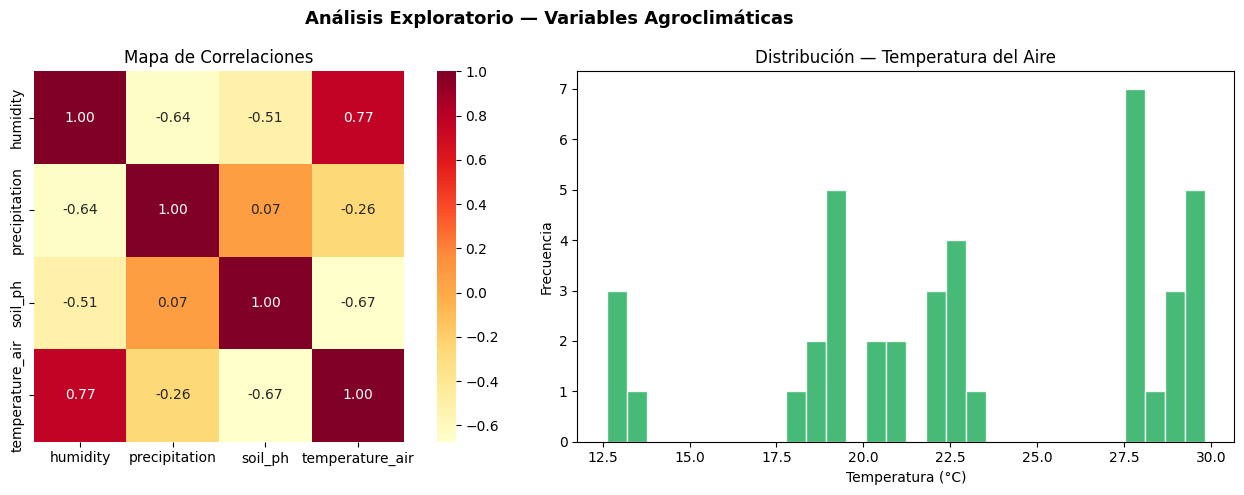


MODELO                         MAE     RMSE       R²      CV R²
Regresión Lineal             2.249    2.424    0.665   -111.575
Random Forest                1.318    1.721    0.831    -81.234
Gradient Boosting            0.502    1.025    0.940    -94.344

✅ Mejor modelo: Gradient Boosting  (R² = 0.940)


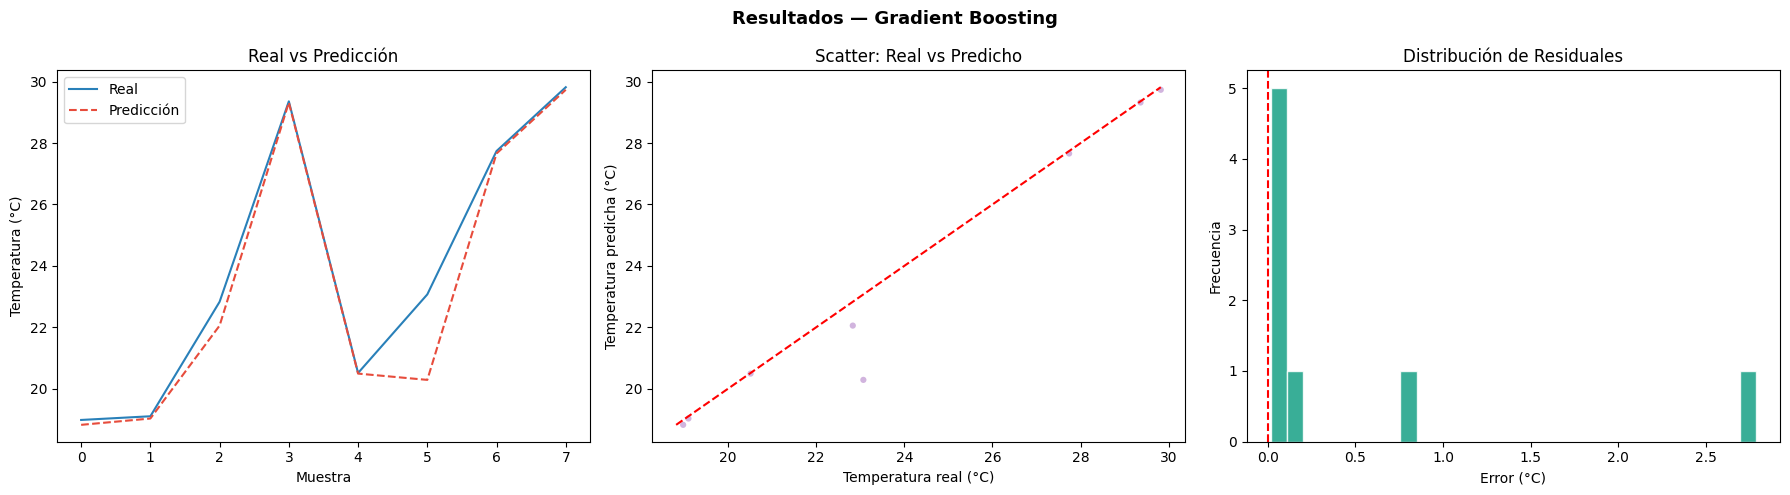

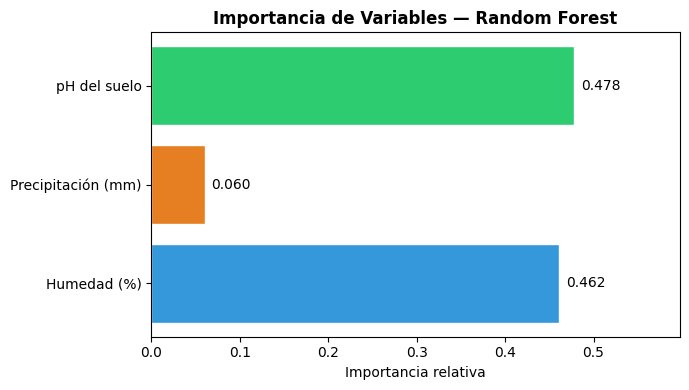


PARCELA                                  Hum%   Prec.    pH   Temp.Est          Estado
Café — Parcela 1 (Ladera Norte)            78    1900   5.5    16.44°C        ⚠️  FRÍO
Café — Parcela 2 (Ladera Sur)              74    1750   5.8    11.26°C        ⚠️  FRÍO
Café — Parcela 3 (Media Montaña)           82    2100   5.3    22.50°C        ✅ ÓPTIMO
Café — Parcela 4 (Valle Alto)              70    1600   6.0    13.65°C        ⚠️  FRÍO
Palma — Parcela 1 (Zona Baja A)            87    2400   5.0    23.86°C        ⚠️  FRÍO
Palma — Parcela 2 (Zona Baja B)            85    2300   5.2    22.73°C        ⚠️  FRÍO
Palma — Parcela 3 (Llanura Este)           90    2600   4.8    28.16°C        ✅ ÓPTIMO
Palma — Parcela 4 (Llanura Oeste)          83    2200   5.4    22.88°C        ⚠️  FRÍO


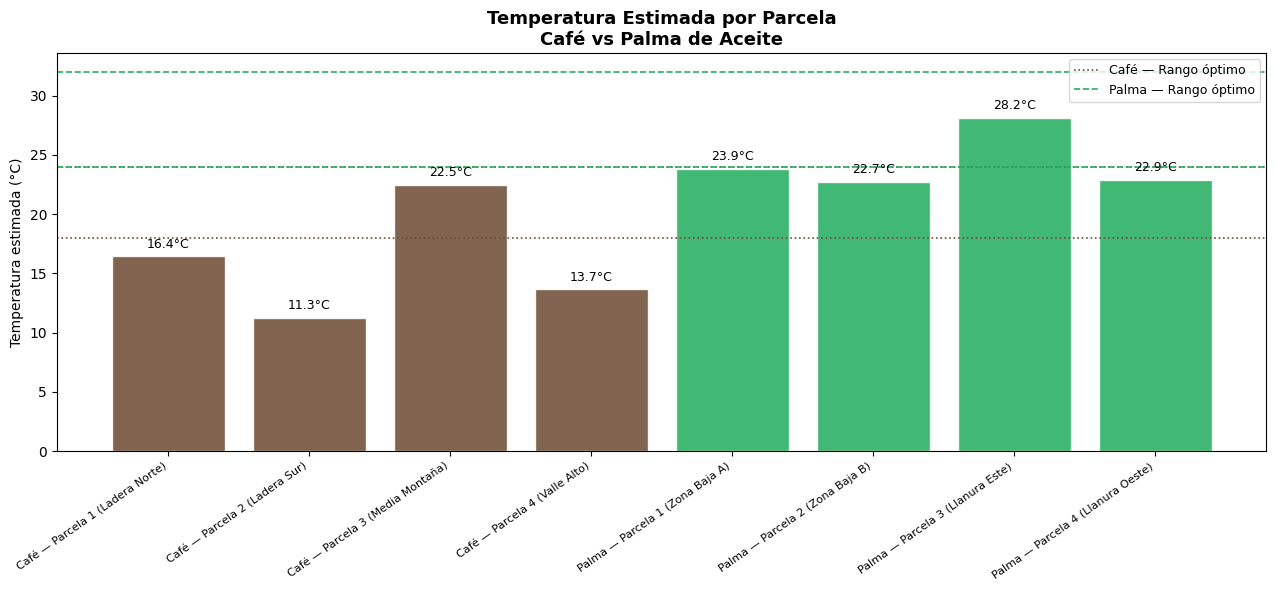


 RESUMEN FASE 6 
Dataset:       40 registros
Features:      ['humidity', 'precipitation', 'soil_ph']
Target:        temperature_air
Cultivos:      Café (4 parcelas) | Palma de Aceite (4 parcelas)
Mejor modelo:  Gradient Boosting
  MAE:         0.502 °C
  RMSE:        1.025 °C
  R²:          0.940
  CV R²:       -94.344

Parcelas en rango óptimo:
  Café:            1/4
  Palma de Aceite: 1/4


In [ ]:
# FASE 6 — ANALÍTICA Y PREDICCIÓN AGRÍCOLA
# Cultivos: Café y Palma de Aceite
# Parcelas: 4 por cultivo = 8 en total

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. CARGAR DATOS DESDE INFLUXDB (GOOGLE DRIVE)
#https://drive.google.com/file/d/1M6ICk3jTALz2rwjCICeK69Yvz-UaDSAz/view?usp=sharing


file_id = "1M6ICk3jTALz2rwjCICeK69Yvz-UaDSAz"
url = f"https://drive.google.com/uc?id={file_id}"
df = pd.read_csv(url, skiprows=3)

cols_drop = [c for c in ["Unnamed: 0", "result", "table", "_start", "_stop", "_measurement"] if c in df.columns]
df = df.drop(columns=cols_drop)
df = df.dropna(subset=["_time", "_field", "_value"])
df["_value"] = pd.to_numeric(df["_value"], errors="coerce")
df = df.dropna(subset=["_value"])

print("Variables detectadas:", df["_field"].unique())

# 2. TRANSFORMAR FORMATO INFLUXDB → PIVOT

pivot_df = df.pivot_table(
    index="_time",
    columns="_field",
    values="_value",
    aggfunc="mean"
).reset_index()

pivot_df.columns.name = None
print(f"Shape: {pivot_df.shape}")
print("Columnas:", pivot_df.columns.tolist())

# 3. VERIFICAR COLUMNAS

FEATURES   = ["humidity", "precipitation", "soil_ph"]
TARGET     = "temperature_air"
ALL_NEEDED = FEATURES + [TARGET]

missing = [c for c in ALL_NEEDED if c not in pivot_df.columns]
if missing:
    raise ValueError(f"Columnas faltantes: {missing}\nDisponibles: {pivot_df.columns.tolist()}")

pivot_df = pivot_df.dropna(subset=ALL_NEEDED)
print(f"\nRegistros listos para ML: {len(pivot_df)}")

# 4. DEFINIR LAS 8 PARCELAS (2 cultivos x 4)
# Condiciones reales de campo para Colombia:
# Café:         Zona cafetera andina (~1200-1800 msnm)
# Palma aceite: Zona tropical baja (~0-500 msnm)

PARCELAS = {
    #  CAFÉ (4 parcelas)
    "Café — Parcela 1 (Ladera Norte)":   {"humidity": 78, "precipitation": 1900, "soil_ph": 5.5, "cultivo": "Café"},
    "Café — Parcela 2 (Ladera Sur)":     {"humidity": 74, "precipitation": 1750, "soil_ph": 5.8, "cultivo": "Café"},
    "Café — Parcela 3 (Media Montaña)":  {"humidity": 82, "precipitation": 2100, "soil_ph": 5.3, "cultivo": "Café"},
    "Café — Parcela 4 (Valle Alto)":     {"humidity": 70, "precipitation": 1600, "soil_ph": 6.0, "cultivo": "Café"},
    #  PALMA DE ACEITE (4 parcelas)
    "Palma — Parcela 1 (Zona Baja A)":   {"humidity": 87, "precipitation": 2400, "soil_ph": 5.0, "cultivo": "Palma de Aceite"},
    "Palma — Parcela 2 (Zona Baja B)":   {"humidity": 85, "precipitation": 2300, "soil_ph": 5.2, "cultivo": "Palma de Aceite"},
    "Palma — Parcela 3 (Llanura Este)":  {"humidity": 90, "precipitation": 2600, "soil_ph": 4.8, "cultivo": "Palma de Aceite"},
    "Palma — Parcela 4 (Llanura Oeste)": {"humidity": 83, "precipitation": 2200, "soil_ph": 5.4, "cultivo": "Palma de Aceite"},
}

# Umbrales agronómicos óptimos por cultivo
UMBRALES = {
    "Café":            {"temp_min": 18, "temp_max": 24},
    "Palma de Aceite": {"temp_min": 24, "temp_max": 32},
}

# 5. ANÁLISIS EXPLORATORIO

print("\n--- Estadísticas descriptivas ---")
print(pivot_df[ALL_NEEDED].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Análisis Exploratorio — Variables Agroclimáticas", fontsize=13, fontweight="bold")

corr = pivot_df[ALL_NEEDED].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrRd", ax=axes[0], square=True)
axes[0].set_title("Mapa de Correlaciones")

axes[1].hist(pivot_df[TARGET], bins=30, color="#27ae60", edgecolor="white", alpha=0.85)
axes[1].set_title("Distribución — Temperatura del Aire")
axes[1].set_xlabel("Temperatura (°C)")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

# 6. ENTRENAR Y COMPARAR 3 MODELOS

X = pivot_df[FEATURES].values
y = pivot_df[TARGET].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

modelos = {
    "Regresión Lineal":   LinearRegression(),
    "Random Forest":      RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting":  GradientBoostingRegressor(n_estimators=100, random_state=42),
}

resultados = {}

print(f"\n{'='*60}")
print(f"{'MODELO':<25} {'MAE':>8} {'RMSE':>8} {'R²':>8} {'CV R²':>10}")
print("="*60)

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)
    cv   = cross_val_score(modelo, X_scaled, y, cv=5, scoring="r2").mean()

    resultados[nombre] = {
        "modelo": modelo, "y_pred": y_pred,
        "MAE": mae, "RMSE": rmse, "R2": r2, "CV_R2": cv
    }
    print(f"{nombre:<25} {mae:>8.3f} {rmse:>8.3f} {r2:>8.3f} {cv:>10.3f}")

print("="*60)

mejor_nombre = max(resultados, key=lambda k: resultados[k]["R2"])
mejor        = resultados[mejor_nombre]
print(f"\n✅ Mejor modelo: {mejor_nombre}  (R² = {mejor['R2']:.3f})")

# 7. VISUALIZACIONES DEL MEJOR MODELO

y_pred_best = mejor["y_pred"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f"Resultados — {mejor_nombre}", fontsize=13, fontweight="bold")

axes[0].plot(y_test[:80],      label="Real",       color="#2980b9", linewidth=1.5)
axes[0].plot(y_pred_best[:80], label="Predicción", color="#e74c3c", linewidth=1.5, linestyle="--")
axes[0].set_title("Real vs Predicción")
axes[0].set_xlabel("Muestra")
axes[0].set_ylabel("Temperatura (°C)")
axes[0].legend()

axes[1].scatter(y_test, y_pred_best, alpha=0.4, color="#8e44ad", edgecolors="none", s=20)
lims = [min(y_test.min(), y_pred_best.min()), max(y_test.max(), y_pred_best.max())]
axes[1].plot(lims, lims, "r--", linewidth=1.5)
axes[1].set_title("Scatter: Real vs Predicho")
axes[1].set_xlabel("Temperatura real (°C)")
axes[1].set_ylabel("Temperatura predicha (°C)")

residuales = y_test - y_pred_best
axes[2].hist(residuales, bins=30, color="#16a085", edgecolor="white", alpha=0.85)
axes[2].axvline(0, color="red", linestyle="--")
axes[2].set_title("Distribución de Residuales")
axes[2].set_xlabel("Error (°C)")
axes[2].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

# 8. IMPORTANCIA DE VARIABLES

rf_model      = resultados["Random Forest"]["modelo"]
importancias  = rf_model.feature_importances_
labels        = ["Humedad (%)", "Precipitación (mm)", "pH del suelo"]
colores       = ["#3498db", "#e67e22", "#2ecc71"]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(labels, importancias, color=colores, edgecolor="white")
ax.bar_label(bars, fmt="%.3f", padding=5)
ax.set_title("Importancia de Variables — Random Forest", fontsize=12, fontweight="bold")
ax.set_xlabel("Importancia relativa")
ax.set_xlim(0, max(importancias) * 1.25)
plt.tight_layout()
plt.show()

# 9. PREDICCIÓN POR PARCELA + ALERTA AGRONÓMICA

print("\n" + "="*85)
print(f"{'PARCELA':<38} {'Hum%':>6} {'Prec.':>7} {'pH':>5} {'Temp.Est':>10} {'Estado':>15}")
print("="*85)

predicciones_parcelas = []

for parcela, datos in PARCELAS.items():
    entrada = scaler.transform([[datos["humidity"], datos["precipitation"], datos["soil_ph"]]])
    temp_pred = mejor["modelo"].predict(entrada)[0]

    cultivo   = datos["cultivo"]
    t_min     = UMBRALES[cultivo]["temp_min"]
    t_max     = UMBRALES[cultivo]["temp_max"]

    if temp_pred < t_min:
        estado = "⚠️  FRÍO"
    elif temp_pred > t_max:
        estado = "🔴 CALOR"
    else:
        estado = "✅ ÓPTIMO"

    predicciones_parcelas.append({
        "parcela": parcela, "cultivo": cultivo,
        "temp_pred": temp_pred, "estado": estado
    })

    print(f"{parcela:<38} {datos['humidity']:>6.0f} {datos['precipitation']:>7.0f} "
          f"{datos['soil_ph']:>5.1f} {temp_pred:>8.2f}°C {estado:>15}")

print("="*85)

# 10. GRÁFICA COMPARATIVA POR PARCELA Y CULTIVO

pred_df = pd.DataFrame(predicciones_parcelas)

fig, ax = plt.subplots(figsize=(13, 6))

colores_cultivo = {"Café": "#6f4e37", "Palma de Aceite": "#27ae60"}
barras = ax.bar(
    pred_df["parcela"],
    pred_df["temp_pred"],
    color=[colores_cultivo[c] for c in pred_df["cultivo"]],
    edgecolor="white", alpha=0.88
)

# Líneas de umbral por cultivo
ax.axhline(UMBRALES["Café"]["temp_min"],            color="#6f4e37", linestyle=":",  linewidth=1.2, label="Café — Rango óptimo")
ax.axhline(UMBRALES["Café"]["temp_max"],            color="#6f4e37", linestyle=":",  linewidth=1.2)
ax.axhline(UMBRALES["Palma de Aceite"]["temp_min"], color="#27ae60", linestyle="--", linewidth=1.2, label="Palma — Rango óptimo")
ax.axhline(UMBRALES["Palma de Aceite"]["temp_max"], color="#27ae60", linestyle="--", linewidth=1.2)

ax.bar_label(barras, fmt="%.1f°C", padding=4, fontsize=9)
ax.set_title("Temperatura Estimada por Parcela\nCafé vs Palma de Aceite", fontsize=13, fontweight="bold")
ax.set_ylabel("Temperatura estimada (°C)")
ax.set_xlabel("")
plt.xticks(rotation=35, ha="right", fontsize=8)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# 11. RESUMEN FINAL

print("\n RESUMEN FASE 6 ")
print(f"Dataset:       {len(pivot_df)} registros")
print(f"Features:      {FEATURES}")
print(f"Target:        {TARGET}")
print(f"Cultivos:      Café (4 parcelas) | Palma de Aceite (4 parcelas)")
print(f"Mejor modelo:  {mejor_nombre}")
print(f"  MAE:         {mejor['MAE']:.3f} °C")
print(f"  RMSE:        {mejor['RMSE']:.3f} °C")
print(f"  R²:          {mejor['R2']:.3f}")
print(f"  CV R²:       {mejor['CV_R2']:.3f}")

cafe_ok  = sum(1 for p in predicciones_parcelas if p["cultivo"] == "Café"           and "ÓPTIMO" in p["estado"])
palma_ok = sum(1 for p in predicciones_parcelas if p["cultivo"] == "Palma de Aceite" and "ÓPTIMO" in p["estado"])
print(f"\nParcelas en rango óptimo:")
print(f"  Café:            {cafe_ok}/4")
print(f"  Palma de Aceite: {palma_ok}/4")


ó#ó#ó óPóaóróaó ópóoódóeóró óeójóeócóuótóaóró óeóló ópóróoóyóeócótóoó:ó
ó*ó óEónó óeóló ónóoódóeó-óróeódó ólóuóeógóoó ódóeó óhóaóbóeóró ódóeósócóaórógóaódóoó óeóló óaórócóhóióvóoó ódóeó ófólóoówósó.ójósóoónó ólóeó ódóaósó óiómópóoórótóaóró óyó óeósóeó óaórócóhóióvóoó ólóoó óiómópóoórótóaósó ó,ó óeósóeó óaórócóhóióvóoó ócóoónótóióeónóeó ótóoódóoó óeóló ófólóuójóoó ódóeó ómóió ópóróoóyóeócótóoó óeónó óeóló ónóoódóeó-óróeódó.ó
ó
ó*ó óEóló óaórócóhóióvóoó ódóeó óiónófólóuóxódóbó óeósó óeóló óqóuóeó ósóeó ólólóaómóaó óaógóróiócóuólótóuóróaó-óióoótó.ójósóoónó óeóló ócóuóaóló ótóióeónóeó ólóaó ólóoógóiócóaó ódóeó ólóoósó óbóuócókóeótósó óqóuóeó ósóeó óuósóaóróoónó óyó ótóoódóoó,ó ósóió ótóeó ópóiódóeó óuósóaóróióoó óyó ócóoónótóróaósóeóñóaó ósóoónó óaódómóiónó óyó óaódómóiónó óyó óeóló ótóoókóeónó óeósó óHóaóBówójóXóKócóaóJóFówó2óUóXóPó3ó-óZógóJótógózóeóoóNóJóYóPódó0óoó9ósóMófóEóFóOóRóQósóhóFólóbóIóBó5ó4óJóyóxóUócóVójóZóZójówóhóoóFóyóGó1óOóUóIó6óWósó8ómóDó5óFóIóuóWóiózóLówó=ó=ó
ó*ó óEónó óeóló óiónófólóuóxó ódóeóbóeó ópóaóróaó óvóeóró ólóoósó ódóaótóoósó óqóuóeó óvóaónó ólólóeógóaónódóoó ósóeó óuósóaó óeóló ósócóróiópótó:ó
ó
ófóróoómó(óbóuócókóeótó:ó ó"óaógóróiócóuólótóuóróaó-óióoótó"ó)ó
ó ó ó|ó>ó óróaónógóeó(ósótóaórótó:ó ó-ó3ó0ódó)ó
ó ó ó|ó>ó óyóióeólódó(ónóaómóeó:ó ó"ótóoódóoósó_ólóoósó_ódóaótóoósó"ó)ó
ó
ó*ó óEóló ómóiósómóoó ócóaósóoó ópóaóróaó óeóló óaórócóhóióvóoó ódóeó óoónólóiónóeó_ómóló_óvóiósó.ópóyó ópóeóróoó óeósótóeó ósóió ódóeóbóeó ódóeó ósóeóró óeójóeócóuótóaódóoó ódóeó ófóoórómóaó ólóoócóaóló,ó óeósótóeó óaórócóhóióvóoó ócóoónótóióeónóeó óeóló ócóoódóiógóoó ódóeóló ómóaócóhóiónóeó ólóeóaórónóiónógó ódóeóló ópóróoóyóeócótóoó,ó óeóló ócóuóaóló ódóeóbóeó ódóeó óeójóeócóuótóaórósóeó ólóuóeógóoó ódóeó óqóuóeó óeósótóeó óeónó ófóuónócóióoónóaómóióeónótóoó óeóló ócóoódóiógóoó ódóeó ósóiómóuólóaóró ósóeónósóoóróeósó,ó ócóuóaónódóoó ósóeó óaócótóióvóeó ócóoómóeónózóaóróaó óaó ólóeóeóró ólóoósó ómóeónósóaójóeósó óqóuóeó ósóeó óeónóvóióaónó óaóló ótóoópóiócó óyó ópóoóró ócóaódóaó ópóaórócóeólóaó óyó óvóaóróióaóbólóeó óvóaó ógóeónóeóróaónódóoó ólóaósó ógóróaófóiócóaósó óróeóaólóeósó óvósó ópóróeódóiócócóióoónóeósó,ó ócóoónófóoórómóeó óvóaó ópóaósóaónódóoó ómóaósó ótóióeómópóoó ólóaó ógóróaófóiócóaó ósóeó óaójóuósótóaó ómóaósó óyó ómóaósó óhóaósótóaó óqóuóeó óyóaó ópóróeódóiócócóióoónó óyó óróeóaóló ósóoónó óiógóuóaólóeósó